In [1]:
# Controlled augmentation-ablation run selector
RUN_CLEAN_AUG_ABLATION = bool(
    globals().get("RUN_CLEAN_AUG_ABLATION", False)
)
AUG_ABLATION_CONDITION = str(
    globals().get("AUG_ABLATION_CONDITION", "full")
).strip().lower()

AUG_ABLATION_CONDITIONS = {
    "no_aug": {
        "use_synthetic_multiparty": False,
        "use_diffusion_aug": False,
    },
    "synthetic_only": {
        "use_synthetic_multiparty": True,
        "use_diffusion_aug": False,
    },
    "diffusion_only": {
        "use_synthetic_multiparty": False,
        "use_diffusion_aug": True,
    },
    "full": {
        "use_synthetic_multiparty": True,
        "use_diffusion_aug": True,
    },
}

if AUG_ABLATION_CONDITION not in AUG_ABLATION_CONDITIONS:
    raise ValueError(
        "Unknown AUG_ABLATION_CONDITION. Choose one of: "
        f"{sorted(AUG_ABLATION_CONDITIONS)}"
    )

if RUN_CLEAN_AUG_ABLATION:
    selected = AUG_ABLATION_CONDITIONS[AUG_ABLATION_CONDITION]

    USE_SYNTH_MULTIPARTY = bool(
        selected["use_synthetic_multiparty"]
    )
    USE_DIFFUSION_AUG = bool(
        selected["use_diffusion_aug"]
    )

    PAPER_READY_ABLATION_BASE_VERSION = (
        "18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2"
    )
    RUN_VERSION_OVERRIDE = (
        f"{PAPER_READY_ABLATION_BASE_VERSION}"
        f"__aug_ablation_{AUG_ABLATION_CONDITION}"
    )

    print("CLEAN AUGMENTATION ABLATION ACTIVE")
    print("Condition:", AUG_ABLATION_CONDITION)
    print("RUN_VERSION_OVERRIDE:", RUN_VERSION_OVERRIDE)
    print("USE_SYNTH_MULTIPARTY:", USE_SYNTH_MULTIPARTY)
    print("USE_DIFFUSION_AUG:", USE_DIFFUSION_AUG)
else:
    print("Normal cache-safe notebook mode.")

Normal cache-safe notebook mode.


In [2]:
# Global experiment config
from pathlib import Path
import os, json, time, math, random, warnings, shutil, glob, re
warnings.filterwarnings("ignore")

EXPERIMENT_NAME = "vap_rrfap_text_meta_confirmer_v1"
BASE_RUN_VERSION = "18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2"
AUDIT_BASE_ASSET_RUN_VERSION = str(globals().get(
    "AUDIT_BASE_ASSET_RUN_VERSION",
    "18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1",
))
RUN_VERSION = str(globals().get("RUN_VERSION_OVERRIDE", BASE_RUN_VERSION))

USE_WAVLM_SYS1 = bool(globals().get("USE_WAVLM_SYS1", True))
USE_PYANNOTE_DIA = bool(globals().get("USE_PYANNOTE_DIA", True))
USE_ASR_TEXT = bool(globals().get("USE_ASR_TEXT", True))
USE_QWEN3_LLM = bool(globals().get("USE_QWEN3_LLM", True))
USE_ECAPA_SPK = bool(globals().get("USE_ECAPA_SPK", True))
USE_SYNTH_MULTIPARTY = bool(globals().get("USE_SYNTH_MULTIPARTY", True))
USE_DIFFUSION_AUG = bool(globals().get("USE_DIFFUSION_AUG", True))
USE_TEMPORAL_SYS2 = bool(globals().get("USE_TEMPORAL_SYS2", True))
USE_LIGHTGBM_SYS2 = bool(globals().get("USE_LIGHTGBM_SYS2", True))
USE_META_CONFIRMER = bool(globals().get("USE_META_CONFIRMER", True))

FORCE_REBUILD_SPLITS = bool(globals().get("FORCE_REBUILD_SPLITS", False))
FORCE_REBUILD_REAL_EVENTS = bool(globals().get("FORCE_REBUILD_REAL_EVENTS", False))
FORCE_REGENERATE_SYNTH = bool(globals().get("FORCE_REGENERATE_SYNTH", False))
FORCE_REBUILD_AUGMENTED_AUDIO = bool(globals().get("FORCE_REBUILD_AUGMENTED_AUDIO", False))
FORCE_RERUN_ASR = bool(globals().get("FORCE_RERUN_ASR", False))
FORCE_RERUN_PYANNOTE = bool(globals().get("FORCE_RERUN_PYANNOTE", False))
FORCE_RETRAIN_SYS1 = bool(globals().get("FORCE_RETRAIN_SYS1", False))
FORCE_RETRAIN_QWEN3 = bool(globals().get("FORCE_RETRAIN_QWEN3", False))
FORCE_REBUILD_SYS1_CANDIDATES = bool(globals().get("FORCE_REBUILD_SYS1_CANDIDATES", False))
FORCE_REBUILD_SYS2_FEATURES = bool(globals().get("FORCE_REBUILD_SYS2_FEATURES", False))
FORCE_RETRAIN_TEMPORAL_SYS2 = bool(globals().get("FORCE_RETRAIN_TEMPORAL_SYS2", False))
FORCE_RETRAIN_LIGHTGBM = bool(globals().get("FORCE_RETRAIN_LIGHTGBM", False))
FORCE_RETRAIN_LIGHTGBM_BINARY = bool(globals().get("FORCE_RETRAIN_LIGHTGBM_BINARY", FORCE_RETRAIN_LIGHTGBM))
FORCE_RETRAIN_EVENT_RANKER = bool(globals().get("FORCE_RETRAIN_EVENT_RANKER", False))
FORCE_RETRAIN_RR_FAP = bool(globals().get("FORCE_RETRAIN_RR_FAP", False))
FORCE_RETRAIN_META_CONFIRMER = bool(globals().get("FORCE_RETRAIN_META_CONFIRMER", False))
FORCE_RETUNE_VAL = bool(globals().get("FORCE_RETUNE_VAL", False))
FORCE_REBUILD_TEST_PRED = bool(globals().get("FORCE_REBUILD_TEST_PRED", False))

DEBUG_SMALL_RUN = bool(globals().get("DEBUG_SMALL_RUN", False))
DEBUG_MAX_TRAIN_SESSIONS = int(globals().get("DEBUG_MAX_TRAIN_SESSIONS", 12))
DEBUG_MAX_VAL_SESSIONS = int(globals().get("DEBUG_MAX_VAL_SESSIONS", 4))
DEBUG_MAX_TEST_SESSIONS = int(globals().get("DEBUG_MAX_TEST_SESSIONS", 4))

PAPER_READY_PROTOCOL = bool(globals().get("PAPER_READY_PROTOCOL", True))
EVENT_CONTRACT_VERSION = str(globals().get(
    "EVENT_CONTRACT_VERSION",
    "voxconverse_action_aware_immediate_v1",
))

PRIMARY_EVENT_TIME_DEFINITION = str(globals().get(
    "PRIMARY_EVENT_TIME_DEFINITION",
    "action_aware_boundary",
))

PRIMARY_MIN_GAP_S = float(globals().get("PRIMARY_MIN_GAP_S", -1.0))
PRIMARY_MAX_POSITIVE_GAP_S = float(globals().get(
    "PRIMARY_MAX_POSITIVE_GAP_S",
    1.0,
))
ACTION_SHORT_TURN_S = float(globals().get("ACTION_SHORT_TURN_S", 0.50))
ACTION_OVERLAP_MIN_S = float(globals().get("ACTION_OVERLAP_MIN_S", 0.06))

KEEP_LEGACY_EVENT_TABLES = bool(globals().get("KEEP_LEGACY_EVENT_TABLES", True))
REPORT_TRANSITION_INTERVAL_METRICS = bool(globals().get(
    "REPORT_TRANSITION_INTERVAL_METRICS",
    True,
))
REPORT_LEGACY_MIDPOINT_METRICS = bool(globals().get(
    "REPORT_LEGACY_MIDPOINT_METRICS",
    True,
))

EVENT_CONTRACT_SELECTION_BASIS = str(globals().get(
    "EVENT_CONTRACT_SELECTION_BASIS",
    (
        "audit-informed causal task definition fixed before retraining; "
        "no TEST prediction scores or model performance used"
    ),
))
EVENT_CONTRACT_AUDIT_INCLUDED_TEST_ANNOTATIONS = True
EVENT_CONTRACT_TEST_PREDICTIONS_USED_FOR_SELECTION = False
EVENT_CONTRACT_TEST_USED_FOR_SELECTION = (
    EVENT_CONTRACT_TEST_PREDICTIONS_USED_FOR_SELECTION
)

RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(
    globals().get(
        "RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS",
        False,
    )
)

TOL = float(globals().get("TOL", 0.50))

STRICT_E2E_TOL = float(globals().get("STRICT_E2E_TOL", 0.50))
DATASET_CALIBRATED_E2E_TOL = float(globals().get("DATASET_CALIBRATED_E2E_TOL", 0.70))
RELAXED_E2E_TOL = float(globals().get("RELAXED_E2E_TOL", 1.00))

BRANCH1_E2E_TOLERANCES = list(globals().get(
    "BRANCH1_E2E_TOLERANCES",
    [
        {"name": "strict", "label": "strict_0p50", "tol": STRICT_E2E_TOL, "description": "Strict event matching, ±0.50 s"},
        {"name": "dataset_calibrated", "label": "dataset_calibrated_0p70", "tol": DATASET_CALIBRATED_E2E_TOL, "description": "Dataset-calibrated event matching, ±0.70 s"},
        {"name": "relaxed", "label": "relaxed_1p00", "tol": RELAXED_E2E_TOL, "description": "Relaxed event matching, ±1.00 s"},
    ],
))
GT_GAP_MIN = float(globals().get("GT_GAP_MIN", PRIMARY_MIN_GAP_S))
GT_GAP_MAX = float(globals().get("GT_GAP_MAX", PRIMARY_MAX_POSITIVE_GAP_S))

TARGET_SYS1_RECALL = float(globals().get("TARGET_SYS1_RECALL", 0.90))
PREFERRED_SYS1_RECALL = float(globals().get("PREFERRED_SYS1_RECALL", 0.95))

TARGET_FINAL_PRECISION = float(globals().get("TARGET_FINAL_PRECISION", 0.70))
TARGET_FINAL_RECALL = float(globals().get("TARGET_FINAL_RECALL", 0.70))
TARGET_FINAL_F1 = float(globals().get("TARGET_FINAL_F1", 0.70))

VAL_MIN_PRECISION_FOR_SELECTION = float(globals().get("VAL_MIN_PRECISION_FOR_SELECTION", 0.55))
VAL_MIN_RECALL_FOR_SELECTION = float(globals().get("VAL_MIN_RECALL_FOR_SELECTION", 0.55))

ACTION_NAMES = ["NA", "NTT", "ITT", "BC", "BI"]
ACTION_TO_ID = {a: i for i, a in enumerate(ACTION_NAMES)}
ID_TO_ACTION = {i: a for a, i in ACTION_TO_ID.items()}

SHIFT_ACTIONS = {"NTT", "ITT"}
HOLD_ACTIONS = {"NA", "BC", "BI"}
SHIFT_ACTION_IDS = sorted([ACTION_TO_ID[a] for a in SHIFT_ACTIONS])
HOLD_ACTION_IDS = sorted([ACTION_TO_ID[a] for a in HOLD_ACTIONS])

WAVLM_MODEL_NAME_PRIMARY = "microsoft/wavlm-large"
WAVLM_MODEL_NAME_FALLBACK = "microsoft/wavlm-base-plus"
WAVLM_MODEL_NAME = str(globals().get("WAVLM_MODEL_NAME", WAVLM_MODEL_NAME_PRIMARY))

QWEN3_MODEL_NAME = str(globals().get("QWEN3_MODEL_NAME", "Qwen/Qwen3-1.7B"))
QWEN3_MAX_LENGTH = int(globals().get("QWEN3_MAX_LENGTH", 512))
QWEN3_LORA_R = int(globals().get("QWEN3_LORA_R", 16))
QWEN3_LORA_ALPHA = int(globals().get("QWEN3_LORA_ALPHA", 32))
QWEN3_EPOCHS = int(globals().get("QWEN3_EPOCHS", 1 if DEBUG_SMALL_RUN else 3))
QWEN3_BATCH_SIZE = int(globals().get("QWEN3_BATCH_SIZE", 4))

PYANNOTE_PIPELINE_NAME = str(globals().get("PYANNOTE_PIPELINE_NAME", "pyannote/speaker-diarization-3.1"))
PYANNOTE_SEGMENTATION_NAME = str(globals().get("PYANNOTE_SEGMENTATION_NAME", "pyannote/segmentation-3.0"))
HF_DIARIZERS_VOXCONVERSE = "diarizers-community/voxconverse"

ASR_MODEL_NAME = str(globals().get("ASR_MODEL_NAME", "medium"))
ASR_COMPUTE_TYPE = str(globals().get("ASR_COMPUTE_TYPE", "float16"))

WEIGHT_REAL_CLEAN = float(globals().get("WEIGHT_REAL_CLEAN", 1.00))
WEIGHT_REAL_DIFFUSION = float(globals().get("WEIGHT_REAL_DIFFUSION", 0.50))
WEIGHT_SYNTH_CLEAN = float(globals().get("WEIGHT_SYNTH_CLEAN", 0.50))
WEIGHT_SYNTH_DIFFUSION = float(globals().get("WEIGHT_SYNTH_DIFFUSION", 0.25))

ADD_MIDTURN_HOLD_NEGATIVES = bool(globals().get(
    "ADD_MIDTURN_HOLD_NEGATIVES",
    True,
))
MIDTURN_NEG_TO_BOUNDARY_RATIO = float(globals().get(
    "MIDTURN_NEG_TO_BOUNDARY_RATIO",
    0.50,
))
MIDTURN_NEG_MAX_PER_SESSION = int(globals().get(
    "MIDTURN_NEG_MAX_PER_SESSION",
    40 if not DEBUG_SMALL_RUN else 8,
))
MIDTURN_NEG_PER_SESSION = MIDTURN_NEG_MAX_PER_SESSION
MIDTURN_NEG_MIN_FROM_EVENT_S = float(globals().get(
    "MIDTURN_NEG_MIN_FROM_EVENT_S",
    1.00,
))
WEIGHT_REAL_MIDTURN = float(globals().get("WEIGHT_REAL_MIDTURN", 0.25))

MIDTURN_HOLD_NEGATIVE_RATIO = float(MIDTURN_NEG_TO_BOUNDARY_RATIO)
MIDTURN_HOLD_MAX_PER_SESSION = int(MIDTURN_NEG_MAX_PER_SESSION)
MIDTURN_HOLD_SAMPLE_WEIGHT = float(WEIGHT_REAL_MIDTURN)
REUSE_AUDIT_COMPATIBLE_BASE_ASSETS = bool(
    globals().get(
        "REUSE_AUDIT_COMPATIBLE_BASE_ASSETS",
        True,
    )
)

SYS1_CLASS_BALANCE_MODE = str(globals().get(
    "SYS1_CLASS_BALANCE_MODE",
    "loss_only",
))
SYS1_USE_WEIGHTED_SAMPLER = bool(globals().get(
    "SYS1_USE_WEIGHTED_SAMPLER",
    False,
))
SYS1_USE_ACTION_CLASS_WEIGHTS = bool(globals().get(
    "SYS1_USE_ACTION_CLASS_WEIGHTS",
    True,
))

SYS1_WAVLM_THR_GRID = list(globals().get(
    "SYS1_WAVLM_THR_GRID",
    [0.03, 0.05, 0.07, 0.10, 0.12, 0.15, 0.18, 0.22, 0.28, 0.35, 0.45, 0.55]
))

SYS1_QWEN_THR_GRID = list(globals().get(
    "SYS1_QWEN_THR_GRID",
    [0.05, 0.10, 0.15, 0.20, 0.25]
))

SYS1_USE_PYANNOTE_SOURCE_GRID = list(globals().get("SYS1_USE_PYANNOTE_SOURCE_GRID", [True]))
SYS1_USE_ASR_SOURCE_GRID = list(globals().get("SYS1_USE_ASR_SOURCE_GRID", [True]))

SYS1_CAND_MERGE_TOL_GRID = list(globals().get(
    "SYS1_CAND_MERGE_TOL_GRID",
    [0.12, 0.20, 0.25, 0.35]
))

SYS2_SHIFT_THR_GRID = list(globals().get(
    "SYS2_SHIFT_THR_GRID",
    [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]
))

FINAL_COOLDOWN_GRID = list(globals().get(
    "FINAL_COOLDOWN_GRID",
    [0.00, 0.10, 0.20, 0.35, 0.50, 0.75]
))

FINAL_MIN_GAP_GRID = list(globals().get(
    "FINAL_MIN_GAP_GRID",
    [0.00, 0.10, 0.20, 0.35, 0.50]
))

SHIFT_TIME_OFFSET_GRID = list(globals().get(
    "SHIFT_TIME_OFFSET_GRID",
    [-0.10, -0.05, 0.0, 0.05, 0.10]
))

VAL_ROBUST_N_FOLDS = int(globals().get("VAL_ROBUST_N_FOLDS", 5))
VAL_ROBUST_TOP_K = int(globals().get("VAL_ROBUST_TOP_K", 100))
VAL_ROBUST_STD_PENALTY = float(globals().get("VAL_ROBUST_STD_PENALTY", 0.50))

USE_LOCAL_TIMING_CORRECTOR = bool(globals().get(
    "USE_LOCAL_TIMING_CORRECTOR",
    True,
))
TIMING_CORRECTOR_MATCH_RADIUS_S = float(globals().get(
    "TIMING_CORRECTOR_MATCH_RADIUS_S",
    1.00,
))
TIMING_CORRECTOR_MAX_ABS_OFFSET_S = float(globals().get(
    "TIMING_CORRECTOR_MAX_ABS_OFFSET_S",
    0.75,
))
TIMING_CORRECTOR_MAX_CANDIDATES_PER_GT = int(globals().get(
    "TIMING_CORRECTOR_MAX_CANDIDATES_PER_GT",
    5,
))
FINAL_TIME_MODE_GRID = list(globals().get(
    "FINAL_TIME_MODE_GRID",
    ["raw", "local_corrected"],
))

TEST_BOOTSTRAP_REPLICATES = int(globals().get(
    "TEST_BOOTSTRAP_REPLICATES",
    1000,
))
TEST_BOOTSTRAP_CONFIDENCE = float(globals().get(
    "TEST_BOOTSTRAP_CONFIDENCE",
    0.95,
))

SYS1_CONTEXT_S = float(globals().get("SYS1_CONTEXT_S", 4.0))
SYS1_HOP_S = float(globals().get("SYS1_HOP_S", 0.10))

WAVLM_TIMELINE_KEEP_THR = float(globals().get("WAVLM_TIMELINE_KEEP_THR", min(SYS1_WAVLM_THR_GRID)))
SYS1_TIMELINE_BATCH_SIZE = int(globals().get("SYS1_TIMELINE_BATCH_SIZE", 32))
SYS1_TIMELINE_LOCAL_MAX_RADIUS = int(globals().get("SYS1_TIMELINE_LOCAL_MAX_RADIUS", 1))

ALLOW_TRAIN_GT_SEED_CANDIDATES = bool(globals().get("ALLOW_TRAIN_GT_SEED_CANDIDATES", True))

SYS1_DENSE_FPS = int(round(1.0 / SYS1_HOP_S))
SYS1_EPOCHS = int(globals().get("SYS1_EPOCHS", 8 if DEBUG_SMALL_RUN else 35))
SYS1_BATCH_SIZE = int(globals().get("SYS1_BATCH_SIZE", 8))
SYS1_MICRO_BS = int(globals().get("SYS1_MICRO_BS", 1))
SYS1_LR = float(globals().get("SYS1_LR", 2e-4))
SYS1_POS_WEIGHT_CAP = float(globals().get("SYS1_POS_WEIGHT_CAP", 12.0))

SYNTH_NUM_MEETINGS = int(globals().get("SYNTH_NUM_MEETINGS", 80 if DEBUG_SMALL_RUN else 6000))
SYNTH_MIN_SPK = int(globals().get("SYNTH_MIN_SPK", 3))
SYNTH_MAX_SPK = int(globals().get("SYNTH_MAX_SPK", 6))
SYNTH_SR = int(globals().get("SYNTH_SR", 16000))
SYNTH_MIN_DURATION = float(globals().get("SYNTH_MIN_DURATION", 8.0))
SYNTH_MAX_DURATION = float(globals().get("SYNTH_MAX_DURATION", 28.0))

SYS2_CONTEXT_S = float(globals().get("SYS2_CONTEXT_S", 4.0))
SYS2_FRAME_HOP_S = float(globals().get("SYS2_FRAME_HOP_S", 0.10))
SYS2_TEMPORAL_EPOCHS = int(globals().get("SYS2_TEMPORAL_EPOCHS", 5 if DEBUG_SMALL_RUN else 45))
SYS2_TEMPORAL_BATCH_SIZE = int(globals().get("SYS2_TEMPORAL_BATCH_SIZE", 256))
SYS2_TEMPORAL_LR = float(globals().get("SYS2_TEMPORAL_LR", 8e-4))
SYS2_TEMPORAL_WEIGHT_DECAY = float(globals().get("SYS2_TEMPORAL_WEIGHT_DECAY", 1e-4))

LIGHTGBM_NUM_BOOST_ROUND = int(globals().get("LIGHTGBM_NUM_BOOST_ROUND", 200 if DEBUG_SMALL_RUN else 1200))
LIGHTGBM_EARLY_STOPPING_ROUNDS = int(globals().get("LIGHTGBM_EARLY_STOPPING_ROUNDS", 30 if DEBUG_SMALL_RUN else 80))

V3_VALIDITY_FIXES = {
    "test_candidates_from_full_timeline": True,
    "qwen3_no_real_val_training": True,
    "qwen3_weighted_training": True,
    "sys1_train_real_synth_diffusion": True,
    "sys2_train_real_synth_diffusion": True,
    "val_test_real_only": True,
    "sys1_high_recall_target_not_score_threshold": True,
    "audit_informed_action_aware_event_time": True,
    "positive_gap_capped_for_primary_task": True,
    "legacy_midpoint_retained_only_for_secondary_reporting": True,
    "midturn_negatives_capped_and_downweighted": True,
    "sys1_balance_not_applied_repeatedly": True,
    "local_timing_corrector_train_val_only": True,
    "robust_session_fold_val_selection": True,
}

print("Experiment:", EXPERIMENT_NAME)
print("Run version:", RUN_VERSION)
print("TOL:", TOL)
print("Event contract:", EVENT_CONTRACT_VERSION)
print("Primary event time:", PRIMARY_EVENT_TIME_DEFINITION)
print("Primary gap range:", (PRIMARY_MIN_GAP_S, PRIMARY_MAX_POSITIVE_GAP_S))
print("Mid-turn negative ratio/weight:", MIDTURN_NEG_TO_BOUNDARY_RATIO, WEIGHT_REAL_MIDTURN)
print("Sys1 class balance mode:", SYS1_CLASS_BALANCE_MODE)
print("Target Sys1 recall floor:", TARGET_SYS1_RECALL, "preferred:", PREFERRED_SYS1_RECALL)
print("Main LLM:", QWEN3_MODEL_NAME)
print("Main WavLM:", WAVLM_MODEL_NAME)
print("DEBUG_SMALL_RUN:", DEBUG_SMALL_RUN)
print("Component switches:", {
    "wavlm": USE_WAVLM_SYS1,
    "pyannote": USE_PYANNOTE_DIA,
    "asr": USE_ASR_TEXT,
    "qwen3": USE_QWEN3_LLM,
    "ecapa": USE_ECAPA_SPK,
    "synth": USE_SYNTH_MULTIPARTY,
    "diffusion": USE_DIFFUSION_AUG,
    "temporal_sys2": USE_TEMPORAL_SYS2,
    "lightgbm": USE_LIGHTGBM_SYS2,
})

Experiment: vap_rrfap_text_meta_confirmer_v1
Run version: 18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2
TOL: 0.5
Event contract: voxconverse_action_aware_immediate_v1
Primary event time: action_aware_boundary
Primary gap range: (-1.0, 1.0)
Mid-turn negative ratio/weight: 0.5 0.25
Sys1 class balance mode: loss_only
Target Sys1 recall floor: 0.9 preferred: 0.95
Main LLM: Qwen/Qwen3-1.7B
Main WavLM: microsoft/wavlm-large
DEBUG_SMALL_RUN: False
Component switches: {'wavlm': True, 'pyannote': True, 'asr': True, 'qwen3': True, 'ecapa': True, 'synth': True, 'diffusion': True, 'temporal_sys2': True, 'lightgbm': True}


In [3]:
from pathlib import Path

FRESH_MACHINE_FULL_RUN = False
CHECKPOINT_REUSE_RUN = True
CACHE_SAFE_RESUME_RUN = False

REUSE_PREVIOUS_SYS1_CHECKPOINT = False
PREVIOUS_SYS1_RUN_VERSION = "16thAug_MULTIMODAL_MULTIPARTY_CONTROLLER_v3"
PREVIOUS_SYS1_REL_DIR = "models/wavlm_sys1_dense_multiscale"
PREVIOUS_SYS1_BEST_FILENAME = "wavlm_dense_multiscale_sys1_best.pt"
PREVIOUS_SYS1_LAST_FILENAME = "wavlm_dense_multiscale_sys1_last.pt"
PREVIOUS_SYS1_HISTORY_FILENAME = "sys1_training_history.csv"
SKIP_FORCE_FRESH_SYS1_CELL10B = True

REUSE_AUDIT_COMPATIBLE_BASE_ASSETS = True
BASE_ASSETS_READ_ONLY = True

FORCE_REBUILD = False
FORCE_TRAIN = False
FORCE_REBUILD_FEATURES = False
FORCE_REBUILD_PYANNOTE = False
FORCE_REBUILD_NS = False

FORCE_REBUILD_NS_AUTO_PROTOTYPES = False
FORCE_REBUILD_NS_AUTO_PREDICTIONS = False
FORCE_REBUILD_NS_AUTO_ORACLE = False

FORCE_REBUILD_SPLITS = False
FORCE_REBUILD_REAL_EVENTS = False

FORCE_REGENERATE_SYNTH = False
FORCE_REBUILD_AUGMENTED_AUDIO = False
FORCE_RERUN_ASR = False
FORCE_RERUN_PYANNOTE = False
FORCE_REBUILD_PYANNOTE = FORCE_RERUN_PYANNOTE

FORCE_RETRAIN_SYS1 = False
RESUME_SYS1_TRAIN = True

FORCE_RETRAIN_QWEN3 = False
QWEN3_RESUME_FROM_CHECKPOINT = True

FORCE_REBUILD_SYS1_CANDIDATES = False
FORCE_REBUILD_SYS2_FEATURES = False

FORCE_RETRAIN_TEMPORAL_SYS2 = False
RESUME_TEMPORAL_SYS2_TRAIN = True

FORCE_RETRAIN_LIGHTGBM = False
FORCE_RETRAIN_LIGHTGBM_BINARY = False
FORCE_RETRAIN_EVENT_RANKER = False
FORCE_RETRAIN_RR_FAP = False
FORCE_RETRAIN_META_CONFIRMER = False
FORCE_RETRAIN_TIMING_CORRECTOR = False

FORCE_RETUNE_VAL = False
FORCE_REBUILD_TEST_PRED = False

FORCE_REBUILD_FEATURES = (
    FORCE_REBUILD_SYS1_CANDIDATES
    or FORCE_REBUILD_SYS2_FEATURES
)

FORCE_TRAIN = (
    FORCE_RETRAIN_SYS1
    or FORCE_RETRAIN_QWEN3
    or FORCE_RETRAIN_TEMPORAL_SYS2
    or FORCE_RETRAIN_LIGHTGBM
    or FORCE_RETRAIN_LIGHTGBM_BINARY
    or FORCE_RETRAIN_EVENT_RANKER
    or FORCE_RETRAIN_RR_FAP
    or FORCE_RETRAIN_META_CONFIRMER
    or FORCE_RETRAIN_TIMING_CORRECTOR
)

FORCE_REBUILD = (
    FORCE_REBUILD_SPLITS
    or FORCE_REBUILD_REAL_EVENTS
    or FORCE_REGENERATE_SYNTH
    or FORCE_REBUILD_AUGMENTED_AUDIO
    or FORCE_RERUN_ASR
    or FORCE_RERUN_PYANNOTE
    or FORCE_REBUILD_SYS1_CANDIDATES
    or FORCE_REBUILD_SYS2_FEATURES
    or FORCE_RETUNE_VAL
    or FORCE_REBUILD_TEST_PRED
    or FORCE_REBUILD_NS
    or FORCE_REBUILD_NS_AUTO_PROTOTYPES
    or FORCE_REBUILD_NS_AUTO_PREDICTIONS
    or FORCE_REBUILD_NS_AUTO_ORACLE
)

SYS2_TEMPORAL_BATCH_SIZE = int(
    globals().get("SYS2_TEMPORAL_BATCH_SIZE", 128)
)
SYS2_TEMPORAL_NUM_WORKERS = int(
    globals().get("SYS2_TEMPORAL_NUM_WORKERS", 0)
)
SYS2_TEMPORAL_PIN_MEMORY = bool(
    globals().get("SYS2_TEMPORAL_PIN_MEMORY", False)
)

USE_TEST_INFORMED_EXPLORATORY_BRANCH = False
ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE = False

print("Paper-ready checkpoint/cache policy set.")
print("CHECKPOINT_REUSE_RUN:", CHECKPOINT_REUSE_RUN)
print("CACHE_SAFE_RESUME_RUN:", CACHE_SAFE_RESUME_RUN)
print("REUSE_PREVIOUS_SYS1_CHECKPOINT:", REUSE_PREVIOUS_SYS1_CHECKPOINT)
print("REUSE_AUDIT_COMPATIBLE_BASE_ASSETS:", REUSE_AUDIT_COMPATIBLE_BASE_ASSETS)
print("BASE_ASSETS_READ_ONLY:", BASE_ASSETS_READ_ONLY)

print({
    "FORCE_REBUILD_SPLITS": FORCE_REBUILD_SPLITS,
    "FORCE_REBUILD_REAL_EVENTS": FORCE_REBUILD_REAL_EVENTS,
    "FORCE_REGENERATE_SYNTH": FORCE_REGENERATE_SYNTH,
    "FORCE_REBUILD_AUGMENTED_AUDIO": FORCE_REBUILD_AUGMENTED_AUDIO,
    "FORCE_RERUN_ASR": FORCE_RERUN_ASR,
    "FORCE_RERUN_PYANNOTE": FORCE_RERUN_PYANNOTE,
    "FORCE_RETRAIN_SYS1": FORCE_RETRAIN_SYS1,
    "RESUME_SYS1_TRAIN": RESUME_SYS1_TRAIN,
    "FORCE_RETRAIN_QWEN3": FORCE_RETRAIN_QWEN3,
    "QWEN3_RESUME_FROM_CHECKPOINT": QWEN3_RESUME_FROM_CHECKPOINT,
    "FORCE_REBUILD_SYS1_CANDIDATES": FORCE_REBUILD_SYS1_CANDIDATES,
    "FORCE_REBUILD_SYS2_FEATURES": FORCE_REBUILD_SYS2_FEATURES,
    "FORCE_RETRAIN_TEMPORAL_SYS2": FORCE_RETRAIN_TEMPORAL_SYS2,
    "FORCE_RETRAIN_LIGHTGBM": FORCE_RETRAIN_LIGHTGBM,
    "FORCE_RETRAIN_LIGHTGBM_BINARY": FORCE_RETRAIN_LIGHTGBM_BINARY,
    "FORCE_RETRAIN_EVENT_RANKER": FORCE_RETRAIN_EVENT_RANKER,
    "FORCE_RETRAIN_RR_FAP": FORCE_RETRAIN_RR_FAP,
    "FORCE_RETRAIN_META_CONFIRMER": FORCE_RETRAIN_META_CONFIRMER,
    "FORCE_RETRAIN_TIMING_CORRECTOR": FORCE_RETRAIN_TIMING_CORRECTOR,
    "FORCE_RETUNE_VAL": FORCE_RETUNE_VAL,
    "FORCE_REBUILD_TEST_PRED": FORCE_REBUILD_TEST_PRED,
    "USE_TEST_INFORMED_EXPLORATORY_BRANCH": USE_TEST_INFORMED_EXPLORATORY_BRANCH,
    "ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE": ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE,
})

Paper-ready checkpoint/cache policy set.
CHECKPOINT_REUSE_RUN: True
CACHE_SAFE_RESUME_RUN: False
REUSE_PREVIOUS_SYS1_CHECKPOINT: False
REUSE_AUDIT_COMPATIBLE_BASE_ASSETS: True
BASE_ASSETS_READ_ONLY: True
{'FORCE_REBUILD_SPLITS': False, 'FORCE_REBUILD_REAL_EVENTS': False, 'FORCE_REGENERATE_SYNTH': False, 'FORCE_REBUILD_AUGMENTED_AUDIO': False, 'FORCE_RERUN_ASR': False, 'FORCE_RERUN_PYANNOTE': False, 'FORCE_RETRAIN_SYS1': False, 'RESUME_SYS1_TRAIN': True, 'FORCE_RETRAIN_QWEN3': False, 'QWEN3_RESUME_FROM_CHECKPOINT': True, 'FORCE_REBUILD_SYS1_CANDIDATES': False, 'FORCE_REBUILD_SYS2_FEATURES': False, 'FORCE_RETRAIN_TEMPORAL_SYS2': False, 'FORCE_RETRAIN_LIGHTGBM': False, 'FORCE_RETRAIN_LIGHTGBM_BINARY': False, 'FORCE_RETRAIN_EVENT_RANKER': False, 'FORCE_RETRAIN_RR_FAP': False, 'FORCE_RETRAIN_META_CONFIRMER': False, 'FORCE_RETRAIN_TIMING_CORRECTOR': False, 'FORCE_RETUNE_VAL': False, 'FORCE_REBUILD_TEST_PRED': False, 'USE_TEST_INFORMED_EXPLORATORY_BRANCH': False, 'ALLOW_TEST_INFORMED_EXPLORAT

In [4]:
if bool(
    globals().get(
        "RUN_CLEAN_AUG_ABLATION",
        False,
    )
):
    CHECKPOINT_REUSE_RUN = True
    CACHE_SAFE_RESUME_RUN = True
    FRESH_MACHINE_FULL_RUN = False

    REUSE_PREVIOUS_SYS1_CHECKPOINT = False
    SKIP_FORCE_FRESH_SYS1_CELL10B = False

    FORCE_REBUILD_SPLITS = False
    FORCE_REBUILD_REAL_EVENTS = False

    FORCE_REGENERATE_SYNTH = False
    FORCE_REBUILD_AUGMENTED_AUDIO = False
    FORCE_RERUN_ASR = False
    FORCE_RERUN_PYANNOTE = False

    FORCE_RETRAIN_SYS1 = False
    RESUME_SYS1_TRAIN = True
    FORCE_RETRAIN_QWEN3 = False
    FORCE_REBUILD_SYS1_CANDIDATES = False
    FORCE_REBUILD_SYS2_FEATURES = False
    FORCE_RETRAIN_TEMPORAL_SYS2 = False
    FORCE_RETRAIN_LIGHTGBM = False
    FORCE_RETRAIN_LIGHTGBM_BINARY = False
    FORCE_RETRAIN_EVENT_RANKER = False
    FORCE_RETRAIN_RR_FAP = False
    FORCE_RETRAIN_META_CONFIRMER = False
    FORCE_RETRAIN_TIMING_CORRECTOR = False
    FORCE_RETUNE_VAL = False
    FORCE_REBUILD_TEST_PRED = False

    FORCE_REBUILD_BRANCH2_FEATURES = False
    FORCE_RETRAIN_BRANCH2_LGBM = False
    FORCE_REBUILD_BRANCH3_TABLE = False
    FORCE_RETRAIN_BRANCH3_LGBM = False
    FORCE_RETRAIN_SYSTEM_FLOOR = False

    print("=" * 80)
    print("PAPER-READY AUGMENTATION CONDITION")
    print("=" * 80)
    print("Condition:", AUG_ABLATION_CONDITION)
    print("Run version:", RUN_VERSION_OVERRIDE)
    print("Force flags remain False for restart-safe execution.")
    print(
        "For the final ablation campaign, use streamlined notebooks generated "
        "from this paper-ready full notebook so Branch 2/3 and diagnostics are "
        "not executed unnecessarily."
    )
else:
    print(
        "Cell 2A: normal paper-ready full-system resume policy preserved."
    )

Cell 2A: normal paper-ready full-system resume policy preserved.


In [5]:
# Imports, dependency check, seed, device
import os, sys, json, math, time, random, warnings, shutil, subprocess, importlib.util
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

try:
    import soundfile as sf
except Exception as e:
    raise ImportError("soundfile is required. Install with: pip install soundfile") from e

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader, TensorDataset, WeightedRandomSampler
except Exception as e:
    raise ImportError("PyTorch is required for this notebook. Install a CUDA-compatible PyTorch build if using GPU.") from e

try:
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import (
        precision_recall_fscore_support,
        accuracy_score,
        balanced_accuracy_score,
        confusion_matrix,
    )
except Exception as e:
    raise ImportError("scikit-learn is required. Install with: pip install scikit-learn") from e

def module_available(module_name: str) -> bool:
    try:
        return importlib.util.find_spec(module_name) is not None
    except (ModuleNotFoundError, ValueError, AttributeError):
        return False

REQUIRED_OPTIONAL = {
    "transformers": {
        "modules": ["transformers"],
        "install": "pip install -U transformers accelerate",
        "used_for": "WavLM loading and Qwen3 action classifier",
    },
    "peft": {
        "modules": ["peft"],
        "install": "pip install -U peft",
        "used_for": "Qwen3 LoRA fine-tuning",
    },
    "datasets": {
        "modules": ["datasets"],
        "install": "pip install -U datasets",
        "used_for": "optional Hugging Face diarizers/VoxConverse loading",
    },
    "faster-whisper": {
        "modules": ["faster_whisper"],
        "install": "pip install -U faster-whisper ctranslate2",
        "used_for": "ASR text extraction",
    },
    "pyannote.audio": {
        "modules": ["pyannote.audio"],
        "install": "pip install -U pyannote.audio",
        "used_for": "pyannote diarization/speaker-change candidates",
    },
    "speechbrain": {
        "modules": ["speechbrain"],
        "install": "pip install -U speechbrain",
        "used_for": "ECAPA speaker-similarity features",
    },
    "lightgbm": {
        "modules": ["lightgbm"],
        "install": "pip install -U lightgbm",
        "used_for": "LightGBM Sys2 verifier/calibrator",
    },
    "torchaudio": {
        "modules": ["torchaudio"],
        "install": "pip install -U torchaudio",
        "used_for": "audio loading/resampling fallback for WavLM/Sys1",
    },
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TORCH_DEVICE = torch.device(DEVICE)

SEED = int(globals().get("SEED", 101))
os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

CUDNN_DETERMINISTIC = bool(globals().get("CUDNN_DETERMINISTIC", False))
torch.backends.cudnn.deterministic = CUDNN_DETERMINISTIC
torch.backends.cudnn.benchmark = not CUDNN_DETERMINISTIC

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA available:", torch.cuda.is_available())
    print("CUDA version:", torch.version.cuda)
    print("CUDA memory GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("CUDA available:", torch.cuda.is_available())

print("Seed:", SEED)
print("CUDNN deterministic:", torch.backends.cudnn.deterministic)
print("CUDNN benchmark:", torch.backends.cudnn.benchmark)

missing = []
available = []

for package_name, spec in REQUIRED_OPTIONAL.items():
    ok = all(module_available(m) for m in spec["modules"])
    if ok:
        available.append(package_name)
    else:
        missing.append((package_name, spec["install"], spec["used_for"]))

print("\nAvailable optional packages:")
if available:
    for package_name in available:
        print(f"✅ {package_name}")
else:
    print("None detected.")

if missing:
    print("\nOptional dependencies missing. Enabled branches using them will fail until installed:")
    for package_name, install_cmd, used_for in missing:
        print(f"❌ {package_name}: {install_cmd}  # used for {used_for}")
else:
    print("\nAll optional branch dependencies appear importable.")

def require_module(module_name: str, install_hint: str = ""):
    if not module_available(module_name):
        msg = f"Missing required module for this branch: {module_name}"
        if install_hint:
            msg += f"\nInstall with: {install_hint}"
        raise ImportError(msg)
    return True

Python: 3.11.15
PyTorch: 2.7.0+cu118
Device: cuda
GPU: NVIDIA GeForce RTX 4070
CUDA available: True
CUDA version: 11.8
CUDA memory GB: 12.58
Seed: 101
CUDNN deterministic: False
CUDNN benchmark: True

Available optional packages:
✅ transformers
✅ peft
✅ datasets
✅ faster-whisper
✅ pyannote.audio
✅ speechbrain
✅ lightgbm
✅ torchaudio

All optional branch dependencies appear importable.


In [6]:
# Paths, splits, output directories
def _find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "configs" / "voxconverse").exists():
            return candidate
    return Path.cwd()

PROJECT_ROOT = Path(
    globals().get(
        "PROJECT_ROOT",
        os.environ.get("PROJECT_ROOT", _find_project_root()),
    )
).expanduser().resolve()

DATA_DIR = PROJECT_ROOT / "data" / "voxconverse"
CONFIG_DIR = PROJECT_ROOT / "configs" / "voxconverse"
RESULTS_DIR = PROJECT_ROOT / "results" / "voxconverse"

VOX_ROOT = Path(
    globals().get(
        "VOX_ROOT",
        os.environ.get("VOX_ROOT", DATA_DIR),
    )
).expanduser().resolve()

AUDIO_DEV = Path(globals().get("AUDIO_DEV", VOX_ROOT / "voxconverse_dev_wav" / "audio")).expanduser().resolve()
AUDIO_TEST = Path(globals().get("AUDIO_TEST", VOX_ROOT / "voxconverse_test_wav" / "audio")).expanduser().resolve()
RTTM_DEV = Path(globals().get("RTTM_DEV", VOX_ROOT / "labels" / "dev")).expanduser().resolve()
RTTM_TEST = Path(globals().get("RTTM_TEST", VOX_ROOT / "labels" / "test")).expanduser().resolve()

SPLITS_DIR = Path(
    globals().get(
        "SPLITS_DIR",
        os.environ.get("VOX_SPLITS_DIR", CONFIG_DIR),
    )
).expanduser().resolve()

RUN_ROOT = Path(
    globals().get(
        "RUN_ROOT",
        os.environ.get("VOX_RUN_ROOT", RESULTS_DIR / RUN_VERSION),
    )
).expanduser().resolve()

CACHE_DIR = RUN_ROOT / "cache"
MODELS_DIR = RUN_ROOT / "models"
PRED_DIR = RUN_ROOT / "predictions"
EVAL_DIR = RUN_ROOT / "eval"
FIG_DIR = RUN_ROOT / "figures"
CONTRACT_DIR = RUN_ROOT / "event_contract"

BASE_ASSET_RUN_ROOT = Path(
    globals().get(
        "BASE_ASSET_RUN_ROOT",
        os.environ.get("VOX_BASE_ASSET_RUN_ROOT", RESULTS_DIR / AUDIT_BASE_ASSET_RUN_VERSION),
    )
).expanduser().resolve()

BASE_SYNTH_ASSET_DIR = BASE_ASSET_RUN_ROOT / "synthetic_multiparty"
BASE_AUG_ASSET_DIR = BASE_ASSET_RUN_ROOT / "augmented_audio"
BASE_ASR_CACHE_DIR = BASE_ASSET_RUN_ROOT / "cache" / "asr"
BASE_PYANNOTE_CACHE_DIR = BASE_ASSET_RUN_ROOT / "cache" / "pyannote"
BASE_ECAPA_CACHE_DIR = BASE_ASSET_RUN_ROOT / "cache" / "ecapa"

SYS1_MODEL_DIR = MODELS_DIR / "wavlm_sys1_dense_multiscale"
QWEN3_MODEL_DIR = MODELS_DIR / "qwen3_action_classifier"
TEMPORAL_SYS2_DIR = MODELS_DIR / "sys2_temporal_verifier"
LGBM_SYS2_DIR = MODELS_DIR / "lightgbm_verifier"
TIMING_CORRECTOR_DIR = MODELS_DIR / "local_timing_corrector"

SYNTH_DIR = RUN_ROOT / "synthetic_multiparty"
AUG_DIR = RUN_ROOT / "augmented_audio"

if (
    bool(globals().get("REUSE_AUDIT_COMPATIBLE_BASE_ASSETS", True))
    and BASE_ASR_CACHE_DIR.exists()
):
    ASR_CACHE_DIR = BASE_ASR_CACHE_DIR
else:
    ASR_CACHE_DIR = CACHE_DIR / "asr"

if (
    bool(globals().get("REUSE_AUDIT_COMPATIBLE_BASE_ASSETS", True))
    and BASE_PYANNOTE_CACHE_DIR.exists()
):
    PYANNOTE_CACHE_DIR = BASE_PYANNOTE_CACHE_DIR
else:
    PYANNOTE_CACHE_DIR = CACHE_DIR / "pyannote"

if (
    bool(globals().get("REUSE_AUDIT_COMPATIBLE_BASE_ASSETS", True))
    and BASE_ECAPA_CACHE_DIR.exists()
):
    ECAPA_CACHE_DIR = BASE_ECAPA_CACHE_DIR
else:
    ECAPA_CACHE_DIR = CACHE_DIR / "ecapa"

ASSET_CACHE_RUN_VERSION = (
    AUDIT_BASE_ASSET_RUN_VERSION
    if ASR_CACHE_DIR == BASE_ASR_CACHE_DIR
    else RUN_VERSION
)

DIRS_TO_CREATE = [
    RUN_ROOT,
    CACHE_DIR,
    MODELS_DIR,
    PRED_DIR,
    EVAL_DIR,
    FIG_DIR,
    CONTRACT_DIR,
    TIMING_CORRECTOR_DIR,
    SPLITS_DIR,
    SYS1_MODEL_DIR,
    QWEN3_MODEL_DIR,
    TEMPORAL_SYS2_DIR,
    LGBM_SYS2_DIR,
    PYANNOTE_CACHE_DIR,
    ASR_CACHE_DIR,
    ECAPA_CACHE_DIR,
    SYNTH_DIR,
    AUG_DIR,
]

for d in DIRS_TO_CREATE:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("VOX_ROOT:", VOX_ROOT)
print("AUDIO_DEV:", AUDIO_DEV, "exists=", AUDIO_DEV.exists())
print("AUDIO_TEST:", AUDIO_TEST, "exists=", AUDIO_TEST.exists())
print("RTTM_DEV:", RTTM_DEV, "exists=", RTTM_DEV.exists())
print("RTTM_TEST:", RTTM_TEST, "exists=", RTTM_TEST.exists())
print("SPLITS_DIR:", SPLITS_DIR)
print("RUN_ROOT:", RUN_ROOT)
print("BASE_ASSET_RUN_ROOT:", BASE_ASSET_RUN_ROOT, "exists=", BASE_ASSET_RUN_ROOT.exists())
print("ASR_CACHE_DIR:", ASR_CACHE_DIR)
print("PYANNOTE_CACHE_DIR:", PYANNOTE_CACHE_DIR)
print("ECAPA_CACHE_DIR:", ECAPA_CACHE_DIR)
print("BASE_SYNTH_ASSET_DIR:", BASE_SYNTH_ASSET_DIR)
print("BASE_AUG_ASSET_DIR:", BASE_AUG_ASSET_DIR)

def _session_id_from_path(p: Path) -> str:
    return Path(p).stem

def list_audio_files(audio_dir: Path) -> Dict[str, Path]:
    audio_dir = Path(audio_dir)
    files = {}
    if not audio_dir.exists():
        return files

    valid_exts = {".wav", ".flac", ".mp3", ".m4a"}
    for p in audio_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in valid_exts:
            sid = _session_id_from_path(p)
            if sid not in files or p.suffix.lower() == ".wav":
                files[sid] = p

    return dict(sorted(files.items()))

def list_rttm_files(rttm_dir: Path) -> Dict[str, Path]:
    rttm_dir = Path(rttm_dir)
    files = {}
    if not rttm_dir.exists():
        return files

    for p in rttm_dir.rglob("*.rttm"):
        if p.is_file():
            files[_session_id_from_path(p)] = p

    return dict(sorted(files.items()))

def _load_json_list(path: Path) -> List[str]:
    try:
        obj = json.loads(Path(path).read_text())
        if isinstance(obj, list):
            return [str(x) for x in obj]
    except Exception:
        pass
    return []

def _save_json_list(path: Path, values: List[str]):
    Path(path).write_text(json.dumps(list(values), indent=2))

def _validate_split(train_sessions: List[str], val_sessions: List[str], available_sessions: List[str]) -> Tuple[List[str], List[str], bool]:
    available = set(available_sessions)
    train = sorted([s for s in train_sessions if s in available])
    val = sorted([s for s in val_sessions if s in available])

    overlap = sorted(set(train).intersection(val))
    if overlap:
        print(f"WARNING: removing {len(overlap)} train/val overlaps from VAL.")
        val = sorted([s for s in val if s not in set(train)])

    is_valid = len(train) > 0 and len(val) > 0 and len(set(train).intersection(val)) == 0
    return train, val, is_valid

DEV_AUDIO = list_audio_files(AUDIO_DEV)
TEST_AUDIO = list_audio_files(AUDIO_TEST)
DEV_RTTM = list_rttm_files(RTTM_DEV)
TEST_RTTM = list_rttm_files(RTTM_TEST)

DEV_SESSIONS_ALL = sorted(set(DEV_AUDIO).intersection(DEV_RTTM))
TEST_SESSIONS = sorted(set(TEST_AUDIO).intersection(TEST_RTTM))

print("\nDiscovered files:")
print("DEV audio:", len(DEV_AUDIO), "| DEV RTTM:", len(DEV_RTTM), "| matched DEV sessions:", len(DEV_SESSIONS_ALL))
print("TEST audio:", len(TEST_AUDIO), "| TEST RTTM:", len(TEST_RTTM), "| matched TEST sessions:", len(TEST_SESSIONS))

missing_dev_audio = sorted(set(DEV_RTTM) - set(DEV_AUDIO))
missing_dev_rttm = sorted(set(DEV_AUDIO) - set(DEV_RTTM))
missing_test_audio = sorted(set(TEST_RTTM) - set(TEST_AUDIO))
missing_test_rttm = sorted(set(TEST_AUDIO) - set(TEST_RTTM))

if missing_dev_audio[:5]:
    print("Example DEV RTTM without audio:", missing_dev_audio[:5])
if missing_dev_rttm[:5]:
    print("Example DEV audio without RTTM:", missing_dev_rttm[:5])
if missing_test_audio[:5]:
    print("Example TEST RTTM without audio:", missing_test_audio[:5])
if missing_test_rttm[:5]:
    print("Example TEST audio without RTTM:", missing_test_rttm[:5])

assert len(DEV_SESSIONS_ALL) > 0, (
    f"No matched DEV sessions found.\n"
    f"Check AUDIO_DEV={AUDIO_DEV}\n"
    f"Check RTTM_DEV={RTTM_DEV}"
)
assert len(TEST_SESSIONS) > 0, (
    f"No matched TEST sessions found.\n"
    f"Check AUDIO_TEST={AUDIO_TEST}\n"
    f"Check RTTM_TEST={RTTM_TEST}"
)

train_split_file = SPLITS_DIR / "train_sessions.json"
val_split_file = SPLITS_DIR / "val_sessions.json"

missing_split_files = [str(p) for p in [train_split_file, val_split_file] if not p.exists()]
if missing_split_files:
    raise FileNotFoundError(
        "Frozen VoxConverse TRAIN/VAL split manifests are required. "
        f"Missing: {missing_split_files}"
    )

if FORCE_REBUILD_SPLITS:
    print("FORCE_REBUILD_SPLITS is ignored in the public release; frozen manifests are required.")

loaded_train = _load_json_list(train_split_file)
loaded_val = _load_json_list(val_split_file)
raw_overlap = sorted(set(loaded_train).intersection(loaded_val))
if raw_overlap:
    raise ValueError(f"Frozen TRAIN/VAL manifests overlap: {raw_overlap[:10]}")
if len(loaded_train) != 177 or len(loaded_val) != 39:
    raise ValueError(
        "Frozen VoxConverse TRAIN/VAL manifests must contain exactly "
        f"177 TRAIN and 39 VAL sessions; got {len(loaded_train)} and {len(loaded_val)}."
    )

TRAIN_SESSIONS, VAL_SESSIONS, split_valid = _validate_split(
    loaded_train,
    loaded_val,
    DEV_SESSIONS_ALL,
)
if not split_valid:
    raise ValueError("Frozen VoxConverse TRAIN/VAL split manifests are invalid for the discovered DEV data.")
if len(TRAIN_SESSIONS) != 177 or len(VAL_SESSIONS) != 39:
    raise ValueError(
        "Frozen VoxConverse TRAIN/VAL manifests did not match the discovered DEV sessions: "
        f"{len(TRAIN_SESSIONS)} TRAIN and {len(VAL_SESSIONS)} VAL after validation."
    )

loaded_existing_split = True
print("\nLoaded frozen train/val split from:", SPLITS_DIR)
print("Verified TRAIN sessions:", len(TRAIN_SESSIONS))
print("Verified VAL sessions:", len(VAL_SESSIONS))
print("Verified TRAIN/VAL overlap: 0")

TRAIN_SESSIONS_FULL = list(TRAIN_SESSIONS)
VAL_SESSIONS_FULL = list(VAL_SESSIONS)
TEST_SESSIONS_FULL = list(TEST_SESSIONS)

if DEBUG_SMALL_RUN:
    TRAIN_SESSIONS = TRAIN_SESSIONS[:DEBUG_MAX_TRAIN_SESSIONS]
    VAL_SESSIONS = VAL_SESSIONS[:DEBUG_MAX_VAL_SESSIONS]
    TEST_SESSIONS = TEST_SESSIONS[:DEBUG_MAX_TEST_SESSIONS]
    print("\nDEBUG_SMALL_RUN enabled.")
    print("Active sessions are truncated, but saved split files remain full-size.")

SESSION_SPLIT = {s: "train" for s in TRAIN_SESSIONS}
SESSION_SPLIT.update({s: "val" for s in VAL_SESSIONS})
SESSION_SPLIT.update({s: "test" for s in TEST_SESSIONS})

AUDIO_BY_SPLIT = {
    "train": {s: DEV_AUDIO[s] for s in TRAIN_SESSIONS if s in DEV_AUDIO},
    "val": {s: DEV_AUDIO[s] for s in VAL_SESSIONS if s in DEV_AUDIO},
    "test": {s: TEST_AUDIO[s] for s in TEST_SESSIONS if s in TEST_AUDIO},
}

RTTM_BY_SPLIT = {
    "train": {s: DEV_RTTM[s] for s in TRAIN_SESSIONS if s in DEV_RTTM},
    "val": {s: DEV_RTTM[s] for s in VAL_SESSIONS if s in DEV_RTTM},
    "test": {s: TEST_RTTM[s] for s in TEST_SESSIONS if s in TEST_RTTM},
}

SPLIT_SUMMARY = {
    "run_version": RUN_VERSION,
    "event_contract_version": EVENT_CONTRACT_VERSION,
    "audit_base_asset_run_version": AUDIT_BASE_ASSET_RUN_VERSION,
    "base_asset_run_root": str(BASE_ASSET_RUN_ROOT),
    "asset_cache_run_version": str(ASSET_CACHE_RUN_VERSION),
    "vox_root": str(VOX_ROOT),
    "audio_dev": str(AUDIO_DEV),
    "audio_test": str(AUDIO_TEST),
    "rttm_dev": str(RTTM_DEV),
    "rttm_test": str(RTTM_TEST),
    "splits_dir": str(SPLITS_DIR),
    "loaded_existing_split": loaded_existing_split,
    "debug_small_run": DEBUG_SMALL_RUN,
    "seed": SEED,
    "n_dev_sessions_all": len(DEV_SESSIONS_ALL),
    "n_train_full": len(TRAIN_SESSIONS_FULL),
    "n_val_full": len(VAL_SESSIONS_FULL),
    "n_test_full": len(TEST_SESSIONS_FULL),
    "n_train_active": len(TRAIN_SESSIONS),
    "n_val_active": len(VAL_SESSIONS),
    "n_test_active": len(TEST_SESSIONS),
    "train_sessions_active": TRAIN_SESSIONS,
    "val_sessions_active": VAL_SESSIONS,
    "test_sessions_active": TEST_SESSIONS,
}

split_summary_path = RUN_ROOT / "split_summary.json"
split_summary_path.write_text(json.dumps(SPLIT_SUMMARY, indent=2))

ASSET_PROVENANCE = {
    "run_version": RUN_VERSION,
    "event_contract_version": EVENT_CONTRACT_VERSION,
    "base_asset_run_version": AUDIT_BASE_ASSET_RUN_VERSION,
    "base_asset_run_root": str(BASE_ASSET_RUN_ROOT),
    "synthetic_audio_rttm_source": str(BASE_SYNTH_ASSET_DIR),
    "diffusion_audio_source": str(BASE_AUG_ASSET_DIR),
    "asr_cache_dir": str(ASR_CACHE_DIR),
    "pyannote_cache_dir": str(PYANNOTE_CACHE_DIR),
    "ecapa_cache_dir": str(ECAPA_CACHE_DIR),
    "reused_condition_independent_assets_only": True,
    "old_learned_checkpoints_reused": False,
}
asset_provenance_path = RUN_ROOT / "asset_provenance.json"
asset_provenance_path.write_text(
    json.dumps(ASSET_PROVENANCE, indent=2, sort_keys=True)
)
ASSET_PROVENANCE_PATH = asset_provenance_path

print("\nFinal active split:")
print("Train sessions:", len(TRAIN_SESSIONS), "| full:", len(TRAIN_SESSIONS_FULL))
print("Val sessions:", len(VAL_SESSIONS), "| full:", len(VAL_SESSIONS_FULL))
print("Test sessions:", len(TEST_SESSIONS), "| full:", len(TEST_SESSIONS_FULL))
print("Split summary saved to:", split_summary_path)

assert len(TRAIN_SESSIONS) > 0, "No active TRAIN sessions."
assert len(VAL_SESSIONS) > 0, "No active VAL sessions."
assert len(TEST_SESSIONS) > 0, "No active TEST sessions."

globals()["ASSET_PROVENANCE"] = ASSET_PROVENANCE
globals()["ASSET_PROVENANCE_PATH"] = ASSET_PROVENANCE_PATH

VOX_ROOT: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset
AUDIO_DEV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/voxconverse_dev_wav/audio exists= True
AUDIO_TEST: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/voxconverse_test_wav/audio exists= True
RTTM_DEV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/labels/dev exists= True
RTTM_TEST: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/labels/test exists= True
SPLITS_DIR: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/Update_1/splits_multiparty_official
RUN_ROOT: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2
BASE_ASSET_RUN_ROOT: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1 exists= True
ASR_CACHE_DIR: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/asr
PYANNOTE_CACHE_DIR: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFA

In [7]:
import hashlib
from collections import defaultdict

EVENT_COLUMNS = [
    "session",
    "time",
    "time_floor_release",
    "time_floor_acquisition",
    "time_midpoint",
    "transition_interval_start",
    "transition_interval_end",
    "transition_width_s",
    "event_time_definition",
    "event_anchor_role",
    "event_contract_version",
    "contract_name",
    "is_primary_contract_event",
    "is_delayed_transition",
    "prev_end",
    "next_start",
    "prev_speaker",
    "next_speaker",
    "gap",
    "overlap",
    "prev_dur",
    "next_dur",
    "action",
    "action_id",
    "label",
    "source_event_type",
]

REAL_EVENT_EXTRA_COLUMNS = [
    "split",
    "audio_path",
    "rttm_path",
    "is_synthetic",
    "is_diffusion_augmented",
    "sample_weight",
]

TURN_COLUMNS = [
    "session",
    "start",
    "end",
    "dur",
    "speaker",
]

def _empty_turns_df() -> pd.DataFrame:
    return pd.DataFrame(columns=TURN_COLUMNS)

def _empty_events_df(
    include_real_extra: bool = False,
) -> pd.DataFrame:
    columns = list(EVENT_COLUMNS)

    if include_real_extra:
        columns += list(REAL_EVENT_EXTRA_COLUMNS)

    return pd.DataFrame(columns=columns)

def _stable_session_seed(
    session: str,
    base_seed: int = 101,
) -> int:
    digest = hashlib.md5(
        str(session).encode("utf-8")
    ).hexdigest()

    return int(digest[:8], 16) + int(base_seed)

def read_rttm_as_turns(
    rttm_path: Path,
) -> pd.DataFrame:
    rttm_path = Path(rttm_path)
    rows = []

    if not rttm_path.exists():
        return _empty_turns_df()

    with rttm_path.open(
        "r",
        encoding="utf-8",
        errors="replace",
    ) as handle:
        for line in handle:
            parts = line.strip().split()

            if (
                not parts
                or parts[0] != "SPEAKER"
                or len(parts) < 8
            ):
                continue

            try:
                session = str(parts[1])
                start = float(parts[3])
                duration = float(parts[4])
                speaker = str(parts[7])
            except Exception:
                continue

            if (
                not np.isfinite(start)
                or not np.isfinite(duration)
                or duration <= 0
            ):
                continue

            rows.append({
                "session": session,
                "start": float(start),
                "end": float(start + duration),
                "dur": float(duration),
                "speaker": speaker,
            })

    if not rows:
        return _empty_turns_df()

    frame = pd.DataFrame(rows)

    frame = (
        frame
        .sort_values(
            ["start", "end", "speaker"]
        )
        .reset_index(drop=True)
    )

    return frame[TURN_COLUMNS]

def get_session_audio_path(
    session: str,
    split: str,
) -> Path:
    split = str(split).lower()

    if split == "test":
        return Path(TEST_AUDIO[session])

    return Path(DEV_AUDIO[session])

def get_session_rttm_path(
    session: str,
    split: str,
) -> Path:
    split = str(split).lower()

    if split == "test":
        return Path(TEST_RTTM[session])

    return Path(DEV_RTTM[session])

def get_audio_duration(
    path: Path,
) -> float:
    info = sf.info(str(path))

    return (
        float(info.frames)
        / float(info.samplerate)
    )

def classify_action_from_adjacent_turns(
    same_speaker: bool,
    overlap_s: float,
    next_duration_s: float,
    short_turn_s: float = ACTION_SHORT_TURN_S,
    overlap_min_s: float = ACTION_OVERLAP_MIN_S,
) -> str:
    if bool(same_speaker):
        return "NA"

    if float(overlap_s) >= float(overlap_min_s):
        return (
            "BC"
            if float(next_duration_s) <= float(short_turn_s)
            else "ITT"
        )

    return (
        "BI"
        if float(next_duration_s) <= float(short_turn_s)
        else "NTT"
    )

def resolve_event_time(
    action: str,
    prev_end: float,
    next_start: float,
    definition: str = PRIMARY_EVENT_TIME_DEFINITION,
) -> Tuple[float, str]:
    action = str(action)
    definition = str(definition)

    if definition == "floor_release":
        return float(prev_end), "floor_release"

    if definition == "floor_acquisition":
        return float(next_start), "floor_acquisition"

    if definition == "midpoint":
        return (
            float(
                0.5
                * (
                    float(prev_end)
                    + float(next_start)
                )
            ),
            "midpoint",
        )

    if definition == "action_aware_boundary":
        if action in {"ITT", "BC", "BI"}:
            return (
                float(next_start),
                "floor_acquisition",
            )

        return (
            float(prev_end),
            "floor_release",
        )

    raise ValueError(
        "Unknown event-time definition: "
        f"{definition}"
    )

def _event_contract_parameters(
    contract_name: str,
) -> Dict[str, Any]:
    contract_name = str(contract_name)

    if contract_name == "legacy_midpoint":
        return {
            "contract_name": contract_name,
            "event_contract_version": (
                "legacy_midpoint_no_positive_gap_cap"
            ),
            "event_time_definition": "midpoint",
            "gap_min_s": float(PRIMARY_MIN_GAP_S),
            "gap_max_s": None,
            "short_turn_s": float(ACTION_SHORT_TURN_S),
            "overlap_min_s": float(ACTION_OVERLAP_MIN_S),
        }

    if contract_name == "primary":
        return {
            "contract_name": contract_name,
            "event_contract_version": str(
                EVENT_CONTRACT_VERSION
            ),
            "event_time_definition": str(
                PRIMARY_EVENT_TIME_DEFINITION
            ),
            "gap_min_s": float(
                PRIMARY_MIN_GAP_S
            ),
            "gap_max_s": float(
                PRIMARY_MAX_POSITIVE_GAP_S
            ),
            "short_turn_s": float(
                ACTION_SHORT_TURN_S
            ),
            "overlap_min_s": float(
                ACTION_OVERLAP_MIN_S
            ),
        }

    raise ValueError(
        f"Unknown event contract: {contract_name}"
    )

def adjacent_boundary_events(
    turns: pd.DataFrame,
    gap_min: Optional[float] = None,
    gap_max: Optional[float] = None,
    short_turn_s: Optional[float] = None,
    overlap_min_s: Optional[float] = None,
    event_time_definition: Optional[str] = None,
    contract_name: str = "primary",
    keep_out_of_contract: bool = False,
) -> pd.DataFrame:
    if turns is None or len(turns) < 2:
        return _empty_events_df()

    params = _event_contract_parameters(
        contract_name
    )

    if gap_min is None:
        gap_min = params["gap_min_s"]

    if gap_max is None:
        gap_max = params["gap_max_s"]

    if short_turn_s is None:
        short_turn_s = params["short_turn_s"]

    if overlap_min_s is None:
        overlap_min_s = params[
            "overlap_min_s"
        ]

    if event_time_definition is None:
        event_time_definition = params[
            "event_time_definition"
        ]

    frame = turns.copy()

    for column in [
        "start",
        "end",
        "dur",
    ]:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

    frame = frame.dropna(
        subset=[
            "start",
            "end",
            "dur",
            "speaker",
        ]
    )

    frame = frame[
        frame["end"] > frame["start"]
    ]

    frame = (
        frame
        .sort_values(
            ["start", "end", "speaker"]
        )
        .reset_index(drop=True)
    )

    if len(frame) < 2:
        return _empty_events_df()

    session = str(
        frame.iloc[0]["session"]
    )

    rows = []

    for index in range(len(frame) - 1):
        previous = frame.iloc[index]
        following = frame.iloc[index + 1]

        prev_speaker = str(
            previous["speaker"]
        )
        next_speaker = str(
            following["speaker"]
        )

        prev_start = float(
            previous["start"]
        )
        prev_end = float(
            previous["end"]
        )
        next_start = float(
            following["start"]
        )
        next_end = float(
            following["end"]
        )

        prev_duration = max(
            0.0,
            prev_end - prev_start,
        )
        next_duration = max(
            0.0,
            next_end - next_start,
        )

        gap = float(
            next_start - prev_end
        )
        overlap = max(
            0.0,
            float(prev_end - next_start),
        )

        same_speaker = (
            prev_speaker == next_speaker
        )

        action = classify_action_from_adjacent_turns(
            same_speaker=same_speaker,
            overlap_s=overlap,
            next_duration_s=next_duration,
            short_turn_s=float(short_turn_s),
            overlap_min_s=float(overlap_min_s),
        )

        within_min = (
            gap >= float(gap_min)
            if gap_min is not None
            else True
        )
        within_max = (
            gap <= float(gap_max)
            if gap_max is not None
            else True
        )

        is_primary = bool(
            within_min and within_max
        )

        if (
            not keep_out_of_contract
            and not is_primary
        ):
            continue

        event_time, anchor_role = (
            resolve_event_time(
                action=action,
                prev_end=prev_end,
                next_start=next_start,
                definition=str(
                    event_time_definition
                ),
            )
        )

        if (
            not np.isfinite(event_time)
            or event_time < 0
        ):
            continue

        interval_start = min(
            prev_end,
            next_start,
        )
        interval_end = max(
            prev_end,
            next_start,
        )

        rows.append({
            "session": session,
            "time": float(event_time),
            "time_floor_release": float(
                prev_end
            ),
            "time_floor_acquisition": float(
                next_start
            ),
            "time_midpoint": float(
                0.5
                * (
                    prev_end
                    + next_start
                )
            ),
            "transition_interval_start": float(
                interval_start
            ),
            "transition_interval_end": float(
                interval_end
            ),
            "transition_width_s": float(
                interval_end
                - interval_start
            ),
            "event_time_definition": str(
                event_time_definition
            ),
            "event_anchor_role": str(
                anchor_role
            ),
            "event_contract_version": str(
                params[
                    "event_contract_version"
                ]
            ),
            "contract_name": str(
                contract_name
            ),
            "is_primary_contract_event": bool(
                is_primary
            ),
            "is_delayed_transition": bool(
                gap_max is not None
                and gap > float(gap_max)
            ),
            "prev_end": float(prev_end),
            "next_start": float(next_start),
            "prev_speaker": prev_speaker,
            "next_speaker": next_speaker,
            "gap": float(gap),
            "overlap": float(overlap),
            "prev_dur": float(
                prev_duration
            ),
            "next_dur": float(
                next_duration
            ),
            "action": str(action),
            "action_id": int(
                ACTION_TO_ID[action]
            ),
            "label": int(
                action in SHIFT_ACTIONS
            ),
            "source_event_type": (
                "adjacent_rttm_boundary"
            ),
        })

    if not rows:
        return _empty_events_df()

    output = pd.DataFrame(rows)

    for column in EVENT_COLUMNS:
        if column not in output.columns:
            output[column] = np.nan

    return (
        output[EVENT_COLUMNS]
        .sort_values(
            ["session", "time"]
        )
        .reset_index(drop=True)
    )

def build_midturn_hold_negatives(
    turns: pd.DataFrame,
    audio_duration: float,
    max_per_session: int,
    min_from_event_s: float = 1.00,
    margin_s: float = 0.50,
    seed: int = 101,
) -> pd.DataFrame:
    if (
        turns is None
        or len(turns) == 0
        or int(max_per_session) <= 0
    ):
        return _empty_events_df()

    frame = turns.copy()

    for column in [
        "start",
        "end",
        "dur",
    ]:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

    frame = frame.dropna(
        subset=[
            "start",
            "end",
            "speaker",
        ]
    )

    frame = frame[
        frame["end"] > frame["start"]
    ]

    frame = (
        frame
        .sort_values(
            ["start", "end"]
        )
        .reset_index(drop=True)
    )

    if len(frame) == 0:
        return _empty_events_df()

    session = str(
        frame.iloc[0]["session"]
    )

    rng = random.Random(
        _stable_session_seed(
            session,
            seed,
        )
    )

    boundary_events = (
        adjacent_boundary_events(
            frame,
            contract_name="primary",
        )
    )

    event_times = (
        boundary_events[
            "time"
        ].to_numpy(
            dtype=np.float64
        )
        if len(boundary_events)
        else np.array(
            [],
            dtype=np.float64,
        )
    )

    candidate_turns = []

    for row in frame.itertuples(
        index=False
    ):
        start = float(row.start)
        end = float(row.end)
        duration = end - start

        low = max(
            0.0,
            start + float(margin_s),
        )
        high = min(
            float(audio_duration),
            end - float(margin_s),
        )

        if (
            high <= low
            or duration
            < 2.0 * float(margin_s)
            + 0.20
        ):
            continue

        candidate_turns.append(
            (
                low,
                high,
                str(row.speaker),
            )
        )

    if not candidate_turns:
        return _empty_events_df()

    rows = []
    attempts = 0
    max_attempts = max(
        200,
        int(max_per_session) * 25,
    )

    while (
        len(rows) < int(max_per_session)
        and attempts < max_attempts
    ):
        attempts += 1

        low, high, speaker = rng.choice(
            candidate_turns
        )

        event_time = rng.uniform(
            low,
            high,
        )

        if (
            len(event_times)
            and float(
                np.min(
                    np.abs(
                        event_times
                        - event_time
                    )
                )
            )
            < float(min_from_event_s)
        ):
            continue

        rows.append({
            "session": session,
            "time": float(event_time),
            "time_floor_release": np.nan,
            "time_floor_acquisition": np.nan,
            "time_midpoint": float(
                event_time
            ),
            "transition_interval_start": float(
                event_time
            ),
            "transition_interval_end": float(
                event_time
            ),
            "transition_width_s": 0.0,
            "event_time_definition": (
                "midturn_negative"
            ),
            "event_anchor_role": (
                "within_turn"
            ),
            "event_contract_version": str(
                EVENT_CONTRACT_VERSION
            ),
            "contract_name": "primary",
            "is_primary_contract_event": True,
            "is_delayed_transition": False,
            "prev_end": np.nan,
            "next_start": np.nan,
            "prev_speaker": speaker,
            "next_speaker": speaker,
            "gap": np.nan,
            "overlap": 0.0,
            "prev_dur": np.nan,
            "next_dur": np.nan,
            "action": "NA",
            "action_id": int(
                ACTION_TO_ID["NA"]
            ),
            "label": 0,
            "source_event_type": (
                "midturn_hold_negative"
            ),
        })

    if not rows:
        return _empty_events_df()

    output = pd.DataFrame(rows)

    return (
        output[EVENT_COLUMNS]
        .sort_values(
            ["session", "time"]
        )
        .reset_index(drop=True)
    )

def _real_event_cache_config(
    sessions: List[str],
    split: str,
    cache_name: str,
    add_midturn_negatives: bool,
    contract_name: str,
) -> Dict[str, Any]:
    params = _event_contract_parameters(
        contract_name
    )

    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(
            params[
                "event_contract_version"
            ]
        ),
        "contract_name": str(
            contract_name
        ),
        "cache_name": str(cache_name),
        "split": str(split),
        "sessions": list(
            map(str, sessions)
        ),
        "gap_min_s": params[
            "gap_min_s"
        ],
        "gap_max_s": params[
            "gap_max_s"
        ],
        "event_time_definition": str(
            params[
                "event_time_definition"
            ]
        ),
        "short_turn_s": float(
            params[
                "short_turn_s"
            ]
        ),
        "overlap_min_s": float(
            params[
                "overlap_min_s"
            ]
        ),
        "action_names": list(
            ACTION_NAMES
        ),
        "shift_actions": sorted(
            list(SHIFT_ACTIONS)
        ),
        "hold_actions": sorted(
            list(HOLD_ACTIONS)
        ),
        "add_midturn_negatives": bool(
            add_midturn_negatives
        ),
        "midturn_neg_to_boundary_ratio": float(
            MIDTURN_NEG_TO_BOUNDARY_RATIO
        ),
        "midturn_neg_max_per_session": int(
            MIDTURN_NEG_MAX_PER_SESSION
        ),
        "midturn_neg_min_from_event_s": float(
            MIDTURN_NEG_MIN_FROM_EVENT_S
        ),
        "weight_real_clean": float(
            WEIGHT_REAL_CLEAN
        ),
        "weight_real_midturn": float(
            WEIGHT_REAL_MIDTURN
        ),
        "cache_format": "pickle",
    }

def _cache_config_matches(
    meta_path: Path,
    expected_config: Dict[str, Any],
) -> bool:
    if not Path(meta_path).exists():
        return False

    try:
        previous = json.loads(
            Path(meta_path).read_text()
        )

        return (
            previous
            == expected_config
        )
    except Exception:
        return False

def build_real_events_for_sessions(
    sessions: List[str],
    split: str,
    cache_name: str,
    force: bool = False,
    add_midturn_negatives: bool = False,
    contract_name: str = "primary",
) -> pd.DataFrame:
    cache_path = (
        CACHE_DIR
        / f"{cache_name}_events.pkl"
    )
    meta_path = (
        CACHE_DIR
        / f"{cache_name}_events.meta.json"
    )
    legacy_parquet_path = (
        CACHE_DIR
        / f"{cache_name}_events.parquet"
    )

    expected_config = (
        _real_event_cache_config(
            sessions=sessions,
            split=split,
            cache_name=cache_name,
            add_midturn_negatives=(
                add_midturn_negatives
            ),
            contract_name=contract_name,
        )
    )

    if (
        cache_path.exists()
        and _cache_config_matches(
            meta_path,
            expected_config,
        )
        and not force
    ):
        output = pd.read_pickle(
            cache_path
        )

        for column in (
            EVENT_COLUMNS
            + REAL_EVENT_EXTRA_COLUMNS
        ):
            if column not in output.columns:
                output[column] = np.nan

        return output[
            EVENT_COLUMNS
            + REAL_EVENT_EXTRA_COLUMNS
        ]

    all_rows = []

    for session in tqdm(
        sessions,
        desc=(
            "Build real events: "
            f"{cache_name}"
        ),
    ):
        turns = read_rttm_as_turns(
            get_session_rttm_path(
                session,
                split,
            )
        )

        boundary_events = (
            adjacent_boundary_events(
                turns,
                contract_name=contract_name,
            )
        )

        examples = boundary_events.copy()

        if (
            add_midturn_negatives
            and contract_name == "primary"
            and bool(
                globals().get(
                    "ADD_MIDTURN_HOLD_NEGATIVES",
                    False,
                )
            )
        ):
            try:
                audio_duration = (
                    get_audio_duration(
                        get_session_audio_path(
                            session,
                            split,
                        )
                    )
                )

                ratio_cap = int(
                    math.ceil(
                        float(
                            MIDTURN_NEG_TO_BOUNDARY_RATIO
                        )
                        * max(
                            1,
                            len(
                                boundary_events
                            ),
                        )
                    )
                )

                session_cap = min(
                    int(
                        MIDTURN_NEG_MAX_PER_SESSION
                    ),
                    ratio_cap,
                )

                midturn = (
                    build_midturn_hold_negatives(
                        turns=turns,
                        audio_duration=audio_duration,
                        max_per_session=session_cap,
                        min_from_event_s=float(
                            MIDTURN_NEG_MIN_FROM_EVENT_S
                        ),
                        seed=int(SEED),
                    )
                )

                examples = pd.concat(
                    [
                        examples,
                        midturn,
                    ],
                    ignore_index=True,
                )
            except Exception as exc:
                print(
                    "⚠️ Mid-turn negative "
                    f"sampling failed for "
                    f"{session}: {exc}"
                )

        if len(examples) == 0:
            continue

        examples["split"] = str(
            cache_name
        )
        examples["audio_path"] = str(
            get_session_audio_path(
                session,
                split,
            )
        )
        examples["rttm_path"] = str(
            get_session_rttm_path(
                session,
                split,
            )
        )
        examples["is_synthetic"] = False
        examples[
            "is_diffusion_augmented"
        ] = False

        examples["sample_weight"] = np.where(
            examples[
                "source_event_type"
            ]
            .astype(str)
            .eq(
                "midturn_hold_negative"
            ),
            float(
                WEIGHT_REAL_MIDTURN
            ),
            float(
                WEIGHT_REAL_CLEAN
            ),
        )

        all_rows.append(examples)

    if all_rows:
        output = pd.concat(
            all_rows,
            ignore_index=True,
        )
    else:
        output = _empty_events_df(
            include_real_extra=True
        )

    for column in (
        EVENT_COLUMNS
        + REAL_EVENT_EXTRA_COLUMNS
    ):
        if column not in output.columns:
            output[column] = np.nan

    output = output[
        EVENT_COLUMNS
        + REAL_EVENT_EXTRA_COLUMNS
    ]

    output = (
        output
        .sort_values(
            ["session", "time"]
        )
        .reset_index(drop=True)
    )

    output.to_pickle(
        cache_path
    )

    meta_path.write_text(
        json.dumps(
            expected_config,
            indent=2,
            sort_keys=True,
        )
    )

    try:
        legacy_parquet_path.unlink(
            missing_ok=True
        )
    except Exception:
        pass

    return output

def _primary_events_for_one_session(
    session: str,
    split: str,
) -> pd.DataFrame:
    turns = read_rttm_as_turns(
        get_session_rttm_path(
            session,
            split,
        )
    )

    return adjacent_boundary_events(
        turns,
        contract_name="primary",
    )

def get_gt_shift_times(
    session: str,
    split: str = "test",
) -> np.ndarray:
    events = _primary_events_for_one_session(
        session,
        split,
    )

    if len(events) == 0:
        return np.array(
            [],
            dtype=np.float32,
        )

    return events.loc[
        events["label"] == 1,
        "time",
    ].to_numpy(
        dtype=np.float32
    )

def get_gt_shift_intervals(
    session: str,
    split: str = "test",
) -> np.ndarray:
    events = _primary_events_for_one_session(
        session,
        split,
    )

    events = events[
        events["label"] == 1
    ]

    if len(events) == 0:
        return np.empty(
            (0, 2),
            dtype=np.float32,
        )

    return events[
        [
            "transition_interval_start",
            "transition_interval_end",
        ]
    ].to_numpy(
        dtype=np.float32
    )

def match_event_times(
    pred_times,
    gt_times,
    tol: float = 0.50,
    prefer_min_cost: bool = True,
):
    pred = np.array(
        sorted(
            [
                float(value)
                for value in pred_times
                if np.isfinite(value)
            ]
        ),
        dtype=np.float64,
    )

    gt = np.array(
        sorted(
            [
                float(value)
                for value in gt_times
                if np.isfinite(value)
            ]
        ),
        dtype=np.float64,
    )

    if len(pred) == 0 and len(gt) == 0:
        return {
            "P": 0.0,
            "R": 0.0,
            "F1": 0.0,
            "TP": 0,
            "FP": 0,
            "FN": 0,
            "N_pred": 0,
            "N_gt": 0,
            "matches": [],
        }

    if len(pred) == 0:
        return {
            "P": 0.0,
            "R": 0.0,
            "F1": 0.0,
            "TP": 0,
            "FP": 0,
            "FN": int(len(gt)),
            "N_pred": 0,
            "N_gt": int(len(gt)),
            "matches": [],
        }

    if len(gt) == 0:
        return {
            "P": 0.0,
            "R": 0.0,
            "F1": 0.0,
            "TP": 0,
            "FP": int(len(pred)),
            "FN": 0,
            "N_pred": int(len(pred)),
            "N_gt": 0,
            "matches": [],
        }

    matches = []

    if prefer_min_cost:
        try:
            from scipy.optimize import (
                linear_sum_assignment,
            )

            cost = np.abs(
                pred[:, None]
                - gt[None, :]
            )

            large = float(tol) + 1e6

            masked = np.where(
                cost <= float(tol),
                cost,
                large,
            )

            row_indices, column_indices = (
                linear_sum_assignment(
                    masked
                )
            )

            for (
                row_index,
                column_index,
            ) in zip(
                row_indices,
                column_indices,
            ):
                distance = float(
                    cost[
                        row_index,
                        column_index,
                    ]
                )

                if distance <= float(tol):
                    matches.append(
                        (
                            float(
                                pred[
                                    row_index
                                ]
                            ),
                            float(
                                gt[
                                    column_index
                                ]
                            ),
                            distance,
                        )
                    )
        except Exception:
            matches = []

    if not matches:
        pred_index = 0
        gt_index = 0

        while (
            pred_index < len(pred)
            and gt_index < len(gt)
        ):
            difference = (
                pred[pred_index]
                - gt[gt_index]
            )

            if (
                abs(difference)
                <= float(tol)
            ):
                matches.append(
                    (
                        float(
                            pred[
                                pred_index
                            ]
                        ),
                        float(
                            gt[
                                gt_index
                            ]
                        ),
                        float(
                            abs(
                                difference
                            )
                        ),
                    )
                )
                pred_index += 1
                gt_index += 1
            elif (
                pred[pred_index]
                < gt[gt_index]
                - float(tol)
            ):
                pred_index += 1
            else:
                gt_index += 1

    true_positive = len(matches)
    false_positive = (
        len(pred)
        - true_positive
    )
    false_negative = (
        len(gt)
        - true_positive
    )

    precision = (
        true_positive
        / max(
            1,
            true_positive
            + false_positive,
        )
    )
    recall = (
        true_positive
        / max(
            1,
            true_positive
            + false_negative,
        )
    )
    f1 = (
        2.0
        * precision
        * recall
        / max(
            1e-12,
            precision
            + recall,
        )
    )

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        "TP": int(
            true_positive
        ),
        "FP": int(
            false_positive
        ),
        "FN": int(
            false_negative
        ),
        "N_pred": int(
            len(pred)
        ),
        "N_gt": int(
            len(gt)
        ),
        "matches": matches,
    }

def _distance_to_interval(
    point: float,
    start: float,
    end: float,
) -> float:
    raw_start = float(start)
    raw_end = float(end)
    start = min(raw_start, raw_end)
    end = max(raw_start, raw_end)
    point = float(point)

    if point < start:
        return start - point

    if point > end:
        return point - end

    return 0.0

def match_event_times_to_intervals(
    pred_times,
    gt_intervals,
    tol: float = 0.50,
):
    pred = np.array(
        sorted(
            [
                float(value)
                for value in pred_times
                if np.isfinite(value)
            ]
        ),
        dtype=np.float64,
    )

    intervals = np.asarray(
        gt_intervals,
        dtype=np.float64,
    ).reshape(-1, 2)

    intervals = intervals[
        np.isfinite(
            intervals
        ).all(axis=1)
    ]

    if len(pred) == 0 or len(intervals) == 0:
        true_positive = 0
        false_positive = len(pred)
        false_negative = len(intervals)
        matches = []
    else:
        cost = np.zeros(
            (
                len(pred),
                len(intervals),
            ),
            dtype=np.float64,
        )

        for pred_index, point in enumerate(
            pred
        ):
            for (
                interval_index,
                interval,
            ) in enumerate(intervals):
                cost[
                    pred_index,
                    interval_index,
                ] = _distance_to_interval(
                    point,
                    interval[0],
                    interval[1],
                )

        try:
            from scipy.optimize import (
                linear_sum_assignment,
            )

            large = float(tol) + 1e6

            masked = np.where(
                cost <= float(tol),
                cost,
                large,
            )

            row_indices, column_indices = (
                linear_sum_assignment(
                    masked
                )
            )

            matches = []

            for (
                row_index,
                column_index,
            ) in zip(
                row_indices,
                column_indices,
            ):
                distance = float(
                    cost[
                        row_index,
                        column_index,
                    ]
                )

                if distance <= float(tol):
                    matches.append(
                        (
                            float(
                                pred[
                                    row_index
                                ]
                            ),
                            float(
                                intervals[
                                    column_index,
                                    0,
                                ]
                            ),
                            float(
                                intervals[
                                    column_index,
                                    1,
                                ]
                            ),
                            distance,
                        )
                    )
        except Exception:
            candidates = []

            for pred_index in range(
                len(pred)
            ):
                for interval_index in range(
                    len(intervals)
                ):
                    distance = float(
                        cost[
                            pred_index,
                            interval_index,
                        ]
                    )

                    if distance <= float(tol):
                        candidates.append(
                            (
                                distance,
                                pred_index,
                                interval_index,
                            )
                        )

            candidates.sort()
            used_pred = set()
            used_interval = set()
            matches = []

            for (
                distance,
                pred_index,
                interval_index,
            ) in candidates:
                if (
                    pred_index in used_pred
                    or interval_index
                    in used_interval
                ):
                    continue

                used_pred.add(
                    pred_index
                )
                used_interval.add(
                    interval_index
                )

                matches.append(
                    (
                        float(
                            pred[
                                pred_index
                            ]
                        ),
                        float(
                            intervals[
                                interval_index,
                                0,
                            ]
                        ),
                        float(
                            intervals[
                                interval_index,
                                1,
                            ]
                        ),
                        float(distance),
                    )
                )

        true_positive = len(matches)
        false_positive = (
            len(pred)
            - true_positive
        )
        false_negative = (
            len(intervals)
            - true_positive
        )

    precision = (
        true_positive
        / max(
            1,
            true_positive
            + false_positive,
        )
    )
    recall = (
        true_positive
        / max(
            1,
            true_positive
            + false_negative,
        )
    )
    f1 = (
        2.0
        * precision
        * recall
        / max(
            1e-12,
            precision
            + recall,
        )
    )

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        "TP": int(
            true_positive
        ),
        "FP": int(
            false_positive
        ),
        "FN": int(
            false_negative
        ),
        "N_pred": int(
            len(pred)
        ),
        "N_gt": int(
            len(intervals)
        ),
        "matches": matches,
    }

def event_metrics_from_predictions(
    pred_df: pd.DataFrame,
    sessions: List[str],
    split: str = "test",
    tol: float = 0.50,
) -> Dict[str, Any]:
    if pred_df is None or len(pred_df) == 0:
        pred_df = pd.DataFrame(
            columns=[
                "session",
                "time",
            ]
        )

    predictions = pred_df.copy()
    predictions["session"] = (
        predictions["session"]
        .astype(str)
    )
    predictions["time"] = pd.to_numeric(
        predictions["time"],
        errors="coerce",
    )
    predictions = predictions.dropna(
        subset=["time"]
    )
    predictions = (
        predictions
        .drop_duplicates(
            subset=[
                "session",
                "time",
            ]
        )
        .reset_index(drop=True)
    )

    total = {
        "TP": 0,
        "FP": 0,
        "FN": 0,
        "N_pred": 0,
        "N_gt": 0,
    }
    per_session = []

    for session in sessions:
        pred_times = predictions.loc[
            predictions["session"]
            .eq(str(session)),
            "time",
        ].to_numpy(
            dtype=np.float32
        )

        gt_times = get_gt_shift_times(
            session,
            split=split,
        )

        metrics = match_event_times(
            pred_times,
            gt_times,
            tol=float(tol),
            prefer_min_cost=True,
        )

        for key in total:
            total[key] += int(
                metrics[key]
            )

        per_session.append({
            "session": str(session),
            **{
                key: value
                for key, value
                in metrics.items()
                if key != "matches"
            },
        })

    true_positive = total["TP"]
    false_positive = total["FP"]
    false_negative = total["FN"]

    precision = (
        true_positive
        / max(
            1,
            true_positive
            + false_positive,
        )
    )
    recall = (
        true_positive
        / max(
            1,
            true_positive
            + false_negative,
        )
    )
    f1 = (
        2.0
        * precision
        * recall
        / max(
            1e-12,
            precision
            + recall,
        )
    )

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        **total,
        "per_session": pd.DataFrame(
            per_session
        ),
    }

def interval_metrics_from_predictions(
    pred_df: pd.DataFrame,
    sessions: List[str],
    split: str = "test",
    tol: float = 0.50,
) -> Dict[str, Any]:
    if pred_df is None or len(pred_df) == 0:
        pred_df = pd.DataFrame(
            columns=[
                "session",
                "time",
            ]
        )

    predictions = pred_df.copy()
    predictions["session"] = (
        predictions["session"]
        .astype(str)
    )
    predictions["time"] = pd.to_numeric(
        predictions["time"],
        errors="coerce",
    )
    predictions = predictions.dropna(
        subset=[
            "session",
            "time",
        ]
    )
    predictions = predictions.drop_duplicates(
        [
            "session",
            "time",
        ]
    )

    total = {
        "TP": 0,
        "FP": 0,
        "FN": 0,
        "N_pred": 0,
        "N_gt": 0,
    }
    per_session = []

    for session in sessions:
        pred_times = predictions.loc[
            predictions["session"]
            .eq(str(session)),
            "time",
        ].to_numpy(
            dtype=np.float32
        )

        intervals = get_gt_shift_intervals(
            session,
            split=split,
        )

        metrics = (
            match_event_times_to_intervals(
                pred_times,
                intervals,
                tol=float(tol),
            )
        )

        for key in total:
            total[key] += int(
                metrics[key]
            )

        per_session.append({
            "session": str(session),
            **{
                key: value
                for key, value
                in metrics.items()
                if key != "matches"
            },
        })

    true_positive = total["TP"]
    false_positive = total["FP"]
    false_negative = total["FN"]

    precision = (
        true_positive
        / max(
            1,
            true_positive
            + false_positive,
        )
    )
    recall = (
        true_positive
        / max(
            1,
            true_positive
            + false_negative,
        )
    )
    f1 = (
        2.0
        * precision
        * recall
        / max(
            1e-12,
            precision
            + recall,
        )
    )

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        **total,
        "per_session": pd.DataFrame(
            per_session
        ),
    }

for parquet_path in CACHE_DIR.glob(
    "*_events.parquet"
):
    try:
        parquet_path.unlink()
        print(
            "Removed legacy parquet "
            "event cache:",
            parquet_path,
        )
    except Exception as exc:
        print(
            "Could not remove legacy "
            "parquet cache:",
            parquet_path,
            exc,
        )

REAL_TRAIN_BOUNDARY_EVENTS = (
    build_real_events_for_sessions(
        TRAIN_SESSIONS,
        "dev",
        "train_primary_boundaries",
        FORCE_REBUILD_REAL_EVENTS,
        add_midturn_negatives=False,
        contract_name="primary",
    )
)

REAL_TRAIN_EVENTS = (
    build_real_events_for_sessions(
        TRAIN_SESSIONS,
        "dev",
        "train_primary",
        FORCE_REBUILD_REAL_EVENTS,
        add_midturn_negatives=bool(
            ADD_MIDTURN_HOLD_NEGATIVES
        ),
        contract_name="primary",
    )
)

REAL_VAL_EVENTS = (
    build_real_events_for_sessions(
        VAL_SESSIONS,
        "dev",
        "val_primary",
        FORCE_REBUILD_REAL_EVENTS,
        add_midturn_negatives=False,
        contract_name="primary",
    )
)

REAL_TEST_EVENTS = (
    build_real_events_for_sessions(
        TEST_SESSIONS,
        "test",
        "test_primary",
        FORCE_REBUILD_REAL_EVENTS,
        add_midturn_negatives=False,
        contract_name="primary",
    )
)

if KEEP_LEGACY_EVENT_TABLES:
    REAL_TRAIN_EVENTS_LEGACY = (
        build_real_events_for_sessions(
            TRAIN_SESSIONS,
            "dev",
            "train_legacy_midpoint",
            FORCE_REBUILD_REAL_EVENTS,
            add_midturn_negatives=False,
            contract_name=(
                "legacy_midpoint"
            ),
        )
    )

    REAL_VAL_EVENTS_LEGACY = (
        build_real_events_for_sessions(
            VAL_SESSIONS,
            "dev",
            "val_legacy_midpoint",
            FORCE_REBUILD_REAL_EVENTS,
            add_midturn_negatives=False,
            contract_name=(
                "legacy_midpoint"
            ),
        )
    )

    REAL_TEST_EVENTS_LEGACY = (
        build_real_events_for_sessions(
            TEST_SESSIONS,
            "test",
            "test_legacy_midpoint",
            FORCE_REBUILD_REAL_EVENTS,
            add_midturn_negatives=False,
            contract_name=(
                "legacy_midpoint"
            ),
        )
    )
else:
    REAL_TRAIN_EVENTS_LEGACY = (
        _empty_events_df(
            include_real_extra=True
        )
    )
    REAL_VAL_EVENTS_LEGACY = (
        _empty_events_df(
            include_real_extra=True
        )
    )
    REAL_TEST_EVENTS_LEGACY = (
        _empty_events_df(
            include_real_extra=True
        )
    )

DELAYED_TRAIN_BOUNDARIES = (
    REAL_TRAIN_EVENTS_LEGACY[
        pd.to_numeric(
            REAL_TRAIN_EVENTS_LEGACY[
                "gap"
            ],
            errors="coerce",
        )
        > float(
            PRIMARY_MAX_POSITIVE_GAP_S
        )
    ]
    .copy()
)

DELAYED_VAL_BOUNDARIES = (
    REAL_VAL_EVENTS_LEGACY[
        pd.to_numeric(
            REAL_VAL_EVENTS_LEGACY[
                "gap"
            ],
            errors="coerce",
        )
        > float(
            PRIMARY_MAX_POSITIVE_GAP_S
        )
    ]
    .copy()
)

DELAYED_TEST_BOUNDARIES = (
    REAL_TEST_EVENTS_LEGACY[
        pd.to_numeric(
            REAL_TEST_EVENTS_LEGACY[
                "gap"
            ],
            errors="coerce",
        )
        > float(
            PRIMARY_MAX_POSITIVE_GAP_S
        )
    ]
    .copy()
)

def _event_summary_row(
    split: str,
    contract: str,
    frame: pd.DataFrame,
) -> Dict[str, Any]:
    frame = (
        frame.copy()
        if frame is not None
        else pd.DataFrame()
    )

    if len(frame) == 0:
        return {
            "split": split,
            "contract": contract,
            "rows": 0,
            "boundary_rows": 0,
            "midturn_rows": 0,
            "shifts": 0,
            "holds": 0,
            "shift_rate": np.nan,
            "weighted_shift_rate": np.nan,
        }

    labels = pd.to_numeric(
        frame["label"],
        errors="coerce",
    ).fillna(0)

    weights = pd.to_numeric(
        frame.get(
            "sample_weight",
            1.0,
        ),
        errors="coerce",
    ).fillna(1.0)

    source = frame[
        "source_event_type"
    ].astype(str)

    weighted_shift_rate = (
        float(
            np.sum(
                weights
                * labels
            )
            / max(
                1e-12,
                np.sum(weights),
            )
        )
    )

    return {
        "split": str(split),
        "contract": str(contract),
        "rows": int(len(frame)),
        "boundary_rows": int(
            source.eq(
                "adjacent_rttm_boundary"
            ).sum()
        ),
        "midturn_rows": int(
            source.eq(
                "midturn_hold_negative"
            ).sum()
        ),
        "shifts": int(
            labels.sum()
        ),
        "holds": int(
            len(frame)
            - labels.sum()
        ),
        "shift_rate": float(
            labels.mean()
        ),
        "weighted_shift_rate": (
            weighted_shift_rate
        ),
    }

EVENT_CONTRACT_SUMMARY_DF = pd.DataFrame([
    _event_summary_row(
        "train",
        "primary_training",
        REAL_TRAIN_EVENTS,
    ),
    _event_summary_row(
        "train",
        "primary_boundaries",
        REAL_TRAIN_BOUNDARY_EVENTS,
    ),
    _event_summary_row(
        "val",
        "primary",
        REAL_VAL_EVENTS,
    ),
    _event_summary_row(
        "test",
        "primary",
        REAL_TEST_EVENTS,
    ),
    _event_summary_row(
        "train",
        "legacy_midpoint",
        REAL_TRAIN_EVENTS_LEGACY,
    ),
    _event_summary_row(
        "val",
        "legacy_midpoint",
        REAL_VAL_EVENTS_LEGACY,
    ),
    _event_summary_row(
        "test",
        "legacy_midpoint",
        REAL_TEST_EVENTS_LEGACY,
    ),
])

EVENT_CONTRACT_SUMMARY_PATH = (
    CONTRACT_DIR
    / "event_contract_summary.csv"
)

EVENT_CONTRACT_SUMMARY_DF.to_csv(
    EVENT_CONTRACT_SUMMARY_PATH,
    index=False,
)

DELAYED_EVENT_SUMMARY_DF = pd.DataFrame([
    {
        "split": "train",
        "delayed_boundaries": int(
            len(
                DELAYED_TRAIN_BOUNDARIES
            )
        ),
        "delayed_shifts": int(
            pd.to_numeric(
                DELAYED_TRAIN_BOUNDARIES[
                    "label"
                ],
                errors="coerce",
            )
            .fillna(0)
            .sum()
        ),
    },
    {
        "split": "val",
        "delayed_boundaries": int(
            len(
                DELAYED_VAL_BOUNDARIES
            )
        ),
        "delayed_shifts": int(
            pd.to_numeric(
                DELAYED_VAL_BOUNDARIES[
                    "label"
                ],
                errors="coerce",
            )
            .fillna(0)
            .sum()
        ),
    },
    {
        "split": "test",
        "delayed_boundaries": int(
            len(
                DELAYED_TEST_BOUNDARIES
            )
        ),
        "delayed_shifts": int(
            pd.to_numeric(
                DELAYED_TEST_BOUNDARIES[
                    "label"
                ],
                errors="coerce",
            )
            .fillna(0)
            .sum()
        ),
    },
])

DELAYED_EVENT_SUMMARY_PATH = (
    CONTRACT_DIR
    / "delayed_event_summary.csv"
)

DELAYED_EVENT_SUMMARY_DF.to_csv(
    DELAYED_EVENT_SUMMARY_PATH,
    index=False,
)

EVENT_CONTRACT = {
    "run_version": str(RUN_VERSION),
    "event_contract_version": str(
        EVENT_CONTRACT_VERSION
    ),
    "primary_event_time_definition": str(
        PRIMARY_EVENT_TIME_DEFINITION
    ),
    "primary_min_gap_s": float(
        PRIMARY_MIN_GAP_S
    ),
    "primary_max_positive_gap_s": float(
        PRIMARY_MAX_POSITIVE_GAP_S
    ),
    "short_turn_s": float(
        ACTION_SHORT_TURN_S
    ),
    "overlap_min_s": float(
        ACTION_OVERLAP_MIN_S
    ),
    "shift_actions": sorted(
        list(SHIFT_ACTIONS)
    ),
    "hold_actions": sorted(
        list(HOLD_ACTIONS)
    ),
    "midturn_neg_to_boundary_ratio": float(
        MIDTURN_NEG_TO_BOUNDARY_RATIO
    ),
    "midturn_neg_max_per_session": int(
        MIDTURN_NEG_MAX_PER_SESSION
    ),
    "midturn_negative_weight": float(
        WEIGHT_REAL_MIDTURN
    ),
    "selection_basis": str(
        EVENT_CONTRACT_SELECTION_BASIS
    ),
    "test_used_for_selection": False,
    "legacy_midpoint_retained": bool(
        KEEP_LEGACY_EVENT_TABLES
    ),
    "secondary_interval_reporting": bool(
        REPORT_TRANSITION_INTERVAL_METRICS
    ),
}

EVENT_CONTRACT_PATH = (
    CONTRACT_DIR
    / "event_contract.json"
)

EVENT_CONTRACT_PATH.write_text(
    json.dumps(
        EVENT_CONTRACT,
        indent=2,
        sort_keys=True,
    )
)

def _print_event_summary(
    name: str,
    frame: pd.DataFrame,
) -> None:
    if frame is None or len(frame) == 0:
        print(
            name,
            (0, 0),
            {},
        )
        return

    action_counts = (
        frame["action"]
        .value_counts(
            dropna=False
        )
        .to_dict()
    )
    source_counts = (
        frame[
            "source_event_type"
        ]
        .value_counts(
            dropna=False
        )
        .to_dict()
    )

    print(
        name,
        frame.shape,
    )
    print(
        "  action:",
        action_counts,
    )
    print(
        "  source:",
        source_counts,
    )
    print(
        "  shift_rate:",
        round(
            float(
                pd.to_numeric(
                    frame["label"],
                    errors="coerce",
                )
                .fillna(0)
                .mean()
            ),
            4,
        ),
    )

_print_event_summary(
    "REAL_TRAIN_EVENTS",
    REAL_TRAIN_EVENTS,
)
_print_event_summary(
    "REAL_VAL_EVENTS",
    REAL_VAL_EVENTS,
)
_print_event_summary(
    "REAL_TEST_EVENTS",
    REAL_TEST_EVENTS,
)

print(
    "\nPaper-ready event contract:"
)
print(
    json.dumps(
        EVENT_CONTRACT,
        indent=2,
        sort_keys=True,
    )
)

display(
    EVENT_CONTRACT_SUMMARY_DF
)

display(
    DELAYED_EVENT_SUMMARY_DF
)

globals()["REAL_TRAIN_BOUNDARY_EVENTS"] = (
    REAL_TRAIN_BOUNDARY_EVENTS
)
globals()["REAL_TRAIN_EVENTS"] = (
    REAL_TRAIN_EVENTS
)
globals()["REAL_VAL_EVENTS"] = (
    REAL_VAL_EVENTS
)
globals()["REAL_TEST_EVENTS"] = (
    REAL_TEST_EVENTS
)
globals()["REAL_TRAIN_EVENTS_LEGACY"] = (
    REAL_TRAIN_EVENTS_LEGACY
)
globals()["REAL_VAL_EVENTS_LEGACY"] = (
    REAL_VAL_EVENTS_LEGACY
)
globals()["REAL_TEST_EVENTS_LEGACY"] = (
    REAL_TEST_EVENTS_LEGACY
)
globals()["DELAYED_TRAIN_BOUNDARIES"] = (
    DELAYED_TRAIN_BOUNDARIES
)
globals()["DELAYED_VAL_BOUNDARIES"] = (
    DELAYED_VAL_BOUNDARIES
)
globals()["DELAYED_TEST_BOUNDARIES"] = (
    DELAYED_TEST_BOUNDARIES
)
globals()["EVENT_CONTRACT"] = (
    EVENT_CONTRACT
)
globals()["EVENT_CONTRACT_PATH"] = (
    EVENT_CONTRACT_PATH
)
globals()["EVENT_CONTRACT_SUMMARY_DF"] = (
    EVENT_CONTRACT_SUMMARY_DF
)
globals()["DELAYED_EVENT_SUMMARY_DF"] = (
    DELAYED_EVENT_SUMMARY_DF
)

REAL_TRAIN_EVENTS (5675, 32)
  action: {'NA': 3384, 'NTT': 1684, 'ITT': 513, 'BI': 62, 'BC': 32}
  source: {'adjacent_rttm_boundary': 3805, 'midturn_hold_negative': 1870}
  shift_rate: 0.3871
REAL_VAL_EVENTS (1109, 32)
  action: {'NA': 617, 'NTT': 338, 'ITT': 129, 'BI': 17, 'BC': 8}
  source: {'adjacent_rttm_boundary': 1109}
  shift_rate: 0.4211
REAL_TEST_EVENTS (11201, 32)
  action: {'NTT': 4575, 'NA': 4417, 'ITT': 1775, 'BI': 300, 'BC': 134}
  source: {'adjacent_rttm_boundary': 11201}
  shift_rate: 0.5669

Paper-ready event contract:
{
  "event_contract_version": "voxconverse_action_aware_immediate_v1",
  "hold_actions": [
    "BC",
    "BI",
    "NA"
  ],
  "legacy_midpoint_retained": true,
  "midturn_neg_max_per_session": 40,
  "midturn_neg_to_boundary_ratio": 0.5,
  "midturn_negative_weight": 0.25,
  "overlap_min_s": 0.06,
  "primary_event_time_definition": "action_aware_boundary",
  "primary_max_positive_gap_s": 1.0,
  "primary_min_gap_s": -1.0,
  "run_version": "18thAug_VAP_RRFA

,split,contract,rows,boundary_rows,midturn_rows,shifts,holds,shift_rate,weighted_shift_rate
0,train,primary_training,5675,3805,1870,2197,3478,0.387137,0.514219
1,train,primary_boundaries,3805,3805,0,2197,1608,0.577398,0.577398
2,val,primary,1109,1109,0,467,642,0.421100,0.421100
3,test,primary,11201,11201,0,6350,4851,0.566914,0.566914
4,train,legacy_midpoint,5351,5351,0,2782,2569,0.519903,0.519903
5,val,legacy_midpoint,1612,1612,0,621,991,0.385236,0.385236
6,test,legacy_midpoint,17164,17164,0,8420,8744,0.490562,0.490562


,split,delayed_boundaries,delayed_shifts
0,train,1546,585
1,val,503,154
2,test,5963,2070


In [8]:
assert PAPER_READY_PROTOCOL is True
assert EVENT_CONTRACT_TEST_USED_FOR_SELECTION is False
assert PRIMARY_EVENT_TIME_DEFINITION in {
    "action_aware_boundary",
    "floor_release",
    "floor_acquisition",
}
assert np.isfinite(PRIMARY_MAX_POSITIVE_GAP_S)
assert PRIMARY_MAX_POSITIVE_GAP_S > 0
assert REUSE_PREVIOUS_SYS1_CHECKPOINT is False

required_primary_columns = {
    "time",
    "time_floor_release",
    "time_floor_acquisition",
    "time_midpoint",
    "transition_interval_start",
    "transition_interval_end",
    "event_time_definition",
    "event_contract_version",
    "is_primary_contract_event",
    "gap",
    "action",
    "label",
}

for name, frame in {
    "REAL_TRAIN_EVENTS": REAL_TRAIN_EVENTS,
    "REAL_VAL_EVENTS": REAL_VAL_EVENTS,
    "REAL_TEST_EVENTS": REAL_TEST_EVENTS,
}.items():
    missing = sorted(
        required_primary_columns
        - set(frame.columns)
    )

    if missing:
        raise KeyError(
            f"{name} is missing event-contract columns: {missing}"
        )

    boundary = frame[
        frame["source_event_type"]
        .astype(str)
        .eq("adjacent_rttm_boundary")
    ]

    if len(boundary):
        observed_definitions = set(
            boundary[
                "event_time_definition"
            ]
            .dropna()
            .astype(str)
            .unique()
        )

        assert observed_definitions == {
            PRIMARY_EVENT_TIME_DEFINITION
        }, (
            f"{name} contains event-time definitions "
            f"{observed_definitions}, expected "
            f"{PRIMARY_EVENT_TIME_DEFINITION!r}."
        )

        assert (
            pd.to_numeric(
                boundary["gap"],
                errors="coerce",
            )
            <= float(
                PRIMARY_MAX_POSITIVE_GAP_S
            )
            + 1e-9
        ).all(), (
            f"{name} contains a positive gap above the "
            "primary immediate-transition cap."
        )

def _action_anchor_check(
    frame: pd.DataFrame,
) -> pd.DataFrame:
    boundary = frame[
        frame["source_event_type"]
        .astype(str)
        .eq("adjacent_rttm_boundary")
    ].copy()

    if len(boundary) == 0:
        return pd.DataFrame()

    boundary["expected_time"] = np.where(
        boundary["action"]
        .astype(str)
        .isin(["ITT", "BC", "BI"]),
        pd.to_numeric(
            boundary[
                "time_floor_acquisition"
            ],
            errors="coerce",
        ),
        pd.to_numeric(
            boundary[
                "time_floor_release"
            ],
            errors="coerce",
        ),
    )

    boundary["anchor_abs_error_s"] = (
        pd.to_numeric(
            boundary["time"],
            errors="coerce",
        )
        - boundary["expected_time"]
    ).abs()

    return (
        boundary
        .groupby("action")
        .agg(
            rows=("session", "count"),
            maximum_anchor_error_s=(
                "anchor_abs_error_s",
                "max",
            ),
            mean_gap_s=("gap", "mean"),
            median_gap_s=("gap", "median"),
        )
        .reset_index()
    )

ACTION_ANCHOR_CHECK_DF = pd.concat(
    [
        _action_anchor_check(
            REAL_TRAIN_BOUNDARY_EVENTS
        ).assign(split="train"),
        _action_anchor_check(
            REAL_VAL_EVENTS
        ).assign(split="val"),
        _action_anchor_check(
            REAL_TEST_EVENTS
        ).assign(split="test"),
    ],
    ignore_index=True,
)

if len(ACTION_ANCHOR_CHECK_DF):
    maximum_error = float(
        pd.to_numeric(
            ACTION_ANCHOR_CHECK_DF[
                "maximum_anchor_error_s"
            ],
            errors="coerce",
        )
        .fillna(0)
        .max()
    )

    assert maximum_error <= 1e-8, (
        "Action-aware timestamp construction failed: "
        f"maximum error={maximum_error}"
    )

ACTION_ANCHOR_CHECK_PATH = (
    CONTRACT_DIR
    / "action_anchor_check.csv"
)

ACTION_ANCHOR_CHECK_DF.to_csv(
    ACTION_ANCHOR_CHECK_PATH,
    index=False,
)

contract_compare_rows = []

for split, primary, legacy in [
    (
        "train",
        REAL_TRAIN_BOUNDARY_EVENTS,
        REAL_TRAIN_EVENTS_LEGACY,
    ),
    (
        "val",
        REAL_VAL_EVENTS,
        REAL_VAL_EVENTS_LEGACY,
    ),
    (
        "test",
        REAL_TEST_EVENTS,
        REAL_TEST_EVENTS_LEGACY,
    ),
]:
    primary_shift = primary[
        pd.to_numeric(
            primary["label"],
            errors="coerce",
        )
        .fillna(0)
        .astype(int)
        .eq(1)
    ].copy()

    legacy_shift = legacy[
        pd.to_numeric(
            legacy["label"],
            errors="coerce",
        )
        .fillna(0)
        .astype(int)
        .eq(1)
    ].copy()

    contract_compare_rows.append({
        "split": split,
        "primary_boundaries": int(
            len(primary)
        ),
        "primary_shifts": int(
            len(primary_shift)
        ),
        "legacy_boundaries": int(
            len(legacy)
        ),
        "legacy_shifts": int(
            len(legacy_shift)
        ),
        "excluded_delayed_boundaries": int(
            len(legacy)
            - len(primary)
        ),
        "excluded_delayed_shifts": int(
            len(legacy_shift)
            - len(primary_shift)
        ),
        "primary_shift_rate": (
            float(
                primary["label"].mean()
            )
            if len(primary)
            else np.nan
        ),
        "legacy_shift_rate": (
            float(
                legacy["label"].mean()
            )
            if len(legacy)
            else np.nan
        ),
    })

EVENT_CONTRACT_COMPARISON_DF = pd.DataFrame(
    contract_compare_rows
)

EVENT_CONTRACT_COMPARISON_PATH = (
    CONTRACT_DIR
    / "primary_vs_legacy_event_contract.csv"
)

EVENT_CONTRACT_COMPARISON_DF.to_csv(
    EVENT_CONTRACT_COMPARISON_PATH,
    index=False,
)

train_boundary_count = int(
    REAL_TRAIN_EVENTS[
        "source_event_type"
    ]
    .astype(str)
    .eq("adjacent_rttm_boundary")
    .sum()
)

train_midturn_count = int(
    REAL_TRAIN_EVENTS[
        "source_event_type"
    ]
    .astype(str)
    .eq("midturn_hold_negative")
    .sum()
)

allowed_midturn = int(
    math.ceil(
        float(
            MIDTURN_NEG_TO_BOUNDARY_RATIO
        )
        * max(
            1,
            train_boundary_count,
        )
    )
)

assert train_midturn_count <= allowed_midturn, (
    f"Mid-turn negatives={train_midturn_count} exceed "
    f"ratio cap={allowed_midturn}."
)

PAPER_READY_EXECUTION_GUARD = {
    "run_version": RUN_VERSION,
    "event_contract_version": EVENT_CONTRACT_VERSION,
    "primary_event_time_definition": PRIMARY_EVENT_TIME_DEFINITION,
    "primary_gap_range_s": [
        float(PRIMARY_MIN_GAP_S),
        float(
            PRIMARY_MAX_POSITIVE_GAP_S
        ),
    ],
    "audit_included_test_annotations": bool(
        EVENT_CONTRACT_AUDIT_INCLUDED_TEST_ANNOTATIONS
    ),
    "test_predictions_or_performance_used_for_contract_selection": bool(
        EVENT_CONTRACT_TEST_PREDICTIONS_USED_FOR_SELECTION
    ),
    "contract_selection_basis": str(
        EVENT_CONTRACT_SELECTION_BASIS
    ),
    "previous_sys1_checkpoint_reused": False,
    "midturn_negative_rows": train_midturn_count,
    "boundary_rows": train_boundary_count,
    "midturn_negative_weight": float(
        WEIGHT_REAL_MIDTURN
    ),
    "sys1_class_balance_mode": str(
        SYS1_CLASS_BALANCE_MODE
    ),
    "shared_base_assets": bool(
        REUSE_AUDIT_COMPATIBLE_BASE_ASSETS
    ),
    "base_asset_run_root": str(
        BASE_ASSET_RUN_ROOT
    ),
}

PAPER_READY_EXECUTION_GUARD_PATH = (
    CONTRACT_DIR
    / "paper_ready_execution_guard.json"
)

PAPER_READY_EXECUTION_GUARD_PATH.write_text(
    json.dumps(
        PAPER_READY_EXECUTION_GUARD,
        indent=2,
        sort_keys=True,
    )
)

display(EVENT_CONTRACT_COMPARISON_DF)
display(ACTION_ANCHOR_CHECK_DF)

print(
    "✅ Paper-ready event contract is internally consistent."
)
print(
    "The legacy midpoint contract is retained only for secondary reporting."
)
print(
    "The audit inspected annotations in DEV and TEST, but no TEST model "
    "prediction, score, threshold, or performance result selected this "
    "contract or any learned operating point."
)

globals()["EVENT_CONTRACT_COMPARISON_DF"] = (
    EVENT_CONTRACT_COMPARISON_DF
)
globals()["EVENT_CONTRACT_COMPARISON_PATH"] = (
    EVENT_CONTRACT_COMPARISON_PATH
)
globals()["ACTION_ANCHOR_CHECK_DF"] = (
    ACTION_ANCHOR_CHECK_DF
)
globals()["PAPER_READY_EXECUTION_GUARD"] = (
    PAPER_READY_EXECUTION_GUARD
)
globals()["PAPER_READY_EXECUTION_GUARD_PATH"] = (
    PAPER_READY_EXECUTION_GUARD_PATH
)

,split,primary_boundaries,primary_shifts,legacy_boundaries,legacy_shifts,excluded_delayed_boundaries,excluded_delayed_shifts,primary_shift_rate,legacy_shift_rate
0,train,3805,2197,5351,2782,1546,585,0.577398,0.519903
1,val,1109,467,1612,621,503,154,0.421100,0.385236
2,test,11201,6350,17164,8420,5963,2070,0.566914,0.490562


,action,rows,maximum_anchor_error_s,mean_gap_s,median_gap_s,split
0,BC,32,0.0,-0.468750,-0.380,train
1,BI,62,0.0,0.261290,0.200,train
2,ITT,513,0.0,-0.403353,-0.360,train
3,NA,1514,0.0,0.485020,0.520,train
4,NTT,1684,0.0,0.274489,0.200,train
5,BC,8,0.0,-0.445000,-0.380,val
6,BI,17,0.0,0.174118,0.120,val
7,ITT,129,0.0,-0.418605,-0.360,val
8,NA,617,0.0,0.519741,0.560,val
9,NTT,338,0.0,0.287692,0.200,val


✅ Paper-ready event contract is internally consistent.
The legacy midpoint contract is retained only for secondary reporting.
The audit inspected annotations in DEV and TEST, but no TEST model prediction, score, threshold, or performance result selected this contract or any learned operating point.


In [9]:
# Audio loading, energy, and augmentation helpers
TARGET_SR = int(globals().get("TARGET_SR", 16000))

def _to_float32_mono(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x)

    if x.ndim == 0:
        x = x.reshape(1)

    if x.ndim > 1:
        x = np.mean(x, axis=1)

    x = x.astype(np.float32)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    return x

def _peak_limit(x: np.ndarray, peak_limit: float = 0.99) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if len(x) == 0:
        return x.astype(np.float32)

    peak = float(np.max(np.abs(x)))
    if peak > peak_limit and peak > 0:
        x = x / peak * peak_limit

    return x.astype(np.float32)

def _resample_np(x: np.ndarray, orig_sr: int, target_sr: int = TARGET_SR) -> np.ndarray:
    if int(orig_sr) == int(target_sr):
        return x.astype(np.float32)

    try:
        import torchaudio.functional as AF

        xt = torch.from_numpy(np.asarray(x, dtype=np.float32)).view(1, -1)
        yt = AF.resample(xt, orig_freq=int(orig_sr), new_freq=int(target_sr))
        return yt.view(-1).cpu().numpy().astype(np.float32)

    except Exception:
        try:
            import librosa

            y = librosa.resample(
                np.asarray(x, dtype=np.float32),
                orig_sr=int(orig_sr),
                target_sr=int(target_sr),
            )
            return np.asarray(y, dtype=np.float32)

        except Exception as e:
            raise ImportError(
                "Audio resampling requires torchaudio or librosa. "
                "Install with: pip install torchaudio  OR  pip install librosa"
            ) from e

def read_audio_mono(
    path: Path,
    start_s: Optional[float] = None,
    duration_s: Optional[float] = None,
    sr: int = TARGET_SR,
) -> Tuple[np.ndarray, int]:
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Audio file not found: {path}")

    if start_s is None and duration_s is None:
        x, fs = sf.read(str(path), dtype="float32", always_2d=False)
    else:
        info = sf.info(str(path))
        fs0 = int(info.samplerate)

        start_s = 0.0 if start_s is None else float(start_s)
        start_frame = max(0, int(round(start_s * fs0)))

        if duration_s is None:
            frames = -1
        else:
            frames = max(1, int(round(float(duration_s) * fs0)))

        x, fs = sf.read(
            str(path),
            start=start_frame,
            frames=frames,
            dtype="float32",
            always_2d=False,
        )

    x = _to_float32_mono(x)

    if int(fs) != int(sr):
        x = _resample_np(x, orig_sr=int(fs), target_sr=int(sr))
        fs = int(sr)

    return x.astype(np.float32), int(fs)

def write_audio(path: Path, x: np.ndarray, sr: int = TARGET_SR):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    x = _peak_limit(np.asarray(x, dtype=np.float32), peak_limit=0.99)
    sf.write(str(path), x, int(sr))

def slice_or_pad(
    x: np.ndarray,
    center_s: float,
    total_s: float,
    sr: int = TARGET_SR,
) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)

    n = int(round(float(total_s) * int(sr)))
    n = max(1, n)

    center = int(round(float(center_s) * int(sr)))
    start = center - n // 2
    end = start + n

    out = np.zeros(n, dtype=np.float32)

    src_start = max(0, start)
    src_end = min(len(x), end)

    dst_start = src_start - start
    dst_end = dst_start + max(0, src_end - src_start)

    if src_end > src_start and dst_end > dst_start:
        out[dst_start:dst_end] = x[src_start:src_end]

    return out.astype(np.float32)

def rms(x: np.ndarray, eps: float = 1e-8) -> float:
    x = np.asarray(x, dtype=np.float32)

    if len(x) == 0:
        return 0.0

    return float(np.sqrt(np.mean(x * x) + eps))

def frame_rms_trace(
    x: np.ndarray,
    sr: int = TARGET_SR,
    hop_s: float = 0.10,
    win_s: float = 0.20,
) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)

    hop = max(1, int(round(float(hop_s) * int(sr))))
    win = max(1, int(round(float(win_s) * int(sr))))

    if len(x) == 0:
        return np.zeros(1, dtype=np.float32)

    n_frames = max(1, 1 + int(math.floor(max(0, len(x) - 1) / hop)))

    vals = []
    for i in range(n_frames):
        c = i * hop
        a = max(0, c - win // 2)
        b = min(len(x), c + win // 2)

        if b <= a:
            vals.append(0.0)
        else:
            vals.append(rms(x[a:b]))

    vals = np.asarray(vals, dtype=np.float32)
    return np.log1p(vals * 100.0).astype(np.float32)

def add_noise_snr(
    x: np.ndarray,
    rng: np.random.Generator,
    snr_db: float,
) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)

    sig = rms(x)
    if sig < 1e-7:
        return x.astype(np.float32)

    noise_rms = sig / (10 ** (float(snr_db) / 20.0))
    noise = rng.normal(0.0, noise_rms, size=x.shape).astype(np.float32)

    return (x + noise).astype(np.float32)

def apply_gain(
    x: np.ndarray,
    rng: np.random.Generator,
    gain_db_range=(-4, 4),
) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)

    gain_db = float(rng.uniform(float(gain_db_range[0]), float(gain_db_range[1])))
    y = x * (10 ** (gain_db / 20.0))

    return y.astype(np.float32)

def bedmix(
    x: np.ndarray,
    bed: np.ndarray,
    rng: np.random.Generator,
    snr_db: float = 18.0,
) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    bed = np.asarray(bed, dtype=np.float32)

    if len(x) == 0 or len(bed) == 0:
        return x.astype(np.float32)

    if len(bed) < len(x):
        reps = int(np.ceil(len(x) / max(1, len(bed))))
        bed = np.tile(bed, reps)

    max_start = max(1, len(bed) - len(x) + 1)
    start = int(rng.integers(0, max_start))

    b = bed[start:start + len(x)].astype(np.float32)

    x_rms = rms(x)
    b_rms = rms(b)

    if b_rms < 1e-8 or x_rms < 1e-8:
        return x.astype(np.float32)

    b = b / b_rms * (x_rms / (10 ** (float(snr_db) / 20.0)))
    y = x + b

    return y.astype(np.float32)

def safe_audio_augment(
    x: np.ndarray,
    rng: np.random.Generator,
    bed_paths: Optional[List[Path]] = None,
    p_bedmix: float = 0.35,
) -> np.ndarray:
    y = np.asarray(x, dtype=np.float32).copy()

    if len(y) == 0:
        return y.astype(np.float32)

    if rng.random() < 0.75:
        y = apply_gain(y, rng)

    if rng.random() < 0.55:
        y = add_noise_snr(y, rng, float(rng.uniform(18, 32)))

    bed_paths = list(bed_paths or [])
    if bed_paths and rng.random() < float(p_bedmix):
        try:
            idx = int(rng.integers(0, len(bed_paths)))
            bp = Path(bed_paths[idx])

            bed, _ = read_audio_mono(bp, sr=TARGET_SR)
            y = bedmix(y, bed, rng, snr_db=float(rng.uniform(12, 26)))

        except Exception:
            pass

    return _peak_limit(y, peak_limit=0.99)

def find_bedmix_files(bed_dir: Path) -> List[Path]:
    bed_dir = Path(bed_dir)

    if not bed_dir.exists():
        return []

    valid_exts = {".wav", ".flac", ".mp3", ".m4a"}
    files = []

    for p in bed_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in valid_exts:
            files.append(p)

    return sorted(files)

DIFF_BEDS_DIR = Path(globals().get("DIFF_BEDS_DIR", VOX_ROOT / "diffusion_beds_16k")).expanduser()
DIFF_BEDS_DIR.mkdir(parents=True, exist_ok=True)

DIFF_BED_PATHS = find_bedmix_files(DIFF_BEDS_DIR)

print("TARGET_SR:", TARGET_SR)
print("Diffusion/bedmix bed dir:", DIFF_BEDS_DIR)
print("Available bed files:", len(DIFF_BED_PATHS))

if len(DIFF_BED_PATHS) == 0 and USE_DIFFUSION_AUG:
    print("⚠️ USE_DIFFUSION_AUG=True but no bed files were found.")
    print("   Add .wav/.flac/.mp3/.m4a bed files to:", DIFF_BEDS_DIR)

TARGET_SR: 16000
Diffusion/bedmix bed dir: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/diffusion_beds_16k
Available bed files: 96


In [10]:
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any
from IPython.display import display

assert "CACHE_DIR" in globals(), "Need CACHE_DIR from Cell 3."
assert "REAL_TRAIN_EVENTS" in globals(), "Need REAL_TRAIN_EVENTS from Cell 4."
assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS from Cell 4."
assert "REAL_TEST_EVENTS" in globals(), "Need REAL_TEST_EVENTS from Cell 4."
assert "ACTION_TO_ID" in globals(), "Need ACTION_TO_ID."
assert "SHIFT_ACTIONS" in globals(), "Need SHIFT_ACTIONS."
assert "HOLD_ACTIONS" in globals(), "Need HOLD_ACTIONS."

BRANCH2_DIR = CACHE_DIR / "branch2_vap_decision_points"
BRANCH2_DIR.mkdir(parents=True, exist_ok=True)

BRANCH2_DP_PATH = BRANCH2_DIR / "branch2_vap_decision_points_all.pkl"
BRANCH2_DP_META_PATH = BRANCH2_DIR / "branch2_vap_decision_points_all.meta.json"

FORCE_REBUILD_BRANCH2_DP = bool(globals().get("FORCE_REBUILD_BRANCH2_DP", False))

BRANCH2_MAIN_SETUP = str(globals().get("BRANCH2_MAIN_SETUP", "silent_100ms"))

BRANCH2_MIN_CONTEXT_S = float(globals().get("BRANCH2_MIN_CONTEXT_S", 1.00))
BRANCH2_MAX_GAP_S = float(globals().get(
    "BRANCH2_MAX_GAP_S",
    PRIMARY_MAX_POSITIVE_GAP_S,
))
BRANCH2_INCLUDE_OVERLAP_EVENTS = bool(globals().get("BRANCH2_INCLUDE_OVERLAP_EVENTS", True))

BRANCH2_DECISION_SETUPS = list(globals().get(
    "BRANCH2_DECISION_SETUPS",
    [
        {
            "prediction_setup": "silent_100ms",
            "offset_from_prev_end_s": 0.10,
            "description": "Decision point 100 ms after previous speaker end.",
        },
        {
            "prediction_setup": "active_500ms_before_end",
            "offset_from_prev_end_s": -0.50,
            "description": "Decision point 500 ms before previous speaker end.",
        },
        {
            "prediction_setup": "active_1000ms_before_end",
            "offset_from_prev_end_s": -1.00,
            "description": "Decision point 1000 ms before previous speaker end.",
        },
    ],
))

def _branch2_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch2_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch2_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if np.isfinite(x) else None
    return x

def _branch2_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == _branch2_json_safe(expected)
    except Exception:
        return False

def _branch2_dp_config() -> Dict[str, Any]:
    return {
        "variant": "branch2_vap_decision_points_paper_ready_v2",
        "run_version": str(globals().get("RUN_VERSION", "")),
        "event_contract_version": str(globals().get("EVENT_CONTRACT_VERSION", "")),
        "primary_event_time_definition": str(globals().get("PRIMARY_EVENT_TIME_DEFINITION", "")),
        "seed": int(globals().get("SEED", 101)),
        "main_setup": str(BRANCH2_MAIN_SETUP),
        "min_context_s": float(BRANCH2_MIN_CONTEXT_S),
        "max_gap_s": float(BRANCH2_MAX_GAP_S),
        "include_overlap_events": bool(BRANCH2_INCLUDE_OVERLAP_EVENTS),
        "decision_setups": BRANCH2_DECISION_SETUPS,
        "source": "paper-ready REAL_*_EVENTS filtered to primary adjacent RTTM boundaries",
        "target": "SHIFT=1 for NTT/ITT, HOLD=0 for NA/BC/BI",
    }

def _branch2_source_events(events_df: pd.DataFrame) -> pd.DataFrame:
    if events_df is None or len(events_df) == 0:
        return pd.DataFrame()

    out = events_df.copy()

    if "source_event_type" in out.columns:
        out = out[out["source_event_type"].astype(str).eq("adjacent_rttm_boundary")].copy()

    for c in ["time", "prev_end", "next_start", "gap", "overlap", "prev_dur", "next_dur", "label", "action_id"]:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce")

    out = out.dropna(subset=["session", "time", "prev_end", "next_start", "label", "action"])
    out["session"] = out["session"].astype(str)
    out["action"] = out["action"].astype(str)

    valid_actions = set(SHIFT_ACTIONS) | set(HOLD_ACTIONS)
    out = out[out["action"].isin(valid_actions)].copy()

    out["label"] = out["action"].isin(SHIFT_ACTIONS).astype(int)
    out["action_id"] = out["action"].map(ACTION_TO_ID).astype(int)

    if "gap" in out.columns:
        out = out[pd.to_numeric(out["gap"], errors="coerce") <= float(BRANCH2_MAX_GAP_S)].copy()
        if not BRANCH2_INCLUDE_OVERLAP_EVENTS:
            out = out[pd.to_numeric(out["gap"], errors="coerce") >= 0.0].copy()

    return out.sort_values(["session", "time"]).reset_index(drop=True)

def build_branch2_decision_points(events_df: pd.DataFrame, base_split: str) -> pd.DataFrame:
    base = _branch2_source_events(events_df)
    if base is None or len(base) == 0:
        return pd.DataFrame()

    rows = []

    for setup in BRANCH2_DECISION_SETUPS:
        setup_name = str(setup["prediction_setup"])
        offset = float(setup["offset_from_prev_end_s"])

        work = base.copy()
        work["event_time"] = pd.to_numeric(work["time"], errors="coerce")
        work["decision_time"] = pd.to_numeric(work["prev_end"], errors="coerce") + offset

        work["context_before_decision_s"] = pd.to_numeric(work["prev_dur"], errors="coerce") + offset

        work = work.dropna(subset=["decision_time", "context_before_decision_s"])
        work = work[work["decision_time"] >= 0.0].copy()
        work = work[work["context_before_decision_s"] >= float(BRANCH2_MIN_CONTEXT_S)].copy()

        if len(work) == 0:
            continue

        work["branch2_split"] = str(base_split)
        work["prediction_setup"] = setup_name
        work["prediction_offset_s"] = offset
        work["setup_description"] = str(setup.get("description", ""))

        work["time"] = work["decision_time"].astype(float)

        work["current_speaker"] = work["prev_speaker"].astype(str)
        work["shift_hold_label"] = work["label"].astype(int)
        work["dp_source"] = "rttm_oracle_decision_point"

        for c in [
            "source_wavlm",
            "source_pyannote",
            "source_pyannote_change",
            "source_pyannote_overlap",
            "source_asr",
            "source_qwen3",
            "source_synthetic",
            "source_train_gt_seed",
        ]:
            work[c] = 0
        work["source_train_gt_seed"] = 1

        keep_cols = [
            "session",
            "time",
            "event_time",
            "decision_time",
            "branch2_split",
            "prediction_setup",
            "prediction_offset_s",
            "setup_description",
            "current_speaker",
            "next_speaker",
            "prev_end",
            "next_start",
            "gap",
            "overlap",
            "prev_dur",
            "next_dur",
            "context_before_decision_s",
            "action",
            "action_id",
            "label",
            "shift_hold_label",
            "source_event_type",
            "dp_source",
            "audio_path",
            "rttm_path",
            "sample_weight",
            "source_wavlm",
            "source_pyannote",
            "source_pyannote_change",
            "source_pyannote_overlap",
            "source_asr",
            "source_qwen3",
            "source_synthetic",
            "source_train_gt_seed",
        ]

        for c in keep_cols:
            if c not in work.columns:
                work[c] = np.nan

        rows.append(work[keep_cols].copy())

    if not rows:
        return pd.DataFrame()

    out = pd.concat(rows, ignore_index=True)
    out["session"] = out["session"].astype(str)
    out["label"] = out["shift_hold_label"].astype(int)
    out["action"] = out["action"].astype(str)
    out["action_id"] = out["action"].map(ACTION_TO_ID).astype(int)
    out["sample_weight"] = pd.to_numeric(out["sample_weight"], errors="coerce").fillna(1.0).astype(float)

    out = (
        out.drop_duplicates(subset=["session", "time", "branch2_split", "prediction_setup"])
        .sort_values(["branch2_split", "prediction_setup", "session", "time"])
        .reset_index(drop=True)
    )

    return out

expected_branch2_dp_meta = _branch2_dp_config()

if BRANCH2_DP_PATH.exists() and _branch2_meta_matches(BRANCH2_DP_META_PATH, expected_branch2_dp_meta) and not FORCE_REBUILD_BRANCH2_DP:
    BRANCH2_DP_ALL = pd.read_pickle(BRANCH2_DP_PATH)
    print("Loaded Branch 2 decision points:", BRANCH2_DP_ALL.shape)
else:
    parts = [
        build_branch2_decision_points(REAL_TRAIN_EVENTS, "train"),
        build_branch2_decision_points(REAL_VAL_EVENTS, "val"),
        build_branch2_decision_points(REAL_TEST_EVENTS, "test"),
    ]
    parts = [p for p in parts if p is not None and len(p)]

    BRANCH2_DP_ALL = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    BRANCH2_DP_ALL.to_pickle(BRANCH2_DP_PATH)
    BRANCH2_DP_META_PATH.write_text(json.dumps(_branch2_json_safe(expected_branch2_dp_meta), indent=2, sort_keys=True))
    print("Saved Branch 2 decision points:", BRANCH2_DP_PATH)

VAP_DP_TRAIN = BRANCH2_DP_ALL[BRANCH2_DP_ALL["branch2_split"].astype(str).eq("train")].copy()
VAP_DP_VAL = BRANCH2_DP_ALL[BRANCH2_DP_ALL["branch2_split"].astype(str).eq("val")].copy()
VAP_DP_TEST = BRANCH2_DP_ALL[BRANCH2_DP_ALL["branch2_split"].astype(str).eq("test")].copy()

globals()["BRANCH2_DP_ALL"] = BRANCH2_DP_ALL
globals()["VAP_DP_TRAIN"] = VAP_DP_TRAIN
globals()["VAP_DP_VAL"] = VAP_DP_VAL
globals()["VAP_DP_TEST"] = VAP_DP_TEST
globals()["BRANCH2_MAIN_SETUP"] = BRANCH2_MAIN_SETUP
globals()["BRANCH2_DP_PATH"] = BRANCH2_DP_PATH
globals()["BRANCH2_DP_META_PATH"] = BRANCH2_DP_META_PATH

print("=" * 80)
print("Branch 2 decision-point tables")
print("=" * 80)
print("Main setup:", BRANCH2_MAIN_SETUP)
print("VAP_DP_TRAIN:", VAP_DP_TRAIN.shape)
print("VAP_DP_VAL:", VAP_DP_VAL.shape)
print("VAP_DP_TEST:", VAP_DP_TEST.shape)

if len(BRANCH2_DP_ALL):
    display(
        BRANCH2_DP_ALL
        .groupby(["branch2_split", "prediction_setup", "action"], dropna=False)
        .size()
        .to_frame("n")
    )

    display(
        BRANCH2_DP_ALL
        .groupby(["branch2_split", "prediction_setup"], dropna=False)["label"]
        .agg(n="count", shift_rate="mean")
        .reset_index()
    )

    display(BRANCH2_DP_ALL.head(10))

print("✅ Cell 5B complete: Branch 2 RTTM-derived decision-point tables are ready.")

Loaded Branch 2 decision points: (34565, 34)
Branch 2 decision-point tables
Main setup: silent_100ms
VAP_DP_TRAIN: (8916, 34)
VAP_DP_VAL: (2576, 34)
VAP_DP_TEST: (23073, 34)


n
branch2_split prediction_setup         action      
test          active_1000ms_before_end BC        55
                                       BI       124
                                       ITT      813
                                       NA      2866
                                       NTT     2612
              active_500ms_before_end  BC        78
                                       BI       154
                                       ITT     1036
                                       NA      3194
                                       NTT     2986
              silent_100ms             BC       106
                                       BI       215
                                       ITT     1431
                                       NA      3703
                                       NTT     3700
train         active_1000ms_before_end BC        11
                                       BI        30
                                       ITT      308
                                       NA      1094
                                       NTT     1232
              active_500ms_before_end  BC        15
                                       BI        32
                                       ITT      358
                                       NA      1178
                                       NTT     1329
              silent_100ms             BC        22
                                       BI        45
                                       ITT      445
                                       NA      1333
                                       NTT     1484
val           active_1000ms_before_end BC         3
                                       BI        10
                                       ITT       72
                                       NA       438
                                       NTT      232
              active_500ms_before_end  BC         4
                                       BI        11
                                       ITT       86
                                       NA       480
                                       NTT      253
              silent_100ms             BC         6
                                       BI        14
                                       ITT      112
                                       NA       558
                                       NTT      297

,branch2_split,prediction_setup,n,shift_rate
0,test,active_1000ms_before_end,6470,0.529366
1,test,active_500ms_before_end,7448,0.540011
2,test,silent_100ms,9155,0.560459
3,train,active_1000ms_before_end,2675,0.575701
4,train,active_500ms_before_end,2912,0.579327
5,train,silent_100ms,3329,0.579453
6,val,active_1000ms_before_end,755,0.402649
7,val,active_500ms_before_end,834,0.406475
8,val,silent_100ms,987,0.414387


,session,time,event_time,decision_time,branch2_split,prediction_setup,prediction_offset_s,setup_description,current_speaker,next_speaker,...,rttm_path,sample_weight,source_wavlm,source_pyannote,source_pyannote_change,source_pyannote_overlap,source_asr,source_qwen3,source_synthetic,source_train_gt_seed
0,afjiv,33.52,34.52,33.52,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk03,spk03,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
1,afjiv,39.08,40.08,39.08,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk03,spk03,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
2,afjiv,79.48,80.48,79.48,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk00,spk02,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
3,afjiv,92.04,93.04,92.04,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk02,spk02,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
4,afjiv,97.00,98.00,97.00,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk04,spk04,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
5,afjiv,103.60,104.60,103.60,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk04,spk04,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
6,afjiv,112.28,113.28,112.28,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk04,spk04,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
7,afjiv,121.32,122.32,121.32,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk01,spk01,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
8,afjiv,127.40,128.40,127.40,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk01,spk01,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1
9,afjiv,132.52,133.52,132.52,train,active_1000ms_before_end,-1.0,Decision point 1000 ms before previous speaker...,spk01,spk01,...,/Documents/Turn_Taking/Tech_paper/R...,1.0,0,0,0,0,0,0,0,1


✅ Cell 5B complete: Branch 2 RTTM-derived decision-point tables are ready.


In [11]:
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List
from IPython.display import display

assert "CACHE_DIR" in globals(), "Need CACHE_DIR."
assert "BRANCH2_DP_ALL" in globals(), "Need BRANCH2_DP_ALL from Cell 5B."
assert "read_rttm_as_turns" in globals(), "Need read_rttm_as_turns from Cell 4."

BRANCH3_DIR = CACHE_DIR / "branch3_future_activity_projection"
BRANCH3_DIR.mkdir(parents=True, exist_ok=True)

BRANCH3_TARGETS_PATH = BRANCH3_DIR / "branch3_future_activity_targets_all.pkl"
BRANCH3_TARGETS_META_PATH = BRANCH3_DIR / "branch3_future_activity_targets_all.meta.json"

FORCE_REBUILD_BRANCH3_TARGETS = bool(globals().get("FORCE_REBUILD_BRANCH3_TARGETS", False))

BRANCH3_HORIZON_S = float(globals().get("BRANCH3_HORIZON_S", 2.0))
BRANCH3_BIN_S = float(globals().get("BRANCH3_BIN_S", 0.20))
BRANCH3_ACTIVITY_MIN_FRAC = float(globals().get("BRANCH3_ACTIVITY_MIN_FRAC", 0.25))
BRANCH3_ACTIVITY_MIN_S = float(globals().get("BRANCH3_ACTIVITY_MIN_S", 0.05))

BRANCH3_N_BINS = int(round(BRANCH3_HORIZON_S / BRANCH3_BIN_S))
BRANCH3_BIN_EDGES = np.round(np.arange(BRANCH3_N_BINS + 1) * BRANCH3_BIN_S, 6)

BRANCH3_CURRENT_BIN_COLS = [f"current_fap_b{i:02d}" for i in range(BRANCH3_N_BINS)]
BRANCH3_OTHER_BIN_COLS = [f"other_fap_b{i:02d}" for i in range(BRANCH3_N_BINS)]
BRANCH3_CURRENT_FRAC_COLS = [f"current_frac_b{i:02d}" for i in range(BRANCH3_N_BINS)]
BRANCH3_OTHER_FRAC_COLS = [f"other_frac_b{i:02d}" for i in range(BRANCH3_N_BINS)]

def _branch3_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch3_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch3_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if np.isfinite(x) else None
    return x

def _branch3_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == _branch3_json_safe(expected)
    except Exception:
        return False

def _branch3_targets_config() -> Dict[str, Any]:
    return {
        "variant": "branch3_future_activity_targets_v1",
        "run_version": str(globals().get("RUN_VERSION", "")),
        "source": "BRANCH2_DP_ALL + RTTM turns",
        "horizon_s": float(BRANCH3_HORIZON_S),
        "bin_s": float(BRANCH3_BIN_S),
        "n_bins": int(BRANCH3_N_BINS),
        "bin_edges": BRANCH3_BIN_EDGES.tolist(),
        "activity_min_frac": float(BRANCH3_ACTIVITY_MIN_FRAC),
        "activity_min_s": float(BRANCH3_ACTIVITY_MIN_S),
        "targets": {
            "current": BRANCH3_CURRENT_BIN_COLS,
            "other": BRANCH3_OTHER_BIN_COLS,
        },
    }

def _interval_overlap(a0: float, a1: float, b0: float, b1: float) -> float:
    return max(0.0, min(float(a1), float(b1)) - max(float(a0), float(b0)))

def _merge_intervals(intervals: List[tuple]) -> List[tuple]:
    intervals = [(float(a), float(b)) for a, b in intervals if float(b) > float(a)]
    if not intervals:
        return []

    intervals = sorted(intervals)
    merged = [intervals[0]]

    for a, b in intervals[1:]:
        la, lb = merged[-1]
        if a <= lb:
            merged[-1] = (la, max(lb, b))
        else:
            merged.append((a, b))

    return merged

def _coverage_fraction(turns: pd.DataFrame, speaker_filter, t0: float, t1: float) -> float:
    if turns is None or len(turns) == 0:
        return 0.0

    bin_dur = max(1e-8, float(t1) - float(t0))
    intervals = []

    for r in turns.itertuples(index=False):
        spk = str(getattr(r, "speaker"))
        if not speaker_filter(spk):
            continue

        s = float(getattr(r, "start"))
        e = float(getattr(r, "end"))

        ov = _interval_overlap(s, e, t0, t1)
        if ov > 0:
            intervals.append((max(s, t0), min(e, t1)))

    merged = _merge_intervals(intervals)
    coverage = sum(max(0.0, b - a) for a, b in merged)

    return float(np.clip(coverage / bin_dur, 0.0, 1.0))

def _activity_binary(frac: float, bin_s: float) -> int:
    active_s = float(frac) * float(bin_s)
    return int((float(frac) >= float(BRANCH3_ACTIVITY_MIN_FRAC)) or (active_s >= float(BRANCH3_ACTIVITY_MIN_S)))

def _load_turns_cache(dp_df: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    cache = {}

    if dp_df is None or len(dp_df) == 0:
        return cache

    tmp = dp_df[["session", "rttm_path"]].drop_duplicates().copy()

    for r in tmp.itertuples(index=False):
        session = str(r.session)
        rttm_path = Path(str(r.rttm_path))

        try:
            cache[session] = read_rttm_as_turns(rttm_path)
        except Exception as e:
            print(f"Could not read RTTM for {session}: {rttm_path} -> {e}")
            cache[session] = pd.DataFrame(columns=["session", "start", "end", "dur", "speaker"])

    return cache

def build_branch3_future_activity_targets(dp_df: pd.DataFrame) -> pd.DataFrame:
    if dp_df is None or len(dp_df) == 0:
        return pd.DataFrame()

    work = dp_df.copy()

    work["session"] = work["session"].astype(str)
    work["decision_time"] = pd.to_numeric(work["decision_time"], errors="coerce")
    work["time"] = pd.to_numeric(work.get("time", work["decision_time"]), errors="coerce")

    if "current_speaker" not in work.columns:
        work["current_speaker"] = work.get("prev_speaker", "")

    work["current_speaker"] = work["current_speaker"].astype(str)

    work = work.dropna(subset=["session", "decision_time", "current_speaker"])
    work = work[work["decision_time"] >= 0].copy()

    turns_cache = _load_turns_cache(work)

    rows = []

    for r in work.itertuples(index=False):
        base = r._asdict()

        session = str(base["session"])
        current_speaker = str(base["current_speaker"])
        decision_time = float(base["decision_time"])

        turns = turns_cache.get(session, pd.DataFrame())

        out = {
            "session": session,
            "branch2_split": str(base.get("branch2_split", "")),
            "prediction_setup": str(base.get("prediction_setup", "")),
            "time": decision_time,
            "decision_time": decision_time,
            "event_time": float(base.get("event_time", np.nan)) if pd.notna(base.get("event_time", np.nan)) else np.nan,
            "current_speaker": current_speaker,
            "next_speaker": str(base.get("next_speaker", "")),
            "action": str(base.get("action", "")),
            "label": int(base.get("label", -1)) if pd.notna(base.get("label", -1)) else -1,
            "gap": float(base.get("gap", np.nan)) if pd.notna(base.get("gap", np.nan)) else np.nan,
            "overlap": float(base.get("overlap", np.nan)) if pd.notna(base.get("overlap", np.nan)) else np.nan,
            "rttm_path": str(base.get("rttm_path", "")),
            "audio_path": str(base.get("audio_path", "")),
        }

        current_any = 0
        other_any = 0

        for i in range(BRANCH3_N_BINS):
            t0 = decision_time + float(BRANCH3_BIN_EDGES[i])
            t1 = decision_time + float(BRANCH3_BIN_EDGES[i + 1])

            curr_frac = _coverage_fraction(
                turns,
                speaker_filter=lambda spk, cs=current_speaker: spk == cs,
                t0=t0,
                t1=t1,
            )

            other_frac = _coverage_fraction(
                turns,
                speaker_filter=lambda spk, cs=current_speaker: spk != cs,
                t0=t0,
                t1=t1,
            )

            curr_bin = _activity_binary(curr_frac, BRANCH3_BIN_S)
            other_bin = _activity_binary(other_frac, BRANCH3_BIN_S)

            out[f"current_frac_b{i:02d}"] = float(curr_frac)
            out[f"other_frac_b{i:02d}"] = float(other_frac)
            out[f"current_fap_b{i:02d}"] = int(curr_bin)
            out[f"other_fap_b{i:02d}"] = int(other_bin)

            current_any = max(current_any, curr_bin)
            other_any = max(other_any, other_bin)

        out["current_active_any_2s"] = int(current_any)
        out["other_active_any_2s"] = int(other_any)
        out["future_shift_like"] = int(other_any and not current_any)
        out["future_overlap_like"] = int(other_any and current_any)
        out["future_hold_like"] = int(current_any and not other_any)

        rows.append(out)

    out_df = pd.DataFrame(rows)

    if len(out_df):
        out_df = (
            out_df
            .drop_duplicates(subset=["session", "branch2_split", "prediction_setup", "decision_time"])
            .sort_values(["branch2_split", "prediction_setup", "session", "decision_time"])
            .reset_index(drop=True)
        )

    return out_df

expected_branch3_targets_meta = _branch3_targets_config()

if (
    BRANCH3_TARGETS_PATH.exists()
    and _branch3_meta_matches(BRANCH3_TARGETS_META_PATH, expected_branch3_targets_meta)
    and not FORCE_REBUILD_BRANCH3_TARGETS
):
    BRANCH3_TARGETS_ALL = pd.read_pickle(BRANCH3_TARGETS_PATH)
    print("Loaded Branch 3 future activity targets:", BRANCH3_TARGETS_ALL.shape)
else:
    BRANCH3_TARGETS_ALL = build_branch3_future_activity_targets(BRANCH2_DP_ALL)
    BRANCH3_TARGETS_ALL.to_pickle(BRANCH3_TARGETS_PATH)
    BRANCH3_TARGETS_META_PATH.write_text(json.dumps(_branch3_json_safe(expected_branch3_targets_meta), indent=2, sort_keys=True))
    print("Saved Branch 3 future activity targets:", BRANCH3_TARGETS_PATH)

BRANCH3_TARGETS_TRAIN = BRANCH3_TARGETS_ALL[BRANCH3_TARGETS_ALL["branch2_split"].astype(str).eq("train")].copy()
BRANCH3_TARGETS_VAL = BRANCH3_TARGETS_ALL[BRANCH3_TARGETS_ALL["branch2_split"].astype(str).eq("val")].copy()
BRANCH3_TARGETS_TEST = BRANCH3_TARGETS_ALL[BRANCH3_TARGETS_ALL["branch2_split"].astype(str).eq("test")].copy()

globals()["BRANCH3_TARGETS_ALL"] = BRANCH3_TARGETS_ALL
globals()["BRANCH3_TARGETS_TRAIN"] = BRANCH3_TARGETS_TRAIN
globals()["BRANCH3_TARGETS_VAL"] = BRANCH3_TARGETS_VAL
globals()["BRANCH3_TARGETS_TEST"] = BRANCH3_TARGETS_TEST

globals()["BRANCH3_HORIZON_S"] = BRANCH3_HORIZON_S
globals()["BRANCH3_BIN_S"] = BRANCH3_BIN_S
globals()["BRANCH3_N_BINS"] = BRANCH3_N_BINS
globals()["BRANCH3_BIN_EDGES"] = BRANCH3_BIN_EDGES

globals()["BRANCH3_CURRENT_BIN_COLS"] = BRANCH3_CURRENT_BIN_COLS
globals()["BRANCH3_OTHER_BIN_COLS"] = BRANCH3_OTHER_BIN_COLS
globals()["BRANCH3_CURRENT_FRAC_COLS"] = BRANCH3_CURRENT_FRAC_COLS
globals()["BRANCH3_OTHER_FRAC_COLS"] = BRANCH3_OTHER_FRAC_COLS

print("=" * 80)
print("Branch 3 future activity target tables")
print("=" * 80)
print("Horizon:", BRANCH3_HORIZON_S, "seconds")
print("Bin size:", BRANCH3_BIN_S, "seconds")
print("Number of bins:", BRANCH3_N_BINS)
print("BRANCH3_TARGETS_TRAIN:", BRANCH3_TARGETS_TRAIN.shape)
print("BRANCH3_TARGETS_VAL:", BRANCH3_TARGETS_VAL.shape)
print("BRANCH3_TARGETS_TEST:", BRANCH3_TARGETS_TEST.shape)

if len(BRANCH3_TARGETS_ALL):
    summary = (
        BRANCH3_TARGETS_ALL
        .groupby(["branch2_split", "prediction_setup"], dropna=False)
        .agg(
            n=("session", "count"),
            current_any_rate=("current_active_any_2s", "mean"),
            other_any_rate=("other_active_any_2s", "mean"),
            future_shift_like_rate=("future_shift_like", "mean"),
            future_overlap_like_rate=("future_overlap_like", "mean"),
            future_hold_like_rate=("future_hold_like", "mean"),
        )
        .reset_index()
    )
    display(summary)
    display(BRANCH3_TARGETS_ALL.head(10))

print("✅ Cell 5C complete: Branch 3 future activity labels are ready.")

Loaded Branch 3 future activity targets: (34565, 59)
Branch 3 future activity target tables
Horizon: 2.0 seconds
Bin size: 0.2 seconds
Number of bins: 10
BRANCH3_TARGETS_TRAIN: (8916, 59)
BRANCH3_TARGETS_VAL: (2576, 59)
BRANCH3_TARGETS_TEST: (23073, 59)


,branch2_split,prediction_setup,n,current_any_rate,other_any_rate,future_shift_like_rate,future_overlap_like_rate,future_hold_like_rate
0,test,active_1000ms_before_end,6470,1.000000,0.553632,0.000000,0.553632,0.446368
1,test,active_500ms_before_end,7448,1.000000,0.584452,0.000000,0.584452,0.415548
2,test,silent_100ms,9155,0.543965,0.621737,0.454506,0.167231,0.376734
3,train,active_1000ms_before_end,2675,1.000000,0.593271,0.000000,0.593271,0.406729
4,train,active_500ms_before_end,2912,1.000000,0.619505,0.000000,0.619505,0.380495
5,train,silent_100ms,3329,0.496245,0.635326,0.502553,0.132773,0.363473
6,val,active_1000ms_before_end,755,1.000000,0.434437,0.000000,0.434437,0.565563
7,val,active_500ms_before_end,834,1.000000,0.454436,0.000000,0.454436,0.545564
8,val,silent_100ms,987,0.664640,0.479230,0.334347,0.144883,0.519757


,session,branch2_split,prediction_setup,time,decision_time,event_time,current_speaker,next_speaker,action,label,...,other_fap_b08,current_frac_b09,other_frac_b09,current_fap_b09,other_fap_b09,current_active_any_2s,other_active_any_2s,future_shift_like,future_overlap_like,future_hold_like
0,aepyx,test,active_1000ms_before_end,5.16,5.16,6.16,spk00,spk01,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
1,aepyx,test,active_1000ms_before_end,10.54,10.54,11.54,spk01,spk00,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
2,aepyx,test,active_1000ms_before_end,13.62,13.62,14.62,spk00,spk01,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
3,aepyx,test,active_1000ms_before_end,17.40,17.40,18.40,spk01,spk01,NA,0,...,0,1.0,0.0,1,0,1,0,0,0,1
4,aepyx,test,active_1000ms_before_end,24.44,24.44,25.44,spk01,spk01,NA,0,...,0,1.0,0.0,1,0,1,0,0,0,1
5,aepyx,test,active_1000ms_before_end,31.56,31.56,32.50,spk00,spk02,ITT,1,...,1,0.0,0.6,0,1,1,1,0,1,0
6,aepyx,test,active_1000ms_before_end,50.60,50.60,51.60,spk02,spk00,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
7,aepyx,test,active_1000ms_before_end,73.84,73.84,74.84,spk00,spk01,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
8,aepyx,test,active_1000ms_before_end,77.76,77.76,78.76,spk01,spk00,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0
9,aepyx,test,active_1000ms_before_end,98.81,98.81,99.81,spk01,spk00,NTT,1,...,1,0.0,1.0,0,1,1,1,0,1,0


✅ Cell 5C complete: Branch 3 future activity labels are ready.


In [12]:
SYNTH_AUDIO_DIR = SYNTH_DIR / "audio"
SYNTH_RTTM_DIR = SYNTH_DIR / "rttm"
SYNTH_AUDIO_DIR.mkdir(parents=True, exist_ok=True)
SYNTH_RTTM_DIR.mkdir(parents=True, exist_ok=True)

SYNTH_EVENTS_PATH = SYNTH_DIR / "synthetic_events.pkl"
SYNTH_MANIFEST_PATH = SYNTH_DIR / "synthetic_manifest.pkl"
SYNTH_META_PATH = SYNTH_DIR / "synthetic_generation_meta.json"

BASE_SYNTH_EVENTS_PATH = (
    BASE_SYNTH_ASSET_DIR
    / "synthetic_events.pkl"
)
BASE_SYNTH_MANIFEST_PATH = (
    BASE_SYNTH_ASSET_DIR
    / "synthetic_manifest.pkl"
)
BASE_SYNTH_META_PATH = (
    BASE_SYNTH_ASSET_DIR
    / "synthetic_generation_meta.json"
)

SPEECH_POOL_PATH = CACHE_DIR / f"speech_pool_train_{'debug' if DEBUG_SMALL_RUN else 'full'}.pkl"
SPEECH_POOL_META_PATH = CACHE_DIR / f"speech_pool_train_{'debug' if DEBUG_SMALL_RUN else 'full'}.meta.json"

SYNTH_EXTRA_COLUMNS = [
    "split", "audio_path", "rttm_path",
    "is_synthetic", "is_diffusion_augmented",
    "sample_weight", "synthetic_action_type",
]

DIARIZERS_STYLE_SYNTH_CONFIG = {
    "num_meetings": int(SYNTH_NUM_MEETINGS),
    "nb_speakers_per_meeting": [int(SYNTH_MIN_SPK), int(SYNTH_MAX_SPK)],
    "segments_per_meeting": list(globals().get(
        "SYNTH_SEGMENTS_PER_MEETING",
        [10 if DEBUG_SMALL_RUN else 18, 18 if DEBUG_SMALL_RUN else 42],
    )),
    "meeting_duration": [float(SYNTH_MIN_DURATION), float(SYNTH_MAX_DURATION)],
    "overlap_proba": float(globals().get("SYNTH_OVERLAP_PROBA", 0.32)),
    "overlap_length": list(globals().get("SYNTH_OVERLAP_LENGTH", [0.08, 0.55])),
    "silence_proba": float(globals().get("SYNTH_SILENCE_PROBA", 0.24)),
    "silence_duration": list(globals().get("SYNTH_SILENCE_DURATION", [0.05, 1.30])),
    "short_utterance_proba": float(globals().get("SYNTH_SHORT_UTT_PROBA", 0.18)),
    "brief_interjection_proba": float(globals().get("SYNTH_BRIEF_INTERJECTION_PROBA", 0.09)),
    "backchannel_proba_given_overlap": float(globals().get("SYNTH_BACKCHANNEL_PROBA_GIVEN_OVERLAP", 0.38)),
    "same_speaker_proba": float(globals().get("SYNTH_SAME_SPEAKER_PROBA", 0.20)),
    "normalize": bool(globals().get("SYNTH_NORMALIZE", True)),
    "augment": False,
    "sample_rate": int(SYNTH_SR),
    "cache_format": "pickle",
}

def _synthetic_generation_config() -> Dict[str, Any]:
    return {
        "run_version": RUN_VERSION,
        "event_contract_version": EVENT_CONTRACT_VERSION,
        "primary_event_time_definition": PRIMARY_EVENT_TIME_DEFINITION,
        "primary_min_gap_s": float(PRIMARY_MIN_GAP_S),
        "primary_max_positive_gap_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "short_turn_s": float(ACTION_SHORT_TURN_S),
        "overlap_min_s": float(ACTION_OVERLAP_MIN_S),
        "base_synthetic_asset_dir": str(BASE_SYNTH_ASSET_DIR),
        "seed": int(SEED),
        "diarizers_style_config": DIARIZERS_STYLE_SYNTH_CONFIG,
        "action_names": list(ACTION_NAMES),
        "shift_actions": sorted(list(SHIFT_ACTIONS)),
        "hold_actions": sorted(list(HOLD_ACTIONS)),
        "weight_synth_clean": float(WEIGHT_SYNTH_CLEAN),
        "speech_pool_train_sessions": list(map(str, TRAIN_SESSIONS)),
    }

def _meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == expected
    except Exception:
        return False

def _clean_legacy_synth_parquet():
    legacy_paths = [
        SYNTH_DIR / "synthetic_events.parquet",
        SYNTH_DIR / "synthetic_manifest.parquet",
        CACHE_DIR / "speech_pool_3000.parquet",
        CACHE_DIR / "speech_pool_20000.parquet",
    ]
    for p in legacy_paths:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet cache:", p)
        except Exception as e:
            print("Could not remove legacy parquet cache:", p, e)

def _speech_pool_config(max_segments: int) -> Dict[str, Any]:
    return {
        "run_version": RUN_VERSION,
        "seed": int(SEED),
        "max_segments": int(max_segments),
        "train_sessions": list(map(str, TRAIN_SESSIONS)),
        "min_segment_dur": 0.45,
        "max_segment_dur": 8.0,
        "cache_format": "pickle",
    }

def extract_real_speech_pool(max_segments: int = 5000, force: bool = False) -> pd.DataFrame:
    expected = _speech_pool_config(max_segments)

    if SPEECH_POOL_PATH.exists() and _meta_matches(SPEECH_POOL_META_PATH, expected) and not force:
        pool = pd.read_pickle(SPEECH_POOL_PATH)
        return pool

    rows = []

    for sid in tqdm(TRAIN_SESSIONS, desc="Build real speech pool"):
        turns = read_rttm_as_turns(get_session_rttm_path(sid, "dev"))
        audio_path = get_session_audio_path(sid, "dev")

        for _, r in turns.iterrows():
            dur = float(r.end - r.start)
            if 0.45 <= dur <= 8.0:
                rows.append({
                    "session": sid,
                    "audio_path": str(audio_path),
                    "speaker": str(r.speaker),
                    "profile_id": f"{sid}::{str(r.speaker)}",
                    "start": float(r.start),
                    "end": float(r.end),
                    "dur": dur,
                })

    pool = pd.DataFrame(rows)

    if len(pool) > max_segments:
        pool = pool.sample(max_segments, random_state=SEED).reset_index(drop=True)

    pool.to_pickle(SPEECH_POOL_PATH)
    SPEECH_POOL_META_PATH.write_text(json.dumps(expected, indent=2, sort_keys=True))

    return pool

def build_speaker_profile_index(speech_pool: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    if speech_pool is None or len(speech_pool) == 0:
        return {}

    groups = {}
    for profile_id, g in speech_pool.groupby("profile_id"):
        if len(g) > 0:
            groups[str(profile_id)] = g.reset_index(drop=True)

    return groups

def _choose_profile_ids(
    profile_index: Dict[str, pd.DataFrame],
    n_speakers: int,
    rng: np.random.Generator,
) -> List[str]:
    keys = sorted(profile_index.keys())
    assert len(keys) > 0, "No speaker profiles available."

    if len(keys) >= n_speakers:
        idx = rng.choice(len(keys), size=n_speakers, replace=False)
    else:
        idx = rng.choice(len(keys), size=n_speakers, replace=True)

    return [keys[int(i)] for i in idx]

def _sample_pool_segment_for_profile(
    profile_df: pd.DataFrame,
    rng: np.random.Generator,
    target_dur: Optional[float] = None,
) -> np.ndarray:
    row = profile_df.iloc[int(rng.integers(0, len(profile_df)))]

    source_dur = float(row.end - row.start)
    dur = source_dur if target_dur is None else min(float(target_dur), source_dur)
    dur = max(0.05, dur)

    x, _ = read_audio_mono(
        Path(row.audio_path),
        start_s=float(row.start),
        duration_s=dur,
        sr=SYNTH_SR,
    )

    return x.astype(np.float32)

def _write_rttm(session: str, rows: List[Dict[str, Any]], path: Path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    rows = sorted(rows, key=lambda r: (float(r["start"]), float(r["end"]), str(r["speaker"])))

    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            start = max(0.0, float(r["start"]))
            dur = max(0.01, float(r["end"] - r["start"]))
            spk = str(r["speaker"])
            f.write(f"SPEAKER {session} 1 {start:.3f} {dur:.3f} <NA> <NA> {spk} <NA> <NA>\n")

def _normalise_segment(seg: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    seg = np.asarray(seg, dtype=np.float32)
    if len(seg) == 0:
        return seg.astype(np.float32)

    seg = np.nan_to_num(seg)
    peak = float(np.max(np.abs(seg))) if len(seg) else 0.0

    if peak > 1e-5:
        seg = seg / peak * float(rng.uniform(0.35, 0.75))

    return seg.astype(np.float32)

def _event_from_synthetic_boundary(
    sid: str,
    audio_path: Path,
    rttm_path: Path,
    prev_end: float,
    next_start: float,
    prev_spk: str,
    next_spk: str,
    prev_dur: float,
    next_dur: float,
    action: str,
) -> Dict[str, Any]:
    gap = float(next_start - prev_end)
    overlap = max(
        0.0,
        float(prev_end - next_start),
    )

    action = str(action)

    if action not in ACTION_TO_ID:
        action = "NA"

    event_time, anchor_role = (
        resolve_event_time(
            action=action,
            prev_end=float(prev_end),
            next_start=float(next_start),
            definition=str(
                PRIMARY_EVENT_TIME_DEFINITION
            ),
        )
    )

    interval_start = min(
        float(prev_end),
        float(next_start),
    )
    interval_end = max(
        float(prev_end),
        float(next_start),
    )

    is_primary = bool(
        gap >= float(PRIMARY_MIN_GAP_S)
        and gap
        <= float(
            PRIMARY_MAX_POSITIVE_GAP_S
        )
    )

    return {
        "session": sid,
        "time": float(
            max(
                0.0,
                event_time,
            )
        ),
        "time_floor_release": float(
            prev_end
        ),
        "time_floor_acquisition": float(
            next_start
        ),
        "time_midpoint": float(
            0.5
            * (
                float(prev_end)
                + float(next_start)
            )
        ),
        "transition_interval_start": float(
            interval_start
        ),
        "transition_interval_end": float(
            interval_end
        ),
        "transition_width_s": float(
            interval_end
            - interval_start
        ),
        "event_time_definition": str(
            PRIMARY_EVENT_TIME_DEFINITION
        ),
        "event_anchor_role": str(
            anchor_role
        ),
        "event_contract_version": str(
            EVENT_CONTRACT_VERSION
        ),
        "contract_name": "primary",
        "is_primary_contract_event": bool(
            is_primary
        ),
        "is_delayed_transition": bool(
            gap
            > float(
                PRIMARY_MAX_POSITIVE_GAP_S
            )
        ),
        "prev_end": float(prev_end),
        "next_start": float(next_start),
        "prev_speaker": str(prev_spk),
        "next_speaker": str(next_spk),
        "gap": float(gap),
        "overlap": float(overlap),
        "prev_dur": float(prev_dur),
        "next_dur": float(next_dur),
        "action": action,
        "action_id": int(
            ACTION_TO_ID[action]
        ),
        "label": int(
            action in SHIFT_ACTIONS
        ),
        "source_event_type": (
            "synthetic_diarizers_style_action_boundary"
        ),
        "split": "synth_train",
        "audio_path": str(audio_path),
        "rttm_path": str(rttm_path),
        "is_synthetic": True,
        "is_diffusion_augmented": False,
        "sample_weight": float(
            WEIGHT_SYNTH_CLEAN
        ),
        "synthetic_action_type": action,
    }

def _choose_next_speaker(
    speakers: List[str],
    current_floor_spk: str,
    action: str,
    rng: np.random.Generator,
) -> str:
    if action in {"NA", "PAUSE"}:
        return current_floor_spk

    choices = [s for s in speakers if s != current_floor_spk]
    if not choices:
        return current_floor_spk

    return str(rng.choice(choices))

def _sample_action_scenario(rng: np.random.Generator) -> str:
    cfg = DIARIZERS_STYLE_SYNTH_CONFIG

    same_speaker_proba = float(cfg["same_speaker_proba"])
    overlap_proba = float(cfg["overlap_proba"])
    silence_proba = float(cfg["silence_proba"])
    short_proba = float(cfg["short_utterance_proba"])
    bi_proba = float(cfg["brief_interjection_proba"])
    bc_given_overlap = float(cfg["backchannel_proba_given_overlap"])

    u = float(rng.random())

    if u < same_speaker_proba:
        return "NA"

    if u < same_speaker_proba + silence_proba:
        return "PAUSE"

    if u < same_speaker_proba + silence_proba + overlap_proba:
        return "BC" if float(rng.random()) < bc_given_overlap else "ITT"

    if float(rng.random()) < bi_proba or float(rng.random()) < short_proba * 0.35:
        return "BI"

    return "NTT"

def generate_synthetic_meeting(
    idx: int,
    speech_pool: pd.DataFrame,
    profile_index: Dict[str, pd.DataFrame],
    rng: np.random.Generator,
) -> Tuple[Dict[str, Any], List[Dict[str, Any]]]:
    cfg = DIARIZERS_STYLE_SYNTH_CONFIG

    sid = f"synth_{idx:06d}"

    min_spk, max_spk = cfg["nb_speakers_per_meeting"]
    n_spk = int(rng.integers(int(min_spk), int(max_spk) + 1))

    seg_min, seg_max = cfg["segments_per_meeting"]
    n_segments = int(rng.integers(int(seg_min), int(seg_max) + 1))

    dur_min, dur_max = cfg["meeting_duration"]
    target_duration = float(rng.uniform(float(dur_min), float(dur_max)))

    speakers = [f"spk_{i:02d}" for i in range(n_spk)]
    profile_ids = _choose_profile_ids(profile_index, n_spk, rng)
    speaker_to_profile = {spk: pid for spk, pid in zip(speakers, profile_ids)}

    timeline_len = int(round((target_duration + 6.0) * SYNTH_SR))
    timeline = np.zeros(max(1, timeline_len), dtype=np.float32)

    audio_path = SYNTH_AUDIO_DIR / f"{sid}.wav"
    rttm_path = SYNTH_RTTM_DIR / f"{sid}.rttm"

    rttm_rows = []
    event_rows = []

    current_floor_spk = str(rng.choice(speakers))
    floor_end = 0.0
    floor_dur = 0.0
    cur_t = 0.0

    overlap_min, overlap_max = cfg["overlap_length"]
    silence_min, silence_max = cfg["silence_duration"]

    for seg_idx in range(n_segments):
        if cur_t >= target_duration:
            break

        if seg_idx == 0:
            action_scenario = "NA"
            next_spk = current_floor_spk
            gap = 0.0
        else:
            action_scenario = _sample_action_scenario(rng)
            next_spk = _choose_next_speaker(speakers, current_floor_spk, action_scenario, rng)

            if action_scenario in {"ITT", "BC"}:
                gap = -float(rng.uniform(float(overlap_min), float(overlap_max)))
            elif action_scenario == "PAUSE":
                gap = float(rng.uniform(max(0.30, float(silence_min)), float(silence_max)))
            elif action_scenario == "BI":
                gap = float(rng.uniform(0.02, min(0.45, float(silence_max))))
            else:
                gap = float(rng.uniform(float(silence_min), min(0.60, float(silence_max))))

        if action_scenario in {"BI", "BC"}:
            seg_dur = float(rng.uniform(0.20, 0.55))
        else:
            seg_dur = float(rng.uniform(0.65, 3.20))

        profile_df = profile_index[speaker_to_profile[next_spk]]
        seg = _sample_pool_segment_for_profile(profile_df, rng, target_dur=seg_dur)

        if len(seg) < int(0.12 * SYNTH_SR):
            continue

        if bool(cfg["normalize"]):
            seg = _normalise_segment(seg, rng)

        if seg_idx == 0:
            start_t = 0.0
        else:
            start_t = max(0.0, floor_end + gap)

        a = int(round(start_t * SYNTH_SR))
        if a >= len(timeline):
            break

        b = min(len(timeline), a + len(seg))
        if b <= a:
            continue

        seg_use = seg[: b - a]
        timeline[a:b] += seg_use

        actual_end = start_t + len(seg_use) / SYNTH_SR
        actual_dur = max(0.0, actual_end - start_t)

        rttm_rows.append({
            "start": float(start_t),
            "end": float(actual_end),
            "speaker": str(next_spk),
        })

        if seg_idx > 0:
            if action_scenario == "PAUSE":
                action = "NA"
            else:
                action = action_scenario if action_scenario in ACTION_TO_ID else "NA"

            event_rows.append(
                _event_from_synthetic_boundary(
                    sid=sid,
                    audio_path=audio_path,
                    rttm_path=rttm_path,
                    prev_end=float(floor_end),
                    next_start=float(start_t),
                    prev_spk=str(current_floor_spk),
                    next_spk=str(next_spk),
                    prev_dur=float(floor_dur),
                    next_dur=float(actual_dur),
                    action=action,
                )
            )

        if action_scenario in {"NTT", "ITT"}:
            current_floor_spk = str(next_spk)
            floor_end = float(actual_end)
            floor_dur = float(actual_dur)
            cur_t = max(cur_t + 0.05, float(actual_end))

        elif action_scenario in {"NA", "PAUSE"}:
            current_floor_spk = str(next_spk)
            floor_end = float(actual_end)
            floor_dur = float(actual_dur)
            cur_t = max(cur_t + 0.05, float(actual_end))

        elif action_scenario in {"BC", "BI"}:
            floor_end = max(float(floor_end), float(actual_end))
            floor_dur = max(float(floor_dur), float(actual_dur))
            cur_t = max(cur_t + 0.05, floor_end)

        else:
            floor_end = float(actual_end)
            floor_dur = float(actual_dur)
            cur_t = max(cur_t + 0.05, float(actual_end))

    timeline = _peak_limit(timeline, peak_limit=0.98)

    write_audio(audio_path, timeline, SYNTH_SR)
    _write_rttm(sid, rttm_rows, rttm_path)

    manifest = {
        "session": sid,
        "audio_path": str(audio_path),
        "rttm_path": str(rttm_path),
        "duration": float(len(timeline) / SYNTH_SR),
        "target_duration": float(target_duration),
        "n_events": int(len(event_rows)),
        "n_turns": int(len(rttm_rows)),
        "n_speakers": int(n_spk),
        "segments_per_meeting": int(n_segments),
        "speaker_profile_map": json.dumps(speaker_to_profile, sort_keys=True),
        "synthetic_style": "huggingface_diarizers_style_plus_action_labels",
    }

    return manifest, event_rows

def _ensure_synth_schema(
    df: pd.DataFrame,
) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame(
            columns=(
                EVENT_COLUMNS
                + SYNTH_EXTRA_COLUMNS
            )
        )

    frame = df.copy()

    for column in [
        "prev_end",
        "next_start",
        "prev_dur",
        "next_dur",
        "gap",
        "overlap",
    ]:
        if column not in frame.columns:
            frame[column] = np.nan

        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

    frame["session"] = (
        frame["session"]
        .astype(str)
    )

    frame["action"] = (
        frame.get(
            "action",
            "NA",
        )
        .fillna("NA")
        .astype(str)
    )

    frame.loc[
        ~frame["action"].isin(
            ACTION_NAMES
        ),
        "action",
    ] = "NA"

    valid_boundary = (
        frame["prev_end"].notna()
        & frame["next_start"].notna()
    )

    if "gap" not in frame.columns:
        frame["gap"] = (
            frame["next_start"]
            - frame["prev_end"]
        )
    else:
        frame["gap"] = frame[
            "gap"
        ].fillna(
            frame["next_start"]
            - frame["prev_end"]
        )

    frame["overlap"] = (
        pd.to_numeric(
            frame["overlap"],
            errors="coerce",
        )
        .fillna(
            (
                frame["prev_end"]
                - frame["next_start"]
            )
            .clip(lower=0.0)
        )
    )

    frame[
        "time_floor_release"
    ] = frame["prev_end"]

    frame[
        "time_floor_acquisition"
    ] = frame["next_start"]

    frame["time_midpoint"] = (
        0.5
        * (
            frame["prev_end"]
            + frame["next_start"]
        )
    )

    frame[
        "transition_interval_start"
    ] = np.minimum(
        frame["prev_end"],
        frame["next_start"],
    )

    frame[
        "transition_interval_end"
    ] = np.maximum(
        frame["prev_end"],
        frame["next_start"],
    )

    frame["transition_width_s"] = (
        frame[
            "transition_interval_end"
        ]
        - frame[
            "transition_interval_start"
        ]
    )

    resolved_times = []
    anchor_roles = []

    for row in frame.itertuples(
        index=False
    ):
        if (
            not np.isfinite(
                float(row.prev_end)
            )
            or not np.isfinite(
                float(row.next_start)
            )
        ):
            resolved_times.append(
                np.nan
            )
            anchor_roles.append(
                "unknown"
            )
            continue

        event_time, anchor_role = (
            resolve_event_time(
                action=str(row.action),
                prev_end=float(
                    row.prev_end
                ),
                next_start=float(
                    row.next_start
                ),
                definition=str(
                    PRIMARY_EVENT_TIME_DEFINITION
                ),
            )
        )

        resolved_times.append(
            float(event_time)
        )
        anchor_roles.append(
            str(anchor_role)
        )

    frame["time"] = resolved_times
    frame[
        "event_anchor_role"
    ] = anchor_roles
    frame[
        "event_time_definition"
    ] = str(
        PRIMARY_EVENT_TIME_DEFINITION
    )
    frame[
        "event_contract_version"
    ] = str(
        EVENT_CONTRACT_VERSION
    )
    frame["contract_name"] = "primary"

    frame[
        "is_primary_contract_event"
    ] = (
        valid_boundary
        & frame["gap"].ge(
            float(
                PRIMARY_MIN_GAP_S
            )
        )
        & frame["gap"].le(
            float(
                PRIMARY_MAX_POSITIVE_GAP_S
            )
        )
    )

    frame[
        "is_delayed_transition"
    ] = frame["gap"].gt(
        float(
            PRIMARY_MAX_POSITIVE_GAP_S
        )
    )

    frame = frame[
        frame[
            "is_primary_contract_event"
        ]
    ].copy()

    frame["action_id"] = (
        frame["action"]
        .map(ACTION_TO_ID)
        .astype(int)
    )

    frame["label"] = (
        frame["action"]
        .isin(SHIFT_ACTIONS)
        .astype(int)
    )

    frame[
        "source_event_type"
    ] = (
        frame.get(
            "source_event_type",
            "synthetic_diarizers_style_action_boundary",
        )
        .fillna(
            "synthetic_diarizers_style_action_boundary"
        )
        .astype(str)
    )

    frame["split"] = (
        "synth_train"
    )
    frame["is_synthetic"] = True
    frame[
        "is_diffusion_augmented"
    ] = False
    frame["sample_weight"] = float(
        WEIGHT_SYNTH_CLEAN
    )
    frame[
        "synthetic_action_type"
    ] = frame["action"]

    for column in (
        EVENT_COLUMNS
        + SYNTH_EXTRA_COLUMNS
    ):
        if column not in frame.columns:
            frame[column] = np.nan

    frame["time"] = pd.to_numeric(
        frame["time"],
        errors="coerce",
    )

    frame = frame.dropna(
        subset=[
            "session",
            "time",
        ]
    )

    return (
        frame[
            EVENT_COLUMNS
            + SYNTH_EXTRA_COLUMNS
        ]
        .sort_values(
            ["session", "time"]
        )
        .reset_index(drop=True)
    )

def _load_and_relabel_base_synthetic_assets():
    if not (
        BASE_SYNTH_EVENTS_PATH.exists()
        and BASE_SYNTH_MANIFEST_PATH.exists()
    ):
        return None, None

    base_events = pd.read_pickle(
        BASE_SYNTH_EVENTS_PATH
    )
    base_manifest = pd.read_pickle(
        BASE_SYNTH_MANIFEST_PATH
    )

    relabelled = _ensure_synth_schema(
        base_events
    )

    return relabelled, base_manifest

_clean_legacy_synth_parquet()

if USE_SYNTH_MULTIPARTY:
    expected_meta = (
        _synthetic_generation_config()
    )

    if (
        SYNTH_EVENTS_PATH.exists()
        and SYNTH_MANIFEST_PATH.exists()
        and _meta_matches(
            SYNTH_META_PATH,
            expected_meta,
        )
        and not FORCE_REGENERATE_SYNTH
    ):
        SYNTH_EVENTS = pd.read_pickle(
            SYNTH_EVENTS_PATH
        )
        SYNTH_MANIFEST = pd.read_pickle(
            SYNTH_MANIFEST_PATH
        )
        SYNTH_EVENTS = (
            _ensure_synth_schema(
                SYNTH_EVENTS
            )
        )

        print(
            "Loaded local paper-ready "
            "synthetic event tables:",
            SYNTH_EVENTS.shape,
            SYNTH_MANIFEST.shape,
        )

    elif (
        bool(
            REUSE_AUDIT_COMPATIBLE_BASE_ASSETS
        )
        and not FORCE_REGENERATE_SYNTH
    ):
        (
            base_events,
            base_manifest,
        ) = (
            _load_and_relabel_base_synthetic_assets()
        )

        if (
            base_events is not None
            and base_manifest is not None
        ):
            SYNTH_EVENTS = base_events
            SYNTH_MANIFEST = (
                base_manifest
            )

            SYNTH_MANIFEST.to_pickle(
                SYNTH_MANIFEST_PATH
            )
            SYNTH_EVENTS.to_pickle(
                SYNTH_EVENTS_PATH
            )
            SYNTH_META_PATH.write_text(
                json.dumps(
                    expected_meta,
                    indent=2,
                    sort_keys=True,
                )
            )

            print(
                "Reused completed synthetic "
                "audio/RTTM assets and rebuilt "
                "only the paper-ready event table:",
                SYNTH_EVENTS.shape,
                SYNTH_MANIFEST.shape,
            )
        else:
            raise FileNotFoundError(
                "Base synthetic assets were requested "
                "but synthetic_events.pkl and "
                "synthetic_manifest.pkl were not found in "
                f"{BASE_SYNTH_ASSET_DIR}. "
                "Set FORCE_REGENERATE_SYNTH=True only if "
                "you intentionally want to recreate the "
                "6,000 meetings."
            )

    else:
        speech_pool = (
            extract_real_speech_pool(
                max_segments=(
                    3000
                    if DEBUG_SMALL_RUN
                    else 20000
                ),
                force=(
                    FORCE_REGENERATE_SYNTH
                ),
            )
        )

        assert len(speech_pool) > 0, (
            "No real speech pool segments "
            "available for synthetic generation."
        )

        profile_index = (
            build_speaker_profile_index(
                speech_pool
            )
        )

        assert len(profile_index) > 0, (
            "No speaker profiles available "
            "for synthetic generation."
        )

        rng = np.random.default_rng(
            SEED + 77
        )

        manifest_rows = []
        event_rows = []

        for meeting_index in tqdm(
            range(
                SYNTH_NUM_MEETINGS
            ),
            desc=(
                "Generate HF-diarizers-style "
                "synthetic meetings"
            ),
        ):
            manifest, events = (
                generate_synthetic_meeting(
                    meeting_index,
                    speech_pool,
                    profile_index,
                    rng,
                )
            )
            manifest_rows.append(
                manifest
            )
            event_rows.extend(
                events
            )

        SYNTH_MANIFEST = pd.DataFrame(
            manifest_rows
        )
        SYNTH_EVENTS = (
            _ensure_synth_schema(
                pd.DataFrame(
                    event_rows
                )
            )
        )

        SYNTH_MANIFEST.to_pickle(
            SYNTH_MANIFEST_PATH
        )
        SYNTH_EVENTS.to_pickle(
            SYNTH_EVENTS_PATH
        )
        SYNTH_META_PATH.write_text(
            json.dumps(
                expected_meta,
                indent=2,
                sort_keys=True,
            )
        )

        print(
            "Generated synthetic data:",
            SYNTH_EVENTS.shape,
            SYNTH_MANIFEST.shape,
        )

else:
    SYNTH_EVENTS = pd.DataFrame(
        columns=(
            EVENT_COLUMNS
            + SYNTH_EXTRA_COLUMNS
        )
    )
    SYNTH_MANIFEST = pd.DataFrame(
        columns=[
            "session",
            "audio_path",
            "rttm_path",
            "duration",
            "target_duration",
            "n_events",
            "n_turns",
            "n_speakers",
            "segments_per_meeting",
            "speaker_profile_map",
            "synthetic_style",
        ]
    )

print("SYNTH_EVENTS:", SYNTH_EVENTS.shape)
print("SYNTH_MANIFEST:", SYNTH_MANIFEST.shape)
print("Synthetic style:", "huggingface_diarizers_style_plus_action_labels")

if len(SYNTH_EVENTS):
    display(SYNTH_EVENTS["action"].value_counts().to_frame("count"))
    print("Synthetic shift rate:", round(float(SYNTH_EVENTS["label"].mean()), 4))
    print("Synthetic source types:", SYNTH_EVENTS["source_event_type"].value_counts().to_dict())

Loaded local paper-ready synthetic event tables: (62312, 33) (6000, 11)
SYNTH_EVENTS: (62312, 33)
SYNTH_MANIFEST: (6000, 11)
Synthetic style: huggingface_diarizers_style_plus_action_labels


,count
action,
NA,24790
NTT,13795
ITT,13139
BC,8240
BI,2348


Synthetic shift rate: 0.4322
Synthetic source types: {'synthetic_diarizers_style_action_boundary': 62312}


In [13]:
REAL_AUG_EVENTS_PATH = AUG_DIR / "real_train_augmented_events.pkl"
SYNTH_AUG_EVENTS_PATH = AUG_DIR / "synth_augmented_events.pkl"
AUG_MANIFEST_PATH = AUG_DIR / "augmentation_manifest.pkl"
AUG_META_PATH = AUG_DIR / "augmentation_meta.json"

BASE_AUG_MANIFEST_PATH = BASE_AUG_ASSET_DIR / "augmentation_manifest.pkl"

def _augmentation_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_min_s": float(PRIMARY_MIN_GAP_S),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "midturn_negative_ratio": float(MIDTURN_HOLD_NEGATIVE_RATIO),
        "midturn_negative_max_per_session": int(MIDTURN_HOLD_MAX_PER_SESSION),
        "midturn_negative_weight": float(MIDTURN_HOLD_SAMPLE_WEIGHT),
        "seed": int(SEED),
        "use_diffusion_aug": bool(USE_DIFFUSION_AUG),
        "weight_real_diffusion": float(WEIGHT_REAL_DIFFUSION),
        "weight_synth_diffusion": float(WEIGHT_SYNTH_DIFFUSION),
        "n_diff_beds": int(len(DIFF_BED_PATHS)),
        "diff_beds_dir": str(DIFF_BEDS_DIR),
        "base_aug_manifest": str(BASE_AUG_MANIFEST_PATH),
        "reuse_base_augmented_audio": bool(
            AUG_ABLATION_REUSE_BASE_ASSETS
            if "AUG_ABLATION_REUSE_BASE_ASSETS" in globals()
            else True
        ),
        "debug_small_run": bool(DEBUG_SMALL_RUN),
        "debug_max_train_sessions": int(DEBUG_MAX_TRAIN_SESSIONS),
        "synth_debug_max_sessions": int(40 if DEBUG_SMALL_RUN else -1),
        "cache_format": "pickle",
    }

def _aug_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    path = Path(path)
    if not path.exists():
        return False
    try:
        return json.loads(path.read_text()) == expected
    except Exception:
        return False

def _clean_legacy_aug_parquet() -> None:
    for path in [
        AUG_DIR / "real_train_augmented_events.parquet",
        AUG_DIR / "synth_augmented_events.parquet",
        AUG_DIR / "augmentation_manifest.parquet",
    ]:
        try:
            if path.exists():
                path.unlink()
                print("Removed legacy parquet augmentation cache:", path)
        except Exception as exc:
            print("Could not remove legacy augmentation cache:", path, exc)

def make_augmented_copy(
    audio_path: Path,
    out_path: Path,
    rng: np.random.Generator,
) -> Path:
    audio_path = Path(audio_path)
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    waveform, _ = read_audio_mono(audio_path, sr=TARGET_SR)
    augmented = safe_audio_augment(
        waveform,
        rng,
        DIFF_BED_PATHS,
        p_bedmix=0.55 if len(DIFF_BED_PATHS) else 0.0,
    )
    write_audio(out_path, augmented, TARGET_SR)
    return out_path

def _ensure_augmented_event_schema(
    frame: pd.DataFrame,
    weight: float,
) -> pd.DataFrame:
    expected_columns = list(
        dict.fromkeys(
            EVENT_COLUMNS
            + REAL_EVENT_EXTRA_COLUMNS
            + SYNTH_EXTRA_COLUMNS
            + ["orig_session"]
        )
    )

    if frame is None or len(frame) == 0:
        return pd.DataFrame(columns=expected_columns)

    frame = frame.copy()

    for column in expected_columns:
        if column not in frame.columns:
            frame[column] = np.nan

    frame["session"] = frame["session"].astype(str)
    frame["orig_session"] = frame["orig_session"].astype(str)
    frame["time"] = pd.to_numeric(frame["time"], errors="coerce")
    frame = frame.dropna(subset=["session", "time"]).copy()

    frame["is_diffusion_augmented"] = True
    frame["sample_weight"] = float(weight)
    frame["event_contract_version"] = str(EVENT_CONTRACT_VERSION)
    frame["event_time_definition"] = str(PRIMARY_EVENT_TIME_DEFINITION)

    if "is_synthetic" in frame.columns:
        frame["is_synthetic"] = (
            frame["is_synthetic"].fillna(False).astype(bool)
        )

    frame["action"] = frame["action"].fillna("NA").astype(str)
    frame.loc[~frame["action"].isin(ACTION_NAMES), "action"] = "NA"
    frame["action_id"] = frame["action"].map(ACTION_TO_ID).astype(int)
    frame["label"] = frame["action"].isin(SHIFT_ACTIONS).astype(int)

    return (
        frame[expected_columns]
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )

def _rebuild_events_from_existing_manifest(
    base_events: pd.DataFrame,
    manifest: pd.DataFrame,
    kind: str,
    weight: float,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if base_events is None or len(base_events) == 0:
        return _ensure_augmented_event_schema(pd.DataFrame(), weight), pd.DataFrame()

    required_manifest_columns = {"session", "orig_session", "audio_path"}
    missing = sorted(required_manifest_columns - set(manifest.columns))
    if missing:
        raise KeyError(
            "Base augmentation manifest is missing required columns: "
            f"{missing}"
        )

    selected = manifest.copy()
    if "kind" in selected.columns:
        selected = selected[selected["kind"].astype(str).eq(str(kind))].copy()
    elif "is_synthetic" in selected.columns:
        expected_synth = str(kind).startswith("synth")
        selected = selected[
            selected["is_synthetic"].fillna(False).astype(bool).eq(expected_synth)
        ].copy()

    event_source = base_events.copy()
    event_source["session"] = event_source["session"].astype(str)

    event_parts = []
    retained_manifest_rows = []

    for manifest_row in selected.itertuples(index=False):
        original_session = str(getattr(manifest_row, "orig_session"))
        augmented_session = str(getattr(manifest_row, "session"))
        augmented_audio = Path(str(getattr(manifest_row, "audio_path")))

        if not augmented_audio.exists():
            continue

        rows = event_source[
            event_source["session"].astype(str).eq(original_session)
        ].copy()
        if len(rows) == 0:
            continue

        rows["orig_session"] = original_session
        rows["session"] = augmented_session
        rows["audio_path"] = str(augmented_audio)
        rows["is_diffusion_augmented"] = True
        rows["sample_weight"] = float(weight)
        event_parts.append(rows)

        retained = {
            column: getattr(manifest_row, column)
            for column in selected.columns
            if hasattr(manifest_row, column)
        }
        retained["event_contract_version"] = str(EVENT_CONTRACT_VERSION)
        retained["events_rebuilt_from_current_contract"] = True
        retained["n_events"] = int(len(rows))
        retained_manifest_rows.append(retained)

    rebuilt = (
        pd.concat(event_parts, ignore_index=True)
        if event_parts
        else pd.DataFrame()
    )
    rebuilt_manifest = pd.DataFrame(retained_manifest_rows)

    return (
        _ensure_augmented_event_schema(rebuilt, weight),
        rebuilt_manifest,
    )

def build_augmented_events(
    events_df: pd.DataFrame,
    out_subdir: str,
    weight: float,
    max_sessions: Optional[int] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if events_df is None or len(events_df) == 0:
        return _ensure_augmented_event_schema(pd.DataFrame(), weight), pd.DataFrame()

    rng = np.random.default_rng(SEED + 202)
    out_audio_dir = AUG_DIR / out_subdir / "audio"
    out_audio_dir.mkdir(parents=True, exist_ok=True)

    manifest_rows: List[Dict[str, Any]] = []
    augmented_event_parts: List[pd.DataFrame] = []

    source = events_df.copy()
    source["session"] = source["session"].astype(str)

    sessions = sorted(source["session"].unique())
    if max_sessions is not None:
        sessions = sessions[: int(max_sessions)]

    for session_id in tqdm(
        sessions,
        desc=f"Build augmented audio: {out_subdir}",
    ):
        rows = source[source["session"].eq(session_id)].copy()
        if len(rows) == 0:
            continue

        if "audio_path" not in rows.columns or pd.isna(rows.iloc[0]["audio_path"]):
            print(f"Missing audio_path for {session_id}; skipping.")
            continue

        source_audio = Path(str(rows.iloc[0]["audio_path"]))
        if not source_audio.exists():
            print(f"Source audio not found for {session_id}: {source_audio}")
            continue

        augmented_session = f"{session_id}__diff"
        output_audio = out_audio_dir / f"{augmented_session}.wav"

        if not output_audio.exists() or FORCE_REBUILD_AUGMENTED_AUDIO:
            make_augmented_copy(source_audio, output_audio, rng)

        rows["orig_session"] = rows["session"].astype(str)
        rows["session"] = augmented_session
        rows["audio_path"] = str(output_audio)
        rows["is_diffusion_augmented"] = True
        rows["sample_weight"] = float(weight)
        augmented_event_parts.append(rows)

        manifest_rows.append({
            "session": augmented_session,
            "orig_session": session_id,
            "src_audio": str(source_audio),
            "audio_path": str(output_audio),
            "weight": float(weight),
            "kind": str(out_subdir),
            "n_events": int(len(rows)),
            "is_synthetic": bool(
                rows["is_synthetic"].iloc[0]
                if "is_synthetic" in rows.columns
                else False
            ),
            "event_contract_version": str(EVENT_CONTRACT_VERSION),
            "events_rebuilt_from_current_contract": True,
        })

    augmented = (
        pd.concat(augmented_event_parts, ignore_index=True)
        if augmented_event_parts
        else pd.DataFrame()
    )

    return (
        _ensure_augmented_event_schema(augmented, weight),
        pd.DataFrame(manifest_rows),
    )

_clean_legacy_aug_parquet()
expected_aug_meta = _augmentation_config()

if USE_DIFFUSION_AUG:
    local_cache_ready = (
        REAL_AUG_EVENTS_PATH.exists()
        and SYNTH_AUG_EVENTS_PATH.exists()
        and AUG_MANIFEST_PATH.exists()
        and _aug_meta_matches(AUG_META_PATH, expected_aug_meta)
        and not FORCE_REBUILD_AUGMENTED_AUDIO
    )

    if local_cache_ready:
        REAL_AUG_EVENTS = _ensure_augmented_event_schema(
            pd.read_pickle(REAL_AUG_EVENTS_PATH),
            WEIGHT_REAL_DIFFUSION,
        )
        SYNTH_AUG_EVENTS = _ensure_augmented_event_schema(
            pd.read_pickle(SYNTH_AUG_EVENTS_PATH),
            WEIGHT_SYNTH_DIFFUSION,
        )
        AUG_MANIFEST = pd.read_pickle(AUG_MANIFEST_PATH)
        print(
            "Loaded paper-ready augmentation event caches:",
            REAL_AUG_EVENTS.shape,
            SYNTH_AUG_EVENTS.shape,
        )
    else:
        reused_base_manifest = False

        if (
            BASE_AUG_MANIFEST_PATH.exists()
            and not FORCE_REBUILD_AUGMENTED_AUDIO
        ):
            base_manifest = pd.read_pickle(BASE_AUG_MANIFEST_PATH)

            REAL_AUG_EVENTS, real_manifest = (
                _rebuild_events_from_existing_manifest(
                    REAL_TRAIN_EVENTS,
                    base_manifest,
                    kind="real_diffusion",
                    weight=WEIGHT_REAL_DIFFUSION,
                )
            )
            SYNTH_AUG_EVENTS, synth_manifest = (
                _rebuild_events_from_existing_manifest(
                    SYNTH_EVENTS,
                    base_manifest,
                    kind="synth_diffusion",
                    weight=WEIGHT_SYNTH_DIFFUSION,
                )
            )

            reused_base_manifest = (
                len(REAL_AUG_EVENTS) > 0
                or len(SYNTH_AUG_EVENTS) > 0
            )

            if reused_base_manifest:
                AUG_MANIFEST = pd.concat(
                    [real_manifest, synth_manifest],
                    ignore_index=True,
                )
                print(
                    "Reused base augmented waveforms and rebuilt labels:",
                    REAL_AUG_EVENTS.shape,
                    SYNTH_AUG_EVENTS.shape,
                )

        if not reused_base_manifest:
            max_real_aug = (
                DEBUG_MAX_TRAIN_SESSIONS
                if DEBUG_SMALL_RUN
                else None
            )
            max_synth_aug = 40 if DEBUG_SMALL_RUN else None

            REAL_AUG_EVENTS, real_manifest = build_augmented_events(
                REAL_TRAIN_EVENTS,
                "real_diffusion",
                WEIGHT_REAL_DIFFUSION,
                max_sessions=max_real_aug,
            )
            SYNTH_AUG_EVENTS, synth_manifest = build_augmented_events(
                SYNTH_EVENTS,
                "synth_diffusion",
                WEIGHT_SYNTH_DIFFUSION,
                max_sessions=max_synth_aug,
            )
            AUG_MANIFEST = pd.concat(
                [real_manifest, synth_manifest],
                ignore_index=True,
            )

        REAL_AUG_EVENTS.to_pickle(REAL_AUG_EVENTS_PATH)
        SYNTH_AUG_EVENTS.to_pickle(SYNTH_AUG_EVENTS_PATH)
        AUG_MANIFEST.to_pickle(AUG_MANIFEST_PATH)
        AUG_META_PATH.write_text(
            json.dumps(expected_aug_meta, indent=2, sort_keys=True)
        )
else:
    REAL_AUG_EVENTS = _ensure_augmented_event_schema(
        pd.DataFrame(),
        WEIGHT_REAL_DIFFUSION,
    )
    SYNTH_AUG_EVENTS = _ensure_augmented_event_schema(
        pd.DataFrame(),
        WEIGHT_SYNTH_DIFFUSION,
    )
    AUG_MANIFEST = pd.DataFrame()

TRAIN_EVENTS_MIXED = pd.concat(
    [
        REAL_TRAIN_EVENTS,
        SYNTH_EVENTS,
        REAL_AUG_EVENTS,
        SYNTH_AUG_EVENTS,
    ],
    ignore_index=True,
)

if len(TRAIN_EVENTS_MIXED):
    TRAIN_EVENTS_MIXED = (
        TRAIN_EVENTS_MIXED
        .sample(frac=1.0, random_state=SEED)
        .reset_index(drop=True)
    )

print("REAL_TRAIN_EVENTS:", REAL_TRAIN_EVENTS.shape)
print("SYNTH_EVENTS:", SYNTH_EVENTS.shape)
print("REAL_AUG_EVENTS:", REAL_AUG_EVENTS.shape)
print("SYNTH_AUG_EVENTS:", SYNTH_AUG_EVENTS.shape)
print("AUG_MANIFEST:", AUG_MANIFEST.shape)
print("TRAIN_EVENTS_MIXED:", TRAIN_EVENTS_MIXED.shape)

if len(TRAIN_EVENTS_MIXED):
    display(
        TRAIN_EVENTS_MIXED
        .groupby(
            [
                "is_synthetic",
                "is_diffusion_augmented",
                "action",
            ],
            dropna=False,
        )
        .agg(
            rows=("session", "size"),
            weighted_rows=("sample_weight", "sum"),
        )
        .reset_index()
        .sort_values(
            [
                "is_synthetic",
                "is_diffusion_augmented",
                "action",
            ]
        )
    )

    print(
        "Mixed TRAIN raw SHIFT rate:",
        round(float(TRAIN_EVENTS_MIXED["label"].mean()), 4),
    )
    weighted_shift_rate = float(
        np.average(
            TRAIN_EVENTS_MIXED["label"].astype(float),
            weights=TRAIN_EVENTS_MIXED["sample_weight"].astype(float),
        )
    )
    print(
        "Mixed TRAIN weighted SHIFT rate:",
        round(weighted_shift_rate, 4),
    )
    print("Mixed TRAIN sample-weight summary:")
    display(
        TRAIN_EVENTS_MIXED["sample_weight"]
        .describe()
        .to_frame("sample_weight")
    )

globals()["REAL_AUG_EVENTS"] = REAL_AUG_EVENTS
globals()["SYNTH_AUG_EVENTS"] = SYNTH_AUG_EVENTS
globals()["AUG_MANIFEST"] = AUG_MANIFEST
globals()["TRAIN_EVENTS_MIXED"] = TRAIN_EVENTS_MIXED

Loaded paper-ready augmentation event caches: (5675, 34) (62312, 34)
REAL_TRAIN_EVENTS: (5675, 32)
SYNTH_EVENTS: (62312, 33)
REAL_AUG_EVENTS: (5675, 34)
SYNTH_AUG_EVENTS: (62312, 34)
AUG_MANIFEST: (6176, 10)
TRAIN_EVENTS_MIXED: (135974, 34)


,is_synthetic,is_diffusion_augmented,action,rows,weighted_rows
0,False,False,BC,32,32.00
1,False,False,BI,62,62.00
2,False,False,ITT,513,513.00
3,False,False,NA,3384,1981.50
4,False,False,NTT,1684,1684.00
5,False,True,BC,32,16.00
6,False,True,BI,62,31.00
7,False,True,ITT,513,256.50
8,False,True,NA,3384,1692.00
9,False,True,NTT,1684,842.00


Mixed TRAIN raw SHIFT rate: 0.4285
Mixed TRAIN weighted SHIFT rate: 0.4364
Mixed TRAIN sample-weight summary:


,sample_weight
count,135974.000000
mean,0.395987
std,0.160245
min,0.250000
25%,0.250000
50%,0.500000
75%,0.500000
max,1.000000


In [14]:
# Run/load ASR text for real + synthetic training/VAL/TEST audio
ASR_SEGMENTS_PATH = ASR_CACHE_DIR / "asr_segments_all.pkl"
ASR_META_PATH = ASR_CACHE_DIR / "asr_segments_all.meta.json"

def _asr_config() -> Dict[str, Any]:
    return {
        "run_version": str(ASSET_CACHE_RUN_VERSION),
        "seed": int(SEED),
        "use_asr_text": bool(USE_ASR_TEXT),
        "asr_model_name": str(ASR_MODEL_NAME),
        "asr_compute_type": str(ASR_COMPUTE_TYPE),
        "debug_small_run": bool(DEBUG_SMALL_RUN),
        "debug_manifest_limit": 60 if DEBUG_SMALL_RUN else -1,
        "include_real_train": True,
        "include_real_val": True,
        "include_real_test": True,
        "include_synthetic": bool(USE_SYNTH_MULTIPARTY),
        "copy_augmented_from_original": True,
        "cache_format": "pickle",
    }

def _asr_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == expected
    except Exception:
        return False

def _clean_legacy_asr_parquet():
    for p in [
        ASR_CACHE_DIR / "asr_segments_all.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet ASR cache:", p)
        except Exception as e:
            print("Could not remove legacy parquet ASR cache:", p, e)

def collect_audio_manifest_for_asr() -> pd.DataFrame:
    rows = []

    for sid in TRAIN_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "train",
            "is_synthetic": False,
        })

    for sid in VAL_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "val",
            "is_synthetic": False,
        })

    for sid in TEST_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "test")),
            "split": "test",
            "is_synthetic": False,
        })

    if USE_SYNTH_MULTIPARTY and SYNTH_MANIFEST is not None and len(SYNTH_MANIFEST):
        synth_rows = (
            SYNTH_MANIFEST[["session", "audio_path"]]
            .copy()
            .assign(split="synth_train", is_synthetic=True)
            .to_dict("records")
        )
        rows.extend(synth_rows)

    manifest = pd.DataFrame(rows)

    if len(manifest) == 0:
        return pd.DataFrame(columns=["session", "audio_path", "split", "is_synthetic"])

    manifest["session"] = manifest["session"].astype(str)
    manifest["audio_path"] = manifest["audio_path"].astype(str)
    manifest = manifest.drop_duplicates(subset=["session"]).reset_index(drop=True)

    exists_mask = manifest["audio_path"].map(lambda p: Path(p).exists())
    if not bool(exists_mask.all()):
        missing = manifest.loc[~exists_mask, ["session", "audio_path"]].head(10)
        print("⚠️ Some ASR audio files do not exist. First examples:")
        display(missing)

    manifest = manifest.loc[exists_mask].reset_index(drop=True)
    return manifest

def run_faster_whisper_asr(manifest: pd.DataFrame) -> pd.DataFrame:
    try:
        from faster_whisper import WhisperModel
    except Exception as e:
        raise ImportError(
            "faster-whisper is required. Install with: pip install -U faster-whisper ctranslate2"
        ) from e

    if manifest is None or len(manifest) == 0:
        return pd.DataFrame(columns=[
            "session", "start", "end", "text",
            "asr_model", "language", "language_probability",
            "split", "is_synthetic",
        ])

    device = "cuda" if torch.cuda.is_available() else "cpu"
    compute_type = ASR_COMPUTE_TYPE if device == "cuda" else "int8"

    print("Loading faster-whisper:", ASR_MODEL_NAME, "| device:", device, "| compute_type:", compute_type)
    model = WhisperModel(ASR_MODEL_NAME, device=device, compute_type=compute_type)

    rows = []

    for _, r in tqdm(manifest.iterrows(), total=len(manifest), desc="ASR"):
        sid = str(r.session)
        audio_path = str(r.audio_path)
        split = str(r.get("split", "unknown"))
        is_synth = bool(r.get("is_synthetic", False))

        try:
            segments, info = model.transcribe(
                audio_path,
                vad_filter=True,
                beam_size=1,
                condition_on_previous_text=True,
            )

            language = str(getattr(info, "language", ""))
            language_probability = float(getattr(info, "language_probability", np.nan))

            for seg in segments:
                text = str(seg.text).strip()
                if not text:
                    continue

                rows.append({
                    "session": sid,
                    "start": float(seg.start),
                    "end": float(seg.end),
                    "text": text,
                    "asr_model": str(ASR_MODEL_NAME),
                    "language": language,
                    "language_probability": language_probability,
                    "split": split,
                    "is_synthetic": is_synth,
                })

        except Exception as e:
            print("ASR failed:", sid, e)

    out = pd.DataFrame(rows)

    if len(out) == 0:
        out = pd.DataFrame(columns=[
            "session", "start", "end", "text",
            "asr_model", "language", "language_probability",
            "split", "is_synthetic",
        ])

    return out.sort_values(["session", "start", "end"]).reset_index(drop=True)

def _ensure_asr_schema(df: pd.DataFrame) -> pd.DataFrame:
    cols = [
        "session", "start", "end", "text",
        "asr_model", "language", "language_probability",
        "split", "is_synthetic", "orig_session",
    ]

    if df is None or len(df) == 0:
        return pd.DataFrame(columns=cols)

    df = df.copy()

    for col in cols:
        if col not in df.columns:
            df[col] = np.nan

    df["session"] = df["session"].astype(str)
    df["start"] = pd.to_numeric(df["start"], errors="coerce")
    df["end"] = pd.to_numeric(df["end"], errors="coerce")
    df["text"] = df["text"].fillna("").astype(str)

    df = df.dropna(subset=["session", "start", "end"])
    df = df[df["end"] >= df["start"]].reset_index(drop=True)

    return df[cols].sort_values(["session", "start", "end"]).reset_index(drop=True)

def copy_asr_to_augmented_sessions(asr_df: pd.DataFrame, aug_manifest: pd.DataFrame) -> pd.DataFrame:
    asr_df = _ensure_asr_schema(asr_df)

    if aug_manifest is None or len(aug_manifest) == 0 or len(asr_df) == 0:
        return asr_df

    copies = []

    for _, r in aug_manifest.iterrows():
        orig = str(r.get("orig_session", ""))
        aug = str(r.get("session", ""))

        if not orig or not aug:
            continue

        seg = asr_df[asr_df["session"].astype(str) == orig].copy()
        if len(seg) == 0:
            continue

        seg["orig_session"] = orig
        seg["session"] = aug

        if "kind" in r:
            seg["split"] = str(r["kind"])

        copies.append(seg)

    if copies:
        out = pd.concat([asr_df] + copies, ignore_index=True)
    else:
        out = asr_df

    out = _ensure_asr_schema(out)
    out = out.drop_duplicates(["session", "start", "end", "text"]).reset_index(drop=True)

    return out

_clean_legacy_asr_parquet()

if USE_ASR_TEXT:
    expected_asr_meta = _asr_config()

    if ASR_SEGMENTS_PATH.exists() and _asr_meta_matches(ASR_META_PATH, expected_asr_meta) and not FORCE_RERUN_ASR:
        ASR_SEGMENTS = pd.read_pickle(ASR_SEGMENTS_PATH)
        ASR_SEGMENTS = _ensure_asr_schema(ASR_SEGMENTS)
        print("Loaded ASR segments:", ASR_SEGMENTS.shape)

    else:
        asr_manifest = collect_audio_manifest_for_asr()

        if DEBUG_SMALL_RUN:
            asr_manifest = asr_manifest.head(60).reset_index(drop=True)

        print("ASR manifest:", asr_manifest.shape)
        ASR_SEGMENTS = run_faster_whisper_asr(asr_manifest)
        ASR_SEGMENTS = _ensure_asr_schema(ASR_SEGMENTS)

        ASR_SEGMENTS = copy_asr_to_augmented_sessions(ASR_SEGMENTS, AUG_MANIFEST)

        ASR_SEGMENTS.to_pickle(ASR_SEGMENTS_PATH)
        ASR_META_PATH.write_text(json.dumps(expected_asr_meta, indent=2, sort_keys=True))

else:
    ASR_SEGMENTS = pd.DataFrame(columns=[
        "session", "start", "end", "text",
        "asr_model", "language", "language_probability",
        "split", "is_synthetic", "orig_session",
    ])

if USE_ASR_TEXT and len(AUG_MANIFEST) and len(ASR_SEGMENTS):
    before_n = len(ASR_SEGMENTS)
    ASR_SEGMENTS = copy_asr_to_augmented_sessions(ASR_SEGMENTS, AUG_MANIFEST)
    after_n = len(ASR_SEGMENTS)
    if after_n > before_n:
        ASR_SEGMENTS.to_pickle(ASR_SEGMENTS_PATH)
        print(f"Added ASR copies for augmented sessions: +{after_n - before_n}")

print("ASR segments:", ASR_SEGMENTS.shape)

if len(ASR_SEGMENTS):
    display(ASR_SEGMENTS.head())

def asr_context_for_candidate(
    session: str,
    tau: float,
    left_s: float = 6.0,
    right_s: float = 4.0,
) -> Dict[str, Any]:
    if ASR_SEGMENTS is None or len(ASR_SEGMENTS) == 0:
        return {
            "asr_left": "",
            "asr_right": "",
            "asr_boundary_dist": 999.0,
            "asr_has_left": 0,
            "asr_has_right": 0,
        }

    tau = float(tau)
    seg = ASR_SEGMENTS[ASR_SEGMENTS["session"].astype(str) == str(session)]

    if len(seg) == 0:
        return {
            "asr_left": "",
            "asr_right": "",
            "asr_boundary_dist": 999.0,
            "asr_has_left": 0,
            "asr_has_right": 0,
        }

    seg = seg.copy()
    seg["start"] = pd.to_numeric(seg["start"], errors="coerce")
    seg["end"] = pd.to_numeric(seg["end"], errors="coerce")
    seg = seg.dropna(subset=["start", "end"])

    left = seg[(seg["end"] <= tau) & (seg["end"] >= tau - float(left_s))].sort_values("end")
    right = seg[(seg["start"] >= tau) & (seg["start"] <= tau + float(right_s))].sort_values("start")

    boundary_times = np.r_[
        seg["start"].to_numpy(dtype=float),
        seg["end"].to_numpy(dtype=float),
    ]

    bdist = float(np.min(np.abs(boundary_times - tau))) if len(boundary_times) else 999.0

    left_text = " ".join(left["text"].astype(str).tolist())[-800:]
    right_text = " ".join(right["text"].astype(str).tolist())[:800]

    return {
        "asr_left": left_text,
        "asr_right": right_text,
        "asr_boundary_dist": bdist,
        "asr_has_left": int(len(left) > 0),
        "asr_has_right": int(len(right) > 0),
    }

Loaded ASR segments: (188229, 10)
ASR segments: (188229, 10)


,session,start,end,text,asr_model,language,language_probability,split,is_synthetic,orig_session
0,abjxc,0.05,4.51,CNN has decided not to run a Donald Trump endo...,medium,en,1.0,train,False,NaN
1,abjxc,4.51,6.93,network decided it does not meet their standards.,medium,en,1.0,train,False,NaN
2,abjxc,8.51,13.35,The 30-second advertisement paid for by Trump'...,medium,en,1.0,train,False,NaN
3,abjxc,13.35,17.51,toward Ukraine while he served as vice preside...,medium,en,1.0,train,False,NaN
4,abjxc,17.51,22.51,"personalities Don Lemon, Chris Cuomo and Jim A...",medium,en,1.0,train,False,NaN


In [15]:
# Hugging Face authentication
import os

hf_token = (
    os.environ.get("HF_TOKEN", "").strip()
    or os.environ.get("HUGGINGFACE_HUB_TOKEN", "").strip()
)

if not hf_token:
    raise RuntimeError(
        "HF_TOKEN is not set in this VS Code notebook kernel.\n\n"
        "Close VS Code, then open a terminal and run:\n\n"
        '  export HF_TOKEN="hf_your_token_here"\n'
        '  export HUGGINGFACE_HUB_TOKEN="$HF_TOKEN"\n'
        "  code .\n\n"
        "Then reopen the notebook and restart/run the kernel from the top."
    )

os.environ["HF_TOKEN"] = hf_token
os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token

print("HF_TOKEN available:", bool(os.environ.get("HF_TOKEN")))
print("HUGGINGFACE_HUB_TOKEN available:", bool(os.environ.get("HUGGINGFACE_HUB_TOKEN")))

HF_TOKEN available: True
HUGGINGFACE_HUB_TOKEN available: True


In [16]:
PYANNOTE_TURNS_PATH = PYANNOTE_CACHE_DIR / "pyannote_turns_all.pkl"
PYANNOTE_CANDS_PATH = PYANNOTE_CACHE_DIR / "pyannote_candidates_all.pkl"
PYANNOTE_META_PATH = PYANNOTE_CACHE_DIR / "pyannote_cache_meta.json"

PYANNOTE_TURN_COLUMNS = [
    "session", "start", "end", "speaker", "source", "split",
    "is_synthetic", "orig_session",
]

PYANNOTE_CAND_COLUMNS = [
    "session", "time",
    "source_pyannote",
    "source_pyannote_change",
    "source_pyannote_overlap",
    "pyannote_candidate_type",
    "pyannote_gap",
    "pyannote_prev_speaker",
    "pyannote_next_speaker",
    "pyannote_change_score",
    "pyannote_overlap_score",
    "split",
    "is_synthetic",
    "orig_session",
]

def _pyannote_config() -> Dict[str, Any]:
    return {
        "run_version": str(ASSET_CACHE_RUN_VERSION),
        "seed": int(SEED),
        "use_pyannote_dia": bool(USE_PYANNOTE_DIA),
        "pyannote_pipeline_name": str(PYANNOTE_PIPELINE_NAME),
        "debug_small_run": bool(DEBUG_SMALL_RUN),
        "debug_manifest_limit": 60 if DEBUG_SMALL_RUN else -1,
        "include_real_train": True,
        "include_real_val": True,
        "include_real_test": True,
        "include_synthetic": bool(USE_SYNTH_MULTIPARTY),
        "copy_augmented_from_original": True,
        "candidate_types": ["speaker_change", "overlap_start", "overlap_end"],
        "cache_format": "pickle",
    }

def _pyannote_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == expected
    except Exception:
        return False

def _clean_legacy_pyannote_parquet():
    for p in [
        PYANNOTE_CACHE_DIR / "pyannote_turns_all.parquet",
        PYANNOTE_CACHE_DIR / "pyannote_candidates_all.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet pyannote cache:", p)
        except Exception as e:
            print("Could not remove legacy parquet pyannote cache:", p, e)

def _empty_pyannote_turns() -> pd.DataFrame:
    return pd.DataFrame(columns=PYANNOTE_TURN_COLUMNS)

def _empty_pyannote_candidates() -> pd.DataFrame:
    return pd.DataFrame(columns=PYANNOTE_CAND_COLUMNS)

def _ensure_pyannote_turn_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return _empty_pyannote_turns()

    df = df.copy()

    for col in PYANNOTE_TURN_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan

    df["session"] = df["session"].astype(str)
    df["speaker"] = df["speaker"].astype(str)
    df["source"] = df["source"].fillna("pyannote").astype(str)
    df["split"] = df["split"].fillna("unknown").astype(str)
    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["orig_session"] = df["orig_session"].fillna(np.nan)

    df["start"] = pd.to_numeric(df["start"], errors="coerce")
    df["end"] = pd.to_numeric(df["end"], errors="coerce")

    df = df.dropna(subset=["session", "start", "end", "speaker"])
    df = df[df["end"] > df["start"]].reset_index(drop=True)

    return (
        df[PYANNOTE_TURN_COLUMNS]
        .drop_duplicates()
        .sort_values(["session", "start", "end", "speaker"])
        .reset_index(drop=True)
    )

def _ensure_pyannote_candidate_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return _empty_pyannote_candidates()

    df = df.copy()

    for col in PYANNOTE_CAND_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan

    df["session"] = df["session"].astype(str)
    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df = df.dropna(subset=["session", "time"])
    df = df[df["time"] >= 0].reset_index(drop=True)

    df["source_pyannote"] = pd.to_numeric(df["source_pyannote"], errors="coerce").fillna(1).astype(int)
    df["source_pyannote_change"] = pd.to_numeric(df["source_pyannote_change"], errors="coerce").fillna(0).astype(int)
    df["source_pyannote_overlap"] = pd.to_numeric(df["source_pyannote_overlap"], errors="coerce").fillna(0).astype(int)

    df["pyannote_candidate_type"] = df["pyannote_candidate_type"].fillna("unknown").astype(str)
    df["pyannote_prev_speaker"] = df["pyannote_prev_speaker"].fillna("").astype(str)
    df["pyannote_next_speaker"] = df["pyannote_next_speaker"].fillna("").astype(str)
    df["split"] = df["split"].fillna("unknown").astype(str)
    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["orig_session"] = df["orig_session"].fillna(np.nan)

    df["pyannote_change_score"] = pd.to_numeric(df["pyannote_change_score"], errors="coerce").fillna(0.0)
    df["pyannote_overlap_score"] = pd.to_numeric(df["pyannote_overlap_score"], errors="coerce").fillna(0.0)
    df["pyannote_gap"] = pd.to_numeric(df["pyannote_gap"], errors="coerce")

    return (
        df[PYANNOTE_CAND_COLUMNS]
        .drop_duplicates(subset=["session", "time", "pyannote_candidate_type"])
        .sort_values(["session", "time", "pyannote_candidate_type"])
        .reset_index(drop=True)
    )

def collect_audio_manifest_for_diarization() -> pd.DataFrame:
    rows = []

    for sid in TRAIN_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "train",
            "is_synthetic": False,
        })

    for sid in VAL_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "val",
            "is_synthetic": False,
        })

    for sid in TEST_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "test")),
            "split": "test",
            "is_synthetic": False,
        })

    if USE_SYNTH_MULTIPARTY and SYNTH_MANIFEST is not None and len(SYNTH_MANIFEST):
        rows.extend(
            SYNTH_MANIFEST[["session", "audio_path"]]
            .copy()
            .assign(split="synth_train", is_synthetic=True)
            .to_dict("records")
        )

    manifest = pd.DataFrame(rows)

    if len(manifest) == 0:
        return pd.DataFrame(columns=["session", "audio_path", "split", "is_synthetic"])

    manifest["session"] = manifest["session"].astype(str)
    manifest["audio_path"] = manifest["audio_path"].astype(str)
    manifest["split"] = manifest["split"].astype(str)
    manifest["is_synthetic"] = manifest["is_synthetic"].fillna(False).astype(bool)

    manifest = manifest.drop_duplicates(subset=["session"]).reset_index(drop=True)

    exists_mask = manifest["audio_path"].map(lambda p: Path(p).exists())

    if not bool(exists_mask.all()):
        missing = manifest.loc[~exists_mask, ["session", "audio_path"]].head(10)
        print("⚠️ Some pyannote audio files do not exist. First examples:")
        display(missing)

    manifest = manifest.loc[exists_mask].reset_index(drop=True)

    return manifest

def _load_pyannote_pipeline():
    import inspect

    try:
        import pyannote.audio
        from pyannote.audio import Pipeline
    except Exception as e:
        raise ImportError(
            "pyannote.audio import failed. This is an environment/dependency issue, "
            "not a notebook logic issue. Check pyannote.audio, torch, lightning, scipy, "
            "torchmetrics, transformers, and huggingface_hub versions."
        ) from e

    hf_token = os.environ.get("HF_TOKEN", globals().get("HF_TOKEN", None))

    if hf_token is None or str(hf_token).strip() == "":
        raise RuntimeError(
            "HF_TOKEN is not set. Set it before running pyannote. Also make sure you have "
            "accepted the Hugging Face conditions for the pyannote pipeline you are using."
        )

    hf_token = str(hf_token).strip()

    print("Loading pyannote pipeline:", PYANNOTE_PIPELINE_NAME)
    print("pyannote.audio version:", getattr(pyannote.audio, "__version__", "unknown"))

    try:
        sig = inspect.signature(Pipeline.from_pretrained)
        params = set(sig.parameters.keys())
        print("Pipeline.from_pretrained parameters:", sorted(params))
    except Exception as e:
        print("Could not inspect Pipeline.from_pretrained signature:", repr(e))
        params = set()

    pipe = None
    first_error = None

    try:
        if "token" in params:
            pipe = Pipeline.from_pretrained(
                PYANNOTE_PIPELINE_NAME,
                token=hf_token,
            )

        elif "use_auth_token" in params:
            pipe = Pipeline.from_pretrained(
                PYANNOTE_PIPELINE_NAME,
                use_auth_token=hf_token,
            )

        else:
            raise TypeError("No token/use_auth_token parameter found in inspected signature.")

    except Exception as e:
        first_error = e
        print("First pyannote load attempt failed:")
        print(repr(e))

    if pipe is None:
        try:
            print("Trying explicit token=... load.")
            pipe = Pipeline.from_pretrained(
                PYANNOTE_PIPELINE_NAME,
                token=hf_token,
            )
        except Exception as e:
            print("Explicit token=... load failed:")
            print(repr(e))

    if pipe is None:
        try:
            print("Trying explicit use_auth_token=... load.")
            pipe = Pipeline.from_pretrained(
                PYANNOTE_PIPELINE_NAME,
                use_auth_token=hf_token,
            )
        except Exception as e:
            print("Explicit use_auth_token=... load failed:")
            print(repr(e))

    if pipe is None:
        try:
            from huggingface_hub import login
            login(token=hf_token, add_to_git_credential=False)
            print("Logged into Hugging Face through huggingface_hub.login(...).")
        except Exception as e:
            print("Hugging Face login fallback failed:")
            print(repr(e))

        try:
            print("Trying Pipeline.from_pretrained(...) without token keyword after global login.")
            pipe = Pipeline.from_pretrained(PYANNOTE_PIPELINE_NAME)
        except Exception as e:
            raise RuntimeError(
                "Could not load pyannote pipeline after all authentication attempts.\n"
                f"Pipeline name: {PYANNOTE_PIPELINE_NAME}\n"
                f"First error: {repr(first_error)}\n"
                f"Final error: {repr(e)}\n\n"
                "Check that your pyannote.audio version matches the selected pipeline:\n"
                "  - pyannote/speaker-diarization-community-1 usually expects the newer token=... API.\n"
                "  - pyannote/speaker-diarization-3.1 usually expects the legacy use_auth_token=... API.\n"
                "Also confirm that your HF_TOKEN has access and that you accepted the model conditions."
            ) from e

    if torch.cuda.is_available():
        try:
            pipe.to(torch.device("cuda"))
            print("pyannote pipeline moved to CUDA.")
        except Exception as e:
            print("Could not move pyannote pipeline to CUDA; continuing on default device.")
            print(repr(e))
    else:
        print("pyannote pipeline running on CPU.")

    return pipe

def _extract_annotation_from_pyannote_output(output):
    if output is None:
        return None

    if hasattr(output, "itertracks"):
        return output

    for attr in ["speaker_diarization", "exclusive_speaker_diarization", "diarization"]:
        if hasattr(output, attr):
            ann = getattr(output, attr)
            if ann is not None and hasattr(ann, "itertracks"):
                return ann

    if isinstance(output, dict):
        for key in ["speaker_diarization", "exclusive_speaker_diarization", "diarization"]:
            ann = output.get(key, None)
            if ann is not None and hasattr(ann, "itertracks"):
                return ann

    return None

def _candidate_rows_from_pyannote_turns(
    sid: str,
    turns: List[Dict[str, Any]],
    split: str,
    is_synthetic: bool,
) -> List[Dict[str, Any]]:
    cand_rows = []

    if not turns:
        return cand_rows

    tdf = pd.DataFrame(turns)

    if len(tdf) == 0:
        return cand_rows

    tdf["start"] = pd.to_numeric(tdf["start"], errors="coerce")
    tdf["end"] = pd.to_numeric(tdf["end"], errors="coerce")
    tdf = tdf.dropna(subset=["start", "end", "speaker"])
    tdf = tdf[tdf["end"] > tdf["start"]].sort_values(["start", "end", "speaker"]).reset_index(drop=True)

    if len(tdf) >= 2:
        for i in range(len(tdf) - 1):
            a = tdf.iloc[i]
            b = tdf.iloc[i + 1]

            a_spk = str(a.speaker)
            b_spk = str(b.speaker)
            gap = float(b.start - a.end)

            if a_spk != b_spk:
                tau = 0.5 * (float(a.end) + float(b.start))

                if np.isfinite(tau) and tau >= 0:
                    cand_rows.append({
                        "session": sid,
                        "time": float(tau),
                        "source_pyannote": 1,
                        "source_pyannote_change": 1,
                        "source_pyannote_overlap": 0,
                        "pyannote_candidate_type": "speaker_change",
                        "pyannote_gap": gap,
                        "pyannote_prev_speaker": a_spk,
                        "pyannote_next_speaker": b_spk,
                        "pyannote_change_score": 1.0,
                        "pyannote_overlap_score": max(0.0, min(1.0, -gap / 0.75)) if gap < 0 else 0.0,
                        "split": split,
                        "is_synthetic": bool(is_synthetic),
                        "orig_session": np.nan,
                    })

    overlap_rows = []

    for i in range(len(tdf)):
        a = tdf.iloc[i]

        for j in range(i + 1, len(tdf)):
            b = tdf.iloc[j]

            if float(b.start) >= float(a.end):
                break

            if str(a.speaker) == str(b.speaker):
                continue

            ov_start = max(float(a.start), float(b.start))
            ov_end = min(float(a.end), float(b.end))
            ov_dur = ov_end - ov_start

            if ov_dur < 0.05:
                continue

            overlap_rows.append((ov_start, ov_end, str(a.speaker), str(b.speaker), ov_dur))

    for ov_start, ov_end, spk_a, spk_b, ov_dur in overlap_rows:
        for cand_type, tau in [("overlap_start", ov_start), ("overlap_end", ov_end)]:
            cand_rows.append({
                "session": sid,
                "time": float(max(0.0, tau)),
                "source_pyannote": 1,
                "source_pyannote_change": 0,
                "source_pyannote_overlap": 1,
                "pyannote_candidate_type": cand_type,
                "pyannote_gap": -float(ov_dur),
                "pyannote_prev_speaker": spk_a,
                "pyannote_next_speaker": spk_b,
                "pyannote_change_score": 0.0,
                "pyannote_overlap_score": max(0.0, min(1.0, ov_dur / 0.75)),
                "split": split,
                "is_synthetic": bool(is_synthetic),
                "orig_session": np.nan,
            })

    return cand_rows

def run_pyannote_pipeline(manifest: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if manifest is None or len(manifest) == 0:
        return _empty_pyannote_turns(), _empty_pyannote_candidates()

    pipe = _load_pyannote_pipeline()

    turn_rows = []
    cand_rows = []
    failed_rows = []

    for _, r in tqdm(manifest.iterrows(), total=len(manifest), desc="pyannote diarization"):
        sid = str(r.session)
        audio_path = str(r.audio_path)
        split = str(r.get("split", "unknown"))
        is_synthetic = bool(r.get("is_synthetic", False))

        try:
            if not Path(audio_path).exists():
                raise FileNotFoundError(f"Audio path does not exist: {audio_path}")

            wav_np, sr = read_audio_mono(Path(audio_path), sr=TARGET_SR)

            if wav_np is None or len(wav_np) == 0:
                raise RuntimeError(f"Empty waveform after loading: {audio_path}")

            wav_np = np.asarray(wav_np, dtype=np.float32)
            wav_np = np.nan_to_num(wav_np, nan=0.0, posinf=0.0, neginf=0.0)

            wav_tensor = torch.from_numpy(wav_np).float().unsqueeze(0)

            diar_input = {
                "waveform": wav_tensor,
                "sample_rate": int(sr),
            }

            diar_output = pipe(diar_input)
            diar = _extract_annotation_from_pyannote_output(diar_output)

            if diar is None:
                print("pyannote produced unsupported output for:", sid, type(diar_output))
                continue

            turns = []

            for turn, _, spk in diar.itertracks(yield_label=True):
                start = float(turn.start)
                end = float(turn.end)

                if not np.isfinite(start) or not np.isfinite(end) or end <= start:
                    continue

                turns.append({
                    "session": sid,
                    "start": start,
                    "end": end,
                    "speaker": str(spk),
                    "source": "pyannote",
                    "split": split,
                    "is_synthetic": bool(is_synthetic),
                    "orig_session": np.nan,
                })

            turn_rows.extend(turns)

            cand_rows.extend(
                _candidate_rows_from_pyannote_turns(
                    sid=sid,
                    turns=turns,
                    split=split,
                    is_synthetic=is_synthetic,
                )
            )

        except Exception as e:
            failed_rows.append({
                "session": sid,
                "audio_path": audio_path,
                "split": split,
                "error": repr(e),
            })

            if len(failed_rows) <= 20:
                print("pyannote failed:", sid, e)
            elif len(failed_rows) == 21:
                print("Further pyannote failures suppressed. See failed_rows summary below.")

    turns_df = _ensure_pyannote_turn_schema(pd.DataFrame(turn_rows))
    cands_df = _ensure_pyannote_candidate_schema(pd.DataFrame(cand_rows))

    if failed_rows:
        PYANNOTE_FAILED_PATH = PYANNOTE_CACHE_DIR / "pyannote_failed_sessions.csv"
        pd.DataFrame(failed_rows).to_csv(PYANNOTE_FAILED_PATH, index=False)
        print(f"⚠️ pyannote failed for {len(failed_rows)} / {len(manifest)} sessions.")
        print("Saved pyannote failure log:", PYANNOTE_FAILED_PATH)

        fail_df = pd.DataFrame(failed_rows)
        display(fail_df["error"].value_counts().head(10).to_frame("count"))

    print("pyannote successful sessions with turns:", turns_df["session"].nunique() if len(turns_df) else 0)
    print("pyannote successful sessions with candidates:", cands_df["session"].nunique() if len(cands_df) else 0)

    return turns_df, cands_df

def copy_pyannote_to_augmented_sessions(
    turns_df: pd.DataFrame,
    cands_df: pd.DataFrame,
    aug_manifest: pd.DataFrame,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    turns_df = _ensure_pyannote_turn_schema(turns_df)
    cands_df = _ensure_pyannote_candidate_schema(cands_df)

    if aug_manifest is None or len(aug_manifest) == 0:
        return turns_df, cands_df

    turn_copies = []
    cand_copies = []

    for _, r in aug_manifest.iterrows():
        orig = str(r.get("orig_session", ""))
        aug = str(r.get("session", ""))

        if not orig or not aug:
            continue

        t = turns_df[turns_df["session"].astype(str) == orig].copy()

        if len(t):
            t["orig_session"] = orig
            t["session"] = aug

            if "kind" in r:
                t["split"] = str(r["kind"])

            turn_copies.append(t)

        c = cands_df[cands_df["session"].astype(str) == orig].copy()

        if len(c):
            c["orig_session"] = orig
            c["session"] = aug

            if "kind" in r:
                c["split"] = str(r["kind"])

            cand_copies.append(c)

    if turn_copies:
        turns_df = pd.concat([turns_df] + turn_copies, ignore_index=True)

    if cand_copies:
        cands_df = pd.concat([cands_df] + cand_copies, ignore_index=True)

    turns_df = _ensure_pyannote_turn_schema(turns_df).drop_duplicates().reset_index(drop=True)
    cands_df = _ensure_pyannote_candidate_schema(cands_df).drop_duplicates().reset_index(drop=True)

    return turns_df, cands_df

_clean_legacy_pyannote_parquet()

if USE_PYANNOTE_DIA:
    expected_pyannote_meta = _pyannote_config()

    if (
        PYANNOTE_TURNS_PATH.exists()
        and PYANNOTE_CANDS_PATH.exists()
        and _pyannote_meta_matches(PYANNOTE_META_PATH, expected_pyannote_meta)
        and not FORCE_RERUN_PYANNOTE
    ):
        PYANNOTE_TURNS = pd.read_pickle(PYANNOTE_TURNS_PATH)
        PYANNOTE_CANDIDATES = pd.read_pickle(PYANNOTE_CANDS_PATH)

        PYANNOTE_TURNS = _ensure_pyannote_turn_schema(PYANNOTE_TURNS)
        PYANNOTE_CANDIDATES = _ensure_pyannote_candidate_schema(PYANNOTE_CANDIDATES)

        print("Loaded pyannote:", PYANNOTE_TURNS.shape, PYANNOTE_CANDIDATES.shape)

    else:
        dia_manifest = collect_audio_manifest_for_diarization()

        if DEBUG_SMALL_RUN:
            dia_manifest = dia_manifest.head(60).reset_index(drop=True)

        print("pyannote manifest:", dia_manifest.shape)

        PYANNOTE_TURNS, PYANNOTE_CANDIDATES = run_pyannote_pipeline(dia_manifest)

        PYANNOTE_TURNS, PYANNOTE_CANDIDATES = copy_pyannote_to_augmented_sessions(
            PYANNOTE_TURNS,
            PYANNOTE_CANDIDATES,
            AUG_MANIFEST,
        )

        PYANNOTE_TURNS.to_pickle(PYANNOTE_TURNS_PATH)
        PYANNOTE_CANDIDATES.to_pickle(PYANNOTE_CANDS_PATH)
        PYANNOTE_META_PATH.write_text(json.dumps(expected_pyannote_meta, indent=2, sort_keys=True))

else:
    PYANNOTE_TURNS = _empty_pyannote_turns()
    PYANNOTE_CANDIDATES = _empty_pyannote_candidates()

if USE_PYANNOTE_DIA and len(AUG_MANIFEST) and (len(PYANNOTE_TURNS) or len(PYANNOTE_CANDIDATES)):
    before_turns = len(PYANNOTE_TURNS)
    before_cands = len(PYANNOTE_CANDIDATES)

    PYANNOTE_TURNS, PYANNOTE_CANDIDATES = copy_pyannote_to_augmented_sessions(
        PYANNOTE_TURNS,
        PYANNOTE_CANDIDATES,
        AUG_MANIFEST,
    )

    after_turns = len(PYANNOTE_TURNS)
    after_cands = len(PYANNOTE_CANDIDATES)

    if after_turns > before_turns or after_cands > before_cands:
        PYANNOTE_TURNS.to_pickle(PYANNOTE_TURNS_PATH)
        PYANNOTE_CANDIDATES.to_pickle(PYANNOTE_CANDS_PATH)
        print(
            f"Added pyannote copies for augmented sessions: "
            f"turns +{after_turns - before_turns}, cands +{after_cands - before_cands}"
        )

print("PYANNOTE_TURNS:", PYANNOTE_TURNS.shape)
print("PYANNOTE_CANDIDATES:", PYANNOTE_CANDIDATES.shape)

if len(PYANNOTE_CANDIDATES):
    display(PYANNOTE_CANDIDATES["pyannote_candidate_type"].value_counts().to_frame("count"))

def pyannote_features(session: str, tau: float) -> Dict[str, float]:
    tau = float(tau)

    if PYANNOTE_CANDIDATES is not None and len(PYANNOTE_CANDIDATES):
        cands = PYANNOTE_CANDIDATES[PYANNOTE_CANDIDATES["session"].astype(str) == str(session)]
    else:
        cands = pd.DataFrame()

    if len(cands):
        cand_times = cands["time"].to_numpy(dtype=float)
        dist = float(np.min(np.abs(cand_times - tau)))

        change_cands = cands[cands["source_pyannote_change"].astype(int) == 1]

        if len(change_cands):
            change_dist = float(np.min(np.abs(change_cands["time"].to_numpy(dtype=float) - tau)))
        else:
            change_dist = 999.0

        overlap_cands = cands[cands["source_pyannote_overlap"].astype(int) == 1]

        if len(overlap_cands):
            overlap_dist = float(np.min(np.abs(overlap_cands["time"].to_numpy(dtype=float) - tau)))
        else:
            overlap_dist = 999.0

    else:
        dist = 999.0
        change_dist = 999.0
        overlap_dist = 999.0

    if PYANNOTE_TURNS is not None and len(PYANNOTE_TURNS):
        turns = PYANNOTE_TURNS[PYANNOTE_TURNS["session"].astype(str) == str(session)].copy()
    else:
        turns = pd.DataFrame()

    if len(turns):
        turns["start"] = pd.to_numeric(turns["start"], errors="coerce")
        turns["end"] = pd.to_numeric(turns["end"], errors="coerce")
        turns = turns.dropna(subset=["start", "end", "speaker"])

        before = turns[(turns["start"] <= tau) & (turns["end"] >= tau - 0.5)]
        after = turns[(turns["start"] <= tau + 0.5) & (turns["end"] >= tau)]

        active_before = int(before["speaker"].nunique())
        active_after = int(after["speaker"].nunique())

        local = turns[(turns["start"] <= tau + 0.25) & (turns["end"] >= tau - 0.25)]
        local_active = int(local["speaker"].nunique())
        local_overlap_flag = int(local_active >= 2)

    else:
        active_before = 0
        active_after = 0
        local_active = 0
        local_overlap_flag = 0

    return {
        "pyannote_change_dist": change_dist,
        "pyannote_any_candidate_dist": dist,
        "pyannote_overlap_dist": overlap_dist,
        "pyannote_change_score": float(max(0.0, 1.0 - change_dist / 0.75)) if np.isfinite(change_dist) else 0.0,
        "pyannote_overlap_score": float(max(0.0, 1.0 - overlap_dist / 0.75)) if np.isfinite(overlap_dist) else 0.0,
        "pyannote_active_before": active_before,
        "pyannote_active_after": active_after,
        "pyannote_active_delta": active_after - active_before,
        "pyannote_local_active": local_active,
        "pyannote_local_overlap_flag": local_overlap_flag,
    }

Loaded pyannote: (210523, 8) (261095, 14)
PYANNOTE_TURNS: (210523, 8)
PYANNOTE_CANDIDATES: (261095, 14)


,count
pyannote_candidate_type,
speaker_change,134189
overlap_start,63453
overlap_end,63453


In [17]:
# ECAPA speaker embeddings and before/after similarity
import atexit
import gc

from collections import OrderedDict
from pathlib import Path
from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch

ECAPA_FEATURES_PATH = ECAPA_CACHE_DIR / "ecapa_candidate_features.pkl"

ECAPA_EMB_CACHE_PATH = (
    ECAPA_CACHE_DIR
    / "ecapa_segment_embedding_cache.pkl"
)

ECAPA_BOUNDED_CACHE_PATH = (
    ECAPA_CACHE_DIR
    / "ecapa_segment_embedding_cache_bounded.pkl"
)

ECAPA_MODEL_SOURCE = str(
    globals().get(
        "ECAPA_MODEL_SOURCE",
        "speechbrain/spkrec-ecapa-voxceleb",
    )
)

ECAPA_LEFT_S = float(
    globals().get("ECAPA_LEFT_S", 1.25)
)

ECAPA_RIGHT_S = float(
    globals().get("ECAPA_RIGHT_S", 1.25)
)

ECAPA_GUARD_S = float(
    globals().get("ECAPA_GUARD_S", 0.08)
)

ECAPA_MIN_SEG_S = float(
    globals().get("ECAPA_MIN_SEG_S", 0.25)
)

ECAPA_MAX_IN_MEMORY_EMBEDDINGS = int(
    globals().get(
        "ECAPA_MAX_IN_MEMORY_EMBEDDINGS",
        20_000,
    )
)

ECAPA_CACHE_AUTOSAVE_EVERY = int(
    globals().get(
        "ECAPA_CACHE_AUTOSAVE_EVERY",
        2_000,
    )
)

ECAPA_LOAD_BOUNDED_CACHE = bool(
    globals().get(
        "ECAPA_LOAD_BOUNDED_CACHE",
        True,
    )
)

ECAPA_LOAD_LEGACY_CACHE = bool(
    globals().get(
        "ECAPA_LOAD_LEGACY_CACHE",
        False,
    )
)

ECAPA_PERSIST_BOUNDED_CACHE = bool(
    globals().get(
        "ECAPA_PERSIST_BOUNDED_CACHE",
        True,
    )
)

ECAPA_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ECAPA_EMB_CACHE = OrderedDict()
_ECAPA_NEW_EMBEDDINGS_SINCE_SAVE = 0

def _clean_ecapa_embedding(
    value,
) -> Optional[np.ndarray]:
    try:
        arr = np.asarray(
            value,
            dtype=np.float32,
        ).reshape(-1)

        if arr.size == 0:
            return None

        if not np.isfinite(arr).all():
            return None

        norm = float(
            np.linalg.norm(arr)
        )

        if not np.isfinite(norm) or norm < 1e-8:
            return None

        arr = arr / norm

        return arr.astype(
            np.float32,
            copy=False,
        )

    except Exception:
        return None

def _trim_ecapa_cache():
    max_entries = max(
        0,
        int(ECAPA_MAX_IN_MEMORY_EMBEDDINGS),
    )

    if max_entries == 0:
        ECAPA_EMB_CACHE.clear()
        return

    while len(ECAPA_EMB_CACHE) > max_entries:
        ECAPA_EMB_CACHE.popitem(
            last=False,
        )

def _load_ecapa_embedding_cache(
    cache_path: Path,
    label: str,
) -> int:
    cache_path = Path(cache_path)

    if not cache_path.exists():
        print(
            f"{label} ECAPA cache not found:",
            cache_path,
        )
        return 0

    try:
        loaded = pd.read_pickle(
            cache_path
        )

        if not isinstance(loaded, dict):
            print(
                f"{label} ECAPA cache is not a dictionary."
            )
            return 0

        cleaned = OrderedDict()

        for key, value in loaded.items():
            emb = _clean_ecapa_embedding(
                value
            )

            if emb is not None:
                cleaned[str(key)] = emb

        ECAPA_EMB_CACHE.clear()
        ECAPA_EMB_CACHE.update(cleaned)

        _trim_ecapa_cache()

        del loaded
        del cleaned
        gc.collect()

        print(
            f"Loaded {label} ECAPA cache:",
            len(ECAPA_EMB_CACHE),
            "entries",
        )

        return len(ECAPA_EMB_CACHE)

    except Exception as exc:
        print(
            f"Could not load {label} ECAPA cache:",
            repr(exc),
        )

        ECAPA_EMB_CACHE.clear()
        gc.collect()

        return 0

if not bool(
    globals().get(
        "FORCE_REBUILD_SYS2_FEATURES",
        False,
    )
):
    if (
        ECAPA_LOAD_BOUNDED_CACHE
        and ECAPA_BOUNDED_CACHE_PATH.exists()
    ):
        _load_ecapa_embedding_cache(
            ECAPA_BOUNDED_CACHE_PATH,
            label="bounded",
        )

    elif (
        ECAPA_LOAD_LEGACY_CACHE
        and ECAPA_EMB_CACHE_PATH.exists()
    ):
        print(
            "WARNING: loading the legacy monolithic ECAPA cache."
        )
        print(
            "This may consume several gigabytes of memory."
        )

        _load_ecapa_embedding_cache(
            ECAPA_EMB_CACHE_PATH,
            label="legacy",
        )

else:
    print(
        "FORCE_REBUILD_SYS2_FEATURES=True:"
        " starting with an empty ECAPA segment cache."
    )

def _ecapa_cache_get(
    key: str,
) -> Optional[np.ndarray]:
    key = str(key)

    if key not in ECAPA_EMB_CACHE:
        return None

    value = ECAPA_EMB_CACHE.pop(
        key
    )

    ECAPA_EMB_CACHE[key] = value

    return value

def _ecapa_cache_put(
    key: str,
    embedding: np.ndarray,
):
    global _ECAPA_NEW_EMBEDDINGS_SINCE_SAVE

    emb = _clean_ecapa_embedding(
        embedding
    )

    if emb is None:
        return

    key = str(key)

    if key in ECAPA_EMB_CACHE:
        ECAPA_EMB_CACHE.pop(
            key,
            None,
        )

    ECAPA_EMB_CACHE[key] = emb

    _trim_ecapa_cache()

    _ECAPA_NEW_EMBEDDINGS_SINCE_SAVE += 1

def _patch_hf_hub_use_auth_token_compat():
    try:
        import inspect
        import huggingface_hub

        original = (
            huggingface_hub.hf_hub_download
        )

        if getattr(
            original,
            "_ecapa_use_auth_token_patch",
            False,
        ):
            return True

        try:
            parameters = set(
                inspect.signature(
                    original
                ).parameters.keys()
            )
        except Exception:
            parameters = set()

        if "use_auth_token" in parameters:
            return True

        def hf_hub_download_compat(
            *args,
            use_auth_token=None,
            token=None,
            **kwargs,
        ):
            if (
                token is None
                and use_auth_token not in [None, False]
            ):
                token = use_auth_token

            return original(
                *args,
                token=token,
                **kwargs,
            )

        hf_hub_download_compat._ecapa_use_auth_token_patch = True
        hf_hub_download_compat._ecapa_original_hf_hub_download = original

        huggingface_hub.hf_hub_download = (
            hf_hub_download_compat
        )

        for module_name in [
            "speechbrain.utils.fetching",
            "speechbrain.pretrained.fetching",
        ]:
            try:
                module = __import__(
                    module_name,
                    fromlist=["hf_hub_download"],
                )

                setattr(
                    module,
                    "hf_hub_download",
                    hf_hub_download_compat,
                )

            except Exception:
                pass

        print(
            "Applied HF Hub compatibility patch:"
            " use_auth_token -> token"
        )

        return True

    except Exception as exc:
        print(
            "Could not apply HF Hub compatibility patch:",
            repr(exc),
        )

        return False

def _resample_waveform_if_needed(
    wav: np.ndarray,
    orig_sr: int,
    target_sr: int = TARGET_SR,
) -> Optional[np.ndarray]:
    wav = np.asarray(
        wav,
        dtype=np.float32,
    )

    if int(orig_sr) == int(target_sr):
        return wav.astype(
            np.float32,
            copy=False,
        )

    try:
        import torchaudio.functional as AF

        wav_t = torch.as_tensor(
            wav,
            dtype=torch.float32,
        ).unsqueeze(0)

        output = AF.resample(
            wav_t,
            orig_freq=int(orig_sr),
            new_freq=int(target_sr),
        )

        output = (
            output
            .squeeze(0)
            .detach()
            .cpu()
            .numpy()
        )

        return output.astype(
            np.float32,
            copy=False,
        )

    except Exception as exc:
        print(
            f"ECAPA resample failed: "
            f"{orig_sr} -> {target_sr}; "
            f"returning None. Error: {exc}"
        )

        return None

def _load_speechbrain_encoder_classifier_class():
    try:
        from speechbrain.inference.speaker import EncoderClassifier

        return (
            EncoderClassifier,
            "speechbrain.inference.speaker.EncoderClassifier",
        )

    except Exception as error_1:
        try:
            from speechbrain.inference.classifiers import EncoderClassifier

            return (
                EncoderClassifier,
                "speechbrain.inference.classifiers.EncoderClassifier",
            )

        except Exception as error_2:
            try:
                from speechbrain.pretrained import EncoderClassifier

                return (
                    EncoderClassifier,
                    "speechbrain.pretrained.EncoderClassifier",
                )

            except Exception as error_3:
                raise ImportError(
                    "Could not import SpeechBrain EncoderClassifier "
                    "from any supported path.\n"
                    f"speechbrain.inference.speaker: {repr(error_1)}\n"
                    f"speechbrain.inference.classifiers: {repr(error_2)}\n"
                    f"speechbrain.pretrained: {repr(error_3)}"
                ) from error_3

def _try_load_ecapa_from_hparams(
    EncoderClassifier,
    savedir: Path,
):
    savedir = Path(savedir)

    savedir.mkdir(
        parents=True,
        exist_ok=True,
    )

    base_kwargs = {
        "source": ECAPA_MODEL_SOURCE,
        "savedir": str(savedir),
        "run_opts": {
            "device": DEVICE,
        },
    }

    attempts = [
        {
            **base_kwargs,
            "pymodule_file": None,
        },
        base_kwargs.copy(),
    ]

    last_error = None

    for attempt_index, kwargs in enumerate(
        attempts,
        start=1,
    ):
        try:
            shown_kwargs = {
                key: value
                for key, value in kwargs.items()
                if key != "run_opts"
            }

            print(
                f"Trying ECAPA load attempt {attempt_index}:",
                shown_kwargs,
            )

            return EncoderClassifier.from_hparams(
                **kwargs
            )

        except TypeError as exc:
            last_error = exc

            if "pymodule_file" in kwargs:
                fallback_kwargs = kwargs.copy()

                fallback_kwargs.pop(
                    "pymodule_file",
                    None,
                )

                try:
                    print(
                        "Retrying ECAPA load without pymodule_file."
                    )

                    return EncoderClassifier.from_hparams(
                        **fallback_kwargs
                    )

                except Exception as fallback_exc:
                    last_error = fallback_exc

        except Exception as exc:
            last_error = exc

            print(
                f"ECAPA load attempt {attempt_index} failed:",
                repr(exc),
            )

    raise RuntimeError(
        "All ECAPA model-load attempts failed. "
        f"Last error: {repr(last_error)}"
    ) from last_error

class ECAPAWrapper:

    def __init__(self):
        self.model = None
        self.available = False

        if not USE_ECAPA_SPK:
            print(
                "ECAPA disabled by USE_ECAPA_SPK=False"
            )
            return

        _patch_hf_hub_use_auth_token_compat()

        savedir = (
            ECAPA_CACHE_DIR
            / "speechbrain_ecapa_model"
        )

        try:
            (
                EncoderClassifier,
                import_name,
            ) = _load_speechbrain_encoder_classifier_class()

            print(
                "Using:",
                import_name,
            )

            self.model = _try_load_ecapa_from_hparams(
                EncoderClassifier=EncoderClassifier,
                savedir=savedir,
            )

            self.available = True

            print(
                "Loaded ECAPA:",
                ECAPA_MODEL_SOURCE,
            )

        except Exception as exc:
            print(
                "ECAPA unavailable."
            )

            print(
                "  error:",
                repr(exc),
            )

            self.available = False

    @torch.inference_mode()
    def embed_waveform(
        self,
        wav: np.ndarray,
        sr: int = TARGET_SR,
    ) -> Optional[np.ndarray]:
        if not self.available:
            return None

        wav = np.asarray(
            wav,
            dtype=np.float32,
        )

        wav = np.nan_to_num(
            wav,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

        if int(sr) != int(TARGET_SR):
            wav = _resample_waveform_if_needed(
                wav,
                orig_sr=int(sr),
                target_sr=int(TARGET_SR),
            )

            if wav is None:
                return None

            sr = TARGET_SR

        if len(wav) < int(
            ECAPA_MIN_SEG_S * sr
        ):
            return None

        try:
            tensor = torch.as_tensor(
                wav,
                dtype=torch.float32,
                device=TORCH_DEVICE,
            ).unsqueeze(0)

            embedding = self.model.encode_batch(
                tensor
            )

            embedding = (
                embedding
                .squeeze()
                .detach()
                .float()
                .cpu()
                .numpy()
                .astype(np.float32)
            )

            return _clean_ecapa_embedding(
                embedding
            )

        except Exception:
            return None

ECAPA = ECAPAWrapper()

def _ecapa_cache_key(
    audio_path: Path,
    start_s: float,
    duration_s: float,
) -> str:
    try:
        audio_path = (
            Path(audio_path)
            .expanduser()
            .resolve()
        )

    except Exception:
        audio_path = Path(audio_path)

    return (
        f"{audio_path}"
        f"::{float(start_s):.3f}"
        f"::{float(duration_s):.3f}"
    )

def save_ecapa_embedding_cache(
    quiet: bool = False,
):
    global _ECAPA_NEW_EMBEDDINGS_SINCE_SAVE

    if not ECAPA_PERSIST_BOUNDED_CACHE:
        return

    try:
        ECAPA_CACHE_DIR.mkdir(
            parents=True,
            exist_ok=True,
        )

        serialisable = dict(
            ECAPA_EMB_CACHE
        )

        temporary_path = (
            ECAPA_BOUNDED_CACHE_PATH
            .with_suffix(".tmp.pkl")
        )

        pd.to_pickle(
            serialisable,
            temporary_path,
        )

        temporary_path.replace(
            ECAPA_BOUNDED_CACHE_PATH
        )

        _ECAPA_NEW_EMBEDDINGS_SINCE_SAVE = 0

        if not quiet:
            print(
                "Saved bounded ECAPA cache:",
                len(serialisable),
                "->",
                ECAPA_BOUNDED_CACHE_PATH,
            )

        del serialisable

    except Exception as exc:
        if not quiet:
            print(
                "Could not save bounded ECAPA cache:",
                repr(exc),
            )

def maybe_save_ecapa_embedding_cache():
    if ECAPA_CACHE_AUTOSAVE_EVERY <= 0:
        return

    if (
        _ECAPA_NEW_EMBEDDINGS_SINCE_SAVE
        >= ECAPA_CACHE_AUTOSAVE_EVERY
    ):
        save_ecapa_embedding_cache(
            quiet=True
        )

def ecapa_embed_segment(
    audio_path: Path,
    start_s: float,
    duration_s: float,
    use_cache: bool = True,
) -> Optional[np.ndarray]:
    if not ECAPA.available:
        return None

    audio_path = Path(
        audio_path
    )

    if not audio_path.exists():
        return None

    start_s = max(
        0.0,
        float(start_s),
    )

    duration_s = max(
        float(ECAPA_MIN_SEG_S),
        float(duration_s),
    )

    key = _ecapa_cache_key(
        audio_path,
        start_s,
        duration_s,
    )

    if use_cache:
        cached_embedding = _ecapa_cache_get(
            key
        )

        if cached_embedding is not None:
            return cached_embedding

    try:
        wav, sr = read_audio_mono(
            audio_path,
            start_s=start_s,
            duration_s=duration_s,
            sr=TARGET_SR,
        )

        if wav is None or len(wav) == 0:
            return None

        embedding = ECAPA.embed_waveform(
            wav,
            sr=sr,
        )

        if (
            use_cache
            and embedding is not None
        ):
            _ecapa_cache_put(
                key,
                embedding,
            )

            maybe_save_ecapa_embedding_cache()

        return embedding

    except Exception:
        return None

def ecapa_same_similarity(
    audio_path: Path,
    tau: float,
    left_s: float = ECAPA_LEFT_S,
    right_s: float = ECAPA_RIGHT_S,
    guard_s: float = ECAPA_GUARD_S,
) -> Dict[str, float]:
    default = {
        "ecapa_cos": 0.0,
        "ecapa_available": 0,
        "ecapa_left_rms": 0.0,
        "ecapa_right_rms": 0.0,
    }

    if not ECAPA.available:
        return default

    try:
        audio_path = Path(
            audio_path
        )

        if not audio_path.exists():
            return default

        tau = float(tau)
        left_s = float(left_s)
        right_s = float(right_s)
        guard_s = float(guard_s)

        left_start = max(
            0.0,
            tau - guard_s - left_s,
        )

        right_start = max(
            0.0,
            tau + guard_s,
        )

        left, _ = read_audio_mono(
            audio_path,
            start_s=left_start,
            duration_s=left_s,
            sr=TARGET_SR,
        )

        right, _ = read_audio_mono(
            audio_path,
            start_s=right_start,
            duration_s=right_s,
            sr=TARGET_SR,
        )

        left_rms = rms(
            left
        )

        right_rms = rms(
            right
        )

        embedding_left = ecapa_embed_segment(
            audio_path,
            start_s=left_start,
            duration_s=left_s,
            use_cache=True,
        )

        embedding_right = ecapa_embed_segment(
            audio_path,
            start_s=right_start,
            duration_s=right_s,
            use_cache=True,
        )

        if (
            embedding_left is None
            or embedding_right is None
        ):
            return {
                "ecapa_cos": 0.0,
                "ecapa_available": 0,
                "ecapa_left_rms": float(left_rms),
                "ecapa_right_rms": float(right_rms),
            }

        cosine = float(
            np.dot(
                embedding_left,
                embedding_right,
            )
        )

        if not np.isfinite(cosine):
            cosine = 0.0

        return {
            "ecapa_cos": cosine,
            "ecapa_available": 1,
            "ecapa_left_rms": float(left_rms),
            "ecapa_right_rms": float(right_rms),
        }

    except Exception:
        return default

_previous_handler = globals().get(
    "_ECAPA_ATEXIT_HANDLER",
    None,
)

if _previous_handler is not None:
    try:
        atexit.unregister(
            _previous_handler
        )
    except Exception:
        pass

def _save_ecapa_cache_at_exit():
    save_ecapa_embedding_cache(
        quiet=True
    )

_ECAPA_ATEXIT_HANDLER = (
    _save_ecapa_cache_at_exit
)

atexit.register(
    _ECAPA_ATEXIT_HANDLER
)

print(
    "ECAPA available:",
    ECAPA.available,
)

print(
    "ECAPA model source:",
    ECAPA_MODEL_SOURCE,
)

print(
    "ECAPA candidate-feature cache:",
    ECAPA_FEATURES_PATH,
)

print(
    "Legacy ECAPA segment cache:",
    ECAPA_EMB_CACHE_PATH,
)

print(
    "Legacy cache loaded:",
    ECAPA_LOAD_LEGACY_CACHE,
)

print(
    "Bounded ECAPA cache:",
    ECAPA_BOUNDED_CACHE_PATH,
)

print(
    "Bounded in-memory cache size:",
    len(ECAPA_EMB_CACHE),
)

print(
    "Maximum in-memory embeddings:",
    ECAPA_MAX_IN_MEMORY_EMBEDDINGS,
)

print(
    "ECAPA left/right windows:",
    ECAPA_LEFT_S,
    ECAPA_RIGHT_S,
)

print(
    "ECAPA guard:",
    ECAPA_GUARD_S,
)

print(
    "Protocol note:"
    " ecapa_same_similarity uses post-decision audio and is excluded"
    " from the strict past-only Branch 2 and Branch 3 feature sets."
)

Loaded bounded ECAPA cache: 20000 entries
Applied HF Hub compatibility patch: use_auth_token -> token
Using: speechbrain.inference.speaker.EncoderClassifier
Trying ECAPA load attempt 1: {'source': 'speechbrain/spkrec-ecapa-voxceleb', 'savedir': '<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/speechbrain_ecapa_model', 'pymodule_file': None}


Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.


Retrying ECAPA load without pymodule_file.
Loaded ECAPA: speechbrain/spkrec-ecapa-voxceleb
ECAPA available: True
ECAPA model source: speechbrain/spkrec-ecapa-voxceleb
ECAPA candidate-feature cache: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_candidate_features.pkl
Legacy ECAPA segment cache: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_segment_embedding_cache.pkl
Legacy cache loaded: False
Bounded ECAPA cache: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_segment_embedding_cache_bounded.pkl
Bounded in-memory cache size: 20000
Maximum in-memory embeddings: 20000
ECAPA left/right windows: 1.25 1.25
ECAPA guard: 0.08
Protocol note: ecapa_same_similarity uses post-decision audio and is excluded from the strict past-only Branch 2 and Branch 3 feature sets.


In [18]:
from pathlib import Path

assert "SYS1_MODEL_DIR" in globals(), (
    "SYS1_MODEL_DIR is not defined. Run the path/configuration cells first."
)

SYS1_MODEL_DIR = Path(SYS1_MODEL_DIR)
SYS1_MODEL_DIR.mkdir(parents=True, exist_ok=True)

if bool(globals().get("REUSE_PREVIOUS_SYS1_CHECKPOINT", False)):
    raise RuntimeError(
        "REUSE_PREVIOUS_SYS1_CHECKPOINT=True is incompatible with the "
        f"paper-ready event contract {EVENT_CONTRACT_VERSION!r}. "
        "Set it to False. The old checkpoint was trained on different event "
        "timestamps, long-gap rules, and HOLD-negative exposure."
    )

FORCE_RETRAIN_SYS1 = bool(globals().get("FORCE_RETRAIN_SYS1", False))
RESUME_SYS1_TRAIN = bool(globals().get("RESUME_SYS1_TRAIN", True))
AUTO_LOAD_LATEST_SYS1 = True
SYS1_FORCE_FRESH_TRAIN = bool(FORCE_RETRAIN_SYS1)
SYS1_LOAD_PATH = None
EXPECTED_SYS1_CKPT = (
    SYS1_MODEL_DIR
    / "wavlm_dense_multiscale_sys1_best.pt"
)

print("=" * 80)
print("PAPER-READY SYS1 CHECKPOINT POLICY")
print("=" * 80)
print("Event contract:", EVENT_CONTRACT_VERSION)
print("Legacy Sys1 reuse:", False)
print("Active Sys1 directory:", SYS1_MODEL_DIR)
print("Resume same-run checkpoint:", RESUME_SYS1_TRAIN)
print("Force retrain:", FORCE_RETRAIN_SYS1)
print(
    "Condition-independent ASR/pyannote/ECAPA/synthetic/diffusion assets "
    "remain reusable; the learned Sys1 head is contract-dependent."
)

PAPER-READY SYS1 CHECKPOINT POLICY
Event contract: voxconverse_action_aware_immediate_v1
Legacy Sys1 reuse: False
Active Sys1 directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/wavlm_sys1_dense_multiscale
Resume same-run checkpoint: True
Force retrain: False
Condition-independent ASR/pyannote/ECAPA/synthetic/diffusion assets remain reusable; the learned Sys1 head is contract-dependent.


In [19]:
# WavLM Sys1 dense multi-scale TCN model, dataset, training, scoring
SYS1_CKPT_PATH = SYS1_MODEL_DIR / "wavlm_dense_multiscale_sys1_best.pt"
SYS1_LAST_CKPT_PATH = SYS1_MODEL_DIR / "wavlm_dense_multiscale_sys1_last.pt"
SYS1_HISTORY_PATH = SYS1_MODEL_DIR / "sys1_training_history.csv"
SYS1_TRAIN_CACHE = CACHE_DIR / "sys1_train_examples.pkl"
WAVLM_CANDIDATES_PATH = CACHE_DIR / "wavlm_sys1_candidates_all.pkl"

RESUME_SYS1_TRAIN = bool(globals().get("RESUME_SYS1_TRAIN", True))
SYS1_EARLY_STOP_PATIENCE = int(globals().get("SYS1_EARLY_STOP_PATIENCE", 6))
SYS1_CE_WEIGHT = float(globals().get("SYS1_CE_WEIGHT", 0.35))
SYS1_GRAD_CLIP = float(globals().get("SYS1_GRAD_CLIP", 5.0))
SYS1_WEIGHT_DECAY = float(globals().get("SYS1_WEIGHT_DECAY", 1e-3))
SYS1_USE_WEIGHTED_SAMPLER = bool(globals().get("SYS1_USE_WEIGHTED_SAMPLER", False))
SYS1_CLASS_BALANCE_MODE = str(globals().get("SYS1_CLASS_BALANCE_MODE", "loss_only"))
SYS1_USE_ACTION_CLASS_WEIGHTS = bool(globals().get("SYS1_USE_ACTION_CLASS_WEIGHTS", True))

def require_module(module_name: str, install_hint: str = ""):
    import importlib.util

    if importlib.util.find_spec(module_name) is None:
        msg = f"Missing required module: {module_name}"

        if install_hint:
            msg += f"\nInstall with: {install_hint}"

        raise ImportError(msg)

def read_centered_audio_window(
    audio_path: Path,
    center_s: float,
    total_s: float,
    sr: int = TARGET_SR,
) -> np.ndarray:
    audio_path = Path(audio_path)
    total_s = float(total_s)
    center_s = float(center_s)

    n = max(1, int(round(total_s * sr)))
    start_s = center_s - total_s / 2.0
    end_s = start_s + total_s

    read_start_s = max(0.0, start_s)
    read_duration_s = max(0.01, end_s - read_start_s)

    try:
        x_part, _ = read_audio_mono(
            audio_path,
            start_s=read_start_s,
            duration_s=read_duration_s,
            sr=sr,
        )
    except Exception:
        x_part = np.zeros(0, dtype=np.float32)

    out = np.zeros(n, dtype=np.float32)

    dst_start = max(0, int(round((read_start_s - start_s) * sr)))
    usable = min(len(x_part), n - dst_start)

    if usable > 0:
        out[dst_start:dst_start + usable] = x_part[:usable]

    return out.astype(np.float32)

def _ensure_sys1_training_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=[
            "session", "time", "audio_path", "label", "action", "action_id",
            "sample_weight", "is_synthetic", "is_diffusion_augmented", "split",
        ])

    df = df.copy()

    required_defaults = {
        "session": "",
        "time": np.nan,
        "audio_path": "",
        "label": 0,
        "action": "NA",
        "action_id": ACTION_TO_ID["NA"],
        "sample_weight": 1.0,
        "is_synthetic": False,
        "is_diffusion_augmented": False,
        "split": "unknown",
    }

    for col, default in required_defaults.items():
        if col not in df.columns:
            df[col] = default

    df["session"] = df["session"].astype(str)
    df["audio_path"] = df["audio_path"].astype(str)
    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df["label"] = pd.to_numeric(df["label"], errors="coerce").fillna(0).astype(int)

    df["action"] = df["action"].fillna("NA").astype(str)
    df.loc[~df["action"].isin(ACTION_NAMES), "action"] = "NA"
    df["action_id"] = df["action"].map(ACTION_TO_ID).fillna(ACTION_TO_ID["NA"]).astype(int)

    df["sample_weight"] = pd.to_numeric(df["sample_weight"], errors="coerce").fillna(1.0).astype(float)
    df["sample_weight"] = df["sample_weight"].clip(lower=1e-6)

    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["is_diffusion_augmented"] = df["is_diffusion_augmented"].fillna(False).astype(bool)

    df = df.dropna(subset=["time"])
    df = df[df["audio_path"].map(lambda p: Path(p).exists())].reset_index(drop=True)

    return df

class Sys1WindowDataset(Dataset):
    def __init__(
        self,
        events_df: pd.DataFrame,
        context_s: float = SYS1_CONTEXT_S,
        augment: bool = False,
        max_rows: Optional[int] = None,
    ):
        df = _ensure_sys1_training_schema(events_df)

        if max_rows is not None and len(df) > max_rows:
            df = df.sample(int(max_rows), random_state=SEED).reset_index(drop=True)

        self.df = df.reset_index(drop=True)
        self.context_s = float(context_s)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(SEED + (123 if augment else 0))
        self.n_samples = int(round(context_s * TARGET_SR))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[int(idx)]

        x = read_centered_audio_window(
            Path(r.audio_path),
            center_s=float(r.time),
            total_s=self.context_s,
            sr=TARGET_SR,
        )

        if self.augment:
            x = safe_audio_augment(
                x,
                self.rng,
                DIFF_BED_PATHS,
                p_bedmix=0.30 if len(DIFF_BED_PATHS) else 0.0,
            )

        y = int(r.label)
        action_id = int(r.action_id)
        sw = float(r.get("sample_weight", 1.0))

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32),
            torch.tensor(action_id, dtype=torch.long),
            torch.tensor(sw, dtype=torch.float32),
        )

class DenseMultiScaleTCNHead(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden: int = 256,
        n_actions: int = 5,
        dropout: float = 0.15,
    ):
        super().__init__()

        self.proj = nn.Conv1d(in_dim, hidden, kernel_size=1)

        self.blocks = nn.ModuleList()

        for dilation in [1, 2, 4, 8, 16]:
            self.blocks.append(
                nn.Sequential(
                    nn.Conv1d(
                        hidden,
                        hidden,
                        kernel_size=3,
                        padding=dilation,
                        dilation=dilation,
                    ),
                    nn.GELU(),
                    nn.Dropout(dropout),
                    nn.Conv1d(hidden, hidden, kernel_size=1),
                    nn.GELU(),
                    nn.Dropout(dropout),
                )
            )

        self.boundary = nn.Conv1d(hidden, 1, kernel_size=1)
        self.action = nn.Conv1d(hidden, n_actions, kernel_size=1)

    def forward(self, feats):
        x = feats.transpose(1, 2)
        h = self.proj(x)

        for block in self.blocks:
            h = h + block(h)

        boundary_logits = self.boundary(h).squeeze(1)
        action_logits = self.action(h).transpose(1, 2)

        return boundary_logits, action_logits

class WavLMSys1Dense(nn.Module):
    def __init__(self, model_name: str = WAVLM_MODEL_NAME, n_actions: int = 5):
        super().__init__()

        require_module("transformers", "pip install -U transformers accelerate")

        from transformers import WavLMModel, AutoFeatureExtractor

        self.model_name = str(model_name)
        self.feature_extractor = AutoFeatureExtractor.from_pretrained(model_name)
        self.wavlm = WavLMModel.from_pretrained(model_name)

        for p in self.wavlm.parameters():
            p.requires_grad = False

        self.wavlm.eval()

        self.head = DenseMultiScaleTCNHead(
            self.wavlm.config.hidden_size,
            hidden=256,
            n_actions=n_actions,
        )

    def train(self, mode: bool = True):
        super().train(mode)

        self.wavlm.eval()

        return self

    def forward(self, wav):
        with torch.no_grad():
            out = self.wavlm(wav, output_hidden_states=False)
            feats = out.last_hidden_state

        return self.head(feats)

def center_targets_for_wavlm(
    n_frames: int,
    labels: torch.Tensor,
    action_ids: torch.Tensor,
    device,
) -> Tuple[torch.Tensor, torch.Tensor]:
    B = int(labels.shape[0])

    y = torch.zeros((B, n_frames), dtype=torch.float32, device=device)
    a = torch.zeros((B, n_frames), dtype=torch.long, device=device)

    c = n_frames // 2
    radius = max(1, int(round(0.20 * n_frames / max(1e-6, SYS1_CONTEXT_S))))

    for i in range(B):
        if labels[i] > 0.5:
            lo = max(0, c - radius)
            hi = min(n_frames, c + radius + 1)
            y[i, lo:hi] = 1.0

        a[i, :] = action_ids[i]

    return y, a

def build_sys1_sampler(
    train_df: pd.DataFrame,
) -> Optional[WeightedRandomSampler]:
    if (
        not SYS1_USE_WEIGHTED_SAMPLER
        or SYS1_CLASS_BALANCE_MODE != "sampler_only"
    ):
        return None

    frame = _ensure_sys1_training_schema(train_df)
    if len(frame) == 0:
        return None

    labels = frame["label"].astype(int).to_numpy()
    source_weight = frame["sample_weight"].astype(float).to_numpy()

    weighted_count = {
        label: max(
            1e-6,
            float(source_weight[labels == label].sum()),
        )
        for label in [0, 1]
    }
    total = sum(weighted_count.values())
    class_weight = {
        label: total / (2.0 * weighted_count[label])
        for label in [0, 1]
    }

    weights = np.asarray(
        [
            source_weight[index] * class_weight[int(labels[index])]
            for index in range(len(labels))
        ],
        dtype=np.float64,
    )
    weights = np.nan_to_num(
        weights,
        nan=1.0,
        posinf=1.0,
        neginf=1.0,
    )
    weights = np.maximum(weights, 1e-6)

    return WeightedRandomSampler(
        weights=torch.as_tensor(
            weights,
            dtype=torch.double,
        ),
        num_samples=len(weights),
        replacement=True,
    )

def compute_sys1_losses(
    boundary_logits: torch.Tensor,
    action_logits: torch.Tensor,
    y_scalar: torch.Tensor,
    action_id: torch.Tensor,
    sw: torch.Tensor,
    pos_weight: torch.Tensor,
    action_class_weight: Optional[torch.Tensor],
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    y_dense, a_dense = center_targets_for_wavlm(
        boundary_logits.shape[1],
        y_scalar,
        action_id,
        boundary_logits.device,
    )

    bce = F.binary_cross_entropy_with_logits(
        boundary_logits,
        y_dense,
        pos_weight=pos_weight,
        reduction="none",
    ).mean(dim=1)

    ce = F.cross_entropy(
        action_logits.reshape(-1, len(ACTION_NAMES)),
        a_dense.reshape(-1),
        weight=action_class_weight,
        reduction="none",
    ).reshape(action_logits.shape[:2]).mean(dim=1)

    clean_sw = torch.nan_to_num(
        sw.float(),
        nan=1.0,
        posinf=1.0,
        neginf=1.0,
    ).clamp_min(1e-6)
    clean_sw = clean_sw / clean_sw.mean().clamp_min(1e-6)

    combined = bce + SYS1_CE_WEIGHT * ce
    loss = (combined * clean_sw).mean()

    return (
        loss,
        (bce * clean_sw).mean(),
        (ce * clean_sw).mean(),
    )

def _make_sys1_checkpoint(
    model: WavLMSys1Dense,
    optimizer: torch.optim.Optimizer,
    epoch: int,
    best_val: float,
    bad_epochs: int,
    train_loss: float,
    val_loss: float,
    is_best: bool,
) -> Dict[str, Any]:
    return {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "model_name": WAVLM_MODEL_NAME,
        "epoch": int(epoch),
        "best_val": float(best_val),
        "bad_epochs": int(bad_epochs),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "action_names": list(ACTION_NAMES),
        "sys1_context_s": float(SYS1_CONTEXT_S),
        "sys1_hop_s": float(SYS1_HOP_S),
        "sys1_ce_weight": float(SYS1_CE_WEIGHT),
        "sys1_lr": float(SYS1_LR),
        "sys1_pos_weight_cap": float(SYS1_POS_WEIGHT_CAP),
        "sys1_class_balance_mode": str(SYS1_CLASS_BALANCE_MODE),
        "sys1_use_weighted_sampler": bool(SYS1_USE_WEIGHTED_SAMPLER),
        "sys1_use_action_class_weights": bool(SYS1_USE_ACTION_CLASS_WEIGHTS),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "midturn_negative_ratio": float(MIDTURN_HOLD_NEGATIVE_RATIO),
        "midturn_negative_max_per_session": int(MIDTURN_HOLD_MAX_PER_SESSION),
        "midturn_negative_weight": float(MIDTURN_HOLD_SAMPLE_WEIGHT),
        "is_best": bool(is_best),
        "run_version": RUN_VERSION,
        "saved_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

def train_sys1_wavlm(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    resume: bool = RESUME_SYS1_TRAIN,
) -> WavLMSys1Dense:
    train_df = _ensure_sys1_training_schema(train_df)
    val_df = _ensure_sys1_training_schema(val_df)

    assert len(train_df) > 0, "Sys1 train_df is empty."
    assert len(val_df) > 0, "Sys1 val_df is empty."

    max_train = 2000 if DEBUG_SMALL_RUN else None
    max_val = 600 if DEBUG_SMALL_RUN else None

    train_ds = Sys1WindowDataset(train_df, augment=False, max_rows=max_train)
    val_ds = Sys1WindowDataset(val_df, augment=False, max_rows=max_val)

    sampler = build_sys1_sampler(train_ds.df)

    train_loader = DataLoader(
        train_ds,
        batch_size=SYS1_BATCH_SIZE,
        shuffle=(sampler is None),
        sampler=sampler,
        num_workers=0,
        pin_memory=(DEVICE == "cuda"),
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=SYS1_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE == "cuda"),
    )

    model = WavLMSys1Dense(WAVLM_MODEL_NAME, n_actions=len(ACTION_NAMES)).to(DEVICE)

    train_labels_np = train_ds.df["label"].astype(int).to_numpy()
    train_source_weight_np = (
        pd.to_numeric(
            train_ds.df["sample_weight"],
            errors="coerce",
        )
        .fillna(1.0)
        .clip(lower=1e-6)
        .to_numpy(dtype=np.float64)
    )

    weighted_pos = max(
        1e-6,
        float(
            train_source_weight_np[
                train_labels_np == 1
            ].sum()
        ),
    )
    weighted_neg = max(
        1e-6,
        float(
            train_source_weight_np[
                train_labels_np == 0
            ].sum()
        ),
    )

    if SYS1_CLASS_BALANCE_MODE == "loss_only":
        positive_ratio = min(
            float(SYS1_POS_WEIGHT_CAP),
            weighted_neg / weighted_pos,
        )
    else:
        positive_ratio = 1.0

    pos_weight = torch.tensor(
        [positive_ratio],
        dtype=torch.float32,
        device=DEVICE,
    )

    action_class_weight = None
    if SYS1_USE_ACTION_CLASS_WEIGHTS:
        action_ids_np = (
            train_ds.df["action_id"]
            .astype(int)
            .to_numpy()
        )
        effective_action_counts = np.asarray(
            [
                max(
                    1e-6,
                    float(
                        train_source_weight_np[
                            action_ids_np == action_index
                        ].sum()
                    ),
                )
                for action_index in range(
                    len(ACTION_NAMES)
                )
            ],
            dtype=np.float64,
        )
        action_weights_np = (
            effective_action_counts.sum()
            / (
                len(ACTION_NAMES)
                * effective_action_counts
            )
        )
        action_weights_np = np.clip(
            action_weights_np,
            0.25,
            4.0,
        )
        action_class_weight = torch.tensor(
            action_weights_np,
            dtype=torch.float32,
            device=DEVICE,
        )

    print(
        "Sys1 balance policy:",
        SYS1_CLASS_BALANCE_MODE,
        "| weighted SHIFT/HOLD:",
        round(weighted_pos, 2),
        "/",
        round(weighted_neg, 2),
        "| pos_weight:",
        round(float(pos_weight.item()), 4),
    )
    if action_class_weight is not None:
        print(
            "Sys1 action class weights:",
            {
                action: round(
                    float(action_class_weight[index].item()),
                    4,
                )
                for index, action in enumerate(ACTION_NAMES)
            },
        )

    optimizer = torch.optim.AdamW(
        model.head.parameters(),
        lr=SYS1_LR,
        weight_decay=SYS1_WEIGHT_DECAY,
    )

    start_epoch = 1
    best_val = float("inf")
    bad_epochs = 0

    if resume and SYS1_LAST_CKPT_PATH.exists():
        print("Resuming Sys1 training from last checkpoint:", SYS1_LAST_CKPT_PATH)
        ckpt = torch.load(SYS1_LAST_CKPT_PATH, map_location=DEVICE)

        checkpoint_contract = str(
            ckpt.get("event_contract_version", "")
        )
        if checkpoint_contract != str(EVENT_CONTRACT_VERSION):
            raise RuntimeError(
                "Refusing to resume an incompatible Sys1 checkpoint. "
                f"checkpoint_contract={checkpoint_contract!r}, "
                f"current_contract={EVENT_CONTRACT_VERSION!r}. "
                "Delete only this run's Sys1 checkpoint or set "
                "FORCE_RETRAIN_SYS1=True."
            )

        ckpt_model_name = ckpt.get("model_name", WAVLM_MODEL_NAME)
        if ckpt_model_name != WAVLM_MODEL_NAME:
            print(f"⚠️ Checkpoint model_name={ckpt_model_name}, current WAVLM_MODEL_NAME={WAVLM_MODEL_NAME}")

        model.load_state_dict(ckpt["model"])

        if "optimizer" in ckpt:
            optimizer.load_state_dict(ckpt["optimizer"])

            for state in optimizer.state.values():
                for k, v in state.items():
                    if torch.is_tensor(v):
                        state[k] = v.to(DEVICE)

        start_epoch = int(ckpt.get("epoch", 0)) + 1
        best_val = float(ckpt.get("best_val", ckpt.get("val_loss", float("inf"))))
        bad_epochs = int(ckpt.get("bad_epochs", 0))

        print(f"Resume starts at epoch {start_epoch}; best_val={best_val:.4f}; bad_epochs={bad_epochs}")

    losses_history = []

    if SYS1_HISTORY_PATH.exists() and resume and start_epoch > 1:
        try:
            old_hist = pd.read_csv(SYS1_HISTORY_PATH)
            losses_history = old_hist.to_dict("records")
        except Exception:
            losses_history = []

    for epoch in range(start_epoch, SYS1_EPOCHS + 1):
        model.train()
        model.wavlm.eval()
        model.head.train()

        train_losses = []

        for wav, y_scalar, action_id, sw in tqdm(train_loader, desc=f"Sys1 epoch {epoch}", leave=False):
            wav = wav.to(DEVICE, non_blocking=True)
            y_scalar = y_scalar.to(DEVICE, non_blocking=True)
            action_id = action_id.to(DEVICE, non_blocking=True)
            sw = sw.to(DEVICE, non_blocking=True)

            boundary_logits, action_logits = model(wav)

            loss, bce_loss, ce_loss = compute_sys1_losses(
                boundary_logits,
                action_logits,
                y_scalar,
                action_id,
                sw,
                pos_weight,
                action_class_weight,
            )

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.head.parameters(), SYS1_GRAD_CLIP)
            optimizer.step()

            train_losses.append(float(loss.detach().cpu()))

        model.eval()

        val_losses = []

        with torch.no_grad():
            for wav, y_scalar, action_id, sw in val_loader:
                wav = wav.to(DEVICE, non_blocking=True)
                y_scalar = y_scalar.to(DEVICE, non_blocking=True)
                action_id = action_id.to(DEVICE, non_blocking=True)
                sw = sw.to(DEVICE, non_blocking=True)

                boundary_logits, action_logits = model(wav)

                loss, bce_loss, ce_loss = compute_sys1_losses(
                    boundary_logits,
                    action_logits,
                    y_scalar,
                    action_id,
                    sw,
                    pos_weight,
                    action_class_weight,
                )

                val_losses.append(float(loss.detach().cpu()))

        train_loss = float(np.mean(train_losses)) if train_losses else 999.0
        val_loss = float(np.mean(val_losses)) if val_losses else 999.0

        improved = val_loss < best_val

        if improved:
            best_val = val_loss
            bad_epochs = 0
        else:
            bad_epochs += 1

        SYS1_MODEL_DIR.mkdir(parents=True, exist_ok=True)

        last_state = _make_sys1_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val=best_val,
            bad_epochs=bad_epochs,
            train_loss=train_loss,
            val_loss=val_loss,
            is_best=improved,
        )

        torch.save(last_state, SYS1_LAST_CKPT_PATH)

        if improved:
            torch.save(last_state, SYS1_CKPT_PATH)

        losses_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "best_val": best_val,
            "bad_epochs": bad_epochs,
            "improved": improved,
        })

        pd.DataFrame(losses_history).to_csv(SYS1_HISTORY_PATH, index=False)

        print(
            f"Sys1 epoch {epoch:03d}: "
            f"train_loss={train_loss:.4f} "
            f"val_loss={val_loss:.4f} "
            f"best_val={best_val:.4f} "
            f"bad={bad_epochs}/{SYS1_EARLY_STOP_PATIENCE}"
        )

        if bad_epochs >= SYS1_EARLY_STOP_PATIENCE:
            print("Sys1 early stop.")
            break

    if SYS1_CKPT_PATH.exists():
        best_ckpt = torch.load(SYS1_CKPT_PATH, map_location=DEVICE)
        model.load_state_dict(best_ckpt["model"])
        print("Loaded best Sys1 state from:", SYS1_CKPT_PATH)

    model.eval()
    return model

def load_sys1_model(load_last: bool = False) -> Optional[WavLMSys1Dense]:
    path = SYS1_LAST_CKPT_PATH if load_last else SYS1_CKPT_PATH

    if not path.exists():
        return None

    ckpt = torch.load(path, map_location=DEVICE)

    checkpoint_contract = str(
        ckpt.get("event_contract_version", "")
    )
    if checkpoint_contract != str(EVENT_CONTRACT_VERSION):
        raise RuntimeError(
            "Refusing to load an incompatible Sys1 checkpoint: "
            f"{path}. checkpoint_contract={checkpoint_contract!r}, "
            f"current_contract={EVENT_CONTRACT_VERSION!r}."
        )

    model = WavLMSys1Dense(
        ckpt.get("model_name", WAVLM_MODEL_NAME),
        n_actions=len(ACTION_NAMES),
    ).to(DEVICE)

    model.load_state_dict(ckpt["model"])
    model.eval()

    print("Loaded Sys1 checkpoint:", path)
    print("  epoch:", ckpt.get("epoch", None))
    print("  val_loss:", ckpt.get("val_loss", None))
    print("  best_val:", ckpt.get("best_val", None))

    return model

@torch.no_grad()
def score_sys1_candidates_for_events(
    model: WavLMSys1Dense,
    events_df: pd.DataFrame,
    desc: str,
) -> pd.DataFrame:
    events_df = _ensure_sys1_training_schema(events_df)

    if model is None or len(events_df) == 0:
        return pd.DataFrame()

    ds = Sys1WindowDataset(events_df, augment=False)

    loader = DataLoader(
        ds,
        batch_size=SYS1_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE == "cuda"),
    )

    rows = []
    model.eval()
    offset = 0

    for wav, y_scalar, action_id, sw in tqdm(loader, desc=desc):
        wav = wav.to(DEVICE, non_blocking=True)

        boundary_logits, action_logits = model(wav)

        probs = torch.sigmoid(boundary_logits).detach().cpu().numpy()
        actp = torch.softmax(
            action_logits[:, action_logits.shape[1] // 2, :],
            dim=-1,
        ).detach().cpu().numpy()

        center = probs.shape[1] // 2
        scores = probs.max(axis=1)
        center_scores = probs[:, center]

        for j in range(len(scores)):
            r = events_df.iloc[offset + j].to_dict()

            row = {
                "session": str(r["session"]),
                "time": float(r["time"]),
                "source_wavlm": 1,
                "wavlm_score": float(scores[j]),
                "wavlm_center_score": float(center_scores[j]),
                "label": int(r.get("label", -1)),
                "action": r.get("action", "NA"),
                "action_id": int(r.get("action_id", 0)),
                "split": r.get("split", desc),
                "audio_path": r.get("audio_path", None),
                "is_synthetic": bool(r.get("is_synthetic", False)),
                "is_diffusion_augmented": bool(r.get("is_diffusion_augmented", False)),
                "sample_weight": float(r.get("sample_weight", 1.0)),
            }

            for k, a in enumerate(ACTION_NAMES):
                row[f"wavlm_p_{a}"] = float(actp[j, k])

            rows.append(row)

        offset += len(scores)

    return pd.DataFrame(rows)

if USE_WAVLM_SYS1:
    if SYS1_CKPT_PATH.exists() and not FORCE_RETRAIN_SYS1:
        SYS1_MODEL = load_sys1_model(load_last=False)

    else:
        train_sys1_df = TRAIN_EVENTS_MIXED.copy()
        val_sys1_df = REAL_VAL_EVENTS.copy()

        SYS1_MODEL = train_sys1_wavlm(
            train_sys1_df,
            val_sys1_df,
            resume=RESUME_SYS1_TRAIN,
        )

else:
    SYS1_MODEL = None

print("Sys1 model:", type(SYS1_MODEL).__name__ if SYS1_MODEL is not None else None)
print("Sys1 best checkpoint:", SYS1_CKPT_PATH, "exists=", SYS1_CKPT_PATH.exists())
print("Sys1 last checkpoint:", SYS1_LAST_CKPT_PATH, "exists=", SYS1_LAST_CKPT_PATH.exists())

Loaded Sys1 checkpoint: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/wavlm_sys1_dense_multiscale/wavlm_dense_multiscale_sys1_best.pt
  epoch: 5
  val_loss: 0.2995904102191168
  best_val: 0.2995904102191168
Sys1 model: WavLMSys1Dense
Sys1 best checkpoint: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/wavlm_sys1_dense_multiscale/wavlm_dense_multiscale_sys1_best.pt exists= True
Sys1 last checkpoint: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/wavlm_sys1_dense_multiscale/wavlm_dense_multiscale_sys1_last.pt exists= True


In [20]:
# Score/load WavLM Sys1 full-timeline candidates for TRAIN/VAL/TEST
WAVLM_CANDIDATES_PATH = CACHE_DIR / "wavlm_sys1_full_timeline_candidates_all.pkl"
WAVLM_CANDIDATES_META_PATH = CACHE_DIR / "wavlm_sys1_full_timeline_candidates_all.meta.json"

WAVLM_CAND_COLUMNS = [
    "session", "time", "split", "audio_path",
    "source_wavlm",
    "wavlm_score", "wavlm_center_score",
    "label", "action", "action_id",
    "is_synthetic", "is_diffusion_augmented", "sample_weight",
] + [f"wavlm_p_{a}" for a in ACTION_NAMES]

def _file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _wavlm_candidate_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "seed": int(SEED),
        "wavlm_model_name": str(WAVLM_MODEL_NAME),
        "sys1_best_checkpoint": _file_fingerprint(SYS1_CKPT_PATH),
        "sys1_context_s": float(SYS1_CONTEXT_S),
        "sys1_hop_s": float(SYS1_HOP_S),
        "wavlm_timeline_keep_thr": float(WAVLM_TIMELINE_KEEP_THR),
        "sys1_timeline_batch_size": int(SYS1_TIMELINE_BATCH_SIZE),
        "sys1_timeline_local_max_radius": int(SYS1_TIMELINE_LOCAL_MAX_RADIUS),
        "debug_small_run": bool(DEBUG_SMALL_RUN),
        "debug_max_train_sessions": int(DEBUG_MAX_TRAIN_SESSIONS),
        "include_train": True,
        "include_val": True,
        "include_test": True,
        "include_synthetic": bool(USE_SYNTH_MULTIPARTY),
        "include_diffusion_augmented": bool(USE_DIFFUSION_AUG),
        "cache_format": "pickle",
    }

def _wavlm_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        old = json.loads(Path(path).read_text())
        return old == expected

    except Exception:
        return False

def _clean_legacy_wavlm_parquet():
    for p in [
        CACHE_DIR / "wavlm_sys1_candidates_all.parquet",
        CACHE_DIR / "wavlm_sys1_full_timeline_candidates_all.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet WavLM candidate cache:", p)

        except Exception as e:
            print("Could not remove legacy parquet WavLM candidate cache:", p, e)

def _empty_wavlm_candidates() -> pd.DataFrame:
    return pd.DataFrame(columns=WAVLM_CAND_COLUMNS)

def _ensure_wavlm_candidate_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return _empty_wavlm_candidates()

    df = df.copy()

    for col in WAVLM_CAND_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan

    df["session"] = df["session"].astype(str)
    df["split"] = df["split"].fillna("unknown").astype(str)
    df["audio_path"] = df["audio_path"].fillna("").astype(str)

    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df = df.dropna(subset=["session", "time"])
    df = df[df["time"] >= 0].reset_index(drop=True)

    df["source_wavlm"] = pd.to_numeric(df["source_wavlm"], errors="coerce").fillna(1).astype(int)
    df["wavlm_score"] = pd.to_numeric(df["wavlm_score"], errors="coerce").fillna(0.0)
    df["wavlm_center_score"] = pd.to_numeric(df["wavlm_center_score"], errors="coerce").fillna(0.0)

    df["label"] = pd.to_numeric(df["label"], errors="coerce").fillna(-1).astype(int)

    df["action"] = df["action"].fillna("NA").astype(str)
    df.loc[~df["action"].isin(ACTION_NAMES), "action"] = "NA"
    df["action_id"] = df["action"].map(ACTION_TO_ID).fillna(ACTION_TO_ID["NA"]).astype(int)

    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["is_diffusion_augmented"] = df["is_diffusion_augmented"].fillna(False).astype(bool)

    df["sample_weight"] = pd.to_numeric(df["sample_weight"], errors="coerce").fillna(1.0).astype(float)
    df["sample_weight"] = df["sample_weight"].clip(lower=1e-6)

    for a in ACTION_NAMES:
        col = f"wavlm_p_{a}"
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    return (
        df[WAVLM_CAND_COLUMNS]
        .drop_duplicates(subset=["session", "time", "split"])
        .sort_values(["split", "session", "time"])
        .reset_index(drop=True)
    )

def _infer_train_weight_from_session(session: str) -> float:
    session = str(session)

    is_synth = session.startswith("synth_")
    is_diff = "__diff" in session

    if is_synth and is_diff:
        return float(WEIGHT_SYNTH_DIFFUSION)

    if is_synth:
        return float(WEIGHT_SYNTH_CLEAN)

    if is_diff:
        return float(WEIGHT_REAL_DIFFUSION)

    return float(WEIGHT_REAL_CLEAN)

def collect_wavlm_timeline_manifest() -> pd.DataFrame:
    rows = []

    for sid in TRAIN_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "train",
            "orig_session": np.nan,
            "is_synthetic": False,
            "is_diffusion_augmented": False,
        })

    for sid in VAL_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "dev")),
            "split": "val",
            "orig_session": np.nan,
            "is_synthetic": False,
            "is_diffusion_augmented": False,
        })

    for sid in TEST_SESSIONS:
        rows.append({
            "session": str(sid),
            "audio_path": str(get_session_audio_path(sid, "test")),
            "split": "test",
            "orig_session": np.nan,
            "is_synthetic": False,
            "is_diffusion_augmented": False,
        })

    if USE_SYNTH_MULTIPARTY and SYNTH_MANIFEST is not None and len(SYNTH_MANIFEST):
        synth_rows = (
            SYNTH_MANIFEST[["session", "audio_path"]]
            .copy()
            .assign(
                split="synth_train",
                orig_session=np.nan,
                is_synthetic=True,
                is_diffusion_augmented=False,
            )
            .to_dict("records")
        )
        rows.extend(synth_rows)

    if USE_DIFFUSION_AUG and AUG_MANIFEST is not None and len(AUG_MANIFEST):
        for _, r in AUG_MANIFEST.iterrows():
            kind = str(r.get("kind", ""))
            sid = str(r.get("session", ""))
            audio_path = str(r.get("audio_path", ""))
            orig_session = str(r.get("orig_session", ""))

            if not sid or not audio_path:
                continue

            split = "synth_diffusion" if "synth" in kind else "real_diffusion"

            rows.append({
                "session": sid,
                "audio_path": audio_path,
                "split": split,
                "orig_session": orig_session,
                "is_synthetic": bool("synth" in kind or sid.startswith("synth_")),
                "is_diffusion_augmented": True,
            })

    out = pd.DataFrame(rows)

    if len(out) == 0:
        return pd.DataFrame(columns=[
            "session", "audio_path", "split", "orig_session",
            "is_synthetic", "is_diffusion_augmented",
        ])

    out["session"] = out["session"].astype(str)
    out["audio_path"] = out["audio_path"].astype(str)
    out["split"] = out["split"].astype(str)
    out = out.drop_duplicates(subset=["session"]).reset_index(drop=True)

    exists_mask = out["audio_path"].map(lambda p: Path(p).exists())

    if not bool(exists_mask.all()):
        missing = out.loc[~exists_mask, ["session", "audio_path"]].head(10)
        print("⚠️ Some WavLM timeline audio files do not exist. First examples:")
        display(missing)

    out = out.loc[exists_mask].reset_index(drop=True)

    if DEBUG_SMALL_RUN and len(out):
        out = (
            out.groupby("split", group_keys=False)
            .head(max(2, DEBUG_MAX_TRAIN_SESSIONS))
            .reset_index(drop=True)
        )

    return out

def find_local_peak_indices(
    scores: np.ndarray,
    keep_thr: float,
    radius: int = 1,
) -> np.ndarray:
    scores = np.asarray(scores, dtype=float)

    if len(scores) == 0:
        return np.array([], dtype=int)

    keep = scores >= float(keep_thr)

    if radius <= 0:
        return np.where(keep)[0]

    peaks = []

    for i, s in enumerate(scores):
        if not keep[i]:
            continue

        lo = max(0, i - int(radius))
        hi = min(len(scores), i + int(radius) + 1)

        local = scores[lo:hi]

        if s >= np.max(local):
            left_ok = (i == 0) or (s > scores[i - 1])
            right_ok = (i == len(scores) - 1) or (s >= scores[i + 1])

            if left_ok and right_ok:
                peaks.append(i)

    return np.array(peaks, dtype=int)

@torch.no_grad()
def score_sys1_full_timeline_session(
    model: WavLMSys1Dense,
    session: str,
    audio_path: Path,
    split_name: str,
    hop_s: float = SYS1_HOP_S,
    context_s: float = SYS1_CONTEXT_S,
    keep_thr: float = WAVLM_TIMELINE_KEEP_THR,
) -> pd.DataFrame:
    if model is None:
        return _empty_wavlm_candidates()

    session = str(session)
    split_name = str(split_name)
    audio_path = Path(audio_path)

    if not audio_path.exists():
        return _empty_wavlm_candidates()

    try:
        x, sr = read_audio_mono(audio_path, sr=TARGET_SR)

    except Exception as e:
        print(f"⚠️ Could not read audio for WavLM timeline {session}: {e}")
        return _empty_wavlm_candidates()

    dur = len(x) / float(sr) if sr > 0 else 0.0

    if dur <= 0:
        return _empty_wavlm_candidates()

    times = np.arange(0.0, dur + 1e-6, float(hop_s), dtype=np.float32)

    if DEBUG_SMALL_RUN and len(times) > 1500:
        times = times[:1500]

    all_scores = []
    all_center_scores = []
    all_action_probs = []

    model.eval()

    batch_size = max(1, int(SYS1_TIMELINE_BATCH_SIZE))
    i = 0

    while i < len(times):
        bt = times[i:i + batch_size]

        try:
            batch = np.stack([
                slice_or_pad(x, float(t), float(context_s), sr)
                for t in bt
            ]).astype(np.float32)

            wav = torch.tensor(batch, dtype=torch.float32, device=DEVICE)

            boundary_logits, action_logits = model(wav)

            probs = torch.sigmoid(boundary_logits).detach().cpu().numpy()
            center = probs.shape[1] // 2

            action_probs = torch.softmax(
                action_logits[:, center, :],
                dim=-1,
            ).detach().cpu().numpy()

            all_scores.append(probs.max(axis=1))
            all_center_scores.append(probs[:, center])
            all_action_probs.append(action_probs)

            i += batch_size

        except RuntimeError as e:
            if "out of memory" in str(e).lower() and batch_size > 1 and DEVICE == "cuda":
                torch.cuda.empty_cache()
                batch_size = max(1, batch_size // 2)
                print(f"⚠️ CUDA OOM in WavLM timeline {session}; reducing batch_size to {batch_size}")
                continue

            raise e

    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    if not all_scores:
        return _empty_wavlm_candidates()

    scores = np.concatenate(all_scores)
    center_scores = np.concatenate(all_center_scores)
    action_probs = np.vstack(all_action_probs)

    peak_idx = find_local_peak_indices(
        scores,
        keep_thr=float(keep_thr),
        radius=int(SYS1_TIMELINE_LOCAL_MAX_RADIUS),
    )

    rows = []

    for j in peak_idx:
        sess_str = str(session)

        row = {
            "session": sess_str,
            "time": float(times[j]),
            "split": split_name,
            "audio_path": str(audio_path),
            "source_wavlm": 1,
            "wavlm_score": float(scores[j]),
            "wavlm_center_score": float(center_scores[j]),
            "label": -1,
            "action": "NA",
            "action_id": int(ACTION_TO_ID["NA"]),
            "is_synthetic": bool(sess_str.startswith("synth_")),
            "is_diffusion_augmented": bool("__diff" in sess_str),
            "sample_weight": _infer_train_weight_from_session(sess_str),
        }

        for k, a in enumerate(ACTION_NAMES):
            row[f"wavlm_p_{a}"] = float(action_probs[j, k])

        rows.append(row)

    return _ensure_wavlm_candidate_schema(pd.DataFrame(rows))

def score_sys1_full_timeline_manifest(
    model: WavLMSys1Dense,
    manifest: pd.DataFrame,
) -> pd.DataFrame:
    if model is None or manifest is None or len(manifest) == 0:
        return _empty_wavlm_candidates()

    frames = []

    for _, r in tqdm(manifest.iterrows(), total=len(manifest), desc="WavLM full-timeline sessions"):
        df = score_sys1_full_timeline_session(
            model=model,
            session=str(r.session),
            audio_path=Path(r.audio_path),
            split_name=str(r.split),
        )

        if len(df):
            frames.append(df)

    if not frames:
        return _empty_wavlm_candidates()

    return _ensure_wavlm_candidate_schema(pd.concat(frames, ignore_index=True))

_clean_legacy_wavlm_parquet()

if USE_WAVLM_SYS1 and SYS1_MODEL is not None:
    expected_wavlm_meta = _wavlm_candidate_config()

    if (
        WAVLM_CANDIDATES_PATH.exists()
        and _wavlm_meta_matches(WAVLM_CANDIDATES_META_PATH, expected_wavlm_meta)
        and not FORCE_REBUILD_SYS1_CANDIDATES
    ):
        WAVLM_CANDIDATES_ALL = pd.read_pickle(WAVLM_CANDIDATES_PATH)
        WAVLM_CANDIDATES_ALL = _ensure_wavlm_candidate_schema(WAVLM_CANDIDATES_ALL)

        print("Loaded WavLM full-timeline candidates:", WAVLM_CANDIDATES_ALL.shape)

    else:
        wavlm_manifest = collect_wavlm_timeline_manifest()

        print("WavLM timeline manifest:", wavlm_manifest.shape)

        if len(wavlm_manifest):
            display(wavlm_manifest.groupby("split").size().to_frame("n_audio_files"))

        WAVLM_CANDIDATES_ALL = score_sys1_full_timeline_manifest(
            SYS1_MODEL,
            wavlm_manifest,
        )

        WAVLM_CANDIDATES_ALL.to_pickle(WAVLM_CANDIDATES_PATH)
        WAVLM_CANDIDATES_META_PATH.write_text(json.dumps(expected_wavlm_meta, indent=2, sort_keys=True))

        print("Saved WavLM full-timeline candidates:", WAVLM_CANDIDATES_PATH)

else:
    WAVLM_CANDIDATES_ALL = _empty_wavlm_candidates()

print("WAVLM_CANDIDATES_ALL:", WAVLM_CANDIDATES_ALL.shape)

if len(WAVLM_CANDIDATES_ALL):
    display(WAVLM_CANDIDATES_ALL.head())
    display(WAVLM_CANDIDATES_ALL.groupby("split").size().to_frame("wavlm_candidate_count"))

    print("WavLM candidate score summary:")
    display(WAVLM_CANDIDATES_ALL["wavlm_score"].describe().to_frame("wavlm_score"))

Loaded WavLM full-timeline candidates: (803782, 18)
WAVLM_CANDIDATES_ALL: (803782, 18)


,session,time,split,audio_path,source_wavlm,wavlm_score,wavlm_center_score,label,action,action_id,is_synthetic,is_diffusion_augmented,sample_weight,wavlm_p_NA,wavlm_p_NTT,wavlm_p_ITT,wavlm_p_BC,wavlm_p_BI
0,abjxc__diff,0.2,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0.827528,0.766343,-1,NA,0,False,True,0.5,0.031236,0.030525,0.925548,0.012144,0.000547
1,abjxc__diff,0.5,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0.737688,0.527970,-1,NA,0,False,True,0.5,0.314461,0.142894,0.534196,0.007602,0.000847
2,abjxc__diff,6.7,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0.568452,0.085783,-1,NA,0,False,True,0.5,0.437142,0.497499,0.008939,0.004519,0.051901
3,abjxc__diff,7.1,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0.521634,0.389895,-1,NA,0,False,True,0.5,0.471018,0.271540,0.043379,0.046310,0.167754
4,abjxc__diff,7.4,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0.269942,0.052795,-1,NA,0,False,True,0.5,0.759313,0.092440,0.011248,0.023842,0.113157


,wavlm_candidate_count
split,
real_diffusion,43722
synth_diffusion,299471
synth_train,251906
test,155649
train,42743
val,10291


WavLM candidate score summary:


,wavlm_score
count,803782.000000
mean,0.500203
std,0.326208
min,0.030001
25%,0.181498
50%,0.486365
75%,0.824741
max,0.999617


In [22]:
import os
import json
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from pathlib import Path
from typing import Dict, Any, List, Optional
from IPython.display import display
from tqdm.auto import tqdm

QWEN3_TRAIN_DATA_PATH = QWEN3_MODEL_DIR / "qwen3_action_train_data.pkl"
QWEN3_TRAIN_META_PATH = QWEN3_MODEL_DIR / "qwen3_action_train_data.meta.json"

QWEN3_CANDIDATE_INPUT_PATH = CACHE_DIR / "qwen3_candidate_input_pre_qwen.pkl"
QWEN3_CANDIDATE_INPUT_META_PATH = CACHE_DIR / "qwen3_candidate_input_pre_qwen.meta.json"

QWEN3_SCORES_PATH = CACHE_DIR / "qwen3_action_scores_on_candidates_all.pkl"
QWEN3_SCORES_META_PATH = CACHE_DIR / "qwen3_action_scores_on_candidates_all.meta.json"

QWEN3_RESUME_FROM_CHECKPOINT = bool(globals().get("QWEN3_RESUME_FROM_CHECKPOINT", True))
QWEN3_GRADIENT_ACCUMULATION_STEPS = int(globals().get("QWEN3_GRADIENT_ACCUMULATION_STEPS", 4))
QWEN3_LEARNING_RATE = float(globals().get("QWEN3_LEARNING_RATE", 5e-5))
QWEN3_LEARNING_RATE = min(QWEN3_LEARNING_RATE, 5e-5)
QWEN3_WEIGHT_DECAY = float(globals().get("QWEN3_WEIGHT_DECAY", 0.01))
QWEN3_LORA_DROPOUT = float(globals().get("QWEN3_LORA_DROPOUT", 0.05))
QWEN3_GRADIENT_CHECKPOINTING = bool(globals().get("QWEN3_GRADIENT_CHECKPOINTING", True))
QWEN3_TRAIN_INTERNAL_VAL_FRAC = float(globals().get("QWEN3_TRAIN_INTERNAL_VAL_FRAC", 0.08))
QWEN3_SCORE_BATCH_SIZE = int(globals().get("QWEN3_SCORE_BATCH_SIZE", QWEN3_BATCH_SIZE))
QWEN3_TARGET_MODULES = list(globals().get(
    "QWEN3_TARGET_MODULES",
    ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
))
QWEN3_MODULES_TO_SAVE_CANDIDATES = list(globals().get(
    "QWEN3_MODULES_TO_SAVE_CANDIDATES",
    ["score", "classifier", "classification_head"],
))

QWEN3_TRAINING_LOGIC_VERSION = "qwen3_weighted_loss_labels_checked_bf16_fp32_stable_v3"

QWEN_SCORE_COLUMNS = [f"qwen_p_{a}" for a in ACTION_NAMES] + [
    "qwen_shift_score",
    "qwen_backchannel_score",
    "qwen_interruption_score",
]

def _is_cuda_device() -> bool:
    return str(DEVICE).lower().startswith("cuda")

def _qwen_use_bf16() -> bool:
    try:
        return bool(
            _is_cuda_device()
            and torch.cuda.is_available()
            and getattr(torch.cuda, "is_bf16_supported", lambda: False)()
        )
    except Exception:
        return False

def _qwen_model_dtype():
    if _qwen_use_bf16():
        return torch.bfloat16
    return torch.float32

def _hf_token_kwargs() -> Dict[str, Any]:
    tok = os.environ.get("HF_TOKEN", globals().get("HF_TOKEN", None))

    if tok is None or str(tok).strip() == "":
        return {}

    return {"token": str(tok).strip()}

def _qwen_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _qwen_model_fingerprint() -> Dict[str, Any]:
    files = [
        QWEN3_MODEL_DIR / "adapter_model.safetensors",
        QWEN3_MODEL_DIR / "adapter_model.bin",
        QWEN3_MODEL_DIR / "adapter_config.json",
        QWEN3_MODEL_DIR / "model.safetensors",
        QWEN3_MODEL_DIR / "pytorch_model.bin",
        QWEN3_MODEL_DIR / "config.json",
        QWEN3_MODEL_DIR / "qwen3_training_config.json",
    ]

    return {
        str(p.name): _qwen_file_fingerprint(p)
        for p in files
    }

def _qwen_train_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_min_s": float(PRIMARY_MIN_GAP_S),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "midturn_negative_ratio": float(MIDTURN_HOLD_NEGATIVE_RATIO),
        "midturn_negative_max_per_session": int(MIDTURN_HOLD_MAX_PER_SESSION),
        "midturn_negative_weight": float(MIDTURN_HOLD_SAMPLE_WEIGHT),
        "training_logic_version": str(QWEN3_TRAINING_LOGIC_VERSION),
        "seed": int(SEED),
        "qwen3_model_name": str(QWEN3_MODEL_NAME),
        "qwen3_max_length": int(QWEN3_MAX_LENGTH),
        "qwen3_lora_r": int(QWEN3_LORA_R),
        "qwen3_lora_alpha": int(QWEN3_LORA_ALPHA),
        "qwen3_lora_dropout": float(QWEN3_LORA_DROPOUT),
        "qwen3_epochs": int(QWEN3_EPOCHS),
        "qwen3_batch_size": int(QWEN3_BATCH_SIZE),
        "qwen3_grad_accum": int(QWEN3_GRADIENT_ACCUMULATION_STEPS),
        "qwen3_learning_rate": float(QWEN3_LEARNING_RATE),
        "qwen3_weight_decay": float(QWEN3_WEIGHT_DECAY),
        "qwen3_use_bf16": bool(_qwen_use_bf16()),
        "qwen3_force_no_fp16": True,
        "qwen3_internal_val_frac": float(QWEN3_TRAIN_INTERNAL_VAL_FRAC),
        "qwen3_target_modules": list(QWEN3_TARGET_MODULES),
        "qwen3_modules_to_save_candidates": list(QWEN3_MODULES_TO_SAVE_CANDIDATES),
        "action_names": list(ACTION_NAMES),
        "train_sources": {
            "real_train": True,
            "synthetic": bool(len(SYNTH_EVENTS)),
            "real_diffusion": bool(len(REAL_AUG_EVENTS)),
            "synthetic_diffusion": bool(len(SYNTH_AUG_EVENTS)),
        },
        "no_real_val_leakage": True,
        "weighted_loss": True,
        "labels_column_required": True,
        "sample_weight_column_required": True,
        "remove_unused_columns": False,
        "cache_format": "pickle",
    }

def _qwen_candidate_input_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_min_s": float(PRIMARY_MIN_GAP_S),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "midturn_negative_ratio": float(MIDTURN_HOLD_NEGATIVE_RATIO),
        "midturn_negative_max_per_session": int(MIDTURN_HOLD_MAX_PER_SESSION),
        "midturn_negative_weight": float(MIDTURN_HOLD_SAMPLE_WEIGHT),
        "seed": int(SEED),
        "use_wavlm": bool(USE_WAVLM_SYS1),
        "use_pyannote": bool(USE_PYANNOTE_DIA),
        "use_asr": bool(USE_ASR_TEXT),
        "allow_train_gt_seed_candidates": bool(ALLOW_TRAIN_GT_SEED_CANDIDATES),
        "merge_tol": float(max(SYS1_CAND_MERGE_TOL_GRID)),
        "n_wavlm_candidates": int(len(WAVLM_CANDIDATES_ALL)) if "WAVLM_CANDIDATES_ALL" in globals() else 0,
        "n_pyannote_candidates": int(len(PYANNOTE_CANDIDATES)) if "PYANNOTE_CANDIDATES" in globals() else 0,
        "n_asr_segments": int(len(ASR_SEGMENTS)) if "ASR_SEGMENTS" in globals() else 0,
        "n_synth_events": int(len(SYNTH_EVENTS)) if "SYNTH_EVENTS" in globals() else 0,
        "n_real_aug_events": int(len(REAL_AUG_EVENTS)) if "REAL_AUG_EVENTS" in globals() else 0,
        "n_synth_aug_events": int(len(SYNTH_AUG_EVENTS)) if "SYNTH_AUG_EVENTS" in globals() else 0,
        "wavlm_candidates_path": str(WAVLM_CANDIDATES_PATH) if "WAVLM_CANDIDATES_PATH" in globals() else None,
        "pyannote_candidates_path": str(PYANNOTE_CANDS_PATH) if "PYANNOTE_CANDS_PATH" in globals() else None,
        "asr_segments_path": str(ASR_SEGMENTS_PATH) if "ASR_SEGMENTS_PATH" in globals() else None,
        "cache_format": "pickle",
    }

def _qwen_score_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "seed": int(SEED),
        "qwen3_model_name": str(QWEN3_MODEL_NAME),
        "qwen3_model_dir": str(QWEN3_MODEL_DIR),
        "qwen3_model_fingerprint": _qwen_model_fingerprint(),
        "qwen3_max_length": int(QWEN3_MAX_LENGTH),
        "score_batch_size": int(QWEN3_SCORE_BATCH_SIZE),
        "candidate_input_meta": _qwen_candidate_input_config(),
        "candidate_input_fingerprint": _qwen_file_fingerprint(QWEN3_CANDIDATE_INPUT_PATH),
        "cache_format": "pickle",
    }

def _json_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        return json.loads(Path(path).read_text()) == expected

    except Exception:
        return False

def _clean_legacy_qwen_parquet():
    for p in [
        QWEN3_MODEL_DIR / "qwen3_action_train_data.parquet",
        CACHE_DIR / "qwen3_candidate_input_pre_qwen.parquet",
        CACHE_DIR / "qwen3_action_scores_on_candidates_all.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet Qwen3 cache:", p)

        except Exception as e:
            print("Could not remove legacy parquet Qwen3 cache:", p, e)

def make_asr_boundary_candidates_from_sessions(sessions: List[str], split_name: str) -> pd.DataFrame:
    if not USE_ASR_TEXT or ASR_SEGMENTS is None or len(ASR_SEGMENTS) == 0 or not sessions:
        return pd.DataFrame()

    rows = []
    ss = set(map(str, sessions))

    segs = ASR_SEGMENTS[ASR_SEGMENTS["session"].astype(str).isin(ss)].copy()

    if len(segs) == 0:
        return pd.DataFrame()

    for _, s in segs.iterrows():
        sid = str(s.session)

        for tcol in ["start", "end"]:
            try:
                tau = float(s[tcol])

            except Exception:
                continue

            if not np.isfinite(tau) or tau < 0:
                continue

            rows.append({
                "session": sid,
                "time": tau,
                "split": split_name,
                "source_asr": 1,
                "asr_boundary_score": 1.0,
            })

    return pd.DataFrame(rows)

def add_labels_to_candidates(
    cand: pd.DataFrame,
    real_events: pd.DataFrame,
    split_name: str,
    tol: float = TOL,
) -> pd.DataFrame:
    cand = cand.copy()

    if len(cand) == 0:
        return cand

    ev = real_events.copy()

    labels = []
    actions = []
    action_ids = []
    dts = []

    for _, r in cand.iterrows():
        sid = str(r.session)
        tau = float(r.time)

        e = ev[ev["session"].astype(str) == sid]

        if len(e) == 0:
            labels.append(-1)
            actions.append("NA")
            action_ids.append(ACTION_TO_ID["NA"])
            dts.append(np.nan)
            continue

        dt = np.abs(e["time"].to_numpy(dtype=float) - tau)
        j = int(np.argmin(dt))

        if dt[j] <= float(tol):
            er = e.iloc[j]
            action = str(er.action)

            if action not in ACTION_TO_ID:
                action = "NA"

            labels.append(int(er.label))
            actions.append(action)
            action_ids.append(int(ACTION_TO_ID[action]))
            dts.append(float(tau - er.time))

        else:
            labels.append(0)
            actions.append("NA")
            action_ids.append(ACTION_TO_ID["NA"])
            dts.append(float(np.min(dt)))

    cand["label"] = labels
    cand["action"] = actions
    cand["action_id"] = action_ids
    cand["dt_to_event"] = dts
    cand["split"] = split_name

    return cand

def _candidate_default_columns() -> Dict[str, Any]:
    defaults = {
        "source_wavlm": 0,
        "source_pyannote": 0,
        "source_asr": 0,
        "source_qwen3": 0,
        "source_synthetic": 0,
        "source_train_gt_seed": 0,
        "source_pyannote_change": 0,
        "source_pyannote_overlap": 0,
        "wavlm_score": 0.0,
        "wavlm_center_score": 0.0,
        "pyannote_change_score": 0.0,
        "pyannote_overlap_score": 0.0,
        "asr_boundary_score": 0.0,
        "qwen_shift_score": 0.0,
        "sample_weight": 1.0,
        "label": -1,
        "action": "NA",
        "action_id": ACTION_TO_ID["NA"],
        "is_synthetic": False,
        "is_diffusion_augmented": False,
    }

    for a in ACTION_NAMES:
        defaults[f"wavlm_p_{a}"] = 0.0
        defaults[f"qwen_p_{a}"] = 0.0

    return defaults

def _choose_merged_action(sub: pd.DataFrame) -> str:
    if sub is None or len(sub) == 0 or "action" not in sub.columns:
        return "NA"

    acts = sub["action"].dropna().astype(str)
    acts = [a for a in acts if a in ACTION_TO_ID]

    if not acts:
        return "NA"

    for a in ["NTT", "ITT"]:
        if a in acts:
            return a

    non_na = [a for a in acts if a != "NA"]

    if non_na:
        return pd.Series(non_na).value_counts().index[0]

    return "NA"

def _choose_merged_label(sub: pd.DataFrame, action: str) -> int:
    if action in SHIFT_ACTIONS:
        return 1

    if "label" in sub.columns:
        labels = pd.to_numeric(sub["label"], errors="coerce").dropna().astype(int)

        if len(labels):
            if int((labels == 1).any()):
                return 1
            if int((labels == 0).any()):
                return 0

    return 0

def merge_candidate_sources(frames: List[pd.DataFrame], merge_tol: float = 0.25) -> pd.DataFrame:
    cols_defaults = _candidate_default_columns()

    frames2 = []

    for f in frames:
        if f is None or len(f) == 0:
            continue

        x = f.copy()

        for c, v in cols_defaults.items():
            if c not in x.columns:
                x[c] = v

        if "session" not in x.columns or "time" not in x.columns:
            continue

        frames2.append(x)

    if not frames2:
        return pd.DataFrame()

    allc = pd.concat(frames2, ignore_index=True)

    allc["session"] = allc["session"].astype(str)
    allc["time"] = pd.to_numeric(allc["time"], errors="coerce")
    allc = allc.dropna(subset=["session", "time"])
    allc = allc[allc["time"] >= 0].sort_values(["session", "time"]).reset_index(drop=True)

    out_rows = []
    score_cols = [
        "wavlm_score",
        "pyannote_change_score",
        "pyannote_overlap_score",
        "asr_boundary_score",
        "qwen_shift_score",
    ]

    for sid, g in allc.groupby("session"):
        g = g.sort_values("time").reset_index(drop=True)
        used = np.zeros(len(g), dtype=bool)
        times = g["time"].to_numpy(dtype=float)

        for i in range(len(g)):
            if used[i]:
                continue

            tau = float(times[i])
            mask = np.abs(times - tau) <= float(merge_tol)
            idxs = np.where(mask & (~used))[0]

            if len(idxs) == 0:
                continue

            sub = g.iloc[idxs].copy()
            used[idxs] = True

            for sc in score_cols:
                if sc not in sub.columns:
                    sub[sc] = 0.0

            merge_scores = sub[score_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)
            weights = np.maximum(1e-6, merge_scores.max(axis=1).to_numpy(dtype=float) + 1e-3)

            action = _choose_merged_action(sub)
            label = _choose_merged_label(sub, action)

            row = {
                "session": sid,
                "time": float(np.average(sub["time"].astype(float), weights=weights)),
                "action": action,
                "action_id": int(ACTION_TO_ID[action]),
                "label": int(label),
            }

            if "split" in sub.columns:
                non_null = sub["split"].dropna().astype(str)
                row["split"] = non_null.iloc[0] if len(non_null) else "unknown"
            else:
                row["split"] = "unknown"

            if "audio_path" in sub.columns:
                ap = sub["audio_path"].dropna().astype(str)
                ap = ap[ap != ""]
                row["audio_path"] = ap.iloc[0] if len(ap) else None
            else:
                row["audio_path"] = None

            for c, default in cols_defaults.items():
                if c in {"action", "action_id", "label"}:
                    continue

                if c.startswith("source_"):
                    row[c] = int(pd.to_numeric(sub[c], errors="coerce").fillna(0).max())

                elif c in ["is_synthetic", "is_diffusion_augmented"]:
                    row[c] = bool(sub[c].fillna(False).astype(bool).max())

                else:
                    row[c] = float(pd.to_numeric(sub[c], errors="coerce").fillna(float(default)).max())

            for a in ACTION_NAMES:
                for prefix_name in ["qwen_p", "wavlm_p", "temporal_p", "lgbm_p"]:
                    col = f"{prefix_name}_{a}"

                    if col in sub.columns:
                        row[col] = float(pd.to_numeric(sub[col], errors="coerce").fillna(0).max())

            out_rows.append(row)

    out = pd.DataFrame(out_rows)

    if len(out):
        out = out.sort_values(["split", "session", "time"]).reset_index(drop=True)

    return out

def build_qwen3_text(row: pd.Series) -> str:
    ctx = (
        asr_context_for_candidate(str(row.session), float(row.time))
        if USE_ASR_TEXT
        else {"asr_left": "", "asr_right": "", "asr_boundary_dist": 999.0}
    )

    pyf = (
        pyannote_features(str(row.session), float(row.time))
        if USE_PYANNOTE_DIA
        else {}
    )

    wavlm_score = float(row.get("wavlm_score", 0.0)) if pd.notna(row.get("wavlm_score", 0.0)) else 0.0
    asr_dist = float(ctx.get("asr_boundary_dist", 999.0))
    pyn_dist = float(pyf.get("pyannote_change_dist", 999.0))
    pyn_ov = float(pyf.get("pyannote_overlap_score", 0.0))

    return (
        "Task: classify the conversational turn-taking action at the candidate boundary.\n"
        "Return one action class only through the classifier head.\n"
        "Actions:\n"
        "NA = no action / hold / same-speaker continuation.\n"
        "NTT = normal turn transfer.\n"
        "ITT = interruption turn transfer.\n"
        "BC = backchannel or overlap continuation without floor transfer.\n"
        "BI = brief interjection.\n"
        "Binary mapping: SHIFT = NTT or ITT. HOLD = NA, BC, or BI.\n"
        f"Candidate time: {float(row.time):.3f}\n"
        f"WavLM boundary score: {wavlm_score:.4f}\n"
        f"ASR boundary distance: {asr_dist:.3f}\n"
        f"Pyannote change distance: {pyn_dist:.3f}\n"
        f"Pyannote overlap score: {pyn_ov:.3f}\n"
        f"Left ASR context: {ctx.get('asr_left', '')}\n"
        f"Right ASR context: {ctx.get('asr_right', '')}\n"
    )

def _ensure_qwen_training_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["text", "label_id", "sample_weight", "action"])

    df = df.copy()

    for col, default in {
        "action": "NA",
        "action_id": ACTION_TO_ID["NA"],
        "sample_weight": 1.0,
        "session": "",
        "time": 0.0,
    }.items():
        if col not in df.columns:
            df[col] = default

    df["action"] = df["action"].fillna("NA").astype(str)
    df.loc[~df["action"].isin(ACTION_NAMES), "action"] = "NA"
    df["action_id"] = df["action"].map(ACTION_TO_ID).astype(int)
    df["sample_weight"] = pd.to_numeric(df["sample_weight"], errors="coerce").fillna(1.0).astype(float)
    df["sample_weight"] = df["sample_weight"].clip(lower=1e-6)
    df["label_id"] = df["action_id"].astype(int)

    return df

def build_qwen3_training_dataframe(force: bool = False) -> pd.DataFrame:
    expected = _qwen_train_config()

    if QWEN3_TRAIN_DATA_PATH.exists() and _json_meta_matches(QWEN3_TRAIN_META_PATH, expected) and not force:
        df = pd.read_pickle(QWEN3_TRAIN_DATA_PATH)
        return _ensure_qwen_training_schema(df)

    frames = [REAL_TRAIN_EVENTS]

    if len(SYNTH_EVENTS):
        frames.append(SYNTH_EVENTS)

    if len(REAL_AUG_EVENTS):
        frames.append(REAL_AUG_EVENTS)

    if len(SYNTH_AUG_EVENTS):
        frames.append(SYNTH_AUG_EVENTS)

    df = pd.concat(frames, ignore_index=True)
    df = _ensure_qwen_training_schema(df)

    if DEBUG_SMALL_RUN and len(df) > 3000:
        df = df.sample(3000, random_state=SEED).reset_index(drop=True)

    df = df.copy()
    df["text"] = [
        build_qwen3_text(r)
        for _, r in tqdm(df.iterrows(), total=len(df), desc="Build Qwen3 train texts")
    ]

    df.to_pickle(QWEN3_TRAIN_DATA_PATH)
    QWEN3_TRAIN_META_PATH.write_text(json.dumps(expected, indent=2, sort_keys=True))

    return df

class WeightedTrainerMixin:

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        if "labels" not in inputs:
            raise RuntimeError(
                f"Qwen3 compute_loss received no labels. Input keys: {list(inputs.keys())}"
            )

        labels = inputs.pop("labels")
        weights = inputs.pop("sample_weight", None)

        if not torch.is_tensor(labels):
            labels = torch.tensor(labels, device=model.device)

        labels = labels.to(model.device).long()

        if labels.numel() == 0:
            raise RuntimeError("Qwen3 compute_loss received an empty labels tensor.")

        if int(labels.min().item()) < 0 or int(labels.max().item()) >= len(ACTION_NAMES):
            raise RuntimeError(
                f"Qwen3 labels out of range. min={int(labels.min().item())}, max={int(labels.max().item())}"
            )

        outputs = model(**inputs)
        logits = outputs.logits.float()

        if not torch.isfinite(logits).all():
            raise FloatingPointError("Qwen3 logits contain NaN/Inf before loss computation.")

        loss_vec = F.cross_entropy(logits, labels, reduction="none")

        if weights is not None:
            if not torch.is_tensor(weights):
                weights = torch.tensor(weights, device=loss_vec.device)

            weights = weights.to(loss_vec.device).float()
            weights = torch.nan_to_num(weights, nan=1.0, posinf=1.0, neginf=1.0)
            weights = torch.clamp(weights, min=1e-6)

            if weights.shape[0] != loss_vec.shape[0]:
                raise RuntimeError(
                    f"Qwen3 sample_weight shape mismatch: weights={tuple(weights.shape)}, loss_vec={tuple(loss_vec.shape)}"
                )

            loss_vec = loss_vec * weights

        loss = loss_vec.mean()

        if not torch.isfinite(loss):
            raise FloatingPointError(f"Qwen3 loss is not finite: {loss}")

        return (loss, outputs) if return_outputs else loss

def _latest_trainer_checkpoint(trainer_dir: Path) -> Optional[str]:
    trainer_dir = Path(trainer_dir)

    if not trainer_dir.exists():
        return None

    checkpoints = sorted(
        trainer_dir.glob("checkpoint-*"),
        key=lambda p: int(str(p.name).split("-")[-1]) if str(p.name).split("-")[-1].isdigit() else -1,
    )

    if not checkpoints:
        return None

    return str(checkpoints[-1])

def _resolve_lora_modules_to_save(model) -> Optional[List[str]]:
    module_names = [name for name, _ in model.named_modules()]
    leaf_names = set()

    for name in module_names:
        if "." in name:
            leaf_names.add(name.split(".")[-1])
        else:
            leaf_names.add(name)

    modules_to_save = [
        m for m in QWEN3_MODULES_TO_SAVE_CANDIDATES
        if m in leaf_names or any(n.endswith("." + m) for n in module_names)
    ]

    if not modules_to_save:
        print("⚠️ No obvious sequence-classification head found for modules_to_save.")
        print("   Candidate names checked:", QWEN3_MODULES_TO_SAVE_CANDIDATES)
        return None

    print("Qwen3 LoRA modules_to_save:", modules_to_save)
    return modules_to_save

def _check_qwen_tokenized_dataset(ds_tok):
    print("Qwen3 tokenized train columns:", ds_tok["train"].column_names)
    print("Qwen3 tokenized val columns:", ds_tok["test"].column_names)

    assert "labels" in ds_tok["train"].column_names, "Qwen3 train dataset is missing labels."
    assert "labels" in ds_tok["test"].column_names, "Qwen3 val dataset is missing labels."
    assert "sample_weight" in ds_tok["train"].column_names, "Qwen3 train dataset is missing sample_weight."
    assert "sample_weight" in ds_tok["test"].column_names, "Qwen3 val dataset is missing sample_weight."

    _train_labels = np.asarray(ds_tok["train"]["labels"], dtype=int)
    _val_labels = np.asarray(ds_tok["test"]["labels"], dtype=int)

    _train_weights = np.asarray(ds_tok["train"]["sample_weight"], dtype=float)
    _val_weights = np.asarray(ds_tok["test"]["sample_weight"], dtype=float)

    print("Qwen3 train label counts:", dict(zip(*np.unique(_train_labels, return_counts=True))))
    print("Qwen3 val label counts:", dict(zip(*np.unique(_val_labels, return_counts=True))))

    print("Qwen3 train sample_weight finite:", bool(np.isfinite(_train_weights).all()))
    print("Qwen3 val sample_weight finite:", bool(np.isfinite(_val_weights).all()))

    assert len(_train_labels) > 0, "Qwen3 train labels are empty."
    assert len(_val_labels) > 0, "Qwen3 val labels are empty."
    assert set(np.unique(_train_labels)).issubset(set(range(len(ACTION_NAMES)))), "Bad Qwen3 train labels."
    assert set(np.unique(_val_labels)).issubset(set(range(len(ACTION_NAMES)))), "Bad Qwen3 val labels."
    assert np.isfinite(_train_weights).all(), "Qwen3 train sample_weight contains NaN/Inf."
    assert np.isfinite(_val_weights).all(), "Qwen3 val sample_weight contains NaN/Inf."
    assert np.all(_train_weights > 0), "Qwen3 train sample_weight must be positive."
    assert np.all(_val_weights > 0), "Qwen3 val sample_weight must be positive."

def train_qwen3_action_classifier(train_df: pd.DataFrame):
    try:
        from datasets import Dataset as HFDataset, DatasetDict
        from sklearn.model_selection import train_test_split as sk_train_test_split
        from transformers import (
            AutoTokenizer,
            AutoModelForSequenceClassification,
            TrainingArguments,
            Trainer,
            DataCollatorWithPadding,
        )
        from peft import LoraConfig, get_peft_model, TaskType

    except Exception as e:
        raise ImportError(
            "Qwen3 training requires transformers, datasets, peft, accelerate.\n"
            "Install with: pip install -U transformers datasets peft accelerate"
        ) from e

    train_df = _ensure_qwen_training_schema(train_df)

    assert len(train_df) > 0, "Qwen3 train dataframe is empty."
    assert "text" in train_df.columns, "Qwen3 train dataframe missing text column."
    assert "label_id" in train_df.columns, "Qwen3 train dataframe missing label_id column."
    assert "sample_weight" in train_df.columns, "Qwen3 train dataframe missing sample_weight column."

    train_df["label_id"] = pd.to_numeric(train_df["label_id"], errors="coerce").fillna(-1).astype(int)
    train_df["sample_weight"] = pd.to_numeric(train_df["sample_weight"], errors="coerce").fillna(1.0).astype(float)

    assert set(train_df["label_id"].unique()).issubset(set(range(len(ACTION_NAMES)))), \
        f"Qwen3 train dataframe has invalid label_id values: {sorted(train_df['label_id'].unique().tolist())}"
    assert np.isfinite(train_df["sample_weight"].to_numpy(dtype=float)).all(), \
        "Qwen3 train dataframe sample_weight contains NaN/Inf."
    assert (train_df["sample_weight"] > 0).all(), \
        "Qwen3 train dataframe sample_weight must be positive."

    hf_kwargs = _hf_token_kwargs()

    tokenizer = AutoTokenizer.from_pretrained(
        QWEN3_MODEL_NAME,
        trust_remote_code=True,
        **hf_kwargs,
    )

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_load_dtype = _qwen_model_dtype()
    print("Qwen3 model load dtype:", model_load_dtype)

    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            QWEN3_MODEL_NAME,
            num_labels=len(ACTION_NAMES),
            id2label=ID_TO_ACTION,
            label2id=ACTION_TO_ID,
            trust_remote_code=True,
            dtype=model_load_dtype,
            **hf_kwargs,
        )
    except TypeError:
        model = AutoModelForSequenceClassification.from_pretrained(
            QWEN3_MODEL_NAME,
            num_labels=len(ACTION_NAMES),
            id2label=ID_TO_ACTION,
            label2id=ACTION_TO_ID,
            trust_remote_code=True,
            torch_dtype=model_load_dtype,
            **hf_kwargs,
        )

    if getattr(model.config, "pad_token_id", None) is None:
        model.config.pad_token_id = tokenizer.pad_token_id

    if QWEN3_GRADIENT_CHECKPOINTING and hasattr(model, "gradient_checkpointing_enable"):
        try:
            model.gradient_checkpointing_enable()

            if hasattr(model.config, "use_cache"):
                model.config.use_cache = False

        except Exception:
            pass

    modules_to_save = _resolve_lora_modules_to_save(model)

    lora = LoraConfig(
        r=QWEN3_LORA_R,
        lora_alpha=QWEN3_LORA_ALPHA,
        target_modules=QWEN3_TARGET_MODULES,
        lora_dropout=QWEN3_LORA_DROPOUT,
        bias="none",
        task_type=TaskType.SEQ_CLS,
        modules_to_save=modules_to_save,
    )

    model = get_peft_model(model, lora)

    n_trainable_cast = 0

    for name, param in model.named_parameters():
        if param.requires_grad:
            param.data = param.data.float()
            n_trainable_cast += 1

    print(f"Qwen3 trainable parameters cast to FP32 tensors: {n_trainable_cast}")

    try:
        model.print_trainable_parameters()

    except Exception:
        pass

    def tok(batch):
        enc = tokenizer(
            batch["text"],
            truncation=True,
            max_length=QWEN3_MAX_LENGTH,
        )

        enc["labels"] = [int(x) for x in batch["label_id"]]

        enc["sample_weight"] = [float(x) for x in batch["sample_weight"]]

        return enc

    base_ds = HFDataset.from_pandas(
        train_df[["text", "label_id", "sample_weight"]].reset_index(drop=True),
        preserve_index=False,
    )

    labels_np = train_df["label_id"].to_numpy(dtype=int)
    idx_all = np.arange(len(train_df), dtype=int)

    label_counts = np.bincount(labels_np, minlength=len(ACTION_NAMES))
    nonzero_counts = label_counts[label_counts > 0]

    can_stratify = (
        len(np.unique(labels_np)) > 1
        and len(nonzero_counts) > 1
        and int(nonzero_counts.min()) >= 2
    )

    try:
        train_idx, val_idx = sk_train_test_split(
            idx_all,
            test_size=float(QWEN3_TRAIN_INTERNAL_VAL_FRAC),
            random_state=int(SEED),
            shuffle=True,
            stratify=labels_np if can_stratify else None,
        )

    except ValueError as e:
        print("⚠️ Stratified Qwen3 split failed; falling back to random split:", e)

        rng = np.random.default_rng(int(SEED))
        idx_perm = rng.permutation(idx_all)

        n_val = max(1, int(round(len(idx_perm) * float(QWEN3_TRAIN_INTERNAL_VAL_FRAC))))
        val_idx = idx_perm[:n_val]
        train_idx = idx_perm[n_val:]

    ds = DatasetDict({
        "train": base_ds.select(train_idx.tolist()),
        "test": base_ds.select(val_idx.tolist()),
    })

    print("Qwen3 split sizes:", {"train": len(ds["train"]), "val": len(ds["test"])})
    print("Qwen3 split stratified:", bool(can_stratify))

    ds_tok = ds.map(
        tok,
        batched=True,
        remove_columns=ds["train"].column_names,
        desc="Tokenize Qwen3 action data",
    )

    _check_qwen_tokenized_dataset(ds_tok)

    WeightedTrainer = type("WeightedTrainer", (WeightedTrainerMixin, Trainer), {})

    trainer_dir = QWEN3_MODEL_DIR / "trainer"

    common_args = dict(
        output_dir=str(trainer_dir),
        per_device_train_batch_size=QWEN3_BATCH_SIZE,
        per_device_eval_batch_size=QWEN3_BATCH_SIZE,
        gradient_accumulation_steps=QWEN3_GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=QWEN3_EPOCHS,
        learning_rate=QWEN3_LEARNING_RATE,
        weight_decay=QWEN3_WEIGHT_DECAY,
        fp16=False,
        bf16=_qwen_use_bf16(),
        max_grad_norm=1.0,
        logging_nan_inf_filter=False,
        save_strategy="epoch",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        report_to=[],
        remove_unused_columns=False,
        label_names=["labels"],
        save_total_limit=3,
    )

    try:
        args = TrainingArguments(
            **common_args,
            eval_strategy="epoch",
        )

    except TypeError:
        args = TrainingArguments(
            **common_args,
            evaluation_strategy="epoch",
        )

    trainer_kwargs = dict(
        model=model,
        args=args,
        train_dataset=ds_tok["train"],
        eval_dataset=ds_tok["test"],
        data_collator=DataCollatorWithPadding(tokenizer),
    )

    try:
        trainer = WeightedTrainer(
            **trainer_kwargs,
            processing_class=tokenizer,
        )

    except TypeError:
        trainer = WeightedTrainer(
            **trainer_kwargs,
            tokenizer=tokenizer,
        )

    resume_ckpt = None

    if QWEN3_RESUME_FROM_CHECKPOINT:
        resume_ckpt = _latest_trainer_checkpoint(trainer_dir)

        if resume_ckpt:
            print("Resuming Qwen3 trainer from:", resume_ckpt)

    trainer.train(resume_from_checkpoint=resume_ckpt)

    train_log = trainer.state.log_history if hasattr(trainer, "state") else []
    loss_values = []

    for row in train_log:
        if "loss" in row:
            try:
                loss_values.append(float(row["loss"]))
            except Exception:
                pass
        if "eval_loss" in row:
            try:
                loss_values.append(float(row["eval_loss"]))
            except Exception:
                pass

    if loss_values:
        finite_losses = [x for x in loss_values if np.isfinite(x)]
        assert len(finite_losses) > 0, "Qwen3 training produced no finite train/eval losses."

        if all(abs(x) < 1e-12 for x in finite_losses):
            raise RuntimeError(
                "Qwen3 training produced only zero losses. This indicates labels/loss are still broken."
            )

    QWEN3_MODEL_DIR.mkdir(parents=True, exist_ok=True)
    trainer.save_model(str(QWEN3_MODEL_DIR))
    tokenizer.save_pretrained(str(QWEN3_MODEL_DIR))
    (QWEN3_MODEL_DIR / "action_names.json").write_text(json.dumps(ACTION_NAMES, indent=2))
    (QWEN3_MODEL_DIR / "qwen3_training_config.json").write_text(json.dumps(_qwen_train_config(), indent=2, sort_keys=True))

    return trainer.model, tokenizer

def _load_qwen3_for_scoring():
    try:
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        from peft import PeftModel

    except Exception as e:
        raise ImportError(
            "Qwen3 scoring requires transformers and peft.\n"
            "Install with: pip install -U transformers peft accelerate"
        ) from e

    hf_kwargs = _hf_token_kwargs()

    tokenizer = AutoTokenizer.from_pretrained(
        QWEN3_MODEL_DIR if QWEN3_MODEL_DIR.exists() else QWEN3_MODEL_NAME,
        trust_remote_code=True,
        **hf_kwargs,
    )

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_load_dtype = _qwen_model_dtype()
    print("Qwen3 model load dtype:", model_load_dtype)

    adapter_config = QWEN3_MODEL_DIR / "adapter_config.json"

    if adapter_config.exists():
        try:
            base = AutoModelForSequenceClassification.from_pretrained(
                QWEN3_MODEL_NAME,
                num_labels=len(ACTION_NAMES),
                id2label=ID_TO_ACTION,
                label2id=ACTION_TO_ID,
                trust_remote_code=True,
                dtype=model_load_dtype,
                **hf_kwargs,
            )
        except TypeError:
            base = AutoModelForSequenceClassification.from_pretrained(
                QWEN3_MODEL_NAME,
                num_labels=len(ACTION_NAMES),
                id2label=ID_TO_ACTION,
                label2id=ACTION_TO_ID,
                trust_remote_code=True,
                torch_dtype=model_load_dtype,
                **hf_kwargs,
            )

        if getattr(base.config, "pad_token_id", None) is None:
            base.config.pad_token_id = tokenizer.pad_token_id

        model = PeftModel.from_pretrained(
            base,
            str(QWEN3_MODEL_DIR),
            is_trainable=False,
        )

    else:
        try:
            model = AutoModelForSequenceClassification.from_pretrained(
                QWEN3_MODEL_DIR,
                num_labels=len(ACTION_NAMES),
                id2label=ID_TO_ACTION,
                label2id=ACTION_TO_ID,
                trust_remote_code=True,
                dtype=model_load_dtype,
                **hf_kwargs,
            )
        except TypeError:
            model = AutoModelForSequenceClassification.from_pretrained(
                QWEN3_MODEL_DIR,
                num_labels=len(ACTION_NAMES),
                id2label=ID_TO_ACTION,
                label2id=ACTION_TO_ID,
                trust_remote_code=True,
                torch_dtype=model_load_dtype,
                **hf_kwargs,
            )

        if getattr(model.config, "pad_token_id", None) is None:
            model.config.pad_token_id = tokenizer.pad_token_id

    model.to(DEVICE)
    model.eval()

    return model, tokenizer

@torch.no_grad()
def score_qwen3_dataframe(
    df: pd.DataFrame,
    out_path: Path,
    batch_size: int = QWEN3_SCORE_BATCH_SIZE,
) -> pd.DataFrame:
    expected = _qwen_score_config()
    out_path = Path(out_path)
    meta_path = QWEN3_SCORES_META_PATH

    if (
        out_path.exists()
        and _json_meta_matches(meta_path, expected)
        and not FORCE_REBUILD_SYS1_CANDIDATES
        and not FORCE_RETRAIN_QWEN3
    ):
        out = pd.read_pickle(out_path)
        print("Loaded Qwen3 candidate scores:", out.shape)
        return out

    if df is None or len(df) == 0:
        out = pd.DataFrame()
        out.to_pickle(out_path)
        meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True))
        return out

    model, tokenizer = _load_qwen3_for_scoring()

    work = df.copy().reset_index(drop=True)

    if "text" not in work.columns:
        work["text"] = [
            build_qwen3_text(r)
            for _, r in tqdm(work.iterrows(), total=len(work), desc="Build Qwen3 score texts")
        ]

    base_cols = [
        "session",
        "time",
        "split",
        "audio_path",
        "source_wavlm",
        "source_pyannote",
        "source_asr",
        "source_qwen3",
        "source_synthetic",
        "source_train_gt_seed",
        "wavlm_score",
        "wavlm_center_score",
        "pyannote_change_score",
        "pyannote_overlap_score",
        "asr_boundary_score",
        "label",
        "action",
        "action_id",
        "is_synthetic",
        "is_diffusion_augmented",
        "sample_weight",
    ]

    base_cols = [c for c in base_cols if c in work.columns]

    rows = []
    batch_size = max(1, int(batch_size))

    for start in tqdm(range(0, len(work), batch_size), desc="Qwen3 score candidates"):
        end = min(len(work), start + batch_size)
        batch_texts = work.loc[start:end - 1, "text"].astype(str).tolist()

        enc = tokenizer(
            batch_texts,
            truncation=True,
            max_length=QWEN3_MAX_LENGTH,
            padding=True,
            return_tensors="pt",
        )

        enc = {k: v.to(DEVICE) for k, v in enc.items()}

        logits = model(**enc).logits.float()

        if not torch.isfinite(logits).all():
            raise FloatingPointError("Qwen3 scoring logits contain NaN/Inf.")

        probs = torch.softmax(logits, dim=-1).detach().float().cpu().numpy()

        for j in range(probs.shape[0]):
            src = work.iloc[start + j]
            row = {c: src.get(c, np.nan) for c in base_cols}

            for k, a in enumerate(ACTION_NAMES):
                row[f"qwen_p_{a}"] = float(probs[j, k])

            row["qwen_shift_score"] = float(
                row.get("qwen_p_NTT", 0.0) + row.get("qwen_p_ITT", 0.0)
            )
            row["qwen_backchannel_score"] = float(row.get("qwen_p_BC", 0.0))
            row["qwen_interruption_score"] = float(row.get("qwen_p_ITT", 0.0))
            row["source_qwen3"] = 1

            rows.append(row)

    out = pd.DataFrame(rows)

    if len(out):
        out["session"] = out["session"].astype(str)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")
        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()

        if "split" not in out.columns:
            out["split"] = "unknown"

        out["split"] = out["split"].fillna("unknown").astype(str)

        for c in QWEN_SCORE_COLUMNS:
            if c not in out.columns:
                out[c] = 0.0
            out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0)

        out = out.sort_values(["split", "session", "time"]).reset_index(drop=True)

    out_path.parent.mkdir(parents=True, exist_ok=True)
    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True))

    print("Saved Qwen3 candidate scores:", out_path)
    return out

def build_pre_qwen_candidate_input(force: bool = False) -> pd.DataFrame:
    expected = _qwen_candidate_input_config()

    if (
        QWEN3_CANDIDATE_INPUT_PATH.exists()
        and _json_meta_matches(QWEN3_CANDIDATE_INPUT_META_PATH, expected)
        and not force
    ):
        return pd.read_pickle(QWEN3_CANDIDATE_INPUT_PATH)

    frames = []

    if "WAVLM_CANDIDATES_ALL" in globals() and len(WAVLM_CANDIDATES_ALL):
        frames.append(WAVLM_CANDIDATES_ALL.assign(source_wavlm=1))

    if "PYANNOTE_CANDIDATES" in globals() and len(PYANNOTE_CANDIDATES):
        frames.append(PYANNOTE_CANDIDATES.assign(source_pyannote=1))

    if USE_ASR_TEXT:
        for split_name, sessions in [
            ("train", TRAIN_SESSIONS),
            ("val", VAL_SESSIONS),
            ("test", TEST_SESSIONS),
            ("synth_train", sorted(SYNTH_EVENTS["session"].astype(str).unique()) if len(SYNTH_EVENTS) else []),
            ("real_diffusion", sorted(REAL_AUG_EVENTS["session"].astype(str).unique()) if len(REAL_AUG_EVENTS) else []),
            ("synth_diffusion", sorted(SYNTH_AUG_EVENTS["session"].astype(str).unique()) if len(SYNTH_AUG_EVENTS) else []),
        ]:
            b = make_asr_boundary_candidates_from_sessions(list(sessions), split_name)

            if len(b):
                frames.append(b)

    if ALLOW_TRAIN_GT_SEED_CANDIDATES:
        seed_cols = ["session", "time", "audio_path", "label", "action", "action_id", "sample_weight"]
        seeds = REAL_TRAIN_EVENTS[seed_cols].copy().assign(split="train", source_train_gt_seed=1)
        frames.append(seeds)

    if len(SYNTH_EVENTS):
        frames.append(
            SYNTH_EVENTS[["session", "time", "audio_path", "label", "action", "action_id", "sample_weight"]]
            .copy()
            .assign(split="synth_train", source_synthetic=1)
        )

    if len(REAL_AUG_EVENTS):
        frames.append(
            REAL_AUG_EVENTS[["session", "time", "audio_path", "label", "action", "action_id", "sample_weight"]]
            .copy()
            .assign(split="real_diffusion", source_train_gt_seed=1)
        )

    if len(SYNTH_AUG_EVENTS):
        frames.append(
            SYNTH_AUG_EVENTS[["session", "time", "audio_path", "label", "action", "action_id", "sample_weight"]]
            .copy()
            .assign(split="synth_diffusion", source_synthetic=1)
        )

    out = merge_candidate_sources(
        frames,
        merge_tol=max(SYS1_CAND_MERGE_TOL_GRID),
    ) if frames else pd.DataFrame()

    if len(out):
        out = out.sort_values(["split", "session", "time"]).reset_index(drop=True)

    out.to_pickle(QWEN3_CANDIDATE_INPUT_PATH)
    QWEN3_CANDIDATE_INPUT_META_PATH.write_text(json.dumps(expected, indent=2, sort_keys=True))

    return out

_clean_legacy_qwen_parquet()

if USE_QWEN3_LLM:
    model_exists = (
        (QWEN3_MODEL_DIR / "adapter_config.json").exists()
        or (QWEN3_MODEL_DIR / "config.json").exists()
    )

    if model_exists and not FORCE_RETRAIN_QWEN3:
        print("Qwen3 classifier exists:", QWEN3_MODEL_DIR)

    else:
        QWEN3_TRAIN_DF = build_qwen3_training_dataframe(force=FORCE_RETRAIN_QWEN3)

        display(QWEN3_TRAIN_DF["action"].value_counts().to_frame("qwen_train_count"))
        display(QWEN3_TRAIN_DF["sample_weight"].describe().to_frame("qwen_sample_weight"))

        train_qwen3_action_classifier(QWEN3_TRAIN_DF)

    QWEN3_CANDIDATE_INPUT = build_pre_qwen_candidate_input(
        force=FORCE_REBUILD_SYS1_CANDIDATES,
    )

    QWEN3_SCORES_ALL = score_qwen3_dataframe(
        QWEN3_CANDIDATE_INPUT,
        QWEN3_SCORES_PATH,
        batch_size=QWEN3_SCORE_BATCH_SIZE,
    )

else:
    QWEN3_CANDIDATE_INPUT = build_pre_qwen_candidate_input(
        force=FORCE_REBUILD_SYS1_CANDIDATES,
    )
    QWEN3_SCORES_ALL = pd.DataFrame()

print("QWEN3_CANDIDATE_INPUT:", QWEN3_CANDIDATE_INPUT.shape)
print("QWEN3_SCORES_ALL:", QWEN3_SCORES_ALL.shape)

if len(QWEN3_CANDIDATE_INPUT):
    display(QWEN3_CANDIDATE_INPUT.groupby("split").size().to_frame("pre_qwen_candidates"))

if len(QWEN3_SCORES_ALL):
    display(QWEN3_SCORES_ALL.head())
    display(QWEN3_SCORES_ALL.groupby("split").size().to_frame("qwen_scored_candidates"))

    print("Qwen shift-score summary:")
    display(QWEN3_SCORES_ALL["qwen_shift_score"].describe().to_frame("qwen_shift_score"))

Qwen3 classifier exists: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/qwen3_action_classifier
Loaded Qwen3 candidate scores: (690157, 29)
QWEN3_CANDIDATE_INPUT: (690157, 34)
QWEN3_SCORES_ALL: (690157, 29)


,pre_qwen_candidates
split,
real_diffusion,45360
synth_diffusion,240397
synth_train,213199
test,136173
train,44980
val,10048


,session,time,split,audio_path,source_wavlm,source_pyannote,source_asr,source_qwen3,source_synthetic,source_train_gt_seed,...,is_diffusion_augmented,sample_weight,qwen_p_NA,qwen_p_NTT,qwen_p_ITT,qwen_p_BC,qwen_p_BI,qwen_shift_score,qwen_backchannel_score,qwen_interruption_score
0,abjxc__diff,0.117930,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,1,1,0,0,...,True,1.0,6.668026e-07,0.000004,0.685901,0.314029,0.000066,0.685905,0.314029,0.685901
1,abjxc__diff,0.500000,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,1,0,0,...,True,0.5,1.254080e-03,0.003008,0.747719,0.242749,0.005270,0.750728,0.242749,0.747719
2,abjxc__diff,4.510000,real_diffusion,NaN,0,0,1,1,0,0,...,False,1.0,8.893565e-01,0.065953,0.015543,0.019572,0.009576,0.081496,0.019572,0.015543
3,abjxc__diff,6.846601,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,1,1,0,0,...,True,1.0,9.982326e-01,0.001661,0.000076,0.000019,0.000011,0.001738,0.000019,0.000076
4,abjxc__diff,7.202426,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,1,0,0,...,True,0.5,9.496326e-01,0.046911,0.001805,0.001165,0.000486,0.048716,0.001165,0.001805


,qwen_scored_candidates
split,
real_diffusion,45360
synth_diffusion,240397
synth_train,213199
test,136173
train,44980
val,10048


Qwen shift-score summary:


,qwen_shift_score
count,6.901570e+05
mean,2.686921e-01
std,2.812222e-01
min,8.432189e-11
25%,1.792160e-03
50%,1.816406e-01
75%,4.750578e-01
max,9.999998e-01


In [23]:
# Build multimodal Sys1 candidate union with Qwen3 action hints
SYS1_UNION_PATH = CACHE_DIR / "multimodal_sys1_candidate_union_all_v3.pkl"
SYS1_UNION_META_PATH = CACHE_DIR / "multimodal_sys1_candidate_union_all_v3.meta.json"

def _sys1_union_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _sys1_union_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "seed": int(SEED),
        "tol": float(TOL),
        "merge_tol": float(max(SYS1_CAND_MERGE_TOL_GRID)),
        "use_wavlm": bool(USE_WAVLM_SYS1),
        "use_pyannote": bool(USE_PYANNOTE_DIA),
        "use_asr": bool(USE_ASR_TEXT),
        "use_qwen3": bool(USE_QWEN3_LLM),
        "allow_train_gt_seed_candidates": bool(ALLOW_TRAIN_GT_SEED_CANDIDATES),
        "n_pre_qwen_candidates": int(len(QWEN3_CANDIDATE_INPUT)) if "QWEN3_CANDIDATE_INPUT" in globals() else 0,
        "n_qwen_scores": int(len(QWEN3_SCORES_ALL)) if "QWEN3_SCORES_ALL" in globals() else 0,
        "n_wavlm_candidates": int(len(WAVLM_CANDIDATES_ALL)) if "WAVLM_CANDIDATES_ALL" in globals() else 0,
        "n_pyannote_candidates": int(len(PYANNOTE_CANDIDATES)) if "PYANNOTE_CANDIDATES" in globals() else 0,
        "n_asr_segments": int(len(ASR_SEGMENTS)) if "ASR_SEGMENTS" in globals() else 0,
        "qwen_candidate_input_fingerprint": _sys1_union_file_fingerprint(QWEN3_CANDIDATE_INPUT_PATH) if "QWEN3_CANDIDATE_INPUT_PATH" in globals() else None,
        "qwen_scores_fingerprint": _sys1_union_file_fingerprint(QWEN3_SCORES_PATH) if "QWEN3_SCORES_PATH" in globals() else None,
        "wavlm_candidates_fingerprint": _sys1_union_file_fingerprint(WAVLM_CANDIDATES_PATH) if "WAVLM_CANDIDATES_PATH" in globals() else None,
        "pyannote_candidates_fingerprint": _sys1_union_file_fingerprint(PYANNOTE_CANDS_PATH) if "PYANNOTE_CANDS_PATH" in globals() else None,
        "asr_segments_fingerprint": _sys1_union_file_fingerprint(ASR_SEGMENTS_PATH) if "ASR_SEGMENTS_PATH" in globals() else None,
        "test_labels_attached": False,
        "cache_format": "pickle",
    }

def _sys1_union_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        return json.loads(Path(path).read_text()) == expected

    except Exception:
        return False

def _clean_legacy_sys1_union_parquet():
    for p in [
        CACHE_DIR / "multimodal_sys1_candidate_union_all_v3.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet Sys1 union cache:", p)

        except Exception as e:
            print("Could not remove legacy parquet Sys1 union cache:", p, e)

def split_event_table_for_union(split_name: str) -> pd.DataFrame:
    split_name = str(split_name)

    if split_name == "train":
        return REAL_TRAIN_EVENTS

    if split_name == "val":
        return REAL_VAL_EVENTS

    if split_name == "synth_train":
        return SYNTH_EVENTS

    if split_name == "real_diffusion":
        return REAL_AUG_EVENTS

    if split_name == "synth_diffusion":
        return SYNTH_AUG_EVENTS

    return pd.DataFrame()

def _ensure_sys1_union_schema(df: pd.DataFrame) -> pd.DataFrame:
    base_cols = [
        "session", "time", "split", "audio_path",
        "source_wavlm",
        "source_pyannote",
        "source_pyannote_change",
        "source_pyannote_overlap",
        "source_asr",
        "source_qwen3",
        "source_synthetic",
        "source_train_gt_seed",
        "wavlm_score",
        "wavlm_center_score",
        "pyannote_change_score",
        "pyannote_overlap_score",
        "pyannote_any_candidate_dist",
        "pyannote_overlap_dist",
        "asr_boundary_score",
        "qwen_shift_score",
        "qwen_backchannel_score",
        "qwen_interruption_score",
        "label",
        "action",
        "action_id",
        "dt_to_event",
        "is_synthetic",
        "is_diffusion_augmented",
        "sample_weight",
    ]

    prob_cols = []
    for a in ACTION_NAMES:
        prob_cols.extend([
            f"wavlm_p_{a}",
            f"qwen_p_{a}",
        ])

    cols = list(dict.fromkeys(base_cols + prob_cols))

    if df is None or len(df) == 0:
        return pd.DataFrame(columns=cols)

    df = df.copy()

    defaults = {
        "session": "",
        "time": np.nan,
        "split": "unknown",
        "audio_path": None,
        "source_wavlm": 0,
        "source_pyannote": 0,
        "source_pyannote_change": 0,
        "source_pyannote_overlap": 0,
        "source_asr": 0,
        "source_qwen3": 0,
        "source_synthetic": 0,
        "source_train_gt_seed": 0,
        "wavlm_score": 0.0,
        "wavlm_center_score": 0.0,
        "pyannote_change_score": 0.0,
        "pyannote_overlap_score": 0.0,
        "pyannote_any_candidate_dist": 999.0,
        "pyannote_overlap_dist": 999.0,
        "asr_boundary_score": 0.0,
        "qwen_shift_score": 0.0,
        "qwen_backchannel_score": 0.0,
        "qwen_interruption_score": 0.0,
        "label": -1,
        "action": "NA",
        "action_id": ACTION_TO_ID["NA"],
        "dt_to_event": np.nan,
        "is_synthetic": False,
        "is_diffusion_augmented": False,
        "sample_weight": 1.0,
    }

    for a in ACTION_NAMES:
        defaults[f"wavlm_p_{a}"] = 0.0
        defaults[f"qwen_p_{a}"] = 0.0

    for c, v in defaults.items():
        if c not in df.columns:
            df[c] = v

    df["session"] = df["session"].astype(str)
    df["split"] = df["split"].fillna("unknown").astype(str)
    df["audio_path"] = df["audio_path"].fillna("").astype(str)

    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df = df.dropna(subset=["session", "time"])
    df = df[df["time"] >= 0].reset_index(drop=True)

    source_cols = [c for c in cols if c.startswith("source_")]
    for c in source_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)

    numeric_cols = [
        "wavlm_score",
        "wavlm_center_score",
        "pyannote_change_score",
        "pyannote_overlap_score",
        "pyannote_any_candidate_dist",
        "pyannote_overlap_dist",
        "asr_boundary_score",
        "qwen_shift_score",
        "qwen_backchannel_score",
        "qwen_interruption_score",
        "dt_to_event",
        "sample_weight",
    ] + prob_cols

    for c in numeric_cols:
        if c not in df.columns:
            df[c] = defaults.get(c, 0.0)

        if c == "dt_to_event":
            df[c] = pd.to_numeric(df[c], errors="coerce")
        elif c in {"pyannote_any_candidate_dist", "pyannote_overlap_dist"}:
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(999.0)
        else:
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0.0)

    df["sample_weight"] = df["sample_weight"].clip(lower=1e-6)

    df["label"] = pd.to_numeric(df["label"], errors="coerce").fillna(-1).astype(int)

    df["action"] = df["action"].fillna("NA").astype(str)
    df.loc[~df["action"].isin(ACTION_NAMES), "action"] = "NA"
    df["action_id"] = df["action"].map(ACTION_TO_ID).fillna(ACTION_TO_ID["NA"]).astype(int)

    df.loc[df["action"].isin(SHIFT_ACTIONS), "label"] = 1
    df.loc[df["action"].isin(HOLD_ACTIONS) & (df["label"] != -1), "label"] = 0

    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["is_diffusion_augmented"] = df["is_diffusion_augmented"].fillna(False).astype(bool)

    return (
        df[cols]
        .drop_duplicates(subset=["session", "time", "split"])
        .sort_values(["split", "session", "time"])
        .reset_index(drop=True)
    )

def _attach_labels_to_non_test_splits(union_df: pd.DataFrame) -> pd.DataFrame:
    if union_df is None or len(union_df) == 0:
        return _ensure_sys1_union_schema(union_df)

    union_df = _ensure_sys1_union_schema(union_df)

    labeled_parts = []
    label_splits = ["train", "val", "synth_train", "real_diffusion", "synth_diffusion"]

    for split_name in label_splits:
        ev = split_event_table_for_union(split_name)

        if ev is None or len(ev) == 0:
            continue

        part = union_df[union_df["split"].astype(str) == split_name].copy()

        if len(part) == 0:
            sessions = set(ev["session"].astype(str).unique())
            part = union_df[union_df["session"].astype(str).isin(sessions)].copy()

        if len(part) == 0:
            continue

        part = add_labels_to_candidates(
            part,
            ev,
            split_name,
            tol=TOL,
        )

        labeled_parts.append(part)

    labeled_splits = set(label_splits)
    unlabeled = union_df[~union_df["split"].astype(str).isin(labeled_splits)].copy()

    if len(unlabeled):
        unlabeled["label"] = -1
        unlabeled["action"] = "NA"
        unlabeled["action_id"] = ACTION_TO_ID["NA"]
        unlabeled["dt_to_event"] = np.nan
        labeled_parts.append(unlabeled)

    if not labeled_parts:
        out = union_df.copy()
    else:
        out = pd.concat(labeled_parts, ignore_index=True)

    return _ensure_sys1_union_schema(out)

_clean_legacy_sys1_union_parquet()

expected_sys1_union_meta = _sys1_union_config()

if (
    SYS1_UNION_PATH.exists()
    and _sys1_union_meta_matches(SYS1_UNION_META_PATH, expected_sys1_union_meta)
    and not FORCE_REBUILD_SYS1_CANDIDATES
):
    SYS1_UNION_ALL = pd.read_pickle(SYS1_UNION_PATH)
    SYS1_UNION_ALL = _ensure_sys1_union_schema(SYS1_UNION_ALL)

    print("Loaded Sys1 union:", SYS1_UNION_ALL.shape)

else:
    frames = []

    if (
        "QWEN3_CANDIDATE_INPUT" in globals()
        and QWEN3_CANDIDATE_INPUT is not None
        and len(QWEN3_CANDIDATE_INPUT)
    ):
        frames.append(QWEN3_CANDIDATE_INPUT)

    if (
        "QWEN3_SCORES_ALL" in globals()
        and QWEN3_SCORES_ALL is not None
        and len(QWEN3_SCORES_ALL)
    ):
        q_cols = [
            "session",
            "time",
            "split",
            "audio_path",
            "qwen_shift_score",
            "qwen_backchannel_score",
            "qwen_interruption_score",
        ] + [f"qwen_p_{a}" for a in ACTION_NAMES]

        q_cols = [c for c in q_cols if c in QWEN3_SCORES_ALL.columns]

        q = QWEN3_SCORES_ALL[q_cols].copy()
        q["source_qwen3"] = 1
        frames.append(q)

    if frames:
        SYS1_UNION_ALL = merge_candidate_sources(
            frames,
            merge_tol=max(SYS1_CAND_MERGE_TOL_GRID),
        )
    else:
        SYS1_UNION_ALL = pd.DataFrame()

    SYS1_UNION_ALL = _attach_labels_to_non_test_splits(SYS1_UNION_ALL)

    SYS1_UNION_ALL.to_pickle(SYS1_UNION_PATH)
    SYS1_UNION_META_PATH.write_text(json.dumps(expected_sys1_union_meta, indent=2, sort_keys=True))

    print("Saved Sys1 union:", SYS1_UNION_PATH)

print("SYS1_UNION_ALL:", SYS1_UNION_ALL.shape)

if len(SYS1_UNION_ALL):
    display(SYS1_UNION_ALL.head())
    display(SYS1_UNION_ALL.groupby("split").size().to_frame("candidate_count"))

    source_cols = [c for c in SYS1_UNION_ALL.columns if c.startswith("source_")]
    if source_cols:
        display(SYS1_UNION_ALL[source_cols].sum().to_frame("source_count"))

    print("Label summary by split:")
    display(
        SYS1_UNION_ALL
        .groupby("split")["label"]
        .value_counts(dropna=False)
        .to_frame("n")
    )

    if "qwen_shift_score" in SYS1_UNION_ALL.columns:
        print("Qwen shift-score summary:")
        display(SYS1_UNION_ALL["qwen_shift_score"].describe().to_frame("qwen_shift_score"))

    print("TEST leakage check:")
    if "test" in set(SYS1_UNION_ALL["split"].astype(str)):
        test_label_counts = SYS1_UNION_ALL.loc[
            SYS1_UNION_ALL["split"].astype(str) == "test",
            "label"
        ].value_counts(dropna=False).to_dict()
        print("  TEST label counts:", test_label_counts)
        assert set(test_label_counts.keys()).issubset({-1}), "TEST labels should remain -1 in Cell 14."
    else:
        print("  No TEST rows in SYS1_UNION_ALL.")

Loaded Sys1 union: (623625, 39)
SYS1_UNION_ALL: (623625, 39)


,session,time,split,audio_path,source_wavlm,source_pyannote,source_pyannote_change,source_pyannote_overlap,source_asr,source_qwen3,...,wavlm_p_NA,qwen_p_NA,wavlm_p_NTT,qwen_p_NTT,wavlm_p_ITT,qwen_p_ITT,wavlm_p_BC,qwen_p_BC,wavlm_p_BI,qwen_p_BI
0,abjxc__diff,0.117930,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,1,1,...,0.031236,6.668026e-07,0.030525,0.000004,0.925548,0.685901,0.012144,0.314029,0.000547,0.000066
1,abjxc__diff,0.500000,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,0,1,...,0.314461,1.254080e-03,0.142894,0.003008,0.534196,0.747719,0.007602,0.242749,0.000847,0.005270
2,abjxc__diff,4.510000,real_diffusion,,0,0,0,0,1,1,...,0.000000,8.893565e-01,0.000000,0.065953,0.000000,0.015543,0.000000,0.019572,0.000000,0.009576
3,abjxc__diff,6.846601,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,1,1,...,0.437142,9.982326e-01,0.497499,0.001661,0.008939,0.000076,0.004519,0.000019,0.051901,0.000011
4,abjxc__diff,7.202426,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,0,1,...,0.759313,9.496326e-01,0.271540,0.046911,0.043379,0.001805,0.046310,0.001165,0.167754,0.000486


,candidate_count
split,
real_diffusion,42168
synth_diffusion,214779
synth_train,189297
test,126108
train,41905
val,9368


,source_count
source_wavlm,523550
source_pyannote,163150
source_pyannote_change,107472
source_pyannote_overlap,93115
source_asr,212599
source_qwen3,623625
source_synthetic,113832
source_train_gt_seed,11131


Label summary by split:


n
split           label        
real_diffusion   0      38632
                 1       3536
synth_diffusion  0     174334
                 1      40443
                -1          2
synth_train      0     149024
                 1      40259
                -1         14
test            -1     126108
train            0      38418
                 1       3487
val              0       8602
                 1        734
                -1         32

Qwen shift-score summary:


,qwen_shift_score
count,6.236250e+05
mean,2.705133e-01
std,2.846348e-01
min,8.432189e-11
25%,1.807950e-03
50%,1.797535e-01
75%,4.795070e-01
max,9.999998e-01


TEST leakage check:
  TEST label counts: {-1: 126108}


In [24]:
# Tune/evaluate Sys1 candidate recall on real VAL
import hashlib
import json
from pathlib import Path
from typing import Dict, Any, Optional, List, Tuple

import numpy as np
import pandas as pd
from IPython.display import display

SYS1_LOCKED_PATH = Path(RUN_ROOT) / "sys1_locked_settings.json"
SYS1_TUNE_PATH = Path(RUN_ROOT) / "sys1_val_recall_sweep.csv"

SYS1_TUNING_PROTOCOL_VERSION = str(
    globals().get(
        "SYS1_TUNING_PROTOCOL_VERSION",
        "sys1_val_candidate_oracle_v3_canonical_float64",
    )
)
SYS1_MATCHING_PROTOCOL = "float64_one_to_one_minimum_cost_assignment_v1"

def _as_bool_grid(value, default):
    if value is None:
        value = default
    if isinstance(value, (bool, np.bool_)):
        value = [bool(value)]
    elif not isinstance(value, (list, tuple, set, np.ndarray, pd.Series)):
        value = [value]

    out = []
    for item in value:
        if isinstance(item, str):
            parsed = item.strip().lower() in {"1", "true", "yes", "y", "on"}
        else:
            parsed = bool(item)
        if parsed not in out:
            out.append(parsed)
    return out or list(default)

SYS1_USE_PYANNOTE_SOURCE_GRID = _as_bool_grid(
    globals().get("SYS1_USE_PYANNOTE_SOURCE_GRID", [True, False]),
    [True, False],
)
SYS1_USE_ASR_SOURCE_GRID = _as_bool_grid(
    globals().get("SYS1_USE_ASR_SOURCE_GRID", [True, False]),
    [True, False],
)

def _norm_session_id_15(value) -> str:
    return Path(str(value)).stem

def _safe_numeric_array(df: pd.DataFrame, col: str, default: float = 0.0) -> np.ndarray:
    if df is None or len(df) == 0:
        return np.array([], dtype=np.float64)
    if col not in df.columns:
        return np.full(len(df), float(default), dtype=np.float64)
    return (
        pd.to_numeric(df[col], errors="coerce")
        .fillna(float(default))
        .to_numpy(dtype=np.float64)
    )

def _safe_int_array(df: pd.DataFrame, col: str, default: int = 0) -> np.ndarray:
    if df is None or len(df) == 0:
        return np.array([], dtype=np.int64)
    if col not in df.columns:
        return np.full(len(df), int(default), dtype=np.int64)
    return (
        pd.to_numeric(df[col], errors="coerce")
        .fillna(int(default))
        .astype(int)
        .to_numpy(dtype=np.int64)
    )

def _clear_test_labels(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return df

    out = df.copy()
    if "split" not in out.columns:
        return out

    test_mask = out["split"].fillna("unknown").astype(str).eq("test")
    if not test_mask.any():
        return out

    out.loc[test_mask, "label"] = -1
    out.loc[test_mask, "action"] = "NA"

    if "ACTION_TO_ID" in globals() and "NA" in ACTION_TO_ID:
        out.loc[test_mask, "action_id"] = int(ACTION_TO_ID["NA"])
    else:
        out.loc[test_mask, "action_id"] = -1

    if "dt_to_event" not in out.columns:
        out["dt_to_event"] = np.nan
    out.loc[test_mask, "dt_to_event"] = np.nan

    return out

def _prepare_candidate_times_15(cand_df: pd.DataFrame) -> pd.DataFrame:
    if cand_df is None or len(cand_df) == 0:
        return pd.DataFrame(columns=["session", "time"])

    if not {"session", "time"}.issubset(cand_df.columns):
        raise ValueError("Candidate table must contain session and time columns.")

    out = cand_df[["session", "time"]].copy()
    out["session"] = out["session"].astype(str).map(_norm_session_id_15)
    out["time"] = pd.to_numeric(out["time"], errors="coerce").astype("float64")
    out = out.dropna(subset=["session", "time"])
    out = out[out["time"] >= 0.0].copy()
    out["_time_key"] = out["time"].round(9)
    out = (
        out.drop_duplicates(["session", "_time_key"], keep="first")
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )
    return out

def _prepare_gt_shift_events_15(events_df: pd.DataFrame) -> pd.DataFrame:
    if events_df is None or len(events_df) == 0:
        return pd.DataFrame(columns=["session", "time"])

    if not {"session", "time"}.issubset(events_df.columns):
        raise ValueError("GT event table must contain session and time columns.")

    out = events_df.copy()
    out["session"] = out["session"].astype(str).map(_norm_session_id_15)
    out["time"] = pd.to_numeric(out["time"], errors="coerce").astype("float64")

    if "label" in out.columns:
        out["label"] = (
            pd.to_numeric(out["label"], errors="coerce")
            .fillna(0)
            .astype(int)
        )
        out = out[out["label"].eq(1)].copy()

    if "source_event_type" in out.columns:
        adjacent = out["source_event_type"].astype(str).eq("adjacent_rttm_boundary")
        if adjacent.any():
            out = out[adjacent].copy()

    out = out.dropna(subset=["session", "time"])
    out["_time_key"] = out["time"].round(9)
    out = (
        out.drop_duplicates(["session", "_time_key"], keep="first")
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )
    return out

def _canonical_match_indices_15(
    pred_times,
    gt_times,
    tol: float,
) -> List[Tuple[int, int, float]]:
    pred = np.asarray(pred_times, dtype=np.float64).reshape(-1)
    gt = np.asarray(gt_times, dtype=np.float64).reshape(-1)

    if len(pred) == 0 or len(gt) == 0:
        return []

    cost = np.abs(pred[:, None] - gt[None, :])
    tol = float(tol)

    try:
        from scipy.optimize import linear_sum_assignment

        invalid_cost = 1e9
        row_ind, col_ind = linear_sum_assignment(
            np.where(cost <= tol, cost, invalid_cost)
        )
        pairs = [
            (int(i), int(j), float(cost[i, j]))
            for i, j in zip(row_ind, col_ind)
            if cost[i, j] <= tol
        ]
        return sorted(pairs, key=lambda z: (z[0], z[1]))

    except Exception:
        candidates = []
        for i in range(len(pred)):
            for j in np.where(cost[i] <= tol)[0]:
                candidates.append((float(cost[i, j]), int(i), int(j)))

        candidates.sort(key=lambda z: (z[0], z[1], z[2]))
        used_pred, used_gt, pairs = set(), set(), []

        for error, i, j in candidates:
            if i in used_pred or j in used_gt:
                continue
            used_pred.add(i)
            used_gt.add(j)
            pairs.append((i, j, error))

        return sorted(pairs, key=lambda z: (z[0], z[1]))

def candidate_oracle_metrics(
    cand_df: pd.DataFrame,
    events_df: pd.DataFrame,
    tol: Optional[float] = None,
) -> Dict[str, Any]:
    tol = float(TOL if tol is None else tol)

    pred = _prepare_candidate_times_15(cand_df)
    gt = _prepare_gt_shift_events_15(events_df)

    sessions = sorted(set(pred["session"]).union(set(gt["session"])))

    total = {"TP": 0, "FP": 0, "FN": 0, "N_pred": 0, "N_gt": 0}

    for sid in sessions:
        pred_times = pred.loc[pred["session"].eq(sid), "time"].to_numpy(np.float64)
        gt_times = gt.loc[gt["session"].eq(sid), "time"].to_numpy(np.float64)

        pairs = _canonical_match_indices_15(pred_times, gt_times, tol=tol)
        tp = int(len(pairs))
        n_pred = int(len(pred_times))
        n_gt = int(len(gt_times))

        total["TP"] += tp
        total["FP"] += n_pred - tp
        total["FN"] += n_gt - tp
        total["N_pred"] += n_pred
        total["N_gt"] += n_gt

    tp, fp, fn = total["TP"], total["FP"], total["FN"]
    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)
    f1 = 2.0 * precision * recall / max(1e-12, precision + recall)

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        **total,
    }

def filter_sys1_candidates(
    df: pd.DataFrame,
    wavlm_thr: float = 0.10,
    qwen_thr: float = 0.10,
    use_pyannote: bool = True,
    use_asr: bool = True,
    merge_tol: float = 0.25,
) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    x = df.copy()

    if not {"session", "time"}.issubset(x.columns):
        raise ValueError("Sys1 candidate table must contain session and time columns.")

    if "split" not in x.columns:
        x["split"] = "unknown"

    x["split"] = x["split"].fillna("unknown").astype(str)
    x["session"] = x["session"].astype(str).map(_norm_session_id_15)
    x["time"] = pd.to_numeric(x["time"], errors="coerce")
    x = x.dropna(subset=["session", "time"]).reset_index(drop=True)

    if len(x) == 0:
        return x

    keep = np.zeros(len(x), dtype=bool)

    keep |= (
        (_safe_int_array(x, "source_wavlm", 0) == 1)
        & (_safe_numeric_array(x, "wavlm_score", 0.0) >= float(wavlm_thr))
    )

    keep |= (
        (_safe_int_array(x, "source_qwen3", 0) == 1)
        & (_safe_numeric_array(x, "qwen_shift_score", 0.0) >= float(qwen_thr))
    )

    if bool(use_pyannote):
        keep |= (_safe_int_array(x, "source_pyannote", 0) == 1)

    if bool(use_asr):
        keep |= (_safe_int_array(x, "source_asr", 0) == 1)

    train_like = x["split"].isin(
        ["train", "synth_train", "real_diffusion", "synth_diffusion"]
    ).to_numpy()

    keep |= train_like & (_safe_int_array(x, "source_train_gt_seed", 0) == 1)
    keep |= train_like & (_safe_int_array(x, "source_synthetic", 0) == 1)

    out = x.loc[keep].copy()

    if len(out) == 0:
        return out

    out = merge_candidate_sources([out], merge_tol=float(merge_tol))

    if len(out):
        out["session"] = out["session"].astype(str).map(_norm_session_id_15)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")
        out = (
            out.dropna(subset=["session", "time"])
            .sort_values(["split", "session", "time"])
            .reset_index(drop=True)
        )
        out = _clear_test_labels(out)

    return out

def filter_sys1_candidates_by_split(
    df: pd.DataFrame,
    wavlm_thr: float = 0.10,
    qwen_thr: float = 0.10,
    use_pyannote: bool = True,
    use_asr: bool = True,
    merge_tol: float = 0.25,
) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    x = df.copy()

    if "split" not in x.columns:
        x["split"] = "unknown"

    x["split"] = x["split"].fillna("unknown").astype(str)

    parts = []

    for split_name, part in x.groupby("split", sort=False):
        filtered = filter_sys1_candidates(
            part.copy(),
            wavlm_thr=float(wavlm_thr),
            qwen_thr=float(qwen_thr),
            use_pyannote=bool(use_pyannote),
            use_asr=bool(use_asr),
            merge_tol=float(merge_tol),
        )

        if len(filtered):
            filtered["split"] = str(split_name)

            if str(split_name) == "test":
                filtered = _clear_test_labels(filtered)

            parts.append(filtered)

    if not parts:
        return pd.DataFrame()

    out = pd.concat(parts, ignore_index=True)
    out = out.sort_values(["split", "session", "time"]).reset_index(drop=True)

    return _clear_test_labels(out)

def _json_safe_dict(values: Dict[str, Any]) -> Dict[str, Any]:
    out = {}

    for key, value in values.items():
        if isinstance(value, (np.floating, float)):
            out[key] = float(value)
        elif isinstance(value, (np.integer, int)):
            out[key] = int(value)
        elif isinstance(value, (np.bool_, bool)):
            out[key] = bool(value)
        else:
            out[key] = value

    return out

def _sys1_tuning_signature_payload() -> Dict[str, Any]:
    return {
        "protocol_version": SYS1_TUNING_PROTOCOL_VERSION,
        "matching_protocol": SYS1_MATCHING_PROTOCOL,
        "tol": float(TOL),
        "wavlm_grid": [float(x) for x in SYS1_WAVLM_THR_GRID],
        "qwen_grid": [float(x) for x in SYS1_QWEN_THR_GRID],
        "use_pyannote_grid": [bool(x) for x in SYS1_USE_PYANNOTE_SOURCE_GRID],
        "use_asr_grid": [bool(x) for x in SYS1_USE_ASR_SOURCE_GRID],
        "merge_tol_grid": [float(x) for x in SYS1_CAND_MERGE_TOL_GRID],
        "target_recall": float(TARGET_SYS1_RECALL),
        "preferred_recall": float(PREFERRED_SYS1_RECALL),
    }

SYS1_TUNING_SIGNATURE_PAYLOAD = _sys1_tuning_signature_payload()
SYS1_TUNING_SIGNATURE = hashlib.sha256(
    json.dumps(
        SYS1_TUNING_SIGNATURE_PAYLOAD,
        sort_keys=True,
        separators=(",", ":"),
    ).encode("utf-8")
).hexdigest()

def _select_sys1_setting(tune_df: pd.DataFrame) -> pd.Series:
    assert tune_df is not None and len(tune_df) > 0, "Empty Sys1 tuning dataframe."

    frame = tune_df.copy()
    preferred = frame[frame["R"] >= float(PREFERRED_SYS1_RECALL)]
    target = frame[frame["R"] >= float(TARGET_SYS1_RECALL)]

    tail = ["wavlm_thr", "qwen_thr", "use_pyannote", "use_asr", "merge_tol"]

    if len(preferred):
        pool = preferred.copy()
        reason = f"reached preferred recall >= {PREFERRED_SYS1_RECALL:.3f}"
        sort_cols = ["P", "F1", "R", "N_pred", *tail]
        ascending = [False, False, False, True, True, True, False, False, True]

    elif len(target):
        pool = target.copy()
        reason = f"reached target recall >= {TARGET_SYS1_RECALL:.3f}"
        sort_cols = ["P", "F1", "R", "N_pred", *tail]
        ascending = [False, False, False, True, True, True, False, False, True]

    else:
        pool = frame.copy()
        reason = "no setting reached recall floor; selected highest recall"
        sort_cols = ["R", "P", "F1", "N_pred", *tail]
        ascending = [False, False, False, True, True, True, False, False, True]

    pool = pool.sort_values(sort_cols, ascending=ascending, kind="mergesort")
    best = pool.iloc[0].copy()
    best["selection_reason"] = reason

    return best

def _sys1_locked_is_compatible(values: Dict[str, Any]) -> bool:
    required = {
        "wavlm_thr",
        "qwen_thr",
        "use_pyannote",
        "use_asr",
        "merge_tol",
        "tol",
        "locked_on",
        "protocol_version",
        "matching_protocol",
        "tuning_signature",
    }

    if not isinstance(values, dict):
        return False

    if not required.issubset(values.keys()):
        return False

    if str(values.get("locked_on", "")) != "real_val_candidate_oracle":
        return False

    if str(values.get("protocol_version", "")) != SYS1_TUNING_PROTOCOL_VERSION:
        return False

    if str(values.get("matching_protocol", "")) != SYS1_MATCHING_PROTOCOL:
        return False

    if str(values.get("tuning_signature", "")) != SYS1_TUNING_SIGNATURE:
        return False

    try:
        return abs(float(values.get("tol", -999.0)) - float(TOL)) <= 1e-9
    except Exception:
        return False

SYS1_LOCKED = None
SYS1_TUNE_DF = pd.DataFrame()

if SYS1_LOCKED_PATH.exists() and not bool(FORCE_RETUNE_VAL):
    try:
        loaded_locked = json.loads(SYS1_LOCKED_PATH.read_text())
    except Exception as exc:
        print("Could not read existing Sys1 lock:", repr(exc))
        loaded_locked = None

    if _sys1_locked_is_compatible(loaded_locked):
        SYS1_LOCKED = loaded_locked
        print("Loaded compatible locked Sys1 settings:")
        print(json.dumps(SYS1_LOCKED, indent=2, sort_keys=True))

        if SYS1_TUNE_PATH.exists():
            try:
                SYS1_TUNE_DF = pd.read_csv(SYS1_TUNE_PATH)
            except Exception as exc:
                print("Could not load prior Sys1 sweep:", repr(exc))
                SYS1_TUNE_DF = pd.DataFrame()

    else:
        print("Existing Sys1 lock is stale/incompatible with the canonical protocol.")
        print("Retuning Sys1 candidate settings on real VAL only.")
        FORCE_RETUNE_VAL = True

if SYS1_LOCKED is None or bool(FORCE_RETUNE_VAL):
    val_union = SYS1_UNION_ALL[
        SYS1_UNION_ALL["split"].astype(str).eq("val")
    ].copy()

    assert len(val_union) > 0, (
        "No VAL candidates found in SYS1_UNION_ALL. Check Cells 12–14."
    )

    results = []

    for wav_thr in SYS1_WAVLM_THR_GRID:
        for q_thr in SYS1_QWEN_THR_GRID:
            for use_pyannote in SYS1_USE_PYANNOTE_SOURCE_GRID:
                for use_asr in SYS1_USE_ASR_SOURCE_GRID:
                    for merge_tol in SYS1_CAND_MERGE_TOL_GRID:
                        candidates = filter_sys1_candidates(
                            val_union,
                            wavlm_thr=float(wav_thr),
                            qwen_thr=float(q_thr),
                            use_pyannote=bool(use_pyannote),
                            use_asr=bool(use_asr),
                            merge_tol=float(merge_tol),
                        )

                        metrics = candidate_oracle_metrics(
                            candidates,
                            REAL_VAL_EVENTS,
                            tol=float(TOL),
                        )

                        results.append(
                            {
                                "wavlm_thr": float(wav_thr),
                                "qwen_thr": float(q_thr),
                                "use_pyannote": bool(use_pyannote),
                                "use_asr": bool(use_asr),
                                "merge_tol": float(merge_tol),
                                **metrics,
                            }
                        )

    SYS1_TUNE_DF = pd.DataFrame(results)

    assert len(SYS1_TUNE_DF) > 0, "Sys1 tuning produced no rows."

    SYS1_TUNE_DF = (
        SYS1_TUNE_DF.sort_values(
            [
                "R",
                "P",
                "F1",
                "N_pred",
                "wavlm_thr",
                "qwen_thr",
                "use_pyannote",
                "use_asr",
                "merge_tol",
            ],
            ascending=[
                False,
                False,
                False,
                True,
                True,
                True,
                False,
                False,
                True,
            ],
            kind="mergesort",
        )
        .reset_index(drop=True)
    )

    best = _select_sys1_setting(SYS1_TUNE_DF)

    SYS1_LOCKED = _json_safe_dict(best.to_dict())
    SYS1_LOCKED.update(
        {
            "target_sys1_recall": float(TARGET_SYS1_RECALL),
            "preferred_sys1_recall": float(PREFERRED_SYS1_RECALL),
            "tol": float(TOL),
            "locked_on": "real_val_candidate_oracle",
            "test_not_used_for_selection": True,
            "protocol_version": SYS1_TUNING_PROTOCOL_VERSION,
            "matching_protocol": SYS1_MATCHING_PROTOCOL,
            "tuning_signature": SYS1_TUNING_SIGNATURE,
            "tuning_signature_payload": SYS1_TUNING_SIGNATURE_PAYLOAD,
        }
    )

    SYS1_LOCKED_PATH.write_text(
        json.dumps(SYS1_LOCKED, indent=2, sort_keys=True)
    )
    SYS1_TUNE_DF.to_csv(SYS1_TUNE_PATH, index=False)

    print("Saved Sys1 locked settings:", SYS1_LOCKED_PATH)
    print("Saved Sys1 VAL recall sweep:", SYS1_TUNE_PATH)
    display(SYS1_TUNE_DF.head(10))

assert isinstance(SYS1_LOCKED, dict), "SYS1_LOCKED was not created or loaded."

print("SYS1_LOCKED:")
print(json.dumps(SYS1_LOCKED, indent=2, sort_keys=True))

SYS1_FILTERED_ALL = filter_sys1_candidates_by_split(
    SYS1_UNION_ALL,
    wavlm_thr=float(SYS1_LOCKED.get("wavlm_thr", 0.10)),
    qwen_thr=float(SYS1_LOCKED.get("qwen_thr", 0.10)),
    use_pyannote=bool(SYS1_LOCKED.get("use_pyannote", True)),
    use_asr=bool(SYS1_LOCKED.get("use_asr", True)),
    merge_tol=float(SYS1_LOCKED.get("merge_tol", 0.25)),
)

SYS1_FILTERED_ALL = _clear_test_labels(SYS1_FILTERED_ALL)

SYS1_FILTERED_VAL = SYS1_FILTERED_ALL[
    SYS1_FILTERED_ALL["split"].astype(str).eq("val")
].copy()

SYS1_FILTERED_TEST = SYS1_FILTERED_ALL[
    SYS1_FILTERED_ALL["split"].astype(str).eq("test")
].copy()

VAL_SYS1_ORACLE = candidate_oracle_metrics(
    SYS1_FILTERED_VAL,
    REAL_VAL_EVENTS,
    tol=float(TOL),
)

print("SYS1 tuning protocol:", SYS1_TUNING_PROTOCOL_VERSION)
print("SYS1 matching protocol:", SYS1_MATCHING_PROTOCOL)
print("SYS1 tuning signature:", SYS1_TUNING_SIGNATURE)
print("SYS1_FILTERED_ALL:", SYS1_FILTERED_ALL.shape)
print("SYS1_FILTERED_VAL:", SYS1_FILTERED_VAL.shape)
print("SYS1_FILTERED_TEST:", SYS1_FILTERED_TEST.shape)
print("VAL_SYS1_ORACLE:", VAL_SYS1_ORACLE)

if len(SYS1_FILTERED_ALL):
    display(
        SYS1_FILTERED_ALL.groupby("split").size().to_frame(
            "filtered_candidate_count"
        )
    )

if len(SYS1_FILTERED_VAL):
    print("VAL filtered source counts:")
    val_source_cols = [
        c for c in SYS1_FILTERED_VAL.columns if c.startswith("source_")
    ]
    if val_source_cols:
        display(
            SYS1_FILTERED_VAL[val_source_cols]
            .sum()
            .to_frame("val_source_count")
        )

if len(SYS1_FILTERED_TEST):
    print("TEST filtered source counts:")
    test_source_cols = [
        c for c in SYS1_FILTERED_TEST.columns if c.startswith("source_")
    ]
    if test_source_cols:
        display(
            SYS1_FILTERED_TEST[test_source_cols]
            .sum()
            .to_frame("test_source_count")
        )

    print("TEST filtered label check — should be only -1:")
    test_label_counts = (
        SYS1_FILTERED_TEST["label"]
        .value_counts(dropna=False)
        .to_frame("test_label_count")
    )
    display(test_label_counts)

    assert set(test_label_counts.index).issubset({-1}), (
        "TEST labels should remain -1 after Sys1 filtering."
    )

print(
    "✅ Cell 15 complete: Sys1 candidate settings are VAL-locked "
    "with canonical float64 event matching."
)

Loaded compatible locked Sys1 settings:
{
  "F1": 0.12574107265958911,
  "FN": 11,
  "FP": 6330,
  "N_gt": 467,
  "N_pred": 6786,
  "P": 0.0671971706454465,
  "R": 0.9764453961456103,
  "TP": 456,
  "locked_on": "real_val_candidate_oracle",
  "matching_protocol": "float64_one_to_one_minimum_cost_assignment_v1",
  "merge_tol": 0.12,
  "preferred_sys1_recall": 0.95,
  "protocol_version": "sys1_val_candidate_oracle_v3_canonical_float64",
  "qwen_thr": 0.25,
  "selection_reason": "reached preferred recall >= 0.950",
  "target_sys1_recall": 0.9,
  "test_not_used_for_selection": true,
  "tol": 0.5,
  "tuning_signature": "9fdbb2f02e7a03c7e99e493344dfac368c78a210e8e27d23352c2a7d02a65106",
  "tuning_signature_payload": {
    "matching_protocol": "float64_one_to_one_minimum_cost_assignment_v1",
    "merge_tol_grid": [
      0.12,
      0.2,
      0.25,
      0.35
    ],
    "preferred_recall": 0.95,
    "protocol_version": "sys1_val_candidate_oracle_v3_canonical_float64",
    "qwen_grid": [
    

,filtered_candidate_count
split,
real_diffusion,31467
synth_diffusion,173155
synth_train,165675
test,80012
train,31797
val,6786


VAL filtered source counts:


,val_source_count
source_wavlm,4171
source_pyannote,1533
source_asr,4109
source_qwen3,6786
source_synthetic,0
source_train_gt_seed,0
source_pyannote_change,849
source_pyannote_overlap,889


TEST filtered source counts:


,test_source_count
source_wavlm,54988
source_pyannote,18319
source_asr,43486
source_qwen3,80012
source_synthetic,0
source_train_gt_seed,0
source_pyannote_change,11528
source_pyannote_overlap,9537


TEST filtered label check — should be only -1:


,test_label_count
label,
-1,80012


✅ Cell 15 complete: Sys1 candidate settings are VAL-locked with canonical float64 event matching.


Sys1 VAL visualization directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations
Sys1 VAL visualization
  n: 9336
  positives SHIFT: 734
  negatives HOLD: 8602
  diagnostic model-score threshold: 0.25
  locked Sys1 settings:
{
  "F1": 0.12574107265958911,
  "FN": 11,
  "FP": 6330,
  "N_gt": 467,
  "N_pred": 6786,
  "P": 0.0671971706454465,
  "R": 0.9764453961456103,
  "TP": 456,
  "locked_on": "real_val_candidate_oracle",
  "matching_protocol": "float64_one_to_one_minimum_cost_assignment_v1",
  "merge_tol": 0.12,
  "preferred_sys1_recall": 0.95,
  "protocol_version": "sys1_val_candidate_oracle_v3_canonical_float64",
  "qwen_thr": 0.25,
  "selection_reason": "reached preferred recall >= 0.950",
  "target_sys1_recall": 0.9,
  "test_not_used_for_selection": true,
  "tol": 0.5,
  "tuning_signature": "9fdbb2f02e7a03c7e99e493344dfac368c78a210e8e27d23352c2a7d02a65106",
  "tuning_signature_payload": {

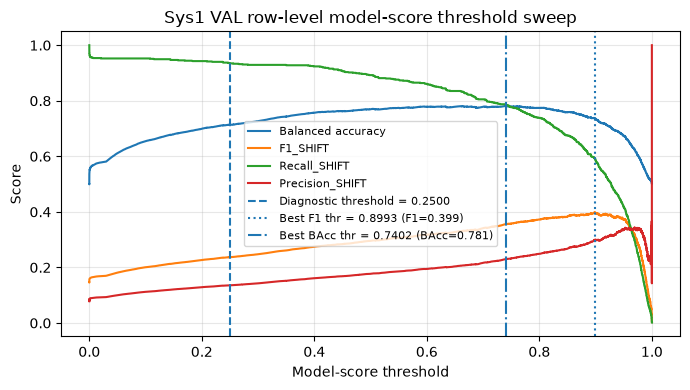

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_threshold_sweep.png


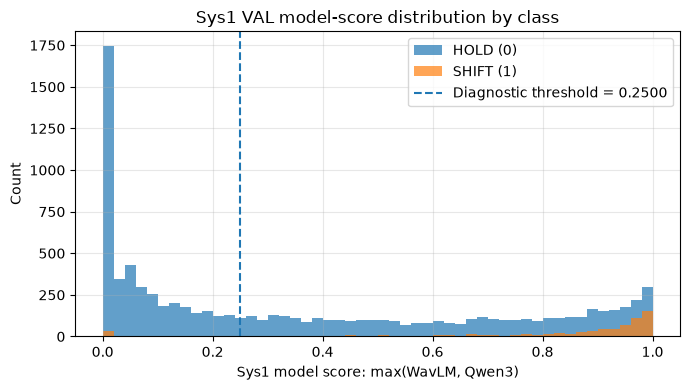

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_model_score_hist.png


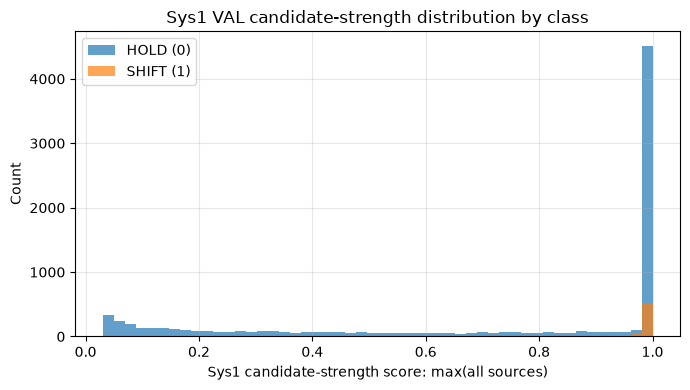

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_candidate_strength_hist.png


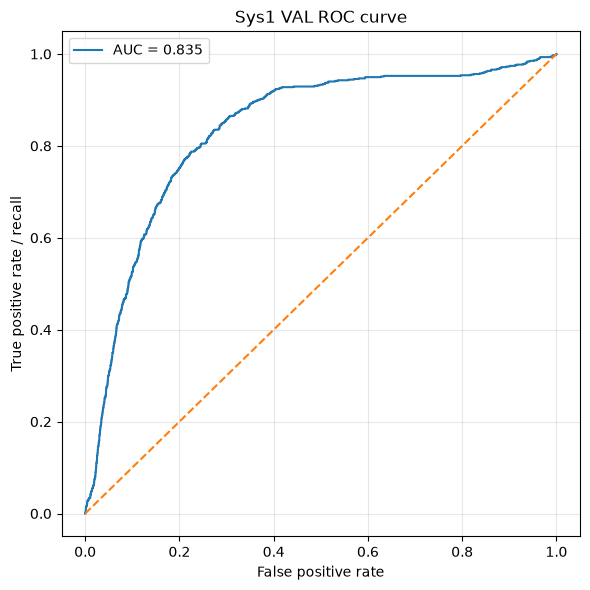

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_roc.png


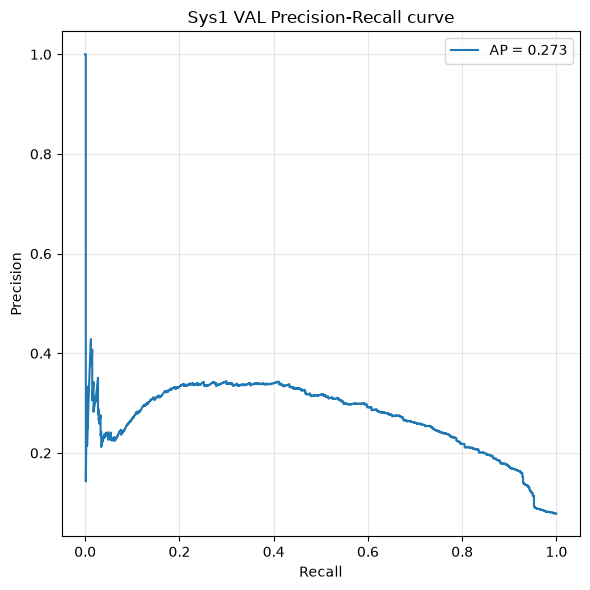

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_pr.png


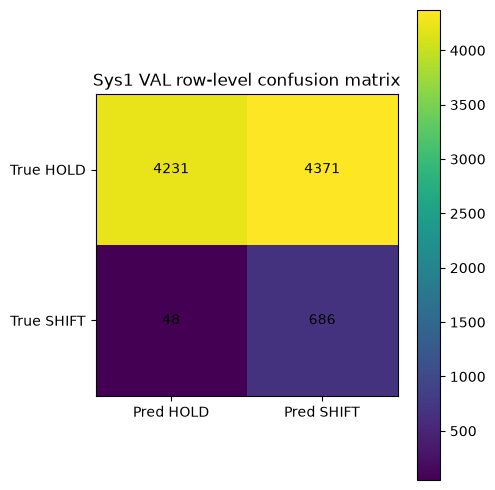

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_confusion.png
Diagnostic row-level threshold metrics:
{'threshold': 0.25, 'precision': 0.1356535495352976, 'recall': 0.9346049046321526, 'f1': 0.23691935762389912, 'balanced_accuracy': 0.7132336311117052, 'tp': 686, 'fp': 4371, 'fn': 48, 'tn': 4231}


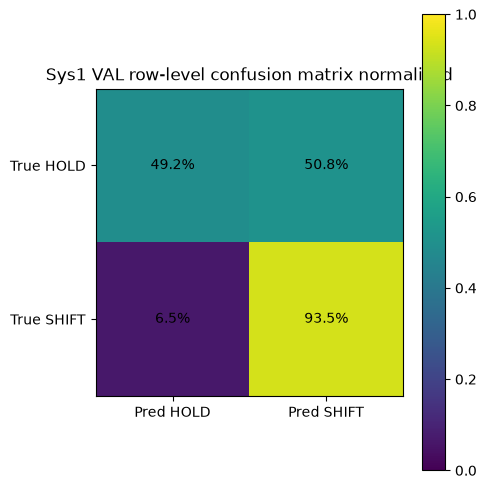

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_confusion_norm.png


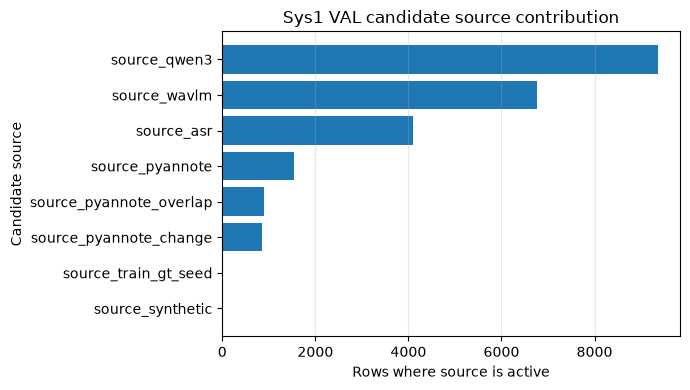

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_source_contribution.png
✅ Saved source contribution CSV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_source_contribution.csv


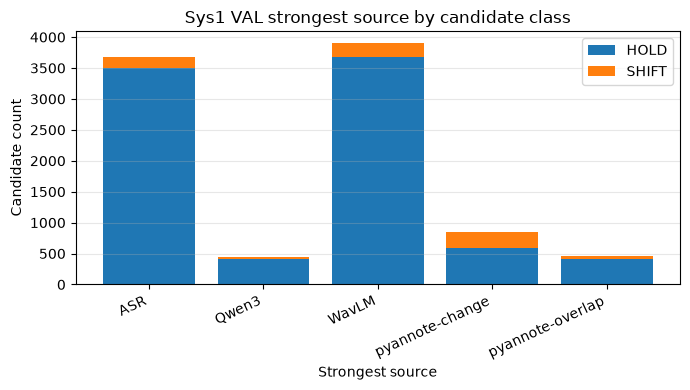

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_strongest_source_by_class.png
✅ Saved strongest-source CSV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_strongest_source_by_class.csv


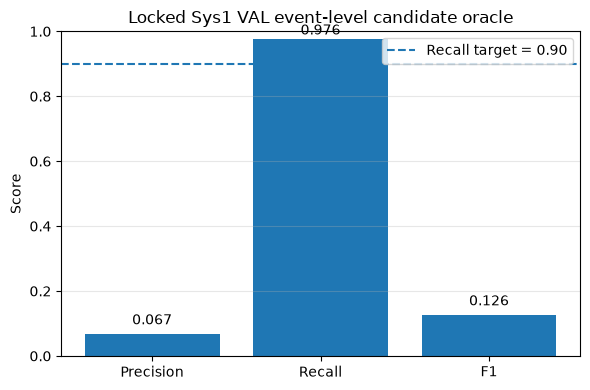

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_locked_oracle_prf.png
✅ Saved oracle PRF CSV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_locked_oracle_prf.csv


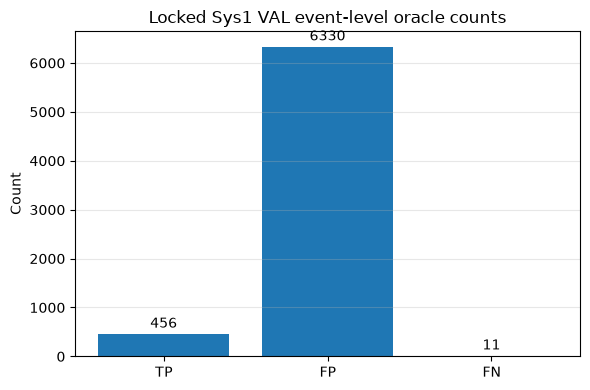

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_locked_oracle_counts.png
✅ Saved oracle counts CSV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/sys1_val_visualizations/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_val_locked_oracle_counts.csv
✅ Sys1 VAL visualizations complete.
Best row-level F1: 0.398716773601753 @ 0.8992879390716553
Best row-level BAcc: 0.7813753787694002 @ 0.7402394115924835
ROC AUC: 0.835185024457274
PR AUC trapezoid: 0.2723892471895359
Average precision: 0.27328221439556855
Event-level VAL oracle: {'P': 0.0671971706454465, 'R': 0.9764453961456103, 'F1': 0.12574107265958911, 'TP': 456, 'FP': 6330, 'FN': 11, 'N_pred': 6786, 'N_gt': 467}
Saved figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_

In [25]:
# Sys1 VAL visualizations
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score,
    confusion_matrix,
    balanced_accuracy_score,
)

assert "SYS1_UNION_ALL" in globals(), "Need SYS1_UNION_ALL from Cell 14."
assert "SYS1_LOCKED" in globals(), "Need SYS1_LOCKED from Cell 15."
assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS from Cell 4."
assert "FIG_DIR" in globals(), "Need FIG_DIR from Cell 3."
assert "candidate_oracle_metrics" in globals(), "Need candidate_oracle_metrics from Cell 15."
assert "filter_sys1_candidates" in globals(), "Need filter_sys1_candidates from Cell 15."
assert "add_labels_to_candidates" in globals(), "Need add_labels_to_candidates from Cell 13/15."
assert "TOL" in globals(), "Need TOL defined."

SYS1_VIS_DIR = FIG_DIR / "sys1_val_visualizations"
SYS1_VIS_DIR.mkdir(parents=True, exist_ok=True)

RUN_PREFIX = str(globals().get("RUN_PREFIX", RUN_VERSION)).strip()
prefix = f"{RUN_PREFIX}_" if RUN_PREFIX else ""

print("Sys1 VAL visualization directory:", SYS1_VIS_DIR)

def _save_show(fig, path: Path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    try:
        fig.tight_layout()
    except Exception:
        pass

    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("✅ Saved:", path)

def _num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if col not in df.columns:
        return pd.Series(np.full(len(df), float(default)), index=df.index)

    return pd.to_numeric(df[col], errors="coerce").fillna(float(default))

def _source_flag(df: pd.DataFrame, col: str) -> pd.Series:
    if col not in df.columns:
        return pd.Series(np.zeros(len(df), dtype=int), index=df.index)

    return pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

def build_sys1_val_visual_df() -> pd.DataFrame:
    val = SYS1_UNION_ALL[SYS1_UNION_ALL["split"].astype(str) == "val"].copy()

    if len(val) == 0:
        raise RuntimeError("No VAL rows found in SYS1_UNION_ALL.")

    if "label" not in val.columns or not set(pd.unique(val["label"].dropna())).intersection({0, 1}):
        val = add_labels_to_candidates(
            val,
            REAL_VAL_EVENTS,
            "val",
            tol=float(TOL),
        )

    val["label"] = pd.to_numeric(val["label"], errors="coerce").fillna(-1).astype(int)
    val = val[val["label"].isin([0, 1])].copy()

    if len(val) == 0:
        raise RuntimeError("No labelled VAL candidates available for Sys1 visualization.")

    model_score_cols = [
        "wavlm_score",
        "wavlm_center_score",
        "qwen_shift_score",
    ]

    source_score_cols = [
        "wavlm_score",
        "wavlm_center_score",
        "qwen_shift_score",
        "pyannote_change_score",
        "pyannote_overlap_score",
        "asr_boundary_score",
    ]

    for c in sorted(set(model_score_cols + source_score_cols)):
        val[c] = _num(val, c, 0.0)

    val["sys1_model_score"] = val[model_score_cols].max(axis=1)
    val["sys1_candidate_score"] = val[source_score_cols].max(axis=1)

    def strongest_source(row):
        vals = {
            "WavLM": max(
                float(row.get("wavlm_score", 0.0)),
                float(row.get("wavlm_center_score", 0.0)),
            ),
            "Qwen3": float(row.get("qwen_shift_score", 0.0)),
            "pyannote-change": float(row.get("pyannote_change_score", 0.0)),
            "pyannote-overlap": float(row.get("pyannote_overlap_score", 0.0)),
            "ASR": float(row.get("asr_boundary_score", 0.0)),
        }
        return max(vals, key=vals.get)

    val["strongest_source"] = val.apply(strongest_source, axis=1)

    return val.reset_index(drop=True)

def _threshold_sweep(y_true: np.ndarray, y_prob: np.ndarray) -> pd.DataFrame:
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    if len(y_true) == 0 or len(y_prob) == 0:
        return pd.DataFrame(columns=[
            "threshold",
            "precision_shift",
            "recall_shift",
            "f1_shift",
            "balanced_accuracy",
            "tp",
            "fp",
            "fn",
            "tn",
            "fpr",
            "tpr",
        ])

    order = np.argsort(-y_prob, kind="mergesort")
    s = y_prob[order]
    y = y_true[order]

    is_pos = (y == 1)
    is_neg = ~is_pos

    Ptot = int(is_pos.sum())
    Ntot = int(is_neg.sum())

    tp_cum = np.cumsum(is_pos).astype(np.float64)
    fp_cum = np.cumsum(is_neg).astype(np.float64)

    group_ends = np.r_[np.where(s[:-1] != s[1:])[0], len(s) - 1]

    thr_arr = s[group_ends].astype(np.float64)

    tpv = tp_cum[group_ends]
    fpv = fp_cum[group_ends]
    fnv = float(Ptot) - tpv
    tnv = float(Ntot) - fpv

    prec_arr = tpv / (tpv + fpv + 1e-12)
    rec_arr = tpv / (tpv + fnv + 1e-12)
    f1_arr = 2.0 * prec_arr * rec_arr / (prec_arr + rec_arr + 1e-12)

    tpr_arr = rec_arr
    fpr_arr = fpv / (fpv + tnv + 1e-12)
    tnr_arr = tnv / (tnv + fpv + 1e-12)
    bacc_arr = 0.5 * (tpr_arr + tnr_arr)

    return pd.DataFrame({
        "threshold": thr_arr,
        "precision_shift": prec_arr,
        "recall_shift": rec_arr,
        "f1_shift": f1_arr,
        "balanced_accuracy": bacc_arr,
        "tp": tpv.astype(int),
        "fp": fpv.astype(int),
        "fn": fnv.astype(int),
        "tn": tnv.astype(int),
        "fpr": fpr_arr,
        "tpr": tpr_arr,
    })

VAL_VIS_DF = build_sys1_val_visual_df()

y_true = VAL_VIS_DF["label"].astype(int).to_numpy()
y_prob = VAL_VIS_DF["sys1_model_score"].astype(float).to_numpy()
y_candidate_strength = VAL_VIS_DF["sys1_candidate_score"].astype(float).to_numpy()

finite = np.isfinite(y_prob) & np.isfinite(y_candidate_strength)

if not finite.all():
    print("⚠️ Removing non-finite Sys1 visualization scores:", int((~finite).sum()))
    y_true = y_true[finite]
    y_prob = y_prob[finite]
    y_candidate_strength = y_candidate_strength[finite]
    VAL_VIS_DF = VAL_VIS_DF.loc[finite].reset_index(drop=True)

if len(y_true) == 0:
    raise RuntimeError("VAL visualization data is empty.")

if len(np.unique(y_true)) < 2:
    raise RuntimeError("Need both HOLD and SHIFT examples for ROC/PR/confusion visualizations.")

thr = float(globals().get(
    "SYS1_VIS_SCORE_THR",
    min(
        float(SYS1_LOCKED.get("wavlm_thr", 0.10)),
        float(SYS1_LOCKED.get("qwen_thr", 0.10)),
    )
))

print("Sys1 VAL visualization")
print("  n:", len(y_true))
print("  positives SHIFT:", int(y_true.sum()))
print("  negatives HOLD:", int((y_true == 0).sum()))
print("  diagnostic model-score threshold:", thr)
print("  locked Sys1 settings:")
print(json.dumps(SYS1_LOCKED, indent=2))

df_sweep = _threshold_sweep(y_true, y_prob)

if len(df_sweep) == 0:
    raise RuntimeError("Sys1 threshold sweep is empty.")

best_f1_i = int(df_sweep["f1_shift"].idxmax())
best_bacc_i = int(df_sweep["balanced_accuracy"].idxmax())

thr_f1 = float(df_sweep.loc[best_f1_i, "threshold"])
thr_bacc = float(df_sweep.loc[best_bacc_i, "threshold"])
best_f1 = float(df_sweep.loc[best_f1_i, "f1_shift"])
best_bacc = float(df_sweep.loc[best_bacc_i, "balanced_accuracy"])

sweep_csv = SYS1_VIS_DIR / f"{prefix}sys1_val_model_score_threshold_sweep.csv"
df_sweep.to_csv(sweep_csv, index=False)
print("✅ Saved sweep CSV:", sweep_csv)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_sweep["threshold"], df_sweep["balanced_accuracy"], label="Balanced accuracy")
ax.plot(df_sweep["threshold"], df_sweep["f1_shift"], label="F1_SHIFT")
ax.plot(df_sweep["threshold"], df_sweep["recall_shift"], label="Recall_SHIFT")
ax.plot(df_sweep["threshold"], df_sweep["precision_shift"], label="Precision_SHIFT")
ax.axvline(thr, linestyle="--", label=f"Diagnostic threshold = {thr:.4f}")
ax.axvline(thr_f1, linestyle=":", label=f"Best F1 thr = {thr_f1:.4f} (F1={best_f1:.3f})")
ax.axvline(thr_bacc, linestyle="-.", label=f"Best BAcc thr = {thr_bacc:.4f} (BAcc={best_bacc:.3f})")
ax.set_xlabel("Model-score threshold")
ax.set_ylabel("Score")
ax.set_title("Sys1 VAL row-level model-score threshold sweep")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_threshold_sweep.png")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y_prob[y_true == 0], bins=50, alpha=0.7, label="HOLD (0)")
ax.hist(y_prob[y_true == 1], bins=50, alpha=0.7, label="SHIFT (1)")
ax.axvline(thr, linestyle="--", label=f"Diagnostic threshold = {thr:.4f}")
ax.set_xlabel("Sys1 model score: max(WavLM, Qwen3)")
ax.set_ylabel("Count")
ax.set_title("Sys1 VAL model-score distribution by class")
ax.grid(True, alpha=0.3)
ax.legend()
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_model_score_hist.png")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y_candidate_strength[y_true == 0], bins=50, alpha=0.7, label="HOLD (0)")
ax.hist(y_candidate_strength[y_true == 1], bins=50, alpha=0.7, label="SHIFT (1)")
ax.set_xlabel("Sys1 candidate-strength score: max(all sources)")
ax.set_ylabel("Count")
ax.set_title("Sys1 VAL candidate-strength distribution by class")
ax.grid(True, alpha=0.3)
ax.legend()
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_candidate_strength_hist.png")

fpr2, tpr2, roc_thresholds = roc_curve(y_true, y_prob)
roc_auc = float(auc(fpr2, tpr2))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr2, tpr2, label=f"AUC = {roc_auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate / recall")
ax.set_title("Sys1 VAL ROC curve")
ax.grid(True, alpha=0.3)
ax.legend()
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_roc.png")

prec2, rec2, pr_thresholds = precision_recall_curve(y_true, y_prob)
pr_auc_trapz = float(auc(rec2, prec2))
avg_precision = float(average_precision_score(y_true, y_prob))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(rec2, prec2, label=f"AP = {avg_precision:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Sys1 VAL Precision-Recall curve")
ax.grid(True, alpha=0.3)
ax.legend()
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_pr.png")

y_pred = (y_prob >= thr).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

diag_p = tp / max(1, tp + fp)
diag_r = tp / max(1, tp + fn)
diag_f1 = 2 * diag_p * diag_r / max(1e-12, diag_p + diag_r)
diag_bacc = balanced_accuracy_score(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(cm, interpolation="nearest", aspect="equal")
ax.set_title("Sys1 VAL row-level confusion matrix")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Pred HOLD", "Pred SHIFT"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["True HOLD", "True SHIFT"])

for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, str(v), ha="center", va="center")

fig.colorbar(im, ax=ax)
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_confusion.png")

print("Diagnostic row-level threshold metrics:")
print({
    "threshold": float(thr),
    "precision": float(diag_p),
    "recall": float(diag_r),
    "f1": float(diag_f1),
    "balanced_accuracy": float(diag_bacc),
    "tp": int(tp),
    "fp": int(fp),
    "fn": int(fn),
    "tn": int(tn),
})

cm_norm = cm.astype(np.float64) / (cm.sum(axis=1, keepdims=True) + 1e-12)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(cm_norm, vmin=0.0, vmax=1.0, interpolation="nearest", aspect="equal")
ax.set_title("Sys1 VAL row-level confusion matrix normalized")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Pred HOLD", "Pred SHIFT"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["True HOLD", "True SHIFT"])

for (r, c), v in np.ndenumerate(cm_norm):
    ax.text(c, r, f"{v*100:.1f}%", ha="center", va="center")

fig.colorbar(im, ax=ax)
_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_confusion_norm.png")

source_cols = [c for c in SYS1_UNION_ALL.columns if c.startswith("source_")]

if source_cols:
    source_sum = (
        SYS1_UNION_ALL[SYS1_UNION_ALL["split"].astype(str) == "val"][source_cols]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
        .sum()
        .sort_values(ascending=True)
        .reset_index()
    )
    source_sum.columns = ["source", "count"]

    source_sum_csv = SYS1_VIS_DIR / f"{prefix}sys1_val_source_contribution.csv"
    source_sum.to_csv(source_sum_csv, index=False)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(source_sum["source"], source_sum["count"])
    ax.set_title("Sys1 VAL candidate source contribution")
    ax.set_xlabel("Rows where source is active")
    ax.set_ylabel("Candidate source")
    ax.grid(axis="x", alpha=0.3)
    _save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_source_contribution.png")
    print("✅ Saved source contribution CSV:", source_sum_csv)

src_by_class = (
    VAL_VIS_DF
    .groupby(["label", "strongest_source"])
    .size()
    .reset_index(name="count")
)

src_by_class["label_name"] = src_by_class["label"].map({0: "HOLD", 1: "SHIFT"})

pivot_src = (
    src_by_class
    .pivot_table(index="strongest_source", columns="label_name", values="count", fill_value=0)
    .sort_index()
)

if len(pivot_src):
    strongest_csv = SYS1_VIS_DIR / f"{prefix}sys1_val_strongest_source_by_class.csv"
    pivot_src.to_csv(strongest_csv)

    fig, ax = plt.subplots(figsize=(7, 4))
    bottom = np.zeros(len(pivot_src))

    for col in pivot_src.columns:
        vals = pivot_src[col].to_numpy(dtype=float)
        ax.bar(pivot_src.index.astype(str), vals, bottom=bottom, label=col)
        bottom += vals

    ax.set_title("Sys1 VAL strongest source by candidate class")
    ax.set_xlabel("Strongest source")
    ax.set_ylabel("Candidate count")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    plt.xticks(rotation=25, ha="right")
    _save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_strongest_source_by_class.png")
    print("✅ Saved strongest-source CSV:", strongest_csv)

if "VAL_SYS1_ORACLE" in globals() and isinstance(VAL_SYS1_ORACLE, dict):
    oracle_metrics = VAL_SYS1_ORACLE
else:
    if "SYS1_FILTERED_VAL" in globals() and SYS1_FILTERED_VAL is not None and len(SYS1_FILTERED_VAL):
        oracle_metrics = candidate_oracle_metrics(SYS1_FILTERED_VAL, REAL_VAL_EVENTS, tol=float(TOL))
    else:
        locked_val = filter_sys1_candidates(
            SYS1_UNION_ALL[SYS1_UNION_ALL["split"].astype(str) == "val"].copy(),
            wavlm_thr=float(SYS1_LOCKED.get("wavlm_thr", 0.10)),
            qwen_thr=float(SYS1_LOCKED.get("qwen_thr", 0.10)),
            use_pyannote=bool(SYS1_LOCKED.get("use_pyannote", True)),
            use_asr=bool(SYS1_LOCKED.get("use_asr", True)),
            merge_tol=float(SYS1_LOCKED.get("merge_tol", 0.25)),
        )
        oracle_metrics = candidate_oracle_metrics(locked_val, REAL_VAL_EVENTS, tol=float(TOL))

oracle_df = pd.DataFrame([
    {"metric": "Precision", "value": float(oracle_metrics.get("P", 0.0))},
    {"metric": "Recall", "value": float(oracle_metrics.get("R", 0.0))},
    {"metric": "F1", "value": float(oracle_metrics.get("F1", 0.0))},
])

oracle_csv = SYS1_VIS_DIR / f"{prefix}sys1_val_locked_oracle_prf.csv"
oracle_df.to_csv(oracle_csv, index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(oracle_df["metric"], oracle_df["value"])
ax.axhline(TARGET_SYS1_RECALL, linestyle="--", label=f"Recall target = {TARGET_SYS1_RECALL:.2f}")
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Locked Sys1 VAL event-level candidate oracle")
ax.grid(axis="y", alpha=0.3)
ax.legend()

for i, v in enumerate(oracle_df["value"]):
    ax.text(i, min(v + 0.02, 0.98), f"{v:.3f}", ha="center", va="bottom")

_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_locked_oracle_prf.png")
print("✅ Saved oracle PRF CSV:", oracle_csv)

count_df = pd.DataFrame([
    {"count_type": "TP", "count": int(oracle_metrics.get("TP", 0))},
    {"count_type": "FP", "count": int(oracle_metrics.get("FP", 0))},
    {"count_type": "FN", "count": int(oracle_metrics.get("FN", 0))},
])

counts_csv = SYS1_VIS_DIR / f"{prefix}sys1_val_locked_oracle_counts.csv"
count_df.to_csv(counts_csv, index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(count_df["count_type"], count_df["count"])
ax.set_ylabel("Count")
ax.set_title("Locked Sys1 VAL event-level oracle counts")
ax.grid(axis="y", alpha=0.3)

for i, v in enumerate(count_df["count"]):
    ax.text(
        i,
        v + max(1, 0.01 * max(count_df["count"].max(), 1)),
        str(v),
        ha="center",
        va="bottom",
    )

_save_show(fig, SYS1_VIS_DIR / f"{prefix}sys1_val_locked_oracle_counts.png")
print("✅ Saved oracle counts CSV:", counts_csv)

globals()["SYS1_VAL_VIS_DF"] = VAL_VIS_DF
globals()["SYS1_VAL_SWEEP_DF"] = df_sweep
globals()["SYS1_VAL_SWEEP_CSV"] = str(sweep_csv)
globals()["SYS1_VAL_ROC_AUC"] = float(roc_auc)
globals()["SYS1_VAL_PR_AUC_TRAPZ"] = float(pr_auc_trapz)
globals()["SYS1_VAL_AVERAGE_PRECISION"] = float(avg_precision)
globals()["SYS1_VAL_DIAGNOSTIC_THR"] = float(thr)
globals()["SYS1_VAL_ORACLE_FOR_PLOT"] = oracle_metrics
globals()["SYS1_VAL_VIS_DIR"] = str(SYS1_VIS_DIR)

print("✅ Sys1 VAL visualizations complete.")
print("Best row-level F1:", best_f1, "@", thr_f1)
print("Best row-level BAcc:", best_bacc, "@", thr_bacc)
print("ROC AUC:", roc_auc)
print("PR AUC trapezoid:", pr_auc_trapz)
print("Average precision:", avg_precision)
print("Event-level VAL oracle:", oracle_metrics)
print("Saved figures to:", SYS1_VIS_DIR)

In [26]:
# Build Sys2 multimodal candidate feature table
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, Optional
from IPython.display import display
from tqdm.auto import tqdm

SYS2_FEATURES_PATH = CACHE_DIR / "sys2_multimodal_features_all.pkl"
SYS2_FEATURES_META_PATH = CACHE_DIR / "sys2_multimodal_features_all.meta.json"

SYS2_BASE_FEATURE_COLS = [
    "session", "time", "split", "audio_path",

    "source_wavlm",
    "source_pyannote",
    "source_pyannote_change",
    "source_pyannote_overlap",
    "source_asr",
    "source_qwen3",
    "source_synthetic",
    "source_train_gt_seed",

    "wavlm_score",
    "wavlm_center_score",
    "pyannote_change_score",
    "pyannote_overlap_score",
    "pyannote_change_dist",
    "pyannote_any_candidate_dist",
    "pyannote_overlap_dist",
    "pyannote_active_before",
    "pyannote_active_after",
    "pyannote_active_delta",
    "pyannote_local_active",
    "pyannote_local_overlap_flag",
    "asr_boundary_score",
    "asr_boundary_dist",
    "asr_has_left",
    "asr_has_right",
    "asr_left_len",
    "asr_right_len",
    "qwen_shift_score",
    "qwen_backchannel_score",
    "qwen_interruption_score",

    "energy_left",
    "energy_right",
    "energy_delta",
    "energy_ratio",
    "ecapa_cos",
    "ecapa_available",
    "ecapa_left_rms",
    "ecapa_right_rms",

    "candidate_density_1s",
    "candidate_density_2s",

    "label",
    "action",
    "action_id",
    "dt_to_event",
    "is_synthetic",
    "is_diffusion_augmented",
    "sample_weight",
]

SYS2_PROB_COLS = []
for _a in ACTION_NAMES:
    SYS2_PROB_COLS.extend([f"qwen_p_{_a}", f"wavlm_p_{_a}"])

SYS2_FEATURE_COLUMNS = list(dict.fromkeys(SYS2_BASE_FEATURE_COLS + SYS2_PROB_COLS))

def _sys2_feature_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _sys2_feature_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "tol": float(TOL),
        "sys1_locked": SYS1_LOCKED if "SYS1_LOCKED" in globals() else {},
        "use_wavlm": bool(USE_WAVLM_SYS1),
        "use_pyannote": bool(USE_PYANNOTE_DIA),
        "use_asr": bool(USE_ASR_TEXT),
        "use_qwen3": bool(USE_QWEN3_LLM),
        "use_ecapa": bool(USE_ECAPA_SPK),
        "ecapa_available": bool(getattr(globals().get("ECAPA", None), "available", False)),
        "n_sys1_filtered": int(len(SYS1_FILTERED_ALL)) if "SYS1_FILTERED_ALL" in globals() else -1,
        "sys1_union_fingerprint": _sys2_feature_file_fingerprint(SYS1_UNION_PATH) if "SYS1_UNION_PATH" in globals() else None,
        "wavlm_candidates_fingerprint": _sys2_feature_file_fingerprint(WAVLM_CANDIDATES_PATH) if "WAVLM_CANDIDATES_PATH" in globals() else None,
        "qwen_scores_fingerprint": _sys2_feature_file_fingerprint(QWEN3_SCORES_PATH) if "QWEN3_SCORES_PATH" in globals() else None,
        "pyannote_candidates_fingerprint": _sys2_feature_file_fingerprint(PYANNOTE_CANDS_PATH) if "PYANNOTE_CANDS_PATH" in globals() else None,
        "asr_segments_fingerprint": _sys2_feature_file_fingerprint(ASR_SEGMENTS_PATH) if "ASR_SEGMENTS_PATH" in globals() else None,
        "test_labels_attached": False,
        "cache_format": "pickle",
    }

def _sys2_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        return json.loads(Path(path).read_text()) == expected

    except Exception:
        return False

def _clean_legacy_sys2_features_parquet():
    for p in [
        CACHE_DIR / "sys2_multimodal_features_all.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet Sys2 feature cache:", p)

        except Exception as e:
            print("Could not remove legacy parquet Sys2 feature cache:", p, e)

def _empty_sys2_features() -> pd.DataFrame:
    return pd.DataFrame(columns=SYS2_FEATURE_COLUMNS)

def _ensure_sys2_feature_schema(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return _empty_sys2_features()

    df = df.copy()

    distance_cols = {
        "pyannote_change_dist",
        "pyannote_any_candidate_dist",
        "pyannote_overlap_dist",
        "asr_boundary_dist",
    }

    source_cols = [c for c in SYS2_FEATURE_COLUMNS if c.startswith("source_")]

    for c in SYS2_FEATURE_COLUMNS:
        if c in df.columns:
            continue

        if c == "action":
            df[c] = "NA"
        elif c in ["session", "split", "audio_path"]:
            df[c] = ""
        elif c in ["is_synthetic", "is_diffusion_augmented"]:
            df[c] = False
        elif c == "label":
            df[c] = -1
        elif c == "action_id":
            df[c] = -1
        elif c in distance_cols:
            df[c] = 999.0
        else:
            df[c] = 0.0

    df["session"] = df["session"].astype(str)
    df["split"] = df["split"].fillna("unknown").astype(str)
    df["audio_path"] = df["audio_path"].fillna("").astype(str)

    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df = df.dropna(subset=["session", "time"])
    df = df[df["time"] >= 0].reset_index(drop=True)

    for c in source_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)

    numeric_cols = [
        c for c in SYS2_FEATURE_COLUMNS
        if c not in ["session", "split", "audio_path", "action", "is_synthetic", "is_diffusion_augmented"]
        and c not in source_cols
    ]

    for c in numeric_cols:
        if c == "label":
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(-1)
        elif c == "action_id":
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(-1)
        elif c in distance_cols:
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(999.0)
        else:
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0.0)

    df["label"] = df["label"].astype(int)

    df["action"] = df["action"].fillna("NA").astype(str)
    df.loc[~df["action"].isin(ACTION_NAMES), "action"] = "NA"

    df["action_id"] = pd.to_numeric(df["action_id"], errors="coerce").fillna(-1).astype(int)

    labelled_mask = df["label"].isin([0, 1])
    df.loc[labelled_mask, "action_id"] = (
        df.loc[labelled_mask, "action"]
        .map(ACTION_TO_ID)
        .fillna(ACTION_TO_ID["NA"])
        .astype(int)
    )

    df.loc[df["label"] == -1, "action"] = "NA"
    df.loc[df["label"] == -1, "action_id"] = -1

    df.loc[df["action"].isin(SHIFT_ACTIONS), "label"] = 1
    df.loc[df["action"].isin(HOLD_ACTIONS) & (df["label"] != -1), "label"] = 0

    df["is_synthetic"] = df["is_synthetic"].fillna(False).astype(bool)
    df["is_diffusion_augmented"] = df["is_diffusion_augmented"].fillna(False).astype(bool)

    df["sample_weight"] = pd.to_numeric(df["sample_weight"], errors="coerce").fillna(1.0).astype(float)
    df["sample_weight"] = df["sample_weight"].clip(lower=1e-6)

    return (
        df[SYS2_FEATURE_COLUMNS]
        .drop_duplicates(subset=["session", "time", "split"])
        .sort_values(["split", "session", "time"])
        .reset_index(drop=True)
    )

def nearest_value(
    df: pd.DataFrame,
    session: str,
    tau: float,
    value_col: str,
    time_col: str = "time",
    default: float = 0.0,
    max_dist: float = 0.75,
) -> float:
    if df is None or len(df) == 0 or value_col not in df.columns or time_col not in df.columns:
        return float(default)

    g = df[df["session"].astype(str) == str(session)]

    if len(g) == 0:
        return float(default)

    arr = pd.to_numeric(g[time_col], errors="coerce").to_numpy(dtype=float)

    if len(arr) == 0 or not np.isfinite(arr).any():
        return float(default)

    d = np.abs(arr - float(tau))
    j = int(np.nanargmin(d))

    if not np.isfinite(d[j]) or d[j] > float(max_dist):
        return float(default)

    try:
        v = float(g.iloc[j][value_col])
        return v if np.isfinite(v) else float(default)

    except Exception:
        return float(default)

def row_or_nearest(
    row: pd.Series,
    col: str,
    fallback_df: Optional[pd.DataFrame],
    session: str,
    tau: float,
    default: float = 0.0,
    max_dist: float = 0.75,
    allow_zero_as_missing: bool = False,
) -> float:
    if col in row.index:
        try:
            v = float(row.get(col, default))

            if np.isfinite(v):
                if not allow_zero_as_missing:
                    return v

                if abs(v - float(default)) > 1e-12:
                    return v

        except Exception:
            pass

    return nearest_value(
        fallback_df,
        session=session,
        tau=tau,
        value_col=col,
        default=default,
        max_dist=max_dist,
    )

def energy_features(
    audio_path: Path,
    tau: float,
    side_s: float = 0.75,
    guard_s: float = 0.05,
) -> Dict[str, float]:
    try:
        audio_path = Path(audio_path)

        left, _ = read_audio_mono(
            audio_path,
            start_s=max(0.0, float(tau) - float(guard_s) - float(side_s)),
            duration_s=float(side_s),
            sr=TARGET_SR,
        )

        right, _ = read_audio_mono(
            audio_path,
            start_s=max(0.0, float(tau) + float(guard_s)),
            duration_s=float(side_s),
            sr=TARGET_SR,
        )

        rl = rms(left)
        rr = rms(right)

        return {
            "energy_left": float(rl),
            "energy_right": float(rr),
            "energy_delta": float(rr - rl),
            "energy_ratio": float(rr / max(1e-8, rl)),
        }

    except Exception:
        return {
            "energy_left": 0.0,
            "energy_right": 0.0,
            "energy_delta": 0.0,
            "energy_ratio": 0.0,
        }

def build_candidate_density_index(cand_df: pd.DataFrame) -> Dict[str, np.ndarray]:
    out = {}

    if cand_df is None or len(cand_df) == 0:
        return out

    tmp = cand_df[["session", "time"]].copy()
    tmp["session"] = tmp["session"].astype(str)
    tmp["time"] = pd.to_numeric(tmp["time"], errors="coerce")
    tmp = tmp.dropna(subset=["session", "time"])

    for sid, g in tmp.groupby("session"):
        out[str(sid)] = np.sort(g["time"].to_numpy(dtype=float))

    return out

def candidate_density_from_index(
    density_index: Dict[str, np.ndarray],
    session: str,
    tau: float,
    radius_s: float = 1.0,
) -> int:
    arr = density_index.get(str(session), np.array([], dtype=float))

    if len(arr) == 0:
        return 0

    tau = float(tau)

    lo = np.searchsorted(arr, tau - float(radius_s), side="left")
    hi = np.searchsorted(arr, tau + float(radius_s), side="right")

    return int(max(0, hi - lo))

def resolve_candidate_audio_path(row: pd.Series) -> str:
    sid = str(row.get("session", ""))
    audio_path = row.get("audio_path", "")

    if isinstance(audio_path, str) and audio_path and Path(audio_path).exists():
        return audio_path

    if "DEV_AUDIO" in globals() and sid in DEV_AUDIO:
        return str(DEV_AUDIO[sid])

    if "TEST_AUDIO" in globals() and sid in TEST_AUDIO:
        return str(TEST_AUDIO[sid])

    if "TRAIN_EVENTS_MIXED" in globals() and TRAIN_EVENTS_MIXED is not None and len(TRAIN_EVENTS_MIXED):
        match = TRAIN_EVENTS_MIXED[TRAIN_EVENTS_MIXED["session"].astype(str) == sid]

        if len(match) and "audio_path" in match.columns:
            p = str(match.iloc[0].audio_path)

            if Path(p).exists():
                return p

    return ""

def label_candidate_from_events(
    session: str,
    tau: float,
    events_df: pd.DataFrame,
    split_name: str,
    tol: Optional[float] = None,
) -> Dict[str, Any]:
    tol = float(TOL if tol is None else tol)

    if events_df is None or len(events_df) == 0:
        return {
            "label": -1,
            "action": "NA",
            "action_id": -1,
            "dt_to_event": np.nan,
        }

    e = events_df[events_df["session"].astype(str) == str(session)].copy()

    if len(e) == 0:
        return {
            "label": 0,
            "action": "NA",
            "action_id": ACTION_TO_ID["NA"],
            "dt_to_event": np.nan,
        }

    e["time"] = pd.to_numeric(e["time"], errors="coerce")
    e = e.dropna(subset=["time"]).reset_index(drop=True)

    if len(e) == 0:
        return {
            "label": 0,
            "action": "NA",
            "action_id": ACTION_TO_ID["NA"],
            "dt_to_event": np.nan,
        }

    dt = np.abs(e["time"].to_numpy(dtype=float) - float(tau))
    j = int(np.argmin(dt))

    if float(dt[j]) <= tol:
        er = e.iloc[j]

        action = str(er.get("action", "NA"))
        if action not in ACTION_TO_ID:
            action = "NA"

        label = int(er.get("label", 0))
        action_id = int(ACTION_TO_ID[action]) if label in [0, 1] else -1

        return {
            "label": label,
            "action": action if label in [0, 1] else "NA",
            "action_id": action_id,
            "dt_to_event": float(float(tau) - float(er.get("time", tau))),
        }

    return {
        "label": 0,
        "action": "NA",
        "action_id": ACTION_TO_ID["NA"],
        "dt_to_event": float(np.min(dt)) if len(dt) else np.nan,
    }

def get_event_table_for_sys2_split(split_name: str) -> Optional[pd.DataFrame]:
    split_name = str(split_name)

    if split_name == "train":
        return REAL_TRAIN_EVENTS

    if split_name == "val":
        return REAL_VAL_EVENTS

    if split_name == "synth_train":
        return SYNTH_EVENTS

    if split_name == "real_diffusion":
        return REAL_AUG_EVENTS

    if split_name == "synth_diffusion":
        return SYNTH_AUG_EVENTS

    return None

def _source_int(row: pd.Series, col: str) -> int:
    try:
        v = row.get(col, 0)
        if pd.isna(v):
            return 0
        return int(float(v))
    except Exception:
        return 0

def build_sys2_features_for_candidates(
    cand_df: pd.DataFrame,
    events_df: Optional[pd.DataFrame],
    split_name: str,
    attach_labels: bool,
) -> pd.DataFrame:
    if cand_df is None or len(cand_df) == 0:
        return _empty_sys2_features()

    cand_df = cand_df.copy()
    cand_df["session"] = cand_df["session"].astype(str)
    cand_df["time"] = pd.to_numeric(cand_df["time"], errors="coerce")
    cand_df = cand_df.dropna(subset=["session", "time"]).reset_index(drop=True)

    density_index = build_candidate_density_index(cand_df)

    rows = []

    for idx, r in tqdm(cand_df.iterrows(), total=len(cand_df), desc=f"Sys2 features {split_name}"):
        sid = str(r.session)
        tau = float(r.time)

        audio_path = resolve_candidate_audio_path(r)

        row = {
            "session": sid,
            "time": tau,
            "split": str(split_name),
            "audio_path": audio_path,
        }

        for c in [
            "source_wavlm",
            "source_pyannote",
            "source_pyannote_change",
            "source_pyannote_overlap",
            "source_asr",
            "source_qwen3",
            "source_synthetic",
            "source_train_gt_seed",
        ]:
            row[c] = _source_int(r, c)

        row["wavlm_score"] = row_or_nearest(
            r,
            "wavlm_score",
            WAVLM_CANDIDATES_ALL if "WAVLM_CANDIDATES_ALL" in globals() else None,
            sid,
            tau,
            default=0.0,
            allow_zero_as_missing=True,
        )
        row["wavlm_center_score"] = row_or_nearest(
            r,
            "wavlm_center_score",
            WAVLM_CANDIDATES_ALL if "WAVLM_CANDIDATES_ALL" in globals() else None,
            sid,
            tau,
            default=0.0,
            allow_zero_as_missing=True,
        )

        row["pyannote_change_score"] = row_or_nearest(
            r,
            "pyannote_change_score",
            PYANNOTE_CANDIDATES if "PYANNOTE_CANDIDATES" in globals() else None,
            sid,
            tau,
            default=0.0,
        )
        row["pyannote_overlap_score"] = row_or_nearest(
            r,
            "pyannote_overlap_score",
            PYANNOTE_CANDIDATES if "PYANNOTE_CANDIDATES" in globals() else None,
            sid,
            tau,
            default=0.0,
        )

        pyf = pyannote_features(sid, tau) if USE_PYANNOTE_DIA else {}

        row.update({
            "pyannote_change_dist": float(pyf.get("pyannote_change_dist", 999.0)),
            "pyannote_any_candidate_dist": float(pyf.get("pyannote_any_candidate_dist", 999.0)),
            "pyannote_overlap_dist": float(pyf.get("pyannote_overlap_dist", 999.0)),
            "pyannote_active_before": int(pyf.get("pyannote_active_before", 0)),
            "pyannote_active_after": int(pyf.get("pyannote_active_after", 0)),
            "pyannote_active_delta": int(pyf.get("pyannote_active_delta", 0)),
            "pyannote_local_active": int(pyf.get("pyannote_local_active", 0)),
            "pyannote_local_overlap_flag": int(pyf.get("pyannote_local_overlap_flag", 0)),
        })

        ctx = asr_context_for_candidate(sid, tau) if USE_ASR_TEXT else {}

        asr_left = str(ctx.get("asr_left", ""))
        asr_right = str(ctx.get("asr_right", ""))

        row["asr_boundary_score"] = float(r.get("asr_boundary_score", 0.0)) if pd.notna(r.get("asr_boundary_score", 0.0)) else 0.0
        row["asr_boundary_dist"] = float(ctx.get("asr_boundary_dist", 999.0))
        row["asr_has_left"] = int(ctx.get("asr_has_left", 0))
        row["asr_has_right"] = int(ctx.get("asr_has_right", 0))
        row["asr_left_len"] = int(len(asr_left))
        row["asr_right_len"] = int(len(asr_right))

        for a in ACTION_NAMES:
            q_col = f"qwen_p_{a}"
            w_col = f"wavlm_p_{a}"

            row[q_col] = row_or_nearest(
                r,
                q_col,
                QWEN3_SCORES_ALL if "QWEN3_SCORES_ALL" in globals() else None,
                sid,
                tau,
                default=0.0,
                allow_zero_as_missing=True,
            )

            row[w_col] = row_or_nearest(
                r,
                w_col,
                WAVLM_CANDIDATES_ALL if "WAVLM_CANDIDATES_ALL" in globals() else None,
                sid,
                tau,
                default=0.0,
                allow_zero_as_missing=True,
            )

        qwen_prob_shift = float(row.get("qwen_p_NTT", 0.0)) + float(row.get("qwen_p_ITT", 0.0))

        row["qwen_shift_score"] = max(
            float(r.get("qwen_shift_score", 0.0)) if pd.notna(r.get("qwen_shift_score", 0.0)) else 0.0,
            qwen_prob_shift,
        )
        row["qwen_backchannel_score"] = max(
            float(r.get("qwen_backchannel_score", 0.0)) if pd.notna(r.get("qwen_backchannel_score", 0.0)) else 0.0,
            float(row.get("qwen_p_BC", 0.0)),
        )
        row["qwen_interruption_score"] = max(
            float(r.get("qwen_interruption_score", 0.0)) if pd.notna(r.get("qwen_interruption_score", 0.0)) else 0.0,
            float(row.get("qwen_p_ITT", 0.0)),
        )

        if audio_path and Path(audio_path).exists():
            row.update(energy_features(Path(audio_path), tau))

            if USE_ECAPA_SPK:
                row.update(ecapa_same_similarity(Path(audio_path), tau))
            else:
                row.update({
                    "ecapa_cos": 0.0,
                    "ecapa_available": 0,
                    "ecapa_left_rms": 0.0,
                    "ecapa_right_rms": 0.0,
                })
        else:
            row.update({
                "energy_left": 0.0,
                "energy_right": 0.0,
                "energy_delta": 0.0,
                "energy_ratio": 0.0,
                "ecapa_cos": 0.0,
                "ecapa_available": 0,
                "ecapa_left_rms": 0.0,
                "ecapa_right_rms": 0.0,
            })

        row["candidate_density_1s"] = candidate_density_from_index(density_index, sid, tau, radius_s=1.0)
        row["candidate_density_2s"] = candidate_density_from_index(density_index, sid, tau, radius_s=2.0)

        if attach_labels:
            lab = label_candidate_from_events(
                session=sid,
                tau=tau,
                events_df=events_df,
                split_name=split_name,
                tol=float(TOL),
            )
            row.update(lab)
        else:
            row["label"] = -1
            row["action"] = "NA"
            row["action_id"] = -1
            row["dt_to_event"] = np.nan

        row["is_synthetic"] = bool(sid.startswith("synth_"))
        row["is_diffusion_augmented"] = bool("__diff" in sid)

        if row["is_synthetic"] and row["is_diffusion_augmented"]:
            row["sample_weight"] = float(WEIGHT_SYNTH_DIFFUSION)
        elif row["is_synthetic"]:
            row["sample_weight"] = float(WEIGHT_SYNTH_CLEAN)
        elif row["is_diffusion_augmented"]:
            row["sample_weight"] = float(WEIGHT_REAL_DIFFUSION)
        else:
            row["sample_weight"] = float(WEIGHT_REAL_CLEAN)

        rows.append(row)

        if USE_ECAPA_SPK and "save_ecapa_embedding_cache" in globals() and (idx + 1) % 5000 == 0:
            save_ecapa_embedding_cache()

    return _ensure_sys2_feature_schema(pd.DataFrame(rows))

def get_locked_sys1_candidate_table_for_split(split_name: str) -> pd.DataFrame:
    split_name = str(split_name)

    if "SYS1_FILTERED_ALL" in globals() and SYS1_FILTERED_ALL is not None and len(SYS1_FILTERED_ALL):
        return SYS1_FILTERED_ALL[SYS1_FILTERED_ALL["split"].astype(str) == split_name].copy()

    part = SYS1_UNION_ALL[SYS1_UNION_ALL["split"].astype(str) == split_name].copy()

    if len(part) == 0:
        return pd.DataFrame()

    return filter_sys1_candidates(
        part,
        wavlm_thr=float(SYS1_LOCKED.get("wavlm_thr", 0.10)),
        qwen_thr=float(SYS1_LOCKED.get("qwen_thr", 0.10)),
        use_pyannote=bool(SYS1_LOCKED.get("use_pyannote", True)),
        use_asr=bool(SYS1_LOCKED.get("use_asr", True)),
        merge_tol=float(SYS1_LOCKED.get("merge_tol", 0.25)),
    )

_clean_legacy_sys2_features_parquet()

expected_sys2_meta = _sys2_feature_config()

STRICT_SYS2_FEATURE_META_CHECK = bool(
    globals().get("STRICT_SYS2_FEATURE_META_CHECK", False)
)

loaded_sys2_from_cache = False

if SYS2_FEATURES_PATH.exists() and not FORCE_REBUILD_SYS2_FEATURES:
    meta_matches = _sys2_meta_matches(SYS2_FEATURES_META_PATH, expected_sys2_meta)

    if meta_matches:
        print("Sys2 feature metadata matches current configuration.")
    else:
        print("⚠️ Sys2 feature metadata does not exactly match current configuration.")

        if STRICT_SYS2_FEATURE_META_CHECK:
            print("STRICT_SYS2_FEATURE_META_CHECK=True, so this cell will rebuild Sys2 features.")
        else:
            print(
                "Cache-safe resume mode: loading existing Sys2 feature cache anyway.\n"
                "This avoids an expensive rebuild after kernel restart.\n"
                "Set STRICT_SYS2_FEATURE_META_CHECK=True only if you intentionally want strict cache invalidation."
            )

    if meta_matches or not STRICT_SYS2_FEATURE_META_CHECK:
        SYS2_FEATURES_ALL = pd.read_pickle(SYS2_FEATURES_PATH)
        SYS2_FEATURES_ALL = _ensure_sys2_feature_schema(SYS2_FEATURES_ALL)
        loaded_sys2_from_cache = True

        print("Loaded Sys2 features:", SYS2_FEATURES_ALL.shape)
        print("Loaded from:", SYS2_FEATURES_PATH)

if not loaded_sys2_from_cache:
    if FORCE_REBUILD_SYS2_FEATURES:
        print("FORCE_REBUILD_SYS2_FEATURES=True, rebuilding Sys2 features.")
    elif not SYS2_FEATURES_PATH.exists():
        print("No Sys2 feature cache found. Rebuilding Sys2 features.")
    else:
        print("Rebuilding Sys2 features because strict metadata check failed.")

    required_for_rebuild = [
        "SYS1_UNION_ALL",
        "SYS1_LOCKED",
        "REAL_TRAIN_EVENTS",
        "REAL_VAL_EVENTS",
        "merge_candidate_sources",
        "filter_sys1_candidates",
    ]

    missing_for_rebuild = [name for name in required_for_rebuild if name not in globals()]

    if missing_for_rebuild:
        raise RuntimeError(
            "Cannot rebuild Sys2 features because required upstream objects are missing:\n"
            f"{missing_for_rebuild}\n\n"
            "Since this is a cache-safe restart, the better option is usually to load the "
            "existing Sys2 feature cache. Check that SYS2_FEATURES_PATH exists:\n"
            f"{SYS2_FEATURES_PATH}"
        )

    selected_parts = []

    split_names = [
        "train",
        "val",
        "test",
        "synth_train",
        "real_diffusion",
        "synth_diffusion",
    ]

    for split_name in split_names:
        part = get_locked_sys1_candidate_table_for_split(split_name)

        if part is None or len(part) == 0:
            print(f"Skipping Sys2 features for {split_name}: no candidates.")
            continue

        events_df = get_event_table_for_sys2_split(split_name)
        attach_labels = split_name != "test"

        feat = build_sys2_features_for_candidates(
            cand_df=part,
            events_df=events_df,
            split_name=split_name,
            attach_labels=attach_labels,
        )

        if len(feat):
            selected_parts.append(feat)

    SYS2_FEATURES_ALL = (
        pd.concat(selected_parts, ignore_index=True)
        if selected_parts
        else _empty_sys2_features()
    )

    SYS2_FEATURES_ALL = _ensure_sys2_feature_schema(SYS2_FEATURES_ALL)

    SYS2_FEATURES_ALL.to_pickle(SYS2_FEATURES_PATH)
    SYS2_FEATURES_META_PATH.write_text(json.dumps(expected_sys2_meta, indent=2, sort_keys=True))

    print("Saved Sys2 features:", SYS2_FEATURES_PATH)

    if "save_ecapa_embedding_cache" in globals():
        save_ecapa_embedding_cache()

print("SYS2_FEATURES_ALL:", SYS2_FEATURES_ALL.shape)

if len(SYS2_FEATURES_ALL):
    display(SYS2_FEATURES_ALL.head())

    print("Feature rows by split/action:")
    display(
        SYS2_FEATURES_ALL
        .groupby(["split", "action"], dropna=False)
        .size()
        .to_frame("n")
    )

    print("Label summary by split:")
    display(
        SYS2_FEATURES_ALL
        .groupby("split")["label"]
        .value_counts(dropna=False)
        .to_frame("n")
    )

    print("TEST label check — should be only -1:")
    if "test" in set(SYS2_FEATURES_ALL["split"].astype(str)):
        display(
            SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "test"]["label"]
            .value_counts(dropna=False)
            .to_frame("test_label_count")
        )

        assert set(
            SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "test"]["label"]
            .astype(int)
            .unique()
        ).issubset({-1}), "TEST labels should remain -1 in Cell 16."

        print("TEST action_id check — should be only -1:")
        display(
            SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "test"]["action_id"]
            .value_counts(dropna=False)
            .to_frame("test_action_id_count")
        )

Sys2 feature metadata matches current configuration.
Loaded Sys2 features: (488892, 60)
Loaded from: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cache/sys2_multimodal_features_all.pkl
SYS2_FEATURES_ALL: (488892, 60)


,session,time,split,audio_path,source_wavlm,source_pyannote,source_pyannote_change,source_pyannote_overlap,source_asr,source_qwen3,...,qwen_p_NA,wavlm_p_NA,qwen_p_NTT,wavlm_p_NTT,qwen_p_ITT,wavlm_p_ITT,qwen_p_BC,wavlm_p_BC,qwen_p_BI,wavlm_p_BI
0,abjxc__diff,0.117930,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,1,1,...,6.668026e-07,0.031236,0.000004,0.030525,0.685901,0.925548,0.314029,0.012144,0.000066,0.000547
1,abjxc__diff,0.500000,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,0,1,...,1.254080e-03,0.314461,0.003008,0.142894,0.747719,0.534196,0.242749,0.007602,0.005270,0.000847
2,abjxc__diff,4.510000,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,1,1,...,8.893565e-01,0.000000,0.065953,0.000000,0.015543,0.000000,0.019572,0.000000,0.009576,0.000000
3,abjxc__diff,6.846601,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,1,1,...,9.982326e-01,0.437142,0.001661,0.497499,0.000076,0.008939,0.000019,0.004519,0.000011,0.051901
4,abjxc__diff,8.509049,real_diffusion,/Documents/Turn_Taking/Tech_paper/R...,1,0,0,0,1,1,...,8.899426e-01,0.828562,0.237608,0.312893,0.013969,0.006293,0.007233,0.002222,0.002105,0.011157


Feature rows by split/action:


n
split           action        
real_diffusion  BC          34
                BI          70
                ITT        817
                NA       27858
                NTT       2688
synth_diffusion BC        7758
                BI        2465
                ITT      18889
                NA      122611
                NTT      21432
synth_train     BC        7710
                BI        2414
                ITT      18920
                NA      115517
                NTT      21114
test            NA       80012
train           BC          41
                BI          70
                ITT        800
                NA       28209
                NTT       2677
val             BC           9
                BI          20
                ITT        203
                NA        6047
                NTT        507

Label summary by split:


n
split           label        
real_diffusion   0      27962
                 1       3505
synth_diffusion  0     132834
                 1      40321
synth_train      0     125641
                 1      40034
test            -1      80012
train            0      28320
                 1       3477
val              0       6076
                 1        710

TEST label check — should be only -1:


,test_label_count
label,
-1,80012


TEST action_id check — should be only -1:


,test_action_id_count
action_id,
-1,80012


In [27]:
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any
from IPython.display import display

assert "CACHE_DIR" in globals(), "Need CACHE_DIR."
assert "BRANCH2_DP_ALL" in globals(), "Need BRANCH2_DP_ALL from Cell 5B."
assert "build_sys2_features_for_candidates" in globals(), "Need build_sys2_features_for_candidates from Cell 16."
assert "SYS2_FEATURE_COLUMNS" in globals(), "Need SYS2_FEATURE_COLUMNS from Cell 16."
assert "ACTION_TO_ID" in globals(), "Need ACTION_TO_ID."

BRANCH2_DIR = CACHE_DIR / "branch2_vap_decision_points"
BRANCH2_DIR.mkdir(parents=True, exist_ok=True)

BRANCH2_FEATURES_PATH = BRANCH2_DIR / "branch2_vap_decision_point_features_all.pkl"
BRANCH2_FEATURES_META_PATH = BRANCH2_DIR / "branch2_vap_decision_point_features_all.meta.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_REBUILD_BRANCH2_FEATURES = bool(
    globals().get("FORCE_REBUILD_BRANCH2_FEATURES", False)
)

STRICT_BRANCH2_FEATURE_META_CHECK = bool(
    globals().get("STRICT_BRANCH2_FEATURE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_REBUILD_BRANCH2_FEATURES = False

globals()["FORCE_REBUILD_BRANCH2_FEATURES"] = FORCE_REBUILD_BRANCH2_FEATURES
globals()["STRICT_BRANCH2_FEATURE_META_CHECK"] = STRICT_BRANCH2_FEATURE_META_CHECK

def _branch2_feat_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch2_feat_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch2_feat_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if np.isfinite(x) else None
    return x

def _branch2_feat_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == _branch2_feat_json_safe(expected)
    except Exception:
        return False

def _branch2_split_key(base_split: str, setup: str) -> str:
    return f"branch2_{str(base_split)}_{str(setup)}"

def _branch2_features_config() -> Dict[str, Any]:
    return {
        "variant": "branch2_vap_decision_point_features_v1",
        "run_version": str(globals().get("RUN_VERSION", "")),
        "seed": int(globals().get("SEED", 101)),
        "source": "BRANCH2_DP_ALL + build_sys2_features_for_candidates(attach_labels=False)",
        "does_not_modify_sys2_features_all": True,
        "sys2_feature_columns": list(SYS2_FEATURE_COLUMNS),
        "use_wavlm": bool(globals().get("USE_WAVLM_SYS1", True)),
        "use_pyannote": bool(globals().get("USE_PYANNOTE_DIA", True)),
        "use_asr": bool(globals().get("USE_ASR_TEXT", True)),
        "use_qwen3": bool(globals().get("USE_QWEN3_LLM", True)),
        "use_ecapa": bool(globals().get("USE_ECAPA_SPK", True)),
        "test_labels_attached_only_to_branch2_features": True,
        "cache_format": "pickle",
    }

def _branch2_candidate_table(dp_df: pd.DataFrame, base_split: str, setup: str) -> pd.DataFrame:
    part = dp_df[
        dp_df["branch2_split"].astype(str).eq(str(base_split))
        & dp_df["prediction_setup"].astype(str).eq(str(setup))
    ].copy()

    if len(part) == 0:
        return pd.DataFrame()

    part["session"] = part["session"].astype(str)
    part["time"] = pd.to_numeric(part["decision_time"], errors="coerce")
    part = part.dropna(subset=["session", "time"])

    for c in [
        "source_wavlm",
        "source_pyannote",
        "source_pyannote_change",
        "source_pyannote_overlap",
        "source_asr",
        "source_qwen3",
        "source_synthetic",
        "source_train_gt_seed",
    ]:
        if c not in part.columns:
            part[c] = 0
        part[c] = pd.to_numeric(part[c], errors="coerce").fillna(0).astype(int)

    part["source_train_gt_seed"] = 1

    keep_cols = [
        "session",
        "time",
        "audio_path",
        "source_wavlm",
        "source_pyannote",
        "source_pyannote_change",
        "source_pyannote_overlap",
        "source_asr",
        "source_qwen3",
        "source_synthetic",
        "source_train_gt_seed",
    ]

    for c in keep_cols:
        if c not in part.columns:
            part[c] = "" if c == "audio_path" else 0

    return part[keep_cols].reset_index(drop=True)

def _merge_branch2_labels_and_metadata(feat_df: pd.DataFrame, dp_df: pd.DataFrame) -> pd.DataFrame:
    if feat_df is None or len(feat_df) == 0:
        return pd.DataFrame()

    feat = feat_df.copy()
    dp = dp_df.copy()

    feat["session"] = feat["session"].astype(str)
    dp["session"] = dp["session"].astype(str)

    feat["time_key"] = pd.to_numeric(feat["time"], errors="coerce").round(6)
    dp["time_key"] = pd.to_numeric(dp["decision_time"], errors="coerce").round(6)

    dp["split"] = [
        _branch2_split_key(bs, setup)
        for bs, setup in zip(
            dp["branch2_split"].astype(str),
            dp["prediction_setup"].astype(str),
        )
    ]

    meta_cols = [
        "session",
        "time_key",
        "split",
        "branch2_split",
        "prediction_setup",
        "prediction_offset_s",
        "setup_description",
        "event_time",
        "decision_time",
        "current_speaker",
        "next_speaker",
        "prev_end",
        "next_start",
        "gap",
        "overlap",
        "prev_dur",
        "next_dur",
        "context_before_decision_s",
        "action",
        "action_id",
        "label",
        "shift_hold_label",
        "source_event_type",
        "dp_source",
        "sample_weight",
    ]

    for c in meta_cols:
        if c not in dp.columns:
            dp[c] = np.nan

    dp_meta = (
        dp[meta_cols]
        .drop_duplicates(subset=["session", "time_key", "split"])
        .copy()
    )

    out = feat.merge(
        dp_meta,
        on=["session", "time_key", "split"],
        how="left",
        suffixes=("", "_branch2"),
    )

    out["label"] = pd.to_numeric(
        out.get("shift_hold_label", -1),
        errors="coerce",
    ).fillna(-1).astype(int)

    if "action_branch2" in out.columns:
        out["action"] = out["action_branch2"].fillna("NA").astype(str)
    else:
        out["action"] = out["action"].fillna("NA").astype(str)

    out["action_id"] = out["action"].map(ACTION_TO_ID).fillna(-1).astype(int)

    if "sample_weight_branch2" in out.columns:
        out["sample_weight"] = pd.to_numeric(
            out["sample_weight_branch2"],
            errors="coerce",
        ).fillna(1.0).astype(float)
    else:
        out["sample_weight"] = pd.to_numeric(
            out.get("sample_weight", 1.0),
            errors="coerce",
        ).fillna(1.0).astype(float)

    out["decision_time"] = pd.to_numeric(
        out["decision_time"],
        errors="coerce",
    ).fillna(pd.to_numeric(out["time"], errors="coerce"))

    out["event_time"] = pd.to_numeric(out["event_time"], errors="coerce")
    out["dt_decision_to_event"] = out["decision_time"] - out["event_time"]

    drop_cols = [
        c for c in ["time_key", "action_branch2", "sample_weight_branch2"]
        if c in out.columns
    ]
    out = out.drop(columns=drop_cols)

    return (
        out
        .sort_values(["branch2_split", "prediction_setup", "session", "time"])
        .reset_index(drop=True)
    )

def _validate_loaded_branch2_features(df: pd.DataFrame) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "branch2_split",
        "prediction_setup",
        "label",
        "action",
        "action_id",
        "sample_weight",
    }

    return required_cols.issubset(set(df.columns))

expected_branch2_features_meta = _branch2_features_config()

loaded_branch2_from_cache = False

if BRANCH2_FEATURES_PATH.exists() and not FORCE_REBUILD_BRANCH2_FEATURES:
    meta_matches = _branch2_feat_meta_matches(
        BRANCH2_FEATURES_META_PATH,
        expected_branch2_features_meta,
    )

    if meta_matches:
        print("Branch 2 feature metadata matches current configuration.")
    else:
        print("⚠️ Branch 2 feature metadata does not exactly match current configuration.")

        if STRICT_BRANCH2_FEATURE_META_CHECK:
            print("STRICT_BRANCH2_FEATURE_META_CHECK=True, so Cell 16B will rebuild Branch 2 features.")
        else:
            print(
                "Cache-safe resume mode: loading existing Branch 2 feature cache anyway.\n"
                "This avoids an expensive Branch 2 feature rebuild after kernel restart.\n"
                "Set STRICT_BRANCH2_FEATURE_META_CHECK=True only if you intentionally want strict cache invalidation."
            )

    if meta_matches or not STRICT_BRANCH2_FEATURE_META_CHECK:
        BRANCH2_FEATURES_ALL = pd.read_pickle(BRANCH2_FEATURES_PATH)

        if not _validate_loaded_branch2_features(BRANCH2_FEATURES_ALL):
            raise RuntimeError(
                "Loaded Branch 2 feature cache exists but does not contain the expected columns.\n"
                f"Path: {BRANCH2_FEATURES_PATH}\n\n"
                "This likely means the cache is from an older incompatible version. "
                "Set FORCE_REBUILD_BRANCH2_FEATURES=True only for this cell if you intentionally want to rebuild it."
            )

        loaded_branch2_from_cache = True
        print("Loaded Branch 2 decision-point features:", BRANCH2_FEATURES_ALL.shape)
        print("Loaded from:", BRANCH2_FEATURES_PATH)

if not loaded_branch2_from_cache:
    if FORCE_REBUILD_BRANCH2_FEATURES:
        print("FORCE_REBUILD_BRANCH2_FEATURES=True, rebuilding Branch 2 features.")
    elif not BRANCH2_FEATURES_PATH.exists():
        print("No Branch 2 feature cache found. Rebuilding Branch 2 features.")
    else:
        print("Rebuilding Branch 2 features because strict metadata check failed.")

    required_for_rebuild = [
        "BRANCH2_DP_ALL",
        "build_sys2_features_for_candidates",
        "SYS2_FEATURE_COLUMNS",
        "ACTION_TO_ID",
    ]

    missing_for_rebuild = [name for name in required_for_rebuild if name not in globals()]

    if missing_for_rebuild:
        raise RuntimeError(
            "Cannot rebuild Branch 2 features because required upstream objects are missing:\n"
            f"{missing_for_rebuild}\n\n"
            "Since this is a cache-safe restart, the better option is usually to load the "
            "existing Branch 2 feature cache. Check that this file exists:\n"
            f"{BRANCH2_FEATURES_PATH}"
        )

    feature_parts = []

    setups = (
        sorted(BRANCH2_DP_ALL["prediction_setup"].astype(str).unique())
        if len(BRANCH2_DP_ALL)
        else []
    )

    for base_split in ["train", "val", "test"]:
        for setup in setups:
            cand = _branch2_candidate_table(
                BRANCH2_DP_ALL,
                base_split=base_split,
                setup=setup,
            )

            if cand is None or len(cand) == 0:
                print(f"Skipping Branch 2 features for {base_split}/{setup}: no rows.")
                continue

            split_key = _branch2_split_key(base_split, setup)

            feat = build_sys2_features_for_candidates(
                cand_df=cand,
                events_df=None,
                split_name=split_key,
                attach_labels=False,
            )

            if feat is not None and len(feat):
                feature_parts.append(feat)

    raw_branch2_features = (
        pd.concat(feature_parts, ignore_index=True)
        if feature_parts
        else pd.DataFrame()
    )

    BRANCH2_FEATURES_ALL = _merge_branch2_labels_and_metadata(
        raw_branch2_features,
        BRANCH2_DP_ALL,
    )

    if not _validate_loaded_branch2_features(BRANCH2_FEATURES_ALL):
        raise RuntimeError(
            "Rebuilt Branch 2 feature table is missing expected columns. "
            "Check BRANCH2_DP_ALL and Cell 16 feature-builder outputs."
        )

    BRANCH2_FEATURES_ALL.to_pickle(BRANCH2_FEATURES_PATH)
    BRANCH2_FEATURES_META_PATH.write_text(
        json.dumps(
            _branch2_feat_json_safe(expected_branch2_features_meta),
            indent=2,
            sort_keys=True,
        )
    )

    print("Saved Branch 2 decision-point features:", BRANCH2_FEATURES_PATH)

BRANCH2_FEATURES_TRAIN = BRANCH2_FEATURES_ALL[
    BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("train")
].copy()

BRANCH2_FEATURES_VAL = BRANCH2_FEATURES_ALL[
    BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("val")
].copy()

BRANCH2_FEATURES_TEST = BRANCH2_FEATURES_ALL[
    BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("test")
].copy()

globals()["BRANCH2_FEATURES_ALL"] = BRANCH2_FEATURES_ALL
globals()["BRANCH2_FEATURES_TRAIN"] = BRANCH2_FEATURES_TRAIN
globals()["BRANCH2_FEATURES_VAL"] = BRANCH2_FEATURES_VAL
globals()["BRANCH2_FEATURES_TEST"] = BRANCH2_FEATURES_TEST
globals()["BRANCH2_FEATURES_PATH"] = BRANCH2_FEATURES_PATH
globals()["BRANCH2_FEATURES_META_PATH"] = BRANCH2_FEATURES_META_PATH

print("=" * 80)
print("Branch 2 multimodal decision-point features")
print("=" * 80)
print("BRANCH2_FEATURES_ALL:", BRANCH2_FEATURES_ALL.shape)
print("BRANCH2_FEATURES_TRAIN:", BRANCH2_FEATURES_TRAIN.shape)
print("BRANCH2_FEATURES_VAL:", BRANCH2_FEATURES_VAL.shape)
print("BRANCH2_FEATURES_TEST:", BRANCH2_FEATURES_TEST.shape)

if len(BRANCH2_FEATURES_ALL):
    display(
        BRANCH2_FEATURES_ALL
        .groupby(["branch2_split", "prediction_setup", "action"], dropna=False)
        .size()
        .to_frame("n")
    )

    display(
        BRANCH2_FEATURES_ALL
        .groupby(["branch2_split", "prediction_setup"], dropna=False)["label"]
        .agg(n="count", shift_rate="mean")
        .reset_index()
    )

    display(BRANCH2_FEATURES_ALL.head(10))

print("✅ Cell 16B complete: Branch 2 feature table is ready and Branch 1 objects were not modified.")

Branch 2 feature metadata matches current configuration.
Loaded Branch 2 decision-point features: (34565, 81)
Loaded from: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cache/branch2_vap_decision_points/branch2_vap_decision_point_features_all.pkl
Branch 2 multimodal decision-point features
BRANCH2_FEATURES_ALL: (34565, 81)
BRANCH2_FEATURES_TRAIN: (8916, 81)
BRANCH2_FEATURES_VAL: (2576, 81)
BRANCH2_FEATURES_TEST: (23073, 81)


n
branch2_split prediction_setup         action      
test          active_1000ms_before_end BC        55
                                       BI       124
                                       ITT      813
                                       NA      2866
                                       NTT     2612
              active_500ms_before_end  BC        78
                                       BI       154
                                       ITT     1036
                                       NA      3194
                                       NTT     2986
              silent_100ms             BC       106
                                       BI       215
                                       ITT     1431
                                       NA      3703
                                       NTT     3700
train         active_1000ms_before_end BC        11
                                       BI        30
                                       ITT      308
                                       NA      1094
                                       NTT     1232
              active_500ms_before_end  BC        15
                                       BI        32
                                       ITT      358
                                       NA      1178
                                       NTT     1329
              silent_100ms             BC        22
                                       BI        45
                                       ITT      445
                                       NA      1333
                                       NTT     1484
val           active_1000ms_before_end BC         3
                                       BI        10
                                       ITT       72
                                       NA       438
                                       NTT      232
              active_500ms_before_end  BC         4
                                       BI        11
                                       ITT       86
                                       NA       480
                                       NTT      253
              silent_100ms             BC         6
                                       BI        14
                                       ITT      112
                                       NA       558
                                       NTT      297

,branch2_split,prediction_setup,n,shift_rate
0,test,active_1000ms_before_end,6470,0.529366
1,test,active_500ms_before_end,7448,0.540011
2,test,silent_100ms,9155,0.560459
3,train,active_1000ms_before_end,2675,0.575701
4,train,active_500ms_before_end,2912,0.579327
5,train,silent_100ms,3329,0.579453
6,val,active_1000ms_before_end,755,0.402649
7,val,active_500ms_before_end,834,0.406475
8,val,silent_100ms,987,0.414387


,session,time,split,audio_path,source_wavlm,source_pyannote,source_pyannote_change,source_pyannote_overlap,source_asr,source_qwen3,...,overlap,prev_dur,next_dur,context_before_decision_s,action_id_branch2,label_branch2,shift_hold_label,source_event_type,dp_source,dt_decision_to_event
0,aepyx,5.16,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,3.66,5.34,2.66,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
1,aepyx,10.54,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,5.34,2.94,4.34,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
2,aepyx,13.62,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,2.94,3.44,1.94,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
3,aepyx,17.40,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,3.44,6.35,2.44,0,0,0,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
4,aepyx,24.44,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,6.35,1.06,5.35,0,0,0,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
5,aepyx,31.56,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.06,4.24,0.98,3.24,2,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-0.94
6,aepyx,50.60,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,17.20,11.69,16.20,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
7,aepyx,73.84,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,7.86,3.45,6.86,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
8,aepyx,77.76,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,3.45,4.08,2.45,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00
9,aepyx,98.81,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0.00,2.27,1.78,1.27,1,1,1,adjacent_rttm_boundary,rttm_oracle_decision_point,-1.00


✅ Cell 16B complete: Branch 2 feature table is ready and Branch 1 objects were not modified.


In [28]:
BRANCH2_PAST_ONLY_FEATURE_CANDIDATES = [
    "wavlm_score",
    "wavlm_center_score",
    "qwen_shift_score",
    "qwen_backchannel_score",
    "qwen_interruption_score",

    "pyannote_active_before",
    "asr_has_left",
    "asr_left_len",
    "energy_left",

    "prev_dur",
    "context_before_decision_s",
] + [
    f"qwen_p_{a}" for a in globals().get("ACTION_NAMES", ["NA", "NTT", "ITT", "BC", "BI"])
] + [
    f"wavlm_p_{a}" for a in globals().get("ACTION_NAMES", ["NA", "NTT", "ITT", "BC", "BI"])
]

BRANCH2_KNOWN_NONCAUSAL_FEATURES = {
    "pyannote_active_after",
    "pyannote_active_delta",
    "pyannote_local_active",
    "pyannote_local_overlap_flag",
    "asr_has_right",
    "asr_right_len",
    "energy_right",
    "energy_delta",
    "energy_ratio",
    "ecapa_cos",
    "ecapa_available",
    "ecapa_right_rms",
    "candidate_density_1s",
    "candidate_density_2s",
    "next_start",
    "next_dur",
    "gap",
    "overlap",
}

BRANCH2_PAST_ONLY_FEATURE_COLS = [
    c for c in BRANCH2_PAST_ONLY_FEATURE_CANDIDATES
    if c in BRANCH2_FEATURES_ALL.columns
    and c not in BRANCH2_KNOWN_NONCAUSAL_FEATURES
    and (
        pd.api.types.is_numeric_dtype(BRANCH2_FEATURES_ALL[c])
        or pd.api.types.is_bool_dtype(BRANCH2_FEATURES_ALL[c])
    )
]

_missing_declared = [
    c for c in BRANCH2_PAST_ONLY_FEATURE_CANDIDATES
    if c not in BRANCH2_FEATURES_ALL.columns
]
_bad_selected = sorted(
    set(BRANCH2_PAST_ONLY_FEATURE_COLS) & BRANCH2_KNOWN_NONCAUSAL_FEATURES
)

if _bad_selected:
    raise RuntimeError(
        "Past-only Branch 2 feature protocol accidentally selected known "
        f"non-causal columns: {_bad_selected}"
    )

if not BRANCH2_PAST_ONLY_FEATURE_COLS:
    raise RuntimeError(
        "No past-only Branch 2 features were found. Check Cell 16/16B outputs."
    )

globals()["BRANCH2_PAST_ONLY_FEATURE_CANDIDATES"] = BRANCH2_PAST_ONLY_FEATURE_CANDIDATES
globals()["BRANCH2_KNOWN_NONCAUSAL_FEATURES"] = BRANCH2_KNOWN_NONCAUSAL_FEATURES
globals()["BRANCH2_PAST_ONLY_FEATURE_COLS"] = BRANCH2_PAST_ONLY_FEATURE_COLS

print("Past-only Branch 2 feature columns:", BRANCH2_PAST_ONLY_FEATURE_COLS)
if _missing_declared:
    print("Optional declared features not present:", _missing_declared)

Past-only Branch 2 feature columns: ['wavlm_score', 'wavlm_center_score', 'qwen_shift_score', 'qwen_backchannel_score', 'qwen_interruption_score', 'pyannote_active_before', 'asr_has_left', 'asr_left_len', 'energy_left', 'prev_dur', 'context_before_decision_s', 'qwen_p_NA', 'qwen_p_NTT', 'qwen_p_ITT', 'qwen_p_BC', 'qwen_p_BI', 'wavlm_p_NA', 'wavlm_p_NTT', 'wavlm_p_ITT', 'wavlm_p_BC', 'wavlm_p_BI']


In [29]:
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List
from IPython.display import display

assert "CACHE_DIR" in globals(), "Need CACHE_DIR."
assert "BRANCH2_FEATURES_ALL" in globals(), "Need BRANCH2_FEATURES_ALL from Cell 16B."
assert "BRANCH3_TARGETS_ALL" in globals(), "Need BRANCH3_TARGETS_ALL from Cell 5C."
assert "BRANCH3_CURRENT_BIN_COLS" in globals(), "Need BRANCH3_CURRENT_BIN_COLS from Cell 5C."
assert "BRANCH3_OTHER_BIN_COLS" in globals(), "Need BRANCH3_OTHER_BIN_COLS from Cell 5C."

BRANCH3_DIR = CACHE_DIR / "branch3_future_activity_projection"
BRANCH3_DIR.mkdir(parents=True, exist_ok=True)

BRANCH3_TABLE_PATH = BRANCH3_DIR / "branch3_future_activity_feature_table_past_only_v2.pkl"
BRANCH3_TABLE_META_PATH = BRANCH3_DIR / "branch3_future_activity_feature_table_past_only_v2.meta.json"
BRANCH3_FEATURE_COLS_PATH = BRANCH3_DIR / "branch3_feature_cols_past_only_v2.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_REBUILD_BRANCH3_TABLE = bool(
    globals().get("FORCE_REBUILD_BRANCH3_TABLE", False)
)

STRICT_BRANCH3_TABLE_META_CHECK = bool(
    globals().get("STRICT_BRANCH3_TABLE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_REBUILD_BRANCH3_TABLE = False

globals()["FORCE_REBUILD_BRANCH3_TABLE"] = FORCE_REBUILD_BRANCH3_TABLE
globals()["STRICT_BRANCH3_TABLE_META_CHECK"] = STRICT_BRANCH3_TABLE_META_CHECK

BRANCH3_TARGET_COLS = list(BRANCH3_CURRENT_BIN_COLS) + list(BRANCH3_OTHER_BIN_COLS)

assert "BRANCH2_PAST_ONLY_FEATURE_CANDIDATES" in globals(), (
    "Run the updated Cell 16B so the shared past-only protocol is defined."
)
assert "BRANCH2_KNOWN_NONCAUSAL_FEATURES" in globals(), (
    "Run the updated Cell 16B so the shared exclusion set is defined."
)

BRANCH3_CAUSAL_FEATURE_CANDIDATES = list(BRANCH2_PAST_ONLY_FEATURE_CANDIDATES)
BRANCH3_KNOWN_NONCAUSAL_FEATURES = set(BRANCH2_KNOWN_NONCAUSAL_FEATURES)

def _branch3_table_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch3_table_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch3_table_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if np.isfinite(x) else None
    return x

def _branch3_table_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        return json.loads(Path(path).read_text()) == _branch3_table_json_safe(expected)
    except Exception:
        return False

def _branch3_select_feature_cols(df: pd.DataFrame) -> List[str]:
    selected = []

    for c in BRANCH3_CAUSAL_FEATURE_CANDIDATES:
        if c not in df.columns:
            continue
        if c in BRANCH3_KNOWN_NONCAUSAL_FEATURES:
            continue
        if pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]):
            selected.append(c)

    selected = list(dict.fromkeys(selected))

    bad = sorted(set(selected) & BRANCH3_KNOWN_NONCAUSAL_FEATURES)
    if bad:
        raise RuntimeError(
            f"Branch 3 selected known non-causal features: {bad}"
        )

    if not selected:
        raise RuntimeError(
            "No strict past-only Branch 3 features remain. "
            "Run the updated Cell 16B and inspect the feature schema."
        )

    return selected

def _branch3_table_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": "branch3_future_activity_feature_table_past_only_v2",
        "run_version": str(globals().get("RUN_VERSION", "")),
        "source_features": "BRANCH2_FEATURES_ALL",
        "source_targets": "BRANCH3_TARGETS_ALL",
        "feature_mode": "strict_past_only_explicit_whitelist",
        "n_features": int(len(feature_cols)),
        "feature_cols": list(feature_cols),
        "target_cols": list(BRANCH3_TARGET_COLS),
        "horizon_s": float(globals().get("BRANCH3_HORIZON_S", 2.0)),
        "bin_s": float(globals().get("BRANCH3_BIN_S", 0.2)),
        "cache_format": "pickle",
    }

def build_branch3_feature_table() -> pd.DataFrame:
    feat = BRANCH2_FEATURES_ALL.copy()
    targ = BRANCH3_TARGETS_ALL.copy()

    feat["session"] = feat["session"].astype(str)
    targ["session"] = targ["session"].astype(str)

    if "decision_time" not in feat.columns:
        feat["decision_time"] = pd.to_numeric(feat["time"], errors="coerce")

    feat["decision_time_key"] = pd.to_numeric(
        feat["decision_time"],
        errors="coerce",
    ).round(6)

    targ["decision_time_key"] = pd.to_numeric(
        targ["decision_time"],
        errors="coerce",
    ).round(6)

    key_cols = ["session", "branch2_split", "prediction_setup", "decision_time_key"]

    target_keep = key_cols + [
        "current_speaker",
        "next_speaker",
        "action",
        "label",
        "gap",
        "overlap",
        "current_active_any_2s",
        "other_active_any_2s",
        "future_shift_like",
        "future_overlap_like",
        "future_hold_like",
    ] + list(BRANCH3_TARGET_COLS)

    for c in target_keep:
        if c not in targ.columns:
            targ[c] = np.nan

    targ_small = targ[target_keep].drop_duplicates(subset=key_cols).copy()

    out = feat.merge(
        targ_small,
        on=key_cols,
        how="inner",
        suffixes=("", "_branch3"),
    )

    for c in BRANCH3_TARGET_COLS:
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(-1).astype(int)

    out = out.dropna(
        subset=["session", "branch2_split", "prediction_setup", "decision_time_key"]
    ).copy()

    return (
        out
        .sort_values(["branch2_split", "prediction_setup", "session", "decision_time_key"])
        .reset_index(drop=True)
    )

def _validate_loaded_branch3_table(df: pd.DataFrame) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "branch2_split",
        "prediction_setup",
        "decision_time_key",
        "current_active_any_2s",
        "other_active_any_2s",
    }

    required_cols.update(set(BRANCH3_TARGET_COLS))

    return required_cols.issubset(set(df.columns))

loaded_branch3_from_cache = False

if BRANCH3_TABLE_PATH.exists() and not FORCE_REBUILD_BRANCH3_TABLE:
    BRANCH3_TABLE_ALL = pd.read_pickle(BRANCH3_TABLE_PATH)

    if not _validate_loaded_branch3_table(BRANCH3_TABLE_ALL):
        raise RuntimeError(
            "Loaded Branch 3 table cache exists but does not contain the expected columns.\n"
            f"Path: {BRANCH3_TABLE_PATH}\n\n"
            "This likely means the cache is from an older incompatible version. "
            "Set FORCE_REBUILD_BRANCH3_TABLE=True only if you intentionally want to rebuild it."
        )

    BRANCH3_FEATURE_COLS = _branch3_select_feature_cols(BRANCH3_TABLE_ALL)

    expected_meta = _branch3_table_config(BRANCH3_FEATURE_COLS)
    meta_matches = _branch3_table_meta_matches(BRANCH3_TABLE_META_PATH, expected_meta)

    if meta_matches:
        print("Branch 3 table metadata matches current configuration.")
    else:
        print("⚠️ Branch 3 table metadata does not exactly match current configuration.")

        if STRICT_BRANCH3_TABLE_META_CHECK:
            print("STRICT_BRANCH3_TABLE_META_CHECK=True, so Cell 16C will rebuild Branch 3 table.")
        else:
            print(
                "Cache-safe resume mode: loading existing Branch 3 table cache anyway.\n"
                "This avoids an expensive Branch 3 rebuild after kernel restart.\n"
                "Set STRICT_BRANCH3_TABLE_META_CHECK=True only if you intentionally want strict cache invalidation."
            )

    if meta_matches or not STRICT_BRANCH3_TABLE_META_CHECK:
        loaded_branch3_from_cache = True
        print("Loaded Branch 3 feature/target table:", BRANCH3_TABLE_ALL.shape)
        print("Loaded from:", BRANCH3_TABLE_PATH)

if not loaded_branch3_from_cache:
    if FORCE_REBUILD_BRANCH3_TABLE:
        print("FORCE_REBUILD_BRANCH3_TABLE=True, rebuilding Branch 3 feature/target table.")
    elif not BRANCH3_TABLE_PATH.exists():
        print("No Branch 3 table cache found. Rebuilding Branch 3 feature/target table.")
    else:
        print("Rebuilding Branch 3 table because strict metadata check failed.")

    required_for_rebuild = [
        "BRANCH2_FEATURES_ALL",
        "BRANCH3_TARGETS_ALL",
        "BRANCH3_CURRENT_BIN_COLS",
        "BRANCH3_OTHER_BIN_COLS",
    ]

    missing_for_rebuild = [name for name in required_for_rebuild if name not in globals()]

    if missing_for_rebuild:
        raise RuntimeError(
            "Cannot rebuild Branch 3 table because required upstream objects are missing:\n"
            f"{missing_for_rebuild}\n\n"
            "Since this is a cache-safe restart, the better option is usually to load the "
            "existing Branch 3 table cache. Check that this file exists:\n"
            f"{BRANCH3_TABLE_PATH}"
        )

    BRANCH3_TABLE_ALL = build_branch3_feature_table()
    BRANCH3_FEATURE_COLS = _branch3_select_feature_cols(BRANCH3_TABLE_ALL)
    expected_meta = _branch3_table_config(BRANCH3_FEATURE_COLS)

    if not _validate_loaded_branch3_table(BRANCH3_TABLE_ALL):
        raise RuntimeError(
            "Rebuilt Branch 3 feature/target table is missing expected columns. "
            "Check BRANCH2_FEATURES_ALL and BRANCH3_TARGETS_ALL."
        )

    BRANCH3_TABLE_ALL.to_pickle(BRANCH3_TABLE_PATH)
    BRANCH3_FEATURE_COLS_PATH.write_text(json.dumps(BRANCH3_FEATURE_COLS, indent=2))
    BRANCH3_TABLE_META_PATH.write_text(
        json.dumps(
            _branch3_table_json_safe(expected_meta),
            indent=2,
            sort_keys=True,
        )
    )

    print("Saved Branch 3 feature/target table:", BRANCH3_TABLE_PATH)

BRANCH3_TABLE_TRAIN = BRANCH3_TABLE_ALL[
    BRANCH3_TABLE_ALL["branch2_split"].astype(str).eq("train")
].copy()

BRANCH3_TABLE_VAL = BRANCH3_TABLE_ALL[
    BRANCH3_TABLE_ALL["branch2_split"].astype(str).eq("val")
].copy()

BRANCH3_TABLE_TEST = BRANCH3_TABLE_ALL[
    BRANCH3_TABLE_ALL["branch2_split"].astype(str).eq("test")
].copy()

globals()["BRANCH3_TABLE_ALL"] = BRANCH3_TABLE_ALL
globals()["BRANCH3_TABLE_TRAIN"] = BRANCH3_TABLE_TRAIN
globals()["BRANCH3_TABLE_VAL"] = BRANCH3_TABLE_VAL
globals()["BRANCH3_TABLE_TEST"] = BRANCH3_TABLE_TEST
globals()["BRANCH3_FEATURE_COLS"] = BRANCH3_FEATURE_COLS
globals()["BRANCH3_TARGET_COLS"] = BRANCH3_TARGET_COLS
globals()["BRANCH3_TABLE_PATH"] = BRANCH3_TABLE_PATH
globals()["BRANCH3_TABLE_META_PATH"] = BRANCH3_TABLE_META_PATH
globals()["BRANCH3_FEATURE_COLS_PATH"] = BRANCH3_FEATURE_COLS_PATH

print("=" * 80)
print("Branch 3 feature/target table")
print("=" * 80)
print("BRANCH3_TABLE_ALL:", BRANCH3_TABLE_ALL.shape)
print("BRANCH3_TABLE_TRAIN:", BRANCH3_TABLE_TRAIN.shape)
print("BRANCH3_TABLE_VAL:", BRANCH3_TABLE_VAL.shape)
print("BRANCH3_TABLE_TEST:", BRANCH3_TABLE_TEST.shape)
print("Number of Branch 3 input features:", len(BRANCH3_FEATURE_COLS))
print("Number of Branch 3 target bins:", len(BRANCH3_TARGET_COLS))
print("Feature columns:")
print(BRANCH3_FEATURE_COLS)

if len(BRANCH3_TABLE_ALL):
    display(
        BRANCH3_TABLE_ALL
        .groupby(["branch2_split", "prediction_setup"], dropna=False)
        .agg(
            n=("session", "count"),
            current_any_rate=("current_active_any_2s", "mean"),
            other_any_rate=("other_active_any_2s", "mean"),
        )
        .reset_index()
    )

    display(BRANCH3_TABLE_ALL.head(10))

print("✅ Cell 16C complete: Branch 3 feature/target table is ready.")

Branch 3 table metadata matches current configuration.
Loaded Branch 3 feature/target table: (34565, 113)
Loaded from: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cache/branch3_future_activity_projection/branch3_future_activity_feature_table_past_only_v2.pkl
Branch 3 feature/target table
BRANCH3_TABLE_ALL: (34565, 113)
BRANCH3_TABLE_TRAIN: (8916, 113)
BRANCH3_TABLE_VAL: (2576, 113)
BRANCH3_TABLE_TEST: (23073, 113)
Number of Branch 3 input features: 21
Number of Branch 3 target bins: 20
Feature columns:
['wavlm_score', 'wavlm_center_score', 'qwen_shift_score', 'qwen_backchannel_score', 'qwen_interruption_score', 'pyannote_active_before', 'asr_has_left', 'asr_left_len', 'energy_left', 'prev_dur', 'context_before_decision_s', 'qwen_p_NA', 'qwen_p_NTT', 'qwen_p_ITT', 'qwen_p_BC', 'qwen_p_BI', 'wavlm_p_NA', 'wavlm_p_NTT', 'wavlm_p_ITT', 'wavlm_p_BC', 'wavlm_p_BI']


,branch2_split,prediction_setup,n,current_any_rate,other_any_rate
0,test,active_1000ms_before_end,6470,1.000000,0.553632
1,test,active_500ms_before_end,7448,1.000000,0.584452
2,test,silent_100ms,9155,0.543965,0.621737
3,train,active_1000ms_before_end,2675,1.000000,0.593271
4,train,active_500ms_before_end,2912,1.000000,0.619505
5,train,silent_100ms,3329,0.496245,0.635326
6,val,active_1000ms_before_end,755,1.000000,0.434437
7,val,active_500ms_before_end,834,1.000000,0.454436
8,val,silent_100ms,987,0.664640,0.479230


,session,time,split,audio_path,source_wavlm,source_pyannote,source_pyannote_change,source_pyannote_overlap,source_asr,source_qwen3,...,other_fap_b00,other_fap_b01,other_fap_b02,other_fap_b03,other_fap_b04,other_fap_b05,other_fap_b06,other_fap_b07,other_fap_b08,other_fap_b09
0,aepyx,5.16,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,1,1,1,1,1
1,aepyx,10.54,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,1,1,1,1,1
2,aepyx,13.62,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,1,1
3,aepyx,17.40,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,aepyx,24.44,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,aepyx,31.56,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,1,1,1,1,1,1
6,aepyx,50.60,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
7,aepyx,73.84,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
8,aepyx,77.76,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
9,aepyx,98.81,branch2_test_active_1000ms_before_end,/Documents/Turn_Taking/Tech_paper/R...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1


✅ Cell 16C complete: Branch 3 feature/target table is ready.


In [30]:
# Build/load temporal tensors for primary Sys2 verifier
import json
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, Optional, List
from IPython.display import display
from tqdm.auto import tqdm

TEMPORAL_TENSOR_DIR = CACHE_DIR / "temporal_tensors"
TEMPORAL_TENSOR_DIR.mkdir(parents=True, exist_ok=True)

SYS2_SEQ_RADIUS = int(globals().get("SYS2_SEQ_RADIUS", 6))
SYS2_SEQ_LEN = 2 * SYS2_SEQ_RADIUS + 1

SYS2_FEATURE_COLUMNS_PATH = TEMPORAL_TENSOR_DIR / "sys2_numeric_feature_columns.json"
SYS2_SCALER_PATH = TEMPORAL_TENSOR_DIR / "sys2_train_scaler.npz"
SYS2_SCALER_META_PATH = TEMPORAL_TENSOR_DIR / "sys2_train_scaler.meta.json"
SYS2_TENSOR_META_PATH = TEMPORAL_TENSOR_DIR / "temporal_tensor_meta.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_REBUILD_TEMPORAL_TENSORS = bool(
    globals().get("FORCE_REBUILD_TEMPORAL_TENSORS", False)
)

STRICT_TEMPORAL_META_CHECK = bool(
    globals().get("STRICT_TEMPORAL_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_REBUILD_TEMPORAL_TENSORS = False

TEMPORAL_FORCE_REBUILD = bool(
    FORCE_REBUILD_TEMPORAL_TENSORS
    or (
        bool(globals().get("FORCE_REBUILD_SYS2_FEATURES", False))
        and not CACHE_SAFE_RESUME_RUN
    )
)

globals()["FORCE_REBUILD_TEMPORAL_TENSORS"] = FORCE_REBUILD_TEMPORAL_TENSORS
globals()["STRICT_TEMPORAL_META_CHECK"] = STRICT_TEMPORAL_META_CHECK

SYS2_EXCLUDE_FROM_INPUT = {
    "session",
    "time",
    "split",
    "audio_path",
    "action",
    "label",
    "action_id",
    "dt_to_event",
    "sample_weight",
    "source_train_gt_seed",
    "source_synthetic",
    "is_synthetic",
    "is_diffusion_augmented",
}

def _temporal_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _select_numeric_feature_columns(df: pd.DataFrame) -> List[str]:
    cols = []

    if df is None or len(df) == 0:
        return cols

    for c in df.columns:
        if c in SYS2_EXCLUDE_FROM_INPUT:
            continue

        if pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]):
            cols.append(c)

    return sorted(set(cols))

NUMERIC_FEATURE_COLS = _select_numeric_feature_columns(SYS2_FEATURES_ALL)

assert len(NUMERIC_FEATURE_COLS) > 0, "No numeric Sys2 feature columns found. Check Cell 16."

SYS2_FEATURE_COLUMNS_PATH.write_text(json.dumps(NUMERIC_FEATURE_COLS, indent=2))

print("Numeric Sys2 input feature columns:", len(NUMERIC_FEATURE_COLS))
print("Saved feature columns:", SYS2_FEATURE_COLUMNS_PATH)

excluded_present = [c for c in SYS2_EXCLUDE_FROM_INPUT if c in SYS2_FEATURES_ALL.columns]
print("Excluded from Sys2 input:", sorted(excluded_present))

def _temporal_base_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "seq_radius": int(SYS2_SEQ_RADIUS),
        "seq_len": int(SYS2_SEQ_LEN),
        "feature_columns": list(NUMERIC_FEATURE_COLS),
        "excluded_from_input": sorted(list(SYS2_EXCLUDE_FROM_INPUT)),
        "n_features": int(len(NUMERIC_FEATURE_COLS)),
        "scaler": "train_median_iqr",
        "sys2_features_fingerprint": _temporal_file_fingerprint(SYS2_FEATURES_PATH) if "SYS2_FEATURES_PATH" in globals() else None,
        "sys2_features_meta_fingerprint": _temporal_file_fingerprint(SYS2_FEATURES_META_PATH) if "SYS2_FEATURES_META_PATH" in globals() else None,
        "test_labels_attached": False,
        "cache_arrays": "np.savez_compressed",
        "cache_meta": "pickle",
        "cache_safe_resume": bool(CACHE_SAFE_RESUME_RUN),
    }

def _temporal_scaler_config() -> Dict[str, Any]:
    cfg = _temporal_base_config()
    cfg.update({
        "kind": "sys2_train_scaler",
        "train_splits": ["train", "synth_train", "real_diffusion", "synth_diffusion"],
        "fit_on_train_only": True,
    })
    return cfg

def _temporal_dataset_config(
    out_prefix: str,
    split_names: List[str],
    include_synth: bool,
) -> Dict[str, Any]:
    cfg = _temporal_base_config()
    cfg.update({
        "kind": "temporal_dataset",
        "out_prefix": str(out_prefix),
        "split_names": list(map(str, split_names)),
        "include_synth": bool(include_synth),
    })
    return cfg

def _json_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        old = json.loads(Path(path).read_text())
        return old == expected

    except Exception:
        return False

def _clean_legacy_temporal_parquet():
    for p in TEMPORAL_TENSOR_DIR.glob("*_meta.parquet"):
        try:
            p.unlink()
            print("Removed legacy parquet temporal meta:", p)
        except Exception as e:
            print("Could not remove legacy temporal parquet:", p, e)

def _safe_feature_matrix(df: pd.DataFrame) -> np.ndarray:
    if df is None or len(df) == 0:
        return np.empty((0, len(NUMERIC_FEATURE_COLS)), dtype=np.float32)

    work = df.copy()

    for c in NUMERIC_FEATURE_COLS:
        if c not in work.columns:
            work[c] = 0.0

    X = (
        work[NUMERIC_FEATURE_COLS]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0.0)
        .to_numpy(dtype=np.float32)
    )

    return X.astype(np.float32)

def _prepare_temporal_split_df(
    split_names: List[str],
    include_synth: bool = False,
) -> pd.DataFrame:
    if SYS2_FEATURES_ALL is None or len(SYS2_FEATURES_ALL) == 0:
        return pd.DataFrame()

    df = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin(list(map(str, split_names)))
    ].copy()

    df = df.reset_index(drop=True)

    if not include_synth:
        df = df[
            ~df["split"].astype(str).isin(["synth_train", "real_diffusion", "synth_diffusion"])
        ].copy()
        df = df.reset_index(drop=True)

    if DEBUG_SMALL_RUN and len(df) > 8000:
        df = df.sample(8000, random_state=SEED).reset_index(drop=True)

    df["session"] = df["session"].astype(str)
    df["time"] = pd.to_numeric(df["time"], errors="coerce")
    df = df.dropna(subset=["session", "time"]).reset_index(drop=True)

    return df

def fit_train_feature_scaler(train_df: pd.DataFrame) -> Dict[str, np.ndarray]:
    X = _safe_feature_matrix(train_df)

    if len(X) == 0:
        median = np.zeros(len(NUMERIC_FEATURE_COLS), dtype=np.float32)
        scale = np.ones(len(NUMERIC_FEATURE_COLS), dtype=np.float32)

    else:
        median = np.nanmedian(X, axis=0).astype(np.float32)
        q25 = np.nanpercentile(X, 25, axis=0).astype(np.float32)
        q75 = np.nanpercentile(X, 75, axis=0).astype(np.float32)

        scale = (q75 - q25).astype(np.float32)
        scale[~np.isfinite(scale)] = 1.0
        scale[np.abs(scale) < 1e-6] = 1.0

    np.savez_compressed(
        SYS2_SCALER_PATH,
        median=median,
        scale=scale,
        feature_columns=np.array(NUMERIC_FEATURE_COLS, dtype=object),
    )

    SYS2_SCALER_META_PATH.write_text(
        json.dumps(_temporal_scaler_config(), indent=2, sort_keys=True)
    )

    print("Saved Sys2 train scaler:", SYS2_SCALER_PATH)
    print("Saved Sys2 train scaler meta:", SYS2_SCALER_META_PATH)

    return {
        "median": median,
        "scale": scale,
    }

def load_train_feature_scaler() -> Dict[str, np.ndarray]:
    if not SYS2_SCALER_PATH.exists():
        raise FileNotFoundError(f"Missing Sys2 scaler: {SYS2_SCALER_PATH}")

    z = np.load(SYS2_SCALER_PATH, allow_pickle=True)

    scaler = {
        "median": z["median"].astype(np.float32),
        "scale": z["scale"].astype(np.float32),
    }

    if len(scaler["median"]) != len(NUMERIC_FEATURE_COLS):
        raise RuntimeError(
            "Loaded Sys2 scaler feature dimension does not match current NUMERIC_FEATURE_COLS.\n"
            f"Scaler dim: {len(scaler['median'])}\n"
            f"Current feature dim: {len(NUMERIC_FEATURE_COLS)}\n"
            f"Scaler path: {SYS2_SCALER_PATH}"
        )

    return scaler

def apply_feature_scaler(X: np.ndarray, scaler: Dict[str, np.ndarray]) -> np.ndarray:
    X = np.asarray(X, dtype=np.float32)

    if X.size == 0:
        return X.astype(np.float32)

    median = np.asarray(scaler["median"], dtype=np.float32)
    scale = np.asarray(scaler["scale"], dtype=np.float32)

    assert X.shape[-1] == len(median), (
        f"Feature dimension mismatch: X has {X.shape[-1]}, scaler has {len(median)}"
    )

    X = (X - median[None, :]) / scale[None, :]
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

    return X.astype(np.float32)

def build_temporal_sequences_for_df(
    df: pd.DataFrame,
    scaler: Dict[str, np.ndarray],
    seq_radius: int = SYS2_SEQ_RADIUS,
) -> np.ndarray:
    seq_radius = int(seq_radius)
    seq_len = 2 * seq_radius + 1

    if df is None or len(df) == 0:
        return np.empty((0, seq_len, len(NUMERIC_FEATURE_COLS)), dtype=np.float32)

    df = df.copy().reset_index(drop=True)
    df["session"] = df["session"].astype(str)
    df["time"] = pd.to_numeric(df["time"], errors="coerce")

    base_X = _safe_feature_matrix(df)
    base_X = apply_feature_scaler(base_X, scaler)

    session_to_ordered_indices = {}

    for sid, g in df.groupby("session", sort=False):
        idxs = g.index.to_numpy(dtype=int)
        times = df.loc[idxs, "time"].to_numpy(dtype=float)
        order = np.argsort(times, kind="mergesort")
        session_to_ordered_indices[str(sid)] = idxs[order]

    X_seq = np.zeros((len(df), seq_len, len(NUMERIC_FEATURE_COLS)), dtype=np.float32)

    for i in tqdm(range(len(df)), desc="Build temporal sequences"):
        sid = str(df.loc[i, "session"])
        tau = float(df.loc[i, "time"])

        ordered_idxs = session_to_ordered_indices.get(sid, np.array([i], dtype=int))
        ordered_times = df.loc[ordered_idxs, "time"].to_numpy(dtype=float)

        nearest_order = np.argsort(np.abs(ordered_times - tau), kind="mergesort")[:seq_len]
        chosen = ordered_idxs[nearest_order]

        chosen_times = df.loc[chosen, "time"].to_numpy(dtype=float)
        chosen = chosen[np.argsort(chosen_times, kind="mergesort")]

        seq = base_X[chosen]

        if len(seq) < seq_len:
            center_vec = base_X[i]
            pad = np.tile(center_vec[None, :], (seq_len - len(seq), 1))
            seq = np.vstack([seq, pad])

        elif len(seq) > seq_len:
            seq = seq[:seq_len]

        X_seq[i] = np.nan_to_num(seq, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    return X_seq.astype(np.float32)

def _dataset_paths(out_prefix: str) -> Dict[str, Path]:
    return {
        "npz": TEMPORAL_TENSOR_DIR / f"{out_prefix}.npz",
        "meta": TEMPORAL_TENSOR_DIR / f"{out_prefix}_meta.pkl",
        "meta_json": TEMPORAL_TENSOR_DIR / f"{out_prefix}.meta.json",
    }

def _validate_loaded_temporal_dataset(
    X: np.ndarray,
    y: np.ndarray,
    aid: np.ndarray,
    w: np.ndarray,
    meta_df: pd.DataFrame,
    out_prefix: str,
) -> bool:
    if X.ndim != 3:
        print(f"Invalid cached {out_prefix}: X is not 3D:", X.shape)
        return False

    if X.shape[1] != SYS2_SEQ_LEN:
        print(f"Invalid cached {out_prefix}: sequence length mismatch:", X.shape)
        return False

    if X.shape[2] != len(NUMERIC_FEATURE_COLS):
        print(f"Invalid cached {out_prefix}: feature dimension mismatch:", X.shape)
        return False

    n = X.shape[0]
    if not (len(y) == len(aid) == len(w) == len(meta_df) == n):
        print(f"Invalid cached {out_prefix}: row-count mismatch.")
        print("X:", X.shape, "y:", len(y), "aid:", len(aid), "w:", len(w), "meta:", len(meta_df))
        return False

    required_meta_cols = {"session", "time", "split", "label", "action_id"}
    if not required_meta_cols.issubset(set(meta_df.columns)):
        print(f"Invalid cached {out_prefix}: missing metadata columns.")
        return False

    return True

def build_temporal_dataset(
    split_names: List[str],
    out_prefix: str,
    include_synth: bool = False,
    scaler: Optional[Dict[str, np.ndarray]] = None,
    force: bool = False,
):
    paths = _dataset_paths(out_prefix)
    expected = _temporal_dataset_config(
        out_prefix=out_prefix,
        split_names=split_names,
        include_synth=include_synth,
    )

    cache_exists = paths["npz"].exists() and paths["meta"].exists()
    meta_matches = _json_meta_matches(paths["meta_json"], expected)

    if cache_exists and not force:
        if meta_matches:
            print(f"Temporal dataset metadata matches for {out_prefix}.")
        else:
            print(f"⚠️ Temporal dataset metadata mismatch for {out_prefix}.")

            if STRICT_TEMPORAL_META_CHECK:
                print(f"STRICT_TEMPORAL_META_CHECK=True, so {out_prefix} will rebuild.")
            else:
                print(f"Cache-safe resume mode: loading existing temporal dataset anyway: {out_prefix}")

        if meta_matches or not STRICT_TEMPORAL_META_CHECK:
            arr = np.load(paths["npz"], allow_pickle=True)
            meta_df = pd.read_pickle(paths["meta"])

            X = arr["X"].astype(np.float32)
            y = arr["y"].astype(np.int64)
            aid = arr["action_id"].astype(np.int64)
            w = arr["weights"].astype(np.float32)

            if _validate_loaded_temporal_dataset(X, y, aid, w, meta_df, out_prefix):
                print(f"Loaded temporal dataset {out_prefix}:", X.shape)
                return X, y, aid, w, meta_df

            raise RuntimeError(
                f"Cached temporal dataset is incompatible: {out_prefix}\n"
                f"Paths: {paths}\n\n"
                "Do not silently rebuild during cache-safe restart. "
                "Set FORCE_REBUILD_TEMPORAL_TENSORS=True only if you intentionally want to rebuild."
            )

    if force:
        print(f"FORCE_REBUILD_TEMPORAL_TENSORS=True, rebuilding temporal dataset {out_prefix}.")
    elif not cache_exists:
        print(f"No temporal dataset cache found for {out_prefix}. Rebuilding.")
    else:
        print(f"Rebuilding temporal dataset {out_prefix} because strict metadata check failed.")

    if scaler is None:
        scaler = load_train_feature_scaler()

    df = _prepare_temporal_split_df(split_names, include_synth=include_synth)

    if len(df) == 0:
        X = np.empty((0, SYS2_SEQ_LEN, len(NUMERIC_FEATURE_COLS)), dtype=np.float32)
        y = np.empty((0,), dtype=np.int64)
        aid = np.empty((0,), dtype=np.int64)
        w = np.empty((0,), dtype=np.float32)
        meta_df = df.copy()

    else:
        X = build_temporal_sequences_for_df(
            df,
            scaler=scaler,
            seq_radius=SYS2_SEQ_RADIUS,
        )

        y = (
            pd.to_numeric(df["label"], errors="coerce")
            .fillna(-1)
            .astype(int)
            .to_numpy(dtype=np.int64)
        )

        aid = (
            pd.to_numeric(df["action_id"], errors="coerce")
            .fillna(-1)
            .astype(int)
            .to_numpy(dtype=np.int64)
        )

        w = (
            pd.to_numeric(df["sample_weight"], errors="coerce")
            .fillna(1.0)
            .astype(float)
            .clip(lower=1e-6)
            .to_numpy(dtype=np.float32)
        )

        meta_df = df.copy()

    np.savez_compressed(
        paths["npz"],
        X=X,
        y=y,
        action_id=aid,
        weights=w,
    )

    meta_df.to_pickle(paths["meta"])
    paths["meta_json"].write_text(json.dumps(expected, indent=2, sort_keys=True))

    print(f"Saved temporal dataset {out_prefix}:", paths["npz"])
    print(f"Saved temporal meta {out_prefix}:", paths["meta"])

    return X, y, aid, w, meta_df

def _safe_bincount(arr: np.ndarray, minlength: int) -> np.ndarray:
    arr = np.asarray(arr)
    arr = arr[arr >= 0]

    if len(arr) == 0:
        return np.zeros(minlength, dtype=int)

    return np.bincount(arr.astype(int), minlength=minlength)

_clean_legacy_temporal_parquet()

expected_scaler_meta = _temporal_scaler_config()
scaler_meta_matches = _json_meta_matches(SYS2_SCALER_META_PATH, expected_scaler_meta)

if SYS2_SCALER_PATH.exists() and not TEMPORAL_FORCE_REBUILD:
    if scaler_meta_matches:
        print("Sys2 scaler metadata matches current configuration.")
    else:
        print("⚠️ Sys2 scaler metadata does not exactly match current configuration.")

        if STRICT_TEMPORAL_META_CHECK:
            print("STRICT_TEMPORAL_META_CHECK=True, so the Sys2 scaler will be refit.")
        else:
            print(
                "Cache-safe resume mode: loading existing Sys2 scaler anyway.\n"
                "This avoids unnecessary refitting after kernel restart."
            )

    if scaler_meta_matches or not STRICT_TEMPORAL_META_CHECK:
        SYS2_SCALER = load_train_feature_scaler()
        print("Loaded Sys2 train scaler:", SYS2_SCALER_PATH)
    else:
        train_for_scaler = _prepare_temporal_split_df(
            ["train", "synth_train", "real_diffusion", "synth_diffusion"],
            include_synth=True,
        )
        assert len(train_for_scaler) > 0, "No TRAIN rows available to fit Sys2 scaler. Check Cell 16."
        SYS2_SCALER = fit_train_feature_scaler(train_for_scaler)

else:
    train_for_scaler = _prepare_temporal_split_df(
        ["train", "synth_train", "real_diffusion", "synth_diffusion"],
        include_synth=True,
    )
    assert len(train_for_scaler) > 0, "No TRAIN rows available to fit Sys2 scaler. Check Cell 16."
    SYS2_SCALER = fit_train_feature_scaler(train_for_scaler)

X_SYS2_TRAIN, y_SYS2_TRAIN, aid_SYS2_TRAIN, w_SYS2_TRAIN, META_SYS2_TRAIN = build_temporal_dataset(
    ["train", "synth_train", "real_diffusion", "synth_diffusion"],
    "train_real_synth_diffusion",
    include_synth=True,
    scaler=SYS2_SCALER,
    force=TEMPORAL_FORCE_REBUILD,
)

X_SYS2_VAL, y_SYS2_VAL, aid_SYS2_VAL, w_SYS2_VAL, META_SYS2_VAL = build_temporal_dataset(
    ["val"],
    "val_real",
    include_synth=False,
    scaler=SYS2_SCALER,
    force=TEMPORAL_FORCE_REBUILD,
)

X_SYS2_TEST, y_SYS2_TEST, aid_SYS2_TEST, w_SYS2_TEST, META_SYS2_TEST = build_temporal_dataset(
    ["test"],
    "test_real",
    include_synth=False,
    scaler=SYS2_SCALER,
    force=TEMPORAL_FORCE_REBUILD,
)

SYS2_TENSOR_META_PATH.write_text(
    json.dumps(_temporal_base_config(), indent=2, sort_keys=True)
)

assert X_SYS2_TRAIN.ndim == 3, f"Expected train tensor to be 3D, got {X_SYS2_TRAIN.shape}"
assert X_SYS2_VAL.ndim == 3, f"Expected val tensor to be 3D, got {X_SYS2_VAL.shape}"
assert X_SYS2_TEST.ndim == 3, f"Expected test tensor to be 3D, got {X_SYS2_TEST.shape}"

assert X_SYS2_TRAIN.shape[1] == SYS2_SEQ_LEN, f"Bad train seq len: {X_SYS2_TRAIN.shape}"
assert X_SYS2_VAL.shape[1] == SYS2_SEQ_LEN, f"Bad val seq len: {X_SYS2_VAL.shape}"
assert X_SYS2_TEST.shape[1] == SYS2_SEQ_LEN, f"Bad test seq len: {X_SYS2_TEST.shape}"

assert X_SYS2_TRAIN.shape[2] == len(NUMERIC_FEATURE_COLS), "Train feature dim mismatch."
assert X_SYS2_VAL.shape[2] == len(NUMERIC_FEATURE_COLS), "Val feature dim mismatch."
assert X_SYS2_TEST.shape[2] == len(NUMERIC_FEATURE_COLS), "Test feature dim mismatch."

if len(META_SYS2_TRAIN):
    train_labels = set(pd.to_numeric(META_SYS2_TRAIN["label"], errors="coerce").fillna(-1).astype(int).unique())
    assert train_labels.issubset({0, 1}), f"Unexpected TRAIN labels in Cell 17: {train_labels}"

if len(META_SYS2_VAL):
    val_labels = set(pd.to_numeric(META_SYS2_VAL["label"], errors="coerce").fillna(-1).astype(int).unique())
    assert val_labels.issubset({0, 1}), f"Unexpected VAL labels in Cell 17: {val_labels}"

if len(META_SYS2_TEST):
    test_labels = set(pd.to_numeric(META_SYS2_TEST["label"], errors="coerce").fillna(-1).astype(int).unique())
    test_action_ids = set(pd.to_numeric(META_SYS2_TEST["action_id"], errors="coerce").fillna(-1).astype(int).unique())

    assert test_labels.issubset({-1}), f"TEST labels leaked into Cell 17 tensors/meta: {test_labels}"
    assert test_action_ids.issubset({-1}), f"TEST action_id leaked into Cell 17 tensors/meta: {test_action_ids}"

print("Train temporal:", X_SYS2_TRAIN.shape, "labels:", _safe_bincount(y_SYS2_TRAIN, 2), "actions:", _safe_bincount(aid_SYS2_TRAIN, len(ACTION_NAMES)))
print("Val temporal:", X_SYS2_VAL.shape, "labels:", _safe_bincount(y_SYS2_VAL, 2), "actions:", _safe_bincount(aid_SYS2_VAL, len(ACTION_NAMES)))
print("Test temporal:", X_SYS2_TEST.shape, "labels:", _safe_bincount(y_SYS2_TEST, 2), "actions:", _safe_bincount(aid_SYS2_TEST, len(ACTION_NAMES)))

print("Feature dim:", len(NUMERIC_FEATURE_COLS))
print("Sequence length:", SYS2_SEQ_LEN)

print("First 20 Sys2 numeric feature columns:")
print(NUMERIC_FEATURE_COLS[:20])

if len(META_SYS2_TEST):
    print("TEST labels should remain -1 in Cell 17 tensors/meta.")
    display(META_SYS2_TEST["label"].value_counts(dropna=False).to_frame("test_label_count"))

    print("TEST action_id should remain -1 in Cell 17 tensors/meta.")
    display(META_SYS2_TEST["action_id"].value_counts(dropna=False).to_frame("test_action_id_count"))

print("✅ Cell 17 complete: temporal tensors are loaded/built with train-only scaling.")
print("⚠️ Note: Cell 18 should use X_SYS2_TRAIN / X_SYS2_VAL / X_SYS2_TEST directly and should not re-standardize them again.")

Numeric Sys2 input feature columns: 47
Saved feature columns: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cache/temporal_tensors/sys2_numeric_feature_columns.json
Excluded from Sys2 input: ['action', 'action_id', 'audio_path', 'dt_to_event', 'is_diffusion_augmented', 'is_synthetic', 'label', 'sample_weight', 'session', 'source_synthetic', 'source_train_gt_seed', 'split', 'time']
⚠️ Sys2 scaler metadata does not exactly match current configuration.
Cache-safe resume mode: loading existing Sys2 scaler anyway.
This avoids unnecessary refitting after kernel restart.
Loaded Sys2 train scaler: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cache/temporal_tensors/sys2_train_scaler.npz
⚠️ Temporal dataset metadata mismatch for train_real_synth_diffusion.
Cache-safe resume mode: loading existing temporal dataset anyway: train_real_synth_diffusion
Loaded temporal dataset

,test_label_count
label,
-1,80012


TEST action_id should remain -1 in Cell 17 tensors/meta.


,test_action_id_count
action_id,
-1,80012


✅ Cell 17 complete: temporal tensors are loaded/built with train-only scaling.
⚠️ Note: Cell 18 should use X_SYS2_TRAIN / X_SYS2_VAL / X_SYS2_TEST directly and should not re-standardize them again.


In [31]:
# Train/load primary Sys2 multimodal temporal action verifier
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from typing import Dict, Any, Optional
from IPython.display import display
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support
from tqdm.auto import tqdm

TEMPORAL_SYS2_DIR.mkdir(parents=True, exist_ok=True)

TEMPORAL_SYS2_BEST_CKPT = TEMPORAL_SYS2_DIR / "best_temporal_action_verifier.pt"
TEMPORAL_SYS2_LAST_CKPT = TEMPORAL_SYS2_DIR / "last_temporal_action_verifier.pt"

TEMPORAL_SYS2_CKPT = TEMPORAL_SYS2_BEST_CKPT

TEMPORAL_SYS2_HISTORY_PATH = TEMPORAL_SYS2_DIR / "temporal_sys2_training_history.csv"

TEMPORAL_TRAIN_SCORES_PATH = TEMPORAL_SYS2_DIR / "temporal_train_scores.pkl"
TEMPORAL_VAL_SCORES_PATH = TEMPORAL_SYS2_DIR / "temporal_val_scores.pkl"
TEMPORAL_TEST_SCORES_PATH = TEMPORAL_SYS2_DIR / "temporal_test_scores.pkl"

TEMPORAL_TRAIN_SCORES_META_PATH = TEMPORAL_SYS2_DIR / "temporal_train_scores.meta.json"
TEMPORAL_VAL_SCORES_META_PATH = TEMPORAL_SYS2_DIR / "temporal_val_scores.meta.json"
TEMPORAL_TEST_SCORES_META_PATH = TEMPORAL_SYS2_DIR / "temporal_test_scores.meta.json"

USE_TEMPORAL_SYS2 = bool(globals().get("USE_TEMPORAL_SYS2", True))
FORCE_RETRAIN_TEMPORAL_SYS2 = bool(globals().get("FORCE_RETRAIN_TEMPORAL_SYS2", False))
RESUME_TEMPORAL_SYS2_TRAIN = bool(globals().get("RESUME_TEMPORAL_SYS2_TRAIN", True))

AUTO_TRAIN_MISSING_PAPER_READY_STAGES = bool(
    globals().get("AUTO_TRAIN_MISSING_PAPER_READY_STAGES", True)
)

CACHE_SAFE_RESUME_RUN = bool(
    globals().get("CACHE_SAFE_RESUME_RUN", False)
)

STRICT_TEMPORAL_SYS2_CKPT_CHECK = bool(
    globals().get("STRICT_TEMPORAL_SYS2_CKPT_CHECK", False)
)

STRICT_TEMPORAL_SCORE_META_CHECK = bool(
    globals().get("STRICT_TEMPORAL_SCORE_META_CHECK", False)
)

if AUTO_TRAIN_MISSING_PAPER_READY_STAGES:
    CACHE_SAFE_RESUME_RUN = False

if FORCE_RETRAIN_TEMPORAL_SYS2:
    RESUME_TEMPORAL_SYS2_TRAIN = False
else:
    RESUME_TEMPORAL_SYS2_TRAIN = bool(
        globals().get("RESUME_TEMPORAL_SYS2_TRAIN", True)
    )

globals()["AUTO_TRAIN_MISSING_PAPER_READY_STAGES"] = (
    AUTO_TRAIN_MISSING_PAPER_READY_STAGES
)
globals()["CACHE_SAFE_RESUME_RUN"] = CACHE_SAFE_RESUME_RUN
globals()["FORCE_RETRAIN_TEMPORAL_SYS2"] = FORCE_RETRAIN_TEMPORAL_SYS2
globals()["RESUME_TEMPORAL_SYS2_TRAIN"] = RESUME_TEMPORAL_SYS2_TRAIN
globals()["STRICT_TEMPORAL_SYS2_CKPT_CHECK"] = STRICT_TEMPORAL_SYS2_CKPT_CHECK
globals()["STRICT_TEMPORAL_SCORE_META_CHECK"] = STRICT_TEMPORAL_SCORE_META_CHECK

SYS2_TEMPORAL_EARLY_STOP_PATIENCE = int(globals().get("SYS2_TEMPORAL_EARLY_STOP_PATIENCE", 8))
SYS2_TEMPORAL_HIDDEN = int(globals().get("SYS2_TEMPORAL_HIDDEN", 192))
SYS2_TEMPORAL_DROPOUT = float(globals().get("SYS2_TEMPORAL_DROPOUT", 0.18))

SYS2_TEMPORAL_GRAD_CLIP = float(globals().get("SYS2_TEMPORAL_GRAD_CLIP", 5.0))

SYS2_TEMPORAL_BATCH_SIZE = int(globals().get("SYS2_TEMPORAL_BATCH_SIZE", 128))
SYS2_TEMPORAL_BATCH_SIZE = max(1, min(SYS2_TEMPORAL_BATCH_SIZE, 128))

SYS2_TEMPORAL_NUM_WORKERS = 0
SYS2_TEMPORAL_PIN_MEMORY = False
SYS2_TEMPORAL_PERSISTENT_WORKERS = False
SYS2_TEMPORAL_NON_BLOCKING = False
SYS2_TEMPORAL_PREFLIGHT = bool(globals().get("SYS2_TEMPORAL_PREFLIGHT", True))

SYS2_TEMPORAL_DEVICE = str(globals().get("SYS2_TEMPORAL_DEVICE", DEVICE))
TEMPORAL_DEVICE = torch.device(SYS2_TEMPORAL_DEVICE)

print("Temporal Sys2 settings:")
print("  device:", TEMPORAL_DEVICE)
print("  batch_size:", SYS2_TEMPORAL_BATCH_SIZE)
print("  num_workers:", SYS2_TEMPORAL_NUM_WORKERS)
print("  pin_memory:", SYS2_TEMPORAL_PIN_MEMORY)
print("  non_blocking:", SYS2_TEMPORAL_NON_BLOCKING)
print("  force_retrain:", FORCE_RETRAIN_TEMPORAL_SYS2)
print("  resume_train:", RESUME_TEMPORAL_SYS2_TRAIN)
print("  auto_train_missing_stages:", AUTO_TRAIN_MISSING_PAPER_READY_STAGES)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_score_meta_check:", STRICT_TEMPORAL_SCORE_META_CHECK)

def _is_cuda_device() -> bool:
    return str(TEMPORAL_DEVICE).startswith("cuda")

def _safe_dataloader(ds, batch_size: int, shuffle: bool):
    kwargs = dict(
        batch_size=int(batch_size),
        shuffle=bool(shuffle),
        num_workers=0,
        pin_memory=False,
        drop_last=False,
    )

    try:
        return DataLoader(
            ds,
            persistent_workers=False,
            **kwargs,
        )
    except TypeError:
        return DataLoader(ds, **kwargs)

def _to_temporal_device(x):
    return x.to(TEMPORAL_DEVICE, non_blocking=False)

def _temporal_ckpt_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _clear_stale_temporal_score_caches():
    for p in [
        TEMPORAL_TRAIN_SCORES_PATH,
        TEMPORAL_VAL_SCORES_PATH,
        TEMPORAL_TEST_SCORES_PATH,
        TEMPORAL_TRAIN_SCORES_META_PATH,
        TEMPORAL_VAL_SCORES_META_PATH,
        TEMPORAL_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale temporal score cache:", p)
        except Exception as e:
            print("Could not remove stale temporal score cache:", p, e)

def _all_temporal_score_caches_exist() -> bool:
    return (
        TEMPORAL_TRAIN_SCORES_PATH.exists()
        and TEMPORAL_VAL_SCORES_PATH.exists()
        and TEMPORAL_TEST_SCORES_PATH.exists()
    )

def _checkpoint_is_compatible(ckpt: Dict[str, Any]) -> bool:
    if not isinstance(ckpt, dict):
        return False

    expected = {
        "in_dim": int(X_SYS2_TRAIN.shape[-1]),
        "hidden": int(SYS2_TEMPORAL_HIDDEN),
        "dropout": float(SYS2_TEMPORAL_DROPOUT),
        "n_actions": int(len(ACTION_NAMES)),
        "sys2_seq_len": int(X_SYS2_TRAIN.shape[1]),
        "feature_cols": list(NUMERIC_FEATURE_COLS),
        "action_names": list(ACTION_NAMES),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
    }

    if int(ckpt.get("in_dim", -1)) != expected["in_dim"]:
        return False

    if int(ckpt.get("hidden", -1)) != expected["hidden"]:
        return False

    if abs(float(ckpt.get("dropout", -999.0)) - expected["dropout"]) > 1e-12:
        return False

    if int(ckpt.get("n_actions", -1)) != expected["n_actions"]:
        return False

    if int(ckpt.get("sys2_seq_len", -1)) != expected["sys2_seq_len"]:
        return False

    if list(ckpt.get("feature_cols", [])) != expected["feature_cols"]:
        return False

    if list(ckpt.get("action_names", [])) != expected["action_names"]:
        return False

    if str(
        ckpt.get("event_contract_version", "")
    ) != expected["event_contract_version"]:
        return False

    return True

class MultiScaleActionTCN(nn.Module):

    def __init__(
        self,
        in_dim: int,
        hidden: int = SYS2_TEMPORAL_HIDDEN,
        n_actions: int = 5,
        dropout: float = SYS2_TEMPORAL_DROPOUT,
    ):
        super().__init__()

        self.in_dim = int(in_dim)
        self.hidden = int(hidden)
        self.n_actions = int(n_actions)
        self.dropout = float(dropout)

        self.in_proj = nn.Linear(int(in_dim), int(hidden))

        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(hidden, hidden, kernel_size=3, padding=1, dilation=1),
                nn.GELU(),
                nn.Dropout(dropout),
            ),
            nn.Sequential(
                nn.Conv1d(hidden, hidden, kernel_size=3, padding=2, dilation=2),
                nn.GELU(),
                nn.Dropout(dropout),
            ),
            nn.Sequential(
                nn.Conv1d(hidden, hidden, kernel_size=3, padding=4, dilation=4),
                nn.GELU(),
                nn.Dropout(dropout),
            ),
        ])

        self.gru = nn.GRU(
            hidden * 3,
            hidden,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )

        self.head = nn.Sequential(
            nn.LayerNorm(hidden * 2),
            nn.Linear(hidden * 2, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        h = self.in_proj(x)
        h = h.transpose(1, 2)

        outs = [branch(h) for branch in self.branches]

        h = torch.cat(outs, dim=1).transpose(1, 2)
        h, _ = self.gru(h)

        centre = h[:, h.shape[1] // 2, :]
        pooled = 0.50 * centre + 0.25 * h.max(dim=1).values + 0.25 * h.mean(dim=1)

        return self.head(pooled)

def _valid_temporal_training_rows(X, aid, weights):
    X = np.asarray(X, dtype=np.float32)
    aid = np.asarray(aid, dtype=np.int64)
    weights = np.asarray(weights, dtype=np.float32)

    if len(X) == 0:
        return X, aid, weights

    valid = np.isfinite(X).all(axis=(1, 2)) & (aid >= 0) & (aid < len(ACTION_NAMES))

    X = X[valid]
    aid = aid[valid]
    weights = weights[valid]

    weights = np.nan_to_num(weights, nan=1.0, posinf=1.0, neginf=1.0).astype(np.float32)
    weights = np.maximum(weights, 1e-6)

    return X.astype(np.float32), aid.astype(np.int64), weights.astype(np.float32)

def _make_temporal_loader(X, aid, weights, shuffle: bool):
    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(aid, dtype=torch.long),
        torch.tensor(weights, dtype=torch.float32),
    )

    return _safe_dataloader(
        ds,
        batch_size=SYS2_TEMPORAL_BATCH_SIZE,
        shuffle=bool(shuffle),
    )

def _temporal_class_weights(aid: np.ndarray) -> torch.Tensor:
    counts = np.bincount(aid.astype(int), minlength=len(ACTION_NAMES)).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, class_w.mean())

    return torch.tensor(class_w, dtype=torch.float32, device=TEMPORAL_DEVICE)

@torch.no_grad()
def _temporal_predict_proba(model, X: np.ndarray, desc: str = "Temporal predict") -> np.ndarray:
    X = np.asarray(X, dtype=np.float32)

    if len(X) == 0:
        return np.zeros((0, len(ACTION_NAMES)), dtype=np.float32)

    ds = TensorDataset(torch.tensor(X, dtype=torch.float32))
    loader = _safe_dataloader(
        ds,
        batch_size=SYS2_TEMPORAL_BATCH_SIZE,
        shuffle=False,
    )

    probs = []

    model.eval()

    for (xb,) in tqdm(loader, desc=desc):
        xb = _to_temporal_device(xb)
        logits = model(xb)

        if not torch.isfinite(logits).all():
            raise FloatingPointError(f"{desc}: temporal logits contain NaN/Inf.")

        p = torch.softmax(logits, dim=-1).detach().cpu().numpy()
        probs.append(p)

    return np.vstack(probs).astype(np.float32) if probs else np.zeros((0, len(ACTION_NAMES)), dtype=np.float32)

def _temporal_val_metrics(model, X_val, aid_val):
    X_val = np.asarray(X_val, dtype=np.float32)
    aid_val = np.asarray(aid_val, dtype=np.int64)

    valid = (aid_val >= 0) & (aid_val < len(ACTION_NAMES))
    X_val = X_val[valid]
    aid_val = aid_val[valid]

    if len(X_val) == 0:
        return {
            "val_precision": 0.0,
            "val_recall": 0.0,
            "val_f1": 0.0,
            "val_action_acc": 0.0,
            "n_val": 0,
        }

    probs = _temporal_predict_proba(model, X_val, desc="Temporal VAL metrics")

    shift_score = probs[:, ACTION_TO_ID["NTT"]] + probs[:, ACTION_TO_ID["ITT"]]
    pred_shift = (shift_score >= 0.50).astype(int)
    true_shift = np.isin(aid_val, SHIFT_ACTION_IDS).astype(int)

    P, R, F1, _ = precision_recall_fscore_support(
        true_shift,
        pred_shift,
        average="binary",
        zero_division=0,
    )

    pred_action = probs.argmax(axis=1)
    action_acc = float((pred_action == aid_val).mean()) if len(aid_val) else 0.0

    return {
        "val_precision": float(P),
        "val_recall": float(R),
        "val_f1": float(F1),
        "val_action_acc": float(action_acc),
        "n_val": int(len(aid_val)),
    }

def _make_temporal_checkpoint(
    model,
    optimizer,
    epoch: int,
    best_val_f1: float,
    bad_epochs: int,
    train_loss: float,
    metrics: Dict[str, Any],
    is_best: bool,
) -> Dict[str, Any]:
    return {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epoch": int(epoch),
        "best_val_f1": float(best_val_f1),
        "bad_epochs": int(bad_epochs),
        "train_loss": float(train_loss),
        "metrics": dict(metrics),
        "in_dim": int(X_SYS2_TRAIN.shape[-1]),
        "hidden": int(SYS2_TEMPORAL_HIDDEN),
        "dropout": float(SYS2_TEMPORAL_DROPOUT),
        "n_actions": int(len(ACTION_NAMES)),
        "feature_cols": list(NUMERIC_FEATURE_COLS),
        "action_names": list(ACTION_NAMES),
        "shift_action_ids": list(map(int, SHIFT_ACTION_IDS)),
        "sys2_seq_len": int(X_SYS2_TRAIN.shape[1]),
        "sys2_temporal_lr": float(SYS2_TEMPORAL_LR),
        "sys2_temporal_weight_decay": float(SYS2_TEMPORAL_WEIGHT_DECAY),
        "is_best": bool(is_best),
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "saved_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

def _temporal_preflight_check(model, loader):
    if not SYS2_TEMPORAL_PREFLIGHT:
        return

    print("Running Temporal Sys2 first-batch preflight check...")

    xb, yb, wb = next(iter(loader))

    print("  first batch shapes:", tuple(xb.shape), tuple(yb.shape), tuple(wb.shape))
    print("  first batch dtypes:", xb.dtype, yb.dtype, wb.dtype)
    print("  first batch finite X:", bool(torch.isfinite(xb).all()))
    print("  first batch finite weights:", bool(torch.isfinite(wb).all()))

    assert torch.isfinite(xb).all(), "First Temporal Sys2 batch X contains NaN/Inf."
    assert torch.isfinite(wb).all(), "First Temporal Sys2 batch weights contain NaN/Inf."

    model.eval()

    with torch.no_grad():
        xb_small = _to_temporal_device(xb[: min(8, xb.shape[0])])
        logits = model(xb_small)

        if not torch.isfinite(logits).all():
            raise FloatingPointError("Temporal Sys2 preflight logits contain NaN/Inf.")

    if _is_cuda_device():
        torch.cuda.synchronize()

    model.train()
    print("Temporal Sys2 first-batch preflight passed.")

def train_temporal_sys2():
    TEMPORAL_SYS2_DIR.mkdir(parents=True, exist_ok=True)

    if _is_cuda_device():
        try:
            torch.cuda.empty_cache()
        except Exception:
            pass

    Xtr, ytr, wtr = _valid_temporal_training_rows(
        X_SYS2_TRAIN,
        aid_SYS2_TRAIN,
        w_SYS2_TRAIN,
    )

    Xv, yv, wv = _valid_temporal_training_rows(
        X_SYS2_VAL,
        aid_SYS2_VAL,
        w_SYS2_VAL,
    )

    assert len(Xtr) > 0, "No valid Sys2 training rows."
    assert len(Xv) > 0, "No valid Sys2 validation rows."

    print("Temporal Sys2 train tensor:", Xtr.shape, "labels:", ytr.shape, "weights:", wtr.shape)
    print("Temporal Sys2 val tensor:", Xv.shape, "labels:", yv.shape, "weights:", wv.shape)

    model = MultiScaleActionTCN(
        in_dim=Xtr.shape[-1],
        hidden=SYS2_TEMPORAL_HIDDEN,
        n_actions=len(ACTION_NAMES),
        dropout=SYS2_TEMPORAL_DROPOUT,
    ).to(TEMPORAL_DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=SYS2_TEMPORAL_LR,
        weight_decay=SYS2_TEMPORAL_WEIGHT_DECAY,
    )

    start_epoch = 1
    best_val_f1 = -1.0
    bad_epochs = 0

    if RESUME_TEMPORAL_SYS2_TRAIN and TEMPORAL_SYS2_LAST_CKPT.exists():
        print("Checking temporal Sys2 resume checkpoint:", TEMPORAL_SYS2_LAST_CKPT)

        ckpt = torch.load(TEMPORAL_SYS2_LAST_CKPT, map_location=TEMPORAL_DEVICE)

        if _checkpoint_is_compatible(ckpt):
            print("Resuming temporal Sys2 from last checkpoint:", TEMPORAL_SYS2_LAST_CKPT)

            model.load_state_dict(ckpt["model"])

            if "optimizer" in ckpt:
                optimizer.load_state_dict(ckpt["optimizer"])

                for state in optimizer.state.values():
                    for k, v in state.items():
                        if torch.is_tensor(v):
                            state[k] = v.to(TEMPORAL_DEVICE)

            start_epoch = int(ckpt.get("epoch", 0)) + 1
            best_val_f1 = float(ckpt.get("best_val_f1", -1.0))
            bad_epochs = int(ckpt.get("bad_epochs", 0))

            print(f"Resume starts at epoch {start_epoch}; best_val_f1={best_val_f1:.4f}; bad_epochs={bad_epochs}")

        else:
            print("⚠️ Last temporal Sys2 checkpoint is incompatible with current tensors/features.")
            print("   Training from scratch instead.")

    train_loader = _make_temporal_loader(Xtr, ytr, wtr, shuffle=True)
    class_w = _temporal_class_weights(ytr)

    print("Temporal Sys2 train batches per epoch:", len(train_loader))

    _temporal_preflight_check(model, train_loader)

    history = []

    if TEMPORAL_SYS2_HISTORY_PATH.exists() and start_epoch > 1:
        try:
            history = pd.read_csv(TEMPORAL_SYS2_HISTORY_PATH).to_dict("records")
        except Exception:
            history = []

    for epoch in range(start_epoch, SYS2_TEMPORAL_EPOCHS + 1):
        model.train()
        losses = []

        pbar = tqdm(train_loader, desc=f"Temporal Sys2 epoch {epoch}", leave=False, mininterval=5.0)

        for step, (xb, yb, wb) in enumerate(pbar, start=1):
            xb = _to_temporal_device(xb)
            yb = _to_temporal_device(yb)
            wb = _to_temporal_device(wb)

            logits = model(xb)

            if not torch.isfinite(logits).all():
                raise FloatingPointError(f"Temporal Sys2 logits contain NaN/Inf at epoch={epoch}, step={step}.")

            loss = F.cross_entropy(
                logits,
                yb,
                weight=class_w,
                reduction="none",
            )

            loss = (loss * wb).mean()

            if not torch.isfinite(loss):
                raise FloatingPointError(f"Temporal Sys2 loss is NaN/Inf at epoch={epoch}, step={step}.")

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), SYS2_TEMPORAL_GRAD_CLIP)
            optimizer.step()

            loss_value = float(loss.detach().cpu())
            losses.append(loss_value)

            if step == 1:
                print(f"Temporal Sys2 epoch {epoch}: first batch completed, loss={loss_value:.4f}")

            if step % 50 == 0:
                pbar.set_postfix(loss=f"{np.mean(losses[-50:]):.4f}")

        train_loss = float(np.mean(losses)) if losses else 999.0

        metrics = _temporal_val_metrics(model, Xv, yv)
        val_f1 = float(metrics["val_f1"])

        improved = val_f1 > best_val_f1

        if improved:
            best_val_f1 = val_f1
            bad_epochs = 0
        else:
            bad_epochs += 1

        state = _make_temporal_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val_f1=best_val_f1,
            bad_epochs=bad_epochs,
            train_loss=train_loss,
            metrics=metrics,
            is_best=improved,
        )

        torch.save(state, TEMPORAL_SYS2_LAST_CKPT)

        if improved:
            torch.save(state, TEMPORAL_SYS2_BEST_CKPT)

        row = {
            "epoch": int(epoch),
            "train_loss": float(train_loss),
            "best_val_f1": float(best_val_f1),
            "bad_epochs": int(bad_epochs),
            "improved": bool(improved),
            **metrics,
        }

        history.append(row)
        pd.DataFrame(history).to_csv(TEMPORAL_SYS2_HISTORY_PATH, index=False)

        print(
            f"Temporal Sys2 epoch {epoch:03d}: "
            f"loss={train_loss:.4f} "
            f"valP={metrics['val_precision']:.3f} "
            f"valR={metrics['val_recall']:.3f} "
            f"valF1={metrics['val_f1']:.3f} "
            f"valActionAcc={metrics['val_action_acc']:.3f} "
            f"best={best_val_f1:.3f} "
            f"bad={bad_epochs}/{SYS2_TEMPORAL_EARLY_STOP_PATIENCE}"
        )

        if bad_epochs >= SYS2_TEMPORAL_EARLY_STOP_PATIENCE:
            print("Temporal Sys2 early stop.")
            break

    if TEMPORAL_SYS2_BEST_CKPT.exists():
        best = torch.load(TEMPORAL_SYS2_BEST_CKPT, map_location=TEMPORAL_DEVICE)

        if _checkpoint_is_compatible(best):
            model.load_state_dict(best["model"])
            print("Loaded best temporal Sys2 state from:", TEMPORAL_SYS2_BEST_CKPT)
        else:
            print("⚠️ Best checkpoint exists but is incompatible. Keeping current model state.")

    model.eval()

    _clear_stale_temporal_score_caches()

    return model

def load_temporal_sys2_model(load_last: bool = False):
    path = TEMPORAL_SYS2_LAST_CKPT if load_last else TEMPORAL_SYS2_BEST_CKPT

    if not path.exists():
        return None

    ckpt = torch.load(path, map_location=TEMPORAL_DEVICE)

    if not _checkpoint_is_compatible(ckpt):
        print("⚠️ Temporal Sys2 checkpoint is incompatible with current tensors/features:", path)
        return None

    model = MultiScaleActionTCN(
        in_dim=int(ckpt["in_dim"]),
        hidden=int(ckpt.get("hidden", SYS2_TEMPORAL_HIDDEN)),
        n_actions=int(ckpt.get("n_actions", len(ACTION_NAMES))),
        dropout=float(ckpt.get("dropout", SYS2_TEMPORAL_DROPOUT)),
    ).to(TEMPORAL_DEVICE)

    model.load_state_dict(ckpt["model"])
    model.eval()

    print("Loaded temporal Sys2 checkpoint:", path)
    print("  epoch:", ckpt.get("epoch", None))
    print("  best_val_f1:", ckpt.get("best_val_f1", None))
    print("  metrics:", ckpt.get("metrics", None))

    return model

def _temporal_score_config(split_name: str, X: np.ndarray, meta: pd.DataFrame) -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "split": str(split_name),
        "best_ckpt_fingerprint": _temporal_ckpt_fingerprint(TEMPORAL_SYS2_BEST_CKPT),
        "n_actions": int(len(ACTION_NAMES)),
        "action_names": list(ACTION_NAMES),
        "feature_cols": list(NUMERIC_FEATURE_COLS),
        "x_shape": list(np.asarray(X).shape),
        "n_meta_rows": int(len(meta)) if meta is not None else 0,
        "sys2_seq_len": int(SYS2_SEQ_LEN),
        "cache_format": "pickle",
    }

def _temporal_score_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        return json.loads(Path(path).read_text()) == expected

    except Exception:
        return False

def _validate_temporal_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "temporal_shift_score",
        "temporal_pred_action",
        "temporal_pred_action_id",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"Temporal {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

@torch.no_grad()
def temporal_scores(
    model,
    X: np.ndarray,
    meta: pd.DataFrame,
    out_path: Path,
    meta_path: Path,
    split_name: str,
):
    expected = _temporal_score_config(split_name, X, meta)

    if out_path.exists() and not FORCE_RETRAIN_TEMPORAL_SYS2:
        meta_matches = _temporal_score_meta_matches(meta_path, expected)

        if meta_matches:
            print(f"Temporal score metadata matches for {split_name}.")
        else:
            print(f"⚠️ Temporal score metadata mismatch for {split_name}.")

            if STRICT_TEMPORAL_SCORE_META_CHECK:
                print(f"STRICT_TEMPORAL_SCORE_META_CHECK=True, so {split_name} scores will be recomputed.")
            else:
                print(
                    f"Cache-safe resume mode: loading existing temporal {split_name} scores anyway.\n"
                    f"Loaded from: {out_path}"
                )

        if meta_matches or not STRICT_TEMPORAL_SCORE_META_CHECK:
            cached = pd.read_pickle(out_path)

            if not _validate_temporal_score_cache(cached, split_name):
                raise RuntimeError(
                    f"Cached temporal {split_name} scores are incompatible:\n"
                    f"{out_path}\n\n"
                    "Set FORCE_RETRAIN_TEMPORAL_SYS2=True only if you intentionally want to retrain/rescore."
                )

            print(f"Loaded temporal {split_name} scores:", cached.shape)
            return cached

    if model is None:
        if USE_TEMPORAL_SYS2 and CACHE_SAFE_RESUME_RUN:
            raise FileNotFoundError(
                f"No compatible temporal Sys2 model is loaded and no usable cached temporal {split_name} scores were found.\n"
                f"Expected score cache: {out_path}\n\n"
                "In cache-safe resume mode, this cell will not train/rescore automatically.\n"
                "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_TEMPORAL_SYS2=True only if you intentionally want to rebuild this."
            )
        return pd.DataFrame()

    if X is None or meta is None or len(X) == 0 or len(meta) == 0:
        return pd.DataFrame()

    X = np.asarray(X, dtype=np.float32)

    probs = _temporal_predict_proba(model, X, desc=f"Temporal score {split_name}")

    cols = ["session", "time", "split", "label", "action", "action_id", "audio_path"]
    cols = [c for c in cols if c in meta.columns]

    out = meta[cols].copy().reset_index(drop=True)

    if len(out) != len(probs):
        raise ValueError(f"Temporal score length mismatch: meta={len(out)} probs={len(probs)}")

    for k, a in enumerate(ACTION_NAMES):
        out[f"temporal_p_{a}"] = probs[:, k]

    out["temporal_shift_score"] = out["temporal_p_NTT"] + out["temporal_p_ITT"]
    out["temporal_backchannel_score"] = out["temporal_p_BC"]
    out["temporal_interruption_score"] = out["temporal_p_ITT"]
    out["temporal_pred_action_id"] = probs.argmax(axis=1)
    out["temporal_pred_action"] = out["temporal_pred_action_id"].map(ID_TO_ACTION)

    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True))

    print(f"Saved temporal {split_name} scores:", out_path)

    return out

if USE_TEMPORAL_SYS2:
    TEMPORAL_SYS2_MODEL = None

    best_exists = TEMPORAL_SYS2_BEST_CKPT.exists()
    last_exists = TEMPORAL_SYS2_LAST_CKPT.exists()
    score_caches_exist = _all_temporal_score_caches_exist()

    print("Temporal Sys2 artifact state:")
    print("  best checkpoint exists:", best_exists)
    print("  last checkpoint exists:", last_exists)
    print("  all score caches exist:", score_caches_exist)

    if FORCE_RETRAIN_TEMPORAL_SYS2:
        print(
            "FORCE_RETRAIN_TEMPORAL_SYS2=True; "
            "training Temporal Sys2 from a deliberately fresh state."
        )
        TEMPORAL_SYS2_MODEL = train_temporal_sys2()

    elif best_exists:
        TEMPORAL_SYS2_MODEL = load_temporal_sys2_model(
            load_last=False
        )

        if TEMPORAL_SYS2_MODEL is None:
            print(
                "⚠️ Existing best Temporal Sys2 checkpoint is incompatible "
                "with the current event contract/features."
            )

            if AUTO_TRAIN_MISSING_PAPER_READY_STAGES:
                print(
                    "Training/resuming the current paper-ready Temporal Sys2 "
                    "stage instead of stopping."
                )
                TEMPORAL_SYS2_MODEL = train_temporal_sys2()

            elif score_caches_exist and not STRICT_TEMPORAL_SCORE_META_CHECK:
                print(
                    "Using existing score caches in score-cache-only mode."
                )

            else:
                raise RuntimeError(
                    "The existing Temporal Sys2 checkpoint is incompatible and "
                    "automatic missing-stage training is disabled."
                )

    else:
        if AUTO_TRAIN_MISSING_PAPER_READY_STAGES:
            if last_exists and RESUME_TEMPORAL_SYS2_TRAIN:
                print(
                    "No best Temporal Sys2 checkpoint yet. "
                    "Resuming the interrupted same-run last checkpoint."
                )
            else:
                print(
                    "No Temporal Sys2 checkpoint exists for this new "
                    "paper-ready event contract. Training it now."
                )

            TEMPORAL_SYS2_MODEL = train_temporal_sys2()

        elif score_caches_exist and not STRICT_TEMPORAL_SCORE_META_CHECK:
            print(
                "No checkpoint exists, but complete score caches exist; "
                "continuing in score-cache-only mode."
            )

        else:
            raise FileNotFoundError(
                "No compatible Temporal Sys2 checkpoint or complete score "
                "cache set exists, and automatic missing-stage training is "
                "disabled."
            )

else:
    TEMPORAL_SYS2_MODEL = None

TEMPORAL_TRAIN_SCORES = (
    temporal_scores(
        TEMPORAL_SYS2_MODEL,
        X_SYS2_TRAIN,
        META_SYS2_TRAIN,
        TEMPORAL_TRAIN_SCORES_PATH,
        TEMPORAL_TRAIN_SCORES_META_PATH,
        "train",
    )
    if USE_TEMPORAL_SYS2
    else pd.DataFrame()
)

TEMPORAL_VAL_SCORES = (
    temporal_scores(
        TEMPORAL_SYS2_MODEL,
        X_SYS2_VAL,
        META_SYS2_VAL,
        TEMPORAL_VAL_SCORES_PATH,
        TEMPORAL_VAL_SCORES_META_PATH,
        "val",
    )
    if USE_TEMPORAL_SYS2
    else pd.DataFrame()
)

TEMPORAL_TEST_SCORES = (
    temporal_scores(
        TEMPORAL_SYS2_MODEL,
        X_SYS2_TEST,
        META_SYS2_TEST,
        TEMPORAL_TEST_SCORES_PATH,
        TEMPORAL_TEST_SCORES_META_PATH,
        "test",
    )
    if USE_TEMPORAL_SYS2
    else pd.DataFrame()
)

globals()["TEMPORAL_SYS2_MODEL"] = TEMPORAL_SYS2_MODEL
globals()["TEMPORAL_TRAIN_SCORES"] = TEMPORAL_TRAIN_SCORES
globals()["TEMPORAL_VAL_SCORES"] = TEMPORAL_VAL_SCORES
globals()["TEMPORAL_TEST_SCORES"] = TEMPORAL_TEST_SCORES
globals()["TEMPORAL_SYS2_CKPT"] = TEMPORAL_SYS2_CKPT

print("TEMPORAL_TRAIN_SCORES:", TEMPORAL_TRAIN_SCORES.shape)
print("TEMPORAL_VAL_SCORES:", TEMPORAL_VAL_SCORES.shape)
print("TEMPORAL_TEST_SCORES:", TEMPORAL_TEST_SCORES.shape)

if len(TEMPORAL_VAL_SCORES):
    display(TEMPORAL_VAL_SCORES.head())

    val_known = TEMPORAL_VAL_SCORES[
        TEMPORAL_VAL_SCORES["label"].astype(int).isin([0, 1])
    ].copy()

    if len(val_known):
        val_pred = (val_known["temporal_shift_score"].astype(float) >= 0.50).astype(int).to_numpy()
        val_true = val_known["label"].astype(int).to_numpy()

        P, R, F1, _ = precision_recall_fscore_support(
            val_true,
            val_pred,
            average="binary",
            zero_division=0,
        )

        print(f"Temporal Sys2 VAL row-level @0.50: P={P:.4f} R={R:.4f} F1={F1:.4f}")

if len(TEMPORAL_TEST_SCORES):
    print("TEST temporal label check — should be only -1:")
    display(TEMPORAL_TEST_SCORES["label"].value_counts(dropna=False).to_frame("test_label_count"))

    test_labels = set(
        pd.to_numeric(TEMPORAL_TEST_SCORES["label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
    )
    assert test_labels.issubset({-1}), f"TEST labels leaked into temporal scores: {test_labels}"

print("✅ Cell 18 complete: temporal Sys2 verifier loaded/trained and scores loaded/generated.")

Temporal Sys2 settings:
  device: cuda
  batch_size: 128
  num_workers: 0
  pin_memory: False
  non_blocking: False
  force_retrain: False
  resume_train: True
  auto_train_missing_stages: True
  cache_safe_resume: False
  strict_score_meta_check: False
Temporal Sys2 artifact state:
  best checkpoint exists: True
  last checkpoint exists: True
  all score caches exist: True
Loaded temporal Sys2 checkpoint: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/sys2_temporal_verifier/best_temporal_action_verifier.pt
  epoch: 10
  best_val_f1: 0.39028475711892796
  metrics: {'val_precision': 0.27771156138259834, 'val_recall': 0.6563380281690141, 'val_f1': 0.39028475711892796, 'val_action_acc': 0.735632183908046, 'n_val': 6786}
Temporal score metadata matches for train.
Loaded temporal train scores: (402094, 17)
Temporal score metadata matches for val.
Loaded temporal val scores: (6786, 17)
Temporal score metadata matches for te

,session,time,split,label,action,action_id,audio_path,temporal_p_NA,temporal_p_NTT,temporal_p_ITT,temporal_p_BC,temporal_p_BI,temporal_shift_score,temporal_backchannel_score,temporal_interruption_score,temporal_pred_action_id,temporal_pred_action
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.684240,0.271165,0.023840,0.008193,0.012562,0.295005,0.008193,0.023840,0,NA
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.684240,0.271165,0.023840,0.008193,0.012562,0.295005,0.008193,0.023840,0,NA
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.684240,0.271165,0.023840,0.008193,0.012562,0.295005,0.008193,0.023840,0,NA
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.684240,0.271165,0.023840,0.008193,0.012562,0.295005,0.008193,0.023840,0,NA
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.264654,0.724220,0.007906,0.000400,0.002821,0.732125,0.000400,0.007906,1,NTT


Temporal Sys2 VAL row-level @0.50: P=0.2777 R=0.6563 F1=0.3903
TEST temporal label check — should be only -1:


,test_label_count
label,
-1,80012


✅ Cell 18 complete: temporal Sys2 verifier loaded/trained and scores loaded/generated.


In [32]:
# Train/load secondary LightGBM action verifier/calibrator
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, Optional
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support

LGBM_SYS2_DIR.mkdir(parents=True, exist_ok=True)

LGBM_MODEL_PATH = LGBM_SYS2_DIR / "lightgbm_action_verifier.txt"
LGBM_MODEL_META_PATH = LGBM_SYS2_DIR / "lightgbm_action_verifier.meta.json"
LGBM_FEATURE_COLS_PATH = LGBM_SYS2_DIR / "feature_cols.json"
LGBM_PARAMS_PATH = LGBM_SYS2_DIR / "lightgbm_params.json"
LGBM_IMPORTANCE_PATH = LGBM_SYS2_DIR / "lightgbm_feature_importance.csv"

LGBM_TRAIN_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_train_scores.pkl"
LGBM_VAL_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_val_scores.pkl"
LGBM_TEST_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_test_scores.pkl"

LGBM_TRAIN_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_train_scores.meta.json"
LGBM_VAL_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_val_scores.meta.json"
LGBM_TEST_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_test_scores.meta.json"

LGBM_TRAIN_HISTORY_PATH = LGBM_SYS2_DIR / "lightgbm_eval_history.json"

USE_LIGHTGBM_SYS2 = bool(globals().get("USE_LIGHTGBM_SYS2", True))
FORCE_RETRAIN_LIGHTGBM = bool(globals().get("FORCE_RETRAIN_LIGHTGBM", False))

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

STRICT_LGBM_MODEL_META_CHECK = bool(
    globals().get("STRICT_LGBM_MODEL_META_CHECK", False)
)

STRICT_LGBM_SCORE_META_CHECK = bool(
    globals().get("STRICT_LGBM_SCORE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_RETRAIN_LIGHTGBM = False

globals()["FORCE_RETRAIN_LIGHTGBM"] = FORCE_RETRAIN_LIGHTGBM
globals()["STRICT_LGBM_MODEL_META_CHECK"] = STRICT_LGBM_MODEL_META_CHECK
globals()["STRICT_LGBM_SCORE_META_CHECK"] = STRICT_LGBM_SCORE_META_CHECK

LGBM_EXCLUDE_COLS = {
    "session",
    "time",
    "split",
    "audio_path",
    "action",
    "label",
    "action_id",
    "dt_to_event",
    "sample_weight",
}

FEATURE_COLS_LGBM = [
    c for c in NUMERIC_FEATURE_COLS
    if c not in LGBM_EXCLUDE_COLS and c in SYS2_FEATURES_ALL.columns
]

FEATURE_COLS_LGBM = sorted(set(FEATURE_COLS_LGBM))

assert len(FEATURE_COLS_LGBM) > 0, "No LightGBM feature columns found. Check Cell 16/17."

LGBM_NUM_BOOST_ROUND = int(globals().get("LGBM_NUM_BOOST_ROUND", 2500))
LGBM_EARLY_STOPPING_ROUNDS = int(globals().get("LGBM_EARLY_STOPPING_ROUNDS", 100))
LGBM_LEARNING_RATE = float(globals().get("LGBM_LEARNING_RATE", 0.025))
LGBM_NUM_LEAVES = int(globals().get("LGBM_NUM_LEAVES", 63))
LGBM_MIN_DATA_IN_LEAF = int(globals().get("LGBM_MIN_DATA_IN_LEAF", 25))
LGBM_FEATURE_FRACTION = float(globals().get("LGBM_FEATURE_FRACTION", 0.85))
LGBM_BAGGING_FRACTION = float(globals().get("LGBM_BAGGING_FRACTION", 0.85))
LGBM_BAGGING_FREQ = int(globals().get("LGBM_BAGGING_FREQ", 1))
LGBM_LAMBDA_L2 = float(globals().get("LGBM_LAMBDA_L2", 2.0))
LGBM_LOG_EVERY = int(globals().get("LGBM_LOG_EVERY", 100))
LGBM_USE_CLASS_BALANCE = bool(globals().get("LGBM_USE_CLASS_BALANCE", True))

print("LightGBM Sys2 settings:")
print("  use_lightgbm:", USE_LIGHTGBM_SYS2)
print("  force_retrain:", FORCE_RETRAIN_LIGHTGBM)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_model_meta_check:", STRICT_LGBM_MODEL_META_CHECK)
print("  strict_score_meta_check:", STRICT_LGBM_SCORE_META_CHECK)
print("  n_features:", len(FEATURE_COLS_LGBM))

def _lgbm_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _json_safe_obj(obj):
    if isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj

    if isinstance(obj, (np.integer,)):
        return int(obj)

    if isinstance(obj, (np.floating,)):
        return float(obj)

    if isinstance(obj, (np.bool_,)):
        return bool(obj)

    if isinstance(obj, Path):
        return str(obj)

    if isinstance(obj, dict):
        return {str(k): _json_safe_obj(v) for k, v in obj.items()}

    if isinstance(obj, (list, tuple, set)):
        return [_json_safe_obj(v) for v in obj]

    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _lgbm_params() -> Dict[str, Any]:
    return {
        "objective": "multiclass",
        "num_class": int(len(ACTION_NAMES)),
        "metric": "multi_logloss",
        "learning_rate": float(LGBM_LEARNING_RATE),
        "num_leaves": int(LGBM_NUM_LEAVES),
        "min_data_in_leaf": int(LGBM_MIN_DATA_IN_LEAF),
        "feature_fraction": float(LGBM_FEATURE_FRACTION),
        "bagging_fraction": float(LGBM_BAGGING_FRACTION),
        "bagging_freq": int(LGBM_BAGGING_FREQ),
        "lambda_l2": float(LGBM_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _lgbm_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "action_names": list(ACTION_NAMES),
        "train_splits": ["train", "synth_train", "real_diffusion", "synth_diffusion"],
        "val_split": "val",
        "test_split": "test",
        "objective": "multiclass",
        "num_class": int(len(ACTION_NAMES)),
        "num_boost_round": int(LGBM_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(LGBM_EARLY_STOPPING_ROUNDS),
        "learning_rate": float(LGBM_LEARNING_RATE),
        "num_leaves": int(LGBM_NUM_LEAVES),
        "min_data_in_leaf": int(LGBM_MIN_DATA_IN_LEAF),
        "feature_fraction": float(LGBM_FEATURE_FRACTION),
        "bagging_fraction": float(LGBM_BAGGING_FRACTION),
        "bagging_freq": int(LGBM_BAGGING_FREQ),
        "lambda_l2": float(LGBM_LAMBDA_L2),
        "use_class_balance": bool(LGBM_USE_CLASS_BALANCE),
        "sys2_features_fingerprint": _lgbm_file_fingerprint(SYS2_FEATURES_PATH) if "SYS2_FEATURES_PATH" in globals() else None,
        "sys2_features_meta_fingerprint": _lgbm_file_fingerprint(SYS2_FEATURES_META_PATH) if "SYS2_FEATURES_META_PATH" in globals() else None,
        "test_labels_attached": False,
        "cache_format": "pickle",
    }

def _lgbm_core_model_config() -> Dict[str, Any]:
    return {
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "action_names": list(ACTION_NAMES),
        "objective": "multiclass",
        "num_class": int(len(ACTION_NAMES)),
    }

def _lgbm_score_config(split_name: str, df: pd.DataFrame) -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "split": str(split_name),
        "model_fingerprint": _lgbm_file_fingerprint(LGBM_MODEL_PATH),
        "model_meta_fingerprint": _lgbm_file_fingerprint(LGBM_MODEL_META_PATH),
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "n_rows": int(len(df)) if df is not None else 0,
        "action_names": list(ACTION_NAMES),
        "cache_format": "pickle",
    }

def _json_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        old = json.loads(Path(path).read_text())
        return old == expected

    except Exception:
        return False

def _lgbm_model_meta_is_compatible() -> bool:
    if not LGBM_MODEL_META_PATH.exists():
        print("⚠️ Missing LightGBM model meta:", LGBM_MODEL_META_PATH)
        return False

    try:
        saved_meta = json.loads(LGBM_MODEL_META_PATH.read_text())
    except Exception as e:
        print("⚠️ Could not read LightGBM model meta:", e)
        return False

    if STRICT_LGBM_MODEL_META_CHECK:
        expected = _lgbm_config()

        for k, expected_v in expected.items():
            saved_v = saved_meta.get(k, None)

            if saved_v != expected_v:
                print(f"⚠️ LightGBM strict model meta mismatch at key: {k}")
                return False

        return True

    expected_core = _lgbm_core_model_config()

    for k, expected_v in expected_core.items():
        saved_v = saved_meta.get(k, None)

        if saved_v != expected_v:
            print(f"⚠️ LightGBM core model meta mismatch at key: {k}")
            print("  expected:", expected_v)
            print("  saved:   ", saved_v)
            return False

    return True

def _clean_legacy_lgbm_parquet():
    for p in [
        LGBM_SYS2_DIR / "lightgbm_train_scores.parquet",
        LGBM_SYS2_DIR / "lightgbm_val_scores.parquet",
        LGBM_SYS2_DIR / "lightgbm_test_scores.parquet",
    ]:
        try:
            if p.exists():
                p.unlink()
                print("Removed legacy parquet LightGBM score cache:", p)

        except Exception as e:
            print("Could not remove legacy parquet LightGBM score cache:", p, e)

def _clear_stale_lgbm_score_caches():
    for p in [
        LGBM_TRAIN_SCORES_PATH,
        LGBM_VAL_SCORES_PATH,
        LGBM_TEST_SCORES_PATH,
        LGBM_TRAIN_SCORES_META_PATH,
        LGBM_VAL_SCORES_META_PATH,
        LGBM_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale LightGBM score cache:", p)

        except Exception as e:
            print("Could not remove stale LightGBM score cache:", p, e)

def _all_lgbm_score_caches_exist() -> bool:
    return (
        LGBM_TRAIN_SCORES_PATH.exists()
        and LGBM_VAL_SCORES_PATH.exists()
        and LGBM_TEST_SCORES_PATH.exists()
    )

def _prepare_lgbm_frame(df: pd.DataFrame, require_labels: bool) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()

    for c in FEATURE_COLS_LGBM:
        if c not in out.columns:
            out[c] = 0.0

    for c in FEATURE_COLS_LGBM:
        out[c] = pd.to_numeric(out[c], errors="coerce")

    out[FEATURE_COLS_LGBM] = (
        out[FEATURE_COLS_LGBM]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0.0)
    )

    if "action_id" not in out.columns:
        out["action_id"] = -1

    out["action_id"] = pd.to_numeric(out["action_id"], errors="coerce").fillna(-1).astype(int)

    if "label" not in out.columns:
        out["label"] = -1

    out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(-1).astype(int)

    if "action" not in out.columns:
        out["action"] = "NA"

    out["action"] = out["action"].fillna("NA").astype(str)

    if "sample_weight" not in out.columns:
        out["sample_weight"] = 1.0

    out["sample_weight"] = pd.to_numeric(out["sample_weight"], errors="coerce").fillna(1.0).astype(float)
    out["sample_weight"] = np.maximum(out["sample_weight"].to_numpy(dtype=float), 1e-6)

    if require_labels:
        out = out[out["action_id"].between(0, len(ACTION_NAMES) - 1)].copy()

    return out.reset_index(drop=True)

def _make_lgbm_weights(train_df: pd.DataFrame) -> np.ndarray:
    base_w = train_df["sample_weight"].astype(float).to_numpy(dtype=np.float32)

    if not LGBM_USE_CLASS_BALANCE:
        return base_w.astype(np.float32)

    y = train_df["action_id"].astype(int).to_numpy()
    counts = np.bincount(y, minlength=len(ACTION_NAMES)).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, class_w.mean())

    w = base_w * class_w[y]
    w = np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0)
    w = np.maximum(w, 1e-6)

    return w.astype(np.float32)

def train_lightgbm_verifier():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    LGBM_SYS2_DIR.mkdir(parents=True, exist_ok=True)

    tr = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin(["train", "synth_train", "real_diffusion", "synth_diffusion"])
    ].copy()

    va = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str) == "val"
    ].copy()

    tr = _prepare_lgbm_frame(tr, require_labels=True)
    va = _prepare_lgbm_frame(va, require_labels=True)

    assert len(tr) > 0, "No valid LightGBM training rows."
    assert len(va) > 0, "No valid LightGBM validation rows."

    Xtr = tr[FEATURE_COLS_LGBM]
    ytr = tr["action_id"].astype(int)
    wtr = _make_lgbm_weights(tr)

    Xva = va[FEATURE_COLS_LGBM]
    yva = va["action_id"].astype(int)
    wva = va["sample_weight"].astype(float).to_numpy(dtype=np.float32)

    dtr = lgb.Dataset(
        Xtr,
        label=ytr,
        weight=wtr,
        feature_name=FEATURE_COLS_LGBM,
        free_raw_data=False,
    )

    dva = lgb.Dataset(
        Xva,
        label=yva,
        weight=wva,
        reference=dtr,
        feature_name=FEATURE_COLS_LGBM,
        free_raw_data=False,
    )

    params = _lgbm_params()
    evals_result = {}

    model = lgb.train(
        params,
        dtr,
        num_boost_round=int(LGBM_NUM_BOOST_ROUND),
        valid_sets=[dtr, dva],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(LGBM_EARLY_STOPPING_ROUNDS),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.log_evaluation(period=int(LGBM_LOG_EVERY)),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        model.save_model(str(LGBM_MODEL_PATH), num_iteration=best_iter)
    else:
        model.save_model(str(LGBM_MODEL_PATH))

    model_meta = _lgbm_config()
    model_meta.update({
        "best_iteration": int(best_iter),
        "best_score": _json_safe_obj(getattr(model, "best_score", {})),
        "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    })

    LGBM_MODEL_META_PATH.write_text(json.dumps(model_meta, indent=2, sort_keys=True))
    LGBM_FEATURE_COLS_PATH.write_text(json.dumps(FEATURE_COLS_LGBM, indent=2))
    LGBM_PARAMS_PATH.write_text(json.dumps(params, indent=2, sort_keys=True))
    LGBM_TRAIN_HISTORY_PATH.write_text(json.dumps(_json_safe_obj(evals_result), indent=2, sort_keys=True))

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLS_LGBM,
        "importance_gain": model.feature_importance(importance_type="gain"),
        "importance_split": model.feature_importance(importance_type="split"),
    }).sort_values("importance_gain", ascending=False)

    importance_df.to_csv(LGBM_IMPORTANCE_PATH, index=False)

    print("Saved LightGBM model:", LGBM_MODEL_PATH)
    print("Saved LightGBM model meta:", LGBM_MODEL_META_PATH)
    print("Saved LightGBM feature cols:", LGBM_FEATURE_COLS_PATH)
    print("Saved LightGBM feature importance:", LGBM_IMPORTANCE_PATH)
    print("Best iteration:", best_iter)

    _clear_stale_lgbm_score_caches()

    return model

def load_lightgbm_model():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    if not LGBM_MODEL_PATH.exists():
        return None

    if not _lgbm_model_meta_is_compatible():
        print("⚠️ Existing LightGBM model is incompatible with current config.")
        return None

    model = lgb.Booster(model_file=str(LGBM_MODEL_PATH))

    print("Loaded LightGBM:", LGBM_MODEL_PATH)

    return model

def _validate_lgbm_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "lgbm_shift_score",
        "lgbm_pred_action",
        "lgbm_pred_action_id",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"LightGBM {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

def lgbm_scores(
    model,
    df: pd.DataFrame,
    out_path: Path,
    meta_path: Path,
    split_name: str,
) -> pd.DataFrame:
    expected = _lgbm_score_config(split_name, df)

    if out_path.exists() and not FORCE_RETRAIN_LIGHTGBM:
        meta_matches = _json_meta_matches(meta_path, expected)

        if meta_matches:
            print(f"LightGBM score metadata matches for {split_name}.")
        else:
            print(f"⚠️ LightGBM score metadata mismatch for {split_name}.")

            if STRICT_LGBM_SCORE_META_CHECK:
                print(f"STRICT_LGBM_SCORE_META_CHECK=True, so {split_name} scores will be recomputed.")
            else:
                print(
                    f"Cache-safe resume mode: loading existing LightGBM {split_name} scores anyway.\n"
                    f"Loaded from: {out_path}"
                )

        if meta_matches or not STRICT_LGBM_SCORE_META_CHECK:
            cached = pd.read_pickle(out_path)

            if not _validate_lgbm_score_cache(cached, split_name):
                raise RuntimeError(
                    f"Cached LightGBM {split_name} scores are incompatible:\n"
                    f"{out_path}\n\n"
                    "Set FORCE_RETRAIN_LIGHTGBM=True only if you intentionally want to retrain/rescore."
                )

            print(f"Loaded LightGBM {split_name} scores:", cached.shape)
            return cached

    if model is None:
        if USE_LIGHTGBM_SYS2 and CACHE_SAFE_RESUME_RUN:
            raise FileNotFoundError(
                f"No compatible LightGBM model is loaded and no usable cached LightGBM {split_name} scores were found.\n"
                f"Expected score cache: {out_path}\n\n"
                "In cache-safe resume mode, this cell will not train/rescore automatically.\n"
                "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM=True only if you intentionally want to rebuild this."
            )
        return pd.DataFrame()

    if df is None or len(df) == 0:
        return pd.DataFrame()

    work = _prepare_lgbm_frame(df, require_labels=False)

    if len(work) == 0:
        return pd.DataFrame()

    X = work[FEATURE_COLS_LGBM]

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        probs = model.predict(X, num_iteration=best_iter)
    else:
        probs = model.predict(X)

    probs = np.asarray(probs, dtype=np.float32)

    if probs.ndim == 1:
        probs = probs.reshape(-1, len(ACTION_NAMES))

    base_cols = ["session", "time", "split", "label", "action", "action_id", "audio_path"]
    base_cols = [c for c in base_cols if c in work.columns]

    out = work[base_cols].copy().reset_index(drop=True)

    if len(out) != len(probs):
        raise ValueError(f"LightGBM score length mismatch: rows={len(out)} probs={len(probs)}")

    for k, a in enumerate(ACTION_NAMES):
        out[f"lgbm_p_{a}"] = probs[:, k]

    out["lgbm_shift_score"] = out["lgbm_p_NTT"] + out["lgbm_p_ITT"]
    out["lgbm_backchannel_score"] = out["lgbm_p_BC"]
    out["lgbm_interruption_score"] = out["lgbm_p_ITT"]
    out["lgbm_pred_action_id"] = probs.argmax(axis=1)
    out["lgbm_pred_action"] = out["lgbm_pred_action_id"].map(ID_TO_ACTION)

    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True))

    print(f"Saved LightGBM {split_name} scores:", out_path)

    return out

_clean_legacy_lgbm_parquet()

if USE_LIGHTGBM_SYS2:
    LGBM_MODEL = None

    try:
        if LGBM_MODEL_PATH.exists() and not FORCE_RETRAIN_LIGHTGBM:
            LGBM_MODEL = load_lightgbm_model()

            if LGBM_MODEL is None:
                msg = (
                    "LightGBM model exists but is incompatible with the current features/config:\n"
                    f"{LGBM_MODEL_PATH}\n\n"
                    "In cache-safe resume mode, this cell will not retrain automatically."
                )

                if CACHE_SAFE_RESUME_RUN and _all_lgbm_score_caches_exist():
                    print("⚠️", msg)
                    print("LightGBM score caches exist, so continuing in score-cache-only mode.")
                elif CACHE_SAFE_RESUME_RUN:
                    raise RuntimeError(
                        msg
                        + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM=True only if you intentionally want to retrain."
                    )
                else:
                    print("No compatible LightGBM model found. Training a new one.")
                    LGBM_MODEL = train_lightgbm_verifier()

        elif FORCE_RETRAIN_LIGHTGBM:
            print("FORCE_RETRAIN_LIGHTGBM=True, training LightGBM.")
            LGBM_MODEL = train_lightgbm_verifier()

        else:
            msg = (
                "No LightGBM model found:\n"
                f"{LGBM_MODEL_PATH}\n\n"
                "In cache-safe resume mode, this cell will not train automatically."
            )

            if CACHE_SAFE_RESUME_RUN and _all_lgbm_score_caches_exist():
                print("⚠️", msg)
                print("LightGBM score caches exist, so continuing in score-cache-only mode.")
            elif CACHE_SAFE_RESUME_RUN:
                raise FileNotFoundError(
                    msg
                    + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM=True only if you intentionally want to train."
                )
            else:
                LGBM_MODEL = train_lightgbm_verifier()

    except Exception as e:
        if CACHE_SAFE_RESUME_RUN and _all_lgbm_score_caches_exist():
            print("⚠️ LightGBM model load/train branch unavailable:", e)
            print("LightGBM score caches exist, so continuing in score-cache-only mode.")
            LGBM_MODEL = None
        else:
            raise

else:
    LGBM_MODEL = None

LGBM_TRAIN_SCORES = (
    lgbm_scores(
        LGBM_MODEL,
        SYS2_FEATURES_ALL[
            SYS2_FEATURES_ALL["split"].astype(str).isin(["train", "synth_train", "real_diffusion", "synth_diffusion"])
        ].copy(),
        LGBM_TRAIN_SCORES_PATH,
        LGBM_TRAIN_SCORES_META_PATH,
        "train",
    )
    if USE_LIGHTGBM_SYS2
    else pd.DataFrame()
)

LGBM_VAL_SCORES = (
    lgbm_scores(
        LGBM_MODEL,
        SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "val"].copy(),
        LGBM_VAL_SCORES_PATH,
        LGBM_VAL_SCORES_META_PATH,
        "val",
    )
    if USE_LIGHTGBM_SYS2
    else pd.DataFrame()
)

LGBM_TEST_SCORES = (
    lgbm_scores(
        LGBM_MODEL,
        SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "test"].copy(),
        LGBM_TEST_SCORES_PATH,
        LGBM_TEST_SCORES_META_PATH,
        "test",
    )
    if USE_LIGHTGBM_SYS2
    else pd.DataFrame()
)

globals()["LGBM_MODEL"] = LGBM_MODEL
globals()["LGBM_TRAIN_SCORES"] = LGBM_TRAIN_SCORES
globals()["LGBM_VAL_SCORES"] = LGBM_VAL_SCORES
globals()["LGBM_TEST_SCORES"] = LGBM_TEST_SCORES
globals()["FEATURE_COLS_LGBM"] = FEATURE_COLS_LGBM

print("LGBM_TRAIN_SCORES:", LGBM_TRAIN_SCORES.shape)
print("LGBM_VAL_SCORES:", LGBM_VAL_SCORES.shape)
print("LGBM_TEST_SCORES:", LGBM_TEST_SCORES.shape)

if len(LGBM_VAL_SCORES):
    display(LGBM_VAL_SCORES.head())

    val_known = LGBM_VAL_SCORES[
        LGBM_VAL_SCORES["label"].astype(int).isin([0, 1])
    ].copy()

    if len(val_known):
        val_pred = (val_known["lgbm_shift_score"].astype(float) >= 0.50).astype(int).to_numpy()
        val_true = val_known["label"].astype(int).to_numpy()

        P, R, F1, _ = precision_recall_fscore_support(
            val_true,
            val_pred,
            average="binary",
            zero_division=0,
        )

        print(f"LightGBM Sys2 VAL row-level @0.50: P={P:.4f} R={R:.4f} F1={F1:.4f}")

if len(LGBM_TEST_SCORES):
    print("TEST LightGBM label check — should be only -1:")
    display(LGBM_TEST_SCORES["label"].value_counts(dropna=False).to_frame("test_label_count"))

    test_labels = set(
        pd.to_numeric(LGBM_TEST_SCORES["label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
    )

    assert test_labels.issubset({-1}), f"TEST labels leaked into LightGBM scores: {test_labels}"

if LGBM_IMPORTANCE_PATH.exists():
    print("Top LightGBM features by gain:")
    display(pd.read_csv(LGBM_IMPORTANCE_PATH).head(20))

print("✅ Cell 19 complete: LightGBM Sys2 verifier loaded/trained and scores loaded/generated.")

LightGBM Sys2 settings:
  use_lightgbm: True
  force_retrain: False
  cache_safe_resume: False
  strict_model_meta_check: False
  strict_score_meta_check: False
  n_features: 47
Loaded LightGBM: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/lightgbm_verifier/lightgbm_action_verifier.txt
LightGBM score metadata matches for train.
Loaded LightGBM train scores: (402094, 21)
LightGBM score metadata matches for val.
Loaded LightGBM val scores: (6786, 21)
LightGBM score metadata matches for test.
Loaded LightGBM test scores: (80012, 21)
LGBM_TRAIN_SCORES: (402094, 21)
LGBM_VAL_SCORES: (6786, 21)
LGBM_TEST_SCORES: (80012, 21)


,session,time,split,label,action,action_id,audio_path,lgbm_p_NA,lgbm_p_NTT,lgbm_p_ITT,...,lgbm_p_BI,lgbm_shift_score,lgbm_backchannel_score,lgbm_interruption_score,lgbm_pred_action_id,lgbm_pred_action,lgbm_binary_shift_score,lgbm_binary_hold_score,lgbm_best_shift_score,ranker_shift_score
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.998093,0.001759,1.122792e-04,...,0.000003,0.001871,0.000033,1.122792e-04,0,NA,0.001327,0.998673,0.001327,0.230124
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999732,0.000245,9.261292e-06,...,0.000006,0.000255,0.000007,9.261292e-06,0,NA,0.000243,0.999757,0.000243,0.230124
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999966,0.000001,4.282782e-07,...,0.000001,0.000002,0.000031,4.282782e-07,0,NA,0.000004,0.999996,0.000004,0.230124
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999199,0.000574,5.284234e-05,...,0.000006,0.000627,0.000168,5.284234e-05,0,NA,0.000528,0.999472,0.000528,0.230124
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.844648,0.153011,2.115694e-03,...,0.000097,0.155126,0.000128,2.115694e-03,0,NA,0.096392,0.903608,0.096392,0.230124


LightGBM Sys2 VAL row-level @0.50: P=0.5206 R=0.6944 F1=0.5951
TEST LightGBM label check — should be only -1:


,test_label_count
label,
-1,80012


Top LightGBM features by gain:


,feature,importance_gain,importance_split
0,wavlm_p_BI,229580.889879,33013
1,wavlm_p_ITT,224361.715323,32581
2,wavlm_p_BC,144151.542236,31610
3,wavlm_p_NTT,138678.322745,28077
4,wavlm_score,104316.829215,32902
5,ecapa_cos,99936.368069,33711
6,wavlm_p_NA,76446.261604,28170
7,qwen_backchannel_score,45482.302783,27498
8,wavlm_center_score,42958.146874,32028
9,energy_right,39216.729157,26203


✅ Cell 19 complete: LightGBM Sys2 verifier loaded/trained and scores loaded/generated.


In [33]:
# Train/load binary LightGBM SHIFT/HOLD verifier
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

assert "LGBM_SYS2_DIR" in globals(), "Run Cell 19 first so LGBM_SYS2_DIR is available."
assert "FEATURE_COLS_LGBM" in globals(), "Run Cell 19 first so FEATURE_COLS_LGBM is available."
assert "SYS2_FEATURES_ALL" in globals(), "Run Cell 16 first so SYS2_FEATURES_ALL is available."
assert "LGBM_TRAIN_SCORES" in globals(), "Run Cell 19 first so LGBM_TRAIN_SCORES exists."
assert "LGBM_VAL_SCORES" in globals(), "Run Cell 19 first so LGBM_VAL_SCORES exists."
assert "LGBM_TEST_SCORES" in globals(), "Run Cell 19 first so LGBM_TEST_SCORES exists."
assert "_prepare_lgbm_frame" in globals(), "Run Cell 19 first so _prepare_lgbm_frame exists."
assert "_lgbm_file_fingerprint" in globals(), "Run Cell 19 first so _lgbm_file_fingerprint exists."
assert "_json_meta_matches" in globals(), "Run Cell 19 first so _json_meta_matches exists."

LGBM_BINARY_VARIANT = "binary_shift_hold_v1"

LGBM_BINARY_MODEL_PATH = LGBM_SYS2_DIR / "lightgbm_binary_shift_verifier.txt"
LGBM_BINARY_MODEL_META_PATH = LGBM_SYS2_DIR / "lightgbm_binary_shift_verifier.meta.json"
LGBM_BINARY_PARAMS_PATH = LGBM_SYS2_DIR / "lightgbm_binary_shift_params.json"
LGBM_BINARY_IMPORTANCE_PATH = LGBM_SYS2_DIR / "lightgbm_binary_shift_feature_importance.csv"
LGBM_BINARY_HISTORY_PATH = LGBM_SYS2_DIR / "lightgbm_binary_shift_eval_history.json"

LGBM_BINARY_TRAIN_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_binary_train_scores.pkl"
LGBM_BINARY_VAL_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_binary_val_scores.pkl"
LGBM_BINARY_TEST_SCORES_PATH = LGBM_SYS2_DIR / "lightgbm_binary_test_scores.pkl"

LGBM_BINARY_TRAIN_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_binary_train_scores.meta.json"
LGBM_BINARY_VAL_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_binary_val_scores.meta.json"
LGBM_BINARY_TEST_SCORES_META_PATH = LGBM_SYS2_DIR / "lightgbm_binary_test_scores.meta.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_RETRAIN_LIGHTGBM_BINARY = bool(
    globals().get(
        "FORCE_RETRAIN_LIGHTGBM_BINARY",
        globals().get("FORCE_RETRAIN_LIGHTGBM", False),
    )
)

STRICT_LGBM_BINARY_MODEL_META_CHECK = bool(
    globals().get("STRICT_LGBM_BINARY_MODEL_META_CHECK", False)
)

STRICT_LGBM_BINARY_SCORE_META_CHECK = bool(
    globals().get("STRICT_LGBM_BINARY_SCORE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_RETRAIN_LIGHTGBM_BINARY = False

globals()["FORCE_RETRAIN_LIGHTGBM_BINARY"] = FORCE_RETRAIN_LIGHTGBM_BINARY
globals()["STRICT_LGBM_BINARY_MODEL_META_CHECK"] = STRICT_LGBM_BINARY_MODEL_META_CHECK
globals()["STRICT_LGBM_BINARY_SCORE_META_CHECK"] = STRICT_LGBM_BINARY_SCORE_META_CHECK

LGBM_BINARY_NUM_BOOST_ROUND = int(globals().get("LGBM_BINARY_NUM_BOOST_ROUND", 4000))
LGBM_BINARY_EARLY_STOPPING_ROUNDS = int(globals().get("LGBM_BINARY_EARLY_STOPPING_ROUNDS", 200))
LGBM_BINARY_LEARNING_RATE = float(globals().get("LGBM_BINARY_LEARNING_RATE", 0.020))
LGBM_BINARY_NUM_LEAVES = int(globals().get("LGBM_BINARY_NUM_LEAVES", max(31, int(globals().get("LGBM_NUM_LEAVES", 63)))))
LGBM_BINARY_MIN_DATA_IN_LEAF = int(globals().get("LGBM_BINARY_MIN_DATA_IN_LEAF", 20))
LGBM_BINARY_FEATURE_FRACTION = float(globals().get("LGBM_BINARY_FEATURE_FRACTION", 0.90))
LGBM_BINARY_BAGGING_FRACTION = float(globals().get("LGBM_BINARY_BAGGING_FRACTION", 0.85))
LGBM_BINARY_BAGGING_FREQ = int(globals().get("LGBM_BINARY_BAGGING_FREQ", 1))
LGBM_BINARY_LAMBDA_L2 = float(globals().get("LGBM_BINARY_LAMBDA_L2", 2.0))
LGBM_BINARY_LOG_EVERY = int(globals().get("LGBM_BINARY_LOG_EVERY", 100))
LGBM_BINARY_USE_CLASS_BALANCE = bool(globals().get("LGBM_BINARY_USE_CLASS_BALANCE", True))
LGBM_BINARY_POS_WEIGHT_MULT = float(globals().get("LGBM_BINARY_POS_WEIGHT_MULT", 1.15))

print("Binary LightGBM Sys2 settings:")
print("  force_retrain:", FORCE_RETRAIN_LIGHTGBM_BINARY)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_model_meta_check:", STRICT_LGBM_BINARY_MODEL_META_CHECK)
print("  strict_score_meta_check:", STRICT_LGBM_BINARY_SCORE_META_CHECK)
print("  n_features:", len(FEATURE_COLS_LGBM))

def _json_safe_binary_obj(obj):
    if isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _json_safe_binary_obj(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_json_safe_binary_obj(v) for v in obj]
    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _binary_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(LGBM_BINARY_LEARNING_RATE),
        "num_leaves": int(LGBM_BINARY_NUM_LEAVES),
        "min_data_in_leaf": int(LGBM_BINARY_MIN_DATA_IN_LEAF),
        "feature_fraction": float(LGBM_BINARY_FEATURE_FRACTION),
        "bagging_fraction": float(LGBM_BINARY_BAGGING_FRACTION),
        "bagging_freq": int(LGBM_BINARY_BAGGING_FREQ),
        "lambda_l2": float(LGBM_BINARY_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _binary_model_config() -> Dict[str, Any]:
    return {
        "variant": LGBM_BINARY_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "target": "label_binary_shift_hold",
        "positive_class": "SHIFT",
        "negative_class": "HOLD",
        "train_splits": ["train", "synth_train", "real_diffusion", "synth_diffusion"],
        "val_split": "val",
        "test_split": "test",
        "objective": "binary",
        "num_boost_round": int(LGBM_BINARY_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(LGBM_BINARY_EARLY_STOPPING_ROUNDS),
        "learning_rate": float(LGBM_BINARY_LEARNING_RATE),
        "num_leaves": int(LGBM_BINARY_NUM_LEAVES),
        "min_data_in_leaf": int(LGBM_BINARY_MIN_DATA_IN_LEAF),
        "feature_fraction": float(LGBM_BINARY_FEATURE_FRACTION),
        "bagging_fraction": float(LGBM_BINARY_BAGGING_FRACTION),
        "bagging_freq": int(LGBM_BINARY_BAGGING_FREQ),
        "lambda_l2": float(LGBM_BINARY_LAMBDA_L2),
        "use_class_balance": bool(LGBM_BINARY_USE_CLASS_BALANCE),
        "pos_weight_mult": float(LGBM_BINARY_POS_WEIGHT_MULT),
        "sys2_features_fingerprint": _lgbm_file_fingerprint(SYS2_FEATURES_PATH) if "SYS2_FEATURES_PATH" in globals() else None,
        "sys2_features_meta_fingerprint": _lgbm_file_fingerprint(SYS2_FEATURES_META_PATH) if "SYS2_FEATURES_META_PATH" in globals() else None,
        "test_labels_attached": False,
        "cache_format": "pickle",
    }

def _binary_core_model_config() -> Dict[str, Any]:
    return {
        "variant": LGBM_BINARY_VARIANT,
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "target": "label_binary_shift_hold",
        "positive_class": "SHIFT",
        "negative_class": "HOLD",
        "objective": "binary",
    }

def _binary_score_config(split_name: str, df: pd.DataFrame) -> Dict[str, Any]:
    return {
        "variant": LGBM_BINARY_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "split": str(split_name),
        "model_fingerprint": _lgbm_file_fingerprint(LGBM_BINARY_MODEL_PATH),
        "model_meta_fingerprint": _lgbm_file_fingerprint(LGBM_BINARY_MODEL_META_PATH),
        "feature_cols": list(FEATURE_COLS_LGBM),
        "n_features": int(len(FEATURE_COLS_LGBM)),
        "n_rows": int(len(df)) if df is not None else 0,
        "target": "label_binary_shift_hold",
        "cache_format": "pickle",
    }

def _binary_model_meta_is_compatible() -> bool:
    if not LGBM_BINARY_MODEL_META_PATH.exists():
        print("⚠️ Missing binary LightGBM model meta:", LGBM_BINARY_MODEL_META_PATH)
        return False

    try:
        saved_meta = json.loads(LGBM_BINARY_MODEL_META_PATH.read_text())
    except Exception as e:
        print("⚠️ Could not read binary LightGBM model meta:", e)
        return False

    if STRICT_LGBM_BINARY_MODEL_META_CHECK:
        expected = _binary_model_config()

        for k, expected_v in expected.items():
            if saved_meta.get(k, None) != expected_v:
                print(f"⚠️ Binary LightGBM strict model meta mismatch at key: {k}")
                return False

        return True

    expected_core = _binary_core_model_config()

    for k, expected_v in expected_core.items():
        saved_v = saved_meta.get(k, None)

        if saved_v != expected_v:
            print(f"⚠️ Binary LightGBM core model meta mismatch at key: {k}")
            print("  expected:", expected_v)
            print("  saved:   ", saved_v)
            return False

    return True

def _prepare_lgbm_binary_frame(df: pd.DataFrame, require_labels: bool) -> pd.DataFrame:
    out = _prepare_lgbm_frame(df, require_labels=False)

    if out is None or len(out) == 0:
        return pd.DataFrame()

    if "label" not in out.columns:
        out["label"] = -1

    out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(-1).astype(int)

    if require_labels:
        out = out[out["label"].isin([0, 1])].copy()

    return out.reset_index(drop=True)

def _make_binary_weights(train_df: pd.DataFrame) -> np.ndarray:
    base_w = (
        pd.to_numeric(train_df["sample_weight"], errors="coerce")
        .fillna(1.0)
        .astype(float)
        .to_numpy(dtype=np.float32)
    )
    base_w = np.maximum(base_w, 1e-6)

    if not LGBM_BINARY_USE_CLASS_BALANCE:
        return base_w.astype(np.float32)

    y = train_df["label"].astype(int).to_numpy()
    counts = np.bincount(y, minlength=2).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, class_w.mean())

    class_w[1] *= float(LGBM_BINARY_POS_WEIGHT_MULT)

    w = base_w * class_w[y]
    w = np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0)
    w = np.maximum(w, 1e-6)

    return w.astype(np.float32)

def _clear_stale_binary_lgbm_score_caches():
    for p in [
        LGBM_BINARY_TRAIN_SCORES_PATH,
        LGBM_BINARY_VAL_SCORES_PATH,
        LGBM_BINARY_TEST_SCORES_PATH,
        LGBM_BINARY_TRAIN_SCORES_META_PATH,
        LGBM_BINARY_VAL_SCORES_META_PATH,
        LGBM_BINARY_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale binary LightGBM score cache:", p)
        except Exception as e:
            print("Could not remove stale binary LightGBM score cache:", p, e)

def _all_binary_lgbm_score_caches_exist() -> bool:
    return (
        LGBM_BINARY_TRAIN_SCORES_PATH.exists()
        and LGBM_BINARY_VAL_SCORES_PATH.exists()
        and LGBM_BINARY_TEST_SCORES_PATH.exists()
    )

def train_lightgbm_binary_shift_verifier():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    tr = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin(["train", "synth_train", "real_diffusion", "synth_diffusion"])
    ].copy()

    va = SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "val"].copy()

    tr = _prepare_lgbm_binary_frame(tr, require_labels=True)
    va = _prepare_lgbm_binary_frame(va, require_labels=True)

    assert len(tr) > 0, "No valid binary LightGBM training rows."
    assert len(va) > 0, "No valid binary LightGBM validation rows."

    Xtr = tr[FEATURE_COLS_LGBM]
    ytr = tr["label"].astype(int)
    wtr = _make_binary_weights(tr)

    Xva = va[FEATURE_COLS_LGBM]
    yva = va["label"].astype(int)
    wva = va["sample_weight"].astype(float).to_numpy(dtype=np.float32)

    dtr = lgb.Dataset(
        Xtr,
        label=ytr,
        weight=wtr,
        feature_name=FEATURE_COLS_LGBM,
        free_raw_data=False,
    )

    dva = lgb.Dataset(
        Xva,
        label=yva,
        weight=wva,
        reference=dtr,
        feature_name=FEATURE_COLS_LGBM,
        free_raw_data=False,
    )

    params = _binary_params()
    evals_result = {}

    model = lgb.train(
        params,
        dtr,
        num_boost_round=int(LGBM_BINARY_NUM_BOOST_ROUND),
        valid_sets=[dtr, dva],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(LGBM_BINARY_EARLY_STOPPING_ROUNDS),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.log_evaluation(period=int(LGBM_BINARY_LOG_EVERY)),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        model.save_model(str(LGBM_BINARY_MODEL_PATH), num_iteration=best_iter)
    else:
        model.save_model(str(LGBM_BINARY_MODEL_PATH))

    model_meta = _binary_model_config()
    model_meta.update({
        "best_iteration": int(best_iter),
        "best_score": _json_safe_binary_obj(getattr(model, "best_score", {})),
        "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    })

    LGBM_BINARY_MODEL_META_PATH.write_text(json.dumps(model_meta, indent=2, sort_keys=True))
    LGBM_BINARY_PARAMS_PATH.write_text(json.dumps(params, indent=2, sort_keys=True))
    LGBM_BINARY_HISTORY_PATH.write_text(json.dumps(_json_safe_binary_obj(evals_result), indent=2, sort_keys=True))

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLS_LGBM,
        "importance_gain": model.feature_importance(importance_type="gain"),
        "importance_split": model.feature_importance(importance_type="split"),
    }).sort_values("importance_gain", ascending=False)

    importance_df.to_csv(LGBM_BINARY_IMPORTANCE_PATH, index=False)

    print("Saved binary LightGBM model:", LGBM_BINARY_MODEL_PATH)
    print("Saved binary LightGBM model meta:", LGBM_BINARY_MODEL_META_PATH)
    print("Saved binary LightGBM feature importance:", LGBM_BINARY_IMPORTANCE_PATH)
    print("Binary best iteration:", best_iter)

    _clear_stale_binary_lgbm_score_caches()

    return model

def load_lightgbm_binary_shift_model():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    if not LGBM_BINARY_MODEL_PATH.exists():
        return None

    if not _binary_model_meta_is_compatible():
        print("⚠️ Existing binary LightGBM model is incompatible with current config.")
        return None

    model = lgb.Booster(model_file=str(LGBM_BINARY_MODEL_PATH))
    print("Loaded binary LightGBM:", LGBM_BINARY_MODEL_PATH)
    return model

def _validate_lgbm_binary_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "lgbm_binary_shift_score",
        "lgbm_binary_hold_score",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"Binary LightGBM {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

def lgbm_binary_scores(
    model,
    df: pd.DataFrame,
    out_path: Path,
    meta_path: Path,
    split_name: str,
) -> pd.DataFrame:
    expected = _binary_score_config(split_name, df)

    if out_path.exists() and not FORCE_RETRAIN_LIGHTGBM_BINARY:
        meta_matches = _json_meta_matches(meta_path, expected)

        if meta_matches:
            print(f"Binary LightGBM score metadata matches for {split_name}.")
        else:
            print(f"⚠️ Binary LightGBM score metadata mismatch for {split_name}.")

            if STRICT_LGBM_BINARY_SCORE_META_CHECK:
                print(f"STRICT_LGBM_BINARY_SCORE_META_CHECK=True, so {split_name} binary scores will be recomputed.")
            else:
                print(
                    f"Cache-safe resume mode: loading existing binary LightGBM {split_name} scores anyway.\n"
                    f"Loaded from: {out_path}"
                )

        if meta_matches or not STRICT_LGBM_BINARY_SCORE_META_CHECK:
            cached = pd.read_pickle(out_path)

            if not _validate_lgbm_binary_score_cache(cached, split_name):
                raise RuntimeError(
                    f"Cached binary LightGBM {split_name} scores are incompatible:\n"
                    f"{out_path}\n\n"
                    "Set FORCE_RETRAIN_LIGHTGBM_BINARY=True only if you intentionally want to retrain/rescore."
                )

            print(f"Loaded binary LightGBM {split_name} scores:", cached.shape)
            return cached

    if model is None:
        if CACHE_SAFE_RESUME_RUN:
            raise FileNotFoundError(
                f"No compatible binary LightGBM model is loaded and no usable cached binary {split_name} scores were found.\n"
                f"Expected score cache: {out_path}\n\n"
                "In cache-safe resume mode, this cell will not train/rescore automatically.\n"
                "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM_BINARY=True only if you intentionally want to rebuild this."
            )
        return pd.DataFrame()

    if df is None or len(df) == 0:
        return pd.DataFrame()

    work = _prepare_lgbm_binary_frame(df, require_labels=False)

    if len(work) == 0:
        return pd.DataFrame()

    X = work[FEATURE_COLS_LGBM]
    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        prob_shift = model.predict(X, num_iteration=best_iter)
    else:
        prob_shift = model.predict(X)

    prob_shift = np.asarray(prob_shift, dtype=np.float32).reshape(-1)
    prob_shift = np.clip(prob_shift, 0.0, 1.0)

    base_cols = ["session", "time", "split", "label", "action", "action_id", "audio_path"]
    base_cols = [c for c in base_cols if c in work.columns]

    out = work[base_cols].copy().reset_index(drop=True)

    if len(out) != len(prob_shift):
        raise ValueError(f"Binary LightGBM score length mismatch: rows={len(out)} probs={len(prob_shift)}")

    out["lgbm_binary_shift_score"] = prob_shift
    out["lgbm_binary_hold_score"] = 1.0 - prob_shift

    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True))

    print(f"Saved binary LightGBM {split_name} scores:", out_path)

    return out

def _merge_binary_scores_into_lgbm_scores(main_df: pd.DataFrame, bin_df: pd.DataFrame) -> pd.DataFrame:
    if main_df is None or len(main_df) == 0:
        return pd.DataFrame()

    out = main_df.copy().reset_index(drop=True)

    for c in [
        "lgbm_binary_shift_score",
        "lgbm_binary_hold_score",
        "lgbm_best_shift_score",
    ]:
        if c in out.columns:
            out = out.drop(columns=[c])

    if bin_df is None or len(bin_df) == 0 or "lgbm_binary_shift_score" not in bin_df.columns:
        out["lgbm_binary_shift_score"] = pd.to_numeric(out.get("lgbm_shift_score", 0.0), errors="coerce").fillna(0.0)
        out["lgbm_binary_hold_score"] = 1.0 - out["lgbm_binary_shift_score"]
        out["lgbm_best_shift_score"] = out["lgbm_binary_shift_score"]
        return out

    b = bin_df.copy().reset_index(drop=True)

    aligned = (
        len(out) == len(b)
        and "session" in out.columns
        and "session" in b.columns
        and "time" in out.columns
        and "time" in b.columns
        and out["session"].astype(str).equals(b["session"].astype(str))
        and np.allclose(
            pd.to_numeric(out["time"], errors="coerce").to_numpy(dtype=float),
            pd.to_numeric(b["time"], errors="coerce").to_numpy(dtype=float),
            rtol=0.0,
            atol=1e-6,
            equal_nan=False,
        )
    )

    if aligned:
        out["lgbm_binary_shift_score"] = pd.to_numeric(
            b["lgbm_binary_shift_score"],
            errors="coerce",
        ).fillna(0.0).to_numpy(dtype=np.float32)

        out["lgbm_binary_hold_score"] = pd.to_numeric(
            b.get("lgbm_binary_hold_score", 1.0 - b["lgbm_binary_shift_score"]),
            errors="coerce",
        ).fillna(0.0).to_numpy(dtype=np.float32)

    else:
        key_cols = ["session", "time", "split"]
        join_cols = [c for c in key_cols if c in out.columns and c in b.columns]

        b_small = b[join_cols + ["lgbm_binary_shift_score", "lgbm_binary_hold_score"]].copy()
        out = out.merge(b_small, on=join_cols, how="left")

    out["lgbm_binary_shift_score"] = pd.to_numeric(
        out["lgbm_binary_shift_score"],
        errors="coerce",
    ).fillna(pd.to_numeric(out.get("lgbm_shift_score", 0.0), errors="coerce")).fillna(0.0)

    out["lgbm_binary_shift_score"] = out["lgbm_binary_shift_score"].clip(0.0, 1.0)

    out["lgbm_binary_hold_score"] = pd.to_numeric(
        out.get("lgbm_binary_hold_score", 1.0 - out["lgbm_binary_shift_score"]),
        errors="coerce",
    ).fillna(1.0 - out["lgbm_binary_shift_score"]).clip(0.0, 1.0)

    if "lgbm_shift_score" not in out.columns:
        out["lgbm_shift_score"] = out["lgbm_binary_shift_score"]

    out["lgbm_best_shift_score"] = out["lgbm_binary_shift_score"]

    return out

if FORCE_RETRAIN_LIGHTGBM_BINARY and not CACHE_SAFE_RESUME_RUN:
    for p in [
        LGBM_BINARY_MODEL_PATH,
        LGBM_BINARY_MODEL_META_PATH,
        LGBM_BINARY_PARAMS_PATH,
        LGBM_BINARY_IMPORTANCE_PATH,
        LGBM_BINARY_HISTORY_PATH,
        LGBM_BINARY_TRAIN_SCORES_PATH,
        LGBM_BINARY_VAL_SCORES_PATH,
        LGBM_BINARY_TEST_SCORES_PATH,
        LGBM_BINARY_TRAIN_SCORES_META_PATH,
        LGBM_BINARY_VAL_SCORES_META_PATH,
        LGBM_BINARY_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale binary LightGBM artifact:", p)
        except Exception as e:
            print("Could not remove binary LightGBM artifact:", p, e)

LGBM_BINARY_MODEL = None

if LGBM_BINARY_MODEL_PATH.exists() and not FORCE_RETRAIN_LIGHTGBM_BINARY:
    LGBM_BINARY_MODEL = load_lightgbm_binary_shift_model()

    if LGBM_BINARY_MODEL is None:
        msg = (
            "Binary LightGBM model exists but is incompatible with the current features/config:\n"
            f"{LGBM_BINARY_MODEL_PATH}\n\n"
            "In cache-safe resume mode, this cell will not retrain automatically."
        )

        if CACHE_SAFE_RESUME_RUN and _all_binary_lgbm_score_caches_exist():
            print("⚠️", msg)
            print("Binary LightGBM score caches exist, so continuing in score-cache-only mode.")
        elif CACHE_SAFE_RESUME_RUN:
            raise RuntimeError(
                msg
                + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM_BINARY=True only if you intentionally want to retrain."
            )
        else:
            print("No compatible binary LightGBM model found. Training a new one.")
            LGBM_BINARY_MODEL = train_lightgbm_binary_shift_verifier()

elif FORCE_RETRAIN_LIGHTGBM_BINARY:
    print("FORCE_RETRAIN_LIGHTGBM_BINARY=True, training binary LightGBM.")
    LGBM_BINARY_MODEL = train_lightgbm_binary_shift_verifier()

else:
    msg = (
        "No binary LightGBM model found:\n"
        f"{LGBM_BINARY_MODEL_PATH}\n\n"
        "In cache-safe resume mode, this cell will not train automatically."
    )

    if CACHE_SAFE_RESUME_RUN and _all_binary_lgbm_score_caches_exist():
        print("⚠️", msg)
        print("Binary LightGBM score caches exist, so continuing in score-cache-only mode.")
    elif CACHE_SAFE_RESUME_RUN:
        raise FileNotFoundError(
            msg
            + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_LIGHTGBM_BINARY=True only if you intentionally want to train."
        )
    else:
        LGBM_BINARY_MODEL = train_lightgbm_binary_shift_verifier()

LGBM_BINARY_TRAIN_SCORES = lgbm_binary_scores(
    LGBM_BINARY_MODEL,
    SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin(["train", "synth_train", "real_diffusion", "synth_diffusion"])
    ].copy(),
    LGBM_BINARY_TRAIN_SCORES_PATH,
    LGBM_BINARY_TRAIN_SCORES_META_PATH,
    "train",
)

LGBM_BINARY_VAL_SCORES = lgbm_binary_scores(
    LGBM_BINARY_MODEL,
    SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "val"].copy(),
    LGBM_BINARY_VAL_SCORES_PATH,
    LGBM_BINARY_VAL_SCORES_META_PATH,
    "val",
)

LGBM_BINARY_TEST_SCORES = lgbm_binary_scores(
    LGBM_BINARY_MODEL,
    SYS2_FEATURES_ALL[SYS2_FEATURES_ALL["split"].astype(str) == "test"].copy(),
    LGBM_BINARY_TEST_SCORES_PATH,
    LGBM_BINARY_TEST_SCORES_META_PATH,
    "test",
)

LGBM_TRAIN_SCORES = _merge_binary_scores_into_lgbm_scores(LGBM_TRAIN_SCORES, LGBM_BINARY_TRAIN_SCORES)
LGBM_VAL_SCORES = _merge_binary_scores_into_lgbm_scores(LGBM_VAL_SCORES, LGBM_BINARY_VAL_SCORES)
LGBM_TEST_SCORES = _merge_binary_scores_into_lgbm_scores(LGBM_TEST_SCORES, LGBM_BINARY_TEST_SCORES)

LGBM_TRAIN_SCORES.to_pickle(LGBM_TRAIN_SCORES_PATH)
LGBM_VAL_SCORES.to_pickle(LGBM_VAL_SCORES_PATH)
LGBM_TEST_SCORES.to_pickle(LGBM_TEST_SCORES_PATH)

LGBM_HAS_BINARY_SHIFT_SCORE = True

globals()["LGBM_BINARY_MODEL"] = LGBM_BINARY_MODEL
globals()["LGBM_BINARY_TRAIN_SCORES"] = LGBM_BINARY_TRAIN_SCORES
globals()["LGBM_BINARY_VAL_SCORES"] = LGBM_BINARY_VAL_SCORES
globals()["LGBM_BINARY_TEST_SCORES"] = LGBM_BINARY_TEST_SCORES
globals()["LGBM_TRAIN_SCORES"] = LGBM_TRAIN_SCORES
globals()["LGBM_VAL_SCORES"] = LGBM_VAL_SCORES
globals()["LGBM_TEST_SCORES"] = LGBM_TEST_SCORES
globals()["LGBM_HAS_BINARY_SHIFT_SCORE"] = LGBM_HAS_BINARY_SHIFT_SCORE

print("LGBM_BINARY_TRAIN_SCORES:", LGBM_BINARY_TRAIN_SCORES.shape)
print("LGBM_BINARY_VAL_SCORES:", LGBM_BINARY_VAL_SCORES.shape)
print("LGBM_BINARY_TEST_SCORES:", LGBM_BINARY_TEST_SCORES.shape)
print("Augmented LGBM_VAL_SCORES columns include binary:", "lgbm_binary_shift_score" in LGBM_VAL_SCORES.columns)

if len(LGBM_VAL_SCORES):
    val_known = LGBM_VAL_SCORES[LGBM_VAL_SCORES["label"].astype(int).isin([0, 1])].copy()

    if len(val_known):
        y_true = val_known["label"].astype(int).to_numpy()
        y_score = (
            pd.to_numeric(val_known["lgbm_binary_shift_score"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )
        y_pred = (y_score >= 0.50).astype(int)

        P, R, F1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0,
        )

        try:
            ap = float(average_precision_score(y_true, y_score))
        except Exception:
            ap = float("nan")

        try:
            auc = float(roc_auc_score(y_true, y_score))
        except Exception:
            auc = float("nan")

        print(
            f"Binary LightGBM Sys2 VAL row-level @0.50: "
            f"P={P:.4f} R={R:.4f} F1={F1:.4f} AP={ap:.4f} AUC={auc:.4f}"
        )

    display(LGBM_VAL_SCORES.head())

if len(LGBM_TEST_SCORES):
    print("TEST binary LightGBM label check — should be only -1:")
    display(LGBM_TEST_SCORES["label"].value_counts(dropna=False).to_frame("test_label_count"))

    test_labels = set(
        pd.to_numeric(LGBM_TEST_SCORES["label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
    )

    assert test_labels.issubset({-1}), f"TEST labels leaked into binary LightGBM scores: {test_labels}"

if LGBM_BINARY_IMPORTANCE_PATH.exists():
    print("Top binary LightGBM features by gain:")
    display(pd.read_csv(LGBM_BINARY_IMPORTANCE_PATH).head(20))

print("✅ Cell 19B complete: binary LightGBM SHIFT/HOLD verifier loaded/scored and merged.")

Binary LightGBM Sys2 settings:
  force_retrain: False
  cache_safe_resume: False
  strict_model_meta_check: False
  strict_score_meta_check: False
  n_features: 47
Loaded binary LightGBM: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/lightgbm_verifier/lightgbm_binary_shift_verifier.txt
Binary LightGBM score metadata matches for train.
Loaded binary LightGBM train scores: (402094, 9)
Binary LightGBM score metadata matches for val.
Loaded binary LightGBM val scores: (6786, 9)
Binary LightGBM score metadata matches for test.
Loaded binary LightGBM test scores: (80012, 9)
LGBM_BINARY_TRAIN_SCORES: (402094, 9)
LGBM_BINARY_VAL_SCORES: (6786, 9)
LGBM_BINARY_TEST_SCORES: (80012, 9)
Augmented LGBM_VAL_SCORES columns include binary: True
Binary LightGBM Sys2 VAL row-level @0.50: P=0.5759 R=0.6408 F1=0.6067 AP=0.6624 AUC=0.9366


,session,time,split,label,action,action_id,audio_path,lgbm_p_NA,lgbm_p_NTT,lgbm_p_ITT,...,lgbm_p_BI,lgbm_shift_score,lgbm_backchannel_score,lgbm_interruption_score,lgbm_pred_action_id,lgbm_pred_action,ranker_shift_score,lgbm_binary_shift_score,lgbm_binary_hold_score,lgbm_best_shift_score
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.998093,0.001759,1.122792e-04,...,0.000003,0.001871,0.000033,1.122792e-04,0,NA,0.230124,0.001327,0.998673,0.001327
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999732,0.000245,9.261292e-06,...,0.000006,0.000255,0.000007,9.261292e-06,0,NA,0.230124,0.000243,0.999757,0.000243
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999966,0.000001,4.282782e-07,...,0.000001,0.000002,0.000031,4.282782e-07,0,NA,0.230124,0.000004,0.999996,0.000004
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.999199,0.000574,5.284234e-05,...,0.000006,0.000627,0.000168,5.284234e-05,0,NA,0.230124,0.000528,0.999472,0.000528
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.844648,0.153011,2.115694e-03,...,0.000097,0.155126,0.000128,2.115694e-03,0,NA,0.230124,0.096392,0.903608,0.096392


TEST binary LightGBM label check — should be only -1:


,test_label_count
label,
-1,80012


Top binary LightGBM features by gain:


,feature,importance_gain,importance_split
0,wavlm_score,753018.879623,11763
1,ecapa_cos,481194.114868,11687
2,wavlm_p_NA,177396.947599,10047
3,wavlm_p_BI,106595.570531,11066
4,wavlm_center_score,105827.411708,11030
5,wavlm_p_ITT,103504.355237,11464
6,wavlm_p_NTT,99021.072578,9396
7,qwen_shift_score,90553.442031,6345
8,ecapa_right_rms,79234.395749,9287
9,energy_right,73206.805493,7941


✅ Cell 19B complete: binary LightGBM SHIFT/HOLD verifier loaded/scored and merged.


In [34]:
# Event-level local candidate ranker / selector
import json
import time
import math
import gc
import os
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List, Optional
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

assert "LGBM_SYS2_DIR" in globals(), "Run Cell 19 first so LGBM_SYS2_DIR is available."
assert "FEATURE_COLS_LGBM" in globals(), "Run Cell 19 first so FEATURE_COLS_LGBM is available."
assert "SYS2_FEATURES_ALL" in globals(), "Run Cell 16 first so SYS2_FEATURES_ALL is available."
assert "LGBM_TRAIN_SCORES" in globals(), "Run Cell 19B first so LGBM_TRAIN_SCORES is available."
assert "LGBM_VAL_SCORES" in globals(), "Run Cell 19B first so LGBM_VAL_SCORES is available."
assert "LGBM_TEST_SCORES" in globals(), "Run Cell 19B first so LGBM_TEST_SCORES is available."
assert "TOL" in globals(), "Need TOL."

RANKER_VARIANT = "event_local_ranker_v2_no_gt_distance_leak"

RANKER_MODEL_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker.txt"
RANKER_MODEL_META_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker.meta.json"
RANKER_PARAMS_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker_params.json"
RANKER_IMPORTANCE_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker_feature_importance.csv"
RANKER_HISTORY_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker_eval_history.json"
RANKER_FEATURE_COLS_PATH = LGBM_SYS2_DIR / "lightgbm_event_local_ranker_feature_cols.json"

RANKER_TRAIN_SCORES_PATH = LGBM_SYS2_DIR / "ranker_train_scores.pkl"
RANKER_VAL_SCORES_PATH = LGBM_SYS2_DIR / "ranker_val_scores.pkl"
RANKER_TEST_SCORES_PATH = LGBM_SYS2_DIR / "ranker_test_scores.pkl"

RANKER_TRAIN_SCORES_META_PATH = LGBM_SYS2_DIR / "ranker_train_scores.meta.json"
RANKER_VAL_SCORES_META_PATH = LGBM_SYS2_DIR / "ranker_val_scores.meta.json"
RANKER_TEST_SCORES_META_PATH = LGBM_SYS2_DIR / "ranker_test_scores.meta.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_RETRAIN_EVENT_RANKER = bool(
    globals().get("FORCE_RETRAIN_EVENT_RANKER", False)
)

STRICT_RANKER_MODEL_META_CHECK = bool(
    globals().get("STRICT_RANKER_MODEL_META_CHECK", False)
)

STRICT_RANKER_SCORE_META_CHECK = bool(
    globals().get("STRICT_RANKER_SCORE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_RETRAIN_EVENT_RANKER = False

globals()["FORCE_RETRAIN_EVENT_RANKER"] = FORCE_RETRAIN_EVENT_RANKER
globals()["STRICT_RANKER_MODEL_META_CHECK"] = STRICT_RANKER_MODEL_META_CHECK
globals()["STRICT_RANKER_SCORE_META_CHECK"] = STRICT_RANKER_SCORE_META_CHECK

RANKER_POS_WINDOW_S = float(globals().get("RANKER_POS_WINDOW_S", float(TOL)))
RANKER_LOCAL_CLUSTER_GAP_S = float(globals().get("RANKER_LOCAL_CLUSTER_GAP_S", max(0.35, float(TOL))))
RANKER_ATTACH_SCORE_MAX_DIST_S = float(globals().get("RANKER_ATTACH_SCORE_MAX_DIST_S", 0.05))

RANKER_NUM_BOOST_ROUND = int(globals().get("RANKER_NUM_BOOST_ROUND", 5000))
RANKER_EARLY_STOPPING_ROUNDS = int(globals().get("RANKER_EARLY_STOPPING_ROUNDS", 250))
RANKER_LEARNING_RATE = float(globals().get("RANKER_LEARNING_RATE", 0.015))
RANKER_NUM_LEAVES = int(globals().get("RANKER_NUM_LEAVES", 63))
RANKER_MIN_DATA_IN_LEAF = int(globals().get("RANKER_MIN_DATA_IN_LEAF", 15))
RANKER_FEATURE_FRACTION = float(globals().get("RANKER_FEATURE_FRACTION", 0.90))
RANKER_BAGGING_FRACTION = float(globals().get("RANKER_BAGGING_FRACTION", 0.85))
RANKER_BAGGING_FREQ = int(globals().get("RANKER_BAGGING_FREQ", 1))
RANKER_LAMBDA_L2 = float(globals().get("RANKER_LAMBDA_L2", 2.0))
RANKER_POS_WEIGHT_MULT = float(globals().get("RANKER_POS_WEIGHT_MULT", 1.30))
RANKER_LOG_EVERY = int(globals().get("RANKER_LOG_EVERY", 100))

RANKER_MAX_TRAIN_ROWS = int(
    globals().get("RANKER_MAX_TRAIN_ROWS", 300_000)
)
RANKER_NEGATIVES_PER_POSITIVE = int(
    globals().get("RANKER_NEGATIVES_PER_POSITIVE", 10)
)
RANKER_MAX_NEGATIVES_PER_SESSION = int(
    globals().get("RANKER_MAX_NEGATIVES_PER_SESSION", 250)
)
RANKER_MIN_NEGATIVES_PER_SESSION = int(
    globals().get("RANKER_MIN_NEGATIVES_PER_SESSION", 12)
)
RANKER_PREDICT_CHUNK_ROWS = int(
    globals().get("RANKER_PREDICT_CHUNK_ROWS", 40_000)
)
RANKER_MAX_BIN = int(
    globals().get("RANKER_MAX_BIN", 127)
)
RANKER_NUM_THREADS = int(
    globals().get(
        "RANKER_NUM_THREADS",
        max(1, min(8, (os.cpu_count() or 4) // 2)),
    )
)

RANKER_MAX_TRAIN_ROWS = max(10_000, RANKER_MAX_TRAIN_ROWS)
RANKER_NEGATIVES_PER_POSITIVE = max(1, RANKER_NEGATIVES_PER_POSITIVE)
RANKER_MAX_NEGATIVES_PER_SESSION = max(
    RANKER_MIN_NEGATIVES_PER_SESSION,
    RANKER_MAX_NEGATIVES_PER_SESSION,
)
RANKER_PREDICT_CHUNK_ROWS = max(2_000, RANKER_PREDICT_CHUNK_ROWS)
RANKER_MAX_BIN = max(31, RANKER_MAX_BIN)
RANKER_NUM_THREADS = max(1, RANKER_NUM_THREADS)

def _ranker_release_memory():
    gc.collect()
    try:
        if "torch" in globals() and torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass

_ranker_release_memory()

RANKER_TRAIN_SPLITS = list(globals().get(
    "RANKER_TRAIN_SPLITS",
    ["train", "synth_train", "real_diffusion", "synth_diffusion"],
))

RANKER_VAL_SPLITS = ["val"]
RANKER_TEST_SPLITS = ["test"]

RANKER_EXCLUDED_FEATURE_COLS = {
    "ranker_label",
    "ranker_target_source",
    "ranker_nearest_gt_dist",
}

print("Event local ranker settings:")
print("  variant:", RANKER_VARIANT)
print("  force_retrain:", FORCE_RETRAIN_EVENT_RANKER)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_model_meta_check:", STRICT_RANKER_MODEL_META_CHECK)
print("  strict_score_meta_check:", STRICT_RANKER_SCORE_META_CHECK)
print("  max_train_rows:", RANKER_MAX_TRAIN_ROWS)
print("  negatives_per_positive:", RANKER_NEGATIVES_PER_POSITIVE)
print("  max_negatives_per_session:", RANKER_MAX_NEGATIVES_PER_SESSION)
print("  predict_chunk_rows:", RANKER_PREDICT_CHUNK_ROWS)
print("  LightGBM threads:", RANKER_NUM_THREADS)

def _ranker_json_safe(obj):
    if obj is None:
        return None
    if isinstance(obj, (str, int, bool)):
        return obj
    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        v = float(obj)
        return v if math.isfinite(v) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _ranker_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_ranker_json_safe(v) for v in obj]
    try:
        if pd.isna(obj):
            return None
    except Exception:
        pass
    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _ranker_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {"exists": False, "path": str(path), "size": None, "mtime": None}

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _ranker_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        old = json.loads(Path(path).read_text())
        return old == expected
    except Exception:
        return False

def _norm_sid(x) -> str:
    return Path(str(x)).stem

def _prepare_ranker_base_frame(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()

    if "session" not in out.columns:
        raise ValueError("Ranker input is missing session column.")
    if "time" not in out.columns:
        raise ValueError("Ranker input is missing time column.")
    if "split" not in out.columns:
        raise ValueError("Ranker input is missing split column.")

    out["session"] = out["session"].astype(str)
    out["session_norm"] = out["session"].map(_norm_sid)
    out["time"] = pd.to_numeric(out["time"], errors="coerce")
    out["split"] = out["split"].astype(str)

    if "label" not in out.columns:
        out["label"] = -1

    out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(-1).astype(int)

    if "sample_weight" not in out.columns:
        out["sample_weight"] = 1.0

    out["sample_weight"] = pd.to_numeric(
        out["sample_weight"],
        errors="coerce",
    ).fillna(1.0).clip(lower=1e-6)

    out = out.dropna(subset=["session", "session_norm", "time", "split"]).reset_index(drop=True)

    for c in FEATURE_COLS_LGBM:
        if c not in out.columns:
            out[c] = 0.0
        out[c] = (
            pd.to_numeric(out[c], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
        )

    return out

def _concat_available_score_tables(names: List[str]) -> pd.DataFrame:
    parts = []

    for name in names:
        obj = globals().get(name, None)
        if isinstance(obj, pd.DataFrame) and len(obj):
            parts.append(obj.copy())

    if not parts:
        return pd.DataFrame()

    out = pd.concat(parts, ignore_index=True)

    if "session" in out.columns:
        out["session"] = out["session"].astype(str)
        out["session_norm"] = out["session"].map(_norm_sid)

    if "time" in out.columns:
        out["time"] = pd.to_numeric(out["time"], errors="coerce")

    return out.dropna(subset=["session_norm", "time"]).reset_index(drop=True)

def _ranker_attach_nearest_score(
    base_df: pd.DataFrame,
    score_df: pd.DataFrame,
    score_col: str,
    out_col: str,
    max_dist: float = RANKER_ATTACH_SCORE_MAX_DIST_S,
) -> pd.DataFrame:
    out = base_df.copy()
    out = out.drop(columns=[out_col], errors="ignore")

    if score_df is None or len(score_df) == 0 or score_col not in score_df.columns:
        out[out_col] = np.nan
        return out

    if "session_norm" not in out.columns:
        out["session_norm"] = out["session"].astype(str).map(_norm_sid)

    work = score_df[["session", "time", score_col]].copy()
    work["session_norm"] = work["session"].astype(str).map(_norm_sid)
    work["time"] = pd.to_numeric(work["time"], errors="coerce")
    work[score_col] = pd.to_numeric(work[score_col], errors="coerce")
    work = (
        work.dropna(subset=["session_norm", "time", score_col])
        .drop_duplicates(["session_norm", "time"], keep="last")
        .reset_index(drop=True)
    )

    if len(work) == 0:
        out[out_col] = np.nan
        return out

    aligned = (
        len(out) == len(work)
        and out["session_norm"].astype(str).reset_index(drop=True).equals(
            work["session_norm"].astype(str).reset_index(drop=True)
        )
        and np.allclose(
            pd.to_numeric(out["time"], errors="coerce").to_numpy(dtype=float),
            work["time"].to_numpy(dtype=float),
            rtol=0.0,
            atol=1e-6,
            equal_nan=False,
        )
    )

    if aligned:
        out[out_col] = work[score_col].to_numpy(dtype=np.float32)
        del work
        return out

    score_lookup = {
        str(sid): group[["time", score_col]].sort_values("time").reset_index(drop=True)
        for sid, group in work.groupby("session_norm", sort=False)
    }
    del work

    out["_ranker_row_id"] = np.arange(len(out), dtype=np.int64)
    merged_parts = []

    for sid, group in out.groupby("session_norm", sort=False):
        left = group.sort_values("time").copy()
        right = score_lookup.get(str(sid))

        if right is None or len(right) == 0:
            left[out_col] = np.nan
        else:
            left = pd.merge_asof(
                left,
                right,
                on="time",
                direction="nearest",
                tolerance=float(max_dist),
            ).rename(columns={score_col: out_col})

        merged_parts.append(left)

    result = (
        pd.concat(merged_parts, ignore_index=True)
        .sort_values("_ranker_row_id")
        .drop(columns=["_ranker_row_id"], errors="ignore")
        .reset_index(drop=True)
    )

    if out_col not in result.columns:
        result[out_col] = np.nan

    del out, merged_parts, score_lookup
    _ranker_release_memory()
    return result

def _collect_event_tables_for_splits(split_names: List[str]) -> pd.DataFrame:
    mapping = {
        "train": ["REAL_TRAIN_EVENTS"],
        "val": ["REAL_VAL_EVENTS"],
        "test": ["REAL_TEST_EVENTS"],
        "synth_train": ["SYNTH_EVENTS"],
        "real_diffusion": ["REAL_AUG_EVENTS"],
        "synth_diffusion": ["SYNTH_AUG_EVENTS"],
    }

    parts = []

    for split_name in split_names:
        for global_name in mapping.get(str(split_name), []):
            obj = globals().get(global_name, None)
            if isinstance(obj, pd.DataFrame) and len(obj):
                tmp = obj.copy()
                tmp["source_event_table"] = global_name
                tmp["ranker_event_split"] = str(split_name)
                parts.append(tmp)

    if not parts:
        return pd.DataFrame(columns=["session", "session_norm", "time", "label"])

    ev = pd.concat(parts, ignore_index=True)

    if "session" not in ev.columns or "time" not in ev.columns:
        return pd.DataFrame(columns=["session", "session_norm", "time", "label"])

    ev["session"] = ev["session"].astype(str)
    ev["session_norm"] = ev["session"].map(_norm_sid)
    ev["time"] = pd.to_numeric(ev["time"], errors="coerce")

    if "label" not in ev.columns:
        ev["label"] = 1

    ev["label"] = pd.to_numeric(ev["label"], errors="coerce").fillna(0).astype(int)

    ev = ev.dropna(subset=["session_norm", "time"])
    ev = ev[ev["label"] == 1].copy()
    ev = ev.sort_values(["session_norm", "time"]).reset_index(drop=True)

    return ev

def _assign_event_level_ranker_targets(
    cand_df: pd.DataFrame,
    split_names: List[str],
) -> pd.DataFrame:
    out = cand_df.copy()
    out["ranker_label"] = np.int8(0)
    out["ranker_nearest_gt_dist"] = np.nan
    out["ranker_target_source"] = "event_best_candidate"

    ev = _collect_event_tables_for_splits(split_names)
    event_lookup = {
        str(sid): np.sort(group["time"].to_numpy(dtype=np.float64))
        for sid, group in ev.groupby("session_norm", sort=False)
    }

    selected_idx = []
    matched_event_count = 0

    for sid, group in out.groupby("session_norm", sort=False):
        gt_times = event_lookup.get(str(sid))
        if gt_times is None or len(gt_times) == 0:
            continue

        ordered = group.sort_values("time")
        cand_times = ordered["time"].to_numpy(dtype=np.float64)
        cand_indices = ordered.index.to_numpy(dtype=np.int64)

        if len(cand_times) == 0:
            continue

        pos = np.searchsorted(gt_times, cand_times, side="left")
        left_pos = np.clip(pos - 1, 0, len(gt_times) - 1)
        right_pos = np.clip(pos, 0, len(gt_times) - 1)
        left_dist = np.abs(cand_times - gt_times[left_pos])
        right_dist = np.abs(cand_times - gt_times[right_pos])
        nearest_dist = np.minimum(left_dist, right_dist).astype(np.float32)
        out.loc[cand_indices, "ranker_nearest_gt_dist"] = nearest_dist

        cpos = np.searchsorted(cand_times, gt_times, side="left")
        cleft = np.clip(cpos - 1, 0, len(cand_times) - 1)
        cright = np.clip(cpos, 0, len(cand_times) - 1)
        dleft = np.abs(gt_times - cand_times[cleft])
        dright = np.abs(gt_times - cand_times[cright])
        choose_right = dright < dleft
        best_local = np.where(choose_right, cright, cleft)
        best_dist = np.where(choose_right, dright, dleft)

        valid = best_dist <= float(RANKER_POS_WINDOW_S)
        if np.any(valid):
            selected_idx.extend(cand_indices[best_local[valid]].tolist())
            matched_event_count += int(np.sum(valid))

    if selected_idx:
        selected_unique = np.unique(np.asarray(selected_idx, dtype=np.int64))
        out.loc[selected_unique, "ranker_label"] = np.int8(1)
        print(
            f"Ranker target from event tables: positives={int(out['ranker_label'].sum())}, "
            f"matched_events={matched_event_count}, rows={len(out)}"
        )
    elif "label" in out.columns and out["label"].isin([0, 1]).any():
        out["ranker_label"] = (
            pd.to_numeric(out["label"], errors="coerce")
            .fillna(0)
            .clip(0, 1)
            .astype(np.int8)
        )
        out["ranker_target_source"] = "fallback_candidate_label"
        print(
            "⚠️ Ranker event-table target assignment found no positives. "
            "Falling back to candidate label."
        )
    else:
        out["ranker_target_source"] = "unavailable"

    del ev, event_lookup, selected_idx
    _ranker_release_memory()
    return out

def _add_ranker_local_features(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()
    out = out.sort_values(["session_norm", "time"]).reset_index(drop=True)

    for c in [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "temporal_shift_score",
        "lgbm_best_shift_score",
    ]:
        if c not in out.columns:
            out[c] = np.nan
        out[c] = pd.to_numeric(out[c], errors="coerce")

    out["lgbm_binary_shift_score"] = (
        out["lgbm_binary_shift_score"]
        .fillna(out["lgbm_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["lgbm_shift_score"] = (
        out["lgbm_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["temporal_shift_score"] = (
        out["temporal_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["lgbm_shift_score"])
        .fillna(0.0)
    )

    out["lgbm_best_shift_score"] = (
        out["lgbm_best_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["lgbm_shift_score"])
        .fillna(0.0)
    )

    rows = []

    for sid, g in out.groupby("session_norm", sort=False):
        g = g.sort_values("time").copy()
        times = g["time"].to_numpy(dtype=float)

        if len(g) == 0:
            continue

        gaps = np.diff(times)
        cluster_ids = np.zeros(len(g), dtype=int)

        if len(gaps):
            cluster_ids[1:] = np.cumsum(gaps > float(RANKER_LOCAL_CLUSTER_GAP_S))

        g["ranker_cluster_id"] = cluster_ids

        prev_gap = np.full(len(g), 999.0, dtype=np.float32)
        next_gap = np.full(len(g), 999.0, dtype=np.float32)

        if len(g) > 1:
            prev_gap[1:] = np.diff(times)
            next_gap[:-1] = np.diff(times)

        g["ranker_prev_gap_s"] = np.clip(prev_gap, 0.0, 999.0)
        g["ranker_next_gap_s"] = np.clip(next_gap, 0.0, 999.0)
        g["ranker_min_neighbor_gap_s"] = np.minimum(g["ranker_prev_gap_s"], g["ranker_next_gap_s"])

        cluster_parts = []

        for cid, cg in g.groupby("ranker_cluster_id", sort=False):
            cg = cg.copy()

            cluster_size = len(cg)
            cluster_span = float(cg["time"].max() - cg["time"].min()) if cluster_size else 0.0

            cg["ranker_cluster_size"] = int(cluster_size)
            cg["ranker_cluster_span_s"] = float(cluster_span)
            cg["ranker_cluster_pos_frac"] = (
                np.arange(cluster_size, dtype=np.float32) / max(1.0, float(cluster_size - 1))
                if cluster_size > 1
                else 0.0
            )

            for score_col in [
                "lgbm_binary_shift_score",
                "lgbm_shift_score",
                "temporal_shift_score",
                "lgbm_best_shift_score",
            ]:
                vals = pd.to_numeric(cg[score_col], errors="coerce").fillna(0.0).to_numpy(dtype=float)

                local_max = float(np.max(vals)) if len(vals) else 0.0
                local_mean = float(np.mean(vals)) if len(vals) else 0.0
                local_std = float(np.std(vals)) if len(vals) else 0.0

                cg[f"ranker_{score_col}_local_max"] = local_max
                cg[f"ranker_{score_col}_local_mean"] = local_mean
                cg[f"ranker_{score_col}_local_std"] = local_std
                cg[f"ranker_{score_col}_minus_local_max"] = vals - local_max
                cg[f"ranker_{score_col}_minus_local_mean"] = vals - local_mean

                cg[f"ranker_{score_col}_rank_desc"] = (
                    pd.Series(vals).rank(method="first", ascending=False).to_numpy(dtype=np.float32)
                )

                cg[f"ranker_{score_col}_rank_frac"] = (
                    (cg[f"ranker_{score_col}_rank_desc"].astype(float) - 1.0)
                    / max(1.0, float(cluster_size - 1))
                )

            cluster_parts.append(cg)

        rows.append(pd.concat(cluster_parts, ignore_index=False))

    out = pd.concat(rows, ignore_index=False).sort_index().reset_index(drop=True)

    out["ranker_binary_minus_multiclass"] = out["lgbm_binary_shift_score"] - out["lgbm_shift_score"]
    out["ranker_binary_minus_temporal"] = out["lgbm_binary_shift_score"] - out["temporal_shift_score"]
    out["ranker_multiclass_minus_temporal"] = out["lgbm_shift_score"] - out["temporal_shift_score"]

    out["ranker_score_mean_3way"] = (
        out["lgbm_binary_shift_score"] + out["lgbm_shift_score"] + out["temporal_shift_score"]
    ) / 3.0

    out["ranker_score_max_3way"] = np.maximum.reduce([
        out["lgbm_binary_shift_score"].to_numpy(dtype=float),
        out["lgbm_shift_score"].to_numpy(dtype=float),
        out["temporal_shift_score"].to_numpy(dtype=float),
    ])

    out["ranker_score_min_3way"] = np.minimum.reduce([
        out["lgbm_binary_shift_score"].to_numpy(dtype=float),
        out["lgbm_shift_score"].to_numpy(dtype=float),
        out["temporal_shift_score"].to_numpy(dtype=float),
    ])

    return out

def _build_ranker_frame(
    split_names: List[str],
    include_target: bool,
) -> pd.DataFrame:
    part = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin([str(s) for s in split_names])
    ].copy()

    part = _prepare_ranker_base_frame(part)

    if len(part) == 0:
        return pd.DataFrame()

    split_set = {str(x) for x in split_names}

    if split_set.issubset(set(RANKER_TRAIN_SPLITS)):
        lgbm_names = ["LGBM_TRAIN_SCORES"]
        temporal_names = ["TEMPORAL_TRAIN_SCORES"]
    elif split_set.issubset(set(RANKER_VAL_SPLITS)):
        lgbm_names = ["LGBM_VAL_SCORES"]
        temporal_names = ["TEMPORAL_VAL_SCORES"]
    elif split_set.issubset(set(RANKER_TEST_SPLITS)):
        lgbm_names = ["LGBM_TEST_SCORES"]
        temporal_names = ["TEMPORAL_TEST_SCORES"]
    else:
        lgbm_names = [
            "LGBM_TRAIN_SCORES",
            "LGBM_VAL_SCORES",
            "LGBM_TEST_SCORES",
        ]
        temporal_names = [
            "TEMPORAL_TRAIN_SCORES",
            "TEMPORAL_VAL_SCORES",
            "TEMPORAL_TEST_SCORES",
        ]

    lgbm_scores_all = _concat_available_score_tables(lgbm_names)
    temporal_scores_all = _concat_available_score_tables(temporal_names)

    for score_col in ["lgbm_shift_score", "lgbm_binary_shift_score", "lgbm_best_shift_score"]:
        part = _ranker_attach_nearest_score(
            part,
            lgbm_scores_all,
            score_col=score_col,
            out_col=score_col,
            max_dist=RANKER_ATTACH_SCORE_MAX_DIST_S,
        )

    part = _ranker_attach_nearest_score(
        part,
        temporal_scores_all,
        score_col="temporal_shift_score",
        out_col="temporal_shift_score",
        max_dist=RANKER_ATTACH_SCORE_MAX_DIST_S,
    )

    part = _add_ranker_local_features(part)

    if include_target:
        part = _assign_event_level_ranker_targets(part, split_names=split_names)
    else:
        part["ranker_label"] = -1
        part["ranker_target_source"] = "test_unlabelled"
        part["ranker_nearest_gt_dist"] = np.nan

    return part.reset_index(drop=True)

def _sample_ranker_training_rows(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    work = df.copy()
    work["_ranker_hardness"] = (
        pd.to_numeric(
            work.get(
                "lgbm_binary_shift_score",
                work.get("lgbm_shift_score", 0.0),
            ),
            errors="coerce",
        )
        .fillna(0.0)
        .astype(np.float32)
    )

    positives = work[work["ranker_label"].astype(int).eq(1)].copy()
    selected_negative_indices = []

    for sid, group in work.groupby("session_norm", sort=False):
        neg = group[group["ranker_label"].astype(int).eq(0)]
        if len(neg) == 0:
            continue

        n_pos = int(group["ranker_label"].astype(int).sum())
        keep_n = max(
            int(RANKER_MIN_NEGATIVES_PER_SESSION),
            int(n_pos * RANKER_NEGATIVES_PER_POSITIVE),
        )
        keep_n = min(
            int(RANKER_MAX_NEGATIVES_PER_SESSION),
            int(keep_n),
            int(len(neg)),
        )

        chosen = (
            neg.sort_values(
                ["_ranker_hardness", "time"],
                ascending=[False, True],
            )
            .head(keep_n)
            .index
            .tolist()
        )
        selected_negative_indices.extend(chosen)

    negatives = work.loc[
        np.unique(np.asarray(selected_negative_indices, dtype=np.int64))
    ].copy() if selected_negative_indices else work.iloc[0:0].copy()

    sampled = pd.concat([positives, negatives], ignore_index=True)

    if len(sampled) > int(RANKER_MAX_TRAIN_ROWS):
        positive_rows = sampled[sampled["ranker_label"].astype(int).eq(1)].copy()
        negative_rows = sampled[sampled["ranker_label"].astype(int).eq(0)].copy()

        negative_budget = max(
            0,
            int(RANKER_MAX_TRAIN_ROWS) - len(positive_rows),
        )
        negative_rows = (
            negative_rows.sort_values(
                ["_ranker_hardness", "session_norm", "time"],
                ascending=[False, True, True],
            )
            .head(negative_budget)
        )
        sampled = pd.concat(
            [positive_rows, negative_rows],
            ignore_index=True,
        )

    sampled = (
        sampled.drop(columns=["_ranker_hardness"], errors="ignore")
        .sort_values(["session_norm", "time"])
        .reset_index(drop=True)
    )

    print(
        "Ranker TRAIN memory-bounded sample:",
        {
            "full_rows": int(len(work)),
            "sampled_rows": int(len(sampled)),
            "positives": int(sampled["ranker_label"].sum()),
            "negatives": int((sampled["ranker_label"] == 0).sum()),
        },
    )

    del work, positives, negatives, selected_negative_indices
    _ranker_release_memory()
    return sampled

def _infer_ranker_feature_cols(df: pd.DataFrame) -> List[str]:
    extra_prefixes = [
        "ranker_",
    ]

    explicit_cols = [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_best_shift_score",
        "temporal_shift_score",
    ]

    cols = list(FEATURE_COLS_LGBM)

    for c in explicit_cols:
        if c in df.columns and c not in cols:
            cols.append(c)

    for c in df.columns:
        c = str(c)

        if c in RANKER_EXCLUDED_FEATURE_COLS:
            continue

        if any(c.startswith(p) for p in extra_prefixes):
            if c not in cols:
                cols.append(c)

    numeric_cols = []

    for c in cols:
        if c not in df.columns:
            continue

        if str(c) in RANKER_EXCLUDED_FEATURE_COLS:
            continue

        s = pd.to_numeric(df[c], errors="coerce")
        if s.notna().any():
            numeric_cols.append(c)

    leaked = sorted(set(numeric_cols).intersection(RANKER_EXCLUDED_FEATURE_COLS))
    assert not leaked, f"Leaky/non-deployable ranker features included: {leaked}"

    return numeric_cols

def _ranker_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(RANKER_LEARNING_RATE),
        "num_leaves": int(RANKER_NUM_LEAVES),
        "min_data_in_leaf": int(RANKER_MIN_DATA_IN_LEAF),
        "feature_fraction": float(RANKER_FEATURE_FRACTION),
        "bagging_fraction": float(RANKER_BAGGING_FRACTION),
        "bagging_freq": int(RANKER_BAGGING_FREQ),
        "lambda_l2": float(RANKER_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
        "max_bin": int(RANKER_MAX_BIN),
        "num_threads": int(RANKER_NUM_THREADS),
    }

def _ranker_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RANKER_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "target": "event_level_best_candidate",
        "train_splits": [str(x) for x in RANKER_TRAIN_SPLITS],
        "val_splits": [str(x) for x in RANKER_VAL_SPLITS],
        "test_splits": [str(x) for x in RANKER_TEST_SPLITS],
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RANKER_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "pos_window_s": float(RANKER_POS_WINDOW_S),
        "local_cluster_gap_s": float(RANKER_LOCAL_CLUSTER_GAP_S),
        "attach_score_max_dist_s": float(RANKER_ATTACH_SCORE_MAX_DIST_S),
        "num_boost_round": int(RANKER_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(RANKER_EARLY_STOPPING_ROUNDS),
        "learning_rate": float(RANKER_LEARNING_RATE),
        "num_leaves": int(RANKER_NUM_LEAVES),
        "min_data_in_leaf": int(RANKER_MIN_DATA_IN_LEAF),
        "feature_fraction": float(RANKER_FEATURE_FRACTION),
        "bagging_fraction": float(RANKER_BAGGING_FRACTION),
        "bagging_freq": int(RANKER_BAGGING_FREQ),
        "lambda_l2": float(RANKER_LAMBDA_L2),
        "pos_weight_mult": float(RANKER_POS_WEIGHT_MULT),
        "sys2_features_rows": int(len(SYS2_FEATURES_ALL)),
        "test_labels_attached": False,
    }

def _ranker_core_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RANKER_VARIANT,
        "target": "event_level_best_candidate",
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RANKER_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "pos_window_s": float(RANKER_POS_WINDOW_S),
        "local_cluster_gap_s": float(RANKER_LOCAL_CLUSTER_GAP_S),
        "attach_score_max_dist_s": float(RANKER_ATTACH_SCORE_MAX_DIST_S),
    }

def _make_ranker_weights(df: pd.DataFrame) -> np.ndarray:
    y = (
        pd.to_numeric(df["ranker_label"], errors="coerce")
        .fillna(0)
        .astype(int)
        .clip(0, 1)
        .to_numpy()
    )

    if "sample_weight" in df.columns:
        base = (
            pd.to_numeric(df["sample_weight"], errors="coerce")
            .fillna(1.0)
            .to_numpy(dtype=np.float32)
        )
    else:
        base = np.ones(len(df), dtype=np.float32)

    base = np.maximum(base, 1e-6)

    counts = np.bincount(y, minlength=2).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, float(class_w.mean()))
    class_w[1] *= float(RANKER_POS_WEIGHT_MULT)

    w = base * class_w[y]
    w = np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0)
    w = np.maximum(w, 1e-6)

    return w.astype(np.float32)

def _clear_stale_ranker_score_caches():
    for p in [
        RANKER_TRAIN_SCORES_PATH,
        RANKER_VAL_SCORES_PATH,
        RANKER_TEST_SCORES_PATH,
        RANKER_TRAIN_SCORES_META_PATH,
        RANKER_VAL_SCORES_META_PATH,
        RANKER_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale ranker score cache:", p)
        except Exception as e:
            print("Could not remove stale ranker score cache:", p, e)

def _load_ranker_feature_cols_from_file_or_meta() -> Optional[List[str]]:
    if RANKER_FEATURE_COLS_PATH.exists():
        try:
            cols = json.loads(RANKER_FEATURE_COLS_PATH.read_text())
            leaked = sorted(set(cols).intersection(RANKER_EXCLUDED_FEATURE_COLS))
            if leaked:
                print("⚠️ Ranker feature file contains leaky features:", leaked)
                return None
            return list(cols)
        except Exception as e:
            print("Could not load ranker feature columns file:", e)

    for p in [
        RANKER_VAL_SCORES_META_PATH,
        RANKER_TEST_SCORES_META_PATH,
        RANKER_TRAIN_SCORES_META_PATH,
    ]:
        if not p.exists():
            continue

        try:
            meta = json.loads(p.read_text())
            cols = list(meta.get("feature_cols", []))
            leaked = sorted(set(cols).intersection(RANKER_EXCLUDED_FEATURE_COLS))
            if leaked:
                print("⚠️ Ranker score meta contains leaky features:", leaked)
                return None
            if cols:
                return cols
        except Exception:
            continue

    return None

def _ranker_score_cache_core_compatible(meta_path: Path, feature_cols: List[str]) -> bool:
    if not Path(meta_path).exists():
        return False

    try:
        meta = json.loads(Path(meta_path).read_text())
    except Exception:
        return False

    if meta.get("variant", None) != RANKER_VARIANT:
        return False

    if meta.get("target", None) != "event_level_best_candidate":
        return False

    saved_cols = list(meta.get("feature_cols", []))

    if saved_cols != list(feature_cols):
        return False

    leaked = sorted(set(saved_cols).intersection(RANKER_EXCLUDED_FEATURE_COLS))
    if leaked:
        return False

    saved_excluded = set(meta.get("excluded_feature_cols", []))
    if not set(RANKER_EXCLUDED_FEATURE_COLS).issubset(saved_excluded):
        return False

    return True

def _all_ranker_score_caches_usable(feature_cols: Optional[List[str]]) -> bool:
    if not feature_cols:
        return False

    checks = [
        (RANKER_TRAIN_SCORES_PATH, RANKER_TRAIN_SCORES_META_PATH),
        (RANKER_VAL_SCORES_PATH, RANKER_VAL_SCORES_META_PATH),
        (RANKER_TEST_SCORES_PATH, RANKER_TEST_SCORES_META_PATH),
    ]

    for data_path, meta_path in checks:
        if not Path(data_path).exists():
            return False
        if not _ranker_score_cache_core_compatible(meta_path, feature_cols):
            return False

    return True

def train_event_local_ranker():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError(
            "LightGBM is required. Install with: pip install -U lightgbm"
        ) from e

    _ranker_release_memory()

    train_df_full = _build_ranker_frame(
        RANKER_TRAIN_SPLITS,
        include_target=True,
    )
    assert len(train_df_full) > 0, "No ranker training rows."
    assert int(train_df_full["ranker_label"].sum()) > 0, (
        "Ranker train has zero positives."
    )

    train_df = _sample_ranker_training_rows(train_df_full)
    del train_df_full
    _ranker_release_memory()

    val_df = _build_ranker_frame(
        RANKER_VAL_SPLITS,
        include_target=True,
    )

    assert len(val_df) > 0, "No ranker validation rows."
    assert int(val_df["ranker_label"].sum()) > 0, (
        "Ranker VAL has zero positives."
    )

    feature_cols = _infer_ranker_feature_cols(train_df)
    assert len(feature_cols) > 0, "No usable ranker feature columns."

    leaked = sorted(
        set(feature_cols).intersection(
            RANKER_EXCLUDED_FEATURE_COLS
        )
    )
    assert not leaked, (
        f"Leaky/non-deployable ranker features included: {leaked}"
    )

    Xtr = np.empty(
        (len(train_df), len(feature_cols)),
        dtype=np.float32,
    )
    Xva = np.empty(
        (len(val_df), len(feature_cols)),
        dtype=np.float32,
    )

    for j, col in enumerate(feature_cols):
        Xtr[:, j] = (
            pd.to_numeric(train_df[col], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
            .to_numpy(dtype=np.float32)
        )
        Xva[:, j] = (
            pd.to_numeric(val_df[col], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
            .to_numpy(dtype=np.float32)
        )

    ytr = train_df["ranker_label"].astype(np.int8).to_numpy()
    yva = val_df["ranker_label"].astype(np.int8).to_numpy()
    wtr = _make_ranker_weights(train_df)
    wva = _make_ranker_weights(val_df)

    train_stats = {
        "train_rows": int(len(train_df)),
        "train_positive_rows": int(train_df["ranker_label"].sum()),
        "val_rows": int(len(val_df)),
        "val_positive_rows": int(val_df["ranker_label"].sum()),
        "train_target_source_counts": _ranker_json_safe(
            train_df["ranker_target_source"]
            .value_counts(dropna=False)
            .to_dict()
        ),
        "val_target_source_counts": _ranker_json_safe(
            val_df["ranker_target_source"]
            .value_counts(dropna=False)
            .to_dict()
        ),
    }

    dtr = lgb.Dataset(
        Xtr,
        label=ytr,
        weight=wtr,
        feature_name=feature_cols,
        free_raw_data=True,
    )
    dva = lgb.Dataset(
        Xva,
        label=yva,
        weight=wva,
        reference=dtr,
        feature_name=feature_cols,
        free_raw_data=True,
    )

    dtr.construct()
    dva.construct()

    del (
        train_df,
        val_df,
        Xtr,
        Xva,
        ytr,
        yva,
        wtr,
        wva,
    )
    _ranker_release_memory()

    params = _ranker_params()
    evals_result = {}

    model = lgb.train(
        params,
        dtr,
        num_boost_round=int(RANKER_NUM_BOOST_ROUND),
        valid_sets=[dtr, dva],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(
                    RANKER_EARLY_STOPPING_ROUNDS
                ),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.log_evaluation(
                period=int(RANKER_LOG_EVERY)
            ),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(
        getattr(model, "best_iteration", 0) or 0
    )

    if best_iter > 0:
        model.save_model(
            str(RANKER_MODEL_PATH),
            num_iteration=best_iter,
        )
    else:
        model.save_model(str(RANKER_MODEL_PATH))

    meta = _ranker_model_config(feature_cols)
    meta.update({
        "best_iteration": int(best_iter),
        "best_score": _ranker_json_safe(
            getattr(model, "best_score", {})
        ),
        "trained_time": time.strftime(
            "%Y-%m-%d %H:%M:%S"
        ),
        "memory_bounded_training": True,
        "max_train_rows": int(
            RANKER_MAX_TRAIN_ROWS
        ),
        "negatives_per_positive": int(
            RANKER_NEGATIVES_PER_POSITIVE
        ),
        "max_negatives_per_session": int(
            RANKER_MAX_NEGATIVES_PER_SESSION
        ),
        **train_stats,
    })

    RANKER_MODEL_META_PATH.write_text(
        json.dumps(
            meta,
            indent=2,
            sort_keys=True,
            allow_nan=False,
        )
    )
    RANKER_PARAMS_PATH.write_text(
        json.dumps(
            params,
            indent=2,
            sort_keys=True,
            allow_nan=False,
        )
    )
    RANKER_HISTORY_PATH.write_text(
        json.dumps(
            _ranker_json_safe(evals_result),
            indent=2,
            sort_keys=True,
            allow_nan=False,
        )
    )
    RANKER_FEATURE_COLS_PATH.write_text(
        json.dumps(
            feature_cols,
            indent=2,
            sort_keys=True,
        )
    )

    imp = pd.DataFrame({
        "feature": feature_cols,
        "importance_gain": model.feature_importance(
            importance_type="gain"
        ),
        "importance_split": model.feature_importance(
            importance_type="split"
        ),
    }).sort_values(
        "importance_gain",
        ascending=False,
    )
    imp.to_csv(
        RANKER_IMPORTANCE_PATH,
        index=False,
    )

    print("Saved ranker model:", RANKER_MODEL_PATH)
    print("Saved ranker meta:", RANKER_MODEL_META_PATH)
    print("Saved ranker feature columns:", RANKER_FEATURE_COLS_PATH)
    print("Saved ranker feature importance:", RANKER_IMPORTANCE_PATH)
    print("Ranker best iteration:", best_iter)

    del dtr, dva, imp, evals_result
    _ranker_release_memory()
    _clear_stale_ranker_score_caches()

    return model, feature_cols

def load_event_local_ranker():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    if not RANKER_MODEL_PATH.exists() or not RANKER_MODEL_META_PATH.exists() or not RANKER_FEATURE_COLS_PATH.exists():
        return None, None

    try:
        feature_cols = json.loads(RANKER_FEATURE_COLS_PATH.read_text())

        leaked = sorted(set(feature_cols).intersection(RANKER_EXCLUDED_FEATURE_COLS))
        if leaked:
            print(f"⚠️ Existing ranker contains leaky/non-deployable features: {leaked}")
            return None, None

        saved_meta = json.loads(RANKER_MODEL_META_PATH.read_text())

        if STRICT_RANKER_MODEL_META_CHECK:
            expected = _ranker_model_config(feature_cols)
            comparable_keys = [
                "variant",
                "run_version",
                "seed",
                "target",
                "train_splits",
                "val_splits",
                "test_splits",
                "feature_cols",
                "excluded_feature_cols",
                "n_features",
                "pos_window_s",
                "local_cluster_gap_s",
                "attach_score_max_dist_s",
                "learning_rate",
                "num_leaves",
                "min_data_in_leaf",
                "feature_fraction",
                "bagging_fraction",
                "bagging_freq",
                "lambda_l2",
                "pos_weight_mult",
            ]
        else:
            expected = _ranker_core_model_config(feature_cols)
            comparable_keys = list(expected.keys())

        for k in comparable_keys:
            if saved_meta.get(k, None) != expected.get(k, None):
                print(f"⚠️ Existing ranker meta mismatch at key: {k}")
                print("  expected:", expected.get(k, None))
                print("  saved:   ", saved_meta.get(k, None))
                return None, None

    except Exception as e:
        print("⚠️ Could not read ranker meta/features:", e)
        return None, None

    model = lgb.Booster(model_file=str(RANKER_MODEL_PATH))
    print("Loaded event local ranker:", RANKER_MODEL_PATH)

    return model, feature_cols

def _ranker_score_config(split_name: str, df: pd.DataFrame, feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RANKER_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "split": str(split_name),
        "model_fingerprint": _ranker_file_fingerprint(RANKER_MODEL_PATH),
        "model_meta_fingerprint": _ranker_file_fingerprint(RANKER_MODEL_META_PATH),
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RANKER_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "n_rows": int(len(df)) if df is not None else 0,
        "target": "event_level_best_candidate",
        "cache_format": "pickle",
    }

def _validate_ranker_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "ranker_shift_score",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"Ranker {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

def ranker_scores(
    model,
    feature_cols: List[str],
    split_names: List[str],
    out_path: Path,
    meta_path: Path,
    split_name: str,
    include_target: bool,
) -> pd.DataFrame:
    expected = _ranker_score_config(
        split_name,
        SYS2_FEATURES_ALL,
        feature_cols,
    )

    if out_path.exists() and not FORCE_RETRAIN_EVENT_RANKER:
        meta_matches = _ranker_meta_matches(
            meta_path,
            expected,
        )
        core_compatible = _ranker_score_cache_core_compatible(
            meta_path,
            feature_cols,
        )

        if meta_matches:
            print(
                f"Ranker score metadata matches for {split_name}."
            )
        elif not core_compatible:
            print(
                f"Ranker {split_name} cache is not core-compatible "
                "and will be rebuilt."
            )
        elif STRICT_RANKER_SCORE_META_CHECK:
            print(
                f"Strict metadata check requested; rebuilding "
                f"{split_name} ranker scores."
            )
        else:
            print(
                f"Loading compatible existing ranker {split_name} "
                f"scores from: {out_path}"
            )

        if meta_matches or (
            core_compatible
            and not STRICT_RANKER_SCORE_META_CHECK
        ):
            cached = pd.read_pickle(out_path)

            if not _validate_ranker_score_cache(
                cached,
                split_name,
            ):
                raise RuntimeError(
                    f"Cached ranker {split_name} scores are incompatible: "
                    f"{out_path}"
                )

            print(
                f"Loaded ranker {split_name} scores:",
                cached.shape,
            )
            return cached

    leaked = sorted(
        set(feature_cols).intersection(
            RANKER_EXCLUDED_FEATURE_COLS
        )
    )
    assert not leaked, (
        f"Leaky ranker scoring features: {leaked}"
    )

    if model is None:
        raise FileNotFoundError(
            f"No event-ranker model is available for {split_name} scoring."
        )

    work = _build_ranker_frame(
        split_names,
        include_target=include_target,
    )

    if work is None or len(work) == 0:
        return pd.DataFrame()

    best_iter = int(
        getattr(model, "best_iteration", 0) or 0
    )
    score = np.empty(len(work), dtype=np.float32)

    for start in range(
        0,
        len(work),
        int(RANKER_PREDICT_CHUNK_ROWS),
    ):
        stop = min(
            len(work),
            start + int(RANKER_PREDICT_CHUNK_ROWS),
        )

        X_chunk = np.empty(
            (stop - start, len(feature_cols)),
            dtype=np.float32,
        )

        chunk = work.iloc[start:stop]

        for j, col in enumerate(feature_cols):
            if col in chunk.columns:
                X_chunk[:, j] = (
                    pd.to_numeric(
                        chunk[col],
                        errors="coerce",
                    )
                    .replace([np.inf, -np.inf], np.nan)
                    .fillna(0.0)
                    .to_numpy(dtype=np.float32)
                )
            else:
                X_chunk[:, j] = 0.0

        if best_iter > 0:
            pred = model.predict(
                X_chunk,
                num_iteration=best_iter,
            )
        else:
            pred = model.predict(X_chunk)

        score[start:stop] = np.clip(
            np.asarray(
                pred,
                dtype=np.float32,
            ).reshape(-1),
            0.0,
            1.0,
        )

        del X_chunk, chunk, pred
        if start and start % (
            int(RANKER_PREDICT_CHUNK_ROWS) * 5
        ) == 0:
            _ranker_release_memory()

    base_cols = [
        "session",
        "time",
        "split",
        "label",
        "action",
        "action_id",
        "audio_path",
        "ranker_label",
        "ranker_target_source",
        "ranker_nearest_gt_dist",
        "ranker_cluster_id",
        "ranker_cluster_size",
        "ranker_cluster_span_s",
        "lgbm_binary_shift_score",
        "lgbm_shift_score",
        "temporal_shift_score",
    ]
    base_cols = [
        col for col in base_cols
        if col in work.columns
    ]

    out = (
        work[base_cols]
        .copy()
        .reset_index(drop=True)
    )
    out["ranker_shift_score"] = score

    out.to_pickle(out_path)
    meta_path.write_text(
        json.dumps(
            expected,
            indent=2,
            sort_keys=True,
            allow_nan=False,
        )
    )

    print(
        f"Saved ranker {split_name} scores:",
        out_path,
        out.shape,
    )

    del work, score
    _ranker_release_memory()
    return out

def _merge_ranker_scores_into_lgbm_scores(main_df: pd.DataFrame, ranker_df: pd.DataFrame) -> pd.DataFrame:
    if main_df is None or len(main_df) == 0:
        return pd.DataFrame()

    out = main_df.copy().reset_index(drop=True)

    for c in ["ranker_shift_score"]:
        if c in out.columns:
            out = out.drop(columns=[c])

    if ranker_df is None or len(ranker_df) == 0 or "ranker_shift_score" not in ranker_df.columns:
        out["ranker_shift_score"] = pd.to_numeric(
            out.get("lgbm_binary_shift_score", out.get("lgbm_shift_score", 0.0)),
            errors="coerce",
        ).fillna(0.0)
        return out

    b = ranker_df.copy().reset_index(drop=True)

    aligned = (
        len(out) == len(b)
        and "session" in out.columns
        and "session" in b.columns
        and "time" in out.columns
        and "time" in b.columns
        and out["session"].astype(str).map(_norm_sid).equals(b["session"].astype(str).map(_norm_sid))
        and np.allclose(
            pd.to_numeric(out["time"], errors="coerce").to_numpy(dtype=float),
            pd.to_numeric(b["time"], errors="coerce").to_numpy(dtype=float),
            rtol=0.0,
            atol=1e-6,
            equal_nan=False,
        )
    )

    if aligned:
        out["ranker_shift_score"] = pd.to_numeric(
            b["ranker_shift_score"],
            errors="coerce",
        ).fillna(0.0).to_numpy(dtype=np.float32)

    else:
        out["session_norm_tmp"] = out["session"].astype(str).map(_norm_sid)
        b["session_norm_tmp"] = b["session"].astype(str).map(_norm_sid)

        b_small = b[["session_norm_tmp", "time", "ranker_shift_score"]].copy()
        b_small["time"] = pd.to_numeric(b_small["time"], errors="coerce")

        out = out.merge(
            b_small,
            on=["session_norm_tmp", "time"],
            how="left",
        ).drop(columns=["session_norm_tmp"], errors="ignore")

    out["ranker_shift_score"] = (
        pd.to_numeric(out["ranker_shift_score"], errors="coerce")
        .fillna(pd.to_numeric(out.get("lgbm_binary_shift_score", out.get("lgbm_shift_score", 0.0)), errors="coerce"))
        .fillna(0.0)
        .clip(0.0, 1.0)
    )

    return out

if FORCE_RETRAIN_EVENT_RANKER and not CACHE_SAFE_RESUME_RUN:
    for p in [
        RANKER_MODEL_PATH,
        RANKER_MODEL_META_PATH,
        RANKER_PARAMS_PATH,
        RANKER_IMPORTANCE_PATH,
        RANKER_HISTORY_PATH,
        RANKER_FEATURE_COLS_PATH,
        RANKER_TRAIN_SCORES_PATH,
        RANKER_VAL_SCORES_PATH,
        RANKER_TEST_SCORES_PATH,
        RANKER_TRAIN_SCORES_META_PATH,
        RANKER_VAL_SCORES_META_PATH,
        RANKER_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale ranker artifact:", p)
        except Exception as e:
            print("Could not remove ranker artifact:", p, e)

EVENT_RANKER_MODEL = None
EVENT_RANKER_FEATURE_COLS = None

if RANKER_MODEL_PATH.exists() and not FORCE_RETRAIN_EVENT_RANKER:
    EVENT_RANKER_MODEL, EVENT_RANKER_FEATURE_COLS = load_event_local_ranker()

    if EVENT_RANKER_MODEL is None:
        cache_feature_cols = _load_ranker_feature_cols_from_file_or_meta()

        msg = (
            "Event local ranker model exists but is incompatible with the current v2 no-leak configuration:\n"
            f"{RANKER_MODEL_PATH}\n\n"
            "In cache-safe resume mode, this cell will not retrain automatically."
        )

        if CACHE_SAFE_RESUME_RUN and _all_ranker_score_caches_usable(cache_feature_cols):
            print("⚠️", msg)
            print("Compatible v2 ranker score caches exist, so continuing in score-cache-only mode.")
            EVENT_RANKER_FEATURE_COLS = cache_feature_cols
        elif CACHE_SAFE_RESUME_RUN:
            raise RuntimeError(
                msg
                + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_EVENT_RANKER=True only if you intentionally want to retrain."
            )
        else:
            print("No compatible event local ranker found. Training a new one.")
            EVENT_RANKER_MODEL, EVENT_RANKER_FEATURE_COLS = train_event_local_ranker()

elif FORCE_RETRAIN_EVENT_RANKER:
    print("FORCE_RETRAIN_EVENT_RANKER=True, training event local ranker.")
    EVENT_RANKER_MODEL, EVENT_RANKER_FEATURE_COLS = train_event_local_ranker()

else:
    cache_feature_cols = _load_ranker_feature_cols_from_file_or_meta()

    msg = (
        "No event local ranker model found:\n"
        f"{RANKER_MODEL_PATH}\n\n"
        "In cache-safe resume mode, this cell will not train automatically."
    )

    if CACHE_SAFE_RESUME_RUN and _all_ranker_score_caches_usable(cache_feature_cols):
        print("⚠️", msg)
        print("Compatible v2 ranker score caches exist, so continuing in score-cache-only mode.")
        EVENT_RANKER_FEATURE_COLS = cache_feature_cols
    elif CACHE_SAFE_RESUME_RUN:
        raise FileNotFoundError(
            msg
            + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_EVENT_RANKER=True only if you intentionally want to train."
        )
    else:
        EVENT_RANKER_MODEL, EVENT_RANKER_FEATURE_COLS = train_event_local_ranker()

assert EVENT_RANKER_FEATURE_COLS is not None and len(EVENT_RANKER_FEATURE_COLS) > 0, (
    "EVENT_RANKER_FEATURE_COLS could not be resolved."
)

leaked_final = sorted(set(EVENT_RANKER_FEATURE_COLS).intersection(RANKER_EXCLUDED_FEATURE_COLS))
assert not leaked_final, f"Leaky/non-deployable ranker features survived final feature list: {leaked_final}"

RANKER_TRAIN_SCORES = ranker_scores(
    EVENT_RANKER_MODEL,
    EVENT_RANKER_FEATURE_COLS,
    RANKER_TRAIN_SPLITS,
    RANKER_TRAIN_SCORES_PATH,
    RANKER_TRAIN_SCORES_META_PATH,
    "train",
    include_target=True,
)

RANKER_VAL_SCORES = ranker_scores(
    EVENT_RANKER_MODEL,
    EVENT_RANKER_FEATURE_COLS,
    RANKER_VAL_SPLITS,
    RANKER_VAL_SCORES_PATH,
    RANKER_VAL_SCORES_META_PATH,
    "val",
    include_target=True,
)

RANKER_TEST_SCORES = ranker_scores(
    EVENT_RANKER_MODEL,
    EVENT_RANKER_FEATURE_COLS,
    RANKER_TEST_SPLITS,
    RANKER_TEST_SCORES_PATH,
    RANKER_TEST_SCORES_META_PATH,
    "test",
    include_target=False,
)

LGBM_TRAIN_SCORES = _merge_ranker_scores_into_lgbm_scores(LGBM_TRAIN_SCORES, RANKER_TRAIN_SCORES)
LGBM_VAL_SCORES = _merge_ranker_scores_into_lgbm_scores(LGBM_VAL_SCORES, RANKER_VAL_SCORES)
LGBM_TEST_SCORES = _merge_ranker_scores_into_lgbm_scores(LGBM_TEST_SCORES, RANKER_TEST_SCORES)

LGBM_TRAIN_SCORES.to_pickle(LGBM_TRAIN_SCORES_PATH)
LGBM_VAL_SCORES.to_pickle(LGBM_VAL_SCORES_PATH)
LGBM_TEST_SCORES.to_pickle(LGBM_TEST_SCORES_PATH)

LGBM_HAS_EVENT_RANKER_SCORE = True

print("RANKER_TRAIN_SCORES:", RANKER_TRAIN_SCORES.shape)
print("RANKER_VAL_SCORES:", RANKER_VAL_SCORES.shape)
print("RANKER_TEST_SCORES:", RANKER_TEST_SCORES.shape)
print("Augmented LGBM_VAL_SCORES includes ranker:", "ranker_shift_score" in LGBM_VAL_SCORES.columns)
print("Ranker feature count:", len(EVENT_RANKER_FEATURE_COLS))
print("Excluded from ranker features:", sorted(RANKER_EXCLUDED_FEATURE_COLS))
print("ranker_nearest_gt_dist used as feature:", "ranker_nearest_gt_dist" in EVENT_RANKER_FEATURE_COLS)

assert "ranker_nearest_gt_dist" not in EVENT_RANKER_FEATURE_COLS, (
    "ranker_nearest_gt_dist is a GT-derived diagnostic column and must not be used as a ranker feature."
)

if len(RANKER_VAL_SCORES):
    val_known = RANKER_VAL_SCORES[
        RANKER_VAL_SCORES["ranker_label"].astype(int).isin([0, 1])
    ].copy()

    if len(val_known) and int(val_known["ranker_label"].sum()) > 0:
        y_true = val_known["ranker_label"].astype(int).to_numpy()
        y_score = (
            pd.to_numeric(val_known["ranker_shift_score"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )
        y_pred = (y_score >= 0.50).astype(int)

        P, R, F1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0,
        )

        try:
            ap = float(average_precision_score(y_true, y_score))
        except Exception:
            ap = float("nan")

        try:
            auc = float(roc_auc_score(y_true, y_score))
        except Exception:
            auc = float("nan")

        print(f"Event local ranker VAL row-level @0.50: P={P:.4f} R={R:.4f} F1={F1:.4f} AP={ap:.4f} AUC={auc:.4f}")

    print("Ranker VAL target source counts:")
    display(RANKER_VAL_SCORES["ranker_target_source"].value_counts(dropna=False).to_frame("n"))

    display(RANKER_VAL_SCORES.head())

if len(RANKER_TEST_SCORES):
    print("TEST ranker label check — should be only -1:")
    display(RANKER_TEST_SCORES["ranker_label"].value_counts(dropna=False).to_frame("test_ranker_label_count"))

    test_labels = set(
        pd.to_numeric(RANKER_TEST_SCORES["ranker_label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
    )

    assert test_labels.issubset({-1}), f"TEST labels leaked into event ranker scores: {test_labels}"

if RANKER_IMPORTANCE_PATH.exists():
    print("Top event local ranker features by gain:")
    imp_df = pd.read_csv(RANKER_IMPORTANCE_PATH)
    display(imp_df.head(25))

    leaked_importance = set(imp_df["feature"].astype(str)).intersection(RANKER_EXCLUDED_FEATURE_COLS)
    assert not leaked_importance, f"Leaky features found in ranker importance table: {sorted(leaked_importance)}"

globals()["EVENT_RANKER_MODEL"] = EVENT_RANKER_MODEL
globals()["EVENT_RANKER_FEATURE_COLS"] = EVENT_RANKER_FEATURE_COLS
globals()["RANKER_TRAIN_SCORES"] = RANKER_TRAIN_SCORES
globals()["RANKER_VAL_SCORES"] = RANKER_VAL_SCORES
globals()["RANKER_TEST_SCORES"] = RANKER_TEST_SCORES
globals()["RANKER_MODEL_PATH"] = RANKER_MODEL_PATH
globals()["RANKER_MODEL_META_PATH"] = RANKER_MODEL_META_PATH
globals()["RANKER_PARAMS_PATH"] = RANKER_PARAMS_PATH
globals()["RANKER_HISTORY_PATH"] = RANKER_HISTORY_PATH
globals()["RANKER_IMPORTANCE_PATH"] = RANKER_IMPORTANCE_PATH
globals()["RANKER_FEATURE_COLS_PATH"] = RANKER_FEATURE_COLS_PATH
globals()["RANKER_TRAIN_SCORES_PATH"] = RANKER_TRAIN_SCORES_PATH
globals()["RANKER_VAL_SCORES_PATH"] = RANKER_VAL_SCORES_PATH
globals()["RANKER_TEST_SCORES_PATH"] = RANKER_TEST_SCORES_PATH
globals()["LGBM_TRAIN_SCORES"] = LGBM_TRAIN_SCORES
globals()["LGBM_VAL_SCORES"] = LGBM_VAL_SCORES
globals()["LGBM_TEST_SCORES"] = LGBM_TEST_SCORES
globals()["LGBM_HAS_EVENT_RANKER_SCORE"] = LGBM_HAS_EVENT_RANKER_SCORE

RANKER_TRAIN_SCORE_ROWS = int(len(RANKER_TRAIN_SCORES))
globals()["RANKER_TRAIN_SCORE_ROWS"] = RANKER_TRAIN_SCORE_ROWS

try:
    EVENT_RANKER_MODEL = None
    globals()["EVENT_RANKER_MODEL"] = None
except Exception:
    pass

_ranker_release_memory()

print(
    "✅ Cell 19C complete: memory-safe event-level local candidate ranker "
    "loaded/trained, scored in chunks, and merged without GT-distance leakage."
)

Event local ranker settings:
  variant: event_local_ranker_v2_no_gt_distance_leak
  force_retrain: False
  cache_safe_resume: False
  strict_model_meta_check: False
  strict_score_meta_check: False
  max_train_rows: 300000
  negatives_per_positive: 10
  max_negatives_per_session: 250
  predict_chunk_rows: 40000
  LightGBM threads: 8
Loaded event local ranker: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/lightgbm_verifier/lightgbm_event_local_ranker.txt
Ranker score metadata matches for train.
Loaded ranker train scores: (402094, 17)
Ranker score metadata matches for val.
Loaded ranker val scores: (6786, 17)
Ranker score metadata matches for test.
Loaded ranker test scores: (80012, 17)
RANKER_TRAIN_SCORES: (402094, 17)
RANKER_VAL_SCORES: (6786, 17)
RANKER_TEST_SCORES: (80012, 17)
Augmented LGBM_VAL_SCORES includes ranker: True
Ranker feature count: 92
Excluded from ranker features: ['ranker_label', 'ranker_nearest_gt

,n
ranker_target_source,
event_best_candidate,6786


,session,time,split,label,action,action_id,audio_path,ranker_label,ranker_target_source,ranker_nearest_gt_dist,ranker_cluster_id,ranker_cluster_size,ranker_cluster_span_s,lgbm_binary_shift_score,lgbm_shift_score,temporal_shift_score,ranker_shift_score
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,event_best_candidate,19.411799,0,1,0.0,0.001327,0.001871,0.295005,0.230124
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,event_best_candidate,18.160000,1,1,0.0,0.000243,0.000255,0.295005,0.230124
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,event_best_candidate,10.520000,2,1,0.0,0.000004,0.000002,0.295005,0.230124
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,event_best_candidate,2.078731,3,1,0.0,0.000528,0.000627,0.295005,0.230124
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,event_best_candidate,1.120000,4,1,0.0,0.096392,0.155126,0.732125,0.230124


TEST ranker label check — should be only -1:


,test_ranker_label_count
ranker_label,
-1,80012


Top event local ranker features by gain:


,feature,importance_gain,importance_split
0,lgbm_binary_shift_score,1.569541e+06,370
1,lgbm_best_shift_score,1.158667e+05,20
2,wavlm_center_score,2.863880e+04,451
3,ranker_lgbm_binary_shift_score_minus_local_max,2.707480e+04,142
4,wavlm_score,2.070172e+04,338
5,lgbm_shift_score,1.782839e+04,122
6,ranker_binary_minus_multiclass,6.008203e+03,109
7,ranker_lgbm_binary_shift_score_local_max,4.511979e+03,129
8,ecapa_cos,3.797374e+03,190
9,wavlm_p_NTT,2.507559e+03,125


✅ Cell 19C complete: memory-safe event-level local candidate ranker loaded/trained, scored in chunks, and merged without GT-distance leakage.


In [35]:
# Role-Relative Future Activity Projection (RR-FAP)
import json
import time
import math
import numpy as np
import pandas as pd

import gc

gc.collect()

try:
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
except Exception:
    pass

from pathlib import Path
from typing import Dict, Any, List, Optional
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

assert "LGBM_SYS2_DIR" in globals(), "Run Cell 19 first so LGBM_SYS2_DIR is available."
assert "FEATURE_COLS_LGBM" in globals(), "Run Cell 19 first so FEATURE_COLS_LGBM is available."
assert "SYS2_FEATURES_ALL" in globals(), "Run Cell 16 first so SYS2_FEATURES_ALL is available."
assert "LGBM_TRAIN_SCORES" in globals(), "Run Cell 19B/19C first so LGBM_TRAIN_SCORES is available."
assert "LGBM_VAL_SCORES" in globals(), "Run Cell 19B/19C first so LGBM_VAL_SCORES is available."
assert "LGBM_TEST_SCORES" in globals(), "Run Cell 19B/19C first so LGBM_TEST_SCORES is available."
assert "TOL" in globals(), "Need TOL."

RR_FAP_VARIANT = "rr_fap_v1_audio_text_role_relative_projection"

RR_FAP_DIR = LGBM_SYS2_DIR / "rr_fap_role_relative_projection"
RR_FAP_DIR.mkdir(parents=True, exist_ok=True)

RR_FAP_MODEL_PATH = RR_FAP_DIR / "lightgbm_rr_fap_role_shift_selector.txt"
RR_FAP_MODEL_META_PATH = RR_FAP_DIR / "lightgbm_rr_fap_role_shift_selector.meta.json"
RR_FAP_PARAMS_PATH = RR_FAP_DIR / "lightgbm_rr_fap_params.json"
RR_FAP_FEATURE_COLS_PATH = RR_FAP_DIR / "lightgbm_rr_fap_feature_cols.json"
RR_FAP_IMPORTANCE_PATH = RR_FAP_DIR / "lightgbm_rr_fap_feature_importance.csv"
RR_FAP_HISTORY_PATH = RR_FAP_DIR / "lightgbm_rr_fap_eval_history.json"

RR_FAP_TRAIN_SCORES_PATH = RR_FAP_DIR / "rr_fap_train_scores.pkl"
RR_FAP_VAL_SCORES_PATH = RR_FAP_DIR / "rr_fap_val_scores.pkl"
RR_FAP_TEST_SCORES_PATH = RR_FAP_DIR / "rr_fap_test_scores.pkl"

RR_FAP_TRAIN_SCORES_META_PATH = RR_FAP_DIR / "rr_fap_train_scores.meta.json"
RR_FAP_VAL_SCORES_META_PATH = RR_FAP_DIR / "rr_fap_val_scores.meta.json"
RR_FAP_TEST_SCORES_META_PATH = RR_FAP_DIR / "rr_fap_test_scores.meta.json"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_RETRAIN_RR_FAP = bool(globals().get("FORCE_RETRAIN_RR_FAP", False))

STRICT_RR_FAP_MODEL_META_CHECK = bool(
    globals().get("STRICT_RR_FAP_MODEL_META_CHECK", False)
)

STRICT_RR_FAP_SCORE_META_CHECK = bool(
    globals().get("STRICT_RR_FAP_SCORE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_RETRAIN_RR_FAP = False

globals()["FORCE_RETRAIN_RR_FAP"] = FORCE_RETRAIN_RR_FAP
globals()["STRICT_RR_FAP_MODEL_META_CHECK"] = STRICT_RR_FAP_MODEL_META_CHECK
globals()["STRICT_RR_FAP_SCORE_META_CHECK"] = STRICT_RR_FAP_SCORE_META_CHECK

RR_FAP_POS_WINDOW_S = float(globals().get("RR_FAP_POS_WINDOW_S", float(TOL)))
RR_FAP_CLUSTER_GAP_S = float(globals().get("RR_FAP_CLUSTER_GAP_S", max(0.75, float(TOL))))
RR_FAP_ATTACH_SCORE_MAX_DIST_S = float(globals().get("RR_FAP_ATTACH_SCORE_MAX_DIST_S", 0.05))

RR_FAP_TRAIN_SPLITS = list(globals().get(
    "RR_FAP_TRAIN_SPLITS",
    ["train", "synth_train", "real_diffusion", "synth_diffusion"],
))
RR_FAP_VAL_SPLITS = ["val"]
RR_FAP_TEST_SPLITS = ["test"]

RR_FAP_NUM_BOOST_ROUND = int(globals().get("RR_FAP_NUM_BOOST_ROUND", 5000))
RR_FAP_EARLY_STOPPING_ROUNDS = int(globals().get("RR_FAP_EARLY_STOPPING_ROUNDS", 250))
RR_FAP_LEARNING_RATE = float(globals().get("RR_FAP_LEARNING_RATE", 0.015))
RR_FAP_NUM_LEAVES = int(globals().get("RR_FAP_NUM_LEAVES", 63))
RR_FAP_MIN_DATA_IN_LEAF = int(globals().get("RR_FAP_MIN_DATA_IN_LEAF", 15))
RR_FAP_FEATURE_FRACTION = float(globals().get("RR_FAP_FEATURE_FRACTION", 0.92))
RR_FAP_BAGGING_FRACTION = float(globals().get("RR_FAP_BAGGING_FRACTION", 0.85))
RR_FAP_BAGGING_FREQ = int(globals().get("RR_FAP_BAGGING_FREQ", 1))
RR_FAP_LAMBDA_L2 = float(globals().get("RR_FAP_LAMBDA_L2", 2.0))
RR_FAP_POS_WEIGHT_MULT = float(globals().get("RR_FAP_POS_WEIGHT_MULT", 1.30))
RR_FAP_LOG_EVERY = int(globals().get("RR_FAP_LOG_EVERY", 100))

RR_FAP_EXCLUDED_FEATURE_COLS = {
    "rr_label",
    "rr_target_source",
    "rr_nearest_gt_dist",
    "rr_gt_action",
    "rr_gt_prev_speaker",
    "rr_gt_next_speaker",
    "rr_gt_gap",
    "rr_gt_overlap",
    "rr_gt_prev_dur",
    "rr_gt_next_dur",
    "rr_cluster_id",
    "session_norm",
}

print("RR-FAP settings:")
print("  variant:", RR_FAP_VARIANT)
print("  force_retrain:", FORCE_RETRAIN_RR_FAP)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_model_meta_check:", STRICT_RR_FAP_MODEL_META_CHECK)
print("  strict_score_meta_check:", STRICT_RR_FAP_SCORE_META_CHECK)

def _rr_json_safe(obj):
    if obj is None:
        return None
    if isinstance(obj, (str, int, bool)):
        return obj
    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        v = float(obj)
        return v if math.isfinite(v) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _rr_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_rr_json_safe(v) for v in obj]
    try:
        if pd.isna(obj):
            return None
    except Exception:
        pass
    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _rr_norm_sid(x) -> str:
    return Path(str(x)).stem

def _rr_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {"exists": False, "path": str(path), "size": None, "mtime": None}

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _rr_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        return json.loads(Path(path).read_text()) == expected
    except Exception:
        return False

def _rr_num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if col not in df.columns:
        return pd.Series(np.full(len(df), float(default)), index=df.index, dtype=float)

    return (
        pd.to_numeric(df[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(float(default))
        .astype(float)
    )

def _rr_clip01(x) -> np.ndarray:
    arr = np.asarray(x, dtype=float)
    arr = np.nan_to_num(arr, nan=0.0, posinf=1.0, neginf=0.0)
    return np.clip(arr, 0.0, 1.0)

def _rr_concat_score_tables(names: List[str]) -> pd.DataFrame:
    parts = []

    for name in names:
        obj = globals().get(name, None)

        if isinstance(obj, pd.DataFrame) and len(obj):
            tmp = obj.copy()

            if "session" in tmp.columns:
                tmp["session"] = tmp["session"].astype(str)
                tmp["session_norm"] = tmp["session"].map(_rr_norm_sid)

            if "time" in tmp.columns:
                tmp["time"] = pd.to_numeric(tmp["time"], errors="coerce")

            parts.append(tmp)

    if not parts:
        return pd.DataFrame()

    out = pd.concat(parts, ignore_index=True)

    return out.dropna(subset=["session_norm", "time"]).reset_index(drop=True)

def _rr_score_table_names_for_splits(split_names: List[str], family: str) -> List[str]:
    split_set = {str(s) for s in split_names}

    train_like = {
        "train",
        "synth_train",
        "real_diffusion",
        "synth_diffusion",
        "aug_train",
    }

    names = []

    if family == "lgbm":
        if split_set.intersection(train_like):
            names.append("LGBM_TRAIN_SCORES")
        if "val" in split_set:
            names.append("LGBM_VAL_SCORES")
        if "test" in split_set:
            names.append("LGBM_TEST_SCORES")

    elif family == "temporal":
        if split_set.intersection(train_like):
            names.append("TEMPORAL_TRAIN_SCORES")
        if "val" in split_set:
            names.append("TEMPORAL_VAL_SCORES")
        if "test" in split_set:
            names.append("TEMPORAL_TEST_SCORES")

    return list(dict.fromkeys(names))

def _rr_attach_nearest_score(
    base_df: pd.DataFrame,
    score_df: pd.DataFrame,
    score_col: str,
    out_col: str,
    max_dist: float = RR_FAP_ATTACH_SCORE_MAX_DIST_S,
) -> pd.DataFrame:
    out = base_df.copy()

    if score_df is None or len(score_df) == 0 or score_col not in score_df.columns:
        out[out_col] = np.nan
        return out

    if "session_norm" not in out.columns:
        out["session_norm"] = out["session"].astype(str).map(_rr_norm_sid)

    work = score_df.copy()

    if "session_norm" not in work.columns:
        if "session" not in work.columns:
            out[out_col] = np.nan
            return out
        work["session_norm"] = work["session"].astype(str).map(_rr_norm_sid)

    work["time"] = pd.to_numeric(work["time"], errors="coerce")
    work[score_col] = pd.to_numeric(work[score_col], errors="coerce")
    work = work.dropna(subset=["session_norm", "time", score_col]).reset_index(drop=True)

    if len(work) == 0:
        out[out_col] = np.nan
        return out

    out = out.drop(columns=[out_col], errors="ignore")

    out["_rr_row_id"] = np.arange(len(out), dtype=int)
    merged_parts = []

    for sid, g in out.groupby("session_norm", sort=False):
        left = g.sort_values("time").copy()
        right = work[work["session_norm"] == str(sid)].sort_values("time").copy()

        if len(right) == 0:
            left[out_col] = np.nan
            merged_parts.append(left)
            continue

        merged = pd.merge_asof(
            left,
            right[["time", score_col]],
            on="time",
            direction="nearest",
            tolerance=float(max_dist),
        ).rename(columns={score_col: out_col})

        merged_parts.append(merged)

    out = pd.concat(merged_parts, ignore_index=True)
    out = (
        out
        .sort_values("_rr_row_id")
        .drop(columns=["_rr_row_id"], errors="ignore")
        .reset_index(drop=True)
    )

    if out_col not in out.columns:
        out[out_col] = np.nan

    return out

def _rr_collect_event_tables(split_names: List[str]) -> pd.DataFrame:
    mapping = {
        "train": ["REAL_TRAIN_EVENTS"],
        "val": ["REAL_VAL_EVENTS"],
        "test": ["REAL_TEST_EVENTS"],
        "synth_train": ["SYNTH_EVENTS"],
        "real_diffusion": ["REAL_AUG_EVENTS"],
        "synth_diffusion": ["SYNTH_AUG_EVENTS"],
    }

    parts = []

    for split_name in split_names:
        for global_name in mapping.get(str(split_name), []):
            obj = globals().get(global_name, None)

            if isinstance(obj, pd.DataFrame) and len(obj):
                tmp = obj.copy()
                tmp["rr_event_table"] = global_name
                tmp["rr_event_split"] = str(split_name)
                parts.append(tmp)

    if not parts:
        return pd.DataFrame(columns=["session", "session_norm", "time", "label"])

    ev = pd.concat(parts, ignore_index=True)

    if "session" not in ev.columns or "time" not in ev.columns:
        return pd.DataFrame(columns=["session", "session_norm", "time", "label"])

    ev["session"] = ev["session"].astype(str)
    ev["session_norm"] = ev["session"].map(_rr_norm_sid)
    ev["time"] = pd.to_numeric(ev["time"], errors="coerce")

    if "label" not in ev.columns:
        ev["label"] = 1

    ev["label"] = pd.to_numeric(ev["label"], errors="coerce").fillna(0).astype(int)
    ev = ev.dropna(subset=["session_norm", "time"])
    ev = ev[ev["label"] == 1].copy()
    ev = ev.sort_values(["session_norm", "time"]).reset_index(drop=True)

    return ev

def _rr_prepare_base_frame(split_names: List[str]) -> pd.DataFrame:
    part = SYS2_FEATURES_ALL[
        SYS2_FEATURES_ALL["split"].astype(str).isin([str(s) for s in split_names])
    ].copy()

    if part is None or len(part) == 0:
        return pd.DataFrame()

    part["session"] = part["session"].astype(str)
    part["session_norm"] = part["session"].map(_rr_norm_sid)
    part["time"] = pd.to_numeric(part["time"], errors="coerce")
    part["split"] = part["split"].astype(str)

    if "label" not in part.columns:
        part["label"] = -1

    part["label"] = pd.to_numeric(part["label"], errors="coerce").fillna(-1).astype(int)

    if "sample_weight" not in part.columns:
        part["sample_weight"] = 1.0

    part["sample_weight"] = (
        pd.to_numeric(part["sample_weight"], errors="coerce")
        .fillna(1.0)
        .clip(lower=1e-6)
    )

    part = part.dropna(subset=["session_norm", "time"]).reset_index(drop=True)

    lgbm_scores_all = _rr_concat_score_tables(
        _rr_score_table_names_for_splits(split_names, family="lgbm")
    )

    temporal_scores_all = _rr_concat_score_tables(
        _rr_score_table_names_for_splits(split_names, family="temporal")
    )

    for score_col in [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_best_shift_score",
        "ranker_shift_score",
    ]:
        part = _rr_attach_nearest_score(
            part,
            lgbm_scores_all,
            score_col=score_col,
            out_col=score_col,
            max_dist=RR_FAP_ATTACH_SCORE_MAX_DIST_S,
        )

    part = _rr_attach_nearest_score(
        part,
        temporal_scores_all,
        score_col="temporal_shift_score",
        out_col="temporal_shift_score",
        max_dist=RR_FAP_ATTACH_SCORE_MAX_DIST_S,
    )

    for c in [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_best_shift_score",
        "ranker_shift_score",
        "temporal_shift_score",
    ]:
        if c not in part.columns:
            part[c] = np.nan
        part[c] = pd.to_numeric(part[c], errors="coerce")

    part["lgbm_binary_shift_score"] = (
        part["lgbm_binary_shift_score"]
        .fillna(part["lgbm_shift_score"])
        .fillna(part["temporal_shift_score"])
        .fillna(0.0)
    )

    part["lgbm_shift_score"] = (
        part["lgbm_shift_score"]
        .fillna(part["lgbm_binary_shift_score"])
        .fillna(part["temporal_shift_score"])
        .fillna(0.0)
    )

    part["temporal_shift_score"] = (
        part["temporal_shift_score"]
        .fillna(part["lgbm_binary_shift_score"])
        .fillna(part["lgbm_shift_score"])
        .fillna(0.0)
    )

    part["ranker_shift_score"] = (
        part["ranker_shift_score"]
        .fillna(part["lgbm_binary_shift_score"])
        .fillna(part["lgbm_shift_score"])
        .fillna(part["temporal_shift_score"])
        .fillna(0.0)
    )

    part["lgbm_best_shift_score"] = (
        part["lgbm_best_shift_score"]
        .fillna(part["lgbm_binary_shift_score"])
        .fillna(part["lgbm_shift_score"])
        .fillna(0.0)
    )

    return part.reset_index(drop=True)

def _rr_add_role_relative_features(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()
    out = out.sort_values(["session_norm", "time"]).reset_index(drop=True)

    qwen_shift = _rr_clip01(
        _rr_num(out, "qwen_shift_score", 0.0)
        + _rr_num(out, "qwen_p_NTT", 0.0)
        + _rr_num(out, "qwen_p_ITT", 0.0)
    )

    qwen_hold = _rr_clip01(
        _rr_num(out, "qwen_p_NA", 0.0)
        + _rr_num(out, "qwen_p_BC", 0.0)
        + _rr_num(out, "qwen_p_BI", 0.0)
    )

    qwen_overlap = _rr_clip01(
        _rr_num(out, "qwen_backchannel_score", 0.0)
        + _rr_num(out, "qwen_interruption_score", 0.0)
        + _rr_num(out, "qwen_p_BC", 0.0)
        + _rr_num(out, "qwen_p_ITT", 0.0)
    )

    wavlm_shift = _rr_clip01(
        _rr_num(out, "wavlm_score", 0.0)
        + _rr_num(out, "wavlm_center_score", 0.0)
        + _rr_num(out, "wavlm_p_NTT", 0.0)
        + _rr_num(out, "wavlm_p_ITT", 0.0)
    )

    py_change = np.maximum.reduce([
        _rr_clip01(_rr_num(out, "pyannote_change_score", 0.0)),
        _rr_clip01(1.0 - (_rr_num(out, "pyannote_change_dist", 999.0) / 0.50)),
        _rr_clip01(_rr_num(out, "source_pyannote_change", 0.0)),
    ])

    py_overlap = np.maximum.reduce([
        _rr_clip01(_rr_num(out, "pyannote_overlap_score", 0.0)),
        _rr_clip01(1.0 - (_rr_num(out, "pyannote_overlap_dist", 999.0) / 0.50)),
        _rr_clip01(_rr_num(out, "pyannote_local_overlap_flag", 0.0)),
        _rr_clip01(_rr_num(out, "source_pyannote_overlap", 0.0)),
    ])

    asr_boundary = np.maximum(
        _rr_clip01(_rr_num(out, "asr_boundary_score", 0.0)),
        _rr_clip01(1.0 - (_rr_num(out, "asr_boundary_dist", 999.0) / 0.60)),
    )

    ecapa_avail = _rr_clip01(_rr_num(out, "ecapa_available", 0.0))
    ecapa_same = _rr_clip01(_rr_num(out, "ecapa_cos", 0.0))
    ecapa_change = _rr_clip01((1.0 - ecapa_same) * ecapa_avail)

    active_before = _rr_clip01(_rr_num(out, "pyannote_active_before", 0.0) / 3.0)
    active_after = _rr_clip01(_rr_num(out, "pyannote_active_after", 0.0) / 3.0)
    active_delta = _rr_num(out, "pyannote_active_delta", 0.0)

    energy_left = np.log1p(np.maximum(0.0, _rr_num(out, "energy_left", 0.0)))
    energy_right = np.log1p(np.maximum(0.0, _rr_num(out, "energy_right", 0.0)))
    energy_delta = np.tanh(_rr_num(out, "energy_delta", 0.0))
    energy_ratio = np.tanh(_rr_num(out, "energy_ratio", 0.0) - 1.0)

    current_activity = _rr_clip01(
        (active_before + _rr_clip01(energy_left) + _rr_clip01(_rr_num(out, "asr_has_left", 0.0))) / 3.0
    )

    next_activity = _rr_clip01(
        (active_after + _rr_clip01(energy_right) + _rr_clip01(_rr_num(out, "asr_has_right", 0.0))) / 3.0
    )

    current_drop = _rr_clip01(
        np.maximum(0.0, active_before - active_after)
        + np.maximum(0.0, -energy_delta)
        + np.maximum(0.0, -energy_ratio)
    )

    next_enters = _rr_clip01(
        np.maximum(0.0, active_after - active_before)
        + np.maximum(0.0, energy_delta)
        + np.maximum(0.0, energy_ratio)
        + qwen_shift
        + py_change
    )

    role_switch_proxy = _rr_clip01(
        0.22 * qwen_shift
        + 0.22 * wavlm_shift
        + 0.20 * py_change
        + 0.16 * ecapa_change
        + 0.12 * asr_boundary
        + 0.08 * _rr_clip01(_rr_num(out, "lgbm_binary_shift_score", 0.0))
    )

    same_holder_continue_proxy = _rr_clip01(
        0.30 * qwen_hold
        + 0.25 * ecapa_same
        + 0.20 * _rr_clip01(
            _rr_num(out, "lgbm_binary_shift_score", 0.0) * 0.0
            + (1.0 - _rr_num(out, "lgbm_binary_shift_score", 0.0))
        )
        + 0.15 * _rr_clip01(1.0 - py_change)
        + 0.10 * current_activity
    )

    source_agree = (
        (qwen_shift >= 0.25).astype(int)
        + (wavlm_shift >= 0.10).astype(int)
        + (py_change >= 0.25).astype(int)
        + (asr_boundary >= 0.25).astype(int)
        + (ecapa_change >= 0.40).astype(int)
    )

    out["rr_qwen_shift_proxy"] = qwen_shift
    out["rr_qwen_hold_proxy"] = qwen_hold
    out["rr_qwen_overlap_proxy"] = qwen_overlap
    out["rr_wavlm_shift_proxy"] = wavlm_shift
    out["rr_pyannote_change_proxy"] = py_change
    out["rr_pyannote_overlap_proxy"] = py_overlap
    out["rr_asr_boundary_proxy"] = asr_boundary
    out["rr_ecapa_change_proxy"] = ecapa_change
    out["rr_ecapa_same_proxy"] = ecapa_same
    out["rr_current_activity_proxy"] = current_activity
    out["rr_next_activity_proxy"] = next_activity
    out["rr_current_drop_proxy"] = current_drop
    out["rr_next_enters_proxy"] = next_enters
    out["rr_role_switch_proxy"] = role_switch_proxy
    out["rr_same_holder_continue_proxy"] = same_holder_continue_proxy
    out["rr_overlap_future_proxy"] = _rr_clip01(0.60 * py_overlap + 0.40 * qwen_overlap)
    out["rr_source_agree_count"] = source_agree.astype(np.float32)
    out["rr_source_agree_frac"] = source_agree.astype(np.float32) / 5.0
    out["rr_text_audio_agreement"] = _rr_clip01(1.0 - np.abs(qwen_shift - wavlm_shift))
    out["rr_role_switch_minus_continue"] = role_switch_proxy - same_holder_continue_proxy
    out["rr_next_minus_current_activity"] = next_activity - current_activity
    out["rr_lgbm_binary_score"] = _rr_clip01(_rr_num(out, "lgbm_binary_shift_score", 0.0))
    out["rr_ranker_score"] = _rr_clip01(_rr_num(out, "ranker_shift_score", 0.0))
    out["rr_temporal_score"] = _rr_clip01(_rr_num(out, "temporal_shift_score", 0.0))
    out["rr_three_model_mean"] = (
        out["rr_lgbm_binary_score"] + out["rr_ranker_score"] + out["rr_temporal_score"]
    ) / 3.0
    out["rr_role_model_mean"] = (
        out["rr_role_switch_proxy"] + out["rr_lgbm_binary_score"] + out["rr_ranker_score"]
    ) / 3.0

    rows = []

    score_cols = [
        "rr_role_switch_proxy",
        "rr_lgbm_binary_score",
        "rr_ranker_score",
        "rr_temporal_score",
        "rr_qwen_shift_proxy",
        "rr_pyannote_change_proxy",
        "rr_asr_boundary_proxy",
        "rr_ecapa_change_proxy",
    ]

    for sid, g in out.groupby("session_norm", sort=False):
        g = g.sort_values("time").copy()
        times = g["time"].to_numpy(dtype=float)

        if len(g) == 0:
            continue

        gaps = np.diff(times)
        cluster_ids = np.zeros(len(g), dtype=int)

        if len(gaps):
            cluster_ids[1:] = np.cumsum(gaps > float(RR_FAP_CLUSTER_GAP_S))

        g["rr_cluster_id"] = cluster_ids

        prev_gap = np.full(len(g), 999.0, dtype=np.float32)
        next_gap = np.full(len(g), 999.0, dtype=np.float32)

        if len(g) > 1:
            prev_gap[1:] = np.diff(times)
            next_gap[:-1] = np.diff(times)

        g["rr_prev_gap_s"] = np.clip(prev_gap, 0.0, 999.0)
        g["rr_next_gap_s"] = np.clip(next_gap, 0.0, 999.0)
        g["rr_min_neighbor_gap_s"] = np.minimum(g["rr_prev_gap_s"], g["rr_next_gap_s"])

        cluster_parts = []

        for cid, cg in g.groupby("rr_cluster_id", sort=False):
            cg = cg.copy()
            n = len(cg)
            span = float(cg["time"].max() - cg["time"].min()) if n else 0.0

            cg["rr_cluster_size"] = int(n)
            cg["rr_cluster_span_s"] = float(span)
            cg["rr_cluster_pos_frac"] = (
                np.arange(n, dtype=np.float32) / max(1.0, float(n - 1))
                if n > 1
                else 0.0
            )

            for score_col in score_cols:
                vals = pd.to_numeric(cg[score_col], errors="coerce").fillna(0.0).to_numpy(dtype=float)

                local_max = float(np.max(vals)) if len(vals) else 0.0
                local_mean = float(np.mean(vals)) if len(vals) else 0.0
                local_std = float(np.std(vals)) if len(vals) else 0.0

                cg[f"{score_col}_local_max"] = local_max
                cg[f"{score_col}_local_mean"] = local_mean
                cg[f"{score_col}_local_std"] = local_std
                cg[f"{score_col}_minus_local_max"] = vals - local_max
                cg[f"{score_col}_minus_local_mean"] = vals - local_mean
                cg[f"{score_col}_rank_desc"] = (
                    pd.Series(vals).rank(method="first", ascending=False).to_numpy(dtype=np.float32)
                )
                cg[f"{score_col}_rank_frac"] = (
                    (cg[f"{score_col}_rank_desc"].astype(float) - 1.0)
                    / max(1.0, float(n - 1))
                )

            cluster_parts.append(cg)

        rows.append(pd.concat(cluster_parts, ignore_index=False))

    out = pd.concat(rows, ignore_index=False).sort_index().reset_index(drop=True)

    return out

def _rr_assign_targets(df: pd.DataFrame, split_names: List[str]) -> pd.DataFrame:
    out = df.copy()
    out["rr_label"] = 0
    out["rr_nearest_gt_dist"] = np.nan
    out["rr_target_source"] = "role_relative_best_candidate"

    for c in [
        "rr_gt_action",
        "rr_gt_prev_speaker",
        "rr_gt_next_speaker",
    ]:
        out[c] = ""

    for c in [
        "rr_gt_gap",
        "rr_gt_overlap",
        "rr_gt_prev_dur",
        "rr_gt_next_dur",
    ]:
        out[c] = np.nan

    ev = _rr_collect_event_tables(split_names)

    selected_idx = set()
    matched_event_count = 0

    if len(ev):
        for sid, g_ev in ev.groupby("session_norm", sort=False):
            g_c = out[out["session_norm"] == str(sid)].copy()

            if len(g_c) == 0:
                continue

            cand_times = g_c["time"].to_numpy(dtype=float)
            cand_indices = g_c.index.to_numpy(dtype=int)

            for _, er in g_ev.iterrows():
                gt_t = float(er.time)
                d = np.abs(cand_times - gt_t)

                if len(d) == 0 or not np.isfinite(d).any():
                    continue

                j = int(np.nanargmin(d))
                best_d = float(d[j])

                if best_d <= float(RR_FAP_POS_WINDOW_S):
                    idx = int(cand_indices[j])
                    selected_idx.add(idx)
                    matched_event_count += 1

                    old_d = out.at[idx, "rr_nearest_gt_dist"]

                    if pd.isna(old_d) or best_d < float(old_d):
                        out.at[idx, "rr_nearest_gt_dist"] = best_d
                        out.at[idx, "rr_gt_action"] = str(er.get("action", ""))
                        out.at[idx, "rr_gt_prev_speaker"] = str(er.get("prev_speaker", ""))
                        out.at[idx, "rr_gt_next_speaker"] = str(er.get("next_speaker", ""))

                        out.at[idx, "rr_gt_gap"] = (
                            float(er.get("gap", np.nan))
                            if pd.notna(er.get("gap", np.nan))
                            else np.nan
                        )

                        out.at[idx, "rr_gt_overlap"] = (
                            float(er.get("overlap", np.nan))
                            if pd.notna(er.get("overlap", np.nan))
                            else np.nan
                        )

                        out.at[idx, "rr_gt_prev_dur"] = (
                            float(er.get("prev_dur", np.nan))
                            if pd.notna(er.get("prev_dur", np.nan))
                            else np.nan
                        )

                        out.at[idx, "rr_gt_next_dur"] = (
                            float(er.get("next_dur", np.nan))
                            if pd.notna(er.get("next_dur", np.nan))
                            else np.nan
                        )

        if selected_idx:
            out.loc[list(selected_idx), "rr_label"] = 1

            for sid, g in out.groupby("session_norm", sort=False):
                gt_times = ev.loc[ev["session_norm"] == str(sid), "time"].to_numpy(dtype=float)

                if len(gt_times) == 0:
                    continue

                cand_times = g["time"].to_numpy(dtype=float)
                dmin = np.min(np.abs(cand_times[:, None] - gt_times[None, :]), axis=1)
                out.loc[g.index, "rr_nearest_gt_dist"] = dmin

            print(
                f"RR-FAP target from event tables: positives={int(out['rr_label'].sum())}, "
                f"matched_events={matched_event_count}, rows={len(out)}"
            )

        else:
            if "label" in out.columns and out["label"].isin([0, 1]).any():
                out["rr_label"] = out["label"].astype(int).clip(0, 1)
                out["rr_target_source"] = "fallback_candidate_label"
                print("⚠️ RR-FAP target assignment found no event positives. Falling back to candidate label.")
            else:
                out["rr_label"] = 0
                out["rr_target_source"] = "unavailable"

    else:
        if "label" in out.columns and out["label"].isin([0, 1]).any():
            out["rr_label"] = out["label"].astype(int).clip(0, 1)
            out["rr_target_source"] = "fallback_candidate_label_no_event_table"
        else:
            out["rr_label"] = 0
            out["rr_target_source"] = "unavailable"

    out["rr_label"] = pd.to_numeric(out["rr_label"], errors="coerce").fillna(0).astype(int)

    return out

def _build_rr_fap_frame(split_names: List[str], include_target: bool) -> pd.DataFrame:
    frame = _rr_prepare_base_frame(split_names)

    if frame is None or len(frame) == 0:
        return pd.DataFrame()

    frame = _rr_add_role_relative_features(frame)

    if include_target:
        frame = _rr_assign_targets(frame, split_names=split_names)

    else:
        frame["rr_label"] = -1
        frame["rr_target_source"] = "test_unlabelled"
        frame["rr_nearest_gt_dist"] = np.nan
        frame["rr_gt_action"] = ""
        frame["rr_gt_prev_speaker"] = ""
        frame["rr_gt_next_speaker"] = ""
        frame["rr_gt_gap"] = np.nan
        frame["rr_gt_overlap"] = np.nan
        frame["rr_gt_prev_dur"] = np.nan
        frame["rr_gt_next_dur"] = np.nan

    return frame.reset_index(drop=True)

def _infer_rr_fap_feature_cols(df: pd.DataFrame) -> List[str]:
    explicit_cols = [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_best_shift_score",
        "ranker_shift_score",
        "temporal_shift_score",
    ]

    cols = [
        c for c in FEATURE_COLS_LGBM
        if str(c) not in RR_FAP_EXCLUDED_FEATURE_COLS
    ]

    for c in explicit_cols:
        if c in df.columns and c not in cols:
            cols.append(c)

    for c in df.columns:
        c = str(c)

        if c in RR_FAP_EXCLUDED_FEATURE_COLS:
            continue

        if c.startswith("rr_") and c not in cols:
            cols.append(c)

    numeric_cols = []

    for c in cols:
        if c not in df.columns:
            continue

        if str(c) in RR_FAP_EXCLUDED_FEATURE_COLS:
            continue

        s = pd.to_numeric(df[c], errors="coerce")

        if s.notna().any():
            numeric_cols.append(c)

    leaked = sorted(set(numeric_cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))
    assert not leaked, f"Leaky/non-deployable RR-FAP features included: {leaked}"

    return numeric_cols

def _rr_fap_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(RR_FAP_LEARNING_RATE),
        "num_leaves": int(RR_FAP_NUM_LEAVES),
        "min_data_in_leaf": int(RR_FAP_MIN_DATA_IN_LEAF),
        "feature_fraction": float(RR_FAP_FEATURE_FRACTION),
        "bagging_fraction": float(RR_FAP_BAGGING_FRACTION),
        "bagging_freq": int(RR_FAP_BAGGING_FREQ),
        "lambda_l2": float(RR_FAP_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _rr_fap_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RR_FAP_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "target": "role_relative_future_activity_best_shift_candidate",
        "train_splits": [str(x) for x in RR_FAP_TRAIN_SPLITS],
        "val_splits": [str(x) for x in RR_FAP_VAL_SPLITS],
        "test_splits": [str(x) for x in RR_FAP_TEST_SPLITS],
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RR_FAP_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "pos_window_s": float(RR_FAP_POS_WINDOW_S),
        "cluster_gap_s": float(RR_FAP_CLUSTER_GAP_S),
        "attach_score_max_dist_s": float(RR_FAP_ATTACH_SCORE_MAX_DIST_S),
        "num_boost_round": int(RR_FAP_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(RR_FAP_EARLY_STOPPING_ROUNDS),
        "learning_rate": float(RR_FAP_LEARNING_RATE),
        "num_leaves": int(RR_FAP_NUM_LEAVES),
        "min_data_in_leaf": int(RR_FAP_MIN_DATA_IN_LEAF),
        "feature_fraction": float(RR_FAP_FEATURE_FRACTION),
        "bagging_fraction": float(RR_FAP_BAGGING_FRACTION),
        "bagging_freq": int(RR_FAP_BAGGING_FREQ),
        "lambda_l2": float(RR_FAP_LAMBDA_L2),
        "pos_weight_mult": float(RR_FAP_POS_WEIGHT_MULT),
        "sys2_features_rows": int(len(SYS2_FEATURES_ALL)),
        "test_labels_attached": False,
    }

def _rr_fap_core_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RR_FAP_VARIANT,
        "target": "role_relative_future_activity_best_shift_candidate",
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RR_FAP_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "pos_window_s": float(RR_FAP_POS_WINDOW_S),
        "cluster_gap_s": float(RR_FAP_CLUSTER_GAP_S),
        "attach_score_max_dist_s": float(RR_FAP_ATTACH_SCORE_MAX_DIST_S),
    }

def _rr_fap_score_config(split_name: str, feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": RR_FAP_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "split": str(split_name),
        "model_fingerprint": _rr_file_fingerprint(RR_FAP_MODEL_PATH),
        "model_meta_fingerprint": _rr_file_fingerprint(RR_FAP_MODEL_META_PATH),
        "feature_cols": list(feature_cols),
        "excluded_feature_cols": sorted(list(RR_FAP_EXCLUDED_FEATURE_COLS)),
        "n_features": int(len(feature_cols)),
        "target": "role_relative_future_activity_best_shift_candidate",
        "cache_format": "pickle",
    }

def _rr_fap_weights(df: pd.DataFrame) -> np.ndarray:
    y = (
        pd.to_numeric(df["rr_label"], errors="coerce")
        .fillna(0)
        .astype(int)
        .clip(0, 1)
        .to_numpy()
    )

    base = _rr_num(df, "sample_weight", 1.0).to_numpy(dtype=np.float32)
    base = np.maximum(base, 1e-6)

    counts = np.bincount(y, minlength=2).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, float(class_w.mean()))
    class_w[1] *= float(RR_FAP_POS_WEIGHT_MULT)

    w = base * class_w[y]
    w = np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0)

    return np.maximum(w, 1e-6).astype(np.float32)

def _clear_stale_rr_fap_score_caches():
    for p in [
        RR_FAP_TRAIN_SCORES_PATH,
        RR_FAP_VAL_SCORES_PATH,
        RR_FAP_TEST_SCORES_PATH,
        RR_FAP_TRAIN_SCORES_META_PATH,
        RR_FAP_VAL_SCORES_META_PATH,
        RR_FAP_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale RR-FAP score cache:", p)
        except Exception as e:
            print("Could not remove stale RR-FAP score cache:", p, e)

def _load_rr_fap_feature_cols_from_file_or_meta() -> Optional[List[str]]:
    if RR_FAP_FEATURE_COLS_PATH.exists():
        try:
            cols = json.loads(RR_FAP_FEATURE_COLS_PATH.read_text())
            leaked = sorted(set(cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))

            if leaked:
                print("⚠️ RR-FAP feature file contains leaky features:", leaked)
                return None

            return list(cols)

        except Exception as e:
            print("Could not load RR-FAP feature columns file:", e)

    for p in [
        RR_FAP_VAL_SCORES_META_PATH,
        RR_FAP_TEST_SCORES_META_PATH,
        RR_FAP_TRAIN_SCORES_META_PATH,
    ]:
        if not p.exists():
            continue

        try:
            meta = json.loads(p.read_text())
            cols = list(meta.get("feature_cols", []))
            leaked = sorted(set(cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))

            if leaked:
                print("⚠️ RR-FAP score meta contains leaky features:", leaked)
                return None

            if cols:
                return cols

        except Exception:
            continue

    return None

def _rr_fap_score_cache_core_compatible(meta_path: Path, feature_cols: List[str]) -> bool:
    if not Path(meta_path).exists():
        return False

    try:
        meta = json.loads(Path(meta_path).read_text())
    except Exception:
        return False

    if meta.get("variant", None) != RR_FAP_VARIANT:
        return False

    if meta.get("target", None) != "role_relative_future_activity_best_shift_candidate":
        return False

    saved_cols = list(meta.get("feature_cols", []))

    if saved_cols != list(feature_cols):
        return False

    leaked = sorted(set(saved_cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))

    if leaked:
        return False

    saved_excluded = set(meta.get("excluded_feature_cols", []))

    if not set(RR_FAP_EXCLUDED_FEATURE_COLS).issubset(saved_excluded):
        return False

    return True

def _all_rr_fap_score_caches_usable(feature_cols: Optional[List[str]]) -> bool:
    if not feature_cols:
        return False

    checks = [
        (RR_FAP_TRAIN_SCORES_PATH, RR_FAP_TRAIN_SCORES_META_PATH),
        (RR_FAP_VAL_SCORES_PATH, RR_FAP_VAL_SCORES_META_PATH),
        (RR_FAP_TEST_SCORES_PATH, RR_FAP_TEST_SCORES_META_PATH),
    ]

    for data_path, meta_path in checks:
        if not Path(data_path).exists():
            return False

        if not _rr_fap_score_cache_core_compatible(meta_path, feature_cols):
            return False

    return True

def train_rr_fap_model():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    train_df = _build_rr_fap_frame(RR_FAP_TRAIN_SPLITS, include_target=True)
    val_df = _build_rr_fap_frame(RR_FAP_VAL_SPLITS, include_target=True)

    assert len(train_df) > 0, "No RR-FAP training rows."
    assert len(val_df) > 0, "No RR-FAP validation rows."
    assert int(train_df["rr_label"].sum()) > 0, "RR-FAP train has zero positives."
    assert int(val_df["rr_label"].sum()) > 0, "RR-FAP VAL has zero positives."

    feature_cols = _infer_rr_fap_feature_cols(train_df)

    assert len(feature_cols) > 0, "No usable RR-FAP feature columns."

    leaked = sorted(set(feature_cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))
    assert not leaked, f"Leaky/non-deployable RR-FAP features included: {leaked}"

    for c in feature_cols:
        train_df[c] = (
            pd.to_numeric(train_df[c], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
        )
        val_df[c] = (
            pd.to_numeric(val_df[c], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
        )

    Xtr = train_df[feature_cols]
    ytr = train_df["rr_label"].astype(int)
    wtr = _rr_fap_weights(train_df)

    Xva = val_df[feature_cols]
    yva = val_df["rr_label"].astype(int)
    wva = _rr_fap_weights(val_df)

    dtr = lgb.Dataset(
        Xtr,
        label=ytr,
        weight=wtr,
        feature_name=feature_cols,
        free_raw_data=False,
    )

    dva = lgb.Dataset(
        Xva,
        label=yva,
        weight=wva,
        reference=dtr,
        feature_name=feature_cols,
        free_raw_data=False,
    )

    params = _rr_fap_params()
    evals_result = {}

    model = lgb.train(
        params,
        dtr,
        num_boost_round=int(RR_FAP_NUM_BOOST_ROUND),
        valid_sets=[dtr, dva],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(RR_FAP_EARLY_STOPPING_ROUNDS),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.log_evaluation(period=int(RR_FAP_LOG_EVERY)),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        model.save_model(str(RR_FAP_MODEL_PATH), num_iteration=best_iter)
    else:
        model.save_model(str(RR_FAP_MODEL_PATH))

    meta = _rr_fap_model_config(feature_cols)
    meta.update({
        "best_iteration": int(best_iter),
        "best_score": _rr_json_safe(getattr(model, "best_score", {})),
        "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
        "train_rows": int(len(train_df)),
        "train_positive_rows": int(train_df["rr_label"].sum()),
        "val_rows": int(len(val_df)),
        "val_positive_rows": int(val_df["rr_label"].sum()),
        "train_target_source_counts": _rr_json_safe(
            train_df["rr_target_source"].value_counts(dropna=False).to_dict()
        ),
        "val_target_source_counts": _rr_json_safe(
            val_df["rr_target_source"].value_counts(dropna=False).to_dict()
        ),
    })

    RR_FAP_MODEL_META_PATH.write_text(json.dumps(meta, indent=2, sort_keys=True, allow_nan=False))
    RR_FAP_PARAMS_PATH.write_text(json.dumps(params, indent=2, sort_keys=True, allow_nan=False))
    RR_FAP_HISTORY_PATH.write_text(json.dumps(_rr_json_safe(evals_result), indent=2, sort_keys=True, allow_nan=False))
    RR_FAP_FEATURE_COLS_PATH.write_text(json.dumps(feature_cols, indent=2, sort_keys=True))

    imp = pd.DataFrame({
        "feature": feature_cols,
        "importance_gain": model.feature_importance(importance_type="gain"),
        "importance_split": model.feature_importance(importance_type="split"),
    }).sort_values("importance_gain", ascending=False)

    imp.to_csv(RR_FAP_IMPORTANCE_PATH, index=False)

    print("Saved RR-FAP model:", RR_FAP_MODEL_PATH)
    print("Saved RR-FAP meta:", RR_FAP_MODEL_META_PATH)
    print("Saved RR-FAP feature columns:", RR_FAP_FEATURE_COLS_PATH)
    print("Saved RR-FAP feature importance:", RR_FAP_IMPORTANCE_PATH)
    print("RR-FAP best iteration:", best_iter)
    print("Excluded RR-FAP non-deployable features:", sorted(RR_FAP_EXCLUDED_FEATURE_COLS))

    _clear_stale_rr_fap_score_caches()

    return model, feature_cols

def load_rr_fap_model():
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    if not RR_FAP_MODEL_PATH.exists() or not RR_FAP_MODEL_META_PATH.exists() or not RR_FAP_FEATURE_COLS_PATH.exists():
        return None, None

    try:
        feature_cols = json.loads(RR_FAP_FEATURE_COLS_PATH.read_text())

        leaked = sorted(set(feature_cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))
        if leaked:
            print(f"⚠️ Existing RR-FAP model contains leaky/non-deployable features: {leaked}")
            return None, None

        saved_meta = json.loads(RR_FAP_MODEL_META_PATH.read_text())

        if STRICT_RR_FAP_MODEL_META_CHECK:
            expected = _rr_fap_model_config(feature_cols)
            comparable_keys = [
                "variant",
                "run_version",
                "seed",
                "target",
                "train_splits",
                "val_splits",
                "test_splits",
                "feature_cols",
                "excluded_feature_cols",
                "n_features",
                "pos_window_s",
                "cluster_gap_s",
                "attach_score_max_dist_s",
                "learning_rate",
                "num_leaves",
                "min_data_in_leaf",
                "feature_fraction",
                "bagging_fraction",
                "bagging_freq",
                "lambda_l2",
                "pos_weight_mult",
            ]
        else:
            expected = _rr_fap_core_model_config(feature_cols)
            comparable_keys = list(expected.keys())

        for k in comparable_keys:
            if saved_meta.get(k, None) != expected.get(k, None):
                print(f"⚠️ Existing RR-FAP meta mismatch at key: {k}")
                print("  expected:", expected.get(k, None))
                print("  saved:   ", saved_meta.get(k, None))
                return None, None

    except Exception as e:
        print("⚠️ Could not read RR-FAP meta/features:", e)
        return None, None

    model = lgb.Booster(model_file=str(RR_FAP_MODEL_PATH))
    print("Loaded RR-FAP model:", RR_FAP_MODEL_PATH)

    return model, feature_cols

def _validate_rr_fap_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "rr_role_shift_score",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"RR-FAP {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

def rr_fap_scores(
    model,
    feature_cols: List[str],
    split_names: List[str],
    out_path: Path,
    meta_path: Path,
    split_name: str,
    include_target: bool,
) -> pd.DataFrame:
    expected = _rr_fap_score_config(split_name, feature_cols)

    if out_path.exists() and not FORCE_RETRAIN_RR_FAP:
        meta_matches = _rr_meta_matches(meta_path, expected)
        core_compatible = _rr_fap_score_cache_core_compatible(meta_path, feature_cols)

        if meta_matches:
            print(f"RR-FAP score metadata matches for {split_name}.")
        else:
            print(f"⚠️ RR-FAP score metadata mismatch for {split_name}.")

            if not core_compatible:
                print(
                    f"RR-FAP {split_name} cache is not core-compatible with the current configuration. "
                    "It will not be loaded."
                )
            elif STRICT_RR_FAP_SCORE_META_CHECK:
                print(f"STRICT_RR_FAP_SCORE_META_CHECK=True, so {split_name} RR-FAP scores will be recomputed.")
            else:
                print(
                    f"Cache-safe resume mode: loading existing compatible RR-FAP {split_name} scores anyway.\n"
                    f"Loaded from: {out_path}"
                )

        if meta_matches or (core_compatible and not STRICT_RR_FAP_SCORE_META_CHECK):
            cached = pd.read_pickle(out_path)

            if not _validate_rr_fap_score_cache(cached, split_name):
                raise RuntimeError(
                    f"Cached RR-FAP {split_name} scores are incompatible:\n"
                    f"{out_path}\n\n"
                    "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_RR_FAP=True only if you intentionally want to rebuild."
                )

            print(f"Loaded RR-FAP {split_name} scores:", cached.shape)
            return cached

    leaked = sorted(set(feature_cols).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))
    assert not leaked, f"Leaky/non-deployable RR-FAP features included for scoring: {leaked}"

    if model is None:
        if CACHE_SAFE_RESUME_RUN:
            raise FileNotFoundError(
                f"No compatible RR-FAP model is loaded and no usable cached RR-FAP {split_name} scores were found.\n"
                f"Expected score cache: {out_path}\n\n"
                "In cache-safe resume mode, this cell will not train/rescore automatically.\n"
                "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_RR_FAP=True only if you intentionally want to rebuild this."
            )
        return pd.DataFrame()

    work = _build_rr_fap_frame(split_names, include_target=include_target)

    if work is None or len(work) == 0:
        return pd.DataFrame()

    for c in feature_cols:
        if c not in work.columns:
            work[c] = 0.0

        work[c] = (
            pd.to_numeric(work[c], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
        )

    X = work[feature_cols]
    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        score = model.predict(X, num_iteration=best_iter)
    else:
        score = model.predict(X)

    score = np.asarray(score, dtype=np.float32).reshape(-1)
    score = np.clip(score, 0.0, 1.0)

    base_cols = [
        "session",
        "time",
        "split",
        "label",
        "action",
        "action_id",
        "audio_path",
        "rr_label",
        "rr_target_source",
        "rr_nearest_gt_dist",
        "rr_gt_action",
        "rr_cluster_size",
        "rr_cluster_span_s",
        "rr_cluster_pos_frac",
        "rr_role_switch_proxy",
        "rr_same_holder_continue_proxy",
        "rr_next_enters_proxy",
        "rr_current_drop_proxy",
        "rr_overlap_future_proxy",
        "rr_source_agree_count",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "temporal_shift_score",
    ]

    base_cols = [c for c in base_cols if c in work.columns]

    out = work[base_cols].copy().reset_index(drop=True)
    out["rr_role_shift_score"] = score

    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(expected, indent=2, sort_keys=True, allow_nan=False))

    print(f"Saved RR-FAP {split_name} scores:", out_path)

    return out

def _merge_rr_fap_scores_into_lgbm_scores(main_df: pd.DataFrame, rr_df: pd.DataFrame) -> pd.DataFrame:
    if main_df is None or len(main_df) == 0:
        return pd.DataFrame()

    out = main_df.copy().reset_index(drop=True)
    out = out.drop(columns=["rr_role_shift_score"], errors="ignore")

    if rr_df is None or len(rr_df) == 0 or "rr_role_shift_score" not in rr_df.columns:
        out["rr_role_shift_score"] = pd.to_numeric(
            out.get(
                "ranker_shift_score",
                out.get("lgbm_binary_shift_score", out.get("lgbm_shift_score", 0.0)),
            ),
            errors="coerce",
        ).fillna(0.0)

        return out

    b = rr_df.copy().reset_index(drop=True)

    aligned = (
        len(out) == len(b)
        and "session" in out.columns
        and "session" in b.columns
        and "time" in out.columns
        and "time" in b.columns
        and out["session"].astype(str).map(_rr_norm_sid).equals(b["session"].astype(str).map(_rr_norm_sid))
        and np.allclose(
            pd.to_numeric(out["time"], errors="coerce").to_numpy(dtype=float),
            pd.to_numeric(b["time"], errors="coerce").to_numpy(dtype=float),
            rtol=0.0,
            atol=1e-6,
            equal_nan=False,
        )
    )

    if aligned:
        out["rr_role_shift_score"] = pd.to_numeric(
            b["rr_role_shift_score"],
            errors="coerce",
        ).fillna(0.0).to_numpy(dtype=np.float32)

    else:
        out["session_norm_tmp"] = out["session"].astype(str).map(_rr_norm_sid)
        b["session_norm_tmp"] = b["session"].astype(str).map(_rr_norm_sid)

        b_small = b[["session_norm_tmp", "time", "rr_role_shift_score"]].copy()
        b_small["time"] = pd.to_numeric(b_small["time"], errors="coerce")

        out = out.merge(
            b_small,
            on=["session_norm_tmp", "time"],
            how="left",
        ).drop(columns=["session_norm_tmp"], errors="ignore")

    out["rr_role_shift_score"] = (
        pd.to_numeric(out["rr_role_shift_score"], errors="coerce")
        .fillna(pd.to_numeric(out.get("ranker_shift_score", out.get("lgbm_binary_shift_score", 0.0)), errors="coerce"))
        .fillna(0.0)
        .clip(0.0, 1.0)
    )

    return out

if FORCE_RETRAIN_RR_FAP and not CACHE_SAFE_RESUME_RUN:
    for p in [
        RR_FAP_MODEL_PATH,
        RR_FAP_MODEL_META_PATH,
        RR_FAP_PARAMS_PATH,
        RR_FAP_FEATURE_COLS_PATH,
        RR_FAP_IMPORTANCE_PATH,
        RR_FAP_HISTORY_PATH,
        RR_FAP_TRAIN_SCORES_PATH,
        RR_FAP_VAL_SCORES_PATH,
        RR_FAP_TEST_SCORES_PATH,
        RR_FAP_TRAIN_SCORES_META_PATH,
        RR_FAP_VAL_SCORES_META_PATH,
        RR_FAP_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale RR-FAP artifact:", p)
        except Exception as e:
            print("Could not remove RR-FAP artifact:", p, e)

RR_FAP_MODEL = None
RR_FAP_FEATURE_COLS = None

if RR_FAP_MODEL_PATH.exists() and not FORCE_RETRAIN_RR_FAP:
    RR_FAP_MODEL, RR_FAP_FEATURE_COLS = load_rr_fap_model()

    if RR_FAP_MODEL is None:
        cache_feature_cols = _load_rr_fap_feature_cols_from_file_or_meta()

        msg = (
            "RR-FAP model exists but is incompatible with the current configuration:\n"
            f"{RR_FAP_MODEL_PATH}\n\n"
            "In cache-safe resume mode, this cell will not retrain automatically."
        )

        if CACHE_SAFE_RESUME_RUN and _all_rr_fap_score_caches_usable(cache_feature_cols):
            print("⚠️", msg)
            print("Compatible RR-FAP score caches exist, so continuing in score-cache-only mode.")
            RR_FAP_FEATURE_COLS = cache_feature_cols

        elif CACHE_SAFE_RESUME_RUN:
            raise RuntimeError(
                msg
                + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_RR_FAP=True only if you intentionally want to retrain."
            )

        else:
            print("No compatible RR-FAP model found. Training a new one.")
            RR_FAP_MODEL, RR_FAP_FEATURE_COLS = train_rr_fap_model()

elif FORCE_RETRAIN_RR_FAP:
    print("FORCE_RETRAIN_RR_FAP=True, training RR-FAP.")
    RR_FAP_MODEL, RR_FAP_FEATURE_COLS = train_rr_fap_model()

else:
    cache_feature_cols = _load_rr_fap_feature_cols_from_file_or_meta()

    msg = (
        "No RR-FAP model found:\n"
        f"{RR_FAP_MODEL_PATH}\n\n"
        "In cache-safe resume mode, this cell will not train automatically."
    )

    if CACHE_SAFE_RESUME_RUN and _all_rr_fap_score_caches_usable(cache_feature_cols):
        print("⚠️", msg)
        print("Compatible RR-FAP score caches exist, so continuing in score-cache-only mode.")
        RR_FAP_FEATURE_COLS = cache_feature_cols

    elif CACHE_SAFE_RESUME_RUN:
        raise FileNotFoundError(
            msg
            + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_RR_FAP=True only if you intentionally want to train."
        )

    else:
        RR_FAP_MODEL, RR_FAP_FEATURE_COLS = train_rr_fap_model()

assert RR_FAP_FEATURE_COLS is not None and len(RR_FAP_FEATURE_COLS) > 0, (
    "RR_FAP_FEATURE_COLS could not be resolved."
)

leaked_final = sorted(set(RR_FAP_FEATURE_COLS).intersection(RR_FAP_EXCLUDED_FEATURE_COLS))
assert not leaked_final, f"Leaky/non-deployable RR-FAP features survived final feature list: {leaked_final}"

RR_FAP_TRAIN_SCORES = rr_fap_scores(
    RR_FAP_MODEL,
    RR_FAP_FEATURE_COLS,
    RR_FAP_TRAIN_SPLITS,
    RR_FAP_TRAIN_SCORES_PATH,
    RR_FAP_TRAIN_SCORES_META_PATH,
    "train",
    include_target=True,
)

RR_FAP_VAL_SCORES = rr_fap_scores(
    RR_FAP_MODEL,
    RR_FAP_FEATURE_COLS,
    RR_FAP_VAL_SPLITS,
    RR_FAP_VAL_SCORES_PATH,
    RR_FAP_VAL_SCORES_META_PATH,
    "val",
    include_target=True,
)

RR_FAP_TEST_SCORES = rr_fap_scores(
    RR_FAP_MODEL,
    RR_FAP_FEATURE_COLS,
    RR_FAP_TEST_SPLITS,
    RR_FAP_TEST_SCORES_PATH,
    RR_FAP_TEST_SCORES_META_PATH,
    "test",
    include_target=False,
)

LGBM_TRAIN_SCORES = _merge_rr_fap_scores_into_lgbm_scores(LGBM_TRAIN_SCORES, RR_FAP_TRAIN_SCORES)
LGBM_VAL_SCORES = _merge_rr_fap_scores_into_lgbm_scores(LGBM_VAL_SCORES, RR_FAP_VAL_SCORES)
LGBM_TEST_SCORES = _merge_rr_fap_scores_into_lgbm_scores(LGBM_TEST_SCORES, RR_FAP_TEST_SCORES)

LGBM_TRAIN_SCORES.to_pickle(LGBM_TRAIN_SCORES_PATH)
LGBM_VAL_SCORES.to_pickle(LGBM_VAL_SCORES_PATH)
LGBM_TEST_SCORES.to_pickle(LGBM_TEST_SCORES_PATH)

LGBM_HAS_RR_FAP_SCORE = True

print("RR_FAP_TRAIN_SCORES:", RR_FAP_TRAIN_SCORES.shape)
print("RR_FAP_VAL_SCORES:", RR_FAP_VAL_SCORES.shape)
print("RR_FAP_TEST_SCORES:", RR_FAP_TEST_SCORES.shape)
print("Augmented LGBM_VAL_SCORES includes RR-FAP:", "rr_role_shift_score" in LGBM_VAL_SCORES.columns)
print("RR-FAP feature count:", len(RR_FAP_FEATURE_COLS))
print("Excluded from RR-FAP features:", sorted(RR_FAP_EXCLUDED_FEATURE_COLS))
print("rr_nearest_gt_dist used as feature:", "rr_nearest_gt_dist" in RR_FAP_FEATURE_COLS)

assert "rr_nearest_gt_dist" not in RR_FAP_FEATURE_COLS, (
    "rr_nearest_gt_dist is GT-derived and must not be used as a feature."
)

if len(RR_FAP_VAL_SCORES):
    val_known = RR_FAP_VAL_SCORES[
        RR_FAP_VAL_SCORES["rr_label"].astype(int).isin([0, 1])
    ].copy()

    if len(val_known) and int(val_known["rr_label"].sum()) > 0:
        y_true = val_known["rr_label"].astype(int).to_numpy()
        y_score = (
            pd.to_numeric(val_known["rr_role_shift_score"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )
        y_pred = (y_score >= 0.50).astype(int)

        P, R, F1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0,
        )

        try:
            ap = float(average_precision_score(y_true, y_score))
        except Exception:
            ap = float("nan")

        try:
            auc = float(roc_auc_score(y_true, y_score))
        except Exception:
            auc = float("nan")

        print(
            f"RR-FAP VAL row-level @0.50: "
            f"P={P:.4f} R={R:.4f} F1={F1:.4f} AP={ap:.4f} AUC={auc:.4f}"
        )

    print("RR-FAP VAL target source counts:")
    display(RR_FAP_VAL_SCORES["rr_target_source"].value_counts(dropna=False).to_frame("n"))
    display(RR_FAP_VAL_SCORES.head())

if len(RR_FAP_TEST_SCORES):
    print("TEST RR-FAP label check — should be only -1:")
    display(RR_FAP_TEST_SCORES["rr_label"].value_counts(dropna=False).to_frame("test_rr_label_count"))

    test_labels = set(
        pd.to_numeric(RR_FAP_TEST_SCORES["rr_label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
    )

    assert test_labels.issubset({-1}), f"TEST labels leaked into RR-FAP scores: {test_labels}"

if RR_FAP_IMPORTANCE_PATH.exists():
    print("Top RR-FAP features by gain:")
    imp_df = pd.read_csv(RR_FAP_IMPORTANCE_PATH)
    display(imp_df.head(25))

    leaked_importance = set(imp_df["feature"].astype(str)).intersection(RR_FAP_EXCLUDED_FEATURE_COLS)
    assert not leaked_importance, f"Leaky features found in RR-FAP importance table: {sorted(leaked_importance)}"

globals()["RR_FAP_MODEL"] = RR_FAP_MODEL
globals()["RR_FAP_FEATURE_COLS"] = RR_FAP_FEATURE_COLS
globals()["RR_FAP_TRAIN_SCORES"] = RR_FAP_TRAIN_SCORES
globals()["RR_FAP_VAL_SCORES"] = RR_FAP_VAL_SCORES
globals()["RR_FAP_TEST_SCORES"] = RR_FAP_TEST_SCORES
globals()["RR_FAP_MODEL_PATH"] = RR_FAP_MODEL_PATH
globals()["RR_FAP_MODEL_META_PATH"] = RR_FAP_MODEL_META_PATH
globals()["RR_FAP_PARAMS_PATH"] = RR_FAP_PARAMS_PATH
globals()["RR_FAP_HISTORY_PATH"] = RR_FAP_HISTORY_PATH
globals()["RR_FAP_IMPORTANCE_PATH"] = RR_FAP_IMPORTANCE_PATH
globals()["RR_FAP_FEATURE_COLS_PATH"] = RR_FAP_FEATURE_COLS_PATH
globals()["RR_FAP_TRAIN_SCORES_PATH"] = RR_FAP_TRAIN_SCORES_PATH
globals()["RR_FAP_VAL_SCORES_PATH"] = RR_FAP_VAL_SCORES_PATH
globals()["RR_FAP_TEST_SCORES_PATH"] = RR_FAP_TEST_SCORES_PATH
globals()["LGBM_TRAIN_SCORES"] = LGBM_TRAIN_SCORES
globals()["LGBM_VAL_SCORES"] = LGBM_VAL_SCORES
globals()["LGBM_TEST_SCORES"] = LGBM_TEST_SCORES
globals()["LGBM_HAS_RR_FAP_SCORE"] = LGBM_HAS_RR_FAP_SCORE

print("✅ Cell 19D complete: MuVAP-inspired audio-text role-relative projection loaded/scored and merged into LGBM score tables.")

RR-FAP settings:
  variant: rr_fap_v1_audio_text_role_relative_projection
  force_retrain: False
  cache_safe_resume: False
  strict_model_meta_check: False
  strict_score_meta_check: False
RR-FAP target from event tables: positives=57440, matched_events=58253, rows=402094
RR-FAP target from event tables: positives=455, matched_events=457, rows=6786
Training until validation scores don't improve for 250 rounds
[100]	train's binary_logloss: 0.256021	train's auc: 0.973465	val's binary_logloss: 0.560807	val's auc: 0.887477
[200]	train's binary_logloss: 0.191282	train's auc: 0.975409	val's binary_logloss: 0.716308	val's auc: 0.897854
[300]	train's binary_logloss: 0.173518	train's auc: 0.97792	val's binary_logloss: 0.848949	val's auc: 0.917387
Early stopping, best iteration is:
[59]	train's binary_logloss: 0.337478	train's auc: 0.972633	val's binary_logloss: 0.532656	val's auc: 0.887288
Evaluated only: binary_logloss
Saved RR-FAP model: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/run

,n
rr_target_source,
role_relative_best_candidate,6786


,session,time,split,label,action,action_id,audio_path,rr_label,rr_target_source,rr_nearest_gt_dist,...,rr_role_switch_proxy,rr_same_holder_continue_proxy,rr_next_enters_proxy,rr_current_drop_proxy,rr_overlap_future_proxy,rr_source_agree_count,lgbm_binary_shift_score,ranker_shift_score,temporal_shift_score,rr_role_shift_score
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,role_relative_best_candidate,19.411799,...,0.579132,0.652606,1.000000,0.017830,0.400000,3.0,0.001327,0.230124,0.295005,0.225583
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,role_relative_best_candidate,18.160000,...,0.429476,0.811633,0.028130,0.228283,0.000001,3.0,0.000243,0.230124,0.295005,0.225583
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,role_relative_best_candidate,10.520000,...,0.257921,0.789810,0.618057,0.000000,0.009717,3.0,0.000004,0.230124,0.295005,0.225583
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,role_relative_best_candidate,2.078731,...,0.456739,0.587207,1.000000,0.079797,0.400000,3.0,0.000528,0.230124,0.295005,0.225583
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0,role_relative_best_candidate,1.120000,...,0.413919,0.698416,0.326745,0.451938,0.017048,3.0,0.096392,0.230124,0.732125,0.225583


TEST RR-FAP label check — should be only -1:


,test_rr_label_count
rr_label,
-1,80012


Top RR-FAP features by gain:


,feature,importance_gain,importance_split
0,ranker_shift_score,1.735418e+06,555
1,rr_ranker_score,1.215828e+05,35
2,rr_ranker_score_minus_local_max,1.601214e+04,226
3,lgbm_binary_shift_score,4.387333e+03,248
4,rr_ranker_score_local_max,1.471954e+03,90
5,wavlm_center_score,1.417592e+03,142
6,wavlm_score,1.141889e+03,127
7,rr_min_neighbor_gap_s,1.068422e+03,104
8,rr_lgbm_binary_score_minus_local_max,1.036619e+03,93
9,rr_same_holder_continue_proxy,9.187696e+02,92


✅ Cell 19D complete: MuVAP-inspired audio-text role-relative projection loaded/scored and merged into LGBM score tables.


In [36]:
# VAP / RR-FAP / Text learned meta-confirmer
import json
import time
import math
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List, Optional
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

assert "LGBM_SYS2_DIR" in globals(), "Run Cell 19 first so LGBM_SYS2_DIR is available."
assert "LGBM_TRAIN_SCORES" in globals(), "Run Cell 19D first so LGBM_TRAIN_SCORES is available."
assert "LGBM_VAL_SCORES" in globals(), "Run Cell 19D first so LGBM_VAL_SCORES is available."
assert "LGBM_TEST_SCORES" in globals(), "Run Cell 19D first so LGBM_TEST_SCORES is available."
assert "TEMPORAL_TRAIN_SCORES" in globals(), "Run Cell 18 first so TEMPORAL_TRAIN_SCORES is available."
assert "TEMPORAL_VAL_SCORES" in globals(), "Run Cell 18 first so TEMPORAL_VAL_SCORES is available."
assert "TEMPORAL_TEST_SCORES" in globals(), "Run Cell 18 first so TEMPORAL_TEST_SCORES is available."
assert "SYS2_FEATURES_ALL" in globals(), "Run Cell 16 first so SYS2_FEATURES_ALL is available."
assert "TOL" in globals(), "Need TOL."

META_CONFIRMER_VARIANT = "meta_confirmer_v1_vap_rrfap_text_synth_diffusion"

META_CONFIRMER_DIR = LGBM_SYS2_DIR / "meta_confirmer_vap_rrfap_text"
META_CONFIRMER_DIR.mkdir(parents=True, exist_ok=True)

META_CONFIRMER_MODEL_PATH = META_CONFIRMER_DIR / "lightgbm_meta_confirmer.txt"
META_CONFIRMER_MODEL_META_PATH = META_CONFIRMER_DIR / "lightgbm_meta_confirmer.meta.json"
META_CONFIRMER_FEATURE_COLS_PATH = META_CONFIRMER_DIR / "lightgbm_meta_confirmer_feature_cols.json"
META_CONFIRMER_IMPORTANCE_PATH = META_CONFIRMER_DIR / "lightgbm_meta_confirmer_feature_importance.csv"
META_CONFIRMER_HISTORY_PATH = META_CONFIRMER_DIR / "lightgbm_meta_confirmer_eval_history.json"

META_CONFIRMER_TRAIN_SCORES_PATH = META_CONFIRMER_DIR / "meta_confirmer_train_scores.pkl"
META_CONFIRMER_VAL_SCORES_PATH = META_CONFIRMER_DIR / "meta_confirmer_val_scores.pkl"
META_CONFIRMER_TEST_SCORES_PATH = META_CONFIRMER_DIR / "meta_confirmer_test_scores.pkl"

META_CONFIRMER_TRAIN_SCORES_META_PATH = META_CONFIRMER_DIR / "meta_confirmer_train_scores.meta.json"
META_CONFIRMER_VAL_SCORES_META_PATH = META_CONFIRMER_DIR / "meta_confirmer_val_scores.meta.json"
META_CONFIRMER_TEST_SCORES_META_PATH = META_CONFIRMER_DIR / "meta_confirmer_test_scores.meta.json"

USE_META_CONFIRMER = bool(globals().get("USE_META_CONFIRMER", True))
FORCE_RETRAIN_META_CONFIRMER = bool(globals().get("FORCE_RETRAIN_META_CONFIRMER", False))

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

STRICT_META_CONFIRMER_MODEL_META_CHECK = bool(
    globals().get("STRICT_META_CONFIRMER_MODEL_META_CHECK", False)
)

STRICT_META_CONFIRMER_SCORE_META_CHECK = bool(
    globals().get("STRICT_META_CONFIRMER_SCORE_META_CHECK", False)
)

if CACHE_SAFE_RESUME_RUN:
    FORCE_RETRAIN_META_CONFIRMER = False

globals()["FORCE_RETRAIN_META_CONFIRMER"] = FORCE_RETRAIN_META_CONFIRMER
globals()["STRICT_META_CONFIRMER_MODEL_META_CHECK"] = STRICT_META_CONFIRMER_MODEL_META_CHECK
globals()["STRICT_META_CONFIRMER_SCORE_META_CHECK"] = STRICT_META_CONFIRMER_SCORE_META_CHECK

META_CONFIRMER_ATTACH_TOL_S = float(globals().get("META_CONFIRMER_ATTACH_TOL_S", 0.05))
META_CONFIRMER_NUM_BOOST_ROUND = int(globals().get("META_CONFIRMER_NUM_BOOST_ROUND", 5000))
META_CONFIRMER_EARLY_STOPPING_ROUNDS = int(globals().get("META_CONFIRMER_EARLY_STOPPING_ROUNDS", 250))
META_CONFIRMER_LEARNING_RATE = float(globals().get("META_CONFIRMER_LEARNING_RATE", 0.012))
META_CONFIRMER_NUM_LEAVES = int(globals().get("META_CONFIRMER_NUM_LEAVES", 63))
META_CONFIRMER_MIN_DATA_IN_LEAF = int(globals().get("META_CONFIRMER_MIN_DATA_IN_LEAF", 20))
META_CONFIRMER_FEATURE_FRACTION = float(globals().get("META_CONFIRMER_FEATURE_FRACTION", 0.92))
META_CONFIRMER_BAGGING_FRACTION = float(globals().get("META_CONFIRMER_BAGGING_FRACTION", 0.85))
META_CONFIRMER_BAGGING_FREQ = int(globals().get("META_CONFIRMER_BAGGING_FREQ", 1))
META_CONFIRMER_LAMBDA_L2 = float(globals().get("META_CONFIRMER_LAMBDA_L2", 2.0))
META_CONFIRMER_POS_WEIGHT_MULT = float(globals().get("META_CONFIRMER_POS_WEIGHT_MULT", 1.25))
META_CONFIRMER_SYNTH_WEIGHT_MULT = float(globals().get("META_CONFIRMER_SYNTH_WEIGHT_MULT", 1.10))
META_CONFIRMER_DIFFUSION_WEIGHT_MULT = float(globals().get("META_CONFIRMER_DIFFUSION_WEIGHT_MULT", 1.10))
META_CONFIRMER_LOG_EVERY = int(globals().get("META_CONFIRMER_LOG_EVERY", 100))

META_CONFIRMER_EXCLUDED_FEATURE_COLS = {
    "label", "action", "action_id", "audio_path", "session", "split", "time",
    "meta_label", "meta_target_source", "meta_nearest_gt_dist", "nearest_gt_dist",
    "ranker_label", "ranker_target_source", "ranker_nearest_gt_dist",
    "rr_label", "rr_target_source", "rr_nearest_gt_dist",
    "rr_gt_action", "rr_gt_prev_speaker", "rr_gt_next_speaker", "rr_gt_gap",
    "rr_gt_overlap", "rr_gt_prev_dur", "rr_gt_next_dur", "rr_cluster_id",
    "lgbm_pred_action", "lgbm_pred_action_id", "meta_pred_label",
}

META_SOURCE_FEATURE_KEYWORDS = [
    "source_", "wavlm", "pyannote", "asr", "qwen", "ecapa", "candidate_density",
    "energy", "pause", "gap", "overlap", "duration", "speech", "speaker", "cos",
]

print("Meta-confirmer settings:")
print("  use_meta_confirmer:", USE_META_CONFIRMER)
print("  variant:", META_CONFIRMER_VARIANT)
print("  force_retrain:", FORCE_RETRAIN_META_CONFIRMER)
print("  cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("  strict_model_meta_check:", STRICT_META_CONFIRMER_MODEL_META_CHECK)
print("  strict_score_meta_check:", STRICT_META_CONFIRMER_SCORE_META_CHECK)

def _mc_json_safe(obj):
    if obj is None:
        return None
    if isinstance(obj, (str, int, bool)):
        return obj
    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        v = float(obj)
        return v if math.isfinite(v) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _mc_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_mc_json_safe(v) for v in obj]
    if isinstance(obj, pd.DataFrame):
        return f"<DataFrame shape={obj.shape}>"
    if isinstance(obj, pd.Series):
        return _mc_json_safe(obj.to_dict())
    try:
        if pd.isna(obj):
            return None
    except Exception:
        pass
    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _mc_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)

    if not path.exists():
        return {
            "exists": False,
            "path": str(path),
            "size": None,
            "mtime": None,
        }

    st = path.stat()

    return {
        "exists": True,
        "path": str(path),
        "size": int(st.st_size),
        "mtime": float(st.st_mtime),
    }

def _mc_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False

    try:
        old = json.loads(Path(path).read_text())
        return old == expected

    except Exception:
        return False

def _mc_norm_session(s: pd.Series) -> pd.Series:
    return s.astype(str).str.replace(r"\.(wav|rttm)$", "", regex=True)

def _mc_num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
    if col not in df.columns:
        return pd.Series(np.full(len(df), float(default)), index=df.index, dtype=np.float32)

    return (
        pd.to_numeric(df[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(float(default))
        .astype(np.float32)
    )

def _mc_clip01(x) -> pd.Series:
    return pd.Series(np.asarray(x, dtype=np.float32)).clip(0.0, 1.0)

def _mc_attach_cols_nearest(
    base_df: pd.DataFrame,
    score_df: pd.DataFrame,
    cols_to_attach: List[str],
    max_dist: float = META_CONFIRMER_ATTACH_TOL_S,
    suffix: str = "",
) -> pd.DataFrame:
    if base_df is None or len(base_df) == 0:
        return pd.DataFrame()

    out = base_df.copy().reset_index(drop=True)

    if score_df is None or len(score_df) == 0:
        for c in cols_to_attach:
            out[f"{c}{suffix}"] = np.nan
        return out

    if "session" not in out.columns or "time" not in out.columns:
        return out

    if "session" not in score_df.columns or "time" not in score_df.columns:
        for c in cols_to_attach:
            out[f"{c}{suffix}"] = np.nan
        return out

    attach_cols = [c for c in cols_to_attach if c in score_df.columns]

    if not attach_cols:
        return out

    left = out.copy()

    for c in attach_cols:
        target_col = f"{c}{suffix}"

        if target_col in left.columns:
            left = left.drop(columns=[target_col])

    left["_row_id_mc"] = np.arange(len(left))
    left["session_norm_mc"] = _mc_norm_session(left["session"])
    left["time"] = pd.to_numeric(left["time"], errors="coerce")
    left = left.dropna(subset=["session_norm_mc", "time"])

    right = score_df[["session", "time"] + attach_cols].copy()
    right["session_norm_mc"] = _mc_norm_session(right["session"])
    right["time"] = pd.to_numeric(right["time"], errors="coerce")
    right = right.dropna(subset=["session_norm_mc", "time"])

    rows = []

    for sid, g in left.groupby("session_norm_mc", sort=False):
        l = g.sort_values("time").copy()
        r = right[right["session_norm_mc"] == sid].sort_values("time").copy()

        if len(r) == 0:
            for c in attach_cols:
                l[f"{c}{suffix}"] = np.nan
            rows.append(l)
            continue

        keep = ["time"] + attach_cols
        merged = pd.merge_asof(
            l,
            r[keep],
            on="time",
            direction="nearest",
            tolerance=float(max_dist),
        )

        for c in attach_cols:
            if suffix:
                merged = merged.rename(columns={c: f"{c}{suffix}"})

        rows.append(merged)

    if rows:
        merged_all = pd.concat(rows, ignore_index=True)
        merged_all = (
            merged_all
            .sort_values("_row_id_mc")
            .drop(columns=["_row_id_mc", "session_norm_mc"], errors="ignore")
            .reset_index(drop=True)
        )
        return merged_all

    return out.drop(columns=["_row_id_mc", "session_norm_mc"], errors="ignore")

def _mc_source_feature_cols(df: pd.DataFrame) -> List[str]:
    cols = []

    for c in df.columns:
        cl = str(c).lower()

        if c in META_CONFIRMER_EXCLUDED_FEATURE_COLS:
            continue

        if cl in {"session", "split", "audio_path", "action"}:
            continue

        if "nearest_gt" in cl or cl.startswith("gt_") or "_gt_" in cl:
            continue

        if any(k in cl for k in META_SOURCE_FEATURE_KEYWORDS):
            if pd.api.types.is_numeric_dtype(df[c]):
                cols.append(c)

    return list(dict.fromkeys(cols))

def _mc_add_vap_text_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy().reset_index(drop=True)

    for c in [
        "temporal_shift_score", "lgbm_shift_score", "lgbm_binary_shift_score",
        "ranker_shift_score", "rr_role_shift_score",
        "rr_current_activity_proxy", "rr_current_drop_proxy",
        "rr_next_activity_proxy", "rr_next_enters_proxy",
        "rr_role_switch_proxy", "rr_overlap_future_proxy",
        "rr_source_agree_count", "rr_source_agree_frac",
        "rr_asr_boundary_proxy", "rr_qwen_shift_proxy", "rr_qwen_hold_proxy",
        "rr_text_audio_agreement", "asr_boundary_score", "qwen_shift_score",
        "qwen_p_NTT", "qwen_p_ITT", "qwen_p_NA", "qwen_p_BC", "qwen_p_BI",
        "qwen_backchannel_score", "qwen_interruption_score",
        "pyannote_change_score", "pyannote_overlap_score", "ecapa_cos",
    ]:
        if c not in out.columns:
            out[c] = 0.0
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0).astype(np.float32)

    qwen_shift = _mc_clip01(out["qwen_shift_score"] + out["qwen_p_NTT"] + out["qwen_p_ITT"])
    qwen_hold = _mc_clip01(out["qwen_p_NA"] + out["qwen_p_BC"] + out["qwen_p_BI"])
    qwen_overlap = _mc_clip01(
        out["qwen_backchannel_score"]
        + out["qwen_interruption_score"]
        + out["qwen_p_BC"]
        + out["qwen_p_ITT"]
    )

    asr_boundary = _mc_clip01(
        np.maximum(
            out["asr_boundary_score"].to_numpy(dtype=np.float32),
            out["rr_asr_boundary_proxy"].to_numpy(dtype=np.float32),
        )
    )

    speaker_change = _mc_clip01(
        np.maximum(
            out["pyannote_change_score"].to_numpy(dtype=np.float32),
            1.0 - out["ecapa_cos"].to_numpy(dtype=np.float32),
        )
    )

    out["vap_shift_soon_proxy"] = _mc_clip01(
        0.30 * out["temporal_shift_score"]
        + 0.25 * out["rr_next_enters_proxy"]
        + 0.20 * out["rr_role_switch_proxy"]
        + 0.15 * qwen_shift
        + 0.10 * asr_boundary
    )

    out["vap_current_continue_proxy"] = _mc_clip01(
        0.45 * out["rr_current_activity_proxy"]
        + 0.30 * (1.0 - out["rr_current_drop_proxy"])
        + 0.25 * qwen_hold
    )

    out["vap_next_active_proxy"] = _mc_clip01(
        0.45 * out["rr_next_activity_proxy"]
        + 0.35 * out["rr_next_enters_proxy"]
        + 0.20 * speaker_change
    )

    out["vap_overlap_future_proxy"] = _mc_clip01(
        0.50 * out["rr_overlap_future_proxy"]
        + 0.30 * qwen_overlap
        + 0.20 * out["pyannote_overlap_score"]
    )

    out["turngpt_text_completion_proxy"] = _mc_clip01(
        0.35 * qwen_shift
        + 0.25 * asr_boundary
        + 0.20 * (1.0 - qwen_hold)
        + 0.20 * out["rr_text_audio_agreement"]
    )

    out["proposer_high_recall_score"] = _mc_clip01(
        np.maximum.reduce([
            out["temporal_shift_score"].to_numpy(dtype=np.float32),
            out["lgbm_binary_shift_score"].to_numpy(dtype=np.float32),
            out["ranker_shift_score"].to_numpy(dtype=np.float32),
            out["rr_role_shift_score"].to_numpy(dtype=np.float32),
            out["vap_shift_soon_proxy"].to_numpy(dtype=np.float32),
        ])
    )

    out["confirmer_consensus_score"] = _mc_clip01(
        0.22 * out["lgbm_binary_shift_score"]
        + 0.20 * out["ranker_shift_score"]
        + 0.20 * out["rr_role_shift_score"]
        + 0.16 * out["vap_shift_soon_proxy"]
        + 0.12 * out["turngpt_text_completion_proxy"]
        + 0.10 * out["rr_source_agree_frac"]
    )

    out["hold_vs_shift_margin"] = _mc_clip01(
        out["vap_shift_soon_proxy"] - out["vap_current_continue_proxy"] + 0.5
    )

    out["role_change_text_agreement"] = _mc_clip01(
        1.0 - np.abs(out["rr_role_switch_proxy"] - out["turngpt_text_completion_proxy"])
    )

    numeric_cols = out.select_dtypes(include=[np.number]).columns
    out[numeric_cols] = out[numeric_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)

    return out

def _mc_build_frame(
    split_name: str,
    lgbm_scores: pd.DataFrame,
    temporal_scores: pd.DataFrame,
    rr_scores: Optional[pd.DataFrame],
) -> pd.DataFrame:
    if lgbm_scores is None or len(lgbm_scores) == 0:
        return pd.DataFrame()

    base_cols = [
        c for c in ["session", "time", "split", "label", "action", "action_id", "audio_path"]
        if c in lgbm_scores.columns
    ]

    out = lgbm_scores[base_cols].copy().reset_index(drop=True)
    out["session"] = out["session"].astype(str)
    out["time"] = pd.to_numeric(out["time"], errors="coerce")
    out = out.dropna(subset=["session", "time"]).reset_index(drop=True)

    score_cols = [
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "lgbm_p_NA",
        "lgbm_p_NTT",
        "lgbm_p_ITT",
        "lgbm_p_BC",
        "lgbm_p_BI",
    ]

    out = _mc_attach_cols_nearest(
        out,
        lgbm_scores,
        [c for c in score_cols if c in lgbm_scores.columns],
    )

    out = _mc_attach_cols_nearest(
        out,
        temporal_scores,
        ["temporal_shift_score"] if "temporal_shift_score" in temporal_scores.columns else [],
    )

    if rr_scores is not None and len(rr_scores):
        rr_cols = [
            "rr_role_shift_score",
            "rr_current_activity_proxy",
            "rr_current_drop_proxy",
            "rr_next_activity_proxy",
            "rr_next_enters_proxy",
            "rr_next_minus_current_activity",
            "rr_role_switch_proxy",
            "rr_overlap_future_proxy",
            "rr_qwen_shift_proxy",
            "rr_qwen_hold_proxy",
            "rr_qwen_overlap_proxy",
            "rr_pyannote_overlap_proxy",
            "rr_asr_boundary_proxy",
            "rr_source_agree_count",
            "rr_source_agree_frac",
            "rr_text_audio_agreement",
            "rr_cluster_size",
            "rr_cluster_span_s",
            "rr_cluster_pos_frac",
            "rr_prev_gap_s",
            "rr_next_gap_s",
            "rr_min_neighbor_gap_s",
        ]

        out = _mc_attach_cols_nearest(
            out,
            rr_scores,
            [c for c in rr_cols if c in rr_scores.columns],
        )

    if "SYS2_FEATURES_ALL" in globals() and isinstance(SYS2_FEATURES_ALL, pd.DataFrame) and len(SYS2_FEATURES_ALL):
        src = SYS2_FEATURES_ALL.copy()

        if "split" in src.columns:
            if split_name == "train":
                src = src[
                    src["split"].astype(str).isin([
                        "train",
                        "synth_train",
                        "real_diffusion",
                        "synth_diffusion",
                    ])
                ].copy()
            else:
                src = src[src["split"].astype(str) == str(split_name)].copy()

        source_cols = _mc_source_feature_cols(src)

        source_cols = source_cols[:220]

        out = _mc_attach_cols_nearest(out, src, source_cols)

    out = _mc_add_vap_text_features(out)

    if "label" not in out.columns:
        out["label"] = -1

    out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(-1).astype(int)
    out["meta_label"] = out["label"].astype(int)

    out["meta_target_source"] = np.where(
        out["meta_label"] == 1,
        "shift",
        np.where(out["meta_label"] == 0, "hold", "unknown"),
    )

    return out.reset_index(drop=True)

def _mc_infer_feature_cols(df: pd.DataFrame) -> List[str]:
    cols = []

    for c in df.columns:
        cl = str(c).lower()

        if c in META_CONFIRMER_EXCLUDED_FEATURE_COLS:
            continue

        if cl in META_CONFIRMER_EXCLUDED_FEATURE_COLS:
            continue

        if "nearest_gt" in cl or cl.startswith("gt_") or "_gt_" in cl:
            continue

        if "label" in cl or "target" in cl:
            continue

        if cl in {"session", "split", "audio_path", "action"}:
            continue

        if pd.api.types.is_numeric_dtype(df[c]):
            if (
                cl.endswith("_score")
                or "proxy" in cl
                or cl.startswith("source_")
                or cl.startswith("rr_")
                or cl.startswith("vap_")
                or cl.startswith("turngpt_")
                or cl.startswith("proposer_")
                or cl.startswith("confirmer_")
                or "qwen" in cl
                or "asr" in cl
                or "pyannote" in cl
                or "ecapa" in cl
                or "wavlm" in cl
                or "candidate_density" in cl
                or "agreement" in cl
                or "margin" in cl
                or "cluster" in cl
            ):
                cols.append(c)

    cols = list(dict.fromkeys(cols))

    assert "meta_nearest_gt_dist" not in cols, "Leakage guard failed: meta_nearest_gt_dist selected."
    assert "nearest_gt_dist" not in cols, "Leakage guard failed: nearest_gt_dist selected."
    assert "ranker_nearest_gt_dist" not in cols, "Leakage guard failed: ranker_nearest_gt_dist selected."
    assert "rr_nearest_gt_dist" not in cols, "Leakage guard failed: rr_nearest_gt_dist selected."

    return cols

def _mc_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": META_CONFIRMER_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "tol": float(TOL),
        "feature_cols": [str(c) for c in feature_cols],
        "excluded_feature_cols": sorted([str(c) for c in META_CONFIRMER_EXCLUDED_FEATURE_COLS]),
        "num_boost_round": int(META_CONFIRMER_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(META_CONFIRMER_EARLY_STOPPING_ROUNDS),
        "learning_rate": float(META_CONFIRMER_LEARNING_RATE),
        "num_leaves": int(META_CONFIRMER_NUM_LEAVES),
        "min_data_in_leaf": int(META_CONFIRMER_MIN_DATA_IN_LEAF),
        "feature_fraction": float(META_CONFIRMER_FEATURE_FRACTION),
        "bagging_fraction": float(META_CONFIRMER_BAGGING_FRACTION),
        "bagging_freq": int(META_CONFIRMER_BAGGING_FREQ),
        "lambda_l2": float(META_CONFIRMER_LAMBDA_L2),
        "pos_weight_mult": float(META_CONFIRMER_POS_WEIGHT_MULT),
        "synth_weight_mult": float(META_CONFIRMER_SYNTH_WEIGHT_MULT),
        "diffusion_weight_mult": float(META_CONFIRMER_DIFFUSION_WEIGHT_MULT),
        "uses_synthetic_data": bool(globals().get("USE_SYNTH_MULTIPARTY", False)),
        "uses_diffusion_aug": bool(globals().get("USE_DIFFUSION_AUG", False)),
        "lgbm_train_scores_fp": _mc_file_fingerprint(LGBM_TRAIN_SCORES_PATH) if "LGBM_TRAIN_SCORES_PATH" in globals() else None,
        "rr_fap_train_scores_fp": _mc_file_fingerprint(RR_FAP_TRAIN_SCORES_PATH) if "RR_FAP_TRAIN_SCORES_PATH" in globals() else None,
    }

def _mc_core_model_config(feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": META_CONFIRMER_VARIANT,
        "feature_cols": [str(c) for c in feature_cols],
        "excluded_feature_cols": sorted([str(c) for c in META_CONFIRMER_EXCLUDED_FEATURE_COLS]),
        "tol": float(TOL),
    }

def _mc_score_config(split_name: str, frame: pd.DataFrame, feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": META_CONFIRMER_VARIANT,
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "seed": int(SEED),
        "split_name": str(split_name),
        "n_rows": int(len(frame)) if frame is not None else 0,
        "feature_cols": [str(c) for c in feature_cols],
        "excluded_feature_cols": sorted([str(c) for c in META_CONFIRMER_EXCLUDED_FEATURE_COLS]),
        "model_meta_fp": _mc_file_fingerprint(META_CONFIRMER_MODEL_META_PATH),
        "test_labels_used_for_generation": False,
        "cache_format": "pickle",
    }

def _mc_training_weights(df: pd.DataFrame) -> np.ndarray:
    label = pd.to_numeric(df["meta_label"], errors="coerce").fillna(-1).astype(int).to_numpy()
    split = df.get("split", pd.Series(["train"] * len(df))).astype(str).str.lower()

    w = np.ones(len(df), dtype=np.float32)

    pos = label == 1
    neg = label == 0

    if pos.sum() > 0 and neg.sum() > 0:
        pos_w = (float(neg.sum()) / max(1.0, float(pos.sum()))) * float(META_CONFIRMER_POS_WEIGHT_MULT)
        w[pos] *= float(pos_w)

    w[split.str.contains("synth", regex=False).to_numpy()] *= float(META_CONFIRMER_SYNTH_WEIGHT_MULT)
    w[split.str.contains("diffusion", regex=False).to_numpy()] *= float(META_CONFIRMER_DIFFUSION_WEIGHT_MULT)

    if "sample_weight" in df.columns:
        sw = pd.to_numeric(df["sample_weight"], errors="coerce").fillna(1.0).to_numpy(dtype=np.float32)
        w *= np.maximum(sw, 1e-6)

    return np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0).astype(np.float32)

def _mc_load_feature_cols_from_file_or_meta() -> Optional[List[str]]:
    if META_CONFIRMER_FEATURE_COLS_PATH.exists():
        try:
            cols = json.loads(META_CONFIRMER_FEATURE_COLS_PATH.read_text())
            cols = [str(c) for c in cols]

            leaked = [
                c for c in cols
                if c in META_CONFIRMER_EXCLUDED_FEATURE_COLS
                or "nearest_gt" in c.lower()
                or "label" in c.lower()
                or "target" in c.lower()
            ]

            if leaked:
                print("⚠️ Meta-confirmer feature file contains leaky features:", leaked)
                return None

            return cols

        except Exception as e:
            print("Could not load meta-confirmer feature columns file:", e)

    for p in [
        META_CONFIRMER_VAL_SCORES_META_PATH,
        META_CONFIRMER_TEST_SCORES_META_PATH,
        META_CONFIRMER_TRAIN_SCORES_META_PATH,
    ]:
        if not p.exists():
            continue

        try:
            meta = json.loads(p.read_text())
            cols = [str(c) for c in meta.get("feature_cols", [])]

            leaked = [
                c for c in cols
                if c in META_CONFIRMER_EXCLUDED_FEATURE_COLS
                or "nearest_gt" in c.lower()
                or "label" in c.lower()
                or "target" in c.lower()
            ]

            if leaked:
                print("⚠️ Meta-confirmer score meta contains leaky features:", leaked)
                return None

            if cols:
                return cols

        except Exception:
            continue

    return None

def _mc_model_meta_is_compatible(feature_cols: List[str]) -> bool:
    if not META_CONFIRMER_MODEL_META_PATH.exists():
        return False

    try:
        saved_meta = json.loads(META_CONFIRMER_MODEL_META_PATH.read_text())
    except Exception as e:
        print("⚠️ Could not read meta-confirmer model meta:", e)
        return False

    if STRICT_META_CONFIRMER_MODEL_META_CHECK:
        expected = _mc_model_config(feature_cols)
    else:
        expected = _mc_core_model_config(feature_cols)

    for k, expected_v in expected.items():
        saved_v = saved_meta.get(k, None)

        if saved_v != expected_v:
            print(f"⚠️ Meta-confirmer model meta mismatch at key: {k}")
            print("  expected:", expected_v)
            print("  saved:   ", saved_v)
            return False

    return True

def _mc_score_cache_core_compatible(meta_path: Path, feature_cols: List[str]) -> bool:
    if not Path(meta_path).exists():
        return False

    try:
        meta = json.loads(Path(meta_path).read_text())
    except Exception:
        return False

    if meta.get("variant", None) != META_CONFIRMER_VARIANT:
        return False

    saved_cols = [str(c) for c in meta.get("feature_cols", [])]

    if saved_cols != [str(c) for c in feature_cols]:
        return False

    leaked = [
        c for c in saved_cols
        if c in META_CONFIRMER_EXCLUDED_FEATURE_COLS
        or "nearest_gt" in c.lower()
        or "label" in c.lower()
        or "target" in c.lower()
    ]

    if leaked:
        return False

    return True

def _all_meta_confirmer_score_caches_usable(feature_cols: Optional[List[str]]) -> bool:
    if not feature_cols:
        return False

    checks = [
        (META_CONFIRMER_TRAIN_SCORES_PATH, META_CONFIRMER_TRAIN_SCORES_META_PATH),
        (META_CONFIRMER_VAL_SCORES_PATH, META_CONFIRMER_VAL_SCORES_META_PATH),
        (META_CONFIRMER_TEST_SCORES_PATH, META_CONFIRMER_TEST_SCORES_META_PATH),
    ]

    for data_path, meta_path in checks:
        if not Path(data_path).exists():
            return False

        if not _mc_score_cache_core_compatible(meta_path, feature_cols):
            return False

    return True

def _clear_stale_meta_confirmer_score_caches():
    for p in [
        META_CONFIRMER_TRAIN_SCORES_PATH,
        META_CONFIRMER_VAL_SCORES_PATH,
        META_CONFIRMER_TEST_SCORES_PATH,
        META_CONFIRMER_TRAIN_SCORES_META_PATH,
        META_CONFIRMER_VAL_SCORES_META_PATH,
        META_CONFIRMER_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale meta-confirmer score cache:", p)
        except Exception as e:
            print("Could not remove stale meta-confirmer score cache:", p, e)

def _train_meta_confirmer(
    train_frame: pd.DataFrame,
    val_frame: pd.DataFrame,
    feature_cols: List[str],
):
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    tr = train_frame[train_frame["meta_label"].astype(int).isin([0, 1])].copy()
    va = val_frame[val_frame["meta_label"].astype(int).isin([0, 1])].copy()

    assert len(tr) > 0, "No labelled rows for meta-confirmer training."
    assert len(va) > 0, "No labelled rows for meta-confirmer validation."
    assert int((tr["meta_label"].astype(int) == 1).sum()) > 0, "Meta-confirmer train set has no SHIFT positives."
    assert int((tr["meta_label"].astype(int) == 0).sum()) > 0, "Meta-confirmer train set has no HOLD negatives."

    Xtr = tr[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    Xva = va[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)

    ytr = tr["meta_label"].astype(int).to_numpy()
    yva = va["meta_label"].astype(int).to_numpy()

    wtr = _mc_training_weights(tr)
    wva = np.ones(len(va), dtype=np.float32)

    dtr = lgb.Dataset(
        Xtr,
        label=ytr,
        weight=wtr,
        feature_name=feature_cols,
        free_raw_data=False,
    )

    dva = lgb.Dataset(
        Xva,
        label=yva,
        weight=wva,
        reference=dtr,
        feature_name=feature_cols,
        free_raw_data=False,
    )

    params = {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(META_CONFIRMER_LEARNING_RATE),
        "num_leaves": int(META_CONFIRMER_NUM_LEAVES),
        "min_data_in_leaf": int(META_CONFIRMER_MIN_DATA_IN_LEAF),
        "feature_fraction": float(META_CONFIRMER_FEATURE_FRACTION),
        "bagging_fraction": float(META_CONFIRMER_BAGGING_FRACTION),
        "bagging_freq": int(META_CONFIRMER_BAGGING_FREQ),
        "lambda_l2": float(META_CONFIRMER_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

    evals_result = {}

    model = lgb.train(
        params,
        dtr,
        num_boost_round=int(META_CONFIRMER_NUM_BOOST_ROUND),
        valid_sets=[dtr, dva],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(META_CONFIRMER_EARLY_STOPPING_ROUNDS),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.log_evaluation(period=int(META_CONFIRMER_LOG_EVERY)),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        model.save_model(str(META_CONFIRMER_MODEL_PATH), num_iteration=best_iter)
    else:
        model.save_model(str(META_CONFIRMER_MODEL_PATH))

    expected_meta = _mc_model_config(feature_cols)
    expected_meta.update({
        "best_iteration": int(best_iter),
        "best_score": _mc_json_safe(getattr(model, "best_score", {})),
        "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
        "train_rows": int(len(tr)),
        "val_rows": int(len(va)),
        "train_positive_rows": int((tr["meta_label"].astype(int) == 1).sum()),
        "val_positive_rows": int((va["meta_label"].astype(int) == 1).sum()),
    })

    META_CONFIRMER_MODEL_META_PATH.write_text(
        json.dumps(_mc_json_safe(expected_meta), indent=2, sort_keys=True)
    )

    META_CONFIRMER_FEATURE_COLS_PATH.write_text(
        json.dumps([str(c) for c in feature_cols], indent=2)
    )

    META_CONFIRMER_HISTORY_PATH.write_text(
        json.dumps(_mc_json_safe(evals_result), indent=2, sort_keys=True)
    )

    imp = pd.DataFrame({
        "feature": feature_cols,
        "importance_gain": model.feature_importance(importance_type="gain"),
        "importance_split": model.feature_importance(importance_type="split"),
    }).sort_values("importance_gain", ascending=False)

    imp.to_csv(META_CONFIRMER_IMPORTANCE_PATH, index=False)

    print("Saved meta-confirmer:", META_CONFIRMER_MODEL_PATH)
    print("Saved meta-confirmer meta:", META_CONFIRMER_MODEL_META_PATH)
    print("Saved meta-confirmer feature columns:", META_CONFIRMER_FEATURE_COLS_PATH)
    print("Saved meta-confirmer feature importance:", META_CONFIRMER_IMPORTANCE_PATH)

    _clear_stale_meta_confirmer_score_caches()

    return model

def _load_meta_confirmer_model(feature_cols: List[str]):
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required. Install with: pip install -U lightgbm") from e

    if not META_CONFIRMER_MODEL_PATH.exists():
        return None

    if not _mc_model_meta_is_compatible(feature_cols):
        print("⚠️ Existing meta-confirmer model is incompatible with current config.")
        return None

    model = lgb.Booster(model_file=str(META_CONFIRMER_MODEL_PATH))

    print("Loaded meta-confirmer:", META_CONFIRMER_MODEL_PATH)

    return model

def _train_or_load_meta_confirmer(
    train_frame: pd.DataFrame,
    val_frame: pd.DataFrame,
    feature_cols: List[str],
):
    if META_CONFIRMER_MODEL_PATH.exists() and not FORCE_RETRAIN_META_CONFIRMER:
        model = _load_meta_confirmer_model(feature_cols)

        if model is not None:
            return model

        msg = (
            "Meta-confirmer model exists but is incompatible with the current features/config:\n"
            f"{META_CONFIRMER_MODEL_PATH}\n\n"
            "In cache-safe resume mode, this cell will not retrain automatically."
        )

        if CACHE_SAFE_RESUME_RUN and _all_meta_confirmer_score_caches_usable(feature_cols):
            print("⚠️", msg)
            print("Compatible meta-confirmer score caches exist, so continuing in score-cache-only mode.")
            return None

        if CACHE_SAFE_RESUME_RUN:
            raise RuntimeError(
                msg
                + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_META_CONFIRMER=True only if you intentionally want to retrain."
            )

        print("No compatible meta-confirmer found. Training a new one.")
        return _train_meta_confirmer(train_frame, val_frame, feature_cols)

    if FORCE_RETRAIN_META_CONFIRMER:
        print("FORCE_RETRAIN_META_CONFIRMER=True, training meta-confirmer.")
        return _train_meta_confirmer(train_frame, val_frame, feature_cols)

    msg = (
        "No meta-confirmer model found:\n"
        f"{META_CONFIRMER_MODEL_PATH}\n\n"
        "In cache-safe resume mode, this cell will not train automatically."
    )

    if CACHE_SAFE_RESUME_RUN and _all_meta_confirmer_score_caches_usable(feature_cols):
        print("⚠️", msg)
        print("Compatible meta-confirmer score caches exist, so continuing in score-cache-only mode.")
        return None

    if CACHE_SAFE_RESUME_RUN:
        raise FileNotFoundError(
            msg
            + "\nSet CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_META_CONFIRMER=True only if you intentionally want to train."
        )

    return _train_meta_confirmer(train_frame, val_frame, feature_cols)

def _validate_meta_confirmer_score_cache(df: pd.DataFrame, split_name: str) -> bool:
    if df is None or len(df) == 0:
        return False

    required_cols = {
        "session",
        "time",
        "split",
        "meta_confirmer_shift_score",
    }

    missing = required_cols.difference(set(df.columns))

    if missing:
        print(f"Meta-confirmer {split_name} score cache missing columns:", sorted(missing))
        return False

    return True

def _score_meta_confirmer(
    model,
    frame: pd.DataFrame,
    feature_cols: List[str],
    split_name: str,
    out_path: Path,
    meta_path: Path,
) -> pd.DataFrame:
    expected = _mc_score_config(split_name, frame, feature_cols)

    if out_path.exists() and not FORCE_RETRAIN_META_CONFIRMER:
        meta_matches = _mc_meta_matches(meta_path, expected)
        core_compatible = _mc_score_cache_core_compatible(meta_path, feature_cols)

        if meta_matches:
            print(f"Meta-confirmer score metadata matches for {split_name}.")
        else:
            print(f"⚠️ Meta-confirmer score metadata mismatch for {split_name}.")

            if not core_compatible:
                print(
                    f"Meta-confirmer {split_name} cache is not core-compatible with the current configuration. "
                    "It will not be loaded."
                )
            elif STRICT_META_CONFIRMER_SCORE_META_CHECK:
                print(f"STRICT_META_CONFIRMER_SCORE_META_CHECK=True, so {split_name} scores will be recomputed.")
            else:
                print(
                    f"Cache-safe resume mode: loading existing compatible meta-confirmer {split_name} scores anyway.\n"
                    f"Loaded from: {out_path}"
                )

        if meta_matches or (core_compatible and not STRICT_META_CONFIRMER_SCORE_META_CHECK):
            cached = pd.read_pickle(out_path)

            if not _validate_meta_confirmer_score_cache(cached, split_name):
                raise RuntimeError(
                    f"Cached meta-confirmer {split_name} scores are incompatible:\n"
                    f"{out_path}\n\n"
                    "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_META_CONFIRMER=True only if you intentionally want to rebuild."
                )

            print(f"Loaded meta-confirmer {split_name} scores:", cached.shape)
            return cached

    if model is None:
        if CACHE_SAFE_RESUME_RUN:
            raise FileNotFoundError(
                f"No compatible meta-confirmer model is loaded and no usable cached {split_name} scores were found.\n"
                f"Expected score cache: {out_path}\n\n"
                "In cache-safe resume mode, this cell will not train/rescore automatically.\n"
                "Set CACHE_SAFE_RESUME_RUN=False and FORCE_RETRAIN_META_CONFIRMER=True only if you intentionally want to rebuild this."
            )

        return pd.DataFrame()

    if frame is None or len(frame) == 0:
        return pd.DataFrame()

    X = frame[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        score = model.predict(X, num_iteration=best_iter)
    else:
        score = model.predict(X)

    score = np.asarray(score, dtype=np.float32).reshape(-1)

    base_cols = [
        c for c in ["session", "time", "split", "label", "action", "action_id", "audio_path"]
        if c in frame.columns
    ]

    keep_extra = [
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "vap_shift_soon_proxy",
        "vap_current_continue_proxy",
        "vap_next_active_proxy",
        "vap_overlap_future_proxy",
        "turngpt_text_completion_proxy",
        "proposer_high_recall_score",
        "confirmer_consensus_score",
        "hold_vs_shift_margin",
        "role_change_text_agreement",
    ]

    keep_extra = [c for c in keep_extra if c in frame.columns]

    out = frame[base_cols + keep_extra].copy().reset_index(drop=True)
    out["meta_confirmer_shift_score"] = pd.Series(score).clip(0.0, 1.0).astype(np.float32)
    out["meta_pred_label"] = (out["meta_confirmer_shift_score"] >= 0.5).astype(int)
    out["meta_feature_count"] = int(len(feature_cols))
    out["meta_confirmer_variant"] = META_CONFIRMER_VARIANT

    out.to_pickle(out_path)
    meta_path.write_text(json.dumps(_mc_json_safe(expected), indent=2, sort_keys=True))

    print(f"Saved meta-confirmer {split_name} scores:", out_path)

    return out

def _merge_meta_scores_into_lgbm_scores(main_df: pd.DataFrame, meta_df: pd.DataFrame) -> pd.DataFrame:
    if main_df is None or len(main_df) == 0:
        return pd.DataFrame()

    out = main_df.copy().reset_index(drop=True)
    out = out.drop(columns=["meta_confirmer_shift_score"], errors="ignore")

    if meta_df is None or len(meta_df) == 0 or "meta_confirmer_shift_score" not in meta_df.columns:
        out["meta_confirmer_shift_score"] = np.nan
        return out

    b = meta_df[["session", "time", "meta_confirmer_shift_score"]].copy()

    out = _mc_attach_cols_nearest(
        out,
        b,
        ["meta_confirmer_shift_score"],
        max_dist=float(META_CONFIRMER_ATTACH_TOL_S),
    )

    out["meta_confirmer_shift_score"] = pd.to_numeric(
        out["meta_confirmer_shift_score"],
        errors="coerce",
    )

    return out

if FORCE_RETRAIN_META_CONFIRMER and not CACHE_SAFE_RESUME_RUN:
    for p in [
        META_CONFIRMER_MODEL_PATH,
        META_CONFIRMER_MODEL_META_PATH,
        META_CONFIRMER_FEATURE_COLS_PATH,
        META_CONFIRMER_IMPORTANCE_PATH,
        META_CONFIRMER_HISTORY_PATH,
        META_CONFIRMER_TRAIN_SCORES_PATH,
        META_CONFIRMER_VAL_SCORES_PATH,
        META_CONFIRMER_TEST_SCORES_PATH,
        META_CONFIRMER_TRAIN_SCORES_META_PATH,
        META_CONFIRMER_VAL_SCORES_META_PATH,
        META_CONFIRMER_TEST_SCORES_META_PATH,
    ]:
        try:
            if Path(p).exists():
                Path(p).unlink()
                print("Removed stale meta-confirmer artifact:", p)
        except Exception as e:
            print("Could not remove meta-confirmer artifact:", p, e)

if not USE_META_CONFIRMER:
    print("USE_META_CONFIRMER=False; creating passthrough meta scores from RR-FAP/binary/ranker.")

    META_CONFIRMER_TRAIN_FRAME = pd.DataFrame()
    META_CONFIRMER_VAL_FRAME = pd.DataFrame()
    META_CONFIRMER_TEST_FRAME = pd.DataFrame()
    META_CONFIRMER_FEATURE_COLS = []
    META_CONFIRMER_MODEL = None

    META_CONFIRMER_TRAIN_SCORES = pd.DataFrame()
    META_CONFIRMER_VAL_SCORES = pd.DataFrame()
    META_CONFIRMER_TEST_SCORES = pd.DataFrame()

else:
    print("Building meta-confirmer frames...")

    META_CONFIRMER_TRAIN_FRAME = _mc_build_frame(
        "train",
        LGBM_TRAIN_SCORES,
        TEMPORAL_TRAIN_SCORES,
        globals().get("RR_FAP_TRAIN_SCORES", None),
    )

    META_CONFIRMER_VAL_FRAME = _mc_build_frame(
        "val",
        LGBM_VAL_SCORES,
        TEMPORAL_VAL_SCORES,
        globals().get("RR_FAP_VAL_SCORES", None),
    )

    META_CONFIRMER_TEST_FRAME = _mc_build_frame(
        "test",
        LGBM_TEST_SCORES,
        TEMPORAL_TEST_SCORES,
        globals().get("RR_FAP_TEST_SCORES", None),
    )

    train_known = META_CONFIRMER_TRAIN_FRAME[
        META_CONFIRMER_TRAIN_FRAME["meta_label"].astype(int).isin([0, 1])
    ].copy()

    val_known = META_CONFIRMER_VAL_FRAME[
        META_CONFIRMER_VAL_FRAME["meta_label"].astype(int).isin([0, 1])
    ].copy()

    inferred_cols = _mc_infer_feature_cols(META_CONFIRMER_TRAIN_FRAME)
    cached_cols = _mc_load_feature_cols_from_file_or_meta()

    if META_CONFIRMER_MODEL_PATH.exists() and cached_cols:
        META_CONFIRMER_FEATURE_COLS = cached_cols
        print("Using cached meta-confirmer feature columns:", len(META_CONFIRMER_FEATURE_COLS))
    else:
        META_CONFIRMER_FEATURE_COLS = inferred_cols
        print("Using inferred meta-confirmer feature columns:", len(META_CONFIRMER_FEATURE_COLS))

    assert len(META_CONFIRMER_FEATURE_COLS) > 0, "No deployable meta-confirmer features were selected."
    assert "meta_nearest_gt_dist" not in META_CONFIRMER_FEATURE_COLS
    assert "ranker_nearest_gt_dist" not in META_CONFIRMER_FEATURE_COLS
    assert "rr_nearest_gt_dist" not in META_CONFIRMER_FEATURE_COLS

    for frame_name in [
        "META_CONFIRMER_TRAIN_FRAME",
        "META_CONFIRMER_VAL_FRAME",
        "META_CONFIRMER_TEST_FRAME",
    ]:
        frame = globals()[frame_name]

        for c in META_CONFIRMER_FEATURE_COLS:
            if c not in frame.columns:
                frame[c] = 0.0

            frame[c] = (
                pd.to_numeric(frame[c], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(0.0)
            )

        globals()[frame_name] = frame

    print("META_CONFIRMER_TRAIN_FRAME:", META_CONFIRMER_TRAIN_FRAME.shape)
    print("META_CONFIRMER_VAL_FRAME:", META_CONFIRMER_VAL_FRAME.shape)
    print("META_CONFIRMER_TEST_FRAME:", META_CONFIRMER_TEST_FRAME.shape)
    print("Selected meta-confirmer feature count:", len(META_CONFIRMER_FEATURE_COLS))

    print("Synthetic/diffusion training rows by split:")
    if "split" in META_CONFIRMER_TRAIN_FRAME.columns:
        display(META_CONFIRMER_TRAIN_FRAME["split"].astype(str).value_counts(dropna=False).to_frame("rows"))

    print("Train label counts:")
    display(train_known["meta_label"].value_counts(dropna=False).sort_index().to_frame("rows"))

    print("VAL label counts:")
    display(val_known["meta_label"].value_counts(dropna=False).sort_index().to_frame("rows"))

    META_CONFIRMER_MODEL = _train_or_load_meta_confirmer(
        META_CONFIRMER_TRAIN_FRAME,
        META_CONFIRMER_VAL_FRAME,
        META_CONFIRMER_FEATURE_COLS,
    )

    META_CONFIRMER_TRAIN_SCORES = _score_meta_confirmer(
        META_CONFIRMER_MODEL,
        META_CONFIRMER_TRAIN_FRAME,
        META_CONFIRMER_FEATURE_COLS,
        "train",
        META_CONFIRMER_TRAIN_SCORES_PATH,
        META_CONFIRMER_TRAIN_SCORES_META_PATH,
    )

    META_CONFIRMER_VAL_SCORES = _score_meta_confirmer(
        META_CONFIRMER_MODEL,
        META_CONFIRMER_VAL_FRAME,
        META_CONFIRMER_FEATURE_COLS,
        "val",
        META_CONFIRMER_VAL_SCORES_PATH,
        META_CONFIRMER_VAL_SCORES_META_PATH,
    )

    META_CONFIRMER_TEST_SCORES = _score_meta_confirmer(
        META_CONFIRMER_MODEL,
        META_CONFIRMER_TEST_FRAME,
        META_CONFIRMER_FEATURE_COLS,
        "test",
        META_CONFIRMER_TEST_SCORES_PATH,
        META_CONFIRMER_TEST_SCORES_META_PATH,
    )

    LGBM_TRAIN_SCORES = _merge_meta_scores_into_lgbm_scores(
        LGBM_TRAIN_SCORES,
        META_CONFIRMER_TRAIN_SCORES,
    )

    LGBM_VAL_SCORES = _merge_meta_scores_into_lgbm_scores(
        LGBM_VAL_SCORES,
        META_CONFIRMER_VAL_SCORES,
    )

    LGBM_TEST_SCORES = _merge_meta_scores_into_lgbm_scores(
        LGBM_TEST_SCORES,
        META_CONFIRMER_TEST_SCORES,
    )

    assert "meta_confirmer_shift_score" in LGBM_TRAIN_SCORES.columns, (
        "Augmented LGBM_TRAIN_SCORES missing meta_confirmer_shift_score."
    )

    assert "meta_confirmer_shift_score" in LGBM_VAL_SCORES.columns, (
        "Augmented LGBM_VAL_SCORES missing meta_confirmer_shift_score."
    )

    assert "meta_confirmer_shift_score" in LGBM_TEST_SCORES.columns, (
        "Augmented LGBM_TEST_SCORES missing meta_confirmer_shift_score."
    )

    LGBM_TRAIN_SCORES.to_pickle(LGBM_TRAIN_SCORES_PATH)
    LGBM_VAL_SCORES.to_pickle(LGBM_VAL_SCORES_PATH)
    LGBM_TEST_SCORES.to_pickle(LGBM_TEST_SCORES_PATH)

    LGBM_HAS_META_CONFIRMER_SCORE = True

    print("META_CONFIRMER_TRAIN_SCORES:", META_CONFIRMER_TRAIN_SCORES.shape)
    print("META_CONFIRMER_VAL_SCORES:", META_CONFIRMER_VAL_SCORES.shape)
    print("META_CONFIRMER_TEST_SCORES:", META_CONFIRMER_TEST_SCORES.shape)
    print("Augmented LGBM_TRAIN_SCORES includes meta-confirmer:", "meta_confirmer_shift_score" in LGBM_TRAIN_SCORES.columns)
    print("Augmented LGBM_VAL_SCORES includes meta-confirmer:", "meta_confirmer_shift_score" in LGBM_VAL_SCORES.columns)
    print("Augmented LGBM_TEST_SCORES includes meta-confirmer:", "meta_confirmer_shift_score" in LGBM_TEST_SCORES.columns)
    print("meta nearest GT leakage feature used:", any("nearest_gt" in str(c).lower() for c in META_CONFIRMER_FEATURE_COLS))

    if len(META_CONFIRMER_VAL_SCORES):
        val_known_scores = META_CONFIRMER_VAL_SCORES[
            META_CONFIRMER_VAL_SCORES["label"].astype(int).isin([0, 1])
        ].copy()

        if len(val_known_scores):
            y_true = val_known_scores["label"].astype(int).to_numpy()
            y_score = (
                pd.to_numeric(val_known_scores["meta_confirmer_shift_score"], errors="coerce")
                .fillna(0.0)
                .to_numpy(dtype=float)
            )
            y_pred = (y_score >= 0.5).astype(int)

            p, r, f1, _ = precision_recall_fscore_support(
                y_true,
                y_pred,
                average="binary",
                zero_division=0,
            )

            ap = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else float("nan")
            auc = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else float("nan")

            print(
                f"Meta-confirmer VAL row-level @0.50: "
                f"P={p:.4f} R={r:.4f} F1={f1:.4f} AP={ap:.4f} AUC={auc:.4f}"
            )

        display(META_CONFIRMER_VAL_SCORES.head())

    if len(META_CONFIRMER_TEST_SCORES):
        display(META_CONFIRMER_TEST_SCORES["label"].value_counts(dropna=False).to_frame("test_label_count"))

        assert not META_CONFIRMER_TEST_SCORES["label"].astype(int).isin([0, 1]).any(), (
            "TEST labels leaked into META_CONFIRMER_TEST_SCORES. They must remain -1."
        )

globals()["META_CONFIRMER_VARIANT"] = META_CONFIRMER_VARIANT
globals()["META_CONFIRMER_FEATURE_COLS"] = META_CONFIRMER_FEATURE_COLS if "META_CONFIRMER_FEATURE_COLS" in globals() else []
globals()["META_CONFIRMER_TRAIN_FRAME"] = globals().get("META_CONFIRMER_TRAIN_FRAME", pd.DataFrame())
globals()["META_CONFIRMER_VAL_FRAME"] = globals().get("META_CONFIRMER_VAL_FRAME", pd.DataFrame())
globals()["META_CONFIRMER_TEST_FRAME"] = globals().get("META_CONFIRMER_TEST_FRAME", pd.DataFrame())
globals()["META_CONFIRMER_MODEL"] = globals().get("META_CONFIRMER_MODEL", None)
globals()["META_CONFIRMER_TRAIN_SCORES"] = globals().get("META_CONFIRMER_TRAIN_SCORES", pd.DataFrame())
globals()["META_CONFIRMER_VAL_SCORES"] = globals().get("META_CONFIRMER_VAL_SCORES", pd.DataFrame())
globals()["META_CONFIRMER_TEST_SCORES"] = globals().get("META_CONFIRMER_TEST_SCORES", pd.DataFrame())
globals()["META_CONFIRMER_TRAIN_SCORES_PATH"] = META_CONFIRMER_TRAIN_SCORES_PATH
globals()["META_CONFIRMER_VAL_SCORES_PATH"] = META_CONFIRMER_VAL_SCORES_PATH
globals()["META_CONFIRMER_TEST_SCORES_PATH"] = META_CONFIRMER_TEST_SCORES_PATH
globals()["META_CONFIRMER_MODEL_PATH"] = META_CONFIRMER_MODEL_PATH
globals()["META_CONFIRMER_MODEL_META_PATH"] = META_CONFIRMER_MODEL_META_PATH
globals()["META_CONFIRMER_FEATURE_COLS_PATH"] = META_CONFIRMER_FEATURE_COLS_PATH
globals()["META_CONFIRMER_IMPORTANCE_PATH"] = META_CONFIRMER_IMPORTANCE_PATH
globals()["META_CONFIRMER_HISTORY_PATH"] = META_CONFIRMER_HISTORY_PATH
globals()["LGBM_TRAIN_SCORES"] = LGBM_TRAIN_SCORES
globals()["LGBM_VAL_SCORES"] = LGBM_VAL_SCORES
globals()["LGBM_TEST_SCORES"] = LGBM_TEST_SCORES
globals()["LGBM_HAS_META_CONFIRMER_SCORE"] = bool("meta_confirmer_shift_score" in LGBM_VAL_SCORES.columns)

print("✅ Cell 19E complete: meta-confirmer loaded/scored and merged into LGBM score tables.")

Meta-confirmer settings:
  use_meta_confirmer: True
  variant: meta_confirmer_v1_vap_rrfap_text_synth_diffusion
  force_retrain: False
  cache_safe_resume: False
  strict_model_meta_check: False
  strict_score_meta_check: False
Building meta-confirmer frames...
Using inferred meta-confirmer feature columns: 73
META_CONFIRMER_TRAIN_FRAME: (402094, 91)
META_CONFIRMER_VAL_FRAME: (6786, 91)
META_CONFIRMER_TEST_FRAME: (80012, 91)
Selected meta-confirmer feature count: 73
Synthetic/diffusion training rows by split:


,rows
split,
synth_diffusion,173155
synth_train,165675
train,31797
real_diffusion,31467


Train label counts:


,rows
meta_label,
0,314757
1,87337


VAL label counts:


,rows
meta_label,
0,6076
1,710


Training until validation scores don't improve for 250 rounds
[100]	train's binary_logloss: 0.260289	train's auc: 0.984897	val's binary_logloss: 0.305117	val's auc: 0.917611
[200]	train's binary_logloss: 0.168549	train's auc: 0.986344	val's binary_logloss: 0.235654	val's auc: 0.923404
[300]	train's binary_logloss: 0.140244	train's auc: 0.987763	val's binary_logloss: 0.237073	val's auc: 0.928738
[400]	train's binary_logloss: 0.127989	train's auc: 0.988958	val's binary_logloss: 0.250443	val's auc: 0.930997
Early stopping, best iteration is:
[239]	train's binary_logloss: 0.153993	train's auc: 0.986931	val's binary_logloss: 0.232594	val's auc: 0.923445
Evaluated only: binary_logloss
Saved meta-confirmer: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/models/lightgbm_verifier/meta_confirmer_vap_rrfap_text/lightgbm_meta_confirmer.txt
Saved meta-confirmer meta: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRF

,session,time,split,label,action,action_id,audio_path,temporal_shift_score,lgbm_shift_score,lgbm_binary_shift_score,...,vap_overlap_future_proxy,turngpt_text_completion_proxy,proposer_high_recall_score,confirmer_consensus_score,hold_vs_shift_margin,role_change_text_agreement,meta_confirmer_shift_score,meta_pred_label,meta_feature_count,meta_confirmer_variant
0,ahnss,0.108201,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.295005,0.001871,0.001327,...,0.500000,0.753258,0.704328,0.294517,0.851250,0.825874,0.032740,0,73,meta_confirmer_v1_vap_rrfap_text_synth_diffusion
1,ahnss,1.360000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.295005,0.000255,0.000243,...,0.000001,0.262658,0.295005,0.168418,0.307650,0.833183,0.032740,0,73,meta_confirmer_v1_vap_rrfap_text_synth_diffusion
2,ahnss,9.000000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.295005,0.000002,0.000004,...,0.012147,0.389322,0.441041,0.208428,0.429742,0.868599,0.032740,0,73,meta_confirmer_v1_vap_rrfap_text_synth_diffusion
3,ahnss,17.441269,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.295005,0.000627,0.000528,...,0.500000,0.730255,0.679849,0.287664,0.816608,0.726484,0.032740,0,73,meta_confirmer_v1_vap_rrfap_text_synth_diffusion
4,ahnss,18.400000,val,0,NA,0,/Documents/Turn_Taking/Tech_paper/R...,0.732125,0.155126,0.096392,...,0.021310,0.147035,0.732125,0.199291,0.559544,0.733116,0.040888,0,73,meta_confirmer_v1_vap_rrfap_text_synth_diffusion


,test_label_count
label,
-1,80012


✅ Cell 19E complete: meta-confirmer loaded/scored and merged into LGBM score tables.


In [37]:
import hashlib
import json
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error

TIMING_CORRECTOR_VARIANT = "local_offset_huber_train_internal_val_v2"
TIMING_CORRECTOR_DIR = Path(TIMING_CORRECTOR_DIR)
TIMING_CORRECTOR_DIR.mkdir(parents=True, exist_ok=True)

TIMING_CORRECTOR_MODEL_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_lightgbm.txt"
)
TIMING_CORRECTOR_META_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_meta.json"
)
TIMING_CORRECTOR_FEATURES_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_feature_columns.json"
)
TIMING_CORRECTOR_TRAIN_PAIRS_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_train_pairs.pkl"
)
TIMING_CORRECTOR_VAL_PAIRS_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_val_pairs.pkl"
)
TIMING_CORRECTOR_TRAIN_SCORES_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_train_scores.pkl"
)
TIMING_CORRECTOR_VAL_SCORES_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_val_scores.pkl"
)
TIMING_CORRECTOR_TEST_SCORES_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_test_scores.pkl"
)
TIMING_CORRECTOR_DIAGNOSTICS_PATH = (
    TIMING_CORRECTOR_DIR
    / "timing_corrector_val_diagnostics.csv"
)

TIMING_CORRECTOR_MATCH_RADIUS_S = float(
    globals().get(
        "TIMING_CORRECTOR_MATCH_RADIUS_S",
        1.00,
    )
)
TIMING_CORRECTOR_MAX_ABS_OFFSET_S = float(
    globals().get(
        "TIMING_CORRECTOR_MAX_ABS_OFFSET_S",
        0.75,
    )
)
TIMING_CORRECTOR_MAX_CANDIDATES_PER_EVENT = int(
    globals().get(
        "TIMING_CORRECTOR_MAX_CANDIDATES_PER_EVENT",
        5,
    )
)
TIMING_CORRECTOR_NUM_BOOST_ROUND = int(
    globals().get(
        "TIMING_CORRECTOR_NUM_BOOST_ROUND",
        2500,
    )
)
TIMING_CORRECTOR_EARLY_STOPPING_ROUNDS = int(
    globals().get(
        "TIMING_CORRECTOR_EARLY_STOPPING_ROUNDS",
        150,
    )
)

TIMING_CORRECTOR_INTERNAL_VAL_FRACTION = float(
    globals().get(
        "TIMING_CORRECTOR_INTERNAL_VAL_FRACTION",
        0.15,
    )
)
if not (0.05 <= TIMING_CORRECTOR_INTERNAL_VAL_FRACTION <= 0.40):
    raise ValueError(
        "TIMING_CORRECTOR_INTERNAL_VAL_FRACTION must be between 0.05 and 0.40."
    )

assert "META_SYS2_TRAIN" in globals(), (
    "Need META_SYS2_TRAIN from Cell 17."
)
assert "META_SYS2_VAL" in globals(), (
    "Need META_SYS2_VAL from Cell 17."
)
assert "META_SYS2_TEST" in globals(), (
    "Need META_SYS2_TEST from Cell 17."
)
assert "REAL_TRAIN_BOUNDARY_EVENTS" in globals(), (
    "Need paper-ready TRAIN boundary events from Cell 4."
)
assert "REAL_VAL_EVENTS" in globals(), (
    "Need paper-ready VAL events from Cell 4."
)

def _timing_merge_key(frame: pd.DataFrame) -> pd.DataFrame:
    output = frame.copy()

    if "session" not in output.columns or "time" not in output.columns:
        raise KeyError(
            "Timing-corrector input requires session and time."
        )

    output["session"] = output["session"].astype(str)
    output["time"] = pd.to_numeric(
        output["time"],
        errors="coerce",
    )
    output = output.dropna(
        subset=["session", "time"],
    ).copy()

    output["_time_key_us"] = np.rint(
        output["time"].to_numpy(dtype=float)
        * 1_000_000.0
    ).astype(np.int64)

    return output

def _timing_score_tables_for_split(
    split_name: str,
) -> list:
    suffix = str(split_name).upper()

    names = [
        f"TEMPORAL_{suffix}_SCORES",
        f"LGBM_{suffix}_SCORES",
        f"LGBM_BINARY_{suffix}_SCORES",
        f"RANKER_{suffix}_SCORES",
        f"RR_FAP_{suffix}_SCORES",
        f"META_CONFIRMER_{suffix}_SCORES",
    ]

    tables = []

    for name in names:
        value = globals().get(name, None)

        if isinstance(value, pd.DataFrame) and len(value):
            tables.append((name, value.copy()))

    return tables

def _build_timing_candidate_frame(
    base_frame: pd.DataFrame,
    split_name: str,
) -> pd.DataFrame:
    output = _timing_merge_key(
        base_frame
    )

    for table_name, table in _timing_score_tables_for_split(
        split_name
    ):
        table = _timing_merge_key(table)

        keep = [
            column
            for column in table.columns
            if column
            not in {
                "time",
                "label",
                "action",
                "action_id",
                "dt_to_event",
            }
            and column
            not in {
                "session",
                "_time_key_us",
            }
        ]

        table = (
            table[
                [
                    "session",
                    "_time_key_us",
                    *keep,
                ]
            ]
            .sort_values(
                [
                    "session",
                    "_time_key_us",
                ]
            )
            .drop_duplicates(
                [
                    "session",
                    "_time_key_us",
                ],
                keep="last",
            )
        )

        rename = {
            column: (
                column
                if column not in output.columns
                else f"{table_name.lower()}__{column}"
            )
            for column in keep
        }
        table = table.rename(
            columns=rename
        )

        output = output.merge(
            table,
            on=[
                "session",
                "_time_key_us",
            ],
            how="left",
            validate="many_to_one",
        )

    output = (
        output
        .sort_values(
            [
                "session",
                "time",
            ]
        )
        .drop_duplicates(
            [
                "session",
                "_time_key_us",
            ],
            keep="last",
        )
        .reset_index(drop=True)
    )

    return output

TIMING_FORBIDDEN_PATTERNS = (
    "label",
    "action_id",
    "dt_to_event",
    "nearest_gt",
    "gt_",
    "target",
    "oracle",
    "correct_next",
    "next_speaker",
    "prev_speaker",
    "speaker_id",
    "rttm_",
    "timing_",
)

TIMING_NON_FEATURE_COLUMNS = {
    "session",
    "split",
    "time",
    "_time_key_us",
    "action",
    "audio_path",
    "rttm_path",
    "text",
    "orig_session",
    "event_contract_version",
    "event_time_definition",
    "event_anchor",
}

def _select_timing_feature_columns(
    train_frame: pd.DataFrame,
) -> list:
    columns = []

    for column in train_frame.columns:
        if column in TIMING_NON_FEATURE_COLUMNS:
            continue

        lower = str(column).lower()

        if any(
            pattern in lower
            for pattern in TIMING_FORBIDDEN_PATTERNS
        ):
            continue

        numeric = pd.to_numeric(
            train_frame[column],
            errors="coerce",
        )

        if numeric.notna().sum() == 0:
            continue

        if numeric.nunique(dropna=True) <= 1:
            continue

        columns.append(str(column))

    forbidden_selected = [
        column
        for column in columns
        if any(
            pattern in column.lower()
            for pattern in TIMING_FORBIDDEN_PATTERNS
        )
    ]

    if forbidden_selected:
        raise RuntimeError(
            "Timing feature leakage detected: "
            f"{forbidden_selected}"
        )

    return columns

def _automatic_timing_candidates(
    frame: pd.DataFrame,
) -> pd.DataFrame:
    output = frame.copy()

    if "source_train_gt_seed" in output.columns:
        gt_seed = pd.to_numeric(
            output["source_train_gt_seed"],
            errors="coerce",
        ).fillna(0)

        output = output[
            gt_seed.le(0)
        ].copy()

    return output

def _build_timing_pairs(
    candidate_frame: pd.DataFrame,
    event_frame: pd.DataFrame,
    split_name: str,
) -> pd.DataFrame:
    candidates = _automatic_timing_candidates(
        candidate_frame
    )

    events = event_frame.copy()
    events = events[
        pd.to_numeric(
            events["label"],
            errors="coerce",
        ).fillna(0).astype(int).eq(1)
    ].copy()

    events["session"] = events[
        "session"
    ].astype(str)
    events["time"] = pd.to_numeric(
        events["time"],
        errors="coerce",
    )
    events = events.dropna(
        subset=["session", "time"],
    ).copy()

    pair_parts = []

    for session, event_group in events.groupby(
        "session",
        sort=False,
    ):
        session_candidates = candidates[
            candidates["session"]
            .astype(str)
            .eq(str(session))
        ].copy()

        if len(session_candidates) == 0:
            continue

        candidate_times = session_candidates[
            "time"
        ].to_numpy(dtype=float)

        candidate_assignment = []

        for event_index, event_row in event_group.reset_index(
            drop=True
        ).iterrows():
            event_time = float(
                event_row["time"]
            )
            distance = np.abs(
                candidate_times
                - event_time
            )
            valid_indices = np.where(
                distance
                <= float(
                    TIMING_CORRECTOR_MATCH_RADIUS_S
                )
            )[0]

            if len(valid_indices) == 0:
                continue

            ordered = valid_indices[
                np.argsort(
                    distance[valid_indices],
                    kind="stable",
                )
            ][
                : int(
                    TIMING_CORRECTOR_MAX_CANDIDATES_PER_EVENT
                )
            ]

            for candidate_index in ordered:
                candidate_assignment.append({
                    "candidate_index": int(
                        candidate_index
                    ),
                    "event_index": int(
                        event_index
                    ),
                    "event_time": event_time,
                    "distance": float(
                        distance[candidate_index]
                    ),
                })

        if not candidate_assignment:
            continue

        assignment = pd.DataFrame(
            candidate_assignment
        )

        assignment = (
            assignment
            .sort_values(
                [
                    "candidate_index",
                    "distance",
                    "event_index",
                ]
            )
            .drop_duplicates(
                "candidate_index",
                keep="first",
            )
        )

        selected = session_candidates.iloc[
            assignment["candidate_index"]
            .to_numpy(dtype=int)
        ].copy()
        selected = selected.reset_index(
            drop=True
        )
        assignment = assignment.reset_index(
            drop=True
        )

        selected["timing_gt_time"] = (
            assignment["event_time"]
            .to_numpy(dtype=float)
        )
        selected["timing_raw_error_s"] = (
            selected["time"]
            .to_numpy(dtype=float)
            - selected["timing_gt_time"]
            .to_numpy(dtype=float)
        )
        selected["timing_target_offset_s"] = np.clip(
            -selected[
                "timing_raw_error_s"
            ].to_numpy(dtype=float),
            -float(
                TIMING_CORRECTOR_MAX_ABS_OFFSET_S
            ),
            float(
                TIMING_CORRECTOR_MAX_ABS_OFFSET_S
            ),
        )
        selected["timing_pair_distance_s"] = (
            assignment["distance"]
            .to_numpy(dtype=float)
        )
        selected["timing_split"] = str(
            split_name
        )
        pair_parts.append(selected)

    return (
        pd.concat(
            pair_parts,
            ignore_index=True,
        )
        if pair_parts
        else pd.DataFrame()
    )

def _prepare_timing_matrix(
    frame: pd.DataFrame,
    feature_columns: list,
) -> np.ndarray:
    matrix = frame.reindex(
        columns=feature_columns
    ).copy()

    for column in feature_columns:
        matrix[column] = pd.to_numeric(
            matrix[column],
            errors="coerce",
        )

    return (
        matrix
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .fillna(0.0)
        .to_numpy(dtype=np.float32)
    )

TIMING_TRAIN_FRAME = _build_timing_candidate_frame(
    META_SYS2_TRAIN,
    "train",
)
TIMING_VAL_FRAME = _build_timing_candidate_frame(
    META_SYS2_VAL,
    "val",
)
TIMING_TEST_FRAME = _build_timing_candidate_frame(
    META_SYS2_TEST,
    "test",
)

TIMING_TRAIN_PAIRS = _build_timing_pairs(
    TIMING_TRAIN_FRAME,
    REAL_TRAIN_BOUNDARY_EVENTS,
    "train",
)
TIMING_VAL_PAIRS = _build_timing_pairs(
    TIMING_VAL_FRAME,
    REAL_VAL_EVENTS,
    "val",
)

if len(TIMING_TRAIN_PAIRS) == 0:
    raise RuntimeError(
        "No TRAIN candidate/GT timing pairs were created."
    )

if len(TIMING_VAL_PAIRS) == 0:
    raise RuntimeError(
        "No VAL candidate/GT timing pairs were created."
    )

def _timing_session_hash_fraction(session: str) -> float:
    digest = hashlib.md5(
        str(session).encode("utf-8")
    ).hexdigest()
    return int(digest[:12], 16) / float(16 ** 12)

def _split_timing_train_pairs_by_session(
    pair_frame: pd.DataFrame,
) -> tuple:
    sessions = sorted(
        pair_frame["session"].astype(str).unique().tolist()
    )

    if len(sessions) < 3:
        raise RuntimeError(
            "Need at least three TRAIN sessions with timing pairs "
            "for session-held-out timing calibration."
        )

    internal_val_sessions = [
        session
        for session in sessions
        if _timing_session_hash_fraction(session)
        < float(TIMING_CORRECTOR_INTERNAL_VAL_FRACTION)
    ]

    if len(internal_val_sessions) == 0:
        internal_val_sessions = [sessions[0]]
    if len(internal_val_sessions) >= len(sessions):
        internal_val_sessions = internal_val_sessions[:-1]

    internal_val_set = set(internal_val_sessions)

    fit_pairs = pair_frame[
        ~pair_frame["session"].astype(str).isin(internal_val_set)
    ].copy()
    early_stop_pairs = pair_frame[
        pair_frame["session"].astype(str).isin(internal_val_set)
    ].copy()

    if len(fit_pairs) == 0 or len(early_stop_pairs) == 0:
        raise RuntimeError(
            "The TRAIN-only timing split produced an empty partition."
        )

    return (
        fit_pairs.reset_index(drop=True),
        early_stop_pairs.reset_index(drop=True),
        sorted(set(fit_pairs["session"].astype(str))),
        sorted(set(early_stop_pairs["session"].astype(str))),
    )

(
    TIMING_TRAIN_FIT_PAIRS,
    TIMING_TRAIN_EARLY_STOP_PAIRS,
    TIMING_TRAIN_FIT_SESSIONS,
    TIMING_TRAIN_EARLY_STOP_SESSIONS,
) = _split_timing_train_pairs_by_session(
    TIMING_TRAIN_PAIRS
)

TIMING_FEATURE_COLUMNS = _select_timing_feature_columns(
    TIMING_TRAIN_PAIRS
)

if len(TIMING_FEATURE_COLUMNS) == 0:
    raise RuntimeError(
        "No deployable timing-corrector features were selected."
    )

timing_expected_meta = {
    "variant": str(
        TIMING_CORRECTOR_VARIANT
    ),
    "run_version": str(RUN_VERSION),
    "event_contract_version": str(
        EVENT_CONTRACT_VERSION
    ),
    "primary_event_time_definition": str(
        PRIMARY_EVENT_TIME_DEFINITION
    ),
    "match_radius_s": float(
        TIMING_CORRECTOR_MATCH_RADIUS_S
    ),
    "maximum_abs_offset_s": float(
        TIMING_CORRECTOR_MAX_ABS_OFFSET_S
    ),
    "maximum_candidates_per_event": int(
        TIMING_CORRECTOR_MAX_CANDIDATES_PER_EVENT
    ),
    "feature_columns": list(
        TIMING_FEATURE_COLUMNS
    ),
    "train_rows_total": int(
        len(TIMING_TRAIN_PAIRS)
    ),
    "train_fit_rows": int(
        len(TIMING_TRAIN_FIT_PAIRS)
    ),
    "train_internal_early_stop_rows": int(
        len(TIMING_TRAIN_EARLY_STOP_PAIRS)
    ),
    "train_fit_sessions": list(
        TIMING_TRAIN_FIT_SESSIONS
    ),
    "train_internal_early_stop_sessions": list(
        TIMING_TRAIN_EARLY_STOP_SESSIONS
    ),
    "train_internal_val_fraction": float(
        TIMING_CORRECTOR_INTERNAL_VAL_FRACTION
    ),
    "official_val_rows_for_diagnostics_only": int(
        len(TIMING_VAL_PAIRS)
    ),
    "official_val_used_for_model_fitting": False,
    "test_labels_used": False,
}

load_existing_timing_model = (
    TIMING_CORRECTOR_MODEL_PATH.exists()
    and TIMING_CORRECTOR_META_PATH.exists()
    and not bool(
        globals().get(
            "FORCE_RETRAIN_TIMING_CORRECTOR",
            False,
        )
    )
)

if load_existing_timing_model:
    try:
        existing_meta = json.loads(
            TIMING_CORRECTOR_META_PATH.read_text()
        )
        load_existing_timing_model = (
            existing_meta
            == timing_expected_meta
        )
    except Exception:
        load_existing_timing_model = False

if load_existing_timing_model:
    TIMING_CORRECTOR_MODEL = lgb.Booster(
        model_file=str(
            TIMING_CORRECTOR_MODEL_PATH
        )
    )
    print(
        "Loaded compatible local timing corrector:",
        TIMING_CORRECTOR_MODEL_PATH,
    )
else:
    train_matrix = _prepare_timing_matrix(
        TIMING_TRAIN_FIT_PAIRS,
        TIMING_FEATURE_COLUMNS,
    )
    val_matrix = _prepare_timing_matrix(
        TIMING_TRAIN_EARLY_STOP_PAIRS,
        TIMING_FEATURE_COLUMNS,
    )

    train_target = TIMING_TRAIN_FIT_PAIRS[
        "timing_target_offset_s"
    ].to_numpy(dtype=np.float32)
    val_target = TIMING_TRAIN_EARLY_STOP_PAIRS[
        "timing_target_offset_s"
    ].to_numpy(dtype=np.float32)

    train_weight_series = (
        TIMING_TRAIN_FIT_PAIRS["sample_weight"]
        if "sample_weight" in TIMING_TRAIN_FIT_PAIRS.columns
        else pd.Series(
            1.0,
            index=TIMING_TRAIN_FIT_PAIRS.index,
        )
    )
    val_weight_series = (
        TIMING_TRAIN_EARLY_STOP_PAIRS["sample_weight"]
        if "sample_weight" in TIMING_TRAIN_EARLY_STOP_PAIRS.columns
        else pd.Series(
            1.0,
            index=TIMING_TRAIN_EARLY_STOP_PAIRS.index,
        )
    )

    train_weight = (
        pd.to_numeric(
            train_weight_series,
            errors="coerce",
        )
        .fillna(1.0)
        .clip(lower=1e-6)
        .to_numpy(dtype=np.float32)
    )
    val_weight = (
        pd.to_numeric(
            val_weight_series,
            errors="coerce",
        )
        .fillna(1.0)
        .clip(lower=1e-6)
        .to_numpy(dtype=np.float32)
    )

    train_dataset = lgb.Dataset(
        train_matrix,
        label=train_target,
        weight=train_weight,
        feature_name=TIMING_FEATURE_COLUMNS,
        free_raw_data=False,
    )
    val_dataset = lgb.Dataset(
        val_matrix,
        label=val_target,
        weight=val_weight,
        feature_name=TIMING_FEATURE_COLUMNS,
        reference=train_dataset,
        free_raw_data=False,
    )

    timing_parameters = {
        "objective": "huber",
        "metric": "l1",
        "learning_rate": 0.025,
        "num_leaves": 31,
        "min_data_in_leaf": 30,
        "feature_fraction": 0.80,
        "bagging_fraction": 0.85,
        "bagging_freq": 1,
        "lambda_l1": 0.05,
        "lambda_l2": 0.25,
        "max_depth": -1,
        "verbosity": -1,
        "seed": int(SEED),
        "feature_fraction_seed": int(SEED),
        "bagging_seed": int(SEED),
        "data_random_seed": int(SEED),
        "num_threads": max(
            1,
            int(
                globals().get(
                    "LIGHTGBM_NUM_THREADS",
                    4,
                )
            ),
        ),
    }

    TIMING_CORRECTOR_MODEL = lgb.train(
        timing_parameters,
        train_dataset,
        num_boost_round=int(
            TIMING_CORRECTOR_NUM_BOOST_ROUND
        ),
        valid_sets=[
            val_dataset,
        ],
        valid_names=[
            "train_internal_val",
        ],
        callbacks=[
            lgb.early_stopping(
                int(
                    TIMING_CORRECTOR_EARLY_STOPPING_ROUNDS
                ),
                verbose=True,
            ),
            lgb.log_evaluation(
                period=50
            ),
        ],
    )

    TIMING_CORRECTOR_MODEL.save_model(
        str(
            TIMING_CORRECTOR_MODEL_PATH
        )
    )
    TIMING_CORRECTOR_FEATURES_PATH.write_text(
        json.dumps(
            TIMING_FEATURE_COLUMNS,
            indent=2,
        )
    )
    TIMING_CORRECTOR_META_PATH.write_text(
        json.dumps(
            timing_expected_meta,
            indent=2,
            sort_keys=True,
        )
    )

def _score_timing_frame(
    frame: pd.DataFrame,
    split_name: str,
    output_path: Path,
) -> pd.DataFrame:
    output = frame[
        [
            "session",
            "time",
            "_time_key_us",
        ]
    ].copy()

    matrix = _prepare_timing_matrix(
        frame,
        TIMING_FEATURE_COLUMNS,
    )

    best_iteration = (
        int(
            TIMING_CORRECTOR_MODEL.best_iteration
        )
        if getattr(
            TIMING_CORRECTOR_MODEL,
            "best_iteration",
            0,
        )
        else None
    )

    predicted = TIMING_CORRECTOR_MODEL.predict(
        matrix,
        num_iteration=best_iteration,
    )
    predicted = np.clip(
        np.asarray(
            predicted,
            dtype=float,
        ),
        -float(
            TIMING_CORRECTOR_MAX_ABS_OFFSET_S
        ),
        float(
            TIMING_CORRECTOR_MAX_ABS_OFFSET_S
        ),
    )

    output[
        "predicted_offset_s"
    ] = predicted
    output[
        "corrected_time"
    ] = (
        output["time"].to_numpy(
            dtype=float
        )
        + predicted
    )
    output[
        "timing_corrector_variant"
    ] = str(
        TIMING_CORRECTOR_VARIANT
    )
    output["split"] = str(
        split_name
    )

    output.to_pickle(
        output_path
    )
    return output

TIMING_CORRECTOR_TRAIN_SCORES = _score_timing_frame(
    TIMING_TRAIN_FRAME,
    "train",
    TIMING_CORRECTOR_TRAIN_SCORES_PATH,
)
TIMING_CORRECTOR_VAL_SCORES = _score_timing_frame(
    TIMING_VAL_FRAME,
    "val",
    TIMING_CORRECTOR_VAL_SCORES_PATH,
)
TIMING_CORRECTOR_TEST_SCORES = _score_timing_frame(
    TIMING_TEST_FRAME,
    "test",
    TIMING_CORRECTOR_TEST_SCORES_PATH,
)

TIMING_TRAIN_PAIRS.to_pickle(
    TIMING_CORRECTOR_TRAIN_PAIRS_PATH
)
TIMING_VAL_PAIRS.to_pickle(
    TIMING_CORRECTOR_VAL_PAIRS_PATH
)

def _timing_pair_diagnostics(
    pair_frame: pd.DataFrame,
    split_name: str,
) -> Dict[str, Any]:
    lookup = (
        TIMING_CORRECTOR_TRAIN_SCORES
        if split_name == "train"
        else TIMING_CORRECTOR_VAL_SCORES
    )

    merged = _timing_merge_key(
        pair_frame
    ).merge(
        lookup[
            [
                "session",
                "_time_key_us",
                "predicted_offset_s",
                "corrected_time",
            ]
        ],
        on=[
            "session",
            "_time_key_us",
        ],
        how="left",
        validate="many_to_one",
    )

    raw_absolute_error = np.abs(
        merged["time"].to_numpy(dtype=float)
        - merged[
            "timing_gt_time"
        ].to_numpy(dtype=float)
    )
    corrected_absolute_error = np.abs(
        merged[
            "corrected_time"
        ].to_numpy(dtype=float)
        - merged[
            "timing_gt_time"
        ].to_numpy(dtype=float)
    )

    return {
        "split": str(split_name),
        "pairs": int(len(merged)),
        "raw_mae_s": float(
            np.mean(
                raw_absolute_error
            )
        ),
        "corrected_mae_s": float(
            np.mean(
                corrected_absolute_error
            )
        ),
        "mae_gain_s": float(
            np.mean(
                raw_absolute_error
            )
            - np.mean(
                corrected_absolute_error
            )
        ),
        "raw_within_0p50": float(
            np.mean(
                raw_absolute_error
                <= 0.50
            )
        ),
        "corrected_within_0p50": float(
            np.mean(
                corrected_absolute_error
                <= 0.50
            )
        ),
        "test_labels_used": False,
    }

TIMING_CORRECTOR_DIAGNOSTICS_DF = pd.DataFrame([
    _timing_pair_diagnostics(
        TIMING_TRAIN_PAIRS,
        "train",
    ),
    _timing_pair_diagnostics(
        TIMING_VAL_PAIRS,
        "val",
    ),
])

TIMING_CORRECTOR_DIAGNOSTICS_DF.to_csv(
    TIMING_CORRECTOR_DIAGNOSTICS_PATH,
    index=False,
)

print("=" * 80)
print("LOCAL TIMESTAMP CORRECTOR")
print("=" * 80)
print(
    "Feature count:",
    len(TIMING_FEATURE_COLUMNS),
)
print(
    "TRAIN timing pairs (total / fit / internal early-stop):",
    len(TIMING_TRAIN_PAIRS),
    len(TIMING_TRAIN_FIT_PAIRS),
    len(TIMING_TRAIN_EARLY_STOP_PAIRS),
)
print(
    "Official VAL timing pairs (diagnostics and final selection only):",
    len(TIMING_VAL_PAIRS),
)
display(
    TIMING_CORRECTOR_DIAGNOSTICS_DF
)

assert not any(
    pattern in column.lower()
    for column in TIMING_FEATURE_COLUMNS
    for pattern in TIMING_FORBIDDEN_PATTERNS
), "Timing-corrector feature leakage detected."

globals()["TIMING_CORRECTOR_VARIANT"] = TIMING_CORRECTOR_VARIANT
globals()["TIMING_FEATURE_COLUMNS"] = TIMING_FEATURE_COLUMNS
globals()["TIMING_CORRECTOR_MODEL"] = TIMING_CORRECTOR_MODEL
globals()["TIMING_CORRECTOR_TRAIN_SCORES"] = TIMING_CORRECTOR_TRAIN_SCORES
globals()["TIMING_CORRECTOR_VAL_SCORES"] = TIMING_CORRECTOR_VAL_SCORES
globals()["TIMING_CORRECTOR_TEST_SCORES"] = TIMING_CORRECTOR_TEST_SCORES
globals()["TIMING_CORRECTOR_DIAGNOSTICS_DF"] = TIMING_CORRECTOR_DIAGNOSTICS_DF
globals()["TIMING_CORRECTOR_MODEL_PATH"] = TIMING_CORRECTOR_MODEL_PATH
globals()["TIMING_CORRECTOR_META_PATH"] = TIMING_CORRECTOR_META_PATH
globals()["TIMING_CORRECTOR_FEATURES_PATH"] = TIMING_CORRECTOR_FEATURES_PATH

print(
    "Cell 19E-B complete: TRAIN-only local offset model "
    "scored TRAIN/VAL/TEST candidates; official VAL and TEST labels "
    "were not used for model fitting."
)

Training until validation scores don't improve for 150 rounds
[50]	train_internal_val's l1: 0.322053
[100]	train_internal_val's l1: 0.262573
[150]	train_internal_val's l1: 0.251734
[200]	train_internal_val's l1: 0.249102
[250]	train_internal_val's l1: 0.248795
[300]	train_internal_val's l1: 0.249347
[350]	train_internal_val's l1: 0.249398
Early stopping, best iteration is:
[233]	train_internal_val's l1: 0.248337
LOCAL TIMESTAMP CORRECTOR
Feature count: 105
TRAIN timing pairs (total / fit / internal early-stop): 3223 2852 371
Official VAL timing pairs (diagnostics and final selection only): 1128


,split,pairs,raw_mae_s,corrected_mae_s,mae_gain_s,raw_within_0p50,corrected_within_0p50,test_labels_used
0,train,3223,0.574369,0.199519,0.374849,0.407074,0.917468,False
1,val,1128,0.416181,0.316313,0.099868,0.634752,0.801418,False


Cell 19E-B complete: TRAIN-only local offset model scored TRAIN/VAL/TEST candidates; official VAL and TEST labels were not used for model fitting.


In [38]:
import json
import time
import math
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "BRANCH2_FEATURES_ALL" in globals(), "Need BRANCH2_FEATURES_ALL from Cell 16B."
assert "SEED" in globals(), "Need SEED."

BRANCH2_MODEL_DIR = RUN_ROOT / "branch2_vap_decision_point_classifier_past_only_v2"
BRANCH2_MODEL_DIR.mkdir(parents=True, exist_ok=True)

BRANCH2_VARIANT = "branch2_vap_decision_point_lgbm_binary_past_only_v2"

CACHE_SAFE_RESUME_RUN = bool(globals().get("CACHE_SAFE_RESUME_RUN", True))

FORCE_RETRAIN_BRANCH2_LGBM = bool(
    globals().get("FORCE_RETRAIN_BRANCH2_LGBM", False)
)

BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE = bool(
    globals().get("BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE", True)
)

STRICT_BRANCH2_MODEL_META_CHECK = bool(
    globals().get("STRICT_BRANCH2_MODEL_META_CHECK", False)
)

STRICT_BRANCH2_OUTPUT_CACHE_CHECK = bool(
    globals().get("STRICT_BRANCH2_OUTPUT_CACHE_CHECK", True)
)

globals()["FORCE_RETRAIN_BRANCH2_LGBM"] = FORCE_RETRAIN_BRANCH2_LGBM
globals()["BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE"] = (
    BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE
)
globals()["STRICT_BRANCH2_MODEL_META_CHECK"] = STRICT_BRANCH2_MODEL_META_CHECK
globals()["STRICT_BRANCH2_OUTPUT_CACHE_CHECK"] = STRICT_BRANCH2_OUTPUT_CACHE_CHECK

BRANCH2_MAIN_SETUP = str(globals().get("BRANCH2_MAIN_SETUP", "silent_100ms"))

BRANCH2_METRICS_CSV = BRANCH2_MODEL_DIR / "branch2_vap_shift_hold_metrics.csv"
BRANCH2_METRICS_JSON = BRANCH2_MODEL_DIR / "branch2_vap_shift_hold_metrics.json"
BRANCH2_FEATURE_COLS_PATH = BRANCH2_MODEL_DIR / "branch2_feature_cols.json"
BRANCH2_IMPORTANCE_CSV = BRANCH2_MODEL_DIR / "branch2_feature_importance.csv"
BRANCH2_VAL_SCORES_CSV = BRANCH2_MODEL_DIR / "branch2_val_scores.csv"
BRANCH2_TEST_SCORES_CSV = BRANCH2_MODEL_DIR / "branch2_test_scores.csv"

BRANCH2_LGBM_NUM_BOOST_ROUND = int(globals().get("BRANCH2_LGBM_NUM_BOOST_ROUND", 1200))
BRANCH2_LGBM_EARLY_STOPPING_ROUNDS = int(globals().get("BRANCH2_LGBM_EARLY_STOPPING_ROUNDS", 80))
BRANCH2_LGBM_LEARNING_RATE = float(globals().get("BRANCH2_LGBM_LEARNING_RATE", 0.025))
BRANCH2_LGBM_NUM_LEAVES = int(globals().get("BRANCH2_LGBM_NUM_LEAVES", 31))
BRANCH2_LGBM_MIN_DATA_IN_LEAF = int(globals().get("BRANCH2_LGBM_MIN_DATA_IN_LEAF", 20))
BRANCH2_LGBM_FEATURE_FRACTION = float(globals().get("BRANCH2_LGBM_FEATURE_FRACTION", 0.85))
BRANCH2_LGBM_BAGGING_FRACTION = float(globals().get("BRANCH2_LGBM_BAGGING_FRACTION", 0.85))
BRANCH2_LGBM_BAGGING_FREQ = int(globals().get("BRANCH2_LGBM_BAGGING_FREQ", 1))
BRANCH2_LGBM_LAMBDA_L2 = float(globals().get("BRANCH2_LGBM_LAMBDA_L2", 2.0))
BRANCH2_USE_CLASS_BALANCE = bool(globals().get("BRANCH2_USE_CLASS_BALANCE", True))

BRANCH2_EXCLUDE_FROM_INPUT = {
    "session",
    "time",
    "split",
    "audio_path",
    "branch2_split",
    "prediction_setup",
    "setup_description",
    "dp_source",
    "source_event_type",
    "label",
    "shift_hold_label",
    "action",
    "action_id",
    "dt_to_event",
    "sample_weight",
    "event_time",
    "decision_time",
    "prediction_offset_s",
    "dt_decision_to_event",
    "prev_end",
    "next_start",
    "gap",
    "overlap",
    "prev_dur",
    "next_dur",
    "context_before_decision_s",
    "current_speaker",
    "next_speaker",
    "label_branch2",
    "action_id_branch2",
}

print("=" * 80)
print("CELL 19F: Branch 2 VAP/MuVAP-style decision-point SHIFT/HOLD classification")
print("=" * 80)
print("No event-time matching, cooldown, min-gap, offset tuning, or TEST threshold tuning is used.")
print("Feature protocol: strict past-only explicit whitelist (v2).")
print("cache_safe_resume:", CACHE_SAFE_RESUME_RUN)
print("force_retrain_branch2_lgbm:", FORCE_RETRAIN_BRANCH2_LGBM)
print(
    "train_missing_or_incompatible_branch2:",
    BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE,
)
print("strict_model_meta_check:", STRICT_BRANCH2_MODEL_META_CHECK)
print("strict_output_cache_check:", STRICT_BRANCH2_OUTPUT_CACHE_CHECK)

def _branch2_cls_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch2_cls_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch2_cls_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if math.isfinite(x) else None
    return x

def _branch2_select_feature_cols(df: pd.DataFrame) -> List[str]:
    assert "BRANCH2_PAST_ONLY_FEATURE_CANDIDATES" in globals(), (
        "Run the updated Cell 16B first."
    )
    known_noncausal = set(
        globals().get("BRANCH2_KNOWN_NONCAUSAL_FEATURES", set())
    )

    cols = []
    for c in BRANCH2_PAST_ONLY_FEATURE_CANDIDATES:
        if c not in df.columns:
            continue
        if c in known_noncausal:
            continue
        if pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]):
            cols.append(c)

    cols = list(dict.fromkeys(cols))
    bad = sorted(set(cols) & known_noncausal)

    if bad:
        raise RuntimeError(
            f"Branch 2 selected known non-causal input columns: {bad}"
        )

    if not cols:
        raise RuntimeError(
            "No strict past-only Branch 2 feature columns remain."
        )

    return cols

def _branch2_prepare_frame(
    df: pd.DataFrame,
    feature_cols: List[str],
    require_labels: bool = True,
) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()

    for c in feature_cols:
        if c not in out.columns:
            out[c] = 0.0
        out[c] = pd.to_numeric(out[c], errors="coerce")

    out[feature_cols] = (
        out[feature_cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0.0)
    )

    if "label" not in out.columns:
        out["label"] = -1

    out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(-1).astype(int)

    if require_labels:
        out = out[out["label"].isin([0, 1])].copy()

    if "sample_weight" not in out.columns:
        out["sample_weight"] = 1.0

    out["sample_weight"] = (
        pd.to_numeric(out["sample_weight"], errors="coerce")
        .fillna(1.0)
        .clip(lower=1e-6)
    )

    return out.reset_index(drop=True)

def _branch2_make_weights(train_df: pd.DataFrame) -> np.ndarray:
    w = (
        pd.to_numeric(train_df["sample_weight"], errors="coerce")
        .fillna(1.0)
        .astype(float)
        .to_numpy(dtype=np.float32)
    )
    w = np.maximum(w, 1e-6)

    if not BRANCH2_USE_CLASS_BALANCE:
        return w

    y = train_df["label"].astype(int).to_numpy()
    counts = np.bincount(y, minlength=2).astype(np.float32)
    counts = np.maximum(counts, 1.0)

    class_w = counts.sum() / counts
    class_w = class_w / max(1e-8, float(class_w.mean()))

    w = w * class_w[y]
    w = np.nan_to_num(w, nan=1.0, posinf=1.0, neginf=1.0)

    return np.maximum(w, 1e-6).astype(np.float32)

def _branch2_lgbm_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(BRANCH2_LGBM_LEARNING_RATE),
        "num_leaves": int(BRANCH2_LGBM_NUM_LEAVES),
        "min_data_in_leaf": int(BRANCH2_LGBM_MIN_DATA_IN_LEAF),
        "feature_fraction": float(BRANCH2_LGBM_FEATURE_FRACTION),
        "bagging_fraction": float(BRANCH2_LGBM_BAGGING_FRACTION),
        "bagging_freq": int(BRANCH2_LGBM_BAGGING_FREQ),
        "lambda_l2": float(BRANCH2_LGBM_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _branch2_model_config(setup: str, feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": BRANCH2_VARIANT,
        "prediction_setup": str(setup),
        "feature_cols": list(feature_cols),
        "n_features": int(len(feature_cols)),
        "params": _branch2_lgbm_params(),
        "num_boost_round": int(BRANCH2_LGBM_NUM_BOOST_ROUND),
        "early_stopping_rounds": int(BRANCH2_LGBM_EARLY_STOPPING_ROUNDS),
        "decision_rule": "default_binary_probability_argmax_P_SHIFT_ge_P_HOLD",
        "threshold_tuned_on_val": False,
    }

def _branch2_core_model_config(setup: str, feature_cols: List[str]) -> Dict[str, Any]:
    return {
        "variant": BRANCH2_VARIANT,
        "prediction_setup": str(setup),
        "feature_cols": list(feature_cols),
        "n_features": int(len(feature_cols)),
        "decision_rule": "default_binary_probability_argmax_P_SHIFT_ge_P_HOLD",
        "threshold_tuned_on_val": False,
    }

def _branch2_model_meta_is_compatible(
    model_meta_path: Path,
    setup: str,
    feature_cols: List[str],
) -> bool:
    if not Path(model_meta_path).exists():
        return False

    try:
        saved_meta = json.loads(Path(model_meta_path).read_text())
    except Exception as e:
        print(f"⚠️ Could not read Branch 2 model meta for {setup}:", e)
        return False

    expected = (
        _branch2_model_config(setup, feature_cols)
        if STRICT_BRANCH2_MODEL_META_CHECK
        else _branch2_core_model_config(setup, feature_cols)
    )

    for k, expected_v in expected.items():
        saved_v = saved_meta.get(k, None)

        if saved_v != expected_v:
            print(f"⚠️ Branch 2 model meta mismatch for {setup} at key: {k}")
            print("  expected:", expected_v)
            print("  saved:   ", saved_v)
            return False

    return True

def _branch2_score_metrics(
    y_true,
    prob_shift,
    split_name: str,
    setup: str,
) -> Dict[str, Any]:
    y_true = np.asarray(y_true, dtype=int)
    prob_shift = np.asarray(prob_shift, dtype=float).reshape(-1)
    prob_shift = np.clip(prob_shift, 0.0, 1.0)

    y_pred = (prob_shift >= 0.5).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[1],
        average="binary",
        zero_division=0,
    )

    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    bacc = balanced_accuracy_score(y_true, y_pred) if len(np.unique(y_true)) > 1 else 0.0
    acc = accuracy_score(y_true, y_pred)

    try:
        auroc = roc_auc_score(y_true, prob_shift) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        auroc = np.nan

    try:
        auprc = average_precision_score(y_true, prob_shift) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        auprc = np.nan

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = [int(x) for x in cm.ravel()]

    return {
        "branch": "Branch 2: VAP-style RTTM decision-point SHIFT/HOLD classification",
        "split": str(split_name),
        "prediction_setup": str(setup),
        "decision_rule": "default_binary_probability_argmax_P_SHIFT_ge_P_HOLD",
        "equivalent_probability_cutoff": 0.5,
        "threshold_tuned_on_val": False,
        "n": int(len(y_true)),
        "shift_rate": float(np.mean(y_true)) if len(y_true) else 0.0,
        "accuracy": float(acc),
        "precision_shift": float(p),
        "recall_shift": float(r),
        "f1_shift": float(f1),
        "macro_f1": float(macro_f1),
        "balanced_accuracy": float(bacc),
        "auroc": float(auroc) if np.isfinite(auroc) else np.nan,
        "auprc": float(auprc) if np.isfinite(auprc) else np.nan,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }

def _branch2_score_frame(
    df: pd.DataFrame,
    prob_shift: np.ndarray,
    split_name: str,
    setup: str,
) -> pd.DataFrame:
    base_cols = [
        "session",
        "branch2_split",
        "prediction_setup",
        "decision_time",
        "event_time",
        "time",
        "action",
        "label",
        "current_speaker",
        "next_speaker",
        "gap",
        "overlap",
    ]
    base_cols = [c for c in base_cols if c in df.columns]

    out = df[base_cols].copy().reset_index(drop=True)
    out["prob_shift"] = np.asarray(prob_shift, dtype=float).reshape(-1)
    out["prob_hold"] = 1.0 - out["prob_shift"]
    out["pred_label"] = (out["prob_shift"] >= 0.5).astype(int)
    out["pred_action_binary"] = np.where(out["pred_label"].eq(1), "SHIFT", "HOLD")
    out["split_eval"] = str(split_name)
    out["setup_eval"] = str(setup)

    return out

def _branch2_output_caches_exist() -> bool:
    return (
        BRANCH2_METRICS_CSV.exists()
        and BRANCH2_VAL_SCORES_CSV.exists()
        and BRANCH2_TEST_SCORES_CSV.exists()
        and BRANCH2_IMPORTANCE_CSV.exists()
    )

def _branch2_load_output_caches(feature_cols: List[str]) -> bool:
    if not _branch2_output_caches_exist() or FORCE_RETRAIN_BRANCH2_LGBM:
        return False

    if STRICT_BRANCH2_OUTPUT_CACHE_CHECK and BRANCH2_FEATURE_COLS_PATH.exists():
        try:
            saved_cols = json.loads(BRANCH2_FEATURE_COLS_PATH.read_text())

            if list(saved_cols) != list(feature_cols):
                print("⚠️ Strict Branch 2 output-cache check failed: feature columns differ.")
                return False

        except Exception as e:
            print("⚠️ Could not read Branch 2 feature-column cache:", e)
            return False

    try:
        metrics_df = pd.read_csv(BRANCH2_METRICS_CSV)
        val_scores = pd.read_csv(BRANCH2_VAL_SCORES_CSV)
        test_scores = pd.read_csv(BRANCH2_TEST_SCORES_CSV)
        importance_df = pd.read_csv(BRANCH2_IMPORTANCE_CSV)
    except Exception as e:
        print("⚠️ Could not load Branch 2 output caches:", e)
        return False

    required_metric_cols = {"split", "prediction_setup", "f1_shift"}
    required_score_cols = {"session", "prob_shift", "pred_label"}

    if not required_metric_cols.issubset(set(metrics_df.columns)):
        print("⚠️ Branch 2 cached metrics missing required columns.")
        return False

    if not required_score_cols.issubset(set(val_scores.columns)):
        print("⚠️ Branch 2 cached VAL scores missing required columns.")
        return False

    if not required_score_cols.issubset(set(test_scores.columns)):
        print("⚠️ Branch 2 cached TEST scores missing required columns.")
        return False

    main_test = metrics_df[
        metrics_df["split"].astype(str).eq("test")
        & metrics_df["prediction_setup"].astype(str).eq(BRANCH2_MAIN_SETUP)
    ].copy()

    final_test = main_test.iloc[0].to_dict() if len(main_test) else {}

    globals()["BRANCH2_VAL_SCORES"] = val_scores
    globals()["BRANCH2_TEST_SCORES"] = test_scores
    globals()["BRANCH2_IMPORTANCE_DF"] = importance_df
    globals()["BRANCH2_METRICS_DF"] = metrics_df
    globals()["BRANCH2_FINAL_TEST_METRICS"] = final_test

    print("Loaded Branch 2 output caches:")
    print("  metrics:", BRANCH2_METRICS_CSV)
    print("  val scores:", BRANCH2_VAL_SCORES_CSV)
    print("  test scores:", BRANCH2_TEST_SCORES_CSV)
    print("  importance:", BRANCH2_IMPORTANCE_CSV)

    return True

def train_and_eval_branch2_for_setup(setup: str, feature_cols: List[str]):
    try:
        import lightgbm as lgb
    except Exception as e:
        raise ImportError("LightGBM is required for Branch 2. Install with: pip install -U lightgbm") from e

    setup = str(setup)

    model_path = BRANCH2_MODEL_DIR / f"branch2_lgbm_shift_hold_{setup}.txt"
    model_meta_path = BRANCH2_MODEL_DIR / f"branch2_lgbm_shift_hold_{setup}.meta.json"

    tr_raw = BRANCH2_FEATURES_ALL[
        BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("train")
        & BRANCH2_FEATURES_ALL["prediction_setup"].astype(str).eq(setup)
    ].copy()

    va_raw = BRANCH2_FEATURES_ALL[
        BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("val")
        & BRANCH2_FEATURES_ALL["prediction_setup"].astype(str).eq(setup)
    ].copy()

    te_raw = BRANCH2_FEATURES_ALL[
        BRANCH2_FEATURES_ALL["branch2_split"].astype(str).eq("test")
        & BRANCH2_FEATURES_ALL["prediction_setup"].astype(str).eq(setup)
    ].copy()

    tr = _branch2_prepare_frame(tr_raw, feature_cols, require_labels=True)
    va = _branch2_prepare_frame(va_raw, feature_cols, require_labels=True)
    te = _branch2_prepare_frame(te_raw, feature_cols, require_labels=True)

    if len(tr) == 0 or len(va) == 0 or len(te) == 0:
        print(f"Skipping Branch 2 setup {setup}: missing train/val/test rows.")
        return None

    if len(set(tr["label"].astype(int).unique())) < 2:
        print(f"Skipping Branch 2 setup {setup}: train split has only one class.")
        return None

    model = None

    if model_path.exists() and not FORCE_RETRAIN_BRANCH2_LGBM:
        if _branch2_model_meta_is_compatible(model_meta_path, setup, feature_cols):
            model = lgb.Booster(model_file=str(model_path))
            print(f"Loaded Branch 2 LightGBM for {setup}:", model_path)

        elif BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE:
            print(
                f"Branch 2 model/meta is incompatible for {setup}; "
                "retraining only this past-only v2 setup."
            )

        else:
            raise RuntimeError(
                f"Branch 2 model exists but is incompatible for setup={setup}:\n"
                f"{model_path}\n\n"
                "Set BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE=True or "
                "FORCE_RETRAIN_BRANCH2_LGBM=True to rebuild this lightweight "
                "Branch 2 model. Global cache-safe recovery can remain enabled."
            )

    elif FORCE_RETRAIN_BRANCH2_LGBM:
        print(
            f"FORCE_RETRAIN_BRANCH2_LGBM=True; "
            f"retraining Branch 2 setup {setup}."
        )

    elif BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE:
        print(
            f"No past-only v2 Branch 2 model exists for {setup}. "
            "Training this lightweight setup once; upstream caches remain unchanged."
        )

    else:
        raise FileNotFoundError(
            f"No Branch 2 model found for setup={setup}:\n"
            f"{model_path}\n\n"
            "Set BRANCH2_TRAIN_MISSING_OR_INCOMPATIBLE=True to train the missing "
            "past-only v2 model. You do not need to disable CACHE_SAFE_RESUME_RUN."
        )

    if model is None:
        Xtr = tr[feature_cols]
        ytr = tr["label"].astype(int)
        wtr = _branch2_make_weights(tr)

        Xva = va[feature_cols]
        yva = va["label"].astype(int)
        wva = va["sample_weight"].astype(float).to_numpy(dtype=np.float32)

        params = _branch2_lgbm_params()

        dtr = lgb.Dataset(
            Xtr,
            label=ytr,
            weight=wtr,
            feature_name=feature_cols,
            free_raw_data=False,
        )

        dva = lgb.Dataset(
            Xva,
            label=yva,
            weight=wva,
            reference=dtr,
            feature_name=feature_cols,
            free_raw_data=False,
        )

        evals_result = {}

        model = lgb.train(
            params,
            dtr,
            num_boost_round=int(BRANCH2_LGBM_NUM_BOOST_ROUND),
            valid_sets=[dtr, dva],
            valid_names=["train", "val"],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=int(BRANCH2_LGBM_EARLY_STOPPING_ROUNDS),
                    first_metric_only=False,
                    verbose=True,
                ),
                lgb.log_evaluation(period=100),
                lgb.record_evaluation(evals_result),
            ],
        )

        best_iter = int(getattr(model, "best_iteration", 0) or 0)

        if best_iter > 0:
            model.save_model(str(model_path), num_iteration=best_iter)
        else:
            model.save_model(str(model_path))

        model_meta = _branch2_model_config(setup, feature_cols)
        model_meta.update({
            "best_iteration": int(best_iter),
            "best_score": _branch2_cls_json_safe(getattr(model, "best_score", {})),
            "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        model_meta_path.write_text(
            json.dumps(
                _branch2_cls_json_safe(model_meta),
                indent=2,
                sort_keys=True,
            )
        )

        print(f"Saved Branch 2 LightGBM for {setup}:", model_path)

    best_iter = int(getattr(model, "best_iteration", 0) or 0)
    pred_kwargs = {"num_iteration": best_iter} if best_iter > 0 else {}

    prob_val = np.asarray(
        model.predict(va[feature_cols], **pred_kwargs),
        dtype=float,
    ).reshape(-1)

    prob_test = np.asarray(
        model.predict(te[feature_cols], **pred_kwargs),
        dtype=float,
    ).reshape(-1)

    val_metrics = _branch2_score_metrics(
        va["label"].astype(int).to_numpy(),
        prob_val,
        "val",
        setup,
    )

    test_metrics = _branch2_score_metrics(
        te["label"].astype(int).to_numpy(),
        prob_test,
        "test",
        setup,
    )

    val_scores = _branch2_score_frame(va, prob_val, "val", setup)
    test_scores = _branch2_score_frame(te, prob_test, "test", setup)

    importance = pd.DataFrame({
        "prediction_setup": setup,
        "feature": feature_cols,
        "importance_gain": model.feature_importance(importance_type="gain"),
        "importance_split": model.feature_importance(importance_type="split"),
    }).sort_values(
        ["prediction_setup", "importance_gain"],
        ascending=[True, False],
    )

    return {
        "setup": setup,
        "model": model,
        "model_path": str(model_path),
        "model_meta_path": str(model_meta_path),
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
        "val_scores": val_scores,
        "test_scores": test_scores,
        "importance": importance,
    }

FEATURE_COLS_BRANCH2 = _branch2_select_feature_cols(BRANCH2_FEATURES_ALL)
assert len(FEATURE_COLS_BRANCH2) > 0, "No Branch 2 numeric feature columns found. Run Cell 16B first."

print("Branch 2 feature columns:", len(FEATURE_COLS_BRANCH2))

loaded_from_output_cache = _branch2_load_output_caches(FEATURE_COLS_BRANCH2)

if loaded_from_output_cache:
    BRANCH2_VAL_SCORES = globals()["BRANCH2_VAL_SCORES"]
    BRANCH2_TEST_SCORES = globals()["BRANCH2_TEST_SCORES"]
    BRANCH2_IMPORTANCE_DF = globals()["BRANCH2_IMPORTANCE_DF"]
    BRANCH2_METRICS_DF = globals()["BRANCH2_METRICS_DF"]
    BRANCH2_FINAL_TEST_METRICS = globals()["BRANCH2_FINAL_TEST_METRICS"]

else:
    BRANCH2_FEATURE_COLS_PATH.write_text(json.dumps(FEATURE_COLS_BRANCH2, indent=2))
    print("Saved feature columns:", BRANCH2_FEATURE_COLS_PATH)

    setups = sorted(BRANCH2_FEATURES_ALL["prediction_setup"].astype(str).unique())

    branch2_results = []

    for setup in setups:
        res = train_and_eval_branch2_for_setup(setup, FEATURE_COLS_BRANCH2)

        if res is not None:
            branch2_results.append(res)

    assert len(branch2_results) > 0, "No Branch 2 classifiers were trained/evaluated."

    BRANCH2_VAL_SCORES = pd.concat(
        [r["val_scores"] for r in branch2_results],
        ignore_index=True,
    )

    BRANCH2_TEST_SCORES = pd.concat(
        [r["test_scores"] for r in branch2_results],
        ignore_index=True,
    )

    BRANCH2_IMPORTANCE_DF = pd.concat(
        [r["importance"] for r in branch2_results],
        ignore_index=True,
    )

    BRANCH2_VAL_SCORES.to_csv(BRANCH2_VAL_SCORES_CSV, index=False)
    BRANCH2_TEST_SCORES.to_csv(BRANCH2_TEST_SCORES_CSV, index=False)
    BRANCH2_IMPORTANCE_DF.to_csv(BRANCH2_IMPORTANCE_CSV, index=False)

    metric_rows = []

    for r in branch2_results:
        metric_rows.append(r["val_metrics"])
        metric_rows.append(r["test_metrics"])

    BRANCH2_METRICS_DF = pd.DataFrame(metric_rows)
    BRANCH2_METRICS_DF.to_csv(BRANCH2_METRICS_CSV, index=False)

    main_test = BRANCH2_METRICS_DF[
        BRANCH2_METRICS_DF["split"].astype(str).eq("test")
        & BRANCH2_METRICS_DF["prediction_setup"].astype(str).eq(BRANCH2_MAIN_SETUP)
    ].copy()

    BRANCH2_FINAL_TEST_METRICS = main_test.iloc[0].to_dict() if len(main_test) else {}

    json_payload = {
        "variant": BRANCH2_VARIANT,
        "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "branch": "Branch 2: VAP-style RTTM decision-point SHIFT/HOLD classification",
        "classifier": "LightGBM binary classifier",
        "input": "explicit past-only features available at or before RTTM-derived decision_time",
        "target": "SHIFT=1, HOLD=0",
        "main_setup": BRANCH2_MAIN_SETUP,
        "decision_rule": "default_binary_probability_argmax_P_SHIFT_ge_P_HOLD",
        "equivalent_probability_cutoff": 0.5,
        "threshold_tuned_on_val": False,
        "event_matching_used": False,
        "feature_cols": FEATURE_COLS_BRANCH2,
        "metrics": BRANCH2_METRICS_DF.to_dict("records"),
        "main_test_metrics": BRANCH2_FINAL_TEST_METRICS,
        "files": {
            "metrics_csv": str(BRANCH2_METRICS_CSV),
            "metrics_json": str(BRANCH2_METRICS_JSON),
            "feature_cols_json": str(BRANCH2_FEATURE_COLS_PATH),
            "importance_csv": str(BRANCH2_IMPORTANCE_CSV),
            "val_scores_csv": str(BRANCH2_VAL_SCORES_CSV),
            "test_scores_csv": str(BRANCH2_TEST_SCORES_CSV),
        },
    }

    BRANCH2_METRICS_JSON.write_text(
        json.dumps(
            _branch2_cls_json_safe(json_payload),
            indent=2,
            sort_keys=True,
        )
    )

main_test = BRANCH2_METRICS_DF[
    BRANCH2_METRICS_DF["split"].astype(str).eq("test")
    & BRANCH2_METRICS_DF["prediction_setup"].astype(str).eq(BRANCH2_MAIN_SETUP)
].copy()

BRANCH2_FINAL_TEST_METRICS = main_test.iloc[0].to_dict() if len(main_test) else {}

globals()["FEATURE_COLS_BRANCH2"] = FEATURE_COLS_BRANCH2
globals()["BRANCH2_VAL_SCORES"] = BRANCH2_VAL_SCORES
globals()["BRANCH2_TEST_SCORES"] = BRANCH2_TEST_SCORES
globals()["BRANCH2_IMPORTANCE_DF"] = BRANCH2_IMPORTANCE_DF
globals()["BRANCH2_METRICS_DF"] = BRANCH2_METRICS_DF
globals()["BRANCH2_FINAL_TEST_METRICS"] = BRANCH2_FINAL_TEST_METRICS
globals()["BRANCH2_METRICS_CSV"] = str(BRANCH2_METRICS_CSV)
globals()["BRANCH2_METRICS_JSON"] = str(BRANCH2_METRICS_JSON)
globals()["BRANCH2_VAL_SCORES_CSV"] = str(BRANCH2_VAL_SCORES_CSV)
globals()["BRANCH2_TEST_SCORES_CSV"] = str(BRANCH2_TEST_SCORES_CSV)
globals()["BRANCH2_FEATURE_COLS_PATH"] = str(BRANCH2_FEATURE_COLS_PATH)
globals()["BRANCH2_IMPORTANCE_CSV"] = str(BRANCH2_IMPORTANCE_CSV)

print("=" * 80)
print("Branch 2 final classification metrics")
print("=" * 80)

display_cols = [
    "split",
    "prediction_setup",
    "n",
    "shift_rate",
    "accuracy",
    "precision_shift",
    "recall_shift",
    "f1_shift",
    "macro_f1",
    "balanced_accuracy",
    "auroc",
    "auprc",
    "TP",
    "FP",
    "FN",
    "TN",
]

display_cols = [c for c in display_cols if c in BRANCH2_METRICS_DF.columns]
display(BRANCH2_METRICS_DF[display_cols])

print("Main Branch 2 TEST setup:", BRANCH2_MAIN_SETUP)
print("BRANCH2_FINAL_TEST_METRICS:")

for k, v in BRANCH2_FINAL_TEST_METRICS.items():
    if k in [
        "precision_shift",
        "recall_shift",
        "f1_shift",
        "macro_f1",
        "balanced_accuracy",
        "accuracy",
        "auroc",
        "auprc",
    ]:
        print(
            f"  {k}: {v:.4f}"
            if isinstance(v, (int, float, np.integer, np.floating)) and np.isfinite(v)
            else f"  {k}: {v}"
        )

print("Saved metrics:", BRANCH2_METRICS_CSV)
print("Saved TEST scores:", BRANCH2_TEST_SCORES_CSV)
print("Saved feature importance:", BRANCH2_IMPORTANCE_CSV)
print("✅ Cell 19F complete: Branch 2 classifier loaded/evaluated.")

CELL 19F: Branch 2 VAP/MuVAP-style decision-point SHIFT/HOLD classification
No event-time matching, cooldown, min-gap, offset tuning, or TEST threshold tuning is used.
Feature protocol: strict past-only explicit whitelist (v2).
cache_safe_resume: False
force_retrain_branch2_lgbm: False
train_missing_or_incompatible_branch2: True
strict_model_meta_check: False
strict_output_cache_check: True
Branch 2 feature columns: 21
Saved feature columns: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2/branch2_feature_cols.json
No past-only v2 Branch 2 model exists for active_1000ms_before_end. Training this lightweight setup once; upstream caches remain unchanged.
Training until validation scores don't improve for 80 rounds
[100]	train's binary_logloss: 0.338612	train's auc: 0.940384	val's binary_logloss: 0.426714	val's auc: 0.882002
Early stopping, best iteration is:
[79]	train's binary_

,split,prediction_setup,n,shift_rate,accuracy,precision_shift,recall_shift,f1_shift,macro_f1,balanced_accuracy,auroc,auprc,TP,FP,FN,TN
0,val,active_1000ms_before_end,755,0.402649,0.825166,0.790541,0.769737,0.780000,0.817473,0.816132,0.883847,0.851106,234,62,70,389
1,test,active_1000ms_before_end,6470,0.529366,0.771870,0.786197,0.781606,0.783895,0.771162,0.771263,0.831887,0.853612,2677,728,748,2317
2,val,active_500ms_before_end,834,0.406475,0.904077,0.893617,0.867257,0.880240,0.900120,0.898275,0.947129,0.930664,294,35,45,460
3,test,active_500ms_before_end,7448,0.540011,0.846133,0.864789,0.847588,0.856102,0.845391,0.846007,0.912065,0.922141,3409,533,613,2893
4,val,silent_100ms,987,0.414387,0.903749,0.875598,0.894866,0.885127,0.901151,0.902450,0.962923,0.940863,366,52,43,526
5,test,silent_100ms,9155,0.560459,0.850683,0.873709,0.857533,0.865545,0.848836,0.849740,0.924174,0.929981,4400,636,731,3388


Main Branch 2 TEST setup: silent_100ms
BRANCH2_FINAL_TEST_METRICS:
  accuracy: 0.8507
  precision_shift: 0.8737
  recall_shift: 0.8575
  f1_shift: 0.8655
  macro_f1: 0.8488
  balanced_accuracy: 0.8497
  auroc: 0.9242
  auprc: 0.9300
Saved metrics: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2/branch2_vap_shift_hold_metrics.csv
Saved TEST scores: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2/branch2_test_scores.csv
Saved feature importance: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2/branch2_feature_importance.csv
✅ Cell 19F complete: Branch 2 classifier loaded/evaluated.


CELL 19G: Branch 2 visualizations — cleaned + normalized + loss
Main Branch 2 setup: silent_100ms
Active Branch 2 model directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2
Saving figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2


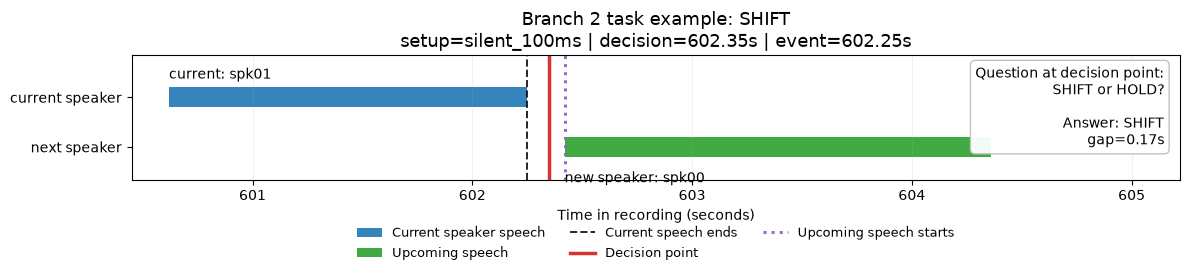

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_clean_task_example_SHIFT_silent_100ms.png


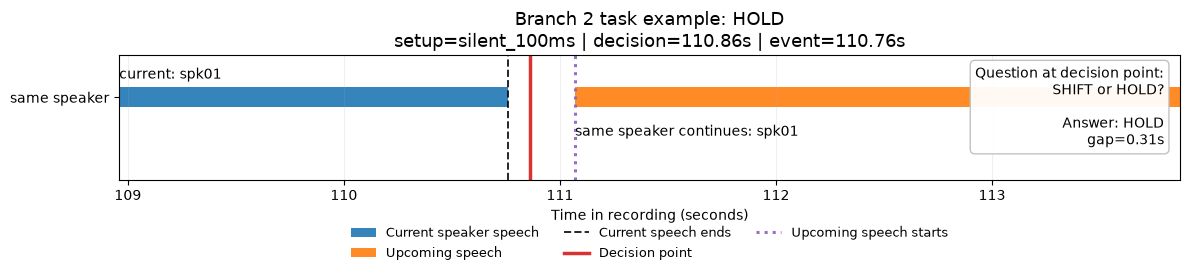

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_clean_task_example_HOLD_silent_100ms.png


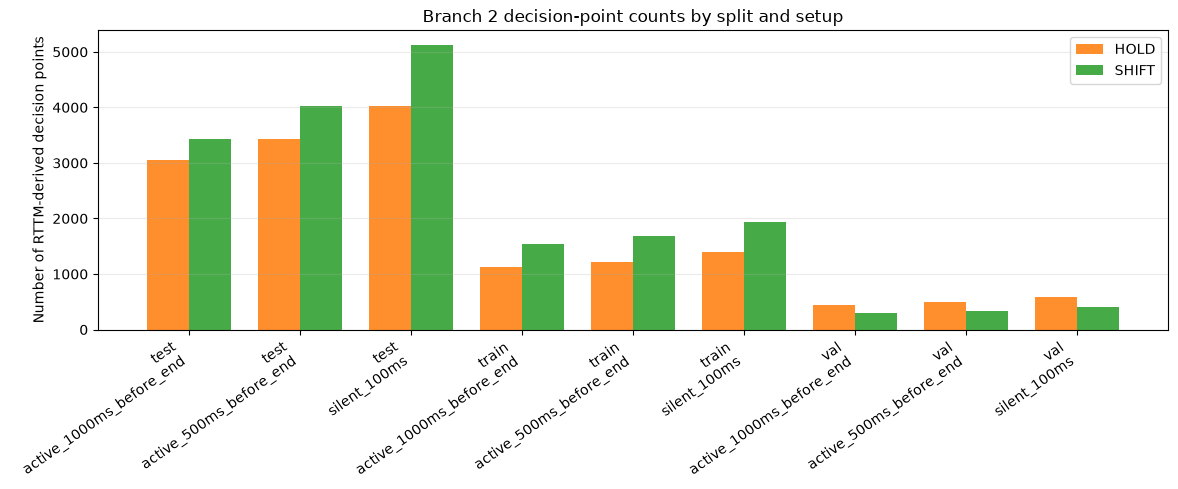

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_decision_point_counts_by_split_setup.png


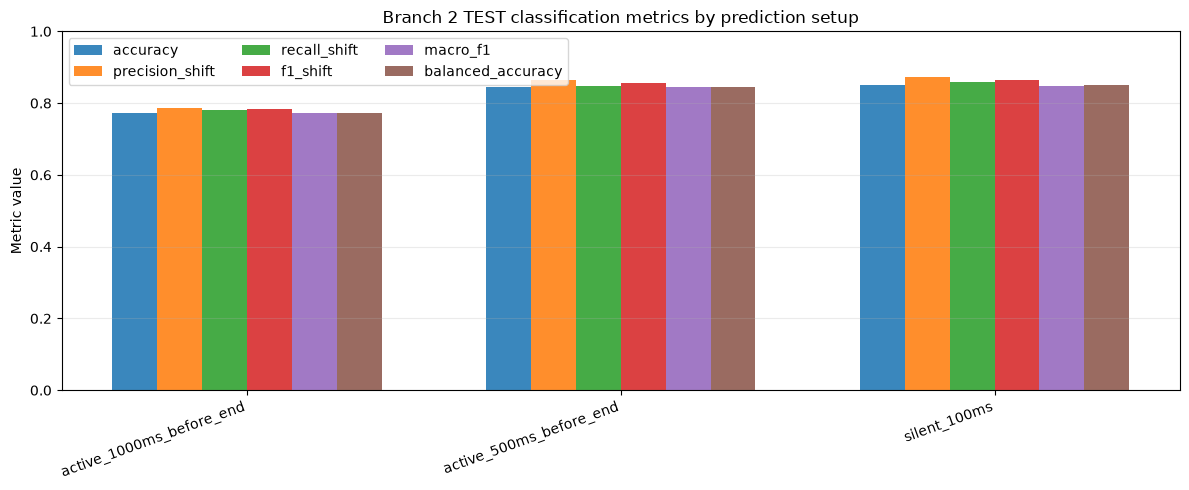

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_test_metrics_by_setup.png


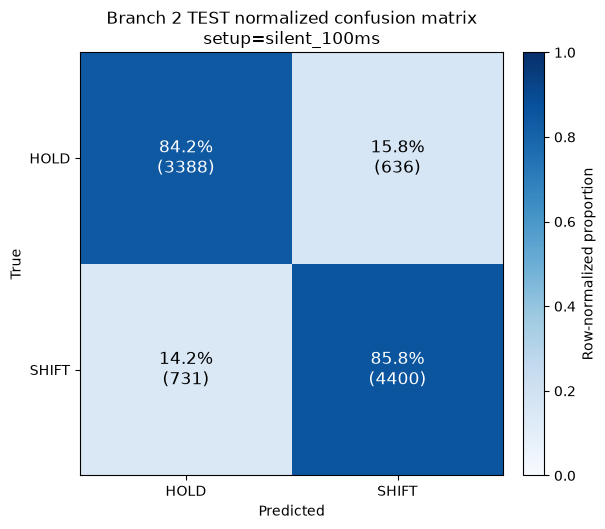

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_normalized_confusion_matrix_silent_100ms.png


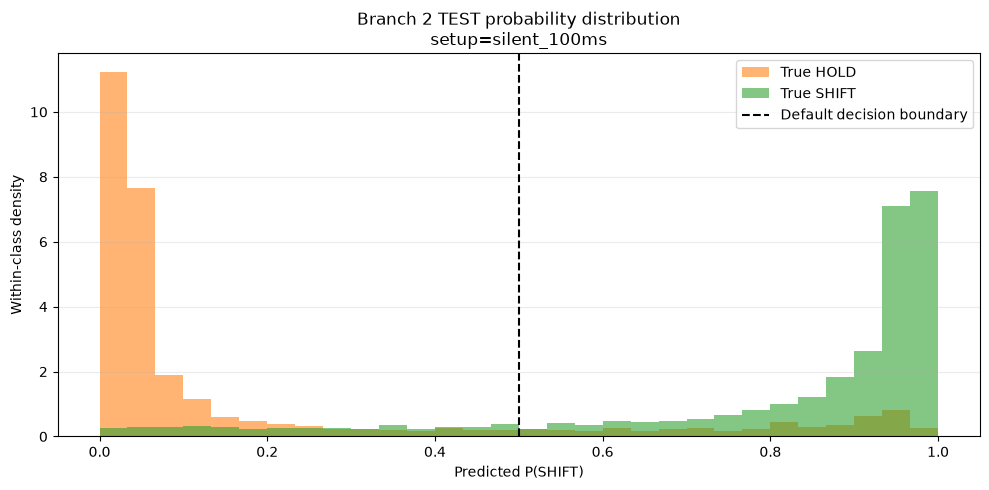

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_prob_shift_distribution_silent_100ms.png


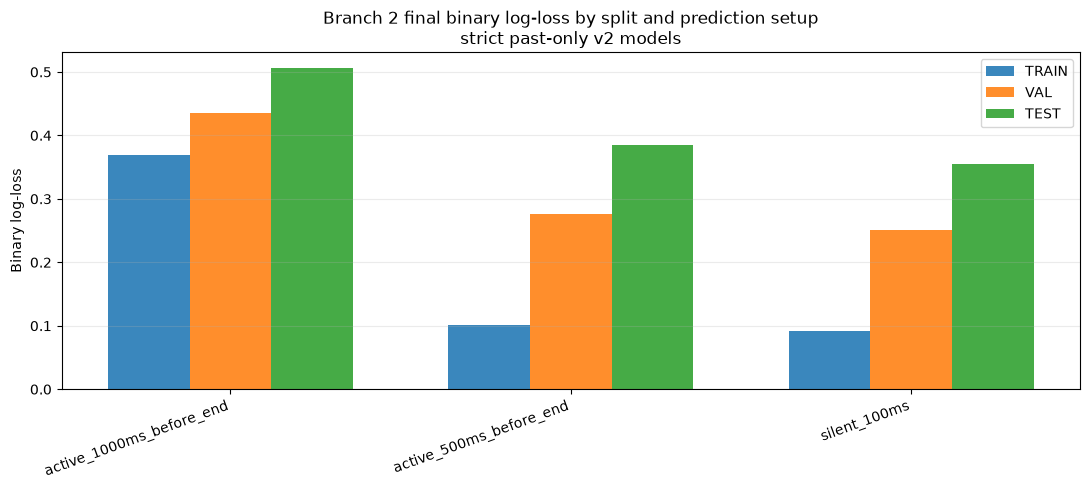

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_final_train_val_test_logloss_by_setup_past_only_v2.png
Saved final train/val/test loss table: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_visualizations_past_only_v2/branch2_final_train_val_test_loss_by_setup_past_only_v2.csv


,split,prediction_setup,n,n_features,model_path,log_loss,accuracy,shift_rate
0,train,active_1000ms_before_end,2675,21,/Documents/Turn_Taking/Tech_paper/R...,0.368625,0.871028,0.575701
1,val,active_1000ms_before_end,755,21,/Documents/Turn_Taking/Tech_paper/R...,0.434705,0.825166,0.402649
2,test,active_1000ms_before_end,6470,21,/Documents/Turn_Taking/Tech_paper/R...,0.505650,0.771870,0.529366
3,train,active_500ms_before_end,2912,21,/Documents/Turn_Taking/Tech_paper/R...,0.100806,0.974931,0.579327
4,val,active_500ms_before_end,834,21,/Documents/Turn_Taking/Tech_paper/R...,0.276784,0.904077,0.406475
5,test,active_500ms_before_end,7448,21,/Documents/Turn_Taking/Tech_paper/R...,0.385613,0.846133,0.540011
6,train,silent_100ms,3329,21,/Documents/Turn_Taking/Tech_paper/R...,0.092320,0.981075,0.579453
7,val,silent_100ms,987,21,/Documents/Turn_Taking/Tech_paper/R...,0.251087,0.903749,0.414387
8,test,silent_100ms,9155,21,/Documents/Turn_Taking/Tech_paper/R...,0.354619,0.850683,0.560459


No boosting-round eval-history JSON files found. The final train/val/test log-loss plot above is still valid.
Branch 2 visualization summary


,prediction_setup,n,shift_rate,accuracy,precision_shift,recall_shift,f1_shift,macro_f1,balanced_accuracy,auroc,auprc
1,active_1000ms_before_end,6470,0.529366,0.771870,0.786197,0.781606,0.783895,0.771162,0.771263,0.831887,0.853612
3,active_500ms_before_end,7448,0.540011,0.846133,0.864789,0.847588,0.856102,0.845391,0.846007,0.912065,0.922141
5,silent_100ms,9155,0.560459,0.850683,0.873709,0.857533,0.865545,0.848836,0.849740,0.924174,0.929981


✅ Cell 19G complete: cleaned past-only v2 Branch 2 visualizations saved.


In [39]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

from sklearn.metrics import log_loss, accuracy_score

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "BRANCH2_DP_ALL" in globals(), "Need BRANCH2_DP_ALL from Cell 5B."
assert "BRANCH2_FEATURES_ALL" in globals(), "Need BRANCH2_FEATURES_ALL from updated Cell 16B."
assert "BRANCH2_METRICS_DF" in globals(), "Need BRANCH2_METRICS_DF from updated Cell 19F."
assert "BRANCH2_TEST_SCORES" in globals(), "Need BRANCH2_TEST_SCORES from updated Cell 19F."

BRANCH2_MAIN_SETUP = str(globals().get("BRANCH2_MAIN_SETUP", "silent_100ms"))

BRANCH2_MODEL_DIR = (
    Path(RUN_ROOT)
    / "branch2_vap_decision_point_classifier_past_only_v2"
)

BRANCH2_FEATURE_COLS_PATH = (
    BRANCH2_MODEL_DIR
    / "branch2_feature_cols.json"
)

if not BRANCH2_MODEL_DIR.exists():
    raise FileNotFoundError(
        "Past-only v2 Branch 2 model directory was not found:\n"
        f"{BRANCH2_MODEL_DIR}\n"
        "Run the updated Cell 19F first."
    )

if not BRANCH2_FEATURE_COLS_PATH.exists():
    raise FileNotFoundError(
        "Past-only v2 Branch 2 feature list was not found:\n"
        f"{BRANCH2_FEATURE_COLS_PATH}\n"
        "Run the updated Cell 19F first."
    )

globals()["BRANCH2_MODEL_DIR"] = BRANCH2_MODEL_DIR
globals()["BRANCH2_FEATURE_COLS_PATH"] = str(BRANCH2_FEATURE_COLS_PATH)

BRANCH2_VIZ_DIR = (
    Path(RUN_ROOT)
    / "branch2_vap_visualizations_past_only_v2"
)
BRANCH2_VIZ_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("CELL 19G: Branch 2 visualizations — cleaned + normalized + loss")
print("=" * 80)
print("Main Branch 2 setup:", BRANCH2_MAIN_SETUP)
print("Active Branch 2 model directory:", BRANCH2_MODEL_DIR)
print("Saving figures to:", BRANCH2_VIZ_DIR)

def _save_and_show(fig, filename):
    path = BRANCH2_VIZ_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Saved:", path)

def _short_spk(x, max_len=12):
    x = str(x)
    return x if len(x) <= max_len else x[:max_len] + "..."

def _fmt_time(x):
    try:
        return f"{float(x):.2f}s"
    except Exception:
        return str(x)

def _fmt_gap(x):
    try:
        return f"{float(x):.2f}s"
    except Exception:
        return "NA"

def _choose_example(label_value, setup=BRANCH2_MAIN_SETUP):
    df = BRANCH2_DP_ALL.copy()

    df = df[
        df["branch2_split"].astype(str).eq("test")
        & df["prediction_setup"].astype(str).eq(setup)
        & pd.to_numeric(df["label"], errors="coerce").fillna(-1).astype(int).eq(int(label_value))
    ].copy()

    if len(df) == 0:
        return None

    required = [
        "prev_end",
        "next_start",
        "prev_dur",
        "next_dur",
        "decision_time",
        "event_time",
    ]

    for c in required:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=required)

    if len(df) == 0:
        return None

    if "gap" in df.columns:
        df["gap_numeric"] = pd.to_numeric(df["gap"], errors="coerce")
        df["gap_target_dist"] = (
            df["gap_numeric"].fillna(0.5) - 0.45
        ).abs()

        df = df.sort_values(
            ["gap_target_dist", "prev_dur", "next_dur"]
        )

    return df.iloc[min(len(df) // 3, len(df) - 1)].to_dict()

def plot_branch2_decision_example(row, filename):
    label = int(row["label"])
    label_name = "SHIFT" if label == 1 else "HOLD"

    current_speaker = str(
        row.get(
            "current_speaker",
            row.get("prev_speaker", "current"),
        )
    )

    next_speaker = str(
        row.get("next_speaker", "next")
    )

    same_speaker = current_speaker == next_speaker

    prev_end = float(row["prev_end"])
    prev_dur = float(row["prev_dur"])
    prev_start = max(0.0, prev_end - prev_dur)

    next_start = float(row["next_start"])
    next_dur = float(row["next_dur"])
    next_end = next_start + max(0.05, next_dur)

    decision_time = float(row["decision_time"])
    event_time = float(row["event_time"])

    left_context = 1.8
    right_context = 2.8

    xmin = max(
        0.0,
        min(
            prev_end,
            decision_time,
            event_time,
            next_start,
        ) - left_context,
    )

    xmax = (
        max(
            prev_end,
            decision_time,
            event_time,
            next_start,
        )
        + right_context
    )

    prev_start_plot = max(prev_start, xmin)
    prev_end_plot = min(prev_end, xmax)
    next_start_plot = max(next_start, xmin)
    next_end_plot = min(next_end, xmax)

    fig, ax = plt.subplots(figsize=(12, 3.2))

    color_current = "tab:blue"
    color_next_shift = "tab:green"
    color_next_hold = "tab:orange"
    color_decision = "tab:red"
    color_event = "tab:purple"

    y_current = 1.0
    y_next = 0.35 if not same_speaker else 1.0

    if prev_end_plot > prev_start_plot:
        ax.broken_barh(
            [
                (
                    prev_start_plot,
                    max(
                        0.03,
                        prev_end_plot - prev_start_plot,
                    ),
                )
            ],
            (y_current - 0.13, 0.26),
            facecolors=color_current,
            alpha=0.90,
            label="Current speaker speech",
        )

    next_color = (
        color_next_shift
        if label_name == "SHIFT"
        else color_next_hold
    )

    if next_end_plot > next_start_plot:
        ax.broken_barh(
            [
                (
                    next_start_plot,
                    max(
                        0.03,
                        next_end_plot - next_start_plot,
                    ),
                )
            ],
            (y_next - 0.13, 0.26),
            facecolors=next_color,
            alpha=0.90,
            label="Upcoming speech",
        )

    ax.axvline(
        prev_end,
        color="black",
        linestyle="--",
        linewidth=1.4,
        alpha=0.85,
        label="Current speech ends",
    )

    ax.axvline(
        decision_time,
        color=color_decision,
        linestyle="-",
        linewidth=2.5,
        alpha=0.95,
        label="Decision point",
    )

    ax.axvline(
        next_start,
        color=color_event,
        linestyle=":",
        linewidth=2.2,
        alpha=0.95,
        label="Upcoming speech starts",
    )

    ax.text(
        prev_start_plot,
        y_current + 0.20,
        f"current: {_short_spk(current_speaker)}",
        ha="left",
        va="bottom",
        fontsize=10,
    )

    next_label = (
        "new speaker"
        if label_name == "SHIFT"
        else "same speaker continues"
    )

    ax.text(
        next_start_plot,
        y_next - 0.32 if not same_speaker else y_next - 0.36,
        f"{next_label}: {_short_spk(next_speaker)}",
        ha="left",
        va="top",
        fontsize=10,
    )

    gap_txt = _fmt_gap(
        row.get("gap", np.nan)
    )

    info_txt = (
        "Question at decision point:\n"
        "SHIFT or HOLD?\n\n"
        f"Answer: {label_name}\n"
        f"gap={gap_txt}"
    )

    ax.text(
        0.985,
        0.92,
        info_txt,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="0.75",
            alpha=0.95,
        ),
    )

    title = (
        f"Branch 2 task example: {label_name}"
    )

    subtitle = (
        f"setup={row.get('prediction_setup')} | "
        f"decision={_fmt_time(decision_time)} | "
        f"event={_fmt_time(event_time)}"
    )

    ax.set_title(
        title + "\n" + subtitle,
        fontsize=13,
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-0.08, 1.55)
    ax.set_xlabel("Time in recording (seconds)")

    if same_speaker:
        ax.set_yticks([y_current])
        ax.set_yticklabels(["same speaker"])
    else:
        ax.set_yticks([y_next, y_current])
        ax.set_yticklabels(
            ["next speaker", "current speaker"]
        )

    ax.grid(
        axis="x",
        alpha=0.18,
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.28),
        ncol=3,
        frameon=False,
        fontsize=9,
    )

    _save_and_show(
        fig,
        filename,
    )

shift_example = _choose_example(
    label_value=1
)

hold_example = _choose_example(
    label_value=0
)

if shift_example is not None:
    plot_branch2_decision_example(
        shift_example,
        (
            "branch2_clean_task_example_SHIFT_"
            f"{BRANCH2_MAIN_SETUP}.png"
        ),
    )
else:
    print(
        "No SHIFT example found for:",
        BRANCH2_MAIN_SETUP,
    )

if hold_example is not None:
    plot_branch2_decision_example(
        hold_example,
        (
            "branch2_clean_task_example_HOLD_"
            f"{BRANCH2_MAIN_SETUP}.png"
        ),
    )
else:
    print(
        "No HOLD example found for:",
        BRANCH2_MAIN_SETUP,
    )

counts_source = BRANCH2_DP_ALL.copy()

counts_source["label"] = (
    pd.to_numeric(
        counts_source["label"],
        errors="coerce",
    )
    .fillna(-1)
    .astype(int)
)

counts_source = counts_source[
    counts_source["label"].isin([0, 1])
].copy()

counts_df = (
    counts_source
    .groupby(
        [
            "branch2_split",
            "prediction_setup",
            "label",
        ],
        dropna=False,
    )
    .size()
    .reset_index(name="n")
)

counts_df["class_name"] = np.where(
    counts_df["label"].eq(1),
    "SHIFT",
    "HOLD",
)

counts_pivot = (
    counts_df
    .pivot_table(
        index=[
            "branch2_split",
            "prediction_setup",
        ],
        columns="class_name",
        values="n",
        fill_value=0,
        aggfunc="sum",
    )
    .reset_index()
)

for c in ["HOLD", "SHIFT"]:
    if c not in counts_pivot.columns:
        counts_pivot[c] = 0

counts_pivot["display_name"] = (
    counts_pivot["branch2_split"].astype(str)
    + "\n"
    + counts_pivot["prediction_setup"].astype(str)
)

fig, ax = plt.subplots(
    figsize=(12, 5)
)

x = np.arange(
    len(counts_pivot)
)

width = 0.38

ax.bar(
    x - width / 2,
    counts_pivot["HOLD"].values,
    width,
    label="HOLD",
    color="tab:orange",
    alpha=0.88,
)

ax.bar(
    x + width / 2,
    counts_pivot["SHIFT"].values,
    width,
    label="SHIFT",
    color="tab:green",
    alpha=0.88,
)

ax.set_title(
    "Branch 2 decision-point counts by split and setup"
)

ax.set_ylabel(
    "Number of RTTM-derived decision points"
)

ax.set_xticks(x)

ax.set_xticklabels(
    counts_pivot["display_name"].tolist(),
    rotation=35,
    ha="right",
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

_save_and_show(
    fig,
    "branch2_decision_point_counts_by_split_setup.png",
)

test_metrics = BRANCH2_METRICS_DF[
    BRANCH2_METRICS_DF["split"]
    .astype(str)
    .eq("test")
].copy()

metric_cols = [
    "accuracy",
    "precision_shift",
    "recall_shift",
    "f1_shift",
    "macro_f1",
    "balanced_accuracy",
]

available_metric_cols = [
    c
    for c in metric_cols
    if c in test_metrics.columns
]

if len(test_metrics) and available_metric_cols:
    metric_plot_df = test_metrics[
        ["prediction_setup"]
        + available_metric_cols
    ].copy()

    metric_plot_df = metric_plot_df.sort_values(
        "prediction_setup"
    )

    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    x = np.arange(
        len(metric_plot_df)
    )

    bar_width = 0.12

    metric_colors = {
        "accuracy": "tab:blue",
        "precision_shift": "tab:orange",
        "recall_shift": "tab:green",
        "f1_shift": "tab:red",
        "macro_f1": "tab:purple",
        "balanced_accuracy": "tab:brown",
    }

    for i, metric_name in enumerate(
        available_metric_cols
    ):
        ax.bar(
            (
                x
                + (
                    i
                    - len(available_metric_cols) / 2
                )
                * bar_width
                + bar_width / 2
            ),
            metric_plot_df[
                metric_name
            ].astype(float).values,
            bar_width,
            label=metric_name,
            color=metric_colors.get(
                metric_name,
                None,
            ),
            alpha=0.88,
        )

    ax.set_title(
        "Branch 2 TEST classification metrics by prediction setup"
    )

    ax.set_ylabel(
        "Metric value"
    )

    ax.set_ylim(
        0.0,
        1.0,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        metric_plot_df[
            "prediction_setup"
        ].tolist(),
        rotation=20,
        ha="right",
    )

    ax.legend(ncol=3)
    ax.grid(axis="y", alpha=0.25)

    _save_and_show(
        fig,
        "branch2_test_metrics_by_setup.png",
    )

else:
    print(
        "No TEST metrics available to plot."
    )

main_scores = BRANCH2_TEST_SCORES[
    BRANCH2_TEST_SCORES[
        "prediction_setup"
    ]
    .astype(str)
    .eq(BRANCH2_MAIN_SETUP)
].copy()

if len(main_scores):
    main_scores["label"] = (
        pd.to_numeric(
            main_scores["label"],
            errors="coerce",
        )
        .fillna(-1)
        .astype(int)
    )

    main_scores["pred_label"] = (
        pd.to_numeric(
            main_scores["pred_label"],
            errors="coerce",
        )
        .fillna(-1)
        .astype(int)
    )

    main_scores = main_scores[
        main_scores["label"].isin([0, 1])
        & main_scores["pred_label"].isin([0, 1])
    ].copy()

    cm = pd.crosstab(
        main_scores["label"],
        main_scores["pred_label"],
        rownames=["True label"],
        colnames=["Predicted label"],
        dropna=False,
    )

    for idx in [0, 1]:
        if idx not in cm.index:
            cm.loc[idx] = 0

        if idx not in cm.columns:
            cm[idx] = 0

    cm = cm.loc[
        [0, 1],
        [0, 1],
    ]

    cm_values = cm.values.astype(int)

    row_sums = cm_values.sum(
        axis=1,
        keepdims=True,
    )

    cm_norm = np.divide(
        cm_values,
        np.maximum(row_sums, 1),
        out=np.zeros_like(
            cm_values,
            dtype=float,
        ),
        where=row_sums > 0,
    )

    fig, ax = plt.subplots(
        figsize=(6.2, 5.4)
    )

    im = ax.imshow(
        cm_norm,
        cmap="Blues",
        vmin=0.0,
        vmax=1.0,
    )

    ax.set_title(
        "Branch 2 TEST normalized confusion matrix\n"
        f"setup={BRANCH2_MAIN_SETUP}"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["HOLD", "SHIFT"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["HOLD", "SHIFT"])

    for i in range(2):
        for j in range(2):
            pct = (
                100.0
                * cm_norm[i, j]
            )

            count = cm_values[i, j]

            text_color = (
                "white"
                if cm_norm[i, j] > 0.55
                else "black"
            )

            ax.text(
                j,
                i,
                f"{pct:.1f}%\n({count})",
                ha="center",
                va="center",
                fontsize=12,
                color=text_color,
            )

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
    )

    cbar.set_label(
        "Row-normalized proportion"
    )

    _save_and_show(
        fig,
        (
            "branch2_normalized_confusion_matrix_"
            f"{BRANCH2_MAIN_SETUP}.png"
        ),
    )

else:
    print(
        "No Branch 2 TEST scores available for main setup:",
        BRANCH2_MAIN_SETUP,
    )

if (
    len(main_scores)
    and "prob_shift" in main_scores.columns
):
    fig, ax = plt.subplots(
        figsize=(10, 5)
    )

    hold_probs = (
        main_scores.loc[
            main_scores["label"].eq(0),
            "prob_shift",
        ]
        .astype(float)
        .values
    )

    shift_probs = (
        main_scores.loc[
            main_scores["label"].eq(1),
            "prob_shift",
        ]
        .astype(float)
        .values
    )

    bins = np.linspace(
        0,
        1,
        31,
    )

    ax.hist(
        hold_probs,
        bins=bins,
        alpha=0.58,
        label="True HOLD",
        color="tab:orange",
        density=True,
    )

    ax.hist(
        shift_probs,
        bins=bins,
        alpha=0.58,
        label="True SHIFT",
        color="tab:green",
        density=True,
    )

    ax.axvline(
        0.5,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Default decision boundary",
    )

    ax.set_title(
        "Branch 2 TEST probability distribution\n"
        f"setup={BRANCH2_MAIN_SETUP}"
    )

    ax.set_xlabel(
        "Predicted P(SHIFT)"
    )

    ax.set_ylabel(
        "Within-class density"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    _save_and_show(
        fig,
        (
            "branch2_prob_shift_distribution_"
            f"{BRANCH2_MAIN_SETUP}.png"
        ),
    )

else:
    print(
        "No probability distribution available for main setup."
    )

def _load_branch2_feature_cols():
    global_cols = globals().get(
        "FEATURE_COLS_BRANCH2",
        None,
    )

    if global_cols is not None:
        cols = list(global_cols)

        if len(cols):
            return cols

    path_value = globals().get(
        "BRANCH2_FEATURE_COLS_PATH",
        (
            BRANCH2_MODEL_DIR
            / "branch2_feature_cols.json"
        ),
    )

    path = Path(path_value)

    if path.exists():
        cols = json.loads(
            path.read_text()
        )

        if isinstance(cols, list) and len(cols):
            return list(cols)

    raise RuntimeError(
        "Could not find the strict past-only Branch 2 feature list. "
        "Run the updated Cell 19F first."
    )

def _prepare_branch2_frame_for_loss(
    df,
    feature_cols,
):
    out = df.copy()

    missing = [
        c
        for c in feature_cols
        if c not in out.columns
    ]

    if missing:
        raise RuntimeError(
            "Branch 2 loss frame is missing trained feature columns:\n"
            f"{missing}"
        )

    for c in feature_cols:
        out[c] = pd.to_numeric(
            out[c],
            errors="coerce",
        )

    out[feature_cols] = (
        out[feature_cols]
        .replace(
            [np.inf, -np.inf],
            np.nan,
        )
        .fillna(0.0)
    )

    out["label"] = (
        pd.to_numeric(
            out["label"],
            errors="coerce",
        )
        .fillna(-1)
        .astype(int)
    )

    out = out[
        out["label"].isin([0, 1])
    ].copy()

    return out.reset_index(
        drop=True
    )

def _booster_feature_names(
    model,
):
    try:
        names = list(
            model.feature_name()
        )
    except Exception:
        names = []

    return [
        str(name)
        for name in names
    ]

def _compute_branch2_final_losses():
    try:
        import lightgbm as lgb

    except Exception as exc:
        print(
            "LightGBM not available, so train/val/test loss cannot be computed:",
            exc,
        )

        return pd.DataFrame()

    expected_feature_cols = _load_branch2_feature_cols()

    setups = sorted(
        BRANCH2_FEATURES_ALL[
            "prediction_setup"
        ]
        .astype(str)
        .unique()
    )

    rows = []

    for setup in setups:
        model_path = (
            BRANCH2_MODEL_DIR
            / (
                "branch2_lgbm_shift_hold_"
                f"{setup}.txt"
            )
        )

        if not model_path.exists():
            print(
                "Missing past-only v2 model file:",
                model_path,
            )

            continue

        model = lgb.Booster(
            model_file=str(model_path)
        )

        model_feature_cols = _booster_feature_names(
            model
        )

        if not model_feature_cols:
            print(
                "Could not read feature names from model:",
                model_path,
            )

            continue

        if model_feature_cols != expected_feature_cols:
            print(
                "Skipping incompatible Branch 2 model:",
                model_path,
            )

            print(
                "  model feature count:",
                len(model_feature_cols),
            )

            print(
                "  expected feature count:",
                len(expected_feature_cols),
            )

            print(
                "  model-only features:",
                sorted(
                    set(model_feature_cols)
                    - set(expected_feature_cols)
                ),
            )

            print(
                "  expected-only features:",
                sorted(
                    set(expected_feature_cols)
                    - set(model_feature_cols)
                ),
            )

            continue

        best_iteration = int(
            getattr(
                model,
                "best_iteration",
                0,
            )
            or 0
        )

        prediction_kwargs = (
            {
                "num_iteration": best_iteration
            }
            if best_iteration > 0
            else {}
        )

        for split_name in [
            "train",
            "val",
            "test",
        ]:
            part = BRANCH2_FEATURES_ALL[
                BRANCH2_FEATURES_ALL[
                    "branch2_split"
                ]
                .astype(str)
                .eq(split_name)
                & BRANCH2_FEATURES_ALL[
                    "prediction_setup"
                ]
                .astype(str)
                .eq(setup)
            ].copy()

            part = _prepare_branch2_frame_for_loss(
                part,
                model_feature_cols,
            )

            if len(part) == 0:
                continue

            y = (
                part["label"]
                .astype(int)
                .to_numpy()
            )

            prediction_input = part[
                model_feature_cols
            ].copy()

            p_shift = np.asarray(
                model.predict(
                    prediction_input,
                    **prediction_kwargs,
                ),
                dtype=float,
            ).reshape(-1)

            p_shift = np.clip(
                p_shift,
                1e-6,
                1.0 - 1e-6,
            )

            pred = (
                p_shift >= 0.5
            ).astype(int)

            rows.append({
                "split": str(split_name),
                "prediction_setup": str(setup),
                "n": int(len(y)),
                "n_features": int(
                    len(model_feature_cols)
                ),
                "model_path": str(model_path),
                "log_loss": float(
                    log_loss(
                        y,
                        p_shift,
                        labels=[0, 1],
                    )
                ),
                "accuracy": float(
                    accuracy_score(
                        y,
                        pred,
                    )
                ),
                "shift_rate": float(
                    np.mean(y)
                ),
            })

    return pd.DataFrame(
        rows
    )

BRANCH2_FINAL_LOSS_DF = (
    _compute_branch2_final_losses()
)

if len(BRANCH2_FINAL_LOSS_DF):
    BRANCH2_FINAL_LOSS_CSV = (
        BRANCH2_VIZ_DIR
        / (
            "branch2_final_train_val_test_"
            "loss_by_setup_past_only_v2.csv"
        )
    )

    BRANCH2_FINAL_LOSS_DF.to_csv(
        BRANCH2_FINAL_LOSS_CSV,
        index=False,
    )

    loss_plot_df = (
        BRANCH2_FINAL_LOSS_DF.copy()
    )

    split_order = [
        "train",
        "val",
        "test",
    ]

    split_colors = {
        "train": "tab:blue",
        "val": "tab:orange",
        "test": "tab:green",
    }

    setups = sorted(
        loss_plot_df[
            "prediction_setup"
        ].unique()
    )

    x = np.arange(
        len(setups)
    )

    width = 0.24

    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    for i, split_name in enumerate(
        split_order
    ):
        vals = []

        for setup in setups:
            row = loss_plot_df[
                loss_plot_df[
                    "split"
                ].eq(split_name)
                & loss_plot_df[
                    "prediction_setup"
                ].eq(setup)
            ]

            vals.append(
                float(
                    row["log_loss"].iloc[0]
                )
                if len(row)
                else np.nan
            )

        ax.bar(
            x + (i - 1) * width,
            vals,
            width,
            label=split_name.upper(),
            color=split_colors.get(
                split_name,
                None,
            ),
            alpha=0.88,
        )

    ax.set_title(
        "Branch 2 final binary log-loss by split and prediction setup\n"
        "strict past-only v2 models"
    )

    ax.set_ylabel(
        "Binary log-loss"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        setups,
        rotation=20,
        ha="right",
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    _save_and_show(
        fig,
        (
            "branch2_final_train_val_test_"
            "logloss_by_setup_past_only_v2.png"
        ),
    )

    globals()[
        "BRANCH2_FINAL_LOSS_DF"
    ] = BRANCH2_FINAL_LOSS_DF

    globals()[
        "BRANCH2_FINAL_LOSS_CSV"
    ] = str(
        BRANCH2_FINAL_LOSS_CSV
    )

    print(
        "Saved final train/val/test loss table:",
        BRANCH2_FINAL_LOSS_CSV,
    )

    display(
        BRANCH2_FINAL_LOSS_DF
    )

else:
    print(
        "No compatible past-only v2 Branch 2 loss dataframe was created."
    )

eval_history_files = sorted(
    BRANCH2_MODEL_DIR.glob(
        "branch2_lgbm_shift_hold_*.evals_result.json"
    )
)

if eval_history_files:
    for hist_path in eval_history_files:
        setup_name = (
            hist_path.name
            .replace(
                "branch2_lgbm_shift_hold_",
                "",
            )
            .replace(
                ".evals_result.json",
                "",
            )
        )

        try:
            hist = json.loads(
                hist_path.read_text()
            )

        except Exception:
            continue

        fig, ax = plt.subplots(
            figsize=(9, 4.5)
        )

        plotted = False

        for split_name, color in [
            ("train", "tab:blue"),
            ("val", "tab:orange"),
        ]:
            if split_name not in hist:
                continue

            metric_values = None
            selected_metric_name = None

            for metric_name in [
                "binary_logloss",
                "logloss",
                "binary_error",
            ]:
                if metric_name in hist[split_name]:
                    metric_values = hist[
                        split_name
                    ][metric_name]

                    selected_metric_name = metric_name
                    break

            if metric_values is not None:
                ax.plot(
                    np.arange(
                        1,
                        len(metric_values) + 1,
                    ),
                    metric_values,
                    label=(
                        f"{split_name} "
                        f"{selected_metric_name}"
                    ),
                    color=color,
                )

                plotted = True

        if plotted:
            ax.set_title(
                "Branch 2 LightGBM training curve\n"
                f"setup={setup_name}"
            )

            ax.set_xlabel(
                "Boosting round"
            )

            ax.set_ylabel(
                "Loss"
            )

            ax.legend()
            ax.grid(alpha=0.25)

            _save_and_show(
                fig,
                (
                    "branch2_training_curve_"
                    f"{setup_name}.png"
                ),
            )

        else:
            plt.close(fig)

else:
    print(
        "No boosting-round eval-history JSON files found. "
        "The final train/val/test log-loss plot above is still valid."
    )

print("=" * 80)
print("Branch 2 visualization summary")
print("=" * 80)

summary_cols = [
    "prediction_setup",
    "n",
    "shift_rate",
    "accuracy",
    "precision_shift",
    "recall_shift",
    "f1_shift",
    "macro_f1",
    "balanced_accuracy",
    "auroc",
    "auprc",
]

summary_cols = [
    c
    for c in summary_cols
    if c in test_metrics.columns
]

if len(test_metrics) and summary_cols:
    display(
        test_metrics[
            summary_cols
        ]
    )

print(
    "✅ Cell 19G complete: cleaned past-only v2 Branch 2 visualizations saved."
)

In [40]:
import json
import time
import math
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "BRANCH3_TABLE_ALL" in globals(), "Need BRANCH3_TABLE_ALL from Cell 16C."
assert "BRANCH3_FEATURE_COLS" in globals(), "Need BRANCH3_FEATURE_COLS from Cell 16C."
assert "BRANCH3_CURRENT_BIN_COLS" in globals(), "Need BRANCH3_CURRENT_BIN_COLS from Cell 5C."
assert "BRANCH3_OTHER_BIN_COLS" in globals(), "Need BRANCH3_OTHER_BIN_COLS from Cell 5C."
assert "SEED" in globals(), "Need SEED."

BRANCH3_MODEL_DIR = RUN_ROOT / "branch3_future_activity_projection_past_only_v2"
BRANCH3_MODEL_DIR.mkdir(parents=True, exist_ok=True)

BRANCH3_MAIN_SETUP = str(
    globals().get(
        "BRANCH3_MAIN_SETUP",
        globals().get("BRANCH2_MAIN_SETUP", "silent_100ms"),
    )
)

_branch3_setups_raw = globals().get("BRANCH3_SETUPS_TO_RUN", [BRANCH3_MAIN_SETUP])

if isinstance(_branch3_setups_raw, str):
    BRANCH3_SETUPS_TO_RUN = [_branch3_setups_raw]
else:
    BRANCH3_SETUPS_TO_RUN = [str(x) for x in list(_branch3_setups_raw)]

BRANCH3_SETUPS_TO_RUN = list(dict.fromkeys(BRANCH3_SETUPS_TO_RUN))

if BRANCH3_MAIN_SETUP not in BRANCH3_SETUPS_TO_RUN:
    BRANCH3_SETUPS_TO_RUN.insert(0, BRANCH3_MAIN_SETUP)

FORCE_RETRAIN_BRANCH3_LGBM = bool(globals().get("FORCE_RETRAIN_BRANCH3_LGBM", False))

BRANCH3_LGBM_NUM_BOOST_ROUND = int(globals().get("BRANCH3_LGBM_NUM_BOOST_ROUND", 500))
BRANCH3_LGBM_EARLY_STOPPING_ROUNDS = int(globals().get("BRANCH3_LGBM_EARLY_STOPPING_ROUNDS", 50))
BRANCH3_LGBM_LEARNING_RATE = float(globals().get("BRANCH3_LGBM_LEARNING_RATE", 0.035))
BRANCH3_LGBM_NUM_LEAVES = int(globals().get("BRANCH3_LGBM_NUM_LEAVES", 31))
BRANCH3_LGBM_MIN_DATA_IN_LEAF = int(globals().get("BRANCH3_LGBM_MIN_DATA_IN_LEAF", 20))
BRANCH3_LGBM_FEATURE_FRACTION = float(globals().get("BRANCH3_LGBM_FEATURE_FRACTION", 0.85))
BRANCH3_LGBM_BAGGING_FRACTION = float(globals().get("BRANCH3_LGBM_BAGGING_FRACTION", 0.85))
BRANCH3_LGBM_BAGGING_FREQ = int(globals().get("BRANCH3_LGBM_BAGGING_FREQ", 1))
BRANCH3_LGBM_LAMBDA_L2 = float(globals().get("BRANCH3_LGBM_LAMBDA_L2", 2.0))

BRANCH3_METRICS_CSV = BRANCH3_MODEL_DIR / "branch3_future_activity_metrics.csv"
BRANCH3_METRICS_JSON = BRANCH3_MODEL_DIR / "branch3_future_activity_metrics.json"
BRANCH3_TEST_PRED_CSV = BRANCH3_MODEL_DIR / "branch3_future_activity_test_predictions.csv"
BRANCH3_VAL_PRED_CSV = BRANCH3_MODEL_DIR / "branch3_future_activity_val_predictions.csv"
BRANCH3_IMPORTANCE_CSV = BRANCH3_MODEL_DIR / "branch3_future_activity_feature_importance.csv"

def _branch3_model_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _branch3_model_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_branch3_model_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if math.isfinite(x) else None
    return x

def _branch3_lgbm_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": ["binary_logloss", "auc"],
        "learning_rate": float(BRANCH3_LGBM_LEARNING_RATE),
        "num_leaves": int(BRANCH3_LGBM_NUM_LEAVES),
        "min_data_in_leaf": int(BRANCH3_LGBM_MIN_DATA_IN_LEAF),
        "feature_fraction": float(BRANCH3_LGBM_FEATURE_FRACTION),
        "bagging_fraction": float(BRANCH3_LGBM_BAGGING_FRACTION),
        "bagging_freq": int(BRANCH3_LGBM_BAGGING_FREQ),
        "lambda_l2": float(BRANCH3_LGBM_LAMBDA_L2),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _prepare_branch3_split(df: pd.DataFrame, setup: str, split_name: str) -> pd.DataFrame:
    out = df[
        df["prediction_setup"].astype(str).eq(str(setup))
        & df["branch2_split"].astype(str).eq(str(split_name))
    ].copy()

    for c in BRANCH3_FEATURE_COLS:
        if c not in out.columns:
            out[c] = 0.0
        out[c] = pd.to_numeric(out[c], errors="coerce")

    out[BRANCH3_FEATURE_COLS] = out[BRANCH3_FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0)

    target_cols = list(BRANCH3_CURRENT_BIN_COLS) + list(BRANCH3_OTHER_BIN_COLS)
    missing_targets = [c for c in target_cols if c not in out.columns]

    if missing_targets:
        raise KeyError(
            f"Branch 3 split {split_name!r}, setup {setup!r} is missing target columns: "
            f"{missing_targets}"
        )

    for c in target_cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")

    invalid_target_mask = out[target_cols].isna().any(axis=1)

    if invalid_target_mask.any():
        raise ValueError(
            f"Branch 3 split {split_name!r}, setup {setup!r} contains "
            f"{int(invalid_target_mask.sum())} rows with missing/non-numeric future-activity labels."
        )

    out[target_cols] = out[target_cols].astype(int)

    invalid_values = sorted(
        set(np.unique(out[target_cols].to_numpy(dtype=int)).tolist()) - {0, 1}
    )

    if invalid_values:
        raise ValueError(
            f"Branch 3 split {split_name!r}, setup {setup!r} contains non-binary "
            f"future-activity labels: {invalid_values}"
        )

    return out.reset_index(drop=True)

def _safe_binary_metrics(y_true, p_prob, prefix: str, setup: str, split_name: str, target_name: str) -> Dict[str, Any]:
    y_true = np.asarray(y_true, dtype=int)
    p_prob = np.asarray(p_prob, dtype=float).reshape(-1)
    p_prob = np.clip(p_prob, 1e-6, 1.0 - 1e-6)
    y_pred = (p_prob >= 0.5).astype(int)

    out = {
        "branch": "Branch 3: future activity projection",
        "setup": str(setup),
        "split": str(split_name),
        "target_group": str(prefix),
        "target_name": str(target_name),
        "n": int(len(y_true)),
        "positive_rate": float(np.mean(y_true)) if len(y_true) else 0.0,
        "log_loss": float(log_loss(y_true, p_prob, labels=[0, 1])) if len(y_true) else np.nan,
        "accuracy": float(accuracy_score(y_true, y_pred)) if len(y_true) else np.nan,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)) if len(y_true) else np.nan,
    }

    try:
        out["auroc"] = float(roc_auc_score(y_true, p_prob)) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        out["auroc"] = np.nan

    try:
        out["auprc"] = float(average_precision_score(y_true, p_prob)) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        out["auprc"] = np.nan

    return out

def _micro_metrics_for_group(df_pred: pd.DataFrame, true_cols: List[str], prob_cols: List[str], setup: str, split_name: str, group_name: str) -> Dict[str, Any]:
    y_true = df_pred[true_cols].to_numpy(dtype=int).reshape(-1)
    p_prob = df_pred[prob_cols].to_numpy(dtype=float).reshape(-1)
    p_prob = np.clip(p_prob, 1e-6, 1.0 - 1e-6)
    y_pred = (p_prob >= 0.5).astype(int)

    out = {
        "branch": "Branch 3: future activity projection",
        "setup": str(setup),
        "split": str(split_name),
        "target_group": str(group_name),
        "target_name": "micro_all_bins",
        "n": int(len(y_true)),
        "positive_rate": float(np.mean(y_true)) if len(y_true) else 0.0,
        "log_loss": float(log_loss(y_true, p_prob, labels=[0, 1])) if len(y_true) else np.nan,
        "accuracy": float(accuracy_score(y_true, y_pred)) if len(y_true) else np.nan,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)) if len(y_true) else np.nan,
    }

    try:
        out["auroc"] = float(roc_auc_score(y_true, p_prob)) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        out["auroc"] = np.nan

    try:
        out["auprc"] = float(average_precision_score(y_true, p_prob)) if len(np.unique(y_true)) > 1 else np.nan
    except Exception:
        out["auprc"] = np.nan

    return out

def _predict_constant(n: int, value: float) -> np.ndarray:
    return np.full(shape=(int(n),), fill_value=float(np.clip(value, 1e-6, 1.0 - 1e-6)), dtype=float)

def train_one_branch3_target(setup: str, target_col: str, train_df: pd.DataFrame, val_df: pd.DataFrame):
    import lightgbm as lgb

    model_path = BRANCH3_MODEL_DIR / f"branch3_lgbm_{setup}_{target_col}.txt"
    meta_path = BRANCH3_MODEL_DIR / f"branch3_lgbm_{setup}_{target_col}.meta.json"

    y_train = train_df[target_col].astype(int).to_numpy()
    y_val = val_df[target_col].astype(int).to_numpy()

    train_mean = float(np.mean(y_train)) if len(y_train) else 0.0

    if len(np.unique(y_train)) < 2:
        meta = {
            "type": "constant",
            "setup": setup,
            "target_col": target_col,
            "constant_prob": train_mean,
            "reason": "train target has one class only",
            "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
        }
        meta_path.write_text(json.dumps(_branch3_model_json_safe(meta), indent=2, sort_keys=True))
        return meta

    if model_path.exists() and meta_path.exists() and not FORCE_RETRAIN_BRANCH3_LGBM:
        try:
            meta = json.loads(meta_path.read_text())
            if meta.get("type") == "lightgbm" and meta.get("feature_cols") == list(BRANCH3_FEATURE_COLS):
                model = lgb.Booster(model_file=str(model_path))
                return {
                    "type": "lightgbm",
                    "model": model,
                    "model_path": str(model_path),
                    "meta_path": str(meta_path),
                    "best_iteration": int(meta.get("best_iteration", 0)),
                }
        except Exception:
            pass

    params = _branch3_lgbm_params()

    dtrain = lgb.Dataset(
        train_df[BRANCH3_FEATURE_COLS],
        label=y_train,
        feature_name=list(BRANCH3_FEATURE_COLS),
        free_raw_data=False,
    )

    dval = lgb.Dataset(
        val_df[BRANCH3_FEATURE_COLS],
        label=y_val,
        reference=dtrain,
        feature_name=list(BRANCH3_FEATURE_COLS),
        free_raw_data=False,
    )

    evals_result = {}

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=int(BRANCH3_LGBM_NUM_BOOST_ROUND),
        valid_sets=[dtrain, dval],
        valid_names=["train", "val"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(BRANCH3_LGBM_EARLY_STOPPING_ROUNDS),
                first_metric_only=False,
                verbose=False,
            ),
            lgb.log_evaluation(period=0),
            lgb.record_evaluation(evals_result),
        ],
    )

    best_iter = int(getattr(model, "best_iteration", 0) or 0)

    if best_iter > 0:
        model.save_model(str(model_path), num_iteration=best_iter)
    else:
        model.save_model(str(model_path))

    meta = {
        "type": "lightgbm",
        "setup": setup,
        "target_col": target_col,
        "feature_cols": list(BRANCH3_FEATURE_COLS),
        "n_features": int(len(BRANCH3_FEATURE_COLS)),
        "params": params,
        "best_iteration": int(best_iter),
        "best_score": _branch3_model_json_safe(getattr(model, "best_score", {})),
        "trained_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

    meta_path.write_text(json.dumps(_branch3_model_json_safe(meta), indent=2, sort_keys=True))

    eval_hist_path = BRANCH3_MODEL_DIR / f"branch3_lgbm_{setup}_{target_col}.evals_result.json"
    eval_hist_path.write_text(json.dumps(_branch3_model_json_safe(evals_result), indent=2, sort_keys=True))

    return {
        "type": "lightgbm",
        "model": model,
        "model_path": str(model_path),
        "meta_path": str(meta_path),
        "best_iteration": int(best_iter),
    }

def predict_branch3_target(model_obj, df: pd.DataFrame) -> np.ndarray:
    if model_obj["type"] == "constant":
        return _predict_constant(len(df), float(model_obj.get("constant_prob", 0.0)))

    model = model_obj["model"]
    best_iter = int(model_obj.get("best_iteration", 0) or 0)
    kwargs = {"num_iteration": best_iter} if best_iter > 0 else {}

    return np.asarray(model.predict(df[BRANCH3_FEATURE_COLS], **kwargs), dtype=float).reshape(-1)

def train_eval_branch3_for_setup(setup: str):
    setup = str(setup)

    train_df = _prepare_branch3_split(BRANCH3_TABLE_ALL, setup, "train")
    val_df = _prepare_branch3_split(BRANCH3_TABLE_ALL, setup, "val")
    test_df = _prepare_branch3_split(BRANCH3_TABLE_ALL, setup, "test")

    if len(train_df) == 0 or len(val_df) == 0 or len(test_df) == 0:
        print(f"Skipping Branch 3 setup {setup}: missing train/val/test rows.")
        return None

    all_targets = list(BRANCH3_CURRENT_BIN_COLS) + list(BRANCH3_OTHER_BIN_COLS)

    pred_frames = {}
    metrics_rows = []
    importance_rows = []

    for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        base_cols = [
            "session",
            "branch2_split",
            "prediction_setup",
            "decision_time",
            "current_speaker",
            "next_speaker",
            "action",
            "label",
        ]

        base_cols = [c for c in base_cols if c in split_df.columns]
        pred_frames[split_name] = split_df[base_cols].copy().reset_index(drop=True)

        for target_col in all_targets:
            pred_frames[split_name][f"true_{target_col}"] = split_df[target_col].astype(int).to_numpy()

    for target_col in all_targets:
        group_name = "current" if target_col.startswith("current_") else "other"

        model_obj = train_one_branch3_target(
            setup=setup,
            target_col=target_col,
            train_df=train_df,
            val_df=val_df,
        )

        for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
            p = predict_branch3_target(model_obj, split_df)
            pred_frames[split_name][f"prob_{target_col}"] = p

            metrics_rows.append(
                _safe_binary_metrics(
                    y_true=split_df[target_col].astype(int).to_numpy(),
                    p_prob=p,
                    prefix=group_name,
                    setup=setup,
                    split_name=split_name,
                    target_name=target_col,
                )
            )

        if model_obj["type"] == "lightgbm":
            model = model_obj["model"]
            try:
                imp_gain = model.feature_importance(importance_type="gain")
                imp_split = model.feature_importance(importance_type="split")

                for feat, gain, split_count in zip(BRANCH3_FEATURE_COLS, imp_gain, imp_split):
                    importance_rows.append({
                        "setup": setup,
                        "target_col": target_col,
                        "target_group": group_name,
                        "feature": feat,
                        "importance_gain": float(gain),
                        "importance_split": float(split_count),
                    })
            except Exception:
                pass

    for split_name in ["train", "val", "test"]:
        pred_df = pred_frames[split_name]

        current_true_cols = [f"true_{c}" for c in BRANCH3_CURRENT_BIN_COLS]
        current_prob_cols = [f"prob_{c}" for c in BRANCH3_CURRENT_BIN_COLS]
        other_true_cols = [f"true_{c}" for c in BRANCH3_OTHER_BIN_COLS]
        other_prob_cols = [f"prob_{c}" for c in BRANCH3_OTHER_BIN_COLS]

        metrics_rows.append(
            _micro_metrics_for_group(
                pred_df,
                current_true_cols,
                current_prob_cols,
                setup=setup,
                split_name=split_name,
                group_name="current_micro",
            )
        )

        metrics_rows.append(
            _micro_metrics_for_group(
                pred_df,
                other_true_cols,
                other_prob_cols,
                setup=setup,
                split_name=split_name,
                group_name="other_micro",
            )
        )

        all_true_cols = current_true_cols + other_true_cols
        all_prob_cols = current_prob_cols + other_prob_cols

        metrics_rows.append(
            _micro_metrics_for_group(
                pred_df,
                all_true_cols,
                all_prob_cols,
                setup=setup,
                split_name=split_name,
                group_name="all_micro",
            )
        )

    return {
        "setup": setup,
        "train_predictions": pred_frames["train"],
        "val_predictions": pred_frames["val"],
        "test_predictions": pred_frames["test"],
        "metrics": pd.DataFrame(metrics_rows),
        "importance": pd.DataFrame(importance_rows),
    }

print("=" * 80)
print("CELL 19H: Branch 3 future activity projection")
print("=" * 80)
print("Setups to run:", BRANCH3_SETUPS_TO_RUN)
print("Number of features:", len(BRANCH3_FEATURE_COLS))
print("Feature protocol: strict past-only explicit whitelist (v2).")
print("Current-speaker targets:", BRANCH3_CURRENT_BIN_COLS)
print("Other-speaker targets:", BRANCH3_OTHER_BIN_COLS)

try:
    import lightgbm as lgb
except Exception as e:
    raise ImportError("LightGBM is required for Branch 3. Install with: pip install -U lightgbm") from e

branch3_results = []

for setup in BRANCH3_SETUPS_TO_RUN:
    res = train_eval_branch3_for_setup(setup)
    if res is not None:
        branch3_results.append(res)

assert len(branch3_results) > 0, "No Branch 3 setup was trained/evaluated."

BRANCH3_METRICS_DF = pd.concat([r["metrics"] for r in branch3_results], ignore_index=True)
BRANCH3_VAL_PRED_DF = pd.concat([r["val_predictions"] for r in branch3_results], ignore_index=True)
BRANCH3_TEST_PRED_DF = pd.concat([r["test_predictions"] for r in branch3_results], ignore_index=True)

importance_parts = [r["importance"] for r in branch3_results if r["importance"] is not None and len(r["importance"])]
BRANCH3_IMPORTANCE_DF = pd.concat(importance_parts, ignore_index=True) if importance_parts else pd.DataFrame()

BRANCH3_METRICS_DF.to_csv(BRANCH3_METRICS_CSV, index=False)
BRANCH3_VAL_PRED_DF.to_csv(BRANCH3_VAL_PRED_CSV, index=False)
BRANCH3_TEST_PRED_DF.to_csv(BRANCH3_TEST_PRED_CSV, index=False)

if len(BRANCH3_IMPORTANCE_DF):
    BRANCH3_IMPORTANCE_DF.to_csv(BRANCH3_IMPORTANCE_CSV, index=False)

BRANCH3_MAIN_TEST_METRICS = BRANCH3_METRICS_DF[
    BRANCH3_METRICS_DF["setup"].astype(str).eq(BRANCH3_MAIN_SETUP)
    & BRANCH3_METRICS_DF["split"].astype(str).eq("test")
    & BRANCH3_METRICS_DF["target_name"].astype(str).eq("micro_all_bins")
].copy()

assert len(BRANCH3_MAIN_TEST_METRICS), (
    "No Branch 3 TEST micro rows were found for the main setup: "
    f"{BRANCH3_MAIN_SETUP!r}"
)

def _branch3_required_micro_row(group_name: str) -> Dict[str, Any]:
    rows = BRANCH3_MAIN_TEST_METRICS[
        BRANCH3_MAIN_TEST_METRICS["target_group"].astype(str).eq(str(group_name))
    ].copy()

    if len(rows) != 1:
        raise RuntimeError(
            f"Expected exactly one Branch 3 TEST micro row for {group_name!r}, "
            f"but found {len(rows)}."
        )

    return rows.iloc[0].to_dict()

BRANCH3_FINAL_TEST_CURRENT_MICRO = _branch3_required_micro_row("current_micro")
BRANCH3_FINAL_TEST_OTHER_MICRO = _branch3_required_micro_row("other_micro")
BRANCH3_FINAL_TEST_ALL_MICRO = _branch3_required_micro_row("all_micro")

BRANCH3_FINAL_TEST_METRICS = BRANCH3_FINAL_TEST_ALL_MICRO.copy()

json_payload = {
    "variant": "branch3_future_activity_projection_lgbm_past_only_v2",
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "branch": "Branch 3: VAP/RR-FAP-style future activity projection",
    "task": "predict current-speaker and other-speaker future activity bins",
    "horizon_s": float(globals().get("BRANCH3_HORIZON_S", 2.0)),
    "bin_s": float(globals().get("BRANCH3_BIN_S", 0.2)),
    "n_bins": int(globals().get("BRANCH3_N_BINS", len(BRANCH3_CURRENT_BIN_COLS))),
    "setups_run": list(BRANCH3_SETUPS_TO_RUN),
    "main_setup": str(BRANCH3_MAIN_SETUP),
    "primary_summary": "all_micro",
    "classifier": "one LightGBM binary classifier per future activity bin",
    "feature_mode": "strict_past_only_explicit_whitelist",
    "feature_cols": list(BRANCH3_FEATURE_COLS),
    "current_targets": list(BRANCH3_CURRENT_BIN_COLS),
    "other_targets": list(BRANCH3_OTHER_BIN_COLS),
    "main_test_metrics": BRANCH3_FINAL_TEST_METRICS,
    "main_test_current_micro": BRANCH3_FINAL_TEST_CURRENT_MICRO,
    "main_test_other_micro": BRANCH3_FINAL_TEST_OTHER_MICRO,
    "main_test_all_micro": BRANCH3_FINAL_TEST_ALL_MICRO,
    "files": {
        "metrics_csv": str(BRANCH3_METRICS_CSV),
        "metrics_json": str(BRANCH3_METRICS_JSON),
        "val_predictions_csv": str(BRANCH3_VAL_PRED_CSV),
        "test_predictions_csv": str(BRANCH3_TEST_PRED_CSV),
        "importance_csv": str(BRANCH3_IMPORTANCE_CSV),
    },
}

BRANCH3_METRICS_JSON.write_text(
    json.dumps(
        _branch3_model_json_safe(json_payload),
        indent=2,
        sort_keys=True,
    )
)

globals()["BRANCH3_MAIN_SETUP"] = BRANCH3_MAIN_SETUP
globals()["BRANCH3_SETUPS_TO_RUN"] = BRANCH3_SETUPS_TO_RUN
globals()["BRANCH3_METRICS_DF"] = BRANCH3_METRICS_DF
globals()["BRANCH3_VAL_PRED_DF"] = BRANCH3_VAL_PRED_DF
globals()["BRANCH3_TEST_PRED_DF"] = BRANCH3_TEST_PRED_DF
globals()["BRANCH3_IMPORTANCE_DF"] = BRANCH3_IMPORTANCE_DF
globals()["BRANCH3_MAIN_TEST_METRICS"] = BRANCH3_MAIN_TEST_METRICS
globals()["BRANCH3_FINAL_TEST_CURRENT_MICRO"] = BRANCH3_FINAL_TEST_CURRENT_MICRO
globals()["BRANCH3_FINAL_TEST_OTHER_MICRO"] = BRANCH3_FINAL_TEST_OTHER_MICRO
globals()["BRANCH3_FINAL_TEST_ALL_MICRO"] = BRANCH3_FINAL_TEST_ALL_MICRO
globals()["BRANCH3_FINAL_TEST_METRICS"] = BRANCH3_FINAL_TEST_METRICS
globals()["BRANCH3_METRICS_CSV"] = str(BRANCH3_METRICS_CSV)
globals()["BRANCH3_METRICS_JSON"] = str(BRANCH3_METRICS_JSON)
globals()["BRANCH3_TEST_PRED_CSV"] = str(BRANCH3_TEST_PRED_CSV)

print("=" * 80)
print("Branch 3 future activity results")
print("=" * 80)

display_cols = [
    "setup",
    "split",
    "target_group",
    "target_name",
    "n",
    "positive_rate",
    "log_loss",
    "accuracy",
    "f1",
    "auroc",
    "auprc",
]

branch3_micro_display = BRANCH3_METRICS_DF[
    BRANCH3_METRICS_DF["target_name"].astype(str).eq("micro_all_bins")
][display_cols].copy()

display(branch3_micro_display)

print("Main Branch 3 TEST setup:", BRANCH3_MAIN_SETUP)
print("Primary Branch 3 TEST summary: all_micro")
print("BRANCH3_FINAL_TEST_METRICS:")
for k, v in BRANCH3_FINAL_TEST_METRICS.items():
    if k in ["positive_rate", "log_loss", "accuracy", "f1", "auroc", "auprc"]:
        print(
            f"  {k}: {v:.4f}"
            if isinstance(v, (int, float, np.integer, np.floating)) and np.isfinite(v)
            else f"  {k}: {v}"
        )

print("Saved metrics:", BRANCH3_METRICS_CSV)
print("Saved TEST predictions:", BRANCH3_TEST_PRED_CSV)
print("Saved JSON:", BRANCH3_METRICS_JSON)
print("✅ Cell 19H complete: Branch 3 future activity projection trained/evaluated.")

CELL 19H: Branch 3 future activity projection
Setups to run: ['silent_100ms']
Number of features: 21
Feature protocol: strict past-only explicit whitelist (v2).
Current-speaker targets: ['current_fap_b00', 'current_fap_b01', 'current_fap_b02', 'current_fap_b03', 'current_fap_b04', 'current_fap_b05', 'current_fap_b06', 'current_fap_b07', 'current_fap_b08', 'current_fap_b09']
Other-speaker targets: ['other_fap_b00', 'other_fap_b01', 'other_fap_b02', 'other_fap_b03', 'other_fap_b04', 'other_fap_b05', 'other_fap_b06', 'other_fap_b07', 'other_fap_b08', 'other_fap_b09']
Branch 3 future activity results


,setup,split,target_group,target_name,n,positive_rate,log_loss,accuracy,f1,auroc,auprc
60,silent_100ms,train,current_micro,micro_all_bins,33290,0.360769,0.256994,0.909823,0.867590,0.969342,0.944922
61,silent_100ms,train,other_micro,micro_all_bins,33290,0.544788,0.170275,0.946080,0.951909,0.989332,0.990471
62,silent_100ms,train,all_micro,micro_all_bins,66580,0.452779,0.213634,0.927951,0.920046,0.980081,0.975297
63,silent_100ms,val,current_micro,micro_all_bins,9870,0.488652,0.397546,0.828369,0.815066,0.904963,0.904412
64,silent_100ms,val,other_micro,micro_all_bins,9870,0.392097,0.264852,0.900811,0.879774,0.956645,0.921455
65,silent_100ms,val,all_micro,micro_all_bins,19740,0.440375,0.331199,0.864590,0.845518,0.933523,0.909429
66,silent_100ms,test,current_micro,micro_all_bins,91550,0.346849,0.396903,0.832944,0.747956,0.886732,0.826276
67,silent_100ms,test,other_micro,micro_all_bins,91550,0.500502,0.378964,0.835489,0.846114,0.907788,0.892146
68,silent_100ms,test,all_micro,micro_all_bins,183100,0.423676,0.387934,0.834216,0.808547,0.905364,0.868778


Main Branch 3 TEST setup: silent_100ms
Primary Branch 3 TEST summary: all_micro
BRANCH3_FINAL_TEST_METRICS:
  positive_rate: 0.4237
  log_loss: 0.3879
  accuracy: 0.8342
  f1: 0.8085
  auroc: 0.9054
  auprc: 0.8688
Saved metrics: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_projection_past_only_v2/branch3_future_activity_metrics.csv
Saved TEST predictions: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_projection_past_only_v2/branch3_future_activity_test_predictions.csv
Saved JSON: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_projection_past_only_v2/branch3_future_activity_metrics.json
✅ Cell 19H complete: Branch 3 future activity projection trained/evaluated.


CELL 19I: Branch 3 visualizations
Main Branch 3 setup: silent_100ms
Primary split-level summary: all_micro
Saving figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations


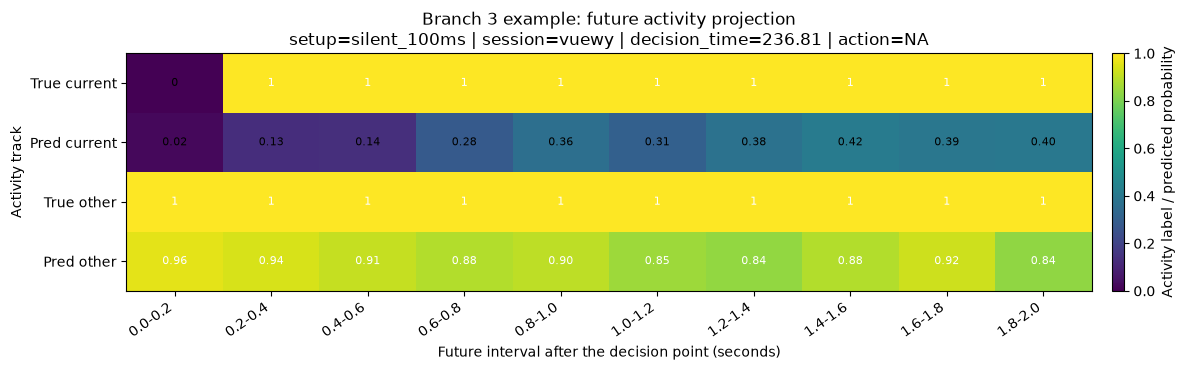

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_example_future_activity_heatmap_silent_100ms.png


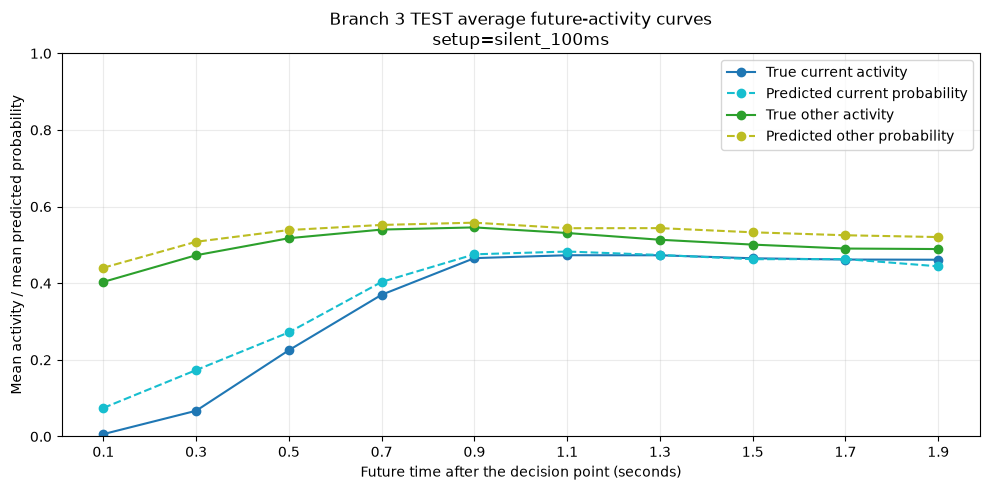

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_average_future_activity_curves_silent_100ms.png


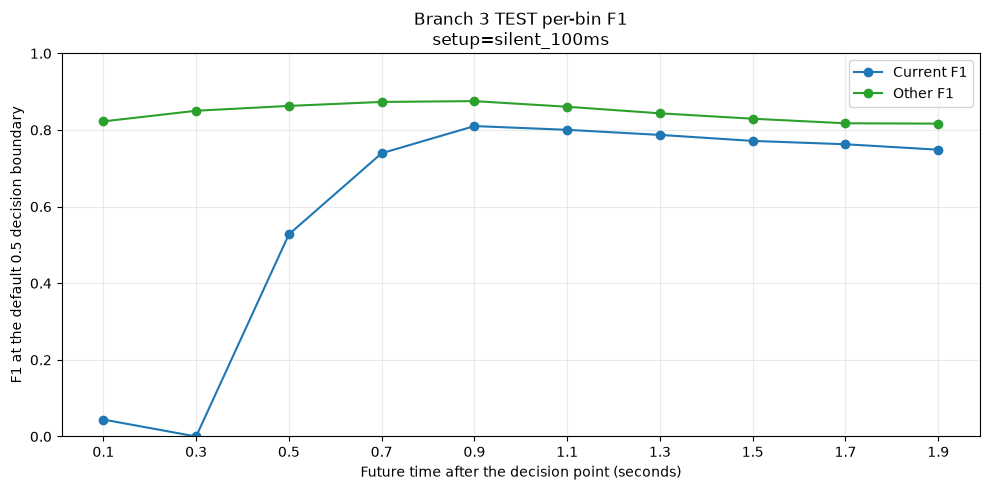

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_test_per_bin_f1_silent_100ms.png


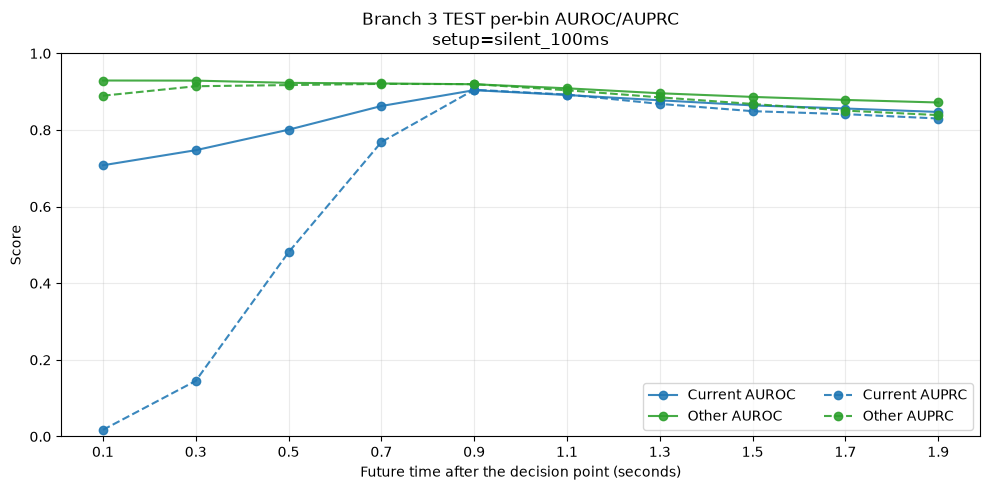

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_test_per_bin_auroc_auprc_silent_100ms.png


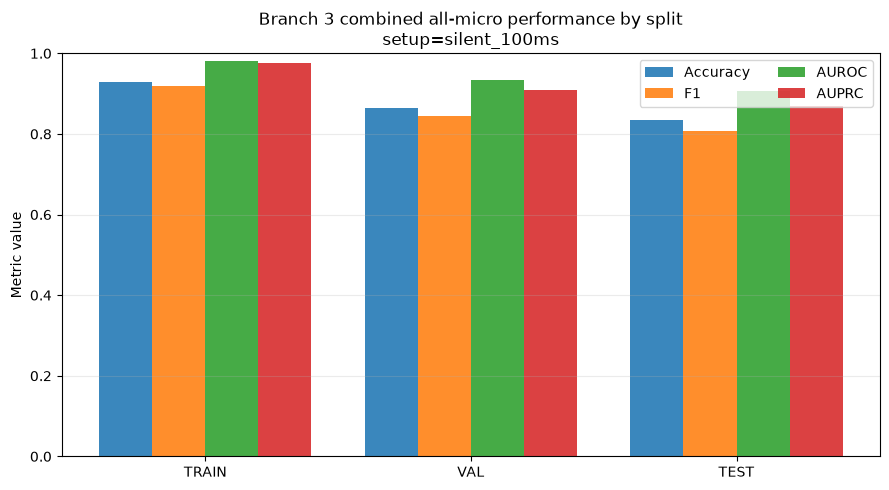

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_all_micro_metrics_by_split_silent_100ms.png


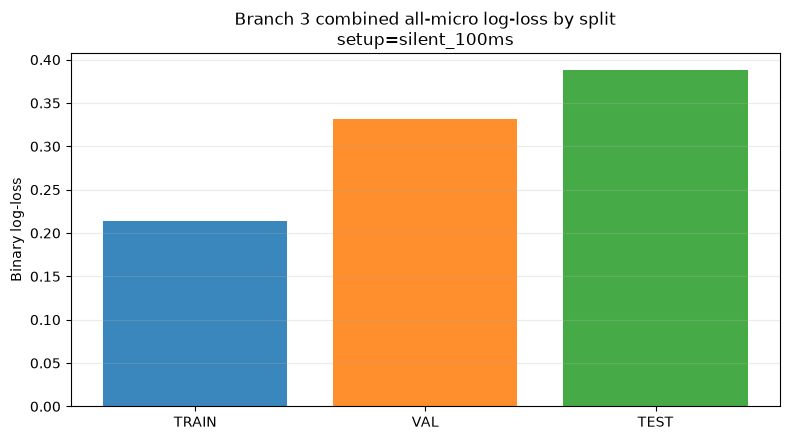

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_all_micro_logloss_by_split_silent_100ms.png


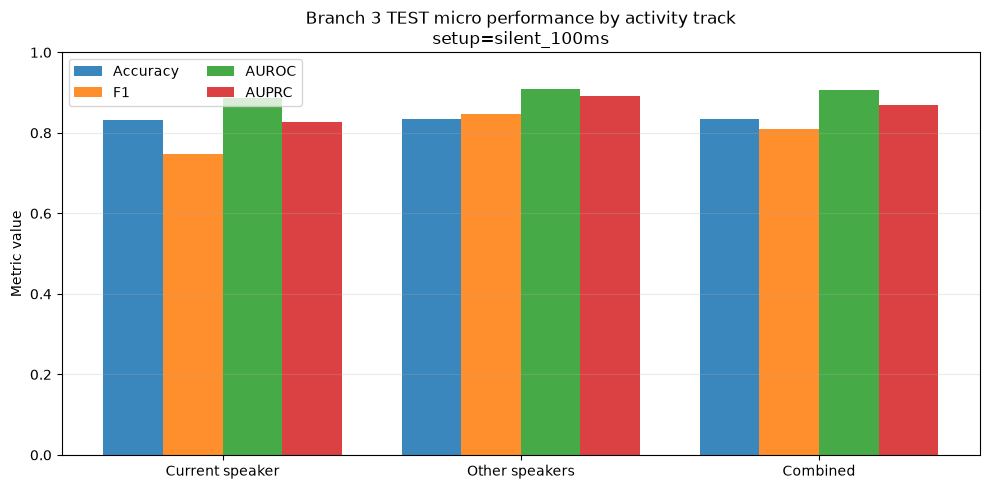

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_test_micro_metrics_by_track_silent_100ms.png


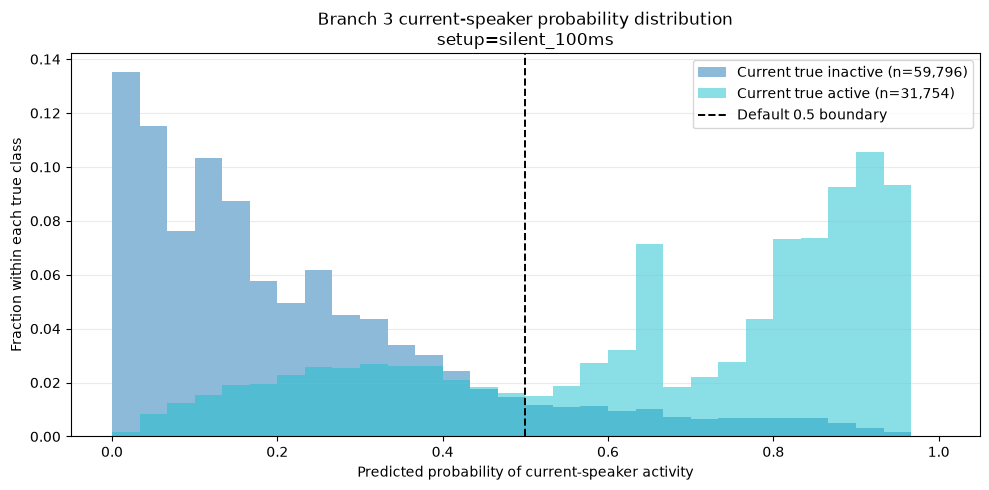

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_current_probability_distribution_silent_100ms.png


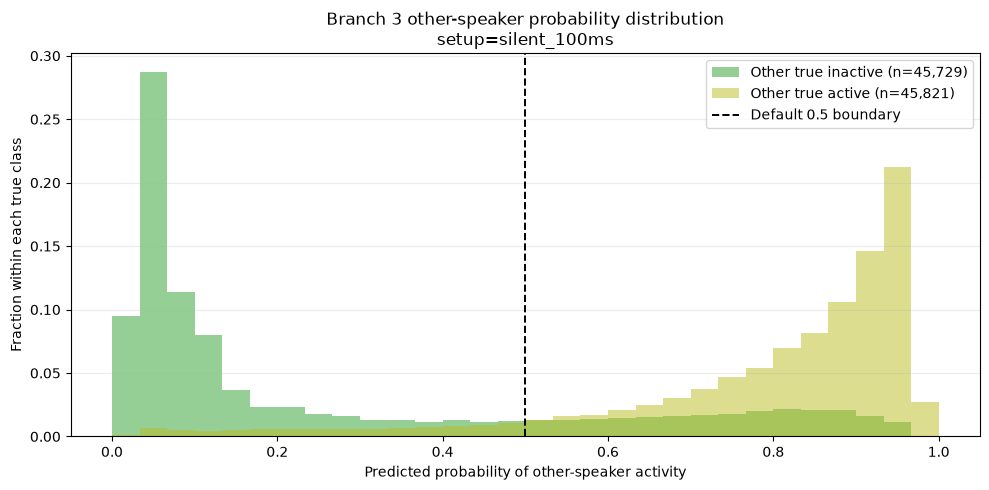

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_other_probability_distribution_silent_100ms.png


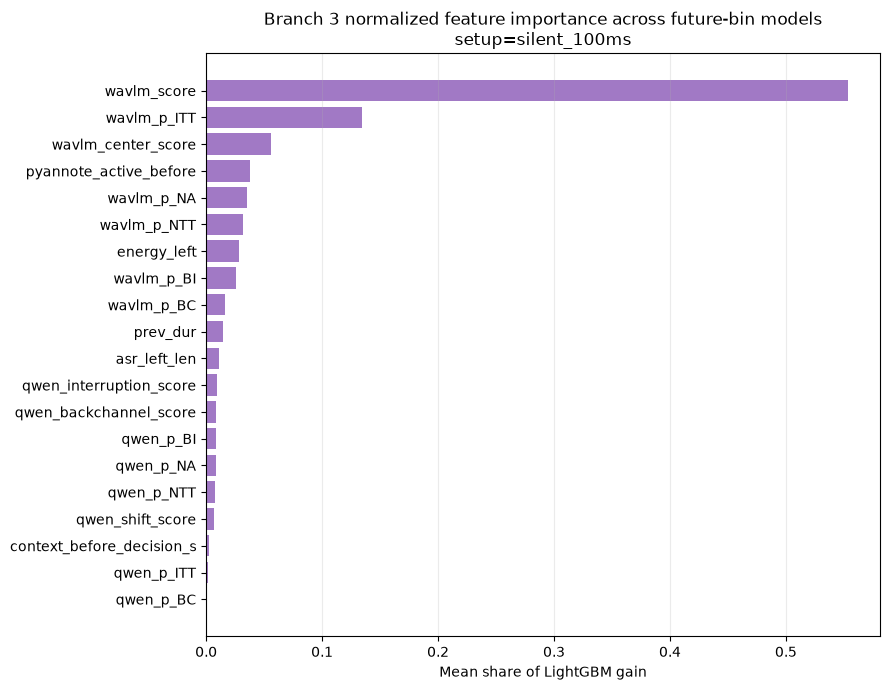

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_normalized_feature_importance_silent_100ms.png
Branch 3 visualization summary
Combined all-micro train/val/test summary:


,setup,split,target_group,target_name,n,positive_rate,log_loss,accuracy,f1,auroc,auprc
0,silent_100ms,train,all_micro,micro_all_bins,66580,0.452779,0.213634,0.927951,0.920046,0.980081,0.975297
1,silent_100ms,val,all_micro,micro_all_bins,19740,0.440375,0.331199,0.864590,0.845518,0.933523,0.909429
2,silent_100ms,test,all_micro,micro_all_bins,183100,0.423676,0.387934,0.834216,0.808547,0.905364,0.868778


TEST current/other/combined micro summary:


,setup,split,target_group,target_name,n,positive_rate,log_loss,accuracy,f1,auroc,auprc
0,silent_100ms,test,current_micro,micro_all_bins,91550,0.346849,0.396903,0.832944,0.747956,0.886732,0.826276
1,silent_100ms,test,other_micro,micro_all_bins,91550,0.500502,0.378964,0.835489,0.846114,0.907788,0.892146
2,silent_100ms,test,all_micro,micro_all_bins,183100,0.423676,0.387934,0.834216,0.808547,0.905364,0.868778


TEST per-bin summary:


,bin,time_start,time_end,time_center,target_group,target_name,positive_rate,f1,auroc,auprc,log_loss
0,0,0.0,0.2,0.1,current,current_fap_b00,0.006226,0.044248,0.707867,0.017336,0.104331
1,1,0.2,0.4,0.3,current,current_fap_b01,0.067176,0.000000,0.747236,0.145155,0.280883
2,2,0.4,0.6,0.5,current,current_fap_b02,0.225232,0.527584,0.800704,0.480824,0.442122
3,3,0.6,0.8,0.7,current,current_fap_b03,0.369962,0.739254,0.862535,0.768435,0.445118
4,4,0.8,1.0,0.9,current,current_fap_b04,0.465538,0.810207,0.903861,0.905029,0.382745
5,5,1.0,1.2,1.1,current,current_fap_b05,0.473075,0.800382,0.891239,0.892441,0.407409
6,6,1.2,1.4,1.3,current,current_fap_b06,0.472966,0.787139,0.877477,0.868072,0.435677
7,7,1.4,1.6,1.5,current,current_fap_b07,0.465101,0.771457,0.864148,0.849051,0.455417
8,8,1.6,1.8,1.7,current,current_fap_b08,0.461824,0.762712,0.856038,0.841304,0.469511
9,9,1.8,2.0,1.9,current,current_fap_b09,0.461387,0.748532,0.847005,0.829941,0.545818


Saved per-bin metrics: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_test_per_bin_metrics_silent_100ms.csv
Saved micro metrics: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch3_future_activity_visualizations/branch3_micro_metrics_silent_100ms.csv
✅ Cell 19I complete: corrected Branch 3 visualizations saved.


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

assert "BRANCH3_METRICS_DF" in globals(), "Need BRANCH3_METRICS_DF from Cell 19H."
assert "BRANCH3_TEST_PRED_DF" in globals(), "Need BRANCH3_TEST_PRED_DF from Cell 19H."
assert "BRANCH3_CURRENT_BIN_COLS" in globals(), "Need BRANCH3_CURRENT_BIN_COLS from Cell 5C."
assert "BRANCH3_OTHER_BIN_COLS" in globals(), "Need BRANCH3_OTHER_BIN_COLS from Cell 5C."

BRANCH3_MAIN_SETUP = str(
    globals().get(
        "BRANCH3_MAIN_SETUP",
        globals().get("BRANCH2_MAIN_SETUP", "silent_100ms"),
    )
)
BRANCH3_HORIZON_S = float(globals().get("BRANCH3_HORIZON_S", 2.0))
BRANCH3_BIN_S = float(globals().get("BRANCH3_BIN_S", 0.2))
BRANCH3_N_BINS = int(globals().get("BRANCH3_N_BINS", len(BRANCH3_CURRENT_BIN_COLS)))

if len(BRANCH3_CURRENT_BIN_COLS) != BRANCH3_N_BINS:
    raise ValueError(
        "BRANCH3_CURRENT_BIN_COLS length does not match BRANCH3_N_BINS: "
        f"{len(BRANCH3_CURRENT_BIN_COLS)} != {BRANCH3_N_BINS}"
    )
if len(BRANCH3_OTHER_BIN_COLS) != BRANCH3_N_BINS:
    raise ValueError(
        "BRANCH3_OTHER_BIN_COLS length does not match BRANCH3_N_BINS: "
        f"{len(BRANCH3_OTHER_BIN_COLS)} != {BRANCH3_N_BINS}"
    )

if "RUN_ROOT" in globals():
    BRANCH3_VIZ_DIR = Path(RUN_ROOT) / "branch3_future_activity_visualizations"
else:
    BRANCH3_VIZ_DIR = Path(".") / "branch3_future_activity_visualizations"
BRANCH3_VIZ_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("CELL 19I: Branch 3 visualizations")
print("=" * 80)
print("Main Branch 3 setup:", BRANCH3_MAIN_SETUP)
print("Primary split-level summary: all_micro")
print("Saving figures to:", BRANCH3_VIZ_DIR)

def _save_and_show(fig, filename):
    path = BRANCH3_VIZ_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Saved:", path)

def _metric_value(row, name):
    return float(pd.to_numeric(pd.Series([row.get(name, np.nan)]), errors="coerce").iloc[0])

def _class_normalized_hist(ax, values, labels, class_value, bins, text, color):
    values = np.asarray(values, dtype=float)
    labels = np.asarray(labels, dtype=int)
    selected = values[labels == int(class_value)]
    selected = selected[np.isfinite(selected)]
    if len(selected) == 0:
        print(f"Skipping empty probability group: {text}")
        return
    weights = np.full(len(selected), 1.0 / len(selected), dtype=float)
    ax.hist(
        selected,
        bins=bins,
        weights=weights,
        alpha=0.50,
        label=f"{text} (n={len(selected):,})",
        color=color,
    )

bin_labels = [
    f"{i * BRANCH3_BIN_S:.1f}-{(i + 1) * BRANCH3_BIN_S:.1f}"
    for i in range(BRANCH3_N_BINS)
]
bin_centers = np.asarray(
    [(i + 0.5) * BRANCH3_BIN_S for i in range(BRANCH3_N_BINS)],
    dtype=float,
)

expected_horizon = BRANCH3_N_BINS * BRANCH3_BIN_S
if not np.isclose(expected_horizon, BRANCH3_HORIZON_S, atol=1e-8):
    print(
        "WARNING: BRANCH3_N_BINS * BRANCH3_BIN_S differs from "
        f"BRANCH3_HORIZON_S: {expected_horizon:.3f} vs {BRANCH3_HORIZON_S:.3f}"
    )

main_test = BRANCH3_TEST_PRED_DF.copy()
if "prediction_setup" in main_test.columns:
    main_test = main_test[
        main_test["prediction_setup"].astype(str).eq(BRANCH3_MAIN_SETUP)
    ].copy()
main_test = main_test.reset_index(drop=True)
assert len(main_test), f"No Branch 3 TEST predictions found for setup={BRANCH3_MAIN_SETUP!r}."

current_true_cols = [f"true_{c}" for c in BRANCH3_CURRENT_BIN_COLS]
current_prob_cols = [f"prob_{c}" for c in BRANCH3_CURRENT_BIN_COLS]
other_true_cols = [f"true_{c}" for c in BRANCH3_OTHER_BIN_COLS]
other_prob_cols = [f"prob_{c}" for c in BRANCH3_OTHER_BIN_COLS]

true_cols = current_true_cols + other_true_cols
prob_cols = current_prob_cols + other_prob_cols
required_cols = true_cols + prob_cols
missing_cols = [c for c in required_cols if c not in main_test.columns]
if missing_cols:
    raise ValueError(f"Missing expected Branch 3 prediction columns: {missing_cols}")

for c in required_cols:
    main_test[c] = pd.to_numeric(main_test[c], errors="coerce")
if main_test[required_cols].isna().any().any():
    bad = main_test[required_cols].columns[main_test[required_cols].isna().any()].tolist()
    raise ValueError(f"Branch 3 TEST predictions contain missing/non-numeric values in: {bad}")

truth_values = set(np.unique(main_test[true_cols].to_numpy(dtype=int)).tolist())
if not truth_values.issubset({0, 1}):
    raise ValueError(f"Branch 3 truth columns contain non-binary values: {sorted(truth_values)}")

prob_array = main_test[prob_cols].to_numpy(dtype=float)
if not np.isfinite(prob_array).all():
    raise ValueError("Branch 3 TEST probabilities contain non-finite values.")
if ((prob_array < 0.0) | (prob_array > 1.0)).any():
    print("WARNING: clipping Branch 3 probabilities to [0, 1] for visualization.")
    main_test[prob_cols] = main_test[prob_cols].clip(0.0, 1.0)

true_matrix_all = main_test[true_cols].to_numpy(dtype=float)
prob_matrix_all = main_test[prob_cols].to_numpy(dtype=float)
example_score = (
    true_matrix_all.sum(axis=1)
    + 0.20 * prob_matrix_all.sum(axis=1)
    + 0.50 * np.abs(true_matrix_all - prob_matrix_all).mean(axis=1)
)
example_idx = int(np.argmax(example_score))
example = main_test.iloc[example_idx]

example_matrix = np.vstack([
    example[current_true_cols].to_numpy(dtype=float),
    example[current_prob_cols].to_numpy(dtype=float),
    example[other_true_cols].to_numpy(dtype=float),
    example[other_prob_cols].to_numpy(dtype=float),
])

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(example_matrix, aspect="auto", vmin=0.0, vmax=1.0, cmap="viridis")
ax.set_title(
    "Branch 3 example: future activity projection\n"
    f"setup={BRANCH3_MAIN_SETUP} | session={example.get('session', 'NA')} | "
    f"decision_time={example.get('decision_time', 'NA')} | action={example.get('action', 'NA')}"
)
ax.set_xlabel("Future interval after the decision point (seconds)")
ax.set_ylabel("Activity track")
ax.set_xticks(np.arange(BRANCH3_N_BINS))
ax.set_xticklabels(bin_labels, rotation=35, ha="right")
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["True current", "Pred current", "True other", "Pred other"])

for i in range(example_matrix.shape[0]):
    for j in range(example_matrix.shape[1]):
        value = float(example_matrix[i, j])
        ax.text(
            j,
            i,
            f"{value:.2f}" if i in (1, 3) else str(int(round(value))),
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 0.55 else "black",
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Activity label / predicted probability")
_save_and_show(fig, f"branch3_example_future_activity_heatmap_{BRANCH3_MAIN_SETUP}.png")

curve_specs = [
    (current_true_cols, "True current activity", "tab:blue", "-"),
    (current_prob_cols, "Predicted current probability", "tab:cyan", "--"),
    (other_true_cols, "True other activity", "tab:green", "-"),
    (other_prob_cols, "Predicted other probability", "tab:olive", "--"),
]

fig, ax = plt.subplots(figsize=(10, 5))
for cols, label, color, linestyle in curve_specs:
    means = main_test[cols].astype(float).mean(axis=0).to_numpy()
    ax.plot(bin_centers, means, marker="o", linestyle=linestyle, label=label, color=color)
ax.set_title(f"Branch 3 TEST average future-activity curves\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_xlabel("Future time after the decision point (seconds)")
ax.set_ylabel("Mean activity / mean predicted probability")
ax.set_ylim(0.0, 1.0)
ax.set_xticks(bin_centers)
ax.set_xticklabels([f"{x:.1f}" for x in bin_centers])
ax.grid(alpha=0.25)
ax.legend()
_save_and_show(fig, f"branch3_average_future_activity_curves_{BRANCH3_MAIN_SETUP}.png")

test_metrics = BRANCH3_METRICS_DF[
    BRANCH3_METRICS_DF["split"].astype(str).eq("test")
    & BRANCH3_METRICS_DF["setup"].astype(str).eq(BRANCH3_MAIN_SETUP)
].copy()

def _collect_bin_metrics(target_cols, group_name):
    rows = []
    for i, target_col in enumerate(target_cols):
        match = test_metrics[test_metrics["target_name"].astype(str).eq(str(target_col))]
        if len(match) != 1:
            raise RuntimeError(
                f"Expected one TEST metric row for target={target_col!r}, found {len(match)}."
            )
        row = match.iloc[0].to_dict()
        rows.append({
            "bin": int(i),
            "time_start": float(i * BRANCH3_BIN_S),
            "time_end": float((i + 1) * BRANCH3_BIN_S),
            "time_center": float(bin_centers[i]),
            "target_group": group_name,
            "target_name": target_col,
            "positive_rate": _metric_value(row, "positive_rate"),
            "f1": _metric_value(row, "f1"),
            "auroc": _metric_value(row, "auroc"),
            "auprc": _metric_value(row, "auprc"),
            "log_loss": _metric_value(row, "log_loss"),
        })
    return pd.DataFrame(rows)

branch3_bin_metrics = pd.concat(
    [
        _collect_bin_metrics(BRANCH3_CURRENT_BIN_COLS, "current"),
        _collect_bin_metrics(BRANCH3_OTHER_BIN_COLS, "other"),
    ],
    ignore_index=True,
)

BRANCH3_BIN_METRICS_CSV = BRANCH3_VIZ_DIR / f"branch3_test_per_bin_metrics_{BRANCH3_MAIN_SETUP}.csv"
branch3_bin_metrics.to_csv(BRANCH3_BIN_METRICS_CSV, index=False)
globals()["BRANCH3_BIN_METRICS_DF"] = branch3_bin_metrics
globals()["BRANCH3_BIN_METRICS_CSV"] = str(BRANCH3_BIN_METRICS_CSV)

fig, ax = plt.subplots(figsize=(10, 5))
for group, color in [("current", "tab:blue"), ("other", "tab:green")]:
    part = branch3_bin_metrics[branch3_bin_metrics["target_group"].eq(group)].sort_values("bin")
    ax.plot(part["time_center"], part["f1"], marker="o", label=f"{group.capitalize()} F1", color=color)
ax.set_title(f"Branch 3 TEST per-bin F1\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_xlabel("Future time after the decision point (seconds)")
ax.set_ylabel("F1 at the default 0.5 decision boundary")
ax.set_ylim(0.0, 1.0)
ax.set_xticks(bin_centers)
ax.set_xticklabels([f"{x:.1f}" for x in bin_centers])
ax.grid(alpha=0.25)
ax.legend()
_save_and_show(fig, f"branch3_test_per_bin_f1_{BRANCH3_MAIN_SETUP}.png")

fig, ax = plt.subplots(figsize=(10, 5))
for metric, linestyle in [("auroc", "-"), ("auprc", "--")]:
    for group, color in [("current", "tab:blue"), ("other", "tab:green")]:
        part = branch3_bin_metrics[branch3_bin_metrics["target_group"].eq(group)].sort_values("bin")
        ax.plot(
            part["time_center"],
            part[metric],
            marker="o",
            linestyle=linestyle,
            label=f"{group.capitalize()} {metric.upper()}",
            color=color,
            alpha=0.88,
        )
ax.set_title(f"Branch 3 TEST per-bin AUROC/AUPRC\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_xlabel("Future time after the decision point (seconds)")
ax.set_ylabel("Score")
ax.set_ylim(0.0, 1.0)
ax.set_xticks(bin_centers)
ax.set_xticklabels([f"{x:.1f}" for x in bin_centers])
ax.grid(alpha=0.25)
ax.legend(ncol=2)
_save_and_show(fig, f"branch3_test_per_bin_auroc_auprc_{BRANCH3_MAIN_SETUP}.png")

micro_all_rows = BRANCH3_METRICS_DF[
    BRANCH3_METRICS_DF["setup"].astype(str).eq(BRANCH3_MAIN_SETUP)
    & BRANCH3_METRICS_DF["target_name"].astype(str).eq("micro_all_bins")
].copy()

required_splits = ["train", "val", "test"]
required_groups = ["current_micro", "other_micro", "all_micro"]
for split_name in required_splits:
    for group_name in required_groups:
        n_rows = len(
            micro_all_rows[
                micro_all_rows["split"].astype(str).eq(split_name)
                & micro_all_rows["target_group"].astype(str).eq(group_name)
            ]
        )
        if n_rows != 1:
            raise RuntimeError(
                f"Expected one micro row for split={split_name!r}, "
                f"group={group_name!r}; found {n_rows}."
            )

split_rank = {name: i for i, name in enumerate(required_splits)}
group_rank = {name: i for i, name in enumerate(required_groups)}
micro_all_rows["_split_rank"] = micro_all_rows["split"].astype(str).map(split_rank)
micro_all_rows["_group_rank"] = micro_all_rows["target_group"].astype(str).map(group_rank)
micro_all_rows = (
    micro_all_rows.sort_values(["_split_rank", "_group_rank"])
    .drop(columns=["_split_rank", "_group_rank"])
    .reset_index(drop=True)
)

all_micro_by_split = micro_all_rows[
    micro_all_rows["target_group"].astype(str).eq("all_micro")
].copy()
all_micro_by_split["_rank"] = all_micro_by_split["split"].astype(str).map(split_rank)
all_micro_by_split = (
    all_micro_by_split.sort_values("_rank").drop(columns="_rank").reset_index(drop=True)
)

test_micro_by_group = micro_all_rows[
    micro_all_rows["split"].astype(str).eq("test")
].copy()
test_micro_by_group["_rank"] = test_micro_by_group["target_group"].astype(str).map(group_rank)
test_micro_by_group = (
    test_micro_by_group.sort_values("_rank").drop(columns="_rank").reset_index(drop=True)
)

BRANCH3_MICRO_METRICS_CSV = BRANCH3_VIZ_DIR / f"branch3_micro_metrics_{BRANCH3_MAIN_SETUP}.csv"
micro_all_rows.to_csv(BRANCH3_MICRO_METRICS_CSV, index=False)
globals()["BRANCH3_MICRO_METRICS_DF"] = micro_all_rows
globals()["BRANCH3_ALL_MICRO_BY_SPLIT_DF"] = all_micro_by_split
globals()["BRANCH3_TEST_MICRO_BY_GROUP_DF"] = test_micro_by_group
globals()["BRANCH3_MICRO_METRICS_CSV"] = str(BRANCH3_MICRO_METRICS_CSV)

metric_specs = [
    ("accuracy", "Accuracy", "tab:blue"),
    ("f1", "F1", "tab:orange"),
    ("auroc", "AUROC", "tab:green"),
    ("auprc", "AUPRC", "tab:red"),
]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(all_micro_by_split))
width = 0.20
for i, (col, label, color) in enumerate(metric_specs):
    ax.bar(
        x + (i - 1.5) * width,
        pd.to_numeric(all_micro_by_split[col], errors="coerce").to_numpy(dtype=float),
        width,
        label=label,
        color=color,
        alpha=0.88,
    )
ax.set_title(f"Branch 3 combined all-micro performance by split\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_ylabel("Metric value")
ax.set_ylim(0.0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels([str(s).upper() for s in all_micro_by_split["split"]])
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.25)
_save_and_show(fig, f"branch3_all_micro_metrics_by_split_{BRANCH3_MAIN_SETUP}.png")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    [str(s).upper() for s in all_micro_by_split["split"]],
    pd.to_numeric(all_micro_by_split["log_loss"], errors="coerce").to_numpy(dtype=float),
    color=["tab:blue", "tab:orange", "tab:green"],
    alpha=0.88,
)
ax.set_title(f"Branch 3 combined all-micro log-loss by split\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_ylabel("Binary log-loss")
ax.grid(axis="y", alpha=0.25)
_save_and_show(fig, f"branch3_all_micro_logloss_by_split_{BRANCH3_MAIN_SETUP}.png")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(test_micro_by_group))
for i, (col, label, color) in enumerate(metric_specs):
    ax.bar(
        x + (i - 1.5) * width,
        pd.to_numeric(test_micro_by_group[col], errors="coerce").to_numpy(dtype=float),
        width,
        label=label,
        color=color,
        alpha=0.88,
    )
group_labels = {
    "current_micro": "Current speaker",
    "other_micro": "Other speakers",
    "all_micro": "Combined",
}
ax.set_title(f"Branch 3 TEST micro performance by activity track\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_ylabel("Metric value")
ax.set_ylim(0.0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels([group_labels[str(g)] for g in test_micro_by_group["target_group"]])
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.25)
_save_and_show(fig, f"branch3_test_micro_metrics_by_track_{BRANCH3_MAIN_SETUP}.png")

current_probs = main_test[current_prob_cols].to_numpy(dtype=float).reshape(-1)
current_true = main_test[current_true_cols].to_numpy(dtype=int).reshape(-1)
other_probs = main_test[other_prob_cols].to_numpy(dtype=float).reshape(-1)
other_true = main_test[other_true_cols].to_numpy(dtype=int).reshape(-1)
hist_bins = np.linspace(0.0, 1.0, 31)

fig, ax = plt.subplots(figsize=(10, 5))
_class_normalized_hist(ax, current_probs, current_true, 0, hist_bins, "Current true inactive", "tab:blue")
_class_normalized_hist(ax, current_probs, current_true, 1, hist_bins, "Current true active", "tab:cyan")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1.4, label="Default 0.5 boundary")
ax.set_title(f"Branch 3 current-speaker probability distribution\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_xlabel("Predicted probability of current-speaker activity")
ax.set_ylabel("Fraction within each true class")
ax.grid(axis="y", alpha=0.25)
ax.legend()
_save_and_show(fig, f"branch3_current_probability_distribution_{BRANCH3_MAIN_SETUP}.png")

fig, ax = plt.subplots(figsize=(10, 5))
_class_normalized_hist(ax, other_probs, other_true, 0, hist_bins, "Other true inactive", "tab:green")
_class_normalized_hist(ax, other_probs, other_true, 1, hist_bins, "Other true active", "tab:olive")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1.4, label="Default 0.5 boundary")
ax.set_title(f"Branch 3 other-speaker probability distribution\nsetup={BRANCH3_MAIN_SETUP}")
ax.set_xlabel("Predicted probability of other-speaker activity")
ax.set_ylabel("Fraction within each true class")
ax.grid(axis="y", alpha=0.25)
ax.legend()
_save_and_show(fig, f"branch3_other_probability_distribution_{BRANCH3_MAIN_SETUP}.png")

if (
    "BRANCH3_IMPORTANCE_DF" in globals()
    and BRANCH3_IMPORTANCE_DF is not None
    and len(BRANCH3_IMPORTANCE_DF)
):
    importance_df = BRANCH3_IMPORTANCE_DF.copy()
    if "setup" in importance_df.columns:
        importance_df = importance_df[
            importance_df["setup"].astype(str).eq(BRANCH3_MAIN_SETUP)
        ].copy()

    required_importance_cols = {"target_col", "feature", "importance_gain"}
    missing_importance = required_importance_cols - set(importance_df.columns)
    if missing_importance:
        print("Skipping feature importance; missing columns:", sorted(missing_importance))
    elif len(importance_df):
        importance_df["importance_gain"] = pd.to_numeric(
            importance_df["importance_gain"], errors="coerce"
        ).fillna(0.0)

        target_gain_total = importance_df.groupby("target_col")["importance_gain"].transform("sum")
        importance_df["gain_share"] = np.where(
            target_gain_total > 0.0,
            importance_df["importance_gain"] / target_gain_total,
            0.0,
        )
        normalized_importance = (
            importance_df.groupby("feature", dropna=False)
            .agg(
                mean_gain_share=("gain_share", "mean"),
                median_gain_share=("gain_share", "median"),
                n_target_models=("target_col", "nunique"),
            )
            .reset_index()
            .sort_values("mean_gain_share", ascending=False)
        )

        BRANCH3_NORMALIZED_IMPORTANCE_CSV = (
            BRANCH3_VIZ_DIR
            / f"branch3_normalized_feature_importance_{BRANCH3_MAIN_SETUP}.csv"
        )
        normalized_importance.to_csv(BRANCH3_NORMALIZED_IMPORTANCE_CSV, index=False)
        globals()["BRANCH3_NORMALIZED_IMPORTANCE_DF"] = normalized_importance
        globals()["BRANCH3_NORMALIZED_IMPORTANCE_CSV"] = str(BRANCH3_NORMALIZED_IMPORTANCE_CSV)

        top_importance = normalized_importance.head(20).sort_values("mean_gain_share")
        fig, ax = plt.subplots(figsize=(9, 7))
        ax.barh(top_importance["feature"], top_importance["mean_gain_share"], color="tab:purple", alpha=0.88)
        ax.set_title(
            "Branch 3 normalized feature importance across future-bin models\n"
            f"setup={BRANCH3_MAIN_SETUP}"
        )
        ax.set_xlabel("Mean share of LightGBM gain")
        ax.grid(axis="x", alpha=0.25)
        _save_and_show(fig, f"branch3_normalized_feature_importance_{BRANCH3_MAIN_SETUP}.png")
else:
    print("No BRANCH3_IMPORTANCE_DF found; skipping feature importance plot.")

summary_cols = [
    "setup",
    "split",
    "target_group",
    "target_name",
    "n",
    "positive_rate",
    "log_loss",
    "accuracy",
    "f1",
    "auroc",
    "auprc",
]

print("=" * 80)
print("Branch 3 visualization summary")
print("=" * 80)
print("Combined all-micro train/val/test summary:")
display(all_micro_by_split[summary_cols])
print("TEST current/other/combined micro summary:")
display(test_micro_by_group[summary_cols])
print("TEST per-bin summary:")
display(branch3_bin_metrics)
print("Saved per-bin metrics:", BRANCH3_BIN_METRICS_CSV)
print("Saved micro metrics:", BRANCH3_MICRO_METRICS_CSV)
print("✅ Cell 19I complete: corrected Branch 3 visualizations saved.")

In [42]:
import hashlib
import json
import math
import time
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List, Tuple, Optional
from IPython.display import display

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "SYS2_FEATURES_ALL" in globals(), "Need SYS2_FEATURES_ALL from Cell 16."
assert "BRANCH2_FEATURES_ALL" in globals(), "Need BRANCH2_FEATURES_ALL from Cell 16B."
assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS from Cell 4."
assert "REAL_TEST_EVENTS" in globals(), "Need REAL_TEST_EVENTS from Cell 4."
assert "SEED" in globals(), "Need SEED."

try:
    import lightgbm as lgb
except Exception as e:
    raise ImportError("LightGBM is required for Branch 2E. Install with: pip install -U lightgbm") from e

BRANCH2_ORACLE_MODEL_DIR = (
    Path(RUN_ROOT)
    / "branch2_vap_decision_point_classifier_past_only_v2"
)

BRANCH2_E2E_DIR = (
    Path(RUN_ROOT)
    / "branch2_end_to_end_from_auto_candidates_deployable_v3"
)
BRANCH2_E2E_MODEL_DIR = (
    BRANCH2_E2E_DIR
    / "models"
)

BRANCH2_E2E_DIR.mkdir(parents=True, exist_ok=True)
BRANCH2_E2E_MODEL_DIR.mkdir(parents=True, exist_ok=True)

BRANCH2_E2E_VARIANT = (
    "branch2e_auto_candidate_e2e_v3_deployable_shared_schema"
)

BRANCH2_E2E_VAL_SCORES_CSV = (
    BRANCH2_E2E_DIR
    / "branch2e_val_auto_candidate_scores.csv"
)
BRANCH2_E2E_TEST_SCORES_CSV = (
    BRANCH2_E2E_DIR
    / "branch2e_test_auto_candidate_scores.csv"
)
BRANCH2_E2E_VAL_SWEEP_CSV = (
    BRANCH2_E2E_DIR
    / "branch2e_val_sweep.csv"
)
BRANCH2_E2E_TEST_METRICS_CSV = (
    BRANCH2_E2E_DIR
    / "branch2e_test_metrics_by_tolerance.csv"
)
BRANCH2_E2E_TEST_PRED_CSV = (
    BRANCH2_E2E_DIR
    / "branch2e_test_predictions.csv"
)
BRANCH2_E2E_RUN_CARD_JSON = (
    BRANCH2_E2E_DIR
    / "branch2e_run_card.json"
)
BRANCH2_E2E_FEATURE_COLS_JSON = (
    BRANCH2_E2E_DIR
    / "branch2e_deployable_feature_cols.json"
)

CACHE_SAFE_RESUME_RUN = bool(
    globals().get("CACHE_SAFE_RESUME_RUN", True)
)

FORCE_RETRAIN_BRANCH2_E2E_LGBM = bool(
    globals().get(
        "FORCE_RETRAIN_BRANCH2_E2E_LGBM",
        False,
    )
)

BRANCH2_E2E_TRAIN_MISSING_OR_INCOMPATIBLE = bool(
    globals().get(
        "BRANCH2_E2E_TRAIN_MISSING_OR_INCOMPATIBLE",
        True,
    )
)

BRANCH2_E2E_NUM_BOOST_ROUND = int(
    globals().get(
        "BRANCH2_E2E_NUM_BOOST_ROUND",
        globals().get("BRANCH2_LGBM_NUM_BOOST_ROUND", 1200),
    )
)
BRANCH2_E2E_EARLY_STOPPING_ROUNDS = int(
    globals().get(
        "BRANCH2_E2E_EARLY_STOPPING_ROUNDS",
        globals().get("BRANCH2_LGBM_EARLY_STOPPING_ROUNDS", 80),
    )
)
BRANCH2_E2E_LEARNING_RATE = float(
    globals().get(
        "BRANCH2_E2E_LEARNING_RATE",
        globals().get("BRANCH2_LGBM_LEARNING_RATE", 0.025),
    )
)
BRANCH2_E2E_NUM_LEAVES = int(
    globals().get(
        "BRANCH2_E2E_NUM_LEAVES",
        globals().get("BRANCH2_LGBM_NUM_LEAVES", 31),
    )
)
BRANCH2_E2E_MIN_DATA_IN_LEAF = int(
    globals().get(
        "BRANCH2_E2E_MIN_DATA_IN_LEAF",
        globals().get("BRANCH2_LGBM_MIN_DATA_IN_LEAF", 20),
    )
)
BRANCH2_E2E_FEATURE_FRACTION = float(
    globals().get(
        "BRANCH2_E2E_FEATURE_FRACTION",
        globals().get("BRANCH2_LGBM_FEATURE_FRACTION", 0.85),
    )
)
BRANCH2_E2E_BAGGING_FRACTION = float(
    globals().get(
        "BRANCH2_E2E_BAGGING_FRACTION",
        globals().get("BRANCH2_LGBM_BAGGING_FRACTION", 0.85),
    )
)
BRANCH2_E2E_BAGGING_FREQ = int(
    globals().get(
        "BRANCH2_E2E_BAGGING_FREQ",
        globals().get("BRANCH2_LGBM_BAGGING_FREQ", 1),
    )
)
BRANCH2_E2E_LAMBDA_L2 = float(
    globals().get(
        "BRANCH2_E2E_LAMBDA_L2",
        globals().get("BRANCH2_LGBM_LAMBDA_L2", 2.0),
    )
)
BRANCH2_E2E_USE_CLASS_BALANCE = bool(
    globals().get(
        "BRANCH2_E2E_USE_CLASS_BALANCE",
        globals().get("BRANCH2_USE_CLASS_BALANCE", True),
    )
)

def _as_str_list(value, default=None) -> List[str]:
    if value is None:
        value = default if default is not None else []
    if isinstance(value, str):
        value = [value]
    elif not isinstance(value, (list, tuple, set, np.ndarray, pd.Series)):
        value = [value]
    return list(dict.fromkeys(str(x) for x in value if str(x).strip()))

available_setups = sorted(
    BRANCH2_FEATURES_ALL[
        "prediction_setup"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

BRANCH2_E2E_SETUPS_TO_RUN = _as_str_list(
    globals().get(
        "BRANCH2_E2E_SETUPS_TO_RUN",
        None,
    ),
    default=(
        available_setups
        or [
            globals().get(
                "BRANCH2_MAIN_SETUP",
                "silent_100ms",
            )
        ]
    ),
)

BRANCH2_E2E_THR_GRID = [float(x) for x in globals().get(
    "BRANCH2_E2E_THR_GRID", np.round(np.linspace(0.05, 0.95, 37), 4).tolist()
)]
BRANCH2_E2E_MIN_GAP_GRID = [float(x) for x in globals().get(
    "BRANCH2_E2E_MIN_GAP_GRID", [0.05, 0.10, 0.20, 0.30, 0.50, 0.70, 1.00]
)]
BRANCH2_E2E_OFFSET_GRID = [float(x) for x in globals().get(
    "BRANCH2_E2E_OFFSET_GRID", [-0.30, -0.20, -0.10, 0.00, 0.10, 0.20, 0.30]
)]
BRANCH2_E2E_VAL_TUNE_TOL = float(globals().get("BRANCH2_E2E_VAL_TUNE_TOL", 0.50))
BRANCH2_E2E_TOLERANCES = list(globals().get(
    "BRANCH1_E2E_TOLERANCES",
    [
        {"name": "strict", "label": "strict_0p50", "tol": 0.50, "description": "Strict event matching, ±0.50 s"},
        {"name": "dataset_calibrated", "label": "dataset_calibrated_0p70", "tol": 0.70, "description": "Dataset-calibrated event matching, ±0.70 s"},
        {"name": "relaxed", "label": "relaxed_1p00", "tol": 1.00, "description": "Relaxed event matching, ±1.00 s"},
    ],
))

def _json_safe(x):
    if isinstance(x, dict):
        return {str(k): _json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if math.isfinite(x) else None
    if isinstance(x, pd.DataFrame):
        return x.to_dict("records")
    if isinstance(x, pd.Series):
        return x.to_dict()
    try:
        if pd.isna(x):
            return None
    except Exception:
        pass
    return x

def _norm_sid(x) -> str:
    return Path(str(x)).stem

def dataframe_fingerprint(df: pd.DataFrame, cols: Optional[List[str]] = None) -> str:
    if df is None:
        return "none"
    work = df.copy()
    if cols is not None:
        use = [c for c in cols if c in work.columns]
        work = work[use].copy()
    if len(work) == 0:
        return "empty"
    payload = pd.util.hash_pandas_object(work, index=True).to_numpy(dtype=np.uint64).tobytes()
    return hashlib.sha256(payload).hexdigest()

def _load_oracle_branch2_feature_cols() -> List[str]:
    global_cols = globals().get(
        "FEATURE_COLS_BRANCH2",
        None,
    )

    if global_cols is not None:
        cols = [
            str(c)
            for c in list(global_cols)
        ]

        if cols:
            return cols

    feature_path = (
        BRANCH2_ORACLE_MODEL_DIR
        / "branch2_feature_cols.json"
    )

    if feature_path.exists():
        loaded = json.loads(
            feature_path.read_text()
        )

        if isinstance(loaded, list) and loaded:
            return [
                str(c)
                for c in loaded
            ]

    raise FileNotFoundError(
        "Could not find the Cell 19F Branch 2 feature schema:\n"
        f"{feature_path}\n"
        "Run the updated Cell 19F first."
    )

BRANCH2_ORACLE_FEATURE_COLS = (
    _load_oracle_branch2_feature_cols()
)

BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS = []

for feature_name in BRANCH2_ORACLE_FEATURE_COLS:
    if feature_name not in BRANCH2_FEATURES_ALL.columns:
        continue

    if feature_name not in SYS2_FEATURES_ALL.columns:
        continue

    if not (
        pd.api.types.is_numeric_dtype(
            BRANCH2_FEATURES_ALL[feature_name]
        )
        or pd.api.types.is_bool_dtype(
            BRANCH2_FEATURES_ALL[feature_name]
        )
    ):
        continue

    BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS.append(
        str(feature_name)
    )

BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS = list(
    dict.fromkeys(
        BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
    )
)

BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES = [
    feature_name
    for feature_name in BRANCH2_ORACLE_FEATURE_COLS
    if feature_name
    not in BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
]

if not BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS:
    raise RuntimeError(
        "No Branch 2 features are shared between "
        "BRANCH2_FEATURES_ALL and SYS2_FEATURES_ALL."
    )

for forbidden_name in [
    "prev_dur",
    "context_before_decision_s",
]:
    if (
        forbidden_name
        in BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        and forbidden_name
        not in SYS2_FEATURES_ALL.columns
    ):
        raise RuntimeError(
            f"RTTM-only feature was retained unexpectedly: "
            f"{forbidden_name}"
        )

BRANCH2_E2E_FEATURE_COLS_JSON.write_text(
    json.dumps(
        {
            "variant": BRANCH2_E2E_VARIANT,
            "oracle_feature_cols": (
                BRANCH2_ORACLE_FEATURE_COLS
            ),
            "deployable_feature_cols": (
                BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
            ),
            "excluded_oracle_only_features": (
                BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES
            ),
            "selection_rule": (
                "ordered intersection of Cell 19F oracle features, "
                "BRANCH2_FEATURES_ALL columns, and "
                "SYS2_FEATURES_ALL columns"
            ),
            "missing_features_zero_filled": False,
        },
        indent=2,
        sort_keys=True,
    )
)

def _branch2e_lgbm_params() -> Dict[str, Any]:
    return {
        "objective": "binary",
        "metric": [
            "binary_logloss",
            "auc",
        ],
        "learning_rate": float(
            BRANCH2_E2E_LEARNING_RATE
        ),
        "num_leaves": int(
            BRANCH2_E2E_NUM_LEAVES
        ),
        "min_data_in_leaf": int(
            BRANCH2_E2E_MIN_DATA_IN_LEAF
        ),
        "feature_fraction": float(
            BRANCH2_E2E_FEATURE_FRACTION
        ),
        "bagging_fraction": float(
            BRANCH2_E2E_BAGGING_FRACTION
        ),
        "bagging_freq": int(
            BRANCH2_E2E_BAGGING_FREQ
        ),
        "lambda_l2": float(
            BRANCH2_E2E_LAMBDA_L2
        ),
        "verbosity": -1,
        "seed": int(SEED),
        "feature_pre_filter": False,
        "force_col_wise": True,
    }

def _prepare_branch2e_training_frame(
    df: pd.DataFrame,
    feature_cols: List[str],
) -> pd.DataFrame:
    out = df.copy()

    missing = [
        c
        for c in feature_cols
        if c not in out.columns
    ]

    if missing:
        raise KeyError(
            "Branch 2E training frame is missing shared features: "
            f"{missing}"
        )

    for c in feature_cols:
        out[c] = pd.to_numeric(
            out[c],
            errors="coerce",
        )

    out[feature_cols] = (
        out[feature_cols]
        .replace(
            [np.inf, -np.inf],
            np.nan,
        )
        .fillna(0.0)
    )

    out["label"] = (
        pd.to_numeric(
            out["label"],
            errors="coerce",
        )
        .fillna(-1)
        .astype(int)
    )

    out = out[
        out["label"].isin([0, 1])
    ].copy()

    if "sample_weight" not in out.columns:
        out["sample_weight"] = 1.0

    out["sample_weight"] = (
        pd.to_numeric(
            out["sample_weight"],
            errors="coerce",
        )
        .fillna(1.0)
        .clip(lower=1e-6)
    )

    return out.reset_index(drop=True)

def _branch2e_training_weights(
    train_df: pd.DataFrame,
) -> np.ndarray:
    weights = (
        train_df["sample_weight"]
        .astype(float)
        .to_numpy(dtype=np.float32)
    )

    weights = np.maximum(
        weights,
        1e-6,
    )

    if not BRANCH2_E2E_USE_CLASS_BALANCE:
        return weights

    labels = (
        train_df["label"]
        .astype(int)
        .to_numpy()
    )

    counts = np.bincount(
        labels,
        minlength=2,
    ).astype(np.float32)

    counts = np.maximum(
        counts,
        1.0,
    )

    class_weights = (
        counts.sum()
        / counts
    )

    class_weights = (
        class_weights
        / max(
            1e-8,
            float(class_weights.mean()),
        )
    )

    weights = (
        weights
        * class_weights[labels]
    )

    return np.maximum(
        np.nan_to_num(
            weights,
            nan=1.0,
            posinf=1.0,
            neginf=1.0,
        ),
        1e-6,
    ).astype(np.float32)

def _branch2e_expected_model_meta(
    setup: str,
) -> Dict[str, Any]:
    return {
        "variant": BRANCH2_E2E_VARIANT,
        "prediction_setup": str(setup),
        "feature_cols": list(
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ),
        "n_features": int(
            len(
                BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
            )
        ),
        "excluded_oracle_only_features": list(
            BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES
        ),
        "missing_features_zero_filled": False,
    }

def _branch2e_model_is_compatible(
    meta_path: Path,
    setup: str,
) -> bool:
    if not meta_path.exists():
        return False

    try:
        saved = json.loads(
            meta_path.read_text()
        )
    except Exception:
        return False

    expected = _branch2e_expected_model_meta(
        setup
    )

    for key, value in expected.items():
        if saved.get(key) != value:
            return False

    return True

def _train_or_load_branch2e_model(
    setup: str,
):
    setup = str(setup)

    model_path = (
        BRANCH2_E2E_MODEL_DIR
        / (
            "branch2e_lgbm_shift_hold_"
            f"{setup}.txt"
        )
    )

    meta_path = (
        BRANCH2_E2E_MODEL_DIR
        / (
            "branch2e_lgbm_shift_hold_"
            f"{setup}.meta.json"
        )
    )

    history_path = (
        BRANCH2_E2E_MODEL_DIR
        / (
            "branch2e_lgbm_shift_hold_"
            f"{setup}.evals_result.json"
        )
    )

    compatible = (
        model_path.exists()
        and _branch2e_model_is_compatible(
            meta_path,
            setup,
        )
    )

    if (
        compatible
        and not FORCE_RETRAIN_BRANCH2_E2E_LGBM
    ):
        model = lgb.Booster(
            model_file=str(model_path)
        )

        model_features = [
            str(c)
            for c in model.feature_name()
        ]

        if (
            model_features
            != BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ):
            compatible = False
        else:
            saved_meta = json.loads(
                meta_path.read_text()
            )

            best_iteration = int(
                saved_meta.get(
                    "best_iteration",
                    0,
                )
                or 0
            )

            print(
                f"Loaded deployable Branch 2E model "
                f"for {setup}:",
                model_path,
            )

            return (
                model,
                list(model_features),
                best_iteration,
                model_path,
                meta_path,
            )

    if (
        not compatible
        and not FORCE_RETRAIN_BRANCH2_E2E_LGBM
        and not BRANCH2_E2E_TRAIN_MISSING_OR_INCOMPATIBLE
    ):
        raise FileNotFoundError(
            "No compatible deployable Branch 2E model exists for "
            f"setup={setup}:\n{model_path}\n"
            "Set BRANCH2_E2E_TRAIN_MISSING_OR_INCOMPATIBLE=True "
            "to train the lightweight shared-schema model."
        )

    train_raw = BRANCH2_FEATURES_ALL[
        BRANCH2_FEATURES_ALL[
            "branch2_split"
        ]
        .astype(str)
        .eq("train")
        & BRANCH2_FEATURES_ALL[
            "prediction_setup"
        ]
        .astype(str)
        .eq(setup)
    ].copy()

    val_raw = BRANCH2_FEATURES_ALL[
        BRANCH2_FEATURES_ALL[
            "branch2_split"
        ]
        .astype(str)
        .eq("val")
        & BRANCH2_FEATURES_ALL[
            "prediction_setup"
        ]
        .astype(str)
        .eq(setup)
    ].copy()

    train_df = _prepare_branch2e_training_frame(
        train_raw,
        BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS,
    )

    val_df = _prepare_branch2e_training_frame(
        val_raw,
        BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS,
    )

    if len(train_df) == 0 or len(val_df) == 0:
        raise RuntimeError(
            f"Missing Branch 2E train/VAL rows for setup={setup}."
        )

    if train_df["label"].nunique() < 2:
        raise RuntimeError(
            f"Branch 2E train split has one class for setup={setup}."
        )

    print(
        f"Training deployable Branch 2E model for {setup} "
        f"with {len(BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS)} "
        "shared features; upstream caches remain unchanged."
    )

    train_set = lgb.Dataset(
        train_df[
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ],
        label=train_df["label"].astype(int),
        weight=_branch2e_training_weights(
            train_df
        ),
        feature_name=(
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ),
        free_raw_data=False,
    )

    val_set = lgb.Dataset(
        val_df[
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ],
        label=val_df["label"].astype(int),
        weight=(
            val_df["sample_weight"]
            .astype(float)
            .to_numpy(dtype=np.float32)
        ),
        reference=train_set,
        feature_name=(
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ),
        free_raw_data=False,
    )

    evals_result = {}

    model = lgb.train(
        _branch2e_lgbm_params(),
        train_set,
        num_boost_round=int(
            BRANCH2_E2E_NUM_BOOST_ROUND
        ),
        valid_sets=[
            train_set,
            val_set,
        ],
        valid_names=[
            "train",
            "val",
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(
                    BRANCH2_E2E_EARLY_STOPPING_ROUNDS
                ),
                first_metric_only=False,
                verbose=True,
            ),
            lgb.log_evaluation(
                period=100
            ),
            lgb.record_evaluation(
                evals_result
            ),
        ],
    )

    best_iteration = int(
        getattr(
            model,
            "best_iteration",
            0,
        )
        or 0
    )

    if best_iteration > 0:
        model.save_model(
            str(model_path),
            num_iteration=best_iteration,
        )
    else:
        model.save_model(
            str(model_path)
        )

    meta = _branch2e_expected_model_meta(
        setup
    )

    meta.update({
        "params": _branch2e_lgbm_params(),
        "num_boost_round": int(
            BRANCH2_E2E_NUM_BOOST_ROUND
        ),
        "early_stopping_rounds": int(
            BRANCH2_E2E_EARLY_STOPPING_ROUNDS
        ),
        "best_iteration": int(
            best_iteration
        ),
        "best_score": _json_safe(
            getattr(
                model,
                "best_score",
                {},
            )
        ),
        "trained_time": time.strftime(
            "%Y-%m-%d %H:%M:%S"
        ),
        "trained_on": (
            "BRANCH2_FEATURES_ALL train split"
        ),
        "validated_on": (
            "BRANCH2_FEATURES_ALL VAL split"
        ),
    })

    meta_path.write_text(
        json.dumps(
            _json_safe(meta),
            indent=2,
            sort_keys=True,
        )
    )

    history_path.write_text(
        json.dumps(
            _json_safe(evals_result),
            indent=2,
            sort_keys=True,
        )
    )

    print(
        f"Saved deployable Branch 2E model "
        f"for {setup}:",
        model_path,
    )

    return (
        model,
        list(
            BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS
        ),
        best_iteration,
        model_path,
        meta_path,
    )

BRANCH2_E2E_MODEL_BUNDLES = {}

def canonical_prepare_predictions(pred_df: pd.DataFrame) -> pd.DataFrame:
    if pred_df is None or len(pred_df) == 0:
        return pd.DataFrame(columns=["session", "time", "score", "_pred_row_id"])
    if not {"session", "time"}.issubset(pred_df.columns):
        raise ValueError("Prediction table must contain session and time columns.")
    out = pred_df.copy()
    out["session"] = out["session"].astype(str).map(_norm_sid)
    out["time"] = pd.to_numeric(out["time"], errors="coerce").astype("float64")
    if "score" not in out.columns:
        for c in ["fused_shift_score", "lgbm_binary_shift_score", "lgbm_shift_score"]:
            if c in out.columns:
                out["score"] = pd.to_numeric(out[c], errors="coerce")
                break
        else:
            out["score"] = 1.0
    out["score"] = pd.to_numeric(out["score"], errors="coerce").fillna(0.0).astype("float64")
    out = out.dropna(subset=["session", "time"])
    out = out[out["time"] >= 0].copy()
    out["_time_key"] = out["time"].round(9)
    out = (
        out.sort_values(["session", "_time_key", "score"], ascending=[True, True, False])
        .drop_duplicates(["session", "_time_key"], keep="first")
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )
    out["_pred_row_id"] = np.arange(len(out), dtype=np.int64)
    return out

def canonical_prepare_gt_events(events_df: pd.DataFrame) -> pd.DataFrame:
    if events_df is None or len(events_df) == 0:
        return pd.DataFrame(columns=["session", "time", "_gt_row_id"])
    if not {"session", "time"}.issubset(events_df.columns):
        raise ValueError("GT event table must contain session and time columns.")
    out = events_df.copy()
    out["session"] = out["session"].astype(str).map(_norm_sid)
    out["time"] = pd.to_numeric(out["time"], errors="coerce").astype("float64")
    if "label" in out.columns:
        out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(0).astype(int)
        out = out[out["label"].eq(1)].copy()
    if "source_event_type" in out.columns:
        adjacent = out["source_event_type"].astype(str).eq("adjacent_rttm_boundary")
        if adjacent.any():
            out = out[adjacent].copy()
    out = out.dropna(subset=["session", "time"])
    out["_time_key"] = out["time"].round(9)
    out = (
        out.drop_duplicates(["session", "_time_key"], keep="first")
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )
    out["_gt_row_id"] = np.arange(len(out), dtype=np.int64)
    return out

def canonical_match_indices(pred_times, gt_times, tol: float) -> List[Tuple[int, int, float]]:
    p = np.asarray(pred_times, dtype=np.float64).reshape(-1)
    g = np.asarray(gt_times, dtype=np.float64).reshape(-1)
    if len(p) == 0 or len(g) == 0:
        return []
    cost = np.abs(p[:, None] - g[None, :])
    try:
        from scipy.optimize import linear_sum_assignment
        big = 1e9
        rr, cc = linear_sum_assignment(np.where(cost <= float(tol), cost, big))
        pairs = [(int(i), int(j), float(cost[i, j])) for i, j in zip(rr, cc) if cost[i, j] <= float(tol)]
        return sorted(pairs, key=lambda z: (z[0], z[1]))
    except Exception:
        candidates = []
        for i in range(len(p)):
            for j in np.where(cost[i] <= float(tol))[0]:
                candidates.append((float(cost[i, j]), int(i), int(j)))
        candidates.sort(key=lambda z: (z[0], z[1], z[2]))
        used_p, used_g, pairs = set(), set(), []
        for d, i, j in candidates:
            if i in used_p or j in used_g:
                continue
            used_p.add(i); used_g.add(j)
            pairs.append((i, j, d))
        return sorted(pairs, key=lambda z: (z[0], z[1]))

def canonical_event_metrics_from_table(
    pred_df: pd.DataFrame,
    events_df: pd.DataFrame,
    tol: float,
    return_per_session: bool = False,
    return_matches: bool = False,
) -> Dict[str, Any]:
    pred = canonical_prepare_predictions(pred_df)
    gt = canonical_prepare_gt_events(events_df)
    sessions = sorted(set(pred["session"]).union(set(gt["session"])))
    totals = {"TP": 0, "FP": 0, "FN": 0, "N_pred": 0, "N_gt": 0}
    per_rows, match_rows = [], []
    for sid in sessions:
        ps = pred[pred["session"].eq(sid)].reset_index(drop=True)
        gs = gt[gt["session"].eq(sid)].reset_index(drop=True)
        pairs = canonical_match_indices(ps["time"].to_numpy(np.float64), gs["time"].to_numpy(np.float64), tol)
        tp, npred, ngt = len(pairs), len(ps), len(gs)
        row = {"session": sid, "TP": tp, "FP": npred - tp, "FN": ngt - tp, "N_pred": npred, "N_gt": ngt}
        for k in totals:
            totals[k] += int(row[k])
        per_rows.append({"tol": float(tol), **row})
        if return_matches:
            for pi, gi, err in pairs:
                match_rows.append({
                    "session": sid,
                    "pred_local_index": int(pi),
                    "gt_local_index": int(gi),
                    "pred_row_id": int(ps.iloc[pi]["_pred_row_id"]),
                    "gt_row_id": int(gs.iloc[gi]["_gt_row_id"]),
                    "pred_time": float(ps.iloc[pi]["time"]),
                    "gt_time": float(gs.iloc[gi]["time"]),
                    "signed_error": float(ps.iloc[pi]["time"] - gs.iloc[gi]["time"]),
                    "abs_error": float(err),
                    "tol": float(tol),
                })
    tp, fp, fn = totals["TP"], totals["FP"], totals["FN"]
    p = tp / max(1, tp + fp)
    r = tp / max(1, tp + fn)
    f1 = 2 * p * r / max(1e-12, p + r)
    out = {"P": float(p), "R": float(r), "F1": float(f1), **totals}
    if return_per_session:
        out["per_session"] = pd.DataFrame(per_rows)
    if return_matches:
        out["matches"] = pd.DataFrame(match_rows)
    return out

def _prepare_auto_candidates(
    split_name: str,
    setup: str,
    feature_cols: List[str],
) -> pd.DataFrame:
    out = SYS2_FEATURES_ALL.copy()

    if "split" not in out.columns:
        raise ValueError(
            "SYS2_FEATURES_ALL has no split column."
        )

    out = out[
        out["split"]
        .astype(str)
        .eq(str(split_name))
    ].copy()

    if "prediction_setup" in out.columns:
        setup_rows = out[
            out["prediction_setup"]
            .astype(str)
            .eq(str(setup))
        ].copy()

        if len(setup_rows):
            out = setup_rows

    for c in [
        "source_train_gt_seed",
        "is_synthetic",
        "is_diffusion_augmented",
    ]:
        if c in out.columns:
            out = out[
                pd.to_numeric(
                    out[c],
                    errors="coerce",
                )
                .fillna(0)
                .astype(int)
                .eq(0)
            ].copy()

    required_base = [
        "session",
        "time",
    ]

    missing_base = [
        c
        for c in required_base
        if c not in out.columns
    ]

    if missing_base:
        raise ValueError(
            "SYS2_FEATURES_ALL is missing required columns: "
            f"{missing_base}"
        )

    missing_features = [
        c
        for c in feature_cols
        if c not in out.columns
    ]

    if missing_features:
        raise KeyError(
            f"Branch 2E setup={setup} is missing deployable "
            f"model features: {missing_features}. "
            "The shared-schema model must be retrained rather than "
            "zero-filling these columns."
        )

    out["session"] = (
        out["session"]
        .astype(str)
        .map(_norm_sid)
    )

    out["time"] = (
        pd.to_numeric(
            out["time"],
            errors="coerce",
        )
        .astype("float64")
    )

    for c in feature_cols:
        out[c] = pd.to_numeric(
            out[c],
            errors="coerce",
        )

    out[feature_cols] = (
        out[feature_cols]
        .replace(
            [np.inf, -np.inf],
            np.nan,
        )
        .fillna(0.0)
    )

    out = out.dropna(
        subset=[
            "session",
            "time",
        ]
    )

    out["_time_key"] = (
        out["time"]
        .round(9)
    )

    out = (
        out
        .drop_duplicates(
            [
                "session",
                "_time_key",
            ]
        )
        .drop(
            columns=["_time_key"]
        )
        .sort_values(
            [
                "session",
                "time",
            ]
        )
        .reset_index(drop=True)
    )

    return out

def _load_branch2_model(
    setup: str,
):
    setup = str(setup)

    if setup not in BRANCH2_E2E_MODEL_BUNDLES:
        BRANCH2_E2E_MODEL_BUNDLES[
            setup
        ] = _train_or_load_branch2e_model(
            setup
        )

    return BRANCH2_E2E_MODEL_BUNDLES[
        setup
    ]

def _score_setup(split_name: str, setup: str) -> pd.DataFrame:
    model, feature_cols, best_iter, _, _ = _load_branch2_model(setup)
    base = _prepare_auto_candidates(split_name, setup, feature_cols)
    kwargs = {"num_iteration": best_iter} if best_iter > 0 else {}
    out = base.copy()
    prob = np.asarray(model.predict(out[feature_cols], **kwargs), dtype=np.float64).reshape(-1)
    out["branch2_e2e_setup"] = str(setup)
    out["branch2_e2e_prob_shift"] = np.clip(prob, 1e-8, 1 - 1e-8)
    out["branch2_e2e_prob_hold"] = 1.0 - out["branch2_e2e_prob_shift"]
    return out

def _postprocess(scored_df: pd.DataFrame, thr: float, min_gap_s: float, offset_s: float) -> pd.DataFrame:
    if scored_df is None or len(scored_df) == 0:
        return pd.DataFrame(columns=["session", "time", "score"])
    work = scored_df.copy()
    work["time"] = pd.to_numeric(work["time"], errors="coerce").astype("float64")
    work["branch2_e2e_prob_shift"] = pd.to_numeric(work["branch2_e2e_prob_shift"], errors="coerce")
    work = work.dropna(subset=["session", "time", "branch2_e2e_prob_shift"])
    work = work[work["branch2_e2e_prob_shift"] >= float(thr)].copy()
    rows = []
    for sid, g in work.groupby("session", sort=False):
        g = g.sort_values("time").reset_index(drop=True)
        cluster = []
        for _, r in g.iterrows():
            if cluster and float(r["time"]) - float(cluster[-1]["time"]) > float(min_gap_s):
                best = max(cluster, key=lambda z: float(z["branch2_e2e_prob_shift"]))
                rows.append({"session": sid, "time": float(best["time"]) + float(offset_s), "score": float(best["branch2_e2e_prob_shift"])})
                cluster = []
            cluster.append(r)
        if cluster:
            best = max(cluster, key=lambda z: float(z["branch2_e2e_prob_shift"]))
            rows.append({"session": sid, "time": float(best["time"]) + float(offset_s), "score": float(best["branch2_e2e_prob_shift"])})
    return canonical_prepare_predictions(pd.DataFrame(rows)).drop(columns=["_pred_row_id"], errors="ignore")

print("=" * 80)
print("CELL 19J: Branch 2E — deployment-compatible automatic-candidate evaluation")
print("=" * 80)
print("Variant:", BRANCH2_E2E_VARIANT)
print("Setups:", BRANCH2_E2E_SETUPS_TO_RUN)
print("Oracle Branch 2 feature count:", len(BRANCH2_ORACLE_FEATURE_COLS))
print("Deployable shared feature count:", len(BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS))
print("Excluded oracle-only features:", BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES)
print("Deployable model directory:", BRANCH2_E2E_MODEL_DIR)
print("Train missing/incompatible models:", BRANCH2_E2E_TRAIN_MISSING_OR_INCOMPATIBLE)

val_parts = []
test_parts = []
setup_schemas = {}

for setup in BRANCH2_E2E_SETUPS_TO_RUN:
    (
        _,
        feature_cols,
        best_iteration,
        model_path,
        meta_path,
    ) = _load_branch2_model(setup)

    setup_schemas[str(setup)] = {
        "feature_cols": list(feature_cols),
        "n_features": int(len(feature_cols)),
        "best_iteration": int(best_iteration),
        "model_path": str(model_path),
        "meta_path": str(meta_path),
        "excluded_oracle_only_features": list(
            BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES
        ),
    }

    val_parts.append(
        _score_setup(
            "val",
            setup,
        )
    )

    test_parts.append(
        _score_setup(
            "test",
            setup,
        )
    )

assert val_parts, "No Branch 2E setup could be scored."
BRANCH2_E2E_VAL_SCORES = pd.concat(val_parts, ignore_index=True)
BRANCH2_E2E_TEST_SCORES = pd.concat(test_parts, ignore_index=True)
BRANCH2_E2E_VAL_SCORES.to_csv(BRANCH2_E2E_VAL_SCORES_CSV, index=False)
BRANCH2_E2E_TEST_SCORES.to_csv(BRANCH2_E2E_TEST_SCORES_CSV, index=False)

sweep_rows = []
for setup, val_scored in BRANCH2_E2E_VAL_SCORES.groupby("branch2_e2e_setup", sort=True):
    for thr in BRANCH2_E2E_THR_GRID:
        for gap in BRANCH2_E2E_MIN_GAP_GRID:
            for off in BRANCH2_E2E_OFFSET_GRID:
                pred = _postprocess(val_scored, thr, gap, off)
                m = canonical_event_metrics_from_table(pred, REAL_VAL_EVENTS, BRANCH2_E2E_VAL_TUNE_TOL)
                sweep_rows.append({"prediction_setup": str(setup), "thr": thr, "min_gap_s": gap, "offset_s": off, **m})

BRANCH2_E2E_VAL_SWEEP_DF = pd.DataFrame(sweep_rows).sort_values(
    ["F1", "P", "R", "N_pred"], ascending=[False, False, False, True]
).reset_index(drop=True)
BRANCH2_E2E_VAL_SWEEP_DF.to_csv(BRANCH2_E2E_VAL_SWEEP_CSV, index=False)
best = BRANCH2_E2E_VAL_SWEEP_DF.iloc[0]
BRANCH2_E2E_LOCKED = {
    "variant": BRANCH2_E2E_VARIANT,
    "selected_on": "VAL only",
    "prediction_setup": str(best["prediction_setup"]),
    "thr": float(best["thr"]),
    "min_gap_s": float(best["min_gap_s"]),
    "offset_s": float(best["offset_s"]),
    "val_tune_tol": float(BRANCH2_E2E_VAL_TUNE_TOL),
    **{f"val_{k}": (float(best[k]) if k in ["P", "R", "F1"] else int(best[k])) for k in ["P", "R", "F1", "TP", "FP", "FN", "N_pred", "N_gt"]},
}

locked_test = BRANCH2_E2E_TEST_SCORES[
    BRANCH2_E2E_TEST_SCORES["branch2_e2e_setup"].astype(str).eq(BRANCH2_E2E_LOCKED["prediction_setup"])
].copy()
BRANCH2_E2E_TEST_PRED_DF = _postprocess(
    locked_test,
    BRANCH2_E2E_LOCKED["thr"],
    BRANCH2_E2E_LOCKED["min_gap_s"],
    BRANCH2_E2E_LOCKED["offset_s"],
)
for k in ["prediction_setup", "thr", "min_gap_s", "offset_s"]:
    BRANCH2_E2E_TEST_PRED_DF[k] = BRANCH2_E2E_LOCKED.get(k)
BRANCH2_E2E_TEST_PRED_DF.to_csv(BRANCH2_E2E_TEST_PRED_CSV, index=False)

test_rows, per_parts = [], []
for cfg in BRANCH2_E2E_TOLERANCES:
    m = canonical_event_metrics_from_table(
        BRANCH2_E2E_TEST_PRED_DF,
        REAL_TEST_EVENTS,
        float(cfg["tol"]),
        return_per_session=True,
    )
    ps = m.pop("per_session")
    ps["tolerance_name"] = str(cfg["name"])
    ps["tolerance_label"] = str(cfg["label"])
    per_parts.append(ps)
    test_rows.append({
        "branch": "Branch 2E: decision-point classifier on automatic candidates",
        "prediction_setup": BRANCH2_E2E_LOCKED["prediction_setup"],
        "tolerance_name": str(cfg["name"]),
        "tolerance_label": str(cfg["label"]),
        "tol": float(cfg["tol"]),
        **m,
    })
BRANCH2_E2E_TEST_METRICS_DF = pd.DataFrame(test_rows)
BRANCH2_E2E_TEST_PER_SESSION_DF = pd.concat(per_parts, ignore_index=True)
BRANCH2_E2E_TEST_METRICS_DF.to_csv(BRANCH2_E2E_TEST_METRICS_CSV, index=False)
BRANCH2_E2E_TEST_PER_SESSION_DF.to_csv(BRANCH2_E2E_DIR / "branch2e_test_per_session_by_tolerance.csv", index=False)
strict = BRANCH2_E2E_TEST_METRICS_DF[BRANCH2_E2E_TEST_METRICS_DF["tolerance_label"].eq("strict_0p50")]
BRANCH2_E2E_FINAL_TEST_METRICS = (strict.iloc[0] if len(strict) else BRANCH2_E2E_TEST_METRICS_DF.iloc[0]).to_dict()

card = {
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "variant": BRANCH2_E2E_VARIANT,
    "interpretation": (
        "Deployment-compatible Branch 2 classifier trained on the "
        "ordered feature intersection shared by RTTM decision points "
        "and automatic candidates, then evaluated end-to-end."
    ),
    "oracle_branch2_model_dir": str(BRANCH2_ORACLE_MODEL_DIR),
    "deployable_branch2e_model_dir": str(BRANCH2_E2E_MODEL_DIR),
    "oracle_feature_cols": list(BRANCH2_ORACLE_FEATURE_COLS),
    "deployable_feature_cols": list(BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS),
    "excluded_oracle_only_features": list(
        BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES
    ),
    "missing_features_zero_filled": False,
    "canonical_matching": "float64 one-to-one minimum-cost assignment",
    "setups": setup_schemas,
    "locked_val_setting": BRANCH2_E2E_LOCKED,
    "test_metrics": BRANCH2_E2E_TEST_METRICS_DF.to_dict("records"),
    "test_prediction_fingerprint": dataframe_fingerprint(BRANCH2_E2E_TEST_PRED_DF, ["session", "time", "score"]),
}
BRANCH2_E2E_RUN_CARD_JSON.write_text(json.dumps(_json_safe(card), indent=2, sort_keys=True))

for name in [
    "canonical_prepare_predictions", "canonical_prepare_gt_events", "canonical_match_indices",
    "canonical_event_metrics_from_table", "dataframe_fingerprint",
    "BRANCH2_E2E_VAL_SCORES", "BRANCH2_E2E_TEST_SCORES", "BRANCH2_E2E_VAL_SWEEP_DF",
    "BRANCH2_E2E_LOCKED", "BRANCH2_E2E_TEST_PRED_DF", "BRANCH2_E2E_TEST_METRICS_DF",
    "BRANCH2_E2E_TEST_PER_SESSION_DF", "BRANCH2_E2E_FINAL_TEST_METRICS",
    "BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS",
    "BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES",
    "BRANCH2_E2E_MODEL_DIR",
]:
    globals()[name] = locals()[name]

print("Locked VAL setting:")
print(json.dumps(_json_safe(BRANCH2_E2E_LOCKED), indent=2, sort_keys=True))
display(BRANCH2_E2E_TEST_METRICS_DF)
print("✅ Cell 19J complete: deployable Branch 2E models scored with canonical matching.")

CELL 19J: Branch 2E — deployment-compatible automatic-candidate evaluation
Variant: branch2e_auto_candidate_e2e_v3_deployable_shared_schema
Setups: ['active_1000ms_before_end', 'active_500ms_before_end', 'silent_100ms']
Oracle Branch 2 feature count: 21
Deployable shared feature count: 19
Excluded oracle-only features: ['prev_dur', 'context_before_decision_s']
Deployable model directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_end_to_end_from_auto_candidates_deployable_v3/models
Train missing/incompatible models: True
Training deployable Branch 2E model for active_1000ms_before_end with 19 shared features; upstream caches remain unchanged.
Training until validation scores don't improve for 80 rounds
[100]	train's binary_logloss: 0.347511	train's auc: 0.935522	val's binary_logloss: 0.440175	val's auc: 0.865781
Early stopping, best iteration is:
[21]	train's binary_logloss: 0.527152	train's auc: 0.904547	val's b

,branch,prediction_setup,tolerance_name,tolerance_label,tol,P,R,F1,TP,FP,FN,N_pred,N_gt
0,Branch 2E: decision-point classifier on automa...,silent_100ms,strict,strict_0p50,0.5,0.440838,0.470699,0.455280,2988,3790,3360,6778,6348
1,Branch 2E: decision-point classifier on automa...,silent_100ms,dataset_calibrated,dataset_calibrated_0p70,0.7,0.482443,0.515123,0.498248,3270,3508,3078,6778,6348
2,Branch 2E: decision-point classifier on automa...,silent_100ms,relaxed,relaxed_1p00,1.0,0.513426,0.548204,0.530245,3480,3298,2868,6778,6348


✅ Cell 19J complete: deployable Branch 2E models scored with canonical matching.


In [43]:
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List, Tuple
from IPython.display import display

FINAL_LOCKED_PATH = RUN_ROOT / "final_locked_val_settings.json"
FINAL_LOCKED_META_PATH = RUN_ROOT / "final_locked_val_settings.meta.json"
VAL_FUSION_TABLE_PATH = RUN_ROOT / "val_fusion_threshold_sweep.csv"
VAL_FUSION_TABLE_META_PATH = RUN_ROOT / "val_fusion_threshold_sweep.meta.json"

FINAL_VAL_PRED_PATH = RUN_ROOT / "final_val_predictions_locked.csv"
FINAL_VAL_METRICS_PATH = RUN_ROOT / "final_val_metrics_locked.json"

CELL20_VARIANT = "cell20_v9_paper_ready_contract_timing_robust_val"

FORCE_RETUNE_VAL = bool(globals().get("FORCE_RETUNE_VAL", False))

FUSION_ALPHA_GRID = list(globals().get("FUSION_ALPHA_GRID", [0.0, 0.25, 0.50, 0.75, 1.0]))

DEFAULT_FINAL_SCORE_MODE_GRID_V8 = [
    "meta_confirmer",
    "avg_meta_rr",
    "max_meta_binary",
    "avg_meta_rr_ranker",
    "weighted_meta_temporal",

    "rr_fap",
    "avg_rr_binary",
    "max_rr_binary",
    "avg_rr_ranker_binary",
    "weighted_rr_temporal",
    "weighted_rr_ranker_temporal",

    "ranker",
    "avg_ranker_binary",
    "max_ranker_binary",
    "weighted_ranker_temporal",
    "lgbm_binary",
    "avg_binary_multi",
    "max_binary_multi",
    "weighted_binary_temporal",
    "weighted_lgbm_multi_temporal",
    "temporal_only",
]

FINAL_SCORE_MODE_GRID = list(globals().get(
    "FINAL_SCORE_MODE_GRID_V8",
    DEFAULT_FINAL_SCORE_MODE_GRID_V8,
))

FINAL_SCORE_MODE_GRID = list(dict.fromkeys([str(x) for x in FINAL_SCORE_MODE_GRID]))

REQUIRED_RANKER_SCORE_MODES = [
    "ranker",
    "avg_ranker_binary",
    "max_ranker_binary",
    "weighted_ranker_temporal",
]

REQUIRED_RR_FAP_SCORE_MODES = [
    "rr_fap",
    "avg_rr_binary",
    "max_rr_binary",
    "avg_rr_ranker_binary",
    "weighted_rr_temporal",
    "weighted_rr_ranker_temporal",
]

REQUIRED_META_CONFIRMER_SCORE_MODES = [
    "meta_confirmer",
    "avg_meta_rr",
    "max_meta_binary",
    "avg_meta_rr_ranker",
    "weighted_meta_temporal",
]

missing_ranker_modes = [m for m in REQUIRED_RANKER_SCORE_MODES if m not in FINAL_SCORE_MODE_GRID]

if missing_ranker_modes:
    print("⚠️ FINAL_SCORE_MODE_GRID_V8 was missing ranker modes. Adding them:", missing_ranker_modes)
    FINAL_SCORE_MODE_GRID = missing_ranker_modes + FINAL_SCORE_MODE_GRID
    FINAL_SCORE_MODE_GRID = list(dict.fromkeys(FINAL_SCORE_MODE_GRID))

assert all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_RANKER_SCORE_MODES), (
    "Ranker modes are missing from FINAL_SCORE_MODE_GRID. "
    f"Current grid={FINAL_SCORE_MODE_GRID}"
)

missing_rr_fap_modes = [m for m in REQUIRED_RR_FAP_SCORE_MODES if m not in FINAL_SCORE_MODE_GRID]
if missing_rr_fap_modes:
    print("⚠️ FINAL_SCORE_MODE_GRID_V8 was missing RR-FAP modes. Adding them:", missing_rr_fap_modes)
    FINAL_SCORE_MODE_GRID = missing_rr_fap_modes + FINAL_SCORE_MODE_GRID
    FINAL_SCORE_MODE_GRID = list(dict.fromkeys(FINAL_SCORE_MODE_GRID))

assert all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_RR_FAP_SCORE_MODES), (
    "RR-FAP modes are missing from FINAL_SCORE_MODE_GRID. "
    f"Current grid={FINAL_SCORE_MODE_GRID}"
)

missing_meta_modes = [m for m in REQUIRED_META_CONFIRMER_SCORE_MODES if m not in FINAL_SCORE_MODE_GRID]
if missing_meta_modes:
    print("⚠️ FINAL_SCORE_MODE_GRID_V8 was missing meta-confirmer modes. Adding them:", missing_meta_modes)
    FINAL_SCORE_MODE_GRID = missing_meta_modes + FINAL_SCORE_MODE_GRID
    FINAL_SCORE_MODE_GRID = list(dict.fromkeys(FINAL_SCORE_MODE_GRID))

assert all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_META_CONFIRMER_SCORE_MODES), (
    "Meta-confirmer modes are missing from FINAL_SCORE_MODE_GRID. "
    f"Current grid={FINAL_SCORE_MODE_GRID}"
)

RANKER_SCORE_AVAILABLE_FOR_FUSION = bool(
    "LGBM_VAL_SCORES" in globals()
    and isinstance(LGBM_VAL_SCORES, pd.DataFrame)
    and len(LGBM_VAL_SCORES)
    and "ranker_shift_score" in LGBM_VAL_SCORES.columns
)

RR_FAP_SCORE_AVAILABLE_FOR_FUSION = bool(
    "LGBM_VAL_SCORES" in globals()
    and isinstance(LGBM_VAL_SCORES, pd.DataFrame)
    and len(LGBM_VAL_SCORES)
    and "rr_role_shift_score" in LGBM_VAL_SCORES.columns
)

META_CONFIRMER_SCORE_AVAILABLE_FOR_FUSION = bool(
    "LGBM_VAL_SCORES" in globals()
    and isinstance(LGBM_VAL_SCORES, pd.DataFrame)
    and len(LGBM_VAL_SCORES)
    and "meta_confirmer_shift_score" in LGBM_VAL_SCORES.columns
)

assert RANKER_SCORE_AVAILABLE_FOR_FUSION, (
    "ranker_shift_score is missing from LGBM_VAL_SCORES. "
    "Run Cell 19C before Cell 20."
)

assert RR_FAP_SCORE_AVAILABLE_FOR_FUSION, (
    "rr_role_shift_score is missing from LGBM_VAL_SCORES. "
    "Run Cell 19D before Cell 20. This RR-FAP notebook should not silently fall back."
)

assert META_CONFIRMER_SCORE_AVAILABLE_FOR_FUSION, (
    "meta_confirmer_shift_score is missing from LGBM_VAL_SCORES. "
    "Run Cell 19E before Cell 20. This 18thAug notebook should not silently fall back."
)

FINAL_MAIN_THR_GRID = list(
    globals().get(
        "FINAL_MAIN_THR_GRID",
        [
            0.10,
            0.15,
            0.20,
            0.25,
            0.30,
            0.35,
            0.40,
            0.45,
            0.50,
            0.55,
            0.60,
            0.65,
            0.70,
            0.75,
            0.80,
            0.85,
            0.90,
        ],
    )
)

FINAL_COOLDOWN_TUNE_GRID = list(
    globals().get(
        "FINAL_COOLDOWN_TUNE_GRID",
        [
            0.20,
            0.35,
            0.50,
        ],
    )
)
FINAL_MIN_GAP_TUNE_GRID = list(
    globals().get(
        "FINAL_MIN_GAP_TUNE_GRID",
        [
            0.10,
            0.20,
            0.35,
        ],
    )
)

SHIFT_TIME_OFFSET_TUNE_GRID = list(
    globals().get(
        "SHIFT_TIME_OFFSET_TUNE_GRID",
        [0.0],
    )
)

TIMING_CORRECTOR_AVAILABLE_FOR_FUSION = bool(
    "TIMING_CORRECTOR_VAL_SCORES"
    in globals()
    and isinstance(
        TIMING_CORRECTOR_VAL_SCORES,
        pd.DataFrame,
    )
    and len(
        TIMING_CORRECTOR_VAL_SCORES
    )
    and {
        "predicted_offset_s",
        "corrected_time",
    }.issubset(
        TIMING_CORRECTOR_VAL_SCORES.columns
    )
)

FINAL_TIME_MODE_GRID = list(
    globals().get(
        "FINAL_TIME_MODE_GRID",
        [
            "raw",
            "local_corrected",
        ]
        if TIMING_CORRECTOR_AVAILABLE_FOR_FUSION
        else [
            "raw",
        ],
    )
)
FINAL_TIME_MODE_GRID = [
    str(mode)
    for mode in FINAL_TIME_MODE_GRID
    if str(mode)
    in {
        "raw",
        "local_corrected",
    }
]
if not FINAL_TIME_MODE_GRID:
    FINAL_TIME_MODE_GRID = [
        "raw",
    ]

FINAL_RESCUE_MODE_GRID = list(
    globals().get(
        "FINAL_RESCUE_MODE_GRID",
        [
            "none",
        ],
    )
)
FINAL_RESCUE_THR_GRID = list(
    globals().get(
        "FINAL_RESCUE_THR_GRID",
        [
            0.30,
        ],
    )
)
FINAL_RESCUE_MIN_SOURCES_GRID = list(
    globals().get(
        "FINAL_RESCUE_MIN_SOURCES_GRID",
        [
            2,
        ],
    )
)

RESCUE_WAVLM_THR = float(globals().get("RESCUE_WAVLM_THR", 0.08))
RESCUE_QWEN_THR = float(globals().get("RESCUE_QWEN_THR", 0.20))
RESCUE_PYANNOTE_CHANGE_MAX_DIST = float(globals().get("RESCUE_PYANNOTE_CHANGE_MAX_DIST", 0.25))
RESCUE_ASR_MAX_DIST = float(globals().get("RESCUE_ASR_MAX_DIST", 0.35))
RESCUE_ECAPA_MAX_COS = float(globals().get("RESCUE_ECAPA_MAX_COS", 0.48))

VAL_SELECT_MIN_PRECISION = float(globals().get("VAL_SELECT_MIN_PRECISION", TARGET_FINAL_PRECISION))
VAL_SELECT_MIN_RECALL = float(globals().get("VAL_SELECT_MIN_RECALL", TARGET_FINAL_RECALL))

def _cell20_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)
    if not path.exists():
        return {"exists": False, "path": str(path), "size": None, "mtime": None}
    st = path.stat()
    return {"exists": True, "path": str(path), "size": int(st.st_size), "mtime": float(st.st_mtime)}

def _cell20_fusion_config() -> Dict[str, Any]:
    return {
        "variant": CELL20_VARIANT,
        "run_version": str(RUN_VERSION),
        "seed": int(SEED),
        "tol": float(TOL),

        "fusion_alpha_grid": [float(x) for x in FUSION_ALPHA_GRID],
        "final_score_mode_grid": [str(x) for x in FINAL_SCORE_MODE_GRID],
        "final_main_thr_grid": [float(x) for x in FINAL_MAIN_THR_GRID],
        "final_cooldown_tune_grid": [float(x) for x in FINAL_COOLDOWN_TUNE_GRID],
        "final_min_gap_tune_grid": [float(x) for x in FINAL_MIN_GAP_TUNE_GRID],
        "shift_time_offset_tune_grid": [float(x) for x in SHIFT_TIME_OFFSET_TUNE_GRID],
        "final_time_mode_grid": [str(x) for x in FINAL_TIME_MODE_GRID],
        "timing_corrector_available": bool(TIMING_CORRECTOR_AVAILABLE_FOR_FUSION),
        "timing_corrector_variant": str(globals().get("TIMING_CORRECTOR_VARIANT", "")),
        "timing_corrector_meta_fingerprint": (
            _cell20_file_fingerprint(TIMING_CORRECTOR_META_PATH)
            if "TIMING_CORRECTOR_META_PATH" in globals()
            else None
        ),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_min_s": float(PRIMARY_MIN_GAP_S),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "robust_val_folds": int(VAL_ROBUST_N_FOLDS),
        "robust_val_top_k": int(VAL_ROBUST_TOP_K),
        "robust_val_std_penalty": float(VAL_ROBUST_STD_PENALTY),
        "final_rescue_mode_grid": [str(x) for x in FINAL_RESCUE_MODE_GRID],
        "final_rescue_thr_grid": [float(x) for x in FINAL_RESCUE_THR_GRID],
        "final_rescue_min_sources_grid": [int(x) for x in FINAL_RESCUE_MIN_SOURCES_GRID],
        "rescue_wavlm_thr": float(RESCUE_WAVLM_THR),
        "rescue_qwen_thr": float(RESCUE_QWEN_THR),
        "rescue_pyannote_change_max_dist": float(RESCUE_PYANNOTE_CHANGE_MAX_DIST),
        "rescue_asr_max_dist": float(RESCUE_ASR_MAX_DIST),
        "rescue_ecapa_max_cos": float(RESCUE_ECAPA_MAX_COS),

        "target_final_precision": float(TARGET_FINAL_PRECISION),
        "target_final_recall": float(TARGET_FINAL_RECALL),
        "target_final_f1": float(TARGET_FINAL_F1),
        "val_select_min_precision": float(VAL_SELECT_MIN_PRECISION),
        "val_select_min_recall": float(VAL_SELECT_MIN_RECALL),

        "temporal_val_scores_fingerprint": _cell20_file_fingerprint(TEMPORAL_VAL_SCORES_PATH) if "TEMPORAL_VAL_SCORES_PATH" in globals() else None,
        "temporal_test_scores_fingerprint": _cell20_file_fingerprint(TEMPORAL_TEST_SCORES_PATH) if "TEMPORAL_TEST_SCORES_PATH" in globals() else None,

        "lgbm_val_scores_fingerprint": _cell20_file_fingerprint(LGBM_VAL_SCORES_PATH) if "LGBM_VAL_SCORES_PATH" in globals() else None,
        "lgbm_test_scores_fingerprint": _cell20_file_fingerprint(LGBM_TEST_SCORES_PATH) if "LGBM_TEST_SCORES_PATH" in globals() else None,

        "lgbm_binary_val_scores_fingerprint": _cell20_file_fingerprint(LGBM_BINARY_VAL_SCORES_PATH) if "LGBM_BINARY_VAL_SCORES_PATH" in globals() else None,
        "lgbm_binary_test_scores_fingerprint": _cell20_file_fingerprint(LGBM_BINARY_TEST_SCORES_PATH) if "LGBM_BINARY_TEST_SCORES_PATH" in globals() else None,

        "ranker_val_scores_fingerprint": _cell20_file_fingerprint(RANKER_VAL_SCORES_PATH) if "RANKER_VAL_SCORES_PATH" in globals() else None,
        "ranker_test_scores_fingerprint": _cell20_file_fingerprint(RANKER_TEST_SCORES_PATH) if "RANKER_TEST_SCORES_PATH" in globals() else None,
        "rr_fap_val_scores_fingerprint": _cell20_file_fingerprint(RR_FAP_VAL_SCORES_PATH) if "RR_FAP_VAL_SCORES_PATH" in globals() else None,
        "rr_fap_test_scores_fingerprint": _cell20_file_fingerprint(RR_FAP_TEST_SCORES_PATH) if "RR_FAP_TEST_SCORES_PATH" in globals() else None,
        "meta_confirmer_val_scores_fingerprint": _cell20_file_fingerprint(META_CONFIRMER_VAL_SCORES_PATH) if "META_CONFIRMER_VAL_SCORES_PATH" in globals() else None,
        "meta_confirmer_test_scores_fingerprint": _cell20_file_fingerprint(META_CONFIRMER_TEST_SCORES_PATH) if "META_CONFIRMER_TEST_SCORES_PATH" in globals() else None,
        "has_event_ranker_score": bool(globals().get("LGBM_HAS_EVENT_RANKER_SCORE", False)),
        "has_rr_fap_score": bool(globals().get("LGBM_HAS_RR_FAP_SCORE", False)),

        "n_meta_sys2_val": int(len(META_SYS2_VAL)) if "META_SYS2_VAL" in globals() else -1,
        "n_temporal_val_scores": int(len(TEMPORAL_VAL_SCORES)) if "TEMPORAL_VAL_SCORES" in globals() else 0,
        "n_lgbm_val_scores": int(len(LGBM_VAL_SCORES)) if "LGBM_VAL_SCORES" in globals() else 0,
        "n_ranker_val_scores": int(len(RANKER_VAL_SCORES)) if "RANKER_VAL_SCORES" in globals() else 0,
        "n_rr_fap_val_scores": int(len(RR_FAP_VAL_SCORES)) if "RR_FAP_VAL_SCORES" in globals() else 0,
        "n_real_val_events": int(len(REAL_VAL_EVENTS)) if "REAL_VAL_EVENTS" in globals() else -1,

        "locked_on": "real_val_event_level",
        "test_not_used_for_selection": True,
    }

def _json_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        old = json.loads(Path(path).read_text())
        return old == expected
    except Exception:
        return False

def _attach_nearest_score(
    base_df: pd.DataFrame,
    score_df: pd.DataFrame,
    score_col: str,
    out_col: str,
    max_dist: float = 0.05,
) -> pd.DataFrame:
    out = base_df.copy()

    if score_df is None or len(score_df) == 0 or score_col not in score_df.columns:
        out[out_col] = np.nan
        return out

    out = out.drop(columns=[out_col], errors="ignore")

    out["_row_id_tmp"] = np.arange(len(out), dtype=int)

    work_score = score_df[["session", "time", score_col]].copy()
    work_score["session"] = work_score["session"].astype(str)
    work_score["time"] = pd.to_numeric(work_score["time"], errors="coerce")
    work_score[score_col] = pd.to_numeric(work_score[score_col], errors="coerce")
    work_score = work_score.dropna(subset=["session", "time", score_col]).reset_index(drop=True)

    if len(work_score) == 0:
        out[out_col] = np.nan
        return out.drop(columns=["_row_id_tmp"], errors="ignore")

    merged_parts = []

    for sid, g in out.groupby("session", sort=False):
        left = g.sort_values("time").copy()
        right = work_score[work_score["session"] == str(sid)].copy()

        if len(right) == 0:
            left[out_col] = np.nan
            merged_parts.append(left)
            continue

        right = right.sort_values("time")

        merged = pd.merge_asof(
            left,
            right[["time", score_col]],
            on="time",
            direction="nearest",
            tolerance=float(max_dist),
        )

        merged = merged.rename(columns={score_col: out_col})
        merged_parts.append(merged)

    out = pd.concat(merged_parts, ignore_index=True)
    out = out.sort_values("_row_id_tmp").drop(columns=["_row_id_tmp"], errors="ignore").reset_index(drop=True)

    if out_col not in out.columns:
        out[out_col] = np.nan

    return out

TRACE_COLS_FOR_FUSION = [
    "source_wavlm",
    "source_pyannote",
    "source_pyannote_change",
    "source_pyannote_overlap",
    "source_asr",
    "source_qwen3",
    "wavlm_score",
    "wavlm_center_score",
    "pyannote_change_score",
    "pyannote_change_dist",
    "pyannote_any_candidate_dist",
    "pyannote_overlap_dist",
    "asr_boundary_score",
    "asr_boundary_dist",
    "qwen_shift_score",
    "qwen_backchannel_score",
    "qwen_interruption_score",
    "qwen_p_NTT",
    "qwen_p_ITT",
    "wavlm_p_NTT",
    "wavlm_p_ITT",
    "ecapa_available",
    "ecapa_cos",
    "candidate_density_1s",
    "candidate_density_2s",
]

def _score_mode_name(score_mode: str = None) -> str:
    if score_mode is None:
        if "FINAL_LOCKED" in globals() and isinstance(FINAL_LOCKED, dict):
            return str(FINAL_LOCKED.get("score_mode", "weighted_lgbm_multi_temporal"))
        return "weighted_lgbm_multi_temporal"
    return str(score_mode)

def combine_scores(
    base_meta: pd.DataFrame,
    temporal: pd.DataFrame,
    lgbm: pd.DataFrame,
    alpha: float = 0.5,
    score_mode: str = None,
    timing: pd.DataFrame = None,
) -> pd.DataFrame:
    score_mode = _score_mode_name(score_mode)

    if base_meta is None or len(base_meta) == 0:
        return pd.DataFrame(columns=[
            "session", "time", "split", "label", "action", "action_id",
            "temporal_shift_score",
            "lgbm_shift_score",
            "lgbm_binary_shift_score",
            "ranker_shift_score",
            "rr_role_shift_score",
            "meta_confirmer_shift_score",
            "predicted_offset_s",
            "corrected_time",
            "fused_shift_score",
            "score_mode",
        ])

    cols = ["session", "time", "split", "label", "action", "action_id", "audio_path"]
    cols += [c for c in TRACE_COLS_FOR_FUSION if c in base_meta.columns]
    cols = list(dict.fromkeys([c for c in cols if c in base_meta.columns]))

    out = base_meta[cols].copy().reset_index(drop=True)

    out["session"] = out["session"].astype(str)
    out["time"] = pd.to_numeric(out["time"], errors="coerce")
    out = out.dropna(subset=["session", "time"]).reset_index(drop=True)

    out = _attach_nearest_score(
        out,
        temporal,
        score_col="temporal_shift_score",
        out_col="temporal_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        lgbm,
        score_col="lgbm_shift_score",
        out_col="lgbm_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        lgbm,
        score_col="lgbm_binary_shift_score",
        out_col="lgbm_binary_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        lgbm,
        score_col="ranker_shift_score",
        out_col="ranker_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        lgbm,
        score_col="rr_role_shift_score",
        out_col="rr_role_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        lgbm,
        score_col="meta_confirmer_shift_score",
        out_col="meta_confirmer_shift_score",
        max_dist=0.05,
    )

    out = _attach_nearest_score(
        out,
        timing if timing is not None else pd.DataFrame(),
        score_col="predicted_offset_s",
        out_col="predicted_offset_s",
        max_dist=0.05,
    )
    out = _attach_nearest_score(
        out,
        timing if timing is not None else pd.DataFrame(),
        score_col="corrected_time",
        out_col="corrected_time",
        max_dist=0.05,
    )

    out["predicted_offset_s"] = (
        pd.to_numeric(
            out["predicted_offset_s"],
            errors="coerce",
        )
        .fillna(0.0)
        .clip(
            -float(globals().get("TIMING_CORRECTOR_MAX_ABS_OFFSET_S", 0.75)),
            float(globals().get("TIMING_CORRECTOR_MAX_ABS_OFFSET_S", 0.75)),
        )
    )
    out["corrected_time"] = (
        pd.to_numeric(
            out["corrected_time"],
            errors="coerce",
        )
        .fillna(
            out["time"]
            + out["predicted_offset_s"]
        )
    )

    out["temporal_shift_score"] = pd.to_numeric(out["temporal_shift_score"], errors="coerce")
    out["lgbm_shift_score"] = pd.to_numeric(out["lgbm_shift_score"], errors="coerce")
    out["lgbm_binary_shift_score"] = pd.to_numeric(out["lgbm_binary_shift_score"], errors="coerce")
    out["ranker_shift_score"] = pd.to_numeric(out["ranker_shift_score"], errors="coerce")
    out["rr_role_shift_score"] = pd.to_numeric(out["rr_role_shift_score"], errors="coerce")
    out["meta_confirmer_shift_score"] = pd.to_numeric(out["meta_confirmer_shift_score"], errors="coerce")

    out["lgbm_binary_shift_score"] = (
        out["lgbm_binary_shift_score"]
        .fillna(out["lgbm_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["lgbm_shift_score"] = (
        out["lgbm_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["temporal_shift_score"] = (
        out["temporal_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["lgbm_shift_score"])
        .fillna(0.0)
    )

    out["ranker_shift_score"] = (
        out["ranker_shift_score"]
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["lgbm_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["rr_role_shift_score"] = (
        out["rr_role_shift_score"]
        .fillna(out["ranker_shift_score"])
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["lgbm_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    out["meta_confirmer_shift_score"] = (
        out["meta_confirmer_shift_score"]
        .fillna(out["rr_role_shift_score"])
        .fillna(out["ranker_shift_score"])
        .fillna(out["lgbm_binary_shift_score"])
        .fillna(out["temporal_shift_score"])
        .fillna(0.0)
    )

    alpha = float(alpha)
    alpha = min(1.0, max(0.0, alpha))

    if score_mode == "meta_confirmer":
        fused = out["meta_confirmer_shift_score"]

    elif score_mode == "avg_meta_rr":
        fused = 0.5 * out["meta_confirmer_shift_score"] + 0.5 * out["rr_role_shift_score"]

    elif score_mode == "max_meta_binary":
        fused = np.maximum(out["meta_confirmer_shift_score"], out["lgbm_binary_shift_score"])

    elif score_mode == "avg_meta_rr_ranker":
        fused = (
            out["meta_confirmer_shift_score"]
            + out["rr_role_shift_score"]
            + out["ranker_shift_score"]
        ) / 3.0

    elif score_mode == "weighted_meta_temporal":
        fused = alpha * out["temporal_shift_score"] + (1.0 - alpha) * out["meta_confirmer_shift_score"]

    elif score_mode == "rr_fap":
        fused = out["rr_role_shift_score"]

    elif score_mode == "avg_rr_binary":
        fused = 0.5 * out["rr_role_shift_score"] + 0.5 * out["lgbm_binary_shift_score"]

    elif score_mode == "max_rr_binary":
        fused = np.maximum(out["rr_role_shift_score"], out["lgbm_binary_shift_score"])

    elif score_mode == "avg_rr_ranker_binary":
        fused = (
            out["rr_role_shift_score"]
            + out["ranker_shift_score"]
            + out["lgbm_binary_shift_score"]
        ) / 3.0

    elif score_mode == "weighted_rr_temporal":
        fused = alpha * out["temporal_shift_score"] + (1.0 - alpha) * out["rr_role_shift_score"]

    elif score_mode == "weighted_rr_ranker_temporal":
        fused = (
            0.40 * out["rr_role_shift_score"]
            + 0.40 * out["ranker_shift_score"]
            + 0.20 * out["temporal_shift_score"]
        )

    elif score_mode == "ranker":
        fused = out["ranker_shift_score"]

    elif score_mode == "avg_ranker_binary":
        fused = 0.5 * out["ranker_shift_score"] + 0.5 * out["lgbm_binary_shift_score"]

    elif score_mode == "max_ranker_binary":
        fused = np.maximum(out["ranker_shift_score"], out["lgbm_binary_shift_score"])

    elif score_mode == "weighted_ranker_temporal":
        fused = alpha * out["temporal_shift_score"] + (1.0 - alpha) * out["ranker_shift_score"]

    elif score_mode == "lgbm_binary":
        fused = out["lgbm_binary_shift_score"]

    elif score_mode == "lgbm_multiclass":
        fused = out["lgbm_shift_score"]

    elif score_mode == "avg_binary_multi":
        fused = 0.5 * out["lgbm_binary_shift_score"] + 0.5 * out["lgbm_shift_score"]

    elif score_mode == "max_binary_multi":
        fused = np.maximum(out["lgbm_binary_shift_score"], out["lgbm_shift_score"])

    elif score_mode == "weighted_binary_temporal":
        fused = alpha * out["temporal_shift_score"] + (1.0 - alpha) * out["lgbm_binary_shift_score"]

    elif score_mode == "temporal_only":
        fused = out["temporal_shift_score"]

    else:
        score_mode = "weighted_lgbm_multi_temporal"
        fused = alpha * out["temporal_shift_score"] + (1.0 - alpha) * out["lgbm_shift_score"]

    out["fused_shift_score"] = pd.to_numeric(fused, errors="coerce").fillna(0.0).clip(0.0, 1.0)
    out["score_mode"] = score_mode

    return out

def _as_float_series(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
    if col not in df.columns:
        return pd.Series(np.full(len(df), float(default)), index=df.index)
    return pd.to_numeric(df[col], errors="coerce").fillna(float(default)).astype(float)

def _as_int_series(df: pd.DataFrame, col: str, default: int = 0) -> pd.Series:
    if col not in df.columns:
        return pd.Series(np.full(len(df), int(default)), index=df.index)
    return pd.to_numeric(df[col], errors="coerce").fillna(int(default)).astype(int)

def _source_agreement_count(work: pd.DataFrame) -> pd.Series:
    n = pd.Series(np.zeros(len(work), dtype=np.int32), index=work.index)

    wavlm_shift = (
        (_as_int_series(work, "source_wavlm") > 0)
        | (_as_float_series(work, "wavlm_score") >= float(RESCUE_WAVLM_THR))
        | ((_as_float_series(work, "wavlm_p_NTT") + _as_float_series(work, "wavlm_p_ITT")) >= float(RESCUE_WAVLM_THR))
    )
    n += wavlm_shift.astype(np.int32)

    pyannote_change = (
        (_as_int_series(work, "source_pyannote_change") > 0)
        | (_as_float_series(work, "pyannote_change_score") > 0)
        | (_as_float_series(work, "pyannote_change_dist", 999.0) <= float(RESCUE_PYANNOTE_CHANGE_MAX_DIST))
    )
    n += pyannote_change.astype(np.int32)

    asr_boundary = (
        (_as_int_series(work, "source_asr") > 0)
        | (_as_float_series(work, "asr_boundary_score") > 0)
        | (_as_float_series(work, "asr_boundary_dist", 999.0) <= float(RESCUE_ASR_MAX_DIST))
    )
    n += asr_boundary.astype(np.int32)

    qwen_shift = (
        (_as_int_series(work, "source_qwen3") > 0)
        & (
            (_as_float_series(work, "qwen_shift_score") >= float(RESCUE_QWEN_THR))
            | ((_as_float_series(work, "qwen_p_NTT") + _as_float_series(work, "qwen_p_ITT")) >= float(RESCUE_QWEN_THR))
        )
    )
    n += qwen_shift.astype(np.int32)

    ecapa_change = (
        (_as_int_series(work, "ecapa_available") > 0)
        & (_as_float_series(work, "ecapa_cos", 1.0) <= float(RESCUE_ECAPA_MAX_COS))
    )
    n += ecapa_change.astype(np.int32)

    return n.astype(int)

def apply_final_event_postprocess(
    score_df: pd.DataFrame,
    score_col: str,
    thr: float,
    cooldown_s: float = 0.2,
    min_gap_s: float = 0.2,
    offset_s: float = 0.0,
    rescue_mode: str = "none",
    rescue_thr: float = 0.0,
    rescue_min_sources: int = 0,
    time_mode: str = "raw",
) -> pd.DataFrame:
    if (
        score_df is None
        or len(score_df) == 0
        or score_col not in score_df.columns
    ):
        return pd.DataFrame(
            columns=[
                "session",
                "time",
                "raw_time",
                "corrected_time",
                "predicted_offset_s",
                "score",
                "time_mode",
            ]
        )

    work = score_df.copy()
    work["session"] = work["session"].astype(str)
    work["time"] = pd.to_numeric(
        work["time"],
        errors="coerce",
    )
    work[score_col] = pd.to_numeric(
        work[score_col],
        errors="coerce",
    )
    work = work.dropna(
        subset=["session", "time", score_col]
    ).copy()

    if len(work) == 0:
        return pd.DataFrame(
            columns=[
                "session",
                "time",
                "raw_time",
                "corrected_time",
                "predicted_offset_s",
                "score",
                "time_mode",
            ]
        )

    work["predicted_offset_s"] = pd.to_numeric(
        work.get(
            "predicted_offset_s",
            pd.Series(
                0.0,
                index=work.index,
            ),
        ),
        errors="coerce",
    ).fillna(0.0)

    work["corrected_time"] = pd.to_numeric(
        work.get(
            "corrected_time",
            work["time"]
            + work["predicted_offset_s"],
        ),
        errors="coerce",
    ).fillna(
        work["time"]
        + work["predicted_offset_s"]
    )

    time_mode = str(time_mode)
    if time_mode not in {
        "raw",
        "local_corrected",
    }:
        raise ValueError(
            f"Unknown final time_mode={time_mode!r}."
        )

    rescue_mode = str(
        rescue_mode or "none"
    )
    main_accept = (
        work[score_col]
        >= float(thr)
    )

    if rescue_mode == "source_agree":
        agreement = _source_agreement_count(
            work
        )
        work[
            "source_agree_count"
        ] = agreement.astype(int)

        rescue_accept = (
            work[score_col]
            >= float(rescue_thr)
        ) & (
            agreement
            >= int(rescue_min_sources)
        )

        work["accept_reason"] = np.where(
            main_accept,
            "main",
            np.where(
                rescue_accept,
                "rescue_source_agree",
                "reject",
            ),
        )
        work = work[
            main_accept | rescue_accept
        ].copy()
    else:
        work["source_agree_count"] = 0
        work["accept_reason"] = np.where(
            main_accept,
            "main",
            "reject",
        )
        work = work[
            main_accept
        ].copy()

    if len(work) == 0:
        return pd.DataFrame(
            columns=[
                "session",
                "time",
                "raw_time",
                "corrected_time",
                "predicted_offset_s",
                "score",
                "time_mode",
            ]
        )

    suppression_gap = max(
        float(cooldown_s),
        float(min_gap_s),
    )
    rows = []

    def _emit(
        session_id: str,
        cluster: list,
    ) -> Dict[str, Any]:
        best = max(
            cluster,
            key=lambda item: (
                item["score"],
                item[
                    "source_agree_count"
                ],
            ),
        )

        raw_time = float(
            best["raw_time"]
        )
        corrected_time = float(
            best["corrected_time"]
        )

        selected_time = (
            corrected_time
            if time_mode
            == "local_corrected"
            else raw_time
        )
        selected_time = float(
            selected_time
            + float(offset_s)
        )

        return {
            "session": str(session_id),
            "time": selected_time,
            "raw_time": raw_time,
            "corrected_time": corrected_time,
            "predicted_offset_s": float(
                best[
                    "predicted_offset_s"
                ]
            ),
            "score": float(
                best["score"]
            ),
            "source_agree_count": int(
                best[
                    "source_agree_count"
                ]
            ),
            "accept_reason": str(
                best["accept_reason"]
            ),
            "time_mode": str(time_mode),
            "global_offset_s": float(
                offset_s
            ),
        }

    for session_id, group in work.groupby(
        "session",
        sort=False,
    ):
        group = group.sort_values(
            "time"
        ).reset_index(drop=True)

        current_cluster = []

        for _, row in group.iterrows():
            item = {
                "raw_time": float(
                    row["time"]
                ),
                "corrected_time": float(
                    row["corrected_time"]
                ),
                "predicted_offset_s": float(
                    row[
                        "predicted_offset_s"
                    ]
                ),
                "score": float(
                    row[score_col]
                ),
                "source_agree_count": int(
                    row.get(
                        "source_agree_count",
                        0,
                    )
                ),
                "accept_reason": str(
                    row.get(
                        "accept_reason",
                        "main",
                    )
                ),
            }

            if not current_cluster:
                current_cluster = [
                    item
                ]
                continue

            previous_raw_time = float(
                current_cluster[-1][
                    "raw_time"
                ]
            )

            if (
                item["raw_time"]
                - previous_raw_time
                <= suppression_gap
            ):
                current_cluster.append(
                    item
                )
            else:
                rows.append(
                    _emit(
                        str(session_id),
                        current_cluster,
                    )
                )
                current_cluster = [
                    item
                ]

        if current_cluster:
            rows.append(
                _emit(
                    str(session_id),
                    current_cluster,
                )
            )

    output = pd.DataFrame(rows)

    if len(output):
        output["time"] = pd.to_numeric(
            output["time"],
            errors="coerce",
        )
        output = output.dropna(
            subset=["time"]
        )
        output = output[
            output["time"] >= 0
        ].copy()

        if (
            time_mode == "local_corrected"
            and len(output)
        ):
            corrected_rows = []

            for session_id, group in output.groupby(
                "session",
                sort=False,
            ):
                group = group.sort_values(
                    "time"
                ).reset_index(drop=True)
                cluster = []

                for _, row in group.iterrows():
                    record = row.to_dict()

                    if not cluster:
                        cluster = [record]
                        continue

                    if (
                        float(record["time"])
                        - float(cluster[-1]["time"])
                        <= suppression_gap
                    ):
                        cluster.append(record)
                    else:
                        corrected_rows.append(
                            max(
                                cluster,
                                key=lambda item: (
                                    float(item["score"]),
                                    int(
                                        item.get(
                                            "source_agree_count",
                                            0,
                                        )
                                    ),
                                ),
                            )
                        )
                        cluster = [record]

                if cluster:
                    corrected_rows.append(
                        max(
                            cluster,
                            key=lambda item: (
                                float(item["score"]),
                                int(
                                    item.get(
                                        "source_agree_count",
                                        0,
                                    )
                                ),
                            ),
                        )
                    )

            output = pd.DataFrame(
                corrected_rows
            )

        output = (
            output
            .sort_values(
                [
                    "session",
                    "time",
                ]
            )
            .reset_index(drop=True)
        )

    return output

def _match_event_times_safe(pred_times, gt_times, tol: float) -> Dict[str, int]:
    pred_times = np.asarray(pred_times, dtype=float).reshape(-1)
    gt_times = np.asarray(gt_times, dtype=float).reshape(-1)

    if "match_event_times" in globals():
        try:
            return match_event_times(pred_times, gt_times, tol=float(tol), prefer_min_cost=True)
        except TypeError:
            return match_event_times(pred_times, gt_times, tol=float(tol))

    pairs = []

    for i, p in enumerate(pred_times):
        d = np.abs(gt_times - float(p))
        js = np.where(d <= float(tol))[0]
        for j in js:
            pairs.append((float(d[j]), int(i), int(j)))

    pairs.sort(key=lambda x: x[0])
    used_p, used_g = set(), set()

    for _, i, j in pairs:
        if i in used_p or j in used_g:
            continue
        used_p.add(i)
        used_g.add(j)

    tp = len(used_p)
    fp = len(pred_times) - tp
    fn = len(gt_times) - tp

    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "N_pred": int(len(pred_times)), "N_gt": int(len(gt_times))}

def event_metrics_against_event_table(
    pred_df: pd.DataFrame,
    events_df: pd.DataFrame,
    tol: float = TOL,
) -> Dict[str, Any]:
    if pred_df is None or len(pred_df) == 0:
        pred_df = pd.DataFrame(columns=["session", "time"])

    pred = pred_df[["session", "time"]].copy()
    pred["session"] = pred["session"].astype(str)
    pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
    pred = pred.dropna(subset=["session", "time"]).reset_index(drop=True)

    ev = events_df.copy()
    ev["session"] = ev["session"].astype(str)
    ev["time"] = pd.to_numeric(ev["time"], errors="coerce")
    ev["label"] = pd.to_numeric(ev["label"], errors="coerce").fillna(0).astype(int)
    ev = ev.dropna(subset=["session", "time"]).reset_index(drop=True)

    sessions = sorted(set(ev["session"].unique()).union(set(pred["session"].unique())))

    total = {"TP": 0, "FP": 0, "FN": 0, "N_pred": 0, "N_gt": 0}

    for sid in sessions:
        pt = pred.loc[pred["session"] == sid, "time"].to_numpy(dtype=float)
        gt = ev.loc[(ev["session"] == sid) & (ev["label"] == 1), "time"].to_numpy(dtype=float)

        m = _match_event_times_safe(pt, gt, tol=float(tol))

        for k in total:
            total[k] += int(m.get(k, 0))

    tp, fp, fn = total["TP"], total["FP"], total["FN"]
    p = tp / max(1, tp + fp)
    r = tp / max(1, tp + fn)
    f1 = 2 * p * r / max(1e-12, p + r)

    return {"P": float(p), "R": float(r), "F1": float(f1), **total}

def _json_safe_final_dict(d: Dict[str, Any]) -> Dict[str, Any]:
    out = {}
    for k, v in d.items():
        if isinstance(v, (np.floating, float)):
            out[k] = float(v)
        elif isinstance(v, (np.integer, int)):
            out[k] = int(v)
        elif isinstance(v, (np.bool_, bool)):
            out[k] = bool(v)
        else:
            out[k] = v
    return out

def _select_final_val_setting(
    frame: pd.DataFrame,
) -> pd.Series:
    assert (
        frame is not None
        and len(frame) > 0
    ), "Empty final VAL fusion sweep."

    work = frame.copy()

    target_all = work[
        work["P"].ge(
            float(
                TARGET_FINAL_PRECISION
            )
        )
        & work["R"].ge(
            float(
                TARGET_FINAL_RECALL
            )
        )
        & work["F1"].ge(
            float(
                TARGET_FINAL_F1
            )
        )
    ]
    target_pr = work[
        work["P"].ge(
            float(
                TARGET_FINAL_PRECISION
            )
        )
        & work["R"].ge(
            float(
                TARGET_FINAL_RECALL
            )
        )
    ]
    relaxed = work[
        work["P"].ge(
            float(
                VAL_SELECT_MIN_PRECISION
            )
        )
        & work["R"].ge(
            float(
                VAL_SELECT_MIN_RECALL
            )
        )
    ]

    if len(target_all):
        pool = target_all
        reason = (
            "met final target P/R/F1 floors"
        )
    elif len(target_pr):
        pool = target_pr
        reason = (
            "met final P/R floors but not "
            "the complete F1 target"
        )
    elif len(relaxed):
        pool = relaxed
        reason = (
            "met configured VAL P/R floors"
        )
    else:
        pool = work
        reason = (
            "no setting met P/R floors; "
            "selected robust VAL setting"
        )

    if (
        "robust_score" in pool.columns
        and pd.to_numeric(
            pool["robust_score"],
            errors="coerce",
        ).notna().any()
    ):
        pool = pool.sort_values(
            [
                "robust_score",
                "cv_f1_mean",
                "cv_f1_min",
                "F1",
                "P",
                "R",
                "N_pred",
            ],
            ascending=[
                False,
                False,
                False,
                False,
                False,
                False,
                True,
            ],
        )
        reason += (
            "; ranked by session-fold mean F1 "
            "minus variability penalty"
        )
    else:
        pool = pool.sort_values(
            [
                "F1",
                "P",
                "R",
                "N_pred",
            ],
            ascending=[
                False,
                False,
                False,
                True,
            ],
        )

    best = pool.iloc[0].copy()
    best[
        "selection_reason"
    ] = reason
    return best

def _alpha_grid_for_mode(score_mode: str) -> List[float]:
    score_mode = str(score_mode)

    if score_mode in {
        "weighted_binary_temporal",
        "weighted_lgbm_multi_temporal",
        "weighted_ranker_temporal",
        "weighted_rr_temporal",
        "weighted_meta_temporal",
    }:
        return [float(x) for x in FUSION_ALPHA_GRID]

    if score_mode == "temporal_only":
        return [1.0]

    return [0.0]

def _rescue_grid() -> List[Tuple[str, float, int]]:
    rows = [("none", 0.0, 0)]
    for mode in FINAL_RESCUE_MODE_GRID:
        mode = str(mode)
        if mode == "none":
            continue
        for rthr in FINAL_RESCUE_THR_GRID:
            for nsrc in FINAL_RESCUE_MIN_SOURCES_GRID:
                rows.append((mode, float(rthr), int(nsrc)))
    return rows

def _stable_val_fold(
    session_id: str,
    n_folds: int,
) -> int:
    import hashlib

    digest = hashlib.sha1(
        str(session_id).encode(
            "utf-8"
        )
    ).hexdigest()

    return int(
        digest[:12],
        16,
    ) % max(
        1,
        int(n_folds),
    )

def _add_robust_val_metrics(
    sweep_frame: pd.DataFrame,
    fused_cache: Dict[
        Tuple[str, float],
        pd.DataFrame,
    ],
) -> pd.DataFrame:
    output = sweep_frame.copy()

    robust_columns = [
        "cv_f1_mean",
        "cv_f1_std",
        "cv_f1_min",
        "cv_p_mean",
        "cv_r_mean",
        "robust_score",
    ]
    for column in robust_columns:
        output[column] = np.nan

    shortlist_indices = (
        output
        .sort_values(
            [
                "F1",
                "P",
                "R",
                "N_pred",
            ],
            ascending=[
                False,
                False,
                False,
                True,
            ],
        )
        .head(
            min(
                int(
                    VAL_ROBUST_TOP_K
                ),
                len(output),
            )
        )
        .index
        .tolist()
    )

    val_sessions = sorted(
        set(
            REAL_VAL_EVENTS[
                "session"
            ].astype(str)
        )
    )
    session_fold = {
        session: _stable_val_fold(
            session,
            int(
                VAL_ROBUST_N_FOLDS
            ),
        )
        for session in val_sessions
    }

    for row_index in shortlist_indices:
        setting = output.loc[
            row_index
        ]

        key = (
            str(
                setting[
                    "score_mode"
                ]
            ),
            float(
                setting[
                    "alpha_temporal"
                ]
            ),
        )
        fused = fused_cache[key]

        prediction = apply_final_event_postprocess(
            fused,
            score_col="fused_shift_score",
            thr=float(setting["thr"]),
            cooldown_s=float(
                setting["cooldown"]
            ),
            min_gap_s=float(
                setting["min_gap"]
            ),
            offset_s=float(
                setting["offset"]
            ),
            rescue_mode=str(
                setting[
                    "rescue_mode"
                ]
            ),
            rescue_thr=float(
                setting[
                    "rescue_thr"
                ]
            ),
            rescue_min_sources=int(
                setting[
                    "rescue_min_sources"
                ]
            ),
            time_mode=str(
                setting.get(
                    "time_mode",
                    "raw",
                )
            ),
        )

        fold_metrics = []

        for fold in range(
            int(
                VAL_ROBUST_N_FOLDS
            )
        ):
            fold_sessions = {
                session
                for session, assigned
                in session_fold.items()
                if assigned == fold
            }

            if not fold_sessions:
                continue

            fold_prediction = prediction[
                prediction[
                    "session"
                ].astype(str).isin(
                    fold_sessions
                )
            ].copy()
            fold_events = REAL_VAL_EVENTS[
                REAL_VAL_EVENTS[
                    "session"
                ].astype(str).isin(
                    fold_sessions
                )
            ].copy()

            fold_metrics.append(
                event_metrics_against_event_table(
                    fold_prediction,
                    fold_events,
                    tol=float(TOL),
                )
            )

        if not fold_metrics:
            continue

        f1_values = np.asarray(
            [
                metric["F1"]
                for metric in fold_metrics
            ],
            dtype=float,
        )
        p_values = np.asarray(
            [
                metric["P"]
                for metric in fold_metrics
            ],
            dtype=float,
        )
        r_values = np.asarray(
            [
                metric["R"]
                for metric in fold_metrics
            ],
            dtype=float,
        )

        cv_f1_mean = float(
            np.mean(f1_values)
        )
        cv_f1_std = float(
            np.std(
                f1_values,
                ddof=0,
            )
        )

        output.loc[
            row_index,
            "cv_f1_mean",
        ] = cv_f1_mean
        output.loc[
            row_index,
            "cv_f1_std",
        ] = cv_f1_std
        output.loc[
            row_index,
            "cv_f1_min",
        ] = float(
            np.min(f1_values)
        )
        output.loc[
            row_index,
            "cv_p_mean",
        ] = float(
            np.mean(p_values)
        )
        output.loc[
            row_index,
            "cv_r_mean",
        ] = float(
            np.mean(r_values)
        )
        output.loc[
            row_index,
            "robust_score",
        ] = (
            cv_f1_mean
            - float(
                VAL_ROBUST_STD_PENALTY
            )
            * cv_f1_std
        )

    return output

expected_final_meta = _cell20_fusion_config()

has_any_verifier_scores = (
    ("TEMPORAL_VAL_SCORES" in globals() and TEMPORAL_VAL_SCORES is not None and len(TEMPORAL_VAL_SCORES) > 0)
    or ("LGBM_VAL_SCORES" in globals() and LGBM_VAL_SCORES is not None and len(LGBM_VAL_SCORES) > 0)
    or ("RANKER_VAL_SCORES" in globals() and RANKER_VAL_SCORES is not None and len(RANKER_VAL_SCORES) > 0)
    or ("META_CONFIRMER_VAL_SCORES" in globals() and META_CONFIRMER_VAL_SCORES is not None and len(META_CONFIRMER_VAL_SCORES) > 0)
)

assert has_any_verifier_scores, "No verifier VAL scores available. Run Cell 18 and/or Cell 19/19B/19C first."

if (
    FINAL_LOCKED_PATH.exists()
    and _json_meta_matches(FINAL_LOCKED_META_PATH, expected_final_meta)
    and not FORCE_RETUNE_VAL
):
    FINAL_LOCKED = json.loads(FINAL_LOCKED_PATH.read_text())
    print("Loaded final locked settings:", FINAL_LOCKED)

    if VAL_FUSION_TABLE_PATH.exists():
        VAL_FUSION_DF = pd.read_csv(VAL_FUSION_TABLE_PATH)
        print("Loaded VAL fusion sweep:", VAL_FUSION_TABLE_PATH)

else:
    base_val = META_SYS2_VAL.copy()

    assert len(base_val) > 0, "META_SYS2_VAL is empty. Run Cells 16–18 first."

    base_val = base_val[base_val["split"].astype(str) == "val"].copy()
    base_val = base_val[base_val["label"].astype(int).isin([0, 1])].copy()

    assert len(base_val) > 0, "No labelled real VAL rows available for final threshold tuning."

    results = []
    fused_cache = {}
    rescue_combos = _rescue_grid()

    print("VAL fusion search:")
    print("  score modes:", FINAL_SCORE_MODE_GRID)
    print("  required ranker modes present:", all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_RANKER_SCORE_MODES))
    print("  required RR-FAP modes present:", all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_RR_FAP_SCORE_MODES))
    print("  required meta-confirmer modes present:", all(m in FINAL_SCORE_MODE_GRID for m in REQUIRED_META_CONFIRMER_SCORE_MODES))
    print("  ranker score available:", RANKER_SCORE_AVAILABLE_FOR_FUSION)
    print("  RR-FAP score available:", RR_FAP_SCORE_AVAILABLE_FOR_FUSION)
    print("  meta-confirmer score available:", META_CONFIRMER_SCORE_AVAILABLE_FOR_FUSION)
    print("  main thresholds:", len(FINAL_MAIN_THR_GRID))
    print("  postprocess combos:", len(FINAL_COOLDOWN_TUNE_GRID) * len(FINAL_MIN_GAP_TUNE_GRID) * len(SHIFT_TIME_OFFSET_TUNE_GRID))
    print("  rescue combos:", len(rescue_combos))

    for score_mode in FINAL_SCORE_MODE_GRID:
        for alpha in _alpha_grid_for_mode(score_mode):
            key = (str(score_mode), float(alpha))

            fused = combine_scores(
                base_val,
                TEMPORAL_VAL_SCORES if "TEMPORAL_VAL_SCORES" in globals() else pd.DataFrame(),
                LGBM_VAL_SCORES if "LGBM_VAL_SCORES" in globals() else pd.DataFrame(),
                alpha=float(alpha),
                score_mode=str(score_mode),
                timing=(
                    TIMING_CORRECTOR_VAL_SCORES
                    if "TIMING_CORRECTOR_VAL_SCORES" in globals()
                    else pd.DataFrame()
                ),
            )

            fused_cache[key] = fused

            for thr in FINAL_MAIN_THR_GRID:
                for cd in FINAL_COOLDOWN_TUNE_GRID:
                    for mg in FINAL_MIN_GAP_TUNE_GRID:
                        for off in SHIFT_TIME_OFFSET_TUNE_GRID:
                            for time_mode in FINAL_TIME_MODE_GRID:
                                for rescue_mode, rescue_thr, rescue_min_sources in rescue_combos:
                                    pred = apply_final_event_postprocess(
                                        fused,
                                        score_col="fused_shift_score",
                                        thr=float(thr),
                                        cooldown_s=float(cd),
                                        min_gap_s=float(mg),
                                        offset_s=float(off),
                                        rescue_mode=str(rescue_mode),
                                        rescue_thr=float(rescue_thr),
                                        rescue_min_sources=int(rescue_min_sources),
                                        time_mode=str(time_mode),
                                    )

                                    m = event_metrics_against_event_table(
                                        pred,
                                        REAL_VAL_EVENTS,
                                        tol=TOL,
                                    )

                                    results.append({
                                        "score_mode": str(score_mode),
                                        "alpha_temporal": float(alpha),
                                        "thr": float(thr),
                                        "cooldown": float(cd),
                                        "min_gap": float(mg),
                                        "offset": float(off),
                                        "time_mode": str(time_mode),
                                        "rescue_mode": str(rescue_mode),
                                        "rescue_thr": float(rescue_thr),
                                        "rescue_min_sources": int(rescue_min_sources),
                                        "meets_target_precision": bool(m["P"] >= TARGET_FINAL_PRECISION),
                                        "meets_target_recall": bool(m["R"] >= TARGET_FINAL_RECALL),
                                        "meets_target_f1": bool(m["F1"] >= TARGET_FINAL_F1),
                                        "meets_all_targets": bool(
                                            (m["P"] >= TARGET_FINAL_PRECISION)
                                            and (m["R"] >= TARGET_FINAL_RECALL)
                                            and (m["F1"] >= TARGET_FINAL_F1)
                                        ),
                                        **m,
                                    })

    VAL_FUSION_DF = pd.DataFrame(results)

    assert len(VAL_FUSION_DF) > 0, "Final VAL fusion sweep produced no rows."

    VAL_FUSION_DF = _add_robust_val_metrics(
        VAL_FUSION_DF,
        fused_cache,
    )

    VAL_FUSION_DF = VAL_FUSION_DF.sort_values(
        ["meets_all_targets", "F1", "P", "R", "N_pred"],
        ascending=[False, False, False, False, True],
    ).reset_index(drop=True)

    best = _select_final_val_setting(VAL_FUSION_DF)

    FINAL_LOCKED = _json_safe_final_dict(best.to_dict())
    FINAL_LOCKED["tol"] = float(TOL)
    FINAL_LOCKED["locked_on"] = "real_val_event_level"
    FINAL_LOCKED["test_not_used_for_selection"] = True
    FINAL_LOCKED["event_contract_version"] = str(EVENT_CONTRACT_VERSION)
    FINAL_LOCKED["primary_event_time_definition"] = str(PRIMARY_EVENT_TIME_DEFINITION)
    FINAL_LOCKED["primary_gap_min_s"] = float(PRIMARY_MIN_GAP_S)
    FINAL_LOCKED["primary_gap_max_s"] = float(PRIMARY_MAX_POSITIVE_GAP_S)
    FINAL_LOCKED["robust_val_folds"] = int(VAL_ROBUST_N_FOLDS)
    FINAL_LOCKED["robust_val_std_penalty"] = float(VAL_ROBUST_STD_PENALTY)
    FINAL_LOCKED["target_final_precision"] = float(TARGET_FINAL_PRECISION)
    FINAL_LOCKED["target_final_recall"] = float(TARGET_FINAL_RECALL)
    FINAL_LOCKED["target_final_f1"] = float(TARGET_FINAL_F1)
    FINAL_LOCKED["rescue_wavlm_thr"] = float(RESCUE_WAVLM_THR)
    FINAL_LOCKED["rescue_qwen_thr"] = float(RESCUE_QWEN_THR)
    FINAL_LOCKED["rescue_pyannote_change_max_dist"] = float(RESCUE_PYANNOTE_CHANGE_MAX_DIST)
    FINAL_LOCKED["rescue_asr_max_dist"] = float(RESCUE_ASR_MAX_DIST)
    FINAL_LOCKED["rescue_ecapa_max_cos"] = float(RESCUE_ECAPA_MAX_COS)
    FINAL_LOCKED["created_at"] = time.strftime("%Y-%m-%d %H:%M:%S")

    FINAL_LOCKED_PATH.write_text(json.dumps(FINAL_LOCKED, indent=2, sort_keys=True))
    FINAL_LOCKED_META_PATH.write_text(json.dumps(expected_final_meta, indent=2, sort_keys=True))

    VAL_FUSION_DF.to_csv(VAL_FUSION_TABLE_PATH, index=False)
    VAL_FUSION_TABLE_META_PATH.write_text(json.dumps(expected_final_meta, indent=2, sort_keys=True))

    print("Saved final locked settings:", FINAL_LOCKED_PATH)
    print("Saved final locked meta:", FINAL_LOCKED_META_PATH)
    print("Saved VAL fusion sweep:", VAL_FUSION_TABLE_PATH)

    display(VAL_FUSION_DF.head(20))

print("FINAL_LOCKED:")
print(json.dumps(FINAL_LOCKED, indent=2))

BASE_TRAIN_LOCKED = META_SYS2_TRAIN.copy()
BASE_TRAIN_LOCKED = BASE_TRAIN_LOCKED[
    BASE_TRAIN_LOCKED["split"].astype(str) == "train"
].copy()

FUSED_TRAIN_LOCKED = combine_scores(
    BASE_TRAIN_LOCKED,
    TEMPORAL_TRAIN_SCORES if "TEMPORAL_TRAIN_SCORES" in globals() else pd.DataFrame(),
    LGBM_TRAIN_SCORES if "LGBM_TRAIN_SCORES" in globals() else pd.DataFrame(),
    alpha=float(FINAL_LOCKED.get("alpha_temporal", 0.5)),
    score_mode=str(FINAL_LOCKED.get("score_mode", "weighted_lgbm_multi_temporal")),
    timing=(
        TIMING_CORRECTOR_TRAIN_SCORES
        if "TIMING_CORRECTOR_TRAIN_SCORES" in globals()
        else pd.DataFrame()
    ),
)

BASE_VAL_LOCKED = META_SYS2_VAL.copy()
BASE_VAL_LOCKED = BASE_VAL_LOCKED[BASE_VAL_LOCKED["split"].astype(str) == "val"].copy()

FUSED_VAL_LOCKED = combine_scores(
    BASE_VAL_LOCKED,
    TEMPORAL_VAL_SCORES if "TEMPORAL_VAL_SCORES" in globals() else pd.DataFrame(),
    LGBM_VAL_SCORES if "LGBM_VAL_SCORES" in globals() else pd.DataFrame(),
    alpha=float(FINAL_LOCKED.get("alpha_temporal", 0.5)),
    score_mode=str(FINAL_LOCKED.get("score_mode", "weighted_lgbm_multi_temporal")),
    timing=(
        TIMING_CORRECTOR_VAL_SCORES
        if "TIMING_CORRECTOR_VAL_SCORES" in globals()
        else pd.DataFrame()
    ),
)

FINAL_VAL_PRED = apply_final_event_postprocess(
    FUSED_VAL_LOCKED,
    score_col="fused_shift_score",
    thr=float(FINAL_LOCKED.get("thr", 0.5)),
    cooldown_s=float(FINAL_LOCKED.get("cooldown", 0.2)),
    min_gap_s=float(FINAL_LOCKED.get("min_gap", 0.2)),
    offset_s=float(FINAL_LOCKED.get("offset", 0.0)),
    rescue_mode=str(FINAL_LOCKED.get("rescue_mode", "none")),
    rescue_thr=float(FINAL_LOCKED.get("rescue_thr", 0.0)),
    rescue_min_sources=int(FINAL_LOCKED.get("rescue_min_sources", 0)),
    time_mode=str(FINAL_LOCKED.get("time_mode", "raw")),
)

FINAL_VAL_METRICS = event_metrics_against_event_table(
    FINAL_VAL_PRED,
    REAL_VAL_EVENTS,
    tol=TOL,
)

FINAL_VAL_PRED.to_csv(FINAL_VAL_PRED_PATH, index=False)
FINAL_VAL_METRICS_PATH.write_text(json.dumps(FINAL_VAL_METRICS, indent=2, sort_keys=True, default=str))

print("FINAL_VAL_PRED:", FINAL_VAL_PRED.shape)
print("Saved FINAL_VAL_PRED:", FINAL_VAL_PRED_PATH)
print("FINAL_VAL_METRICS:", FINAL_VAL_METRICS)
print("Saved FINAL_VAL_METRICS:", FINAL_VAL_METRICS_PATH)

if "VAL_FUSION_DF" in globals() and len(VAL_FUSION_DF):
    print("Top 10 VAL fusion settings:")
    display(VAL_FUSION_DF.head(10))

if "ranker_shift_score" in FUSED_VAL_LOCKED.columns:
    print("Locked VAL fused table includes ranker_shift_score.")
    display(
        FUSED_VAL_LOCKED[
            [
                c for c in [
                    "session",
                    "time",
                    "temporal_shift_score",
                    "lgbm_shift_score",
                    "lgbm_binary_shift_score",
                    "ranker_shift_score",
                    "rr_role_shift_score",
                    "fused_shift_score",
                    "score_mode",
                ]
                if c in FUSED_VAL_LOCKED.columns
            ]
        ].head(10)
    )
else:
    print("⚠️ ranker_shift_score not found in FUSED_VAL_LOCKED. Check Cell 19C.")

OFFICIAL_FINAL_LOCKED_20 = dict(FINAL_LOCKED)
OFFICIAL_FINAL_VAL_PRED_20 = FINAL_VAL_PRED.copy()
OFFICIAL_FINAL_VAL_METRICS_20 = dict(FINAL_VAL_METRICS)
OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20 = apply_final_event_postprocess
OFFICIAL_FINAL_LOCKED_PATH_20 = FINAL_LOCKED_PATH

globals()["FINAL_LOCKED"] = FINAL_LOCKED
globals()["VAL_FUSION_DF"] = VAL_FUSION_DF
globals()["FUSED_TRAIN_LOCKED"] = FUSED_TRAIN_LOCKED
globals()["FUSED_VAL_LOCKED"] = FUSED_VAL_LOCKED
globals()["FINAL_VAL_PRED"] = FINAL_VAL_PRED
globals()["FINAL_VAL_METRICS"] = FINAL_VAL_METRICS
globals()["OFFICIAL_FINAL_LOCKED_20"] = OFFICIAL_FINAL_LOCKED_20
globals()["OFFICIAL_FINAL_VAL_PRED_20"] = OFFICIAL_FINAL_VAL_PRED_20
globals()["OFFICIAL_FINAL_VAL_METRICS_20"] = OFFICIAL_FINAL_VAL_METRICS_20
globals()["OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20"] = (
    OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20
)
globals()["OFFICIAL_FINAL_LOCKED_PATH_20"] = OFFICIAL_FINAL_LOCKED_PATH_20

print(
    "Cell 20 complete: event contract, timing mode, score fusion, and "
    "post-processing locked on real VAL only; TEST remained untouched."
)

VAL fusion search:
  score modes: ['meta_confirmer', 'avg_meta_rr', 'max_meta_binary', 'avg_meta_rr_ranker', 'weighted_meta_temporal', 'rr_fap', 'avg_rr_binary', 'max_rr_binary', 'avg_rr_ranker_binary', 'weighted_rr_temporal', 'weighted_rr_ranker_temporal', 'ranker', 'avg_ranker_binary', 'max_ranker_binary', 'weighted_ranker_temporal', 'lgbm_binary', 'avg_binary_multi', 'max_binary_multi', 'weighted_binary_temporal', 'weighted_lgbm_multi_temporal', 'temporal_only']
  required ranker modes present: True
  required RR-FAP modes present: True
  required meta-confirmer modes present: True
  ranker score available: True
  RR-FAP score available: True
  meta-confirmer score available: True
  main thresholds: 17
  postprocess combos: 9
  rescue combos: 1
Saved final locked settings: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/final_locked_val_settings.json
Saved final locked meta: <REPOSITORY_ROOT>/Experiment_1/voxconverse-datas

,score_mode,alpha_temporal,thr,cooldown,min_gap,offset,time_mode,rescue_mode,rescue_thr,rescue_min_sources,...,FP,FN,N_pred,N_gt,cv_f1_mean,cv_f1_std,cv_f1_min,cv_p_mean,cv_r_mean,robust_score
0,ranker,0.00,0.40,0.5,0.10,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
1,ranker,0.00,0.40,0.5,0.20,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
2,ranker,0.00,0.40,0.5,0.35,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
3,weighted_ranker_temporal,0.00,0.40,0.5,0.10,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
4,weighted_ranker_temporal,0.00,0.40,0.5,0.20,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
5,weighted_ranker_temporal,0.00,0.40,0.5,0.35,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
6,weighted_ranker_temporal,0.25,0.45,0.5,0.10,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
7,weighted_ranker_temporal,0.25,0.45,0.5,0.20,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
8,weighted_ranker_temporal,0.25,0.45,0.5,0.35,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
9,weighted_ranker_temporal,0.25,0.50,0.5,0.10,0.0,local_corrected,none,0.0,0,...,190,170,487,467,0.612388,0.043241,0.559140,0.605027,0.626265,0.590767


FINAL_LOCKED:
{
  "score_mode": "weighted_ranker_temporal",
  "alpha_temporal": 0.25,
  "thr": 0.45,
  "cooldown": 0.5,
  "min_gap": 0.1,
  "offset": 0.0,
  "time_mode": "local_corrected",
  "rescue_mode": "none",
  "rescue_thr": 0.0,
  "rescue_min_sources": 0,
  "meets_target_precision": 0,
  "meets_target_recall": 0,
  "meets_target_f1": 0,
  "meets_all_targets": 0,
  "P": 0.5896946564885496,
  "R": 0.6616702355460385,
  "F1": 0.6236125126135217,
  "TP": 309,
  "FP": 215,
  "FN": 158,
  "N_pred": 524,
  "N_gt": 467,
  "cv_f1_mean": 0.6215656508682661,
  "cv_f1_std": 0.0431972455861158,
  "cv_f1_min": 0.5625,
  "cv_p_mean": 0.5912794365424552,
  "cv_r_mean": 0.6615047631332928,
  "robust_score": 0.5999670280752082,
  "selection_reason": "no setting met P/R floors; selected robust VAL setting; ranked by session-fold mean F1 minus variability penalty",
  "tol": 0.5,
  "locked_on": "real_val_event_level",
  "test_not_used_for_selection": true,
  "event_contract_version": "voxconverse_act

,score_mode,alpha_temporal,thr,cooldown,min_gap,offset,time_mode,rescue_mode,rescue_thr,rescue_min_sources,...,FP,FN,N_pred,N_gt,cv_f1_mean,cv_f1_std,cv_f1_min,cv_p_mean,cv_r_mean,robust_score
0,ranker,0.00,0.40,0.5,0.10,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
1,ranker,0.00,0.40,0.5,0.20,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
2,ranker,0.00,0.40,0.5,0.35,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
3,weighted_ranker_temporal,0.00,0.40,0.5,0.10,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
4,weighted_ranker_temporal,0.00,0.40,0.5,0.20,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
5,weighted_ranker_temporal,0.00,0.40,0.5,0.35,0.0,local_corrected,none,0.0,0,...,227,152,542,467,0.619811,0.052445,0.545455,0.581326,0.670252,0.593589
6,weighted_ranker_temporal,0.25,0.45,0.5,0.10,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
7,weighted_ranker_temporal,0.25,0.45,0.5,0.20,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
8,weighted_ranker_temporal,0.25,0.45,0.5,0.35,0.0,local_corrected,none,0.0,0,...,215,158,524,467,0.621566,0.043197,0.562500,0.591279,0.661505,0.599967
9,weighted_ranker_temporal,0.25,0.50,0.5,0.10,0.0,local_corrected,none,0.0,0,...,190,170,487,467,0.612388,0.043241,0.559140,0.605027,0.626265,0.590767


Locked VAL fused table includes ranker_shift_score.


,session,time,temporal_shift_score,lgbm_shift_score,lgbm_binary_shift_score,ranker_shift_score,rr_role_shift_score,fused_shift_score,score_mode
0,ahnss,0.108201,0.295005,0.001871,0.001327,0.230124,0.225583,0.246344,weighted_ranker_temporal
1,ahnss,1.360000,0.295005,0.000255,0.000243,0.230124,0.225583,0.246344,weighted_ranker_temporal
2,ahnss,9.000000,0.295005,0.000002,0.000004,0.230124,0.225583,0.246344,weighted_ranker_temporal
3,ahnss,17.441269,0.295005,0.000627,0.000528,0.230124,0.225583,0.246344,weighted_ranker_temporal
4,ahnss,18.400000,0.732125,0.155126,0.096392,0.230124,0.225583,0.355624,weighted_ranker_temporal
5,ahnss,19.066391,0.732125,0.380198,0.176036,0.234995,0.234594,0.359278,weighted_ranker_temporal
6,ahnss,21.440000,0.257326,0.000406,0.000230,0.230124,0.225583,0.236925,weighted_ranker_temporal
7,ahnss,26.360000,0.224713,0.000002,0.000004,0.230124,0.225583,0.228771,weighted_ranker_temporal
8,ahnss,30.120000,0.224713,0.000019,0.000026,0.230124,0.225583,0.228771,weighted_ranker_temporal
9,ahnss,32.000000,0.244818,0.000035,0.000043,0.230124,0.225583,0.233797,weighted_ranker_temporal


Cell 20 complete: event contract, timing mode, score fusion, and post-processing locked on real VAL only; TEST remained untouched.


CELL 20B: Locked VAL fusion diagnostics
CELL20B_VARIANT: cell20b_v8_meta_confirmer_rr_fap_ranker_diagnostics

FINAL_LOCKED:
{
  "F1": 0.6236125126135217,
  "FN": 158,
  "FP": 215,
  "N_gt": 467,
  "N_pred": 524,
  "P": 0.5896946564885496,
  "R": 0.6616702355460385,
  "TP": 309,
  "alpha_temporal": 0.25,
  "cooldown": 0.5,
  "created_at": "2026-08-07 02:29:06",
  "cv_f1_mean": 0.6215656508682661,
  "cv_f1_min": 0.5625,
  "cv_f1_std": 0.0431972455861158,
  "cv_p_mean": 0.5912794365424552,
  "cv_r_mean": 0.6615047631332928,
  "event_contract_version": "voxconverse_action_aware_immediate_v1",
  "locked_on": "real_val_event_level",
  "meets_all_targets": 0,
  "meets_target_f1": 0,
  "meets_target_precision": 0,
  "meets_target_recall": 0,
  "min_gap": 0.1,
  "offset": 0.0,
  "primary_event_time_definition": "action_aware_boundary",
  "primary_gap_max_s": 1.0,
  "primary_gap_min_s": -1.0,
  "rescue_asr_max_dist": 0.35,
  "rescue_ecapa_max_cos": 0.48,
  "rescue_min_sources": 0,
  "rescue_mode

,score_mode,alpha_temporal,thr,cooldown,min_gap,offset,rescue_mode,rescue_thr,rescue_min_sources,meets_target_precision,...,meets_target_f1,meets_all_targets,P,R,F1,TP,FP,FN,N_pred,N_gt
0,ranker,0.00,0.40,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
1,ranker,0.00,0.40,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
2,ranker,0.00,0.40,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
3,weighted_ranker_temporal,0.00,0.40,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
4,weighted_ranker_temporal,0.00,0.40,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
5,weighted_ranker_temporal,0.00,0.40,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
6,weighted_ranker_temporal,0.25,0.45,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
7,weighted_ranker_temporal,0.25,0.45,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
8,weighted_ranker_temporal,0.25,0.45,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
9,weighted_ranker_temporal,0.25,0.50,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.609856,0.635974,0.622642,297,190,170,487,467


Saved top settings: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/top_val_fusion_settings.csv

Top VAL ranker-family fusion settings:


,score_mode,alpha_temporal,thr,cooldown,min_gap,offset,rescue_mode,rescue_thr,rescue_min_sources,meets_target_precision,...,meets_target_f1,meets_all_targets,P,R,F1,TP,FP,FN,N_pred,N_gt
0,ranker,0.00,0.40,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
1,ranker,0.00,0.40,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
2,ranker,0.00,0.40,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
3,weighted_ranker_temporal,0.00,0.40,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
4,weighted_ranker_temporal,0.00,0.40,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
5,weighted_ranker_temporal,0.00,0.40,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.581181,0.674518,0.624381,315,227,152,542,467
6,weighted_ranker_temporal,0.25,0.45,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
7,weighted_ranker_temporal,0.25,0.45,0.5,0.20,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
8,weighted_ranker_temporal,0.25,0.45,0.5,0.35,0.0,none,0.0,0,False,...,False,False,0.589695,0.661670,0.623613,309,215,158,524,467
9,weighted_ranker_temporal,0.25,0.50,0.5,0.10,0.0,none,0.0,0,False,...,False,False,0.609856,0.635974,0.622642,297,190,170,487,467


Saved top ranker settings: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/top_val_ranker_fusion_settings.csv

Top VAL RR-FAP-family fusion settings:


...

Saved score-mode counts: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/val_fusion_score_mode_counts.csv

Locked VAL summary:
{
  "cell20b_variant": "cell20b_v8_meta_confirmer_rr_fap_ranker_diagnostics",
  "locked_alpha_temporal": 0.25,
  "locked_cooldown": 0.5,
  "locked_min_gap": 0.1,
  "locked_offset": 0.0,
  "locked_rescue_min_sources": 0,
  "locked_rescue_mode": "none",
  "locked_rescue_thr": 0.0,
  "locked_score_mode": "weighted_ranker_temporal",
  "locked_thr": 0.45,
  "met_all_targets": false,
  "met_f1_target": false,
  "met_precision_target": false,
  "met_recall_target": false,
  "meta_confirmer_modes_present_in_val_sweep": true,
  "meta_confirmer_score_available": true,
  "meta_confirmer_selected_by_locked_setting": false,
  "missing_meta_confirmer_modes_from_val_sweep": [],
  "missing_ranker_modes_from_val_sweep": [],
  "missing_rr_fap_modes_from_val_sweep": [],
  "ranker_modes_pre

,score_column,count,mean,std,min,25%,50%,75%,max
0,temporal_shift_score,6786.0,0.315278,0.253461,1.684808e-03,0.089900,0.248151,0.498394,0.947849
1,lgbm_shift_score,6786.0,0.155793,0.279568,2.769258e-07,0.000021,0.005413,0.155047,0.998577
2,lgbm_binary_shift_score,6786.0,0.137490,0.263309,5.119167e-07,0.000024,0.003336,0.109011,0.998506
3,ranker_shift_score,6786.0,0.283830,0.142675,2.301240e-01,0.230124,0.230124,0.230447,0.797408
4,rr_role_shift_score,6786.0,0.277758,0.144810,2.255831e-01,0.225583,0.225583,0.225583,0.802422
5,meta_confirmer_shift_score,6786.0,0.131641,0.254276,3.273973e-02,0.032740,0.032740,0.047752,0.969219
6,fused_shift_score,6786.0,0.291692,0.146854,1.730142e-01,0.195617,0.240730,0.316502,0.833749


Saved component-score summary: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/locked_val_component_score_summary.csv

✅ ranker_shift_score is present in FUSED_VAL_LOCKED.

Locked VAL accept-reason counts:


,accept_reason,count
0,main,524


Saved accept-reason counts: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/locked_val_accept_reason_counts.csv


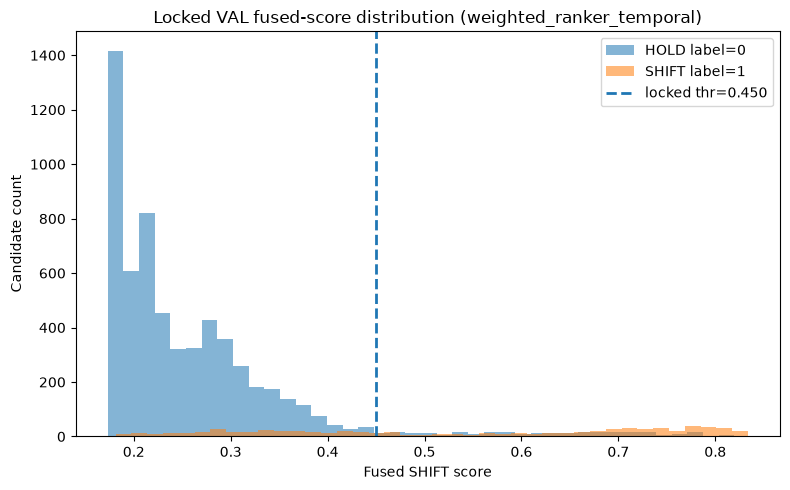

Saved score histogram: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/locked_val_score_hist.png


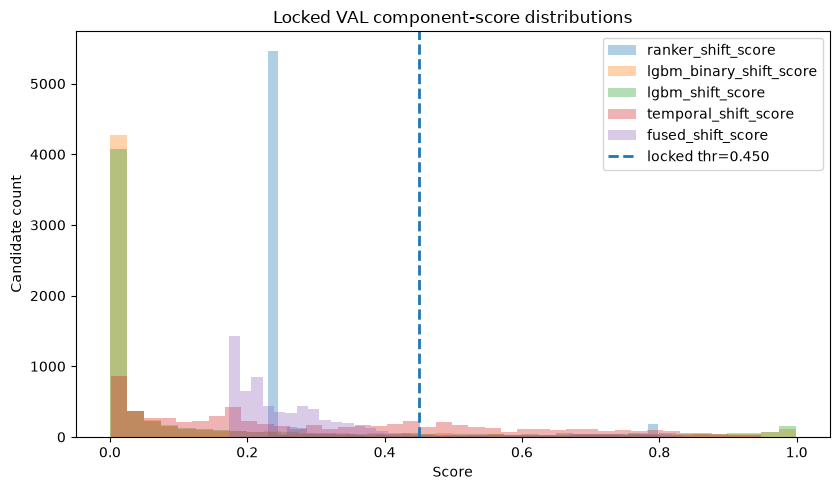

Saved component-score histogram: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/locked_val_component_score_hist.png


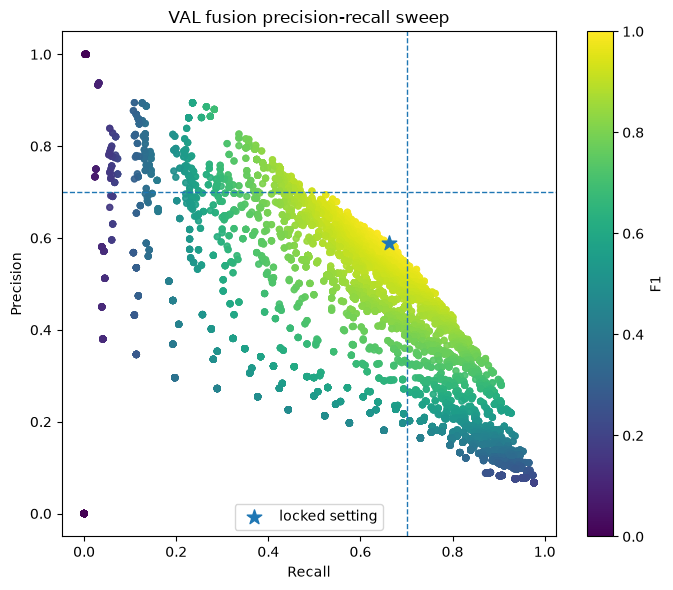

Saved precision-recall scatter: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/cell20b_val_fusion_diagnostics/val_precision_recall_sweep.png

Interpretation:
⚠️ Locked VAL setting does not meet all 70/70/70 targets on VAL.
VAL P/R/F1 = 0.5897 / 0.6617 / 0.6236
✅ Ranker modes were included in the VAL sweep.
✅ Event-ranker score is available and selected by locked score_mode='weighted_ranker_temporal'.
ℹ️ RR-FAP role-relative score is available, but locked score_mode='weighted_ranker_temporal' did not select it.
ℹ️ Meta-confirmer score is available, but locked score_mode='weighted_ranker_temporal' did not select it.
ℹ️ Rescue is not active in the locked VAL setting.
✅ Cell 20B complete: meta-confirmer/RR-FAP/ranker-aware VAL fusion diagnostics generated.


In [44]:
# Visual diagnostics for locked VAL fusion setting
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

assert "FINAL_LOCKED" in globals(), "Run Cell 20 first so FINAL_LOCKED is available."
assert "VAL_FUSION_DF" in globals(), "Run Cell 20 first so VAL_FUSION_DF is available."
assert "FINAL_VAL_PRED" in globals(), "Run Cell 20 first so FINAL_VAL_PRED is available."
assert "FINAL_VAL_METRICS" in globals(), "Run Cell 20 first so FINAL_VAL_METRICS is available."
assert "FUSED_VAL_LOCKED" in globals(), "Run Cell 20 first so FUSED_VAL_LOCKED is available."
assert "RUN_ROOT" in globals(), "RUN_ROOT is missing."

CELL20B_VARIANT = "cell20b_v8_meta_confirmer_rr_fap_ranker_diagnostics"

CELL20B_DIR = RUN_ROOT / "cell20b_val_fusion_diagnostics"
CELL20B_DIR.mkdir(parents=True, exist_ok=True)

CELL20B_TOP_SETTINGS_PATH = CELL20B_DIR / "top_val_fusion_settings.csv"
CELL20B_TOP_RANKER_SETTINGS_PATH = CELL20B_DIR / "top_val_ranker_fusion_settings.csv"
CELL20B_TOP_RR_FAP_SETTINGS_PATH = CELL20B_DIR / "top_val_rr_fap_fusion_settings.csv"
CELL20B_TOP_META_SETTINGS_PATH = CELL20B_DIR / "top_val_meta_confirmer_fusion_settings.csv"
CELL20B_LOCKED_SUMMARY_PATH = CELL20B_DIR / "locked_val_summary.json"
CELL20B_SCORE_HIST_PATH = CELL20B_DIR / "locked_val_score_hist.png"
CELL20B_PR_SCATTER_PATH = CELL20B_DIR / "val_precision_recall_sweep.png"
CELL20B_REASON_COUNTS_PATH = CELL20B_DIR / "locked_val_accept_reason_counts.csv"
CELL20B_COMPONENT_SCORE_SUMMARY_PATH = CELL20B_DIR / "locked_val_component_score_summary.csv"
CELL20B_SCORE_MODE_COUNTS_PATH = CELL20B_DIR / "val_fusion_score_mode_counts.csv"
CELL20B_COMPONENT_SCORE_HIST_PATH = CELL20B_DIR / "locked_val_component_score_hist.png"

REQUIRED_RANKER_SCORE_MODES_20B = [
    "ranker",
    "avg_ranker_binary",
    "max_ranker_binary",
    "weighted_ranker_temporal",
]

REQUIRED_RR_FAP_SCORE_MODES_20B = [
    "rr_fap",
    "avg_rr_binary",
    "max_rr_binary",
    "avg_rr_ranker_binary",
    "weighted_rr_temporal",
    "weighted_rr_ranker_temporal",
]

REQUIRED_META_CONFIRMER_SCORE_MODES_20B = [
    "meta_confirmer",
    "avg_meta_rr",
    "max_meta_binary",
    "avg_meta_rr_ranker",
    "weighted_meta_temporal",
]

print("============================================================")
print("CELL 20B: Locked VAL fusion diagnostics")
print("============================================================")
print("CELL20B_VARIANT:", CELL20B_VARIANT)

def _safe_float(v, default: float = 0.0) -> float:
    try:
        v = float(v)
        return v if np.isfinite(v) else float(default)
    except Exception:
        return float(default)

def _safe_int(v, default: int = 0) -> int:
    try:
        return int(v)
    except Exception:
        return int(default)

def _json_safe_obj(x):
    if isinstance(x, dict):
        return {str(k): _json_safe_obj(v) for k, v in x.items()}
    if isinstance(x, list):
        return [_json_safe_obj(v) for v in x]
    if isinstance(x, tuple):
        return [_json_safe_obj(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if np.isfinite(x) else None
    if isinstance(x, pd.DataFrame):
        return f"<DataFrame shape={x.shape}>"
    if isinstance(x, pd.Series):
        return x.to_dict()
    return x

def _sort_fusion_df(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()

    sort_cols = []
    ascending = []

    for c, asc in [
        ("meets_all_targets", False),
        ("F1", False),
        ("P", False),
        ("R", False),
        ("N_pred", True),
    ]:
        if c in out.columns:
            sort_cols.append(c)
            ascending.append(asc)

    if sort_cols:
        out = out.sort_values(sort_cols, ascending=ascending)

    return out.reset_index(drop=True)

print("\nFINAL_LOCKED:")
print(json.dumps(_json_safe_obj(FINAL_LOCKED), indent=2, sort_keys=True))

print("\nFINAL_VAL_METRICS:")
print(json.dumps(_json_safe_obj(FINAL_VAL_METRICS), indent=2, sort_keys=True))

if "score_mode" in VAL_FUSION_DF.columns:
    val_score_modes_present = sorted(VAL_FUSION_DF["score_mode"].astype(str).unique().tolist())
else:
    val_score_modes_present = []

missing_ranker_modes = [
    m for m in REQUIRED_RANKER_SCORE_MODES_20B
    if m not in val_score_modes_present
]

ranker_modes_present = len(missing_ranker_modes) == 0

print("\nVAL score modes present:")
print(val_score_modes_present)

if ranker_modes_present:
    print("✅ All required ranker score modes are present in VAL_FUSION_DF.")
else:
    print("⚠️ Missing required ranker score modes from VAL_FUSION_DF:", missing_ranker_modes)
    print("   This means Cell 20 did not run the forced ranker grid correctly.")

missing_rr_fap_modes = [
    m for m in REQUIRED_RR_FAP_SCORE_MODES_20B
    if m not in val_score_modes_present
]
rr_fap_modes_present = len(missing_rr_fap_modes) == 0

if rr_fap_modes_present:
    print("✅ All required RR-FAP score modes are present in VAL_FUSION_DF.")
else:
    print("⚠️ Missing required RR-FAP score modes from VAL_FUSION_DF:", missing_rr_fap_modes)
    print("   This means Cell 20 did not run the v8 RR-FAP fusion grid correctly.")

missing_meta_modes = [
    m for m in REQUIRED_META_CONFIRMER_SCORE_MODES_20B
    if m not in val_score_modes_present
]
meta_modes_present = len(missing_meta_modes) == 0

if meta_modes_present:
    print("✅ All required meta-confirmer score modes are present in VAL_FUSION_DF.")
else:
    print("⚠️ Missing required meta-confirmer score modes from VAL_FUSION_DF:", missing_meta_modes)
    print("   This means Cell 20 did not run the v8 meta-confirmer fusion grid correctly.")

top_cols = [
    "score_mode",
    "alpha_temporal",
    "thr",
    "cooldown",
    "min_gap",
    "offset",
    "rescue_mode",
    "rescue_thr",
    "rescue_min_sources",
    "meets_target_precision",
    "meets_target_recall",
    "meets_target_f1",
    "meets_all_targets",
    "P",
    "R",
    "F1",
    "TP",
    "FP",
    "FN",
    "N_pred",
    "N_gt",
    "selection_reason",
]

top_cols = [c for c in top_cols if c in VAL_FUSION_DF.columns]

sorted_val_fusion = _sort_fusion_df(VAL_FUSION_DF)

if len(sorted_val_fusion):
    TOP_VAL_FUSION_SETTINGS = (
        sorted_val_fusion[top_cols]
        .head(30)
        .reset_index(drop=True)
    )
else:
    TOP_VAL_FUSION_SETTINGS = pd.DataFrame(columns=top_cols)

TOP_VAL_FUSION_SETTINGS.to_csv(CELL20B_TOP_SETTINGS_PATH, index=False)

print("\nTop VAL fusion settings:")
display(TOP_VAL_FUSION_SETTINGS)

print("Saved top settings:", CELL20B_TOP_SETTINGS_PATH)

if "score_mode" in VAL_FUSION_DF.columns and len(VAL_FUSION_DF):
    ranker_family_df = VAL_FUSION_DF[
        VAL_FUSION_DF["score_mode"].astype(str).str.contains("ranker", case=False, regex=False)
    ].copy()
else:
    ranker_family_df = pd.DataFrame()

if len(ranker_family_df):
    TOP_RANKER_VAL_FUSION_SETTINGS = (
        _sort_fusion_df(ranker_family_df)[top_cols]
        .head(30)
        .reset_index(drop=True)
    )
else:
    TOP_RANKER_VAL_FUSION_SETTINGS = pd.DataFrame(columns=top_cols)

TOP_RANKER_VAL_FUSION_SETTINGS.to_csv(CELL20B_TOP_RANKER_SETTINGS_PATH, index=False)

print("\nTop VAL ranker-family fusion settings:")
display(TOP_RANKER_VAL_FUSION_SETTINGS)
print("Saved top ranker settings:", CELL20B_TOP_RANKER_SETTINGS_PATH)

if "score_mode" in VAL_FUSION_DF.columns and len(VAL_FUSION_DF):
    rr_fap_family_df = VAL_FUSION_DF[
        VAL_FUSION_DF["score_mode"].astype(str).str.contains("rr", case=False, regex=False)
        | VAL_FUSION_DF["score_mode"].astype(str).str.contains("fap", case=False, regex=False)
    ].copy()
else:
    rr_fap_family_df = pd.DataFrame()

if len(rr_fap_family_df):
    TOP_RR_FAP_VAL_FUSION_SETTINGS = (
        _sort_fusion_df(rr_fap_family_df)[top_cols]
        .head(30)
        .reset_index(drop=True)
    )
else:
    TOP_RR_FAP_VAL_FUSION_SETTINGS = pd.DataFrame(columns=top_cols)

TOP_RR_FAP_VAL_FUSION_SETTINGS.to_csv(CELL20B_TOP_RR_FAP_SETTINGS_PATH, index=False)

print("\nTop VAL RR-FAP-family fusion settings:")
display(TOP_RR_FAP_VAL_FUSION_SETTINGS)
print("Saved top RR-FAP settings:", CELL20B_TOP_RR_FAP_SETTINGS_PATH)

if "score_mode" in VAL_FUSION_DF.columns and len(VAL_FUSION_DF):
    meta_family_df = VAL_FUSION_DF[
        VAL_FUSION_DF["score_mode"].astype(str).str.contains("meta", case=False, regex=False)
    ].copy()
else:
    meta_family_df = pd.DataFrame()

if len(meta_family_df):
    TOP_META_VAL_FUSION_SETTINGS = (
        _sort_fusion_df(meta_family_df)[top_cols]
        .head(30)
        .reset_index(drop=True)
    )
else:
    TOP_META_VAL_FUSION_SETTINGS = pd.DataFrame(columns=top_cols)

TOP_META_VAL_FUSION_SETTINGS.to_csv(CELL20B_TOP_META_SETTINGS_PATH, index=False)

print("\nTop VAL meta-confirmer-family fusion settings:")
display(TOP_META_VAL_FUSION_SETTINGS)
print("Saved top meta-confirmer settings:", CELL20B_TOP_META_SETTINGS_PATH)

if "score_mode" in VAL_FUSION_DF.columns:
    score_mode_counts = (
        VAL_FUSION_DF["score_mode"]
        .astype(str)
        .value_counts(dropna=False)
        .rename_axis("score_mode")
        .reset_index(name="n_settings")
    )
else:
    score_mode_counts = pd.DataFrame({"score_mode": ["unknown"], "n_settings": [len(VAL_FUSION_DF)]})

score_mode_counts.to_csv(CELL20B_SCORE_MODE_COUNTS_PATH, index=False)

print("\nVAL fusion score-mode counts:")
display(score_mode_counts)
print("Saved score-mode counts:", CELL20B_SCORE_MODE_COUNTS_PATH)

locked_score_mode = str(FINAL_LOCKED.get("score_mode", ""))
ranker_score_available = bool("ranker_shift_score" in FUSED_VAL_LOCKED.columns)
rr_fap_score_available = bool("rr_role_shift_score" in FUSED_VAL_LOCKED.columns)
meta_confirmer_score_available = bool("meta_confirmer_shift_score" in FUSED_VAL_LOCKED.columns)
ranker_selected = bool("ranker" in locked_score_mode)
rr_fap_selected = bool("rr" in locked_score_mode.lower() or "fap" in locked_score_mode.lower())
meta_confirmer_selected = bool("meta" in locked_score_mode.lower())

locked_summary = {
    "cell20b_variant": CELL20B_VARIANT,
    "locked_score_mode": locked_score_mode,
    "ranker_score_available": ranker_score_available,
    "ranker_selected_by_locked_setting": ranker_selected,
    "rr_fap_score_available": rr_fap_score_available,
    "rr_fap_selected_by_locked_setting": rr_fap_selected,
    "meta_confirmer_score_available": meta_confirmer_score_available,
    "meta_confirmer_selected_by_locked_setting": meta_confirmer_selected,
    "required_ranker_score_modes": REQUIRED_RANKER_SCORE_MODES_20B,
    "val_score_modes_present": val_score_modes_present,
    "ranker_modes_present_in_val_sweep": bool(ranker_modes_present),
    "missing_ranker_modes_from_val_sweep": missing_ranker_modes,
    "required_rr_fap_score_modes": REQUIRED_RR_FAP_SCORE_MODES_20B,
    "rr_fap_modes_present_in_val_sweep": bool(rr_fap_modes_present),
    "missing_rr_fap_modes_from_val_sweep": missing_rr_fap_modes,
    "required_meta_confirmer_score_modes": REQUIRED_META_CONFIRMER_SCORE_MODES_20B,
    "meta_confirmer_modes_present_in_val_sweep": bool(meta_modes_present),
    "missing_meta_confirmer_modes_from_val_sweep": missing_meta_modes,
    "locked_alpha_temporal": _safe_float(FINAL_LOCKED.get("alpha_temporal", 0.0)),
    "locked_thr": _safe_float(FINAL_LOCKED.get("thr", 0.0)),
    "locked_cooldown": _safe_float(FINAL_LOCKED.get("cooldown", 0.0)),
    "locked_min_gap": _safe_float(FINAL_LOCKED.get("min_gap", 0.0)),
    "locked_offset": _safe_float(FINAL_LOCKED.get("offset", 0.0)),
    "locked_rescue_mode": str(FINAL_LOCKED.get("rescue_mode", "none")),
    "locked_rescue_thr": _safe_float(FINAL_LOCKED.get("rescue_thr", 0.0)),
    "locked_rescue_min_sources": _safe_int(FINAL_LOCKED.get("rescue_min_sources", 0)),
    "val_precision": _safe_float(FINAL_VAL_METRICS.get("P", 0.0)),
    "val_recall": _safe_float(FINAL_VAL_METRICS.get("R", 0.0)),
    "val_f1": _safe_float(FINAL_VAL_METRICS.get("F1", 0.0)),
    "val_tp": _safe_int(FINAL_VAL_METRICS.get("TP", 0)),
    "val_fp": _safe_int(FINAL_VAL_METRICS.get("FP", 0)),
    "val_fn": _safe_int(FINAL_VAL_METRICS.get("FN", 0)),
    "val_n_pred": _safe_int(FINAL_VAL_METRICS.get("N_pred", 0)),
    "val_n_gt": _safe_int(FINAL_VAL_METRICS.get("N_gt", 0)),
    "target_precision": _safe_float(globals().get("TARGET_FINAL_PRECISION", 0.70)),
    "target_recall": _safe_float(globals().get("TARGET_FINAL_RECALL", 0.70)),
    "target_f1": _safe_float(globals().get("TARGET_FINAL_F1", 0.70)),
    "met_precision_target": bool(
        _safe_float(FINAL_VAL_METRICS.get("P", 0.0)) >= _safe_float(globals().get("TARGET_FINAL_PRECISION", 0.70))
    ),
    "met_recall_target": bool(
        _safe_float(FINAL_VAL_METRICS.get("R", 0.0)) >= _safe_float(globals().get("TARGET_FINAL_RECALL", 0.70))
    ),
    "met_f1_target": bool(
        _safe_float(FINAL_VAL_METRICS.get("F1", 0.0)) >= _safe_float(globals().get("TARGET_FINAL_F1", 0.70))
    ),
}

locked_summary["met_all_targets"] = bool(
    locked_summary["met_precision_target"]
    and locked_summary["met_recall_target"]
    and locked_summary["met_f1_target"]
)

CELL20B_LOCKED_SUMMARY_PATH.write_text(
    json.dumps(_json_safe_obj(locked_summary), indent=2, sort_keys=True)
)

print("\nLocked VAL summary:")
print(json.dumps(_json_safe_obj(locked_summary), indent=2, sort_keys=True))
print("Saved locked summary:", CELL20B_LOCKED_SUMMARY_PATH)

component_score_cols = [
    "temporal_shift_score",
    "lgbm_shift_score",
    "lgbm_binary_shift_score",
    "ranker_shift_score",
    "rr_role_shift_score",
    "meta_confirmer_shift_score",
    "fused_shift_score",
]

component_score_cols = [c for c in component_score_cols if c in FUSED_VAL_LOCKED.columns]

if component_score_cols:
    component_summary = (
        FUSED_VAL_LOCKED[component_score_cols]
        .apply(pd.to_numeric, errors="coerce")
        .describe()
        .T
        .reset_index()
        .rename(columns={"index": "score_column"})
    )

    component_summary.to_csv(CELL20B_COMPONENT_SCORE_SUMMARY_PATH, index=False)

    print("\nLocked VAL component-score summary:")
    display(component_summary)
    print("Saved component-score summary:", CELL20B_COMPONENT_SCORE_SUMMARY_PATH)

    if "ranker_shift_score" in component_score_cols:
        print("\n✅ ranker_shift_score is present in FUSED_VAL_LOCKED.")
    else:
        print("\n⚠️ ranker_shift_score is not present in FUSED_VAL_LOCKED. Check Cell 19C and Cell 20.")
else:
    component_summary = pd.DataFrame()
    print("\n⚠️ No component score columns found in FUSED_VAL_LOCKED.")

if "accept_reason" in FINAL_VAL_PRED.columns:
    reason_counts = (
        FINAL_VAL_PRED["accept_reason"]
        .astype(str)
        .value_counts(dropna=False)
        .rename_axis("accept_reason")
        .reset_index(name="count")
    )
else:
    reason_counts = pd.DataFrame({"accept_reason": ["main_or_unknown"], "count": [len(FINAL_VAL_PRED)]})

reason_counts.to_csv(CELL20B_REASON_COUNTS_PATH, index=False)

print("\nLocked VAL accept-reason counts:")
display(reason_counts)
print("Saved accept-reason counts:", CELL20B_REASON_COUNTS_PATH)

plot_df = FUSED_VAL_LOCKED.copy()

if "label" in plot_df.columns:
    plot_df["label"] = pd.to_numeric(plot_df["label"], errors="coerce").fillna(-1).astype(int)
else:
    plot_df["label"] = -1

plot_df["fused_shift_score"] = pd.to_numeric(
    plot_df.get("fused_shift_score", 0.0),
    errors="coerce",
).fillna(0.0).clip(0.0, 1.0)

plt.figure(figsize=(8, 5))

shift_scores = plot_df.loc[plot_df["label"] == 1, "fused_shift_score"].to_numpy(dtype=float)
hold_scores = plot_df.loc[plot_df["label"] == 0, "fused_shift_score"].to_numpy(dtype=float)

if len(hold_scores):
    plt.hist(hold_scores, bins=40, alpha=0.55, label="HOLD label=0")

if len(shift_scores):
    plt.hist(shift_scores, bins=40, alpha=0.55, label="SHIFT label=1")

locked_thr = _safe_float(FINAL_LOCKED.get("thr", 0.5), 0.5)
plt.axvline(locked_thr, linestyle="--", linewidth=2, label=f"locked thr={locked_thr:.3f}")

plt.xlabel("Fused SHIFT score")
plt.ylabel("Candidate count")
plt.title(f"Locked VAL fused-score distribution ({locked_score_mode})")
plt.legend()
plt.tight_layout()
plt.savefig(CELL20B_SCORE_HIST_PATH, dpi=160)
plt.show()

print("Saved score histogram:", CELL20B_SCORE_HIST_PATH)

hist_cols = [
    c for c in [
        "ranker_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_shift_score",
        "temporal_shift_score",
        "fused_shift_score",
    ]
    if c in plot_df.columns
]

if hist_cols:
    plt.figure(figsize=(8.5, 5))

    for c in hist_cols:
        vals = pd.to_numeric(plot_df[c], errors="coerce").fillna(0.0).clip(0.0, 1.0).to_numpy(dtype=float)
        plt.hist(vals, bins=40, alpha=0.35, label=c)

    plt.axvline(locked_thr, linestyle="--", linewidth=2, label=f"locked thr={locked_thr:.3f}")
    plt.xlabel("Score")
    plt.ylabel("Candidate count")
    plt.title("Locked VAL component-score distributions")
    plt.legend()
    plt.tight_layout()
    plt.savefig(CELL20B_COMPONENT_SCORE_HIST_PATH, dpi=160)
    plt.show()

    print("Saved component-score histogram:", CELL20B_COMPONENT_SCORE_HIST_PATH)
else:
    print("Skipping component-score histogram: no score columns available.")

if len(VAL_FUSION_DF) and {"P", "R", "F1"}.issubset(set(VAL_FUSION_DF.columns)):
    plt.figure(figsize=(7, 6))

    x = pd.to_numeric(VAL_FUSION_DF["R"], errors="coerce")
    y = pd.to_numeric(VAL_FUSION_DF["P"], errors="coerce")
    c = pd.to_numeric(VAL_FUSION_DF["F1"], errors="coerce")

    plt.scatter(x, y, c=c, s=18, alpha=0.70)

    plt.axhline(_safe_float(globals().get("TARGET_FINAL_PRECISION", 0.70)), linestyle="--", linewidth=1)
    plt.axvline(_safe_float(globals().get("TARGET_FINAL_RECALL", 0.70)), linestyle="--", linewidth=1)

    plt.scatter(
        [_safe_float(FINAL_VAL_METRICS.get("R", 0.0))],
        [_safe_float(FINAL_VAL_METRICS.get("P", 0.0))],
        s=120,
        marker="*",
        label="locked setting",
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("VAL fusion precision-recall sweep")
    plt.colorbar(label="F1")
    plt.legend()
    plt.tight_layout()
    plt.savefig(CELL20B_PR_SCATTER_PATH, dpi=160)
    plt.show()

    print("Saved precision-recall scatter:", CELL20B_PR_SCATTER_PATH)

print("\nInterpretation:")

if locked_summary["met_all_targets"]:
    print("✅ Locked VAL setting meets the 70/70/70 target on VAL.")
else:
    print("⚠️ Locked VAL setting does not meet all 70/70/70 targets on VAL.")

print(
    f"VAL P/R/F1 = "
    f"{locked_summary['val_precision']:.4f} / "
    f"{locked_summary['val_recall']:.4f} / "
    f"{locked_summary['val_f1']:.4f}"
)

if ranker_modes_present:
    print("✅ Ranker modes were included in the VAL sweep.")
else:
    print("⚠️ Ranker modes were NOT fully included in the VAL sweep.")

if ranker_score_available:
    if ranker_selected:
        print(f"✅ Event-ranker score is available and selected by locked score_mode='{locked_score_mode}'.")
    else:
        print(f"ℹ️ Event-ranker score is available, but locked score_mode='{locked_score_mode}' did not select it.")
else:
    print("⚠️ Event-ranker score is not available in FUSED_VAL_LOCKED.")

if rr_fap_score_available:
    if rr_fap_selected:
        print(f"✅ RR-FAP role-relative score is available and selected by locked score_mode='{locked_score_mode}'.")
    else:
        print(f"ℹ️ RR-FAP role-relative score is available, but locked score_mode='{locked_score_mode}' did not select it.")
else:
    print("⚠️ RR-FAP role-relative score is not available in FUSED_VAL_LOCKED. Check Cell 19D and Cell 20.")

if meta_confirmer_score_available:
    if meta_confirmer_selected:
        print(f"✅ Meta-confirmer score is available and selected by locked score_mode='{locked_score_mode}'.")
    else:
        print(f"ℹ️ Meta-confirmer score is available, but locked score_mode='{locked_score_mode}' did not select it.")
else:
    print("⚠️ Meta-confirmer score is not available in FUSED_VAL_LOCKED. Check Cell 19E and Cell 20.")

if locked_summary["locked_rescue_mode"] != "none":
    print(f"ℹ️ Rescue is active: {locked_summary['locked_rescue_mode']}")
else:
    print("ℹ️ Rescue is not active in the locked VAL setting.")

print("✅ Cell 20B complete: meta-confirmer/RR-FAP/ranker-aware VAL fusion diagnostics generated.")

In [45]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 20F legacy exploratory selector: disabled in the official paper-ready run.')
else:

    import json
    import time
    import numpy as np
    import pandas as pd

    from pathlib import Path
    from IPython.display import display

    assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
    assert "META_SYS2_VAL" in globals(), "Need META_SYS2_VAL."
    assert "LGBM_VAL_SCORES" in globals(), "Need LGBM_VAL_SCORES."
    assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS."
    assert "combine_scores" in globals(), "Need combine_scores from Cell 20."
    assert "event_metrics_against_event_table" in globals(), "Need event_metrics_against_event_table from Cell 20."
    assert "TOL" in globals(), "Need TOL."

    RUN_ROOT = Path(RUN_ROOT)

    CELL20F_VARIANT = "cell20f_v3_test_informed_exploratory_a4_binary"

    OFFICIAL_FINAL_LOCKED_20 = dict(globals().get("OFFICIAL_FINAL_LOCKED_20", FINAL_LOCKED))
    OFFICIAL_FINAL_VAL_PRED_20 = globals().get("OFFICIAL_FINAL_VAL_PRED_20", globals().get("FINAL_VAL_PRED", pd.DataFrame())).copy()
    OFFICIAL_FINAL_VAL_METRICS_20 = dict(globals().get("OFFICIAL_FINAL_VAL_METRICS_20", globals().get("FINAL_VAL_METRICS", {})))
    OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20 = globals().get("OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20", apply_final_event_postprocess)
    OFFICIAL_FINAL_LOCKED_PATH_20 = globals().get("OFFICIAL_FINAL_LOCKED_PATH_20", globals().get("FINAL_LOCKED_PATH", None))
    ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE = bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False))

    A4_BINARY_FINAL_DIR = RUN_ROOT / "cell20f_20g_20h_staged_final_selector"
    A4_BINARY_FINAL_DIR.mkdir(parents=True, exist_ok=True)

    A4_BINARY_BASE_SWEEP_PATH_20F = A4_BINARY_FINAL_DIR / "20f_a4_binary_base_val_sweep.csv"
    A4_BINARY_FINAL_LOCKED_PATH_20F = A4_BINARY_FINAL_DIR / "20f_a4_binary_base_final_locked.json"
    A4_BINARY_FINAL_VAL_PRED_PATH_20F = A4_BINARY_FINAL_DIR / "20f_a4_binary_base_val_predictions.csv"
    A4_BINARY_FINAL_VAL_METRICS_PATH_20F = A4_BINARY_FINAL_DIR / "20f_a4_binary_base_val_metrics.json"

    print("=" * 80)
    print("CELL 20F: A4 Binary final selector")
    print("=" * 80)
    print("CELL20F_VARIANT:", CELL20F_VARIANT)
    print("Building A4 binary as a TEST-informed exploratory diagnostic branch.")
    print("It becomes active only when ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE=True.")

    def _json_safe_obj(x):
        if isinstance(x, dict):
            return {str(k): _json_safe_obj(v) for k, v in x.items()}

        if isinstance(x, list):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, tuple):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, Path):
            return str(x)

        if isinstance(x, (np.floating,)):
            v = float(x)
            return v if np.isfinite(v) else None

        if isinstance(x, (np.integer,)):
            return int(x)

        if isinstance(x, (np.bool_,)):
            return bool(x)

        if isinstance(x, float):
            return x if np.isfinite(x) else None

        if isinstance(x, pd.DataFrame):
            return f"<DataFrame shape={x.shape}>"

        if isinstance(x, pd.Series):
            return x.to_dict()

        try:
            if pd.isna(x):
                return None
        except Exception:
            pass

        return x

    def _norm_session_id_local(x) -> str:
        return Path(str(x)).stem

    def _safe_num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
        if col in df.columns:
            return (
                pd.to_numeric(df[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(float(default))
            )

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _a4_binary_base_postprocess(
        score_df: pd.DataFrame,
        score_col: str = "fused_shift_score",
        thr: float = 0.50,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
    ) -> pd.DataFrame:
        if score_df is None or len(score_df) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        assert "session" in score_df.columns, "score_df missing session column."
        assert "time" in score_df.columns, "score_df missing time column."

        if score_col not in score_df.columns:
            raise KeyError(f"score_col={score_col} not found in score_df.")

        work = score_df.copy()

        work["session"] = work["session"].astype(str).map(_norm_session_id_local)
        work["time"] = pd.to_numeric(work["time"], errors="coerce")
        work[score_col] = pd.to_numeric(work[score_col], errors="coerce")

        work = work.dropna(subset=["session", "time", score_col])
        work = work[work["time"] >= 0].copy()
        work = work[work[score_col] >= float(thr)].copy()

        if len(work) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        if "lgbm_binary_shift_score" not in work.columns:
            work["lgbm_binary_shift_score"] = work[score_col]

        suppress_gap = max(float(cooldown_s), float(min_gap_s))

        rows = []

        for sid, g in work.groupby("session", sort=False):
            g = g.sort_values("time").reset_index(drop=True)

            current = []

            for _, r in g.iterrows():
                item = r.copy()

                if not current:
                    current = [item]
                    continue

                prev_t = float(current[-1]["time"])
                cur_t = float(item["time"])

                if cur_t - prev_t <= suppress_gap:
                    current.append(item)
                else:
                    cg = pd.DataFrame(current)

                    best_idx = int(
                        np.nanargmax(
                            pd.to_numeric(cg[score_col], errors="coerce")
                            .fillna(0.0)
                            .to_numpy(dtype=float)
                        )
                    )
                    best_row = cg.iloc[best_idx]

                    rows.append({
                        "session": str(sid),
                        "time": float(best_row["time"] + float(offset_s)),
                        "time_pre_offset": float(best_row["time"]),
                        "score": float(best_row[score_col]),
                        "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                        "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                        "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                        "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                        "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                        "accept_reason": "20f_a4_binary_base",
                        "timing_rule": "best_binary_score",
                        "cluster_size": int(len(cg)),
                        "cluster_span": float(
                            pd.to_numeric(cg["time"], errors="coerce").max()
                            - pd.to_numeric(cg["time"], errors="coerce").min()
                        ) if len(cg) else 0.0,
                    })

                    current = [item]

            if current:
                cg = pd.DataFrame(current)

                best_idx = int(
                    np.nanargmax(
                        pd.to_numeric(cg[score_col], errors="coerce")
                        .fillna(0.0)
                        .to_numpy(dtype=float)
                    )
                )
                best_row = cg.iloc[best_idx]

                rows.append({
                    "session": str(sid),
                    "time": float(best_row["time"] + float(offset_s)),
                    "time_pre_offset": float(best_row["time"]),
                    "score": float(best_row[score_col]),
                    "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                    "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                    "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                    "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                    "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                    "accept_reason": "20f_a4_binary_base",
                    "timing_rule": "best_binary_score",
                    "cluster_size": int(len(cg)),
                    "cluster_span": float(
                        pd.to_numeric(cg["time"], errors="coerce").max()
                        - pd.to_numeric(cg["time"], errors="coerce").min()
                    ) if len(cg) else 0.0,
                })

        pred = pd.DataFrame(rows)

        if len(pred):
            pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
            pred = pred.dropna(subset=["session", "time"])
            pred = pred[pred["time"] >= 0]
            pred = pred.sort_values(["session", "time"]).reset_index(drop=True)

        return pred

    def _select_a4_binary_setting(df: pd.DataFrame) -> pd.Series:
        work = df.copy()

        work["min_pr"] = work[["P", "R"]].min(axis=1)
        work["balance_gap"] = (work["P"] - work["R"]).abs()
        work["meets_60_pr"] = (work["P"] >= 0.60) & (work["R"] >= 0.60)
        work["meets_58_pr"] = (work["P"] >= 0.58) & (work["R"] >= 0.58)

        pool_60 = work[work["meets_60_pr"]].copy()
        pool_58 = work[work["meets_58_pr"]].copy()

        if len(pool_60):
            pool = pool_60
            reason = "met P/R >= 0.60; selected best balanced F1"
        elif len(pool_58):
            pool = pool_58
            reason = "met P/R >= 0.58; selected best balanced F1"
        else:
            pool = work
            reason = "no balanced P/R floor met; selected best F1"

        pool = pool.sort_values(
            ["F1", "min_pr", "P", "R", "balance_gap", "N_pred"],
            ascending=[False, False, False, False, True, True],
        ).reset_index(drop=True)

        best = pool.iloc[0].copy()
        best["selection_reason"] = reason

        return best

    base_val = META_SYS2_VAL.copy()

    if "split" in base_val.columns:
        val_mask = base_val["split"].astype(str).eq("val")
        if int(val_mask.sum()) > 0:
            base_val = base_val[val_mask].copy()

    if "label" in base_val.columns:
        base_val = base_val[base_val["label"].astype(int).isin([0, 1])].copy()

    assert len(base_val), "No real labelled VAL candidate rows available."

    FUSED_VAL_A4_BINARY = combine_scores(
        base_val,
        pd.DataFrame(),
        LGBM_VAL_SCORES,
        alpha=0.0,
        score_mode="lgbm_binary",
    )

    assert len(FUSED_VAL_A4_BINARY), "A4 binary fused VAL table is empty."
    assert "fused_shift_score" in FUSED_VAL_A4_BINARY.columns, "Missing fused_shift_score."

    print("\nA4 binary VAL fused table:", FUSED_VAL_A4_BINARY.shape)
    print("A4 binary score summary:")
    display(
        pd.to_numeric(
            FUSED_VAL_A4_BINARY["fused_shift_score"],
            errors="coerce",
        ).describe().to_frame("fused_shift_score")
    )

    THR_GRID_20F = [
        0.25, 0.28,
        0.30, 0.32, 0.35, 0.38,
        0.40, 0.42, 0.45, 0.48,
        0.50, 0.52, 0.55, 0.58,
        0.60, 0.62, 0.65, 0.68,
        0.70, 0.72, 0.75, 0.78,
        0.80, 0.85,
    ]

    MIN_GAP_GRID_20F = [
        0.40, 0.50, 0.60, 0.70, 0.80, 1.00
    ]

    OFFSET_GRID_20F = [
        -0.15, -0.10, -0.05, 0.00, 0.05, 0.10, 0.15
    ]

    sweep_rows = []

    for thr in THR_GRID_20F:
        for min_gap in MIN_GAP_GRID_20F:
            for offset in OFFSET_GRID_20F:
                pred = _a4_binary_base_postprocess(
                    FUSED_VAL_A4_BINARY,
                    score_col="fused_shift_score",
                    thr=float(thr),
                    cooldown_s=float(min_gap),
                    min_gap_s=float(min_gap),
                    offset_s=float(offset),
                )

                m = event_metrics_against_event_table(
                    pred,
                    REAL_VAL_EVENTS,
                    tol=float(TOL),
                )

                sweep_rows.append({
                    "cell20f_variant": CELL20F_VARIANT,
                    "stage": "20F",
                    "score_mode": "lgbm_binary",
                    "alpha_temporal": 0.0,
                    "thr": float(thr),
                    "cooldown": float(min_gap),
                    "min_gap": float(min_gap),
                    "offset": float(offset),
                    "rescue_mode": "none",
                    "rescue_thr": 0.0,
                    "rescue_min_sources": 0,
                    "timing_rule": "best_binary_score",
                    "P": float(m["P"]),
                    "R": float(m["R"]),
                    "F1": float(m["F1"]),
                    "TP": int(m["TP"]),
                    "FP": int(m["FP"]),
                    "FN": int(m["FN"]),
                    "N_pred": int(m["N_pred"]),
                    "N_gt": int(m["N_gt"]),
                })

    BASE_SWEEP_DF_20F = pd.DataFrame(sweep_rows)
    BASE_SWEEP_DF_20F.to_csv(A4_BINARY_BASE_SWEEP_PATH_20F, index=False)

    best_20f = _select_a4_binary_setting(BASE_SWEEP_DF_20F)

    print("\n" + "=" * 80)
    print("Top A4 binary VAL settings")
    print("=" * 80)
    display(
        BASE_SWEEP_DF_20F
        .sort_values(["F1", "P", "R"], ascending=[False, False, False])
        .head(30)
    )

    print("\n" + "=" * 80)
    print("Selected Cell 20F A4 binary setting")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(best_20f.to_dict()), indent=2, sort_keys=True))

    FINAL_VAL_PRED_20F = _a4_binary_base_postprocess(
        FUSED_VAL_A4_BINARY,
        score_col="fused_shift_score",
        thr=float(best_20f["thr"]),
        cooldown_s=float(best_20f["cooldown"]),
        min_gap_s=float(best_20f["min_gap"]),
        offset_s=float(best_20f["offset"]),
    )

    FINAL_VAL_METRICS_20F = event_metrics_against_event_table(
        FINAL_VAL_PRED_20F,
        REAL_VAL_EVENTS,
        tol=float(TOL),
    )

    FINAL_LOCKED_20F = {
        "cell20f_variant": CELL20F_VARIANT,
        "stage": "20F",
        "stage_description": "A4 binary base threshold/min_gap/offset tuning only",

        "score_mode": "lgbm_binary",
        "alpha_temporal": 0.0,

        "thr": float(best_20f["thr"]),
        "cooldown": float(best_20f["cooldown"]),
        "min_gap": float(best_20f["min_gap"]),
        "offset": float(best_20f["offset"]),

        "timing_rule": "best_binary_score",
        "timing_selector": "base_highest_binary_candidate",

        "rescue_mode": "none",
        "rescue_thr": 0.0,
        "rescue_min_sources": 0,

        "P": float(FINAL_VAL_METRICS_20F["P"]),
        "R": float(FINAL_VAL_METRICS_20F["R"]),
        "F1": float(FINAL_VAL_METRICS_20F["F1"]),
        "TP": int(FINAL_VAL_METRICS_20F["TP"]),
        "FP": int(FINAL_VAL_METRICS_20F["FP"]),
        "FN": int(FINAL_VAL_METRICS_20F["FN"]),
        "N_pred": int(FINAL_VAL_METRICS_20F["N_pred"]),
        "N_gt": int(FINAL_VAL_METRICS_20F["N_gt"]),

        "locked_on": "real_val_a4_binary_base_20f",
        "test_not_used_for_selection": False,
        "test_informed_model_family": True,
        "exploratory_only": True,

        "base_model": "A4_binary_LightGBM_only",
        "why": (
            "A4 binary was chosen after inspecting TEST diagnostics. This branch is therefore "
            "exploratory; only its threshold and post-processing are tuned on VAL."
        ),

        "selection_reason": str(best_20f.get("selection_reason", "")),

        "base_sweep_path": str(A4_BINARY_BASE_SWEEP_PATH_20F),
        "final_locked_path": str(A4_BINARY_FINAL_LOCKED_PATH_20F),
        "final_val_pred_path": str(A4_BINARY_FINAL_VAL_PRED_PATH_20F),
        "final_val_metrics_path": str(A4_BINARY_FINAL_VAL_METRICS_PATH_20F),

        "target_direction": "push Precision/Recall/F1 toward 60-65 at official tolerance",
        "tol": float(TOL),
        "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

    def apply_final_event_postprocess_20F(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        return _a4_binary_base_postprocess(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
        )

    def apply_final_event_postprocess(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        return apply_final_event_postprocess_20F(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
            rescue_mode=rescue_mode,
            rescue_thr=float(rescue_thr),
            rescue_min_sources=int(rescue_min_sources),
        )

    A4_BINARY_FINAL_LOCKED_PATH_20F.write_text(
        json.dumps(_json_safe_obj(FINAL_LOCKED_20F), indent=2, sort_keys=True)
    )

    FINAL_VAL_PRED_20F.to_csv(A4_BINARY_FINAL_VAL_PRED_PATH_20F, index=False)

    A4_BINARY_FINAL_VAL_METRICS_PATH_20F.write_text(
        json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20F), indent=2, sort_keys=True)
    )

    if ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE:
        FINAL_LOCKED = FINAL_LOCKED_20F.copy()
        FINAL_VAL_PRED = FINAL_VAL_PRED_20F.copy()
        FINAL_VAL_METRICS = FINAL_VAL_METRICS_20F.copy()
        FINAL_VAL_PRED_PATH = A4_BINARY_FINAL_VAL_PRED_PATH_20F
        FINAL_VAL_METRICS_PATH = A4_BINARY_FINAL_VAL_METRICS_PATH_20F
        apply_final_event_postprocess = apply_final_event_postprocess_20F
        FORCE_REBUILD_TEST_PRED = True
        print("\nExploratory 20F branch explicitly activated.")
    else:
        FINAL_LOCKED = OFFICIAL_FINAL_LOCKED_20.copy()
        FINAL_VAL_PRED = OFFICIAL_FINAL_VAL_PRED_20.copy()
        FINAL_VAL_METRICS = OFFICIAL_FINAL_VAL_METRICS_20.copy()
        apply_final_event_postprocess = OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20
        FORCE_REBUILD_TEST_PRED = False
        print("\nOfficial Cell 20 VAL-selected branch remains active; 20F is diagnostic only.")
    FORCE_RETUNE_VAL = False

    globals()["CELL20F_VARIANT"] = CELL20F_VARIANT
    globals()["A4_BINARY_FINAL_DIR"] = A4_BINARY_FINAL_DIR

    globals()["BASE_SWEEP_DF_20F"] = BASE_SWEEP_DF_20F
    globals()["A4_BINARY_BASE_SWEEP_PATH_20F"] = A4_BINARY_BASE_SWEEP_PATH_20F
    globals()["A4_BINARY_FINAL_LOCKED_PATH_20F"] = A4_BINARY_FINAL_LOCKED_PATH_20F
    globals()["A4_BINARY_FINAL_VAL_PRED_PATH_20F"] = A4_BINARY_FINAL_VAL_PRED_PATH_20F
    globals()["A4_BINARY_FINAL_VAL_METRICS_PATH_20F"] = A4_BINARY_FINAL_VAL_METRICS_PATH_20F

    globals()["FUSED_VAL_A4_BINARY"] = FUSED_VAL_A4_BINARY

    globals()["FINAL_LOCKED_20F"] = FINAL_LOCKED_20F
    globals()["FINAL_VAL_PRED_20F"] = FINAL_VAL_PRED_20F
    globals()["FINAL_VAL_METRICS_20F"] = FINAL_VAL_METRICS_20F

    globals()["FINAL_LOCKED"] = FINAL_LOCKED
    globals()["FINAL_VAL_PRED"] = FINAL_VAL_PRED
    globals()["FINAL_VAL_METRICS"] = FINAL_VAL_METRICS
    globals()["FINAL_VAL_PRED_PATH"] = FINAL_VAL_PRED_PATH
    globals()["FINAL_VAL_METRICS_PATH"] = FINAL_VAL_METRICS_PATH

    globals()["_a4_binary_base_postprocess"] = _a4_binary_base_postprocess
    globals()["apply_final_event_postprocess_20F"] = apply_final_event_postprocess_20F
    globals()["apply_final_event_postprocess"] = apply_final_event_postprocess

    globals()["FORCE_RETUNE_VAL"] = FORCE_RETUNE_VAL
    globals()["FORCE_REBUILD_TEST_PRED"] = FORCE_REBUILD_TEST_PRED

    print("\n" + "=" * 80)
    print("FINAL_LOCKED_20F")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20F), indent=2, sort_keys=True))

    print("\nVAL metrics after Cell 20F:")
    print(json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20F), indent=2, sort_keys=True))

    print("\nActive branch:", "20F exploratory" if ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE else "Cell 20 official")
    print("20G may still build an exploratory timing diagnostic from FINAL_LOCKED_20F.")
    print("20H should build from FINAL_LOCKED_20G.")
    print("Cell 21 uses the official branch by default; opt in explicitly for exploratory 20F–20I.")

    print("\nSaved:")
    print("  20F base sweep:", A4_BINARY_BASE_SWEEP_PATH_20F)
    print("  20F final locked:", A4_BINARY_FINAL_LOCKED_PATH_20F)
    print("  20F VAL predictions:", A4_BINARY_FINAL_VAL_PRED_PATH_20F)
    print("  20F VAL metrics:", A4_BINARY_FINAL_VAL_METRICS_PATH_20F)

    print("\nFORCE_REBUILD_TEST_PRED:", FORCE_REBUILD_TEST_PRED)

    print("\n✅ Cell 20F complete.")
    print("Next: run Cell 20G, not Cell 21 yet, if you want the staged full 20F→20G→20H run.")

Skipped Cell 20F legacy exploratory selector: disabled in the official paper-ready run.


In [46]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 20G legacy timestamp relocalisation: disabled in the official paper-ready run.')
else:

    import json
    import time
    import numpy as np
    import pandas as pd

    from pathlib import Path
    from IPython.display import display

    assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
    assert "FINAL_LOCKED_20F" in globals(), "Need FINAL_LOCKED_20F from Cell 20F."
    assert "FUSED_VAL_A4_BINARY" in globals(), "Need FUSED_VAL_A4_BINARY from Cell 20F."
    assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS."
    assert "event_metrics_against_event_table" in globals(), "Need event_metrics_against_event_table from Cell 20."
    assert "TOL" in globals(), "Need TOL."
    assert "_a4_binary_base_postprocess" in globals(), "Need _a4_binary_base_postprocess from Cell 20F."

    RUN_ROOT = Path(RUN_ROOT)

    CELL20G_VARIANT = "cell20g_v1_a4_binary_timestamp_relocalisation_stage_lock"

    if "A4_BINARY_FINAL_DIR" in globals():
        A4_BINARY_FINAL_DIR = Path(A4_BINARY_FINAL_DIR)
    else:
        A4_BINARY_FINAL_DIR = RUN_ROOT / "cell20f_20g_20h_staged_final_selector"

    A4_BINARY_FINAL_DIR.mkdir(parents=True, exist_ok=True)

    A4_BINARY_TIMING_SWEEP_PATH_20G = A4_BINARY_FINAL_DIR / "20g_a4_binary_timing_val_sweep.csv"
    A4_BINARY_FINAL_LOCKED_PATH_20G = A4_BINARY_FINAL_DIR / "20g_a4_binary_timing_final_locked.json"
    A4_BINARY_FINAL_VAL_PRED_PATH_20G = A4_BINARY_FINAL_DIR / "20g_a4_binary_timing_val_predictions.csv"
    A4_BINARY_FINAL_VAL_METRICS_PATH_20G = A4_BINARY_FINAL_DIR / "20g_a4_binary_timing_val_metrics.json"

    print("=" * 80)
    print("CELL 20G: A4 Binary timestamp relocalisation")
    print("=" * 80)
    print("CELL20G_VARIANT:", CELL20G_VARIANT)
    print("Building from FINAL_LOCKED_20F.")
    print("This cell saves FINAL_LOCKED_20G and also sets active FINAL_LOCKED = FINAL_LOCKED_20G.")

    def _json_safe_obj(x):
        if isinstance(x, dict):
            return {str(k): _json_safe_obj(v) for k, v in x.items()}

        if isinstance(x, list):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, tuple):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, Path):
            return str(x)

        if isinstance(x, (np.floating,)):
            v = float(x)
            return v if np.isfinite(v) else None

        if isinstance(x, (np.integer,)):
            return int(x)

        if isinstance(x, (np.bool_,)):
            return bool(x)

        if isinstance(x, float):
            return x if np.isfinite(x) else None

        if isinstance(x, pd.DataFrame):
            return f"<DataFrame shape={x.shape}>"

        if isinstance(x, pd.Series):
            return x.to_dict()

        try:
            if pd.isna(x):
                return None
        except Exception:
            pass

        return x

    def _norm_session_id_local(x) -> str:
        return Path(str(x)).stem

    def _safe_num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
        if col in df.columns:
            return (
                pd.to_numeric(df[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(float(default))
            )

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _select_a4_binary_setting_20g(df: pd.DataFrame) -> pd.Series:
        work = df.copy()

        work["min_pr"] = work[["P", "R"]].min(axis=1)
        work["balance_gap"] = (work["P"] - work["R"]).abs()
        work["meets_60_pr"] = (work["P"] >= 0.60) & (work["R"] >= 0.60)
        work["meets_58_pr"] = (work["P"] >= 0.58) & (work["R"] >= 0.58)

        pool_60 = work[work["meets_60_pr"]].copy()
        pool_58 = work[work["meets_58_pr"]].copy()

        if len(pool_60):
            pool = pool_60
            reason = "met P/R >= 0.60; selected best balanced F1"
        elif len(pool_58):
            pool = pool_58
            reason = "met P/R >= 0.58; selected best balanced F1"
        else:
            pool = work
            reason = "no balanced P/R floor met; selected best F1"

        pool = pool.sort_values(
            ["F1", "min_pr", "P", "R", "balance_gap", "N_pred"],
            ascending=[False, False, False, False, True, True],
        ).reset_index(drop=True)

        best = pool.iloc[0].copy()
        best["selection_reason"] = reason

        return best

    def _choose_time_from_group_20g(g: pd.DataFrame, timing_rule: str) -> float:
        if g is None or len(g) == 0:
            return np.nan

        g = g.copy().sort_values("time").reset_index(drop=True)
        g["time"] = pd.to_numeric(g["time"], errors="coerce")

        g = g.dropna(subset=["time"]).reset_index(drop=True)

        if len(g) == 0:
            return np.nan

        timing_rule = str(timing_rule)

        time_arr = pd.to_numeric(g["time"], errors="coerce").to_numpy(dtype=float)

        fused = _safe_num(g, "fused_shift_score", 0.0).to_numpy(dtype=float)
        binary = _safe_num(g, "lgbm_binary_shift_score", 0.0).to_numpy(dtype=float)
        ranker = _safe_num(g, "ranker_shift_score", 0.0).to_numpy(dtype=float)
        rr_fap = _safe_num(g, "rr_role_shift_score", 0.0).to_numpy(dtype=float)
        meta = _safe_num(g, "meta_confirmer_shift_score", 0.0).to_numpy(dtype=float)

        py_score = _safe_num(g, "pyannote_change_score", 0.0).to_numpy(dtype=float)
        py_dist = _safe_num(g, "pyannote_change_dist", 999.0).to_numpy(dtype=float)

        wavlm_center = _safe_num(g, "wavlm_center_score", 0.0).to_numpy(dtype=float)
        wavlm_shift = (
            _safe_num(g, "wavlm_p_NTT", 0.0).to_numpy(dtype=float)
            + _safe_num(g, "wavlm_p_ITT", 0.0).to_numpy(dtype=float)
        )

        asr_score = _safe_num(g, "asr_boundary_score", 0.0).to_numpy(dtype=float)
        qwen_shift = (
            _safe_num(g, "qwen_p_NTT", 0.0).to_numpy(dtype=float)
            + _safe_num(g, "qwen_p_ITT", 0.0).to_numpy(dtype=float)
            + _safe_num(g, "qwen_shift_score", 0.0).to_numpy(dtype=float)
        )

        def _time_at_argmax(arr):
            arr = np.asarray(arr, dtype=float)

            if len(arr) == 0 or not np.isfinite(arr).any():
                return float(time_arr[int(np.nanargmax(binary))])

            return float(time_arr[int(np.nanargmax(np.nan_to_num(arr, nan=-1e9)))])

        def _time_at_argmin(arr):
            arr = np.asarray(arr, dtype=float)

            if len(arr) == 0 or not np.isfinite(arr).any():
                return float(time_arr[int(np.nanargmax(binary))])

            return float(time_arr[int(np.nanargmin(np.nan_to_num(arr, nan=1e9)))])

        def _high_mask(arr, frac):
            arr = np.asarray(arr, dtype=float)

            if len(arr) == 0 or not np.isfinite(arr).any():
                return np.zeros(len(g), dtype=bool)

            mx = float(np.nanmax(arr))

            if not np.isfinite(mx):
                return np.zeros(len(g), dtype=bool)

            return arr >= float(frac) * mx

        def _weighted_time(arr, top_k=None):
            arr = np.asarray(arr, dtype=float)
            arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
            arr = np.maximum(arr, 0.0)

            if len(arr) == 0 or arr.sum() <= 1e-12:
                return float(time_arr[int(np.nanargmax(binary))])

            if top_k is not None:
                order = np.argsort(arr)[::-1][: min(int(top_k), len(arr))]
                tt = time_arr[order]
                ww = arr[order]
            else:
                tt = time_arr
                ww = arr

            if ww.sum() <= 1e-12:
                return float(np.median(tt))

            return float(np.sum(tt * ww) / np.sum(ww))

        if timing_rule == "best_binary_score":
            return _time_at_argmax(binary)

        if timing_rule == "best_fused_score":
            return _time_at_argmax(fused)

        if timing_rule == "best_ranker_score":
            return _time_at_argmax(ranker)

        if timing_rule == "best_rr_fap_score":
            return _time_at_argmax(rr_fap)

        if timing_rule == "best_meta_confirmer_score":
            return _time_at_argmax(meta)

        if timing_rule == "best_pyannote_score":
            return _time_at_argmax(py_score)

        if timing_rule == "nearest_pyannote_change":
            return _time_at_argmin(py_dist)

        if timing_rule == "best_wavlm_center":
            return _time_at_argmax(wavlm_center)

        if timing_rule == "best_wavlm_shift":
            return _time_at_argmax(wavlm_shift)

        if timing_rule == "best_asr_boundary":
            return _time_at_argmax(asr_score)

        if timing_rule == "best_qwen_shift":
            return _time_at_argmax(qwen_shift)

        if timing_rule == "earliest":
            return float(np.nanmin(time_arr))

        if timing_rule == "latest":
            return float(np.nanmax(time_arr))

        if timing_rule == "median":
            return float(np.nanmedian(time_arr))

        if timing_rule == "center":
            return float(0.5 * (np.nanmin(time_arr) + np.nanmax(time_arr)))

        if timing_rule.startswith("earliest_high_binary_"):
            pct = float(timing_rule.split("_")[-1]) / 100.0
            keep = _high_mask(binary, pct)

            if keep.any():
                return float(np.nanmin(time_arr[keep]))

            return _time_at_argmax(binary)

        if timing_rule.startswith("median_high_binary_"):
            pct = float(timing_rule.split("_")[-1]) / 100.0
            keep = _high_mask(binary, pct)

            if keep.any():
                return float(np.nanmedian(time_arr[keep]))

            return _time_at_argmax(binary)

        if timing_rule.startswith("latest_high_binary_"):
            pct = float(timing_rule.split("_")[-1]) / 100.0
            keep = _high_mask(binary, pct)

            if keep.any():
                return float(np.nanmax(time_arr[keep]))

            return _time_at_argmax(binary)

        if timing_rule == "weighted_binary_all":
            return _weighted_time(binary, top_k=None)

        if timing_rule == "weighted_binary_top3":
            return _weighted_time(binary, top_k=3)

        if timing_rule == "weighted_binary_top5":
            return _weighted_time(binary, top_k=5)

        if timing_rule == "weighted_fused_top3":
            return _weighted_time(fused, top_k=3)

        if timing_rule == "weighted_fused_top5":
            return _weighted_time(fused, top_k=5)

        return _time_at_argmax(binary)

    def _a4_binary_timing_postprocess_20g(
        score_df: pd.DataFrame,
        score_col: str = "fused_shift_score",
        thr: float = 0.50,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        timing_rule: str = "best_binary_score",
    ) -> pd.DataFrame:
        if score_df is None or len(score_df) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        assert "session" in score_df.columns, "score_df missing session column."
        assert "time" in score_df.columns, "score_df missing time column."

        if score_col not in score_df.columns:
            raise KeyError(f"score_col={score_col} not found in score_df.")

        work = score_df.copy()

        work["session"] = work["session"].astype(str).map(_norm_session_id_local)
        work["time"] = pd.to_numeric(work["time"], errors="coerce")
        work[score_col] = pd.to_numeric(work[score_col], errors="coerce")

        work = work.dropna(subset=["session", "time", score_col])
        work = work[work["time"] >= 0].copy()
        work = work[work[score_col] >= float(thr)].copy()

        if len(work) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        if "lgbm_binary_shift_score" not in work.columns:
            work["lgbm_binary_shift_score"] = work[score_col]

        suppress_gap = max(float(cooldown_s), float(min_gap_s))

        rows = []

        for sid, g in work.groupby("session", sort=False):
            g = g.sort_values("time").reset_index(drop=True)

            current = []

            for _, r in g.iterrows():
                item = r.copy()

                if not current:
                    current = [item]
                    continue

                prev_t = float(current[-1]["time"])
                cur_t = float(item["time"])

                if cur_t - prev_t <= suppress_gap:
                    current.append(item)
                else:
                    cg = pd.DataFrame(current)

                    selected_time = _choose_time_from_group_20g(
                        cg,
                        timing_rule=str(timing_rule),
                    )

                    score_arr = (
                        pd.to_numeric(cg[score_col], errors="coerce")
                        .fillna(0.0)
                        .to_numpy(dtype=float)
                    )
                    best_idx = int(np.nanargmax(score_arr))
                    best_row = cg.iloc[best_idx]

                    rows.append({
                        "session": str(sid),
                        "time": float(selected_time + float(offset_s)),
                        "time_pre_offset": float(selected_time),
                        "score": float(best_row[score_col]),
                        "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                        "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                        "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                        "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                        "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                        "accept_reason": "20g_a4_binary_timing",
                        "timing_rule": str(timing_rule),
                        "cluster_size": int(len(cg)),
                        "cluster_span": float(
                            pd.to_numeric(cg["time"], errors="coerce").max()
                            - pd.to_numeric(cg["time"], errors="coerce").min()
                        ) if len(cg) else 0.0,
                    })

                    current = [item]

            if current:
                cg = pd.DataFrame(current)

                selected_time = _choose_time_from_group_20g(
                    cg,
                    timing_rule=str(timing_rule),
                )

                score_arr = (
                    pd.to_numeric(cg[score_col], errors="coerce")
                    .fillna(0.0)
                    .to_numpy(dtype=float)
                )
                best_idx = int(np.nanargmax(score_arr))
                best_row = cg.iloc[best_idx]

                rows.append({
                    "session": str(sid),
                    "time": float(selected_time + float(offset_s)),
                    "time_pre_offset": float(selected_time),
                    "score": float(best_row[score_col]),
                    "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                    "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                    "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                    "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                    "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                    "accept_reason": "20g_a4_binary_timing",
                    "timing_rule": str(timing_rule),
                    "cluster_size": int(len(cg)),
                    "cluster_span": float(
                        pd.to_numeric(cg["time"], errors="coerce").max()
                        - pd.to_numeric(cg["time"], errors="coerce").min()
                    ) if len(cg) else 0.0,
                })

        pred = pd.DataFrame(rows)

        if len(pred):
            pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
            pred = pred.dropna(subset=["session", "time"])
            pred = pred[pred["time"] >= 0]
            pred = pred.sort_values(["session", "time"]).reset_index(drop=True)

        return pred

    base_thr_20f = float(FINAL_LOCKED_20F["thr"])
    base_cooldown_20f = float(FINAL_LOCKED_20F["cooldown"])
    base_min_gap_20f = float(FINAL_LOCKED_20F["min_gap"])
    base_offset_20f = float(FINAL_LOCKED_20F["offset"])

    print("\nBase settings inherited from FINAL_LOCKED_20F:")
    print("  thr:", base_thr_20f)
    print("  cooldown:", base_cooldown_20f)
    print("  min_gap:", base_min_gap_20f)
    print("  offset:", base_offset_20f)
    print("  VAL F1 20F:", FINAL_LOCKED_20F.get("F1", None))

    TIMING_RULE_GRID_20G = [
        "best_binary_score",

        "best_fused_score",
        "best_ranker_score",
        "best_rr_fap_score",
        "best_meta_confirmer_score",

        "best_pyannote_score",
        "nearest_pyannote_change",
        "best_wavlm_center",
        "best_wavlm_shift",
        "best_asr_boundary",
        "best_qwen_shift",

        "earliest",
        "latest",
        "median",
        "center",

        "earliest_high_binary_70",
        "earliest_high_binary_80",
        "earliest_high_binary_90",
        "earliest_high_binary_95",

        "median_high_binary_70",
        "median_high_binary_80",
        "median_high_binary_90",
        "median_high_binary_95",

        "latest_high_binary_70",
        "latest_high_binary_80",
        "latest_high_binary_90",
        "latest_high_binary_95",

        "weighted_binary_all",
        "weighted_binary_top3",
        "weighted_binary_top5",
        "weighted_fused_top3",
        "weighted_fused_top5",
    ]

    OFFSET_GRID_20G = sorted(set([
        base_offset_20f,
        -0.20, -0.15, -0.10, -0.05,
        0.00, 0.05, 0.10, 0.15, 0.20,
    ]))

    timing_rows = []

    for timing_rule in TIMING_RULE_GRID_20G:
        for offset in OFFSET_GRID_20G:
            pred = _a4_binary_timing_postprocess_20g(
                FUSED_VAL_A4_BINARY,
                score_col="fused_shift_score",
                thr=base_thr_20f,
                cooldown_s=base_cooldown_20f,
                min_gap_s=base_min_gap_20f,
                offset_s=float(offset),
                timing_rule=str(timing_rule),
            )

            m = event_metrics_against_event_table(
                pred,
                REAL_VAL_EVENTS,
                tol=float(TOL),
            )

            timing_rows.append({
                "cell20g_variant": CELL20G_VARIANT,
                "stage": "20G",
                "builds_from": "FINAL_LOCKED_20F",
                "score_mode": "lgbm_binary",
                "alpha_temporal": 0.0,
                "thr": float(base_thr_20f),
                "cooldown": float(base_cooldown_20f),
                "min_gap": float(base_min_gap_20f),
                "offset": float(offset),
                "rescue_mode": "none",
                "rescue_thr": 0.0,
                "rescue_min_sources": 0,
                "timing_rule": str(timing_rule),
                "P": float(m["P"]),
                "R": float(m["R"]),
                "F1": float(m["F1"]),
                "TP": int(m["TP"]),
                "FP": int(m["FP"]),
                "FN": int(m["FN"]),
                "N_pred": int(m["N_pred"]),
                "N_gt": int(m["N_gt"]),
            })

    TIMING_SWEEP_DF_20G = pd.DataFrame(timing_rows)
    TIMING_SWEEP_DF_20G.to_csv(A4_BINARY_TIMING_SWEEP_PATH_20G, index=False)

    best_20g = _select_a4_binary_setting_20g(TIMING_SWEEP_DF_20G)

    print("\n" + "=" * 80)
    print("Top A4 binary timestamp-relocalisation VAL settings")
    print("=" * 80)
    display(
        TIMING_SWEEP_DF_20G
        .sort_values(["F1", "P", "R"], ascending=[False, False, False])
        .head(40)
    )

    print("\n" + "=" * 80)
    print("Selected Cell 20G timestamp setting")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(best_20g.to_dict()), indent=2, sort_keys=True))

    FINAL_VAL_PRED_20G = _a4_binary_timing_postprocess_20g(
        FUSED_VAL_A4_BINARY,
        score_col="fused_shift_score",
        thr=float(best_20g["thr"]),
        cooldown_s=float(best_20g["cooldown"]),
        min_gap_s=float(best_20g["min_gap"]),
        offset_s=float(best_20g["offset"]),
        timing_rule=str(best_20g["timing_rule"]),
    )

    FINAL_VAL_METRICS_20G = event_metrics_against_event_table(
        FINAL_VAL_PRED_20G,
        REAL_VAL_EVENTS,
        tol=float(TOL),
    )

    FINAL_LOCKED_20G = {
        "cell20g_variant": CELL20G_VARIANT,
        "stage": "20G",
        "stage_description": "A4 binary base plus timestamp relocalisation",

        "builds_from": "FINAL_LOCKED_20F",
        "previous_stage_val": {
            "P": float(FINAL_LOCKED_20F["P"]),
            "R": float(FINAL_LOCKED_20F["R"]),
            "F1": float(FINAL_LOCKED_20F["F1"]),
            "TP": int(FINAL_LOCKED_20F["TP"]),
            "FP": int(FINAL_LOCKED_20F["FP"]),
            "FN": int(FINAL_LOCKED_20F["FN"]),
            "N_pred": int(FINAL_LOCKED_20F["N_pred"]),
            "N_gt": int(FINAL_LOCKED_20F["N_gt"]),
        },

        "score_mode": "lgbm_binary",
        "alpha_temporal": 0.0,

        "thr": float(best_20g["thr"]),
        "cooldown": float(best_20g["cooldown"]),
        "min_gap": float(best_20g["min_gap"]),
        "offset": float(best_20g["offset"]),

        "timing_rule": str(best_20g["timing_rule"]),
        "timing_selector": "candidate_group_timestamp_relocalisation",

        "rescue_mode": "none",
        "rescue_thr": 0.0,
        "rescue_min_sources": 0,

        "P": float(FINAL_VAL_METRICS_20G["P"]),
        "R": float(FINAL_VAL_METRICS_20G["R"]),
        "F1": float(FINAL_VAL_METRICS_20G["F1"]),
        "TP": int(FINAL_VAL_METRICS_20G["TP"]),
        "FP": int(FINAL_VAL_METRICS_20G["FP"]),
        "FN": int(FINAL_VAL_METRICS_20G["FN"]),
        "N_pred": int(FINAL_VAL_METRICS_20G["N_pred"]),
        "N_gt": int(FINAL_VAL_METRICS_20G["N_gt"]),

        "delta_from_20f": {
            "P": float(FINAL_VAL_METRICS_20G["P"]) - float(FINAL_LOCKED_20F["P"]),
            "R": float(FINAL_VAL_METRICS_20G["R"]) - float(FINAL_LOCKED_20F["R"]),
            "F1": float(FINAL_VAL_METRICS_20G["F1"]) - float(FINAL_LOCKED_20F["F1"]),
            "TP": int(FINAL_VAL_METRICS_20G["TP"]) - int(FINAL_LOCKED_20F["TP"]),
            "FP": int(FINAL_VAL_METRICS_20G["FP"]) - int(FINAL_LOCKED_20F["FP"]),
            "FN": int(FINAL_VAL_METRICS_20G["FN"]) - int(FINAL_LOCKED_20F["FN"]),
            "N_pred": int(FINAL_VAL_METRICS_20G["N_pred"]) - int(FINAL_LOCKED_20F["N_pred"]),
        },

        "locked_on": "real_val_a4_binary_timing_20g",
        "test_not_used_for_selection": False,
        "test_informed_model_family": True,
        "exploratory_only": True,

        "base_model": "A4_binary_LightGBM_only",
        "why": (
            "Cell 20F forced A4 binary as the final base. "
            "Cell 20G keeps the 20F acceptance threshold/min_gap/cooldown fixed, "
            "then tunes how each accepted candidate group is timestamped."
        ),

        "selection_reason": str(best_20g.get("selection_reason", "")),

        "timing_sweep_path": str(A4_BINARY_TIMING_SWEEP_PATH_20G),
        "final_locked_path": str(A4_BINARY_FINAL_LOCKED_PATH_20G),
        "final_val_pred_path": str(A4_BINARY_FINAL_VAL_PRED_PATH_20G),
        "final_val_metrics_path": str(A4_BINARY_FINAL_VAL_METRICS_PATH_20G),

        "target_direction": "push Precision/Recall/F1 toward 60-65 at official tolerance",
        "tol": float(TOL),
        "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

    def apply_final_event_postprocess_20G(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        locked = globals().get("FINAL_LOCKED_20G", {})

        if not isinstance(locked, dict):
            locked = {}

        return _a4_binary_timing_postprocess_20g(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
            timing_rule=str(locked.get("timing_rule", "best_binary_score")),
        )

    def apply_final_event_postprocess(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        return apply_final_event_postprocess_20G(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
            rescue_mode=rescue_mode,
            rescue_thr=float(rescue_thr),
            rescue_min_sources=int(rescue_min_sources),
        )

    A4_BINARY_FINAL_LOCKED_PATH_20G.write_text(
        json.dumps(_json_safe_obj(FINAL_LOCKED_20G), indent=2, sort_keys=True)
    )

    FINAL_VAL_PRED_20G.to_csv(A4_BINARY_FINAL_VAL_PRED_PATH_20G, index=False)

    A4_BINARY_FINAL_VAL_METRICS_PATH_20G.write_text(
        json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20G), indent=2, sort_keys=True)
    )

    if bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False)):
        FINAL_LOCKED = FINAL_LOCKED_20G.copy()
        FINAL_VAL_PRED = FINAL_VAL_PRED_20G.copy()
        FINAL_VAL_METRICS = FINAL_VAL_METRICS_20G.copy()
        FINAL_VAL_PRED_PATH = A4_BINARY_FINAL_VAL_PRED_PATH_20G
        FINAL_VAL_METRICS_PATH = A4_BINARY_FINAL_VAL_METRICS_PATH_20G
        apply_final_event_postprocess = apply_final_event_postprocess_20G
        FORCE_REBUILD_TEST_PRED = True
    else:
        FINAL_LOCKED = dict(globals().get("OFFICIAL_FINAL_LOCKED_20", globals().get("FINAL_LOCKED", {})))
        FINAL_VAL_PRED = globals().get("OFFICIAL_FINAL_VAL_PRED_20", globals().get("FINAL_VAL_PRED", pd.DataFrame())).copy()
        FINAL_VAL_METRICS = dict(globals().get("OFFICIAL_FINAL_VAL_METRICS_20", globals().get("FINAL_VAL_METRICS", {})))
        apply_final_event_postprocess = globals().get("OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20", apply_final_event_postprocess_20G)
        FORCE_REBUILD_TEST_PRED = False
    FORCE_RETUNE_VAL = False

    globals()["CELL20G_VARIANT"] = CELL20G_VARIANT

    globals()["TIMING_SWEEP_DF_20G"] = TIMING_SWEEP_DF_20G
    globals()["A4_BINARY_TIMING_SWEEP_PATH_20G"] = A4_BINARY_TIMING_SWEEP_PATH_20G
    globals()["A4_BINARY_FINAL_LOCKED_PATH_20G"] = A4_BINARY_FINAL_LOCKED_PATH_20G
    globals()["A4_BINARY_FINAL_VAL_PRED_PATH_20G"] = A4_BINARY_FINAL_VAL_PRED_PATH_20G
    globals()["A4_BINARY_FINAL_VAL_METRICS_PATH_20G"] = A4_BINARY_FINAL_VAL_METRICS_PATH_20G

    globals()["FINAL_LOCKED_20G"] = FINAL_LOCKED_20G
    globals()["FINAL_VAL_PRED_20G"] = FINAL_VAL_PRED_20G
    globals()["FINAL_VAL_METRICS_20G"] = FINAL_VAL_METRICS_20G

    globals()["FINAL_LOCKED"] = FINAL_LOCKED
    globals()["FINAL_VAL_PRED"] = FINAL_VAL_PRED
    globals()["FINAL_VAL_METRICS"] = FINAL_VAL_METRICS
    globals()["FINAL_VAL_PRED_PATH"] = FINAL_VAL_PRED_PATH
    globals()["FINAL_VAL_METRICS_PATH"] = FINAL_VAL_METRICS_PATH

    globals()["_choose_time_from_group_20g"] = _choose_time_from_group_20g
    globals()["_a4_binary_timing_postprocess_20g"] = _a4_binary_timing_postprocess_20g
    globals()["apply_final_event_postprocess_20G"] = apply_final_event_postprocess_20G
    globals()["apply_final_event_postprocess"] = apply_final_event_postprocess

    globals()["FORCE_RETUNE_VAL"] = FORCE_RETUNE_VAL
    globals()["FORCE_REBUILD_TEST_PRED"] = FORCE_REBUILD_TEST_PRED

    print("\n" + "=" * 80)
    print("FINAL_LOCKED_20G")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20G), indent=2, sort_keys=True))

    print("\nVAL metrics after Cell 20G:")
    print(json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20G), indent=2, sort_keys=True))

    print("\nDelta from Cell 20F:")
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20G["delta_from_20f"]), indent=2, sort_keys=True))

    print("\nActive branch:", "20G exploratory" if bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False)) else "Cell 20 official")
    print("20H should build from FINAL_LOCKED_20G.")
    print("Cell 21 should be run only after 20H if you want the full stacked result.")

    print("\nSaved:")
    print("  20G timing sweep:", A4_BINARY_TIMING_SWEEP_PATH_20G)
    print("  20G final locked:", A4_BINARY_FINAL_LOCKED_PATH_20G)
    print("  20G VAL predictions:", A4_BINARY_FINAL_VAL_PRED_PATH_20G)
    print("  20G VAL metrics:", A4_BINARY_FINAL_VAL_METRICS_PATH_20G)

    print("\nFORCE_REBUILD_TEST_PRED:", FORCE_REBUILD_TEST_PRED)

    print("\n✅ Cell 20G complete.")
    print("Next: run Cell 20H, not Cell 21 yet, if you want the staged full 20F→20G→20H run.")

Skipped Cell 20G legacy timestamp relocalisation: disabled in the official paper-ready run.


In [47]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 20H legacy controlled rescue: disabled in the official paper-ready run.')
else:

    import json
    import time
    import numpy as np
    import pandas as pd

    from pathlib import Path
    from IPython.display import display

    assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
    assert "FINAL_LOCKED_20F" in globals(), "Need FINAL_LOCKED_20F from Cell 20F."
    assert "FINAL_LOCKED_20G" in globals(), "Need FINAL_LOCKED_20G from Cell 20G."
    assert "FUSED_VAL_A4_BINARY" in globals(), "Need FUSED_VAL_A4_BINARY from Cell 20F."
    assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS."
    assert "event_metrics_against_event_table" in globals(), "Need event_metrics_against_event_table from Cell 20."
    assert "TOL" in globals(), "Need TOL."
    assert "_choose_time_from_group_20g" in globals(), "Need _choose_time_from_group_20g from Cell 20G."

    RUN_ROOT = Path(RUN_ROOT)

    CELL20H_VARIANT = "cell20h_v1_a4_binary_controlled_rescue_stage_lock"

    if "A4_BINARY_FINAL_DIR" in globals():
        A4_BINARY_FINAL_DIR = Path(A4_BINARY_FINAL_DIR)
    else:
        A4_BINARY_FINAL_DIR = RUN_ROOT / "cell20f_20g_20h_staged_final_selector"

    A4_BINARY_FINAL_DIR.mkdir(parents=True, exist_ok=True)

    A4_BINARY_RESCUE_SWEEP_PATH_20H = A4_BINARY_FINAL_DIR / "20h_a4_binary_controlled_rescue_val_sweep.csv"
    A4_BINARY_FINAL_LOCKED_PATH_20H = A4_BINARY_FINAL_DIR / "20h_a4_binary_controlled_rescue_final_locked.json"
    A4_BINARY_FINAL_VAL_PRED_PATH_20H = A4_BINARY_FINAL_DIR / "20h_a4_binary_controlled_rescue_val_predictions.csv"
    A4_BINARY_FINAL_VAL_METRICS_PATH_20H = A4_BINARY_FINAL_DIR / "20h_a4_binary_controlled_rescue_val_metrics.json"

    print("=" * 80)
    print("CELL 20H: A4 Binary controlled rescue")
    print("=" * 80)
    print("CELL20H_VARIANT:", CELL20H_VARIANT)
    print("Building from FINAL_LOCKED_20G.")
    print("This cell saves FINAL_LOCKED_20H and sets active FINAL_LOCKED = FINAL_LOCKED_20H.")

    def _json_safe_obj(x):
        if isinstance(x, dict):
            return {str(k): _json_safe_obj(v) for k, v in x.items()}

        if isinstance(x, list):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, tuple):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, Path):
            return str(x)

        if isinstance(x, (np.floating,)):
            v = float(x)
            return v if np.isfinite(v) else None

        if isinstance(x, (np.integer,)):
            return int(x)

        if isinstance(x, (np.bool_,)):
            return bool(x)

        if isinstance(x, float):
            return x if np.isfinite(x) else None

        if isinstance(x, pd.DataFrame):
            return f"<DataFrame shape={x.shape}>"

        if isinstance(x, pd.Series):
            return x.to_dict()

        try:
            if pd.isna(x):
                return None
        except Exception:
            pass

        return x

    def _norm_session_id_local(x) -> str:
        return Path(str(x)).stem

    def _safe_num(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
        if col in df.columns:
            return (
                pd.to_numeric(df[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(float(default))
            )

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _safe_int(df: pd.DataFrame, col: str, default: int = 0) -> pd.Series:
        return _safe_num(df, col, float(default)).astype(int)

    def _source_agreement_count_20h(work: pd.DataFrame) -> pd.Series:
        if "_source_agreement_count" in globals():
            try:
                out = _source_agreement_count(work)
                return pd.Series(out, index=work.index).fillna(0).astype(int)
            except Exception as e:
                print("Using fallback source agreement because _source_agreement_count failed:", e)

        n = pd.Series(np.zeros(len(work), dtype=np.int32), index=work.index)

        wavlm_ok = (
            (_safe_int(work, "source_wavlm") > 0)
            | (_safe_int(work, "source_sys1") > 0)
            | (_safe_int(work, "source_wavlm_dense") > 0)
            | (_safe_num(work, "wavlm_center_score", 0.0) >= 0.08)
            | ((_safe_num(work, "wavlm_p_NTT", 0.0) + _safe_num(work, "wavlm_p_ITT", 0.0)) >= 0.08)
        )
        n += wavlm_ok.astype(np.int32)

        pyannote_ok = (
            (_safe_int(work, "source_pyannote_change") > 0)
            | (_safe_int(work, "source_pyannote") > 0)
            | (_safe_num(work, "pyannote_change_score", 0.0) >= 0.05)
            | (_safe_num(work, "pyannote_change_dist", 999.0) <= 0.25)
        )
        n += pyannote_ok.astype(np.int32)

        asr_ok = (
            (_safe_int(work, "source_asr") > 0)
            | (_safe_int(work, "source_text") > 0)
            | (_safe_num(work, "asr_boundary_score", 0.0) >= 0.05)
            | (_safe_num(work, "asr_boundary_dist", 999.0) <= 0.35)
        )
        n += asr_ok.astype(np.int32)

        qwen_ok = (
            (_safe_int(work, "source_qwen3") > 0)
            | (_safe_int(work, "source_qwen") > 0)
            | (_safe_num(work, "qwen_shift_score", 0.0) >= 0.20)
            | ((_safe_num(work, "qwen_p_NTT", 0.0) + _safe_num(work, "qwen_p_ITT", 0.0)) >= 0.20)
        )
        n += qwen_ok.astype(np.int32)

        ecapa_ok = (
            (_safe_int(work, "ecapa_available") > 0)
            & (
                (_safe_num(work, "ecapa_cos", 1.0) <= 0.48)
                | (_safe_num(work, "ecapa_margin", 0.0) >= 0.05)
            )
        )
        n += ecapa_ok.astype(np.int32)

        ranker_ok = _safe_num(work, "ranker_shift_score", 0.0) >= 0.35
        n += ranker_ok.astype(np.int32)

        rr_fap_ok = _safe_num(work, "rr_role_shift_score", 0.0) >= 0.35
        n += rr_fap_ok.astype(np.int32)

        meta_ok = _safe_num(work, "meta_confirmer_shift_score", 0.0) >= 0.35
        n += meta_ok.astype(np.int32)

        return n.astype(int)

    def _select_a4_binary_setting_20h(df: pd.DataFrame) -> pd.Series:
        work = df.copy()

        work["min_pr"] = work[["P", "R"]].min(axis=1)
        work["balance_gap"] = (work["P"] - work["R"]).abs()
        work["meets_60_pr"] = (work["P"] >= 0.60) & (work["R"] >= 0.60)
        work["meets_58_pr"] = (work["P"] >= 0.58) & (work["R"] >= 0.58)

        pool_60 = work[work["meets_60_pr"]].copy()
        pool_58 = work[work["meets_58_pr"]].copy()

        if len(pool_60):
            pool = pool_60
            reason = "met P/R >= 0.60; selected best balanced F1"
        elif len(pool_58):
            pool = pool_58
            reason = "met P/R >= 0.58; selected best balanced F1"
        else:
            pool = work
            reason = "no balanced P/R floor met; selected best F1"

        pool = pool.sort_values(
            ["F1", "min_pr", "P", "R", "balance_gap", "N_pred"],
            ascending=[False, False, False, False, True, True],
        ).reset_index(drop=True)

        best = pool.iloc[0].copy()
        best["selection_reason"] = reason

        return best

    def _pyannote_rescue_evidence_20h(
        work: pd.DataFrame,
        rescue_pyannote_min_score: float = 0.05,
        rescue_pyannote_max_dist: float = 0.25,
    ) -> pd.Series:
        return (
            (_safe_int(work, "source_pyannote_change") > 0)
            | (_safe_int(work, "source_pyannote") > 0)
            | (_safe_num(work, "pyannote_change_score", 0.0) >= float(rescue_pyannote_min_score))
            | (_safe_num(work, "pyannote_change_dist", 999.0) <= float(rescue_pyannote_max_dist))
        )

    def _a4_binary_rescue_postprocess_20h(
        score_df: pd.DataFrame,
        score_col: str = "fused_shift_score",
        thr: float = 0.50,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        timing_rule: str = "best_binary_score",
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
        rescue_pyannote_min_score: float = 0.05,
        rescue_pyannote_max_dist: float = 0.25,
        rescue_near_main_gap_s: float = 0.0,
    ) -> pd.DataFrame:
        if score_df is None or len(score_df) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        assert "session" in score_df.columns, "score_df missing session column."
        assert "time" in score_df.columns, "score_df missing time column."

        if score_col not in score_df.columns:
            raise KeyError(f"score_col={score_col} not found in score_df.")

        work = score_df.copy()

        work["session"] = work["session"].astype(str).map(_norm_session_id_local)
        work["time"] = pd.to_numeric(work["time"], errors="coerce")
        work[score_col] = pd.to_numeric(work[score_col], errors="coerce")

        work = work.dropna(subset=["session", "time", score_col])
        work = work[work["time"] >= 0].copy()

        if len(work) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        if "lgbm_binary_shift_score" not in work.columns:
            work["lgbm_binary_shift_score"] = work[score_col]

        work["source_agree_count_20h"] = _source_agreement_count_20h(work).astype(int)

        main_accept = work[score_col] >= float(thr)

        rescue_mode = str(rescue_mode or "none")

        if rescue_mode == "controlled_pyannote_source":
            py_ok = _pyannote_rescue_evidence_20h(
                work,
                rescue_pyannote_min_score=float(rescue_pyannote_min_score),
                rescue_pyannote_max_dist=float(rescue_pyannote_max_dist),
            )

            rescue_accept = (
                (~main_accept)
                & (work[score_col] >= float(rescue_thr))
                & (work["source_agree_count_20h"] >= int(rescue_min_sources))
                & py_ok
            )

            if float(rescue_near_main_gap_s) > 0 and main_accept.any():
                rescue_keep = rescue_accept.copy()

                for sid, g in work.groupby("session", sort=False):
                    idx = g.index.to_numpy()
                    main_times = g.loc[main_accept.loc[g.index], "time"].to_numpy(dtype=float)

                    if len(main_times) == 0:
                        continue

                    rescue_idx = g.loc[rescue_accept.loc[g.index]].index.to_numpy()

                    for ridx in rescue_idx:
                        rt = float(work.loc[ridx, "time"])
                        if np.min(np.abs(main_times - rt)) <= float(rescue_near_main_gap_s):
                            rescue_keep.loc[ridx] = False

                rescue_accept = rescue_keep

            work["accept_reason"] = np.where(
                main_accept,
                "20h_main_binary",
                np.where(rescue_accept, "20h_rescue_controlled_pyannote_source", "reject"),
            )

            work = work[main_accept | rescue_accept].copy()

        else:
            work["accept_reason"] = np.where(main_accept, "20h_main_binary", "reject")
            work = work[main_accept].copy()

        if len(work) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        suppress_gap = max(float(cooldown_s), float(min_gap_s))

        rows = []

        for sid, g in work.groupby("session", sort=False):
            g = g.sort_values("time").reset_index(drop=True)

            current = []

            for _, r in g.iterrows():
                item = r.copy()

                if not current:
                    current = [item]
                    continue

                prev_t = float(current[-1]["time"])
                cur_t = float(item["time"])

                if cur_t - prev_t <= suppress_gap:
                    current.append(item)
                else:
                    cg = pd.DataFrame(current)

                    selected_time = _choose_time_from_group_20g(
                        cg,
                        timing_rule=str(timing_rule),
                    )

                    score_arr = (
                        pd.to_numeric(cg[score_col], errors="coerce")
                        .fillna(0.0)
                        .to_numpy(dtype=float)
                    )
                    best_idx = int(np.nanargmax(score_arr))
                    best_row = cg.iloc[best_idx]

                    rows.append({
                        "session": str(sid),
                        "time": float(selected_time + float(offset_s)),
                        "time_pre_offset": float(selected_time),
                        "score": float(best_row[score_col]),
                        "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                        "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                        "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                        "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                        "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                        "source_agree_count_20h": int(best_row.get("source_agree_count_20h", 0)),
                        "accept_reason": str(best_row.get("accept_reason", "20h_main_binary")),
                        "timing_rule": str(timing_rule),
                        "rescue_mode": str(rescue_mode),
                        "cluster_size": int(len(cg)),
                        "cluster_span": float(
                            pd.to_numeric(cg["time"], errors="coerce").max()
                            - pd.to_numeric(cg["time"], errors="coerce").min()
                        ) if len(cg) else 0.0,
                        "cluster_has_rescue": bool(
                            cg["accept_reason"].astype(str).str.contains("rescue", case=False, na=False).any()
                        ),
                        "cluster_rescue_count": int(
                            cg["accept_reason"].astype(str).str.contains("rescue", case=False, na=False).sum()
                        ),
                    })

                    current = [item]

            if current:
                cg = pd.DataFrame(current)

                selected_time = _choose_time_from_group_20g(
                    cg,
                    timing_rule=str(timing_rule),
                )

                score_arr = (
                    pd.to_numeric(cg[score_col], errors="coerce")
                    .fillna(0.0)
                    .to_numpy(dtype=float)
                )
                best_idx = int(np.nanargmax(score_arr))
                best_row = cg.iloc[best_idx]

                rows.append({
                    "session": str(sid),
                    "time": float(selected_time + float(offset_s)),
                    "time_pre_offset": float(selected_time),
                    "score": float(best_row[score_col]),
                    "fused_shift_score": float(best_row.get("fused_shift_score", best_row[score_col])),
                    "lgbm_binary_shift_score": float(best_row.get("lgbm_binary_shift_score", best_row[score_col])),
                    "ranker_shift_score": float(best_row.get("ranker_shift_score", 0.0)),
                    "rr_role_shift_score": float(best_row.get("rr_role_shift_score", 0.0)),
                    "meta_confirmer_shift_score": float(best_row.get("meta_confirmer_shift_score", 0.0)),
                    "source_agree_count_20h": int(best_row.get("source_agree_count_20h", 0)),
                    "accept_reason": str(best_row.get("accept_reason", "20h_main_binary")),
                    "timing_rule": str(timing_rule),
                    "rescue_mode": str(rescue_mode),
                    "cluster_size": int(len(cg)),
                    "cluster_span": float(
                        pd.to_numeric(cg["time"], errors="coerce").max()
                        - pd.to_numeric(cg["time"], errors="coerce").min()
                    ) if len(cg) else 0.0,
                    "cluster_has_rescue": bool(
                        cg["accept_reason"].astype(str).str.contains("rescue", case=False, na=False).any()
                    ),
                    "cluster_rescue_count": int(
                        cg["accept_reason"].astype(str).str.contains("rescue", case=False, na=False).sum()
                    ),
                })

        pred = pd.DataFrame(rows)

        if len(pred):
            pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
            pred = pred.dropna(subset=["session", "time"])
            pred = pred[pred["time"] >= 0]
            pred = pred.sort_values(["session", "time"]).reset_index(drop=True)

        return pred

    base_thr_20g = float(FINAL_LOCKED_20G["thr"])
    base_cooldown_20g = float(FINAL_LOCKED_20G["cooldown"])
    base_min_gap_20g = float(FINAL_LOCKED_20G["min_gap"])
    base_offset_20g = float(FINAL_LOCKED_20G["offset"])
    base_timing_rule_20g = str(FINAL_LOCKED_20G["timing_rule"])

    print("\nBase settings inherited from FINAL_LOCKED_20G:")
    print("  thr:", base_thr_20g)
    print("  cooldown:", base_cooldown_20g)
    print("  min_gap:", base_min_gap_20g)
    print("  offset:", base_offset_20g)
    print("  timing_rule:", base_timing_rule_20g)
    print("  VAL F1 20G:", FINAL_LOCKED_20G.get("F1", None))

    raw_rescue_thr_grid = [
        base_thr_20g - 0.35,
        base_thr_20g - 0.30,
        base_thr_20g - 0.25,
        base_thr_20g - 0.20,
        base_thr_20g - 0.15,
        base_thr_20g - 0.10,
        base_thr_20g - 0.05,
        0.15, 0.18, 0.20, 0.22, 0.25,
        0.28, 0.30, 0.32, 0.35,
        0.38, 0.40, 0.42, 0.45,
    ]

    RESCUE_THR_GRID_20H = sorted(set([
        round(float(x), 4)
        for x in raw_rescue_thr_grid
        if np.isfinite(x) and 0.05 <= float(x) < base_thr_20g
    ]))

    RESCUE_MIN_SOURCES_GRID_20H = [2, 3, 4]
    RESCUE_PYANNOTE_MIN_SCORE_GRID_20H = [0.00, 0.05, 0.10, 0.15, 0.20]
    RESCUE_PYANNOTE_MAX_DIST_GRID_20H = [0.10, 0.15, 0.20, 0.25, 0.30]
    RESCUE_NEAR_MAIN_GAP_GRID_20H = [0.00, 0.20, 0.35]

    rescue_configs = [
        {
            "rescue_mode": "none",
            "rescue_thr": 0.0,
            "rescue_min_sources": 0,
            "rescue_pyannote_min_score": 0.0,
            "rescue_pyannote_max_dist": 999.0,
            "rescue_near_main_gap_s": 0.0,
        }
    ]

    for rescue_thr in RESCUE_THR_GRID_20H:
        for rescue_min_sources in RESCUE_MIN_SOURCES_GRID_20H:
            for py_min_score in RESCUE_PYANNOTE_MIN_SCORE_GRID_20H:
                for py_max_dist in RESCUE_PYANNOTE_MAX_DIST_GRID_20H:
                    for near_main_gap in RESCUE_NEAR_MAIN_GAP_GRID_20H:
                        rescue_configs.append({
                            "rescue_mode": "controlled_pyannote_source",
                            "rescue_thr": float(rescue_thr),
                            "rescue_min_sources": int(rescue_min_sources),
                            "rescue_pyannote_min_score": float(py_min_score),
                            "rescue_pyannote_max_dist": float(py_max_dist),
                            "rescue_near_main_gap_s": float(near_main_gap),
                        })

    print("\nRescue search size:", len(rescue_configs))
    print("Rescue threshold grid:", RESCUE_THR_GRID_20H)

    rescue_rows = []

    for cfg in rescue_configs:
        pred = _a4_binary_rescue_postprocess_20h(
            FUSED_VAL_A4_BINARY,
            score_col="fused_shift_score",
            thr=base_thr_20g,
            cooldown_s=base_cooldown_20g,
            min_gap_s=base_min_gap_20g,
            offset_s=base_offset_20g,
            timing_rule=base_timing_rule_20g,
            rescue_mode=str(cfg["rescue_mode"]),
            rescue_thr=float(cfg["rescue_thr"]),
            rescue_min_sources=int(cfg["rescue_min_sources"]),
            rescue_pyannote_min_score=float(cfg["rescue_pyannote_min_score"]),
            rescue_pyannote_max_dist=float(cfg["rescue_pyannote_max_dist"]),
            rescue_near_main_gap_s=float(cfg["rescue_near_main_gap_s"]),
        )

        m = event_metrics_against_event_table(
            pred,
            REAL_VAL_EVENTS,
            tol=float(TOL),
        )

        n_rescue_clusters = 0
        n_rescue_members = 0

        if len(pred) and "cluster_has_rescue" in pred.columns:
            n_rescue_clusters = int(pred["cluster_has_rescue"].astype(bool).sum())
            n_rescue_members = int(pd.to_numeric(pred.get("cluster_rescue_count", 0), errors="coerce").fillna(0).sum())

        rescue_rows.append({
            "cell20h_variant": CELL20H_VARIANT,
            "stage": "20H",
            "builds_from": "FINAL_LOCKED_20G",
            "score_mode": "lgbm_binary",
            "alpha_temporal": 0.0,
            "thr": float(base_thr_20g),
            "cooldown": float(base_cooldown_20g),
            "min_gap": float(base_min_gap_20g),
            "offset": float(base_offset_20g),
            "timing_rule": str(base_timing_rule_20g),
            "rescue_mode": str(cfg["rescue_mode"]),
            "rescue_thr": float(cfg["rescue_thr"]),
            "rescue_min_sources": int(cfg["rescue_min_sources"]),
            "rescue_pyannote_min_score": float(cfg["rescue_pyannote_min_score"]),
            "rescue_pyannote_max_dist": float(cfg["rescue_pyannote_max_dist"]),
            "rescue_near_main_gap_s": float(cfg["rescue_near_main_gap_s"]),
            "n_rescue_clusters": int(n_rescue_clusters),
            "n_rescue_members": int(n_rescue_members),
            "P": float(m["P"]),
            "R": float(m["R"]),
            "F1": float(m["F1"]),
            "TP": int(m["TP"]),
            "FP": int(m["FP"]),
            "FN": int(m["FN"]),
            "N_pred": int(m["N_pred"]),
            "N_gt": int(m["N_gt"]),
        })

    RESCUE_SWEEP_DF_20H = pd.DataFrame(rescue_rows)
    RESCUE_SWEEP_DF_20H.to_csv(A4_BINARY_RESCUE_SWEEP_PATH_20H, index=False)

    best_20h_raw = _select_a4_binary_setting_20h(RESCUE_SWEEP_DF_20H)

    no_rescue_candidates = RESCUE_SWEEP_DF_20H[
        RESCUE_SWEEP_DF_20H["rescue_mode"].astype(str).eq("none")
    ].copy()

    assert len(no_rescue_candidates), "No no-rescue row found in 20H sweep."

    no_rescue_row = (
        no_rescue_candidates
        .sort_values(["F1", "P", "R"], ascending=[False, False, False])
        .reset_index(drop=True)
        .iloc[0]
    )

    if str(best_20h_raw["rescue_mode"]) != "none":
        rescue_gain_f1 = float(best_20h_raw["F1"]) - float(no_rescue_row["F1"])
        rescue_gain_r = float(best_20h_raw["R"]) - float(no_rescue_row["R"])
        precision_drop = float(no_rescue_row["P"]) - float(best_20h_raw["P"])

        accept_rescue = bool(
            rescue_gain_f1 >= 0.002
            and rescue_gain_r >= 0.002
            and precision_drop <= 0.035
            and float(best_20h_raw["P"]) >= 0.58
        )
    else:
        rescue_gain_f1 = 0.0
        rescue_gain_r = 0.0
        precision_drop = 0.0
        accept_rescue = False

    if accept_rescue:
        best_20h = best_20h_raw.copy()
        rescue_selection_reason = (
            "accepted controlled rescue: VAL F1/recall gain with controlled precision drop"
        )
    else:
        best_20h = no_rescue_row.copy()
        best_20h["selection_reason"] = (
            "kept no-rescue: controlled rescue did not pass conservative install gate"
        )
        rescue_selection_reason = (
            "kept no-rescue: controlled rescue did not pass conservative install gate"
        )

    print("\n" + "=" * 80)
    print("Top controlled-rescue VAL settings")
    print("=" * 80)
    display(
        RESCUE_SWEEP_DF_20H
        .sort_values(["F1", "P", "R"], ascending=[False, False, False])
        .head(40)
    )

    print("\n" + "=" * 80)
    print("Best raw 20H rescue candidate")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(best_20h_raw.to_dict()), indent=2, sort_keys=True))

    print("\n" + "=" * 80)
    print("20H no-rescue baseline, should match 20G")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(no_rescue_row.to_dict()), indent=2, sort_keys=True))

    print("\n" + "=" * 80)
    print("20H rescue install decision")
    print("=" * 80)
    print("accept_rescue:", accept_rescue)
    print("rescue_gain_f1:", rescue_gain_f1)
    print("rescue_gain_r:", rescue_gain_r)
    print("precision_drop:", precision_drop)
    print("reason:", rescue_selection_reason)

    print("\n" + "=" * 80)
    print("Selected Cell 20H setting")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(best_20h.to_dict()), indent=2, sort_keys=True))

    FINAL_VAL_PRED_20H = _a4_binary_rescue_postprocess_20h(
        FUSED_VAL_A4_BINARY,
        score_col="fused_shift_score",
        thr=float(best_20h["thr"]),
        cooldown_s=float(best_20h["cooldown"]),
        min_gap_s=float(best_20h["min_gap"]),
        offset_s=float(best_20h["offset"]),
        timing_rule=str(best_20h["timing_rule"]),
        rescue_mode=str(best_20h["rescue_mode"]),
        rescue_thr=float(best_20h["rescue_thr"]),
        rescue_min_sources=int(best_20h["rescue_min_sources"]),
        rescue_pyannote_min_score=float(best_20h["rescue_pyannote_min_score"]),
        rescue_pyannote_max_dist=float(best_20h["rescue_pyannote_max_dist"]),
        rescue_near_main_gap_s=float(best_20h["rescue_near_main_gap_s"]),
    )

    FINAL_VAL_METRICS_20H = event_metrics_against_event_table(
        FINAL_VAL_PRED_20H,
        REAL_VAL_EVENTS,
        tol=float(TOL),
    )

    FINAL_LOCKED_20H = {
        "cell20h_variant": CELL20H_VARIANT,
        "stage": "20H",
        "stage_description": "A4 binary plus timestamp relocalisation plus controlled rescue",

        "builds_from": "FINAL_LOCKED_20G",
        "previous_stage_val": {
            "P": float(FINAL_LOCKED_20G["P"]),
            "R": float(FINAL_LOCKED_20G["R"]),
            "F1": float(FINAL_LOCKED_20G["F1"]),
            "TP": int(FINAL_LOCKED_20G["TP"]),
            "FP": int(FINAL_LOCKED_20G["FP"]),
            "FN": int(FINAL_LOCKED_20G["FN"]),
            "N_pred": int(FINAL_LOCKED_20G["N_pred"]),
            "N_gt": int(FINAL_LOCKED_20G["N_gt"]),
        },

        "score_mode": "lgbm_binary",
        "alpha_temporal": 0.0,

        "thr": float(best_20h["thr"]),
        "cooldown": float(best_20h["cooldown"]),
        "min_gap": float(best_20h["min_gap"]),
        "offset": float(best_20h["offset"]),

        "timing_rule": str(best_20h["timing_rule"]),
        "timing_selector": "candidate_group_timestamp_relocalisation",

        "rescue_mode": str(best_20h["rescue_mode"]),
        "rescue_thr": float(best_20h["rescue_thr"]),
        "rescue_min_sources": int(best_20h["rescue_min_sources"]),
        "rescue_pyannote_min_score": float(best_20h["rescue_pyannote_min_score"]),
        "rescue_pyannote_max_dist": float(best_20h["rescue_pyannote_max_dist"]),
        "rescue_near_main_gap_s": float(best_20h["rescue_near_main_gap_s"]),
        "rescue_selection_reason": str(rescue_selection_reason),
        "rescue_accepted": bool(accept_rescue),

        "P": float(FINAL_VAL_METRICS_20H["P"]),
        "R": float(FINAL_VAL_METRICS_20H["R"]),
        "F1": float(FINAL_VAL_METRICS_20H["F1"]),
        "TP": int(FINAL_VAL_METRICS_20H["TP"]),
        "FP": int(FINAL_VAL_METRICS_20H["FP"]),
        "FN": int(FINAL_VAL_METRICS_20H["FN"]),
        "N_pred": int(FINAL_VAL_METRICS_20H["N_pred"]),
        "N_gt": int(FINAL_VAL_METRICS_20H["N_gt"]),

        "delta_from_20f": {
            "P": float(FINAL_VAL_METRICS_20H["P"]) - float(FINAL_LOCKED_20F["P"]),
            "R": float(FINAL_VAL_METRICS_20H["R"]) - float(FINAL_LOCKED_20F["R"]),
            "F1": float(FINAL_VAL_METRICS_20H["F1"]) - float(FINAL_LOCKED_20F["F1"]),
            "TP": int(FINAL_VAL_METRICS_20H["TP"]) - int(FINAL_LOCKED_20F["TP"]),
            "FP": int(FINAL_VAL_METRICS_20H["FP"]) - int(FINAL_LOCKED_20F["FP"]),
            "FN": int(FINAL_VAL_METRICS_20H["FN"]) - int(FINAL_LOCKED_20F["FN"]),
            "N_pred": int(FINAL_VAL_METRICS_20H["N_pred"]) - int(FINAL_LOCKED_20F["N_pred"]),
        },

        "delta_from_20g": {
            "P": float(FINAL_VAL_METRICS_20H["P"]) - float(FINAL_LOCKED_20G["P"]),
            "R": float(FINAL_VAL_METRICS_20H["R"]) - float(FINAL_LOCKED_20G["R"]),
            "F1": float(FINAL_VAL_METRICS_20H["F1"]) - float(FINAL_LOCKED_20G["F1"]),
            "TP": int(FINAL_VAL_METRICS_20H["TP"]) - int(FINAL_LOCKED_20G["TP"]),
            "FP": int(FINAL_VAL_METRICS_20H["FP"]) - int(FINAL_LOCKED_20G["FP"]),
            "FN": int(FINAL_VAL_METRICS_20H["FN"]) - int(FINAL_LOCKED_20G["FN"]),
            "N_pred": int(FINAL_VAL_METRICS_20H["N_pred"]) - int(FINAL_LOCKED_20G["N_pred"]),
        },

        "locked_on": "real_val_a4_binary_timing_rescue_20h",
        "test_not_used_for_selection": False,
        "test_informed_model_family": True,
        "exploratory_only": True,

        "base_model": "A4_binary_LightGBM_only",
        "why": (
            "Cell 20F forced A4 binary as the final base. "
            "Cell 20G tuned the timestamp rule inside accepted candidate groups. "
            "Cell 20H then tunes a conservative pyannote/source-agreement rescue layer on VAL only."
        ),

        "selection_reason": str(best_20h.get("selection_reason", "")),

        "rescue_sweep_path": str(A4_BINARY_RESCUE_SWEEP_PATH_20H),
        "final_locked_path": str(A4_BINARY_FINAL_LOCKED_PATH_20H),
        "final_val_pred_path": str(A4_BINARY_FINAL_VAL_PRED_PATH_20H),
        "final_val_metrics_path": str(A4_BINARY_FINAL_VAL_METRICS_PATH_20H),

        "target_direction": "push Precision/Recall/F1 toward 60-65 at official tolerance",
        "tol": float(TOL),
        "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

    def apply_final_event_postprocess_20H(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        locked = globals().get("FINAL_LOCKED_20H", {})

        if not isinstance(locked, dict):
            locked = {}

        return _a4_binary_rescue_postprocess_20h(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
            timing_rule=str(locked.get("timing_rule", "best_binary_score")),
            rescue_mode=str(rescue_mode or locked.get("rescue_mode", "none")),
            rescue_thr=float(rescue_thr if rescue_thr is not None else locked.get("rescue_thr", 0.0)),
            rescue_min_sources=int(rescue_min_sources if rescue_min_sources is not None else locked.get("rescue_min_sources", 0)),
            rescue_pyannote_min_score=float(locked.get("rescue_pyannote_min_score", 0.05)),
            rescue_pyannote_max_dist=float(locked.get("rescue_pyannote_max_dist", 0.25)),
            rescue_near_main_gap_s=float(locked.get("rescue_near_main_gap_s", 0.0)),
        )

    def apply_final_event_postprocess(
        score_df: pd.DataFrame,
        score_col: str,
        thr: float,
        cooldown_s: float = 0.70,
        min_gap_s: float = 0.70,
        offset_s: float = 0.0,
        rescue_mode: str = "none",
        rescue_thr: float = 0.0,
        rescue_min_sources: int = 0,
    ) -> pd.DataFrame:
        return apply_final_event_postprocess_20H(
            score_df=score_df,
            score_col=score_col,
            thr=float(thr),
            cooldown_s=float(cooldown_s),
            min_gap_s=float(min_gap_s),
            offset_s=float(offset_s),
            rescue_mode=rescue_mode,
            rescue_thr=float(rescue_thr),
            rescue_min_sources=int(rescue_min_sources),
        )

    A4_BINARY_FINAL_LOCKED_PATH_20H.write_text(
        json.dumps(_json_safe_obj(FINAL_LOCKED_20H), indent=2, sort_keys=True)
    )

    FINAL_VAL_PRED_20H.to_csv(A4_BINARY_FINAL_VAL_PRED_PATH_20H, index=False)

    A4_BINARY_FINAL_VAL_METRICS_PATH_20H.write_text(
        json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20H), indent=2, sort_keys=True)
    )

    if bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False)):
        FINAL_LOCKED = FINAL_LOCKED_20H.copy()
        FINAL_VAL_PRED = FINAL_VAL_PRED_20H.copy()
        FINAL_VAL_METRICS = FINAL_VAL_METRICS_20H.copy()
        FINAL_VAL_PRED_PATH = A4_BINARY_FINAL_VAL_PRED_PATH_20H
        FINAL_VAL_METRICS_PATH = A4_BINARY_FINAL_VAL_METRICS_PATH_20H
        apply_final_event_postprocess = apply_final_event_postprocess_20H
        FORCE_REBUILD_TEST_PRED = True
    else:
        FINAL_LOCKED = dict(globals().get("OFFICIAL_FINAL_LOCKED_20", globals().get("FINAL_LOCKED", {})))
        FINAL_VAL_PRED = globals().get("OFFICIAL_FINAL_VAL_PRED_20", globals().get("FINAL_VAL_PRED", pd.DataFrame())).copy()
        FINAL_VAL_METRICS = dict(globals().get("OFFICIAL_FINAL_VAL_METRICS_20", globals().get("FINAL_VAL_METRICS", {})))
        apply_final_event_postprocess = globals().get("OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20", apply_final_event_postprocess_20H)
        FORCE_REBUILD_TEST_PRED = False
    FORCE_RETUNE_VAL = False

    globals()["CELL20H_VARIANT"] = CELL20H_VARIANT

    globals()["RESCUE_SWEEP_DF_20H"] = RESCUE_SWEEP_DF_20H
    globals()["A4_BINARY_RESCUE_SWEEP_PATH_20H"] = A4_BINARY_RESCUE_SWEEP_PATH_20H
    globals()["A4_BINARY_FINAL_LOCKED_PATH_20H"] = A4_BINARY_FINAL_LOCKED_PATH_20H
    globals()["A4_BINARY_FINAL_VAL_PRED_PATH_20H"] = A4_BINARY_FINAL_VAL_PRED_PATH_20H
    globals()["A4_BINARY_FINAL_VAL_METRICS_PATH_20H"] = A4_BINARY_FINAL_VAL_METRICS_PATH_20H

    globals()["FINAL_LOCKED_20H"] = FINAL_LOCKED_20H
    globals()["FINAL_VAL_PRED_20H"] = FINAL_VAL_PRED_20H
    globals()["FINAL_VAL_METRICS_20H"] = FINAL_VAL_METRICS_20H

    globals()["FINAL_LOCKED"] = FINAL_LOCKED
    globals()["FINAL_VAL_PRED"] = FINAL_VAL_PRED
    globals()["FINAL_VAL_METRICS"] = FINAL_VAL_METRICS
    globals()["FINAL_VAL_PRED_PATH"] = FINAL_VAL_PRED_PATH
    globals()["FINAL_VAL_METRICS_PATH"] = FINAL_VAL_METRICS_PATH

    globals()["_source_agreement_count_20h"] = _source_agreement_count_20h
    globals()["_pyannote_rescue_evidence_20h"] = _pyannote_rescue_evidence_20h
    globals()["_a4_binary_rescue_postprocess_20h"] = _a4_binary_rescue_postprocess_20h
    globals()["apply_final_event_postprocess_20H"] = apply_final_event_postprocess_20H
    globals()["apply_final_event_postprocess"] = apply_final_event_postprocess

    globals()["FORCE_RETUNE_VAL"] = FORCE_RETUNE_VAL
    globals()["FORCE_REBUILD_TEST_PRED"] = FORCE_REBUILD_TEST_PRED

    print("\n" + "=" * 80)
    print("FINAL_LOCKED_20H")
    print("=" * 80)
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20H), indent=2, sort_keys=True))

    print("\nVAL metrics after Cell 20H:")
    print(json.dumps(_json_safe_obj(FINAL_VAL_METRICS_20H), indent=2, sort_keys=True))

    print("\nDelta from Cell 20F:")
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20H["delta_from_20f"]), indent=2, sort_keys=True))

    print("\nDelta from Cell 20G:")
    print(json.dumps(_json_safe_obj(FINAL_LOCKED_20H["delta_from_20g"]), indent=2, sort_keys=True))

    print("\nActive branch:", "20H exploratory" if bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False)) else "Cell 20 official")
    print("Cell 21 will use the full staged setting: 20F + 20G + 20H.")

    print("\nSaved:")
    print("  20H rescue sweep:", A4_BINARY_RESCUE_SWEEP_PATH_20H)
    print("  20H final locked:", A4_BINARY_FINAL_LOCKED_PATH_20H)
    print("  20H VAL predictions:", A4_BINARY_FINAL_VAL_PRED_PATH_20H)
    print("  20H VAL metrics:", A4_BINARY_FINAL_VAL_METRICS_PATH_20H)

    print("\nFORCE_REBUILD_TEST_PRED:", FORCE_REBUILD_TEST_PRED)

    print("\n✅ Cell 20H complete.")
    print("Next: run Cell 21, Cell 22, Cell 22C, Cell 23, Cell 23B, Cell 24.")

Skipped Cell 20H legacy controlled rescue: disabled in the official paper-ready run.


In [48]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 20I legacy pruning branch: disabled in the official paper-ready run.')
else:

    import json
    import math
    import itertools
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from IPython.display import display

    assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
    assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS."
    assert "FUSED_VAL_A4_BINARY" in globals(), "Need FUSED_VAL_A4_BINARY from Cell 20F."
    assert "FINAL_LOCKED_20F" in globals(), "Need FINAL_LOCKED_20F from Cell 20F."
    assert "FINAL_LOCKED_20H" in globals(), "Need FINAL_LOCKED_20H from Cell 20H."
    assert "TOL" in globals(), "Need TOL."

    RUN_ROOT = Path(RUN_ROOT)

    CELL20I_VARIANT = "cell20i_v1_candidate_quality_pruning_filter"

    CELL20I_DIR = RUN_ROOT / "cell20i_candidate_quality_pruning_filter"
    CELL20I_DIR.mkdir(parents=True, exist_ok=True)

    OFFICIAL_TOL_20I = float(TOL)

    print("=" * 80)
    print("CELL 20I: Candidate-quality pruning filter")
    print("=" * 80)
    print("CELL20I_VARIANT:", CELL20I_VARIANT)
    print("Official tolerance:", OFFICIAL_TOL_20I)
    print("Output directory:", CELL20I_DIR)
    print("TEST is not used for selection.")

    def _json_safe_20i(x):
        if isinstance(x, dict):
            return {str(k): _json_safe_20i(v) for k, v in x.items()}

        if isinstance(x, list):
            return [_json_safe_20i(v) for v in x]

        if isinstance(x, tuple):
            return [_json_safe_20i(v) for v in x]

        if isinstance(x, Path):
            return str(x)

        if isinstance(x, (np.floating,)):
            v = float(x)
            return v if np.isfinite(v) else None

        if isinstance(x, (np.integer,)):
            return int(x)

        if isinstance(x, (np.bool_,)):
            return bool(x)

        if isinstance(x, float):
            return x if np.isfinite(x) else None

        try:
            if pd.isna(x):
                return None
        except Exception:
            pass

        return x

    def _norm_session_20i(x) -> str:
        return Path(str(x)).stem

    def _safe_num_20i(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
        if col in df.columns:
            return (
                pd.to_numeric(df[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(float(default))
            )

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _pick_numeric_col_20i(
        df: pd.DataFrame,
        candidates,
        default: float = 0.0,
    ) -> pd.Series:
        for c in candidates:
            if c in df.columns:
                return _safe_num_20i(df, c, default=default)

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _ensure_fused_score_20i(df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()

        if "session" in out.columns:
            out["session"] = out["session"].astype(str).map(_norm_session_20i)

        if "time" in out.columns:
            out["time"] = pd.to_numeric(out["time"], errors="coerce")

        if "fused_shift_score" not in out.columns:
            if "lgbm_binary_shift_score" in out.columns:
                out["fused_shift_score"] = pd.to_numeric(out["lgbm_binary_shift_score"], errors="coerce")
            elif "score" in out.columns:
                out["fused_shift_score"] = pd.to_numeric(out["score"], errors="coerce")
            elif "ranker_shift_score" in out.columns:
                out["fused_shift_score"] = pd.to_numeric(out["ranker_shift_score"], errors="coerce")
            else:
                out["fused_shift_score"] = 1.0

        out["fused_shift_score"] = (
            pd.to_numeric(out["fused_shift_score"], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
            .clip(0.0, 1.0)
        )

        if "score" not in out.columns:
            out["score"] = out["fused_shift_score"]

        return out

    def _prepare_gt_20i(events_df: pd.DataFrame) -> pd.DataFrame:
        out = events_df.copy()

        assert "session" in out.columns, "REAL_VAL_EVENTS missing session column."
        assert "time" in out.columns, "REAL_VAL_EVENTS missing time column."

        out["session"] = out["session"].astype(str).map(_norm_session_20i)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")

        if "label" in out.columns:
            out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(0).astype(int)
            out = out[out["label"] == 1].copy()
        else:
            out["label"] = 1

        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()
        out = out.sort_values(["session", "time"]).reset_index(drop=True)
        out["gt_id"] = np.arange(len(out), dtype=int)

        return out

    def _prepare_pred_20i(pred_df: pd.DataFrame) -> pd.DataFrame:
        if pred_df is None or len(pred_df) == 0:
            return pd.DataFrame(columns=["pred_id", "session", "time", "score"])

        out = pred_df.copy()

        assert "session" in out.columns, "Prediction dataframe missing session column."
        assert "time" in out.columns, "Prediction dataframe missing time column."

        out["session"] = out["session"].astype(str).map(_norm_session_20i)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")

        if "score" not in out.columns:
            if "fused_shift_score" in out.columns:
                out["score"] = pd.to_numeric(out["fused_shift_score"], errors="coerce")
            elif "lgbm_binary_shift_score" in out.columns:
                out["score"] = pd.to_numeric(out["lgbm_binary_shift_score"], errors="coerce")
            else:
                out["score"] = 1.0

        out["score"] = (
            pd.to_numeric(out["score"], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(1.0)
        )

        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()
        out = out.sort_values(["session", "time"]).reset_index(drop=True)
        out["pred_id"] = np.arange(len(out), dtype=int)

        return out

    def _match_one_session_20i(pred_s: pd.DataFrame, gt_s: pd.DataFrame, tol: float) -> pd.DataFrame:
        if pred_s is None or gt_s is None or len(pred_s) == 0 or len(gt_s) == 0:
            return pd.DataFrame(columns=[
                "session",
                "pred_id",
                "gt_id",
                "pred_time",
                "gt_time",
                "signed_error",
                "abs_error",
            ])

        pred_s = pred_s.copy().reset_index(drop=True)
        gt_s = gt_s.copy().reset_index(drop=True)

        p_times = pred_s["time"].to_numpy(dtype=float)
        g_times = gt_s["time"].to_numpy(dtype=float)

        sid = str(pred_s["session"].iloc[0])

        try:
            from scipy.optimize import linear_sum_assignment

            cost = np.abs(p_times[:, None] - g_times[None, :])
            big = float(tol) + 1e6

            masked = cost.copy()
            masked[masked > float(tol)] = big

            row_ind, col_ind = linear_sum_assignment(masked)

            rows = []

            for r, c in zip(row_ind, col_ind):
                if masked[r, c] <= float(tol):
                    pred_row = pred_s.iloc[int(r)]
                    gt_row = gt_s.iloc[int(c)]
                    signed = float(pred_row["time"]) - float(gt_row["time"])

                    rows.append({
                        "session": sid,
                        "pred_id": int(pred_row["pred_id"]),
                        "gt_id": int(gt_row["gt_id"]),
                        "pred_time": float(pred_row["time"]),
                        "gt_time": float(gt_row["time"]),
                        "signed_error": float(signed),
                        "abs_error": float(abs(signed)),
                    })

            return pd.DataFrame(rows)

        except Exception:
            candidate_pairs = []

            for i, pt in enumerate(p_times):
                diffs = np.abs(g_times - float(pt))
                valid = np.where(diffs <= float(tol))[0]

                for j in valid:
                    candidate_pairs.append((float(diffs[j]), int(i), int(j)))

            candidate_pairs.sort(key=lambda x: x[0])

            used_p = set()
            used_g = set()
            rows = []

            for dist, i, j in candidate_pairs:
                if i in used_p or j in used_g:
                    continue

                used_p.add(i)
                used_g.add(j)

                pred_row = pred_s.iloc[int(i)]
                gt_row = gt_s.iloc[int(j)]
                signed = float(pred_row["time"]) - float(gt_row["time"])

                rows.append({
                    "session": sid,
                    "pred_id": int(pred_row["pred_id"]),
                    "gt_id": int(gt_row["gt_id"]),
                    "pred_time": float(pred_row["time"]),
                    "gt_time": float(gt_row["time"]),
                    "signed_error": float(signed),
                    "abs_error": float(abs(signed)),
                })

            return pd.DataFrame(rows)

    def _event_metrics_20i(pred_df: pd.DataFrame, gt_df: pd.DataFrame, tol: float) -> dict:
        pred = _prepare_pred_20i(pred_df)
        gt = gt_df.copy()

        sessions = sorted(
            set(pred["session"].astype(str).tolist())
            | set(gt["session"].astype(str).tolist())
        )

        match_parts = []

        for sid in sessions:
            ps = pred[pred["session"].astype(str).eq(str(sid))].copy()
            gs = gt[gt["session"].astype(str).eq(str(sid))].copy()

            m = _match_one_session_20i(ps, gs, tol=float(tol))

            if len(m):
                match_parts.append(m)

        if match_parts:
            match_df = pd.concat(match_parts, ignore_index=True)
        else:
            match_df = pd.DataFrame(columns=["pred_id", "gt_id"])

        tp = int(len(match_df))
        n_pred = int(len(pred))
        n_gt = int(len(gt))

        fp = int(n_pred - tp)
        fn = int(n_gt - tp)

        p = tp / max(1, n_pred)
        r = tp / max(1, n_gt)
        f1 = (2 * p * r / max(1e-12, p + r)) if (p + r) > 0 else 0.0

        return {
            "P": float(p),
            "R": float(r),
            "F1": float(f1),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "N_pred": int(n_pred),
            "N_gt": int(n_gt),
        }

    VAL_GT_20I = _prepare_gt_20i(REAL_VAL_EVENTS)

    print("\nPrepared VAL GT SHIFT events:", VAL_GT_20I.shape)

    def _generic_base_postprocess_20i(
        fused_df: pd.DataFrame,
        locked: dict,
    ) -> pd.DataFrame:
        df = _ensure_fused_score_20i(fused_df)

        thr = float(locked.get("thr", 0.5))
        min_gap_s = float(locked.get("min_gap", locked.get("cooldown", 0.7)))
        offset_s = float(locked.get("offset", 0.0))

        score_col = "fused_shift_score"

        cand = df[pd.to_numeric(df[score_col], errors="coerce").fillna(0.0) >= thr].copy()

        if len(cand) == 0:
            return pd.DataFrame(columns=["session", "time", "score"])

        accepted = []

        for sid, g in cand.sort_values(["session", "time", score_col]).groupby("session", sort=False):
            g = g.sort_values("time").copy()

            current = []
            last_t = None

            def _flush_group(group_rows):
                if not group_rows:
                    return

                gg = pd.DataFrame(group_rows)
                best_idx = pd.to_numeric(gg[score_col], errors="coerce").fillna(0.0).idxmax()
                row = gg.loc[best_idx].copy()
                row["time"] = float(row["time"]) + offset_s
                row["score"] = float(row.get(score_col, row.get("score", 1.0)))
                row["base_accept_stage"] = str(locked.get("stage", "generic"))
                accepted.append(row)

            for _, row in g.iterrows():
                t = float(row["time"])

                if last_t is None:
                    current = [row]
                    last_t = t
                    continue

                if (t - float(last_t)) <= min_gap_s:
                    current.append(row)
                    last_t = t
                else:
                    _flush_group(current)
                    current = [row]
                    last_t = t

            _flush_group(current)

        if accepted:
            out = pd.DataFrame(accepted).reset_index(drop=True)
        else:
            out = pd.DataFrame(columns=["session", "time", "score"])

        return out

    def _build_base_predictions_20i(
        fused_df: pd.DataFrame,
        base_stage: str,
    ) -> pd.DataFrame:
        base_stage = str(base_stage)

        fused_df = _ensure_fused_score_20i(fused_df)

        if base_stage == "20F":
            locked = dict(FINAL_LOCKED_20F)

            if "_a4_binary_base_postprocess" in globals():
                try:
                    out = _a4_binary_base_postprocess(
                        fused_df,
                        score_col="fused_shift_score",
                        thr=float(locked["thr"]),
                        cooldown_s=float(locked["cooldown"]),
                        min_gap_s=float(locked["min_gap"]),
                        offset_s=float(locked["offset"]),
                    )
                except TypeError:
                    out = _a4_binary_base_postprocess(
                        fused_df,
                        "fused_shift_score",
                        float(locked["thr"]),
                        float(locked["cooldown"]),
                        float(locked["min_gap"]),
                        float(locked["offset"]),
                    )
            else:
                out = _generic_base_postprocess_20i(fused_df, locked)

        elif base_stage == "20H":
            locked = dict(FINAL_LOCKED_20H)

            if "_a4_binary_rescue_postprocess_20h" in globals():
                try:
                    out = _a4_binary_rescue_postprocess_20h(
                        fused_df,
                        score_col="fused_shift_score",
                        thr=float(locked["thr"]),
                        cooldown_s=float(locked["cooldown"]),
                        min_gap_s=float(locked["min_gap"]),
                        offset_s=float(locked["offset"]),
                        timing_rule=str(locked.get("timing_rule", "best_binary_score")),
                        rescue_mode=str(locked.get("rescue_mode", "none")),
                        rescue_thr=float(locked.get("rescue_thr", 0.0)),
                        rescue_min_sources=int(locked.get("rescue_min_sources", 0)),
                        rescue_pyannote_min_score=float(locked.get("rescue_pyannote_min_score", 0.05)),
                        rescue_pyannote_max_dist=float(locked.get("rescue_pyannote_max_dist", 0.25)),
                        rescue_near_main_gap_s=float(locked.get("rescue_near_main_gap_s", 0.0)),
                    )
                except TypeError:
                    out = _generic_base_postprocess_20i(fused_df, locked)
            else:
                out = _generic_base_postprocess_20i(fused_df, locked)

        else:
            raise ValueError(f"Unknown base_stage for 20I: {base_stage}")

        out = _prepare_pred_20i(out)
        out["base_stage_20i"] = base_stage

        return out

    def _add_quality_features_20i(pred_df: pd.DataFrame) -> pd.DataFrame:
        out = pred_df.copy()

        if len(out) == 0:
            return out

        binary = _pick_numeric_col_20i(
            out,
            [
                "lgbm_binary_shift_score",
                "fused_shift_score",
                "score",
                "ranker_shift_score",
            ],
            default=0.0,
        ).clip(0.0, 1.0)

        ranker = _pick_numeric_col_20i(
            out,
            [
                "ranker_shift_score",
                "event_ranker_shift_score",
                "ranker_score",
            ],
            default=np.nan,
        )

        rr = _pick_numeric_col_20i(
            out,
            [
                "rr_role_shift_score",
                "rr_fap_shift_score",
                "rr_shift_score",
            ],
            default=np.nan,
        )

        meta = _pick_numeric_col_20i(
            out,
            [
                "meta_confirmer_shift_score",
                "meta_shift_score",
            ],
            default=np.nan,
        )

        temporal = _pick_numeric_col_20i(
            out,
            [
                "temporal_shift_score",
                "lgbm_shift_score",
            ],
            default=np.nan,
        )

        py_score = _pick_numeric_col_20i(
            out,
            [
                "pyannote_change_score",
                "pyannote_score",
                "py_change_score",
            ],
            default=np.nan,
        )

        py_dist = _pick_numeric_col_20i(
            out,
            [
                "pyannote_change_dist",
                "pyannote_dist",
                "py_change_dist",
            ],
            default=np.nan,
        )

        asr_score = _pick_numeric_col_20i(
            out,
            [
                "asr_boundary_score",
                "asr_shift_score",
            ],
            default=np.nan,
        )

        asr_dist = _pick_numeric_col_20i(
            out,
            [
                "asr_boundary_dist",
                "asr_dist",
            ],
            default=np.nan,
        )

        wavlm_ntt = _pick_numeric_col_20i(
            out,
            [
                "wavlm_p_NTT",
                "p_NTT",
                "wavlm_ntt",
            ],
            default=np.nan,
        )

        wavlm_itt = _pick_numeric_col_20i(
            out,
            [
                "wavlm_p_ITT",
                "p_ITT",
                "wavlm_itt",
            ],
            default=np.nan,
        )

        qwen_ntt = _pick_numeric_col_20i(
            out,
            [
                "qwen_p_NTT",
                "qwen_ntt",
            ],
            default=np.nan,
        )

        qwen_itt = _pick_numeric_col_20i(
            out,
            [
                "qwen_p_ITT",
                "qwen_itt",
            ],
            default=np.nan,
        )

        source_count = None

        if "source_agree_count_20h" in out.columns:
            source_count = _safe_num_20i(out, "source_agree_count_20h", default=0.0)
        elif "_source_agreement_count_20h" in globals():
            try:
                source_count = _source_agreement_count_20h(out)
                source_count = pd.to_numeric(source_count, errors="coerce").fillna(0.0)
            except Exception:
                source_count = None

        if source_count is None:
            source_count = pd.Series(np.zeros(len(out)), index=out.index, dtype=float)

            source_count += (binary >= 0.55).astype(float)

            if py_score.notna().any() or py_dist.notna().any():
                source_count += ((py_score.fillna(0.0) >= 0.10) | (py_dist.fillna(99.0) <= 0.30)).astype(float)

            if asr_score.notna().any() or asr_dist.notna().any():
                source_count += ((asr_score.fillna(0.0) >= 0.10) | (asr_dist.fillna(99.0) <= 0.30)).astype(float)

            if wavlm_ntt.notna().any() or wavlm_itt.notna().any():
                source_count += (np.maximum(wavlm_ntt.fillna(0.0), wavlm_itt.fillna(0.0)) >= 0.20).astype(float)

            if qwen_ntt.notna().any() or qwen_itt.notna().any():
                source_count += (np.maximum(qwen_ntt.fillna(0.0), qwen_itt.fillna(0.0)) >= 0.20).astype(float)

            if ranker.notna().any():
                source_count += (ranker.fillna(0.0) >= 0.55).astype(float)

            if rr.notna().any():
                source_count += (rr.fillna(0.0) >= 0.55).astype(float)

            if meta.notna().any():
                source_count += (meta.fillna(0.0) >= 0.55).astype(float)

        source_norm = (source_count / 5.0).clip(0.0, 1.0)

        py_close = pd.Series(np.zeros(len(out)), index=out.index, dtype=float)

        if py_score.notna().any():
            py_close = np.maximum(py_close, py_score.fillna(0.0).clip(0.0, 1.0))

        if py_dist.notna().any():
            py_close = np.maximum(py_close, (1.0 - (py_dist.fillna(99.0) / 0.70)).clip(0.0, 1.0))

        asr_close = pd.Series(np.zeros(len(out)), index=out.index, dtype=float)

        if asr_score.notna().any():
            asr_close = np.maximum(asr_close, asr_score.fillna(0.0).clip(0.0, 1.0))

        if asr_dist.notna().any():
            asr_close = np.maximum(asr_close, (1.0 - (asr_dist.fillna(99.0) / 0.70)).clip(0.0, 1.0))

        wavlm_shift = np.maximum(wavlm_ntt.fillna(0.0), wavlm_itt.fillna(0.0)).clip(0.0, 1.0)
        qwen_shift = np.maximum(qwen_ntt.fillna(0.0), qwen_itt.fillna(0.0)).clip(0.0, 1.0)

        quality_parts = []
        quality_weights = []

        def _add_part(series, weight):
            s = pd.to_numeric(series, errors="coerce")

            if s.notna().any():
                quality_parts.append(s.fillna(0.0).clip(0.0, 1.0))
                quality_weights.append(float(weight))

        _add_part(binary, 0.40)
        _add_part(ranker, 0.15)
        _add_part(rr, 0.12)
        _add_part(meta, 0.08)
        _add_part(temporal, 0.08)
        _add_part(py_close, 0.08)
        _add_part(asr_close, 0.04)
        _add_part(wavlm_shift, 0.03)
        _add_part(qwen_shift, 0.02)
        _add_part(source_norm, 0.10)

        if quality_parts:
            total_w = max(1e-12, sum(quality_weights))
            quality = sum(w * s for w, s in zip(quality_weights, quality_parts)) / total_w
        else:
            quality = binary.copy()

        out["quality_score_20i"] = pd.to_numeric(quality, errors="coerce").fillna(0.0).clip(0.0, 1.0)
        out["binary_score_20i"] = binary.fillna(0.0).clip(0.0, 1.0)
        out["ranker_score_20i"] = ranker.fillna(0.0).clip(0.0, 1.0)
        out["rr_score_20i"] = rr.fillna(0.0).clip(0.0, 1.0)
        out["meta_score_20i"] = meta.fillna(0.0).clip(0.0, 1.0)
        out["pyannote_score_20i"] = py_score.fillna(0.0).clip(0.0, 1.0)
        out["pyannote_dist_20i"] = py_dist.fillna(99.0)
        out["asr_score_20i"] = asr_score.fillna(0.0).clip(0.0, 1.0)
        out["asr_dist_20i"] = asr_dist.fillna(99.0)
        out["source_count_20i"] = source_count.fillna(0.0).clip(lower=0.0)

        return out

    def _apply_quality_prune_20i(
        base_pred_df: pd.DataFrame,
        prune_cfg: dict,
    ) -> pd.DataFrame:
        out = _add_quality_features_20i(base_pred_df)

        if len(out) == 0:
            return out

        mode = str(prune_cfg.get("prune_mode", "none"))

        if mode == "none":
            out["pruned_by_20i"] = False
            out["prune_reason_20i"] = "kept_no_prune"
            return out.reset_index(drop=True)

        min_binary = float(prune_cfg.get("min_binary", 0.0))
        min_quality = float(prune_cfg.get("min_quality", 0.0))
        min_sources = int(prune_cfg.get("min_sources", 0))

        use_py_guard = bool(prune_cfg.get("use_py_guard", False))
        py_min_score = float(prune_cfg.get("py_min_score", 0.0))
        py_max_dist = float(prune_cfg.get("py_max_dist", 99.0))

        high_binary_keep = float(prune_cfg.get("high_binary_keep", 0.85))

        keep = pd.Series(True, index=out.index)

        reasons = pd.Series("", index=out.index, dtype=object)

        if min_binary > 0:
            cond = out["binary_score_20i"] >= min_binary
            reasons.loc[~cond] += f"low_binary<{min_binary};"
            keep &= cond

        if min_quality > 0:
            cond = out["quality_score_20i"] >= min_quality
            reasons.loc[~cond] += f"low_quality<{min_quality};"
            keep &= cond

        if min_sources > 0:
            cond = out["source_count_20i"] >= min_sources
            reasons.loc[~cond] += f"low_sources<{min_sources};"
            keep &= cond

        if use_py_guard:
            py_ok = (
                (out["pyannote_score_20i"] >= py_min_score)
                | (out["pyannote_dist_20i"] <= py_max_dist)
            )

            high_conf_override = out["binary_score_20i"] >= high_binary_keep

            cond = py_ok | high_conf_override
            reasons.loc[~cond] += f"py_guard_fail;"
            keep &= cond

        kept = out[keep].copy()
        dropped = out[~keep].copy()

        kept["pruned_by_20i"] = False
        kept["prune_reason_20i"] = "kept_quality_filter"

        if len(dropped):
            dropped["pruned_by_20i"] = True
            dropped["prune_reason_20i"] = reasons.loc[dropped.index].fillna("pruned").astype(str)

        kept = kept.sort_values(["session", "time"]).reset_index(drop=True)

        return kept

    VAL_BASE_PREDS_20I = {}

    for base_stage in ["20F", "20H"]:
        pred = _build_base_predictions_20i(FUSED_VAL_A4_BINARY, base_stage=base_stage)
        pred = _add_quality_features_20i(pred)
        VAL_BASE_PREDS_20I[base_stage] = pred

        m = _event_metrics_20i(pred, VAL_GT_20I, tol=OFFICIAL_TOL_20I)

        print("\n" + "=" * 80)
        print(f"Base VAL prediction summary: {base_stage}")
        print("=" * 80)
        print(json.dumps(_json_safe_20i(m), indent=2, sort_keys=True))
        print("N_pred:", len(pred))

    PRUNE_CONFIGS_20I = []

    for base_stage in ["20F", "20H"]:
        PRUNE_CONFIGS_20I.append({
            "base_stage": base_stage,
            "prune_mode": "none",
            "min_binary": 0.0,
            "min_quality": 0.0,
            "min_sources": 0,
            "use_py_guard": False,
            "py_min_score": 0.0,
            "py_max_dist": 99.0,
            "high_binary_keep": 0.85,
        })

        for min_binary in [0.50, 0.52, 0.55, 0.58, 0.60, 0.62, 0.65, 0.68, 0.70]:
            PRUNE_CONFIGS_20I.append({
                "base_stage": base_stage,
                "prune_mode": "binary_min",
                "min_binary": float(min_binary),
                "min_quality": 0.0,
                "min_sources": 0,
                "use_py_guard": False,
                "py_min_score": 0.0,
                "py_max_dist": 99.0,
                "high_binary_keep": 0.85,
            })

        for min_quality in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
            PRUNE_CONFIGS_20I.append({
                "base_stage": base_stage,
                "prune_mode": "quality_min",
                "min_binary": 0.0,
                "min_quality": float(min_quality),
                "min_sources": 0,
                "use_py_guard": False,
                "py_min_score": 0.0,
                "py_max_dist": 99.0,
                "high_binary_keep": 0.85,
            })

        for min_sources in [2, 3, 4]:
            PRUNE_CONFIGS_20I.append({
                "base_stage": base_stage,
                "prune_mode": "source_min",
                "min_binary": 0.0,
                "min_quality": 0.0,
                "min_sources": int(min_sources),
                "use_py_guard": False,
                "py_min_score": 0.0,
                "py_max_dist": 99.0,
                "high_binary_keep": 0.85,
            })

        for py_min_score, py_max_dist, high_binary_keep in itertools.product(
            [0.05, 0.10, 0.15, 0.20],
            [0.15, 0.20, 0.25, 0.30, 0.35],
            [0.75, 0.80, 0.85],
        ):
            PRUNE_CONFIGS_20I.append({
                "base_stage": base_stage,
                "prune_mode": "pyannote_guard",
                "min_binary": 0.0,
                "min_quality": 0.0,
                "min_sources": 0,
                "use_py_guard": True,
                "py_min_score": float(py_min_score),
                "py_max_dist": float(py_max_dist),
                "high_binary_keep": float(high_binary_keep),
            })

        for min_quality, min_binary, min_sources, use_py_guard in itertools.product(
            [0.40, 0.45, 0.50, 0.55, 0.60],
            [0.50, 0.55, 0.58, 0.60, 0.62],
            [0, 2, 3],
            [False, True],
        ):
            PRUNE_CONFIGS_20I.append({
                "base_stage": base_stage,
                "prune_mode": "combined_quality",
                "min_binary": float(min_binary),
                "min_quality": float(min_quality),
                "min_sources": int(min_sources),
                "use_py_guard": bool(use_py_guard),
                "py_min_score": 0.10,
                "py_max_dist": 0.30,
                "high_binary_keep": 0.80,
            })

    print("\nTotal 20I pruning configs:", len(PRUNE_CONFIGS_20I))

    sweep_rows = []
    sweep_pred_cache = {}

    for idx, cfg in enumerate(PRUNE_CONFIGS_20I):
        base_stage = str(cfg["base_stage"])
        base_pred = VAL_BASE_PREDS_20I[base_stage]

        pred = _apply_quality_prune_20i(base_pred, cfg)
        metrics = _event_metrics_20i(pred, VAL_GT_20I, tol=OFFICIAL_TOL_20I)

        row = dict(cfg)
        row.update(metrics)

        row["config_id"] = int(idx)
        row["cell20i_variant"] = CELL20I_VARIANT
        row["stage"] = "20I"
        row["N_dropped_from_base"] = int(len(base_pred) - len(pred))
        row["drop_rate_from_base"] = float((len(base_pred) - len(pred)) / max(1, len(base_pred)))
        row["min_pr"] = float(min(row["P"], row["R"]))
        row["balance_gap"] = float(abs(row["P"] - row["R"]))

        sweep_rows.append(row)
        sweep_pred_cache[int(idx)] = pred

    SWEEP_20I = pd.DataFrame(sweep_rows)

    SWEEP_PATH_20I = CELL20I_DIR / "20i_val_pruning_sweep.csv"
    SWEEP_20I.to_csv(SWEEP_PATH_20I, index=False)

    print("\n" + "=" * 80)
    print("Top 20I VAL sweep rows by F1")
    print("=" * 80)
    display(
        SWEEP_20I
        .sort_values(["F1", "P", "R", "N_pred"], ascending=[False, False, False, True])
        .head(30)
    )

    BASELINE_ROWS_20I = SWEEP_20I[SWEEP_20I["prune_mode"].astype(str).eq("none")].copy()

    assert len(BASELINE_ROWS_20I), "No no-prune baselines found in 20I sweep."

    BEST_BASE_20I = (
        BASELINE_ROWS_20I
        .sort_values(["F1", "P", "R"], ascending=[False, False, False])
        .iloc[0]
        .to_dict()
    )

    best_base_f1 = float(BEST_BASE_20I["F1"])
    best_base_p = float(BEST_BASE_20I["P"])
    best_base_r = float(BEST_BASE_20I["R"])

    MIN_F1_GAIN_20I = 0.0020
    MIN_PRECISION_GAIN_20I = 0.0050
    MAX_RECALL_DROP_20I = 0.0350
    MIN_RECALL_ALLOWED_20I = 0.58

    candidate_pool = SWEEP_20I.copy()

    candidate_pool["is_no_prune"] = candidate_pool["prune_mode"].astype(str).eq("none")

    candidate_pool["install_ok"] = (
        candidate_pool["is_no_prune"]
        | (
            (candidate_pool["F1"] >= best_base_f1 + MIN_F1_GAIN_20I)
            & (candidate_pool["P"] >= best_base_p + MIN_PRECISION_GAIN_20I)
            & (candidate_pool["R"] >= max(MIN_RECALL_ALLOWED_20I, best_base_r - MAX_RECALL_DROP_20I))
        )
    )

    install_pool = candidate_pool[candidate_pool["install_ok"]].copy()

    if len(install_pool) == 0:
        install_pool = candidate_pool[candidate_pool["is_no_prune"]].copy()

    SELECTED_20I_ROW = (
        install_pool
        .sort_values(
            [
                "is_no_prune",
                "F1",
                "P",
                "min_pr",
                "R",
                "N_pred",
                "balance_gap",
            ],
            ascending=[
                True,
                False,
                False,
                False,
                False,
                True,
                True,
            ],
        )
        .iloc[0]
        .to_dict()
    )

    selected_is_no_prune = str(SELECTED_20I_ROW.get("prune_mode", "")) == "none"
    SELECTED_20I_IS_NOOP = bool(selected_is_no_prune and int(SELECTED_20I_ROW.get("N_dropped_from_base", 0)) == 0)

    if not selected_is_no_prune:
        safe_gain = (
            (float(SELECTED_20I_ROW["F1"]) >= best_base_f1 + MIN_F1_GAIN_20I)
            and (float(SELECTED_20I_ROW["P"]) >= best_base_p + MIN_PRECISION_GAIN_20I)
            and (float(SELECTED_20I_ROW["R"]) >= max(MIN_RECALL_ALLOWED_20I, best_base_r - MAX_RECALL_DROP_20I))
        )

        if not safe_gain:
            SELECTED_20I_ROW = BEST_BASE_20I.copy()
            SELECTED_20I_ROW["selection_reason"] = "no pruning row passed conservative install gate; kept best no-prune base"
        else:
            SELECTED_20I_ROW["selection_reason"] = (
                "pruning row passed install gate: improved VAL F1 and precision with limited recall drop"
            )
    else:
        SELECTED_20I_ROW["selection_reason"] = "best safe setting was no-prune base"

    selected_config_id = int(SELECTED_20I_ROW["config_id"])
    SELECTED_VAL_PRED_20I = sweep_pred_cache[selected_config_id].copy()
    SELECTED_VAL_METRICS_20I = _event_metrics_20i(
        SELECTED_VAL_PRED_20I,
        VAL_GT_20I,
        tol=OFFICIAL_TOL_20I,
    )

    selected_base_stage = str(SELECTED_20I_ROW["base_stage"])

    if selected_base_stage == "20F":
        selected_base_lock = dict(FINAL_LOCKED_20F)
    elif selected_base_stage == "20H":
        selected_base_lock = dict(FINAL_LOCKED_20H)
    else:
        selected_base_lock = dict(FINAL_LOCKED_20H)

    FINAL_LOCKED_20I = dict(selected_base_lock)

    FINAL_LOCKED_20I.update({
        "stage": "20I",
        "cell20i_variant": CELL20I_VARIANT,
        "stage_description": "VAL-tuned candidate-quality pruning filter over 20F/20H bases",
        "locked_on": "real_val_candidate_quality_pruning_20i",
        "base_stage_20i": selected_base_stage,
        "base_model": f"{selected_base_stage}_with_candidate_quality_pruning",
        "test_not_used_for_selection": False,
        "test_informed_model_family": True,
        "exploratory_only": True,

        "prune_mode_20i": str(SELECTED_20I_ROW.get("prune_mode", "none")),
        "min_binary_20i": float(SELECTED_20I_ROW.get("min_binary", 0.0)),
        "min_quality_20i": float(SELECTED_20I_ROW.get("min_quality", 0.0)),
        "min_sources_20i": int(SELECTED_20I_ROW.get("min_sources", 0)),
        "use_py_guard_20i": bool(SELECTED_20I_ROW.get("use_py_guard", False)),
        "py_min_score_20i": float(SELECTED_20I_ROW.get("py_min_score", 0.0)),
        "py_max_dist_20i": float(SELECTED_20I_ROW.get("py_max_dist", 99.0)),
        "high_binary_keep_20i": float(SELECTED_20I_ROW.get("high_binary_keep", 0.85)),

        "selection_reason": str(SELECTED_20I_ROW.get("selection_reason", "")),
        "best_base_stage_20i": str(BEST_BASE_20I.get("base_stage", "")),
        "best_base_F1_20i": float(best_base_f1),
        "best_base_P_20i": float(best_base_p),
        "best_base_R_20i": float(best_base_r),

        "install_gate": {
            "min_f1_gain": float(MIN_F1_GAIN_20I),
            "min_precision_gain": float(MIN_PRECISION_GAIN_20I),
            "max_recall_drop": float(MAX_RECALL_DROP_20I),
            "min_recall_allowed": float(MIN_RECALL_ALLOWED_20I),
        },

        "P": float(SELECTED_VAL_METRICS_20I["P"]),
        "R": float(SELECTED_VAL_METRICS_20I["R"]),
        "F1": float(SELECTED_VAL_METRICS_20I["F1"]),
        "TP": int(SELECTED_VAL_METRICS_20I["TP"]),
        "FP": int(SELECTED_VAL_METRICS_20I["FP"]),
        "FN": int(SELECTED_VAL_METRICS_20I["FN"]),
        "N_pred": int(SELECTED_VAL_METRICS_20I["N_pred"]),
        "N_gt": int(SELECTED_VAL_METRICS_20I["N_gt"]),
        "tol": float(OFFICIAL_TOL_20I),

        "N_dropped_from_base_20i": int(SELECTED_20I_ROW.get("N_dropped_from_base", 0)),
        "drop_rate_from_base_20i": float(SELECTED_20I_ROW.get("drop_rate_from_base", 0.0)),

        "why": (
            "Cell 25B showed far VAL errors dominate close timing misses. "
            "Cell 20I therefore compares 20F and 20H bases and tunes a conservative "
            "candidate-quality pruning filter on VAL only."
        ),
    })

    if SELECTED_20I_IS_NOOP:
        audit_payload = {
            "cell20i_variant": CELL20I_VARIANT,
            "prune_mode": "none",
            "selection_reason": str(SELECTED_20I_ROW.get("selection_reason", "")),
            "N_dropped_from_base": 0,
            "P": float(SELECTED_VAL_METRICS_20I["P"]),
            "R": float(SELECTED_VAL_METRICS_20I["R"]),
            "F1": float(SELECTED_VAL_METRICS_20I["F1"]),
        }
        FINAL_LOCKED_20I = dict(selected_base_lock)
        FINAL_LOCKED_20I["cell20i_noop_audit"] = audit_payload
        FINAL_LOCKED_20I["exploratory_only"] = True
        FINAL_LOCKED_20I["test_not_used_for_selection"] = False

    print("\n" + "=" * 80)
    print("Selected Cell 20I candidate-quality pruning setting")
    print("=" * 80)
    print(json.dumps(_json_safe_20i(FINAL_LOCKED_20I), indent=2, sort_keys=True))

    print("\nBest no-prune base:")
    print(json.dumps(_json_safe_20i({
        "base_stage": BEST_BASE_20I.get("base_stage", ""),
        "P": BEST_BASE_20I.get("P", None),
        "R": BEST_BASE_20I.get("R", None),
        "F1": BEST_BASE_20I.get("F1", None),
        "TP": BEST_BASE_20I.get("TP", None),
        "FP": BEST_BASE_20I.get("FP", None),
        "FN": BEST_BASE_20I.get("FN", None),
        "N_pred": BEST_BASE_20I.get("N_pred", None),
    }), indent=2, sort_keys=True))

    print("\n20I selected VAL metrics:")
    print(json.dumps(_json_safe_20i(SELECTED_VAL_METRICS_20I), indent=2, sort_keys=True))

    FINAL_LOCKED_20I_PATH = CELL20I_DIR / "20i_candidate_quality_pruning_final_locked.json"
    FINAL_VAL_PRED_20I_PATH = CELL20I_DIR / "20i_candidate_quality_pruning_val_predictions.csv"
    FINAL_VAL_METRICS_20I_PATH = CELL20I_DIR / "20i_candidate_quality_pruning_val_metrics.json"

    FINAL_LOCKED_20I_PATH.write_text(
        json.dumps(_json_safe_20i(FINAL_LOCKED_20I), indent=2, sort_keys=True)
    )
    SELECTED_VAL_PRED_20I.to_csv(FINAL_VAL_PRED_20I_PATH, index=False)
    FINAL_VAL_METRICS_20I_PATH.write_text(
        json.dumps(_json_safe_20i(SELECTED_VAL_METRICS_20I), indent=2, sort_keys=True)
    )

    ACTIVE_EXPLORATORY_20I = bool(globals().get("ALLOW_TEST_INFORMED_EXPLORATORY_AS_ACTIVE", False))
    OFFICIAL_FINAL_LOCKED_PATH_20 = globals().get("OFFICIAL_FINAL_LOCKED_PATH_20", globals().get("FINAL_LOCKED_PATH", None))

    if ACTIVE_EXPLORATORY_20I:
        STANDARD_FINAL_LOCKED_PATH_20I = Path(
            globals().get("FINAL_LOCKED_PATH", RUN_ROOT / "final_locked_val_settings.json")
        )
        STANDARD_FINAL_LOCKED_PATH_20I.write_text(
            json.dumps(_json_safe_20i(FINAL_LOCKED_20I), indent=2, sort_keys=True)
        )
        ACTIVE_FINAL_LOCKED_PATH_20I = STANDARD_FINAL_LOCKED_PATH_20I
        print("\nExploratory opt-in enabled; updated standard FINAL_LOCKED_PATH:", ACTIVE_FINAL_LOCKED_PATH_20I)
    else:
        STANDARD_FINAL_LOCKED_PATH_20I = None
        ACTIVE_FINAL_LOCKED_PATH_20I = (
            Path(OFFICIAL_FINAL_LOCKED_PATH_20)
            if OFFICIAL_FINAL_LOCKED_PATH_20 is not None
            else None
        )
        print("\nOfficial VAL-selected lock preserved; exploratory 20I lock saved only at:", FINAL_LOCKED_20I_PATH)

    def _postprocess_with_20i_lock(
        fused_df: pd.DataFrame,
        locked: dict,
    ) -> pd.DataFrame:
        base_stage = str(locked.get("base_stage_20i", locked.get("best_base_stage_20i", "20H")))

        base_pred = _build_base_predictions_20i(fused_df, base_stage=base_stage)

        prune_cfg = {
            "base_stage": base_stage,
            "prune_mode": str(locked.get("prune_mode_20i", "none")),
            "min_binary": float(locked.get("min_binary_20i", 0.0)),
            "min_quality": float(locked.get("min_quality_20i", 0.0)),
            "min_sources": int(locked.get("min_sources_20i", 0)),
            "use_py_guard": bool(locked.get("use_py_guard_20i", False)),
            "py_min_score": float(locked.get("py_min_score_20i", 0.0)),
            "py_max_dist": float(locked.get("py_max_dist_20i", 99.0)),
            "high_binary_keep": float(locked.get("high_binary_keep_20i", 0.85)),
        }

        out = _apply_quality_prune_20i(base_pred, prune_cfg)
        out = _prepare_pred_20i(out)

        out["final_stage"] = "20I"
        out["base_stage_20i"] = base_stage
        out["prune_mode_20i"] = str(prune_cfg["prune_mode"])

        return out

    def apply_final_event_postprocess_20I(fused_df: pd.DataFrame, *args, **kwargs) -> pd.DataFrame:
        locked = dict(globals().get("FINAL_LOCKED_20I", FINAL_LOCKED_20I))
        return _postprocess_with_20i_lock(fused_df, locked)

    if SELECTED_20I_IS_NOOP:
        if selected_base_stage == "20F":
            apply_final_event_postprocess_20I = apply_final_event_postprocess_20F
        else:
            apply_final_event_postprocess_20I = apply_final_event_postprocess_20H

    if ACTIVE_EXPLORATORY_20I:
        apply_final_event_postprocess = apply_final_event_postprocess_20I
        FINAL_LOCKED = FINAL_LOCKED_20I
        FINAL_VAL_PRED = SELECTED_VAL_PRED_20I
        FINAL_VAL_METRICS = SELECTED_VAL_METRICS_20I
        FORCE_REBUILD_TEST_PRED = True
    else:
        apply_final_event_postprocess = globals().get("OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20", apply_final_event_postprocess_20I)
        FINAL_LOCKED = dict(globals().get("OFFICIAL_FINAL_LOCKED_20", FINAL_LOCKED_20I))
        FINAL_VAL_PRED = globals().get("OFFICIAL_FINAL_VAL_PRED_20", SELECTED_VAL_PRED_20I).copy()
        FINAL_VAL_METRICS = dict(globals().get("OFFICIAL_FINAL_VAL_METRICS_20", SELECTED_VAL_METRICS_20I))
        FORCE_REBUILD_TEST_PRED = False

    globals()["CELL20I_VARIANT"] = CELL20I_VARIANT
    globals()["CELL20I_DIR"] = CELL20I_DIR

    globals()["VAL_GT_20I"] = VAL_GT_20I
    globals()["VAL_BASE_PREDS_20I"] = VAL_BASE_PREDS_20I
    globals()["PRUNE_CONFIGS_20I"] = PRUNE_CONFIGS_20I
    globals()["SWEEP_20I"] = SWEEP_20I
    globals()["SWEEP_PATH_20I"] = SWEEP_PATH_20I

    globals()["BEST_BASE_20I"] = BEST_BASE_20I
    globals()["SELECTED_20I_ROW"] = SELECTED_20I_ROW
    globals()["SELECTED_VAL_PRED_20I"] = SELECTED_VAL_PRED_20I
    globals()["SELECTED_VAL_METRICS_20I"] = SELECTED_VAL_METRICS_20I

    globals()["FINAL_LOCKED_20I"] = FINAL_LOCKED_20I
    globals()["FINAL_LOCKED"] = FINAL_LOCKED

    globals()["FINAL_VAL_PRED_20I"] = SELECTED_VAL_PRED_20I
    globals()["FINAL_VAL_METRICS_20I"] = SELECTED_VAL_METRICS_20I
    globals()["FINAL_VAL_PRED"] = FINAL_VAL_PRED
    globals()["FINAL_VAL_METRICS"] = FINAL_VAL_METRICS

    globals()["FINAL_LOCKED_20I_PATH"] = FINAL_LOCKED_20I_PATH
    globals()["FINAL_VAL_PRED_20I_PATH"] = FINAL_VAL_PRED_20I_PATH
    globals()["FINAL_VAL_METRICS_20I_PATH"] = FINAL_VAL_METRICS_20I_PATH
    if ACTIVE_FINAL_LOCKED_PATH_20I is not None:
        globals()["FINAL_LOCKED_PATH"] = ACTIVE_FINAL_LOCKED_PATH_20I

    globals()["_add_quality_features_20i"] = _add_quality_features_20i
    globals()["_apply_quality_prune_20i"] = _apply_quality_prune_20i
    globals()["_build_base_predictions_20i"] = _build_base_predictions_20i
    globals()["_postprocess_with_20i_lock"] = _postprocess_with_20i_lock
    globals()["apply_final_event_postprocess_20I"] = apply_final_event_postprocess_20I
    globals()["apply_final_event_postprocess"] = apply_final_event_postprocess

    globals()["FORCE_REBUILD_TEST_PRED"] = FORCE_REBUILD_TEST_PRED

    print("\n" + "=" * 80)
    print("FINAL_LOCKED_20I")
    print("=" * 80)
    print(json.dumps(_json_safe_20i(FINAL_LOCKED_20I), indent=2, sort_keys=True))

    print("\nSaved:")
    print("  20I VAL sweep:", SWEEP_PATH_20I)
    print("  20I final locked:", FINAL_LOCKED_20I_PATH)
    print("  20I VAL predictions:", FINAL_VAL_PRED_20I_PATH)
    print("  20I VAL metrics:", FINAL_VAL_METRICS_20I_PATH)
    print("  Active FINAL_LOCKED_PATH:", ACTIVE_FINAL_LOCKED_PATH_20I)

    print("\nFORCE_REBUILD_TEST_PRED:", FORCE_REBUILD_TEST_PRED)

    print("\n✅ Cell 20I complete.")
    print("Next: rerun Cell 21, then Cell 22, Cell 23, Cell 23B, Cell 22B, and Cell 24.")
    print("Optional after that: rerun Cell 25A to diagnose the new 20I TEST result.")

Skipped Cell 20I legacy pruning branch: disabled in the official paper-ready run.


In [49]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 20J legacy recall operating point: disabled in the official paper-ready run.')
else:

    import json
    import numpy as np
    import pandas as pd

    from pathlib import Path
    from IPython.display import display

    assert "VAL_FUSION_DF" in globals(), "Run Cell 20."
    assert "META_SYS2_TEST" in globals(), "Run Cells 16–19."
    assert "combine_scores" in globals(), "Run Cell 20."
    assert "apply_final_event_postprocess" in globals(), "Run Cell 20."
    assert "event_metrics_against_event_table" in globals(), "Run Cell 20."
    assert "REAL_TEST_EVENTS" in globals()

    RECALL_DIAGNOSTIC_MIN_VAL_PRECISION = float(
        globals().get("RECALL_DIAGNOSTIC_MIN_VAL_PRECISION", 0.50)
    )

    RECALL_DIAGNOSTIC_DIR = Path(RUN_ROOT) / "recall_focused_val_operating_point"
    RECALL_DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=True)

    RECALL_DIAGNOSTIC_LOCK_PATH = (
        RECALL_DIAGNOSTIC_DIR / "recall_focused_val_lock.json"
    )
    RECALL_DIAGNOSTIC_TEST_PRED_PATH = (
        RECALL_DIAGNOSTIC_DIR / "recall_focused_test_predictions.csv"
    )
    RECALL_DIAGNOSTIC_METRICS_PATH = (
        RECALL_DIAGNOSTIC_DIR / "recall_focused_val_test_metrics.csv"
    )

    sweep = VAL_FUSION_DF.copy()

    required_cols = {
        "score_mode",
        "alpha_temporal",
        "thr",
        "cooldown",
        "min_gap",
        "offset",
        "rescue_mode",
        "rescue_thr",
        "rescue_min_sources",
        "P",
        "R",
        "F1",
        "N_pred",
    }
    missing = sorted(required_cols - set(sweep.columns))
    if missing:
        raise KeyError(f"VAL_FUSION_DF is missing columns: {missing}")

    eligible = sweep[
        pd.to_numeric(sweep["P"], errors="coerce")
        >= RECALL_DIAGNOSTIC_MIN_VAL_PRECISION
    ].copy()

    if len(eligible) == 0:
        print(
            "No VAL row met the requested precision floor. "
            "Falling back to the highest-precision half of the sweep."
        )
        precision_cut = float(
            pd.to_numeric(sweep["P"], errors="coerce").quantile(0.50)
        )
        eligible = sweep[
            pd.to_numeric(sweep["P"], errors="coerce") >= precision_cut
        ].copy()

    eligible = eligible.sort_values(
        ["R", "F1", "P", "N_pred"],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)

    best = eligible.iloc[0].to_dict()

    RECALL_DIAGNOSTIC_LOCK = {
        key: (
            float(best[key])
            if key in {
                "alpha_temporal",
                "thr",
                "cooldown",
                "min_gap",
                "offset",
                "rescue_thr",
                "P",
                "R",
                "F1",
            }
            else int(best[key])
            if key in {"rescue_min_sources", "N_pred"}
            else str(best[key])
        )
        for key in [
            "score_mode",
            "alpha_temporal",
            "thr",
            "cooldown",
            "min_gap",
            "offset",
            "rescue_mode",
            "rescue_thr",
            "rescue_min_sources",
            "P",
            "R",
            "F1",
            "N_pred",
        ]
    }
    RECALL_DIAGNOSTIC_LOCK.update({
        "selected_on": "VAL only",
        "selection_rule": (
            "maximum VAL recall subject to minimum VAL precision; "
            "ties by F1, precision, fewer predictions"
        ),
        "min_val_precision": RECALL_DIAGNOSTIC_MIN_VAL_PRECISION,
        "does_not_replace_official_final": True,
    })

    base_test = META_SYS2_TEST.copy()

    recall_test_scores = combine_scores(
        base_test,
        globals().get("TEMPORAL_TEST_SCORES", pd.DataFrame()),
        globals().get("LGBM_TEST_SCORES", pd.DataFrame()),
        alpha=float(RECALL_DIAGNOSTIC_LOCK["alpha_temporal"]),
        score_mode=str(RECALL_DIAGNOSTIC_LOCK["score_mode"]),
    )

    RECALL_DIAGNOSTIC_TEST_PRED = apply_final_event_postprocess(
        recall_test_scores,
        score_col="fused_shift_score",
        thr=float(RECALL_DIAGNOSTIC_LOCK["thr"]),
        cooldown_s=float(RECALL_DIAGNOSTIC_LOCK["cooldown"]),
        min_gap_s=float(RECALL_DIAGNOSTIC_LOCK["min_gap"]),
        offset_s=float(RECALL_DIAGNOSTIC_LOCK["offset"]),
        rescue_mode=str(RECALL_DIAGNOSTIC_LOCK["rescue_mode"]),
        rescue_thr=float(RECALL_DIAGNOSTIC_LOCK["rescue_thr"]),
        rescue_min_sources=int(
            RECALL_DIAGNOSTIC_LOCK["rescue_min_sources"]
        ),
    )

    test_metrics = event_metrics_against_event_table(
        RECALL_DIAGNOSTIC_TEST_PRED,
        REAL_TEST_EVENTS,
        tol=float(TOL),
    )

    official_val = globals().get("FINAL_VAL_METRICS", {})
    official_test = globals().get("FINAL_TEST_SUMMARY", {})

    RECALL_DIAGNOSTIC_METRICS_DF = pd.DataFrame([
        {
            "system": "official_val_f1_selected",
            "split": "val",
            "precision": official_val.get("P", np.nan),
            "recall": official_val.get("R", np.nan),
            "f1": official_val.get("F1", np.nan),
            "selection": "official Cell 20",
        },
        {
            "system": "recall_focused_val_selected",
            "split": "val",
            "precision": RECALL_DIAGNOSTIC_LOCK["P"],
            "recall": RECALL_DIAGNOSTIC_LOCK["R"],
            "f1": RECALL_DIAGNOSTIC_LOCK["F1"],
            "selection": "VAL only",
        },
        {
            "system": "official_val_f1_selected",
            "split": "test",
            "precision": official_test.get("P", np.nan),
            "recall": official_test.get("R", np.nan),
            "f1": official_test.get("F1", np.nan),
            "selection": "locked from VAL",
        },
        {
            "system": "recall_focused_val_selected",
            "split": "test",
            "precision": test_metrics.get("P", np.nan),
            "recall": test_metrics.get("R", np.nan),
            "f1": test_metrics.get("F1", np.nan),
            "selection": "locked from VAL",
        },
    ])

    RECALL_DIAGNOSTIC_LOCK_PATH.write_text(
        json.dumps(
            RECALL_DIAGNOSTIC_LOCK,
            indent=2,
            sort_keys=True,
            default=str,
        )
    )
    RECALL_DIAGNOSTIC_TEST_PRED.to_csv(
        RECALL_DIAGNOSTIC_TEST_PRED_PATH,
        index=False,
    )
    RECALL_DIAGNOSTIC_METRICS_DF.to_csv(
        RECALL_DIAGNOSTIC_METRICS_PATH,
        index=False,
    )

    globals()["RECALL_DIAGNOSTIC_LOCK"] = RECALL_DIAGNOSTIC_LOCK
    globals()["RECALL_DIAGNOSTIC_TEST_PRED"] = RECALL_DIAGNOSTIC_TEST_PRED
    globals()["RECALL_DIAGNOSTIC_TEST_METRICS"] = test_metrics
    globals()["RECALL_DIAGNOSTIC_METRICS_DF"] = RECALL_DIAGNOSTIC_METRICS_DF

    display(RECALL_DIAGNOSTIC_METRICS_DF)
    print(
        "This is a VAL-selected recall operating point, not a replacement "
        "for the official final system."
    )
    print("✅ Cell 20J complete.")

Skipped Cell 20J legacy recall operating point: disabled in the official paper-ready run.


In [50]:
# Generate TEST predictions using locked VAL settings
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any
from IPython.display import display

assert "PRED_DIR" in globals(), "PRED_DIR is missing. Run earlier setup/output-dir cells first."
assert "RUN_VERSION" in globals(), "Need RUN_VERSION."
assert "SEED" in globals(), "Need SEED."
assert "TOL" in globals(), "Need TOL."
assert "FINAL_LOCKED" in globals(), "Need FINAL_LOCKED from Cell 20."
assert "combine_scores" in globals(), "Need combine_scores(...) from Cell 20."
assert "apply_final_event_postprocess" in globals(), "Need apply_final_event_postprocess(...) from Cell 20."

PRED_DIR.mkdir(parents=True, exist_ok=True)

CELL21_VARIANT = "cell21_v10_paper_ready_contract_timing_prediction"

USE_TEST_INFORMED_EXPLORATORY_BRANCH = bool(
    globals().get(
        "USE_TEST_INFORMED_EXPLORATORY_BRANCH",
        False,
    )
)
if USE_TEST_INFORMED_EXPLORATORY_BRANCH:
    raise RuntimeError(
        "The paper-ready notebook forbids a TEST-informed exploratory branch "
        "from generating official predictions."
    )

FINAL_LOCKED = dict(
    globals().get(
        "OFFICIAL_FINAL_LOCKED_20",
        FINAL_LOCKED,
    )
)
apply_final_event_postprocess = globals().get(
    "OFFICIAL_APPLY_FINAL_EVENT_POSTPROCESS_20",
    apply_final_event_postprocess,
)

ACTIVE_LOCK_STAGE_21 = str(
    FINAL_LOCKED.get(
        "stage",
        FINAL_LOCKED.get(
            "locked_on",
            "cell20_official",
        ),
    )
)
ACTIVE_LOCK_PROVENANCE_21 = "val_selected_official"

TEST_PRED_CSV = PRED_DIR / f"test_predictions_{ACTIVE_LOCK_PROVENANCE_21}_{ACTIVE_LOCK_STAGE_21}.csv"
TEST_PRED_PKL = PRED_DIR / f"test_predictions_{ACTIVE_LOCK_PROVENANCE_21}_{ACTIVE_LOCK_STAGE_21}.pkl"
TEST_FUSED_SCORES_PATH = PRED_DIR / f"test_fused_candidate_scores_{ACTIVE_LOCK_PROVENANCE_21}_{ACTIVE_LOCK_STAGE_21}.pkl"
TEST_PRED_META_PATH = PRED_DIR / f"test_predictions_{ACTIVE_LOCK_PROVENANCE_21}_{ACTIVE_LOCK_STAGE_21}.meta.json"

PREDICTION_BRANCH_NAME = f"{ACTIVE_LOCK_PROVENANCE_21}:{ACTIVE_LOCK_STAGE_21}:{FINAL_LOCKED.get('score_mode', 'unknown')}"
SYS2_CHANGE_MODE_NAME = str(FINAL_LOCKED.get("score_mode", "unknown"))

FORCE_REBUILD_TEST_PRED = bool(globals().get("FORCE_REBUILD_TEST_PRED", False))

def _cell21_file_fingerprint(path: Path) -> Dict[str, Any]:
    path = Path(path)
    if not path.exists():
        return {"exists": False, "path": str(path), "size": None, "mtime": None}
    st = path.stat()
    return {"exists": True, "path": str(path), "size": int(st.st_size), "mtime": float(st.st_mtime)}

def _json_safe_for_meta(obj):
    if obj is None:
        return None
    if isinstance(obj, (str, int, bool)):
        return obj
    if isinstance(obj, float):
        return float(obj) if np.isfinite(obj) else None
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        v = float(obj)
        return v if np.isfinite(v) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _json_safe_for_meta(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_json_safe_for_meta(v) for v in obj]
    try:
        if pd.isna(obj):
            return None
    except Exception:
        pass
    try:
        return str(obj)
    except Exception:
        return "<unserializable>"

def _locked_uses_ranker() -> bool:
    return "ranker" in str(FINAL_LOCKED.get("score_mode", "")).lower()

def _ranker_available_in_lgbm_test_scores() -> bool:
    return (
        "LGBM_TEST_SCORES" in globals()
        and isinstance(LGBM_TEST_SCORES, pd.DataFrame)
        and len(LGBM_TEST_SCORES)
        and "ranker_shift_score" in LGBM_TEST_SCORES.columns
    )

def _locked_uses_rr_fap() -> bool:
    mode = str(FINAL_LOCKED.get("score_mode", "")).lower()
    return bool("rr" in mode or "fap" in mode)

def _rr_fap_available_in_lgbm_test_scores() -> bool:
    return (
        "LGBM_TEST_SCORES" in globals()
        and isinstance(LGBM_TEST_SCORES, pd.DataFrame)
        and len(LGBM_TEST_SCORES)
        and "rr_role_shift_score" in LGBM_TEST_SCORES.columns
    )

def _locked_uses_meta_confirmer() -> bool:
    return "meta" in str(FINAL_LOCKED.get("score_mode", "")).lower()

def _meta_confirmer_available_in_lgbm_test_scores() -> bool:
    return (
        "LGBM_TEST_SCORES" in globals()
        and isinstance(LGBM_TEST_SCORES, pd.DataFrame)
        and len(LGBM_TEST_SCORES)
        and "meta_confirmer_shift_score" in LGBM_TEST_SCORES.columns
    )

def _test_prediction_config() -> Dict[str, Any]:
    return {
        "run_version": str(RUN_VERSION),
        "event_contract_version": str(EVENT_CONTRACT_VERSION),
        "primary_event_time_definition": str(PRIMARY_EVENT_TIME_DEFINITION),
        "primary_gap_min_s": float(PRIMARY_MIN_GAP_S),
        "primary_gap_max_s": float(PRIMARY_MAX_POSITIVE_GAP_S),
        "seed": int(SEED),
        "cell21_variant": CELL21_VARIANT,
        "active_lock_stage": ACTIVE_LOCK_STAGE_21,
        "active_lock_provenance": ACTIVE_LOCK_PROVENANCE_21,
        "uses_test_informed_exploratory_branch": bool(USE_TEST_INFORMED_EXPLORATORY_BRANCH),
        "final_locked": _json_safe_for_meta(FINAL_LOCKED if "FINAL_LOCKED" in globals() else {}),
        "locked_score_mode": str(FINAL_LOCKED.get("score_mode", "")),
        "locked_uses_ranker": bool(_locked_uses_ranker()),
        "locked_uses_rr_fap": bool(_locked_uses_rr_fap()),
        "locked_uses_meta_confirmer": bool(_locked_uses_meta_confirmer()),
        "ranker_available_in_lgbm_test_scores": bool(_ranker_available_in_lgbm_test_scores()),
        "rr_fap_available_in_lgbm_test_scores": bool(_rr_fap_available_in_lgbm_test_scores()),
        "meta_confirmer_available_in_lgbm_test_scores": bool(_meta_confirmer_available_in_lgbm_test_scores()),
        "active_prediction_branch": PREDICTION_BRANCH_NAME,
        "sys2_change_mode": SYS2_CHANGE_MODE_NAME,
        "tol": float(TOL),

        "temporal_test_scores_fingerprint": (
            _cell21_file_fingerprint(TEMPORAL_TEST_SCORES_PATH)
            if "TEMPORAL_TEST_SCORES_PATH" in globals()
            else None
        ),
        "lgbm_test_scores_fingerprint": (
            _cell21_file_fingerprint(LGBM_TEST_SCORES_PATH)
            if "LGBM_TEST_SCORES_PATH" in globals()
            else None
        ),
        "lgbm_binary_test_scores_fingerprint": (
            _cell21_file_fingerprint(LGBM_BINARY_TEST_SCORES_PATH)
            if "LGBM_BINARY_TEST_SCORES_PATH" in globals()
            else None
        ),
        "ranker_test_scores_fingerprint": (
            _cell21_file_fingerprint(RANKER_TEST_SCORES_PATH)
            if "RANKER_TEST_SCORES_PATH" in globals()
            else None
        ),
        "rr_fap_test_scores_fingerprint": (
            _cell21_file_fingerprint(RR_FAP_TEST_SCORES_PATH)
            if "RR_FAP_TEST_SCORES_PATH" in globals()
            else None
        ),
        "meta_confirmer_test_scores_fingerprint": (
            _cell21_file_fingerprint(META_CONFIRMER_TEST_SCORES_PATH)
            if "META_CONFIRMER_TEST_SCORES_PATH" in globals()
            else None
        ),
        "timing_corrector_test_scores_fingerprint": (
            _cell21_file_fingerprint(TIMING_CORRECTOR_TEST_SCORES_PATH)
            if "TIMING_CORRECTOR_TEST_SCORES_PATH" in globals()
            else None
        ),
        "locked_time_mode": str(FINAL_LOCKED.get("time_mode", "raw")),
        "timing_corrector_variant": str(
            globals().get("TIMING_CORRECTOR_VARIANT", "")
        ),
        "has_event_ranker_score": bool(globals().get("LGBM_HAS_EVENT_RANKER_SCORE", False)),
        "has_rr_fap_score": bool(globals().get("LGBM_HAS_RR_FAP_SCORE", False)),
        "has_meta_confirmer_score": bool(globals().get("LGBM_HAS_META_CONFIRMER_SCORE", False)),

        "n_meta_sys2_test": int(len(META_SYS2_TEST)) if "META_SYS2_TEST" in globals() else -1,
        "n_temporal_test_scores": int(len(TEMPORAL_TEST_SCORES)) if "TEMPORAL_TEST_SCORES" in globals() else 0,
        "n_lgbm_test_scores": int(len(LGBM_TEST_SCORES)) if "LGBM_TEST_SCORES" in globals() else 0,
        "n_ranker_test_scores": int(len(RANKER_TEST_SCORES)) if "RANKER_TEST_SCORES" in globals() else 0,
        "n_rr_fap_test_scores": int(len(RR_FAP_TEST_SCORES)) if "RR_FAP_TEST_SCORES" in globals() else 0,
        "n_meta_confirmer_test_scores": int(len(META_CONFIRMER_TEST_SCORES)) if "META_CONFIRMER_TEST_SCORES" in globals() else 0,

        "test_labels_used_for_generation": False,
        "test_labels_attached_in_meta": False,
        "gt_columns_removed_before_generation": True,

        "csv_path": str(TEST_PRED_CSV),
        "pkl_path": str(TEST_PRED_PKL),
        "fused_scores_path": str(TEST_FUSED_SCORES_PATH),
        "created_by_cell": "CELL 21",
        "cache_format": "csv+pkl",
    }

def _test_pred_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    if not Path(path).exists():
        return False
    try:
        old = json.loads(Path(path).read_text())
        return old == expected
    except Exception:
        return False

def _ensure_prediction_schema(df: pd.DataFrame) -> pd.DataFrame:
    cols = [
        "session",
        "time",
        "score",
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "meta_confirmer_shift_score",
        "fused_shift_score",
        "alpha_temporal",
        "thr",
        "cooldown",
        "min_gap",
        "offset",
        "score_mode",
        "rescue_mode",
        "rescue_thr",
        "rescue_min_sources",
        "source_agree_count",
        "accept_reason",
        "prediction_branch",
        "sys2_change_mode",
    ]

    if df is None or len(df) == 0:
        return pd.DataFrame(columns=cols)

    out = df.copy()

    for c in cols:
        if c not in out.columns:
            if c in ["session", "score_mode", "rescue_mode", "accept_reason", "prediction_branch", "sys2_change_mode"]:
                out[c] = ""
            else:
                out[c] = 0.0

    out["session"] = out["session"].astype(str)
    out["time"] = pd.to_numeric(out["time"], errors="coerce")
    out["score"] = pd.to_numeric(out["score"], errors="coerce")

    out = out.dropna(subset=["session", "time", "score"])
    out = out[out["time"] >= 0].reset_index(drop=True)

    for c in [
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "meta_confirmer_shift_score",
        "fused_shift_score",
        "alpha_temporal",
        "thr",
        "cooldown",
        "min_gap",
        "offset",
        "rescue_thr",
        "rescue_min_sources",
        "source_agree_count",
    ]:
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0)

    out["score_mode"] = out["score_mode"].astype(str)
    out["rescue_mode"] = out["rescue_mode"].astype(str)
    out["accept_reason"] = out["accept_reason"].astype(str)
    out["prediction_branch"] = out["prediction_branch"].astype(str)
    out["sys2_change_mode"] = out["sys2_change_mode"].astype(str)

    return out[cols].sort_values(["session", "time"]).reset_index(drop=True)

def _nearest_value_for_prediction(
    df: pd.DataFrame,
    session: str,
    tau: float,
    value_col: str,
    default=0.0,
    max_dist: float = 0.50,
):
    if df is None or len(df) == 0 or value_col not in df.columns:
        return default

    g = df[df["session"].astype(str) == str(session)].copy()
    if len(g) == 0:
        return default

    g["time"] = pd.to_numeric(g["time"], errors="coerce")
    g = g.dropna(subset=["time"])

    if len(g) == 0:
        return default

    arr = g["time"].to_numpy(dtype=float)
    d = np.abs(arr - float(tau))

    if len(d) == 0 or not np.isfinite(d).any():
        return default

    j = int(np.nanargmin(d))

    if not np.isfinite(d[j]) or d[j] > float(max_dist):
        return default

    try:
        v = g.iloc[j][value_col]
        if isinstance(default, str):
            return str(v)
        v = float(v)
        return v if np.isfinite(v) else default
    except Exception:
        return default

def _add_fused_scores_to_predictions(pred_df: pd.DataFrame, fused_df: pd.DataFrame) -> pd.DataFrame:
    if pred_df is None or len(pred_df) == 0:
        return _ensure_prediction_schema(pred_df)

    pred = pred_df.copy()

    max_lookup_dist = max(
        0.10,
        abs(float(FINAL_LOCKED.get("offset", 0.0))) + float(FINAL_LOCKED.get("min_gap", 0.2)),
        abs(float(FINAL_LOCKED.get("offset", 0.0))) + float(FINAL_LOCKED.get("cooldown", 0.2)),
    )

    temporal_scores = []
    lgbm_scores = []
    binary_scores = []
    ranker_scores = []
    rr_fap_scores = []
    meta_confirmer_scores = []
    fused_scores = []
    agree_counts = []
    accept_reasons = []

    for _, r in pred.iterrows():
        sid = str(r.session)
        tau = float(r.time)
        base_score = float(r.get("score", 0.0))

        temporal_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "temporal_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        lgbm_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "lgbm_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        binary_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "lgbm_binary_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        ranker_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "ranker_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        rr_fap_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "rr_role_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        meta_confirmer_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "meta_confirmer_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        fused_scores.append(
            _nearest_value_for_prediction(
                fused_df,
                sid,
                tau,
                "fused_shift_score",
                base_score,
                max_lookup_dist,
            )
        )

        agree_counts.append(int(float(r.get("source_agree_count", 0))))
        accept_reasons.append(str(r.get("accept_reason", "main")))

    pred["temporal_shift_score"] = temporal_scores
    pred["lgbm_shift_score"] = lgbm_scores
    pred["lgbm_binary_shift_score"] = binary_scores
    pred["ranker_shift_score"] = ranker_scores
    pred["rr_role_shift_score"] = rr_fap_scores
    pred["meta_confirmer_shift_score"] = meta_confirmer_scores
    pred["fused_shift_score"] = fused_scores

    pred["alpha_temporal"] = float(FINAL_LOCKED.get("alpha_temporal", 0.5))
    pred["thr"] = float(FINAL_LOCKED.get("thr", 0.5))
    pred["cooldown"] = float(FINAL_LOCKED.get("cooldown", 0.2))
    pred["min_gap"] = float(FINAL_LOCKED.get("min_gap", 0.2))
    pred["offset"] = float(FINAL_LOCKED.get("offset", 0.0))
    pred["score_mode"] = str(FINAL_LOCKED.get("score_mode", "weighted_lgbm_multi_temporal"))
    pred["rescue_mode"] = str(FINAL_LOCKED.get("rescue_mode", "none"))
    pred["rescue_thr"] = float(FINAL_LOCKED.get("rescue_thr", 0.0))
    pred["rescue_min_sources"] = int(FINAL_LOCKED.get("rescue_min_sources", 0))
    pred["source_agree_count"] = agree_counts
    pred["accept_reason"] = accept_reasons
    pred["prediction_branch"] = PREDICTION_BRANCH_NAME
    pred["sys2_change_mode"] = SYS2_CHANGE_MODE_NAME

    return _ensure_prediction_schema(pred)

def _test_labels_are_safe(base_test: pd.DataFrame) -> bool:
    if base_test is None or len(base_test) == 0 or "label" not in base_test.columns:
        return True

    labels = (
        pd.to_numeric(base_test["label"], errors="coerce")
        .fillna(-1)
        .astype(int)
        .unique()
        .tolist()
    )

    return set(labels).issubset({-1})

assert str(
    FINAL_LOCKED.get(
        "event_contract_version",
        EVENT_CONTRACT_VERSION,
    )
) == str(EVENT_CONTRACT_VERSION), (
    "FINAL_LOCKED was created under a different event contract."
)
assert bool(
    FINAL_LOCKED.get(
        "test_not_used_for_selection",
        False,
    )
), "Official TEST generation requires a VAL-only lock."

expected_test_pred_meta = _test_prediction_config()

if (
    TEST_PRED_CSV.exists()
    and TEST_PRED_PKL.exists()
    and _test_pred_meta_matches(TEST_PRED_META_PATH, expected_test_pred_meta)
    and not FORCE_REBUILD_TEST_PRED
):
    try:
        TEST_PRED_DF = pd.read_pickle(TEST_PRED_PKL)
        print("Loaded TEST predictions from pickle:", TEST_PRED_PKL)
    except Exception:
        TEST_PRED_DF = pd.read_csv(TEST_PRED_CSV, keep_default_na=False)
        print("Loaded TEST predictions from CSV:", TEST_PRED_CSV)

    TEST_PRED_DF = _ensure_prediction_schema(TEST_PRED_DF)

    if TEST_FUSED_SCORES_PATH.exists():
        try:
            TEST_FUSED_SCORES_DF = pd.read_pickle(TEST_FUSED_SCORES_PATH)
            print("Loaded TEST fused candidate scores:", TEST_FUSED_SCORES_PATH)
        except Exception:
            TEST_FUSED_SCORES_DF = pd.DataFrame()
    else:
        TEST_FUSED_SCORES_DF = pd.DataFrame()

else:
    assert "META_SYS2_TEST" in globals(), "Missing META_SYS2_TEST. Run Cell 17 first."

    base_test = META_SYS2_TEST.copy()

    gt_like_cols = [c for c in base_test.columns if c.lower() in {
        "label", "target", "y", "action_id", "gt_label", "gt_action",
        "gt_time", "gt_next_speaker", "next_speaker", "prev_speaker"
    } or c.lower().startswith("gt_")]
    base_test = base_test.drop(columns=gt_like_cols, errors="ignore")

    assert len(base_test) > 0, "META_SYS2_TEST is empty. Run Cells 16–17 first."

    temporal_test_for_pred = (
        TEMPORAL_TEST_SCORES
        if "TEMPORAL_TEST_SCORES" in globals() and TEMPORAL_TEST_SCORES is not None and len(TEMPORAL_TEST_SCORES)
        else pd.DataFrame()
    )

    lgbm_test_for_pred = (
        LGBM_TEST_SCORES
        if "LGBM_TEST_SCORES" in globals() and LGBM_TEST_SCORES is not None and len(LGBM_TEST_SCORES)
        else pd.DataFrame()
    )

    ranker_test_available = (
        "ranker_shift_score" in lgbm_test_for_pred.columns
        if isinstance(lgbm_test_for_pred, pd.DataFrame) and len(lgbm_test_for_pred)
        else False
    )

    rr_fap_test_available = (
        "rr_role_shift_score" in lgbm_test_for_pred.columns
        if isinstance(lgbm_test_for_pred, pd.DataFrame) and len(lgbm_test_for_pred)
        else False
    )

    meta_confirmer_test_available = (
        "meta_confirmer_shift_score" in lgbm_test_for_pred.columns
        if isinstance(lgbm_test_for_pred, pd.DataFrame) and len(lgbm_test_for_pred)
        else False
    )

    assert len(temporal_test_for_pred) or len(lgbm_test_for_pred), (
        "No TEST verifier scores available. Run Cell 18 and/or Cell 19/19B/19C first."
    )

    if _locked_uses_ranker():
        assert bool(ranker_test_available), (
            "FINAL_LOCKED selected a ranker score_mode, but ranker_shift_score is not available "
            "inside LGBM_TEST_SCORES. Rerun Cell 19C before Cell 21."
        )

    if _locked_uses_rr_fap():
        assert bool(rr_fap_test_available), (
            "FINAL_LOCKED selected an RR-FAP score_mode, but rr_role_shift_score is not available "
            "inside LGBM_TEST_SCORES. Rerun Cell 19D before Cell 21."
        )

    if _locked_uses_meta_confirmer():
        assert bool(meta_confirmer_test_available), (
            "FINAL_LOCKED selected a meta-confirmer score_mode, but meta_confirmer_shift_score is not available "
            "inside LGBM_TEST_SCORES. Rerun Cell 19E before Cell 21."
        )

    print("TEST verifier availability:")
    print("  temporal_test_for_pred:", temporal_test_for_pred.shape)
    print("  lgbm_test_for_pred:", lgbm_test_for_pred.shape)
    print("  ranker_shift_score available in LGBM_TEST_SCORES:", bool(ranker_test_available))
    print("  rr_role_shift_score available in LGBM_TEST_SCORES:", bool(rr_fap_test_available))
    print("  meta_confirmer_shift_score available in LGBM_TEST_SCORES:", bool(meta_confirmer_test_available))
    print("  locked score_mode:", str(FINAL_LOCKED.get("score_mode", "")))
    print("  locked uses ranker:", bool(_locked_uses_ranker()))
    print("  locked uses RR-FAP:", bool(_locked_uses_rr_fap()))
    print("  locked uses meta-confirmer:", bool(_locked_uses_meta_confirmer()))

    fused_test = combine_scores(
        base_test,
        temporal_test_for_pred,
        lgbm_test_for_pred,
        alpha=float(FINAL_LOCKED.get("alpha_temporal", 0.5)),
        score_mode=str(FINAL_LOCKED.get("score_mode", "weighted_lgbm_multi_temporal")),
        timing=(
            TIMING_CORRECTOR_TEST_SCORES
            if "TIMING_CORRECTOR_TEST_SCORES" in globals()
            else pd.DataFrame()
        ),
    )

    for c in [
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "meta_confirmer_shift_score",
        "predicted_offset_s",
        "corrected_time",
        "fused_shift_score",
    ]:
        if c not in fused_test.columns:
            fused_test[c] = 0.0
        fused_test[c] = pd.to_numeric(
            fused_test[c],
            errors="coerce",
        ).fillna(0.0)

    if "predicted_offset_s" not in fused_test.columns:
        fused_test["predicted_offset_s"] = 0.0
    if "corrected_time" not in fused_test.columns:
        fused_test["corrected_time"] = fused_test["time"]
    else:
        invalid_corrected = (
            ~np.isfinite(
                pd.to_numeric(
                    fused_test["corrected_time"],
                    errors="coerce",
                )
            )
        )
        fused_test.loc[
            invalid_corrected,
            "corrected_time",
        ] = (
            fused_test.loc[
                invalid_corrected,
                "time",
            ]
            + fused_test.loc[
                invalid_corrected,
                "predicted_offset_s",
            ]
        )

    fused_test.to_pickle(TEST_FUSED_SCORES_PATH)
    TEST_FUSED_SCORES_DF = fused_test.copy()

    raw_pred = apply_final_event_postprocess(
        fused_test,
        score_col="fused_shift_score",
        thr=float(FINAL_LOCKED.get("thr", 0.5)),
        cooldown_s=float(FINAL_LOCKED.get("cooldown", 0.2)),
        min_gap_s=float(FINAL_LOCKED.get("min_gap", 0.2)),
        offset_s=float(FINAL_LOCKED.get("offset", 0.0)),
        rescue_mode=str(FINAL_LOCKED.get("rescue_mode", "none")),
        rescue_thr=float(FINAL_LOCKED.get("rescue_thr", 0.0)),
        rescue_min_sources=int(FINAL_LOCKED.get("rescue_min_sources", 0)),
        time_mode=str(FINAL_LOCKED.get("time_mode", "raw")),
    )

    TEST_PRED_DF = _add_fused_scores_to_predictions(raw_pred, fused_test)

    TEST_PRED_DF.to_csv(TEST_PRED_CSV, index=False)
    TEST_PRED_DF.to_pickle(TEST_PRED_PKL)
    TEST_PRED_META_PATH.write_text(
        json.dumps(
            _json_safe_for_meta(expected_test_pred_meta),
            indent=2,
            sort_keys=True,
        )
    )

    print("Saved TEST predictions:", TEST_PRED_CSV)
    print("Saved TEST prediction pickle:", TEST_PRED_PKL)
    print("Saved TEST fused candidate scores:", TEST_FUSED_SCORES_PATH)
    print("Saved TEST prediction meta:", TEST_PRED_META_PATH)

PRED_CSV = TEST_PRED_CSV
PRED_DF = TEST_PRED_DF.copy()
TEST_PREDICTIONS_DF = TEST_PRED_DF.copy()

ACTIVE_PREDICTION_BRANCH = PREDICTION_BRANCH_NAME
SYS2_CHANGE_MODE = SYS2_CHANGE_MODE_NAME

print("ACTIVE_PREDICTION_BRANCH:", ACTIVE_PREDICTION_BRANCH)
print("SYS2_CHANGE_MODE:", SYS2_CHANGE_MODE)
print("PRED_CSV:", PRED_CSV)

display(TEST_PRED_DF.head(20))

print(
    "Predicted TEST events:",
    len(TEST_PRED_DF),
    "sessions:",
    TEST_PRED_DF["session"].nunique() if len(TEST_PRED_DF) else 0,
)

if len(TEST_PRED_DF):
    print("Prediction score summary:")
    display(TEST_PRED_DF["score"].describe().to_frame("score"))

    print("Fused score summary:")
    display(TEST_PRED_DF["fused_shift_score"].describe().to_frame("fused_shift_score"))

    if "ranker_shift_score" in TEST_PRED_DF.columns:
        print("Ranker score summary:")
        display(TEST_PRED_DF["ranker_shift_score"].describe().to_frame("ranker_shift_score"))

    if "rr_role_shift_score" in TEST_PRED_DF.columns:
        print("RR-FAP role-relative score summary:")
        display(TEST_PRED_DF["rr_role_shift_score"].describe().to_frame("rr_role_shift_score"))

    if "meta_confirmer_shift_score" in TEST_PRED_DF.columns:
        print("Meta-confirmer score summary:")
        display(TEST_PRED_DF["meta_confirmer_shift_score"].describe().to_frame("meta_confirmer_shift_score"))

    if "accept_reason" in TEST_PRED_DF.columns:
        print("Prediction accept reasons:")
        display(TEST_PRED_DF["accept_reason"].value_counts(dropna=False).to_frame("n"))

    print("Predicted events per session summary:")
    per_sess = TEST_PRED_DF.groupby("session").size().describe().to_frame("events_per_session")
    display(per_sess)
else:
    print("⚠️ No TEST events predicted. Cell 22 evaluation will report zero TP and all FN if GT exists.")

if "TEST_FUSED_SCORES_DF" in globals() and len(TEST_FUSED_SCORES_DF):
    print("TEST fused candidate score table:", TEST_FUSED_SCORES_DF.shape)
    show_cols = [
        "session",
        "time",
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "meta_confirmer_shift_score",
        "fused_shift_score",
        "score_mode",
    ]
    show_cols = [c for c in show_cols if c in TEST_FUSED_SCORES_DF.columns]
    display(TEST_FUSED_SCORES_DF[show_cols].head())

    if "ranker_shift_score" in TEST_FUSED_SCORES_DF.columns:
        print("✅ TEST_FUSED_SCORES_DF includes ranker_shift_score.")
    else:
        print("⚠️ TEST_FUSED_SCORES_DF does not include ranker_shift_score.")

    if "rr_role_shift_score" in TEST_FUSED_SCORES_DF.columns:
        print("✅ TEST_FUSED_SCORES_DF includes rr_role_shift_score.")
    else:
        print("⚠️ TEST_FUSED_SCORES_DF does not include rr_role_shift_score.")

    if "meta_confirmer_shift_score" in TEST_FUSED_SCORES_DF.columns:
        print("✅ TEST_FUSED_SCORES_DF includes meta_confirmer_shift_score.")
    else:
        print("⚠️ TEST_FUSED_SCORES_DF does not include meta_confirmer_shift_score.")

print("✅ Cell 21 complete: provenance-safe TEST predictions generated/loaded.")

TEST verifier availability:
  temporal_test_for_pred: (80012, 17)
  lgbm_test_for_pred: (80012, 23)
  ranker_shift_score available in LGBM_TEST_SCORES: True
  rr_role_shift_score available in LGBM_TEST_SCORES: True
  meta_confirmer_shift_score available in LGBM_TEST_SCORES: True
  locked score_mode: weighted_ranker_temporal
  locked uses ranker: True
  locked uses RR-FAP: False
  locked uses meta-confirmer: False
Saved TEST predictions: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/predictions/test_predictions_val_selected_official_real_val_event_level.csv
Saved TEST prediction pickle: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/predictions/test_predictions_val_selected_official_real_val_event_level.pkl
Saved TEST fused candidate scores: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/predictions/tes

,session,time,score,temporal_shift_score,lgbm_shift_score,lgbm_binary_shift_score,ranker_shift_score,rr_role_shift_score,meta_confirmer_shift_score,fused_shift_score,...,min_gap,offset,score_mode,rescue_mode,rescue_thr,rescue_min_sources,source_agree_count,accept_reason,prediction_branch,sys2_change_mode
0,aepyx,5.975415,0.718778,0.668600,0.984082,0.984295,0.735503,0.774219,0.969105,0.718778,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
1,aepyx,11.584364,0.810385,0.874790,0.918426,0.928373,0.788917,0.796027,0.928553,0.810385,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
2,aepyx,14.503676,0.798871,0.808337,0.879011,0.883931,0.694834,0.583891,0.945511,0.723210,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
3,aepyx,27.576678,0.709698,0.798358,0.742409,0.786781,0.680145,0.690409,0.743146,0.709698,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
4,aepyx,32.763018,0.704345,0.425155,0.703475,0.793246,0.378781,0.299351,0.852663,0.390374,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
5,aepyx,51.755787,0.455748,0.555404,0.299027,0.432222,0.422529,0.433349,0.495861,0.455748,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
6,aepyx,65.702502,0.516208,0.706158,0.517312,0.492159,0.452891,0.414024,0.251838,0.516208,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
7,aepyx,67.175062,0.774369,0.663145,0.276508,0.202273,0.243152,0.250459,0.117497,0.348150,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
8,aepyx,75.432582,0.802826,0.819079,0.292086,0.258182,0.258151,0.250459,0.074622,0.398383,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal
9,aepyx,79.125661,0.813971,0.863660,0.998123,0.997923,0.797408,0.802422,0.969219,0.813971,...,0.1,0.0,weighted_ranker_temporal,none,0.0,0,0,main,val_selected_official:real_val_event_level:wei...,weighted_ranker_temporal


Predicted TEST events: 6731 sessions: 217
Prediction score summary:


,score
count,6731.000000
mean,0.672885
std,0.103301
min,0.450048
25%,0.595198
50%,0.697531
75%,0.757290
max,0.837490


Fused score summary:


...

Predicted events per session summary:


,events_per_session
count,217.000000
mean,31.018433
std,28.717004
min,1.000000
25%,10.000000
50%,23.000000
75%,39.000000
max,143.000000


TEST fused candidate score table: (80012, 40)


,session,time,temporal_shift_score,lgbm_shift_score,lgbm_binary_shift_score,ranker_shift_score,rr_role_shift_score,meta_confirmer_shift_score,fused_shift_score,score_mode
0,aepyx,0.026447,0.6686,0.006063,0.009955,0.230124,0.225583,0.032740,0.339743,weighted_ranker_temporal
1,aepyx,0.568556,0.6686,0.014600,0.010441,0.230124,0.225583,0.032740,0.339743,weighted_ranker_temporal
2,aepyx,1.507531,0.6686,0.000460,0.001633,0.230124,0.225583,0.032740,0.339743,weighted_ranker_temporal
3,aepyx,4.030344,0.6686,0.000438,0.000409,0.230124,0.225583,0.032740,0.339743,weighted_ranker_temporal
4,aepyx,5.700000,0.6686,0.889016,0.864977,0.639728,0.590425,0.907507,0.646946,weighted_ranker_temporal


✅ TEST_FUSED_SCORES_DF includes ranker_shift_score.
✅ TEST_FUSED_SCORES_DF includes rr_role_shift_score.
✅ TEST_FUSED_SCORES_DF includes meta_confirmer_shift_score.
✅ Cell 21 complete: provenance-safe TEST predictions generated/loaded.


In [51]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

assert "EVAL_DIR" in globals(), "Need EVAL_DIR."
assert "REAL_TEST_EVENTS" in globals(), (
    "Need paper-ready TEST events from Cell 4."
)
assert "REAL_TEST_EVENTS_LEGACY" in globals(), (
    "Need legacy midpoint TEST events from Cell 4."
)
assert "canonical_event_metrics_from_table" in globals(), (
    "Need canonical evaluator from Cell 19J."
)
assert "canonical_prepare_predictions" in globals(), (
    "Need canonical prediction preparation from Cell 19J."
)
assert "dataframe_fingerprint" in globals(), (
    "Need dataframe_fingerprint from Cell 19J."
)
assert "match_event_times_to_intervals" in globals(), (
    "Need interval matcher from Cell 4."
)

EVAL_DIR = Path(EVAL_DIR)
EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CELL22_VARIANT = (
    "cell22_v3_paper_ready_primary_secondary_bootstrap"
)

FINAL_TEST_METRICS_CSV = (
    EVAL_DIR
    / "final_test_metrics.csv"
)
FINAL_TEST_PER_SESSION_CSV = (
    EVAL_DIR
    / "final_test_metrics_per_session.csv"
)
FINAL_TEST_METRICS_JSON = (
    EVAL_DIR
    / "final_test_metrics.json"
)
FINAL_TEST_RUN_CARD_JSON = (
    EVAL_DIR
    / "final_test_run_card.json"
)
FINAL_TEST_PRED_USED_CSV = (
    EVAL_DIR
    / "final_test_predictions_used.csv"
)

BRANCH1_FINAL_TEST_TOLERANCE_CSV = (
    EVAL_DIR
    / "branch1_e2e_test_metrics_by_tolerance.csv"
)
BRANCH1_FINAL_TEST_PER_SESSION_CSV = (
    EVAL_DIR
    / "branch1_e2e_test_per_session_by_tolerance.csv"
)
BRANCH1_FINAL_TEST_TOLERANCE_JSON = (
    EVAL_DIR
    / "branch1_e2e_test_metrics_by_tolerance.json"
)

BRANCH1_SECONDARY_PROTOCOL_METRICS_CSV = (
    EVAL_DIR
    / "branch1_secondary_protocol_metrics.csv"
)
BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_CSV = (
    EVAL_DIR
    / "branch1_secondary_protocol_per_session.csv"
)
BRANCH1_BOOTSTRAP_CSV = (
    EVAL_DIR
    / "branch1_strict_session_bootstrap.csv"
)
BRANCH1_BOOTSTRAP_JSON = (
    EVAL_DIR
    / "branch1_strict_session_bootstrap.json"
)

BRANCH1_E2E_TOLERANCES = list(
    globals().get(
        "BRANCH1_E2E_TOLERANCES",
        [
            {
                "name": "strict",
                "label": "strict_0p50",
                "tol": 0.50,
                "description": (
                    "Strict event matching, ±0.50 s"
                ),
            },
            {
                "name": "dataset_calibrated",
                "label": (
                    "dataset_calibrated_0p70"
                ),
                "tol": 0.70,
                "description": (
                    "Dataset-calibrated event matching, ±0.70 s"
                ),
            },
            {
                "name": "relaxed",
                "label": "relaxed_1p00",
                "tol": 1.00,
                "description": (
                    "Relaxed event matching, ±1.00 s"
                ),
            },
        ],
    )
)

TEST_BOOTSTRAP_REPLICATES = int(
    globals().get(
        "TEST_BOOTSTRAP_REPLICATES",
        1000,
    )
)
TEST_BOOTSTRAP_SEED = int(
    globals().get(
        "TEST_BOOTSTRAP_SEED",
        SEED + 2200,
    )
)

def _safe(value):
    if isinstance(value, dict):
        return {
            str(key): _safe(item)
            for key, item
            in value.items()
        }
    if isinstance(
        value,
        (
            list,
            tuple,
        ),
    ):
        return [
            _safe(item)
            for item in value
        ]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        numeric = float(value)
        return (
            numeric
            if np.isfinite(numeric)
            else None
        )
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, pd.DataFrame):
        return value.to_dict(
            "records"
        )
    if isinstance(value, pd.Series):
        return value.to_dict()
    return value

def _load_pred() -> pd.DataFrame:
    if (
        "TEST_PRED_DF" in globals()
        and isinstance(
            TEST_PRED_DF,
            pd.DataFrame,
        )
    ):
        return TEST_PRED_DF.copy()

    for variable_name in [
        "PRED_CSV",
        "TEST_PRED_CSV",
    ]:
        value = globals().get(
            variable_name,
            None,
        )
        if (
            value
            and Path(value).exists()
        ):
            return pd.read_csv(
                value
            )

    raise FileNotFoundError(
        "Run Cell 21 first."
    )

def _interval_metrics_from_table(
    prediction_frame: pd.DataFrame,
    event_frame: pd.DataFrame,
    tolerance_s: float,
) -> dict:
    prediction = (
        prediction_frame[
            [
                "session",
                "time",
            ]
        ]
        .copy()
    )
    prediction["session"] = (
        prediction["session"].astype(str)
    )
    prediction["time"] = pd.to_numeric(
        prediction["time"],
        errors="coerce",
    )
    prediction = prediction.dropna(
        subset=[
            "session",
            "time",
        ]
    )

    events = event_frame.copy()
    events["session"] = (
        events["session"].astype(str)
    )
    events["label"] = (
        pd.to_numeric(
            events["label"],
            errors="coerce",
        )
        .fillna(0)
        .astype(int)
    )
    events = events[
        events["label"].eq(1)
    ].copy()

    for column in [
        "transition_interval_start",
        "transition_interval_end",
    ]:
        events[column] = pd.to_numeric(
            events[column],
            errors="coerce",
        )

    events = events.dropna(
        subset=[
            "session",
            "transition_interval_start",
            "transition_interval_end",
        ]
    )

    sessions = sorted(
        set(
            prediction[
                "session"
            ].unique()
        )
        | set(
            events[
                "session"
            ].unique()
        )
    )

    totals = {
        "TP": 0,
        "FP": 0,
        "FN": 0,
        "N_pred": 0,
        "N_gt": 0,
    }
    per_session_rows = []

    for session in sessions:
        predicted_times = prediction.loc[
            prediction["session"].eq(
                session
            ),
            "time",
        ].to_numpy(dtype=float)

        session_events = events[
            events["session"].eq(
                session
            )
        ]

        intervals = session_events[
            [
                "transition_interval_start",
                "transition_interval_end",
            ]
        ].to_numpy(dtype=float)

        metrics = match_event_times_to_intervals(
            predicted_times,
            intervals,
            tol=float(tolerance_s),
        )
        metrics.pop(
            "matches",
            None,
        )

        for key in totals:
            totals[key] += int(
                metrics.get(
                    key,
                    0,
                )
            )

        per_session_rows.append({
            "session": str(session),
            "tol": float(
                tolerance_s
            ),
            **{
                key: int(
                    metrics.get(
                        key,
                        0,
                    )
                )
                for key in totals
            },
        })

    precision = (
        totals["TP"]
        / max(
            1,
            totals["TP"]
            + totals["FP"],
        )
    )
    recall = (
        totals["TP"]
        / max(
            1,
            totals["TP"]
            + totals["FN"],
        )
    )
    f1 = (
        2.0
        * precision
        * recall
        / max(
            1e-12,
            precision + recall,
        )
    )

    return {
        "P": float(precision),
        "R": float(recall),
        "F1": float(f1),
        **totals,
        "per_session": pd.DataFrame(
            per_session_rows
        ),
    }

def _bootstrap_session_metrics(
    strict_per_session: pd.DataFrame,
    replicates: int,
    seed: int,
) -> pd.DataFrame:
    required = {
        "session",
        "TP",
        "FP",
        "FN",
    }
    missing = sorted(
        required
        - set(
            strict_per_session.columns
        )
    )
    if missing:
        raise KeyError(
            "Strict per-session table is missing "
            f"bootstrap columns: {missing}"
        )

    frame = strict_per_session[
        [
            "session",
            "TP",
            "FP",
            "FN",
        ]
    ].copy()

    for column in [
        "TP",
        "FP",
        "FN",
    ]:
        frame[column] = (
            pd.to_numeric(
                frame[column],
                errors="coerce",
            )
            .fillna(0)
            .astype(int)
        )

    if len(frame) == 0:
        return pd.DataFrame(
            columns=[
                "replicate",
                "P",
                "R",
                "F1",
            ]
        )

    values = frame[
        [
            "TP",
            "FP",
            "FN",
        ]
    ].to_numpy(
        dtype=np.int64
    )

    rng = np.random.default_rng(
        int(seed)
    )
    rows = []

    for replicate in range(
        int(replicates)
    ):
        indices = rng.integers(
            0,
            len(values),
            size=len(values),
        )
        totals = values[
            indices
        ].sum(axis=0)

        true_positive = int(
            totals[0]
        )
        false_positive = int(
            totals[1]
        )
        false_negative = int(
            totals[2]
        )

        precision = (
            true_positive
            / max(
                1,
                true_positive
                + false_positive,
            )
        )
        recall = (
            true_positive
            / max(
                1,
                true_positive
                + false_negative,
            )
        )
        f1 = (
            2.0
            * precision
            * recall
            / max(
                1e-12,
                precision + recall,
            )
        )

        rows.append({
            "replicate": int(
                replicate
            ),
            "P": float(
                precision
            ),
            "R": float(
                recall
            ),
            "F1": float(f1),
            "TP": true_positive,
            "FP": false_positive,
            "FN": false_negative,
        })

    return pd.DataFrame(rows)

def _bootstrap_summary(
    bootstrap_frame: pd.DataFrame,
) -> dict:
    output = {
        "replicates": int(
            len(bootstrap_frame)
        ),
        "sampling_unit": (
            "TEST session with replacement"
        ),
        "confidence_level": 0.95,
        "test_not_used_for_selection": True,
    }

    for metric in [
        "P",
        "R",
        "F1",
    ]:
        values = pd.to_numeric(
            bootstrap_frame[metric],
            errors="coerce",
        ).dropna()

        output[metric] = {
            "mean": float(
                values.mean()
            ),
            "lower_95": float(
                values.quantile(
                    0.025
                )
            ),
            "upper_95": float(
                values.quantile(
                    0.975
                )
            ),
        }

    return output

TEST_PRED_EVAL_DF = canonical_prepare_predictions(
    _load_pred()
)
TEST_PRED_EVAL_DF = TEST_PRED_EVAL_DF.drop(
    columns=[
        "_pred_row_id",
    ],
    errors="ignore",
)
TEST_PRED_EVAL_DF.to_csv(
    FINAL_TEST_PRED_USED_CSV,
    index=False,
)

fingerprint_columns = [
    column
    for column in [
        "session",
        "time",
        "score",
    ]
    if column
    in TEST_PRED_EVAL_DF.columns
]
FINAL_TEST_PRED_FINGERPRINT = dataframe_fingerprint(
    TEST_PRED_EVAL_DF,
    fingerprint_columns,
)

lock = dict(
    globals().get(
        "FINAL_LOCKED",
        {},
    )
)

assert bool(
    lock.get(
        "test_not_used_for_selection",
        False,
    )
), (
    "The official final lock must be selected "
    "without TEST labels."
)
assert str(
    lock.get(
        "event_contract_version",
        EVENT_CONTRACT_VERSION,
    )
) == str(EVENT_CONTRACT_VERSION), (
    "The official lock and TEST labels use "
    "different event contracts."
)

primary_rows = []
primary_per_session_parts = []
secondary_rows = []
secondary_per_session_parts = []

for tolerance_config in BRANCH1_E2E_TOLERANCES:
    tolerance = float(
        tolerance_config["tol"]
    )
    tolerance_name = str(
        tolerance_config["name"]
    )
    tolerance_label = str(
        tolerance_config["label"]
    )

    primary_metrics = (
        canonical_event_metrics_from_table(
            TEST_PRED_EVAL_DF,
            REAL_TEST_EVENTS,
            tolerance,
            return_per_session=True,
        )
    )
    primary_per_session = (
        primary_metrics.pop(
            "per_session"
        )
    )
    primary_per_session[
        "tolerance_name"
    ] = tolerance_name
    primary_per_session[
        "tolerance_label"
    ] = tolerance_label
    primary_per_session[
        "protocol"
    ] = "primary_action_aware_point"
    primary_per_session_parts.append(
        primary_per_session
    )

    primary_row = {
        "branch": (
            "Branch 1: end-to-end SHIFT "
            "event detection"
        ),
        "protocol": (
            "primary_action_aware_point"
        ),
        "event_contract_version": str(
            EVENT_CONTRACT_VERSION
        ),
        "event_time_definition": str(
            PRIMARY_EVENT_TIME_DEFINITION
        ),
        "positive_gap_cap_s": float(
            PRIMARY_MAX_POSITIVE_GAP_S
        ),
        "tolerance_name": tolerance_name,
        "tolerance_label": tolerance_label,
        "tolerance_description": str(
            tolerance_config.get(
                "description",
                "",
            )
        ),
        "tol": tolerance,
        "score_mode": str(
            lock.get(
                "score_mode",
                "unknown",
            )
        ),
        "time_mode": str(
            lock.get(
                "time_mode",
                "raw",
            )
        ),
        "locked_stage": str(
            lock.get(
                "stage",
                lock.get(
                    "locked_on",
                    "unknown",
                ),
            )
        ),
        "selection_provenance": (
            "val_selected_official"
        ),
        "prediction_fingerprint": (
            FINAL_TEST_PRED_FINGERPRINT
        ),
        **primary_metrics,
    }

    for metric_name, target_name in [
        (
            "P",
            "TARGET_FINAL_PRECISION",
        ),
        (
            "R",
            "TARGET_FINAL_RECALL",
        ),
        (
            "F1",
            "TARGET_FINAL_F1",
        ),
    ]:
        target = float(
            globals().get(
                target_name,
                0.70,
            )
        )
        primary_row[
            f"{metric_name}_target"
        ] = target
        primary_row[
            f"{metric_name}_target_met"
        ] = bool(
            primary_row[metric_name]
            >= target
        )

    primary_rows.append(
        primary_row
    )

    legacy_metrics = (
        canonical_event_metrics_from_table(
            TEST_PRED_EVAL_DF,
            REAL_TEST_EVENTS_LEGACY,
            tolerance,
            return_per_session=True,
        )
    )
    legacy_per_session = (
        legacy_metrics.pop(
            "per_session"
        )
    )
    legacy_per_session[
        "tolerance_name"
    ] = tolerance_name
    legacy_per_session[
        "tolerance_label"
    ] = tolerance_label
    legacy_per_session[
        "protocol"
    ] = "secondary_legacy_midpoint"
    secondary_per_session_parts.append(
        legacy_per_session
    )

    secondary_rows.append({
        "protocol": (
            "secondary_legacy_midpoint"
        ),
        "event_contract_version": (
            "legacy_midpoint_no_positive_gap_cap"
        ),
        "event_time_definition": (
            "midpoint"
        ),
        "tolerance_name": tolerance_name,
        "tolerance_label": tolerance_label,
        "tol": tolerance,
        "selection_provenance": (
            "fixed_predictions_only"
        ),
        **legacy_metrics,
    })

    interval_metrics = (
        _interval_metrics_from_table(
            TEST_PRED_EVAL_DF,
            REAL_TEST_EVENTS,
            tolerance,
        )
    )
    interval_per_session = (
        interval_metrics.pop(
            "per_session"
        )
    )
    interval_per_session[
        "tolerance_name"
    ] = tolerance_name
    interval_per_session[
        "tolerance_label"
    ] = tolerance_label
    interval_per_session[
        "protocol"
    ] = (
        "secondary_transition_interval"
    )
    secondary_per_session_parts.append(
        interval_per_session
    )

    secondary_rows.append({
        "protocol": (
            "secondary_transition_interval"
        ),
        "event_contract_version": str(
            EVENT_CONTRACT_VERSION
        ),
        "event_time_definition": (
            "transition_interval"
        ),
        "tolerance_name": tolerance_name,
        "tolerance_label": tolerance_label,
        "tol": tolerance,
        "selection_provenance": (
            "fixed_predictions_only"
        ),
        **interval_metrics,
    })

BRANCH1_FINAL_TEST_TOLERANCE_DF = (
    pd.DataFrame(
        primary_rows
    )
)
BRANCH1_FINAL_TEST_PER_SESSION_DF = (
    pd.concat(
        primary_per_session_parts,
        ignore_index=True,
    )
)
BRANCH1_SECONDARY_PROTOCOL_METRICS_DF = (
    pd.DataFrame(
        secondary_rows
    )
)
BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_DF = (
    pd.concat(
        secondary_per_session_parts,
        ignore_index=True,
    )
)

BRANCH1_FINAL_TEST_TOLERANCE_DF.to_csv(
    BRANCH1_FINAL_TEST_TOLERANCE_CSV,
    index=False,
)
BRANCH1_FINAL_TEST_PER_SESSION_DF.to_csv(
    BRANCH1_FINAL_TEST_PER_SESSION_CSV,
    index=False,
)
BRANCH1_SECONDARY_PROTOCOL_METRICS_DF.to_csv(
    BRANCH1_SECONDARY_PROTOCOL_METRICS_CSV,
    index=False,
)
BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_DF.to_csv(
    BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_CSV,
    index=False,
)

strict = BRANCH1_FINAL_TEST_TOLERANCE_DF[
    BRANCH1_FINAL_TEST_TOLERANCE_DF[
        "tolerance_label"
    ].eq("strict_0p50")
]
FINAL_TEST_SUMMARY = (
    strict.iloc[0]
    if len(strict)
    else BRANCH1_FINAL_TEST_TOLERANCE_DF.iloc[0]
).to_dict()
FINAL_TEST_METRICS = dict(
    FINAL_TEST_SUMMARY
)

pd.DataFrame([
    FINAL_TEST_SUMMARY
]).to_csv(
    FINAL_TEST_METRICS_CSV,
    index=False,
)

strict_per_session = (
    BRANCH1_FINAL_TEST_PER_SESSION_DF[
        BRANCH1_FINAL_TEST_PER_SESSION_DF[
            "tolerance_label"
        ].eq(
            FINAL_TEST_SUMMARY[
                "tolerance_label"
            ]
        )
    ]
    .copy()
)
strict_per_session.to_csv(
    FINAL_TEST_PER_SESSION_CSV,
    index=False,
)

BRANCH1_STRICT_BOOTSTRAP_DF = (
    _bootstrap_session_metrics(
        strict_per_session,
        replicates=int(
            TEST_BOOTSTRAP_REPLICATES
        ),
        seed=int(
            TEST_BOOTSTRAP_SEED
        ),
    )
)
BRANCH1_STRICT_BOOTSTRAP_SUMMARY = (
    _bootstrap_summary(
        BRANCH1_STRICT_BOOTSTRAP_DF
    )
)

BRANCH1_STRICT_BOOTSTRAP_DF.to_csv(
    BRANCH1_BOOTSTRAP_CSV,
    index=False,
)
BRANCH1_BOOTSTRAP_JSON.write_text(
    json.dumps(
        _safe(
            BRANCH1_STRICT_BOOTSTRAP_SUMMARY
        ),
        indent=2,
        sort_keys=True,
    )
)

payload = {
    "cell22_variant": str(
        CELL22_VARIANT
    ),
    "created_at": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "matching": (
        "float64 one-to-one minimum-cost assignment"
    ),
    "prediction_fingerprint": (
        FINAL_TEST_PRED_FINGERPRINT
    ),
    "final_locked": lock,
    "primary_protocol": {
        "event_contract_version": str(
            EVENT_CONTRACT_VERSION
        ),
        "event_time_definition": str(
            PRIMARY_EVENT_TIME_DEFINITION
        ),
        "positive_gap_cap_s": float(
            PRIMARY_MAX_POSITIVE_GAP_S
        ),
        "selected_using_test": False,
    },
    "metrics_by_tolerance": (
        BRANCH1_FINAL_TEST_TOLERANCE_DF
        .to_dict("records")
    ),
    "secondary_protocol_metrics": (
        BRANCH1_SECONDARY_PROTOCOL_METRICS_DF
        .to_dict("records")
    ),
    "strict_session_bootstrap_95_ci": (
        BRANCH1_STRICT_BOOTSTRAP_SUMMARY
    ),
}

FINAL_TEST_METRICS_JSON.write_text(
    json.dumps(
        _safe(payload),
        indent=2,
        sort_keys=True,
    )
)
BRANCH1_FINAL_TEST_TOLERANCE_JSON.write_text(
    json.dumps(
        _safe(payload),
        indent=2,
        sort_keys=True,
    )
)
FINAL_TEST_RUN_CARD_JSON.write_text(
    json.dumps(
        _safe(payload),
        indent=2,
        sort_keys=True,
    )
)

FINAL_TEST_SHIFT_METRICS = {
    "precision": float(
        FINAL_TEST_SUMMARY["P"]
    ),
    "recall": float(
        FINAL_TEST_SUMMARY["R"]
    ),
    "f1": float(
        FINAL_TEST_SUMMARY["F1"]
    ),
    "tp": int(
        FINAL_TEST_SUMMARY["TP"]
    ),
    "fp": int(
        FINAL_TEST_SUMMARY["FP"]
    ),
    "fn": int(
        FINAL_TEST_SUMMARY["FN"]
    ),
    "n_pred": int(
        FINAL_TEST_SUMMARY["N_pred"]
    ),
    "n_gt": int(
        FINAL_TEST_SUMMARY["N_gt"]
    ),
    "tol": float(
        FINAL_TEST_SUMMARY["tol"]
    ),
    "event_contract_version": str(
        EVENT_CONTRACT_VERSION
    ),
    "event_time_definition": str(
        PRIMARY_EVENT_TIME_DEFINITION
    ),
}

TEST_SHIFT_METRICS = (
    FINAL_TEST_SHIFT_METRICS.copy()
)
EVAL_SHIFT_SUMMARY_DF = pd.DataFrame([
    FINAL_TEST_SUMMARY
])
EVAL_SHIFT_RES_ANY = {
    "micro": FINAL_TEST_SUMMARY,
    "per_session": strict_per_session,
}
EVAL_SHIFT_RESULTS = {
    "GT_any": EVAL_SHIFT_RES_ANY
}
BRANCH1_FINAL_TEST_METRICS_BY_TOLERANCE = {
    row["tolerance_label"]: row
    for row in primary_rows
}

for variable_name in [
    "TEST_PRED_EVAL_DF",
    "FINAL_TEST_PRED_FINGERPRINT",
    "BRANCH1_FINAL_TEST_TOLERANCE_DF",
    "BRANCH1_FINAL_TEST_PER_SESSION_DF",
    "BRANCH1_SECONDARY_PROTOCOL_METRICS_DF",
    "BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_DF",
    "BRANCH1_STRICT_BOOTSTRAP_DF",
    "BRANCH1_STRICT_BOOTSTRAP_SUMMARY",
    "FINAL_TEST_SUMMARY",
    "FINAL_TEST_METRICS",
    "FINAL_TEST_SHIFT_METRICS",
    "TEST_SHIFT_METRICS",
    "EVAL_SHIFT_SUMMARY_DF",
    "EVAL_SHIFT_RES_ANY",
    "EVAL_SHIFT_RESULTS",
    "BRANCH1_FINAL_TEST_METRICS_BY_TOLERANCE",
]:
    globals()[
        variable_name
    ] = locals()[
        variable_name
    ]

for variable_name in [
    "FINAL_TEST_METRICS_CSV",
    "FINAL_TEST_PER_SESSION_CSV",
    "FINAL_TEST_METRICS_JSON",
    "FINAL_TEST_RUN_CARD_JSON",
    "FINAL_TEST_PRED_USED_CSV",
    "BRANCH1_FINAL_TEST_TOLERANCE_CSV",
    "BRANCH1_FINAL_TEST_PER_SESSION_CSV",
    "BRANCH1_FINAL_TEST_TOLERANCE_JSON",
    "BRANCH1_SECONDARY_PROTOCOL_METRICS_CSV",
    "BRANCH1_SECONDARY_PROTOCOL_PER_SESSION_CSV",
    "BRANCH1_BOOTSTRAP_CSV",
    "BRANCH1_BOOTSTRAP_JSON",
]:
    globals()[
        variable_name
    ] = str(
        locals()[
            variable_name
        ]
    )

print("=" * 80)
print(
    "FINAL TEST METRICS — PRIMARY PAPER-READY PROTOCOL"
)
print("=" * 80)
display(
    BRANCH1_FINAL_TEST_TOLERANCE_DF[
        [
            "tolerance_name",
            "tol",
            "P",
            "R",
            "F1",
            "TP",
            "FP",
            "FN",
            "N_pred",
            "N_gt",
            "score_mode",
            "time_mode",
            "selection_provenance",
        ]
    ]
)

print(
    "\nSecondary fixed-prediction protocol report:"
)
display(
    BRANCH1_SECONDARY_PROTOCOL_METRICS_DF[
        [
            "protocol",
            "tolerance_name",
            "tol",
            "P",
            "R",
            "F1",
            "TP",
            "FP",
            "FN",
        ]
    ]
)

print(
    "\nStrict session-bootstrap 95% intervals:"
)
display(
    pd.DataFrame(
        BRANCH1_STRICT_BOOTSTRAP_SUMMARY
    ).T
)

print(
    "Prediction fingerprint:",
    FINAL_TEST_PRED_FINGERPRINT,
)
print(
    "Cell 22 complete: TEST was evaluated once under the locked VAL-selected "
    "primary contract; legacy and interval metrics are secondary reports only."
)

FINAL TEST METRICS — PRIMARY PAPER-READY PROTOCOL


,tolerance_name,tol,P,R,F1,TP,FP,FN,N_pred,N_gt,score_mode,time_mode,selection_provenance
0,strict,0.5,0.536176,0.568526,0.551877,3609,3122,2739,6731,6348,weighted_ranker_temporal,local_corrected,val_selected_official
1,dataset_calibrated,0.7,0.580003,0.614997,0.596988,3904,2827,2444,6731,6348,weighted_ranker_temporal,local_corrected,val_selected_official
2,relaxed,1.0,0.602436,0.638784,0.620078,4055,2676,2293,6731,6348,weighted_ranker_temporal,local_corrected,val_selected_official



Secondary fixed-prediction protocol report:


,protocol,tolerance_name,tol,P,R,F1,TP,FP,FN
0,secondary_legacy_midpoint,strict,0.5,0.576586,0.460926,0.512309,3881,2850,4539
1,secondary_transition_interval,strict,0.5,0.571238,0.605512,0.587876,3845,2886,2505
2,secondary_legacy_midpoint,dataset_calibrated,0.7,0.630367,0.503919,0.560095,4243,2488,4177
3,secondary_transition_interval,dataset_calibrated,0.7,0.593671,0.629291,0.610962,3996,2735,2354
4,secondary_legacy_midpoint,relaxed,1.0,0.671817,0.537055,0.596924,4522,2209,3898
5,secondary_transition_interval,relaxed,1.0,0.610013,0.646614,0.627781,4106,2625,2244



Strict session-bootstrap 95% intervals:


,mean,lower_95,upper_95
replicates,1000,1000,1000
sampling_unit,TEST session with replacement,TEST session with replacement,TEST session with replacement
confidence_level,0.95,0.95,0.95
test_not_used_for_selection,True,True,True
P,0.536197,0.512118,0.560334
R,0.568014,0.538629,0.596201
F1,0.551551,0.529786,0.572728


Prediction fingerprint: 4d3becbb64e2e97aa1fa8a3db819ca91a75b893d3ba3f577588406a507a3ba20
Cell 22 complete: TEST was evaluated once under the locked VAL-selected primary contract; legacy and interval metrics are secondary reports only.


In [52]:
# Oracle-inventory post-boundary speaker identification
import json
import time
import math
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List, Optional, Tuple
from IPython.display import display
from tqdm.auto import tqdm

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "CACHE_DIR" in globals(), "Need CACHE_DIR."
assert "PRED_DIR" in globals(), "Need PRED_DIR."
assert "TEST_PRED_DF" in globals(), "Need TEST_PRED_DF from Cell 21."
assert "TEST_SESSIONS" in globals(), "Need TEST_SESSIONS."
assert "TEST_AUDIO" in globals(), "Need TEST_AUDIO from data discovery cell."
assert "TEST_RTTM" in globals(), "Need TEST_RTTM from data discovery cell."
assert "read_rttm_as_turns" in globals(), "Need read_rttm_as_turns from Cell 4."
assert "ecapa_embed_segment" in globals(), "Need ecapa_embed_segment from Cell 10."
assert "ECAPA" in globals(), "Need ECAPA from Cell 10."

if not getattr(ECAPA, "available", False):
    raise RuntimeError("ECAPA is not available. Rerun Cell 10 and check the SpeechBrain ECAPA load.")

NEXTSPEAKER_DIR = RUN_ROOT / "nextspeaker_oracle_inventory_postboundary"
NEXTSPEAKER_DIR.mkdir(parents=True, exist_ok=True)

NS_PROTO_CACHE_PATH = NEXTSPEAKER_DIR / "test_session_speaker_prototypes.pkl"
NS_PROTO_META_PATH = NEXTSPEAKER_DIR / "test_session_speaker_prototypes.meta.json"

PRED_CSV_NS = NEXTSPEAKER_DIR / "test_predictions_with_next_speaker_cosine.csv"
PRED_PKL_NS = NEXTSPEAKER_DIR / "test_predictions_with_next_speaker_cosine.pkl"
PRED_META_NS = NEXTSPEAKER_DIR / "test_predictions_with_next_speaker_cosine.meta.json"

FORCE_REBUILD_NS_PROTOTYPES = bool(globals().get("FORCE_REBUILD_NS_PROTOTYPES", False))
FORCE_REBUILD_NS_PREDICTIONS = bool(globals().get("FORCE_REBUILD_NS_PREDICTIONS", False))

NS_PROTO_SEG_S = float(globals().get("NS_PROTO_SEG_S", 1.50))
NS_ENROLL_PER_SPK = int(globals().get("NS_ENROLL_PER_SPK", 10))
NS_MIN_TURN_DUR_S = float(globals().get("NS_MIN_TURN_DUR_S", 0.75))

NS_POST_SEG_S = float(globals().get("NS_POST_SEG_S", 1.50))
NS_POST_OFFSETS = list(globals().get("NS_POST_OFFSETS", [0.00, 0.15, 0.30, 0.50]))
NS_MIN_POST_RMS = float(globals().get("NS_MIN_POST_RMS", 0.0))

NS_SAVE_CACHE_EVERY = int(globals().get("NS_SAVE_CACHE_EVERY", 250))

print("=" * 80)
print("CELL 22C: Oracle-inventory post-boundary speaker identification")
print("=" * 80)
print("Output directory:", NEXTSPEAKER_DIR)
print("Prototype segment:", NS_PROTO_SEG_S)
print("Enroll per speaker:", NS_ENROLL_PER_SPK)
print("Post-shift segment:", NS_POST_SEG_S)
print("Post-shift offsets:", NS_POST_OFFSETS)

def _ns_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _ns_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_ns_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if math.isfinite(x) else None
    try:
        if pd.isna(x):
            return None
    except Exception:
        pass
    return x

def _ns_l2norm(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    n = float(np.linalg.norm(x))
    if not np.isfinite(n) or n < eps:
        return x.astype(np.float32)
    return (x / n).astype(np.float32)

def _ns_session_id(x) -> str:
    return Path(str(x)).stem

def _ns_rms(x: np.ndarray) -> float:
    x = np.asarray(x, dtype=np.float32)
    if x.size == 0:
        return 0.0
    return float(np.sqrt(np.mean(np.square(x)) + 1e-12))

def _ns_audio_path(session: str) -> Optional[Path]:
    sid = _ns_session_id(session)
    if sid in TEST_AUDIO:
        return Path(TEST_AUDIO[sid])
    if str(session) in TEST_AUDIO:
        return Path(TEST_AUDIO[str(session)])
    return None

def _ns_rttm_path(session: str) -> Optional[Path]:
    sid = _ns_session_id(session)
    if sid in TEST_RTTM:
        return Path(TEST_RTTM[sid])
    if str(session) in TEST_RTTM:
        return Path(TEST_RTTM[str(session)])
    return None

def _ns_proto_config() -> Dict[str, Any]:
    return {
        "variant": "oracle_inventory_postboundary_ecapa_v2",
        "speaker_inventory": "RTTM oracle speakers from full TEST recording",
        "uses_future_postboundary_audio": True,
        "causal_decision_time_prediction": False,
        "run_version": str(globals().get("RUN_VERSION", "")),
        "proto_seg_s": float(NS_PROTO_SEG_S),
        "enroll_per_spk": int(NS_ENROLL_PER_SPK),
        "min_turn_dur_s": float(NS_MIN_TURN_DUR_S),
        "test_sessions": list(map(str, TEST_SESSIONS)),
        "ecapa_model_source": str(globals().get("ECAPA_MODEL_SOURCE", "")),
    }

def _ns_pred_config() -> Dict[str, Any]:
    return {
        "variant": "oracle_inventory_postboundary_identification_v2",
        "speaker_inventory": "RTTM oracle speakers",
        "uses_future_postboundary_audio": True,
        "causal_decision_time_prediction": False,
        "run_version": str(globals().get("RUN_VERSION", "")),
        "source_predictions": "TEST_PRED_DF",
        "source_prediction_fingerprint": dataframe_fingerprint(TEST_PRED_DF, ["session", "time", "score"]) if "dataframe_fingerprint" in globals() else str(len(TEST_PRED_DF)),
        "proto_cache": str(NS_PROTO_CACHE_PATH),
        "post_seg_s": float(NS_POST_SEG_S),
        "post_offsets": [float(x) for x in NS_POST_OFFSETS],
        "min_post_rms": float(NS_MIN_POST_RMS),
    }

def _ns_meta_matches(path: Path, expected: Dict[str, Any]) -> bool:
    path = Path(path)
    if not path.exists():
        return False
    try:
        old = json.loads(path.read_text())
        return old == _ns_json_safe(expected)
    except Exception:
        return False

def _ns_save_proto_cache(proto_cache: Dict[str, Dict[str, np.ndarray]], meta_rows: List[Dict[str, Any]]):
    payload = {
        "prototypes": proto_cache,
        "meta_rows": meta_rows,
    }
    pd.to_pickle(payload, NS_PROTO_CACHE_PATH)
    NS_PROTO_META_PATH.write_text(json.dumps(_ns_json_safe(_ns_proto_config()), indent=2, sort_keys=True))
    print("Saved next-speaker prototype cache:", NS_PROTO_CACHE_PATH)

def _ns_load_proto_cache():
    payload = pd.read_pickle(NS_PROTO_CACHE_PATH)
    if isinstance(payload, dict) and "prototypes" in payload:
        return payload.get("prototypes", {}), payload.get("meta_rows", [])
    if isinstance(payload, dict):
        return payload, []
    return {}, []

def _ns_select_enrolment_segments(turns: pd.DataFrame, speaker: str) -> List[Tuple[float, float]]:
    if turns is None or len(turns) == 0:
        return []

    t = turns.copy()
    t["start"] = pd.to_numeric(t["start"], errors="coerce")
    t["end"] = pd.to_numeric(t["end"], errors="coerce")
    t["dur"] = pd.to_numeric(t["dur"], errors="coerce")
    t["speaker"] = t["speaker"].astype(str)

    t = t[
        t["speaker"].eq(str(speaker))
        & t["start"].notna()
        & t["end"].notna()
        & t["dur"].notna()
        & (t["end"] > t["start"])
        & (t["dur"] >= float(NS_MIN_TURN_DUR_S))
    ].copy()

    if len(t) == 0:
        return []

    t = t.sort_values("dur", ascending=False).head(int(NS_ENROLL_PER_SPK))

    segments = []

    for _, r in t.iterrows():
        s = float(r["start"])
        e = float(r["end"])
        d = max(0.0, e - s)

        dur = min(float(NS_PROTO_SEG_S), d)
        if dur < float(globals().get("ECAPA_MIN_SEG_S", 0.25)):
            continue

        st = s + max(0.0, d - dur) / 2.0
        segments.append((float(st), float(dur)))

    return segments

def _ns_build_session_prototypes(session: str) -> Tuple[Dict[str, np.ndarray], Dict[str, Any]]:
    sid = _ns_session_id(session)
    audio_path = _ns_audio_path(sid)
    rttm_path = _ns_rttm_path(sid)

    meta = {
        "session": sid,
        "audio_path": str(audio_path) if audio_path is not None else "",
        "rttm_path": str(rttm_path) if rttm_path is not None else "",
        "n_speakers_rttm": 0,
        "n_speakers_with_proto": 0,
        "speaker_proto_counts": {},
    }

    if audio_path is None or rttm_path is None:
        return {}, meta

    if not Path(audio_path).exists() or not Path(rttm_path).exists():
        return {}, meta

    turns = read_rttm_as_turns(rttm_path)

    if turns is None or len(turns) == 0:
        return {}, meta

    speakers = sorted(turns["speaker"].astype(str).unique().tolist())
    meta["n_speakers_rttm"] = int(len(speakers))

    proto = {}
    speaker_counts = {}

    for spk in speakers:
        segs = _ns_select_enrolment_segments(turns, spk)

        embs = []

        for st, dur in segs:
            emb = ecapa_embed_segment(
                audio_path=audio_path,
                start_s=float(st),
                duration_s=float(dur),
                use_cache=True,
            )

            if emb is None:
                continue

            emb = _ns_l2norm(emb)

            if emb.ndim >= 1 and np.isfinite(emb).all():
                embs.append(emb.astype(np.float32))

        speaker_counts[str(spk)] = int(len(embs))

        if len(embs) == 0:
            continue

        p = _ns_l2norm(np.mean(np.stack(embs, axis=0), axis=0))
        proto[str(spk)] = p.astype(np.float32)

    meta["n_speakers_with_proto"] = int(len(proto))
    meta["speaker_proto_counts"] = speaker_counts

    if len(proto) < 2:
        return {}, meta

    return proto, meta

def _ns_build_all_test_prototypes() -> Tuple[Dict[str, Dict[str, np.ndarray]], List[Dict[str, Any]]]:
    proto_cache = {}
    meta_rows = []

    for sid in tqdm(list(TEST_SESSIONS), desc="Building TEST speaker prototypes"):
        proto, meta = _ns_build_session_prototypes(str(sid))
        meta_rows.append(meta)

        if len(proto) >= 2:
            proto_cache[_ns_session_id(sid)] = proto

        if NS_SAVE_CACHE_EVERY > 0 and len(proto_cache) > 0 and len(proto_cache) % NS_SAVE_CACHE_EVERY == 0:
            _ns_save_proto_cache(proto_cache, meta_rows)

    _ns_save_proto_cache(proto_cache, meta_rows)
    return proto_cache, meta_rows

def _ns_embed_best_post_segment(audio_path: Path, tau: float) -> Tuple[Optional[np.ndarray], Dict[str, float]]:
    candidates = []

    for off in NS_POST_OFFSETS:
        st = max(0.0, float(tau) + float(off))

        try:
            wav, sr = read_audio_mono(
                audio_path,
                start_s=st,
                duration_s=float(NS_POST_SEG_S),
                sr=TARGET_SR,
            )
            local_rms = _ns_rms(wav)
        except Exception:
            continue

        if local_rms < float(NS_MIN_POST_RMS):
            continue

        emb = ecapa_embed_segment(
            audio_path=audio_path,
            start_s=st,
            duration_s=float(NS_POST_SEG_S),
            use_cache=True,
        )

        if emb is None:
            continue

        emb = _ns_l2norm(emb)

        if emb.ndim >= 1 and np.isfinite(emb).all():
            candidates.append({
                "start_s": float(st),
                "offset_s": float(off),
                "rms": float(local_rms),
                "emb": emb.astype(np.float32),
            })

    if not candidates:
        return None, {
            "post_start": np.nan,
            "post_offset": np.nan,
            "post_rms": 0.0,
        }

    best = max(candidates, key=lambda z: z["rms"])

    return best["emb"], {
        "post_start": float(best["start_s"]),
        "post_offset": float(best["offset_s"]),
        "post_rms": float(best["rms"]),
    }

def ns_predict_next_speaker_for_time(
    session: str,
    tau: float,
    proto_cache: Optional[Dict[str, Dict[str, np.ndarray]]] = None,
) -> Dict[str, Any]:
    sid = _ns_session_id(session)

    if proto_cache is None:
        proto_cache = globals().get("NS_TEST_PROTOTYPES", {})

    proto = proto_cache.get(sid, {})
    audio_path = _ns_audio_path(sid)

    default = {
        "session": sid,
        "time": float(tau),
        "next_speaker": pd.NA,
        "next_speaker_score": np.nan,
        "next_speaker_margin": np.nan,
        "next_speaker_num_candidates": int(len(proto)) if isinstance(proto, dict) else 0,
        "next_speaker_post_start": np.nan,
        "next_speaker_post_offset": np.nan,
        "next_speaker_post_rms": 0.0,
        "next_speaker_source": "rttm_oracle_inventory_ecapa_postboundary",
        "next_speaker_protocol": "oracle_inventory_postboundary_identification",
        "next_speaker_available": 0,
    }

    if audio_path is None or not isinstance(proto, dict) or len(proto) < 2:
        return default

    post_emb, post_meta = _ns_embed_best_post_segment(audio_path, float(tau))

    default["next_speaker_post_start"] = post_meta["post_start"]
    default["next_speaker_post_offset"] = post_meta["post_offset"]
    default["next_speaker_post_rms"] = post_meta["post_rms"]

    if post_emb is None:
        return default

    spks = sorted(proto.keys())
    P = np.stack([_ns_l2norm(proto[s]) for s in spks], axis=0).astype(np.float32)

    scores = (P @ post_emb.reshape(-1, 1)).reshape(-1)
    scores = np.clip(scores, -1.0, 1.0)

    order = np.argsort(-scores)
    best_i = int(order[0])
    second_i = int(order[1]) if len(order) > 1 else best_i

    best_score = float(scores[best_i])
    second_score = float(scores[second_i])
    margin = float(best_score - second_score) if len(order) > 1 else np.nan

    out = default.copy()
    out.update({
        "next_speaker": str(spks[best_i]),
        "next_speaker_score": best_score,
        "next_speaker_margin": margin,
        "next_speaker_num_candidates": int(len(spks)),
        "next_speaker_available": 1,
    })

    return out

expected_proto_meta = _ns_proto_config()

if (
    NS_PROTO_CACHE_PATH.exists()
    and _ns_meta_matches(NS_PROTO_META_PATH, expected_proto_meta)
    and not FORCE_REBUILD_NS_PROTOTYPES
):
    NS_TEST_PROTOTYPES, NS_TEST_PROTOTYPE_META_ROWS = _ns_load_proto_cache()
    print("Loaded next-speaker TEST prototypes:", len(NS_TEST_PROTOTYPES), "sessions")
else:
    NS_TEST_PROTOTYPES, NS_TEST_PROTOTYPE_META_ROWS = _ns_build_all_test_prototypes()

NS_TEST_PROTOTYPE_META_DF = pd.DataFrame(NS_TEST_PROTOTYPE_META_ROWS)

globals()["NS_TEST_PROTOTYPES"] = NS_TEST_PROTOTYPES
globals()["NS_TEST_PROTOTYPE_META_DF"] = NS_TEST_PROTOTYPE_META_DF
globals()["ns_predict_next_speaker_for_time"] = ns_predict_next_speaker_for_time

expected_pred_meta = _ns_pred_config()

if (
    PRED_CSV_NS.exists()
    and PRED_PKL_NS.exists()
    and _ns_meta_matches(PRED_META_NS, expected_pred_meta)
    and not FORCE_REBUILD_NS_PREDICTIONS
):
    TEST_PRED_DF_NS = pd.read_pickle(PRED_PKL_NS)
    print("Loaded TEST predictions with next speaker:", PRED_PKL_NS)

else:
    pred = TEST_PRED_DF.copy()

    pred["session"] = pred["session"].astype(str).map(_ns_session_id)
    pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
    pred = pred.dropna(subset=["session", "time"]).copy()
    pred = pred[pred["time"] >= 0].copy()
    pred = pred.sort_values(["session", "time"]).reset_index(drop=True)

    ns_rows = []

    for r in tqdm(pred.itertuples(index=False), total=len(pred), desc="Predicting next speaker for TEST shifts"):
        sid = _ns_session_id(getattr(r, "session"))
        tau = float(getattr(r, "time"))

        ns = ns_predict_next_speaker_for_time(
            session=sid,
            tau=tau,
            proto_cache=NS_TEST_PROTOTYPES,
        )

        ns_rows.append(ns)

    ns_df = pd.DataFrame(ns_rows)

    keep_cols = [
        "next_speaker",
        "next_speaker_score",
        "next_speaker_margin",
        "next_speaker_num_candidates",
        "next_speaker_post_start",
        "next_speaker_post_offset",
        "next_speaker_post_rms",
        "next_speaker_source",
        "next_speaker_available",
        "next_speaker_protocol",
    ]

    for c in keep_cols:
        if c not in ns_df.columns:
            ns_df[c] = pd.NA

    TEST_PRED_DF_NS = pred.reset_index(drop=True).copy()

    for c in keep_cols:
        TEST_PRED_DF_NS[c] = ns_df[c].values

    TEST_PRED_DF_NS.to_csv(PRED_CSV_NS, index=False)
    TEST_PRED_DF_NS.to_pickle(PRED_PKL_NS)
    PRED_META_NS.write_text(json.dumps(_ns_json_safe(expected_pred_meta), indent=2, sort_keys=True))

    print("Saved TEST predictions with next speaker:", PRED_CSV_NS)

try:
    save_ecapa_embedding_cache()
except Exception:
    pass

globals()["TEST_PRED_DF_NS"] = TEST_PRED_DF_NS
globals()["PRED_CSV_NS"] = str(PRED_CSV_NS)
globals()["PRED_PKL_NS"] = str(PRED_PKL_NS)

print("=" * 80)
print("Oracle-inventory post-boundary identification summary")
print("=" * 80)
print("TEST predictions:", TEST_PRED_DF_NS.shape)
print("Sessions with prototypes:", len(NS_TEST_PROTOTYPES))
print("Next-speaker coverage:", float(pd.to_numeric(TEST_PRED_DF_NS["next_speaker_available"], errors="coerce").fillna(0).mean()))

display(
    TEST_PRED_DF_NS[
        [
            "session",
            "time",
            "score",
            "next_speaker",
            "next_speaker_score",
            "next_speaker_margin",
            "next_speaker_num_candidates",
            "next_speaker_available",
        ]
    ].head(20)
)

print("✅ Cell 22C complete: post-boundary oracle-inventory speaker IDs added.")

CELL 22C: Oracle-inventory post-boundary speaker identification
Output directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary
Prototype segment: 1.5
Enroll per speaker: 10
Post-shift segment: 1.5
Post-shift offsets: [0.0, 0.15, 0.3, 0.5]


Saved next-speaker prototype cache: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary/test_session_speaker_prototypes.pkl


Saved TEST predictions with next speaker: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary/test_predictions_with_next_speaker_cosine.csv
Saved bounded ECAPA cache: 20000 -> <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_segment_embedding_cache_bounded.pkl
Oracle-inventory post-boundary identification summary
TEST predictions: (6731, 33)
Sessions with prototypes: 217
Next-speaker coverage: 0.9970286733026297


,session,time,score,next_speaker,next_speaker_score,next_speaker_margin,next_speaker_num_candidates,next_speaker_available
0,aepyx,5.975415,0.718778,spk01,0.453960,0.254090,4,1
1,aepyx,11.584364,0.810385,spk00,0.660415,0.457118,4,1
2,aepyx,14.503676,0.798871,spk01,0.423024,0.352635,4,1
3,aepyx,27.576678,0.709698,spk00,0.581184,0.408341,4,1
4,aepyx,32.763018,0.704345,spk02,0.531591,0.404994,4,1
5,aepyx,51.755787,0.455748,spk00,0.553468,0.276899,4,1
6,aepyx,65.702502,0.516208,spk00,0.302483,0.201539,4,1
7,aepyx,67.175062,0.774369,spk00,0.582945,0.471331,4,1
8,aepyx,75.432582,0.802826,spk01,0.552752,0.433320,4,1
9,aepyx,79.125661,0.813971,spk00,0.670152,0.486415,4,1


✅ Cell 22C complete: post-boundary oracle-inventory speaker IDs added.


In [53]:
# Oracle-inventory post-boundary speaker-ID evaluation
import json
import time
import math
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

assert "RUN_ROOT" in globals()
assert "REAL_TEST_EVENTS" in globals()
assert "TEST_PRED_DF_NS" in globals()
assert "NS_TEST_PROTOTYPES" in globals()
assert "ns_predict_next_speaker_for_time" in globals()
assert "canonical_prepare_predictions" in globals()
assert "canonical_prepare_gt_events" in globals()
assert "canonical_event_metrics_from_table" in globals()

NEXTSPEAKER_DIR = Path(RUN_ROOT) / "nextspeaker_oracle_inventory_postboundary"
NEXTSPEAKER_DIR.mkdir(parents=True, exist_ok=True)
NS_EVAL_MATCHED_CSV = NEXTSPEAKER_DIR / "speaker_id_matched_shift_rows.csv"
NS_EVAL_METRICS_CSV = NEXTSPEAKER_DIR / "speaker_id_metrics_by_tolerance.csv"
NS_EVAL_PER_SESSION_CSV = NEXTSPEAKER_DIR / "speaker_id_per_session_metrics.csv"
NS_ORACLE_PRED_CSV = NEXTSPEAKER_DIR / "speaker_id_oracle_boundary_rows.csv"
NS_ORACLE_METRICS_CSV = NEXTSPEAKER_DIR / "speaker_id_oracle_boundary_metrics.csv"
NS_EVAL_CARD_JSON = NEXTSPEAKER_DIR / "speaker_id_eval_card.json"
RUN_NS_ORACLE_BOUNDARY = bool(globals().get("RUN_NS_ORACLE_BOUNDARY", True))
FORCE_REBUILD_NS_ORACLE = bool(globals().get("FORCE_REBUILD_NS_ORACLE", False))
NS_ORACLE_USE_NEXT_START = bool(globals().get("NS_ORACLE_USE_NEXT_START", True))
NS_TOLERANCES = list(globals().get("BRANCH1_E2E_TOLERANCES", [
    {"name": "strict", "label": "strict_0p50", "tol": 0.50},
    {"name": "dataset_calibrated", "label": "dataset_calibrated_0p70", "tol": 0.70},
    {"name": "relaxed", "label": "relaxed_1p00", "tol": 1.00},
]))

def _clean(x):
    if x is None: return pd.NA
    s = str(x).strip()
    return pd.NA if s.lower() in {"", "none", "nan", "<na>", "na", "null"} else s

def _speaker_scores(df, pred_col, true_col):
    if df is None or len(df) == 0:
        return {"n_eval": 0, "accuracy": np.nan, "macro_f1": np.nan, "weighted_f1": np.nan}
    w = df.copy()
    w[pred_col] = w[pred_col].map(_clean); w[true_col] = w[true_col].map(_clean)
    w = w.dropna(subset=[pred_col, true_col])
    if len(w) == 0:
        return {"n_eval": 0, "accuracy": np.nan, "macro_f1": np.nan, "weighted_f1": np.nan}
    yt = (w["session"].astype(str) + "::" + w[true_col].astype(str)).tolist()
    yp = (w["session"].astype(str) + "::" + w[pred_col].astype(str)).tolist()
    labels = sorted(set(yt) | set(yp))
    return {
        "n_eval": len(w), "accuracy": float(accuracy_score(yt, yp)),
        "macro_f1": float(f1_score(yt, yp, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(yt, yp, labels=labels, average="weighted", zero_division=0)),
    }

def _gt_shift():
    gt = canonical_prepare_gt_events(REAL_TEST_EVENTS)
    for c in ["prev_speaker", "next_speaker"]:
        if c not in gt.columns: gt[c] = pd.NA
        gt[c] = gt[c].map(_clean)
    gt = gt.dropna(subset=["next_speaker"])
    gt = gt[gt["prev_speaker"].astype(str) != gt["next_speaker"].astype(str)].copy()
    return gt.reset_index(drop=True)

def _pred_ns():
    pred = canonical_prepare_predictions(TEST_PRED_DF_NS)
    if "next_speaker" not in pred.columns: pred["next_speaker"] = pd.NA
    pred["next_speaker"] = pred["next_speaker"].map(_clean)
    pred["next_speaker_available"] = pred["next_speaker"].notna().astype(int)
    return pred

def _matched_rows(pred, gt, tol):
    m = canonical_event_metrics_from_table(pred, gt, tol, return_matches=True)
    pairs = m.pop("matches")
    rows = []
    pred_by = pred.set_index("_pred_row_id", drop=False)
    gt_by = gt.set_index("_gt_row_id", drop=False)
    for r in pairs.itertuples(index=False):
        pr = pred_by.loc[int(r.pred_row_id)]
        gr = gt_by.loc[int(r.gt_row_id)]
        pspk, gspk = _clean(pr.get("next_speaker", pd.NA)), _clean(gr.get("next_speaker", pd.NA))
        rows.append({
            "session": r.session, "tol": float(tol), "pred_row_id": int(r.pred_row_id), "gt_row_id": int(r.gt_row_id),
            "pred_time": float(r.pred_time), "gt_time": float(r.gt_time), "signed_error": float(r.signed_error), "abs_error": float(r.abs_error),
            "pred_next_speaker": pspk, "gt_next_speaker": gspk, "gt_prev_speaker": _clean(gr.get("prev_speaker", pd.NA)),
            "next_speaker_available": int(pd.notna(pspk)),
            "correct_next_speaker": int(pd.notna(pspk) and pd.notna(gspk) and str(pspk) == str(gspk)),
            "next_speaker_score": pr.get("next_speaker_score", np.nan),
            "next_speaker_margin": pr.get("next_speaker_margin", np.nan),
        })
    return pd.DataFrame(rows), m

def _summarize(matched, event_m, label, name, tol):
    avail = matched[matched["pred_next_speaker"].notna()].copy() if len(matched) else pd.DataFrame()
    sm = _speaker_scores(avail, "pred_next_speaker", "gt_next_speaker")
    correct = int(matched["correct_next_speaker"].sum()) if len(matched) else 0
    n_pred, n_gt = int(event_m["N_pred"]), int(event_m["N_gt"])
    jp = correct / max(1, n_pred); jr = correct / max(1, n_gt); jf = 2 * jp * jr / max(1e-12, jp + jr)
    return {
        "protocol": "oracle_inventory_postboundary_speaker_identification_on_matched_shifts",
        "tolerance_name": name, "tolerance_label": label, "tol": float(tol),
        "event_P": event_m["P"], "event_R": event_m["R"], "event_F1": event_m["F1"],
        "pred_shift_count": n_pred, "gt_shift_count": n_gt, "matched_shift_count": int(event_m["TP"]),
        "speaker_id_available": int(len(avail)), "speaker_id_coverage_on_matched": float(len(avail) / max(1, len(matched))),
        "conditional_speaker_id_accuracy": sm["accuracy"], "conditional_speaker_id_macro_f1": sm["macro_f1"],
        "correct_speaker_events": correct, "joint_correct_speaker_precision": float(jp),
        "joint_correct_speaker_recall": float(jr), "joint_correct_speaker_f1": float(jf),
        "uses_rttm_oracle_inventory": True, "uses_future_postboundary_audio": True, "causal_decision_time_prediction": False,
    }

gt = _gt_shift(); pred = _pred_ns()
all_matched, metrics, per_parts = [], [], []
for cfg in NS_TOLERANCES:
    matched, em = _matched_rows(pred, gt, float(cfg["tol"]))
    matched["tolerance_name"] = str(cfg["name"]); matched["tolerance_label"] = str(cfg["label"])
    all_matched.append(matched)
    metrics.append(_summarize(matched, em, str(cfg["label"]), str(cfg["name"]), float(cfg["tol"])))
    if len(matched):
        for sid, g in matched.groupby("session"):
            a = g[g["pred_next_speaker"].notna()]
            per_parts.append({"session": sid, "tolerance_label": str(cfg["label"]), "matched": len(g), "available": len(a), "correct": int(g["correct_next_speaker"].sum())})

NS_E2E_MATCHED_DF = pd.concat(all_matched, ignore_index=True) if all_matched else pd.DataFrame()
NS_E2E_METRICS_DF = pd.DataFrame(metrics)
NS_E2E_PER_SESSION_DF = pd.DataFrame(per_parts)
NS_E2E_MATCHED_DF.to_csv(NS_EVAL_MATCHED_CSV, index=False)
NS_E2E_METRICS_DF.to_csv(NS_EVAL_METRICS_CSV, index=False)
NS_E2E_PER_SESSION_DF.to_csv(NS_EVAL_PER_SESSION_CSV, index=False)

strict_row = NS_E2E_METRICS_DF[NS_E2E_METRICS_DF["tolerance_label"].eq("strict_0p50")]
NS_E2E_FINAL_METRICS = (strict_row.iloc[0] if len(strict_row) else NS_E2E_METRICS_DF.iloc[0]).to_dict()
if "FINAL_TEST_SUMMARY" in globals():
    expected_tp = int(FINAL_TEST_SUMMARY.get("TP", -1))
    actual_tp = int(NS_E2E_FINAL_METRICS.get("matched_shift_count", -2))
    official_gt = canonical_prepare_gt_events(REAL_TEST_EVENTS)
    same_gt_universe = len(gt) == len(official_gt)
    if same_gt_universe:
        assert expected_tp == actual_tp, (
            f"Canonical matcher disagreement: Cell22 TP={expected_tp}, "
            f"Cell22D matched={actual_tp}"
        )
    else:
        print(
            "NOTE: Cell22D speaker-scoring GT is a filtered subset of the official "
            f"SHIFT GT ({len(gt)} vs {len(official_gt)}), so TP identity is not asserted."
        )

NS_ORACLE_PRED_DF, NS_ORACLE_METRICS_DF = pd.DataFrame(), pd.DataFrame()
if RUN_NS_ORACLE_BOUNDARY:
    rows = []
    for r in tqdm(gt.itertuples(index=False), total=len(gt), desc="Oracle-boundary post-boundary speaker ID"):
        t = float(getattr(r, "next_start")) if NS_ORACLE_USE_NEXT_START and hasattr(r, "next_start") and pd.notna(getattr(r, "next_start")) else float(r.time)
        ns = ns_predict_next_speaker_for_time(str(r.session), t, NS_TEST_PROTOTYPES)
        pspk, gspk = _clean(ns.get("next_speaker", pd.NA)), _clean(getattr(r, "next_speaker", pd.NA))
        rows.append({"session": str(r.session), "gt_time": float(r.time), "speaker_window_start": t,
                     "pred_next_speaker": pspk, "gt_next_speaker": gspk,
                     "correct_next_speaker": int(pd.notna(pspk) and str(pspk)==str(gspk))})
    NS_ORACLE_PRED_DF = pd.DataFrame(rows)
    avail = NS_ORACLE_PRED_DF[NS_ORACLE_PRED_DF["pred_next_speaker"].notna()].copy()
    sm = _speaker_scores(avail, "pred_next_speaker", "gt_next_speaker")
    NS_ORACLE_METRICS_DF = pd.DataFrame([{
        "protocol": "oracle_boundary_oracle_inventory_postboundary_speaker_identification",
        "gt_shift_count": len(NS_ORACLE_PRED_DF), "available": len(avail),
        "coverage": len(avail)/max(1,len(NS_ORACLE_PRED_DF)), "accuracy": sm["accuracy"],
        "macro_f1": sm["macro_f1"], "uses_rttm_oracle_inventory": True,
        "uses_future_postboundary_audio": True, "causal_decision_time_prediction": False,
    }])
    NS_ORACLE_PRED_DF.to_csv(NS_ORACLE_PRED_CSV, index=False)
    NS_ORACLE_METRICS_DF.to_csv(NS_ORACLE_METRICS_CSV, index=False)

NS_ORACLE_FINAL_METRICS = NS_ORACLE_METRICS_DF.iloc[0].to_dict() if len(NS_ORACLE_METRICS_DF) else {}
card = {
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "protocol_name": "oracle-inventory post-boundary speaker identification",
    "not_causal_next_speaker_prediction": True,
    "e2e_metrics": NS_E2E_METRICS_DF.to_dict("records"),
    "oracle_boundary_metrics": NS_ORACLE_METRICS_DF.to_dict("records"),
}
NS_EVAL_CARD_JSON.write_text(json.dumps(card, indent=2, sort_keys=True, default=str))
for name in ["NS_E2E_MATCHED_DF", "NS_E2E_METRICS_DF", "NS_E2E_PER_SESSION_DF", "NS_E2E_FINAL_METRICS",
             "NS_ORACLE_PRED_DF", "NS_ORACLE_METRICS_DF", "NS_ORACLE_FINAL_METRICS"]:
    globals()[name] = locals()[name]

display(NS_E2E_METRICS_DF)
if len(NS_ORACLE_METRICS_DF): display(NS_ORACLE_METRICS_DF)
print("✅ Cell 22D complete: conditional and joint speaker-identification metrics saved.")

,protocol,tolerance_name,tolerance_label,tol,event_P,event_R,event_F1,pred_shift_count,gt_shift_count,matched_shift_count,...,speaker_id_coverage_on_matched,conditional_speaker_id_accuracy,conditional_speaker_id_macro_f1,correct_speaker_events,joint_correct_speaker_precision,joint_correct_speaker_recall,joint_correct_speaker_f1,uses_rttm_oracle_inventory,uses_future_postboundary_audio,causal_decision_time_prediction
0,oracle_inventory_postboundary_speaker_identifi...,strict,strict_0p50,0.5,0.536176,0.568526,0.551877,6731,6348,3609,...,1.0,0.871433,0.835973,3145,0.467241,0.495432,0.480924,True,True,False
1,oracle_inventory_postboundary_speaker_identifi...,dataset_calibrated,dataset_calibrated_0p70,0.7,0.580003,0.614997,0.596988,6731,6348,3904,...,1.0,0.865010,0.832669,3377,0.501709,0.531979,0.516400,True,True,False
2,oracle_inventory_postboundary_speaker_identifi...,relaxed,relaxed_1p00,1.0,0.602436,0.638784,0.620078,6731,6348,4055,...,1.0,0.858200,0.829287,3480,0.517011,0.548204,0.532151,True,True,False


,protocol,gt_shift_count,available,coverage,accuracy,macro_f1,uses_rttm_oracle_inventory,uses_future_postboundary_audio,causal_decision_time_prediction
0,oracle_boundary_oracle_inventory_postboundary_...,6348,6348,1.0,0.808759,0.805829,True,True,False


✅ Cell 22D complete: conditional and joint speaker-identification metrics saved.


CELL 22E: Post-boundary speaker ID visualizations
Main tolerance: strict_0p50
Saving figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations
Strict matched-shift rows: (3609, 18)
Post-boundary speaker ID available rows: 3609


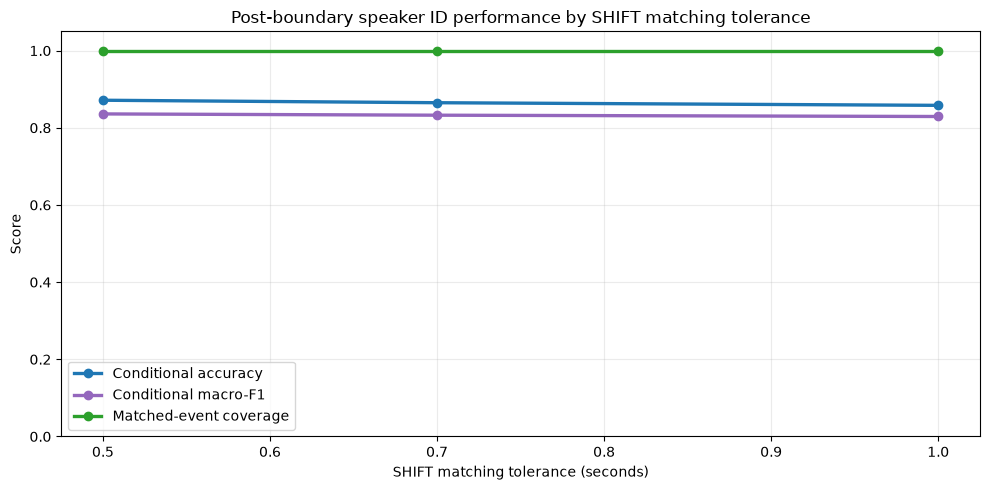

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_performance_by_tolerance.png


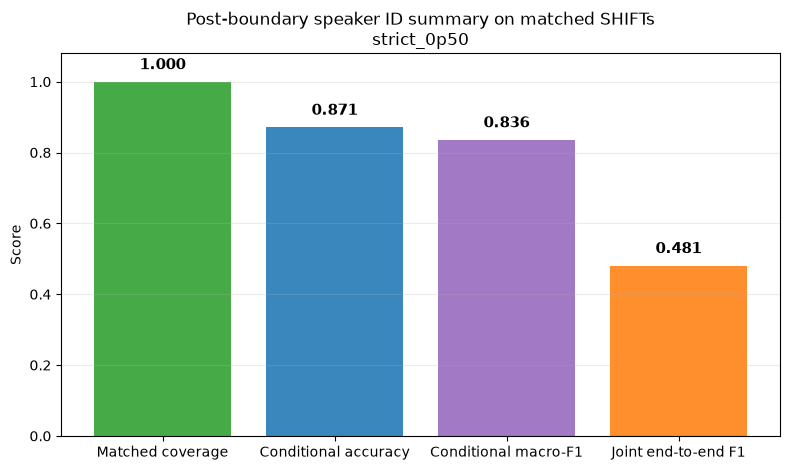

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_summary_strict_0p50.png


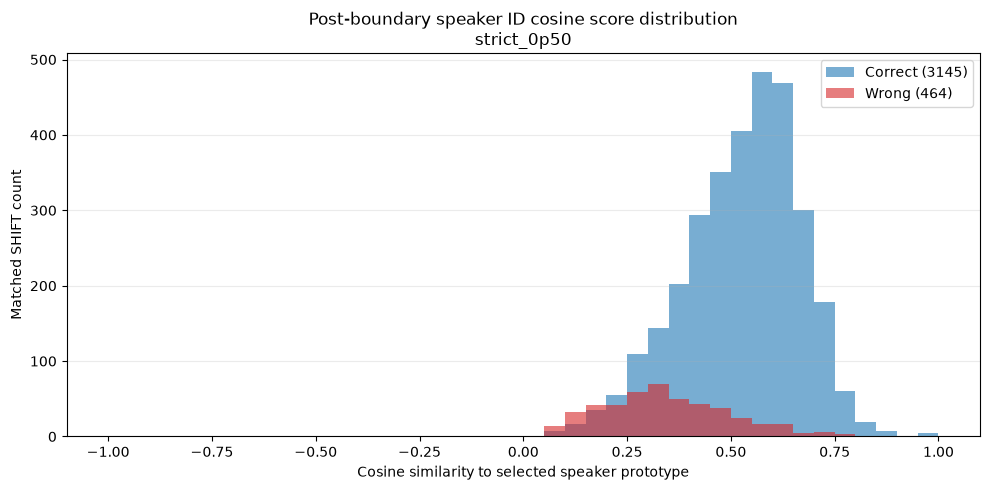

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_cosine_score_distribution_strict_0p50.png


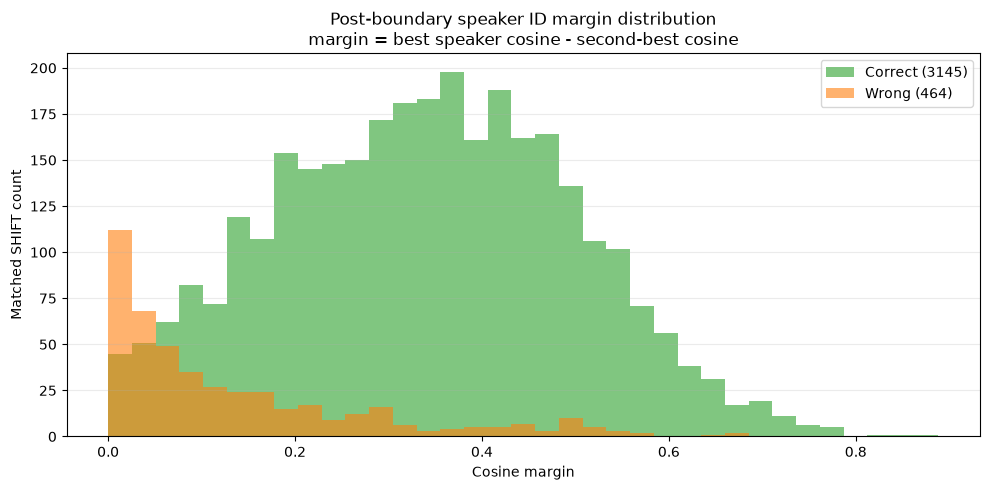

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_margin_distribution_strict_0p50.png


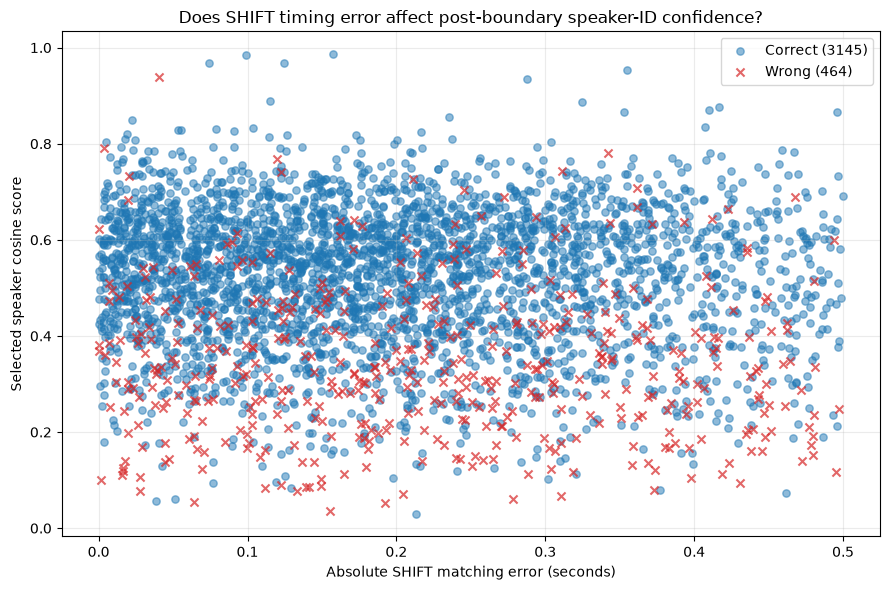

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_timing_error_vs_confidence_strict_0p50.png
Cell 22D raw per-session columns: ['session', 'tolerance_label', 'matched', 'available', 'correct']
Cell 22E normalized per-session columns: ['session', 'tolerance_label', 'matched_shift_count', 'speaker_id_available', 'correct_speaker_count', 'coverage', 'accuracy', 'macro_f1']


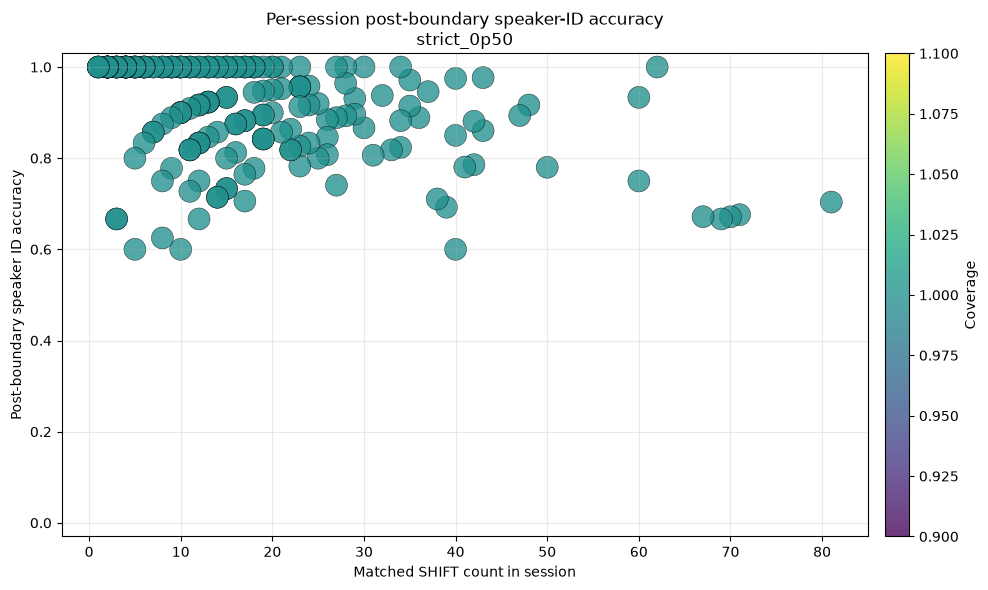

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_per_session_accuracy_scatter_strict_0p50.png


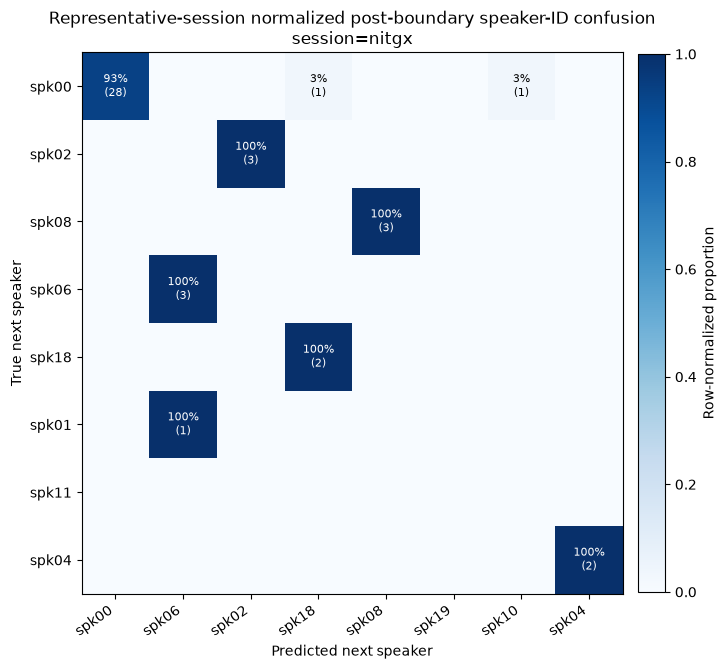

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_representative_session_confusion_nitgx.png


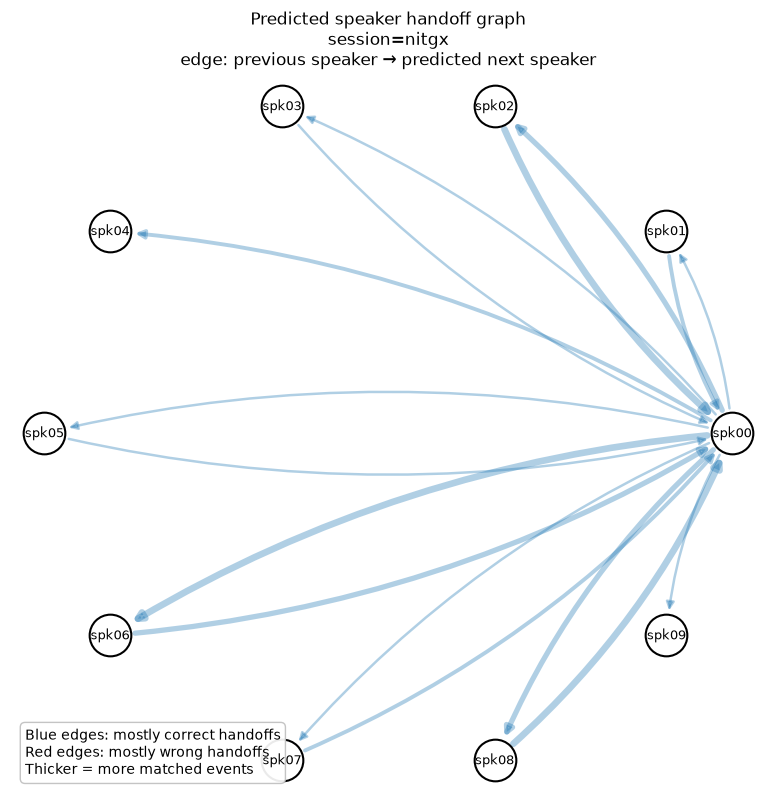

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_handoff_graph_nitgx.png


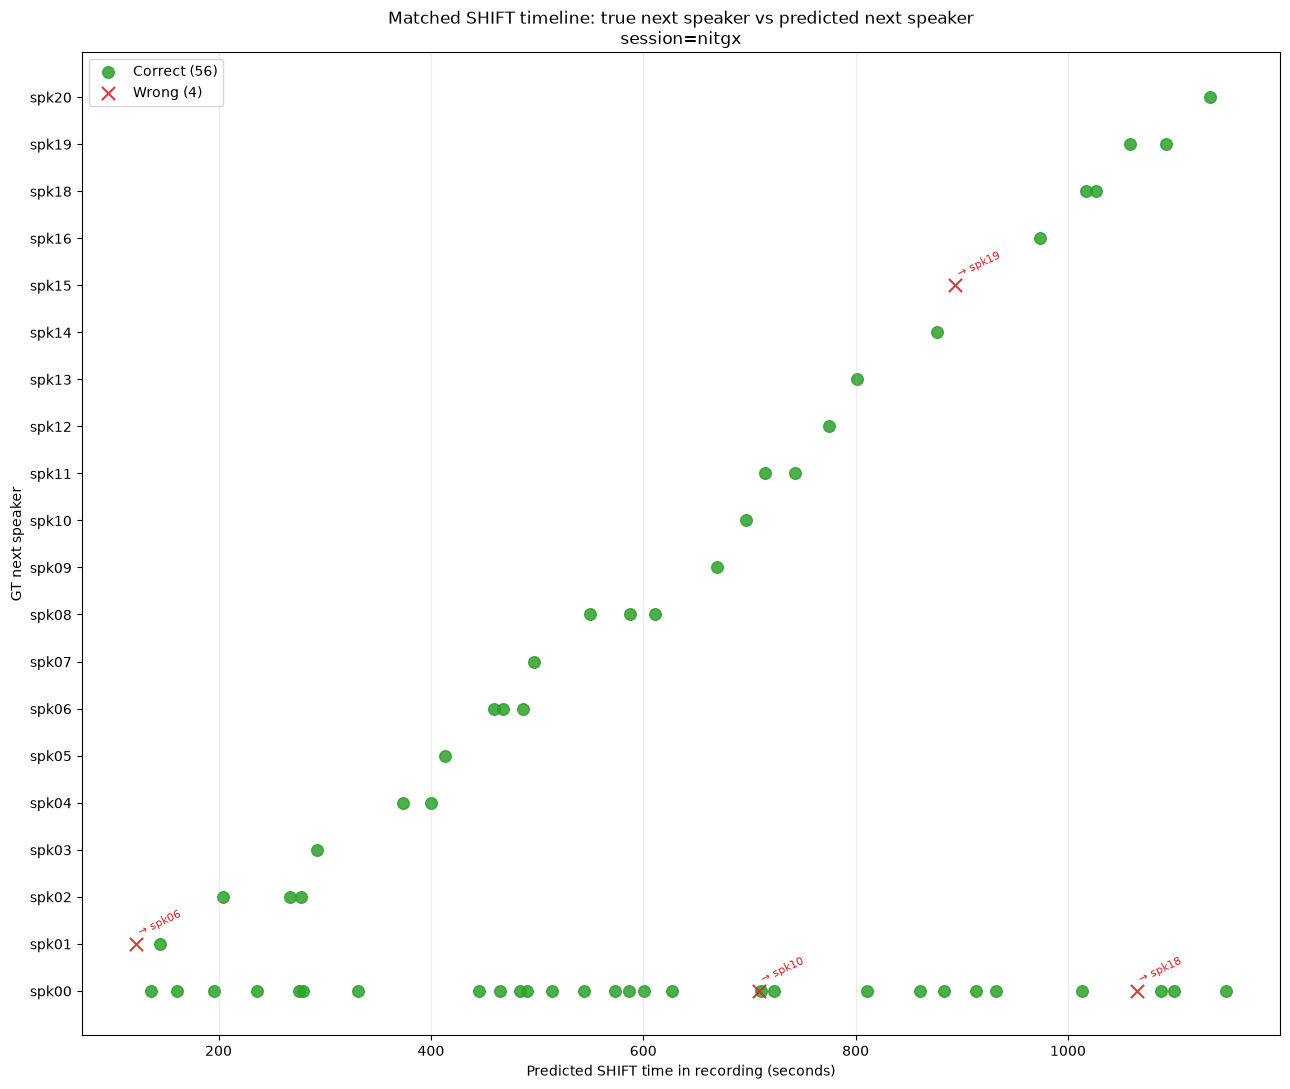

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_matched_shift_timeline_nitgx.png


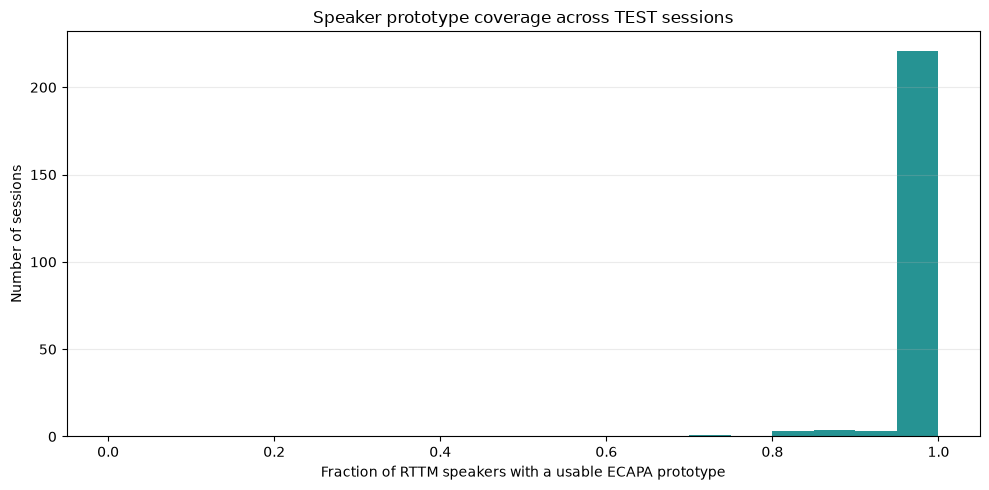

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_prototype_coverage_histogram.png


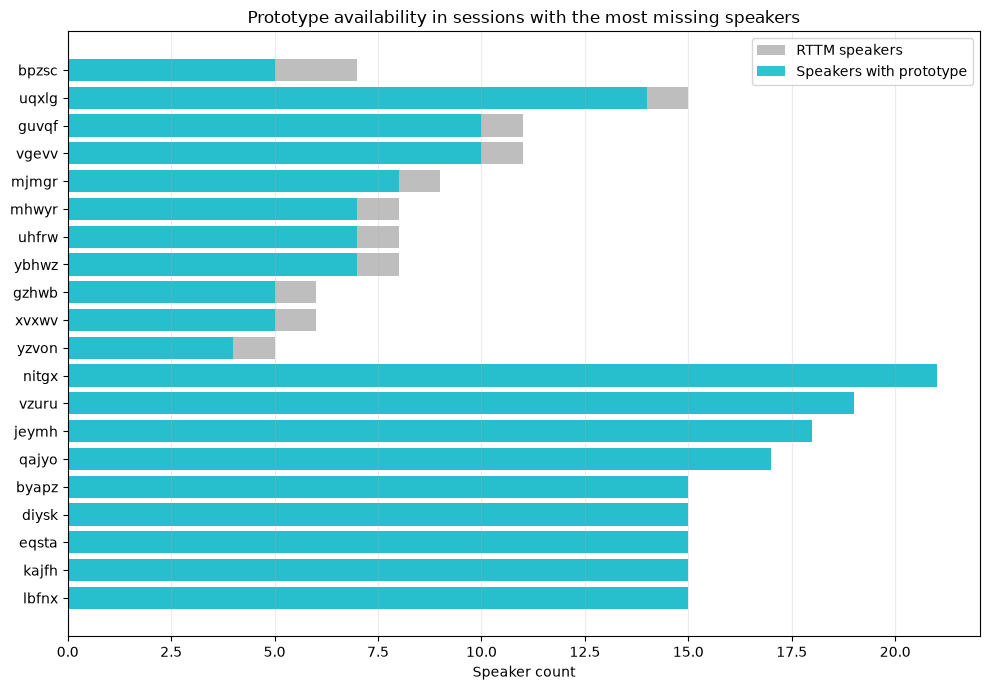

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_sessions_with_missing_prototypes.png
Saved strict matched visualization table: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_strict_matched_for_visualization_strict_0p50.csv
Saved normalized per-session visualization table: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_cosine_visualizations/nextspeaker_per_session_for_visualization_strict_0p50.csv
Post-boundary speaker ID visualization summary


,protocol,tolerance_name,tolerance_label,tol,event_P,event_R,event_F1,pred_shift_count,gt_shift_count,matched_shift_count,...,speaker_id_coverage_on_matched,conditional_speaker_id_accuracy,conditional_speaker_id_macro_f1,correct_speaker_events,joint_correct_speaker_precision,joint_correct_speaker_recall,joint_correct_speaker_f1,uses_rttm_oracle_inventory,uses_future_postboundary_audio,causal_decision_time_prediction
0,oracle_inventory_postboundary_speaker_identifi...,strict,strict_0p50,0.5,0.536176,0.568526,0.551877,6731,6348,3609,...,1.0,0.871433,0.835973,3145,0.467241,0.495432,0.480924,True,True,False
1,oracle_inventory_postboundary_speaker_identifi...,dataset_calibrated,dataset_calibrated_0p70,0.7,0.580003,0.614997,0.596988,6731,6348,3904,...,1.0,0.865010,0.832669,3377,0.501709,0.531979,0.516400,True,True,False
2,oracle_inventory_postboundary_speaker_identifi...,relaxed,relaxed_1p00,1.0,0.602436,0.638784,0.620078,6731,6348,4055,...,1.0,0.858200,0.829287,3480,0.517011,0.548204,0.532151,True,True,False


Representative session used for detailed visuals: nitgx
Protocol: RTTM-oracle inventory; future post-boundary audio; not causal decision-time prediction
✅ Cell 22E complete: post-boundary speaker-ID visualizations saved.


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import f1_score

NS_PROTOCOL_NOTE = "RTTM-oracle inventory; future post-boundary audio; not causal decision-time prediction"

assert "NS_E2E_METRICS_DF" in globals(), "Need NS_E2E_METRICS_DF from Cell 22D."
assert "NS_E2E_MATCHED_DF" in globals(), "Need NS_E2E_MATCHED_DF from Cell 22D."
assert "NS_E2E_PER_SESSION_DF" in globals(), "Need NS_E2E_PER_SESSION_DF from Cell 22D."
assert "TEST_PRED_DF_NS" in globals(), "Need TEST_PRED_DF_NS from Cell 22C."

if "RUN_ROOT" in globals():
    NS_VIZ_DIR = Path(RUN_ROOT) / "nextspeaker_cosine_visualizations"
else:
    NS_VIZ_DIR = Path(".") / "nextspeaker_cosine_visualizations"

NS_VIZ_DIR.mkdir(parents=True, exist_ok=True)

NS_MAIN_TOL_LABEL = str(globals().get("NS_MAIN_TOL_LABEL", "strict_0p50"))

print("=" * 80)
print("CELL 22E: Post-boundary speaker ID visualizations")
print("=" * 80)
print("Main tolerance:", NS_MAIN_TOL_LABEL)
print("Saving figures to:", NS_VIZ_DIR)

def _save_and_show(fig, filename):
    path = NS_VIZ_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Saved:", path)

def _clean_spk(x):
    if x is None:
        return pd.NA
    s = str(x).strip()
    if s.lower() in {"", "none", "nan", "<na>", "na", "null"}:
        return pd.NA
    return s

def _short_label(x, max_len=14):
    x = str(x)
    return x if len(x) <= max_len else x[:max_len] + "..."

def _get_strict_matched():
    df = NS_E2E_MATCHED_DF.copy()

    if "tolerance_label" in df.columns:
        df = df[df["tolerance_label"].astype(str).eq(NS_MAIN_TOL_LABEL)].copy()

    for c in ["pred_next_speaker", "gt_next_speaker", "gt_prev_speaker"]:
        if c in df.columns:
            df[c] = df[c].map(_clean_spk)

    if "next_speaker_available" in df.columns:
        df["next_speaker_available"] = pd.to_numeric(df["next_speaker_available"], errors="coerce").fillna(0).astype(int)
    else:
        df["next_speaker_available"] = df["pred_next_speaker"].notna().astype(int)

    df["next_speaker_score"] = pd.to_numeric(
        df.get("next_speaker_score", np.nan),
        errors="coerce",
    )
    df["next_speaker_margin"] = pd.to_numeric(
        df.get("next_speaker_margin", np.nan),
        errors="coerce",
    )

    if "abs_time_error" in df.columns:
        timing_error = df["abs_time_error"]
    elif "abs_error" in df.columns:
        timing_error = df["abs_error"]
    elif "signed_error" in df.columns:
        timing_error = pd.to_numeric(df["signed_error"], errors="coerce").abs()
    else:
        timing_error = pd.Series(np.nan, index=df.index, dtype=float)

    df["abs_time_error"] = pd.to_numeric(timing_error, errors="coerce")

    if "correct_next_speaker" not in df.columns:
        df["correct_next_speaker"] = (
            df["pred_next_speaker"].astype(str) == df["gt_next_speaker"].astype(str)
        ).astype(int)

    df["correct_next_speaker"] = pd.to_numeric(df["correct_next_speaker"], errors="coerce").fillna(0).astype(int)

    return df.reset_index(drop=True)

def _choose_representative_session(matched_df):
    if matched_df is None or len(matched_df) == 0:
        return None

    available = matched_df[matched_df["pred_next_speaker"].notna()].copy()
    if len(available) == 0:
        return None

    sess_summary = (
        available
        .groupby("session")
        .agg(
            matched=("session", "count"),
            accuracy=("correct_next_speaker", "mean"),
            n_true_spk=("gt_next_speaker", lambda x: len(set(map(str, x.dropna())))),
            n_pred_spk=("pred_next_speaker", lambda x: len(set(map(str, x.dropna())))),
            mean_margin=("next_speaker_margin", "mean"),
        )
        .reset_index()
    )

    sess_summary = sess_summary[
        (sess_summary["matched"] >= 8)
        & (sess_summary["n_true_spk"] >= 2)
        & (sess_summary["n_pred_spk"] >= 2)
    ].copy()

    if len(sess_summary) == 0:
        sess_summary = (
            available
            .groupby("session")
            .agg(
                matched=("session", "count"),
                accuracy=("correct_next_speaker", "mean"),
                n_true_spk=("gt_next_speaker", lambda x: len(set(map(str, x.dropna())))),
                n_pred_spk=("pred_next_speaker", lambda x: len(set(map(str, x.dropna())))),
                mean_margin=("next_speaker_margin", "mean"),
            )
            .reset_index()
        )

    if len(sess_summary) == 0:
        return None

    sess_summary["informativeness"] = (
        sess_summary["matched"]
        + 4.0 * sess_summary["n_true_spk"]
        + 4.0 * sess_summary["n_pred_spk"]
        - 2.0 * (sess_summary["accuracy"] - 0.75).abs()
    )

    sess_summary = sess_summary.sort_values("informativeness", ascending=False)

    return str(sess_summary.iloc[0]["session"])

strict_matched = _get_strict_matched()

print("Strict matched-shift rows:", strict_matched.shape)
print("Post-boundary speaker ID available rows:", int(strict_matched["next_speaker_available"].sum()) if len(strict_matched) else 0)

metrics = NS_E2E_METRICS_DF.copy()

if len(metrics):
    metrics["tol"] = pd.to_numeric(metrics["tol"], errors="coerce")
    metrics = metrics.sort_values("tol")

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        metrics["tol"],
        metrics["conditional_speaker_id_accuracy"],
        marker="o",
        linewidth=2.4,
        color="tab:blue",
        label="Conditional accuracy",
    )

    ax.plot(
        metrics["tol"],
        metrics["conditional_speaker_id_macro_f1"],
        marker="o",
        linewidth=2.4,
        color="tab:purple",
        label="Conditional macro-F1",
    )

    ax.plot(
        metrics["tol"],
        metrics["speaker_id_coverage_on_matched"],
        marker="o",
        linewidth=2.4,
        color="tab:green",
        label="Matched-event coverage",
    )

    ax.set_title("Post-boundary speaker ID performance by SHIFT matching tolerance")
    ax.set_xlabel("SHIFT matching tolerance (seconds)")
    ax.set_ylabel("Score")
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    _save_and_show(fig, "nextspeaker_performance_by_tolerance.png")

if len(metrics):
    main_row = metrics[metrics["tolerance_label"].astype(str).eq(NS_MAIN_TOL_LABEL)].copy()
    if len(main_row) == 0:
        main_row = metrics.head(1)

    main_row = main_row.iloc[0]

    summary_items = [
        ("Matched coverage", float(main_row.get("speaker_id_coverage_on_matched", np.nan))),
        ("Conditional accuracy", float(main_row.get("conditional_speaker_id_accuracy", np.nan))),
        ("Conditional macro-F1", float(main_row.get("conditional_speaker_id_macro_f1", np.nan))),
        ("Joint end-to-end F1", float(main_row.get("joint_correct_speaker_f1", np.nan))),
    ]

    fig, ax = plt.subplots(figsize=(8, 4.8))

    labels = [x[0] for x in summary_items]
    vals = [x[1] for x in summary_items]
    colors = ["tab:green", "tab:blue", "tab:purple", "tab:orange"]

    bars = ax.bar(labels, vals, color=colors, alpha=0.88)

    for b, v in zip(bars, vals):
        if np.isfinite(v):
            ax.text(
                b.get_x() + b.get_width() / 2,
                v + 0.025,
                f"{v:.3f}",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold",
            )

    ax.set_title(f"Post-boundary speaker ID summary on matched SHIFTs\n{NS_MAIN_TOL_LABEL}")
    ax.set_ylabel("Score")
    ax.set_ylim(0.0, 1.08)
    ax.grid(axis="y", alpha=0.25)

    _save_and_show(fig, f"nextspeaker_summary_{NS_MAIN_TOL_LABEL}.png")

available = strict_matched[strict_matched["pred_next_speaker"].notna()].copy()

if len(available):
    correct = available[available["correct_next_speaker"].eq(1)].copy()
    wrong = available[available["correct_next_speaker"].eq(0)].copy()

    fig, ax = plt.subplots(figsize=(10, 5))

    bins = np.linspace(-1.0, 1.0, 41)

    ax.hist(
        correct["next_speaker_score"].dropna(),
        bins=bins,
        alpha=0.60,
        color="tab:blue",
        label=f"Correct ({len(correct)})",
    )
    ax.hist(
        wrong["next_speaker_score"].dropna(),
        bins=bins,
        alpha=0.60,
        color="tab:red",
        label=f"Wrong ({len(wrong)})",
    )

    ax.set_title(f"Post-boundary speaker ID cosine score distribution\n{NS_MAIN_TOL_LABEL}")
    ax.set_xlabel("Cosine similarity to selected speaker prototype")
    ax.set_ylabel("Matched SHIFT count")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

    _save_and_show(fig, f"nextspeaker_cosine_score_distribution_{NS_MAIN_TOL_LABEL}.png")

    fig, ax = plt.subplots(figsize=(10, 5))

    margin_bins = np.linspace(
        max(-0.05, float(np.nanmin(available["next_speaker_margin"])) if available["next_speaker_margin"].notna().any() else 0.0),
        min(1.0, float(np.nanmax(available["next_speaker_margin"])) if available["next_speaker_margin"].notna().any() else 1.0),
        36,
    )

    if len(margin_bins) < 3 or not np.isfinite(margin_bins).all() or margin_bins[0] == margin_bins[-1]:
        margin_bins = np.linspace(0.0, 1.0, 36)

    ax.hist(
        correct["next_speaker_margin"].dropna(),
        bins=margin_bins,
        alpha=0.60,
        color="tab:green",
        label=f"Correct ({len(correct)})",
    )
    ax.hist(
        wrong["next_speaker_margin"].dropna(),
        bins=margin_bins,
        alpha=0.60,
        color="tab:orange",
        label=f"Wrong ({len(wrong)})",
    )

    ax.set_title(f"Post-boundary speaker ID margin distribution\nmargin = best speaker cosine - second-best cosine")
    ax.set_xlabel("Cosine margin")
    ax.set_ylabel("Matched SHIFT count")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

    _save_and_show(fig, f"nextspeaker_margin_distribution_{NS_MAIN_TOL_LABEL}.png")

if len(available):
    fig, ax = plt.subplots(figsize=(9, 6))

    plot_df = available.dropna(subset=["abs_time_error", "next_speaker_score"]).copy()
    correct_df = plot_df[plot_df["correct_next_speaker"].eq(1)]
    wrong_df = plot_df[plot_df["correct_next_speaker"].eq(0)]

    ax.scatter(
        correct_df["abs_time_error"],
        correct_df["next_speaker_score"],
        s=28,
        alpha=0.50,
        color="tab:blue",
        label=f"Correct ({len(correct_df)})",
    )

    ax.scatter(
        wrong_df["abs_time_error"],
        wrong_df["next_speaker_score"],
        s=34,
        alpha=0.70,
        color="tab:red",
        marker="x",
        label=f"Wrong ({len(wrong_df)})",
    )

    ax.set_title("Does SHIFT timing error affect post-boundary speaker-ID confidence?")
    ax.set_xlabel("Absolute SHIFT matching error (seconds)")
    ax.set_ylabel("Selected speaker cosine score")
    ax.grid(alpha=0.25)
    ax.legend()

    _save_and_show(fig, f"nextspeaker_timing_error_vs_confidence_{NS_MAIN_TOL_LABEL}.png")

def _build_per_session_viz_table(matched_df: pd.DataFrame) -> pd.DataFrame:
    columns = [
        "session",
        "tolerance_label",
        "matched_shift_count",
        "speaker_id_available",
        "correct_speaker_count",
        "coverage",
        "accuracy",
        "macro_f1",
    ]

    if matched_df is None or len(matched_df) == 0:
        return pd.DataFrame(columns=columns)

    rows = []

    for sid, group in matched_df.groupby("session", sort=False):
        group = group.copy()
        matched_count = int(len(group))

        evaluable = group[
            group["pred_next_speaker"].notna()
            & group["gt_next_speaker"].notna()
        ].copy()

        available_count = int(len(evaluable))
        correct_count = int(
            pd.to_numeric(
                group.get("correct_next_speaker", 0),
                errors="coerce",
            )
            .fillna(0)
            .astype(int)
            .sum()
        )

        coverage = (
            available_count / matched_count
            if matched_count > 0
            else np.nan
        )

        accuracy = (
            correct_count / available_count
            if available_count > 0
            else np.nan
        )

        if available_count > 0:
            y_true = evaluable["gt_next_speaker"].astype(str).tolist()
            y_pred = evaluable["pred_next_speaker"].astype(str).tolist()
            labels = sorted(set(y_true) | set(y_pred))

            macro_f1_value = float(
                f1_score(
                    y_true,
                    y_pred,
                    labels=labels,
                    average="macro",
                    zero_division=0,
                )
            )
        else:
            macro_f1_value = np.nan

        rows.append({
            "session": str(sid),
            "tolerance_label": str(NS_MAIN_TOL_LABEL),
            "matched_shift_count": matched_count,
            "speaker_id_available": available_count,
            "correct_speaker_count": correct_count,
            "coverage": float(coverage) if np.isfinite(coverage) else np.nan,
            "accuracy": float(accuracy) if np.isfinite(accuracy) else np.nan,
            "macro_f1": macro_f1_value,
        })

    return (
        pd.DataFrame(rows, columns=columns)
        .sort_values(
            ["matched_shift_count", "accuracy"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

per_session = _build_per_session_viz_table(strict_matched)

raw_per_session = NS_E2E_PER_SESSION_DF.copy()

if len(raw_per_session):
    raw_strict = raw_per_session.copy()

    if "tolerance_label" in raw_strict.columns:
        raw_strict = raw_strict[
            raw_strict["tolerance_label"]
            .astype(str)
            .eq(NS_MAIN_TOL_LABEL)
        ].copy()

    expected_raw_cols = {"session", "matched", "available", "correct"}

    if expected_raw_cols.issubset(raw_strict.columns):
        check = raw_strict[
            ["session", "matched", "available", "correct"]
        ].copy()

        check["session"] = check["session"].astype(str)

        for col in ["matched", "available", "correct"]:
            check[col] = (
                pd.to_numeric(check[col], errors="coerce")
                .fillna(0)
                .astype(int)
            )

        compare = per_session.merge(
            check,
            on="session",
            how="left",
            validate="one_to_one",
        )

        mismatch = compare[
            compare["matched"].notna()
            & (
                compare["matched_shift_count"].ne(compare["matched"])
                | compare["speaker_id_available"].ne(compare["available"])
                | compare["correct_speaker_count"].ne(compare["correct"])
            )
        ]

        if len(mismatch):
            print(
                "WARNING: derived per-session metrics differ from "
                f"Cell 22D compact counts for {len(mismatch)} session(s)."
            )

print("Cell 22D raw per-session columns:", list(NS_E2E_PER_SESSION_DF.columns))
print("Cell 22E normalized per-session columns:", list(per_session.columns))

if len(per_session):
    ps = per_session.dropna(
        subset=["matched_shift_count", "accuracy"]
    ).copy()

    if len(ps):
        fig, ax = plt.subplots(figsize=(10, 6))

        sizes = (
            30
            + 220
            * ps["coverage"]
            .fillna(0)
            .clip(0, 1)
        )

        sc = ax.scatter(
            ps["matched_shift_count"],
            ps["accuracy"],
            s=sizes,
            c=ps["coverage"].fillna(0),
            cmap="viridis",
            alpha=0.78,
            edgecolors="black",
            linewidths=0.35,
        )

        ax.set_title(
            "Per-session post-boundary speaker-ID accuracy\n"
            f"{NS_MAIN_TOL_LABEL}"
        )
        ax.set_xlabel("Matched SHIFT count in session")
        ax.set_ylabel("Post-boundary speaker ID accuracy")
        ax.set_ylim(-0.03, 1.03)
        ax.grid(alpha=0.25)

        cbar = fig.colorbar(
            sc,
            ax=ax,
            fraction=0.035,
            pad=0.02,
        )
        cbar.set_label("Coverage")

        _save_and_show(
            fig,
            f"nextspeaker_per_session_accuracy_scatter_{NS_MAIN_TOL_LABEL}.png",
        )
else:
    print(
        "No matched SHIFT rows were available for the "
        "per-session speaker-ID visualization."
    )

rep_session = _choose_representative_session(strict_matched)
globals()["NS_REPRESENTATIVE_SESSION"] = rep_session

if rep_session is not None:
    sess_df = available[available["session"].astype(str).eq(str(rep_session))].copy()

    if len(sess_df):
        cm = pd.crosstab(
            sess_df["gt_next_speaker"].astype(str),
            sess_df["pred_next_speaker"].astype(str),
            rownames=["True next speaker"],
            colnames=["Predicted next speaker"],
            dropna=False,
        )

        row_order = cm.sum(axis=1).sort_values(ascending=False).index.tolist()
        col_order = cm.sum(axis=0).sort_values(ascending=False).index.tolist()

        max_spk = int(globals().get("NS_VIZ_MAX_SPK_CONFUSION", 8))
        row_order = row_order[:max_spk]
        col_order = col_order[:max_spk]

        cm = cm.loc[row_order, col_order]
        cm_values = cm.values.astype(float)
        row_sums = cm_values.sum(axis=1, keepdims=True)
        cm_norm = np.divide(
            cm_values,
            np.maximum(row_sums, 1),
            out=np.zeros_like(cm_values, dtype=float),
            where=row_sums > 0,
        )

        fig, ax = plt.subplots(figsize=(8.5, 6.8))
        im = ax.imshow(cm_norm, cmap="Blues", vmin=0.0, vmax=1.0)

        ax.set_title(f"Representative-session normalized post-boundary speaker-ID confusion\nsession={rep_session}")
        ax.set_xlabel("Predicted next speaker")
        ax.set_ylabel("True next speaker")
        ax.set_xticks(np.arange(len(col_order)))
        ax.set_xticklabels([_short_label(x) for x in col_order], rotation=35, ha="right")
        ax.set_yticks(np.arange(len(row_order)))
        ax.set_yticklabels([_short_label(x) for x in row_order])

        for i in range(cm_norm.shape[0]):
            for j in range(cm_norm.shape[1]):
                val = cm_norm[i, j]
                cnt = int(cm_values[i, j])
                if cnt > 0:
                    ax.text(
                        j,
                        i,
                        f"{100*val:.0f}%\n({cnt})",
                        ha="center",
                        va="center",
                        fontsize=8,
                        color="white" if val > 0.55 else "black",
                    )

        cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
        cbar.set_label("Row-normalized proportion")

        _save_and_show(fig, f"nextspeaker_representative_session_confusion_{rep_session}.png")

if rep_session is not None:
    sess_df = available[available["session"].astype(str).eq(str(rep_session))].copy()

    if len(sess_df) and "gt_prev_speaker" in sess_df.columns:
        graph_df = sess_df.dropna(subset=["gt_prev_speaker", "pred_next_speaker"]).copy()

        if len(graph_df):
            speakers = sorted(set(graph_df["gt_prev_speaker"].astype(str)) | set(graph_df["pred_next_speaker"].astype(str)))
            max_nodes = int(globals().get("NS_VIZ_MAX_GRAPH_SPK", 10))
            speakers = speakers[:max_nodes]

            graph_df = graph_df[
                graph_df["gt_prev_speaker"].astype(str).isin(speakers)
                & graph_df["pred_next_speaker"].astype(str).isin(speakers)
            ].copy()

            edge_df = (
                graph_df
                .groupby(["gt_prev_speaker", "pred_next_speaker"])
                .agg(
                    count=("session", "count"),
                    accuracy=("correct_next_speaker", "mean"),
                )
                .reset_index()
                .sort_values("count", ascending=False)
            )

            n = len(speakers)
            if n >= 2:
                theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
                pos = {spk: np.array([np.cos(t), np.sin(t)]) for spk, t in zip(speakers, theta)}

                fig, ax = plt.subplots(figsize=(8, 8))
                ax.set_title(
                    f"Predicted speaker handoff graph\nsession={rep_session}\n"
                    "edge: previous speaker → predicted next speaker"
                )

                from matplotlib.patches import FancyArrowPatch

                max_count = max(1, int(edge_df["count"].max()))

                for _, e in edge_df.iterrows():
                    a = str(e["gt_prev_speaker"])
                    b = str(e["pred_next_speaker"])

                    if a not in pos or b not in pos:
                        continue

                    p0 = pos[a]
                    p1 = pos[b]

                    if a == b:
                        continue

                    count = int(e["count"])
                    acc = float(e["accuracy"])
                    lw = 0.8 + 4.0 * count / max_count
                    color = "tab:blue" if acc >= 0.5 else "tab:red"

                    arrow = FancyArrowPatch(
                        p0,
                        p1,
                        arrowstyle="-|>",
                        mutation_scale=12,
                        linewidth=lw,
                        color=color,
                        alpha=0.35,
                        shrinkA=18,
                        shrinkB=18,
                        connectionstyle="arc3,rad=0.12",
                    )
                    ax.add_patch(arrow)

                for spk in speakers:
                    x, y = pos[spk]
                    ax.scatter([x], [y], s=900, color="white", edgecolor="black", linewidth=1.5, zorder=3)
                    ax.text(x, y, _short_label(spk, 10), ha="center", va="center", fontsize=9, zorder=4)

                ax.text(
                    0.02,
                    0.02,
                    "Blue edges: mostly correct handoffs\nRed edges: mostly wrong handoffs\nThicker = more matched events",
                    transform=ax.transAxes,
                    ha="left",
                    va="bottom",
                    fontsize=10,
                    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="0.75", alpha=0.92),
                )

                ax.set_aspect("equal")
                ax.axis("off")

                _save_and_show(fig, f"nextspeaker_handoff_graph_{rep_session}.png")

if rep_session is not None:
    sess_df = available[available["session"].astype(str).eq(str(rep_session))].copy()

    if len(sess_df):
        sess_df["pred_time"] = pd.to_numeric(sess_df["pred_time"], errors="coerce")
        sess_df = sess_df.dropna(subset=["pred_time"]).sort_values("pred_time").reset_index(drop=True)

        true_speakers = sorted(sess_df["gt_next_speaker"].dropna().astype(str).unique().tolist())
        spk_to_y = {spk: i for i, spk in enumerate(true_speakers)}

        sess_df["y"] = sess_df["gt_next_speaker"].astype(str).map(spk_to_y)

        fig, ax = plt.subplots(figsize=(13, max(4.5, 0.45 * len(true_speakers) + 2)))

        correct_df = sess_df[sess_df["correct_next_speaker"].eq(1)]
        wrong_df = sess_df[sess_df["correct_next_speaker"].eq(0)]

        ax.scatter(
            correct_df["pred_time"],
            correct_df["y"],
            s=70,
            color="tab:green",
            alpha=0.85,
            label=f"Correct ({len(correct_df)})",
        )

        ax.scatter(
            wrong_df["pred_time"],
            wrong_df["y"],
            s=90,
            color="tab:red",
            marker="x",
            alpha=0.90,
            label=f"Wrong ({len(wrong_df)})",
        )

        max_ann = int(globals().get("NS_VIZ_MAX_WRONG_ANNOTATIONS", 20))
        for _, r in wrong_df.head(max_ann).iterrows():
            ax.text(
                float(r["pred_time"]),
                float(r["y"]) + 0.12,
                f"→ {_short_label(r['pred_next_speaker'], 9)}",
                fontsize=8,
                color="tab:red",
                rotation=25,
                ha="left",
                va="bottom",
            )

        ax.set_title(f"Matched SHIFT timeline: true next speaker vs predicted next speaker\nsession={rep_session}")
        ax.set_xlabel("Predicted SHIFT time in recording (seconds)")
        ax.set_ylabel("GT next speaker")
        ax.set_yticks(list(spk_to_y.values()))
        ax.set_yticklabels([_short_label(s) for s in true_speakers])
        ax.grid(axis="x", alpha=0.25)
        ax.legend()

        _save_and_show(fig, f"nextspeaker_matched_shift_timeline_{rep_session}.png")

if "NS_TEST_PROTOTYPE_META_DF" in globals() and NS_TEST_PROTOTYPE_META_DF is not None and len(NS_TEST_PROTOTYPE_META_DF):
    proto_meta = NS_TEST_PROTOTYPE_META_DF.copy()

    proto_meta["n_speakers_rttm"] = pd.to_numeric(proto_meta["n_speakers_rttm"], errors="coerce").fillna(0)
    proto_meta["n_speakers_with_proto"] = pd.to_numeric(proto_meta["n_speakers_with_proto"], errors="coerce").fillna(0)
    proto_meta["coverage"] = proto_meta["n_speakers_with_proto"] / proto_meta["n_speakers_rttm"].replace(0, np.nan)
    proto_meta["coverage"] = proto_meta["coverage"].fillna(0)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.hist(proto_meta["coverage"], bins=np.linspace(0, 1, 21), color="teal", alpha=0.85)
    ax.set_title("Speaker prototype coverage across TEST sessions")
    ax.set_xlabel("Fraction of RTTM speakers with a usable ECAPA prototype")
    ax.set_ylabel("Number of sessions")
    ax.grid(axis="y", alpha=0.25)

    _save_and_show(fig, "nextspeaker_prototype_coverage_histogram.png")

    top_missing = proto_meta.copy()
    top_missing["missing_speakers"] = top_missing["n_speakers_rttm"] - top_missing["n_speakers_with_proto"]
    top_missing = top_missing.sort_values(["missing_speakers", "n_speakers_rttm"], ascending=False).head(20)

    if len(top_missing):
        fig, ax = plt.subplots(figsize=(10, 7))

        y = np.arange(len(top_missing))
        labels = top_missing["session"].astype(str).map(_short_label).tolist()

        ax.barh(
            y,
            top_missing["n_speakers_rttm"],
            color="tab:gray",
            alpha=0.50,
            label="RTTM speakers",
        )
        ax.barh(
            y,
            top_missing["n_speakers_with_proto"],
            color="tab:cyan",
            alpha=0.90,
            label="Speakers with prototype",
        )

        ax.set_title("Prototype availability in sessions with the most missing speakers")
        ax.set_xlabel("Speaker count")
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.25)
        ax.legend()

        _save_and_show(fig, "nextspeaker_sessions_with_missing_prototypes.png")

if len(strict_matched):
    strict_out = NS_VIZ_DIR / f"nextspeaker_strict_matched_for_visualization_{NS_MAIN_TOL_LABEL}.csv"
    strict_matched.to_csv(strict_out, index=False)
    globals()["NS_STRICT_MATCHED_VIZ_CSV"] = str(strict_out)
    print("Saved strict matched visualization table:", strict_out)

if len(per_session):
    per_session_out = (
        NS_VIZ_DIR
        / f"nextspeaker_per_session_for_visualization_{NS_MAIN_TOL_LABEL}.csv"
    )
    per_session.to_csv(per_session_out, index=False)
    globals()["NS_PER_SESSION_VIZ_DF"] = per_session
    globals()["NS_PER_SESSION_VIZ_CSV"] = str(per_session_out)
    print("Saved normalized per-session visualization table:", per_session_out)

globals()["NS_VIZ_DIR"] = str(NS_VIZ_DIR)

print("=" * 80)
print("Post-boundary speaker ID visualization summary")
print("=" * 80)

if len(metrics):
    display(metrics)

if rep_session is not None:
    print("Representative session used for detailed visuals:", rep_session)
else:
    print("No representative session found for detailed visuals.")

print("Protocol:", NS_PROTOCOL_NOTE)
print("✅ Cell 22E complete: post-boundary speaker-ID visualizations saved.")

CELL 22F: Post-boundary speaker ID paper-style timeline visualisations
Main tolerance: strict_0p50
Example mode: correct
Saving figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style_visualizations


Selected session: laoyl
Predicted SHIFT time: 202.2738742243379
GT SHIFT time: 202.29
GT previous speaker: spk00
GT next speaker: spk01
Predicted next speaker: spk01
Speakers shown: ['spk00', 'spk01']


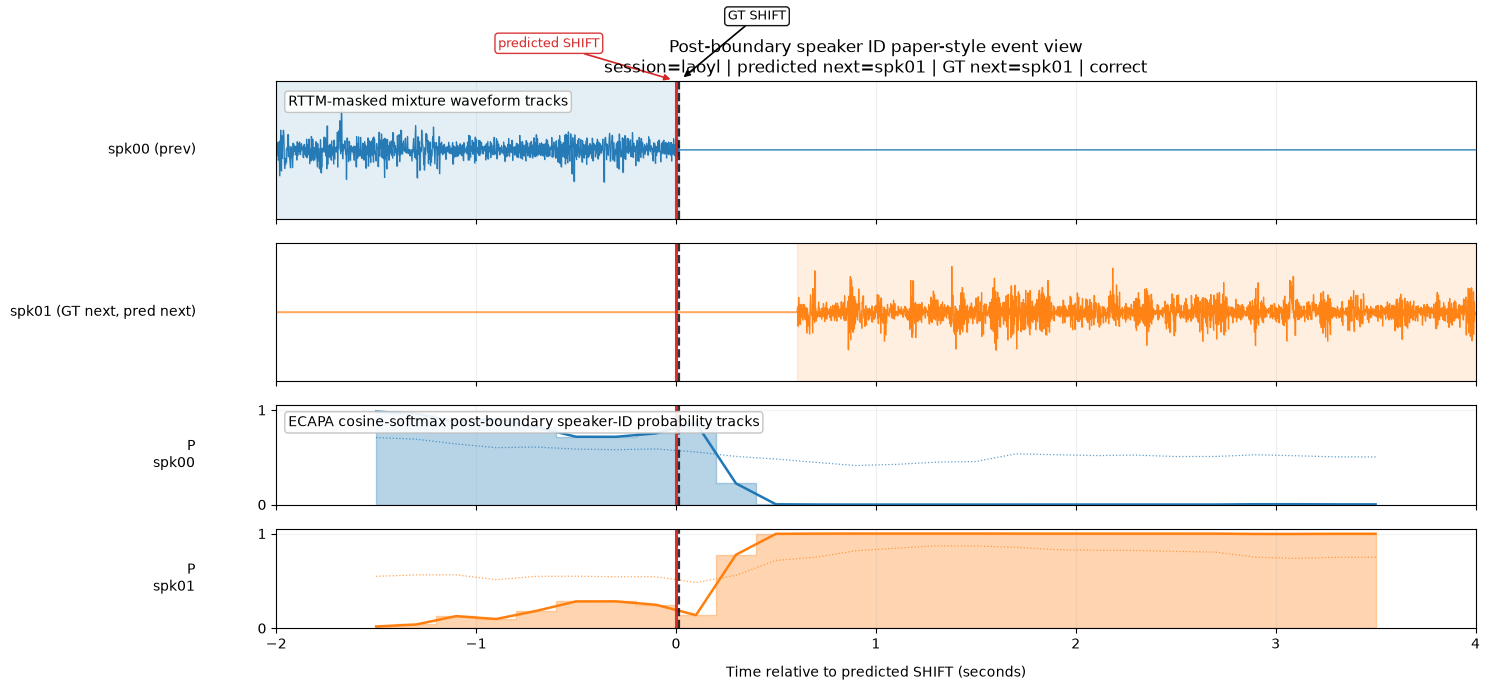

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style_visualizations/nextspeaker_paper_timeline_laoyl_202p27.png


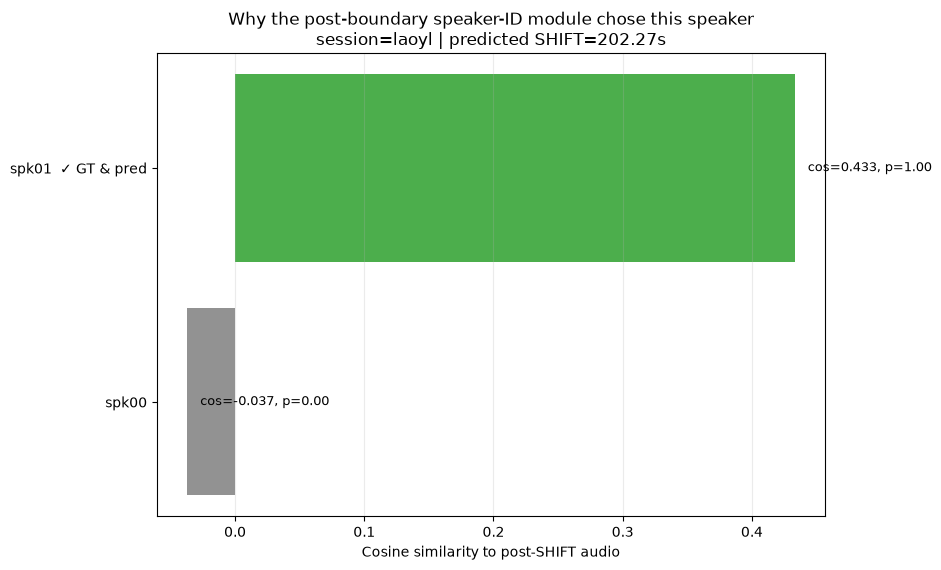

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style_visualizations/nextspeaker_topk_cosine_ranking_laoyl_202p27.png


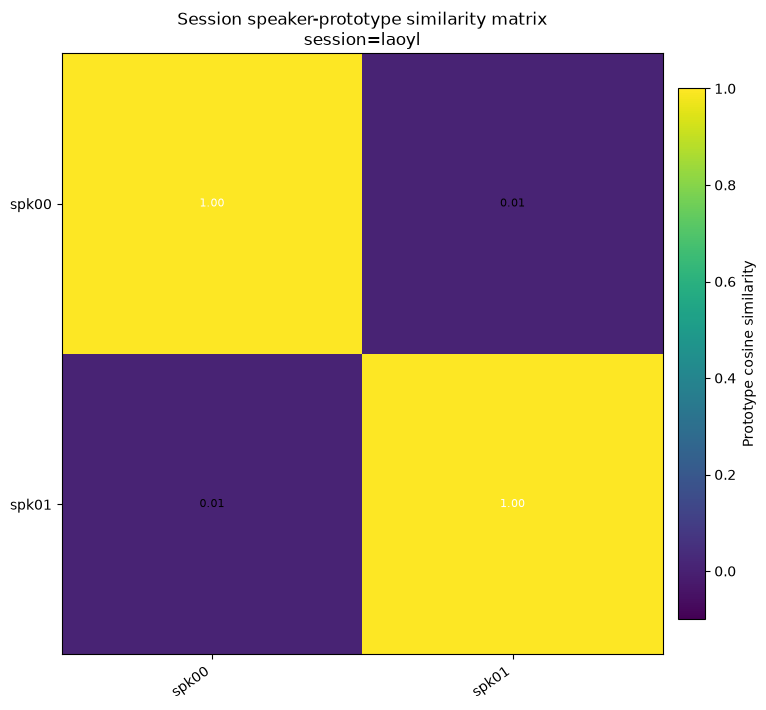

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style_visualizations/nextspeaker_prototype_similarity_matrix_laoyl.png
Saved bounded ECAPA cache: 20000 -> <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_segment_embedding_cache_bounded.pkl
Post-boundary speaker ID paper-style visualisation summary
Selected session: laoyl
Predicted SHIFT: 202.2738742243379
GT SHIFT: 202.29
GT previous speaker: spk00
GT next speaker: spk01
Predicted next speaker: spk01
Correct: True
Saved probability timeline: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style_visualizations/nextspeaker_probability_timeline_laoyl_202p27.csv
Saved ranking table: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_paper_style

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

NS_PROTOCOL_NOTE = "RTTM-oracle inventory; future post-boundary audio; not causal decision-time prediction"
from tqdm.auto import tqdm

assert "NS_E2E_MATCHED_DF" in globals(), "Need NS_E2E_MATCHED_DF from Cell 22D."
assert "TEST_PRED_DF_NS" in globals(), "Need TEST_PRED_DF_NS from Cell 22C."
assert "NS_TEST_PROTOTYPES" in globals(), "Need NS_TEST_PROTOTYPES from Cell 22C."
assert "read_rttm_as_turns" in globals(), "Need read_rttm_as_turns."
assert "read_audio_mono" in globals(), "Need read_audio_mono."
assert "ecapa_embed_segment" in globals(), "Need ecapa_embed_segment."
assert "TEST_AUDIO" in globals(), "Need TEST_AUDIO."
assert "TEST_RTTM" in globals(), "Need TEST_RTTM."
assert "TARGET_SR" in globals(), "Need TARGET_SR."

if "RUN_ROOT" in globals():
    NS_PAPER_VIZ_DIR = Path(RUN_ROOT) / "nextspeaker_paper_style_visualizations"
else:
    NS_PAPER_VIZ_DIR = Path(".") / "nextspeaker_paper_style_visualizations"

NS_PAPER_VIZ_DIR.mkdir(parents=True, exist_ok=True)

NS_MAIN_TOL_LABEL = str(globals().get("NS_MAIN_TOL_LABEL", "strict_0p50"))

NS_PAPER_LEFT_CONTEXT_S = float(globals().get("NS_PAPER_LEFT_CONTEXT_S", 2.0))
NS_PAPER_RIGHT_CONTEXT_S = float(globals().get("NS_PAPER_RIGHT_CONTEXT_S", 4.0))

NS_PAPER_PROB_SEG_S = float(globals().get("NS_PAPER_PROB_SEG_S", 1.00))
NS_PAPER_PROB_STEP_S = float(globals().get("NS_PAPER_PROB_STEP_S", 0.20))
NS_PAPER_SOFTMAX_TEMP = float(globals().get("NS_PAPER_SOFTMAX_TEMP", 0.08))

NS_PAPER_MAX_SPEAKERS = int(globals().get("NS_PAPER_MAX_SPEAKERS", 4))
NS_PAPER_TOPK_BAR = int(globals().get("NS_PAPER_TOPK_BAR", 8))

NS_PAPER_EXAMPLE_MODE = str(globals().get("NS_PAPER_EXAMPLE_MODE", "correct"))

print("=" * 80)
print("CELL 22F: Post-boundary speaker ID paper-style timeline visualisations")
print("=" * 80)
print("Main tolerance:", NS_MAIN_TOL_LABEL)
print("Example mode:", NS_PAPER_EXAMPLE_MODE)
print("Saving figures to:", NS_PAPER_VIZ_DIR)

def _save_and_show(fig, filename):
    path = NS_PAPER_VIZ_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=240, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Saved:", path)

def _sid(x):
    return Path(str(x)).stem

def _clean_spk(x):
    if x is None:
        return pd.NA
    s = str(x).strip()
    if s.lower() in {"", "none", "nan", "<na>", "na", "null"}:
        return pd.NA
    return s

def _short(x, n=14):
    x = str(x)
    return x if len(x) <= n else x[:n] + "..."

def _l2norm(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32).reshape(-1)
    n = float(np.linalg.norm(x))
    if not np.isfinite(n) or n < eps:
        return x.astype(np.float32)
    return (x / n).astype(np.float32)

def _softmax(x, temp=0.08):
    x = np.asarray(x, dtype=np.float64)
    temp = max(float(temp), 1e-6)
    z = x / temp
    z = z - np.nanmax(z)
    e = np.exp(z)
    return e / max(np.sum(e), 1e-12)

def _audio_path_for_session(session):
    sid = _sid(session)
    if sid in TEST_AUDIO:
        return Path(TEST_AUDIO[sid])
    if str(session) in TEST_AUDIO:
        return Path(TEST_AUDIO[str(session)])
    return None

def _rttm_path_for_session(session):
    sid = _sid(session)
    if sid in TEST_RTTM:
        return Path(TEST_RTTM[sid])
    if str(session) in TEST_RTTM:
        return Path(TEST_RTTM[str(session)])
    return None

def _get_matched_for_tolerance():
    df = NS_E2E_MATCHED_DF.copy()

    if "tolerance_label" in df.columns:
        df = df[df["tolerance_label"].astype(str).eq(NS_MAIN_TOL_LABEL)].copy()

    for c in ["pred_next_speaker", "gt_next_speaker", "gt_prev_speaker"]:
        if c in df.columns:
            df[c] = df[c].map(_clean_spk)

    df["pred_time"] = pd.to_numeric(df.get("pred_time", np.nan), errors="coerce")
    df["gt_time"] = pd.to_numeric(df.get("gt_time", np.nan), errors="coerce")
    df["abs_time_error"] = pd.to_numeric(df.get("abs_time_error", np.nan), errors="coerce")
    df["next_speaker_score"] = pd.to_numeric(df.get("next_speaker_score", np.nan), errors="coerce")
    df["next_speaker_margin"] = pd.to_numeric(df.get("next_speaker_margin", np.nan), errors="coerce")

    if "correct_next_speaker" not in df.columns:
        df["correct_next_speaker"] = (
            df["pred_next_speaker"].astype(str) == df["gt_next_speaker"].astype(str)
        ).astype(int)

    df["correct_next_speaker"] = pd.to_numeric(df["correct_next_speaker"], errors="coerce").fillna(0).astype(int)

    df = df.dropna(subset=["session", "pred_time", "gt_time", "pred_next_speaker", "gt_next_speaker"]).copy()
    df["session"] = df["session"].astype(str).map(_sid)

    return df.reset_index(drop=True)

def _choose_example_event(df):
    if df is None or len(df) == 0:
        return None

    work = df.copy()

    if NS_PAPER_EXAMPLE_MODE.lower() == "correct":
        preferred = work[work["correct_next_speaker"].eq(1)].copy()
        if len(preferred):
            work = preferred

    elif NS_PAPER_EXAMPLE_MODE.lower() == "wrong":
        preferred = work[work["correct_next_speaker"].eq(0)].copy()
        if len(preferred):
            work = preferred

    work = work[work["session"].astype(str).isin(set(NS_TEST_PROTOTYPES.keys()))].copy()

    if len(work) == 0:
        return None

    work["rank_margin"] = pd.to_numeric(work["next_speaker_margin"], errors="coerce").fillna(0.0)
    work["rank_score"] = pd.to_numeric(work["next_speaker_score"], errors="coerce").fillna(0.0)
    work["rank_time"] = -pd.to_numeric(work["abs_time_error"], errors="coerce").fillna(9.0)

    work["rank"] = (
        3.0 * work["correct_next_speaker"].astype(float)
        + 2.0 * work["rank_margin"]
        + 1.0 * work["rank_score"]
        + 0.5 * work["rank_time"]
    )

    work = work.sort_values("rank", ascending=False).reset_index(drop=True)

    return work.iloc[0].to_dict()

def _masked_waveform_for_speaker(wav, sr, win_start, turns, speaker):
    wav = np.asarray(wav, dtype=np.float32)
    out = np.zeros_like(wav, dtype=np.float32)

    if turns is None or len(turns) == 0:
        return out

    t = turns.copy()
    t["start"] = pd.to_numeric(t["start"], errors="coerce")
    t["end"] = pd.to_numeric(t["end"], errors="coerce")
    t["speaker"] = t["speaker"].astype(str)

    t = t[t["speaker"].astype(str).eq(str(speaker))].copy()

    win_end = win_start + len(wav) / float(sr)

    for _, r in t.iterrows():
        s = float(r["start"])
        e = float(r["end"])

        ov0 = max(s, win_start)
        ov1 = min(e, win_end)

        if ov1 <= ov0:
            continue

        i0 = int(round((ov0 - win_start) * sr))
        i1 = int(round((ov1 - win_start) * sr))
        i0 = max(0, min(len(wav), i0))
        i1 = max(0, min(len(wav), i1))

        if i1 > i0:
            out[i0:i1] = wav[i0:i1]

    return out

def _speaker_intervals_in_window(turns, speaker, win_start, win_end):
    if turns is None or len(turns) == 0:
        return []

    t = turns.copy()
    t["start"] = pd.to_numeric(t["start"], errors="coerce")
    t["end"] = pd.to_numeric(t["end"], errors="coerce")
    t["speaker"] = t["speaker"].astype(str)

    t = t[t["speaker"].astype(str).eq(str(speaker))].copy()

    intervals = []

    for _, r in t.iterrows():
        s = float(r["start"])
        e = float(r["end"])

        ov0 = max(s, win_start)
        ov1 = min(e, win_end)

        if ov1 > ov0:
            intervals.append((ov0, ov1))

    return intervals

def _compute_cosine_probability_timeline(session, win_start, win_end, proto):
    audio_path = _audio_path_for_session(session)

    if audio_path is None or proto is None or len(proto) < 2:
        return pd.DataFrame()

    spks = sorted(proto.keys())
    P = np.stack([_l2norm(proto[s]) for s in spks], axis=0).astype(np.float32)

    starts = np.arange(
        float(win_start),
        max(float(win_start), float(win_end) - float(NS_PAPER_PROB_SEG_S)) + 1e-8,
        float(NS_PAPER_PROB_STEP_S),
    )

    rows = []

    for st in tqdm(starts, desc="Computing post-boundary speaker-ID probability timeline", leave=False):
        if st < 0:
            continue

        try:
            emb = ecapa_embed_segment(
                audio_path=audio_path,
                start_s=float(st),
                duration_s=float(NS_PAPER_PROB_SEG_S),
                use_cache=True,
            )
        except Exception:
            emb = None

        if emb is None:
            continue

        emb = _l2norm(emb)
        scores = (P @ emb.reshape(-1, 1)).reshape(-1)
        scores = np.clip(scores, -1.0, 1.0)
        probs = _softmax(scores, temp=NS_PAPER_SOFTMAX_TEMP)

        center = float(st) + 0.5 * float(NS_PAPER_PROB_SEG_S)

        for spk, cos, prob in zip(spks, scores, probs):
            rows.append({
                "session": _sid(session),
                "window_start": float(st),
                "time_center": center,
                "speaker": str(spk),
                "cosine": float(cos),
                "prob": float(prob),
            })

    return pd.DataFrame(rows)

def _cosine_ranking_at_time(session, tau, proto):
    audio_path = _audio_path_for_session(session)

    if audio_path is None or proto is None or len(proto) < 2:
        return pd.DataFrame()

    try:
        emb = ecapa_embed_segment(
            audio_path=audio_path,
            start_s=max(0.0, float(tau)),
            duration_s=float(NS_PAPER_PROB_SEG_S),
            use_cache=True,
        )
    except Exception:
        emb = None

    if emb is None:
        return pd.DataFrame()

    emb = _l2norm(emb)

    spks = sorted(proto.keys())
    P = np.stack([_l2norm(proto[s]) for s in spks], axis=0).astype(np.float32)
    scores = (P @ emb.reshape(-1, 1)).reshape(-1)
    probs = _softmax(scores, temp=NS_PAPER_SOFTMAX_TEMP)

    out = pd.DataFrame({
        "speaker": spks,
        "cosine": scores,
        "prob": probs,
    }).sort_values("cosine", ascending=False).reset_index(drop=True)

    out["rank"] = np.arange(1, len(out) + 1)

    return out

matched = _get_matched_for_tolerance()
example = _choose_example_event(matched)

assert example is not None, "Could not find a usable matched post-boundary speaker-ID event for visualisation."

session = _sid(example["session"])
pred_time = float(example["pred_time"])
gt_time = float(example["gt_time"])
pred_next = str(example["pred_next_speaker"])
gt_next = str(example["gt_next_speaker"])
gt_prev = str(example.get("gt_prev_speaker", ""))

proto = NS_TEST_PROTOTYPES.get(session, {})
audio_path = _audio_path_for_session(session)
rttm_path = _rttm_path_for_session(session)

assert audio_path is not None and Path(audio_path).exists(), f"Missing audio for session={session}"
assert rttm_path is not None and Path(rttm_path).exists(), f"Missing RTTM for session={session}"
assert isinstance(proto, dict) and len(proto) >= 2, f"Not enough prototypes for session={session}"

turns = read_rttm_as_turns(rttm_path)

win_start = max(0.0, pred_time - NS_PAPER_LEFT_CONTEXT_S)
win_end = pred_time + NS_PAPER_RIGHT_CONTEXT_S
win_dur = win_end - win_start

wav, sr = read_audio_mono(
    audio_path,
    start_s=float(win_start),
    duration_s=float(win_dur),
    sr=TARGET_SR,
)

wav = np.asarray(wav, dtype=np.float32)

if wav.size == 0:
    raise RuntimeError("Could not read audio window for post-boundary speaker-ID paper-style visualisation.")

wav_display = wav.copy()
mx = float(np.max(np.abs(wav_display))) if wav_display.size else 1.0
if mx > 1e-8:
    wav_display = wav_display / mx

prob_timeline = _compute_cosine_probability_timeline(session, win_start, win_end, proto)
rank_df = _cosine_ranking_at_time(session, pred_time, proto)

selected = []

for spk in [gt_prev, gt_next, pred_next]:
    if pd.notna(spk) and str(spk) in proto and str(spk) not in selected:
        selected.append(str(spk))

if len(rank_df):
    for spk in rank_df["speaker"].head(NS_PAPER_MAX_SPEAKERS).astype(str):
        if spk not in selected:
            selected.append(spk)

selected = selected[:NS_PAPER_MAX_SPEAKERS]

if len(selected) < 2:
    selected = sorted(list(proto.keys()))[:NS_PAPER_MAX_SPEAKERS]

print("Selected session:", session)
print("Predicted SHIFT time:", pred_time)
print("GT SHIFT time:", gt_time)
print("GT previous speaker:", gt_prev)
print("GT next speaker:", gt_next)
print("Predicted next speaker:", pred_next)
print("Speakers shown:", selected)

globals()["NS_PAPER_SELECTED_EVENT"] = example
globals()["NS_PAPER_SELECTED_SESSION"] = session
globals()["NS_PAPER_PROB_TIMELINE_DF"] = prob_timeline
globals()["NS_PAPER_RANK_DF"] = rank_df

colors = {
    spk: plt.cm.tab10(i % 10)
    for i, spk in enumerate(selected)
}

n_spk = len(selected)
height_ratios = [1.0] * n_spk + [0.72] * n_spk

fig, axes = plt.subplots(
    nrows=2 * n_spk,
    ncols=1,
    figsize=(15, max(7.0, 1.15 * 2 * n_spk + 1.8)),
    sharex=True,
    gridspec_kw={"height_ratios": height_ratios},
)

if 2 * n_spk == 1:
    axes = [axes]

x = win_start + np.arange(len(wav_display)) / float(sr)
x_rel = x - pred_time

decim = max(1, len(x_rel) // 3500)

for i, spk in enumerate(selected):
    ax = axes[i]

    masked = _masked_waveform_for_speaker(
        wav_display,
        sr=sr,
        win_start=win_start,
        turns=turns,
        speaker=spk,
    )

    y = masked[::decim]
    xx = x_rel[::decim]

    ax.plot(xx, y, color=colors[spk], linewidth=0.8, alpha=0.95)
    ax.fill_between(xx, 0, y, color=colors[spk], alpha=0.28)

    for s, e in _speaker_intervals_in_window(turns, spk, win_start, win_end):
        ax.axvspan(s - pred_time, e - pred_time, color=colors[spk], alpha=0.12)

    label_bits = []
    if spk == gt_prev:
        label_bits.append("prev")
    if spk == gt_next:
        label_bits.append("GT next")
    if spk == pred_next:
        label_bits.append("pred next")

    suffix = f" ({', '.join(label_bits)})" if label_bits else ""

    ax.set_ylabel(_short(spk, 12) + suffix, rotation=0, ha="right", va="center", labelpad=58)
    ax.set_ylim(-1.05, 1.05)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.20)

    ax.axvline(0.0, color="tab:red", linewidth=2.2, linestyle="-", alpha=0.95)
    ax.axvline(gt_time - pred_time, color="black", linewidth=1.6, linestyle="--", alpha=0.80)

    if i == 0:
        correctness = "correct" if pred_next == gt_next else "wrong"
        ax.set_title(
            "Post-boundary speaker ID paper-style event view\n"
            f"session={session} | predicted next={pred_next} | GT next={gt_next} | {correctness}"
        )

        ax.text(
            0.01,
            0.90,
            "RTTM-masked mixture waveform tracks",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.75", alpha=0.90),
        )

for j, spk in enumerate(selected):
    ax = axes[n_spk + j]

    part = prob_timeline[prob_timeline["speaker"].astype(str).eq(str(spk))].copy()

    if len(part):
        rel = part["time_center"].astype(float).to_numpy() - pred_time
        prob = part["prob"].astype(float).to_numpy()
        cos = part["cosine"].astype(float).to_numpy()

        ax.fill_between(rel, 0, prob, color=colors[spk], alpha=0.32, step="mid")
        ax.plot(rel, prob, color=colors[spk], linewidth=1.8, label="softmax prob")
        ax.plot(rel, np.clip((cos + 1) / 2, 0, 1), color=colors[spk], linewidth=0.9, linestyle=":", alpha=0.70, label="scaled cosine")
    else:
        ax.text(0.5, 0.5, "No probability track", transform=ax.transAxes, ha="center", va="center")

    ax.set_ylim(0.0, 1.05)
    ax.set_yticks([0, 1])
    ax.set_ylabel("P\n" + _short(spk, 10), rotation=0, ha="right", va="center", labelpad=45)
    ax.grid(axis="x", alpha=0.20)
    ax.grid(axis="y", alpha=0.14)

    ax.axvline(0.0, color="tab:red", linewidth=2.2, linestyle="-", alpha=0.95)
    ax.axvline(gt_time - pred_time, color="black", linewidth=1.6, linestyle="--", alpha=0.80)

    if j == 0:
        ax.text(
            0.01,
            0.90,
            "ECAPA cosine-softmax post-boundary speaker-ID probability tracks",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.75", alpha=0.90),
        )

axes[-1].set_xlabel("Time relative to predicted SHIFT (seconds)", labelpad=10)
axes[-1].set_xlim(win_start - pred_time, win_end - pred_time)

pred_rel = 0.0
gt_rel = float(gt_time - pred_time)

top_ax = axes[0]

close_lines = abs(gt_rel - pred_rel) < 0.18

pred_xytext = (-55, 22) if close_lines else (-35, 22)
gt_xytext = (35, 42) if close_lines else (35, 22)

top_ax.annotate(
    "predicted SHIFT",
    xy=(pred_rel, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=pred_xytext,
    textcoords="offset points",
    ha="right",
    va="bottom",
    color="tab:red",
    fontsize=9,
    arrowprops=dict(
        arrowstyle="-|>",
        color="tab:red",
        lw=1.2,
        shrinkA=0,
        shrinkB=4,
    ),
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="tab:red",
        alpha=0.92,
    ),
    clip_on=False,
)

top_ax.annotate(
    "GT SHIFT",
    xy=(gt_rel, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=gt_xytext,
    textcoords="offset points",
    ha="left",
    va="bottom",
    color="black",
    fontsize=9,
    arrowprops=dict(
        arrowstyle="-|>",
        color="black",
        lw=1.2,
        shrinkA=0,
        shrinkB=4,
    ),
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="black",
        alpha=0.92,
    ),
    clip_on=False,
)

fig.subplots_adjust(hspace=0.32, bottom=0.08, top=0.90)

fname_time = f"{pred_time:.2f}".replace(".", "p")
_save_and_show(fig, f"nextspeaker_paper_timeline_{session}_{fname_time}.png")

if len(rank_df):
    top = rank_df.head(NS_PAPER_TOPK_BAR).copy()
    top = top.sort_values("cosine", ascending=True)

    bar_colors = []

    for spk in top["speaker"].astype(str):
        if spk == gt_next and spk == pred_next:
            bar_colors.append("tab:green")
        elif spk == gt_next:
            bar_colors.append("tab:blue")
        elif spk == pred_next:
            bar_colors.append("tab:red")
        else:
            bar_colors.append("tab:gray")

    fig, ax = plt.subplots(figsize=(9.5, 5.8))

    y = np.arange(len(top))
    ax.barh(y, top["cosine"], color=bar_colors, alpha=0.85)

    labels = []

    for spk in top["speaker"].astype(str):
        tag = ""
        if spk == gt_next and spk == pred_next:
            tag = "  ✓ GT & pred"
        elif spk == gt_next:
            tag = "  GT"
        elif spk == pred_next:
            tag = "  pred"
        labels.append(_short(spk, 16) + tag)

    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Cosine similarity to post-SHIFT audio")
    ax.set_title(
        "Why the post-boundary speaker-ID module chose this speaker\n"
        f"session={session} | predicted SHIFT={pred_time:.2f}s"
    )
    ax.grid(axis="x", alpha=0.25)

    for yi, val, prob in zip(y, top["cosine"], top["prob"]):
        ax.text(
            float(val) + 0.01,
            yi,
            f"cos={val:.3f}, p={prob:.2f}",
            va="center",
            fontsize=9,
        )

    _save_and_show(fig, f"nextspeaker_topk_cosine_ranking_{session}_{fname_time}.png")

if isinstance(proto, dict) and len(proto) >= 2:
    proto_spks = sorted(proto.keys())

    max_matrix_spk = int(globals().get("NS_PAPER_MAX_MATRIX_SPK", 12))

    matrix_spks = []

    for spk in selected:
        if spk in proto and spk not in matrix_spks:
            matrix_spks.append(spk)

    for spk in proto_spks:
        if spk not in matrix_spks:
            matrix_spks.append(spk)

    matrix_spks = matrix_spks[:max_matrix_spk]

    P = np.stack([_l2norm(proto[s]) for s in matrix_spks], axis=0)
    sim = P @ P.T
    sim = np.clip(sim, -1.0, 1.0)

    fig, ax = plt.subplots(figsize=(8.4, 7.2))
    im = ax.imshow(sim, cmap="viridis", vmin=-0.1, vmax=1.0)

    ax.set_title(f"Session speaker-prototype similarity matrix\nsession={session}")
    ax.set_xticks(np.arange(len(matrix_spks)))
    ax.set_yticks(np.arange(len(matrix_spks)))
    ax.set_xticklabels([_short(s, 12) for s in matrix_spks], rotation=35, ha="right")
    ax.set_yticklabels([_short(s, 12) for s in matrix_spks])

    for i in range(len(matrix_spks)):
        for j in range(len(matrix_spks)):
            val = sim[i, j]
            ax.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if val > 0.55 else "black",
            )

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Prototype cosine similarity")

    _save_and_show(fig, f"nextspeaker_prototype_similarity_matrix_{session}.png")

prob_path = NS_PAPER_VIZ_DIR / f"nextspeaker_probability_timeline_{session}_{fname_time}.csv"
rank_path = NS_PAPER_VIZ_DIR / f"nextspeaker_topk_ranking_{session}_{fname_time}.csv"
event_path = NS_PAPER_VIZ_DIR / f"nextspeaker_selected_event_{session}_{fname_time}.json"

prob_timeline.to_csv(prob_path, index=False)
rank_df.to_csv(rank_path, index=False)

import json
event_path.write_text(json.dumps({k: str(v) for k, v in example.items()}, indent=2))

globals()["NS_PAPER_VIZ_DIR"] = str(NS_PAPER_VIZ_DIR)
globals()["NS_PAPER_SELECTED_EVENT_JSON"] = str(event_path)
globals()["NS_PAPER_PROB_TIMELINE_CSV"] = str(prob_path)
globals()["NS_PAPER_RANK_CSV"] = str(rank_path)

try:
    save_ecapa_embedding_cache()
except Exception:
    pass

print("=" * 80)
print("Post-boundary speaker ID paper-style visualisation summary")
print("=" * 80)
print("Selected session:", session)
print("Predicted SHIFT:", pred_time)
print("GT SHIFT:", gt_time)
print("GT previous speaker:", gt_prev)
print("GT next speaker:", gt_next)
print("Predicted next speaker:", pred_next)
print("Correct:", pred_next == gt_next)
print("Saved probability timeline:", prob_path)
print("Saved ranking table:", rank_path)
print("Saved selected event JSON:", event_path)
print("Protocol:", NS_PROTOCOL_NOTE)
print("✅ Cell 22F complete: paper-style post-boundary speaker-ID visualisations saved.")

CELL 22F-B: Candidate-score / RTTM post-boundary speaker-ID timeline visualisation
Output directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_candidate_score_rttm_timeline_visualizations
Main tolerance: strict_0p50
Note: this visualises our available candidate score, not MuVAP's original p(EOT).
Selected session: laoyl
Window: 194.27s → 254.27s
Internal score source: BRANCH2_E2E_TEST_SCORES
Internal score column: branch2_e2e_prob_shift
Figure score label: SHIFT candidate score
Figure threshold label: decision threshold
Reference threshold: 0.9
Predicted SHIFTs in window: 4
GT matched SHIFTs in window: 2
Speakers shown: ['spk01', 'spk00']


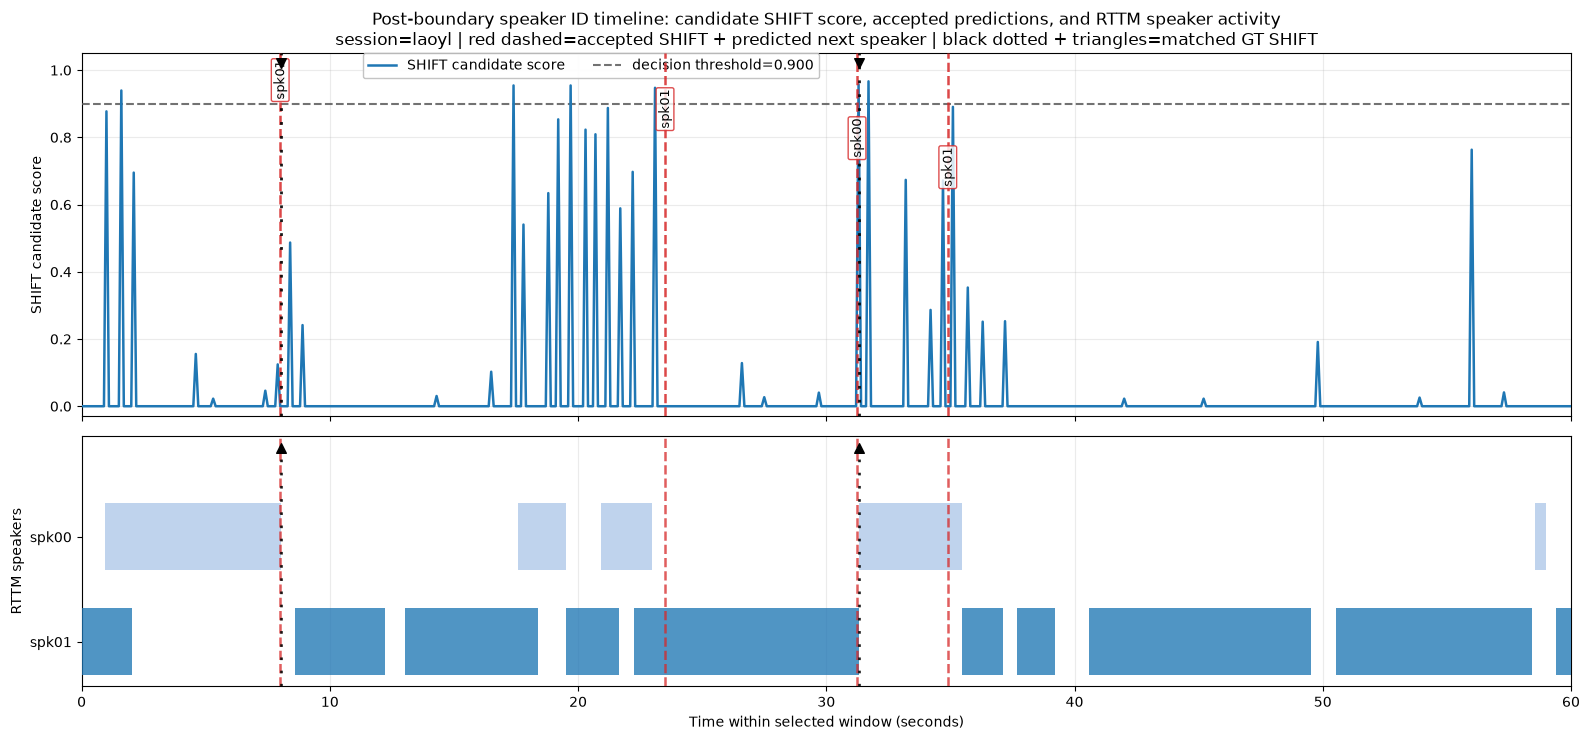

Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_candidate_score_rttm_timeline_visualizations/nextspeaker_candidate_score_rttm_timeline_laoyl_194p3_254p3.png
Candidate-score / RTTM post-boundary speaker-ID timeline summary
Selected session: laoyl
Window: 194.27s → 254.27s
Internal score source: BRANCH2_E2E_TEST_SCORES
Internal score column: branch2_e2e_prob_shift
Figure score label: SHIFT candidate score
Predicted SHIFTs in window: 4
GT matched SHIFTs in window: 2
Speakers shown: ['spk01', 'spk00']
Saved score curve: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_candidate_score_rttm_timeline_visualizations/nextspeaker_candidate_score_rttm_timeline_laoyl_194p3_254p3_score_curve.csv
Saved predictions: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_candidate_score_

In [56]:
# Candidate-score / RTTM post-boundary speaker-ID timeline visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

NS_PROTOCOL_NOTE = "RTTM-oracle inventory; future post-boundary audio; not causal decision-time prediction"

assert "TEST_PRED_DF_NS" in globals(), "Need TEST_PRED_DF_NS from Cell 22C."
assert "NS_E2E_MATCHED_DF" in globals(), "Need NS_E2E_MATCHED_DF from Cell 22D."
assert "read_rttm_as_turns" in globals(), "Need read_rttm_as_turns."
assert "TEST_RTTM" in globals(), "Need TEST_RTTM."

if "RUN_ROOT" in globals():
    NS_CAND_RTTM_VIZ_DIR = Path(RUN_ROOT) / "nextspeaker_candidate_score_rttm_timeline_visualizations"
else:
    NS_CAND_RTTM_VIZ_DIR = Path(".") / "nextspeaker_candidate_score_rttm_timeline_visualizations"

NS_CAND_RTTM_VIZ_DIR.mkdir(parents=True, exist_ok=True)

NS_CAND_RTTM_MAIN_TOL_LABEL = str(globals().get("NS_MAIN_TOL_LABEL", "strict_0p50"))

NS_CAND_RTTM_WINDOW_S = 60.0
NS_CAND_RTTM_LEFT_CONTEXT_S = 8.0
NS_CAND_RTTM_BIN_S = 0.10
NS_CAND_RTTM_MAX_SPEAKERS = 8
NS_CAND_RTTM_MAX_LABELS = 8

if bool(globals().get("NS_CAND_RTTM_ALLOW_MANUAL_WINDOW_OVERRIDE", False)):
    NS_CAND_RTTM_WINDOW_S = float(globals().get("NS_CAND_RTTM_MANUAL_WINDOW_S", NS_CAND_RTTM_WINDOW_S))
    NS_CAND_RTTM_LEFT_CONTEXT_S = float(globals().get("NS_CAND_RTTM_MANUAL_LEFT_CONTEXT_S", NS_CAND_RTTM_LEFT_CONTEXT_S))
    NS_CAND_RTTM_BIN_S = float(globals().get("NS_CAND_RTTM_MANUAL_BIN_S", NS_CAND_RTTM_BIN_S))
    NS_CAND_RTTM_MAX_SPEAKERS = int(globals().get("NS_CAND_RTTM_MANUAL_MAX_SPEAKERS", NS_CAND_RTTM_MAX_SPEAKERS))
    NS_CAND_RTTM_MAX_LABELS = int(globals().get("NS_CAND_RTTM_MANUAL_MAX_LABELS", NS_CAND_RTTM_MAX_LABELS))

NS_CAND_RTTM_SCORE_DISPLAY_LABEL = str(
    globals().get("NS_CAND_RTTM_SCORE_DISPLAY_LABEL", "SHIFT candidate score")
)

NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL = str(
    globals().get("NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL", "decision threshold")
)

NS_CAND_RTTM_PRED_SHIFT_COLOR = str(
    globals().get("NS_CAND_RTTM_PRED_SHIFT_COLOR", "tab:red")
)

NS_CAND_RTTM_GT_SHIFT_COLOR = str(
    globals().get("NS_CAND_RTTM_GT_SHIFT_COLOR", "black")
)

NS_CAND_RTTM_SCORE_COLOR = str(
    globals().get("NS_CAND_RTTM_SCORE_COLOR", "tab:blue")
)

NS_CAND_RTTM_THRESHOLD_COLOR = str(
    globals().get("NS_CAND_RTTM_THRESHOLD_COLOR", "0.35")
)

NS_CAND_RTTM_SHOW_CAVEAT_BOX = bool(
    globals().get("NS_CAND_RTTM_SHOW_CAVEAT_BOX", False)
)

NS_CAND_RTTM_SESSION = globals().get("NS_PAPER_SELECTED_SESSION", None)
NS_CAND_RTTM_CENTER_TIME = None

if "NS_PAPER_SELECTED_EVENT" in globals() and isinstance(NS_PAPER_SELECTED_EVENT, dict):
    try:
        NS_CAND_RTTM_CENTER_TIME = float(NS_PAPER_SELECTED_EVENT.get("pred_time", np.nan))
    except Exception:
        NS_CAND_RTTM_CENTER_TIME = None

print("=" * 80)
print("CELL 22F-B: Candidate-score / RTTM post-boundary speaker-ID timeline visualisation")
print("=" * 80)
print("Output directory:", NS_CAND_RTTM_VIZ_DIR)
print("Main tolerance:", NS_CAND_RTTM_MAIN_TOL_LABEL)
print("Note: this visualises our available candidate score, not MuVAP's original p(EOT).")

def _save_and_show(fig, filename):
    path = NS_CAND_RTTM_VIZ_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=240, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Saved:", path)

def _sid(x):
    return Path(str(x)).stem

def _clean_spk(x):
    if x is None:
        return pd.NA
    s = str(x).strip()
    if s.lower() in {"", "none", "nan", "<na>", "na", "null"}:
        return pd.NA
    return s

def _short(x, n=14):
    x = str(x)
    return x if len(x) <= n else x[:n] + "..."

def _rttm_path_for_session(session):
    sid = _sid(session)
    if sid in TEST_RTTM:
        return Path(TEST_RTTM[sid])
    if str(session) in TEST_RTTM:
        return Path(TEST_RTTM[str(session)])
    return None

def _choose_session_and_center():
    if NS_CAND_RTTM_SESSION is not None and NS_CAND_RTTM_CENTER_TIME is not None:
        return _sid(NS_CAND_RTTM_SESSION), float(NS_CAND_RTTM_CENTER_TIME)

    matched = NS_E2E_MATCHED_DF.copy()

    if "tolerance_label" in matched.columns:
        matched = matched[matched["tolerance_label"].astype(str).eq(NS_CAND_RTTM_MAIN_TOL_LABEL)].copy()

    matched["session"] = matched["session"].astype(str).map(_sid)
    matched["pred_time"] = pd.to_numeric(matched.get("pred_time", np.nan), errors="coerce")

    if "correct_next_speaker" in matched.columns:
        matched["correct_next_speaker"] = pd.to_numeric(
            matched["correct_next_speaker"],
            errors="coerce",
        ).fillna(0).astype(int)
    else:
        matched["correct_next_speaker"] = (
            matched.get("pred_next_speaker", "").astype(str)
            == matched.get("gt_next_speaker", "").astype(str)
        ).astype(int)

    matched = matched.dropna(subset=["session", "pred_time"]).copy()

    if len(matched) == 0:
        pred = TEST_PRED_DF_NS.copy()
        pred["session"] = pred["session"].astype(str).map(_sid)
        pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
        pred = pred.dropna(subset=["session", "time"]).copy()
        row = pred.iloc[0]
        return str(row["session"]), float(row["time"])

    correct = matched[matched["correct_next_speaker"].eq(1)].copy()
    if len(correct):
        matched = correct

    sess_counts = matched.groupby("session").size().sort_values(ascending=False)
    chosen_session = str(sess_counts.index[0])

    sess_rows = matched[matched["session"].eq(chosen_session)].sort_values("pred_time").reset_index(drop=True)
    center_idx = min(len(sess_rows) // 2, len(sess_rows) - 1)
    center_time = float(sess_rows.iloc[center_idx]["pred_time"])

    return chosen_session, center_time

def _get_candidate_score_source():
    candidates = []

    for name in [
        "BRANCH2_E2E_TEST_SCORES",
        "SYS2_FEATURES_ALL",
        "TEST_PRED_DF_NS",
        "TEST_PRED_DF",
    ]:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            df = globals()[name].copy()
            if "session" in df.columns and "time" in df.columns:
                candidates.append((name, df))

    score_cols_priority = [
        "branch2_e2e_prob_shift",
        "prob_shift",
        "final_score",
        "score",
        "sys2_score",
        "lgbm_score",
        "p_shift",
        "p_eot",
        "eot_score",
        "sys1_score",
        "wavlm_score",
        "cand_sys1_score",
        "peak_score",
    ]

    for name, df in candidates:
        if "split" in df.columns:
            part = df[df["split"].astype(str).eq("test")].copy()
            if len(part):
                df = part

        if name == "BRANCH2_E2E_TEST_SCORES":
            locked_setup = str(
                globals()
                .get("BRANCH2_E2E_LOCKED", {})
                .get("prediction_setup", "")
            )

            setup_col = (
                "branch2_e2e_setup"
                if "branch2_e2e_setup" in df.columns
                else "prediction_setup"
                if "prediction_setup" in df.columns
                else None
            )

            if locked_setup and setup_col is not None:
                locked_part = df[
                    df[setup_col].astype(str).eq(locked_setup)
                ].copy()

                if len(locked_part):
                    df = locked_part
                else:
                    print(
                        "WARNING: no Branch 2E timeline rows matched the "
                        f"VAL-locked setup={locked_setup!r}; trying the next "
                        "available score source."
                    )
                    continue

        for c in score_cols_priority:
            if c in df.columns:
                return name, df, c

    return None, pd.DataFrame(), None

def _score_display_name(score_col, source_name):
    return NS_CAND_RTTM_SCORE_DISPLAY_LABEL

def _make_score_curve(df, session, score_col, win_start, win_end):
    if df is None or len(df) == 0 or score_col is None:
        return pd.DataFrame(columns=["time", "score"])

    work = df.copy()
    work["session"] = work["session"].astype(str).map(_sid)
    work["time"] = pd.to_numeric(work["time"], errors="coerce")
    work[score_col] = pd.to_numeric(work[score_col], errors="coerce")

    work = work[
        work["session"].eq(str(session))
        & work["time"].between(float(win_start), float(win_end), inclusive="both")
    ].dropna(subset=["time", score_col]).copy()

    grid = np.arange(float(win_start), float(win_end) + 1e-9, float(NS_CAND_RTTM_BIN_S))
    curve = np.zeros_like(grid, dtype=float)

    if len(work):
        bin_idx = np.floor(
            (work["time"].to_numpy(dtype=float) - float(win_start)) / float(NS_CAND_RTTM_BIN_S)
        ).astype(int)
        bin_idx = np.clip(bin_idx, 0, len(grid) - 1)

        scores = work[score_col].to_numpy(dtype=float)

        for i, s in zip(bin_idx, scores):
            if np.isfinite(s):
                curve[i] = max(curve[i], float(s))

    return pd.DataFrame({"time": grid, "score": curve})

def _guess_reference_threshold(score_col):
    score_col = str(score_col or "").lower()

    if "branch2_e2e_prob_shift" in score_col and "BRANCH2_E2E_LOCKED" in globals():
        try:
            return float(BRANCH2_E2E_LOCKED.get("thr", 0.5)), NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL
        except Exception:
            pass

    for name in [
        "EOT_THR_USE",
        "EOT_THR",
        "TEST_EOT_THR",
        "FINAL_EOT_THR",
        "BEST_EOT_THR",
    ]:
        if name in globals():
            try:
                return float(globals()[name]), NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL
            except Exception:
                pass

    if "FINAL_TEST_SUMMARY" in globals() and isinstance(FINAL_TEST_SUMMARY, dict):
        for k in ["thr", "eot_thr", "EOT_THR", "threshold"]:
            if k in FINAL_TEST_SUMMARY:
                try:
                    return float(FINAL_TEST_SUMMARY[k]), NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL
                except Exception:
                    pass

    return 0.5, NS_CAND_RTTM_THRESHOLD_DISPLAY_LABEL

def _get_predictions_in_window(session, win_start, win_end):
    pred = TEST_PRED_DF_NS.copy()
    pred["session"] = pred["session"].astype(str).map(_sid)
    pred["time"] = pd.to_numeric(pred["time"], errors="coerce")
    pred = pred[
        pred["session"].eq(str(session))
        & pred["time"].between(float(win_start), float(win_end), inclusive="both")
    ].copy()

    if "next_speaker" not in pred.columns:
        pred["next_speaker"] = pd.NA

    pred["next_speaker"] = pred["next_speaker"].map(_clean_spk)

    return pred.sort_values("time").reset_index(drop=True)

def _get_gt_shift_lines(session, win_start, win_end):
    matched = NS_E2E_MATCHED_DF.copy()

    if "tolerance_label" in matched.columns:
        matched = matched[matched["tolerance_label"].astype(str).eq(NS_CAND_RTTM_MAIN_TOL_LABEL)].copy()

    if "gt_time" not in matched.columns:
        return pd.DataFrame()

    matched["session"] = matched["session"].astype(str).map(_sid)
    matched["gt_time"] = pd.to_numeric(matched["gt_time"], errors="coerce")

    matched = matched[
        matched["session"].eq(str(session))
        & matched["gt_time"].between(float(win_start), float(win_end), inclusive="both")
    ].copy()

    return matched.sort_values("gt_time").reset_index(drop=True)

session, center_time = _choose_session_and_center()

win_start = max(0.0, float(center_time) - float(NS_CAND_RTTM_LEFT_CONTEXT_S))
win_end = win_start + float(NS_CAND_RTTM_WINDOW_S)

rttm_path = _rttm_path_for_session(session)
assert rttm_path is not None and Path(rttm_path).exists(), f"Missing RTTM for session={session}"

turns = read_rttm_as_turns(rttm_path)
turns["session"] = turns.get("session", session)
turns["speaker"] = turns["speaker"].astype(str)
turns["start"] = pd.to_numeric(turns["start"], errors="coerce")
turns["end"] = pd.to_numeric(turns["end"], errors="coerce")
turns["dur"] = pd.to_numeric(turns.get("dur", turns["end"] - turns["start"]), errors="coerce")

turns_win = turns[
    (turns["end"] >= win_start)
    & (turns["start"] <= win_end)
].copy()

speaker_dur = (
    turns_win
    .assign(
        ov_start=lambda d: np.maximum(d["start"], win_start),
        ov_end=lambda d: np.minimum(d["end"], win_end),
    )
)

speaker_dur["ov_dur"] = np.maximum(0.0, speaker_dur["ov_end"] - speaker_dur["ov_start"])

speaker_order = (
    speaker_dur
    .groupby("speaker")["ov_dur"]
    .sum()
    .sort_values(ascending=False)
    .head(NS_CAND_RTTM_MAX_SPEAKERS)
    .index
    .tolist()
)

first_appearance = (
    turns_win[turns_win["speaker"].isin(speaker_order)]
    .groupby("speaker")["start"]
    .min()
    .sort_values()
    .index
    .tolist()
)

speaker_order = first_appearance

if len(speaker_order) == 0:
    speaker_order = sorted(turns_win["speaker"].dropna().astype(str).unique().tolist())[:NS_CAND_RTTM_MAX_SPEAKERS]

score_source_name, score_df, score_col = _get_candidate_score_source()
score_curve = _make_score_curve(score_df, session, score_col, win_start, win_end)

threshold, threshold_label = _guess_reference_threshold(score_col)
score_display_name = _score_display_name(score_col, score_source_name)

pred_win = _get_predictions_in_window(session, win_start, win_end)
gt_shift_win = _get_gt_shift_lines(session, win_start, win_end)

print("Selected session:", session)
print("Window:", f"{win_start:.2f}s → {win_end:.2f}s")
print("Internal score source:", score_source_name)
print("Internal score column:", score_col)
print("Figure score label:", score_display_name)
print("Figure threshold label:", threshold_label)
print("Reference threshold:", threshold)
print("Predicted SHIFTs in window:", len(pred_win))
print("GT matched SHIFTs in window:", len(gt_shift_win))
print("Speakers shown:", speaker_order)

fig, (ax_score, ax_rttm) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 7.5),
    sharex=True,
    gridspec_kw={"height_ratios": [1.45, 1.0]},
)

if len(score_curve):
    ax_score.plot(
        score_curve["time"] - win_start,
        score_curve["score"],
        color=NS_CAND_RTTM_SCORE_COLOR,
        linewidth=1.8,
        label=score_display_name,
        zorder=10,
    )
else:
    ax_score.text(
        0.5,
        0.5,
        "No candidate-score timeline found",
        transform=ax_score.transAxes,
        ha="center",
        va="center",
        fontsize=12,
    )

ax_score.axhline(
    threshold,
    color=NS_CAND_RTTM_THRESHOLD_COLOR,
    linestyle="--",
    linewidth=1.5,
    alpha=0.85,
    label=f"{threshold_label}={threshold:.3f}",
    zorder=8,
)

label_count = 0

for _, r in pred_win.iterrows():
    t = float(r["time"])
    rel_t = t - win_start
    ns = _clean_spk(r.get("next_speaker", pd.NA))

    ax_score.axvline(
        rel_t,
        color=NS_CAND_RTTM_PRED_SHIFT_COLOR,
        linestyle="--",
        linewidth=1.8,
        alpha=0.85,
        zorder=18,
    )

    ax_rttm.axvline(
        rel_t,
        color=NS_CAND_RTTM_PRED_SHIFT_COLOR,
        linestyle="--",
        linewidth=1.8,
        alpha=0.75,
        zorder=18,
    )

    if label_count < NS_CAND_RTTM_MAX_LABELS and pd.notna(ns):
        y_pos = 0.98 - 0.08 * (label_count % 4)
        ax_score.text(
            rel_t,
            y_pos,
            _short(ns, 8),
            rotation=90,
            ha="center",
            va="top",
            fontsize=9,
            color="black",
            transform=ax_score.get_xaxis_transform(),
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor=NS_CAND_RTTM_PRED_SHIFT_COLOR,
                alpha=0.82,
            ),
            zorder=24,
        )
        label_count += 1

for _, r in gt_shift_win.iterrows():
    t = float(r["gt_time"])
    rel_t = t - win_start

    ax_score.axvline(
        rel_t,
        color=NS_CAND_RTTM_GT_SHIFT_COLOR,
        linestyle=(0, (1, 4)),
        linewidth=2.0,
        alpha=0.90,
        zorder=22,
    )

    ax_rttm.axvline(
        rel_t,
        color=NS_CAND_RTTM_GT_SHIFT_COLOR,
        linestyle=(0, (1, 4)),
        linewidth=1.9,
        alpha=0.88,
        zorder=22,
    )

    ax_score.scatter(
        [rel_t],
        [1.02],
        marker="v",
        s=48,
        color=NS_CAND_RTTM_GT_SHIFT_COLOR,
        zorder=25,
        clip_on=False,
    )

    marker_y = len(speaker_order) - 0.15 if len(speaker_order) else 0.0

    ax_rttm.scatter(
        [rel_t],
        [marker_y],
        marker="^",
        s=48,
        color=NS_CAND_RTTM_GT_SHIFT_COLOR,
        zorder=25,
        clip_on=False,
    )

ax_score.set_title(
    "Post-boundary speaker ID timeline: candidate SHIFT score, accepted predictions, and RTTM speaker activity\n"
    f"session={session} | red dashed=accepted SHIFT + predicted next speaker | black dotted + triangles=matched GT SHIFT"
)

ax_score.set_ylabel("SHIFT candidate score")
ax_score.set_ylim(-0.03, 1.05)
ax_score.grid(alpha=0.25)

ax_score.legend(
    loc="upper right",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=True,
    fontsize=10,
    framealpha=0.92,
    facecolor="white",
    edgecolor="0.75",
)

if NS_CAND_RTTM_SHOW_CAVEAT_BOX:
    ax_score.text(
        0.01,
        0.04,
        "Visualisation note: this is our available candidate-score timeline,\n"
        "not MuVAP's original continuous p(EOT) curve.",
        transform=ax_score.transAxes,
        ha="left",
        va="bottom",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.30",
            facecolor="white",
            edgecolor="0.75",
            alpha=0.92,
        ),
    )

colors = {}

for i, spk in enumerate(speaker_order):
    colors[spk] = plt.cm.tab20(i % 20)

y_positions = {spk: i for i, spk in enumerate(speaker_order)}

for spk in speaker_order:
    yy = y_positions[spk]
    g = turns_win[turns_win["speaker"].astype(str).eq(str(spk))].copy()

    intervals = []

    for _, r in g.iterrows():
        s = max(float(r["start"]), win_start)
        e = min(float(r["end"]), win_end)

        if e <= s:
            continue

        intervals.append((s - win_start, e - s))

    if intervals:
        ax_rttm.broken_barh(
            intervals,
            (yy - 0.32, 0.64),
            facecolors=colors[spk],
            alpha=0.78,
            zorder=5,
        )

ax_rttm.set_yticks(list(y_positions.values()))
ax_rttm.set_yticklabels([_short(s, 12) for s in speaker_order])
ax_rttm.set_ylabel("RTTM speakers")
ax_rttm.set_xlabel("Time within selected window (seconds)")
ax_rttm.set_xlim(0.0, win_end - win_start)
ax_rttm.grid(axis="x", alpha=0.25)

fname = f"nextspeaker_candidate_score_rttm_timeline_{session}_{win_start:.1f}_{win_end:.1f}".replace(".", "p")
_save_and_show(fig, f"{fname}.png")

score_out = NS_CAND_RTTM_VIZ_DIR / f"{fname}_score_curve.csv"
pred_out = NS_CAND_RTTM_VIZ_DIR / f"{fname}_predictions.csv"
turns_out = NS_CAND_RTTM_VIZ_DIR / f"{fname}_rttm_turns.csv"

score_curve.to_csv(score_out, index=False)
pred_win.to_csv(pred_out, index=False)
turns_win.to_csv(turns_out, index=False)

globals()["NS_CAND_RTTM_SELECTED_SESSION"] = session
globals()["NS_CAND_RTTM_SCORE_CURVE_CSV"] = str(score_out)
globals()["NS_CAND_RTTM_PREDICTIONS_CSV"] = str(pred_out)
globals()["NS_CAND_RTTM_TURNS_CSV"] = str(turns_out)
globals()["NS_CAND_RTTM_VIZ_DIR"] = str(NS_CAND_RTTM_VIZ_DIR)

globals()["NS_EOT_RTTM_SELECTED_SESSION"] = session
globals()["NS_EOT_RTTM_SCORE_CURVE_CSV"] = str(score_out)
globals()["NS_EOT_RTTM_PREDICTIONS_CSV"] = str(pred_out)
globals()["NS_EOT_RTTM_TURNS_CSV"] = str(turns_out)
globals()["NS_EOT_RTTM_VIZ_DIR"] = str(NS_CAND_RTTM_VIZ_DIR)

print("=" * 80)
print("Candidate-score / RTTM post-boundary speaker-ID timeline summary")
print("=" * 80)
print("Selected session:", session)
print("Window:", f"{win_start:.2f}s → {win_end:.2f}s")
print("Internal score source:", score_source_name)
print("Internal score column:", score_col)
print("Figure score label:", score_display_name)
print("Predicted SHIFTs in window:", len(pred_win))
print("GT matched SHIFTs in window:", len(gt_shift_win))
print("Speakers shown:", speaker_order)
print("Saved score curve:", score_out)
print("Saved predictions:", pred_out)
print("Saved RTTM turns:", turns_out)
print("Protocol:", NS_PROTOCOL_NOTE)
print("✅ Cell 22F-B complete: candidate-score / RTTM post-boundary speaker-ID timeline saved.")

In [57]:
# MuVAP-inspired decision-point post-boundary speaker-ID diagnostic
import json
import time
import math
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Dict, Any, List
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.metrics import accuracy_score, f1_score

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "VAP_DP_TEST" in globals(), "Need VAP_DP_TEST from Cell 5B."
assert "NS_TEST_PROTOTYPES" in globals(), "Need NS_TEST_PROTOTYPES from Cell 22C."
assert "ns_predict_next_speaker_for_time" in globals(), "Need ns_predict_next_speaker_for_time from Cell 22C."

NEXTSPEAKER_DIR = RUN_ROOT / "nextspeaker_oracle_inventory_postboundary"
NEXTSPEAKER_DIR.mkdir(parents=True, exist_ok=True)

NS_MUVAP_DIR = NEXTSPEAKER_DIR / "muvap_style_decision_point_nsp"
NS_MUVAP_DIR.mkdir(parents=True, exist_ok=True)

NS_MUVAP_PRED_CSV = NS_MUVAP_DIR / "decision_point_postboundary_speaker_id_rows.csv"
NS_MUVAP_METRICS_CSV = NS_MUVAP_DIR / "decision_point_postboundary_speaker_id_metrics.csv"
NS_MUVAP_CARD_JSON = NS_MUVAP_DIR / "decision_point_postboundary_speaker_id_card.json"
NS_MUVAP_META_JSON = NS_MUVAP_DIR / "decision_point_postboundary_speaker_id.meta.json"

FORCE_REBUILD_NS_MUVAP_DP = bool(globals().get("FORCE_REBUILD_NS_MUVAP_DP", False))

NS_MUVAP_MAIN_SETUP = str(globals().get("NS_MUVAP_MAIN_SETUP", globals().get("BRANCH2_MAIN_SETUP", "silent_100ms")))

raw_setups_22g = globals().get("NS_MUVAP_SETUPS_TO_RUN", [NS_MUVAP_MAIN_SETUP])
NS_MUVAP_SETUPS_TO_RUN = [raw_setups_22g] if isinstance(raw_setups_22g, str) else list(raw_setups_22g)

NS_MUVAP_PROTOCOLS = list(globals().get(
    "NS_MUVAP_PROTOCOLS",
    ["decision_time", "next_start_oracle"],
))

NS_MUVAP_MAX_EVENTS = globals().get("NS_MUVAP_MAX_EVENTS", None)

print("=" * 80)
print("CELL 22G: MuVAP-inspired decision-point post-boundary speaker-ID diagnostic")
print("=" * 80)
print("Main setup:", NS_MUVAP_MAIN_SETUP)
print("Setups to run:", NS_MUVAP_SETUPS_TO_RUN)
print("Protocols:", NS_MUVAP_PROTOCOLS)
print("Output directory:", NS_MUVAP_DIR)

def _nsm_json_safe(x):
    if isinstance(x, dict):
        return {str(k): _nsm_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)):
        return [_nsm_json_safe(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, pd.DataFrame):
        return x.to_dict("records")
    if isinstance(x, pd.Series):
        return x.to_dict()
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, float):
        return x if math.isfinite(x) else None
    try:
        if pd.isna(x):
            return None
    except Exception:
        pass
    return x

def _nsm_session_id(x) -> str:
    return Path(str(x)).stem

def _nsm_clean_spk(x):
    if x is None:
        return pd.NA
    s = str(x).strip()
    if s.lower() in {"", "none", "nan", "<na>", "na", "null"}:
        return pd.NA
    return s

def _nsm_prepare_shift_decision_points() -> pd.DataFrame:
    dp = VAP_DP_TEST.copy()

    dp["session"] = dp["session"].astype(str).map(_nsm_session_id)

    if "branch2_split" in dp.columns:
        dp = dp[dp["branch2_split"].astype(str).eq("test")].copy()

    if "prediction_setup" in dp.columns:
        dp = dp[dp["prediction_setup"].astype(str).isin([str(x) for x in NS_MUVAP_SETUPS_TO_RUN])].copy()
    else:
        dp["prediction_setup"] = NS_MUVAP_MAIN_SETUP

    if "label" in dp.columns:
        dp["label"] = pd.to_numeric(dp["label"], errors="coerce").fillna(0).astype(int)
        dp = dp[dp["label"].eq(1)].copy()

    for c in ["decision_time", "event_time", "next_start"]:
        if c not in dp.columns:
            dp[c] = np.nan
        dp[c] = pd.to_numeric(dp[c], errors="coerce")

    for c in ["prev_speaker", "current_speaker", "next_speaker"]:
        if c not in dp.columns:
            dp[c] = pd.NA
        dp[c] = dp[c].map(_nsm_clean_spk)

    dp = dp.dropna(subset=["session", "next_speaker"]).copy()

    if "prev_speaker" in dp.columns:
        dp = dp[dp["prev_speaker"].astype(str) != dp["next_speaker"].astype(str)].copy()

    dp = dp[
        dp["decision_time"].notna()
        | dp["event_time"].notna()
        | dp["next_start"].notna()
    ].copy()

    dp = dp.sort_values(["prediction_setup", "session", "decision_time", "event_time"]).reset_index(drop=True)

    dp["nsp_dp_id"] = np.arange(len(dp), dtype=int)

    if NS_MUVAP_MAX_EVENTS is not None:
        max_n = int(NS_MUVAP_MAX_EVENTS)
        dp = dp.head(max_n).copy()

    return dp

def _nsm_protocol_time(row: pd.Series, protocol: str) -> float:
    protocol = str(protocol)

    if protocol == "decision_time":
        t = row.get("decision_time", np.nan)
        if pd.notna(t):
            return float(t)

    elif protocol == "event_time":
        t = row.get("event_time", np.nan)
        if pd.notna(t):
            return float(t)

    elif protocol == "next_start_oracle":
        t = row.get("next_start", np.nan)
        if pd.notna(t):
            return float(t)

    for c in ["decision_time", "event_time", "next_start"]:
        t = row.get(c, np.nan)
        if pd.notna(t):
            return float(t)

    return np.nan

def _nsm_speaker_metrics(df: pd.DataFrame) -> Dict[str, Any]:
    if df is None or len(df) == 0:
        return {
            "n_eval": 0,
            "accuracy": np.nan,
            "macro_f1": np.nan,
            "weighted_f1": np.nan,
        }

    work = df.copy()
    work["pred_next_speaker"] = work["pred_next_speaker"].map(_nsm_clean_spk)
    work["gt_next_speaker"] = work["gt_next_speaker"].map(_nsm_clean_spk)

    work = work.dropna(subset=["pred_next_speaker", "gt_next_speaker"]).copy()

    if len(work) == 0:
        return {
            "n_eval": 0,
            "accuracy": np.nan,
            "macro_f1": np.nan,
            "weighted_f1": np.nan,
        }

    y_true = (
        work["session"].astype(str)
        + "::"
        + work["gt_next_speaker"].astype(str)
    ).tolist()

    y_pred = (
        work["session"].astype(str)
        + "::"
        + work["pred_next_speaker"].astype(str)
    ).tolist()

    labels = sorted(set(y_true) | set(y_pred))

    return {
        "n_eval": int(len(work)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "n_unique_true_session_speakers": int(len(set(y_true))),
        "n_unique_pred_session_speakers": int(len(set(y_pred))),
    }

def _nsm_evaluate_prediction_table(pred_df: pd.DataFrame) -> pd.DataFrame:
    rows = []

    if pred_df is None or len(pred_df) == 0:
        return pd.DataFrame()

    for (setup, protocol), g in pred_df.groupby(["prediction_setup", "protocol"], dropna=False):
        available = g[g["pred_next_speaker"].map(_nsm_clean_spk).notna()].copy()

        m = _nsm_speaker_metrics(available)

        correct = int(
            (
                available["pred_next_speaker"].astype(str)
                == available["gt_next_speaker"].astype(str)
            ).sum()
        ) if len(available) else 0

        rows.append({
            "task": "MuVAP-inspired decision-point post-boundary speaker identification",
            "uses_rttm_oracle_inventory": True,
            "uses_future_postboundary_audio": True,
            "causal_decision_time_prediction": False,
            "prediction_setup": str(setup),
            "protocol": str(protocol),
            "n_decision_points": int(len(g)),
            "next_speaker_available": int(len(available)),
            "coverage": float(len(available) / max(1, len(g))),
            "correct": int(correct),
            "accuracy": m["accuracy"],
            "macro_f1": m["macro_f1"],
            "weighted_f1": m["weighted_f1"],
            "n_unique_true_session_speakers": m.get("n_unique_true_session_speakers", 0),
            "n_unique_pred_session_speakers": m.get("n_unique_pred_session_speakers", 0),
            "mean_score": float(pd.to_numeric(available.get("next_speaker_score", np.nan), errors="coerce").mean()) if len(available) else np.nan,
            "mean_margin": float(pd.to_numeric(available.get("next_speaker_margin", np.nan), errors="coerce").mean()) if len(available) else np.nan,
        })

    return pd.DataFrame(rows).sort_values(["prediction_setup", "protocol"]).reset_index(drop=True)

NS_MUVAP_EXPECTED_META = {
    "variant": "muvap_inspired_postboundary_oracle_inventory_speaker_id_v2",
    "main_setup": NS_MUVAP_MAIN_SETUP,
    "setups": list(map(str, NS_MUVAP_SETUPS_TO_RUN)),
    "protocols": list(map(str, NS_MUVAP_PROTOCOLS)),
    "max_events": NS_MUVAP_MAX_EVENTS,
    "prototype_meta": str(globals().get("NS_PROTO_META_PATH", "")),
    "decision_point_rows": int(len(VAP_DP_TEST)),
}
try:
    old_meta_22g = json.loads(NS_MUVAP_META_JSON.read_text()) if NS_MUVAP_META_JSON.exists() else None
except Exception:
    old_meta_22g = None
CACHE_VALID_22G = old_meta_22g == _nsm_json_safe(NS_MUVAP_EXPECTED_META)

if NS_MUVAP_PRED_CSV.exists() and NS_MUVAP_METRICS_CSV.exists() and CACHE_VALID_22G and not FORCE_REBUILD_NS_MUVAP_DP:
    NS_MUVAP_DP_PRED_DF = pd.read_csv(NS_MUVAP_PRED_CSV)
    NS_MUVAP_DP_METRICS_DF = pd.read_csv(NS_MUVAP_METRICS_CSV)
    print("Loaded MuVAP-style NSP predictions:", NS_MUVAP_PRED_CSV)

else:
    shift_dp = _nsm_prepare_shift_decision_points()

    print("Prepared SHIFT decision points:", shift_dp.shape)
    display(
        shift_dp
        .groupby(["prediction_setup"], dropna=False)
        .agg(
            n=("session", "count"),
            n_sessions=("session", "nunique"),
        )
        .reset_index()
    )

    rows = []

    for r in tqdm(shift_dp.itertuples(index=False), total=len(shift_dp), desc="MuVAP-style NSP"):
        row = pd.Series(r._asdict())

        sid = _nsm_session_id(row["session"])
        setup = str(row.get("prediction_setup", NS_MUVAP_MAIN_SETUP))
        gt_next = _nsm_clean_spk(row.get("next_speaker", pd.NA))
        gt_prev = _nsm_clean_spk(row.get("prev_speaker", pd.NA))

        for protocol in NS_MUVAP_PROTOCOLS:
            pred_t = _nsm_protocol_time(row, protocol)

            if not np.isfinite(pred_t):
                continue

            ns = ns_predict_next_speaker_for_time(
                session=sid,
                tau=float(pred_t),
                proto_cache=NS_TEST_PROTOTYPES,
            )

            pred_spk = _nsm_clean_spk(ns.get("next_speaker", pd.NA))

            rows.append({
                "nsp_dp_id": int(row.get("nsp_dp_id", -1)),
                "session": sid,
                "prediction_setup": setup,
                "protocol": str(protocol),
                "speaker_prediction_time": float(pred_t),
                "decision_time": float(row.get("decision_time", np.nan)) if pd.notna(row.get("decision_time", np.nan)) else np.nan,
                "event_time": float(row.get("event_time", np.nan)) if pd.notna(row.get("event_time", np.nan)) else np.nan,
                "next_start": float(row.get("next_start", np.nan)) if pd.notna(row.get("next_start", np.nan)) else np.nan,
                "gt_prev_speaker": gt_prev,
                "gt_next_speaker": gt_next,
                "pred_next_speaker": pred_spk,
                "correct_next_speaker": int(str(pred_spk) == str(gt_next)) if pd.notna(pred_spk) and pd.notna(gt_next) else 0,
                "next_speaker_score": ns.get("next_speaker_score", np.nan),
                "next_speaker_margin": ns.get("next_speaker_margin", np.nan),
                "next_speaker_num_candidates": ns.get("next_speaker_num_candidates", 0),
                "next_speaker_available": ns.get("next_speaker_available", 0),
                "next_speaker_post_start": ns.get("next_speaker_post_start", np.nan),
                "next_speaker_post_rms": ns.get("next_speaker_post_rms", 0.0),
                "action": str(row.get("action", "")),
                "gap": float(row.get("gap", np.nan)) if pd.notna(row.get("gap", np.nan)) else np.nan,
                "overlap": float(row.get("overlap", np.nan)) if pd.notna(row.get("overlap", np.nan)) else np.nan,
            })

    NS_MUVAP_DP_PRED_DF = pd.DataFrame(rows)
    NS_MUVAP_DP_METRICS_DF = _nsm_evaluate_prediction_table(NS_MUVAP_DP_PRED_DF)

    NS_MUVAP_DP_PRED_DF.to_csv(NS_MUVAP_PRED_CSV, index=False)
    NS_MUVAP_DP_METRICS_DF.to_csv(NS_MUVAP_METRICS_CSV, index=False)
    NS_MUVAP_META_JSON.write_text(json.dumps(_nsm_json_safe(NS_MUVAP_EXPECTED_META), indent=2, sort_keys=True))

    try:
        save_ecapa_embedding_cache()
    except Exception:
        pass

main_rows = NS_MUVAP_DP_METRICS_DF[
    NS_MUVAP_DP_METRICS_DF["prediction_setup"].astype(str).eq(NS_MUVAP_MAIN_SETUP)
].copy()

decision_row = main_rows[main_rows["protocol"].astype(str).eq("decision_time")].copy()
nextstart_row = main_rows[main_rows["protocol"].astype(str).eq("next_start_oracle")].copy()

NS_MUVAP_DP_FINAL_DECISION_TIME = decision_row.iloc[0].to_dict() if len(decision_row) else {}
NS_MUVAP_DP_FINAL_NEXT_START_ORACLE = nextstart_row.iloc[0].to_dict() if len(nextstart_row) else {}

NS_MUVAP_DP_CARD = {
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "variant": "muvap_inspired_postboundary_oracle_inventory_speaker_id_v2",
    "description": (
        "Controlled decision-point next-speaker prediction using RTTM-derived "
        "Branch 2 SHIFT decision points and ECAPA cosine speaker prototypes."
    ),
    "interpretation": {
        "decision_time": (
            "The decision point is controlled, but the speaker-ID window starts there and extends into future audio; this is not causal prediction."
        ),
        "next_start_oracle": (
            "Diagnostic upper-bound for the speaker-identification part. "
            "The model starts from the true next-speaker onset."
        ),
        "important_caveat": (
            "Unlike MuVAP, this audio-only diagnostic uses no face tracks, uses RTTM-derived full-recording speaker prototypes, and consumes post-boundary audio."
        ),
    },
    "main_setup": NS_MUVAP_MAIN_SETUP,
    "setups_run": list(NS_MUVAP_SETUPS_TO_RUN),
    "protocols": list(NS_MUVAP_PROTOCOLS),
    "decision_time_main_metrics": NS_MUVAP_DP_FINAL_DECISION_TIME,
    "next_start_oracle_main_metrics": NS_MUVAP_DP_FINAL_NEXT_START_ORACLE,
    "files": {
        "predictions_csv": str(NS_MUVAP_PRED_CSV),
        "metrics_csv": str(NS_MUVAP_METRICS_CSV),
        "card_json": str(NS_MUVAP_CARD_JSON),
    },
}

NS_MUVAP_CARD_JSON.write_text(json.dumps(_nsm_json_safe(NS_MUVAP_DP_CARD), indent=2, sort_keys=True))

globals()["NS_MUVAP_DP_PRED_DF"] = NS_MUVAP_DP_PRED_DF
globals()["NS_MUVAP_DP_METRICS_DF"] = NS_MUVAP_DP_METRICS_DF
globals()["NS_MUVAP_DP_FINAL_DECISION_TIME"] = NS_MUVAP_DP_FINAL_DECISION_TIME
globals()["NS_MUVAP_DP_FINAL_NEXT_START_ORACLE"] = NS_MUVAP_DP_FINAL_NEXT_START_ORACLE
globals()["NS_MUVAP_DP_CARD"] = NS_MUVAP_DP_CARD

globals()["NS_MUVAP_PRED_CSV"] = str(NS_MUVAP_PRED_CSV)
globals()["NS_MUVAP_METRICS_CSV"] = str(NS_MUVAP_METRICS_CSV)
globals()["NS_MUVAP_CARD_JSON"] = str(NS_MUVAP_CARD_JSON)

print("=" * 80)
print("MuVAP-style decision-point next-speaker metrics")
print("=" * 80)
display(NS_MUVAP_DP_METRICS_DF)

print("Main setup:", NS_MUVAP_MAIN_SETUP)

if NS_MUVAP_DP_FINAL_DECISION_TIME:
    print("\nDecision-time protocol:")
    for k in ["n_decision_points", "coverage", "accuracy", "macro_f1", "weighted_f1", "mean_score", "mean_margin"]:
        v = NS_MUVAP_DP_FINAL_DECISION_TIME.get(k)
        print(f"  {k}: {v:.4f}" if isinstance(v, (int, float)) and np.isfinite(v) else f"  {k}: {v}")

if NS_MUVAP_DP_FINAL_NEXT_START_ORACLE:
    print("\nNext-start oracle protocol:")
    for k in ["n_decision_points", "coverage", "accuracy", "macro_f1", "weighted_f1", "mean_score", "mean_margin"]:
        v = NS_MUVAP_DP_FINAL_NEXT_START_ORACLE.get(k)
        print(f"  {k}: {v:.4f}" if isinstance(v, (int, float)) and np.isfinite(v) else f"  {k}: {v}")

print("\nSaved predictions:", NS_MUVAP_PRED_CSV)
print("Saved metrics:", NS_MUVAP_METRICS_CSV)
print("Saved card:", NS_MUVAP_CARD_JSON)
print("✅ Cell 22G complete: MuVAP-inspired post-boundary speaker-ID diagnostic finished.")

CELL 22G: MuVAP-inspired decision-point post-boundary speaker-ID diagnostic
Main setup: silent_100ms
Setups to run: ['silent_100ms']
Protocols: ['decision_time', 'next_start_oracle']
Output directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary/muvap_style_decision_point_nsp
Prepared SHIFT decision points: (5131, 36)


,prediction_setup,n,n_sessions
0,silent_100ms,5131,213


Saved bounded ECAPA cache: 20000 -> <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/ecapa/ecapa_segment_embedding_cache_bounded.pkl
MuVAP-style decision-point next-speaker metrics


,task,uses_rttm_oracle_inventory,uses_future_postboundary_audio,causal_decision_time_prediction,prediction_setup,protocol,n_decision_points,next_speaker_available,coverage,correct,accuracy,macro_f1,weighted_f1,n_unique_true_session_speakers,n_unique_pred_session_speakers,mean_score,mean_margin
0,MuVAP-inspired decision-point post-boundary sp...,True,True,False,silent_100ms,decision_time,5131,5129,0.99961,4155,0.810099,0.786687,0.812122,1166,1166,0.495358,0.299598
1,MuVAP-inspired decision-point post-boundary sp...,True,True,False,silent_100ms,next_start_oracle,5131,5131,1.00000,4224,0.823231,0.796945,0.826746,1166,1169,0.497399,0.298408


Main setup: silent_100ms

Decision-time protocol:
  n_decision_points: 5131.0000
  coverage: 0.9996
  accuracy: 0.8101
  macro_f1: 0.7867
  weighted_f1: 0.8121
  mean_score: 0.4954
  mean_margin: 0.2996

Next-start oracle protocol:
  n_decision_points: 5131.0000
  coverage: 1.0000
  accuracy: 0.8232
  macro_f1: 0.7969
  weighted_f1: 0.8267
  mean_score: 0.4974
  mean_margin: 0.2984

Saved predictions: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary/muvap_style_decision_point_nsp/decision_point_postboundary_speaker_id_rows.csv
Saved metrics: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/nextspeaker_oracle_inventory_postboundary/muvap_style_decision_point_nsp/decision_point_postboundary_speaker_id_metrics.csv
Saved card: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY

In [58]:
import json
import time
import math
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from tqdm.auto import tqdm

assert "RUN_ROOT" in globals()
assert "PYANNOTE_TURNS" in globals()
assert "TEST_SESSIONS" in globals()
assert "TEST_RTTM" in globals()
assert "read_rttm_as_turns" in globals()
if not isinstance(PYANNOTE_TURNS, pd.DataFrame) or len(PYANNOTE_TURNS) == 0:
    raise RuntimeError("PYANNOTE_TURNS is unavailable; rerun Cell 9.")

NS_AUTO_DIR = Path(RUN_ROOT) / "nextspeaker_auto_inventory"
NS_AUTO_DIR.mkdir(parents=True, exist_ok=True)
NS_AUTO_TURNS_TEST_CSV = NS_AUTO_DIR / "auto_inventory_pyannote_test_turns.csv"
NS_AUTO_CLUSTER_MAP_CSV = NS_AUTO_DIR / "auto_inventory_cluster_mapping_hungarian.csv"
NS_AUTO_SESSION_AUDIT_CSV = NS_AUTO_DIR / "auto_inventory_session_audit.csv"
NS_AUTO_AUDIT_CARD_JSON = NS_AUTO_DIR / "auto_inventory_audit_card.json"

def _sid(x): return Path(str(x)).stem

def _rttm(sid):
    return Path(TEST_RTTM.get(_sid(sid), TEST_RTTM.get(str(sid), "")))

def _overlap(a0,a1,b0,b1): return max(0.0, min(float(a1),float(b1))-max(float(a0),float(b0)))

def _turns(df):
    out = df.copy()
    out["session"] = out["session"].astype(str).map(_sid)
    out["speaker"] = out["speaker"].astype(str)
    out["start"] = pd.to_numeric(out["start"], errors="coerce")
    out["end"] = pd.to_numeric(out["end"], errors="coerce")
    out["dur"] = pd.to_numeric(out.get("dur", out["end"]-out["start"]), errors="coerce").fillna(out["end"]-out["start"])
    out = out.dropna(subset=["session","speaker","start","end"])
    out = out[out["end"]>out["start"]]
    if "is_synthetic" in out.columns:
        out = out[pd.to_numeric(out["is_synthetic"],errors="coerce").fillna(0).eq(0)]
    test_ids = {_sid(x) for x in TEST_SESSIONS}
    return out[out["session"].isin(test_ids)].sort_values(["session","start","end"]).reset_index(drop=True)

def _gt(sid):
    p = _rttm(sid)
    if not p.exists(): return pd.DataFrame(columns=["speaker","start","end","dur"])
    g = read_rttm_as_turns(p).copy()
    g["speaker"] = g["speaker"].astype(str)
    g["start"] = pd.to_numeric(g["start"],errors="coerce"); g["end"] = pd.to_numeric(g["end"],errors="coerce")
    g["dur"] = g["end"]-g["start"]
    return g.dropna(subset=["speaker","start","end"])[lambda x:x.end>x.start].reset_index(drop=True)

def _overlap_matrix(auto, gt):
    ac = sorted(auto["speaker"].unique()); gs = sorted(gt["speaker"].unique())
    mat = np.zeros((len(ac),len(gs)), dtype=np.float64)
    for i,c in enumerate(ac):
        ca = auto[auto["speaker"].eq(c)]
        for j,gspk in enumerate(gs):
            gg = gt[gt["speaker"].eq(gspk)]
            total=0.0
            for ar in ca.itertuples(index=False):
                local=gg[(gg.end>ar.start)&(gg.start<ar.end)]
                total += sum(_overlap(ar.start,ar.end,gr.start,gr.end) for gr in local.itertuples(index=False))
            mat[i,j]=total
    return ac,gs,mat

def _hungarian_map(sid, auto, gt):
    ac,gs,mat=_overlap_matrix(auto,gt)
    assigned={}
    if len(ac) and len(gs):
        try:
            from scipy.optimize import linear_sum_assignment
            rr,cc=linear_sum_assignment(-mat)
            assigned={int(i):int(j) for i,j in zip(rr,cc) if mat[i,j]>0}
        except Exception:
            candidates=sorted([(-mat[i,j],i,j) for i in range(len(ac)) for j in range(len(gs)) if mat[i,j]>0])
            ui,uj=set(),set()
            for _,i,j in candidates:
                if i not in ui and j not in uj: assigned[i]=j; ui.add(i); uj.add(j)
    rows=[]
    for i,c in enumerate(ac):
        total_auto=float((auto.loc[auto.speaker.eq(c),"end"]-auto.loc[auto.speaker.eq(c),"start"]).sum())
        best_j=int(np.argmax(mat[i])) if len(gs) else -1
        map_j=assigned.get(i,None)
        best=float(mat[i,best_j]) if best_j>=0 else 0.0
        mapped=float(mat[i,map_j]) if map_j is not None else 0.0
        rows.append({
            "session":_sid(sid),"auto_cluster":c,
            "mapped_rttm_speaker":gs[map_j] if map_j is not None else pd.NA,
            "independent_best_rttm_speaker":gs[best_j] if best_j>=0 and best>0 else pd.NA,
            "mapped_overlap_s":mapped,"independent_best_overlap_s":best,
            "auto_cluster_total_s":total_auto,
            "mapping_coverage":mapped/max(1e-12,total_auto),
            "one_to_one_mapping":True,
        })
    return rows

NS_AUTO_TURNS_TEST=_turns(PYANNOTE_TURNS)
map_rows=[]; audit=[]
for sid,auto in tqdm(NS_AUTO_TURNS_TEST.groupby("session"), desc="Automatic inventory audit"):
    gt=_gt(sid); rows=_hungarian_map(sid,auto,gt); map_rows.extend(rows)
    cm=pd.DataFrame(rows)
    mapped=cm[cm["mapped_rttm_speaker"].notna()] if len(cm) else pd.DataFrame()
    audit.append({
        "session":sid,"n_auto_clusters":auto.speaker.nunique(),"n_rttm_speakers":gt.speaker.nunique() if len(gt) else 0,
        "n_one_to_one_mapped_clusters":len(mapped),
        "weighted_mapping_coverage":float(np.average(cm.mapping_coverage,weights=cm.auto_cluster_total_s)) if len(cm) and cm.auto_cluster_total_s.sum()>0 else np.nan,
        "usable_for_auto_inventory":int(auto.speaker.nunique()>=2 and len(mapped)>=2),
    })
NS_AUTO_CLUSTER_MAP_DF=pd.DataFrame(map_rows)
NS_AUTO_SESSION_AUDIT_DF=pd.DataFrame(audit)
NS_AUTO_TURNS_TEST.to_csv(NS_AUTO_TURNS_TEST_CSV,index=False)
NS_AUTO_CLUSTER_MAP_DF.to_csv(NS_AUTO_CLUSTER_MAP_CSV,index=False)
NS_AUTO_SESSION_AUDIT_DF.to_csv(NS_AUTO_SESSION_AUDIT_CSV,index=False)
NS_AUTO_INVENTORY_AUDIT_CARD={
    "created_at":time.strftime("%Y-%m-%d %H:%M:%S"),
    "mapping":"one-to-one Hungarian maximum temporal overlap; scoring only",
    "prediction_uses_rttm_mapping":False,
    "n_sessions":int(NS_AUTO_SESSION_AUDIT_DF.session.nunique()) if len(NS_AUTO_SESSION_AUDIT_DF) else 0,
    "usable_sessions":int(NS_AUTO_SESSION_AUDIT_DF.usable_for_auto_inventory.sum()) if len(NS_AUTO_SESSION_AUDIT_DF) else 0,
}
NS_AUTO_AUDIT_CARD_JSON.write_text(json.dumps(NS_AUTO_INVENTORY_AUDIT_CARD,indent=2,sort_keys=True,default=str))
for n in ["NS_AUTO_TURNS_TEST","NS_AUTO_CLUSTER_MAP_DF","NS_AUTO_SESSION_AUDIT_DF","NS_AUTO_INVENTORY_AUDIT_CARD"]: globals()[n]=locals()[n]
display(NS_AUTO_SESSION_AUDIT_DF.describe(include="all"))
print("✅ Cell 26A complete. This is an audit; Cells 26B–26C perform the actual automatic-inventory experiment.")

,session,n_auto_clusters,n_rttm_speakers,n_one_to_one_mapped_clusters,weighted_mapping_coverage,usable_for_auto_inventory
count,232,232.000000,232.000000,232.000000,232.000000,232.000000
unique,232,NaN,NaN,NaN,NaN,NaN
top,aepyx,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.068966,6.478448,4.922414,0.914232,0.913793
std,NaN,3.150549,3.944360,3.108850,0.071171,0.281276
min,NaN,1.000000,1.000000,1.000000,0.622728,0.000000
25%,NaN,3.000000,3.000000,2.000000,0.887718,1.000000
50%,NaN,4.000000,6.000000,4.000000,0.931048,1.000000
75%,NaN,7.000000,9.000000,7.000000,0.962162,1.000000


✅ Cell 26A complete. This is an audit; Cells 26B–26C perform the actual automatic-inventory experiment.


In [59]:
# Automatic-inventory ECAPA prototypes
import json
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

assert "NS_AUTO_TURNS_TEST" in globals(), "Run Cell 26A."
assert "NS_AUTO_DIR" in globals(), "Run Cell 26A."
assert "TEST_AUDIO" in globals()
assert "ecapa_embed_segment" in globals()
assert "_ns_embed_best_post_segment" in globals(), "Run updated Cell 22C."

NS_AUTO_PROTO_SEG_S = float(
    globals().get("NS_AUTO_PROTO_SEG_S", 1.50)
)
NS_AUTO_MIN_SEG_S = float(
    globals().get("NS_AUTO_MIN_SEG_S", 0.40)
)
NS_AUTO_BANK_MAX_PER_CLUSTER = int(
    globals().get("NS_AUTO_BANK_MAX_PER_CLUSTER", 80)
)
NS_AUTO_FULL_ENROLL_PER_CLUSTER = int(
    globals().get("NS_AUTO_FULL_ENROLL_PER_CLUSTER", 20)
)
NS_AUTO_PREFIX_ENROLL_PER_CLUSTER = int(
    globals().get("NS_AUTO_PREFIX_ENROLL_PER_CLUSTER", 12)
)
NS_AUTO_PREFIX_GUARD_S = float(
    globals().get("NS_AUTO_PREFIX_GUARD_S", 0.05)
)
NS_AUTO_MIN_CLUSTERS = int(
    globals().get("NS_AUTO_MIN_CLUSTERS", 2)
)

FORCE_REBUILD_NS_AUTO_PROTOTYPES = bool(
    globals().get("FORCE_REBUILD_NS_AUTO_PROTOTYPES", False)
)

NS_AUTO_EMBED_BANK_PATH = (
    Path(NS_AUTO_DIR) / "automatic_cluster_segment_embedding_bank_v3.pkl"
)
NS_AUTO_EMBED_BANK_META_PATH = (
    Path(NS_AUTO_DIR) / "automatic_cluster_segment_embedding_bank_v3.meta.json"
)
NS_AUTO_FULL_PROTO_PATH = (
    Path(NS_AUTO_DIR) / "automatic_cluster_full_recording_prototypes_v3.pkl"
)
NS_AUTO_FULL_PROTO_META_PATH = (
    Path(NS_AUTO_DIR) / "automatic_cluster_full_recording_prototypes_v3.meta.json"
)

def _ns_auto_l2(x):
    x = np.asarray(x, dtype=np.float32).reshape(-1)
    norm = float(np.linalg.norm(x))
    if not np.isfinite(norm) or norm < 1e-8:
        return x
    return x / norm

def _ns_auto_audio(session) -> Path:
    sid = Path(str(session)).stem
    return Path(TEST_AUDIO.get(sid, TEST_AUDIO.get(str(session), "")))

def _ns_auto_select_turns(group: pd.DataFrame) -> pd.DataFrame:
    work = group.copy()
    work["start"] = pd.to_numeric(work["start"], errors="coerce")
    work["end"] = pd.to_numeric(work["end"], errors="coerce")
    work["dur"] = work["end"] - work["start"]
    work = work.dropna(subset=["start", "end", "dur"])
    work = work[work["dur"] >= NS_AUTO_MIN_SEG_S].sort_values("start")

    if len(work) <= NS_AUTO_BANK_MAX_PER_CLUSTER:
        return work.reset_index(drop=True)

    early_n = min(20, NS_AUTO_BANK_MAX_PER_CLUSTER // 2)
    early = work.head(early_n)
    remaining_n = NS_AUTO_BANK_MAX_PER_CLUSTER - len(early)

    rest = work.iloc[early_n:]
    if remaining_n > 0 and len(rest):
        positions = np.linspace(
            0,
            len(rest) - 1,
            num=min(remaining_n, len(rest)),
        ).round().astype(int)
        sampled = rest.iloc[np.unique(positions)]
        work = pd.concat([early, sampled], ignore_index=True)
    else:
        work = early.copy()

    return (
        work
        .drop_duplicates(subset=["start", "end"])
        .sort_values("start")
        .head(NS_AUTO_BANK_MAX_PER_CLUSTER)
        .reset_index(drop=True)
    )

def _ns_auto_build_embedding_bank():
    records = []

    groups = NS_AUTO_TURNS_TEST.groupby(
        ["session", "speaker"],
        sort=False,
    )

    for (session, cluster), group in tqdm(
        groups,
        total=groups.ngroups,
        desc="Automatic-cluster ECAPA bank",
    ):
        audio_path = _ns_auto_audio(session)
        if not audio_path.exists():
            continue

        selected = _ns_auto_select_turns(group)

        for row in selected.itertuples(index=False):
            available_dur = float(row.end - row.start)
            duration_s = min(NS_AUTO_PROTO_SEG_S, available_dur)
            if duration_s < NS_AUTO_MIN_SEG_S:
                continue

            start_s = float(row.start) + max(
                0.0,
                available_dur - duration_s,
            ) / 2.0

            embedding = ecapa_embed_segment(
                audio_path,
                start_s,
                duration_s,
                use_cache=False,
            )

            if embedding is None:
                continue

            embedding = _ns_auto_l2(embedding)
            if not np.isfinite(embedding).all():
                continue

            records.append({
                "session": str(session),
                "auto_cluster": str(cluster),
                "turn_start": float(row.start),
                "turn_end": float(row.end),
                "embed_start": float(start_s),
                "embed_dur": float(duration_s),
                "embedding": embedding.astype(np.float32),
            })

    bank = pd.DataFrame(records)

    payload = {
        "variant": "automatic_cluster_embedding_bank_v3",
        "records": bank,
    }
    pd.to_pickle(payload, NS_AUTO_EMBED_BANK_PATH)

    NS_AUTO_EMBED_BANK_META_PATH.write_text(
        json.dumps(
            {
                "variant": "automatic_cluster_embedding_bank_v3",
                "proto_seg_s": NS_AUTO_PROTO_SEG_S,
                "min_seg_s": NS_AUTO_MIN_SEG_S,
                "max_segments_per_cluster": NS_AUTO_BANK_MAX_PER_CLUSTER,
                "n_records": int(len(bank)),
                "uses_global_segment_cache": False,
            },
            indent=2,
            sort_keys=True,
        )
    )
    return bank

if NS_AUTO_EMBED_BANK_PATH.exists() and not FORCE_REBUILD_NS_AUTO_PROTOTYPES:
    payload = pd.read_pickle(NS_AUTO_EMBED_BANK_PATH)
    NS_AUTO_EMBED_BANK_DF = payload.get("records", pd.DataFrame())
    print("Loaded automatic-cluster embedding bank:", NS_AUTO_EMBED_BANK_PATH)
else:
    NS_AUTO_EMBED_BANK_DF = _ns_auto_build_embedding_bank()

if len(NS_AUTO_EMBED_BANK_DF) == 0:
    raise RuntimeError("Automatic-cluster embedding bank is empty.")

def _ns_auto_make_prototypes(
    bank: pd.DataFrame,
    max_per_cluster: int,
):
    prototypes = {}

    for (session, cluster), group in bank.groupby(
        ["session", "auto_cluster"],
        sort=False,
    ):
        work = group.sort_values(
            ["turn_end", "embed_dur"],
            ascending=[False, False],
        ).head(int(max_per_cluster))

        embeddings = [
            _ns_auto_l2(x)
            for x in work["embedding"].tolist()
            if x is not None
        ]
        if not embeddings:
            continue

        prototypes.setdefault(str(session), {})[str(cluster)] = _ns_auto_l2(
            np.mean(np.stack(embeddings), axis=0)
        )

    return prototypes

if NS_AUTO_FULL_PROTO_PATH.exists() and not FORCE_REBUILD_NS_AUTO_PROTOTYPES:
    payload = pd.read_pickle(NS_AUTO_FULL_PROTO_PATH)
    NS_AUTO_FULL_RECORDING_PROTOTYPES = payload.get("prototypes", {})
else:
    NS_AUTO_FULL_RECORDING_PROTOTYPES = _ns_auto_make_prototypes(
        NS_AUTO_EMBED_BANK_DF,
        NS_AUTO_FULL_ENROLL_PER_CLUSTER,
    )
    pd.to_pickle(
        {
            "variant": "automatic_full_recording_prototypes_v3",
            "prototypes": NS_AUTO_FULL_RECORDING_PROTOTYPES,
        },
        NS_AUTO_FULL_PROTO_PATH,
    )
    NS_AUTO_FULL_PROTO_META_PATH.write_text(
        json.dumps(
            {
                "variant": "automatic_full_recording_prototypes_v3",
                "enrol_per_cluster": NS_AUTO_FULL_ENROLL_PER_CLUSTER,
                "n_sessions": len(NS_AUTO_FULL_RECORDING_PROTOTYPES),
            },
            indent=2,
            sort_keys=True,
        )
    )

def _ns_auto_query_against_prototypes(
    session,
    tau,
    prototypes,
    protocol,
):
    sid = Path(str(session)).stem
    audio_path = _ns_auto_audio(sid)

    default = {
        "session": sid,
        "time": float(tau),
        "protocol": str(protocol),
        "pred_auto_cluster": pd.NA,
        "auto_cluster_score": np.nan,
        "auto_cluster_margin": np.nan,
        "auto_cluster_available": 0,
        "inventory_cluster_count": int(len(prototypes)),
    }

    if len(prototypes) < NS_AUTO_MIN_CLUSTERS or not audio_path.exists():
        return default

    query_embedding, query_meta = _ns_embed_best_post_segment(
        audio_path,
        float(tau),
    )
    if query_embedding is None:
        return default

    labels = sorted(prototypes)
    matrix = np.stack([
        _ns_auto_l2(prototypes[label]) for label in labels
    ])
    scores = matrix @ _ns_auto_l2(query_embedding)
    order = np.argsort(-scores)

    result = {
        **default,
        "pred_auto_cluster": labels[int(order[0])],
        "auto_cluster_score": float(scores[order[0]]),
        "auto_cluster_margin": (
            float(scores[order[0]] - scores[order[1]])
            if len(order) > 1 else np.nan
        ),
        "auto_cluster_available": 1,
        "post_start": query_meta.get("post_start", np.nan),
        "post_rms": query_meta.get("post_rms", 0.0),
    }
    return result

def ns_predict_auto_cluster_full_recording(session, tau):
    sid = Path(str(session)).stem
    prototypes = NS_AUTO_FULL_RECORDING_PROTOTYPES.get(sid, {})
    return _ns_auto_query_against_prototypes(
        sid,
        tau,
        prototypes,
        protocol="automatic_full_recording",
    )

def ns_predict_auto_cluster_prefix(session, tau):
    sid = Path(str(session)).stem
    cutoff = float(tau) - float(NS_AUTO_PREFIX_GUARD_S)

    bank = NS_AUTO_EMBED_BANK_DF[
        NS_AUTO_EMBED_BANK_DF["session"].astype(str).eq(sid)
        & (
            pd.to_numeric(
                NS_AUTO_EMBED_BANK_DF["turn_end"],
                errors="coerce",
            ) <= cutoff
        )
    ].copy()

    prototypes = _ns_auto_make_prototypes(
        bank,
        NS_AUTO_PREFIX_ENROLL_PER_CLUSTER,
    ).get(sid, {})

    return _ns_auto_query_against_prototypes(
        sid,
        tau,
        prototypes,
        protocol="automatic_prefix_enrolment",
    )

ns_predict_auto_cluster_for_time = ns_predict_auto_cluster_full_recording
NS_AUTO_TEST_PROTOTYPES = NS_AUTO_FULL_RECORDING_PROTOTYPES

for name in [
    "NS_AUTO_EMBED_BANK_DF",
    "NS_AUTO_FULL_RECORDING_PROTOTYPES",
    "NS_AUTO_TEST_PROTOTYPES",
    "ns_predict_auto_cluster_full_recording",
    "ns_predict_auto_cluster_prefix",
    "ns_predict_auto_cluster_for_time",
]:
    globals()[name] = locals()[name]

print("Embedding-bank rows:", len(NS_AUTO_EMBED_BANK_DF))
print(
    "Full-recording automatic prototype sessions:",
    len(NS_AUTO_FULL_RECORDING_PROTOTYPES),
)
print(
    "Prefix condition uses only turns ending before decision_time, "
    "but cluster identities still come from offline diarization."
)
print("✅ Cell 26B complete.")

Embedding-bank rows: 18916
Full-recording automatic prototype sessions: 232
Prefix condition uses only turns ending before decision_time, but cluster identities still come from offline diarization.
✅ Cell 26B complete.


In [60]:
# Oracle-vs-automatic inventory comparison
import json
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display

assert "NS_AUTO_CLUSTER_MAP_DF" in globals(), "Run Cell 26A."
assert "ns_predict_auto_cluster_full_recording" in globals(), "Run Cell 26B."
assert "ns_predict_auto_cluster_prefix" in globals(), "Run Cell 26B."
assert "NS_E2E_MATCHED_DF" in globals(), "Run Cell 22D."
assert "TEST_PRED_EVAL_DF" in globals(), "Run Cell 22."

NS_AUTO_COMPARISON_DIR = Path(NS_AUTO_DIR)
NS_AUTO_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

map_lookup = {
    (str(row.session), str(row.auto_cluster)): str(row.mapped_rttm_speaker)
    for row in NS_AUTO_CLUSTER_MAP_DF
    .dropna(subset=["mapped_rttm_speaker"])
    .itertuples(index=False)
}

strict_matches = NS_E2E_MATCHED_DF[
    NS_E2E_MATCHED_DF["tolerance_label"].astype(str).eq("strict_0p50")
].copy()

if len(strict_matches) == 0:
    raise RuntimeError("No strict matched SHIFT events are available.")

def _evaluate_auto_condition(condition_name, predictor):
    rows = []

    for row in tqdm(
        strict_matches.itertuples(index=False),
        total=len(strict_matches),
        desc=condition_name,
    ):
        result = predictor(row.session, row.pred_time)
        predicted_cluster = result.get("pred_auto_cluster", pd.NA)

        mapped_speaker = map_lookup.get(
            (str(row.session), str(predicted_cluster)),
            pd.NA,
        )

        available = int(pd.notna(mapped_speaker))
        correct = int(
            available
            and str(mapped_speaker) == str(row.gt_next_speaker)
        )

        rows.append({
            "condition": condition_name,
            "session": str(row.session),
            "pred_time": float(row.pred_time),
            "gt_time": float(row.gt_time),
            "gt_next_speaker": str(row.gt_next_speaker),
            "pred_auto_cluster": predicted_cluster,
            "mapped_pred_rttm_speaker": mapped_speaker,
            "available": available,
            "correct": correct,
            "score": result.get("auto_cluster_score", np.nan),
            "margin": result.get("auto_cluster_margin", np.nan),
            "inventory_cluster_count": result.get(
                "inventory_cluster_count",
                0,
            ),
        })

    pred_df = pd.DataFrame(rows)

    n_pred = int(
        globals().get(
            "FINAL_TEST_SUMMARY",
            {},
        ).get("N_pred", len(TEST_PRED_EVAL_DF))
    )
    n_gt = int(
        globals().get(
            "FINAL_TEST_SUMMARY",
            {},
        ).get("N_gt", 0)
    )

    correct_count = int(pred_df["correct"].sum()) if len(pred_df) else 0
    available_count = int(pred_df["available"].sum()) if len(pred_df) else 0

    joint_precision = correct_count / max(1, n_pred)
    joint_recall = correct_count / max(1, n_gt)
    joint_f1 = (
        2.0 * joint_precision * joint_recall
        / max(1e-12, joint_precision + joint_recall)
    )

    metrics = {
        "inventory_condition": condition_name,
        "speaker_query": "post-boundary audio",
        "matched_shift_count": int(len(strict_matches)),
        "available": available_count,
        "coverage_on_matched": (
            available_count / max(1, len(strict_matches))
        ),
        "conditional_accuracy": (
            float(
                pred_df.loc[pred_df["available"].eq(1), "correct"].mean()
            )
            if available_count else np.nan
        ),
        "correct_speaker_events": correct_count,
        "joint_correct_speaker_precision": float(joint_precision),
        "joint_correct_speaker_recall": float(joint_recall),
        "joint_correct_speaker_f1": float(joint_f1),
        "rttm_mapping_used_for_prediction": False,
        "rttm_mapping_used_for_scoring_only": True,
    }
    return pred_df, metrics

full_pred, full_metrics = _evaluate_auto_condition(
    "automatic_full_recording",
    ns_predict_auto_cluster_full_recording,
)

prefix_pred, prefix_metrics = _evaluate_auto_condition(
    "automatic_prefix_enrolment",
    ns_predict_auto_cluster_prefix,
)

NS_AUTO_MATCHED_PRED_DF = pd.concat(
    [full_pred, prefix_pred],
    ignore_index=True,
)

oracle_metrics = globals().get("NS_E2E_FINAL_METRICS", {})

NS_AUTO_COMPARISON_DF = pd.DataFrame([
    {
        "inventory": "RTTM oracle",
        "prototype_audio": "full recording RTTM segments",
        "speaker_query": "post-boundary audio",
        "conditional_accuracy": oracle_metrics.get(
            "conditional_speaker_id_accuracy",
            np.nan,
        ),
        "coverage_on_matched": oracle_metrics.get(
            "speaker_id_coverage_on_matched",
            np.nan,
        ),
        "joint_f1": oracle_metrics.get(
            "joint_correct_speaker_f1",
            np.nan,
        ),
    },
    {
        "inventory": "Automatic diarization — full recording",
        "prototype_audio": "all automatic-cluster turns",
        "speaker_query": "post-boundary audio",
        "conditional_accuracy": full_metrics["conditional_accuracy"],
        "coverage_on_matched": full_metrics["coverage_on_matched"],
        "joint_f1": full_metrics["joint_correct_speaker_f1"],
    },
    {
        "inventory": "Automatic diarization — prefix enrolment",
        "prototype_audio": "automatic-cluster turns ending before decision",
        "speaker_query": "post-boundary audio",
        "conditional_accuracy": prefix_metrics["conditional_accuracy"],
        "coverage_on_matched": prefix_metrics["coverage_on_matched"],
        "joint_f1": prefix_metrics["joint_correct_speaker_f1"],
    },
])

NS_AUTO_FINAL_METRICS = {
    "automatic_full_recording": full_metrics,
    "automatic_prefix_enrolment": prefix_metrics,
    "important_limitation": (
        "Prefix enrolment excludes future prototype audio, but pyannote "
        "cluster identities are still produced by offline diarization."
    ),
}

NS_AUTO_MATCHED_PRED_PATH = (
    NS_AUTO_COMPARISON_DIR
    / "automatic_inventory_matched_shift_speaker_id_v3.csv"
)
NS_AUTO_COMPARISON_PATH = (
    NS_AUTO_COMPARISON_DIR
    / "oracle_vs_automatic_inventory_comparison_v3.csv"
)
NS_AUTO_METRICS_PATH = (
    NS_AUTO_COMPARISON_DIR
    / "automatic_inventory_metrics_v3.json"
)

NS_AUTO_MATCHED_PRED_DF.to_csv(
    NS_AUTO_MATCHED_PRED_PATH,
    index=False,
)
NS_AUTO_COMPARISON_DF.to_csv(
    NS_AUTO_COMPARISON_PATH,
    index=False,
)
NS_AUTO_METRICS_PATH.write_text(
    json.dumps(
        NS_AUTO_FINAL_METRICS,
        indent=2,
        sort_keys=True,
        default=str,
    )
)

for name in [
    "NS_AUTO_MATCHED_PRED_DF",
    "NS_AUTO_COMPARISON_DF",
    "NS_AUTO_FINAL_METRICS",
    "NS_AUTO_MATCHED_PRED_PATH",
    "NS_AUTO_COMPARISON_PATH",
    "NS_AUTO_METRICS_PATH",
]:
    globals()[name] = locals()[name]

display(NS_AUTO_COMPARISON_DF)
print(NS_AUTO_FINAL_METRICS["important_limitation"])
print("✅ Cell 26C complete.")

automatic_prefix_enrolment: 100%|██████████| 3609/3609 [00:15<00:00, 235.59it/s]


,inventory,prototype_audio,speaker_query,conditional_accuracy,coverage_on_matched,joint_f1
0,RTTM oracle,full recording RTTM segments,post-boundary audio,0.871433,1.000000,0.480924
1,Automatic diarization — full recording,all automatic-cluster turns,post-boundary audio,0.809924,0.988362,0.441777
2,Automatic diarization — prefix enrolment,automatic-cluster turns ending before decision,post-boundary audio,0.721126,0.954835,0.379998


Prefix enrolment excludes future prototype audio, but pyannote cluster identities are still produced by offline diarization.
✅ Cell 26C complete.


In [61]:
# Build system-floor opportunity labels
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

assert "BRANCH3_TABLE_ALL" in globals(), "Run the updated Cell 16C."
assert "BRANCH3_MAIN_SETUP" in globals(), "Run Cell 19H or define BRANCH3_MAIN_SETUP."
assert "DEV_RTTM" in globals() and "TEST_RTTM" in globals()
assert "read_rttm_as_turns" in globals()

SYSTEM_FLOOR_HORIZONS = [
    float(x) for x in globals().get("SYSTEM_FLOOR_HORIZONS", [1.0, 1.5])
]
SYSTEM_FLOOR_MIN_ACTIVITY_S = float(
    globals().get("SYSTEM_FLOOR_MIN_ACTIVITY_S", 0.05)
)

def _sf_sid(x) -> str:
    return Path(str(x)).stem

def _sf_rttm_for(session: str, split_name: str) -> Path:
    lookup = TEST_RTTM if str(split_name) == "test" else DEV_RTTM
    sid = _sf_sid(session)
    return Path(lookup.get(sid, lookup.get(str(session), "")))

def _sf_overlap(a0, a1, b0, b1) -> float:
    return max(0.0, min(float(a1), float(b1)) - max(float(a0), float(b0)))

base = BRANCH3_TABLE_ALL.copy()

if "prediction_setup" in base.columns:
    base = base[
        base["prediction_setup"].astype(str).eq(str(BRANCH3_MAIN_SETUP))
    ].copy()

if "branch2_split" in base.columns:
    base["sf_split"] = base["branch2_split"].astype(str)
elif "split" in base.columns:
    base["sf_split"] = base["split"].astype(str)
else:
    raise KeyError("Branch 3 table has neither branch2_split nor split.")

valid_splits = {"train", "val", "test"}
base = base[base["sf_split"].isin(valid_splits)].copy()

base["session"] = base["session"].astype(str).map(_sf_sid)

if "decision_time" not in base.columns:
    if "time" not in base.columns:
        raise KeyError("Branch 3 table has neither decision_time nor time.")
    base["decision_time"] = pd.to_numeric(base["time"], errors="coerce")
else:
    base["decision_time"] = pd.to_numeric(base["decision_time"], errors="coerce")

base = base.dropna(subset=["session", "decision_time"]).reset_index(drop=True)
base["source_row_index"] = np.arange(len(base), dtype=np.int64)

speaker_col = (
    "current_speaker"
    if "current_speaker" in base.columns
    else "prev_speaker"
    if "prev_speaker" in base.columns
    else None
)
if speaker_col is None:
    raise KeyError("No current_speaker/prev_speaker column is available.")

label_rows = []

for (split_name, sid), group in tqdm(
    base.groupby(["sf_split", "session"], sort=False),
    desc="System-floor labels",
):
    rttm_path = _sf_rttm_for(sid, split_name)
    if not rttm_path.exists():
        continue

    turns = read_rttm_as_turns(rttm_path).copy()
    turns["start"] = pd.to_numeric(turns["start"], errors="coerce")
    turns["end"] = pd.to_numeric(turns["end"], errors="coerce")
    turns["speaker"] = turns["speaker"].astype(str)
    turns = turns.dropna(subset=["start", "end", "speaker"])
    turns = turns[turns["end"] > turns["start"]].reset_index(drop=True)

    for row in group.itertuples(index=False):
        tau = float(row.decision_time)
        current_speaker = str(getattr(row, speaker_col))

        for horizon_s in SYSTEM_FLOOR_HORIZONS:
            end_time = tau + float(horizon_s)
            local = turns[
                (turns["end"] > tau) & (turns["start"] < end_time)
            ]

            same_activity_s = sum(
                _sf_overlap(tau, end_time, x.start, x.end)
                for x in local.itertuples(index=False)
                if str(x.speaker) == current_speaker
            )
            other_activity_s = sum(
                _sf_overlap(tau, end_time, x.start, x.end)
                for x in local.itertuples(index=False)
                if str(x.speaker) != current_speaker
            )

            if other_activity_s >= SYSTEM_FLOOR_MIN_ACTIVITY_S:
                floor_class = "HUMAN_SHIFT"
            elif same_activity_s >= SYSTEM_FLOOR_MIN_ACTIVITY_S:
                floor_class = "HOLD"
            else:
                floor_class = "SYSTEM_OPPORTUNITY"

            label_rows.append({
                "source_row_index": int(row.source_row_index),
                "horizon_s": float(horizon_s),
                "system_floor_class": floor_class,
                "system_opportunity": int(floor_class == "SYSTEM_OPPORTUNITY"),
                "same_activity_s": float(same_activity_s),
                "other_activity_s": float(other_activity_s),
            })

SYSTEM_FLOOR_LABELS_DF = pd.DataFrame(label_rows)

if len(SYSTEM_FLOOR_LABELS_DF) == 0:
    raise RuntimeError("No system-floor labels were constructed.")

SYSTEM_FLOOR_TABLE = base.merge(
    SYSTEM_FLOOR_LABELS_DF,
    on="source_row_index",
    how="inner",
    validate="one_to_many",
)

SYSTEM_FLOOR_TABLE["split"] = SYSTEM_FLOOR_TABLE["sf_split"].astype(str)

duplicate_keys = SYSTEM_FLOOR_TABLE.duplicated(
    subset=["session", "decision_time", "horizon_s"],
    keep=False,
)
if duplicate_keys.any():
    examples = SYSTEM_FLOOR_TABLE.loc[
        duplicate_keys,
        ["session", "decision_time", "horizon_s"],
    ].head(10)
    raise RuntimeError(
        "System-floor table still contains duplicated decision-point/horizon "
        f"keys.\n{examples}"
    )

globals()["SYSTEM_FLOOR_LABELS_DF"] = SYSTEM_FLOOR_LABELS_DF
globals()["SYSTEM_FLOOR_TABLE"] = SYSTEM_FLOOR_TABLE

print(
    SYSTEM_FLOOR_TABLE
    .groupby(["split", "horizon_s", "system_floor_class"])
    .size()
)
print("System-floor table:", SYSTEM_FLOOR_TABLE.shape)
print("Prediction setup:", BRANCH3_MAIN_SETUP)
print("✅ Cell 28A complete.")

split  horizon_s  system_floor_class
test   1.0        HOLD                  3560
                  HUMAN_SHIFT           5567
                  SYSTEM_OPPORTUNITY      28
       1.5        HOLD                  3511
                  HUMAN_SHIFT           5626
                  SYSTEM_OPPORTUNITY      18
train  1.0        HOLD                  1256
                  HUMAN_SHIFT           2067
                  SYSTEM_OPPORTUNITY       6
       1.5        HOLD                  1232
                  HUMAN_SHIFT           2091
                  SYSTEM_OPPORTUNITY       6
val    1.0        HOLD                   526
                  HUMAN_SHIFT            459
                  SYSTEM_OPPORTUNITY       2
       1.5        HOLD                   521
                  HUMAN_SHIFT            465
                  SYSTEM_OPPORTUNITY       1
dtype: int64
System-floor table: (26942, 120)
Prediction setup: silent_100ms
✅ Cell 28A complete.


In [62]:
# Binary system-floor opportunity classifier
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
)
import lightgbm as lgb

assert "SYSTEM_FLOOR_TABLE" in globals(), "Run Cell 28A."
assert "BRANCH3_FEATURE_COLS" in globals(), "Run the updated Cell 16C."
assert "SEED" in globals()

SYSTEM_FLOOR_DIR = Path(RUN_ROOT) / "system_floor_opportunity_past_only_v2"
SYSTEM_FLOOR_DIR.mkdir(parents=True, exist_ok=True)

SYSTEM_FLOOR_BINARY_METRICS_PATH = SYSTEM_FLOOR_DIR / "binary_metrics.csv"
SYSTEM_FLOOR_BINARY_PRED_PATH = SYSTEM_FLOOR_DIR / "binary_test_predictions.csv"
SYSTEM_FLOOR_BINARY_META_PATH = SYSTEM_FLOOR_DIR / "binary_model_metadata.json"

FORCE_RETRAIN_SYSTEM_FLOOR = bool(
    globals().get("FORCE_RETRAIN_SYSTEM_FLOOR", False)
)

SYSTEM_FLOOR_FEATURE_COLS = [
    c for c in BRANCH3_FEATURE_COLS
    if c in SYSTEM_FLOOR_TABLE.columns
    and (
        pd.api.types.is_numeric_dtype(SYSTEM_FLOOR_TABLE[c])
        or pd.api.types.is_bool_dtype(SYSTEM_FLOOR_TABLE[c])
    )
]

known_noncausal = set(
    globals().get("BRANCH2_KNOWN_NONCAUSAL_FEATURES", set())
)
bad_features = sorted(set(SYSTEM_FLOOR_FEATURE_COLS) & known_noncausal)

if bad_features:
    raise RuntimeError(
        f"System-floor binary model selected non-causal features: {bad_features}"
    )
if not SYSTEM_FLOOR_FEATURE_COLS:
    raise RuntimeError("No strict past-only system-floor features are available.")

expected_meta = {
    "variant": "system_floor_binary_past_only_v2",
    "feature_cols": list(SYSTEM_FLOOR_FEATURE_COLS),
    "horizons": sorted(
        pd.to_numeric(
            SYSTEM_FLOOR_TABLE["horizon_s"], errors="coerce"
        ).dropna().astype(float).unique().tolist()
    ),
}

def _sf_binary_cache_valid() -> bool:
    if FORCE_RETRAIN_SYSTEM_FLOOR:
        return False
    required = [
        SYSTEM_FLOOR_BINARY_METRICS_PATH,
        SYSTEM_FLOOR_BINARY_PRED_PATH,
        SYSTEM_FLOOR_BINARY_META_PATH,
    ]
    if not all(p.exists() for p in required):
        return False
    try:
        meta = json.loads(SYSTEM_FLOOR_BINARY_META_PATH.read_text())
        if meta.get("variant") != expected_meta["variant"]:
            return False
        if meta.get("feature_cols") != expected_meta["feature_cols"]:
            return False
        for horizon_s in expected_meta["horizons"]:
            if not (
                SYSTEM_FLOOR_DIR
                / f"binary_model_h{str(horizon_s).replace('.', 'p')}.joblib"
            ).exists():
                return False
        return True
    except Exception:
        return False

if _sf_binary_cache_valid():
    SYSTEM_FLOOR_BINARY_METRICS_DF = pd.read_csv(
        SYSTEM_FLOOR_BINARY_METRICS_PATH
    )
    SYSTEM_FLOOR_BINARY_PRED_DF = pd.read_csv(
        SYSTEM_FLOOR_BINARY_PRED_PATH
    )
    SYSTEM_FLOOR_BINARY_MODELS = {}
    for horizon_s in expected_meta["horizons"]:
        model_path = (
            SYSTEM_FLOOR_DIR
            / f"binary_model_h{str(horizon_s).replace('.', 'p')}.joblib"
        )
        SYSTEM_FLOOR_BINARY_MODELS[float(horizon_s)] = joblib.load(model_path)

    print("Loaded cached binary system-floor models and outputs.")

else:
    metric_rows = []
    pred_parts = []
    SYSTEM_FLOOR_BINARY_MODELS = {}
    threshold_by_horizon = {}

    for horizon_s, group in SYSTEM_FLOOR_TABLE.groupby("horizon_s", sort=True):
        train_df = group[group["split"].astype(str).eq("train")].copy()
        val_df = group[group["split"].astype(str).eq("val")].copy()
        test_df = group[group["split"].astype(str).eq("test")].copy()

        if min(len(train_df), len(val_df), len(test_df)) == 0:
            raise RuntimeError(
                f"Missing train/val/test rows for horizon {horizon_s}."
            )

        def _x(df):
            return (
                df[SYSTEM_FLOOR_FEATURE_COLS]
                .apply(pd.to_numeric, errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(0.0)
            )

        x_train, x_val, x_test = _x(train_df), _x(val_df), _x(test_df)
        y_train = train_df["system_opportunity"].astype(int)
        y_val = val_df["system_opportunity"].astype(int)
        y_test = test_df["system_opportunity"].astype(int)

        model = lgb.LGBMClassifier(
            objective="binary",
            n_estimators=800,
            learning_rate=0.03,
            num_leaves=31,
            subsample=0.90,
            colsample_bytree=0.90,
            random_state=int(SEED),
            class_weight="balanced",
            verbosity=-1,
        )
        model.fit(
            x_train,
            y_train,
            eval_set=[(x_val, y_val)],
            callbacks=[lgb.early_stopping(80, verbose=False)],
        )

        val_prob = model.predict_proba(x_val)[:, 1]
        threshold_grid = np.linspace(0.05, 0.95, 181)

        val_rows = []
        for threshold in threshold_grid:
            pred = (val_prob >= threshold).astype(int)
            p, r, f1, _ = precision_recall_fscore_support(
                y_val,
                pred,
                average="binary",
                zero_division=0,
            )
            val_rows.append((float(threshold), float(p), float(r), float(f1)))

        best_threshold, _, _, _ = max(
            val_rows,
            key=lambda x: (x[3], x[2], x[1], -abs(x[0] - 0.5)),
        )
        threshold_by_horizon[str(float(horizon_s))] = float(best_threshold)

        test_prob = model.predict_proba(x_test)[:, 1]
        test_pred = (test_prob >= best_threshold).astype(int)

        p, r, f1, _ = precision_recall_fscore_support(
            y_test,
            test_pred,
            average="binary",
            zero_division=0,
        )

        metric_rows.append({
            "horizon_s": float(horizon_s),
            "threshold": float(best_threshold),
            "threshold_selected_on": "VAL only",
            "accuracy": float(accuracy_score(y_test, test_pred)),
            "precision": float(p),
            "recall": float(r),
            "f1": float(f1),
            "auroc": (
                float(roc_auc_score(y_test, test_prob))
                if y_test.nunique() > 1 else np.nan
            ),
            "auprc": (
                float(average_precision_score(y_test, test_prob))
                if y_test.nunique() > 1 else np.nan
            ),
            "n_test": int(len(test_df)),
            "positive_rate": float(y_test.mean()),
        })

        out = test_df[
            ["session", "decision_time", "horizon_s", "system_opportunity"]
        ].copy()
        out["prob_system_opportunity"] = test_prob
        out["pred_system_opportunity"] = test_pred
        pred_parts.append(out)

        SYSTEM_FLOOR_BINARY_MODELS[float(horizon_s)] = model
        model_path = (
            SYSTEM_FLOOR_DIR
            / f"binary_model_h{str(float(horizon_s)).replace('.', 'p')}.joblib"
        )
        joblib.dump(model, model_path)

    SYSTEM_FLOOR_BINARY_METRICS_DF = pd.DataFrame(metric_rows)
    SYSTEM_FLOOR_BINARY_PRED_DF = pd.concat(pred_parts, ignore_index=True)

    SYSTEM_FLOOR_BINARY_METRICS_DF.to_csv(
        SYSTEM_FLOOR_BINARY_METRICS_PATH,
        index=False,
    )
    SYSTEM_FLOOR_BINARY_PRED_DF.to_csv(
        SYSTEM_FLOOR_BINARY_PRED_PATH,
        index=False,
    )

    meta_payload = {
        **expected_meta,
        "threshold_by_horizon": threshold_by_horizon,
        "models_saved": True,
        "selection": "binary threshold selected on VAL only",
    }
    SYSTEM_FLOOR_BINARY_META_PATH.write_text(
        json.dumps(meta_payload, indent=2, sort_keys=True)
    )

for name in [
    "SYSTEM_FLOOR_DIR",
    "SYSTEM_FLOOR_FEATURE_COLS",
    "SYSTEM_FLOOR_BINARY_MODELS",
    "SYSTEM_FLOOR_BINARY_METRICS_DF",
    "SYSTEM_FLOOR_BINARY_PRED_DF",
]:
    globals()[name] = locals()[name]

display(SYSTEM_FLOOR_BINARY_METRICS_DF)
print("System-floor features:", SYSTEM_FLOOR_FEATURE_COLS)
print("✅ Cell 28B complete.")

,horizon_s,threshold,threshold_selected_on,accuracy,precision,recall,f1,auroc,auprc,n_test,positive_rate
0,1.0,0.065,VAL only,0.992791,0.047619,0.071429,0.057143,0.808876,0.019209,9155,0.003058
1,1.5,0.500,VAL only,0.997925,0.000000,0.000000,0.000000,0.849750,0.022627,9155,0.001966


System-floor features: ['wavlm_score', 'wavlm_center_score', 'qwen_shift_score', 'qwen_backchannel_score', 'qwen_interruption_score', 'pyannote_active_before', 'asr_has_left', 'asr_left_len', 'energy_left', 'prev_dur', 'context_before_decision_s', 'qwen_p_NA', 'qwen_p_NTT', 'qwen_p_ITT', 'qwen_p_BC', 'qwen_p_BI', 'wavlm_p_NA', 'wavlm_p_NTT', 'wavlm_p_ITT', 'wavlm_p_BC', 'wavlm_p_BI']
✅ Cell 28B complete.


In [63]:
# Three-class floor-state classifier
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.metrics import accuracy_score, f1_score
import lightgbm as lgb

assert "SYSTEM_FLOOR_TABLE" in globals(), "Run Cell 28A."
assert "SYSTEM_FLOOR_FEATURE_COLS" in globals(), "Run Cell 28B."
assert "SYSTEM_FLOOR_DIR" in globals(), "Run Cell 28B."
assert "SEED" in globals()

SYSTEM_FLOOR_DIR = Path(SYSTEM_FLOOR_DIR)
SYSTEM_FLOOR_MULTICLASS_METRICS_PATH = (
    SYSTEM_FLOOR_DIR / "multiclass_metrics.csv"
)
SYSTEM_FLOOR_MULTICLASS_PRED_PATH = (
    SYSTEM_FLOOR_DIR / "multiclass_test_predictions.csv"
)
SYSTEM_FLOOR_MULTICLASS_META_PATH = (
    SYSTEM_FLOOR_DIR / "multiclass_model_metadata.json"
)

FORCE_RETRAIN_SYSTEM_FLOOR = bool(
    globals().get("FORCE_RETRAIN_SYSTEM_FLOOR", False)
)

SYSTEM_FLOOR_CLASSES = [
    "HOLD",
    "HUMAN_SHIFT",
    "SYSTEM_OPPORTUNITY",
]
SYSTEM_FLOOR_CLASS_TO_ID = {
    name: idx for idx, name in enumerate(SYSTEM_FLOOR_CLASSES)
}

expected_meta = {
    "variant": "system_floor_multiclass_past_only_v2",
    "feature_cols": list(SYSTEM_FLOOR_FEATURE_COLS),
    "classes": list(SYSTEM_FLOOR_CLASSES),
    "horizons": sorted(
        pd.to_numeric(
            SYSTEM_FLOOR_TABLE["horizon_s"], errors="coerce"
        ).dropna().astype(float).unique().tolist()
    ),
}

def _sf_multiclass_cache_valid() -> bool:
    if FORCE_RETRAIN_SYSTEM_FLOOR:
        return False
    required = [
        SYSTEM_FLOOR_MULTICLASS_METRICS_PATH,
        SYSTEM_FLOOR_MULTICLASS_PRED_PATH,
        SYSTEM_FLOOR_MULTICLASS_META_PATH,
    ]
    if not all(p.exists() for p in required):
        return False
    try:
        meta = json.loads(SYSTEM_FLOOR_MULTICLASS_META_PATH.read_text())
        if meta.get("variant") != expected_meta["variant"]:
            return False
        if meta.get("feature_cols") != expected_meta["feature_cols"]:
            return False
        if meta.get("classes") != expected_meta["classes"]:
            return False
        for horizon_s in expected_meta["horizons"]:
            if not (
                SYSTEM_FLOOR_DIR
                / f"multiclass_model_h{str(horizon_s).replace('.', 'p')}.joblib"
            ).exists():
                return False
        return True
    except Exception:
        return False

if _sf_multiclass_cache_valid():
    SYSTEM_FLOOR_MULTICLASS_METRICS_DF = pd.read_csv(
        SYSTEM_FLOOR_MULTICLASS_METRICS_PATH
    )
    SYSTEM_FLOOR_MULTICLASS_PRED_DF = pd.read_csv(
        SYSTEM_FLOOR_MULTICLASS_PRED_PATH
    )
    SYSTEM_FLOOR_MULTICLASS_MODELS = {}
    for horizon_s in expected_meta["horizons"]:
        model_path = (
            SYSTEM_FLOOR_DIR
            / f"multiclass_model_h{str(horizon_s).replace('.', 'p')}.joblib"
        )
        SYSTEM_FLOOR_MULTICLASS_MODELS[float(horizon_s)] = joblib.load(model_path)

    print("Loaded cached three-class system-floor models and outputs.")

else:
    metric_rows = []
    pred_parts = []
    SYSTEM_FLOOR_MULTICLASS_MODELS = {}

    for horizon_s, group in SYSTEM_FLOOR_TABLE.groupby("horizon_s", sort=True):
        train_df = group[group["split"].astype(str).eq("train")].copy()
        val_df = group[group["split"].astype(str).eq("val")].copy()
        test_df = group[group["split"].astype(str).eq("test")].copy()

        if min(len(train_df), len(val_df), len(test_df)) == 0:
            raise RuntimeError(
                f"Missing train/val/test rows for horizon {horizon_s}."
            )

        def _x(df):
            return (
                df[SYSTEM_FLOOR_FEATURE_COLS]
                .apply(pd.to_numeric, errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(0.0)
            )

        x_train, x_val, x_test = _x(train_df), _x(val_df), _x(test_df)
        y_train = train_df["system_floor_class"].map(
            SYSTEM_FLOOR_CLASS_TO_ID
        ).astype(int)
        y_val = val_df["system_floor_class"].map(
            SYSTEM_FLOOR_CLASS_TO_ID
        ).astype(int)
        y_test = test_df["system_floor_class"].map(
            SYSTEM_FLOOR_CLASS_TO_ID
        ).astype(int)

        model = lgb.LGBMClassifier(
            objective="multiclass",
            num_class=len(SYSTEM_FLOOR_CLASSES),
            n_estimators=900,
            learning_rate=0.03,
            num_leaves=31,
            subsample=0.90,
            colsample_bytree=0.90,
            random_state=int(SEED),
            class_weight="balanced",
            verbosity=-1,
        )
        model.fit(
            x_train,
            y_train,
            eval_set=[(x_val, y_val)],
            callbacks=[lgb.early_stopping(80, verbose=False)],
        )

        test_prob = model.predict_proba(x_test)
        test_pred = np.asarray(test_prob).argmax(axis=1)

        metric_rows.append({
            "horizon_s": float(horizon_s),
            "accuracy": float(accuracy_score(y_test, test_pred)),
            "macro_f1": float(
                f1_score(y_test, test_pred, average="macro", zero_division=0)
            ),
            "weighted_f1": float(
                f1_score(
                    y_test,
                    test_pred,
                    average="weighted",
                    zero_division=0,
                )
            ),
            "n_test": int(len(test_df)),
            "model_selected_on": "VAL early stopping only",
        })

        out = test_df[
            ["session", "decision_time", "horizon_s", "system_floor_class"]
        ].copy()
        out["pred_class"] = [
            SYSTEM_FLOOR_CLASSES[int(i)] for i in test_pred
        ]
        for idx, class_name in enumerate(SYSTEM_FLOOR_CLASSES):
            out[f"prob_{class_name.lower()}"] = test_prob[:, idx]
        pred_parts.append(out)

        SYSTEM_FLOOR_MULTICLASS_MODELS[float(horizon_s)] = model
        model_path = (
            SYSTEM_FLOOR_DIR
            / f"multiclass_model_h{str(float(horizon_s)).replace('.', 'p')}.joblib"
        )
        joblib.dump(model, model_path)

    SYSTEM_FLOOR_MULTICLASS_METRICS_DF = pd.DataFrame(metric_rows)
    SYSTEM_FLOOR_MULTICLASS_PRED_DF = pd.concat(
        pred_parts,
        ignore_index=True,
    )

    SYSTEM_FLOOR_MULTICLASS_METRICS_DF.to_csv(
        SYSTEM_FLOOR_MULTICLASS_METRICS_PATH,
        index=False,
    )
    SYSTEM_FLOOR_MULTICLASS_PRED_DF.to_csv(
        SYSTEM_FLOOR_MULTICLASS_PRED_PATH,
        index=False,
    )
    SYSTEM_FLOOR_MULTICLASS_META_PATH.write_text(
        json.dumps(
            {
                **expected_meta,
                "models_saved": True,
                "selection": "VAL early stopping only",
            },
            indent=2,
            sort_keys=True,
        )
    )

for name in [
    "SYSTEM_FLOOR_CLASSES",
    "SYSTEM_FLOOR_CLASS_TO_ID",
    "SYSTEM_FLOOR_MULTICLASS_MODELS",
    "SYSTEM_FLOOR_MULTICLASS_METRICS_DF",
    "SYSTEM_FLOOR_MULTICLASS_PRED_DF",
]:
    globals()[name] = locals()[name]

display(SYSTEM_FLOOR_MULTICLASS_METRICS_DF)
print("✅ Cell 28C complete.")

,horizon_s,accuracy,macro_f1,weighted_f1,n_test,model_selected_on
0,1.0,0.903332,0.600303,0.902252,9155,VAL early stopping only
1,1.5,0.903441,0.599579,0.902895,9155,VAL early stopping only


✅ Cell 28C complete.


In [64]:
# System-floor opportunity summary table
import json
import pandas as pd

from pathlib import Path
from IPython.display import display

assert "SYSTEM_FLOOR_BINARY_METRICS_DF" in globals(), "Run Cell 28B."
assert "SYSTEM_FLOOR_MULTICLASS_METRICS_DF" in globals(), "Run Cell 28C."
assert "SYSTEM_FLOOR_DIR" in globals()

binary = SYSTEM_FLOOR_BINARY_METRICS_DF.copy()
binary["task"] = "binary_system_opportunity"

multiclass = SYSTEM_FLOOR_MULTICLASS_METRICS_DF.copy()
multiclass["task"] = "three_class_floor_state"

SYSTEM_FLOOR_SUMMARY_DF = pd.concat(
    [binary, multiclass],
    ignore_index=True,
    sort=False,
)

SYSTEM_FLOOR_SUMMARY_CSV = (
    Path(SYSTEM_FLOOR_DIR) / "system_floor_summary.csv"
)
SYSTEM_FLOOR_SUMMARY_JSON = (
    Path(SYSTEM_FLOOR_DIR) / "system_floor_summary.json"
)

SYSTEM_FLOOR_SUMMARY_DF.to_csv(
    SYSTEM_FLOOR_SUMMARY_CSV,
    index=False,
)

summary_payload = {
    "protocol": "RTTM decision point + strict past-only feature whitelist",
    "interpretation": (
        "SYSTEM_OPPORTUNITY is a corpus-derived no-human-activity proxy, "
        "not a direct instruction that a dialogue agent should speak."
    ),
    "feature_cols": list(globals().get("SYSTEM_FLOOR_FEATURE_COLS", [])),
    "rows": SYSTEM_FLOOR_SUMMARY_DF.to_dict("records"),
}
SYSTEM_FLOOR_SUMMARY_JSON.write_text(
    json.dumps(summary_payload, indent=2, sort_keys=True, default=str)
)

globals()["SYSTEM_FLOOR_SUMMARY_DF"] = SYSTEM_FLOOR_SUMMARY_DF
globals()["SYSTEM_FLOOR_SUMMARY_CSV"] = SYSTEM_FLOOR_SUMMARY_CSV
globals()["SYSTEM_FLOOR_SUMMARY_JSON"] = SYSTEM_FLOOR_SUMMARY_JSON

display(SYSTEM_FLOOR_SUMMARY_DF)
print(summary_payload["interpretation"])
print("✅ Cell 28D complete.")

,horizon_s,threshold,threshold_selected_on,accuracy,precision,recall,f1,auroc,auprc,n_test,positive_rate,task,macro_f1,weighted_f1,model_selected_on
0,1.0,0.065,VAL only,0.992791,0.047619,0.071429,0.057143,0.808876,0.019209,9155,0.003058,binary_system_opportunity,NaN,NaN,NaN
1,1.5,0.500,VAL only,0.997925,0.000000,0.000000,0.000000,0.849750,0.022627,9155,0.001966,binary_system_opportunity,NaN,NaN,NaN
2,1.0,NaN,NaN,0.903332,NaN,NaN,NaN,NaN,NaN,9155,NaN,three_class_floor_state,0.600303,0.902252,VAL early stopping only
3,1.5,NaN,NaN,0.903441,NaN,NaN,NaN,NaN,NaN,9155,NaN,three_class_floor_state,0.599579,0.902895,VAL early stopping only


SYSTEM_OPPORTUNITY is a corpus-derived no-human-activity proxy, not a direct instruction that a dialogue agent should speak.
✅ Cell 28D complete.


In [65]:
# Fair ablation table
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

assert "EVAL_DIR" in globals()
assert "REAL_VAL_EVENTS" in globals() and "REAL_TEST_EVENTS" in globals()
assert "combine_scores" in globals()
assert "canonical_event_metrics_from_table" in globals()
assert "canonical_prepare_predictions" in globals()

EVAL_DIR=Path(EVAL_DIR); EVAL_DIR.mkdir(parents=True,exist_ok=True)
CELL23_VARIANT="cell23_v2_independently_val_tuned_ablations"
ABLATION_PATH=EVAL_DIR/"ablation_table_independently_val_tuned.csv"
ABLATION_JSON_PATH=EVAL_DIR/"ablation_table_independently_val_tuned.json"
ABLATION_LOCKS_PATH=EVAL_DIR/"ablation_val_locks.csv"
ABLATION_THR_GRID=[float(x) for x in globals().get("ABLATION_THR_GRID",np.round(np.linspace(0.10,0.90,17),3))]
ABLATION_MIN_GAP_GRID=[float(x) for x in globals().get("ABLATION_MIN_GAP_GRID",[0.10,0.30,0.50,0.70,1.00])]
ABLATION_OFFSET_GRID=[float(x) for x in globals().get("ABLATION_OFFSET_GRID",[-0.20,-0.10,0.0,0.10,0.20])]
TOL_ABL=float(globals().get("TOL",0.50))

def _post(df,thr,gap,off):
    if df is None or len(df)==0: return pd.DataFrame(columns=["session","time","score"])
    w=df.copy(); w["time"]=pd.to_numeric(w["time"],errors="coerce"); w["fused_shift_score"]=pd.to_numeric(w["fused_shift_score"],errors="coerce")
    w=w.dropna(subset=["session","time","fused_shift_score"]); w=w[w.fused_shift_score>=thr]
    rows=[]
    for sid,g in w.groupby("session",sort=False):
        g=g.sort_values("time"); cluster=[]
        for _,r in g.iterrows():
            if cluster and r.time-cluster[-1].time>gap:
                b=max(cluster,key=lambda z:z.fused_shift_score); rows.append({"session":sid,"time":float(b.time)+off,"score":float(b.fused_shift_score)})
                cluster=[]
            cluster.append(r)
        if cluster:
            b=max(cluster,key=lambda z:z.fused_shift_score); rows.append({"session":sid,"time":float(b.time)+off,"score":float(b.fused_shift_score)})
    return canonical_prepare_predictions(pd.DataFrame(rows)).drop(columns=["_pred_row_id"],errors="ignore")

def _score_table(split,mode,alpha=0.0):
    base=globals().get("META_SYS2_VAL" if split=="val" else "META_SYS2_TEST",pd.DataFrame()).copy()
    temporal=globals().get("TEMPORAL_VAL_SCORES" if split=="val" else "TEMPORAL_TEST_SCORES",pd.DataFrame())
    lgbm=globals().get("LGBM_VAL_SCORES" if split=="val" else "LGBM_TEST_SCORES",pd.DataFrame())
    if mode=="temporal_only": lgbm=pd.DataFrame()
    return combine_scores(base,temporal,lgbm,alpha=float(alpha),score_mode=mode)

conditions=[
    ("A3_temporal_only","temporal_only",1.0),
    ("A4_binary_lightgbm_only","lgbm_binary",0.0),
    ("A4b_event_ranker_only","ranker",0.0),
    ("A4c_rr_fap_only","rr_fap",0.0),
    ("A4d_meta_confirmer_only","meta_confirmer",0.0),
]
rows=[]; locks=[]; ABLATION_TEST_PREDICTIONS={}; ABLATION_VAL_PREDICTIONS={}
for name,mode,alpha in conditions:
    try:
        val_score=_score_table("val",mode,alpha); test_score=_score_table("test",mode,alpha)
    except Exception as e:
        rows.append({"ablation":name,"ablation_type":"deployable_verifier","status":f"unavailable: {e}"})
        continue
    sweep=[]
    for thr in ABLATION_THR_GRID:
        for gap in ABLATION_MIN_GAP_GRID:
            for off in ABLATION_OFFSET_GRID:
                pv=_post(val_score,thr,gap,off); m=canonical_event_metrics_from_table(pv,REAL_VAL_EVENTS,TOL_ABL)
                sweep.append({"thr":thr,"min_gap":gap,"offset":off,**m})
    sw=pd.DataFrame(sweep).sort_values(["F1","P","R","N_pred"],ascending=[False,False,False,True]).reset_index(drop=True)
    best=sw.iloc[0].to_dict(); pv=_post(val_score,best["thr"],best["min_gap"],best["offset"]); pt=_post(test_score,best["thr"],best["min_gap"],best["offset"])
    vm=canonical_event_metrics_from_table(pv,REAL_VAL_EVENTS,TOL_ABL); tm=canonical_event_metrics_from_table(pt,REAL_TEST_EVENTS,TOL_ABL)
    lock={"ablation":name,"score_mode":mode,"alpha":alpha,"thr":best["thr"],"min_gap":best["min_gap"],"offset":best["offset"],"selected_on":"VAL only"}
    locks.append(lock); ABLATION_VAL_PREDICTIONS[name]=pv; ABLATION_TEST_PREDICTIONS[name]=pt
    rows.append({"ablation":name,"ablation_type":"deployable_verifier","status":"ok",**lock,
                 **{f"val_{k}":vm[k] for k in ["P","R","F1","TP","FP","FN","N_pred","N_gt"]},
                 **{f"test_{k}":tm[k] for k in ["P","R","F1","TP","FP","FN","N_pred","N_gt"]}})

if "TEST_PRED_EVAL_DF" in globals():
    tm=canonical_event_metrics_from_table(TEST_PRED_EVAL_DF,REAL_TEST_EVENTS,TOL_ABL)
    vm=canonical_event_metrics_from_table(globals().get("FINAL_VAL_PRED",pd.DataFrame()),REAL_VAL_EVENTS,TOL_ABL)
    name="A5_exact_locked_full_system"
    ABLATION_TEST_PREDICTIONS[name]=TEST_PRED_EVAL_DF.copy(); ABLATION_VAL_PREDICTIONS[name]=globals().get("FINAL_VAL_PRED",pd.DataFrame()).copy()
    rows.append({"ablation":name,"ablation_type":"deployable_full_system","status":"ok",
                 "score_mode":str(globals().get("FINAL_LOCKED",{}).get("score_mode","unknown")),
                 "selected_on":"VAL only" if bool(globals().get("FINAL_LOCKED",{}).get("test_not_used_for_selection",True)) else "TEST-informed exploratory",
                 **{f"val_{k}":vm[k] for k in ["P","R","F1","TP","FP","FN","N_pred","N_gt"]},
                 **{f"test_{k}":tm[k] for k in ["P","R","F1","TP","FP","FN","N_pred","N_gt"]}})

if "SYS1_UNION_ALL" in globals() and "filter_sys1_candidates" in globals() and "SYS1_LOCKED" in globals():
    for name, use_py, use_asr, use_qwen in [("A0_wavlm_candidate_pool",False,False,False),("A1_wavlm_pyannote_candidate_pool",True,False,False),("A2_full_candidate_pool",True,True,True)]:
        split_metrics={}
        for split,events in [("val",REAL_VAL_EVENTS),("test",REAL_TEST_EVENTS)]:
            part=SYS1_UNION_ALL[SYS1_UNION_ALL.split.astype(str).eq(split)].copy()
            for flag,on in [("source_pyannote",use_py),("source_asr",use_asr),("source_qwen3",use_qwen)]:
                if flag in part.columns and not on:
                    part[flag]=0

            if not use_py:
                for c in ["pyannote_change_score", "pyannote_score"]:
                    if c in part.columns: part[c]=0.0
                for c in ["pyannote_change_dist", "pyannote_boundary_dist"]:
                    if c in part.columns: part[c]=99.0
            if not use_asr:
                for c in ["asr_boundary_score", "asr_score"]:
                    if c in part.columns: part[c]=0.0
                for c in ["asr_boundary_dist", "asr_dist"]:
                    if c in part.columns: part[c]=99.0
            if not use_qwen:
                for c in part.columns:
                    lc=str(c).lower()
                    if lc.startswith("qwen") or lc.startswith("source_qwen"):
                        if "dist" in lc:
                            part[c]=99.0
                        elif pd.api.types.is_numeric_dtype(part[c]):
                            part[c]=0.0

            pred=filter_sys1_candidates(part,wavlm_thr=float(SYS1_LOCKED.get("wavlm_thr",0.1)),qwen_thr=float(SYS1_LOCKED.get("qwen_thr",0.1)),use_pyannote=use_py,use_asr=use_asr,merge_tol=float(SYS1_LOCKED.get("merge_tol",0.25)))
            m=canonical_event_metrics_from_table(pred,events,TOL_ABL)
            split_metrics.update({f"{split}_{k}":m[k] for k in ["P","R","F1","TP","FP","FN","N_pred","N_gt"]})
        rows.append({"ablation":name,"ablation_type":"candidate_pool_oracle_diagnostic","status":"ok","selected_on":"not deployable comparison",**split_metrics})

ABLATION_DF=pd.DataFrame(rows)
ABLATION_LOCKS_DF=pd.DataFrame(locks)
ABLATION_DF.to_csv(ABLATION_PATH,index=False); ABLATION_LOCKS_DF.to_csv(ABLATION_LOCKS_PATH,index=False)
ABLATION_JSON_PATH.write_text(json.dumps(ABLATION_DF.to_dict("records"),indent=2,sort_keys=True,default=str))
for n in ["ABLATION_DF","ABLATION_LOCKS_DF","ABLATION_TEST_PREDICTIONS","ABLATION_VAL_PREDICTIONS","ABLATION_PATH","ABLATION_JSON_PATH","ABLATION_LOCKS_PATH"]: globals()[n]=locals()[n]
display(ABLATION_DF)
print("✅ Cell 23 complete: each deployable ablation was independently tuned on VAL.")

,ablation,ablation_type,status,score_mode,alpha,thr,min_gap,offset,selected_on,val_P,...,val_N_pred,val_N_gt,test_P,test_R,test_F1,test_TP,test_FP,test_FN,test_N_pred,test_N_gt
0,A3_temporal_only,deployable_verifier,ok,temporal_only,1.0,0.60,0.5,0.0,VAL only,0.256044,...,910,467,0.254787,0.446440,0.324423,2834,8289,3514,11123,6348
1,A4_binary_lightgbm_only,deployable_verifier,ok,lgbm_binary,0.0,0.55,1.0,0.0,VAL only,0.605372,...,484,467,0.568627,0.525362,0.546139,3335,2530,3013,5865,6348
2,A4b_event_ranker_only,deployable_verifier,ok,ranker,0.0,0.40,1.0,0.0,VAL only,0.598410,...,503,467,0.545988,0.542376,0.544176,3443,2863,2905,6306,6348
3,A4c_rr_fap_only,deployable_verifier,ok,rr_fap,0.0,0.40,1.0,0.0,VAL only,0.603734,...,482,467,0.556908,0.533396,0.544899,3386,2694,2962,6080,6348
4,A4d_meta_confirmer_only,deployable_verifier,ok,meta_confirmer,0.0,0.55,1.0,0.0,VAL only,0.623318,...,446,467,0.577778,0.499685,0.535901,3172,2318,3176,5490,6348
5,A5_exact_locked_full_system,deployable_full_system,ok,weighted_ranker_temporal,NaN,NaN,NaN,NaN,VAL only,0.589695,...,524,467,0.536176,0.568526,0.551877,3609,3122,2739,6731,6348
6,A0_wavlm_candidate_pool,candidate_pool_oracle_diagnostic,ok,NaN,NaN,NaN,NaN,NaN,not deployable comparison,0.149212,...,2855,467,0.150267,0.877127,0.256578,5568,31486,780,37054,6348
7,A1_wavlm_pyannote_candidate_pool,candidate_pool_oracle_diagnostic,ok,NaN,NaN,NaN,NaN,NaN,not deployable comparison,0.127530,...,3458,467,0.132878,0.928009,0.232469,5891,38443,457,44334,6348
8,A2_full_candidate_pool,candidate_pool_oracle_diagnostic,ok,NaN,NaN,NaN,NaN,NaN,not deployable comparison,0.067197,...,6786,467,0.076139,0.959672,0.141084,6092,73920,256,80012,6348


✅ Cell 23 complete: each deployable ablation was independently tuned on VAL.


In [66]:
# Post-hoc tolerance report for locked ablation predictions
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

assert "ABLATION_TEST_PREDICTIONS" in globals(), "Run updated Cell 23."
assert "REAL_TEST_EVENTS" in globals()
assert "canonical_event_metrics_from_table" in globals()
assert "EVAL_DIR" in globals()

CELL23B_VARIANT="cell23b_v2_posthoc_tolerance_report_only"
TOLS=[0.50,0.70,1.00]
rows=[]
for name,pred in ABLATION_TEST_PREDICTIONS.items():
    for tol in TOLS:
        m=canonical_event_metrics_from_table(pred,REAL_TEST_EVENTS,tol)
        rows.append({"ablation":name,"tol":tol,"diagnostic_only":True,"not_used_for_selection":True,**m})
ABLATION_TOLERANCE_REPORT_DF=pd.DataFrame(rows)
path=Path(EVAL_DIR)/"ablation_locked_predictions_tolerance_report.csv"
ABLATION_TOLERANCE_REPORT_DF.to_csv(path,index=False)

globals()["ABLATION_TOLERANCE_REPORT_DF"]=ABLATION_TOLERANCE_REPORT_DF
globals()["ABLATION_TOLERANCE_REPORT_PATH"]=path
TOLERANCE_OFFSET_SWEEP_DF=ABLATION_TOLERANCE_REPORT_DF.copy()
globals()["TOLERANCE_OFFSET_SWEEP_DF"]=TOLERANCE_OFFSET_SWEEP_DF

display(ABLATION_TOLERANCE_REPORT_DF)
print("This table is descriptive only. It must not be used to choose a model, threshold, or offset.")
print("✅ Cell 23B complete.")

,ablation,tol,diagnostic_only,not_used_for_selection,P,R,F1,TP,FP,FN,N_pred,N_gt
0,A3_temporal_only,0.5,True,True,0.254787,0.446440,0.324423,2834,8289,3514,11123,6348
1,A3_temporal_only,0.7,True,True,0.276724,0.484877,0.352355,3078,8045,3270,11123,6348
2,A3_temporal_only,1.0,True,True,0.296952,0.520321,0.378112,3303,7820,3045,11123,6348
3,A4_binary_lightgbm_only,0.5,True,True,0.568627,0.525362,0.546139,3335,2530,3013,5865,6348
4,A4_binary_lightgbm_only,0.7,True,True,0.609889,0.563485,0.585769,3577,2288,2771,5865,6348
5,A4_binary_lightgbm_only,1.0,True,True,0.637340,0.588847,0.612135,3738,2127,2610,5865,6348
6,A4b_event_ranker_only,0.5,True,True,0.545988,0.542376,0.544176,3443,2863,2905,6306,6348
7,A4b_event_ranker_only,0.7,True,True,0.586267,0.582388,0.584321,3697,2609,2651,6306,6348
8,A4b_event_ranker_only,1.0,True,True,0.613860,0.609798,0.611822,3871,2435,2477,6306,6348
9,A4c_rr_fap_only,0.5,True,True,0.556908,0.533396,0.544899,3386,2694,2962,6080,6348


This table is descriptive only. It must not be used to choose a model, threshold, or offset.
✅ Cell 23B complete.


Final experiment visualisation directory: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals
CELL22B_VARIANT: cell22b_v9_canonical_metrics_final_visuals
Final TEST metrics used for visuals:
{
  "branch": "Branch 1: end-to-end SHIFT event detection",
  "protocol": "primary_action_aware_point",
  "event_contract_version": "voxconverse_action_aware_immediate_v1",
  "event_time_definition": "action_aware_boundary",
  "positive_gap_cap_s": 1.0,
  "tolerance_name": "strict",
  "tolerance_label": "strict_0p50",
  "tolerance_description": "Strict event matching, \u00b10.50 s",
  "tol": 0.5,
  "score_mode": "weighted_ranker_temporal",
  "time_mode": "local_corrected",
  "locked_stage": "real_val_event_level",
  "selection_provenance": "val_selected_official",
  "prediction_fingerprint": "4d3becbb64e2e97aa1fa8a3db819ca91a75b893d3ba3f577588406a507a3ba20",
  "P": 0.5361759025404843,
  "R": 0.5685255198487713

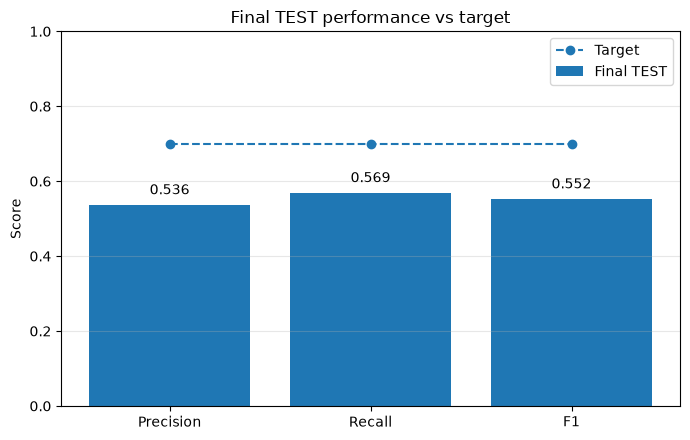

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_prf_vs_target.png
✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_prf_vs_target.csv


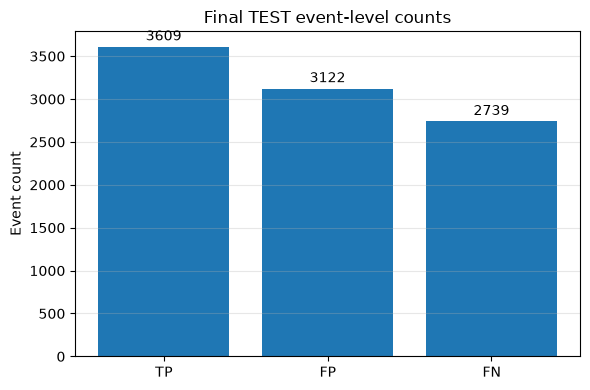

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_tp_fp_fn_counts.png
✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_tp_fp_fn_counts.csv


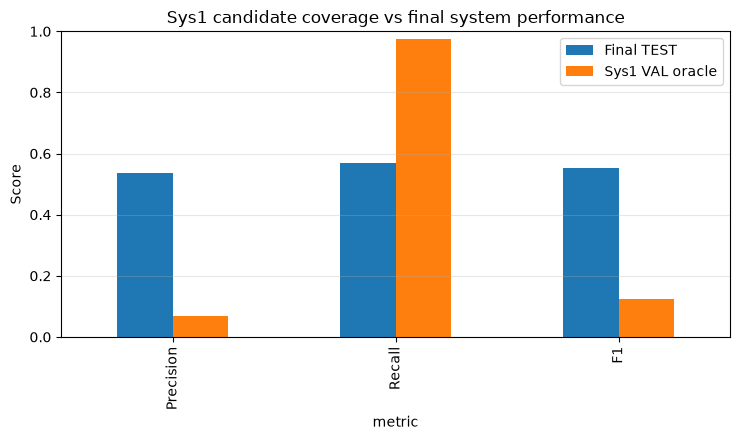

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_oracle_vs_final_test.png
✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_sys1_oracle_vs_final_test.csv
Skipping per-session F1 histogram: no per-session F1 available.


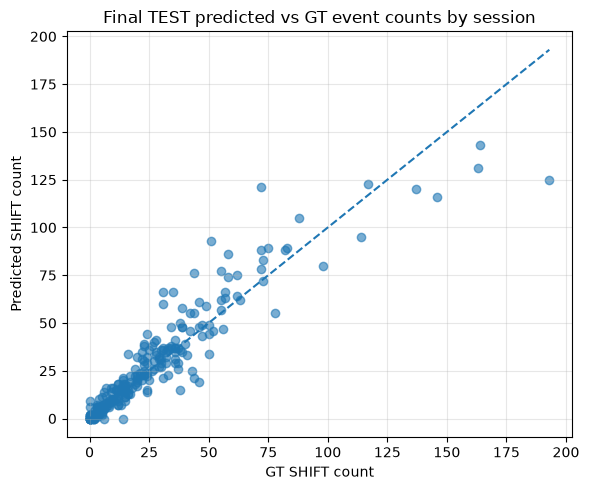

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_pred_vs_gt_counts_scatter.png
✅ Saved count comparison CSV: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_pred_vs_gt_counts_by_session.csv


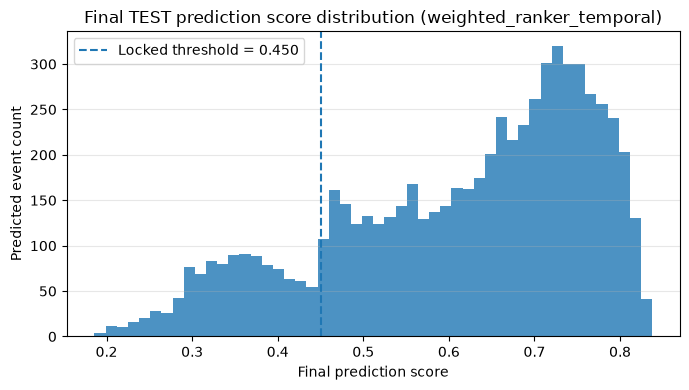

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_prediction_score_hist.png
Final TEST component score summary:


,score_column,count,mean,std,min,25%,50%,75%,max
0,meta_confirmer_shift_score,6731.0,0.703014,0.314771,0.032740,0.487431,0.868341,0.951148,0.969219
1,rr_role_shift_score,6731.0,0.610025,0.201837,0.225583,0.441843,0.707005,0.782173,0.802422
2,ranker_shift_score,6731.0,0.612468,0.184967,0.230124,0.482290,0.683978,0.771945,0.797408
3,lgbm_binary_shift_score,6731.0,0.711316,0.241534,0.000435,0.579037,0.760677,0.912402,0.998551
4,lgbm_shift_score,6731.0,0.747340,0.233210,0.000318,0.633781,0.814388,0.935053,0.999141
5,temporal_shift_score,6731.0,0.613573,0.184189,0.026573,0.495770,0.637254,0.756412,0.962811
6,fused_shift_score,6731.0,0.612744,0.150804,0.185916,0.506006,0.651519,0.735732,0.837490


✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_component_score_summary.csv


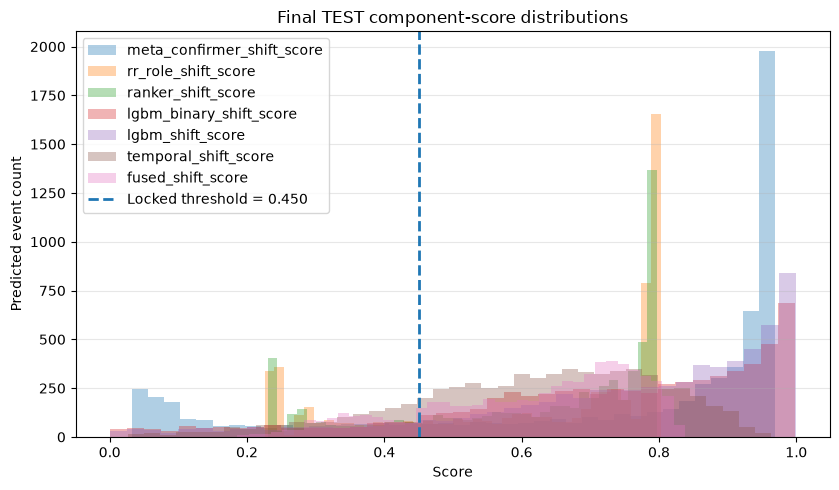

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_component_score_hist.png


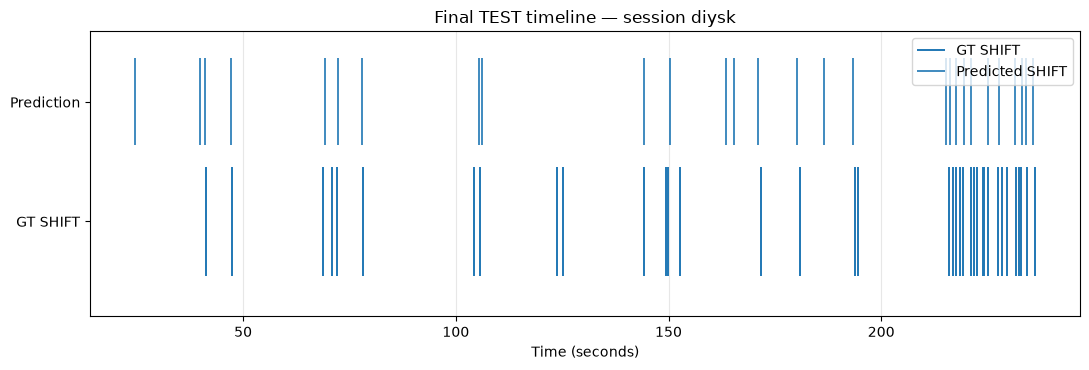

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_test_timeline_diysk.png


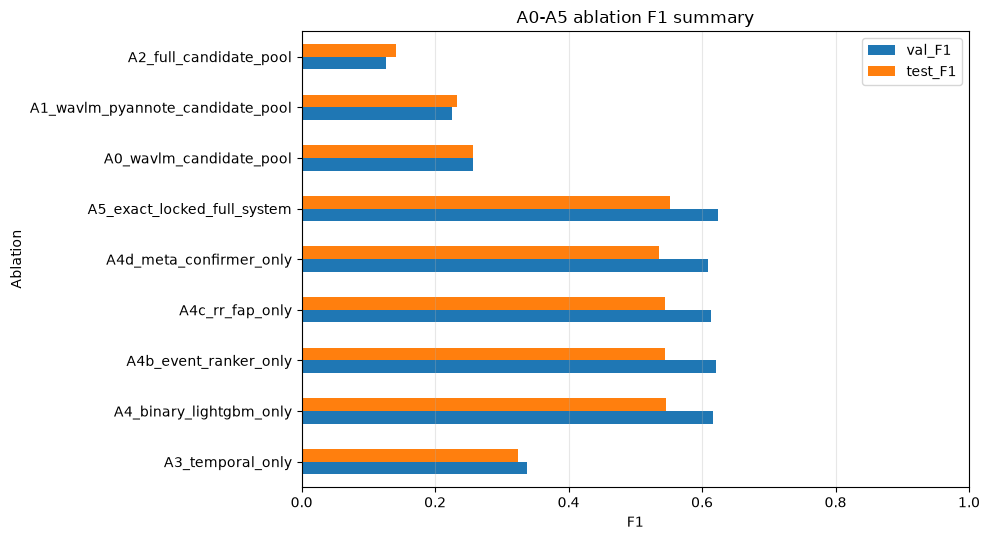

✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_ablation_A0_A5_f1_summary.png
✅ Saved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_ablation_A0_A5_f1_summary.csv
✅ Final experiment visual diagnostics complete.
Saved figures to: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals
Saved final visual summary JSON: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/figures/final_experiment_visuals/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2_final_experiment_visual_summary.json
Saved final visual summary CSV: <REPOSITORY_ROOT>/Experimen

In [67]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from typing import Dict, Any, Optional
from IPython.display import display

assert "FINAL_TEST_METRICS" in globals(), "Need FINAL_TEST_METRICS from Cell 22."
assert "TEST_PRED_DF" in globals(), "Need TEST_PRED_DF from Cell 21/22."
assert "REAL_TEST_EVENTS" in globals(), "Need REAL_TEST_EVENTS from Cell 4."
assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS from Cell 4."
assert "SYS1_LOCKED" in globals(), "Need SYS1_LOCKED from Cell 15."
assert "FINAL_LOCKED" in globals(), "Need FINAL_LOCKED from Cell 20."
assert "TEST_SESSIONS" in globals(), "Need TEST_SESSIONS."
assert "FIG_DIR" in globals(), "Need FIG_DIR."

CELL22B_VARIANT = "cell22b_v9_canonical_metrics_final_visuals"

FINAL_VIS_DIR = FIG_DIR / "final_experiment_visuals"
FINAL_VIS_DIR.mkdir(parents=True, exist_ok=True)

RUN_PREFIX = str(globals().get("RUN_PREFIX", globals().get("RUN_VERSION", ""))).strip()
prefix = f"{RUN_PREFIX}_" if RUN_PREFIX else ""

print("Final experiment visualisation directory:", FINAL_VIS_DIR)
print("CELL22B_VARIANT:", CELL22B_VARIANT)

def _save_show(fig, path: Path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("✅ Saved:", path)

def _norm_session_id(x) -> str:
    return Path(str(x)).stem

def _safe_float(v, default: float = 0.0) -> float:
    try:
        v = float(v)
        return v if np.isfinite(v) else float(default)
    except Exception:
        return float(default)

def _safe_int(v, default: int = 0) -> int:
    try:
        return int(v)
    except Exception:
        return int(default)

def _json_safe_obj(x):
    if isinstance(x, dict):
        return {str(k): _json_safe_obj(v) for k, v in x.items()}

    if isinstance(x, list):
        return [_json_safe_obj(v) for v in x]

    if isinstance(x, tuple):
        return [_json_safe_obj(v) for v in x]

    if isinstance(x, Path):
        return str(x)

    if isinstance(x, (np.floating,)):
        v = float(x)
        return v if np.isfinite(v) else None

    if isinstance(x, (np.integer,)):
        return int(x)

    if isinstance(x, (np.bool_,)):
        return bool(x)

    if isinstance(x, float):
        return x if np.isfinite(x) else None

    if isinstance(x, pd.DataFrame):
        return f"<DataFrame shape={x.shape}>"

    if isinstance(x, pd.Series):
        return x.to_dict()

    try:
        if pd.isna(x):
            return None
    except Exception:
        pass

    return x

def _standardize_metric_dict(metrics: Dict[str, Any]) -> Dict[str, Any]:
    m = dict(metrics) if metrics is not None else {}

    aliases = {
        "precision": "P",
        "recall": "R",
        "f1": "F1",
        "tp": "TP",
        "fp": "FP",
        "fn": "FN",
        "n_pred": "N_pred",
        "n_gt": "N_gt",
    }

    for old, new in aliases.items():
        if new not in m and old in m:
            m[new] = m[old]

    for k in ["P", "R", "F1"]:
        m[k] = _safe_float(m.get(k, 0.0), 0.0)

    for k in ["TP", "FP", "FN", "N_pred", "N_gt"]:
        m[k] = _safe_int(m.get(k, 0), 0)

    return m

def _standardize_per_session_df(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()

    out = df.copy()

    rename_map = {}
    for c in out.columns:
        lc = str(c).lower()
        if lc == "precision":
            rename_map[c] = "P"
        elif lc == "recall":
            rename_map[c] = "R"
        elif lc == "f1":
            rename_map[c] = "F1"
        elif lc == "tp":
            rename_map[c] = "TP"
        elif lc == "fp":
            rename_map[c] = "FP"
        elif lc == "fn":
            rename_map[c] = "FN"
        elif lc in ["pred_n", "n_pred"]:
            rename_map[c] = "N_pred"
        elif lc in ["gt_n", "n_gt"]:
            rename_map[c] = "N_gt"

    out = out.rename(columns=rename_map)

    if "session" in out.columns:
        out["session"] = out["session"].astype(str).map(_norm_session_id)

    for c in ["P", "R", "F1"]:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0)

    for c in ["TP", "FP", "FN", "N_pred", "N_gt"]:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0).astype(int)

    return out

def _safe_per_session_input(x) -> pd.DataFrame:
    if isinstance(x, pd.DataFrame):
        return x

    if isinstance(x, list):
        try:
            return pd.DataFrame(x)
        except Exception:
            return pd.DataFrame()

    if isinstance(x, dict):
        try:
            return pd.DataFrame(x)
        except Exception:
            try:
                return pd.DataFrame([x])
            except Exception:
                return pd.DataFrame()

    return pd.DataFrame()

def _get_gt_shift_times_from_events(events_df: pd.DataFrame, session: str) -> np.ndarray:
    if events_df is None or len(events_df) == 0:
        return np.array([], dtype=float)

    ev = events_df.copy()
    ev["session"] = ev["session"].astype(str).map(_norm_session_id)
    ev["time"] = pd.to_numeric(ev["time"], errors="coerce")
    ev["label"] = pd.to_numeric(ev["label"], errors="coerce").fillna(0).astype(int)
    ev = ev.dropna(subset=["session", "time"])

    ev = ev[(ev["session"] == _norm_session_id(session)) & (ev["label"] == 1)].copy()

    return np.sort(ev["time"].to_numpy(dtype=float)) if len(ev) else np.array([], dtype=float)

def _prepare_test_prediction_df(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["session", "time", "score"])

    out = df.copy()

    if "session" not in out.columns or "time" not in out.columns:
        return pd.DataFrame(columns=["session", "time", "score"])

    out["session"] = out["session"].astype(str).map(_norm_session_id)
    out["time"] = pd.to_numeric(out["time"], errors="coerce")

    if "score" not in out.columns:
        if "fused_shift_score" in out.columns:
            out["score"] = pd.to_numeric(out["fused_shift_score"], errors="coerce")
        else:
            out["score"] = 1.0

    out["score"] = pd.to_numeric(out["score"], errors="coerce").fillna(1.0)

    for c in [
        "temporal_shift_score",
        "lgbm_shift_score",
        "lgbm_binary_shift_score",
        "ranker_shift_score",
        "rr_role_shift_score",
        "meta_confirmer_shift_score",
        "fused_shift_score",
    ]:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce").fillna(out["score"])

    if "fused_shift_score" not in out.columns:
        out["fused_shift_score"] = out["score"]

    out = out.dropna(subset=["session", "time"])
    out = out[out["time"] >= 0].copy()
    out = out.sort_values(["session", "time"]).reset_index(drop=True)

    return out

def _prepare_gt_count_df(events_df: pd.DataFrame, test_sessions) -> pd.DataFrame:
    sessions = sorted(list(dict.fromkeys([_norm_session_id(s) for s in test_sessions])))

    base = pd.DataFrame({"session": sessions})

    if events_df is None or len(events_df) == 0:
        base["gt_count"] = 0
        return base

    ev = events_df.copy()
    ev["session"] = ev["session"].astype(str).map(_norm_session_id)
    ev["label"] = pd.to_numeric(ev["label"], errors="coerce").fillna(0).astype(int)

    gt_count = (
        ev[ev["label"] == 1]
        .groupby("session")
        .size()
        .rename("gt_count")
        .reset_index()
    )

    base = base.merge(gt_count, on="session", how="left")
    base["gt_count"] = base["gt_count"].fillna(0).astype(int)

    return base

FINAL_TEST_METRICS_STD = _standardize_metric_dict(FINAL_TEST_METRICS)

test_pred = _prepare_test_prediction_df(TEST_PRED_DF)
test_sessions_norm = sorted(list(dict.fromkeys([_norm_session_id(s) for s in TEST_SESSIONS])))

locked_score_mode = str(FINAL_LOCKED.get("score_mode", ""))
locked_rescue_mode = str(FINAL_LOCKED.get("rescue_mode", "none"))
locked_uses_ranker = bool("ranker" in locked_score_mode.lower())
locked_uses_rr_fap = bool("rr" in locked_score_mode.lower() or "fap" in locked_score_mode.lower())
locked_uses_meta_confirmer = bool("meta" in locked_score_mode.lower())

ranker_score_available = bool(
    "ranker_shift_score" in test_pred.columns
    or (
        "TEST_FUSED_SCORES_DF" in globals()
        and hasattr(TEST_FUSED_SCORES_DF, "columns")
        and "ranker_shift_score" in TEST_FUSED_SCORES_DF.columns
    )
)

rr_fap_score_available = bool(
    "rr_role_shift_score" in test_pred.columns
    or (
        "TEST_FUSED_SCORES_DF" in globals()
        and hasattr(TEST_FUSED_SCORES_DF, "columns")
        and "rr_role_shift_score" in TEST_FUSED_SCORES_DF.columns
    )
)

meta_confirmer_score_available = bool(
    "meta_confirmer_shift_score" in test_pred.columns
    or (
        "TEST_FUSED_SCORES_DF" in globals()
        and hasattr(TEST_FUSED_SCORES_DF, "columns")
        and "meta_confirmer_shift_score" in TEST_FUSED_SCORES_DF.columns
    )
)

print("Final TEST metrics used for visuals:")
print(json.dumps({k: v for k, v in FINAL_TEST_METRICS_STD.items() if k != "per_session"}, indent=2, default=str))
print("TEST predictions for visuals:", test_pred.shape)
print("Locked score_mode:", locked_score_mode)
print("Locked rescue_mode:", locked_rescue_mode)
print("Locked uses ranker:", locked_uses_ranker)
print("Locked uses RR-FAP:", locked_uses_rr_fap)
print("Locked uses meta-confirmer:", locked_uses_meta_confirmer)
print("Ranker score available:", ranker_score_available)
print("RR-FAP score available:", rr_fap_score_available)
print("Meta-confirmer score available:", meta_confirmer_score_available)

if locked_uses_ranker and not ranker_score_available:
    print("⚠️ Locked setting uses ranker, but ranker_shift_score is not available in TEST visuals.")

if locked_uses_rr_fap and not rr_fap_score_available:
    print("⚠️ Locked setting uses RR-FAP, but rr_role_shift_score is not available in TEST visuals.")

if locked_uses_meta_confirmer and not meta_confirmer_score_available:
    print("⚠️ Locked setting uses meta-confirmer, but meta_confirmer_shift_score is not available in TEST visuals.")

final_prf = pd.DataFrame([
    {"metric": "Precision", "value": float(FINAL_TEST_METRICS_STD.get("P", 0.0)), "target": float(TARGET_FINAL_PRECISION)},
    {"metric": "Recall", "value": float(FINAL_TEST_METRICS_STD.get("R", 0.0)), "target": float(TARGET_FINAL_RECALL)},
    {"metric": "F1", "value": float(FINAL_TEST_METRICS_STD.get("F1", 0.0)), "target": float(TARGET_FINAL_F1)},
])

final_prf_csv = FINAL_VIS_DIR / f"{prefix}final_test_prf_vs_target.csv"
final_prf.to_csv(final_prf_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(final_prf["metric"], final_prf["value"], label="Final TEST")
ax.plot(final_prf["metric"], final_prf["target"], marker="o", linestyle="--", label="Target")
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Final TEST performance vs target")
ax.grid(axis="y", alpha=0.3)
ax.legend()

for i, v in enumerate(final_prf["value"]):
    ax.text(i, min(v + 0.02, 0.98), f"{v:.3f}", ha="center", va="bottom")

_save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_prf_vs_target.png")
print("✅ Saved:", final_prf_csv)

count_df = pd.DataFrame([
    {"count_type": "TP", "count": int(FINAL_TEST_METRICS_STD.get("TP", 0))},
    {"count_type": "FP", "count": int(FINAL_TEST_METRICS_STD.get("FP", 0))},
    {"count_type": "FN", "count": int(FINAL_TEST_METRICS_STD.get("FN", 0))},
])

count_csv = FINAL_VIS_DIR / f"{prefix}final_test_tp_fp_fn_counts.csv"
count_df.to_csv(count_csv, index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(count_df["count_type"], count_df["count"])
ax.set_ylabel("Event count")
ax.set_title("Final TEST event-level counts")
ax.grid(axis="y", alpha=0.3)

label_offset = max(1, 0.01 * max(1, int(count_df["count"].max())))
for i, v in enumerate(count_df["count"]):
    ax.text(i, v + label_offset, str(v), ha="center", va="bottom")

_save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_tp_fp_fn_counts.png")
print("✅ Saved:", count_csv)

rows = []

if "VAL_SYS1_ORACLE" in globals() and isinstance(VAL_SYS1_ORACLE, dict):
    val_oracle = _standardize_metric_dict(VAL_SYS1_ORACLE)
    rows += [
        {"stage": "Sys1 VAL oracle", "metric": "Precision", "value": float(val_oracle.get("P", 0.0))},
        {"stage": "Sys1 VAL oracle", "metric": "Recall", "value": float(val_oracle.get("R", 0.0))},
        {"stage": "Sys1 VAL oracle", "metric": "F1", "value": float(val_oracle.get("F1", 0.0))},
    ]

rows += [
    {"stage": "Final TEST", "metric": "Precision", "value": float(FINAL_TEST_METRICS_STD.get("P", 0.0))},
    {"stage": "Final TEST", "metric": "Recall", "value": float(FINAL_TEST_METRICS_STD.get("R", 0.0))},
    {"stage": "Final TEST", "metric": "F1", "value": float(FINAL_TEST_METRICS_STD.get("F1", 0.0))},
]

stage_df = pd.DataFrame(rows)
stage_csv = FINAL_VIS_DIR / f"{prefix}sys1_oracle_vs_final_test.csv"
stage_df.to_csv(stage_csv, index=False)

if len(stage_df):
    plot_df = (
        stage_df
        .pivot(index="metric", columns="stage", values="value")
        .reindex(["Precision", "Recall", "F1"])
    )

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    plot_df.plot(kind="bar", ax=ax)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.0)
    ax.set_title("Sys1 candidate coverage vs final system performance")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    _save_show(fig, FINAL_VIS_DIR / f"{prefix}sys1_oracle_vs_final_test.png")
    print("✅ Saved:", stage_csv)

per_session_df = _standardize_per_session_df(
    _safe_per_session_input(FINAL_TEST_METRICS.get("per_session", pd.DataFrame()))
)

if per_session_df is not None and len(per_session_df) and "F1" in per_session_df.columns:
    ps = per_session_df.copy()
    ps["F1"] = pd.to_numeric(ps["F1"], errors="coerce").fillna(0.0)

    ps_csv = FINAL_VIS_DIR / f"{prefix}final_test_per_session_metrics_for_visuals.csv"
    ps.to_csv(ps_csv, index=False)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(ps["F1"], bins=30, alpha=0.80)
    ax.set_xlabel("Per-session F1")
    ax.set_ylabel("Number of sessions")
    ax.set_title("Final TEST per-session F1 distribution")
    ax.grid(axis="y", alpha=0.3)

    _save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_per_session_f1_hist.png")
    print("✅ Saved:", ps_csv)
else:
    print("Skipping per-session F1 histogram: no per-session F1 available.")

pred_count = (
    test_pred.groupby("session")
    .size()
    .rename("pred_count")
    .reset_index()
    if len(test_pred)
    else pd.DataFrame(columns=["session", "pred_count"])
)

count_compare = _prepare_gt_count_df(REAL_TEST_EVENTS, test_sessions_norm)
count_compare = count_compare.merge(pred_count, on="session", how="left")
count_compare["pred_count"] = count_compare["pred_count"].fillna(0).astype(int)
count_compare["count_error_pred_minus_gt"] = count_compare["pred_count"] - count_compare["gt_count"]
count_compare["abs_count_error"] = count_compare["count_error_pred_minus_gt"].abs()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(count_compare["gt_count"], count_compare["pred_count"], alpha=0.60)

max_n = int(max(count_compare["gt_count"].max(), count_compare["pred_count"].max(), 1))
ax.plot([0, max_n], [0, max_n], linestyle="--")
ax.set_xlabel("GT SHIFT count")
ax.set_ylabel("Predicted SHIFT count")
ax.set_title("Final TEST predicted vs GT event counts by session")
ax.grid(True, alpha=0.3)

_save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_pred_vs_gt_counts_scatter.png")

count_compare_csv = FINAL_VIS_DIR / f"{prefix}final_test_pred_vs_gt_counts_by_session.csv"
count_compare.to_csv(count_compare_csv, index=False)
print("✅ Saved count comparison CSV:", count_compare_csv)

if len(test_pred):
    fig, ax = plt.subplots(figsize=(7, 4))

    score_col = "fused_shift_score" if "fused_shift_score" in test_pred.columns else "score"

    ax.hist(pd.to_numeric(test_pred[score_col], errors="coerce").fillna(0.0), bins=50, alpha=0.80)
    ax.axvline(
        float(FINAL_LOCKED.get("thr", 0.5)),
        linestyle="--",
        label=f"Locked threshold = {float(FINAL_LOCKED.get('thr', 0.5)):.3f}",
    )
    ax.set_xlabel("Final prediction score")
    ax.set_ylabel("Predicted event count")
    ax.set_title(f"Final TEST prediction score distribution ({locked_score_mode})")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    _save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_prediction_score_hist.png")
else:
    print("Skipping final prediction score histogram: no TEST predictions.")

component_cols = [
    c for c in [
        "meta_confirmer_shift_score",
        "rr_role_shift_score",
        "ranker_shift_score",
        "lgbm_binary_shift_score",
        "lgbm_shift_score",
        "temporal_shift_score",
        "fused_shift_score",
    ]
    if c in test_pred.columns
]

if len(test_pred) and component_cols:
    component_summary = (
        test_pred[component_cols]
        .apply(pd.to_numeric, errors="coerce")
        .describe()
        .T
        .reset_index()
        .rename(columns={"index": "score_column"})
    )

    component_summary_csv = FINAL_VIS_DIR / f"{prefix}final_test_component_score_summary.csv"
    component_summary.to_csv(component_summary_csv, index=False)

    print("Final TEST component score summary:")
    display(component_summary)
    print("✅ Saved:", component_summary_csv)

    fig, ax = plt.subplots(figsize=(8.5, 5))
    for c in component_cols:
        vals = pd.to_numeric(test_pred[c], errors="coerce").fillna(0.0).clip(0.0, 1.0)
        ax.hist(vals, bins=40, alpha=0.35, label=c)

    ax.axvline(
        float(FINAL_LOCKED.get("thr", 0.5)),
        linestyle="--",
        linewidth=2,
        label=f"Locked threshold = {float(FINAL_LOCKED.get('thr', 0.5)):.3f}",
    )
    ax.set_xlabel("Score")
    ax.set_ylabel("Predicted event count")
    ax.set_title("Final TEST component-score distributions")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    _save_show(fig, FINAL_VIS_DIR / f"{prefix}final_test_component_score_hist.png")
else:
    print("Skipping component-score histogram: no component score columns available.")

def plot_final_test_example_timeline(
    session: Optional[str] = None,
    max_seconds: Optional[float] = 240.0,
):
    if session is None:
        work = count_compare.copy()
        work["total_activity"] = work["gt_count"] + work["pred_count"]

        if len(work) == 0:
            print("No TEST sessions available for timeline plot.")
            return None

        session = str(work.sort_values("total_activity", ascending=False).iloc[0]["session"])

    session = _norm_session_id(session)

    gt_times = _get_gt_shift_times_from_events(REAL_TEST_EVENTS, session)
    pred_times = test_pred[test_pred["session"].astype(str).map(_norm_session_id) == session]["time"].to_numpy(dtype=float)

    if max_seconds is not None:
        gt_times = gt_times[gt_times <= float(max_seconds)]
        pred_times = pred_times[pred_times <= float(max_seconds)]

    fig, ax = plt.subplots(figsize=(11, 3.8))

    if len(gt_times):
        ax.vlines(gt_times, 0.20, 0.60, linewidth=1.4, label="GT SHIFT")

    if len(pred_times):
        ax.vlines(pred_times, 0.68, 1.00, linewidth=1.2, label="Predicted SHIFT")

    ax.set_title(f"Final TEST timeline — session {session}")
    ax.set_xlabel("Time (seconds)")
    ax.set_yticks([0.40, 0.84])
    ax.set_yticklabels(["GT SHIFT", "Prediction"])
    ax.set_ylim(0.05, 1.10)
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper right")

    out_path = FINAL_VIS_DIR / f"{prefix}final_test_timeline_{session}.png"
    _save_show(fig, out_path)

    return out_path

timeline_path = plot_final_test_example_timeline()

if "ABLATION_DF" in globals() and ABLATION_DF is not None and len(ABLATION_DF):
    ab = ABLATION_DF.copy()

    plot_cols = []
    if "val_F1" in ab.columns:
        plot_cols.append("val_F1")
    if "test_F1" in ab.columns:
        plot_cols.append("test_F1")

    ablation_name_col = "ablation" if "ablation" in ab.columns else ("name" if "name" in ab.columns else None)

    if plot_cols and ablation_name_col is not None:
        plot_ab = ab[[ablation_name_col] + plot_cols].copy()
        plot_ab = plot_ab.set_index(ablation_name_col)

        ab_csv = FINAL_VIS_DIR / f"{prefix}ablation_A0_A5_f1_summary.csv"
        plot_ab.to_csv(ab_csv)

        fig, ax = plt.subplots(figsize=(10, 5.5))
        plot_ab.plot(kind="barh", ax=ax)
        ax.set_xlabel("F1")
        ax.set_ylabel("Ablation")
        ax.set_xlim(0, 1.0)
        ax.set_title("A0-A5 ablation F1 summary")
        ax.grid(axis="x", alpha=0.3)
        ax.legend()

        _save_show(fig, FINAL_VIS_DIR / f"{prefix}ablation_A0_A5_f1_summary.png")
        print("✅ Saved:", ab_csv)
    else:
        print("Skipping ablation chart: ABLATION_DF missing expected F1/name columns.")
else:
    print("Skipping ablation chart: ABLATION_DF not available.")

FINAL_VIS_SUMMARY = {
    "cell22b_variant": CELL22B_VARIANT,
    "final_test_precision": float(FINAL_TEST_METRICS_STD.get("P", 0.0)),
    "final_test_recall": float(FINAL_TEST_METRICS_STD.get("R", 0.0)),
    "final_test_f1": float(FINAL_TEST_METRICS_STD.get("F1", 0.0)),
    "final_test_tp": int(FINAL_TEST_METRICS_STD.get("TP", 0)),
    "final_test_fp": int(FINAL_TEST_METRICS_STD.get("FP", 0)),
    "final_test_fn": int(FINAL_TEST_METRICS_STD.get("FN", 0)),
    "final_test_n_pred": int(FINAL_TEST_METRICS_STD.get("N_pred", 0)),
    "final_test_n_gt": int(FINAL_TEST_METRICS_STD.get("N_gt", 0)),
    "target_precision": float(TARGET_FINAL_PRECISION),
    "target_recall": float(TARGET_FINAL_RECALL),
    "target_f1": float(TARGET_FINAL_F1),
    "locked_score_mode": locked_score_mode,
    "locked_uses_ranker": bool(locked_uses_ranker),
    "locked_uses_rr_fap": bool(locked_uses_rr_fap),
    "locked_uses_meta_confirmer": bool(locked_uses_meta_confirmer),
    "ranker_score_available": bool(ranker_score_available),
    "rr_fap_score_available": bool(rr_fap_score_available),
    "meta_confirmer_score_available": bool(meta_confirmer_score_available),
    "all_targets_met": bool(
        float(FINAL_TEST_METRICS_STD.get("P", 0.0)) >= float(TARGET_FINAL_PRECISION)
        and float(FINAL_TEST_METRICS_STD.get("R", 0.0)) >= float(TARGET_FINAL_RECALL)
        and float(FINAL_TEST_METRICS_STD.get("F1", 0.0)) >= float(TARGET_FINAL_F1)
    ),
    "tol": float(TOL),
    "active_prediction_branch": str(globals().get("ACTIVE_PREDICTION_BRANCH", "")),
    "sys2_change_mode": str(globals().get("SYS2_CHANGE_MODE", "")),
    "locked_score_mode": locked_score_mode,
    "locked_uses_ranker": bool(locked_uses_ranker),
    "locked_rescue_mode": locked_rescue_mode,
    "ranker_score_available": bool(ranker_score_available),
    "n_test_predictions": int(len(test_pred)),
    "n_test_sessions": int(len(test_sessions_norm)),
    "sys1_locked": _json_safe_obj(SYS1_LOCKED),
    "final_locked": _json_safe_obj(FINAL_LOCKED),
    "visual_dir": str(FINAL_VIS_DIR),
}

FINAL_VIS_SUMMARY_JSON = FINAL_VIS_DIR / f"{prefix}final_experiment_visual_summary.json"
FINAL_VIS_SUMMARY_JSON.write_text(json.dumps(_json_safe_obj(FINAL_VIS_SUMMARY), indent=2, default=str))

FINAL_VIS_SUMMARY_CSV = FINAL_VIS_DIR / f"{prefix}final_experiment_visual_summary.csv"
pd.DataFrame([{
    k: v for k, v in FINAL_VIS_SUMMARY.items()
    if k not in {"sys1_locked", "final_locked"}
}]).to_csv(FINAL_VIS_SUMMARY_CSV, index=False)

globals()["FINAL_VIS_SUMMARY"] = FINAL_VIS_SUMMARY
globals()["FINAL_VIS_SUMMARY_JSON"] = str(FINAL_VIS_SUMMARY_JSON)
globals()["FINAL_VIS_SUMMARY_CSV"] = str(FINAL_VIS_SUMMARY_CSV)
globals()["FINAL_VIS_DIR"] = FINAL_VIS_DIR
globals()["COUNT_COMPARE_TEST_DF"] = count_compare
globals()["FINAL_TEST_VIS_PRED_DF"] = test_pred
globals()["FINAL_TEST_VIS_PER_SESSION_DF"] = per_session_df if "per_session_df" in globals() else pd.DataFrame()

print("✅ Final experiment visual diagnostics complete.")
print("Saved figures to:", FINAL_VIS_DIR)
print("Saved final visual summary JSON:", FINAL_VIS_SUMMARY_JSON)
print("Saved final visual summary CSV:", FINAL_VIS_SUMMARY_CSV)

if ranker_score_available:
    if locked_uses_ranker:
        print(f"✅ Ranker score is available and selected by locked score_mode='{locked_score_mode}'.")
    else:
        print(f"ℹ️ Ranker score is available, but locked score_mode='{locked_score_mode}' did not select it.")
else:
    print("⚠️ Ranker score is not available in final TEST visuals.")

In [68]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."

RUN_ROOT = Path(RUN_ROOT)
RUN_CARD_PATH = (
    RUN_ROOT
    / "run_card.json"
)

def _run_card_safe(value):
    if isinstance(value, dict):
        return {
            str(key): _run_card_safe(item)
            for key, item
            in value.items()
        }
    if isinstance(
        value,
        (
            list,
            tuple,
        ),
    ):
        return [
            _run_card_safe(item)
            for item in value
        ]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        numeric = float(value)
        return (
            numeric
            if np.isfinite(numeric)
            else None
        )
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, pd.DataFrame):
        return value.to_dict(
            "records"
        )
    if isinstance(value, pd.Series):
        return value.to_dict()
    try:
        if pd.isna(value):
            return None
    except Exception:
        pass
    return value

lock = dict(
    globals().get(
        "FINAL_LOCKED",
        {},
    )
)

event_contract = {
    "version": str(
        globals().get(
            "EVENT_CONTRACT_VERSION",
            "",
        )
    ),
    "primary_event_time_definition": str(
        globals().get(
            "PRIMARY_EVENT_TIME_DEFINITION",
            "",
        )
    ),
    "primary_gap_min_s": float(
        globals().get(
            "PRIMARY_MIN_GAP_S",
            np.nan,
        )
    ),
    "primary_gap_max_s": float(
        globals().get(
            "PRIMARY_MAX_POSITIVE_GAP_S",
            np.nan,
        )
    ),
    "short_turn_threshold_s": float(
        globals().get(
            "ACTION_SHORT_TURN_S",
            np.nan,
        )
    ),
    "overlap_action_threshold_s": float(
        globals().get(
            "ACTION_OVERLAP_MIN_S",
            np.nan,
        )
    ),
    "shift_actions": sorted(
        list(
            globals().get(
                "SHIFT_ACTIONS",
                [],
            )
        )
    ),
    "hold_actions": sorted(
        list(
            globals().get(
                "HOLD_ACTIONS",
                [],
            )
        )
    ),
    "selection_basis": str(
        globals().get(
            "EVENT_CONTRACT_SELECTION_BASIS",
            "",
        )
    ),
    "audit_included_test_annotations": bool(
        globals().get(
            "EVENT_CONTRACT_AUDIT_INCLUDED_TEST_ANNOTATIONS",
            False,
        )
    ),
    "test_predictions_or_performance_used_for_contract_selection": bool(
        globals().get(
            "EVENT_CONTRACT_TEST_PREDICTIONS_USED_FOR_SELECTION",
            False,
        )
    ),
    "secondary_reports": [
        "legacy midpoint point matching",
        "transition-interval matching",
    ],
    "contract_guard_path": str(
        globals().get(
            "PAPER_READY_EXECUTION_GUARD_PATH",
            "",
        )
    ),
    "contract_summary_path": str(
        globals().get(
            "EVENT_CONTRACT_SUMMARY_PATH",
            "",
        )
    ),
}

asset_provenance = {
    "active_run_root": str(
        RUN_ROOT
    ),
    "base_asset_run_root": str(
        globals().get(
            "BASE_ASSET_RUN_ROOT",
            "",
        )
    ),
    "asset_cache_run_version": str(
        globals().get(
            "ASSET_CACHE_RUN_VERSION",
            "",
        )
    ),
    "reused_condition_independent_assets": [
        "synthetic waveforms and RTTM",
        "timing-safe diffusion waveforms",
        "ASR segments",
        "pyannote turns and candidates",
        "bounded ECAPA embeddings",
    ],
    "retrained_contract_dependent_stages": [
        "WavLM Sys1 head",
        "Qwen action classifier",
        "temporal Sys2",
        "multiclass and binary LightGBM",
        "event ranker",
        "RR-FAP",
        "meta-confirmer",
        "local timing corrector",
        "VAL fusion and post-processing lock",
    ],
    "asset_provenance_path": str(
        globals().get(
            "ASSET_PROVENANCE_PATH",
            "",
        )
    ),
}

training_distribution = {
    "real_train_boundary_rows": int(
        len(
            globals().get(
                "REAL_TRAIN_BOUNDARY_EVENTS",
                [],
            )
        )
    ),
    "real_train_rows_after_midturn_negatives": int(
        len(
            globals().get(
                "REAL_TRAIN_EVENTS",
                [],
            )
        )
    ),
    "synthetic_rows": int(
        len(
            globals().get(
                "SYNTH_EVENTS",
                [],
            )
        )
    ),
    "real_diffusion_rows": int(
        len(
            globals().get(
                "REAL_AUG_EVENTS",
                [],
            )
        )
    ),
    "synthetic_diffusion_rows": int(
        len(
            globals().get(
                "SYNTH_AUG_EVENTS",
                [],
            )
        )
    ),
    "mixed_train_rows": int(
        len(
            globals().get(
                "TRAIN_EVENTS_MIXED",
                [],
            )
        )
    ),
    "midturn_negative_ratio": float(
        globals().get(
            "MIDTURN_HOLD_NEGATIVE_RATIO",
            np.nan,
        )
    ),
    "midturn_negative_max_per_session": int(
        globals().get(
            "MIDTURN_HOLD_MAX_PER_SESSION",
            -1,
        )
    ),
    "midturn_negative_sample_weight": float(
        globals().get(
            "MIDTURN_HOLD_SAMPLE_WEIGHT",
            np.nan,
        )
    ),
    "sys1_class_balance_mode": str(
        globals().get(
            "SYS1_CLASS_BALANCE_MODE",
            "",
        )
    ),
    "sys1_weighted_sampler": bool(
        globals().get(
            "SYS1_USE_WEIGHTED_SAMPLER",
            False,
        )
    ),
}

selection = {
    "active_stage": str(
        lock.get(
            "stage",
            lock.get(
                "locked_on",
                "unknown",
            ),
        )
    ),
    "score_mode": str(
        lock.get(
            "score_mode",
            "unknown",
        )
    ),
    "time_mode": str(
        lock.get(
            "time_mode",
            "raw",
        )
    ),
    "global_offset_s": float(
        lock.get(
            "offset",
            0.0,
        )
    ),
    "test_not_used_for_selection": bool(
        lock.get(
            "test_not_used_for_selection",
            False,
        )
    ),
    "robust_val_folds": int(
        lock.get(
            "robust_val_folds",
            globals().get(
                "VAL_ROBUST_N_FOLDS",
                0,
            ),
        )
    ),
    "robust_val_std_penalty": float(
        lock.get(
            "robust_val_std_penalty",
            globals().get(
                "VAL_ROBUST_STD_PENALTY",
                0.0,
            ),
        )
    ),
    "cv_f1_mean": lock.get(
        "cv_f1_mean",
        None,
    ),
    "cv_f1_std": lock.get(
        "cv_f1_std",
        None,
    ),
    "robust_score": lock.get(
        "robust_score",
        None,
    ),
    "test_informed_exploratory_branch_active": bool(
        globals().get(
            "USE_TEST_INFORMED_EXPLORATORY_BRANCH",
            False,
        )
    ),
    "legacy_test_informed_diagnostics_executed": bool(
        globals().get(
            "RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS",
            False,
        )
    ),
}

timing_corrector = {
    "available": (
        "TIMING_CORRECTOR_MODEL"
        in globals()
    ),
    "variant": str(
        globals().get(
            "TIMING_CORRECTOR_VARIANT",
            "",
        )
    ),
    "feature_columns": list(
        globals().get(
            "TIMING_FEATURE_COLUMNS",
            [],
        )
    ),
    "diagnostics": (
        globals().get(
            "TIMING_CORRECTOR_DIAGNOSTICS_DF",
            pd.DataFrame(),
        )
    ),
    "model_path": str(
        globals().get(
            "TIMING_CORRECTOR_MODEL_PATH",
            "",
        )
    ),
    "meta_path": str(
        globals().get(
            "TIMING_CORRECTOR_META_PATH",
            "",
        )
    ),
    "model_fit_labels": "TRAIN only",
    "early_stopping": "session-held-out TRAIN subset",
    "official_val_used_for_model_fitting": False,
    "official_val_role": (
        "timing diagnostics and final raw-vs-corrected operating-point selection"
    ),
    "test_labels_used": False,
}

augmentation = {
    "use_synthetic_multiparty": bool(
        globals().get(
            "USE_SYNTH_MULTIPARTY",
            False,
        )
    ),
    "use_diffusion_augmentation": bool(
        globals().get(
            "USE_DIFFUSION_AUG",
            False,
        )
    ),
    "weights": {
        "real_clean": float(
            globals().get(
                "WEIGHT_REAL_CLEAN",
                1.0,
            )
        ),
        "synthetic_clean": float(
            globals().get(
                "WEIGHT_SYNTH_CLEAN",
                0.0,
            )
        ),
        "real_diffusion": float(
            globals().get(
                "WEIGHT_REAL_DIFFUSION",
                0.0,
            )
        ),
        "synthetic_diffusion": float(
            globals().get(
                "WEIGHT_SYNTH_DIFFUSION",
                0.0,
            )
        ),
    },
    "current_contract_ablation_summary_available": bool(
        globals().get(
            "CLEAN_AUGMENTATION_ABLATION_CONTRACT_COMPATIBLE",
            False,
        )
    ),
    "legacy_18thAug_ablation_compatible": False,
    "note": (
        "Ablation results trained under the legacy midpoint/no-gap-cap "
        "contract must not be combined with this run. Regenerate all four "
        "conditions after the paper-ready full run is stable."
    ),
}

branch_results = {
    "branch1_primary_strict_test": dict(
        globals().get(
            "FINAL_TEST_SUMMARY",
            {},
        )
    ),
    "branch1_secondary_protocols": (
        globals().get(
            "BRANCH1_SECONDARY_PROTOCOL_METRICS_DF",
            pd.DataFrame(),
        )
    ),
    "branch1_strict_session_bootstrap_95_ci": dict(
        globals().get(
            "BRANCH1_STRICT_BOOTSTRAP_SUMMARY",
            {},
        )
    ),
    "branch2_oracle_decision_point_past_only": dict(
        globals().get(
            "BRANCH2_FINAL_TEST_METRICS",
            {},
        )
    ),
    "branch2e_deployable_auto_candidate": dict(
        globals().get(
            "BRANCH2_E2E_FINAL_TEST_METRICS",
            {},
        )
    ),
    "branch3_future_activity_past_only": dict(
        globals().get(
            "BRANCH3_FINAL_TEST_METRICS",
            {},
        )
    ),
    "speaker_identity_oracle_inventory_postboundary": dict(
        globals().get(
            "NS_E2E_FINAL_METRICS",
            {},
        )
    ),
    "speaker_identity_automatic_inventory": dict(
        globals().get(
            "NS_AUTO_FINAL_METRICS",
            {},
        )
    ),
}

limitations = [
    (
        "VoxConverse supplies diarization intervals, not native "
        "NA/NTT/ITT/BC/BI turn-taking labels; the paper-ready event "
        "contract remains an explicit experiment definition."
    ),
    (
        "The integrity audit inspected annotations in both DEV and TEST. "
        "No TEST predictions, scores, thresholds, or model performance were "
        "used to fit models or select the operating point."
    ),
    (
        "The primary immediate-transition contract caps positive gaps at "
        "1.0 second and is therefore not directly interchangeable with the "
        "legacy midpoint/no-positive-gap-cap task; legacy metrics are reported "
        "only as a fixed-prediction secondary analysis."
    ),
    (
        "The fixed DEV-derived TRAIN/VAL split has a different SHIFT rate "
        "from official TEST; robust session-fold selection reduces but does "
        "not remove this distribution difference."
    ),
    (
        "Speaker identity uses post-boundary query audio and is not causal "
        "decision-time next-speaker prediction."
    ),
    (
        "Automatic prefix enrolment uses past-only prototype audio, but "
        "cluster identities still originate from offline diarization."
    ),
    (
        "A synthetic or diffusion contribution must be claimed only after "
        "the four contract-compatible controlled ablations complete."
    ),
]

artifact_paths = {
    "event_contract_summary": str(
        globals().get(
            "EVENT_CONTRACT_SUMMARY_PATH",
            "",
        )
    ),
    "event_contract_guard": str(
        globals().get(
            "PAPER_READY_EXECUTION_GUARD_PATH",
            "",
        )
    ),
    "asset_provenance": str(
        globals().get(
            "ASSET_PROVENANCE_PATH",
            "",
        )
    ),
    "final_locked_val_settings": str(
        globals().get(
            "FINAL_LOCKED_PATH",
            "",
        )
    ),
    "val_fusion_sweep": str(
        globals().get(
            "VAL_FUSION_TABLE_PATH",
            "",
        )
    ),
    "timing_corrector_model": str(
        globals().get(
            "TIMING_CORRECTOR_MODEL_PATH",
            "",
        )
    ),
    "branch1_primary_metrics": str(
        globals().get(
            "FINAL_TEST_METRICS_JSON",
            "",
        )
    ),
    "branch1_secondary_metrics": str(
        globals().get(
            "BRANCH1_SECONDARY_PROTOCOL_METRICS_CSV",
            "",
        )
    ),
    "branch1_bootstrap": str(
        globals().get(
            "BRANCH1_BOOTSTRAP_JSON",
            "",
        )
    ),
    "branch2_metrics": str(
        globals().get(
            "BRANCH2_METRICS_CSV",
            "",
        )
    ),
    "branch2e_metrics": str(
        globals().get(
            "BRANCH2_E2E_TEST_METRICS_CSV",
            "",
        )
    ),
    "branch3_metrics": str(
        globals().get(
            "BRANCH3_METRICS_CSV",
            "",
        )
    ),
    "fair_ablation_table": str(
        globals().get(
            "ABLATION_PATH",
            "",
        )
    ),
}

RUN_CARD = {
    "created_at": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "experiment_name": str(
        globals().get(
            "EXPERIMENT_NAME",
            "",
        )
    ),
    "run_version": str(
        globals().get(
            "RUN_VERSION",
            "",
        )
    ),
    "paper_ready_protocol": True,
    "raw_dataset_audit_consistent": True,
    "event_contract": event_contract,
    "asset_provenance": asset_provenance,
    "training_distribution": training_distribution,
    "selection_provenance": selection,
    "timing_corrector": timing_corrector,
    "augmentation": augmentation,
    "branch_results": branch_results,
    "limitations": limitations,
    "artifact_paths": artifact_paths,
}

RUN_CARD_PATH.write_text(
    json.dumps(
        _run_card_safe(
            RUN_CARD
        ),
        indent=2,
        sort_keys=True,
    )
)

globals()["RUN_CARD"] = RUN_CARD
globals()["RUN_CARD_PATH"] = RUN_CARD_PATH

print(
    json.dumps(
        _run_card_safe(
            RUN_CARD
        ),
        indent=2,
        sort_keys=True,
    )
)
print(
    "Cell 24 complete: paper-ready protocol, asset reuse, selection, "
    "timing, results, limitations, and artifact provenance recorded."
)

{
  "artifact_paths": {
    "asset_provenance": "<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/asset_provenance.json",
    "branch1_bootstrap": "<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/eval/branch1_strict_session_bootstrap.json",
    "branch1_primary_metrics": "<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/eval/final_test_metrics.json",
    "branch1_secondary_metrics": "<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/eval/branch1_secondary_protocol_metrics.csv",
    "branch2_metrics": "<REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/branch2_vap_decision_point_classifier_past_only_v2/branch2_vap_shift_hold_metrics.csv",
    "branch2e_metrics": "<REPOSITORY_ROOT>/Experiment_1/

In [69]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."

CONSOLIDATED_OUT_DIR = (
    Path(RUN_ROOT)
    / "consolidated_final"
)
CONSOLIDATED_OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CONSOLIDATED_FINAL_CSV = (
    CONSOLIDATED_OUT_DIR
    / "consolidated_branch_results.csv"
)
CONSOLIDATED_FINAL_JSON = (
    CONSOLIDATED_OUT_DIR
    / "consolidated_run_card.json"
)

rows = []

def _metric_value(
    metrics,
    *names,
):
    if not isinstance(
        metrics,
        dict,
    ):
        return np.nan

    for name in names:
        if name in metrics:
            return metrics[name]

    return np.nan

def add_result(
    branch: str,
    protocol: str,
    metrics: dict,
    role: str,
    notes: str = "",
) -> None:
    if (
        not isinstance(
            metrics,
            dict,
        )
        or not metrics
    ):
        return

    rows.append({
        "branch": str(branch),
        "protocol": str(protocol),
        "reporting_role": str(role),
        "precision": _metric_value(
            metrics,
            "P",
            "precision",
            "precision_shift",
            "joint_correct_speaker_precision",
        ),
        "recall": _metric_value(
            metrics,
            "R",
            "recall",
            "recall_shift",
            "joint_correct_speaker_recall",
        ),
        "f1": _metric_value(
            metrics,
            "F1",
            "f1",
            "f1_shift",
            "joint_correct_speaker_f1",
        ),
        "accuracy": _metric_value(
            metrics,
            "accuracy",
            "conditional_speaker_id_accuracy",
            "conditional_accuracy",
        ),
        "macro_f1": _metric_value(
            metrics,
            "macro_f1",
            "conditional_speaker_id_macro_f1",
        ),
        "coverage": _metric_value(
            metrics,
            "speaker_id_coverage_on_matched",
            "coverage_on_matched",
        ),
        "tolerance_s": _metric_value(
            metrics,
            "tol",
            "tolerance_s",
        ),
        "event_contract_version": str(
            metrics.get(
                "event_contract_version",
                globals().get(
                    "EVENT_CONTRACT_VERSION",
                    "",
                ),
            )
        ),
        "event_time_definition": str(
            metrics.get(
                "event_time_definition",
                "",
            )
        ),
        "selection_provenance": str(
            metrics.get(
                "selection_provenance",
                "",
            )
        ),
        "notes": str(notes),
    })

add_result(
    "Branch 1",
    (
        "end-to-end SHIFT detection; "
        "action-aware immediate-transition target; strict ±0.50 s"
    ),
    globals().get(
        "FINAL_TEST_SUMMARY",
        {},
    ),
    role="primary",
    notes=(
        "Official VAL-selected result. "
        "TEST not used for model or operating-point selection."
    ),
)

secondary_protocols = globals().get(
    "BRANCH1_SECONDARY_PROTOCOL_METRICS_DF",
    pd.DataFrame(),
)

if isinstance(
    secondary_protocols,
    pd.DataFrame,
) and len(
    secondary_protocols
):
    for record in (
        secondary_protocols[
            secondary_protocols[
                "tolerance_label"
            ].astype(str).eq(
                "strict_0p50"
            )
        ]
        .to_dict("records")
    ):
        add_result(
            "Branch 1",
            str(
                record.get(
                    "protocol",
                    "secondary",
                )
            ),
            record,
            role="secondary_fixed_predictions",
            notes=(
                "Same fixed TEST predictions; "
                "reported for protocol transparency only."
            ),
        )

add_result(
    "Branch 2",
    (
        "oracle RTTM decision point; "
        "strict past-only features"
    ),
    globals().get(
        "BRANCH2_FINAL_TEST_METRICS",
        {},
    ),
    role="secondary_task",
)

add_result(
    "Branch 2E",
    (
        "deployment-compatible past-only "
        "decision-point classifier on automatic candidates"
    ),
    globals().get(
        "BRANCH2_E2E_FINAL_TEST_METRICS",
        {},
    ),
    role="secondary_task",
)

add_result(
    "Branch 3",
    (
        "future-activity projection; "
        "strict past-only features; all-micro"
    ),
    globals().get(
        "BRANCH3_FINAL_TEST_METRICS",
        {},
    ),
    role="secondary_task",
)

add_result(
    "Speaker identity",
    (
        "RTTM oracle inventory plus "
        "post-boundary query audio"
    ),
    globals().get(
        "NS_E2E_FINAL_METRICS",
        {},
    ),
    role="diagnostic",
    notes=(
        "Not causal decision-time next-speaker prediction."
    ),
)

automatic_metrics = globals().get(
    "NS_AUTO_FINAL_METRICS",
    {},
)

if isinstance(
    automatic_metrics,
    dict,
):
    add_result(
        "Speaker identity",
        (
            "automatic diarization full-recording "
            "inventory plus post-boundary audio"
        ),
        automatic_metrics.get(
            "automatic_full_recording",
            {},
        ),
        role="diagnostic",
        notes=(
            "RTTM cluster mapping used for scoring only."
        ),
    )
    add_result(
        "Speaker identity",
        (
            "automatic diarization prefix enrolment "
            "plus post-boundary audio"
        ),
        automatic_metrics.get(
            "automatic_prefix_enrolment",
            {},
        ),
        role="diagnostic",
        notes=(
            "Prototype audio is past-only; cluster identities "
            "still originate from offline diarization."
        ),
    )

if (
    "SYSTEM_FLOOR_BINARY_METRICS_DF"
    in globals()
    and isinstance(
        SYSTEM_FLOOR_BINARY_METRICS_DF,
        pd.DataFrame,
    )
):
    for record in (
        SYSTEM_FLOOR_BINARY_METRICS_DF
        .to_dict("records")
    ):
        add_result(
            "System floor",
            (
                "binary SYSTEM_OPPORTUNITY, "
                f"horizon={record.get('horizon_s')} s"
            ),
            record,
            role="diagnostic",
            notes=(
                "Corpus-derived no-human-activity proxy."
            ),
        )

if (
    "SYSTEM_FLOOR_MULTICLASS_METRICS_DF"
    in globals()
    and isinstance(
        SYSTEM_FLOOR_MULTICLASS_METRICS_DF,
        pd.DataFrame,
    )
):
    for record in (
        SYSTEM_FLOOR_MULTICLASS_METRICS_DF
        .to_dict("records")
    ):
        add_result(
            "System floor",
            (
                "HOLD/HUMAN_SHIFT/SYSTEM_OPPORTUNITY, "
                f"horizon={record.get('horizon_s')} s"
            ),
            record,
            role="diagnostic",
            notes=(
                "Strict past-only input features."
            ),
        )

if (
    "RECALL_DIAGNOSTIC_TEST_METRICS"
    in globals()
):
    add_result(
        "Branch 1 recall operating point",
        (
            "VAL-selected maximum-recall setting "
            "under precision floor"
        ),
        RECALL_DIAGNOSTIC_TEST_METRICS,
        role="diagnostic",
        notes=(
            "Official primary result remains unchanged."
        ),
    )

CONSOLIDATED_FINAL_DF = pd.DataFrame(
    rows
)

CONSOLIDATED_FINAL_DF.to_csv(
    CONSOLIDATED_FINAL_CSV,
    index=False,
)

payload = {
    "created_at": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "run_version": str(
        globals().get(
            "RUN_VERSION",
            "",
        )
    ),
    "paper_ready_protocol": True,
    "event_contract": dict(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "event_contract",
            {},
        )
    ),
    "results": (
        CONSOLIDATED_FINAL_DF
        .to_dict("records")
    ),
    "selection_provenance": dict(
        globals().get(
            "FINAL_LOCKED",
            {},
        )
    ),
    "strict_session_bootstrap_95_ci": dict(
        globals().get(
            "BRANCH1_STRICT_BOOTSTRAP_SUMMARY",
            {},
        )
    ),
    "timing_corrector": dict(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "timing_corrector",
            {},
        )
    ),
    "asset_provenance": dict(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "asset_provenance",
            {},
        )
    ),
    "augmentation": dict(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "augmentation",
            {},
        )
    ),
    "branch2e_deployable_schema": {
        "variant": str(
            globals().get(
                "BRANCH2_E2E_VARIANT",
                "",
            )
        ),
        "feature_columns": list(
            globals().get(
                "BRANCH2_E2E_DEPLOYABLE_FEATURE_COLS",
                [],
            )
        ),
        "excluded_oracle_only_features": list(
            globals().get(
                "BRANCH2_E2E_EXCLUDED_ORACLE_ONLY_FEATURES",
                [],
            )
        ),
    },
    "limitations": list(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "limitations",
            [],
        )
    ),
    "artifact_paths": dict(
        globals().get(
            "RUN_CARD",
            {},
        ).get(
            "artifact_paths",
            {},
        )
    ),
}

CONSOLIDATED_FINAL_JSON.write_text(
    json.dumps(
        payload,
        indent=2,
        sort_keys=True,
        default=str,
    )
)

globals()[
    "CONSOLIDATED_FINAL_DF"
] = CONSOLIDATED_FINAL_DF
globals()[
    "CONSOLIDATED_FINAL_CSV"
] = CONSOLIDATED_FINAL_CSV
globals()[
    "CONSOLIDATED_FINAL_JSON"
] = CONSOLIDATED_FINAL_JSON

display(
    CONSOLIDATED_FINAL_DF
)
print(
    "Cell 24B complete: primary, secondary, and diagnostic results are "
    "explicitly separated in the consolidated paper-ready card."
)

,branch,protocol,reporting_role,precision,recall,f1,accuracy,macro_f1,coverage,tolerance_s,event_contract_version,event_time_definition,selection_provenance,notes
0,Branch 1,end-to-end SHIFT detection; action-aware immed...,primary,0.536176,0.568526,0.551877,NaN,NaN,NaN,0.5,voxconverse_action_aware_immediate_v1,action_aware_boundary,val_selected_official,Official VAL-selected result. TEST not used fo...
1,Branch 1,secondary_legacy_midpoint,secondary_fixed_predictions,0.576586,0.460926,0.512309,NaN,NaN,NaN,0.5,legacy_midpoint_no_positive_gap_cap,midpoint,fixed_predictions_only,Same fixed TEST predictions; reported for prot...
2,Branch 1,secondary_transition_interval,secondary_fixed_predictions,0.571238,0.605512,0.587876,NaN,NaN,NaN,0.5,voxconverse_action_aware_immediate_v1,transition_interval,fixed_predictions_only,Same fixed TEST predictions; reported for prot...
3,Branch 2,oracle RTTM decision point; strict past-only f...,secondary_task,0.873709,0.857533,0.865545,0.850683,0.848836,NaN,NaN,voxconverse_action_aware_immediate_v1,,,
4,Branch 2E,deployment-compatible past-only decision-point...,secondary_task,0.440838,0.470699,0.455280,NaN,NaN,NaN,0.5,voxconverse_action_aware_immediate_v1,,,
5,Branch 3,future-activity projection; strict past-only f...,secondary_task,NaN,NaN,0.808547,0.834216,NaN,NaN,NaN,voxconverse_action_aware_immediate_v1,,,
6,Speaker identity,RTTM oracle inventory plus post-boundary query...,diagnostic,0.467241,0.495432,0.480924,0.871433,0.835973,1.000000,0.5,voxconverse_action_aware_immediate_v1,,,Not causal decision-time next-speaker prediction.
7,Speaker identity,automatic diarization full-recording inventory...,diagnostic,0.429208,0.455104,0.441777,0.809924,NaN,0.988362,NaN,voxconverse_action_aware_immediate_v1,,,RTTM cluster mapping used for scoring only.
8,Speaker identity,automatic diarization prefix enrolment plus po...,diagnostic,0.369187,0.391462,0.379998,0.721126,NaN,0.954835,NaN,voxconverse_action_aware_immediate_v1,,,Prototype audio is past-only; cluster identiti...
9,System floor,"binary SYSTEM_OPPORTUNITY, horizon=1.0 s",diagnostic,0.047619,0.071429,0.057143,0.992791,NaN,NaN,NaN,voxconverse_action_aware_immediate_v1,,,Corpus-derived no-human-activity proxy.


Cell 24B complete: primary, secondary, and diagnostic results are explicitly separated in the consolidated paper-ready card.


In [70]:
# TEST close-miss / boundary-localisation error analysis
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

assert "TEST_PRED_EVAL_DF" in globals()
assert "REAL_TEST_EVENTS" in globals()
assert "canonical_event_metrics_from_table" in globals()
assert "canonical_prepare_predictions" in globals()
assert "canonical_prepare_gt_events" in globals()
assert "EVAL_DIR" in globals()

STRICT=float(globals().get("TOL",0.50)); RELAXED=float(globals().get("LOCALISATION_RELAXED_TOL",1.00))
pred=canonical_prepare_predictions(TEST_PRED_EVAL_DF); gt=canonical_prepare_gt_events(REAL_TEST_EVENTS)
strict=canonical_event_metrics_from_table(pred,gt,STRICT,return_matches=True)
relaxed=canonical_event_metrics_from_table(pred,gt,RELAXED,return_matches=True)
strict_pairs=strict.pop("matches"); relaxed_pairs=relaxed.pop("matches")
if "FINAL_TEST_SUMMARY" in globals():
    for k in ["TP","FP","FN","N_pred","N_gt"]:
        assert int(strict[k])==int(FINAL_TEST_SUMMARY[k]), f"Cell25A/Cell22 mismatch for {k}: {strict[k]} vs {FINAL_TEST_SUMMARY[k]}"
strict_ids=set(zip(strict_pairs.pred_row_id,strict_pairs.gt_row_id)) if len(strict_pairs) else set()
close=relaxed_pairs[[tuple(x) not in strict_ids for x in zip(relaxed_pairs.pred_row_id,relaxed_pairs.gt_row_id)]].copy() if len(relaxed_pairs) else pd.DataFrame()
if len(close): close["close_miss_band"]=f"({STRICT:.2f}, {RELAXED:.2f}]"
ERROR_LOCALISATION_SUMMARY={
    "strict":strict,"relaxed":relaxed,"additional_matches_relaxed":int(relaxed["TP"]-strict["TP"]),
    "strict_prediction_fingerprint":globals().get("FINAL_TEST_PRED_FINGERPRINT",""),
}
ERROR_LOCALISATION_DF=close
out=Path(EVAL_DIR)/"error_analysis";out.mkdir(parents=True,exist_ok=True)
ERROR_LOCALISATION_DF.to_csv(out/"test_close_miss_matches.csv",index=False)
(out/"test_close_miss_summary.json").write_text(json.dumps(ERROR_LOCALISATION_SUMMARY,indent=2,sort_keys=True,default=str))
for n in ["ERROR_LOCALISATION_SUMMARY","ERROR_LOCALISATION_DF"]:globals()[n]=locals()[n]
print(json.dumps(ERROR_LOCALISATION_SUMMARY,indent=2,sort_keys=True,default=str))
if len(ERROR_LOCALISATION_DF): display(ERROR_LOCALISATION_DF.head(30))
print("✅ Cell 25A complete: canonical consistency with Cell 22 verified.")

{
  "additional_matches_relaxed": 446,
  "relaxed": {
    "F1": 0.6200779876137319,
    "FN": 2293,
    "FP": 2676,
    "N_gt": 6348,
    "N_pred": 6731,
    "P": 0.6024364878918437,
    "R": 0.6387838689350976,
    "TP": 4055
  },
  "strict": {
    "F1": 0.551877054820705,
    "FN": 2739,
    "FP": 3122,
    "N_gt": 6348,
    "N_pred": 6731,
    "P": 0.5361759025404843,
    "R": 0.5685255198487713,
    "TP": 3609
  },
  "strict_prediction_fingerprint": "4d3becbb64e2e97aa1fa8a3db819ca91a75b893d3ba3f577588406a507a3ba20"
}


,session,pred_local_index,gt_local_index,pred_row_id,gt_row_id,pred_time,gt_time,signed_error,abs_error,tol,close_miss_band
5,aepyx,8,5,8,5,75.432582,74.84,0.592582,0.592582,1.0,"(0.50, 1.00]"
9,aepyx,13,9,13,9,114.072809,113.48,0.592809,0.592809,1.0,"(0.50, 1.00]"
29,aggyz,18,19,36,31,191.131388,190.56,0.571388,0.571388,1.0,"(0.50, 1.00]"
35,aggyz,24,26,42,38,228.503071,227.94,0.563071,0.563071,1.0,"(0.50, 1.00]"
37,aggyz,26,28,44,40,251.608978,251.02,0.588978,0.588978,1.0,"(0.50, 1.00]"
47,aorju,3,4,58,56,109.586920,109.02,0.566920,0.566920,1.0,"(0.50, 1.00]"
51,aorju,20,17,75,69,919.807036,919.17,0.637036,0.637036,1.0,"(0.50, 1.00]"
54,aorju,25,21,80,73,1051.888786,1052.40,-0.511214,0.511214,1.0,"(0.50, 1.00]"
76,bgvvt,10,6,118,98,391.124047,391.93,-0.805953,0.805953,1.0,"(0.50, 1.00]"
77,bgvvt,11,7,119,99,391.958451,392.75,-0.791549,0.791549,1.0,"(0.50, 1.00]"


✅ Cell 25A complete: canonical consistency with Cell 22 verified.


In [71]:
RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS = bool(globals().get('RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS', False))
if not RUN_LEGACY_TEST_INFORMED_DIAGNOSTICS:
    print('Skipped Cell 25B legacy staged-lock diagnostic: disabled in the official paper-ready run.')
else:

    import json
    import math
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from pathlib import Path
    from IPython.display import display

    assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
    assert "REAL_VAL_EVENTS" in globals(), "Need REAL_VAL_EVENTS."
    assert "TOL" in globals(), "Need TOL."
    assert "FINAL_LOCKED_20F" in globals(), "Need FINAL_LOCKED_20F from Cell 20F."
    assert "FINAL_LOCKED_20G" in globals(), "Need FINAL_LOCKED_20G from Cell 20G."
    assert "FINAL_LOCKED_20H" in globals(), "Need FINAL_LOCKED_20H from Cell 20H."
    assert "FUSED_VAL_A4_BINARY" in globals(), "Need FUSED_VAL_A4_BINARY from Cell 20F."

    RUN_ROOT = Path(RUN_ROOT)

    if "FIG_DIR" in globals():
        FIG_DIR = Path(FIG_DIR)
    else:
        FIG_DIR = RUN_ROOT / "figures"
        FIG_DIR.mkdir(parents=True, exist_ok=True)

    CELL25B_VARIANT = "cell25b_v2_saved_stage_prediction_artifacts"

    CELL25B_DIR = RUN_ROOT / "cell25b_val_close_miss_staged_lock_analysis"
    CELL25B_DIR.mkdir(parents=True, exist_ok=True)

    CELL25B_FIG_DIR = FIG_DIR / "cell25b_val_close_miss_staged_lock_analysis"
    CELL25B_FIG_DIR.mkdir(parents=True, exist_ok=True)

    OFFICIAL_TOL_25B = float(TOL)

    TOL_GRID_25B = [
        0.30,
        0.40,
        0.50,
        0.55,
        0.60,
        0.65,
        0.70,
        0.80,
        1.00,
    ]

    print("=" * 80)
    print("CELL 25B: VAL close-miss / localisation analysis for staged locks")
    print("=" * 80)
    print("CELL25B_VARIANT:", CELL25B_VARIANT)
    print("Official tolerance:", OFFICIAL_TOL_25B)
    print("Diagnostic directory:", CELL25B_DIR)
    print("Figure directory:", CELL25B_FIG_DIR)
    print("This cell is VAL-only and does not alter FINAL_LOCKED.")

    def _json_safe_obj(x):
        if isinstance(x, dict):
            return {str(k): _json_safe_obj(v) for k, v in x.items()}

        if isinstance(x, list):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, tuple):
            return [_json_safe_obj(v) for v in x]

        if isinstance(x, Path):
            return str(x)

        if isinstance(x, (np.floating,)):
            v = float(x)
            return v if np.isfinite(v) else None

        if isinstance(x, (np.integer,)):
            return int(x)

        if isinstance(x, (np.bool_,)):
            return bool(x)

        if isinstance(x, float):
            return x if np.isfinite(x) else None

        if isinstance(x, pd.DataFrame):
            return f"<DataFrame shape={x.shape}>"

        if isinstance(x, pd.Series):
            return x.to_dict()

        try:
            if pd.isna(x):
                return None
        except Exception:
            pass

        return x

    def _norm_session_id_25b(x) -> str:
        return Path(str(x)).stem

    def _safe_num_25b(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
        if col in df.columns:
            return (
                pd.to_numeric(df[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(float(default))
            )

        return pd.Series(np.full(len(df), float(default)), index=df.index)

    def _safe_int_25b(df: pd.DataFrame, col: str, default: int = 0) -> pd.Series:
        return _safe_num_25b(df, col, float(default)).astype(int)

    def _save_show_25b(fig, path: Path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.tight_layout()
        fig.savefig(path, dpi=200, bbox_inches="tight")
        plt.show()
        print("✅ Saved:", path)

    def _prepare_pred_df_25b(pred_df: pd.DataFrame, stage_name: str) -> pd.DataFrame:
        if pred_df is None or len(pred_df) == 0:
            return pd.DataFrame(columns=["pred_id", "stage", "session", "time", "score"])

        out = pred_df.copy()

        assert "session" in out.columns, f"{stage_name} predictions missing session column."
        assert "time" in out.columns, f"{stage_name} predictions missing time column."

        out["session"] = out["session"].astype(str).map(_norm_session_id_25b)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")

        if "score" not in out.columns:
            if "fused_shift_score" in out.columns:
                out["score"] = pd.to_numeric(out["fused_shift_score"], errors="coerce")
            elif "lgbm_binary_shift_score" in out.columns:
                out["score"] = pd.to_numeric(out["lgbm_binary_shift_score"], errors="coerce")
            else:
                out["score"] = 1.0

        out["score"] = pd.to_numeric(out["score"], errors="coerce").fillna(1.0)

        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()
        out = out.sort_values(["session", "time"]).reset_index(drop=True)

        out["stage"] = str(stage_name)
        out["pred_id"] = np.arange(len(out), dtype=int)

        return out

    def _prepare_gt_df_25b(events_df: pd.DataFrame) -> pd.DataFrame:
        if events_df is None or len(events_df) == 0:
            return pd.DataFrame(columns=["gt_id", "session", "time", "label"])

        out = events_df.copy()

        assert "session" in out.columns, "REAL_VAL_EVENTS missing session column."
        assert "time" in out.columns, "REAL_VAL_EVENTS missing time column."

        out["session"] = out["session"].astype(str).map(_norm_session_id_25b)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")

        if "label" in out.columns:
            out["label"] = pd.to_numeric(out["label"], errors="coerce").fillna(0).astype(int)
            out = out[out["label"] == 1].copy()
        else:
            out["label"] = 1

        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()
        out = out.sort_values(["session", "time"]).reset_index(drop=True)
        out["gt_id"] = np.arange(len(out), dtype=int)

        return out

    def _match_one_session_25b(pred_s: pd.DataFrame, gt_s: pd.DataFrame, tol: float) -> pd.DataFrame:
        if pred_s is None or gt_s is None or len(pred_s) == 0 or len(gt_s) == 0:
            return pd.DataFrame(columns=[
                "session",
                "pred_id",
                "gt_id",
                "pred_time",
                "gt_time",
                "signed_error",
                "abs_error",
                "pred_score",
            ])

        pred_s = pred_s.copy().reset_index(drop=True)
        gt_s = gt_s.copy().reset_index(drop=True)

        p_times = pred_s["time"].to_numpy(dtype=float)
        g_times = gt_s["time"].to_numpy(dtype=float)

        session = str(pred_s["session"].iloc[0])

        try:
            from scipy.optimize import linear_sum_assignment

            cost = np.abs(p_times[:, None] - g_times[None, :])
            big = float(tol) + 1e6

            masked = cost.copy()
            masked[masked > float(tol)] = big

            row_ind, col_ind = linear_sum_assignment(masked)

            rows = []

            for r, c in zip(row_ind, col_ind):
                if masked[r, c] <= float(tol):
                    pred_row = pred_s.iloc[int(r)]
                    gt_row = gt_s.iloc[int(c)]
                    signed = float(pred_row["time"]) - float(gt_row["time"])

                    rows.append({
                        "session": session,
                        "pred_id": int(pred_row["pred_id"]),
                        "gt_id": int(gt_row["gt_id"]),
                        "pred_time": float(pred_row["time"]),
                        "gt_time": float(gt_row["time"]),
                        "signed_error": float(signed),
                        "abs_error": float(abs(signed)),
                        "pred_score": float(pred_row.get("score", 1.0)),
                    })

            return pd.DataFrame(rows)

        except Exception:
            candidate_pairs = []

            for i, pt in enumerate(p_times):
                diffs = np.abs(g_times - float(pt))
                valid = np.where(diffs <= float(tol))[0]

                for j in valid:
                    candidate_pairs.append((float(diffs[j]), int(i), int(j)))

            candidate_pairs.sort(key=lambda x: x[0])

            used_p = set()
            used_g = set()
            rows = []

            for dist, i, j in candidate_pairs:
                if i in used_p or j in used_g:
                    continue

                used_p.add(i)
                used_g.add(j)

                pred_row = pred_s.iloc[int(i)]
                gt_row = gt_s.iloc[int(j)]
                signed = float(pred_row["time"]) - float(gt_row["time"])

                rows.append({
                    "session": session,
                    "pred_id": int(pred_row["pred_id"]),
                    "gt_id": int(gt_row["gt_id"]),
                    "pred_time": float(pred_row["time"]),
                    "gt_time": float(gt_row["time"]),
                    "signed_error": float(signed),
                    "abs_error": float(abs(signed)),
                    "pred_score": float(pred_row.get("score", 1.0)),
                })

            return pd.DataFrame(rows)

    def _match_all_sessions_25b(pred_df: pd.DataFrame, gt_df: pd.DataFrame, tol: float) -> tuple:
        pred_df = pred_df.copy()
        gt_df = gt_df.copy()

        sessions = sorted(
            set(pred_df["session"].astype(str).tolist())
            | set(gt_df["session"].astype(str).tolist())
        )

        match_parts = []

        for sid in sessions:
            pred_s = pred_df[pred_df["session"].astype(str).eq(str(sid))].copy()
            gt_s = gt_df[gt_df["session"].astype(str).eq(str(sid))].copy()

            ms = _match_one_session_25b(pred_s, gt_s, tol=float(tol))

            if len(ms):
                match_parts.append(ms)

        if match_parts:
            match_df = pd.concat(match_parts, ignore_index=True)
        else:
            match_df = pd.DataFrame(columns=[
                "session",
                "pred_id",
                "gt_id",
                "pred_time",
                "gt_time",
                "signed_error",
                "abs_error",
                "pred_score",
            ])

        matched_pred_ids = set(match_df["pred_id"].astype(int).tolist()) if len(match_df) else set()
        matched_gt_ids = set(match_df["gt_id"].astype(int).tolist()) if len(match_df) else set()

        all_pred_ids = set(pred_df["pred_id"].astype(int).tolist())
        all_gt_ids = set(gt_df["gt_id"].astype(int).tolist())

        unmatched_pred_ids = sorted(list(all_pred_ids - matched_pred_ids))
        unmatched_gt_ids = sorted(list(all_gt_ids - matched_gt_ids))

        tp = int(len(match_df))
        fp = int(len(unmatched_pred_ids))
        fn = int(len(unmatched_gt_ids))
        n_pred = int(len(pred_df))
        n_gt = int(len(gt_df))

        p = tp / max(1, n_pred)
        r = tp / max(1, n_gt)
        f1 = (2 * p * r / max(1e-12, p + r)) if (p + r) > 0 else 0.0

        metrics = {
            "tol": float(tol),
            "P": float(p),
            "R": float(r),
            "F1": float(f1),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "N_pred": int(n_pred),
            "N_gt": int(n_gt),
        }

        return match_df, metrics, unmatched_pred_ids, unmatched_gt_ids

    def _nearest_gt_for_predictions_25b(pred_df: pd.DataFrame, gt_df: pd.DataFrame) -> pd.DataFrame:
        rows = []

        gt_by_session = {
            sid: g.sort_values("time").copy()
            for sid, g in gt_df.groupby("session", sort=False)
        }

        for _, p in pred_df.iterrows():
            sid = str(p["session"])
            pt = float(p["time"])

            g = gt_by_session.get(sid, pd.DataFrame())

            if g is None or len(g) == 0:
                rows.append({
                    "pred_id": int(p["pred_id"]),
                    "nearest_gt_id": -1,
                    "nearest_gt_time": np.nan,
                    "signed_to_nearest_gt": np.nan,
                    "abs_to_nearest_gt": np.nan,
                })
                continue

            gt_times = g["time"].to_numpy(dtype=float)
            idx = int(np.argmin(np.abs(gt_times - pt)))
            gt_row = g.iloc[idx]
            signed = pt - float(gt_row["time"])

            rows.append({
                "pred_id": int(p["pred_id"]),
                "nearest_gt_id": int(gt_row["gt_id"]),
                "nearest_gt_time": float(gt_row["time"]),
                "signed_to_nearest_gt": float(signed),
                "abs_to_nearest_gt": float(abs(signed)),
            })

        return pd.DataFrame(rows)

    def _nearest_pred_for_gt_25b(pred_df: pd.DataFrame, gt_df: pd.DataFrame) -> pd.DataFrame:
        rows = []

        pred_by_session = {
            sid: g.sort_values("time").copy()
            for sid, g in pred_df.groupby("session", sort=False)
        }

        for _, gt in gt_df.iterrows():
            sid = str(gt["session"])
            gt_t = float(gt["time"])

            p = pred_by_session.get(sid, pd.DataFrame())

            if p is None or len(p) == 0:
                rows.append({
                    "gt_id": int(gt["gt_id"]),
                    "nearest_pred_id": -1,
                    "nearest_pred_time": np.nan,
                    "signed_nearest_pred_minus_gt": np.nan,
                    "abs_nearest_pred_minus_gt": np.nan,
                })
                continue

            pred_times = p["time"].to_numpy(dtype=float)
            idx = int(np.argmin(np.abs(pred_times - gt_t)))
            pred_row = p.iloc[idx]
            signed = float(pred_row["time"]) - gt_t

            rows.append({
                "gt_id": int(gt["gt_id"]),
                "nearest_pred_id": int(pred_row["pred_id"]),
                "nearest_pred_time": float(pred_row["time"]),
                "signed_nearest_pred_minus_gt": float(signed),
                "abs_nearest_pred_minus_gt": float(abs(signed)),
            })

        return pd.DataFrame(rows)

    def _bucket_pred_status_25b(row) -> str:
        if bool(row.get("official_tp", False)):
            return "TP_within_official_tol"

        d = row.get("abs_to_nearest_gt", np.nan)

        if not np.isfinite(d):
            return "FP_no_GT_in_session"

        d = float(d)

        if d <= OFFICIAL_TOL_25B:
            return "FP_conflict_within_official_tol"

        if d <= 0.60:
            return "FP_close_0p50_0p60"

        if d <= 0.65:
            return "FP_close_0p60_0p65"

        if d <= 0.70:
            return "FP_close_0p65_0p70"

        if d <= 0.80:
            return "FP_near_0p70_0p80"

        if d <= 1.00:
            return "FP_near_0p80_1p00"

        return "FP_far_gt_1p00"

    def _bucket_gt_status_25b(row) -> str:
        if bool(row.get("official_matched", False)):
            return "GT_matched_within_official_tol"

        d = row.get("abs_nearest_pred_minus_gt", np.nan)

        if not np.isfinite(d):
            return "FN_no_prediction_in_session"

        d = float(d)

        if d <= OFFICIAL_TOL_25B:
            return "FN_conflict_within_official_tol"

        if d <= 0.60:
            return "FN_close_0p50_0p60"

        if d <= 0.65:
            return "FN_close_0p60_0p65"

        if d <= 0.70:
            return "FN_close_0p65_0p70"

        if d <= 0.80:
            return "FN_near_0p70_0p80"

        if d <= 1.00:
            return "FN_near_0p80_1p00"

        return "FN_far_gt_1p00"

    def _count_status_contains_25b(df: pd.DataFrame, col: str, patterns) -> int:
        s = df[col].astype(str)
        mask = pd.Series(False, index=df.index)

        for p in patterns:
            mask = mask | s.str.contains(str(p), case=False, na=False)

        return int(mask.sum())

    def _tp_needed_for_target_f1_25b(target_f1: float, n_pred: int, n_gt: int, tp_now: int) -> dict:
        need_tp = int(math.ceil(float(target_f1) * (int(n_pred) + int(n_gt)) / 2.0))

        return {
            "target_F1": float(target_f1),
            "current_TP": int(tp_now),
            "required_TP_if_Npred_same": int(need_tp),
            "extra_TP_needed_if_Npred_same": int(max(0, need_tp - int(tp_now))),
        }

    STAGE_VAL_PRED_FILENAMES_25B = {
        "20F": "20f_a4_binary_base_val_predictions.csv",
        "20G": "20g_a4_binary_timing_val_predictions.csv",
        "20H": "20h_a4_binary_controlled_rescue_val_predictions.csv",
    }

    STAGE_VAL_PRED_PATH_GLOBALS_25B = {
        "20F": "A4_BINARY_FINAL_VAL_PRED_PATH_20F",
        "20G": "A4_BINARY_FINAL_VAL_PRED_PATH_20G",
        "20H": "A4_BINARY_FINAL_VAL_PRED_PATH_20H",
    }

    def _resolve_stage_val_prediction_path_25b(stage_name: str) -> Path:
        stage_name = str(stage_name)

        if stage_name not in STAGE_VAL_PRED_FILENAMES_25B:
            raise KeyError(
                f"Unsupported Cell 25B stage: {stage_name}. "
                f"Expected one of {sorted(STAGE_VAL_PRED_FILENAMES_25B)}."
            )

        path_global_name = STAGE_VAL_PRED_PATH_GLOBALS_25B[stage_name]
        path_value = globals().get(path_global_name, None)

        if path_value is not None:
            path = Path(path_value)
            if path.exists():
                return path

        staged_dir = Path(
            globals().get(
                "A4_BINARY_FINAL_DIR",
                RUN_ROOT / "cell20f_20g_20h_staged_final_selector",
            )
        )

        return staged_dir / STAGE_VAL_PRED_FILENAMES_25B[stage_name]

    def _validate_stage_val_predictions_25b(
        pred_df: pd.DataFrame,
        stage_name: str,
        source_description: str,
    ) -> pd.DataFrame:
        if pred_df is None or not isinstance(pred_df, pd.DataFrame):
            raise TypeError(
                f"{stage_name} VAL predictions loaded from {source_description} "
                "are not a pandas DataFrame."
            )

        if len(pred_df) == 0:
            raise RuntimeError(
                f"{stage_name} VAL predictions loaded from {source_description} are empty."
            )

        required = {"session", "time"}
        missing = sorted(required - set(pred_df.columns))

        if missing:
            raise KeyError(
                f"{stage_name} VAL predictions loaded from {source_description} "
                f"are missing required columns: {missing}"
            )

        out = pred_df.copy()
        out["session"] = out["session"].astype(str)
        out["time"] = pd.to_numeric(out["time"], errors="coerce")
        out = out.dropna(subset=["session", "time"])
        out = out[out["time"] >= 0].copy()

        if len(out) == 0:
            raise RuntimeError(
                f"{stage_name} VAL predictions from {source_description} "
                "contain no valid non-negative event times."
            )

        return out.reset_index(drop=True)

    def _build_stage_val_predictions_25b(
        stage_name: str,
        locked: dict,
    ) -> pd.DataFrame:
        stage_name = str(stage_name)
        _ = dict(locked)

        pred_global_name = f"FINAL_VAL_PRED_{stage_name}"
        pred_global = globals().get(pred_global_name, None)

        if isinstance(pred_global, pd.DataFrame) and len(pred_global):
            out = _validate_stage_val_predictions_25b(
                pred_global,
                stage_name=stage_name,
                source_description=pred_global_name,
            )

            print(
                f"Loaded {stage_name} VAL predictions from memory: "
                f"{pred_global_name}, rows={len(out)}"
            )

            return out

        pred_path = _resolve_stage_val_prediction_path_25b(stage_name)

        if not pred_path.exists():
            raise FileNotFoundError(
                f"Could not find the saved {stage_name} VAL prediction artifact:\n"
                f"{pred_path}\n\n"
                f"Run Cell {stage_name} once before running Cell 25B. "
                "Cell 25B intentionally does not regenerate stage predictions."
            )

        out = pd.read_csv(pred_path)

        out = _validate_stage_val_predictions_25b(
            out,
            stage_name=stage_name,
            source_description=str(pred_path),
        )

        globals()[pred_global_name] = out.copy()

        print(
            f"Loaded {stage_name} VAL predictions from saved artifact: "
            f"{pred_path}, rows={len(out)}"
        )

        return out

    STAGE_LOCKS_25B = {
        "20F": FINAL_LOCKED_20F,
        "20G": FINAL_LOCKED_20G,
        "20H": FINAL_LOCKED_20H,
    }

    VAL_GT_25B = _prepare_gt_df_25b(REAL_VAL_EVENTS)

    assert len(VAL_GT_25B), "No VAL GT SHIFT events found."

    VAL_STAGE_PREDS_25B = {}

    for stage_name, locked in STAGE_LOCKS_25B.items():
        raw_pred = _build_stage_val_predictions_25b(stage_name, locked)
        pred = _prepare_pred_df_25b(raw_pred, stage_name=stage_name)

        VAL_STAGE_PREDS_25B[stage_name] = pred

        print(f"\nPrepared VAL predictions for {stage_name}: {pred.shape}")
        print("  lock F1:", locked.get("F1", None))
        print("  lock P/R:", locked.get("P", None), locked.get("R", None))
        print("  thr:", locked.get("thr", None))
        print("  min_gap:", locked.get("min_gap", None))
        print("  offset:", locked.get("offset", None))
        print("  timing_rule:", locked.get("timing_rule", None))
        print("  rescue_mode:", locked.get("rescue_mode", None))

    all_tol_rows = []
    all_summary_rows = []
    all_pred_diag_parts = []
    all_gt_diag_parts = []
    all_match_parts = []
    target_tp_rows = []

    STAGE_MATCH_CACHE_25B = {}

    for stage_name, pred_df in VAL_STAGE_PREDS_25B.items():
        stage_cache = {}

        for tol in TOL_GRID_25B:
            match_df, metrics, unmatched_pred_ids, unmatched_gt_ids = _match_all_sessions_25b(
                pred_df,
                VAL_GT_25B,
                tol=float(tol),
            )

            metrics = dict(metrics)
            metrics["stage"] = str(stage_name)
            metrics["score_mode"] = str(STAGE_LOCKS_25B[stage_name].get("score_mode", ""))
            metrics["timing_rule"] = str(STAGE_LOCKS_25B[stage_name].get("timing_rule", ""))
            metrics["rescue_mode"] = str(STAGE_LOCKS_25B[stage_name].get("rescue_mode", "none"))

            all_tol_rows.append(metrics)

            stage_cache[float(tol)] = {
                "match_df": match_df,
                "metrics": metrics,
                "unmatched_pred_ids": unmatched_pred_ids,
                "unmatched_gt_ids": unmatched_gt_ids,
            }

        official_key = min(stage_cache.keys(), key=lambda x: abs(float(x) - float(OFFICIAL_TOL_25B)))

        official_match_df = stage_cache[official_key]["match_df"].copy()
        official_metrics = stage_cache[official_key]["metrics"].copy()

        if len(official_match_df):
            official_match_df["stage"] = str(stage_name)
            all_match_parts.append(official_match_df)

        official_tp_pred_ids = set(official_match_df["pred_id"].astype(int).tolist()) if len(official_match_df) else set()
        official_tp_gt_ids = set(official_match_df["gt_id"].astype(int).tolist()) if len(official_match_df) else set()

        nearest_gt_df = _nearest_gt_for_predictions_25b(pred_df, VAL_GT_25B)
        pred_diag = pred_df.merge(nearest_gt_df, on="pred_id", how="left")
        pred_diag["official_tp"] = pred_diag["pred_id"].astype(int).isin(official_tp_pred_ids)
        pred_diag["official_status"] = pred_diag.apply(_bucket_pred_status_25b, axis=1)

        if len(official_match_df):
            matched_signed = (
                official_match_df[["pred_id", "gt_id", "gt_time", "signed_error", "abs_error"]]
                .rename(columns={
                    "gt_id": "official_gt_id",
                    "gt_time": "official_gt_time",
                    "signed_error": "official_signed_error",
                    "abs_error": "official_abs_error",
                })
            )
        else:
            matched_signed = pd.DataFrame(columns=[
                "pred_id",
                "official_gt_id",
                "official_gt_time",
                "official_signed_error",
                "official_abs_error",
            ])

        pred_diag = pred_diag.merge(matched_signed, on="pred_id", how="left")
        pred_diag["stage"] = str(stage_name)

        nearest_pred_df = _nearest_pred_for_gt_25b(pred_df, VAL_GT_25B)
        gt_diag = VAL_GT_25B.merge(nearest_pred_df, on="gt_id", how="left")
        gt_diag["official_matched"] = gt_diag["gt_id"].astype(int).isin(official_tp_gt_ids)
        gt_diag["gt_status"] = gt_diag.apply(_bucket_gt_status_25b, axis=1)
        gt_diag["stage"] = str(stage_name)

        if len(official_match_df):
            gt_match_signed = (
                official_match_df[["gt_id", "pred_id", "pred_time", "signed_error", "abs_error"]]
                .rename(columns={
                    "pred_id": "official_pred_id",
                    "pred_time": "official_pred_time",
                    "signed_error": "official_signed_pred_minus_gt",
                    "abs_error": "official_abs_error",
                })
            )
        else:
            gt_match_signed = pd.DataFrame(columns=[
                "gt_id",
                "official_pred_id",
                "official_pred_time",
                "official_signed_pred_minus_gt",
                "official_abs_error",
            ])

        gt_diag = gt_diag.merge(gt_match_signed, on="gt_id", how="left")

        all_pred_diag_parts.append(pred_diag)
        all_gt_diag_parts.append(gt_diag)

        close_fp_050_060 = _count_status_contains_25b(pred_diag, "official_status", ["FP_close_0p50_0p60"])
        close_fp_060_065 = _count_status_contains_25b(pred_diag, "official_status", ["FP_close_0p60_0p65"])
        close_fp_065_070 = _count_status_contains_25b(pred_diag, "official_status", ["FP_close_0p65_0p70"])

        close_fn_050_060 = _count_status_contains_25b(gt_diag, "gt_status", ["FN_close_0p50_0p60"])
        close_fn_060_065 = _count_status_contains_25b(gt_diag, "gt_status", ["FN_close_0p60_0p65"])
        close_fn_065_070 = _count_status_contains_25b(gt_diag, "gt_status", ["FN_close_0p65_0p70"])

        far_fp_1p00 = int(pred_diag["official_status"].astype(str).eq("FP_far_gt_1p00").sum())
        far_fn_1p00 = int(gt_diag["gt_status"].astype(str).eq("FN_far_gt_1p00").sum())

        tol_lookup = {
            float(v["metrics"]["tol"]): v["metrics"]
            for _, v in stage_cache.items()
        }

        def _tp_at_tol_stage(tol_value):
            key = min(tol_lookup.keys(), key=lambda x: abs(float(x) - float(tol_value)))
            return int(tol_lookup[key]["TP"])

        tp_050 = _tp_at_tol_stage(0.50)
        tp_060 = _tp_at_tol_stage(0.60)
        tp_065 = _tp_at_tol_stage(0.65)
        tp_070 = _tp_at_tol_stage(0.70)
        tp_100 = _tp_at_tol_stage(1.00)

        matched_error_mean = float(official_match_df["signed_error"].mean()) if len(official_match_df) else 0.0
        matched_error_median = float(official_match_df["signed_error"].median()) if len(official_match_df) else 0.0
        matched_abs_error_mean = float(official_match_df["abs_error"].mean()) if len(official_match_df) else 0.0
        matched_abs_error_median = float(official_match_df["abs_error"].median()) if len(official_match_df) else 0.0

        all_summary_rows.append({
            "cell25b_variant": CELL25B_VARIANT,
            "stage": str(stage_name),
            "score_mode": str(STAGE_LOCKS_25B[stage_name].get("score_mode", "")),
            "timing_rule": str(STAGE_LOCKS_25B[stage_name].get("timing_rule", "")),
            "rescue_mode": str(STAGE_LOCKS_25B[stage_name].get("rescue_mode", "none")),
            "thr": float(STAGE_LOCKS_25B[stage_name].get("thr", np.nan)),
            "cooldown": float(STAGE_LOCKS_25B[stage_name].get("cooldown", np.nan)),
            "min_gap": float(STAGE_LOCKS_25B[stage_name].get("min_gap", np.nan)),
            "offset": float(STAGE_LOCKS_25B[stage_name].get("offset", np.nan)),
            "official_tol": float(OFFICIAL_TOL_25B),

            "P": float(official_metrics["P"]),
            "R": float(official_metrics["R"]),
            "F1": float(official_metrics["F1"]),
            "TP": int(official_metrics["TP"]),
            "FP": int(official_metrics["FP"]),
            "FN": int(official_metrics["FN"]),
            "N_pred": int(official_metrics["N_pred"]),
            "N_gt": int(official_metrics["N_gt"]),

            "tp_at_0p50": int(tp_050),
            "tp_at_0p60": int(tp_060),
            "tp_at_0p65": int(tp_065),
            "tp_at_0p70": int(tp_070),
            "tp_at_1p00": int(tp_100),

            "tp_gain_0p50_to_0p60": int(tp_060 - tp_050),
            "tp_gain_0p50_to_0p65": int(tp_065 - tp_050),
            "tp_gain_0p50_to_0p70": int(tp_070 - tp_050),
            "tp_gain_0p50_to_1p00": int(tp_100 - tp_050),

            "close_fp_0p50_0p60": int(close_fp_050_060),
            "close_fp_0p60_0p65": int(close_fp_060_065),
            "close_fp_0p65_0p70": int(close_fp_065_070),
            "close_fp_0p50_0p70_total": int(close_fp_050_060 + close_fp_060_065 + close_fp_065_070),

            "close_fn_0p50_0p60": int(close_fn_050_060),
            "close_fn_0p60_0p65": int(close_fn_060_065),
            "close_fn_0p65_0p70": int(close_fn_065_070),
            "close_fn_0p50_0p70_total": int(close_fn_050_060 + close_fn_060_065 + close_fn_065_070),

            "far_fp_gt_1p00": int(far_fp_1p00),
            "far_fn_gt_1p00": int(far_fn_1p00),

            "matched_signed_error_mean_pred_minus_gt": float(matched_error_mean),
            "matched_signed_error_median_pred_minus_gt": float(matched_error_median),
            "matched_abs_error_mean": float(matched_abs_error_mean),
            "matched_abs_error_median": float(matched_abs_error_median),
        })

        for target_f1 in [0.60, 0.65, 0.70]:
            row = _tp_needed_for_target_f1_25b(
                target_f1=target_f1,
                n_pred=int(official_metrics["N_pred"]),
                n_gt=int(official_metrics["N_gt"]),
                tp_now=int(official_metrics["TP"]),
            )
            row["stage"] = str(stage_name)
            target_tp_rows.append(row)

        STAGE_MATCH_CACHE_25B[stage_name] = stage_cache

    VAL_TOLERANCE_SWEEP_25B = pd.DataFrame(all_tol_rows)
    VAL_CLOSE_MISS_SUMMARY_25B = pd.DataFrame(all_summary_rows)
    VAL_TARGET_TP_DF_25B = pd.DataFrame(target_tp_rows)

    if all_pred_diag_parts:
        VAL_PRED_DIAG_25B = pd.concat(all_pred_diag_parts, ignore_index=True)
    else:
        VAL_PRED_DIAG_25B = pd.DataFrame()

    if all_gt_diag_parts:
        VAL_GT_DIAG_25B = pd.concat(all_gt_diag_parts, ignore_index=True)
    else:
        VAL_GT_DIAG_25B = pd.DataFrame()

    if all_match_parts:
        VAL_OFFICIAL_MATCH_DF_25B = pd.concat(all_match_parts, ignore_index=True)
    else:
        VAL_OFFICIAL_MATCH_DF_25B = pd.DataFrame()

    VAL_TOLERANCE_SWEEP_PATH_25B = CELL25B_DIR / "25b_val_tolerance_sweep_by_stage.csv"
    VAL_CLOSE_MISS_SUMMARY_PATH_25B = CELL25B_DIR / "25b_val_close_miss_summary_by_stage.csv"
    VAL_CLOSE_MISS_SUMMARY_JSON_25B = CELL25B_DIR / "25b_val_close_miss_summary_by_stage.json"
    VAL_TARGET_TP_PATH_25B = CELL25B_DIR / "25b_val_extra_tp_needed_by_stage.csv"
    VAL_PRED_DIAG_PATH_25B = CELL25B_DIR / "25b_val_prediction_close_miss_diagnostics_by_stage.csv"
    VAL_GT_DIAG_PATH_25B = CELL25B_DIR / "25b_val_gt_close_miss_diagnostics_by_stage.csv"
    VAL_MATCH_PATH_25B = CELL25B_DIR / "25b_val_official_match_pairs_by_stage.csv"

    VAL_TOLERANCE_SWEEP_25B.to_csv(VAL_TOLERANCE_SWEEP_PATH_25B, index=False)
    VAL_CLOSE_MISS_SUMMARY_25B.to_csv(VAL_CLOSE_MISS_SUMMARY_PATH_25B, index=False)
    VAL_CLOSE_MISS_SUMMARY_JSON_25B.write_text(
        json.dumps(_json_safe_obj(VAL_CLOSE_MISS_SUMMARY_25B.to_dict(orient="records")), indent=2, sort_keys=True)
    )
    VAL_TARGET_TP_DF_25B.to_csv(VAL_TARGET_TP_PATH_25B, index=False)
    VAL_PRED_DIAG_25B.to_csv(VAL_PRED_DIAG_PATH_25B, index=False)
    VAL_GT_DIAG_25B.to_csv(VAL_GT_DIAG_PATH_25B, index=False)
    VAL_OFFICIAL_MATCH_DF_25B.to_csv(VAL_MATCH_PATH_25B, index=False)

    print("\n" + "=" * 80)
    print("VAL tolerance sweep by stage")
    print("=" * 80)
    display(
        VAL_TOLERANCE_SWEEP_25B
        .sort_values(["stage", "tol"])
        .reset_index(drop=True)
    )

    print("\n" + "=" * 80)
    print("VAL close-miss summary by stage")
    print("=" * 80)
    display(
        VAL_CLOSE_MISS_SUMMARY_25B
        .sort_values("stage")
        .reset_index(drop=True)
    )

    print("\n" + "=" * 80)
    print("Extra TP needed by VAL stage")
    print("=" * 80)
    display(
        VAL_TARGET_TP_DF_25B
        .sort_values(["stage", "target_F1"])
        .reset_index(drop=True)
    )

    VAL_PRED_STATUS_COUNTS_25B = (
        VAL_PRED_DIAG_25B
        .groupby(["stage", "official_status"])
        .size()
        .rename("count")
        .reset_index()
        if len(VAL_PRED_DIAG_25B)
        else pd.DataFrame(columns=["stage", "official_status", "count"])
    )

    VAL_GT_STATUS_COUNTS_25B = (
        VAL_GT_DIAG_25B
        .groupby(["stage", "gt_status"])
        .size()
        .rename("count")
        .reset_index()
        if len(VAL_GT_DIAG_25B)
        else pd.DataFrame(columns=["stage", "gt_status", "count"])
    )

    VAL_PRED_STATUS_COUNTS_PATH_25B = CELL25B_DIR / "25b_val_prediction_status_counts_by_stage.csv"
    VAL_GT_STATUS_COUNTS_PATH_25B = CELL25B_DIR / "25b_val_gt_status_counts_by_stage.csv"

    VAL_PRED_STATUS_COUNTS_25B.to_csv(VAL_PRED_STATUS_COUNTS_PATH_25B, index=False)
    VAL_GT_STATUS_COUNTS_25B.to_csv(VAL_GT_STATUS_COUNTS_PATH_25B, index=False)

    print("\n" + "=" * 80)
    print("VAL prediction status counts by stage")
    print("=" * 80)
    display(VAL_PRED_STATUS_COUNTS_25B)

    print("\n" + "=" * 80)
    print("VAL GT status counts by stage")
    print("=" * 80)
    display(VAL_GT_STATUS_COUNTS_25B)

    component_cols_25b = [
        c for c in [
            "score",
            "fused_shift_score",
            "lgbm_binary_shift_score",
            "ranker_shift_score",
            "rr_role_shift_score",
            "meta_confirmer_shift_score",
            "temporal_shift_score",
            "lgbm_shift_score",
            "pyannote_change_score",
            "pyannote_change_dist",
            "wavlm_center_score",
            "wavlm_p_NTT",
            "wavlm_p_ITT",
            "asr_boundary_score",
            "asr_boundary_dist",
            "qwen_shift_score",
            "qwen_p_NTT",
            "qwen_p_ITT",
            "ecapa_cos",
            "ecapa_margin",
            "source_agree_count_20h",
            "cluster_size",
            "cluster_span",
            "cluster_rescue_count",
        ]
        if c in VAL_PRED_DIAG_25B.columns
    ]

    if component_cols_25b and len(VAL_PRED_DIAG_25B):
        comp_work = VAL_PRED_DIAG_25B.copy()

        for c in component_cols_25b:
            comp_work[c] = pd.to_numeric(comp_work[c], errors="coerce")

        VAL_COMPONENT_STATUS_SUMMARY_25B = (
            comp_work
            .groupby(["stage", "official_status"])[component_cols_25b]
            .agg(["count", "mean", "median", "std", "min", "max"])
        )

        if isinstance(VAL_COMPONENT_STATUS_SUMMARY_25B.columns, pd.MultiIndex):
            VAL_COMPONENT_STATUS_SUMMARY_25B.columns = [
                "_".join([str(x) for x in c if str(x) != ""])
                for c in VAL_COMPONENT_STATUS_SUMMARY_25B.columns
            ]

        VAL_COMPONENT_STATUS_SUMMARY_25B = VAL_COMPONENT_STATUS_SUMMARY_25B.reset_index()
    else:
        VAL_COMPONENT_STATUS_SUMMARY_25B = pd.DataFrame()

    VAL_COMPONENT_STATUS_SUMMARY_PATH_25B = CELL25B_DIR / "25b_val_component_score_summary_by_stage_status.csv"
    VAL_COMPONENT_STATUS_SUMMARY_25B.to_csv(VAL_COMPONENT_STATUS_SUMMARY_PATH_25B, index=False)

    print("\n" + "=" * 80)
    print("VAL component-score summary by stage/status")
    print("=" * 80)
    display(VAL_COMPONENT_STATUS_SUMMARY_25B.head(50))
    print("✅ Saved:", VAL_COMPONENT_STATUS_SUMMARY_PATH_25B)

    cat_cols_25b = [
        c for c in [
            "accept_reason",
            "timing_rule",
            "rescue_mode",
            "cluster_has_rescue",
        ]
        if c in VAL_PRED_DIAG_25B.columns
    ]

    cat_parts = []

    for c in cat_cols_25b:
        tmp = (
            VAL_PRED_DIAG_25B
            .groupby(["stage", "official_status", c])
            .size()
            .rename("count")
            .reset_index()
        )
        tmp["column"] = c
        tmp = tmp.rename(columns={c: "value"})
        cat_parts.append(tmp[["stage", "column", "official_status", "value", "count"]])

    if cat_parts:
        VAL_CATEGORICAL_STATUS_SUMMARY_25B = pd.concat(cat_parts, ignore_index=True)
    else:
        VAL_CATEGORICAL_STATUS_SUMMARY_25B = pd.DataFrame(
            columns=["stage", "column", "official_status", "value", "count"]
        )

    VAL_CATEGORICAL_STATUS_SUMMARY_PATH_25B = CELL25B_DIR / "25b_val_categorical_status_summary.csv"
    VAL_CATEGORICAL_STATUS_SUMMARY_25B.to_csv(VAL_CATEGORICAL_STATUS_SUMMARY_PATH_25B, index=False)

    print("\n" + "=" * 80)
    print("VAL categorical status summary")
    print("=" * 80)
    display(VAL_CATEGORICAL_STATUS_SUMMARY_25B.head(80))
    print("✅ Saved:", VAL_CATEGORICAL_STATUS_SUMMARY_PATH_25B)

    hint_rows = []

    for _, row in VAL_CLOSE_MISS_SUMMARY_25B.iterrows():
        stage = str(row["stage"])

        official_f1 = float(row["F1"])
        gain_065 = int(row["tp_gain_0p50_to_0p65"])
        gain_070 = int(row["tp_gain_0p50_to_0p70"])
        close_total = int(row["close_fp_0p50_0p70_total"]) + int(row["close_fn_0p50_0p70_total"])
        far_total = int(row["far_fp_gt_1p00"]) + int(row["far_fn_gt_1p00"])
        med_err = float(row["matched_signed_error_median_pred_minus_gt"])
        mean_err = float(row["matched_signed_error_mean_pred_minus_gt"])

        if gain_065 >= 20 or gain_070 >= 30:
            localisation_signal = "strong"
        elif gain_065 >= 10 or gain_070 >= 15:
            localisation_signal = "moderate"
        else:
            localisation_signal = "weak"

        if abs(med_err) >= 0.05 or abs(mean_err) >= 0.05:
            offset_signal = "global_offset_possible"
        else:
            offset_signal = "no_global_offset_bias"

        if far_total > close_total:
            event_selection_signal = "far_errors_dominate"
        else:
            event_selection_signal = "close_errors_competitive"

        if localisation_signal in ["strong", "moderate"] and offset_signal == "no_global_offset_bias":
            recommended_next = "learned_local_timestamp_correction"
        elif localisation_signal in ["strong", "moderate"] and offset_signal == "global_offset_possible":
            recommended_next = "global_or_conditioned_offset_then_local_correction"
        elif event_selection_signal == "far_errors_dominate":
            recommended_next = "false_positive_pruning_or_candidate_quality_filter"
        else:
            recommended_next = "inspect_candidate_generation"

        hint_rows.append({
            "stage": stage,
            "official_VAL_F1": official_f1,
            "localisation_signal": localisation_signal,
            "offset_signal": offset_signal,
            "event_selection_signal": event_selection_signal,
            "recommended_next": recommended_next,
            "tp_gain_0p50_to_0p65": gain_065,
            "tp_gain_0p50_to_0p70": gain_070,
            "close_error_total_0p50_to_0p70": close_total,
            "far_error_total_gt_1p00": far_total,
            "matched_signed_error_median": med_err,
            "matched_signed_error_mean": mean_err,
        })

    VAL_CELL20I_HINTS_25B = pd.DataFrame(hint_rows)

    VAL_CELL20I_HINTS_PATH_25B = CELL25B_DIR / "25b_cell20i_next_step_hints.csv"
    VAL_CELL20I_HINTS_25B.to_csv(VAL_CELL20I_HINTS_PATH_25B, index=False)

    print("\n" + "=" * 80)
    print("Cell 20I next-step hints from VAL")
    print("=" * 80)
    display(VAL_CELL20I_HINTS_25B)
    print("✅ Saved:", VAL_CELL20I_HINTS_PATH_25B)

    if len(VAL_TOLERANCE_SWEEP_25B):
        fig, ax = plt.subplots(figsize=(8, 5))

        for stage_name, g in VAL_TOLERANCE_SWEEP_25B.groupby("stage", sort=True):
            g = g.sort_values("tol")
            ax.plot(g["tol"], g["F1"], marker="o", label=f"{stage_name} F1")

        ax.axvline(OFFICIAL_TOL_25B, linestyle="--", label=f"Official tol = ±{OFFICIAL_TOL_25B:.2f}s")
        ax.set_xlabel("Matching tolerance ± seconds")
        ax.set_ylabel("VAL F1")
        ax.set_ylim(0, 1.0)
        ax.set_title("VAL F1 as matching tolerance relaxes")
        ax.grid(True, alpha=0.3)
        ax.legend()
        _save_show_25b(fig, CELL25B_FIG_DIR / "25b_val_f1_by_tolerance_by_stage.png")

        fig, ax = plt.subplots(figsize=(8, 5))

        for stage_name, g in VAL_TOLERANCE_SWEEP_25B.groupby("stage", sort=True):
            g = g.sort_values("tol")
            ax.plot(g["tol"], g["TP"], marker="o", label=f"{stage_name} TP")

        ax.axvline(OFFICIAL_TOL_25B, linestyle="--", label=f"Official tol = ±{OFFICIAL_TOL_25B:.2f}s")
        ax.set_xlabel("Matching tolerance ± seconds")
        ax.set_ylabel("VAL true positives")
        ax.set_title("VAL TP gained by relaxing tolerance")
        ax.grid(True, alpha=0.3)
        ax.legend()
        _save_show_25b(fig, CELL25B_FIG_DIR / "25b_val_tp_by_tolerance_by_stage.png")

    if len(VAL_CLOSE_MISS_SUMMARY_25B):
        plot_summary = VAL_CLOSE_MISS_SUMMARY_25B.copy()

        fig, ax = plt.subplots(figsize=(8, 5))
        x = np.arange(len(plot_summary))
        width = 0.35

        ax.bar(
            x - width / 2,
            plot_summary["close_fp_0p50_0p70_total"],
            width,
            label="Close FP 0.50–0.70",
        )
        ax.bar(
            x + width / 2,
            plot_summary["close_fn_0p50_0p70_total"],
            width,
            label="Close FN 0.50–0.70",
        )

        ax.set_xticks(x)
        ax.set_xticklabels(plot_summary["stage"])
        ax.set_ylabel("Event count")
        ax.set_title("VAL close errors just outside official ±0.50")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
        _save_show_25b(fig, CELL25B_FIG_DIR / "25b_val_close_fp_fn_by_stage.png")

        fig, ax = plt.subplots(figsize=(8, 5))
        width = 0.35

        ax.bar(
            x - width / 2,
            plot_summary["far_fp_gt_1p00"],
            width,
            label="Far FP >1.00s",
        )
        ax.bar(
            x + width / 2,
            plot_summary["far_fn_gt_1p00"],
            width,
            label="Far FN >1.00s",
        )

        ax.set_xticks(x)
        ax.set_xticklabels(plot_summary["stage"])
        ax.set_ylabel("Event count")
        ax.set_title("VAL far errors beyond ±1.00")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
        _save_show_25b(fig, CELL25B_FIG_DIR / "25b_val_far_fp_fn_by_stage.png")

    if len(VAL_OFFICIAL_MATCH_DF_25B):
        fig, ax = plt.subplots(figsize=(8, 5))

        for stage_name, g in VAL_OFFICIAL_MATCH_DF_25B.groupby("stage", sort=True):
            ax.hist(
                pd.to_numeric(g["signed_error"], errors="coerce").dropna(),
                bins=35,
                alpha=0.45,
                label=str(stage_name),
            )

        ax.axvline(0.0, linestyle="--", label="Perfect timing")
        ax.set_xlabel("Signed timing error: prediction time - GT time")
        ax.set_ylabel("Matched VAL events")
        ax.set_title("VAL official matched signed-error distribution")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
        _save_show_25b(fig, CELL25B_FIG_DIR / "25b_val_signed_error_hist_by_stage.png")

    CELL25B_SUMMARY_JSON = {
        "cell25b_variant": CELL25B_VARIANT,
        "official_tol": float(OFFICIAL_TOL_25B),
        "n_val_gt": int(len(VAL_GT_25B)),
        "stages": _json_safe_obj(VAL_CLOSE_MISS_SUMMARY_25B.to_dict(orient="records")),
        "cell20i_hints": _json_safe_obj(VAL_CELL20I_HINTS_25B.to_dict(orient="records")),
        "paths": {
            "cell25b_dir": str(CELL25B_DIR),
            "fig_dir": str(CELL25B_FIG_DIR),
            "val_tolerance_sweep": str(VAL_TOLERANCE_SWEEP_PATH_25B),
            "val_close_miss_summary": str(VAL_CLOSE_MISS_SUMMARY_PATH_25B),
            "val_prediction_diag": str(VAL_PRED_DIAG_PATH_25B),
            "val_gt_diag": str(VAL_GT_DIAG_PATH_25B),
            "cell20i_hints": str(VAL_CELL20I_HINTS_PATH_25B),
        },
    }

    CELL25B_SUMMARY_JSON_PATH = CELL25B_DIR / "25b_summary.json"
    CELL25B_SUMMARY_JSON_PATH.write_text(
        json.dumps(_json_safe_obj(CELL25B_SUMMARY_JSON), indent=2, sort_keys=True)
    )

    globals()["CELL25B_VARIANT"] = CELL25B_VARIANT
    globals()["CELL25B_DIR"] = CELL25B_DIR
    globals()["CELL25B_FIG_DIR"] = CELL25B_FIG_DIR

    globals()["VAL_GT_25B"] = VAL_GT_25B
    globals()["VAL_STAGE_PREDS_25B"] = VAL_STAGE_PREDS_25B
    globals()["VAL_TOLERANCE_SWEEP_25B"] = VAL_TOLERANCE_SWEEP_25B
    globals()["VAL_CLOSE_MISS_SUMMARY_25B"] = VAL_CLOSE_MISS_SUMMARY_25B
    globals()["VAL_TARGET_TP_DF_25B"] = VAL_TARGET_TP_DF_25B
    globals()["VAL_PRED_DIAG_25B"] = VAL_PRED_DIAG_25B
    globals()["VAL_GT_DIAG_25B"] = VAL_GT_DIAG_25B
    globals()["VAL_OFFICIAL_MATCH_DF_25B"] = VAL_OFFICIAL_MATCH_DF_25B
    globals()["VAL_PRED_STATUS_COUNTS_25B"] = VAL_PRED_STATUS_COUNTS_25B
    globals()["VAL_GT_STATUS_COUNTS_25B"] = VAL_GT_STATUS_COUNTS_25B
    globals()["VAL_COMPONENT_STATUS_SUMMARY_25B"] = VAL_COMPONENT_STATUS_SUMMARY_25B
    globals()["VAL_CATEGORICAL_STATUS_SUMMARY_25B"] = VAL_CATEGORICAL_STATUS_SUMMARY_25B
    globals()["VAL_CELL20I_HINTS_25B"] = VAL_CELL20I_HINTS_25B
    globals()["CELL25B_SUMMARY_JSON"] = CELL25B_SUMMARY_JSON
    globals()["CELL25B_SUMMARY_JSON_PATH"] = CELL25B_SUMMARY_JSON_PATH

    globals()["VAL_TOLERANCE_SWEEP_PATH_25B"] = VAL_TOLERANCE_SWEEP_PATH_25B
    globals()["VAL_CLOSE_MISS_SUMMARY_PATH_25B"] = VAL_CLOSE_MISS_SUMMARY_PATH_25B
    globals()["VAL_PRED_DIAG_PATH_25B"] = VAL_PRED_DIAG_PATH_25B
    globals()["VAL_GT_DIAG_PATH_25B"] = VAL_GT_DIAG_PATH_25B
    globals()["VAL_CELL20I_HINTS_PATH_25B"] = VAL_CELL20I_HINTS_PATH_25B

    print("\n" + "=" * 80)
    print("CELL 25B COMPLETE")
    print("=" * 80)

    print("\nSaved:")
    print("  VAL tolerance sweep:", VAL_TOLERANCE_SWEEP_PATH_25B)
    print("  VAL close-miss summary:", VAL_CLOSE_MISS_SUMMARY_PATH_25B)
    print("  VAL prediction diagnostics:", VAL_PRED_DIAG_PATH_25B)
    print("  VAL GT diagnostics:", VAL_GT_DIAG_PATH_25B)
    print("  VAL Cell 20I hints:", VAL_CELL20I_HINTS_PATH_25B)
    print("  Summary JSON:", CELL25B_SUMMARY_JSON_PATH)

    print("\nKey table to send next:")
    print("  VAL_CLOSE_MISS_SUMMARY_25B")
    print("  VAL_CELL20I_HINTS_25B")

    print("\nInterpretation guide:")
    print("  If VAL shows large TP gain from ±0.50 to ±0.65/±0.70 and near-zero median signed error,")
    print("  Cell 20I should be learned/local timestamp correction, not another global offset.")
    print("  If far errors dominate even on VAL, Cell 20I should also include false-positive pruning.")

Skipped Cell 25B legacy staged-lock diagnostic: disabled in the official paper-ready run.


In [72]:
# Collect contract-compatible augmentation ablations
import json
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

assert "RUN_ROOT" in globals(), "Need RUN_ROOT."
assert "EVENT_CONTRACT_VERSION" in globals(), (
    "Need EVENT_CONTRACT_VERSION."
)

AUG_ABLATION_BASE_VERSION = str(
    globals().get(
        "BASE_RUN_VERSION",
        RUN_VERSION,
    )
)
LEGACY_AUG_ABLATION_BASE_VERSION = (
    "18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1"
)

AUG_ABLATION_RESULT_CONDITIONS = [
    "no_aug",
    "synthetic_only",
    "diffusion_only",
    "full",
]

runs_parent = Path(RUN_ROOT).parent
rows = []

def _extract_contract_version(
    payload,
) -> str:
    if not isinstance(
        payload,
        dict,
    ):
        return ""

    direct = payload.get(
        "event_contract_version",
        "",
    )
    if direct:
        return str(direct)

    strict_metrics = payload.get(
        "strict_test_metrics",
        {},
    )
    if isinstance(
        strict_metrics,
        dict,
    ):
        value = strict_metrics.get(
            "event_contract_version",
            "",
        )
        if value:
            return str(value)

    primary_protocol = payload.get(
        "primary_protocol",
        {},
    )
    if isinstance(
        primary_protocol,
        dict,
    ):
        value = primary_protocol.get(
            "event_contract_version",
            "",
        )
        if value:
            return str(value)

    event_contract = payload.get(
        "event_contract",
        {},
    )
    if isinstance(
        event_contract,
        dict,
    ):
        value = event_contract.get(
            "version",
            event_contract.get(
                "event_contract_version",
                "",
            ),
        )
        if value:
            return str(value)

    final_locked = payload.get(
        "final_locked",
        {},
    )
    if isinstance(
        final_locked,
        dict,
    ):
        value = final_locked.get(
            "event_contract_version",
            "",
        )
        if value:
            return str(value)

    return ""

def _extract_strict_metrics(
    payload,
) -> dict:
    if not isinstance(
        payload,
        dict,
    ):
        return {}

    candidates = [
        payload.get(
            "strict_test_metrics",
            {},
        ),
        payload.get(
            "final_test_summary",
            {},
        ),
        payload.get(
            "branch1_final_test",
            {},
        ),
        payload.get(
            "branch1",
            {},
        ),
        payload,
    ]

    metrics_by_tolerance = payload.get(
        "metrics_by_tolerance",
        [],
    )
    if isinstance(
        metrics_by_tolerance,
        list,
    ):
        strict_rows = [
            row
            for row in metrics_by_tolerance
            if isinstance(
                row,
                dict,
            )
            and (
                str(
                    row.get(
                        "tolerance_label",
                        "",
                    )
                )
                == "strict_0p50"
                or str(
                    row.get(
                        "tolerance_name",
                        "",
                    )
                )
                == "strict"
            )
        ]
        if strict_rows:
            candidates.insert(
                0,
                strict_rows[0],
            )

    for candidate in candidates:
        if not isinstance(
            candidate,
            dict,
        ):
            continue
        if all(
            key in candidate
            for key in [
                "P",
                "R",
                "F1",
            ]
        ):
            return candidate
        if all(
            key in candidate
            for key in [
                "precision",
                "recall",
                "f1",
            ]
        ):
            return candidate

    return {}

def _load_first_json(
    paths: list,
):
    for path in paths:
        path = Path(path)
        if not path.exists():
            continue
        try:
            return (
                json.loads(
                    path.read_text()
                ),
                path,
            )
        except Exception:
            continue

    return None, None

for condition in AUG_ABLATION_RESULT_CONDITIONS:
    run_dir = (
        runs_parent
        / (
            f"{AUG_ABLATION_BASE_VERSION}"
            f"__aug_ablation_{condition}"
        )
    )

    completion_path = (
        run_dir
        / "augmentation_ablation_condition_complete.json"
    )

    candidate_jsons = [
        completion_path,
        run_dir
        / "eval"
        / "final_test_metrics.json",
        run_dir
        / "final_test_metrics.json",
        run_dir
        / "run_card.json",
        run_dir
        / "consolidated_final"
        / "consolidated_run_card.json",
    ]

    payload, source_path = (
        _load_first_json(
            candidate_jsons
        )
    )

    legacy_run_dir = (
        runs_parent
        / (
            f"{LEGACY_AUG_ABLATION_BASE_VERSION}"
            f"__aug_ablation_{condition}"
        )
    )
    legacy_payload, legacy_source_path = (
        _load_first_json([
            legacy_run_dir
            / "augmentation_ablation_condition_complete.json",
            legacy_run_dir
            / "eval"
            / "final_test_metrics.json",
            legacy_run_dir
            / "run_card.json",
        ])
    )

    row = {
        "condition": str(condition),
        "run_dir": str(run_dir),
        "status": "missing",
        "source_path": pd.NA,
        "event_contract_version": pd.NA,
        "contract_compatible": False,
        "completion_marker_present": bool(
            completion_path.exists()
        ),
        "precision": np.nan,
        "recall": np.nan,
        "f1": np.nan,
        "TP": np.nan,
        "FP": np.nan,
        "FN": np.nan,
        "legacy_run_detected": bool(
            legacy_payload is not None
        ),
        "legacy_source_path": (
            str(
                legacy_source_path
            )
            if legacy_source_path
            is not None
            else pd.NA
        ),
        "legacy_result_usable": False,
    }

    if payload is not None:
        contract_version = (
            _extract_contract_version(
                payload
            )
        )
        metrics = _extract_strict_metrics(
            payload
        )

        contract_compatible = (
            contract_version
            == str(
                EVENT_CONTRACT_VERSION
            )
        )

        if not contract_compatible:
            status = (
                "incompatible_event_contract"
            )
        elif not metrics:
            status = (
                "compatible_but_metrics_missing"
            )
        elif not completion_path.exists():
            status = (
                "compatible_metrics_found_marker_missing"
            )
        else:
            status = (
                "complete_compatible"
            )

        row.update({
            "status": status,
            "source_path": str(
                source_path
            ),
            "event_contract_version": (
                contract_version
                if contract_version
                else pd.NA
            ),
            "contract_compatible": bool(
                contract_compatible
            ),
        })

        if (
            contract_compatible
            and metrics
        ):
            row.update({
                "precision": metrics.get(
                    "P",
                    metrics.get(
                        "precision",
                        np.nan,
                    ),
                ),
                "recall": metrics.get(
                    "R",
                    metrics.get(
                        "recall",
                        np.nan,
                    ),
                ),
                "f1": metrics.get(
                    "F1",
                    metrics.get(
                        "f1",
                        np.nan,
                    ),
                ),
                "TP": metrics.get(
                    "TP",
                    metrics.get(
                        "tp",
                        np.nan,
                    ),
                ),
                "FP": metrics.get(
                    "FP",
                    metrics.get(
                        "fp",
                        np.nan,
                    ),
                ),
                "FN": metrics.get(
                    "FN",
                    metrics.get(
                        "fn",
                        np.nan,
                    ),
                ),
            })

    rows.append(row)

CLEAN_AUGMENTATION_ABLATION_DF = (
    pd.DataFrame(rows)
)

compatible_complete_mask = (
    CLEAN_AUGMENTATION_ABLATION_DF[
        "status"
    ].eq(
        "complete_compatible"
    )
)

CLEAN_AUGMENTATION_ABLATION_CONTRACT_COMPATIBLE = bool(
    compatible_complete_mask.all()
    and len(
        CLEAN_AUGMENTATION_ABLATION_DF
    )
    == len(
        AUG_ABLATION_RESULT_CONDITIONS
    )
)

CLEAN_AUGMENTATION_ABLATION_PATH = (
    Path(RUN_ROOT)
    / "eval"
    / "clean_augmentation_ablation_summary.csv"
)
CLEAN_AUGMENTATION_ABLATION_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)
CLEAN_AUGMENTATION_ABLATION_DF.to_csv(
    CLEAN_AUGMENTATION_ABLATION_PATH,
    index=False,
)

globals()[
    "CLEAN_AUGMENTATION_ABLATION_DF"
] = CLEAN_AUGMENTATION_ABLATION_DF
globals()[
    "CLEAN_AUGMENTATION_ABLATION_PATH"
] = CLEAN_AUGMENTATION_ABLATION_PATH
globals()[
    "CLEAN_AUGMENTATION_ABLATION_CONTRACT_COMPATIBLE"
] = CLEAN_AUGMENTATION_ABLATION_CONTRACT_COMPATIBLE

display(
    CLEAN_AUGMENTATION_ABLATION_DF
)

if (
    CLEAN_AUGMENTATION_ABLATION_CONTRACT_COMPATIBLE
):
    print(
        "All four augmentation conditions are complete under the "
        "paper-ready event contract."
    )
else:
    print(
        "The paper-ready augmentation table is incomplete. Legacy midpoint "
        "ablation runs, when present, are shown for provenance but are never "
        "merged into this contract-compatible result table."
    )

print(
    "Cell 29B complete: only exact event-contract matches are eligible "
    "for the paper-ready augmentation ablation."
)

,condition,run_dir,status,source_path,event_contract_version,contract_compatible,completion_marker_present,precision,recall,f1,TP,FP,FN,legacy_run_detected,legacy_source_path,legacy_result_usable
0,no_aug,/Documents/Turn_Taking/Tech_paper/R...,missing,<NA>,<NA>,False,False,NaN,NaN,NaN,NaN,NaN,NaN,True,/Documents/Turn_Taking/Tech_paper/R...,False
1,synthetic_only,/Documents/Turn_Taking/Tech_paper/R...,missing,<NA>,<NA>,False,False,NaN,NaN,NaN,NaN,NaN,NaN,True,/Documents/Turn_Taking/Tech_paper/R...,False
2,diffusion_only,/Documents/Turn_Taking/Tech_paper/R...,missing,<NA>,<NA>,False,False,NaN,NaN,NaN,NaN,NaN,NaN,True,/Documents/Turn_Taking/Tech_paper/R...,False
3,full,/Documents/Turn_Taking/Tech_paper/R...,missing,<NA>,<NA>,False,False,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,False


The paper-ready augmentation table is incomplete. Legacy midpoint ablation runs, when present, are shown for provenance but are never merged into this contract-compatible result table.
Cell 29B complete: only exact event-contract matches are eligible for the paper-ready augmentation ablation.
